# 4. 기상 시계열 × 가공식품 연결과 타겟 범위 — 판단 자료

🔎 **이 노트북이 답을 모으는 두 가지** (사용자 메모 `docs/질문.md` 도메인1·2, 데이터1·2)
1. **타겟 범위**: 예측 대상을 어디까지 둘까 — 검사목적, 기준규격외 검체, 원물·최소가공 경계, 수입 행, 검출 이력 없는 품목, 라벨의 뜻
2. **기상 연결**: 기상 시계열(ASOS·농업기상 일자료)을 **가공식품** 검사 행에 붙일 수 있나 — 키·날짜·관측소·결측으로 붙일 수 있나, 붙였을 때 검출과 관련 있어 보이나

📌 **이 노트북의 약속**
- **결정하지 않습니다.** 판단에 필요한 숫자를 세고, 🗄️ 데이터 담당자·❓ 도메인 전문가에게 물을 질문을 남깁니다. 질문은 `docs/질문리스트/리스테리아_질문리스트_v0.3.docx` 로 모았습니다.
- 작성자가 고른 방법(키워드 규칙, 관측소 고르는 규칙, 창 길이, 모형 구성, 품목 묶음 등)은 모두 **작성자 임의**로 적습니다. 공식 규칙이 아닙니다.
- 해석은 모두 **추정**입니다. 데이터로 '확인됐다'고 쓰지 않습니다.
- 기상 값은 **결측을 채우지 않습니다.** 계산에서 뺀 행은 수를 적습니다.
- DB 에 새로 접속하지 않습니다. 2.ipynb 보조 추출(`data/collected/nb2_db_*`)과 3_DB수집_조인.ipynb 의 기상 원형 파일(`data/collected/raw/`)만 읽습니다.

🧭 **읽는 순서**

| 절 | 내용 | 질문 문서 |
|---|---|---|
| 0 | 준비 — 데이터 읽기와 공통 함수 | |
| 1 | 타겟 범위 후보와 규모 | A 전반 |
| 2 | 사용자 메모의 데이터 질문 — 선적일 행, 결측 변수·결과 원문, 제품명의 수입 표현 | A5 · A10 · A9 |
| 3 | 공간 연결 — 좌표와 가장 가까운 관측소 (3-5 기관 주소로 보이는 좌표) | B4 |
| 4 | 시간 연결 — 어느 날짜로 붙이나 | B3 |
| 5 | 기상 원자료 상태 | B5 |
| 6 | 기상 붙이기 전 — 달·계절 모양 | B2 |
| 7 | 기상값을 붙여 본 탐색 (7-5 보정·관측소 규칙 바꿔 보기) | B1 |
| 8 | 최소가공 경계 — 비가열 식육과 가열 식육가공품, 제품명 기준 원물 | A3 |
| 9 | 예측 단위와 라벨의 뜻 | A7 |
| 10 | 추적 검사와 검사기관 | A8 |
| 11 | 검출 이력 없는 품목 | A6 |
| 12 | 종합표 — 범위 후보별 기상 연결 가능성, 학습용 데이터에서 빠진 행 | A4 · B3 |
| 13 | 문헌·자료 | B1 |
| 14 | 종합 — 질문 문서에 넣은 표와 수치 | 전부 (A1·A2 표는 여기서 셈) |

- 표시: 🔎 무엇을 어떻게 셌나 · 📊 결과 · 💬 첨언(추정) · 🗄️ 데이터 담당자께 · ❓ 도메인 전문가께

💡 **먼저 볼 결과** — 모두 작성자 추정이며 담당자·전문가 확인 전입니다. 괄호는 근거 절과 질문 번호입니다.

**타겟 범위**
- 검출 1,969건 중 82.2%가 검사목적 '기타'에서 나오고, '기타' 행의 99.9%는 의뢰시스템 '자체의뢰'입니다. 뒤에서 보이는 높은 검출률 상당수도 이 행들에서 나와, 이 범위를 먼저 정해야 할 것으로 보입니다 (14절, A1).
- 검출이 가장 많은 기준규격외 코드 두 개에 검출의 72.7%가 있고, 제품명에 팽이버섯·공정 시료·작업장 검체로 보이는 이름이 많습니다 (14절, A2).
- 국내 원물(통계용 분류)은 검출 27건이고 팽이버섯 이름·오송 주소 행을 빼면 14건입니다. 비가열 식육 후보는 검출 194건이지만 66.0%가 검사목적 '기타'이고, 자가품질위탁검사 행만 보면 가열 식육가공품과 검출률이 비슷합니다(0.128% vs 0.111%) (8절, A3).
- 학습용 데이터에는 DB 리스테리아 행 중 주소 출처가 '검사기관'인 행이 이미 빠져 있어, 국내 원물(통계용 분류)은 DB 9,246행 중 3,533행만 남습니다 (12-3절, A4).
- 국내 가공식품 안에서 결과가 1개로 적히고 DB 기준값이 '기준없음'이며 검사목적이 '기타'인 8.5% 행에 검출의 45.6%가 몰려 있습니다. 한 행의 뜻과 '검출'의 뜻이 행마다 다를 수 있어 보입니다 (9절, A7).

**기상 연결**
- 데이터로는 붙일 수 있어 보입니다. 국내 가공식품 294,421행 중 원본 제조일이 있는 222,607행에서, 가장 가까운 ASOS 관측소의 7일 평균기온이 모두 찬 행은 213,220행입니다. 다만 기준 날짜를 원본 제조일로 두면 국내 기준규격외는 19.8% 행에만 붙고, 의뢰일로 두면 97.6% 행에 붙습니다 (4·7·12절, B1·B3).
- 같은 달 안 기온의 오즈비는 월만 맞추면 1.184인데 시도를 더하면 1.053(업체 묶음 p 0.509)으로 줄고, 검사기관으로 묶으면 월만 맞춘 모형부터 p 0.218 입니다. 기온보다 지역 구성 차이가 섞인 모양으로 보입니다 (7-5절, B1).
- 국내 가공식품 검출률은 4월이 가장 높고 가장 더운 8월은 12개 달 중 7위입니다. 봄 초과는 자가품질위탁검사 행에서는 거의 보이지 않습니다 (6·8절, B2).
- 국내 행을 가장 가까운 ASOS 관측소에 붙였을 때 기준 날짜에 그 관측소 행이 없는 17,317행 중 74.2%는, 운영이 끝난 대구(기) 관측소가 골라져 생긴 빈칸으로 보입니다 (5절, B5).

## 0. 준비 — 데이터 읽기와 공통 함수

🔎 2.ipynb 와 같은 방법으로 학습용 데이터에 DB 보조 컬럼을 붙이고, 기상 원자료(ASOS·농업기상)를 **값 그대로** 읽습니다.
- 기상 원자료는 3_DB수집_조인.ipynb 에서 DB 테이블을 `SELECT *` 로 받은 원형 파일(`data/collected/raw/`)입니다. 그 노트북의 가공본(결측 채움·단위 변환이 들어간 `listeria_joined.parquet` 등)은 쓰지 않습니다.
- 이 노트북은 **결측을 채우지 않습니다.** 값이 없으면 없는 대로 세고, 계산에서 뺀 행은 몇 행인지 적습니다.
- DB 에 새로 접속하지 않습니다 (로컬 파일만 읽음).

In [1]:
import re, warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.width', 220)

# 경로: 노트북 폴더(리스테리아ML/notebook) 기준. 다른 곳에서 열었으면 절대경로로 대체
_cands = [Path('../data'), Path(r'C:\Users\NT751\Desktop\천영진\리스테리아ML\data')]
DATA = next(p for p in _cands if (p / 'listeria_body.parquet').exists()).resolve()
COL = DATA / 'collected'        # 2.ipynb DB 보조 추출 (nb2_db_*)
RAW = COL / 'raw'               # 기상 원자료 (SELECT * 원형)
ROOT = DATA.parent.parent       # 천영진 폴더
print('데이터 폴더:', DATA)

plt.rcParams.update({
    'font.family': 'Malgun Gothic', 'axes.unicode_minus': False,
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#c3c2b7', 'axes.linewidth': 0.8, 'axes.grid': True,
    'grid.color': '#e1e0d9', 'grid.linewidth': 0.8, 'grid.linestyle': '-',
    'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': '#52514e', 'ytick.color': '#52514e', 'axes.labelcolor': '#52514e',
    'text.color': '#0b0b0b', 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'font.size': 9, 'lines.linewidth': 2, 'legend.frameon': False, 'axes.axisbelow': True,
})
C1, C2, GRAY, INK2 = '#2a78d6', '#eb6834', '#c3c2b7', '#52514e'

데이터 폴더: C:\Users\NT751\Desktop\천영진\.claude\worktrees\listeria-nb2-questions\리스테리아ML\data


In [2]:
# 학습용 데이터 + DB 보조 컬럼 (lims_data_key 1:1). 코드값은 공통코드 이름으로만 바꿈
df = pd.read_parquet(DATA / 'listeria_body.parquet')
ATTR_COLS = ['lims_data_key', 'mnfctur_de_raw', 'reqest_de', 'mnfctur_de_or_fallback', 'rcept_de', 'pick_de', 'distb_de',
             'cntc_sys_key2', 'inspct_purps_code', 'reqest_sys_code', 'splore_sttus_code', 'prdlst_nm_self',
             'statistic_prdlst_nm_1', 'statistic_prdlst_nm_2', 'statistic_prdlst_nm_3',
             'bsn_lcns_ledg_no', 'prdlst_mnfctur_sttemnt_no', 'geo_match_level', 'geo_source', 'addr_source_db', 'in_m_org']
attr = pd.read_parquet(COL / 'nb2_db_attr.parquet', columns=ATTR_COLS)
codes = pd.read_csv(COL / 'nb2_db_codes.csv', dtype=str)
dfx = df.merge(attr, on='lims_data_key', how='left', validate='one_to_one')
assert len(dfx) == len(df)
del attr

dfx['pos'] = dfx['judge_result'].astype(str).eq('검출').astype(int)
dfx['국내해외'] = dfx['src_route'].astype(str).map({'domestic': '국내', 'overseas': '해외'})
code_nm = codes[codes['cmmn_cl_code'].isin(['IM02', 'IM03', 'IM08', 'IM11', 'CI07'])].set_index('cmmn_code')['cmmn_code_nm'].to_dict()
dfx['검사목적'] = dfx['inspct_purps_code'].map(code_nm).fillna('(원본LIMS 없음)')
dfx['의뢰시스템'] = dfx['reqest_sys_code'].map(code_nm).fillna('(결측)')
dfx['시료상태'] = dfx['splore_sttus_code'].map(code_nm).fillna('(결측)')
for c in ['mnfctur_de', 'mnfctur_de_raw', 'reqest_de', 'mnfctur_de_or_fallback', 'rcept_de', 'pick_de', 'distb_de']:
    dfx[c] = pd.to_datetime(dfx[c])
dfx['품목명'] = dfx['prdlst_nm_self']

# 대분류: DB 통계용 품목분류 1·2단계 이름 그대로 (2.ipynb 3-6절과 같음)
s1, s2 = dfx['statistic_prdlst_nm_1'].astype(str), dfx['statistic_prdlst_nm_2'].astype(str)
dfx['대분류'] = np.select(
    [s1.eq('식물성'), s1.eq('동물성') & s2.eq('축산물'), s1.eq('동물성') & s2.eq('수산물'), s1.eq('가공식품'), s1.eq('기준규격외')],
    ['농산물(원물)', '축산물(원물)', '수산물(원물)', '가공식품', '기준규격외(검체)'], '기타(접객·건기식·첨가물)')


def has_kw(s, pattern):
    '''문자열에 정규식 패턴이 있는지 (소문자화·공백 제거 후 비교).'''
    x = s.astype('string').str.lower().str.replace(r'\s+', '', regex=True)
    return x.str.contains(pattern, regex=True, na=False).astype(bool)


# 검체 성격 — 작성자 임의 키워드 규칙 (2.ipynb 1-3절과 같음. 전문가 검증 전, 오탐·누락 있음)
PAT = {
    '환경검체': r'바닥|벽체|벽면|표면|장갑|도마|칼날|컨베이어|컨베어|배수|대차|선반|작업대|손잡이|스왑|swab|공중낙하|낙하균|천장|환경',
    '팽이버섯': r'팽이|enoki|flammulina',
    '공정시료': r'세척전|세척후|가열전|가열후|살균전|살균후|입고|원료육|반제품|공정|숙성전|숙성후|포장전|포장후|해동|절단전|절단후|냉각',
    '완제품표기': r'완제품',
}
_flags = {k: has_kw(dfx['prduct_nm'], p) for k, p in PAT.items()}
dfx['검체성격(임의)'] = np.select([_flags['환경검체'], _flags['팽이버섯'], _flags['공정시료'], _flags['완제품표기']],
                             ['환경검체', '팽이버섯', '공정시료', '완제품표기'], '일반 제품명')
N, K = len(dfx), int(dfx['pos'].sum())
print(f'학습용 데이터 {N:,}행 / 검출 {K:,}건 ({K / N:.3%})')
print('대분류별 행 수:', dfx['대분류'].value_counts().to_dict())

학습용 데이터 676,537행 / 검출 1,969건 (0.291%)
대분류별 행 수: {'가공식품': 333276, '기준규격외(검체)': 320550, '기타(접객·건기식·첨가물)': 10409, '수산물(원물)': 8473, '농산물(원물)': 2098, '축산물(원물)': 1731}


In [3]:
# 공통 함수
def rate_by(frame, by, sort='pos', top=None, min_n=1):
    '''by 별 건수·검출·검출률(%)·검출비중(%)·리프트(전체 검출률 대비 배수).
    sort: 'pos'(검출 많은 순) / 'rate'(검출률 순) / 'n'(건수 순) / 'index'(이름순)'''
    g = frame.groupby(by, observed=True, dropna=False)['pos'].agg(건수='size', 검출='sum')
    base = frame['pos'].mean()
    g['검출률(%)'] = (g['검출'] / g['건수'] * 100).round(3)
    g['검출비중(%)'] = (g['검출'] / max(frame['pos'].sum(), 1) * 100).round(1)
    g['리프트'] = (g['검출'] / g['건수'] / base).round(2) if base > 0 else np.nan
    g = g[g['건수'] >= min_n]
    keys = {'pos': ['검출', '건수'], 'rate': ['검출률(%)', '건수'], 'n': ['건수']}
    g = g.sort_values(keys[sort], ascending=False) if sort in keys else g.sort_index()
    return g.head(top) if top else g


def wilson(k, n, z=1.96):
    '''양성률의 95% 신뢰구간(Wilson), 단위 %. (하한, 상한)'''
    k, n = np.asarray(k, dtype=float), np.asarray(n, dtype=float)
    with np.errstate(divide='ignore', invalid='ignore'):
        p = k / n
        den = 1 + z ** 2 / n
        mid = (p + z ** 2 / (2 * n)) / den
        half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return np.clip(mid - half, 0, 1) * 100, np.clip(mid + half, 0, 1) * 100


def haversine_km(lat1, lon1, lat2, lon2):
    '''두 좌표 사이 거리(km). 배열끼리 브로드캐스팅 가능'''
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 6371.0 * 2 * np.arcsin(np.sqrt(a))


def barh(ax, labels, values, title, fmt='{:,.0f}', colors=None, xlabel=None):
    '''가로 막대 1계열. 값 라벨은 막대 끝에 잉크색으로.'''
    y = np.arange(len(values))[::-1]
    ax.barh(y, values, height=0.62, color=colors if colors is not None else C1)
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.grid(axis='y', visible=False)
    vmax = max(values) if len(values) else 1
    for yi, v in zip(y, values):
        ax.text(v + vmax * 0.01, yi, fmt.format(v), va='center', ha='left', fontsize=8, color=INK2)
    ax.set_xlim(0, vmax * 1.18)
    ax.set_title(title)
    if xlabel:
        ax.set_xlabel(xlabel)

In [4]:
# 기상 원자료 — DB 값 그대로 (결측 채움·단위 변환 없음)
asos = pd.read_parquet(RAW / 'raw_kma_asos_daily_info.parquet',
                       columns=['stn_id', 'stn_nm', 'meas_date', 'avg_ta', 'min_ta', 'max_ta', 'sum_rn', 'sum_rn_dur', 'avg_rhm', 'min_rhm'])
asos_stn = pd.read_parquet(RAW / 'raw_kma_ground_obs_station_info.parquet',
                           columns=['stn_id', 'stn_ko', 'lat', 'lon', 'stn_addr', 'oper_start_dt', 'oper_end_dt', 'use_yn'])
nas = pd.read_parquet(RAW / 'raw_nas_agri_weather_daily_info.parquet',
                      columns=['obsr_spot_code', 'stn_name', 'meas_date', 'temp', 'hghst_artmp', 'lowst_artmp', 'hum', 'rn'])
nas_stn = pd.read_parquet(RAW / 'raw_nas_agri_weather_obs_station.parquet',
                          columns=['obsr_spot_code', 'obsr_spot_nm', 'instl_la', 'instl_lo', 'instl_adres', 'obsr_begin_datetm', 'obsr_end_datetm', 'use_yn'])
ledg = pd.read_parquet(COL / 'nb2_db_ledg.parquet')                  # 품목제조대장 (유통기한 문구 등)
sorg = pd.read_parquet(COL / 'nb2_db_s_org_listeria.parquet')        # 수입 LIMS 리스테리아 행
for name, t, dcol in [('ASOS 일자료', asos, 'meas_date'), ('농업기상 일자료', nas, 'meas_date')]:
    print(f"{name}: {len(t):,}행, 기간 {t[dcol].min():%Y-%m-%d} ~ {t[dcol].max():%Y-%m-%d}")
print(f"ASOS 관측소 {len(asos_stn):,}곳 (일자료에 있는 곳 {asos['stn_id'].nunique()}), 농업기상 관측소 {len(nas_stn):,}곳 (일자료에 있는 곳 {nas['obsr_spot_code'].nunique()})")

ASOS 일자료: 406,909행, 기간 2015-01-01 ~ 2026-09-03
농업기상 일자료: 984,648행, 기간 2008-01-01 ~ 2026-09-03
ASOS 관측소 243곳 (일자료에 있는 곳 99), 농업기상 관측소 219곳 (일자료에 있는 곳 219)


---
## 1. 타겟 범위 후보와 규모 (사용자 메모: 원물·가공식품의 수와 비율, 가공식품을 뺄지)

🔎 메모의 질문 "원물, 가공식품 등의 수와 비율은?"과 "가공식품 등을 모두 제거해도 될까?"에 답하기 전에, **어느 범위를 예측 대상으로 잡으면 행과 검출이 얼마나 남는지** 숫자로 봅니다.
- 좋은 범위를 고르지 않습니다. 후보별 규모와 잃는 것(트레이드오프)만 보이고, 결정은 전문가·담당자 질문으로 넘깁니다.

### 1-1. 대분류 × 국내·해외 — 행 수·비율·검출·검출률

🔎 DB 통계용 품목분류(1·2단계 이름 그대로)로 원물(농·축·수산물 세 칸)·가공식품·기준규격외·기타를 나누고, 국내·해외별로 셉니다.
- 이 절의 '원물'은 **통계용 분류 기준**입니다. 품목코드 첫 글자(A·B = 원물, C = 가공식품, Z = 기준규격외)와 대체로 맞지만 조금 다릅니다(아래 첫 글자 표).
- 검출률의 95% 신뢰구간은 Wilson 방법(setup 의 `wilson`)입니다.

In [5]:
# [1-1] 대분류 × 국내·해외 표 (대분류 = DB 통계용 품목분류 이름 그대로, 작성자 분류 아님)
ORDER = ['농산물(원물)', '축산물(원물)', '수산물(원물)', '가공식품', '기준규격외(검체)', '기타(접객·건기식·첨가물)']
RAWCATS = ORDER[:3]
N, K = len(dfx), int(dfx['pos'].sum())
print('국내해외 라벨 결측 행:', int(dfx['국내해외'].isna().sum()))

# 확인용: 품목코드(prdlst_code) 첫 글자 × 대분류 — '원물 A·B / 가공식품 C / 기준규격외 Z' 대응이 맞는지
_first = dfx['prdlst_code'].astype('string').str[0]
print('prdlst_code 결측 행:', int(_first.isna().sum()))
display(pd.crosstab(_first, dfx['대분류']).reindex(columns=ORDER))

g = dfx.groupby(['국내해외', '대분류'], observed=True)['pos'].agg(n='size', k='sum')


def _row(side, name, n, k, side_n):
    # 검출률 95% CI: Wilson (p=k/n, 중심 (p+z²/2n)/(1+z²/n), 반폭 z·sqrt(p(1-p)/n+z²/4n²)/(1+z²/n))
    lo, hi = wilson(k, n)
    return {'국내해외': side, '구분': name, '행 수': int(n),
            '전체 대비 행 비율(%)': round(n / N * 100, 2),
            '국내·해외 안 행 비율(%)': round(n / side_n * 100, 2),
            '검출': int(k), '검출 비중(%)': round(k / K * 100, 1),
            '검출률(%)': round(k / n * 100, 3) if n else np.nan,
            '95% CI(%)': f'{float(lo):.3f}~{float(hi):.3f}' if n else '-'}


rows = []
for side in ['국내', '해외']:
    side_n = int(dfx['국내해외'].eq(side).sum())
    raw_n = raw_k = 0
    for cat in ORDER:
        if (side, cat) in g.index:
            n, k = int(g.loc[(side, cat), 'n']), int(g.loc[(side, cat), 'k'])
        else:
            n, k = 0, 0  # 이 조합의 행이 아예 없음 (건수 0 — 값 채움 아님)
        rows.append(_row(side, cat, n, k, side_n))
        if cat in RAWCATS:
            raw_n, raw_k = raw_n + n, raw_k + k
        if cat == '수산물(원물)':
            rows.append(_row(side, '└ 원물 소계(통계용 분류)', raw_n, raw_k, side_n))
    sk = int(dfx.loc[dfx['국내해외'].eq(side), 'pos'].sum())
    rows.append(_row(side, f'{side} 계', side_n, sk, side_n))
rows.append(_row('전체', '전체', N, K, N))
t11 = pd.DataFrame(rows).set_index(['국내해외', '구분'])
t11

국내해외 라벨 결측 행: 0
prdlst_code 결측 행: 0


대분류,농산물(원물),축산물(원물),수산물(원물),가공식품,기준규격외(검체),기타(접객·건기식·첨가물)
prdlst_code,,,,,,
A,2098,0,0,0,0,26
B,0,1731,8470,0,0,0
C,0,0,0,332931,0,139
D,0,0,0,0,0,139
E,0,0,0,0,0,448
G,0,0,0,0,0,9640
X,0,0,3,345,0,17
Z,0,0,0,0,320550,0


행 수  전체 대비 행 비율(%)  국내·해외 안 행 비율(%)    검출  검출 비중(%)  검출률(%)     95% CI(%)
국내해외 구분                                                                                           
국내   농산물(원물)            2098           0.31             0.33    15       0.8   0.715   0.434~1.176
     축산물(원물)             966           0.14             0.15     9       0.5   0.932   0.491~1.761
     수산물(원물)             469           0.07             0.07     3       0.2   0.640   0.218~1.864
     └ 원물 소계(통계용 분류)    3533           0.52             0.56    27       1.4   0.764   0.526~1.110
     가공식품             294421          43.52            46.82   386      19.6   0.131   0.119~0.145
     기준규격외(검체)        320536          47.38            50.97  1431      72.7   0.446   0.424~0.470
     기타(접객·건기식·첨가물)    10405           1.54             1.65     0       0.0   0.000   0.000~0.037
     국내 계             628895          92.96           100.00  1844      93.7   0.293   0.280~0.307
해외   농산물(원물)               0           0.00             0.00     0       0.0     NaN             -
     축산물(원물)             765           0.11             1.61    19       1.0   2.484   1.596~3.846
     수산물(원물)            8004           1.18            16.80    43       2.2   0.537   0.399~0.723
     └ 원물 소계(통계용 분류)    8769           1.30            18.41    62       3.1   0.707   0.552~0.905
     가공식품              38855           5.74            81.56    63       3.2   0.162   0.127~0.207
     기준규격외(검체)            14           0.00             0.03     0       0.0   0.000  0.000~21.532
     기타(접객·건기식·첨가물)        4           0.00             0.01     0       0.0   0.000  0.000~48.990
     해외 계              47642           7.04           100.00   125       6.3   0.262   0.220~0.312
전체   전체               676537         100.00           100.00  1969     100.0   0.291   0.278~0.304

In [6]:
# [1-1-b] 국내 원물(통계용 분류 농·축·수산물 = 1-2 의 S1) 검출 27건의 구성
# 작성자 임의: ① 팽이버섯 여부 = 제품명 키워드(setup PAT['팽이버섯']: 팽이|enoki|flammulina)
#            ② 주소 = addr 문자열에서 앞뒤 공백만 뗀 값(표기가 다른 같은 주소는 묶지 않음)
addr_all = dfx['addr'].astype('string').str.strip()
s1m = (dfx['국내해외'].eq('국내') & dfx['대분류'].isin(RAWCATS)).to_numpy()
s1 = dfx.loc[s1m, ['pos', 'statistic_prdlst_nm_2', 'prduct_nm', 'addr_source', 'date_basis', 'mnfctur_cmpny_nm']].copy()
s1['주소'] = addr_all[s1m]
s1['통계분류 2단계'] = s1['statistic_prdlst_nm_2'].astype('string')
s1['팽이버섯 이름(임의)'] = np.where(has_kw(s1['prduct_nm'], PAT['팽이버섯']), '팽이버섯 이름', '그 외')
print(f"S1 {len(s1):,}행 / 검출 {int(s1['pos'].sum())} / 통계분류 2단계 결측 {int(s1['통계분류 2단계'].isna().sum())}행 / 주소 결측 {int(s1['주소'].isna().sum())}행")
print('통계분류 2단계별:')
display(rate_by(s1, '통계분류 2단계').drop(columns='리프트'))
print('팽이버섯 이름(작성자 임의 키워드)별:')
display(rate_by(s1, '팽이버섯 이름(임의)').drop(columns='리프트'))

# 검출이 많은 주소 상위 3곳
ad = s1.groupby('주소', dropna=False)['pos'].agg(행='size', 검출='sum').sort_values(['검출', '행'], ascending=False).head(3)
recs = []
for a in ad.index:
    sub = s1[s1['주소'].eq(a)]
    nm_ok_ = (sub['mnfctur_cmpny_nm'].astype('string').str.strip().str.len() > 0).to_numpy(dtype=bool, na_value=False)
    whole = addr_all.eq(a).to_numpy(dtype=bool, na_value=False)
    recs.append({'주소': a, 'S1 행': len(sub), 'S1 안 행 비중(%)': round(len(sub) / len(s1) * 100, 1),
                 'S1 검출': int(sub['pos'].sum()),
                 '그중 팽이버섯 이름': int(sub.loc[sub['팽이버섯 이름(임의)'].eq('팽이버섯 이름'), 'pos'].sum()),
                 '주소 출처': sub['addr_source'].astype(str).value_counts().to_dict(),
                 '기준일 출처': sub['date_basis'].astype(str).value_counts().to_dict(),
                 '제조회사명 없음(%)': round((~nm_ok_).mean() * 100, 1),
                 '전체 데이터에서 같은 주소 행': int(whole.sum()),
                 '전체에서 대분류': dfx.loc[whole, '대분류'].value_counts().to_dict(),
                 '전체에서 이 문자열을 포함하는 주소 행': int(addr_all.str.contains(a, regex=False).to_numpy(dtype=bool, na_value=False).sum())})
tS1a = pd.DataFrame(recs).set_index('주소')
print('S1 검출이 많은 주소 상위 3곳:')
display(tS1a)
_top1_in = addr_all.str.contains(ad.index[0], regex=False).to_numpy(dtype=bool, na_value=False)
print(f'검출 1위 주소 문자열을 포함하는 주소 값(행 수 상위 5, 전체 {int(_top1_in.sum()):,}행):')
print(addr_all[_top1_in].value_counts().head(5).to_string())
print('  그 행들의 대분류:', dfx.loc[_top1_in, '대분류'].value_counts().to_dict(), '/ 주소 출처:', dfx.loc[_top1_in, 'addr_source'].astype(str).value_counts().to_dict(),
      '/ 검출:', int(dfx.loc[_top1_in, 'pos'].sum()))

# 참고(작성자 임의): 팽이버섯 이름 행·검출 1위 주소 행을 뺐을 때 S1 규모 — 범위 제안이 아니라 구성 영향 보기용
top1 = ad.index[0]
eno_ = s1['팽이버섯 이름(임의)'].eq('팽이버섯 이름').to_numpy()
a1_ = s1['주소'].eq(top1).to_numpy(dtype=bool, na_value=False)
recs = []
for lab, keep in [('S1 그대로', np.ones(len(s1), dtype=bool)), ('팽이버섯 이름 행 뺌', ~eno_),
                  ('검출 1위 주소 행 뺌', ~a1_), ('둘 다 뺌', ~eno_ & ~a1_)]:
    n, k = int(keep.sum()), int(s1['pos'].to_numpy()[keep].sum())
    lo, hi = wilson(k, n)
    recs.append({'구분': lab, '뺀 행': len(s1) - n, '뺀 검출': int(s1['pos'].sum()) - k, '남은 행': n, '남은 검출': k,
                 '검출률(%)': round(k / n * 100, 3), '95% CI(%)': f'{float(lo):.3f}~{float(hi):.3f}'})
print(f'참고(작성자 임의) — 검출 1위 주소: {top1}')
pd.DataFrame(recs).set_index('구분')

S1 3,533행 / 검출 27 / 통계분류 2단계 결측 0행 / 주소 결측 0행
통계분류 2단계별:


,건수,검출,검출률(%),검출비중(%)
통계분류 2단계,,,,
버섯류,92,12,13.043,44.4
축산물,966,9,0.932,33.3
수산물,469,3,0.640,11.1
기타식물류,43,2,4.651,7.4
견과 종실류,292,1,0.342,3.7
채소류,904,0,0.000,0.0
과일류,702,0,0.000,0.0
곡류,52,0,0.000,0.0
두류,8,0,0.000,0.0


팽이버섯 이름(작성자 임의 키워드)별:


,건수,검출,검출률(%),검출비중(%)
팽이버섯 이름(임의),,,,
그 외,3485,15,0.43,55.6
팽이버섯 이름,48,12,25.00,44.4


S1 검출이 많은 주소 상위 3곳:


,S1 행,S1 안 행 비중(%),S1 검출,그중 팽이버섯 이름,주소 출처,기준일 출처,제조회사명 없음(%),전체 데이터에서 같은 주소 행,전체에서 대분류,전체에서 이 문자열을 포함하는 주소 행
주소,,,,,,,,,,
충청북도 청주시 흥덕구 오송읍 오송생명2로 187,762,21.6,10,9,{'업소주소': 762},{'의뢰일': 762},100.0,765,"{'농산물(원물)': 762, '기준규격외(검체)': 2, '가공식품': 1}",1062
경상남도 거제시 거제면 옥산금성길 23,80,2.3,2,0,{'업소주소': 80},{'의뢰일': 80},100.0,384,"{'가공식품': 268, '농산물(원물)': 79, '기준규격외(검체)': 36, '축산물(원물)': 1}",477
강원도 홍천군 홍천읍 미루나무길 146,3,0.1,2,0,{'제조사소재지': 3},{'제조일': 3},0.0,34,"{'기준규격외(검체)': 31, '축산물(원물)': 3}",34


검출 1위 주소 문자열을 포함하는 주소 값(행 수 상위 5, 전체 1,062행):
addr
충청북도 청주시 흥덕구 오송읍 오송생명2로 187                        765
충청북도 청주시 흥덕구 오송읍 오송생명2로 187 오송보건의료행정타운 식품의약품안전처    167
충청북도 청주시 흥덕구 오송읍 오송생명2로 187 (연제리)                  130
  그 행들의 대분류: {'농산물(원물)': 762, '기준규격외(검체)': 299, '가공식품': 1} / 주소 출처: {'업소주소': 1062} / 검출: 10
참고(작성자 임의) — 검출 1위 주소: 충청북도 청주시 흥덕구 오송읍 오송생명2로 187


,뺀 행,뺀 검출,남은 행,남은 검출,검출률(%),95% CI(%)
구분,,,,,,
S1 그대로,0,0,3533,27,0.764,0.526~1.110
팽이버섯 이름 행 뺌,48,12,3485,15,0.430,0.261~0.709
검출 1위 주소 행 뺌,762,10,2771,17,0.613,0.383~0.980
둘 다 뺌,771,13,2762,14,0.507,0.302~0.849


📊 **결과** (메모 "원물, 가공식품 등의 수와 비율은?")
- 국내 원물(통계용 분류 농·축·수산물) 소계: 3,533행 (전체 대비 0.52%, 국내 안 0.56%), 검출 27 (검출 비중 1.4%), 검출률 0.764% (95% CI 0.526\~1.110). 농산물 2,098 / 축산물 966 / 수산물 469행.
- 국내 가공식품: 294,421행 (전체 대비 43.52%, 국내 안 46.82%), 검출 386 (19.6%), 검출률 0.131%. 국내 기준규격외(검체): 320,536행 (47.38%, 국내 안 50.97%), 검출 1,431 (72.7%), 검출률 0.446%. 국내 기타: 10,405행, 검출 0.
- 해외: 원물 소계 8,769행 (해외 안 18.41%)·검출 62, 가공식품 38,855행 (해외 안 81.56%)·검출 63. 해외 농산물은 0행.
- 코드 대응 확인: 품목코드 첫 글자 A = 농산물 2,098, B = 축산물 1,731·수산물 8,470, C = 가공식품 332,931, Z = 기준규격외 320,550. 다만 첫 글자 X 인 행이 가공식품 345·수산물 3·기타 17 있고, 기타 칸에 A 26·C 139·D 139·E 448·G 9,640 행이 있어 코드 첫 글자와 대분류가 완전히 같지는 않습니다.
- 국내 원물 검출 27건의 구성(1-1-b): 통계분류 2단계로 버섯류 12·축산물 9·수산물 3·기타식물류 2·견과 종실류 1. 제품명에 팽이버섯이 들어간 행은 48행뿐인데 검출이 12건(국내 원물 검출의 44.4%)입니다.
- 검출 27건 중 10건이 한 주소 '충청북도 청주시 흥덕구 오송읍 오송생명2로 187' 에서 나왔습니다(그중 팽이버섯 이름 9건). 이 주소는 국내 원물 행의 762행(21.6%)이고, 주소 출처는 모두 '업소주소', 기준일 출처는 모두 '의뢰일', 제조회사명은 100.0% 없습니다.
- 전체 데이터에서 똑같은 주소 값은 765행(농산물 762·기준규격외 2·가공식품 1)이고, 이 문자열을 포함하는 주소는 1,062행(농산물 762·기준규격외 299·가공식품 1, 주소 출처 모두 '업소주소')입니다. 그중 '… 오송생명2로 187 오송보건의료행정타운 식품의약품안전처' 로 적힌 값이 167행 있습니다.
- 두 번째·세 번째 주소는 검출 2건씩입니다(거제 80행, 홍천 3행).
- 참고(작성자 임의): 팽이버섯 이름 행을 빼면 국내 원물은 3,485행·검출 15 (0.430%), 검출 1위 주소 행을 빼면 2,771행·검출 17 (0.613%), 둘 다 빼면 771행·검출 13 을 빼고 2,762행·검출 14 (0.507%).

💬 **첨언**
- 메모의 '원물'을 통계용 분류 농·축·수산물로 좁히면 국내 행의 0.56%·검출 27건만 남습니다. 제품명으로 보면 원물 성격 행이 기준규격외(Z)·가공식품(C) 코드 안에도 많아(2.ipynb 3-6-2: 제품명 기준 국내 원물 53,784행·검출 688, 작성자 정규식), 분류 기준 '원물'과 메모의 '원물/최소가공'이 같은 뜻인지 먼저 정해야 할 것으로 보입니다 (추정).
- 국내 검출 1,844건 중 1,431건이 기준규격외(Z) 칸이라, "가공식품을 뺄지"보다 "Z 칸을 어떻게 볼지"가 남는 검출 수에 더 크게 영향을 주는 것으로 보입니다 (추정).
- 국내 원물 칸 검출률(0.764%)이 국내 가공식품(0.131%)보다 높게 나오는 데에는 여러 요인이 섞여 있어 보입니다 (추정): ① 검출의 44.4% 가 팽이버섯 이름 행(48행)에서 나옴, ② 검출 10건이 한 주소에 몰림, ③ 학습용 parquet 의 주소 출처 필터 영향(2.ipynb 기록: 국내 수산물 DB 0.115% → parquet 0.640%). 그래서 이 칸의 검출률과 연 검출 수는 품목 전반의 경향이라기보다 몇몇 품목·주소의 영향이 클 수 있습니다 (추정).
- 같은 번지 주소 값 중에 '오송보건의료행정타운 식품의약품안전처' 표기가 있어, '오송생명2로 187' 은 생산지나 수거 업소가 아니라 기관(검사를 의뢰한 곳)의 주소일 가능성이 있어 보입니다 (추정, 담당자 확인 필요). 그렇다면 이 762행에 주소 좌표로 기상을 붙이면 생산지와 다른 지역의 기상이 붙습니다. 같은 성격의 행은 3-5절(기관 주소 후보)에서 규칙으로 찾아 봅니다 (공백을 뗀 주소 글자로 세면 이 번지 행은 1,306행).
- 1-2 의 S8(공정시료·환경검체·팽이버섯 제외)은 팽이버섯을 빼지만, S1(국내 원물)은 팽이버섯을 그대로 넣습니다. 팽이버섯을 원물로 볼지에 따라 두 후보의 뜻이 달라집니다.

❓ **도메인 전문가께**: 메모의 '원물/최소가공'은 통계용 분류 농·축·수산물(품목코드 대체로 A·B)만 뜻합니까, 아니면 제품명으로 보아 원물인 기준규격외(Z)·가공식품(C) 행(세척 전 배추, 원료육, 팽이버섯 등)도 포함합니까? (최소가공 경계별 규모는 8절: 비가열 식육 후보 G1, 제품명 기준 원물 G4)
❓ **도메인 전문가께**: 팽이버섯(국내 원물 칸 48행에서 검출 12건; 기준규격외 칸에도 수출용 팽이버섯 이름 행이 많음, 2.ipynb 기록)을 원물 범위에 넣어야 합니까? 재배사 환경 오염 성격이 커서 따로 다뤄야 합니까?
❓ **도메인 전문가께**: 기준규격외(Z) 검체(국내 검출 1,431건)는 원물·가공식품·작업 환경 중 어느 쪽으로 보고 범위를 정해야 합니까?
🗄️ **데이터 담당자께**: 주소 '충청북도 청주시 흥덕구 오송읍 오송생명2로 187'(국내 원물 762행, 이 문자열을 포함하는 주소 전체 1,062행, 주소 출처 '업소주소', 제조회사명 없음, 같은 번지에 '식품의약품안전처' 표기 167행)은 생산지·수거 업소 주소입니까, 검사를 의뢰한 기관의 주소입니까? (3-5절 기관 주소 후보의 질문과 함께 봐 주십시오)
🗄️ **데이터 담당자께**: 품목코드 첫 글자 X 인 행(가공식품 345·수산물 3·기타 17)과 기타 칸의 A·C 코드 행은 어떤 코드입니까? 원물/가공 구분 기준으로 통계용 품목분류(statistic_prdlst_nm)와 품목코드 첫 글자 중 무엇을 쓰는 것이 맞습니까?

### 1-2. 타겟 범위 후보표

🔎 예측 대상 행의 범위 후보 11개(S0\~S10)마다 행 수·검출 수·검출률, 연도별 행·검출, 업체 집중도를 봅니다.
- **작성자 임의 방법**
  - ① S4·S8 은 제품명 키워드로 나눈 `검체성격(임의)`(setup, 2.ipynb 1-3절 규칙)을 씁니다 → 표에 '(임의 분류)'.
  - ② S9 는 검사목적(공통코드 IM02 이름) 중 수거검사·수입검사·모니터링검사를 '정부 감시검사'로 묶은 것입니다 → '(임의 묶음)'.
  - ③ '원물'은 통계용 분류 농·축·수산물입니다(1-1).
  - ④ 연도는 기준일 `mnfctur_de` 의 연도입니다(제조일·의뢰일·선적일이 섞인 날짜, 2.ipynb 4장).
  - ⑤ 연도별 최소\~최대·연평균: 그 후보에 **행이 하나도 없는 해는 '행 없음'으로 빼고** 계산합니다(뺀 연도 수 출력). 2016\~2025 와, 전체 행이 적은 2016 을 뺀 2017\~2025 두 가지로 보입니다. 2015·2026 은 일부 연도라 따로 적습니다.
  - ⑥ 업체 식별 규칙(이 노트북 모든 절 공통): 영업허가번호 → 없으면 제조회사명 → 둘 다 없으면 '식별 불가'. 앞뒤 공백만 떼고 빈 문자열은 '없음'으로 봅니다. 같은 업체가 허가번호 행과 회사명 행으로 따로 세어질 수 있습니다.
  - ⑦ 검출 업체가 10곳 이하이면 '상위 10곳 비중'은 계산하지 않고 '해당 없음(업체 ≤10)'으로 둡니다(항상 100% 가 되기 때문).
  - ⑧ 참고용 주소 집중도: 업체 식별 불가 검출 행을 주소 문자열(앞뒤 공백만 제거)로 묶어 상위 10곳 비중을 봅니다. 주소는 업체와 같은 뜻이 아닙니다.

In [7]:
# [1-2-a] 후보 정의와 준비 (S4·S8 은 작성자 임의 키워드 분류, S9 는 작성자 임의 검사목적 묶음)
print('검사목적 이름(행 수):', dfx['검사목적'].value_counts().to_dict())
SURV_PAT = r'^(?:수거검사|수입검사|모니터링)'   # 작성자 임의: '정부 감시검사'로 묶을 검사목적
surv_names = sorted(n for n in dfx['검사목적'].unique() if re.search(SURV_PAT, str(n)))
print('S9 에 넣은 검사목적:', surv_names)
print('검체성격(임의) 값(행 수):', dfx['검체성격(임의)'].value_counts().to_dict())

dom = dfx['국내해외'].eq('국내').to_numpy()
ovs = dfx['국내해외'].eq('해외').to_numpy()
is_raw = dfx['대분류'].isin(RAWCATS).to_numpy()
is_proc = dfx['대분류'].eq('가공식품').to_numpy()
is_z = dfx['대분류'].eq('기준규격외(검체)').to_numpy()
has_mfg = dfx['mnfctur_de_raw'].notna().to_numpy()
nat = dfx['검체성격(임의)']
proc_env_eno = nat.isin(['공정시료', '환경검체', '팽이버섯']).to_numpy()
ALL = np.ones(N, dtype=bool)
# (이름, 마스크, 기준 집합 이름, 기준 집합 마스크, 기준 집합에서 뺀 이유)
CANDS = [
    ('S0 전체', ALL, '-', ALL, '-'),
    ('S1 국내 원물(통계용 분류 농·축·수산물)', dom & is_raw, 'S0', ALL, '해외 행, 국내 중 원물 아닌 행(가공식품·기준규격외·기타)'),
    ('S2 국내 가공식품(C)', dom & is_proc, 'S0', ALL, '해외 행, 국내 중 가공식품 아닌 행'),
    ('S3 S2 × 원본 제조일 있음', dom & is_proc & has_mfg, 'S2', dom & is_proc, '원본 제조일(mnfctur_de_raw) 없음'),
    ('S4 S2 × 일반 제품명·완제품표기 (임의 분류)', dom & is_proc & ~proc_env_eno, 'S2', dom & is_proc, '검체성격(임의)이 공정시료·환경검체·팽이버섯'),
    ('S5 해외(수입) 전체', ovs, 'S0', ALL, '국내 행'),
    ('S6 해외 가공식품(C)', ovs & is_proc, 'S5', ovs, '해외 중 가공식품 아닌 행(원물·기준규격외·기타)'),
    ('S7 국내 기준규격외(Z)', dom & is_z, 'S0', ALL, '해외 행, 국내 중 기준규격외 아닌 행'),
    ('S8 전체 중 공정시료·환경검체·팽이버섯 제외 (임의 분류)', ~proc_env_eno, 'S0', ALL, '검체성격(임의)이 공정시료·환경검체·팽이버섯'),
    ('S9 정부 감시검사: 수거·수입·모니터링 (임의 묶음)', dfx['검사목적'].isin(surv_names).to_numpy(), 'S0', ALL, '검사목적이 수거·수입·모니터링검사 아님'),
    ('S10 국내 × (원물 또는 가공식품) × 원본 제조일 있음', dom & (is_raw | is_proc) & has_mfg, 'S1+S2', dom & (is_raw | is_proc), '원본 제조일(mnfctur_de_raw) 없음'),
]
posb = dfx['pos'].to_numpy().astype(bool)
recs = []
for name, m, bname, bm, why in CANDS:
    recs.append({'후보': name.split(' ')[0], '기준 집합': bname, '기준 행': int(bm.sum()), '뺀 행': int((bm & ~m).sum()),
                 '뺀 검출': int((bm & ~m & posb).sum()), '남은 행': int(m.sum()), '뺀 이유': why})
print('후보마다 기준 집합에서 뺀 행 수와 이유:')
display(pd.DataFrame(recs).set_index('후보'))

# 기준일 연도
yr = dfx['mnfctur_de'].dt.year
print(f"기준일 범위: {dfx['mnfctur_de'].min():%Y-%m-%d} ~ {dfx['mnfctur_de'].max():%Y-%m-%d} / 기준일 결측 {int(yr.isna().sum())}행")
for y in [2015, 2016, 2026]:
    d = dfx.loc[yr.eq(y), 'mnfctur_de']
    if len(d):
        print(f'  {y}년: {len(d):,}행, 날짜 {d.min():%Y-%m-%d} ~ {d.max():%Y-%m-%d}, 행이 있는 달 {d.dt.month.nunique()}개')
print('연도별 행 수:', yr.value_counts().sort_index().to_dict())

# 업체 식별 (노트북 공통 규칙 1-2 ⑥, 작성자 임의) — 값을 채우거나 추정하지 않음
lic = dfx['bsn_lcns_ledg_no'].astype('string').str.strip()
nm = dfx['mnfctur_cmpny_nm'].astype('string').str.strip()
lic_ok = (lic.str.len() > 0).to_numpy(dtype=bool, na_value=False)
nm_ok = (nm.str.len() > 0).to_numpy(dtype=bool, na_value=False)
firm = np.full(N, None, dtype=object)
firm[lic_ok] = ('L:' + lic[lic_ok]).to_numpy(dtype=object)
_use_nm = ~lic_ok & nm_ok
firm[_use_nm] = ('N:' + nm[_use_nm]).to_numpy(dtype=object)
firm_na = ~(lic_ok | nm_ok)
print(f'업체 식별: 영업허가번호 {int(lic_ok.sum()):,}행 / 제조회사명 {int(_use_nm.sum()):,}행 / 식별 불가 {int(firm_na.sum()):,}행 ({firm_na.mean():.1%})')
print(f"  (빈 문자열이라 '없음'으로 본 행: 허가번호 {int((lic.eq('')).sum()):,}, 회사명 {int((nm.eq('')).sum()):,})")
print('검출 행에서 가장 많이 나온 업체 키 5개 (자리표시 값인지 보기용):')
print(pd.Series(firm[posb & ~firm_na]).value_counts().head(5).to_string())

검사목적 이름(행 수): {'기타': 326892, '자가품질위탁검사': 198217, '수거검사': 39501, '수입검사': 39478, '품질검사': 32608, '식품안전관리인증검사': 26426, '(원본LIMS 없음)': 7203, '자가품질직접검사(영업자)': 4322, '모니터링검사': 1870, '허가.인증 신청 및 신고 검사': 10, '품목제조.가공검사': 8, '검사명령검사': 2}
S9 에 넣은 검사목적: ['모니터링검사', '수거검사', '수입검사']
검체성격(임의) 값(행 수): {'일반 제품명': 522371, '공정시료': 126079, '완제품표기': 16499, '팽이버섯': 6433, '환경검체': 5155}
후보마다 기준 집합에서 뺀 행 수와 이유:


,기준 집합,기준 행,뺀 행,뺀 검출,남은 행,뺀 이유
후보,,,,,,
S0,-,676537,0,0,676537,-
S1,S0,676537,673004,1942,3533,"해외 행, 국내 중 원물 아닌 행(가공식품·기준규격외·기타)"
S2,S0,676537,382116,1583,294421,"해외 행, 국내 중 가공식품 아닌 행"
S3,S2,294421,71814,98,222607,원본 제조일(mnfctur_de_raw) 없음
S4,S2,294421,10081,17,284340,검체성격(임의)이 공정시료·환경검체·팽이버섯
S5,S0,676537,628895,1844,47642,국내 행
S6,S5,47642,8787,62,38855,해외 중 가공식품 아닌 행(원물·기준규격외·기타)
S7,S0,676537,356001,538,320536,"해외 행, 국내 중 기준규격외 아닌 행"
S8,S0,676537,137667,785,538870,검체성격(임의)이 공정시료·환경검체·팽이버섯


기준일 범위: 2015-04-07 ~ 2026-06-30 / 기준일 결측 0행
  2015년: 389행, 날짜 2015-04-07 ~ 2015-12-31, 행이 있는 달 8개
  2016년: 10,228행, 날짜 2016-01-01 ~ 2016-12-31, 행이 있는 달 12개
  2026년: 47,691행, 날짜 2026-01-01 ~ 2026-06-30, 행이 있는 달 6개
연도별 행 수: {2015: 389, 2016: 10228, 2017: 43874, 2018: 53714, 2019: 60750, 2020: 66014, 2021: 69581, 2022: 73409, 2023: 77032, 2024: 83579, 2025: 90276, 2026: 47691}
업체 식별: 영업허가번호 184,629행 / 제조회사명 168,201행 / 식별 불가 323,707행 (47.8%)
  (빈 문자열이라 '없음'으로 본 행: 허가번호 0, 회사명 0)
검출 행에서 가장 많이 나온 업체 키 5개 (자리표시 값인지 보기용):
N:농업회사법인(주)머쉬앤파머스       59
N:농업회사법인 이노팜 주식회사       40
N:(주)살롱드파파푸드그룹          31
N:명덕농산                  14
N:농업회사법인 주식회사 머쉬앤파머스    14


In [8]:
# [1-2-b] 후보별 규모표 (검출률 95% CI: Wilson)
recs = []
for name, m, *_ in CANDS:
    n, k = int(m.sum()), int((m & posb).sum())
    lo, hi = wilson(k, n)
    recs.append({'후보': name, '행 수': n, '전체 대비 행(%)': round(n / N * 100, 1), '검출': k,
                 '전체 검출 대비(%)': round(k / K * 100, 1), '검출률(%)': round(k / n * 100, 3),
                 '95% CI(%)': f'{float(lo):.3f}~{float(hi):.3f}'})
tA = pd.DataFrame(recs).set_index('후보')
tA

,행 수,전체 대비 행(%),검출,전체 검출 대비(%),검출률(%),95% CI(%)
후보,,,,,,
S0 전체,676537,100.0,1969,100.0,0.291,0.278~0.304
S1 국내 원물(통계용 분류 농·축·수산물),3533,0.5,27,1.4,0.764,0.526~1.110
S2 국내 가공식품(C),294421,43.5,386,19.6,0.131,0.119~0.145
S3 S2 × 원본 제조일 있음,222607,32.9,288,14.6,0.129,0.115~0.145
S4 S2 × 일반 제품명·완제품표기 (임의 분류),284340,42.0,369,18.7,0.130,0.117~0.144
S5 해외(수입) 전체,47642,7.0,125,6.3,0.262,0.220~0.312
S6 해외 가공식품(C),38855,5.7,63,3.2,0.162,0.127~0.207
S7 국내 기준규격외(Z),320536,47.4,1431,72.7,0.446,0.424~0.470
S8 전체 중 공정시료·환경검체·팽이버섯 제외 (임의 분류),538870,79.7,1184,60.1,0.220,0.208~0.233


In [9]:
# [1-2-c] 후보 × 기준일 연도: 행 수·검출 수·검출률
# 작성자 임의: ① 후보에 행이 0 인 해는 '행 없음'으로 표시하고 최소~최대·평균에서 뺌(뺀 연도 수 출력)
#            ② 2016~2025 와 2017~2025 두 가지로 계산 (2016 은 전체 행 10,228 로 2017 의 약 1/4)
#            ③ 연 검출률(%) = 그 해 검출 / 그 해 행 × 100 (행 없는 해는 계산하지 않음)
YEARS = list(range(2015, 2027))
yrs = yr.to_numpy()
print('2015~2026 밖 기준일 행:', int((~np.isin(yrs, YEARS)).sum()))
rowtab, postab = {}, {}
for name, m, *_ in CANDS:
    key = name.split(' ')[0]
    rowtab[key] = pd.Series(yrs[m]).value_counts().reindex(YEARS, fill_value=0)          # 행 수 세기 (없는 해 = 0행)
    postab[key] = pd.Series(yrs[m & posb]).value_counts().reindex(YEARS, fill_value=0)   # 검출 수 세기
tYn = pd.DataFrame(rowtab).T.astype(int)
tYk = pd.DataFrame(postab).T.astype(int)
no_rows = tYn.eq(0)
print('후보 × 기준일 연도별 행 수:')
display(tYn)
print("후보 × 기준일 연도별 검출 수 ('행 없음' = 그 해 이 후보의 행이 0):")
display(tYk.astype(object).mask(no_rows, '행 없음'))
_rate = tYk / tYn.where(~no_rows) * 100   # 행 없는 해는 NaN (나눗셈 안 함)
print("후보 × 기준일 연도별 검출률(%) ('행 없음' = 계산 안 함):")
display(_rate.round(3).astype(object).mask(no_rows, '행 없음'))


def _span(key, years):
    # 행이 있는 해만으로 연 검출 최소~최대·평균, 연 검출률 최소~최대
    ok = [y for y in years if tYn.loc[key, y] > 0]
    ks = tYk.loc[key, ok].to_numpy()
    rt = (_rate.loc[key, ok]).to_numpy()
    return len(years) - len(ok), ks, rt


recs = []
for name, m, *_ in CANDS:
    key = name.split(' ')[0]
    d16, k16, r16 = _span(key, list(range(2016, 2026)))
    d17, k17, r17 = _span(key, list(range(2017, 2026)))
    recs.append({'후보': name,
                 '2016~25 행 없는 해(뺌)': d16,
                 '연 검출 최소~최대(2016~25)': f'{k16.min()}~{k16.max()}', '연평균(2016~25)': round(k16.mean(), 1),
                 '2017~25 행 없는 해(뺌)': d17,
                 '연 검출 최소~최대(2017~25)': f'{k17.min()}~{k17.max()}', '연평균(2017~25)': round(k17.mean(), 1),
                 '연 검출률 최소~최대(2017~25, %)': f'{r17.min():.3f}~{r17.max():.3f}',
                 '2015(일부)': '행 없음' if tYn.loc[key, 2015] == 0 else int(tYk.loc[key, 2015]),
                 '2026(일부, 6월까지)': '행 없음' if tYn.loc[key, 2026] == 0 else int(tYk.loc[key, 2026])})
tBy = pd.DataFrame(recs).set_index('후보')
tBy

2015~2026 밖 기준일 행: 0
후보 × 기준일 연도별 행 수:


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
S0,389,10228,43874,53714,60750,66014,69581,73409,77032,83579,90276,47691
S1,0,0,260,135,1100,150,143,460,260,159,684,182
S2,18,5239,26156,28108,31995,32492,30933,31527,30832,30800,31002,15319
S3,18,3912,18612,20992,23766,23856,23556,23593,23726,23981,24374,12221
S4,18,5218,25526,27287,30833,31379,29678,30486,29967,29733,29690,14525
S5,365,4738,4898,4421,4515,4385,4501,4689,4050,4307,4757,2016
S6,354,4156,4050,3351,3536,3562,3976,4179,3391,3399,3420,1481
S7,6,159,11387,19703,22101,28031,33380,35945,41235,47472,52108,29009
S8,389,10173,40113,47030,52331,53519,55127,56553,59305,62536,67233,34561
S9,0,186,7459,7910,8669,8992,7755,9209,8132,8128,9782,4627


후보 × 기준일 연도별 검출 수 ('행 없음' = 그 해 이 후보의 행이 0):


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
S0,0,13,67,103,133,396,248,219,215,184,286,105
S1,행 없음,행 없음,3,1,1,3,4,6,2,0,7,0
S2,0,5,27,37,38,32,52,32,49,48,41,25
S3,0,5,18,28,24,28,41,20,32,37,33,22
S4,0,5,27,36,34,30,52,32,48,47,35,23
S5,0,8,20,10,6,3,8,5,6,19,29,11
S6,0,8,10,2,2,1,8,5,6,7,9,5
S7,0,0,17,55,88,358,184,176,158,117,209,69
S8,0,13,57,81,114,88,163,113,139,130,207,79
S9,행 없음,0,26,12,10,10,14,20,16,25,39,19


후보 × 기준일 연도별 검출률(%) ('행 없음' = 계산 안 함):


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
S0,0.0,0.127,0.153,0.192,0.219,0.6,0.356,0.298,0.279,0.22,0.317,0.22
S1,행 없음,행 없음,1.154,0.741,0.091,2.0,2.797,1.304,0.769,0.0,1.023,0.0
S2,0.0,0.095,0.103,0.132,0.119,0.098,0.168,0.102,0.159,0.156,0.132,0.163
S3,0.0,0.128,0.097,0.133,0.101,0.117,0.174,0.085,0.135,0.154,0.135,0.18
S4,0.0,0.096,0.106,0.132,0.11,0.096,0.175,0.105,0.16,0.158,0.118,0.158
S5,0.0,0.169,0.408,0.226,0.133,0.068,0.178,0.107,0.148,0.441,0.61,0.546
S6,0.0,0.192,0.247,0.06,0.057,0.028,0.201,0.12,0.177,0.206,0.263,0.338
S7,0.0,0.0,0.149,0.279,0.398,1.277,0.551,0.49,0.383,0.246,0.401,0.238
S8,0.0,0.128,0.142,0.172,0.218,0.164,0.296,0.2,0.234,0.208,0.308,0.229
S9,행 없음,0.0,0.349,0.152,0.115,0.111,0.181,0.217,0.197,0.308,0.399,0.411


,2016~25 행 없는 해(뺌),연 검출 최소~최대(2016~25),연평균(2016~25),2017~25 행 없는 해(뺌),연 검출 최소~최대(2017~25),연평균(2017~25),"연 검출률 최소~최대(2017~25, %)",2015(일부),"2026(일부, 6월까지)"
후보,,,,,,,,,
S0 전체,0,13~396,186.4,0,67~396,205.7,0.153~0.600,0,105
S1 국내 원물(통계용 분류 농·축·수산물),1,0~7,3.0,0,0~7,3.0,0.000~2.797,행 없음,0
S2 국내 가공식품(C),0,5~52,36.1,0,27~52,39.6,0.098~0.168,0,25
S3 S2 × 원본 제조일 있음,0,5~41,26.6,0,18~41,29.0,0.085~0.174,0,22
S4 S2 × 일반 제품명·완제품표기 (임의 분류),0,5~52,34.6,0,27~52,37.9,0.096~0.175,0,23
S5 해외(수입) 전체,0,3~29,11.4,0,3~29,11.8,0.068~0.610,0,11
S6 해외 가공식품(C),0,1~10,5.8,0,1~10,5.6,0.028~0.263,0,5
S7 국내 기준규격외(Z),0,0~358,136.2,0,17~358,151.3,0.149~1.277,0,69
S8 전체 중 공정시료·환경검체·팽이버섯 제외 (임의 분류),0,13~207,110.5,0,57~207,121.3,0.142~0.308,0,79


In [10]:
# [1-2-d] 후보별 업체 집중도 (1-2 ⑥ 업체 식별 규칙, 작성자 임의)
# 작성자 임의: 검출 업체 ≤10 곳이면 상위10 비중은 '해당 없음(업체 ≤10)'
#            참고용 주소 집중도 = 업체 식별 불가 검출 행의 addr(앞뒤 공백만 제거) 상위 10곳 비중 (주소 ≤10 곳이면 '해당 없음')
NA10 = '해당 없음(업체 ≤10)'
recs = []
for name, m, *_ in CANDS:
    mk = m & posb
    k = int(mk.sum())
    fk = pd.Series(firm[mk & ~firm_na]).value_counts()
    kid = int(fk.sum())
    many = len(fk) > 10
    ua = addr_all[mk & firm_na]
    uac = ua.value_counts()
    recs.append({'후보': name, '검출': k,
                 '식별된 검출 수': kid, '식별된 검출 비율(%)': round(kid / k * 100, 1) if k else np.nan,
                 '검출 업체 수': int(len(fk)),
                 '업체당 식별된 검출': round(kid / len(fk), 2) if len(fk) else np.nan,
                 '상위10 업체 비중, 후보 검출 중(%)': round(fk.head(10).sum() / k * 100, 1) if many else NA10,
                 '상위10 업체 비중, 식별된 검출 중(%)': round(fk.head(10).sum() / kid * 100, 1) if many else NA10,
                 '검출 행 식별 불가(%)': round(int((mk & firm_na).sum()) / k * 100, 1) if k else np.nan,
                 '전체 행 식별 불가(%)': round(int((m & firm_na).sum()) / int(m.sum()) * 100, 1),
                 '참고: 식별 불가 검출 주소 결측': int(ua.isna().sum()),
                 '참고: 식별 불가 검출 주소 수': int(len(uac)),
                 '참고: 식별 불가 검출 상위10 주소 비중(%)': round(uac.head(10).sum() / uac.sum() * 100, 1) if len(uac) > 10 else '해당 없음(주소 ≤10)'})
tBf = pd.DataFrame(recs).set_index('후보')
print('S7 식별 불가 검출 행의 주소 출처:', dfx.loc[CANDS[7][1] & posb & firm_na, 'addr_source'].astype(str).value_counts().to_dict())
tBf

S7 식별 불가 검출 행의 주소 출처: {'업소주소': 1202}


,검출,식별된 검출 수,식별된 검출 비율(%),검출 업체 수,업체당 식별된 검출,"상위10 업체 비중, 후보 검출 중(%)","상위10 업체 비중, 식별된 검출 중(%)",검출 행 식별 불가(%),전체 행 식별 불가(%),참고: 식별 불가 검출 주소 결측,참고: 식별 불가 검출 주소 수,참고: 식별 불가 검출 상위10 주소 비중(%)
후보,,,,,,,,,,,,
S0 전체,1969,545,27.7,252,2.16,10.2,36.9,72.3,47.8,0,496,31.2
S1 국내 원물(통계용 분류 농·축·수산물),27,11,40.7,10,1.10,해당 없음(업체 ≤10),해당 없음(업체 ≤10),59.3,61.7,0,6,해당 없음(주소 ≤10)
S2 국내 가공식품(C),386,258,66.8,174,1.48,13.0,19.4,33.2,20.4,0,88,33.6
S3 S2 × 원본 제조일 있음,288,214,74.3,138,1.55,17.4,23.4,25.7,20.3,0,63,28.4
S4 S2 × 일반 제품명·완제품표기 (임의 분류),369,252,68.3,171,1.47,13.6,19.8,31.7,19.0,0,81,34.2
S5 해외(수입) 전체,125,47,37.6,27,1.74,24.0,63.8,62.4,71.3,0,52,38.5
S6 해외 가공식품(C),63,9,14.3,7,1.29,해당 없음(업체 ≤10),해당 없음(업체 ≤10),85.7,79.4,0,33,55.6
S7 국내 기준규격외(Z),1431,229,16.0,41,5.59,13.3,83.0,84.0,70.0,0,372,35.9
S8 전체 중 공정시료·환경검체·팽이버섯 제외 (임의 분류),1184,372,31.4,226,1.65,7.6,24.2,68.6,43.3,0,380,16.6


📊 **결과**
- 규모: S1(국내 원물) 3,533행·검출 27 (전체 검출 대비 1.4%), S2(국내 가공식품) 294,421행·검출 386 (19.6%), S7(국내 기준규격외) 320,536행·검출 1,431 (72.7%), S8(공정시료·환경검체·팽이버섯 제외, 임의 분류) 538,870행·검출 1,184 (60.1%), S9(수거·수입·모니터링, 임의 묶음) 80,849행·검출 191 (9.7%).
- S2 를 좁히면: 원본 제조일 있음(S3) 222,607행·검출 288 (원본 제조일 없는 71,814행·검출 98 뺌), 일반 제품명·완제품표기(S4, 임의 분류) 284,340행·검출 369 (10,081행·검출 17 뺌). S8 은 전체에서 137,667행·검출 785 를 뺀 것입니다. S10(국내 원물·가공식품 × 원본 제조일) 223,931행·검출 296 (297,954행에서 원본 제조일 없는 74,023행·검출 117 뺌).
- 연도별 행 수가 후보마다 크게 다릅니다: S1 은 2016 년 행이 없고(2015 도 없음, S9 도 2015 행 없음), S7 은 2016 년 159행(2017 년 11,387행), S9 는 2016 년 186행, S2 는 2016 년 5,239행(2017\~2025 는 한 해 26,156\~32,492행)입니다.
- 행 없는 해를 빼고 본 연 검출(2016\~2025): S1 0\~7건·연평균 3.0 (행 없는 2016 년 1개 뺌; 2024 년은 159행에 검출 0), S2 5\~52건·36.1, S7 0\~358건·136.2, S9 0\~39건·17.2, S0 13\~396건·186.4.
- 2016 년을 뺀 2017\~2025: S1 0\~7건·3.0, S2 27\~52건·39.6, S7 17\~358건·151.3 (2020 년 358건), S9 10\~39건·19.1, S0 67\~396건·205.7. 2016 년 S7·S9 의 0건은 검출이 없어서라기보다 행 자체가 적어서 생긴 값으로 보입니다 (추정).
- 연 검출률(2017\~2025, %): S1 0.000\~2.797, S2 0.098\~0.168, S7 0.149\~1.277, S0 0.153\~0.600.
- 업체: 전체 행의 47.8% (323,707행), 검출 행의 72.3% 가 업체 식별 불가입니다.
  - S1: 식별된 검출 11건이 업체 10곳에 흩어져 있습니다(업체당 1.10건). 업체가 10곳이라 상위 10곳 비중은 계산하지 않았습니다. 검출 행의 59.3% 는 식별 불가입니다.
  - S7: 식별된 검출은 229건(검출의 16.0%)뿐이고 검출 업체 41곳, 그 229건 중 상위 10곳이 83.0% 입니다. 검출 행의 84.0% 는 식별 불가이고, 이 1,202행은 주소 출처가 모두 '업소주소' 입니다. 참고로 이 행을 주소로 묶으면 372곳, 상위 10곳 비중 35.9% 입니다(작성자 임의).
  - S2: 검출 업체 174곳, 식별된 검출 258건(66.8%), 식별된 검출 중 상위 10곳 19.4%, 검출 행 식별 불가 33.2%.

💬 **첨언**
- S1 은 행이 있는 해에도 검출이 한 해 0\~7건이고, 1-1-b 에서 본 것처럼 그중 상당수가 팽이버섯·한 주소에서 나옵니다. 이 범위만으로 연도·기상 신호를 배우고 검증하기에는 건수가 매우 적어 보입니다 (추정).
- S7 은 검출이 가장 많지만 2020 년(358건, 2.ipynb 기록: 팽이버섯 수출검사 몰림)에 몰려 있습니다. 업체 쪽 집중도는 식별된 검출 229건(16.0%)만 보고 계산한 값이라, S7 전체가 소수 업체에 몰렸는지는 이 표로 판단하기 어렵습니다. 식별 불가 검출을 주소로 묶으면 상위 10곳이 35.9% 여서 '몇 곳에 거의 다 몰림'과는 달라 보입니다 (추정, 주소 ≠ 업체).
- S2 는 2017\~2025 에 한 해 행 26,156\~32,492·검출 27\~52건·연 검출률 0.098\~0.168% 로, 이 표에서는 해마다 크게 튀지 않는 것으로 보입니다 (추정). 식별된 검출도 174곳에 나뉘어 있습니다(상위 10곳 19.4%). 다만 가공식품 검출은 가열 뒤 공정 환경 오염일 수 있어(도메인 메모, 검증 전) 기상과의 연결 경로는 약할 수 있습니다 (추정, 전문가 질문).
- 같은 업체가 이름 표기 차이로 둘로 세어진 사례가 보입니다 ('농업회사법인(주)머쉬앤파머스' 59건, '농업회사법인 주식회사 머쉬앤파머스' 14건). 작성자 규칙은 이름을 묶지 않으므로, 상위 10곳 비중은 실제보다 낮게 나왔을 수 있습니다 (추정).

❓ **도메인 전문가께**: 예측 대상이 '제품의 규격 검사 결과'(S2·S4·S6 쪽)입니까, 공정 시료·작업 환경 검체까지 포함한 '업체 위생 상태'(S7·S0 쪽)입니까? 목적에 따라 범위가 달라집니다.
❓ **도메인 전문가께**: 검출이 한 해 0\~7건이고 팽이버섯·한 주소 비중이 큰 국내 원물 범위(S1)만으로 기후 피처를 쓰는 모델이 의미가 있다고 보십니까, 아니면 원물 범위를 제품명 기준으로 넓히는 것이 맞습니까? (8절(최소가공 경계) 참고)
❓ **도메인 전문가께**: 가공식품(S2, 검출 386)을 모두 빼지 않고, 원재료 오염이 남을 수 있는 품목(비가열 즉석섭취식품 등)만 남기는 기준이 있습니까? (8절에서 식육가공품을 가열 여부로 나눠 봄)
🗄️ **데이터 담당자께**: 업체 식별 불가 행(전체 47.8%, 검출 행 72.3%)의 업체를 알 수 있는 다른 키가 있습니까? 이름 표기가 다른 같은 업체를 묶는 표준 업체 코드가 있습니까?
🗄️ **데이터 담당자께**: 2015 년(389행)·2016 년(10,228행) 행이 적은 이유가 LIMS 적재 시작 시점 때문입니까? 기준규격외(S7)가 2016 년 159행에서 2017 년 11,387행으로 늘어난 것도 같은 이유입니까? 2026 년은 6월 30일까지만 들어 있는 것이 맞습니까?

### 1-3. 그림 — 후보별로 남는 검출 수

🔎 위쪽: 후보별 검출 수(막대 옆 괄호 = 전체 검출 1,969건 대비 %, 왼쪽 라벨 = 행 수). 아래쪽: 메모 안(국내 원물만)에서 출발해 범위를 하나씩 넓힐 때 검출이 얼마나 늘어나는지.
- **작성자 임의 방법**: 아래쪽 그림의 넓히는 순서(국내 원물 → 국내 가공식품 → 해외 원물·가공식품 → 기준규격외 → 기타)는 작성자가 정한 보기용 순서입니다. '원물'은 통계용 분류 농·축·수산물입니다.

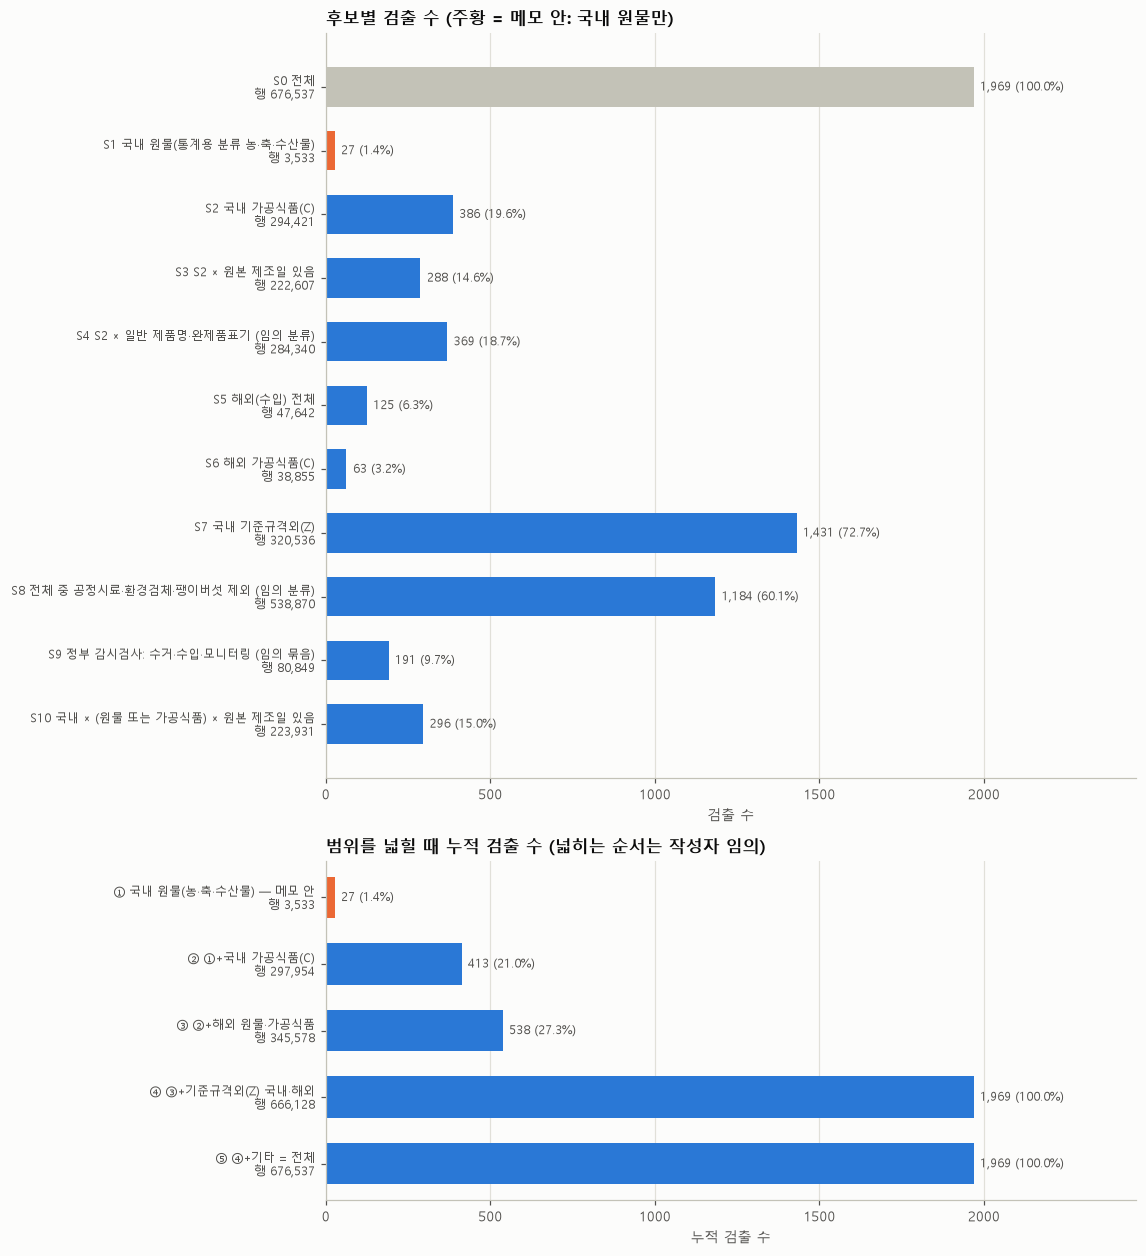

① 국내 원물(농·축·수산물) — 메모 안: 행 3,533 (0.5%), 검출 27 (전체 검출의 1.4%), 검출률 0.764%
② ①+국내 가공식품(C): 행 297,954 (44.0%), 검출 413 (전체 검출의 21.0%), 검출률 0.139%
③ ②+해외 원물·가공식품: 행 345,578 (51.1%), 검출 538 (전체 검출의 27.3%), 검출률 0.156%
④ ③+기준규격외(Z) 국내·해외: 행 666,128 (98.5%), 검출 1,969 (전체 검출의 100.0%), 검출률 0.296%
⑤ ④+기타 = 전체: 행 676,537 (100.0%), 검출 1,969 (전체 검출의 100.0%), 검출률 0.291%
②/① 검출 배수: 15.3배


In [11]:
# [1-3] 후보별 검출 수 가로 막대 + 범위를 넓힐 때 누적 검출 (넓히는 순서는 작성자 임의)
def _lab(name, n):
    return f'{name}\n행 {n:,}'

fig, axes = plt.subplots(2, 1, figsize=(10.5, 11.5), gridspec_kw={'height_ratios': [11, 5]})
ax = axes[0]
labs = [_lab(nm_, int(tA.loc[nm_, '행 수'])) for nm_ in tA.index]
vals = tA['검출'].tolist()
cols = [GRAY if i == 0 else (C2 if nm_.startswith('S1 ') else C1) for i, nm_ in enumerate(tA.index)]
barh(ax, labs, vals, '후보별 검출 수 (주황 = 메모 안: 국내 원물만)', fmt='', colors=cols, xlabel='검출 수')
yy = np.arange(len(vals))[::-1]
for yi, v, p in zip(yy, vals, tA['전체 검출 대비(%)']):
    ax.text(v + max(vals) * 0.01, yi, f'{v:,} ({p}%)', va='center', ha='left', fontsize=8, color=INK2)
ax.set_xlim(0, max(vals) * 1.25)
ax.tick_params(axis='y', labelsize=8)

# 아래: 누적 (작성자 임의 순서)
steps = [('① 국내 원물(농·축·수산물) — 메모 안', dom & is_raw),
         ('② ①+국내 가공식품(C)', dom & (is_raw | is_proc)),
         ('③ ②+해외 원물·가공식품', (dom | ovs) & (is_raw | is_proc)),
         ('④ ③+기준규격외(Z) 국내·해외', (dom | ovs) & (is_raw | is_proc | is_z)),
         ('⑤ ④+기타 = 전체', np.ones(N, dtype=bool))]
sv = [int((m & posb).sum()) for _, m in steps]
sn = [int(m.sum()) for _, m in steps]
ax = axes[1]
barh(ax, [_lab(s, n) for (s, _), n in zip(steps, sn)], sv, '범위를 넓힐 때 누적 검출 수 (넓히는 순서는 작성자 임의)', fmt='',
     colors=[C2] + [C1] * (len(sv) - 1), xlabel='누적 검출 수')
for yi, v in zip(np.arange(len(sv))[::-1], sv):
    ax.text(v + max(sv) * 0.01, yi, f'{v:,} ({v / K * 100:.1f}%)', va='center', ha='left', fontsize=8, color=INK2)
ax.set_xlim(0, max(sv) * 1.25)
ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()

for (s, m), v, n in zip(steps, sv, sn):
    print(f'{s}: 행 {n:,} ({n / N * 100:.1f}%), 검출 {v:,} (전체 검출의 {v / K * 100:.1f}%), 검출률 {v / n * 100:.3f}%')
print(f'②/① 검출 배수: {sv[1] / sv[0]:.1f}배')

📊 **결과**
- 메모 안(국내 원물만): 행 3,533 (0.5%), 검출 27 (전체 검출의 1.4%), 검출률 0.764%.
- 여기에 국내 가공식품을 더하면: 행 297,954 (44.0%), 검출 413 (전체 검출의 21.0%) — 검출 15.3배.
- 해외 원물·가공식품까지 더하면 검출 538 (27.3%), 기준규격외(Z)까지 더하면 1,969 (100.0%). 기타 칸을 더해도 검출은 늘지 않습니다 (행만 666,128 → 676,537).

💬 **첨언**
- 그림으로 보면 검출의 대부분은 기준규격외(Z) 단계에서 더해집니다. "원물이냐 가공식품이냐"보다 "Z 검체를 어디에 둘지"가 남는 검출 수를 크게 좌우하는 것으로 보입니다 (추정).
- 메모 안의 검출 27건 중 12건은 팽이버섯 이름 행, 10건은 한 주소에서 나온 것이라(9건은 둘 다 해당, 둘 중 하나라도 해당 13건, 1-1-b), 막대 길이만큼의 '원물 전반' 검출로 읽지 않는 것이 좋아 보입니다 (추정).
- 넓히는 순서는 작성자 임의라, 단계별 증가폭은 순서를 바꾸면 달라집니다. 어떤 범위가 좋은지는 이 그림으로 정하지 않고, 1-1·1-2 질문의 답을 받은 뒤 정합니다.

## 2. 사용자 메모의 데이터 질문 확인

🔎 메모(`질문.md`)의 질문 세 가지를 데이터로 먼저 셉니다. 결정(제거·삭제 여부)은 하지 않고, 판단에 필요한 숫자와 질문만 남깁니다.
- 2-1 기준일 출처가 '선적일'인 행 (메모 도메인2)
- 2-2 결측이 거의 전부인 변수 4개와 판정 원문의 누수 가능성 (메모 데이터1)
- 2-3 제품명은 수입·외국산인데 국내로 분류된 행 (메모 데이터2)

### 2-1. 기준일 출처가 '선적일'인 행 (메모 도메인2)

🔎 메모: "선적일 행의 주소 출처 100%가 '해외제조업소'라 국내 기상 연결이 무의미해 보이는데 전부 제거해도 될까?"
- 선적일 행이 국내·해외 중 어디에 있는지, 주소 출처·대분류·검출이 어떤지 봅니다.
- 반대로 해외 행인데 기준일이 선적일이 아닌 행도 봅니다. "선적일 제거"와 "해외 제거"가 같은 뜻인지 확인하려는 것입니다.
- 수입 LIMS 연결은 2.ipynb 와 같은 규칙입니다: `cntc_sys_key2` = 수입 LIMS `rcept_no`, 접수번호당 `lims_seq` 최소 1행 (작성자 임의 방법).

In [12]:
# [2-1] 선적일 행의 국내해외 × 주소 출처, 해외제조업소 비율
db = dfx['date_basis'].astype(str)
src = dfx['addr_source'].astype(str)
sh = db.eq('선적일')
print(f"기준일 출처 '선적일' 행: {int(sh.sum()):,}행 / 검출 {int(dfx.loc[sh, 'pos'].sum()):,}건")
t = pd.crosstab(dfx.loc[sh, '국내해외'], src[sh], margins=True, margins_name='합계')
display(t)
ovs_share = src[sh].eq('해외제조업소').mean()
print(f"선적일 행 중 주소 출처 '해외제조업소' 비율: {ovs_share:.2%} ({int(src[sh].eq('해외제조업소').sum()):,} / {int(sh.sum()):,})")
shx = sh & dfx['국내해외'].eq('해외')
print(f"해외 선적일 행 중 '해외제조업소' 비율: {src[shx].eq('해외제조업소').mean():.2%} ({int(src[shx].eq('해외제조업소').sum()):,} / {int(shx.sum()):,})")
# 반대 방향: 주소 출처가 '해외제조업소'인 행 중 기준일이 선적일이 아닌 행
hf = src.eq('해외제조업소')
print(f"(반대 방향) 주소 출처 '해외제조업소' 행 {int(hf.sum()):,} 중 선적일 {int((hf & sh).sum()):,}행, 선적일 아님 {int((hf & ~sh).sum()):,}행 / 검출 {int(dfx.loc[hf & ~sh, 'pos'].sum())}")
display(pd.crosstab(db[hf & ~sh].rename('선적일 아닌 해외제조업소 행: date_basis'), dfx.loc[hf & ~sh, '국내해외']))
print()
print('선적일 행의 국내해외 × 대분류 (건수 순). 95% 구간 = setup 의 wilson() (Wilson 점수 구간)')
t = rate_by(dfx.loc[sh, ['국내해외', '대분류', 'pos']], ['국내해외', '대분류'], sort='n')
lo, hi = wilson(t['검출'], t['건수'])
t['95% 하한(%)'], t['95% 상한(%)'] = np.round(lo, 3), np.round(hi, 3)
t

기준일 출처 '선적일' 행: 47,072행 / 검출 125건


addr_source,해외제조업소,합계
국내해외,,
국내,9,9
해외,47063,47063
합계,47072,47072


선적일 행 중 주소 출처 '해외제조업소' 비율: 100.00% (47,072 / 47,072)
해외 선적일 행 중 '해외제조업소' 비율: 100.00% (47,063 / 47,063)
(반대 방향) 주소 출처 '해외제조업소' 행 47,440 중 선적일 47,072행, 선적일 아님 368행 / 검출 0


국내해외,해외
선적일 아닌 해외제조업소 행: date_basis,
의뢰일,368



선적일 행의 국내해외 × 대분류 (건수 순). 95% 구간 = setup 의 wilson() (Wilson 점수 구간)


건수  검출  검출률(%)  검출비중(%)   리프트  95% 하한(%)  95% 상한(%)
국내해외 대분류                                                                   
해외   가공식품            38654  63   0.163     50.4  0.61      0.127      0.208
     수산물(원물)          7640  43   0.563     34.4  2.12      0.418      0.757
     축산물(원물)           765  19   2.484     15.2  9.35      1.596      3.846
국내   가공식품                9   0   0.000      0.0  0.00      0.000     29.915
해외   기타(접객·건기식·첨가물)      4   0   0.000      0.0  0.00      0.000     48.990

In [13]:
# [2-1] 해외 선적일 행의 검출이 일부 업체·선적에 몰려 있는지 (칸 검출률이 흔들릴 수 있는지 보려는 것)
# 업체 식별 규칙(작성자 임의, 파트 공통): bsn_lcns_ledg_no(영업허가번호)가 있으면 그것, 없으면 mnfctur_cmpny_nm(제조회사명),
# 둘 다 없으면 '식별 불가' 라벨 (값을 채우거나 추정하지 않음. 빈 문자열은 없음으로 봄)
def firm_id(frame):
    a = frame['bsn_lcns_ledg_no'].astype('string').str.strip()
    b = frame['mnfctur_cmpny_nm'].astype('string').str.strip()
    ha = (a.notna() & a.ne('')).astype(bool)
    hb = (b.notna() & b.ne('')).astype(bool)
    return pd.Series(np.select([ha.to_numpy(), hb.to_numpy()], [a.to_numpy(dtype=object), b.to_numpy(dtype=object)], '식별 불가'),
                     index=frame.index, dtype='object')

ovsh = dfx.loc[shx, ['대분류', 'pos', 'bsn_lcns_ledg_no', 'mnfctur_cmpny_nm', 'cntc_sys_key2', 'mnfctur_de']].copy()
ovsh['업체(임의 규칙)'] = firm_id(ovsh)
rows = []
for cat in ['축산물(원물)', '수산물(원물)', '가공식품']:
    s = ovsh[ovsh['대분류'].eq(cat)]
    p = s[s['pos'].eq(1)]
    known = p.loc[p['업체(임의 규칙)'].ne('식별 불가'), '업체(임의 규칙)'].value_counts()
    rows.append({'대분류(해외 선적일)': cat, '행': len(s), '검출': len(p),
                 '행 중 업체 식별 불가(%)': round(s['업체(임의 규칙)'].eq('식별 불가').mean() * 100, 1),
                 '검출 행 중 식별 불가': int(p['업체(임의 규칙)'].eq('식별 불가').sum()),
                 '검출 행의 고유 업체(식별된 것)': int(known.size),
                 '검출 최다 업체의 검출': int(known.iloc[0]) if known.size else 0,
                 '검출 상위 2개 업체의 검출': int(known.head(2).sum()),
                 '검출 행의 고유 접수번호': int(p['cntc_sys_key2'].astype('string').nunique())})
display(pd.DataFrame(rows).set_index('대분류(해외 선적일)'))

fish = ovsh[ovsh['대분류'].eq('수산물(원물)')]
fg = fish.groupby('업체(임의 규칙)')['pos'].agg(행='size', 검출='sum')
unk = fg.loc['식별 불가'] if '식별 불가' in fg.index else None
fg = fg[(fg['검출'] > 0) & (fg.index != '식별 불가')].sort_values(['검출', '행'], ascending=False).head(5)
lo, hi = wilson(fg['검출'], fg['행'])
fg['검출률(%)'] = (fg['검출'] / fg['행'] * 100).round(3)
fg['95% 하한(%)'], fg['95% 상한(%)'] = np.round(lo, 3), np.round(hi, 3)
print('해외 선적일 수산물(원물): 검출이 많은 업체 상위 5 (업체 식별 규칙 기준, 식별 불가 제외. 그 업체의 수산물 행 전체와 검출)')
display(fg)
if unk is not None:
    print(f"  (참고) 업체 '식별 불가' 수산물 행: {int(unk['행']):,}행 / 검출 {int(unk['검출'])}")
# 작성자 임의: 제조회사명 첫 단어가 같은 업체를 한 계열로 묶어 봄 (이름만 보고 묶은 것, 같은 회사인지 확인 전)
fp = fish[fish['pos'].eq(1)]
w1 = fp['mnfctur_cmpny_nm'].astype('string').str.strip().str.split(n=1).str[0]
print('수산물 검출 행: 제조회사명 첫 단어별 검출 (상위 5, 작성자 임의 묶음)')
print(w1.value_counts().head(5).to_string())
top2 = set(fg.index[:2])
rest = fish[~fish['업체(임의 규칙)'].isin(top2)]
n2, k2 = len(rest), int(rest['pos'].sum())
lo2, hi2 = wilson(k2, n2)
print(f"(민감도, 세기만 함) 검출 상위 2개 업체 행 {len(fish) - n2}행 / 검출 {int(fish['pos'].sum()) - k2} 을 빼고 세면: "
      f"{n2:,}행 / 검출 {k2} ({k2 / n2:.3%}, 95% {float(lo2):.3f}~{float(hi2):.3f}%)")
print('\n해외 선적일 축산물·수산물(원물): 기준일(=선적일) 연도별 행·검출 (<NA> = 그 연도에 그 대분류 행이 없음)')
pp_ = ovsh[ovsh['대분류'].isin(['축산물(원물)', '수산물(원물)'])]
yt2 = pp_.groupby([pp_['mnfctur_de'].dt.year.rename('선적 연도'), '대분류'])['pos'].agg(행='size', 검출='sum').unstack('대분류')
yt2.columns = [f'{b} {a}' for a, b in yt2.columns]
display(yt2[[c for b in ['축산물(원물)', '수산물(원물)'] for c in (f'{b} 행', f'{b} 검출')]].astype('Int64'))

,행,검출,행 중 업체 식별 불가(%),검출 행 중 식별 불가,검출 행의 고유 업체(식별된 것),검출 최다 업체의 검출,검출 상위 2개 업체의 검출,검출 행의 고유 접수번호
대분류(해외 선적일),,,,,,,,
축산물(원물),765,19,99.5,19,0,0,0,19
수산물(원물),7640,43,30.7,5,20,9,15,42
가공식품,38654,63,79.7,54,7,2,4,61


해외 선적일 수산물(원물): 검출이 많은 업체 상위 5 (업체 식별 규칙 기준, 식별 불가 제외. 그 업체의 수산물 행 전체와 검출)


,행,검출,검출률(%),95% 하한(%),95% 상한(%)
업체(임의 규칙),,,,,
"TOYOREIZO FOOD & LOGISTICS CO., LTD. HEAD FACTORY THE FOURTH REFRIGERATOR",172,9,5.233,2.777,9.644
"TOYOREIZO FOOD & LOGISTICS CO.,LTD. TOBISHIMAFACTORY THE 3RD REFRIGERATOR",90,6,6.667,3.091,13.790
"HOUSHIN CO.,LTD.",20,4,20.000,8.066,41.602
FORTUNE LIFE ENTERPRISE CO.LTD.,49,2,4.082,1.127,13.713
"MISAKI MEGUMI SUISAN CO.LTD., JYOGASHIMA WAREHOUSE",3,2,66.667,20.765,93.851


  (참고) 업체 '식별 불가' 수산물 행: 2,345행 / 검출 5
수산물 검출 행: 제조회사명 첫 단어별 검출 (상위 5, 작성자 임의 묶음)
mnfctur_cmpny_nm
TOYOREIZO    18
HOUSHIN       4
FORTUNE       2
MISAKI        2
PESQUERA      1
(민감도, 세기만 함) 검출 상위 2개 업체 행 262행 / 검출 15 을 빼고 세면: 7,378행 / 검출 28 (0.380%, 95% 0.263~0.548%)

해외 선적일 축산물·수산물(원물): 기준일(=선적일) 연도별 행·검출 (<NA> = 그 연도에 그 대분류 행이 없음)


,축산물(원물) 행,축산물(원물) 검출,수산물(원물) 행,수산물(원물) 검출
선적 연도,,,,
2016,1,0,228,0
2017,240,6,608,4
2018,185,8,880,0
2019,172,3,807,1
2020,167,2,656,0
2021,<NA>,<NA>,525,0
2022,<NA>,<NA>,510,0
2023,<NA>,<NA>,653,0
2024,<NA>,<NA>,905,12


In [14]:
# [2-1] 국내로 표시된 선적일 행 전체 (제품명·주소 출처·검사목적)
dom_sh = sh & dfx['국내해외'].eq('국내')
cols = ['prduct_nm', 'addr_source', 'addr_source_db', '검사목적', '의뢰시스템', '대분류', 'mnfctur_de', 'mnfctur_de_raw', 'reqest_de', 'cntc_sys_key2', 'judge_result']
t = dfx.loc[dom_sh, cols].copy()
t['수입LIMS 접수번호 연결'] = t['cntc_sys_key2'].astype(str).isin(set(sorg['rcept_no'].astype(str)))
print(f'국내 선적일 행: {len(t)}행')
t

국내 선적일 행: 9행


,prduct_nm,addr_source,addr_source_db,검사목적,의뢰시스템,대분류,mnfctur_de,mnfctur_de_raw,reqest_de,cntc_sys_key2,judge_result,수입LIMS 접수번호 연결
154079,아이쓰눠 명작 1,해외제조업소,해외제조업소,수입검사,수입축산물,가공식품,2022-06-06,NaT,2022-07-14,202200444628,불검출,True
342641,메르궁 3,해외제조업소,해외제조업소,수입검사,수입축산물,가공식품,2022-06-06,NaT,2022-07-15,202200447914,불검출,True
372317,메르궁 1,해외제조업소,해외제조업소,수입검사,수입축산물,가공식품,2022-06-06,NaT,2022-07-15,202200447887,불검출,True
432124,시안즈항렬 2,해외제조업소,해외제조업소,수입검사,수입축산물,가공식품,2022-06-06,NaT,2022-07-14,202200445032,불검출,True
502062,시안즈항렬 1,해외제조업소,해외제조업소,수입검사,수입축산물,가공식품,2022-06-06,NaT,2022-07-14,202200445005,불검출,True
580878,시안즈항렬 3,해외제조업소,해외제조업소,수입검사,수입축산물,가공식품,2022-06-06,NaT,2022-07-14,202200445059,불검출,True
600730,메르궁 2,해외제조업소,해외제조업소,수입검사,수입축산물,가공식품,2022-06-06,NaT,2022-07-15,202200447906,불검출,True
600741,아이쓰눠 명작 2,해외제조업소,해외제조업소,수입검사,수입축산물,가공식품,2022-06-06,NaT,2022-07-14,202200444633,불검출,True
620419,아이쓰눠 명작 3,해외제조업소,해외제조업소,수입검사,수입축산물,가공식품,2022-06-06,NaT,2022-07-14,202200444635,불검출,True


In [15]:
# [2-1] 해외 행 중 기준일 출처가 선적일이 아닌 행 (의뢰일·제조일)
ovs = dfx['국내해외'].eq('해외')
nsh = ovs & ~sh
print(f"해외 행 {int(ovs.sum()):,} 중 기준일 출처가 선적일이 아닌 행: {int(nsh.sum()):,}행 / 검출 {int(dfx.loc[nsh, 'pos'].sum())}건")
sub = dfx.loc[nsh, ['date_basis', 'addr_source', '대분류', '검사목적', 'cntc_sys_key2', 'pos']].copy()
sub['date_basis'] = sub['date_basis'].astype(str)
sub['addr_source'] = sub['addr_source'].astype(str)
print('\n기준일 출처 × 주소 출처')
display(rate_by(sub, ['date_basis', 'addr_source'], sort='n'))
print('기준일 출처 × 대분류')
display(rate_by(sub, ['date_basis', '대분류'], sort='n'))
print('기준일 출처 × 검사목적')
display(rate_by(sub, ['date_basis', '검사목적'], sort='n'))
rno = set(sorg['rcept_no'].astype(str))
sub['수입LIMS 연결'] = sub['cntc_sys_key2'].astype(str).isin(rno)
print('기준일 출처 × 수입 LIMS 접수번호 연결 여부 (행 수)')
display(pd.crosstab(sub['date_basis'], sub['수입LIMS 연결']))
# 연결된 행은 수입 LIMS 선적일(shipng_de)이 비어 있는지 확인 (접수번호당 lims_seq 최소 1행 — 2.ipynb 와 같은 규칙)
s1 = sorg.sort_values('lims_seq').drop_duplicates('rcept_no')[['rcept_no', 'shipng_de']].assign(rcept_no=lambda d: d['rcept_no'].astype(str))
lk = (sub.loc[sub['수입LIMS 연결'], ['date_basis', 'cntc_sys_key2']].assign(cntc_sys_key2=lambda d: d['cntc_sys_key2'].astype(str))
      .reset_index().merge(s1, left_on='cntc_sys_key2', right_on='rcept_no', how='left', validate='many_to_one').set_index('index'))
print(f"연결된 비선적일 해외 행 {len(lk)}행 중 수입 LIMS 선적일이 비어 있는 행: {int(lk['shipng_de'].isna().sum())}, 선적일이 있는 행: {int(lk['shipng_de'].notna().sum())}")
has_sd = lk.index[lk['shipng_de'].notna()]
print("수입 LIMS 선적일이 있는데 기준일 출처가 선적일이 아닌 해외 행:")
display(dfx.loc[has_sd, ['prduct_nm', 'date_basis', 'mnfctur_de', 'reqest_de', 'addr_source', '대분류', '검사목적', 'judge_result']]
        .assign(수입LIMS_선적일=lk.loc[has_sd, 'shipng_de'].values))
lk2 = dfx.loc[shx, ['cntc_sys_key2']].assign(cntc_sys_key2=lambda d: d['cntc_sys_key2'].astype(str)).merge(s1, left_on='cntc_sys_key2', right_on='rcept_no', how='left')
print(f"(비교) 해외 선적일 행 {len(lk2):,}행 중 수입 LIMS 선적일이 비어 있거나 연결 안 된 행: {int(lk2['shipng_de'].isna().sum())}")

해외 행 47,642 중 기준일 출처가 선적일이 아닌 행: 579행 / 검출 0건

기준일 출처 × 주소 출처


,,건수,검출,검출률(%),검출비중(%),리프트
date_basis,addr_source,,,,,
의뢰일,해외제조업소,368,0,0.0,0.0,NaN
제조일,제조사소재지,98,0,0.0,0.0,NaN
의뢰일,제조사소재지,78,0,0.0,0.0,NaN
제조일,업소주소,35,0,0.0,0.0,NaN


기준일 출처 × 대분류


,,건수,검출,검출률(%),검출비중(%),리프트
date_basis,대분류,,,,,
의뢰일,수산물(원물),364,0,0.0,0.0,NaN
제조일,가공식품,119,0,0.0,0.0,NaN
의뢰일,가공식품,82,0,0.0,0.0,NaN
제조일,기준규격외(검체),14,0,0.0,0.0,NaN


기준일 출처 × 검사목적


,,건수,검출,검출률(%),검출비중(%),리프트
date_basis,검사목적,,,,,
의뢰일,(원본LIMS 없음),364,0,0.0,0.0,NaN
제조일,기타,113,0,0.0,0.0,NaN
의뢰일,자가품질위탁검사,77,0,0.0,0.0,NaN
제조일,자가품질위탁검사,18,0,0.0,0.0,NaN
의뢰일,수입검사,4,0,0.0,0.0,NaN
제조일,검사명령검사,2,0,0.0,0.0,NaN
의뢰일,기타,1,0,0.0,0.0,NaN


기준일 출처 × 수입 LIMS 접수번호 연결 여부 (행 수)


수입LIMS 연결,False,True
date_basis,,
의뢰일,78,368
제조일,133,0


연결된 비선적일 해외 행 368행 중 수입 LIMS 선적일이 비어 있는 행: 364, 선적일이 있는 행: 4
수입 LIMS 선적일이 있는데 기준일 출처가 선적일이 아닌 해외 행:


,prduct_nm,date_basis,mnfctur_de,reqest_de,addr_source,대분류,검사목적,judge_result,수입LIMS_선적일
index,,,,,,,,,
125177,냉동크림,의뢰일,2023-06-13,2023-06-13,해외제조업소,가공식품,수입검사,불검출,2003-04-05
131786,크래프트 크래커 배럴 샵 화이트 체다치즈,의뢰일,2020-07-21,2020-07-21,해외제조업소,가공식품,수입검사,불검출,2002-05-25
471051,냉동전란액,의뢰일,2021-08-17,2021-08-17,해외제조업소,가공식품,수입검사,불검출,2001-08-04
591840,유크림,의뢰일,2023-06-02,2023-06-02,해외제조업소,가공식품,수입검사,불검출,2003-04-16


(비교) 해외 선적일 행 47,063행 중 수입 LIMS 선적일이 비어 있거나 연결 안 된 행: 0


In [16]:
# [2-1] '선적일 행 전부 제거'를 가정했을 때 남는 행·검출 (실제로 빼지 않고 세기만 함)
purp_imp = dfx['검사목적'].eq('수입검사')
groups = {
    '전체': pd.Series(True, index=dfx.index),
    '국내': dfx['국내해외'].eq('국내'),
    '해외(src_route)': ovs,
    "검사목적 '수입검사'": purp_imp,
}
rows = []
for g, m in groups.items():
    n0, k0 = int(m.sum()), int(dfx.loc[m, 'pos'].sum())
    keep = m & ~sh
    n1, k1 = int(keep.sum()), int(dfx.loc[keep, 'pos'].sum())
    rows.append({'구분': g, '현재 행': n0, '현재 검출': k0, '선적일 제거 후 행': n1, '제거 후 검출': k1,
                 '빠지는 행': n0 - n1, '빠지는 검출': k0 - k1,
                 '남는 행 비율(%)': round(n1 / n0 * 100, 2) if n0 else np.nan})
t = pd.DataFrame(rows).set_index('구분')
print('선적일 행 수:', f'{int(sh.sum()):,}', '(국내 9행 포함)')
display(t)
print('검사목적 수입검사 중 선적일 행 비율:', f"{dfx.loc[purp_imp, 'date_basis'].astype(str).eq('선적일').mean():.2%}")
print('\n선적일 제거 후 남는 해외 행의 대분류')
rate_by(dfx.loc[ovs & ~sh, ['대분류', 'pos']], '대분류', sort='n')

선적일 행 수: 47,072 (국내 9행 포함)


,현재 행,현재 검출,선적일 제거 후 행,제거 후 검출,빠지는 행,빠지는 검출,남는 행 비율(%)
구분,,,,,,,
전체,676537,1969,629465,1844,47072,125,93.04
국내,628895,1844,628886,1844,9,0,100.00
해외(src_route),47642,125,579,0,47063,125,1.22
검사목적 '수입검사',39478,96,6,0,39472,96,0.02


검사목적 수입검사 중 선적일 행 비율: 99.98%

선적일 제거 후 남는 해외 행의 대분류


,건수,검출,검출률(%),검출비중(%),리프트
대분류,,,,,
수산물(원물),364,0,0.0,0.0,NaN
가공식품,201,0,0.0,0.0,NaN
기준규격외(검체),14,0,0.0,0.0,NaN


📊 **결과**
- 기준일 출처 '선적일' 행은 47,072행 / 검출 125건입니다. 주소 출처 '해외제조업소' 비율은 100.00% (47,072 / 47,072) 로, 메모의 100% 와 같게 나옵니다.
  - 반대 방향: 주소 출처 '해외제조업소' 행 47,440 중 선적일 47,072행, 선적일이 아닌 행 368행 (모두 해외·의뢰일, 검출 0). 즉 "선적일 행 제거"와 "해외제조업소 행 제거"는 이 368행만큼 다릅니다.
- 선적일 행은 해외 47,063행, 국내 9행입니다. 국내 9행은 모두 검사목적 '수입검사'·의뢰시스템 '수입축산물'·가공식품·불검출이고, 9행 모두 수입 LIMS 접수번호와 연결됩니다 (기준일 2022-06-06).
- 해외 선적일 행의 대분류 (행 / 검출, 검출률, 95% 구간): 가공식품 38,654 / 63 (0.163%, 0.127\~0.208%), 수산물(원물) 7,640 / 43 (0.563%, 0.418\~0.757%), 축산물(원물) 765 / 19 (2.484%, 1.596\~3.846%), 기타 4 / 0.
- 해외 선적일 검출이 일부 업체·시기에 몰려 있는지 (업체 식별 규칙, 작성자 임의 방법):
  - 축산물(원물): 765행 중 업체 식별 불가 99.5%, 검출 19행은 모두 식별 불가라 업체 몰림은 볼 수 없습니다. 검출 19행의 접수번호는 19개입니다. 선적 연도는 2016\~2020 뿐이고 검출은 2017 6·2018 8·2019 3·2020 2 입니다.
  - 수산물(원물): 검출 43행 중 식별 불가 5, 식별된 업체 20곳, 접수번호 42개. 최다 업체 검출 9건, 상위 2개 업체 15건입니다. 두 업체 이름은 모두 TOYOREIZO 로 시작합니다 (172행 / 9, 5.233% · 90행 / 6, 6.667%). 제조회사명 첫 단어로 묶으면(작성자 임의 묶음) TOYOREIZO 18건입니다.
  - 상위 2개 업체 행 262행 / 검출 15 를 빼고 세면 (세기만 함) 수산물 7,378행 / 검출 28 (0.380%, 95% 0.263\~0.548%).
  - 수산물 검출의 선적 연도: 2024 12건(905행)·2025 20건(1,335행)·2026 6건(533행). 2021\~2023 은 행 525·510·653 에 검출 0 입니다.
- 해외 행 47,642 중 기준일이 선적일이 아닌 행은 579행 / 검출 0건입니다.
  - 기준일 × 주소 출처: 의뢰일·해외제조업소 368행, 제조일·제조사소재지 98행, 의뢰일·제조사소재지 78행, 제조일·업소주소 35행.
  - 의뢰일 행 중 수산물(원물) 364행, 검사목적 '원본LIMS 없음' 364행.
  - 수입 LIMS 접수번호 연결: 의뢰일 368행 연결·78행 미연결, 제조일 133행 모두 미연결. 연결된 368행 중 364행은 수입 LIMS 선적일이 비어 있습니다 (해외 선적일 행은 이런 행이 0).
  - 나머지 4행은 **수입 LIMS 선적일이 있는데도 기준일이 의뢰일**입니다 (냉동크림·체다치즈·냉동전란액·유크림, 수입검사). 이 4행의 선적일은 2001-08-04 \~ 2003-04-16 이고 의뢰일은 2020-07-21 \~ 2023-06-13 입니다.
- '선적일 행 전부 제거'를 가정하면 (실제로 빼지 않고 세기만 함):
  - 전체 676,537 → 629,465행, 검출 1,969 → 1,844.
  - 해외(src_route) 47,642 → 579행 (1.22%), 검출 125 → 0.
  - 검사목적 '수입검사' 39,478 → 6행, 검출 96 → 0 (수입검사 중 선적일 행 99.98%).

💬 **첨언**
- 이 데이터에서는 "선적일 행 제거"가 "해외(수입) 행 거의 전부와 수입 검출 125건 전부를 빼는 것"과 결과가 거의 같아 보입니다 (추정). 남는 해외 579행에는 검출이 없습니다.
- 국내로 표시된 선적일 9행은 수입검사·수입 LIMS 연결 행이라, 국내해외 라벨이 잘못 붙었을 가능성이 있어 보입니다 (추정).
- 해외 행인데 주소 출처가 제조사소재지·업소주소인 행(98·78·35행)은 반대로 국내 행이 해외로 표시된 것인지 이 출력만으로는 알 수 없습니다.
- 선적일이 있는데 기준일이 의뢰일인 4행은 선적일이 의뢰일보다 훨씬 앞선 값이라, 이상한 선적일은 의뢰일로 바꾸는 규칙이 있을 수 있어 보입니다 (추정). "수입 LIMS 에 선적일이 있으면 항상 선적일" 은 아닌 것으로 나옵니다.
- 수입 축산물(원물) 2.484% 와 수산물(원물) 0.563% 는 전체 0.291% 보다 높게 나옵니다. 다만 검출 수가 19·43건으로 적고, 수산물은 검출 43건 중 15건이 이름이 TOYOREIZO 로 시작하는 두 업체에서 나왔고, 2024·2025·2026 선적에서 12·20·6건이 나왔습니다. 두 업체를 빼고 세면 0.380% 로 내려갑니다. 축산물은 업체를 식별할 수 없어 몰림 여부를 볼 수 없습니다. 그래서 칸 검출률은 일부 업체·시기 영향으로 흔들릴 수 있어 보입니다 (추정).
- 국내 기상과 잇지 않더라도 수입 행을 **따로** 볼지(원산지·업체·선적 시기 등)는 별도 결정거리로 보입니다 (추정).

❓ **도메인 전문가께**:
- 수입 식품(선적일 기준) 행을 국내 기상 모델의 타겟 범위에서 빼는 것이 식품위생 관점에서 타당합니까? 뺀다면 수입 축산물(원물) 765행 / 검출 19, 수산물(원물) 7,640행 / 검출 43 (일부 업체·2024\~2026 선적에 몰림)을 별도로 다룰 필요가 있습니까?
- 선적 뒤 국내 보관·유통 기간이 긴 수입 냉장 제품도 국내 환경 영향이 없다고 봐도 됩니까?
- 수입 수산물 검출 15건이 이름이 TOYOREIZO 로 시작하는 해외 제조업소 2곳(이름에 REFRIGERATOR 포함)에서 나온 것은 업체 단위 오염으로 보는 것이 일반적입니까? 이런 경우 업체를 변수로 쓰는 것이 타당합니까?

🗄️ **데이터 담당자께**:
- 국내로 표시된 선적일 9행(수입검사·수입축산물, 수입 LIMS 연결됨)은 국내해외(src_route) 라벨 오류입니까?
- 해외 행 중 기준일이 의뢰일·제조일인 579행은 어떤 경로의 데이터입니까? 특히 원본 LIMS 가 없고 수입 LIMS 선적일도 빈 수산물 364행, 주소 출처가 제조사소재지·업소주소인 해외 행이 궁금합니다.
- date_basis 는 행마다 어떤 규칙으로 정해집니까? 수입 LIMS 선적일(2001\~2003년 값)이 있는데 기준일이 의뢰일인 4행이 있습니다. 선적일이 이상하면 의뢰일로 바꾸는 규칙입니까? 주소 출처는 '해외제조업소'인데 기준일이 의뢰일인 368행은 어떻게 정해졌습니까?
- 해외 선적일 축산물(원물) 행은 99.5% 가 영업허가번호·제조회사명이 비어 있습니다. 수입 LIMS 에 해외 제조업소를 알 수 있는 다른 필드가 있습니까?

### 2-2. 결측이 거의 전부인 변수 4개와 판정 원문의 누수 가능성 (메모 데이터1)

🔎 메모: "data_source, result_value_num, judge_stdr, judge_stdr_num 전부 삭제해도 되나? (결측 98.92% 이상)"
- 네 변수의 결측률·고유값과, 값이 있는 행이 어떤 행인지(연도·검사기관·국내해외·검출률) 봅니다.
- `result_value`(결과 원문)·`result_value_num`·`judge_stdr`(판정 규격)는 판정과 바로 이어질 수 있는 값이라 확인합니다. 예측 변수로 넣으면 정답이 새어 들어가는지(누수) 데이터로 봅니다.
- 작성자 임의 방법: 연도 = 기준일(`mnfctur_de`) 연도 (2.ipynb 3-11절과 같음, 제조일·의뢰일·선적일이 섞임). 결과 원문의 '양성 표현' = 원문에 양성·검출·부적합·의심이 있음 (불검출·미검출은 비교 전에 지움).

In [17]:
# [2-2] 네 변수의 결측률·고유값·상위 값
VARS = ['data_source', 'result_value_num', 'judge_stdr', 'judge_stdr_num']
rows = []
for c in VARS:
    s = dfx[c]
    rows.append({'변수': c, '자료형': str(s.dtype), '결측 행': int(s.isna().sum()), '결측률(%)': round(s.isna().mean() * 100, 2),
                 '값 있는 행': int(s.notna().sum()), '고유값 수(결측 제외)': int(s.nunique(dropna=True))})
display(pd.DataFrame(rows).set_index('변수'))
for c in VARS:
    print(f'--- {c} 값별 건수 (상위 12, 결측 포함) ---')
    print(dfx[c].astype('string').fillna('(결측)').value_counts().head(12).to_string())

,자료형,결측 행,결측률(%),값 있는 행,고유값 수(결측 제외)
변수,,,,,
data_source,category,0,0.00,676537,1
result_value_num,float32,672760,99.44,3777,2
judge_stdr,string,669264,98.92,7273,17
judge_stdr_num,float32,676469,99.99,68,5


--- data_source 값별 건수 (상위 12, 결측 포함) ---
data_source
식약처    676537
--- result_value_num 값별 건수 (상위 12, 결측 포함) ---
result_value_num
(결측)    672760
0.0       3775
2.0          2
--- judge_stdr 값별 건수 (상위 12, 결측 포함) ---
judge_stdr
(결측)                  669264
n=5,c=0,m=0/25g         4692
n=5, c=0, m=0/25g       1817
음성                       635
100                       62
n=5, c=0, m=0/25 g        29
n=5,c=2,m=0               12
n=5,c=0,m=0                9
불검출                        3
음성                         3
20                         3
0                          2
--- judge_stdr_num 값별 건수 (상위 12, 결측 포함) ---
judge_stdr_num
(결측)      676469
100.0         62
20.0           3
25.0           1
1000.0         1
0.5            1


In [18]:
# [2-2] 값이 있는 행의 특징: 검출률·국내해외·연도·검사기관
# 연도 = 기준일(mnfctur_de) 연도 (2.ipynb 3-11절과 같음. 기준일에는 제조일·의뢰일·선적일이 섞여 있음)
yr = dfx['mnfctur_de'].dt.year
rows = []
for c in ['result_value_num', 'judge_stdr', 'judge_stdr_num']:
    m = dfx[c].notna()
    n, k = int(m.sum()), int(dfx.loc[m, 'pos'].sum())
    inst = dfx.loc[m, 'inspct_instt_code'].astype('string').fillna('(결측)').value_counts()
    rows.append({'변수': c, '값 있는 행': n, '검출': k, '검출률(%)': round(k / n * 100, 3),
                 '국내 비율(%)': round(dfx.loc[m, '국내해외'].eq('국내').mean() * 100, 1),
                 '연도 범위': f'{int(yr[m].min())}~{int(yr[m].max())}',
                 '검사기관 수': int(inst.size),
                 '최다 검사기관 점유(%)': round(inst.iloc[0] / n * 100, 1)})
rows.append({'변수': '(참고) 전체', '값 있는 행': len(dfx), '검출': int(dfx['pos'].sum()),
             '검출률(%)': round(dfx['pos'].mean() * 100, 3), '국내 비율(%)': round(dfx['국내해외'].eq('국내').mean() * 100, 1),
             '연도 범위': f'{int(yr.min())}~{int(yr.max())}', '검사기관 수': int(dfx['inspct_instt_code'].nunique()),
             '최다 검사기관 점유(%)': round(dfx['inspct_instt_code'].astype('string').value_counts().iloc[0] / len(dfx) * 100, 1)})
display(pd.DataFrame(rows).set_index('변수'))
for c in ['result_value_num', 'judge_stdr', 'judge_stdr_num']:
    m = dfx[c].notna()
    for g in ['국내', '해외']:
        gm = dfx['국내해외'].eq(g)
        print(f"{c}: {g} 행 {int(gm.sum()):,} 중 값 있음 {int((m & gm).sum()):,} ({(m & gm).sum() / gm.sum():.2%})")

print('\n연도별: 전체 행과 값 있는 행 수')
yt = pd.DataFrame({'전체 행': yr.value_counts().sort_index()})
for c in ['result_value_num', 'judge_stdr', 'judge_stdr_num']:
    yt[f'{c} 값 있음'] = yr[dfx[c].notna()].value_counts().reindex(yt.index).astype('Int64')
display(yt)

m = dfx['judge_stdr'].notna()
inst = rate_by(dfx.loc[m, ['inspct_instt_code', 'pos']].assign(inspct_instt_code=lambda d: d['inspct_instt_code'].astype('string')), 'inspct_instt_code', sort='n', top=8)
allinst = dfx['inspct_instt_code'].astype('string').value_counts()
inst['그 기관 전체 행'] = allinst.reindex(inst.index).values
inst['그 기관 중 judge_stdr 기재(%)'] = (inst['건수'] / inst['그 기관 전체 행'] * 100).round(1)
print('judge_stdr 값 있는 행의 검사기관 (상위 8, 건수 순)')
inst

,값 있는 행,검출,검출률(%),국내 비율(%),연도 범위,검사기관 수,최다 검사기관 점유(%)
변수,,,,,,,
result_value_num,3777,2,0.053,99.8,2015~2026,42,33.0
judge_stdr,7273,10,0.137,0.9,2015~2026,17,53.9
judge_stdr_num,68,0,0.000,94.1,2017~2024,6,85.3
(참고) 전체,676537,1969,0.291,93.0,2015~2026,270,9.7


result_value_num: 국내 행 628,895 중 값 있음 3,771 (0.60%)
result_value_num: 해외 행 47,642 중 값 있음 6 (0.01%)
judge_stdr: 국내 행 628,895 중 값 있음 64 (0.01%)
judge_stdr: 해외 행 47,642 중 값 있음 7,209 (15.13%)
judge_stdr_num: 국내 행 628,895 중 값 있음 64 (0.01%)
judge_stdr_num: 해외 행 47,642 중 값 있음 4 (0.01%)

연도별: 전체 행과 값 있는 행 수


,전체 행,result_value_num 값 있음,judge_stdr 값 있음,judge_stdr_num 값 있음
mnfctur_de,,,,
2015,389,1,365,<NA>
2016,10228,55,4661,<NA>
2017,43874,439,390,3
2018,53714,770,235,7
2019,60750,940,344,12
2020,66014,867,115,14
2021,69581,609,214,16
2022,73409,22,88,9
2023,77032,30,116,6


judge_stdr 값 있는 행의 검사기관 (상위 8, 건수 순)


,건수,검출,검출률(%),검출비중(%),리프트,그 기관 전체 행,그 기관 중 judge_stdr 기재(%)
inspct_instt_code,,,,,,,
1471124,3921,3,0.077,30.0,0.56,24588,15.9
1471111,1574,1,0.064,10.0,0.46,14975,10.5
1471102,885,5,0.565,50.0,4.11,6919,12.8
O000079,646,1,0.155,10.0,1.13,5196,12.4
O000710,58,0,0.000,0.0,0.00,1207,4.8
1471151,56,0,0.000,0.0,0.00,2558,2.2
1471142,50,0,0.000,0.0,0.00,2023,2.5
O000039,30,0,0.000,0.0,0.00,11555,0.3


In [19]:
# [2-2] judge_stdr(판정 규격)·result_value_num 값별 검출률 — 결측도 하나의 값('(결측)' 라벨)으로 표시만 함
tmp = pd.DataFrame({'judge_stdr': dfx['judge_stdr'].astype('string').fillna('(결측)'),
                    'result_value_num': dfx['result_value_num'].astype('string').fillna('(결측)'),
                    '국내해외': dfx['국내해외'], 'pos': dfx['pos']})
print('judge_stdr 값별 (건수 순)')
display(rate_by(tmp, 'judge_stdr', sort='n'))
print('result_value_num 값별')
display(rate_by(tmp, 'result_value_num', sort='n'))
# result_value_num 이 어떤 결과 원문에서 왔는지: 값별 result_value 원문 상위 (값 있는 행만)
rvn_m = dfx['result_value_num'].notna()
x = pd.DataFrame({'result_value_num': dfx.loc[rvn_m, 'result_value_num'].astype('string'),
                  'result_value(원문)': dfx.loc[rvn_m, 'result_value'].astype('string'), 'pos': dfx.loc[rvn_m, 'pos']})
xg = x.groupby(['result_value_num', 'result_value(원문)'])['pos'].agg(건수='size', 검출='sum').sort_values('건수', ascending=False)
print(f"result_value_num 값 있는 {int(rvn_m.sum()):,}행: 값별 고유 원문 수", x.groupby('result_value_num')['result_value(원문)'].nunique().to_dict())
print('result_value_num × result_value 원문 (건수 상위 10)')
display(xg.head(10))
js = dfx['judge_stdr'].astype('string')
m = js.str.strip().isin(['음성', '불검출'])
print(f"judge_stdr 에 규격이 아니라 결과처럼 보이는 값('음성'·'불검출', 앞뒤 공백 제거 후 비교)이 들어간 행: {int(m.sum())}행 / 검출 {int(dfx.loc[m, 'pos'].sum())}")
print('  내역(공백 제거 후):', js[m].str.strip().value_counts().to_dict())
m2 = js.str.contains('음성', na=False)
print(f"  (참고) '음성' 글자를 포함한 행: {int(m2.sum())}행 / 검출 {int(dfx.loc[m2, 'pos'].sum())} — 내역:", js[m2].str.strip().value_counts().to_dict())
print(f"  (참고) 전체 검출률 {dfx['pos'].mean():.3%} 를 {int(m.sum())}행에 곱한 기대 검출 수: {int(m.sum()) * dfx['pos'].mean():.1f}건")

judge_stdr 값별 (건수 순)


,건수,검출,검출률(%),검출비중(%),리프트
judge_stdr,,,,,
(결측),669264,1959,0.293,99.5,1.01
"n=5,c=0,m=0/25g",4692,8,0.171,0.4,0.59
"n=5, c=0, m=0/25g",1817,2,0.110,0.1,0.38
음성,635,0,0.000,0.0,0.00
100,62,0,0.000,0.0,0.00
"n=5, c=0, m=0/25 g",29,0,0.000,0.0,0.00
"n=5,c=2,m=0",12,0,0.000,0.0,0.00
"n=5,c=0,m=0",9,0,0.000,0.0,0.00
음성,3,0,0.000,0.0,0.00


result_value_num 값별


,건수,검출,검출률(%),검출비중(%),리프트
result_value_num,,,,,
(결측),672760,1967,0.292,99.9,1.00
0.0,3775,0,0.000,0.0,0.00
2.0,2,2,100.000,0.1,343.59


result_value_num 값 있는 3,777행: 값별 고유 원문 수 {'0.0': 7, '2.0': 1}
result_value_num × result_value 원문 (건수 상위 10)


건수  검출
result_value_num result_value(원문)                      
0.0              0, 0, 0, 0, 0                 3586   0
                 0,0,0,0,0                       81   0
                 0                               80   0
                 0/0/0/0/0                       23   0
                 <10,<10,<10,<10,<10              3   0
2.0              2건이상 → 상세보기를 클릭하세요.              2   2
0.0              0,0.0,0,0                        1   0
                 n1=0, n2=0, n3=0, n4=0, n5=0     1   0

judge_stdr 에 규격이 아니라 결과처럼 보이는 값('음성'·'불검출', 앞뒤 공백 제거 후 비교)이 들어간 행: 641행 / 검출 0
  내역(공백 제거 후): {'음성': 638, '불검출': 3}
  (참고) '음성' 글자를 포함한 행: 639행 / 검출 0 — 내역: {'음성': 638, '리스테리아모노사이토제네스 : 음성': 1}
  (참고) 전체 검출률 0.291% 를 641행에 곱한 기대 검출 수: 1.9건


In [20]:
# [2-2] result_value(결과 원문) 값별 검출 비율 — 누수 가능성
rv = dfx['result_value'].astype('string')
print(f"result_value 결측 {int(rv.isna().sum())}행, 고유값 {int(rv.nunique())}개")
tmp = pd.DataFrame({'result_value': rv.fillna('(결측)'), 'pos': dfx['pos']})
g = rate_by(tmp, 'result_value', sort='pos')
print('검출이 1건 이상인 result_value 값:', int((g['검출'] > 0).sum()), '개 / 그중 검출률 100% 가 아닌 값:', int(((g['검출'] > 0) & (g['검출률(%)'] < 100)).sum()), '개')
print('검출 0건인 값:', int((g['검출'] == 0).sum()), '개')
display(g.head(12))

# 작성자 임의 규칙: 원문에 '양성|검출|부적합|의심' 이 있으면 '양성 표현' (단 '불검출'·'미검출' 은 비교 전에 지우고 봄 — 비교용 임시 문자열, 원자료는 그대로)
rv_cmp = rv.fillna('').str.replace(r'불검출|미검출', '', regex=True)
flag = has_kw(rv_cmp, r'양성|검출|부적합|의심')
ct = pd.crosstab(pd.Series(np.where(flag, '원문에 양성 표현 있음', '양성 표현 없음'), index=dfx.index, name='결과 원문(임의 규칙)'),
                 dfx['judge_result'].astype(str).rename('판정 결과'), margins=True, margins_name='합계')
print('작성자 임의 규칙(원문 양성 표현) × 판정 결과')
display(ct)
miss = (~flag) & dfx['pos'].eq(1)
print(f'양성 표현이 없는데 검출인 행: {int(miss.sum())}행 → 원문 값:')
print(rv[miss].value_counts().to_string())
over = flag & dfx['pos'].eq(0)
print(f'양성 표현이 있는데 불검출인 행: {int(over.sum())}행')
if over.any():
    print(rv[over].value_counts().to_string())

result_value 결측 0행, 고유값 100개
검출이 1건 이상인 result_value 값: 26 개 / 그중 검출률 100% 가 아닌 값: 0 개
검출 0건인 값: 74 개


,건수,검출,검출률(%),검출비중(%),리프트
result_value,,,,,
양성,1646,1646,100.0,83.6,343.59
"양성,양성,양성,양성,양성",239,239,100.0,12.1,343.59
검출,24,24,100.0,1.2,343.59
"양성, 양성, 양성, 양성, 양성",13,13,100.0,0.7,343.59
"양성,음성,음성,음성,음성",8,8,100.0,0.4,343.59
n(1~5)=양성,7,7,100.0,0.4,343.59
"음성,음성,음성,음성,양성",5,5,100.0,0.3,343.59
리스테리아 모노사이토제네스 검출,3,3,100.0,0.2,343.59
2건이상 → 상세보기를 클릭하세요.,2,2,100.0,0.1,343.59


작성자 임의 규칙(원문 양성 표현) × 판정 결과


판정 결과,검출,불검출,합계
결과 원문(임의 규칙),,,
양성 표현 없음,2,674568,674570
원문에 양성 표현 있음,1967,0,1967
합계,1969,674568,676537


양성 표현이 없는데 검출인 행: 2행 → 원문 값:
result_value
2건이상 → 상세보기를 클릭하세요.    2
양성 표현이 있는데 불검출인 행: 0행


📊 **결과**
- `data_source`: 결측 0행 (0.00%), 값은 '식약처' 하나 (676,537행). 메모의 "결측 98.92% 이상"과 달리 **결측이 아니라 값이 하나뿐인 변수**로 나옵니다.
- `result_value_num`: 결측 99.44%. 값은 0.0 (3,775행)·2.0 (2행). 값 있는 행의 국내 비율 99.8%. 2.0 인 2행은 둘 다 검출(검출률 100.000%), 0.0 은 검출 0.
  - 결과 원문과 맞춰 보면, 2.0 인 2행은 원문이 '2건이상 → 상세보기를 클릭하세요.' 인 바로 그 2행입니다 (고유 원문 1개).
  - 0.0 행의 원문은 고유 7개: '0, 0, 0, 0, 0' 3,586·'0,0,0,0,0' 81·'0' 80·'0/0/0/0/0' 23·'<10,<10,<10,<10,<10' 3·'0,0.0,0,0' 1·'n1=0, n2=0, n3=0, n4=0, n5=0' 1 (모두 검출 0).
- `judge_stdr`(판정 규격): 결측 98.92%, 고유값 17개 (띄어쓰기만 다른 'n=5,c=0,m=0/25g' 계열이 대부분).
  - 값 있는 7,273행 중 해외 7,209행 (해외 행의 15.13%), 국내 64행 (0.01%).
  - 기준일 연도로 2015 (389행 중 365)·2016 (10,228행 중 4,661) 에 몰립니다. 최다 검사기관(1471124) 점유 53.9%.
  - 규격 계열 값의 검출률: 'n=5,c=0,m=0/25g' 4,692행 / 8 (0.171%), 'n=5, c=0, m=0/25g' 1,817행 / 2 (0.110%).
  - 규격이 아니라 결과처럼 보이는 값(앞뒤 공백 제거 후 '음성'·'불검출')이 641행 = '음성' 638 + '불검출' 3, 모두 검출 0. ('음성' 글자를 포함한 행은 639행 — '리스테리아모노사이토제네스 : 음성' 1행 포함.) 전체 검출률 0.291% 를 641행에 곱한 기대 검출 수는 1.9건입니다.
- `judge_stdr_num`: 결측 99.99%, 값 있는 행 68 (100 이 62행).
- `result_value`(결과 원문): 결측 0행, 고유값 100개. 검출이 1건 이상인 값 26개는 **모두 검출률 100%**, 나머지 74개 값은 검출 0건.
  - 작성자 임의 규칙(원문에 '양성·검출·부적합·의심', 단 '불검출·미검출' 제외)으로 나누면 검출 1,969건 중 1,967건이 '양성 표현 있음', 불검출 중 '양성 표현 있음'은 0행입니다.
  - 나머지 검출 2행의 원문은 '2건이상 → 상세보기를 클릭하세요.' 입니다.

💬 **첨언**
- `result_value` 는 검사 결과를 적는 칸 자체라, 값별로 검출/불검출이 완전히 갈립니다. 예측 변수로 넣으면 정답이 새어 들어가는(누수) 것으로 보입니다 (추정). 타깃을 확인하는 재료로만 쓰는 쪽이 자연스러워 보이나, 결정은 담당자 의견 뒤로 둡니다.
- `result_value_num` 은 원문과 맞춰 보면 2.0 이 '2건이상' 문구의 숫자, 0.0 이 '0, 0, 0, 0, 0' 같은 수치 결과에서 온 값으로 보입니다 (추정). 검출과 겹치는 근거는 2.0 인 2행뿐이라 작습니다. 다만 결과 칸에서 나온 값이라 누수로 보입니다 (추정).
- `judge_stdr` 는 규격 계열 값의 검출률(0.171%·0.110%)만 보면 판정과 바로 이어지지 않아 보입니다. 다만 결과처럼 보이는 641행('음성'·'불검출')은 모두 불검출이라, 이 부분에는 누수가 섞여 있을 수 있어 보입니다 (추정). 기대 검출 수가 1.9건이라 검출 0 만으로는 가르기 어렵습니다.
- `judge_stdr` 는 해외·2015\~2016·특정 검사기관에 몰려 있어, 넣으면 "데이터가 들어온 경로·시기"를 대신 알려 주는 변수가 될 수 있어 보입니다 (추정).
- `data_source` 는 값이 하나라 모델에 줄 정보가 없어 보입니다. 메모의 "결측" 표현은 이 출력과 다릅니다.

❓ **도메인 전문가께**:
- 판정 규격 'n=5, c=0, m=0/25g' 과 'n=5, c=2, m=0' 의 차이는 품목의 오염 위험을 반영하는 정보입니까, 법 기준 표기일 뿐입니까?

🗄️ **데이터 담당자께**:
- `data_source` 가 전 행 '식약처' 입니다. 결측이 아니라 단일 값인데, 다른 기관 자료를 합칠 계획으로 둔 컬럼입니까?
- `result_value_num` 2.0 인 2행은 원문이 '2건이상 → 상세보기를 클릭하세요.' 입니다. '2건이상' 문구의 숫자가 2.0 으로 바뀐 것이 맞습니까? 0.0 행 원문 '0, 0, 0, 0, 0'(3,586행)·'<10,<10,<10,<10,<10'(3행)은 어떤 측정값(예: 검체 5개의 균수)입니까?
- `judge_stdr` 가 해외 행과 2015\~2016 에 주로 적힌 이유는 무엇입니까? '음성'·'불검출' 641행('음성' 638·'불검출' 3)은 결과가 규격 칸에 잘못 들어간 것입니까? (9-3절: 값 있는 7,273행 중 7,203행이 원본 LIMS 없는 5조각 키 행이고, DB 판정 기준값 `stndrd_value` 와 비교한 결과도 9-3절에 있음)
- `result_value` 가 '2건이상 → 상세보기를 클릭하세요.' 인 검출 2행의 실제 결과는 어디서 볼 수 있습니까?
- 네 변수와 `result_value` 를 입력 변수에서 빼도 되는지 공식 의견을 부탁드립니다.

### 2-3. 제품명에 수입·외국 원산지 표현이 있는 국내 행 (메모 데이터2)

🔎 메모: "제품명은 '브라질산닭', '수입육 등심 3차' 등 해외식품인데 주소·주소 출처·제조회사는 국내. 모델링에 노이즈가 되나?"
- 메모의 두 제품명은 예시입니다. 제품명에 수입·외국 원산지 표현이 있는 국내 행 전체를 **작성자 임의 키워드**로 찾습니다.
- 규모·대분류·검사목적·주소 출처·검출률을 보고, DB 의 원산지·수입국 코드와 대조합니다.
- 작성자 임의 방법 (전문가 검증 전, 오탐·누락 있음):
  - 제품명(소문자·공백 제거)에 ① '수입' ② '외국산' ③ 국가명+'산' (예: 브라질산) ④ 괄호 안 국가명만 (예: (미국)) 중 하나라도 있으면 '수입 표현 있음'. 국가명 목록은 코드에 그대로 적었습니다.
  - 비교할 때만 '산양' 을 '_양' 으로 바꿉니다 (원자료는 그대로). 국가명 뒤에 산양(goat)이 붙은 이름은 규칙상 '국가명+산' 과 구분되지 않아 제외한 것입니다. 제외된 행은 외국 제품일 수 있어 따로 셉니다.
  - 코드값 중 국내를 뜻하는 값 = KR·대한민국·국내산·한국. 그 밖의 값은 '외국 값'으로 셉니다.
  - 업체 식별 규칙: 영업허가번호 → 없으면 제조회사명 → 둘 다 없으면 '식별 불가'.
  - 이 절의 플래그(`imp_nm`)는 공용 `dfx` 에 컬럼으로 넣지 않고 이 절 안에서만 씁니다.

In [21]:
# [2-3] 작성자 임의 키워드 규칙 — 제품명에서 수입·외국 원산지 표현 찾기 (전문가 검증 전, 오탐·누락 있음)
# has_kw: 소문자화·공백 제거 후 비교. 비교 전에 '산양' 을 '_양' 으로 바꾼 임시 문자열로 봄 (원자료는 그대로)
#   → 국가명 뒤에 '산양'(goat)이 붙은 이름은 규칙상 '국가명+산' 과 구분되지 않아 제외함 (작성자 임의). 제외된 행은 외국 제품일 수 있어 아래에 따로 셈
# 결과 플래그는 공용 dfx 에 컬럼으로 넣지 않고 이 절 안의 Series 변수 imp_nm 으로만 둠 (뒤 절 컬럼 구성을 바꾸지 않으려고)
NATIONS = ('브라질|미국|호주|캐나다|칠레|스페인|덴마크|네덜란드|독일|프랑스|이탈리아|노르웨이|뉴질랜드|멕시코|중국|베트남|태국'
           '|페루|인도|인도네시아|러시아|아르헨티나?|일본|영국|아일랜드|필리핀|우루과이|헝가리|폴란드|벨기에|오스트리아|스위스'
           '|핀란드|스웨덴|대만|미얀마|파키스탄|에콰도르|터키|튀르키예|몽골|말레이시아|포르투갈|그리스')
IMP_RULES = {
    "'수입' 포함": r'수입',
    "'외국산' 포함": r'외국산',
    '국가명+산 (예: 브라질산)': rf'(?:{NATIONS})산',
    '괄호 안 국가명만 (예: (미국))': rf'\((?:{NATIONS})\)',
}
nm_cmp = dfx['prduct_nm'].astype('string').str.replace('산양', '_양', regex=False)
imp_flags = pd.DataFrame({k: has_kw(nm_cmp, p) for k, p in IMP_RULES.items()})
imp_nm = imp_flags.any(axis=1)   # 작성자 임의 파생 플래그 (dfx 에 넣지 않음)
dom = dfx['국내해외'].eq('국내')
rows = []
for k in IMP_RULES:
    m = imp_flags[k]
    rows.append({'규칙': k, '국내 행': int((m & dom).sum()), '국내 검출': int(dfx.loc[m & dom, 'pos'].sum()),
                 '해외 행': int((m & ~dom).sum()), '해외 검출': int(dfx.loc[m & ~dom, 'pos'].sum())})
f = imp_nm
rows.append({'규칙': '하나 이상 해당(합집합)', '국내 행': int((f & dom).sum()), '국내 검출': int(dfx.loc[f & dom, 'pos'].sum()),
             '해외 행': int((f & ~dom).sum()), '해외 검출': int(dfx.loc[f & ~dom, 'pos'].sum())})
display(pd.DataFrame(rows).set_index('규칙'))
print(f"국내 행 {int(dom.sum()):,} 중 해당 {int((f & dom).sum()):,}행 ({(f & dom).sum() / dom.sum():.3%}), 두 규칙 이상 겹친 국내 행 {int((imp_flags[dom].sum(axis=1) >= 2).sum())}행")
# '산양' 치환의 영향: 치환하지 않은 제품명으로 같은 규칙을 돌려 차이를 셈
imp_raw = pd.DataFrame({k: has_kw(dfx['prduct_nm'].astype('string'), p) for k, p in IMP_RULES.items()}).any(axis=1)
lost, gained = imp_raw & ~imp_nm, imp_nm & ~imp_raw
print(f"'산양' 치환 때문에 규칙에서 빠진 행: 국내 {int((lost & dom).sum())}행 / 검출 {int(dfx.loc[lost & dom, 'pos'].sum())}, 해외 {int((lost & ~dom).sum())}행 (치환 때문에 새로 걸린 행 {int(gained.sum())})")
print(f"  치환하지 않으면 국내 해당 {int((imp_raw & dom).sum()):,}행 / 검출 {int(dfx.loc[imp_raw & dom, 'pos'].sum())}")
print('  빠진 국내 행의 제품명 (상위 8):')
print(dfx.loc[lost & dom, 'prduct_nm'].astype('string').value_counts().head(8).to_string())
# '미국산·중국산·외국산' 안에도 '국산' 글자가 있으므로, 비교용 임시 문자열에서 국가명+산·외국산을 지운 뒤 '국산|국내산' 을 찾음
nm_kr = dfx['prduct_nm'].astype('string').str.lower().str.replace(r'\s+', '', regex=True).str.replace(rf'(?:{NATIONS})산|외국산', '', regex=True)
both = f & dom & has_kw(nm_kr, r'국산|국내산')
print(f"같은 제품명에 '국산·국내산' 도 함께 있는 국내 해당 행: {int(both.sum())}행")
print(dfx.loc[both, 'prduct_nm'].value_counts().head(5).to_string())
# 어떤 표현에 걸렸는지 (제품명에서 처음 걸린 표현, 국내 해당 행, 상위 20)
hit = nm_cmp.str.lower().str.replace(r'\s+', '', regex=True).str.extract(rf'(수입|외국산|(?:{NATIONS})산|\((?:{NATIONS})\))', expand=False)
print('\n국내 해당 행에서 처음 걸린 표현 (상위 20)')
print(hit[f & dom].value_counts().head(20).to_string())

,국내 행,국내 검출,해외 행,해외 검출
규칙,,,,
'수입' 포함,542,3,8,0
'외국산' 포함,63,0,0,0
국가명+산 (예: 브라질산),1732,16,6,0
괄호 안 국가명만 (예: (미국)),1009,13,5,0
하나 이상 해당(합집합),3323,32,19,0


국내 행 628,895 중 해당 3,323행 (0.528%), 두 규칙 이상 겹친 국내 행 23행
'산양' 치환 때문에 규칙에서 빠진 행: 국내 79행 / 검출 0, 해외 16행 (치환 때문에 새로 걸린 행 0)
  치환하지 않으면 국내 해당 3,402행 / 검출 32
  빠진 국내 행의 제품명 (상위 8):
prduct_nm
덴마크 산양우유                                               37
덴마크산양우유                                                12
네덜란드 산양분유 0-6개월(KABRITA  0-6 MONTHS GOAT MILK)          5
덴마크 산양프로틴우유                                             5
네덜란드 산양유단백분말                                            4
네덜란드 산양분유 0-6개월(KABRITA 1 PREMIUM GOAT MILK)            3
뉴질랜드 산양유 단백질100                                         3
카브리타 네덜란드 산양조제식 6-12개월(KABRITA 2 PREMIUM GOAT MILK)     2
같은 제품명에 '국산·국내산' 도 함께 있는 국내 해당 행: 38행
prduct_nm
귀리(국산,캐나다산)                                                                                6
가지구이,볶음참깨(국산),볶음참깨(외국산)                                                                    2
진성매운맛고춧가루(중:50,베:50),고춧가루(국산),고춧가루(베트남산),고춧가루(중국산)                                         2
치아씨드[파라과이산] 율피(국산) 엄나무[국산

In [22]:
# [2-3] 국내 행: 수입 표현 있음 vs 없음 — 전체, 대분류·검사목적·주소 출처별 검출률
d = dfx.loc[dom, ['대분류', '검사목적', 'addr_source', 'pos']].copy()
d['제품명 수입표현(임의)'] = np.where(imp_nm[dom], '표현 있음', '표현 없음')
d['addr_source'] = d['addr_source'].astype(str)
print('국내 행 전체')
display(rate_by(d, '제품명 수입표현(임의)', sort='n'))
dd = d[d['제품명 수입표현(임의)'].eq('표현 있음')]
for col in ['대분류', '검사목적', 'addr_source']:
    g = rate_by(dd, col, sort='n')
    base = rate_by(d[d['제품명 수입표현(임의)'].eq('표현 없음')], col, sort='n')[['건수', '검출률(%)']]
    g = g[['건수', '검출', '검출률(%)']].join(base.rename(columns={'건수': '(비교) 표현 없는 국내 건수', '검출률(%)': '(비교) 표현 없는 국내 검출률(%)'}))
    print(f'국내·표현 있음 행의 {col}별 (건수 순)')
    display(g)

국내 행 전체


,건수,검출,검출률(%),검출비중(%),리프트
제품명 수입표현(임의),,,,,
표현 없음,625572,1812,0.290,98.3,0.99
표현 있음,3323,32,0.963,1.7,3.28


국내·표현 있음 행의 대분류별 (건수 순)


,건수,검출,검출률(%),(비교) 표현 없는 국내 건수,(비교) 표현 없는 국내 검출률(%)
대분류,,,,,
기준규격외(검체),2963,31,1.046,317573,0.441
가공식품,352,1,0.284,294069,0.131
농산물(원물),4,0,0.000,2094,0.716
축산물(원물),3,0,0.000,963,0.935
수산물(원물),1,0,0.000,468,0.641


국내·표현 있음 행의 검사목적별 (건수 순)


,건수,검출,검출률(%),(비교) 표현 없는 국내 건수,(비교) 표현 없는 국내 검출률(%)
검사목적,,,,,
기타,3023,31,1.025,323755,0.490
자가품질위탁검사,110,0,0.000,198012,0.064
식품안전관리인증검사,93,1,1.075,26333,0.068
품질검사,70,0,0.000,32538,0.009
수거검사,22,0,0.000,39479,0.167
자가품질직접검사(영업자),4,0,0.000,4318,0.000
모니터링검사,1,0,0.000,1108,0.903


국내·표현 있음 행의 addr_source별 (건수 순)


,건수,검출,검출률(%),(비교) 표현 없는 국내 건수,(비교) 표현 없는 국내 검출률(%)
addr_source,,,,,
업소주소,2576,31,1.203,290108,0.454
제조사소재지,729,1,0.137,326799,0.148
인허가대장,18,0,0.000,8656,0.116


In [23]:
# [2-3] 세 조건을 함께 건 같은 칸 안에서 비교 + 검출 행이 일부 의뢰처에 몰려 있는지
# 칸 = 국내 · 대분류 기준규격외(검체) · 검사목적 기타 · 주소 출처 업소주소 (표현 있음 검출이 가장 많이 몰린 조합, 작성자 임의 선택)
# 95% 구간 = setup 의 wilson() (Wilson 점수 구간). 주소는 원문을 출력하지 않고 개수만 셈
cell = dom & dfx['대분류'].eq('기준규격외(검체)') & dfx['검사목적'].eq('기타') & dfx['addr_source'].astype(str).eq('업소주소')
pos_dom_f = dom & imp_nm & dfx['pos'].eq(1)
pp = dfx.loc[pos_dom_f, ['addr', 'inspct_instt_code', 'bsn_lcns_ledg_no', 'mnfctur_cmpny_nm']]
pos_addr = pp['addr'].astype('string').dropna().unique().tolist()
same = dom & dfx['addr'].astype('string').isin(pos_addr)
rows = []
for lab, m in [('칸 안 · 표현 있음', cell & imp_nm), ('칸 안 · 표현 없음', cell & ~imp_nm),
               ('검출 행 주소와 같은 주소 · 표현 있음', same & imp_nm), ('검출 행 주소와 같은 주소 · 표현 없음', same & ~imp_nm)]:
    n, k = int(m.sum()), int(dfx.loc[m, 'pos'].sum())
    lo, hi = wilson(k, n)
    rows.append({'비교': lab, '행': n, '검출': k, '검출률(%)': round(k / n * 100, 3) if n else np.nan,
                 '95% 하한(%)': round(float(lo), 3), '95% 상한(%)': round(float(hi), 3)})
display(pd.DataFrame(rows).set_index('비교'))
print(f"국내·표현 있음 {int((dom & imp_nm).sum()):,}행 중 이 칸 안 {int((cell & imp_nm).sum()):,}행, 칸 밖 {int((dom & imp_nm & ~cell).sum()):,}행 / 검출 {int(dfx.loc[dom & imp_nm & ~cell, 'pos'].sum())}")
fid = firm_id(pp)
va = pp['addr'].astype('string').value_counts()
vi = pp['inspct_instt_code'].astype('string').value_counts()
print(f"\n국내·표현 있음 검출 {len(pp)}행의 몰림:")
print(f"  업체 식별 규칙(작성자 임의): 식별 불가 {int(fid.eq('식별 불가').sum())}행 ({fid.eq('식별 불가').mean():.1%}), 식별된 고유 업체 {int(fid[fid.ne('식별 불가')].nunique())}곳")
print(f"  주소(addr) 결측 {int(pp['addr'].isna().sum())}행, 고유 주소 {va.size}곳, 검출 상위 5곳의 검출 {va.head(5).tolist()} (합 {int(va.head(5).sum())}건)")
print(f"  검사기관 고유 {vi.size}곳, 기관별 검출 {vi.tolist()}")

,행,검출,검출률(%),95% 하한(%),95% 상한(%)
비교,,,,,
칸 안 · 표현 있음,2363,31,1.312,0.926,1.856
칸 안 · 표현 없음,218639,1168,0.534,0.505,0.566
검출 행 주소와 같은 주소 · 표현 있음,686,32,4.665,3.323,6.511
검출 행 주소와 같은 주소 · 표현 없음,2029,44,2.169,1.619,2.899


국내·표현 있음 3,323행 중 이 칸 안 2,363행, 칸 밖 960행 / 검출 1

국내·표현 있음 검출 32행의 몰림:
  업체 식별 규칙(작성자 임의): 식별 불가 31행 (96.9%), 식별된 고유 업체 1곳
  주소(addr) 결측 0행, 고유 주소 17곳, 검출 상위 5곳의 검출 [5, 4, 4, 3, 3] (합 19건)
  검사기관 고유 6곳, 기관별 검출 [12, 10, 5, 3, 1, 1]


In [24]:
# [2-3] 대표 제품명 — 국내·표현 있음 행 (건수 상위 15), 그중 검출 행의 제품명 전체
dd = dfx.loc[dom & f, ['prduct_nm', 'pos']]
top = dd.groupby('prduct_nm', observed=True)['pos'].agg(건수='size', 검출='sum').sort_values('건수', ascending=False)
print(f'고유 제품명 {len(top):,}개')
display(top.head(15))
pos_nm = dfx.loc[dom & f & dfx['pos'].eq(1), ['prduct_nm', '대분류', '검사목적', 'addr_source']]
print(f'검출 행 {len(pos_nm)}행의 제품명')
pos_nm.assign(addr_source=pos_nm['addr_source'].astype(str)).sort_values(['대분류', 'prduct_nm']).reset_index(drop=True)

고유 제품명 2,170개


,건수,검출
prduct_nm,,
주꾸미(베트남),32,2
낙지(중국),29,0
호주산쇠고기육포(2),28,0
가자미(미국),27,0
임연수(미국),27,0
명태(러시아),26,0
꽁치(대만),24,0
건고추(중국산),23,0
백진미채(페루),20,0


검출 행 32행의 제품명


,prduct_nm,대분류,검사목적,addr_source
0,우육 원료육(우육 목심/호주산),가공식품,식품안전관리인증검사,제조사소재지
1,가자미살(미국) 해양에프에스(1-3),기준규격외(검체),기타,업소주소
2,고등어(노르웨이),기준규격외(검체),기타,업소주소
3,고사리(중국산),기준규격외(검체),기타,업소주소
4,낙지(베트남),기준규격외(검체),기타,업소주소
5,낙지채(중국),기준규격외(검체),기타,업소주소
6,낙지채(중국),기준규격외(검체),기타,업소주소
7,닭정육(브라질산),기준규격외(검체),기타,업소주소
8,닭정육(브라질산),기준규격외(검체),기타,업소주소
9,돈삼겹(독일산),기준규격외(검체),기타,업소주소


In [25]:
# [2-3] DB 원산지·수입국·생산국 코드와 대조 (nb2_db_attr.parquet 에서 필요한 3개 열만 읽어 lims_data_key 로 붙임)
NCOLS = ['orgplce_nation_code', 'import_nation_code', 'prdctn_nation_code']
nat = pd.read_parquet(COL / 'nb2_db_attr.parquet', columns=['lims_data_key'] + NCOLS)
print(f'nb2_db_attr 행 {len(nat):,}, lims_data_key 고유 {nat["lims_data_key"].nunique():,}')
nd = dfx[['lims_data_key', '국내해외', 'pos']].assign(**{'제품명 수입표현(임의)': imp_nm}).merge(nat, on='lims_data_key', how='left', validate='one_to_one')
del nat
assert len(nd) == len(dfx)
nd['구분'] = np.select([nd['국내해외'].eq('국내') & nd['제품명 수입표현(임의)'], nd['국내해외'].eq('국내')], ['국내·표현 있음', '국내·표현 없음'], '해외')
rows = []
for g, s in nd.groupby('구분', observed=True):
    r = {'구분': g, '행': len(s)}
    for c in NCOLS:
        r[f'{c} 있음(%)'] = round(s[c].notna().mean() * 100, 2)
    r['셋 중 하나라도 있음(%)'] = round(s[NCOLS].notna().any(axis=1).mean() * 100, 2)
    rows.append(r)
display(pd.DataFrame(rows).set_index('구분'))

# 작성자 임의: 코드값이 국내를 뜻하는 값으로 보이는 것 = KR·대한민국·국내산·한국 (코드와 이름이 섞여 있어 이름도 포함)
KR_VALS = {'KR', '대한민국', '국내산', '한국'}
sub = nd[nd['구분'].eq('국내·표현 있음')]
for c in NCOLS:
    print(f'--- 국내·표현 있음 행의 {c} 값 (상위 10, 결측 포함) ---')
    print(sub[c].astype('string').fillna('(결측)').value_counts().head(10).to_string())

nb2_db_attr 행 765,891, lims_data_key 고유 765,891


,행,orgplce_nation_code 있음(%),import_nation_code 있음(%),prdctn_nation_code 있음(%),셋 중 하나라도 있음(%)
구분,,,,,
국내·표현 없음,625572,0.74,5.31,0.00,6.04
국내·표현 있음,3323,0.93,0.72,0.00,1.63
해외,47642,80.74,95.58,80.34,95.88


--- 국내·표현 있음 행의 orgplce_nation_code 값 (상위 10, 결측 포함) ---
orgplce_nation_code
(결측)    3292
뉴질랜드      26
베트남산       2
중국산        2
대한민국       1
--- 국내·표현 있음 행의 import_nation_code 값 (상위 10, 결측 포함) ---
import_nation_code
(결측)    3299
KR        22
US         1
AU         1
--- 국내·표현 있음 행의 prdctn_nation_code 값 (상위 10, 결측 포함) ---
prdctn_nation_code
(결측)    3323


In [26]:
# [2-3] 반대 방향: 국내 행인데 코드상 외국 원산지·생산국인 행 (KR_VALS 밖의 값, 작성자 임의)
rows = []
domnd = nd[nd['국내해외'].eq('국내')]
for c in NCOLS:
    s = domnd[c].astype('string')
    foreign = s.notna() & ~s.str.strip().isin(KR_VALS)
    for g in ['국내·표현 있음', '국내·표현 없음']:
        m = foreign & domnd['구분'].eq(g)
        n_g = int(domnd['구분'].eq(g).sum())
        rows.append({'코드': c, '구분': g, '외국 값 행': int(m.sum()), '그 구분 중 비율(%)': round(m.sum() / n_g * 100, 2),
                     '외국 값 행 검출': int(domnd.loc[m, 'pos'].sum())})
display(pd.DataFrame(rows).set_index(['코드', '구분']))
anyf = pd.Series(False, index=domnd.index)
for c in NCOLS:
    s = domnd[c].astype('string')
    anyf |= s.notna() & ~s.str.strip().isin(KR_VALS)
t = pd.crosstab(domnd['구분'], pd.Series(np.where(anyf, '코드상 외국 값 있음', '외국 값 없음(결측 포함)'), index=domnd.index, name='원산지·수입국·생산국 코드'),
                margins=True, margins_name='합계')
print('국내 행: 제품명 수입 표현 × 코드상 외국 값 (셋 중 하나라도)')
display(t)
print(f"국내 행 중 코드상 외국 값 있는 행의 검출: {int(domnd.loc[anyf, 'pos'].sum())}건 / {int(anyf.sum()):,}행")
s = domnd['import_nation_code'].astype('string')
print('\n국내·표현 없음 행의 import_nation_code 외국 값 (상위 8)')
print(s[s.notna() & ~s.str.strip().isin(KR_VALS) & domnd['구분'].eq('국내·표현 없음')].value_counts().head(8).to_string())
print('국내 행 import_nation_code 값 중 KR 행:', f"{int(s.str.strip().eq('KR').sum()):,}")
fi = domnd.index[anyf]
print('\n국내 행 중 코드상 외국 값 있는 행의 대분류·검사목적 (건수 순)')
display(rate_by(dfx.loc[fi, ['대분류', '검사목적', 'pos']], ['대분류', '검사목적'], sort='n', top=8))
del nd, domnd

외국 값 행  그 구분 중 비율(%)  외국 값 행 검출
코드                  구분                                       
orgplce_nation_code 국내·표현 있음      30          0.90          0
                    국내·표현 없음    1638          0.26          2
import_nation_code  국내·표현 있음       2          0.06          0
                    국내·표현 없음    5763          0.92          8
prdctn_nation_code  국내·표현 있음       0          0.00          0
                    국내·표현 없음       1          0.00          0

국내 행: 제품명 수입 표현 × 코드상 외국 값 (셋 중 하나라도)


원산지·수입국·생산국 코드,외국 값 없음(결측 포함),코드상 외국 값 있음,합계
구분,,,
국내·표현 없음,618203,7369,625572
국내·표현 있음,3291,32,3323
합계,621494,7401,628895


국내 행 중 코드상 외국 값 있는 행의 검출: 10건 / 7,401행

국내·표현 없음 행의 import_nation_code 외국 값 (상위 8)
import_nation_code
US    892
FR    789
ES    642
NZ    399
AU    337
DE    325
NL    322
IT    289
국내 행 import_nation_code 값 중 KR 행: 27,453

국내 행 중 코드상 외국 값 있는 행의 대분류·검사목적 (건수 순)


건수  검출  검출률(%)  검출비중(%)   리프트
대분류            검사목적                                     
가공식품           수거검사      5369   6   0.112     60.0  0.83
               자가품질위탁검사   825   0   0.000      0.0  0.00
               기타         614   2   0.326     20.0  2.41
수산물(원물)        수거검사       194   2   1.031     20.0  7.63
가공식품           품질검사       153   0   0.000      0.0  0.00
농산물(원물)        수거검사       111   0   0.000      0.0  0.00
기타(접객·건기식·첨가물) 수거검사        55   0   0.000      0.0  0.00
기준규격외(검체)      기타          36   0   0.000      0.0  0.00

📊 **결과**
- 작성자 임의 키워드에 걸린 국내 행은 3,323행 (국내 628,895행 중 0.528%) / 검출 32건 / 검출률 0.963% 입니다. 표현 없는 국내 행은 0.290%. (해외 행 중 걸린 행 19)
  - 규칙별 국내 행: '수입' 542, '외국산' 63, 국가명+산 1,732, 괄호 안 국가명 1,009. 처음 걸린 표현 상위: 중국산 606, 수입 538, 호주산 222, (러시아) 220.
  - '산양' 치환 때문에 규칙에서 빠진 행: 국내 79행 / 검출 0, 해외 16행. 빠진 국내 행은 덴마크 산양우유 37·덴마크산양우유 12·네덜란드 산양분유(KABRITA) 등 외국 제품 이름입니다. 치환하지 않으면 국내 해당 3,402행 / 검출 32.
- 대분류: 기준규격외(검체) 2,963행 / 31검출 (1.046%), 가공식품 352 / 1 (0.284%), 농산물(원물) 4·축산물(원물) 3·수산물(원물) 1행.
- 검사목적 '기타' 3,023행 / 31 (1.025%), 주소 출처 '업소주소' 2,576행 / 31 (1.203%). 비교: 표현 없는 국내 행의 업소주소 검출률 0.454%.
- 세 조건을 함께 건 칸(국내·기준규격외(검체)·검사목적 기타·업소주소) 안에서 비교 (95% 구간):
  - 표현 있음 2,363행 / 31 (1.312%, 0.926\~1.856%), 표현 없음 218,639행 / 1,168 (0.534%, 0.505\~0.566%). 표현 있음 중 칸 밖 960행 / 검출 1.
- 표현 있음 검출 32행의 몰림:
  - 업체 식별 규칙으로는 식별 불가 31행 (96.9%), 식별된 업체 1곳.
  - 주소 17곳에서만 나왔고, 검출 상위 5곳이 5·4·4·3·3건 (합 19건). 검사기관 6곳 (12·10·5·3·1·1건).
  - 이 17곳과 같은 주소의 국내 행: 표현 있음 686행 / 32 (4.665%, 3.323\~6.511%), 표현 없음 2,029행 / 44 (2.169%, 1.619\~2.899%).
- 대표 제품명: 주꾸미(베트남) 32행, 낙지(중국) 29, 호주산쇠고기육포(2) 28, 가자미(미국)·임연수(미국) 27. 검출 행 제품명은 연어(캐나다산)·닭정육(브라질산)·브라질산닭(원물)·수입육 등심 3차·코다리살(러시아) 등 수산물·식육 원료 이름입니다.
- 같은 제품명에 '국산·국내산' 도 함께 있는 행 38행 (예: 귀리(국산,캐나다산)).
- DB 코드 대조: 국내·표현 있음 행 중 원산지·수입국·생산국 코드가 하나라도 있는 행은 1.63% (orgplce 0.93%, import 0.72%, prdctn 0.00%). 해외 행은 95.88%.
  - 국내·표현 있음 행에서 코드상 외국 값이 있는 행은 32행 (orgplce '뉴질랜드' 26 등).
  - 반대로 표현 없는 국내 행 중 코드상 외국 값 행이 7,369행. 국내 전체로는 7,401행 / 검출 10이며, 가공식품·수거검사가 5,369행으로 가장 많습니다.
  - 국내 행 `import_nation_code` 가 'KR' 인 행 27,453.

💬 **첨언**
- 이 행들은 대부분 국내 업체가 자체 의뢰한 **수입 원료 검체**(냉동 수산물·식육 원료)로 보입니다 (추정). 오염이 원산지에서 왔는지, 국내 보관·가공 중에 생겼는지는 데이터만으로는 가를 수 없습니다.
- 같은 칸 안에서도 표현 있음 쪽 검출률이 높게 나옵니다. 하지만 검출 32행이 주소 17곳·검사기관 6곳에서만 나왔고, 같은 주소 안의 표현 없는 행도 2.169% 로 높습니다. 즉 "어느 업체가 의뢰했나"(구성 차이)가 섞여 있어, 제품명 표현 자체의 효과로 읽기는 어려워 보입니다 (추정).
  - 같은 주소 비교는 주소를 표현 있음 검출 행에서 골랐기 때문에, 표현 있음 쪽이 높게 나오기 쉬운 비교입니다.
  - 업체 식별 불가가 96.9% 라 업체 단위 몰림은 이 규칙으로는 볼 수 없습니다.
- 원산지·수입국 코드는 이 행들에 거의 비어 있어 (1.63%), 코드로는 이 행들을 찾기 어려워 보입니다. 제품명 키워드도 오탐·누락이 있습니다 (영문 표기, 국가명만 쓰고 '산' 이 없는 경우, '산양' 치환으로 빠진 외국 산양유 제품 79행 등).
- 규모는 국내의 0.528% 로 작지만, 기준규격외(검체) 칸 검출 31건이 걸려 있어 타겟 범위에서 빼느냐에 따라 그 칸 검출 수가 달라집니다.
- 코드상 외국 값이 있는 국내 가공식품 수거검사 행은 수입 완제품을 국내 유통 단계에서 수거한 행일 수 있어 보입니다 (추정). 이 경우 국내 기상과의 연결 근거가 더 약해 보입니다 (추정).

❓ **도메인 전문가께**:
- 국내에서 보관·가공한 수입 원료(수입 연어·브라질산 닭정육 등)의 리스테리아 오염은 주로 원산지 단계로 봐야 합니까, 국내 보관·가공 환경으로 봐야 합니까? 국내 기상 변수를 붙일 대상에 넣어도 됩니까?
- 국산과 수입 원료가 섞인 제품(예: 귀리(국산,캐나다산))은 어느 쪽으로 분류하는 것이 좋습니까?

🗄️ **데이터 담당자께**:
- 국내 행의 원산지(orgplce)·수입국(import)·생산국(prdctn) 코드는 어떤 경우에 채워집니까? 국내 행 `import_nation_code` 'KR' 27,453행은 무슨 뜻입니까?
- 코드상 외국 값이 있는 국내 가공식품 수거검사 행은 수입 완제품을 국내에서 수거한 행입니까?
- `orgplce_nation_code` 에 코드(US)와 이름(대한민국·국내산·뉴질랜드)이 섞인 이유는 무엇입니까?
- 제품명 말고 원료 원산지를 행 단위로 알 수 있는 필드(품목제조보고 원재료, 원재료 테이블 등)를 붙일 수 있습니까?
- 수입 표현이 있는 검출 32행 중 31행은 영업허가번호·제조회사명이 비어 있고, 주소 17곳에서만 나왔습니다. 이 주소(업소주소)가 의뢰 업체 주소라면, 같은 업체가 수입 원료를 반복 의뢰한 것입니까? 의뢰 업체를 행 단위로 알 수 있는 필드가 있습니까?

## 3. 공간 연결 — 좌표가 가리키는 곳과 가장 가까운 관측소

🔎 기상 시계열을 행에 붙이려면 먼저 **"이 행의 좌표가 어디를 가리키나"** 와 **"그 좌표에서 관측소가 얼마나 먼가"** 를 알아야 합니다.
- 이 절은 국내(`src_route=domestic`) 행만 봅니다 (**작성자 범위 선택**). 해외 행 중에도 주소 출처가 국내형이거나 좌표가 국내 범위 안인 행이 있어, 그 수만 3-1 에 적습니다 (내용은 2-1·2-3 절 쪽 주제).
- 가공식품 행을 중심으로, 원물(통계용 분류)·기준규격외 행과 나란히 비교합니다.

### 3-1. 주소 출처와 좌표 정밀도 — 대분류별

🔎 국내 행의 주소 출처(`addr_source`)와 좌표 매칭 수준(`geo_match_level`)이 대분류마다 어떻게 나뉘는지 셉니다.
- 주소 출처별 검출률은 **검사목적 구성**이 달라서 생긴 차이일 수 있어, 검사목적별로 나눈 표도 같이 봅니다.
- **작성자 임의 방법**: ① 좌표 매칭 수준은 `_fixed`, `_fixed2`, `_fixed3` 꼬리표를 떼어 같은 수준으로 묶어 표시(2.ipynb 5-2절과 같음). ② 업체 식별 규칙(1-2 ⑥ 과 같음): 영업허가번호 → 없으면 제조회사명 → 둘 다 없으면 '식별 불가'. 빈 글자('')도 없는 것으로 봅니다.

In [27]:
# [3-1] 국내 행: 주소 출처 × 대분류 (행 / 검출), 가공식품 안 주소 출처별 검출률, 좌표 매칭 수준 × 주소 출처
sp_dom = dfx['국내해외'].eq('국내')
print(f"국내 {int(sp_dom.sum()):,}행 / 해외 {int(dfx['국내해외'].eq('해외').sum()):,}행 / 국내해외 결측 {int(dfx['국내해외'].isna().sum()):,}행 — 이 절은 국내 행만 씀 (작성자 범위 선택)")
_ov = dfx.loc[dfx['국내해외'].eq('해외'), ['addr_source', 'lat', 'lon']]
_ov_src = _ov['addr_source'].astype(str)
_ov_kr = _ov['lat'].between(33, 39) & _ov['lon'].between(124, 132)
print(f"  참고 — 해외 행 주소 출처: {_ov_src.value_counts().to_dict()}")
print(f"  참고 — 해외 행 중 좌표가 대략의 국내 범위(위도 33~39, 경도 124~132) 안인 행 {int(_ov_kr.sum()):,}행, 주소 출처별 {_ov_src[_ov_kr].value_counts().to_dict()} (이 절에서는 수만 적음)")
sp = dfx.loc[sp_dom, ['pos', '대분류', 'addr_source', 'geo_match_level', 'lat', 'lon', 'reqest_de', '검사목적', 'bsn_lcns_ledg_no', 'mnfctur_cmpny_nm']].copy()
sp['addr_source'] = sp['addr_source'].astype(str)
# 좌표 매칭 수준 (작성자 임의 묶기): 2.ipynb 5-2절처럼 '_fixed', '_fixed2' 같은 꼬리표만 떼어 묶음 (값 자체는 바꾸지 않고 표시용 열을 새로 만듦, '(결측)'은 표시 라벨)
sp['좌표수준'] = sp['geo_match_level'].astype('string').str.replace(r'_fixed\d*', '', regex=True).fillna('(결측)')
SP_ORDER = ['가공식품', '농산물(원물)', '축산물(원물)', '수산물(원물)', '기준규격외(검체)', '기타(접객·건기식·첨가물)']

_n = pd.crosstab(sp['addr_source'], sp['대분류'], margins=True, margins_name='합계')
_k = pd.crosstab(sp['addr_source'], sp['대분류'], values=sp['pos'], aggfunc='sum', margins=True, margins_name='합계').fillna(0).astype(int)
_cols = [c for c in SP_ORDER if c in _n.columns] + ['합계']
sp_t1 = _n[_cols].astype(int).map('{:,}'.format) + ' / ' + _k.reindex(index=_n.index, columns=_cols).fillna(0).astype(int).map('{:,}'.format)
print('[표 3-1-a] 국내 행: 주소 출처 × 대분류  (행 / 검출)')
display(sp_t1)

print('\n[표 3-1-b] 국내 가공식품 행: 주소 출처별 검출률')
display(rate_by(sp[sp['대분류'].eq('가공식품')], 'addr_source', sort='n'))

print('\n[표 3-1-c] 국내 가공식품 행: 좌표 매칭 수준 × 주소 출처 (행, 괄호 안은 주소 출처 안 비율 %)')
_g = sp[sp['대분류'].eq('가공식품')]
_c = pd.crosstab(_g['좌표수준'], _g['addr_source'], margins=True, margins_name='합계')
_p = (_c / _c.loc['합계'] * 100).round(1)
display(_c.map('{:,}'.format) + ' (' + _p.astype(str) + ')')

print('\n[표 3-1-d] 국내 대분류별 좌표 매칭 수준 비율 (%)')
_d = pd.crosstab(sp['대분류'], sp['좌표수준'], normalize='index').mul(100).round(1)
_d.insert(0, '행', sp['대분류'].value_counts())
display(_d.reindex([c for c in SP_ORDER if c in _d.index]))

국내 628,895행 / 해외 47,642행 / 국내해외 결측 0행 — 이 절은 국내 행만 씀 (작성자 범위 선택)
  참고 — 해외 행 주소 출처: {'해외제조업소': 47431, '제조사소재지': 176, '업소주소': 35}
  참고 — 해외 행 중 좌표가 대략의 국내 범위(위도 33~39, 경도 124~132) 안인 행 317행, 주소 출처별 {'해외제조업소': 250, '제조사소재지': 67} (이 절에서는 수만 적음)
[표 3-1-a] 국내 행: 주소 출처 × 대분류  (행 / 검출)


대분류,가공식품,농산물(원물),축산물(원물),수산물(원물),기준규격외(검체),기타(접객·건기식·첨가물),합계
addr_source,,,,,,,
업소주소,"61,774 / 129","1,944 / 12",443 / 3,202 / 1,"224,253 / 1,203","4,068 / 0","292,684 / 1,348"
인허가대장,"8,577 / 9",0 / 0,2 / 0,0 / 0,85 / 1,10 / 0,"8,674 / 10"
제조사소재지,"224,061 / 248",154 / 3,521 / 6,267 / 2,"96,198 / 227","6,327 / 0","327,528 / 486"
해외제조업소,9 / 0,0 / 0,0 / 0,0 / 0,0 / 0,0 / 0,9 / 0
합계,"294,421 / 386","2,098 / 15",966 / 9,469 / 3,"320,536 / 1,431","10,405 / 0","628,895 / 1,844"



[표 3-1-b] 국내 가공식품 행: 주소 출처별 검출률


,건수,검출,검출률(%),검출비중(%),리프트
addr_source,,,,,
제조사소재지,224061,248,0.111,64.2,0.84
업소주소,61774,129,0.209,33.4,1.59
인허가대장,8577,9,0.105,2.3,0.80
해외제조업소,9,0,0.000,0.0,0.00



[표 3-1-c] 국내 가공식품 행: 좌표 매칭 수준 × 주소 출처 (행, 괄호 안은 주소 출처 안 비율 %)


addr_source,업소주소,인허가대장,제조사소재지,해외제조업소,합계
좌표수준,,,,,
eupmyeondong,"48,392 (78.3)","8,341 (97.2)","213,958 (95.5)",9 (100.0),"270,700 (91.9)"
sido,12 (0.0),0 (0.0),87 (0.0),0 (0.0),99 (0.0)
sigungu,"13,370 (21.6)",236 (2.8),"10,016 (4.5)",0 (0.0),"23,622 (8.0)"
합계,"61,774 (100.0)","8,577 (100.0)","224,061 (100.0)",9 (100.0),"294,421 (100.0)"



[표 3-1-d] 국내 대분류별 좌표 매칭 수준 비율 (%)


좌표수준,행,(결측),eupmyeondong,manual,sido,sigungu
대분류,,,,,,
가공식품,294421,0.0,91.9,0.0,0.0,8.0
농산물(원물),2098,0.0,67.7,0.0,0.3,31.9
축산물(원물),966,0.0,73.5,0.0,0.0,26.5
수산물(원물),469,0.0,82.1,0.0,0.0,17.9
기준규격외(검체),320536,0.0,91.0,0.0,0.4,8.6
기타(접객·건기식·첨가물),10405,0.1,71.6,0.6,0.1,27.7


In [28]:
# [3-1-2] 국내 가공식품: 검사목적 × 주소 출처 층별 검출률 (구성 차이 확인). 95% 신뢰구간 = Wilson 식 (setup wilson)
_g = sp[sp['대분류'].eq('가공식품')]
_st = _g.groupby(['검사목적', 'addr_source'], observed=True)['pos'].agg(행='size', 검출='sum').reset_index()
_st['주소 출처 안 비율(%)'] = (_st['행'] / _st.groupby('addr_source')['행'].transform('sum') * 100).round(1)
_st['검출률(%)'] = (_st['검출'] / _st['행'] * 100).round(3)
_lo, _hi = wilson(_st['검출'].to_numpy(), _st['행'].to_numpy())
_st['95% 신뢰구간(%)'] = [f'{a:.3f}~{b:.3f}' for a, b in zip(_lo, _hi)]
_show = _st['행'] >= 500
print('[표 3-1-e] 국내 가공식품: 검사목적 × 주소 출처 층별 (행 500 이상 층만 표시)')
print(f"  표에서 생략한 작은 층(행 500 미만): {int((~_show).sum())}개 층, {int(_st.loc[~_show, '행'].sum()):,}행·검출 {int(_st.loc[~_show, '검출'].sum())} (계산에서 뺀 것 아님, 표시만 생략)")
display(_st[_show].set_index(['검사목적', 'addr_source']))

# 업소주소 vs 제조사소재지: 두 쪽 모두 행 500 이상인 검사목적만 나란히
_w = _st.pivot(index='검사목적', columns='addr_source', values=['행', '검출'])
print('\n[표 3-1-f] 같은 검사목적 안에서 업소주소 vs 제조사소재지 검출률 (두 쪽 모두 행 500 이상)')
_rows = []
for pp in _w.index:
    n1, n2 = _w.loc[pp, ('행', '업소주소')], _w.loc[pp, ('행', '제조사소재지')]
    if pd.notna(n1) and pd.notna(n2) and n1 >= 500 and n2 >= 500:
        k1, k2 = _w.loc[pp, ('검출', '업소주소')], _w.loc[pp, ('검출', '제조사소재지')]
        _rows.append({'검사목적': pp, '업소주소 검출/행': f'{int(k1)}/{int(n1):,}', '업소주소 검출률(%)': round(k1 / n1 * 100, 3),
                      '제조사소재지 검출/행': f'{int(k2)}/{int(n2):,}', '제조사소재지 검출률(%)': round(k2 / n2 * 100, 3),
                      '더 높은 쪽': '업소주소' if k1 / n1 > k2 / n2 else ('제조사소재지' if k2 / n2 > k1 / n1 else '같음')})
display(pd.DataFrame(_rows).set_index('검사목적'))

# 업체 식별 규칙(작성자 임의, 1-2 ⑥ 과 같음): 영업허가번호 → 제조회사명 → '식별 불가'. 빈 글자는 없는 것으로 봄 (라벨만 붙이고 값은 채우지 않음)
_lic = _g['bsn_lcns_ledg_no'].astype('string').str.strip()
_nm0 = _g['mnfctur_cmpny_nm'].astype('string').str.strip()
_has_lic, _has_nm = _lic.notna() & _lic.ne(''), _nm0.notna() & _nm0.ne('')
_firm = ('L:' + _lic).where(_has_lic, ('N:' + _nm0).where(_has_nm, '식별 불가'))
print('\n[표 3-1-g] 국내 가공식품 검출 행: 주소 출처별 업체·좌표 몰림')
_rows = []
for a in _g['addr_source'].value_counts().index:
    m = _g['addr_source'].eq(a) & _g['pos'].eq(1)
    if not m.any():
        continue
    f = _firm[m]
    cc = _g.loc[m].groupby(['lat', 'lon']).size().sort_values(ascending=False)
    _rows.append({'주소 출처': a, '검출': int(m.sum()), '업체 식별 불가 검출': int(f.eq('식별 불가').sum()),
                  '검출 업체 수(식별된 것)': int(f[f.ne('식별 불가')].nunique()), '검출 좌표 수': len(cc),
                  '좌표 상위 3곳 검출': ', '.join(str(int(v)) for v in cc.head(3))})
pd.DataFrame(_rows).set_index('주소 출처')

[표 3-1-e] 국내 가공식품: 검사목적 × 주소 출처 층별 (행 500 이상 층만 표시)
  표에서 생략한 작은 층(행 500 미만): 10개 층, 863행·검출 2 (계산에서 뺀 것 아님, 표시만 생략)


행  검출  주소 출처 안 비율(%)  검출률(%)  95% 신뢰구간(%)
검사목적          addr_source                                                
기타            업소주소          20531  93           33.2   0.453  0.370~0.555
              제조사소재지        10723  93            4.8   0.867  0.709~1.061
수거검사          업소주소           1279   0            2.1   0.000  0.000~0.299
              제조사소재지        26928  56           12.0   0.208  0.160~0.270
식품안전관리인증검사    업소주소           1378   4            2.2   0.290  0.113~0.744
              제조사소재지         1122  11            0.5   0.980  0.548~1.747
자가품질위탁검사      업소주소          31444  32           50.9   0.102  0.072~0.144
              인허가대장          7780   7           90.7   0.090  0.044~0.186
              제조사소재지       158353  88           70.7   0.056  0.045~0.068
자가품질직접검사(영업자) 업소주소            544   0            0.9   0.000  0.000~0.701
              제조사소재지         3704   0            1.7   0.000  0.000~0.104
품질검사          업소주소           6595   0           10.7   0.000  0.000~0.058
              제조사소재지        23177   0           10.3   0.000  0.000~0.017


[표 3-1-f] 같은 검사목적 안에서 업소주소 vs 제조사소재지 검출률 (두 쪽 모두 행 500 이상)


,업소주소 검출/행,업소주소 검출률(%),제조사소재지 검출/행,제조사소재지 검출률(%),더 높은 쪽
검사목적,,,,,
기타,"93/20,531",0.453,"93/10,723",0.867,제조사소재지
수거검사,"0/1,279",0.000,"56/26,928",0.208,제조사소재지
식품안전관리인증검사,"4/1,378",0.290,"11/1,122",0.980,제조사소재지
자가품질위탁검사,"32/31,444",0.102,"88/158,353",0.056,업소주소
자가품질직접검사(영업자),0/544,0.000,"0/3,704",0.000,같음
품질검사,"0/6,595",0.000,"0/23,177",0.000,같음



[표 3-1-g] 국내 가공식품 검출 행: 주소 출처별 업체·좌표 몰림


,검출,업체 식별 불가 검출,검출 업체 수(식별된 것),검출 좌표 수,좌표 상위 3곳 검출
주소 출처,,,,,
제조사소재지,248,1,166,137,"9, 8, 8"
업소주소,129,127,1,74,"12, 12, 5"
인허가대장,9,0,9,9,"1, 1, 1"


📊 **결과**
- 국내 628,895행 중 가공식품 294,421행·검출 386. 주소 출처는 제조사소재지 224,061행(검출 248) · 업소주소 61,774행(129) · 인허가대장 8,577행(9) · 해외제조업소 9행(0).
- 국내 가공식품 **전체로는** 업소주소 0.209% (리프트 1.59), 제조사소재지 0.111%, 인허가대장 0.105%.
- 그런데 검사목적 구성이 크게 다릅니다: 검사목적 '기타' 비율이 업소주소 33.2%, 제조사소재지 4.8% (표 3-1-e).
- **검사목적별로 나누면** (표 3-1-f) 제조사소재지가 더 높은 층이 많음: 기타 0.453% (93/20,531) vs 0.867% (93/10,723), 수거검사 0.000% (0/1,279) vs 0.208% (56/26,928), 식품안전관리인증검사 0.290% (4/1,378) vs 0.980% (11/1,122). 업소주소가 더 높은 층은 자가품질위탁검사 하나 (0.102% vs 0.056%). 기타 층 95% 신뢰구간은 업소주소 0.370\~0.555, 제조사소재지 0.709\~1.061.
- 업체·좌표 몰림 (표 3-1-g): 업소주소 검출 129건 중 **127건이 업체 식별 불가**, 검출 좌표 74곳 (상위 좌표 12·12·5건). 제조사소재지 검출 248건은 식별 불가 1건, 검출 업체 166곳, 좌표 137곳 (상위 9·8·8건).
- 좌표 매칭 수준(가공식품): 읍면동 91.9%, 시군구 8.0%. 주소 출처 안에서 시군구 비율은 업소주소 21.6%, 제조사소재지 4.5%, 인허가대장 2.8%.
- 원물(통계용 분류) 행은 시군구 비율이 더 높음: 농산물 31.9%, 축산물 26.5%, 수산물 17.9% (기준규격외 8.6%).
- 참고 (해외 행, 이 절에서 분석하지 않음): 해외 47,642행의 주소 출처는 해외제조업소 47,431 · 제조사소재지 176 · 업소주소 35행. 좌표가 대략의 국내 범위 안인 해외 행 317행 (해외제조업소 250, 제조사소재지 67).

💬 **첨언**
- 전체로는 업소주소 행의 검출률이 높지만, 검사목적별로 나누면 기타·수거·HACCP 인증 층에서는 제조사소재지 행이 더 높게 나옵니다. 전체 차이는 검출률이 높은 검사목적 '기타'가 업소주소 쪽에 많이 들어 있어서 생긴 **구성 차이**로 보입니다 (추정). 주소 출처 자체를 검출 위험의 차이로 읽기는 어려워 보입니다 (추정).
- 업소주소 검출은 거의 모두 업체를 알 수 없어 (127/129), 같은 업체 검출이 몰린 것인지는 이 자료로 볼 수 없습니다.
- 국내 기준규격외 검출 1,431 중 1,203 이 업소주소 행입니다. 주소 출처가 검사 경로(자체의뢰·수거 등)와 겹쳐 있을 수 있어 (추정), 주소 출처를 기상 연결 여부의 기준으로 쓰기 전에 뜻 확인이 필요해 보입니다.
- 국내로 분류된 행에 주소 출처 '해외제조업소'가 9행 있습니다 (원인은 이 절에서 보지 않음).
- 주소 출처별로 좌표가 가리키는 곳은 2.ipynb 5-1절의 **추정**을 따릅니다 (확인되지 않음):
  - 제조사소재지 = 의뢰서에 적힌 제조사 소재지 (공장일 수도, 본사일 수도 있음)
  - 업소주소 = 원본 LIMS 의 업체주소(`entrps_adres`). 의뢰 업체인지 수거 업소인지 담당자 질문 중
  - 인허가대장 = 영업 인허가(품목제조) 대장에서 찾은 허가 제조소 주소
- 어느 경우든 좌표는 그 주소의 **읍면동·시군구 대표점**이라, 실제 건물 위치가 아닙니다 (2.ipynb 5-2절).

🗄️ **데이터 담당자께**: (1) 제조사소재지 좌표는 **제조 공장** 주소입니까, 본사 주소일 수도 있습니까? (2) '업소주소'(`entrps_adres`)는 검사를 맡긴 업체입니까, 시료를 거둔 업소입니까? 검사목적(자체의뢰 '기타'·수거검사 등)에 따라 주소 출처가 정해지는 규칙이 있습니까? (3) 업소주소 행은 제조사명 결측이 98.8% (2.ipynb) 이고 가공식품 검출 129건 중 127건이 업체 식별 불가인데, 업체를 알 수 있는 다른 키가 있습니까?

### 3-2. 가장 가까운 관측소까지 거리

🔎 좌표마다 가장 가까운 ASOS(종관기상) 관측소와 농업기상 관측소를 찾고, 거리가 어떻게 퍼져 있는지 봅니다.
- **작성자 임의 방법**: ① 행의 위경도에서 직선거리(`haversine_km`)가 가장 짧은 관측소 1곳. 후보는 일자료 파일에 한 번이라도 나오는 관측소 중 좌표가 있는 곳. 운영기간은 고르는 데 쓰지 않음. ② ASOS 좌표표에 같은 관측소가 여러 행이면 운영 시작일(`oper_start_dt`)이 가장 늦은 행의 좌표를 씀 (한계 — 5절 5-3: 정보표 운영일에 적재일이 섞여 있어, 이 행이 실제 최근 위치라는 보장은 없음). ③ 거리 분포는 **행 기준**(같은 좌표의 행이 많으면 그만큼 무게)으로 내고, 백분위는 `np.percentile` 선형 보간. 행이 많은 몇몇 좌표에 값이 끌릴 수 있어 **좌표 기준**(좌표 1곳 = 1표) 중앙값과 좌표 몰림 비중도 같이 적음.
- **작성자 임의 기준 (이전 점검)**: 같은 관측소 좌표끼리 최대거리가 1km 넘으면 '옮겨진 관측소'로 보고, 지금 대표 좌표와 0.1km 안인 행들의 운영 시작일 중 가장 이른 날을 '대표 좌표 시작일'로 봄.

In [29]:
# [3-2-1] 관측소 좌표표 점검 — asos_stn 의 stn_id 중복과 좌표 차이
_ids = pd.Index(asos['stn_id'].unique())
_s = asos_stn[asos_stn['stn_id'].isin(_ids)]
print(f"asos_stn 전체 {len(asos_stn):,}행, stn_id 고유 {asos_stn['stn_id'].nunique():,}곳, 여러 행인 stn_id {int(asos_stn['stn_id'].duplicated(keep=False).groupby(asos_stn['stn_id']).any().sum()):,}곳")
print(f"일자료에 나오는 ASOS {len(_ids)}곳 중 asos_stn 에 있는 곳 {_s['stn_id'].nunique()}곳, 그중 여러 행인 곳 {int((_s.groupby('stn_id').size() > 1).sum())}곳")
# 같은 stn_id 안 좌표끼리 가장 먼 거리 (좌표가 같은지 확인)
def _spread(g):
    la, lo = g['lat'].to_numpy(float), g['lon'].to_numpy(float)
    m = haversine_km(la[:, None], lo[:, None], la[None, :], lo[None, :])
    return pd.Series({'행': len(g), '좌표 종류': g[['lat', 'lon']].drop_duplicates().shape[0], '좌표간 최대거리(km)': round(float(m.max()), 2)})
sp_spread = _s.groupby('stn_id')[['lat', 'lon']].apply(_spread).astype({'행': int, '좌표 종류': int})
_multi = sp_spread[sp_spread['행'] > 1]
print(f"여러 행인 {len(_multi)}곳: 좌표가 완전히 같은 곳 {int((_multi['좌표 종류'] == 1).sum())}곳, 다른 곳 {int((_multi['좌표 종류'] > 1).sum())}곳")
print(f"  좌표간 최대거리 0.1km 이하 {int((_multi['좌표간 최대거리(km)'] <= 0.1).sum())}곳, 0.1~1km {int(((_multi['좌표간 최대거리(km)'] > 0.1) & (_multi['좌표간 최대거리(km)'] <= 1)).sum())}곳, 1km 초과 {int((_multi['좌표간 최대거리(km)'] > 1).sum())}곳")
# 작성자 임의: 같은 stn_id 가 여러 행이면 oper_start_dt 가 가장 늦은 행(대부분 use_yn='1' 현재 행)의 좌표를 대표 좌표로 씀
sp_asos_xy = (_s.sort_values(['stn_id', 'oper_start_dt']).groupby('stn_id').tail(1)[['stn_id', 'stn_ko', 'lat', 'lon', 'use_yn']]
              .dropna(subset=['lat', 'lon']).reset_index(drop=True))
_nids = pd.Index(nas['obsr_spot_code'].unique())
sp_nas_xy = (nas_stn[nas_stn['obsr_spot_code'].isin(_nids)][['obsr_spot_code', 'obsr_spot_nm', 'instl_la', 'instl_lo']]
             .dropna(subset=['instl_la', 'instl_lo']).drop_duplicates('obsr_spot_code').reset_index(drop=True))
print(f"후보 관측소: ASOS {len(sp_asos_xy)}곳 (일자료 {len(_ids)}곳 중 좌표 없어 뺀 곳 {len(_ids) - len(sp_asos_xy)}), 농업기상 {len(sp_nas_xy)}곳 (일자료 {len(_nids)}곳 중 좌표 없어 뺀 곳 {len(_nids) - len(sp_nas_xy)})")
print(f"후보 좌표 범위: ASOS 위도 {sp_asos_xy['lat'].min():.2f}~{sp_asos_xy['lat'].max():.2f}, 경도 {sp_asos_xy['lon'].min():.2f}~{sp_asos_xy['lon'].max():.2f} / 농업기상 위도 {sp_nas_xy['instl_la'].min():.2f}~{sp_nas_xy['instl_la'].max():.2f}, 경도 {sp_nas_xy['instl_lo'].min():.2f}~{sp_nas_xy['instl_lo'].max():.2f}")
print('\n[표 3-2-a] 좌표가 달라진 ASOS 관측소 (좌표간 최대거리 상위 10곳)')
_top = sp_spread.sort_values('좌표간 최대거리(km)', ascending=False).head(10)
_top.join(sp_asos_xy.set_index('stn_id')['stn_ko'])

asos_stn 전체 243행, stn_id 고유 105곳, 여러 행인 stn_id 98곳
일자료에 나오는 ASOS 99곳 중 asos_stn 에 있는 곳 99곳, 그중 여러 행인 곳 97곳
여러 행인 97곳: 좌표가 완전히 같은 곳 3곳, 다른 곳 94곳
  좌표간 최대거리 0.1km 이하 79곳, 0.1~1km 3곳, 1km 초과 15곳
후보 관측소: ASOS 99곳 (일자료 99곳 중 좌표 없어 뺀 곳 0), 농업기상 219곳 (일자료 219곳 중 좌표 없어 뺀 곳 0)
후보 좌표 범위: ASOS 위도 33.25~38.25, 경도 124.71~130.90 / 농업기상 위도 33.25~38.30, 경도 124.71~129.45

[표 3-2-a] 좌표가 달라진 ASOS 관측소 (좌표간 최대거리 상위 10곳)


,행,좌표 종류,좌표간 최대거리(km),stn_ko
stn_id,,,,
232,3,3,15.40,천안
192,3,3,8.73,진주
102,3,3,7.23,백령도
247,4,4,6.02,남원
143,3,3,5.54,대구
140,3,3,5.19,군산
146,3,3,4.04,전주
100,3,3,3.72,대관령
152,4,4,2.81,울산


In [30]:
# [3-2-2] 좌표 고유값마다 최근접 ASOS·농업기상 관측소와 거리 → 행에 붙여 행 가중 분포 + 좌표 기준 비교 (작성자 임의 방법: 직선거리 최근접 1곳, 행 가중)
_nan = sp['lat'].isna() | sp['lon'].isna()
print(f"국내 행 중 좌표 없는 행 {int(_nan.sum()):,}행 → 거리 계산에서 뺌")
_kr = sp['lat'].between(33, 39) & sp['lon'].between(124, 132)
print(f"좌표가 대략의 국내 범위(위도 33~39, 경도 124~132) 밖인 행 {int((~_kr & ~_nan).sum()):,}행 (빼지 않고 표시만)")
sp_uc = sp.loc[~_nan, ['lat', 'lon']].drop_duplicates().reset_index(drop=True)
_la, _lo = sp_uc['lat'].to_numpy(float)[:, None], sp_uc['lon'].to_numpy(float)[:, None]
_da = haversine_km(_la, _lo, sp_asos_xy['lat'].to_numpy(float)[None, :], sp_asos_xy['lon'].to_numpy(float)[None, :])
_dn = haversine_km(_la, _lo, sp_nas_xy['instl_la'].to_numpy(float)[None, :], sp_nas_xy['instl_lo'].to_numpy(float)[None, :])
sp_uc['asos_id'] = sp_asos_xy['stn_id'].to_numpy()[_da.argmin(1)]
sp_uc['asos_km'] = _da.min(1)
sp_uc['nas_id'] = sp_nas_xy['obsr_spot_code'].to_numpy()[_dn.argmin(1)]
sp_uc['nas_km'] = _dn.min(1)
del _da, _dn
print(f"국내 좌표 고유값 {len(sp_uc):,}개 → 최근접 ASOS {sp_uc['asos_id'].nunique()}곳, 최근접 농업기상 {sp_uc['nas_id'].nunique()}곳이 쓰임")
sp = sp.merge(sp_uc, on=['lat', 'lon'], how='left', validate='many_to_one')

def sp_dist(frame, col):
    '''행 기준(같은 좌표의 행이 많으면 그만큼 무게, 작성자 임의) 거리 분포. 백분위는 np.percentile 선형 보간.
    비교용: 좌표 기준 중앙값(좌표 고유값 1곳 = 1표)과 좌표 몰림(행이 가장 많은 좌표 1곳·10곳의 행 비중)'''
    f = frame[frame[col].notna()]
    x = f[col].to_numpy(float)
    uc = f.groupby(['lat', 'lon'])[col].agg(['size', 'first'])   # 같은 좌표는 거리가 같으므로 first
    csz = uc['size'].sort_values(ascending=False)
    return {'행': len(x), '검출': int(f['pos'].sum()), '좌표 고유값': len(uc),
            '중앙값(km)': round(float(np.median(x)), 1), 'p75(km)': round(float(np.percentile(x, 75)), 1),
            'p95(km)': round(float(np.percentile(x, 95)), 1), '최대(km)': round(float(x.max()), 1),
            '5km 이내(%)': round(float((x <= 5).mean() * 100), 1), '10km 이내(%)': round(float((x <= 10).mean() * 100), 1),
            '20km 이내(%)': round(float((x <= 20).mean() * 100), 1), '30km 이내(%)': round(float((x <= 30).mean() * 100), 1),
            '좌표 기준 중앙값(km)': round(float(uc['first'].median()), 1),
            '좌표 1위 행 비중(%)': round(float(csz.iloc[:1].sum() / len(x) * 100), 1),
            '좌표 상위10 행 비중(%)': round(float(csz.iloc[:10].sum() / len(x) * 100), 1)}

_gf = sp['대분류'].eq('가공식품')
SP_GROUPS = [('국내 전체', sp.index == sp.index),
             ('국내 가공식품', _gf),
             ('국내 원물(통계용 분류)', sp['대분류'].str.contains('원물', regex=False)),
             ('국내 기준규격외', sp['대분류'].eq('기준규격외(검체)'))]
SP_GROUPS += [(f'  가공식품 · {a}', _gf & sp['addr_source'].eq(a)) for a in sp.loc[_gf, 'addr_source'].value_counts().index]
for col, nm in [('asos_km', 'ASOS'), ('nas_km', '농업기상')]:
    t = pd.DataFrame.from_dict({g: sp_dist(sp[m], col) for g, m in SP_GROUPS}, orient='index')
    print(f'\n[표 3-2-{"b" if nm == "ASOS" else "c"}] 최근접 {nm} 관측소까지 거리 (행 기준, 끝 3열은 좌표 기준 비교)')
    display(t)

# 40km 넘는 좌표 확인 (ASOS 또는 농업기상)
_stn_nm = pd.concat([sp_asos_xy.set_index('stn_id')['stn_ko'], sp_nas_xy.set_index('obsr_spot_code')['obsr_spot_nm']])
_far = sp[(sp['asos_km'] > 40) | (sp['nas_km'] > 40)]
print(f"\n[표 3-2-d] 최근접 ASOS 또는 농업기상이 40km 넘는 좌표 (국내 {len(_far):,}행)")
_ft = (_far.groupby(['lat', 'lon', 'asos_id', 'asos_km', 'nas_id', 'nas_km'])
       .agg(행=('pos', 'size'), 검출=('pos', 'sum'), 대분류=('대분류', lambda s: ', '.join(f'{k} {v}' for k, v in s.value_counts().items())))
       .reset_index())
_ft['asos_nm'] = _ft['asos_id'].map(_stn_nm)
_ft['nas_nm'] = _ft['nas_id'].map(_stn_nm)
_ft['lat'] = _ft['lat'].map('{:.4f}'.format)   # 표시용 글자 (값은 바꾸지 않음)
_ft['lon'] = _ft['lon'].map('{:.4f}'.format)
display(_ft.round({'asos_km': 1, 'nas_km': 1}))

국내 행 중 좌표 없는 행 0행 → 거리 계산에서 뺌
좌표가 대략의 국내 범위(위도 33~39, 경도 124~132) 밖인 행 0행 (빼지 않고 표시만)
국내 좌표 고유값 3,599개 → 최근접 ASOS 98곳, 최근접 농업기상 212곳이 쓰임

[표 3-2-b] 최근접 ASOS 관측소까지 거리 (행 기준, 끝 3열은 좌표 기준 비교)


,행,검출,좌표 고유값,중앙값(km),p75(km),p95(km),최대(km),5km 이내(%),10km 이내(%),20km 이내(%),30km 이내(%),좌표 기준 중앙값(km),좌표 1위 행 비중(%),좌표 상위10 행 비중(%)
국내 전체,628895,1844,3599,14.1,20.1,27.6,54.5,14.9,33.5,74.9,98.5,9.8,1.2,9.0
국내 가공식품,294421,386,2955,13.9,19.9,27.8,31.9,17.7,34.0,75.6,98.7,9.6,1.7,10.7
국내 원물(통계용 분류),3533,27,402,6.4,11.1,22.6,54.5,36.2,73.5,92.7,99.6,10.2,21.6,50.6
국내 기준규격외,320536,1431,2689,14.3,20.3,27.7,54.5,11.2,31.5,73.5,98.3,10.9,2.0,11.4
가공식품 · 제조사소재지,224061,248,2516,14.3,20.3,28.6,31.9,16.4,31.9,74.2,98.6,9.8,2.0,12.3
가공식품 · 업소주소,61774,129,2156,11.9,17.7,26.1,31.9,22.0,41.5,80.4,99.0,9.9,3.4,13.9
가공식품 · 인허가대장,8577,9,688,13.6,19.5,27.5,31.7,19.2,37.0,76.4,98.8,11.3,3.1,19.2
가공식품 · 해외제조업소,9,0,1,19.9,19.9,19.9,19.9,0.0,0.0,100.0,100.0,19.9,100.0,100.0



[표 3-2-c] 최근접 농업기상 관측소까지 거리 (행 기준, 끝 3열은 좌표 기준 비교)


,행,검출,좌표 고유값,중앙값(km),p75(km),p95(km),최대(km),5km 이내(%),10km 이내(%),20km 이내(%),30km 이내(%),좌표 기준 중앙값(km),좌표 1위 행 비중(%),좌표 상위10 행 비중(%)
국내 전체,628895,1844,3599,8.8,12.0,18.0,142.4,21.8,61.5,97.5,100.0,9.3,1.2,9.0
국내 가공식품,294421,386,2955,8.7,12.4,18.5,142.4,23.0,61.8,97.2,100.0,9.2,1.7,10.7
국내 원물(통계용 분류),3533,27,402,11.3,16.4,16.9,56.5,16.2,39.1,98.8,99.9,8.9,21.6,50.6
국내 기준규격외,320536,1431,2689,8.7,11.9,17.0,142.4,21.0,62.1,97.7,100.0,9.1,2.0,11.4
가공식품 · 제조사소재지,224061,248,2516,8.5,12.4,18.5,28.1,23.0,62.4,97.3,100.0,9.1,2.0,12.3
가공식품 · 업소주소,61774,129,2156,8.9,12.2,19.1,142.4,23.1,60.3,96.7,100.0,9.1,3.4,13.9
가공식품 · 인허가대장,8577,9,688,9.2,13.6,18.6,27.7,24.0,56.5,98.3,100.0,8.8,3.1,19.2
가공식품 · 해외제조업소,9,0,1,13.8,13.8,13.8,13.8,0.0,0.0,100.0,100.0,13.8,100.0,100.0



[표 3-2-d] 최근접 ASOS 또는 농업기상이 40km 넘는 좌표 (국내 30행)


,lat,lon,asos_id,asos_km,nas_id,nas_km,행,검출,대분류,asos_nm,nas_nm
0,33.9637,126.2961,184,54.5,063048F003,56.5,8,0,"기준규격외(검체) 6, 수산물(원물) 2",제주,제주시 신엄리
1,37.4677,130.8381,115,5.6,245832A001,142.4,22,0,"기준규격외(검체) 20, 가공식품 2",울릉도,삼척시 근덕면


In [31]:
# [3-2-3] 이전 점검 — 최근접 ASOS 가 '좌표가 1km 넘게 달라진 관측소'이고, 의뢰일이 지금 대표 좌표를 쓰기 시작한 날보다 앞선 행 수 (작성자 임의 점검)
# 대표 좌표 사용 시작일 = 같은 stn_id 행 중 대표 좌표와 0.1km 안인 행들의 oper_start_dt 최솟값 (작성자 임의 기준)
_rep = sp_asos_xy.set_index('stn_id')[['lat', 'lon']]
_s2 = _s.join(_rep, on='stn_id', rsuffix='_rep')
_s2['대표와거리(km)'] = haversine_km(_s2['lat'].to_numpy(float), _s2['lon'].to_numpy(float), _s2['lat_rep'].to_numpy(float), _s2['lon_rep'].to_numpy(float))
_moved = sp_spread.index[sp_spread['좌표간 최대거리(km)'] > 1]
_since = _s2[_s2['stn_id'].isin(_moved) & (_s2['대표와거리(km)'] <= 0.1)].groupby('stn_id')['oper_start_dt'].min().rename('대표좌표 시작일')
_mv = sp[['asos_id', 'reqest_de', '대분류']].join(_since, on='asos_id')
_before = _mv['대표좌표 시작일'].notna() & (_mv['reqest_de'] < _mv['대표좌표 시작일'])
print(f"좌표가 1km 넘게 달라진 ASOS {len(_moved)}곳 중 대표 좌표 시작일이 2016-01-01 이후인 곳: {int((_since >= '2016-01-01').sum())}곳")
print(f"최근접 ASOS 가 이 {len(_moved)}곳 중 하나인 국내 행 {int(_mv['대표좌표 시작일'].notna().sum()):,}행, 그중 의뢰일이 대표 좌표 시작일보다 앞선 행 {int(_before.sum()):,}행 (가공식품 {int((_before & _mv['대분류'].eq('가공식품')).sum()):,}행)")
_since.to_frame().join(sp_spread['좌표간 최대거리(km)']).join(sp_asos_xy.set_index('stn_id')['stn_ko']).sort_values('대표좌표 시작일', ascending=False)

좌표가 1km 넘게 달라진 ASOS 15곳 중 대표 좌표 시작일이 2016-01-01 이후인 곳: 10곳
최근접 ASOS 가 이 15곳 중 하나인 국내 행 162,619행, 그중 의뢰일이 대표 좌표 시작일보다 앞선 행 15,296행 (가공식품 9,500행)


,대표좌표 시작일,좌표간 최대거리(km),stn_ko
stn_id,,,
217,2025-12-17,2.48,정선군
181,2023-05-01,1.10,서청주
259,2021-02-25,2.33,강진군
119,2019-07-24,1.66,수원
102,2018-05-01,7.23,백령도
143,2017-08-25,5.54,대구
247,2017-08-25,6.02,남원
245,2016-11-01,2.45,정읍
152,2016-04-01,2.81,울산


📊 **결과**
- 관측소 좌표표: `asos_stn` 243행에 stn_id 고유 105곳, 여러 행인 stn_id 98곳. 일자료에 나오는 ASOS 99곳 중 97곳이 여러 행이고, 그중 94곳은 좌표가 서로 다름. 좌표간 최대거리 0.1km 이하 79곳, 0.1\~1km 3곳, 1km 초과 15곳 (최대 천안 15.40km).
- 국내 행 중 좌표 없는 행 0행. 국내 좌표 고유값 3,599개 → 최근접 ASOS 98곳, 농업기상 212곳이 쓰임.
- **국내 가공식품** (294,421행): 최근접 ASOS 중앙값 13.9km · p75 19.9km · p95 27.8km, 10km 이내 34.0% · 20km 이내 75.6% · 30km 이내 98.7%. 최근접 농업기상 중앙값 8.7km · p75 12.4km · p95 18.5km, 10km 이내 61.8% · 20km 이내 97.2%.
- **좌표 기준**(좌표 1곳 = 1표) 중앙값은 다르게 나옴: 국내 가공식품 ASOS 9.6km · 농업기상 9.2km, 국내 전체 9.8 · 9.3km, 국내 기준규격외 10.9 · 9.1km. 가공식품의 좌표 몰림은 1위 좌표 1.7%, 상위 10곳 10.7%.
- 국내 원물(통계용 분류) (3,533행, 좌표 402곳): 행 기준 ASOS 중앙값 6.4km (10km 이내 73.5%), 농업기상 11.3km (10km 이내 39.1%). 좌표 기준으로는 ASOS 10.2km · 농업기상 8.9km. 좌표 1곳이 행의 21.6%(오송 주소 좌표로 보임 — 3-5절 기관 주소 후보 참고), 상위 10곳이 50.6%.
- 국내 기준규격외 행 기준: ASOS 14.3km, 농업기상 8.7km.
- 가공식품 안 주소 출처별 행 기준 ASOS 중앙값: 제조사소재지 14.3km, 업소주소 11.9km, 인허가대장 13.6km. 농업기상은 8.5km · 8.9km · 9.2km. 좌표 기준 ASOS 9.8 · 9.9 · 11.3km, 농업기상 9.1 · 9.1 · 8.8km.
- 40km 넘는 좌표는 2곳·30행 (표 3-2-d): (37.4677, 130.8381) 22행 (기준규격외 20, 가공식품 2) — 최근접 ASOS 울릉도(115) 5.6km, 최근접 농업기상 삼척시 근덕면 142.4km. (33.9637, 126.2961) 8행 (기준규격외 6, 수산물 2) — ASOS 제주(184) 54.5km, 농업기상 제주시 신엄리 56.5km.
- 이전 점검 (작성자 임의 기준 — 1km·0.1km): 좌표가 1km 넘게 달라진 ASOS 15곳 중 10곳은 지금 대표 좌표의 시작일이 2016-01-01 이후. 최근접 ASOS 가 이 15곳인 국내 162,619행 중 의뢰일이 그 시작일보다 앞선 행 15,296행 (가공식품 9,500행).

💬 **첨언**
- 가공식품 행 거리는 기준규격외 행과 비슷하게 나옵니다 (행 기준 ASOS 13.9 vs 14.3km, 좌표 기준 9.6 vs 10.9km).
- **행 기준과 좌표 기준 결과가 다릅니다.** 행 기준으로는 농업기상이 ASOS 보다 가깝게(8.7 vs 13.9km) 나오지만, 좌표 기준으로는 거의 같습니다(9.2 vs 9.6km). 가공식품은 한두 좌표에 크게 몰리지 않았으므로(1위 1.7%), 행이 많은 좌표들이 대체로 ASOS 에서 먼 곳에 있어 생긴 차이로 보입니다 (추정). 따라서 "농업기상 관측망이 더 촘촘해서 가깝다"는 해석은 행 기준에서만 나오는 결과입니다.
- 원물(통계용 분류) 행의 "ASOS 가 더 가깝다(6.4km)" 는 좌표 몇 곳에 행이 몰린 결과로 보입니다 (좌표 상위 10곳 50.6%, 추정). 좌표 기준으로는 방향이 반대(ASOS 10.2 > 농업기상 8.9km)입니다. 몰린 좌표에는 기관 주소로 보이는 좌표가 섞여 있어 보입니다 (추정, 3-5절 기관 주소 후보 참고).
- 40km 넘는 두 좌표는 각각 울릉도 지역(최근접 ASOS 울릉도 5.6km)과 제주 북쪽 섬(추자도 부근) 지역 좌표로 보입니다 (추정, 위경도로만 판단). 농업기상 후보 관측소는 경도 129.45 까지라 울릉도 좌표는 농업기상과 붙이기 어렵습니다.
- 이 거리에는 좌표 자체의 오차(읍면동·시군구 대표점)가 더해지지 않았습니다. 가공식품 업소주소 행은 시군구 대표점이 21.6% 라 실제 위치와의 차이가 더 클 수 있습니다 (추정).
- ASOS 대표 좌표는 작성자가 임의로 '가장 늦게 시작한 행'을 골랐습니다. 관측소가 옮겨지기 전 기간의 행(위 15,296행)은 실제 관측 위치와 거리가 다를 수 있습니다.
  - 한계: 5절(5-3)에서 보듯 정보표 `oper_start_dt`·`oper_end_dt` 에는 적재일(2026-07-14)이 섞여 있어, '가장 늦게 시작한 행'과 '대표 좌표 시작일'이 실제로 옮긴 날을 뜻한다고 보기 어렵습니다.

### 3-3. 가장 가까운 관측소가 그 해에 자료를 갖고 있나

🔎 거리만 가깝고 그 해에 관측값이 없으면 연결이 안 됩니다. 행의 **의뢰일 연도**에 최근접 관측소의 일평균기온이 **하루라도** 있는지 봅니다 (운영기간 문제 확인).
- **작성자 임의 기준**: ASOS `avg_ta`, 농업기상 `temp` 가 결측이 아닌 날이 그 연도에 1일 이상이면 '그해 자료 있음'. 창(7일·30일) 안 결측은 다른 절에서 봅니다.

In [32]:
# [3-3] 최근접 관측소 × 의뢰일 연도에 일자료(기온) 있는지. 연도별 '값 있는 날 수'도 같이 (2026 년은 9월 3일까지라 날 수가 적음)
_ay = (asos.loc[asos['avg_ta'].notna(), ['stn_id', 'meas_date']].assign(연도=lambda d: d['meas_date'].dt.year)
       .groupby(['stn_id', '연도']).size().rename('asos_날수').reset_index().rename(columns={'stn_id': 'asos_id'}))
_ny = (nas.loc[nas['temp'].notna(), ['obsr_spot_code', 'meas_date']].assign(연도=lambda d: d['meas_date'].dt.year)
       .groupby(['obsr_spot_code', '연도']).size().rename('nas_날수').reset_index().rename(columns={'obsr_spot_code': 'nas_id'}))
# 관측소 단위: 후보 관측소가 기온 값을 가진 연도 수 (2016~2026 의 11개 연도 기준)
for nm, t, idc, ids in [('ASOS', _ay, 'asos_id', sp_asos_xy['stn_id']), ('농업기상', _ny, 'nas_id', sp_nas_xy['obsr_spot_code'])]:
    _cnt = t[t['연도'].between(2016, 2026)].groupby(idc)['연도'].nunique().reindex(ids.to_numpy())
    print(f"{nm} 후보 {len(ids)}곳: 2016~2026 중 기온 값 있는 연도 0개 {int(_cnt.isna().sum())}곳, 1~5개 {int(_cnt.between(1, 5).sum())}곳, 6~10개 {int(_cnt.between(6, 10).sum())}곳, 11개 전부 {int((_cnt == 11).sum())}곳")
_rq = sp['reqest_de'].isna()
print(f"국내 행 중 의뢰일 없는 행 {int(_rq.sum()):,}행 → 이 계산에서 뺌 / 좌표 없는 행 {int(sp['asos_id'].isna().sum()):,}행 뺌")
sp['의뢰연도'] = sp['reqest_de'].dt.year.astype('Int64')
sp = sp.merge(_ay, left_on=['asos_id', '의뢰연도'], right_on=['asos_id', '연도'], how='left').drop(columns='연도')
sp = sp.merge(_ny, left_on=['nas_id', '의뢰연도'], right_on=['nas_id', '연도'], how='left').drop(columns='연도')
# 날수 NaN = 그 해 자료 없음 (채우지 않고 notna 로만 판정)
_ok = sp['의뢰연도'].notna() & sp['asos_id'].notna()
print(f"의뢰연도 범위: {int(sp.loc[_ok, '의뢰연도'].min())} ~ {int(sp.loc[_ok, '의뢰연도'].max())}")

def sp_cov(frame):
    f = frame[frame['의뢰연도'].notna() & frame['asos_id'].notna()]
    return {'행': len(f),
            'ASOS 그해 자료 있음(%)': round(float(f['asos_날수'].notna().mean() * 100), 2),
            'ASOS 없음(행)': int(f['asos_날수'].isna().sum()),
            '농업기상 그해 자료 있음(%)': round(float(f['nas_날수'].notna().mean() * 100), 2),
            '농업기상 없음(행)': int(f['nas_날수'].isna().sum()),
            '둘 다 없음(행)': int((f['asos_날수'].isna() & f['nas_날수'].isna()).sum())}

_gf = sp['대분류'].eq('가공식품')
_groups = [('국내 전체', sp.index == sp.index), ('국내 가공식품', _gf),
           ('국내 원물(통계용 분류)', sp['대분류'].str.contains('원물', regex=False)),
           ('국내 기준규격외', sp['대분류'].eq('기준규격외(검체)'))]
_groups += [(f'  가공식품 · {a}', _gf & sp['addr_source'].eq(a)) for a in sp.loc[_gf, 'addr_source'].value_counts().index]
print('[표 3-3-a] 의뢰연도에 최근접 관측소 기온 자료가 1일 이상 있는 행 비율')
display(pd.DataFrame.from_dict({g: sp_cov(sp[m]) for g, m in _groups}, orient='index'))

print('\n[표 3-3-b] 국내 가공식품: 의뢰연도별 (그해 자료 있음 비율, 있을 때 값 있는 날 수 중앙값)')
_f = sp[_gf & sp['의뢰연도'].notna()]
_y = _f.groupby('의뢰연도', observed=True).agg(행=('pos', 'size'),
        ASOS있음_pct=('asos_날수', lambda s: round(s.notna().mean() * 100, 2)),
        ASOS날수_중앙값=('asos_날수', 'median'),
        농업기상있음_pct=('nas_날수', lambda s: round(s.notna().mean() * 100, 2)),
        농업기상날수_중앙값=('nas_날수', 'median'))
_y.columns = ['행', 'ASOS 그해 자료 있음(%)', 'ASOS 값 있는 날 수(중앙값)', '농업기상 그해 자료 있음(%)', '농업기상 값 있는 날 수(중앙값)']
display(_y)

print('\n[표 3-3-c] 그해 자료가 없는 최근접 관측소 × 연도 (국내 전체 행 수 상위 10)')
_m1 = (sp[sp['의뢰연도'].notna() & sp['asos_날수'].isna() & sp['asos_id'].notna()]
       .groupby(['asos_id', '의뢰연도'], observed=True).size().rename('행').reset_index().assign(출처='ASOS')
       .rename(columns={'asos_id': '관측소'}))
_m2 = (sp[sp['의뢰연도'].notna() & sp['nas_날수'].isna() & sp['nas_id'].notna()]
       .groupby(['nas_id', '의뢰연도'], observed=True).size().rename('행').reset_index().assign(출처='농업기상')
       .rename(columns={'nas_id': '관측소'}))
_nm = pd.concat([sp_asos_xy.set_index('stn_id')['stn_ko'], sp_nas_xy.set_index('obsr_spot_code')['obsr_spot_nm']])
_m = pd.concat([_m1, _m2], ignore_index=True)
_m['관측소명'] = _m['관측소'].map(_nm)
# 그 관측소가 기온 값을 가진 연도 (첫 해~마지막 해, 연도 수)
_yr = pd.concat([_ay.rename(columns={'asos_id': '관측소'}), _ny.rename(columns={'nas_id': '관측소'})]).groupby('관측소')['연도'].agg(['min', 'max', 'size'])
_m['자료 있는 연도'] = _m['관측소'].map(lambda k: f"{_yr.loc[k, 'min']}~{_yr.loc[k, 'max']} ({_yr.loc[k, 'size']}개 연도)" if k in _yr.index else '(없음)')
display(_m.sort_values('행', ascending=False).head(10).reset_index(drop=True))

# 결손 몰림: 그룹별로 '그해 자료 없음' 행이 어느 관측소·좌표에 몰렸나
print('\n[표 3-3-d] 그해 자료 없음 행의 관측소 몰림 (그룹 × 관측망)')
_rows = []
for g, m in _groups[:4]:
    for nm, idc, dc in [('ASOS', 'asos_id', 'asos_날수'), ('농업기상', 'nas_id', 'nas_날수')]:
        f = sp[m & sp['의뢰연도'].notna() & sp[idc].notna() & sp[dc].isna()]
        vc = f[idc].value_counts()
        _rows.append({'그룹': g, '관측망': nm, '자료 없음 행': len(f), '관측소 수': len(vc),
                      '좌표 수': f[['lat', 'lon']].drop_duplicates().shape[0],
                      '1위 관측소': f'{vc.index[0]} {_nm.get(vc.index[0], "")}' if len(vc) else '-',
                      '1위 행': int(vc.iloc[0]) if len(vc) else 0,
                      '1위 비중(%)': round(vc.iloc[0] / len(f) * 100, 1) if len(vc) else np.nan,
                      '2·3위 (행)': ', '.join(f'{k} {_nm.get(k, "")} {v}' for k, v in vc.iloc[1:3].items())})
pd.DataFrame(_rows).set_index(['그룹', '관측망'])

ASOS 후보 99곳: 2016~2026 중 기온 값 있는 연도 0개 1곳, 1~5개 3곳, 6~10개 1곳, 11개 전부 94곳
농업기상 후보 219곳: 2016~2026 중 기온 값 있는 연도 0개 21곳, 1~5개 15곳, 6~10개 22곳, 11개 전부 161곳
국내 행 중 의뢰일 없는 행 0행 → 이 계산에서 뺌 / 좌표 없는 행 0행 뺌
의뢰연도 범위: 2016 ~ 2026
[표 3-3-a] 의뢰연도에 최근접 관측소 기온 자료가 1일 이상 있는 행 비율


,행,ASOS 그해 자료 있음(%),ASOS 없음(행),농업기상 그해 자료 있음(%),농업기상 없음(행),둘 다 없음(행)
국내 전체,628895,97.29,17040,91.05,56293,126
국내 가공식품,294421,96.51,10273,91.80,24138,53
국내 원물(통계용 분류),3533,82.68,612,89.61,367,2
국내 기준규격외,320536,98.22,5703,90.54,30334,71
가공식품 · 제조사소재지,224061,96.57,7685,93.39,14804,40
가공식품 · 업소주소,61774,96.42,2213,85.96,8675,13
가공식품 · 인허가대장,8577,95.63,375,92.32,659,0
가공식품 · 해외제조업소,9,100.00,0,100.00,0,0



[표 3-3-b] 국내 가공식품: 의뢰연도별 (그해 자료 있음 비율, 있을 때 값 있는 날 수 중앙값)


,행,ASOS 그해 자료 있음(%),ASOS 값 있는 날 수(중앙값),농업기상 그해 자료 있음(%),농업기상 값 있는 날 수(중앙값)
의뢰연도,,,,,
2016,5125,86.69,366.0,88.66,365.0
2017,26034,94.86,365.0,90.47,365.0
2018,28042,95.05,365.0,89.67,365.0
2019,31974,96.29,365.0,90.93,365.0
2020,32509,96.45,366.0,90.03,365.0
2021,30829,96.63,365.0,92.15,365.0
2022,31688,96.74,365.0,92.69,365.0
2023,30689,98.03,365.0,91.81,365.0
2024,30857,97.66,366.0,93.55,365.0



[표 3-3-c] 그해 자료가 없는 최근접 관측소 × 연도 (국내 전체 행 수 상위 10)


,관측소,의뢰연도,행,출처,관측소명,자료 있는 연도
0,412040A002,2018,3308,농업기상,고양시 덕양구,2013~2026 (2개 연도)
1,412040A002,2019,3002,농업기상,고양시 덕양구,2013~2026 (2개 연도)
2,412040A002,2017,2351,농업기상,고양시 덕양구,2013~2026 (2개 연도)
3,412040A002,2025,2269,농업기상,고양시 덕양구,2013~2026 (2개 연도)
4,412040A002,2024,2263,농업기상,고양시 덕양구,2013~2026 (2개 연도)
5,412040A002,2023,2194,농업기상,고양시 덕양구,2013~2026 (2개 연도)
6,321916A001,2025,1656,농업기상,계룡시 두마면,(없음)
7,412040A002,2020,1554,농업기상,고양시 덕양구,2013~2026 (2개 연도)
8,176,2021,1486,ASOS,대구(기),2015~2015 (1개 연도)
9,176,2019,1481,ASOS,대구(기),2015~2015 (1개 연도)



[표 3-3-d] 그해 자료 없음 행의 관측소 몰림 (그룹 × 관측망)


자료 없음 행  관측소 수  좌표 수              1위 관측소   1위 행  1위 비중(%)                                          2·3위 (행)
그룹            관측망                                                                                                              
국내 전체         ASOS    17040      5   174           176 대구(기)  12851      75.4                        181 서청주 2325, 296 북부산 1276
              농업기상    56293     49   547  412040A002 고양시 덕양구  19577      34.8  321916A001 계룡시 두마면 8263, 513842A001 영광군 군서면 3660
국내 가공식품       ASOS    10273      4   149           176 대구(기)   8500      82.7                          296 북부산 806, 181 서청주 704
              농업기상    24138     49   444  412040A002 고양시 덕양구   7869      32.6  321916A001 계룡시 두마면 2438, 031028F034 천안시 직산읍 1825
국내 원물(통계용 분류) ASOS      612      3    32             181 서청주    314      51.3                         176 대구(기) 280, 296 북부산 18
              농업기상      367     21    51  321916A001 계룡시 두마면    126      34.3      037947A004 포항시 장기면 55, 412040A002 고양시 덕양구 47
국내 기준규격외      ASOS     5703      5   108           176 대구(기)   3731      65.4                         181 서청주 1262, 296 북부산 402
              농업기상    30334     41   396  412040A002 고양시 덕양구  11596      38.2  321916A001 계룡시 두마면 4543, 513842A001 영광군 군서면 2056

📊 **결과**
- 후보 관측소 중 2016\~2026 의 11개 연도 모두 기온 값이 있는 곳: ASOS 99곳 중 94곳, 농업기상 219곳 중 161곳. 2016\~2026 중 기온 값이 있는 연도가 0개인 곳 ASOS 1곳, 농업기상 21곳.
- 국내 행 중 의뢰일 없는 행 0행, 좌표 없는 행 0행 (뺀 행 없음). 의뢰연도 2016 \~ 2026.
- **국내 가공식품**: 의뢰연도에 최근접 ASOS 자료 있음 96.51% (없음 10,273행), 최근접 농업기상 자료 있음 91.80% (없음 24,138행), 둘 다 없음 53행.
- 국내 원물(통계용 분류): ASOS 82.68% (없음 612행), 농업기상 89.61%. 가공식품 업소주소 행: 농업기상 85.96%. (이 절의 비율은 모두 '의뢰연도에 기온 값이 1일 이상 있는 행' 기준이며, 5절 당일 값·7절 7일 창 비율과 정의가 다름)
- 가공식품 연도별 ASOS 자료 있음: 가장 낮은 해 2016 86.69% (5,125행), 가장 높은 해 2023 98.03% (30,689행).
- **결손 몰림** (표 3-3-d):
  - 가공식품 ASOS 자료 없음 10,273행 중 **8,500행(82.7%)이 ASOS 176 대구(기) 한 곳** (기온 자료 2015 년만). 다음은 296 북부산 806행, 181 서청주 704행. 관측소 4곳·좌표 149곳.
    - 5절: 운영이 끝난 관측소(대구(기) 일자료 2015-06-12 끝, 0.07km 옆 대구(143)에는 값 있음)가 최근접으로 골라져 생긴 빈칸으로 보임 (추정). 7-5절 R2(대구(기)를 후보에서 뺀 규칙) 참고.
  - 원물(통계용 분류) ASOS 자료 없음 612행은 181 서청주 314행(51.3%) · 176 대구(기) 280행 · 296 북부산 18행, 관측소 3곳·좌표 32곳.
    - 서청주 쪽에는 기관 주소로 보이는 오송 좌표 행이 섞여 있어 보임 (추정, 3-5-4: 오송 좌표의 최근접 ASOS 가 서청주이고 서청주 일자료는 2023-05-01 부터) — 3-5절 기관 주소 후보 참고.
  - 가공식품 농업기상 자료 없음 24,138행은 관측소 49곳·좌표 444곳에 퍼져 있음. 1위 고양시 덕양구(412040A002, 기온 자료 2개 연도) 7,869행(32.6%), 계룡시 두마면(321916A001) 2,438행, 천안시 직산읍(031028F034) 1,825행.

💬 **첨언**
- 3-2 ① 규칙(운영기간을 보지 않는 최근접 1곳)으로는 자료가 거의 없는 관측소가 뽑히는 좌표가 있습니다. 이 행들은 기상 창 계산에서 대부분 '창 안 결측'으로 빠질 것으로 보입니다 (추정).
- ASOS 쪽 결손은 넓게 퍼진 문제라기보다 관측소 몇 곳(가공식품은 176 한 곳이 82.7%)의 문제로 보입니다 (추정). 원물(통계용 분류)의 낮은 비율(82.68%)도 181·176 두 곳에 몰린 결손 탓으로 보입니다 (추정). 따라서 "원물만 남기면 결손 비중이 커진다"고 일반화하기는 어렵습니다.
- "그 날짜에 자료가 있는 관측소 중 최근접"으로 바꾸는 방법도 있지만, 그러면 거리가 멀어지고 작성자 임의 선택이 하나 더 늘어납니다. 어느 쪽을 쓸지는 결정이 필요해 보입니다.
- '1일 이상' 기준(작성자 임의)은 느슨합니다. 7일·30일 창 안에 빠진 날이 있는지는 다른 절에서 셉니다.

🗄️ **데이터 담당자께**: (1) 일자료 파일에 기온이 거의 없는 관측소(ASOS 176 대구(기)는 2015 년만, 농업기상 고양시 덕양구·계룡시 두마면 등)는 수집(추출) 누락입니까, 실제 관측이 없던 기간입니까? (2) ASOS 176 대구(기)와 143 대구는 어떤 관계입니까? 2016 년 이후 대구 지역 행에는 어느 관측소를 쓰는 것이 맞습니까? (5절 5-4-3·7-5-2 에서 두 관측소를 비교함)

### 3-4. 그림 — 국내 가공식품 행의 최근접 관측소 거리 (누적 비율)

ASOS(종관기상): 행 294,421, 행 기준 중앙값 13.9km, 좌표 기준 중앙값 9.6km, 40km 넘는 행 0행 (그림 밖)
농업기상: 행 294,421, 행 기준 중앙값 8.7km, 좌표 기준 중앙값 9.2km, 40km 넘는 행 2행 (그림 밖)


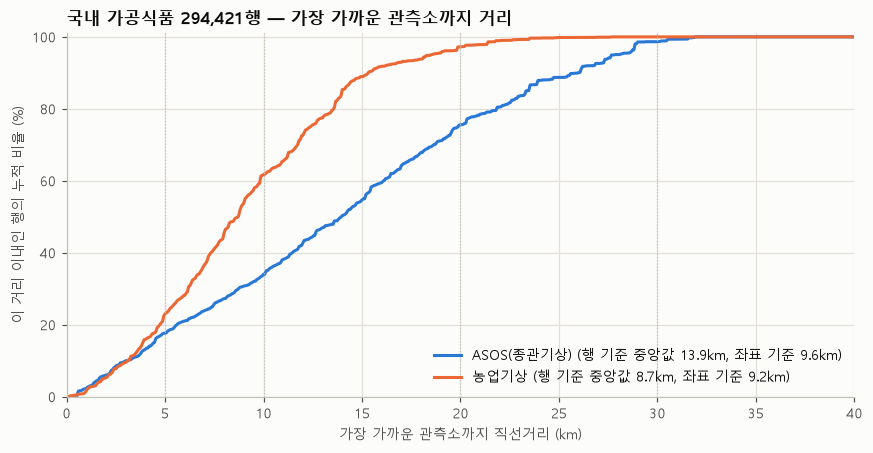

In [33]:
# [3-4] 국내 가공식품 행: 거리 이하인 행의 누적 비율 곡선 (ASOS, 농업기상). x축 0~40km 로 자름 (작성자 임의, 넘는 행 수 출력)
_g = sp.loc[sp['대분류'].eq('가공식품')]
fig, ax = plt.subplots(figsize=(8, 4.2))
_xmax = 40
for col, nm, c in [('asos_km', 'ASOS(종관기상)', C1), ('nas_km', '농업기상', C2)]:
    x = np.sort(_g[col].dropna().to_numpy(float))
    _cm = _g.dropna(subset=[col]).groupby(['lat', 'lon'])[col].first().median()   # 좌표 기준(좌표 1곳 = 1표) 중앙값, 비교용
    grid = np.linspace(0, _xmax, 601)
    y = np.searchsorted(x, grid, side='right') / len(x) * 100
    ax.plot(grid, y, color=c, label=f'{nm} (행 기준 중앙값 {np.median(x):.1f}km, 좌표 기준 {_cm:.1f}km)')
    print(f"{nm}: 행 {len(x):,}, 행 기준 중앙값 {np.median(x):.1f}km, 좌표 기준 중앙값 {_cm:.1f}km, {_xmax}km 넘는 행 {int((x > _xmax).sum()):,}행 (그림 밖)")
for v in [5, 10, 20, 30]:
    ax.axvline(v, color=GRAY, lw=0.8, ls=':')
ax.set_xlim(0, _xmax)
ax.set_ylim(0, 101)
ax.set_xlabel('가장 가까운 관측소까지 직선거리 (km)')
ax.set_ylabel('이 거리 이내인 행의 누적 비율 (%)')
ax.set_title(f'국내 가공식품 {len(_g):,}행 — 가장 가까운 관측소까지 거리')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

📊 **결과** — 국내 가공식품 294,421행. 행 기준 중앙값 최근접 ASOS 13.9km, 최근접 농업기상 8.7km (좌표 기준 9.6km · 9.2km). x축은 작성자가 임의로 40km 에서 자름 — 40km 넘는 행은 ASOS 0행, 농업기상 2행 (그림 밖).
- 행 기준 곡선에서는 농업기상 곡선이 ASOS 곡선보다 왼쪽(가까운 쪽)에 있습니다. 20km 에서 ASOS 75.6%, 농업기상 97.2% (표 3-2-b·c). 좌표 기준으로는 두 관측망의 중앙값 차이가 작습니다 (3-2 첨언).

💬 **첨언** — 거리가 가깝다는 것은 "같은 지역 바깥 기상"이라는 뜻일 뿐, 공장 안 온도·습도를 뜻하지 않습니다. 가공식품에서 이 연결이 의미가 있는지는 아래 질문으로 넘깁니다.

❓ **도메인 전문가께**: 가공식품은 대부분 실내 공정(가열·포장·냉장)을 거칩니다. 공장 주변 **바깥 기상**(기온·습도)이 제품의 리스테리아 검출과 이어질 경로가 있다고 보십니까? 있다면 원료 입고·환경 오염·보관 중 어느 단계입니까?

🎯 **3장이 타겟 범위에 주는 뜻 (추정)**
- 공간 키만 보면 국내 가공식품 행도 좌표 없는 행이 0행이고, 최근접 관측소 거리가 기준규격외 행과 비슷합니다 (행 기준 ASOS 13.9 vs 14.3km). "기상을 붙일 수 없어서" 가공식품을 뺄 근거는 약해 보입니다. 붙였을 때 의미가 있는지는 위 전문가 질문의 답에 달린 것으로 보입니다.
- 거리 기준으로 범위를 자르면 관측망 선택에 따라 남는 행이 달라집니다: 20km 이내 행 비율이 가공식품 ASOS 75.6%, 농업기상 97.2% (행 기준).
- 주소 출처로 범위를 나누면 검사목적 구성(업소주소 '기타' 33.2% vs 제조사소재지 4.8%)이 함께 바뀌므로, 주소 출처별 검출률 차이를 범위 기준의 근거로 쓰기는 어려워 보입니다.
- 그해 기온 자료 결손은 몇몇 관측소(ASOS 176 대구(기) 등)에 몰려 있어, 범위보다 관측소 연결 규칙을 정하는 문제로 보입니다 (5절: 운영이 끝난 관측소가 골라져 생긴 빈칸으로 보임(추정), 7-5절 R2 참고).
- 좌표가 생산지·수거지가 아니라 기관 주소를 가리키는 행은 이어지는 3-5 에서 따로 봅니다.

❓ **도메인 전문가께**: (1) 가장 가까운 관측소가 **몇 km 안**이면 "같은 기상"으로 볼 수 있습니까? (예: 10km, 20km, 같은 시군구) (2) ASOS(종관기상)와 농업기상 중 가공식품·원물 행에 붙이기에 어느 관측망이 더 알맞다고 보십니까? 두 관측망에 따라 거리 기준을 통과하는 행 수가 달라집니다.

### 3-5. 기관 주소로 보이는 좌표 — 기상이 엉뚱한 곳에 붙을 수 있는 행

🔎 기상은 행의 좌표(`lat`,`lon`)로 붙입니다(3절). 그런데 행의 주소가 제조·수거 장소가 아니라 **식약처·검사기관·지자체 같은 기관의 주소**라면, 생산지와 다른 곳의 기상이 붙을 수 있습니다.
- 1절(1-1-b)에서 '충청북도 청주시 흥덕구 오송읍 오송생명2로 187'(같은 번지에 '식품의약품안전처' 표기가 있음)이 국내 원물 검출 10건을 차지하는 것을 보았습니다. 이 절은 **같은 성격의 행을 규칙으로 찾아** 규모와 영향을 봅니다.
- 찾은 행이 정말 기관 주소인지는 이 자료만으로 알 수 없습니다. 아래 수치는 모두 '작성자 규칙에 잡힌 행'이고, 확인은 담당자 질문으로 넘깁니다.
- 잡힌 행 가운데에는 주소 문제와 별개로 **숙련도 평가·정도관리 시료로 보이는 이름**의 행이 있어, 제품명 규칙으로 따로 표시합니다(3-5-2).

#### 3-5-1. 찾는 규칙과 규칙별 규모 (결과보다 먼저 적음)

- **작성자 임의 방법 — 찾는 규칙** (주소 원자료는 바꾸지 않고, 비교용 키만 따로 만듦)
  - **(a) 주소 글자에 기관 단어**
    - ① 공백을 없앤 주소에 기관 이름 단어(식품의약품안전처·식약처·지방식품의약품안전청·보건환경연구원·동물위생시험소·검사소·시험연구원·시험소·검정원·보건소·위생과 등, 전체 목록은 코드 `IA_KW_LONG`)가 있음.
    - ② 공백을 없앤 주소에 지자체 부서 이름으로 보이는 '\~과' 단어(식품안전과·식품의약과·종합민원과·행정자치과·자치행정과·사회복지과, 코드 `IA_KW_DEPT`)가 있음. '\~팀'은 업체 부서 이름과 헷갈려 넣지 않습니다. 회사명 유무 조건은 걸지 않습니다.
    - ③ 시청·군청·구청·도청은 '경상북도 청도군', '청양군 청남면' 같은 지명과 헷갈리므로 **공백을 지우지 않은 원래 주소에서 단어 끝**(뒤가 공백·여는 괄호·닫는 괄호·쉼표·문장 끝)에 올 때만 셉니다.
  - **(b) 검사기관 주소와 같음**: `nb2_db_instt.csv`(검사기관 285곳의 주소 `adres`)와 비교합니다. 공백을 없앤 뒤 같거나 한쪽이 다른 쪽을 포함하면 잡습니다. 보조 조건: 짧은 쪽에 숫자(번지)가 있어야 함(번지 없는 '충북 음성군 대소면' 같은 기관 주소가 면 전체를 잡는 것을 막음), 포함될 때 바로 뒤 글자가 숫자나 '-' 이면 다른 번지로 봄('…로 18' 과 '…로 187' 구분). 시도 표기('충북' ↔ '충청북도') 차이는 맞추지 않습니다(맞춘 경우는 아래 참고 (b')).
    - **(b1) 공공 기관**: 기관코드가 '147' 로 시작(식약처·지방청 코드로 보임, 추정)하거나 기관 이름(국문·영문)에 보건환경연구원·동물위생시험소·축산위생·축산진흥연구소·식품의약품안전·Institute of Health·Health and Environment·Veterinary·Ministry of Food 가 있는 곳.
    - **(b2) 그 밖의 기관**: 민간 검사기관이나 업체 자체 실험실로 보이는 곳(기관 이름이 비어 있는 곳이 많아 둘을 가를 수 없음). 업체 자체 실험실이면 기관 주소가 곧 공장 주소일 수 있어, 기관 주소와 뜻이 다를 수 있습니다 (추정, 아래 결과로 점검).
  - **(c) 좌표 몰림**: 국내 좌표별 행 수 **상위 50곳**(작성자 임의) 가운데 (a)∪(b1) 로 잡힌 행이 1행 이상 있는 좌표에서, 영업허가번호·제조회사명이 **모두 비고** 주소 출처가 '업소주소' 인 행.
  - **(d) 시·도 본청 도로명 주소**: 작성자가 공개된 청사 주소로 만든 목록 18개(17개 시·도 본청 + 경기도 옛 청사, 코드 `IA_HALLS`, 담당자 확인 전)와 **번지 키**가 같은 행.
    - 번지 키(작성자 임의 정규식 `ia_num_key`): 주소에서 '시도|시군구|도로명|건물번호' 만 뽑은 것. 시도 표기는 통일('충청북도'·'충북' → '충북')하고 읍면동·괄호 안 글자는 버립니다. 첫 단어가 시도가 아니거나 도로명+번호가 없으면(예: '울산 북구 연암동 북구청') 키가 없어 (d)·(e) 에서 안 잡힙니다. '매산로3가' 처럼 번호 뒤에 '가'가 오면 동 이름으로 보고 번호로 쓰지 않습니다.
  - **(e) 같은 번지로 넓히기**: (a)∪(b1)∪(d) 로 잡힌 행의 번지 키와 같은 키를 가진 행 가운데 셋 다에 안 잡힌 행. 기관 이름이 붙은 주소와 같은 건물 번지를 도로명만으로 적은 행을 잡으려는 것입니다(예: '울산 동구 봉수로155 동구청' → '울산광역시 동구 봉수로 155').
  - **(q) 숙련도·정도관리·표준물질 시료로 보이는 제품명** (주소 규칙이 아님, 3-5-2): 제품명에 숙련도·정도관리·표준물질·proficiency·CRM·QC(뒤에 숫자 없음)·미생물동정·미생물시료·'미생물N번' 이 있거나, 이름 전체가 '식중독균(정성)' (코드 `QC_NAME_PAT`). 'QC2' 처럼 QC 뒤에 숫자가 붙은 이름은 공정 시료 이름 뒤 표기로 보여 넣지 않습니다 (추정).
- **비교할 변형 목록** (결과보다 먼저)
  - 규칙별: (a), (b1), (b2), (c), (d), (e) — 잡힌 행·검출·국내 좌표 수와 서로 겹침
  - 합친 표시: **F1 = (a)∪(b1)∪(d)∪(e) → 뒤 파트용 변수 `inst_addr_flag`** / 참고 F0 = (a)∪(b1) (주소 글자·기관 주소 일치만) / 참고 F2 = F1∪(c) / 참고 F3 = F1∪(b2)
  - 참고 (b'): 첫 단어(시도 표기)를 통일한 뒤 (b) 를 다시 맞췄을 때 새로 잡히는 행 (F1 에는 넣지 않음)
  - 참고 — F1 이 하한인지 보기(작성자 임의 조건): F1 밖 국내 행 중 검사목적 수거·모니터링검사 × 주소 출처 업소주소 × 허가번호·회사명 없음
  - 참고 — 잘못 잡힘 점검(작성자 임의 조건): F1 중 주소에 층·호 표기가 있고 허가번호·회사명이 있는 행(기관 건물 안 업소일 수 있음) (3-5-2)
  - (q): 전체·F1 안 규모, F1 검출을 오송 주소 / 오송 아닌 (b1) / 그 밖으로 나눔 (3-5-2)
  - 오송 주소 '오송생명2로 187': 주소 문자열 기준 vs 좌표 (36.609188, 127.324562) 기준 (3-5-3)
  - 영향(3-5-4): S1·S2·S7 에서 F1 을 뺀 경우, 참고로 F0·F2 를 뺀 경우. S9 안 F1 비중(3-5-3)

In [34]:
# [3-5-1-a] 규칙 (a): 주소 글자에 기관 단어 (작성자 임의 단어 목록 3가지)
# 비교용 키: 공백만 없앤 주소 (dfx 에 넣지 않고 따로 둠, 원자료는 바꾸지 않음)
ia_addr = dfx['addr'].astype('string')
ia_key = ia_addr.str.replace(r'\s+', '', regex=True)
ia_dom = dfx['국내해외'].eq('국내').to_numpy()
ia_pos = dfx['pos'].to_numpy().astype(bool)
ia_src = dfx['addr_source'].astype(str)
print(f"주소 없음 {int(ia_key.isna().sum()):,}행 (규칙 (a)·(b)·(d)·(e) 에서는 '안 잡힘'으로 셈)")

IA_KW_LONG = ['식품의약품안전처', '식약처', '식품의약품안전청', '지방식품의약품안전청', '식품의약품안전평가원', '보건환경연구원',
              '동물위생시험소', '축산위생연구소', '축산위생사업소', '축산진흥연구소', '농산물품질관리원', '수산물품질관리원', '검역본부',
              '검역소', '검사소', '시험연구원', '시험소', '검정원', '보건소', '위생과', '위생관리계']
IA_KW_DEPT = ['식품안전과', '식품의약과', '종합민원과', '행정자치과', '자치행정과', '사회복지과']   # 지자체 부서 이름으로 보이는 '~과' 단어. '~팀'은 업체 부서와 헷갈려 넣지 않음
IA_KW_WORD = ['시청', '군청', '구청', '도청']   # 원래 주소에서 단어 끝에 올 때만 (뒤가 공백·여는/닫는 괄호·쉼표·문장 끝)


def ia_mask(s, pat):
    '''문자열 Series 에 정규식이 있는지 → numpy bool (값 없음은 False)'''
    return s.str.contains(pat, regex=True).to_numpy(dtype=bool, na_value=False)


def ia_mix(s, n=3):
    '''구성 문자열: 상위 n개 "이름 행수" (나머지는 '외 k')'''
    vc = s.astype(str).value_counts()
    out = ' · '.join(f"{i} {v:,}" for i, v in vc.head(n).items())
    return out + (f" · 외 {int(vc.iloc[n:].sum()):,}" if len(vc) > n else '')


ia_rows, ia_zero, ia_a = [], [], np.zeros(len(dfx), dtype=bool)
for kind, kws in [('① 기관 이름', IA_KW_LONG), ('② 부서 이름', IA_KW_DEPT), ('③ 단어 끝', IA_KW_WORD)]:
    for kw in kws:
        if kind == '③ 단어 끝':
            m = ia_mask(ia_addr, r'(?:^|[\s(,])[^\s(),]*' + kw + r'(?=$|[\s(),])')
        else:
            m = ia_mask(ia_key, re.escape(kw))
        ia_a |= m
        if not m.any():
            ia_zero.append(kw)
            continue
        top = ia_addr[m].str.strip().value_counts()
        ia_rows.append({'단어': kw, '종류': kind, '행': int(m.sum()), '검출': int((m & ia_pos).sum()), '국내 행': int((m & ia_dom).sum()),
                        '주소 출처': ia_src[m].value_counts().to_dict(), '가장 많은 주소 값(행)': f"{top.index[0]} ({int(top.iloc[0])})"})
print('[표 3-5-a] 규칙 (a) 단어별 — 1행 이상 잡힌 단어만 (한 행이 여러 단어에 잡힐 수 있음)')
display(pd.DataFrame(ia_rows).set_index('단어'))
print('0행 단어:', ia_zero)
print(f"규칙 (a) 합계: {int(ia_a.sum()):,}행 / 검출 {int((ia_a & ia_pos).sum())} / 국내 {int((ia_a & ia_dom).sum()):,}행 / 주소 값(공백 제거) {ia_key[ia_a].nunique()}개")
_tm = ia_mask(ia_addr, r'[가-힣]{2,}팀(?=$|[\s(),])') & ~ia_a
print(f"참고(넣지 않은 '~팀' 이름): (a) 밖 {int(_tm.sum()):,}행 / 검출 {int((_tm & ia_pos).sum())} / 주소 상위 5:", ia_addr[_tm].str.strip().value_counts().head(5).to_dict())

주소 없음 0행 (규칙 (a)·(b)·(d)·(e) 에서는 '안 잡힘'으로 셈)
[표 3-5-a] 규칙 (a) 단어별 — 1행 이상 잡힌 단어만 (한 행이 여러 단어에 잡힐 수 있음)


,종류,행,검출,국내 행,주소 출처,가장 많은 주소 값(행)
단어,,,,,,
식품의약품안전처,① 기관 이름,411,0,411,{'업소주소': 411},충북 청주시 흥덕구 오송읍 오송생명2로 187 식품의약품안전처 (244)
식품의약품안전청,① 기관 이름,2,0,2,{'제조사소재지': 2},"서울특별시 양천구 목동중앙로 212 (목동, 서울지방식품의약품안전청) (2)"
지방식품의약품안전청,① 기관 이름,2,0,2,{'제조사소재지': 2},"서울특별시 양천구 목동중앙로 212 (목동, 서울지방식품의약품안전청) (2)"
보건소,① 기관 이름,248,0,248,"{'업소주소': 243, '제조사소재지': 5}",강원도 강릉시 남부로17번길 38 강릉시보건소 (67)
위생과,① 기관 이름,120,0,120,{'업소주소': 120},울산 북구 연암동 북구청 환경위생과 (101)
위생관리계,① 기관 이름,6,0,6,{'업소주소': 6},강원도 양양군 양양읍 양양로 9-5 양양군보건소 위생관리계 (6)
식품안전과,② 부서 이름,699,0,699,{'업소주소': 699},광주광역시 서구 내방로 111 식품안전과 (699)
식품의약과,② 부서 이름,172,0,172,{'업소주소': 172},강원도 춘천시 중앙로 1 식품의약과 (172)
종합민원과,② 부서 이름,18,0,18,{'업소주소': 18},전라남도 고흥군 고흥읍 고흥군청로 1 고흥군 종합민원과 (18)


0행 단어: ['식약처', '식품의약품안전평가원', '보건환경연구원', '동물위생시험소', '축산위생연구소', '축산위생사업소', '축산진흥연구소', '농산물품질관리원', '수산물품질관리원', '검역본부', '검역소', '검사소', '시험연구원', '시험소', '검정원']
규칙 (a) 합계: 3,197행 / 검출 0 / 국내 3,197행 / 주소 값(공백 제거) 77개
참고(넣지 않은 '~팀' 이름): (a) 밖 124행 / 검출 0 / 주소 상위 5: {'서울특별시 광진구 워커힐로 177 지원동 총무팀': 54, '서울특별시 광진구 워커힐로 177 워커힐호텔 업무지원팀': 28, '서울특별시 광진구 워커힐로 177 워커힐호텔 행복경영팀': 20, '경기도 부천시 길주로 180 (중동, 현대백화점 지하1층 식품팀 일부)': 7, '경기도 남양주시 미금로 57 (주)빙그레 식품연구소 식품안전팀': 5}


In [35]:
# [3-5-1-b] 규칙 (b): 검사기관 주소(nb2_db_instt.csv adres)와 같거나 한쪽이 다른 쪽을 포함 (작성자 임의 보조 조건은 위 목록)
ia_ins = pd.read_csv(COL / 'nb2_db_instt.csv', dtype=str)
ia_ins['k'] = ia_ins['adres'].astype('string').str.replace(r'\s+', '', regex=True)
IA_PUB_PAT = r'보건환경연구원|동물위생시험소|축산위생|축산진흥연구소|식품의약품안전|instituteofhealth|healthandenvironment|health&environment|veterinary|ministryoffood'
ia_ins['공공(임의)'] = (ia_ins['inspct_instt_code'].str.startswith('147') | has_kw(ia_ins['instt_nm'], IA_PUB_PAT)
                     | has_kw(ia_ins['instt_eng_nm'], IA_PUB_PAT)).astype(bool)
ia_ins['이름'] = np.where(ia_ins['instt_nm'].notna(), ia_ins['instt_nm'],
                        np.where(ia_ins['instt_eng_nm'].notna(), '(영문) ' + ia_ins['instt_eng_nm'].astype(str).str[:30], '(이름 없음)'))
_noadr = ia_ins['k'].isna() | ia_ins['k'].eq('')
_nodig = ~_noadr & ~ia_ins['k'].str.contains(r'\d', regex=True).to_numpy(dtype=bool, na_value=False)
ia_ok = ia_ins[~_noadr & ~_nodig]
print(f"검사기관 {len(ia_ins)}곳 (공공(임의) {int(ia_ins['공공(임의)'].sum())}곳) → 비교에서 뺀 곳: 주소 없음 {int(_noadr.sum())}곳, 주소에 번지 숫자 없음 {int(_nodig.sum())}곳 "
      f"(그중 공공(임의) {int((ia_ins['공공(임의)'] & (_noadr | _nodig)).sum())}곳: {ia_ins.loc[ia_ins['공공(임의)'] & (_noadr | _nodig), 'instt_nm'].tolist()}) → 비교 {len(ia_ok)}곳")


def ia_match(pairs, ukeys):
    '''행 주소 키 고유값(ukeys, string Series)과 기관 주소 키(pairs = [(기관코드, 키)])를 맞춤 → {행 주소 키: 기관코드 집합}
    작성자 임의 규칙: 같거나 한쪽이 다른 쪽을 포함 / 짧은 쪽에 숫자(번지)가 있어야 함 / 포함된 부분 바로 뒤가 숫자·'-' 이면 다른 번지로 봄'''
    hit = {}
    for c, k in pairs:                                           # 행 주소가 기관 주소를 포함 (같음 포함)
        for x in ukeys[ukeys.str.contains(re.escape(k) + r'(?![0-9-])', regex=True)]:
            hit.setdefault(x, set()).add(c)
    maxlen = max(len(k) for _, k in pairs)
    for x in ukeys[(ukeys.str.len() <= maxlen) & ukeys.str.contains(r'\d', regex=True)]:   # 기관 주소가 행 주소를 포함
        for c, k in pairs:
            j = k.find(x)
            if j >= 0 and (j + len(x) == len(k) or k[j + len(x)] not in '0123456789-'):
                hit.setdefault(x, set()).add(c)
    return hit


ia_uk = pd.Series(ia_key.dropna().unique())
ia_hit = ia_match(list(zip(ia_ok['inspct_instt_code'], ia_ok['k'])), ia_uk)
_pub = set(ia_ins.loc[ia_ins['공공(임의)'], 'inspct_instt_code'])
ia_b1 = ia_key.isin([x for x, cs in ia_hit.items() if cs & _pub]).to_numpy(dtype=bool, na_value=False)
ia_b2 = ia_key.isin([x for x, cs in ia_hit.items() if cs - _pub]).to_numpy(dtype=bool, na_value=False)
print(f"주소 고유값(공백 제거) {len(ia_uk):,}개 중 잡힌 값 {len(ia_hit)}개")

# 기관별로 잡힌 행 (한 주소가 두 기관에 잡히면 두 기관 모두에 셈)
_bsn = dfx['bsn_lcns_ledg_no'].astype('string').str.strip().str.len().gt(0).to_numpy(dtype=bool, na_value=False)
_cmp = dfx['mnfctur_cmpny_nm'].astype('string').str.strip().str.len().gt(0).to_numpy(dtype=bool, na_value=False)
ia_firm = _bsn | _cmp                          # 영업허가번호나 제조회사명 중 하나라도 있음
_own = dfx['inspct_instt_code'].astype('string')
ia_nm = ia_ins.set_index('inspct_instt_code')['이름']
_rows = []
_keys_by_c = {c: [x for x, cs in ia_hit.items() if c in cs] for c in ia_ok['inspct_instt_code']}
for c, cs_keys in _keys_by_c.items():
    if not cs_keys:
        continue
    m = ia_key.isin(cs_keys).to_numpy(dtype=bool, na_value=False)
    r = ia_ins.set_index('inspct_instt_code').loc[c]
    _rows.append({'기관코드': c, '기관 이름': r['이름'], '공공(임의)': bool(r['공공(임의)']), '기관 주소': str(r['adres']).strip(),
                  '잡힌 행': int(m.sum()), '검출': int((m & ia_pos).sum()),
                  '주소 출처': ia_src[m].value_counts().head(2).to_dict(),
                  '허가번호·회사명 있음(%)': round(ia_firm[m].mean() * 100, 1),
                  '행의 검사기관이 이 기관(%)': round(float(_own[m].eq(c).to_numpy(dtype=bool, na_value=False).mean() * 100), 1)})
ia_tb = pd.DataFrame(_rows).sort_values(['공공(임의)', '잡힌 행'], ascending=False)
print(f"잡힌 기관 {len(ia_tb)}곳 (공공(임의) {int(ia_tb['공공(임의)'].sum())}곳)")
print('[표 3-5-b] 규칙 (b) 기관별 — 공공(임의) 전부 + 그 밖 기관 잡힌 행 상위 10')
display(pd.concat([ia_tb[ia_tb['공공(임의)']], ia_tb[~ia_tb['공공(임의)']].head(10)]).set_index('기관코드'))
for lab, m in [('(b1) 공공', ia_b1), ('(b2) 그 밖', ia_b2)]:
    print(f"{lab}: {int(m.sum()):,}행 / 검출 {int((m & ia_pos).sum())} / 국내 {int((m & ia_dom).sum()):,}행 / 주소 출처 {ia_src[m].value_counts().to_dict()} / "
          f"허가번호·회사명 있음 {ia_firm[m].mean() * 100:.1f}%")
print('[참고] (b2) 로 잡힌 행이 많은 기관 3곳의 행 모습 (질문 근거용)')
for c in ['O000539', 'O000229', 'O000197']:
    m = ia_key.isin(_keys_by_c[c]).to_numpy(dtype=bool, na_value=False)
    print(f"  {c} ({ia_nm[c]}, 기관 주소 '{str(ia_ins.set_index('inspct_instt_code').loc[c, 'adres']).strip()}'): {int(m.sum()):,}행 / 검출 {int((m & ia_pos).sum())} / "
          f"업소주소 {(ia_src[m] == '업소주소').mean() * 100:.1f}% / 허가번호·회사명 있음 {ia_firm[m].mean() * 100:.1f}% / 행의 검사기관이 이 기관 {_own[m].eq(c).mean() * 100:.1f}% / "
          f"의뢰시스템 {dfx.loc[m, '의뢰시스템'].value_counts().head(2).to_dict()} / 제품명 상위 {dfx.loc[m, 'prduct_nm'].astype(str).value_counts().head(5).to_dict()}")

검사기관 285곳 (공공(임의) 36곳) → 비교에서 뺀 곳: 주소 없음 29곳, 주소에 번지 숫자 없음 15곳 (그중 공공(임의) 4곳: ['인천광역시 보건환경연구원', '부산광역시 보건환경연구원', '충청북도 축산위생연구소', '서울청 수입식품분석과']) → 비교 241곳
주소 고유값(공백 제거) 39,587개 중 잡힌 값 271개
잡힌 기관 138곳 (공공(임의) 6곳)
[표 3-5-b] 규칙 (b) 기관별 — 공공(임의) 전부 + 그 밖 기관 잡힌 행 상위 10


,기관 이름,공공(임의),기관 주소,잡힌 행,검출,주소 출처,허가번호·회사명 있음(%),행의 검사기관이 이 기관(%)
기관코드,,,,,,,,
1471000,(이름 없음),True,충청북도 청주시 흥덕구 오송읍 오송생명2로 187,1062,10,{'업소주소': 1062},0.0,0.0
1471102,서울청,True,서울특별시 양천구 목동중앙로 212,12,3,"{'업소주소': 10, '제조사소재지': 2}",16.7,0.0
O000113,강원특별자치도 동물위생시험소,True,강원특별자치도 춘천시 신북읍 신북로 386,10,0,{'업소주소': 10},0.0,0.0
O000101,울산광역시 보건환경연구원,True,울산광역시 남구 문수로 157,4,0,{'제조사소재지': 4},100.0,100.0
1471111,부산청,True,부산광역시 연제구 거제대로 222,3,1,{'업소주소': 3},0.0,0.0
1471124,경인청,True,경기도 과천시 관문로 47,2,2,{'업소주소': 2},0.0,0.0
O000539,(이름 없음),False,경기도 양주시 장흥면 가마골로 350,2140,0,"{'업소주소': 2126, '제조사소재지': 14}",0.7,97.8
O000197,(이름 없음),False,강원도 횡성군 안흥면 봉화로 790,1514,0,{'제조사소재지': 1514},99.7,86.2
O000656,(이름 없음),False,경기도 이천시 마장면 덕평로891번길 30-19,1108,0,"{'제조사소재지': 1081, '업소주소': 27}",97.6,78.3


(b1) 공공: 1,093행 / 검출 16 / 국내 1,093행 / 주소 출처 {'업소주소': 1087, '제조사소재지': 6} / 허가번호·회사명 있음 0.5%
(b2) 그 밖: 30,185행 / 검출 6 / 국내 30,185행 / 주소 출처 {'제조사소재지': 20469, '업소주소': 9467, '인허가대장': 249} / 허가번호·회사명 있음 69.9%
[참고] (b2) 로 잡힌 행이 많은 기관 3곳의 행 모습 (질문 근거용)
  O000539 ((이름 없음), 기관 주소 '경기도 양주시 장흥면 가마골로 350'): 2,140행 / 검출 0 / 업소주소 99.3% / 허가번호·회사명 있음 0.7% / 행의 검사기관이 이 기관 97.8% / 의뢰시스템 {'자체의뢰': 2126, '통합망': 14} / 제품명 상위 {'망고': 113, '초콜라또': 112, '피스타치오': 112, '쿠키앤크림': 112, '리조': 112}
  O000229 ((이름 없음), 기관 주소 '경기도 화성시 팔탄면 버들로 1296'): 840행 / 검출 2 / 업소주소 1.5% / 허가번호·회사명 있음 98.5% / 행의 검사기관이 이 기관 96.7% / 의뢰시스템 {'자체의뢰': 825, '통합망': 15} / 제품명 상위 {'CW치즈': 116, '피자스쿨치즈': 106, '네츄럴(X100)': 91, '네츄럴(M08)': 74, '피자스쿨치즈S': 62}
  O000197 ((이름 없음), 기관 주소 '강원도 횡성군 안흥면 봉화로 790'): 1,514행 / 검출 0 / 업소주소 0.0% / 허가번호·회사명 있음 99.7% / 행의 검사기관이 이 기관 86.2% / 의뢰시스템 {'자체의뢰': 1340, '통합망': 174} / 제품명 상위 {'파스퇴르우유 무지방': 55, '파스퇴르우유 후레쉬': 45, '파스퇴르 유산균 우유': 43, '후레쉬엘 045': 43, '후레쉬엘 041': 38}


In [36]:
# [3-5-1-c] 규칙 (c): 좌표 몰림 (작성자 임의: 국내 좌표 행 수 상위 50곳 × (a)∪(b1) 행이 있는 좌표 × 허가번호·회사명 모두 없음 × 주소 출처 '업소주소')
IA_TOPN = 50
ia_f0 = ia_a | ia_b1                          # F0 = (a)∪(b1): (c) 의 씨앗이자 참고 비교용
_d = dfx.loc[ia_dom, ['lat', 'lon']].assign(f0=ia_f0[ia_dom])
print(f"국내 {int(ia_dom.sum()):,}행 중 좌표 없음 {int((_d['lat'].isna() | _d['lon'].isna()).sum())}행 (규칙 (c) 에서 뺌)")
_vc = _d.groupby(['lat', 'lon']).agg(행=('f0', 'size'), f0_행=('f0', 'sum')).sort_values('행', ascending=False)
_vc['순위'] = np.arange(1, len(_vc) + 1)
_top = _vc.head(IA_TOPN)
_seed = _top[_top['f0_행'] > 0]
print(f"국내 좌표 {len(_vc):,}곳, 상위 {IA_TOPN}곳의 최소 행 수 {int(_top['행'].min()):,} (다음 순위 {int(_vc['행'].iloc[IA_TOPN]):,}) → 그중 (a)∪(b1) 행이 있는 좌표 {len(_seed)}곳")
_xy_all = pd.MultiIndex.from_arrays([dfx['lat'], dfx['lon']])
_in_seed = _xy_all.isin(_seed.index) & ia_dom
ia_c = _in_seed & ~ia_firm & ia_src.eq('업소주소').to_numpy()
_rows = []
for (la, lo), r in _seed.iterrows():
    m = ia_dom & (dfx['lat'].to_numpy() == la) & (dfx['lon'].to_numpy() == lo)
    only_c = m & ia_c & ~ia_f0
    _rows.append({'좌표': f"({la:.6f}, {lo:.6f})", '국내 순위': int(r['순위']), '좌표 행': int(r['행']), '(a)∪(b1) 행': int(r['f0_행']),
                  '(a)∪(b1) 주소 상위 2(행)': ia_addr[m & ia_f0].str.strip().value_counts().head(2).to_dict(),
                  '(c) 행': int((m & ia_c).sum()), '(c) 에만 잡힌 행': int(only_c.sum()), '(c) 에만 잡힌 검출': int((only_c & ia_pos).sum()),
                  '(c) 에만 잡힌 주소 상위 3(행)': ia_addr[only_c].str.strip().value_counts().head(3).to_dict(),
                  '좌표 수준(geo_match_level)': dfx.loc[m, 'geo_match_level'].astype(str).value_counts().head(1).to_dict()})
print('[표 3-5-c] 규칙 (c) 씨앗 좌표')
display(pd.DataFrame(_rows).set_index('좌표').T)
del _xy_all, _in_seed, _d, _vc

국내 628,895행 중 좌표 없음 0행 (규칙 (c) 에서 뺌)
국내 좌표 3,599곳, 상위 50곳의 최소 행 수 2,020 (다음 순위 2,019) → 그중 (a)∪(b1) 행이 있는 좌표 2곳
[표 3-5-c] 규칙 (c) 씨앗 좌표


좌표,"(35.613503, 127.279274)","(36.609188, 127.324562)"
국내 순위,15,39
좌표 행,3561,2179
(a)∪(b1) 행,2,1306
(a)∪(b1) 주소 상위 2(행),"{'전라북도 임실군 임실읍 수정로 30, 청소위생과': 2}","{'충청북도 청주시 흥덕구 오송읍 오송생명2로 187': 765, '충북 청주시 흥덕구 오송읍 오송생명2로 187 식품의약품안전처': 244}"
(c) 행,531,1871
(c) 에만 잡힌 행,529,565
(c) 에만 잡힌 검출,0,0
(c) 에만 잡힌 주소 상위 3(행),"{'전라북도 임실군 임실읍 봉황로 329': 475, '전라북도 임실군 임실읍 감성1길 66 (감성리 489-12)': 12, '전라북도 임실군 임실읍 치즈마을길 164-39': 12}","{'충청북도 청주시 흥덕구 오송읍 오송생명12로 160(주ANCM 오송공장 1~2층)': 407, '충청북도 청주시 흥덕구 오송읍 오송생명4로 163': 76, '충청북도 청주시 흥덕구 오송읍 오송생명9로 185(1층)': 26}"
좌표 수준(geo_match_level),{'eupmyeondong': 3561},{'eupmyeondong': 2179}


In [37]:
# [3-5-1-d] 규칙 (d) 시·도 본청 도로명 주소 목록, (e) 같은 번지로 넓히기, 참고 (b') 시도 표기 통일 뒤 (b) 다시 맞추기 — 모두 작성자 임의 방법
IA_SIDO = {'서울특별시': '서울', '서울': '서울', '부산광역시': '부산', '부산': '부산', '대구광역시': '대구', '대구': '대구', '인천광역시': '인천', '인천': '인천',
           '광주광역시': '광주', '광주': '광주', '대전광역시': '대전', '대전': '대전', '울산광역시': '울산', '울산': '울산', '세종특별자치시': '세종', '세종': '세종',
           '경기도': '경기', '경기': '경기', '강원도': '강원', '강원특별자치도': '강원', '강원': '강원', '충청북도': '충북', '충북': '충북', '충청남도': '충남', '충남': '충남',
           '전라북도': '전북', '전북특별자치도': '전북', '전북': '전북', '전라남도': '전남', '전남': '전남', '경상북도': '경북', '경북': '경북', '경상남도': '경남', '경남': '경남',
           '제주특별자치도': '제주', '제주도': '제주', '제주': '제주'}
_ROAD = re.compile(r'(?:^|[\s,(])([가-힣A-Za-z0-9]+(?:로|길))\s*(\d+(?:-\d+)?)(?![\d-]|번길|가)')


def ia_num_key(s):
    '''주소 → '시도|시군구|도로명|건물번호' 키 (작성자 임의 정규식). 첫 단어가 시도 표기가 아니거나 도로명+번호가 없으면 None.
    시도 표기는 IA_SIDO 로 통일, 읍면동·괄호 안 글자는 버림, '매산로3가' 처럼 번호 뒤에 '가'가 오면 동 이름으로 보고 번호로 쓰지 않음'''
    t = re.sub(r'^\s*\d+\.\s*', '', str(s).strip())
    w = t.split()
    if not w or w[0] not in IA_SIDO:
        return None
    mm = _ROAD.search(t)
    if mm is None:
        return None
    sgg = ''.join(v for v in re.split(r'[\s,()]+', t[:mm.start(1)])[1:] if re.fullmatch(r'[가-힣]+(?:시|군|구)', v))
    return '|'.join([IA_SIDO[w[0]], sgg, mm.group(1), mm.group(2)])


_ua = ia_addr.dropna().unique()
ia_nkey = ia_addr.map({s: ia_num_key(s) for s in _ua})     # 행별 번지 키 (dfx 에 넣지 않음)
print(f"번지 키를 만든 행: 국내 {int(ia_dom.sum()):,}행 중 {int(ia_nkey[ia_dom].notna().sum()):,}행 ({ia_nkey[ia_dom].notna().mean() * 100:.2f}%) — 키가 없는 행은 (d)·(e) 에서 '안 잡힘'")
print('키 예시:', {s: ia_num_key(s) for s in ['울산 동구 봉수로155 동구청', '대전광역시 유성구 대학로 211 (어은동, 유성구청)', '경기 수원시 팔달구 매산로3가 경기도청']})

# (d) 시·도 본청 도로명 주소 (작성자가 공개된 청사 주소로 만든 목록 18개, 담당자 확인 전)
IA_HALLS = {'서울특별시청': '서울|중구|세종대로|110', '부산광역시청': '부산|연제구|중앙대로|1001', '대구광역시청': '대구|중구|공평로|88',
            '인천광역시청': '인천|남동구|정각로|29', '광주광역시청': '광주|서구|내방로|111', '대전광역시청': '대전|서구|둔산로|100',
            '울산광역시청': '울산|남구|중앙로|201', '세종특별자치시청': '세종||한누리대로|2130', '경기도청': '경기|수원시영통구|도청로|30',
            '경기도청(옛 청사)': '경기|수원시팔달구|효원로|1', '강원특별자치도청': '강원|춘천시|중앙로|1', '충청북도청': '충북|청주시상당구|상당로|82',
            '충청남도청': '충남|홍성군|충남대로|21', '전북특별자치도청': '전북|전주시완산구|효자로|225', '전라남도청': '전남|무안군|오룡길|1',
            '경상북도청': '경북|안동시|도청대로|455', '경상남도청': '경남|창원시의창구|중앙대로|300', '제주특별자치도청': '제주|제주시|문연로|6'}
ia_d = ia_nkey.isin(list(IA_HALLS.values())).to_numpy(dtype=bool, na_value=False)
_rows, _none = [], []
for h, k in IA_HALLS.items():
    m = ia_nkey.eq(k).to_numpy(dtype=bool, na_value=False)
    if not m.any():
        _none.append(h)
        continue
    mo = m & ~ia_f0
    _rows.append({'청사': h, '행': int(m.sum()), '검출': int((m & ia_pos).sum()), '(a)∪(b1) 밖 행': int(mo.sum()),
                  '대분류 구성': ia_mix(dfx.loc[m, '대분류'], 3), '검사목적 구성': ia_mix(dfx.loc[m, '검사목적'], 2),
                  '허가번호·회사명 있음(%)': round(ia_firm[m].mean() * 100, 1), '(a)∪(b1) 밖 주소 표기(행)': ia_addr[mo].str.strip().value_counts().head(2).to_dict()})
print(f"[표 3-5-d1] 규칙 (d) 청사별 — (d) {int(ia_d.sum()):,}행 / 검출 {int((ia_d & ia_pos).sum())} / (a)∪(b1) 밖 {int((ia_d & ~ia_f0).sum()):,}행")
display(pd.DataFrame(_rows).set_index('청사'))
print(f"행이 있는 청사 {len(_rows)}곳 / 행이 없는 청사 {len(_none)}곳: {_none}")

# (e) (a)∪(b1)∪(d) 행에서 뽑은 번지 키와 같은 키를 가진 행 중 셋 다에 안 잡힌 행 (같은 건물 번지로 보임, 추정)
_core = ia_f0 | ia_d
_seedk = ia_nkey[_core].dropna()
ia_e = ia_nkey.isin(set(_seedk)).to_numpy(dtype=bool, na_value=False) & ~_core
_seed_top = pd.Series(ia_addr[_core].str.strip().to_numpy(), index=ia_nkey[_core].to_numpy()).dropna()
_seed_top = _seed_top[_seed_top.index.notna()].groupby(level=0).agg(lambda s: f"{s.value_counts().index[0]} ({int(s.value_counts().iloc[0])})")
_t = pd.DataFrame({'k': ia_nkey[ia_e], 'addr': ia_addr[ia_e].str.strip(), 'pos': ia_pos[ia_e], 'firm': ia_firm[ia_e],
                   '대분류': dfx.loc[ia_e, '대분류'], '검사목적': dfx.loc[ia_e, '검사목적']})
_rows = []
for k, sub in _t.groupby('k'):
    _rows.append({'번지 키': k, '행': len(sub), '검출': int(sub['pos'].sum()), '(e) 주소 표기(가장 많은, 행)': f"{sub['addr'].value_counts().index[0]} ({int(sub['addr'].value_counts().iloc[0])})",
                  '씨앗 주소(가장 많은 표기, 행)': _seed_top.get(k, '-'), '대분류 구성': ia_mix(sub['대분류'], 2), '검사목적 구성': ia_mix(sub['검사목적'], 1),
                  '허가번호·회사명 있음(%)': round(sub['firm'].mean() * 100, 1)})
ia_te = pd.DataFrame(_rows).sort_values('행', ascending=False).reset_index(drop=True)
print(f"(e) 씨앗 번지 키 {_seedk.nunique()}개 → 새로 잡힌 행 {int(ia_e.sum()):,} / 검출 {int((ia_e & ia_pos).sum())} / 번지 키 {len(ia_te)}개 / "
      f"검사목적 {dfx.loc[ia_e, '검사목적'].value_counts().head(3).to_dict()} / 허가번호·회사명 있음 {ia_firm[ia_e].mean() * 100:.1f}%")
print('[표 3-5-d2] 규칙 (e) 번지 키별 상위 15')
display(ia_te.head(15).set_index('번지 키'))
print('나머지 번지 키(행, 검출):', {k: (int(n), int(p)) for k, n, p in zip(ia_te['번지 키'].iloc[15:], ia_te['행'].iloc[15:], ia_te['검출'].iloc[15:])})


# 참고 (b'): 첫 단어(시도 표기)를 IA_SIDO 로 통일한 뒤 (b) 와 같은 규칙으로 다시 맞춤 — 새로 잡히는 행만 셈 (F1 에는 넣지 않음)
def ia_sido_key(s):
    '''첫 단어(시도 표기)를 통일한 뒤 공백을 없앤 비교용 키'''
    t = str(s).strip()
    w = t.split(maxsplit=1)
    if w and w[0] in IA_SIDO:
        t = IA_SIDO[w[0]] + (w[1] if len(w) > 1 else '')
    return re.sub(r'\s+', '', t)


ia_skey = ia_addr.map({s: ia_sido_key(s) for s in _ua})
_hit_s = ia_match([(c, ia_sido_key(a)) for c, a in zip(ia_ok['inspct_instt_code'], ia_ok['adres'])], pd.Series(ia_skey.dropna().unique(), dtype='string'))
_b1s = ia_skey.isin([x for x, cs in _hit_s.items() if cs & _pub]).to_numpy(dtype=bool, na_value=False)
_b2s = ia_skey.isin([x for x, cs in _hit_s.items() if cs - _pub]).to_numpy(dtype=bool, na_value=False)
_nb1, _nb2 = _b1s & ~ia_b1, _b2s & ~ia_b2
print(f"참고 (b') 시도 표기 통일 뒤: (b1) {int(_b1s.sum()):,}행 (원래 {int(ia_b1.sum()):,}) → 새로 잡힌 {int(_nb1.sum())}행 / 검출 {int((_nb1 & ia_pos).sum())} / "
      f"그중 (a)·(d)·(e) 에 이미 잡힘 {int((_nb1 & (_core | ia_e)).sum())}행 / 주소 {ia_addr[_nb1].str.strip().value_counts().head(3).to_dict()}")
print(f"   (b2) {int(_b2s.sum()):,}행 (원래 {int(ia_b2.sum()):,}) → 새로 잡힌 {int(_nb2.sum()):,}행 / 검출 {int((_nb2 & ia_pos).sum())} / 주소 상위 3 {ia_addr[_nb2].str.strip().value_counts().head(3).to_dict()}")
_bh = ia_mask(ia_key, r'임실군임실읍봉황로329(?![0-9-])')
_bo = int(_own[_bh].eq('O000450').sum())
print(f"   예: 주소 '…임실군 임실읍 봉황로 329' 행 {int(_bh.sum()):,} / 검출 {int((_bh & ia_pos).sum())} / 시도 통일 뒤 (b2) 로 잡힘 {int((_bh & _b2s).sum()):,} (기관 O000450, 주소 '{str(ia_ins.set_index('inspct_instt_code').loc['O000450', 'adres']).strip()}', 이름 {ia_nm['O000450']}) / "
      f"행의 검사기관 O000450 {_bo:,}행 ({_bo / _bh.sum() * 100:.1f}%) / 허가번호·회사명 있음 {ia_firm[_bh].mean() * 100:.1f}% / 대분류 {dfx.loc[_bh, '대분류'].value_counts().to_dict()} / "
      f"제품명 상위 {dfx.loc[_bh, 'prduct_nm'].astype(str).value_counts().head(6).to_dict()}")
del _t, _seed_top, _hit_s

번지 키를 만든 행: 국내 628,895행 중 619,360행 (98.48%) — 키가 없는 행은 (d)·(e) 에서 '안 잡힘'
키 예시: {'울산 동구 봉수로155 동구청': '울산|동구|봉수로|155', '대전광역시 유성구 대학로 211 (어은동, 유성구청)': '대전|유성구|대학로|211', '경기 수원시 팔달구 매산로3가 경기도청': None}
[표 3-5-d1] 규칙 (d) 청사별 — (d) 2,336행 / 검출 0 / (a)∪(b1) 밖 1,044행


,행,검출,(a)∪(b1) 밖 행,대분류 구성,검사목적 구성,허가번호·회사명 있음(%),(a)∪(b1) 밖 주소 표기(행)
청사,,,,,,,
부산광역시청,157,0,157,농산물(원물) 150 · 가공식품 4 · 기타(접객·건기식·첨가물) 3,수거검사 157,1.3,"{'부산광역시 연제구 중앙대로 1001 (연산동)': 154, '부산광역시 연제구 중앙대로 1001, (연산동)': 3}"
대구광역시청,53,0,53,기타(접객·건기식·첨가물) 53,수거검사 53,0.0,{'대구광역시 중구 공평로 88 (동인동1가)': 53}
광주광역시청,708,0,0,가공식품 316 · 기타(접객·건기식·첨가물) 231 · 농산물(원물) 161,수거검사 708,99.9,{}
대전광역시청,743,0,743,기타(접객·건기식·첨가물) 320 · 가공식품 300 · 농산물(원물) 123,수거검사 743,3.8,{'대전광역시 서구 둔산로 100': 743}
울산광역시청,205,0,37,기타(접객·건기식·첨가물) 151 · 가공식품 54,수거검사 205,2.0,{'울산광역시 남구 중앙로 201': 37}
강원특별자치도청,172,0,0,농산물(원물) 147 · 기타(접객·건기식·첨가물) 23 · 가공식품 2,수거검사 172,99.4,{}
충청북도청,34,0,34,기타(접객·건기식·첨가물) 34,수거검사 34,32.4,{'충청북도 청주시 상당구 상당로 82': 34}
전라남도청,10,0,0,가공식품 10,수거검사 10,0.0,{}
경상북도청,234,0,0,농산물(원물) 160 · 기타(접객·건기식·첨가물) 74,모니터링검사 165 · 수거검사 69,55.6,{}


행이 있는 청사 10곳 / 행이 없는 청사 8곳: ['서울특별시청', '인천광역시청', '세종특별자치시청', '경기도청', '경기도청(옛 청사)', '충청남도청', '전북특별자치도청', '제주특별자치도청']
(e) 씨앗 번지 키 64개 → 새로 잡힌 행 717 / 검출 0 / 번지 키 23개 / 검사목적 {'수거검사': 711, '기타': 5, '자가품질위탁검사': 1} / 허가번호·회사명 있음 22.6%
[표 3-5-d2] 규칙 (e) 번지 키별 상위 15


,행,검출,"(e) 주소 표기(가장 많은, 행)","씨앗 주소(가장 많은 표기, 행)",대분류 구성,검사목적 구성,허가번호·회사명 있음(%)
번지 키,,,,,,,
울산|남구|돋질로|233,114,0,울산광역시 남구 돋질로 233 (114),울산광역시 남구 돋질로 233(울산광역시 남구청 달동) (2),기타(접객·건기식·첨가물) 98 · 가공식품 15 · 외 1,수거검사 114,0.9
울산|북구|산업로|1010,88,0,울산광역시 북구 산업로 1010 (88),"울산 북구 산업로 1010, 북구청(연암동) (3)",기타(접객·건기식·첨가물) 83 · 가공식품 3 · 외 2,수거검사 88,0.0
울산|중구|단장골길|1,82,0,울산광역시 중구 단장골길 1 (82),"울산 중구 복산동 단장골길 1(복산동, 중구청) (61)",기타(접객·건기식·첨가물) 79 · 가공식품 2 · 외 1,수거검사 82,0.0
울산|울주군|군청로|1,77,0,울산광역시 울주군 청량읍 군청로 1 (65),울산광역시 울주군 청량면 군청로 1(울주군청) (3),기타(접객·건기식·첨가물) 68 · 가공식품 8 · 외 1,수거검사 77,0.0
울산|동구|봉수로|155,72,0,울산 동구 대송동 봉수로 155 (28),울산 동구 봉수로155 동구청 (82),기타(접객·건기식·첨가물) 49 · 가공식품 17 · 외 6,수거검사 72,9.7
광주|남구|봉선로|1,56,0,광주광역시 남구 봉선로 1 (주월동) (37),광주광역시 남구 봉선로 1 남구청 (18),기타(접객·건기식·첨가물) 46 · 가공식품 10,수거검사 56,92.9
대전|유성구|대학로|211,42,0,대전광역시 유성구 대학로 211 (37),"대전광역시 유성구 대학로 211 (어은동, 유성구청) (67)",기타(접객·건기식·첨가물) 42,수거검사 42,0.0
강원|강릉시|남부로17번길|38,30,0,강원도 강릉시 남부로17번길 38 (30),강원도 강릉시 남부로17번길 38 강릉시보건소 (67),기타(접객·건기식·첨가물) 30,수거검사 30,100.0
대전|중구|중앙로|100,29,0,대전광역시 중구 중앙로 100 (29),"대전광역시 중구 중앙로 100 (대흥동, 중구청) (16)",기타(접객·건기식·첨가물) 29,수거검사 29,0.0


나머지 번지 키(행, 검출): {'강원|삼척시|척주로|76': (10, 0), '충북|음성군|중앙로|173': (4, 0), '부산|동래구|명륜로94번길|55': (3, 0), '부산|강서구|낙동북로|477': (3, 0), '전남|장흥군|장흥로|21': (3, 0), '부산|해운대구|중동2로|11': (3, 0), '서울|양천구|목동중앙로|212': (1, 0), '울산|남구|문수로|382': (1, 0)}
참고 (b') 시도 표기 통일 뒤: (b1) 1,338행 (원래 1,093) → 새로 잡힌 245행 / 검출 0 / 그중 (a)·(d)·(e) 에 이미 잡힘 245행 / 주소 {'충북 청주시 흥덕구 오송읍 오송생명2로 187 식품의약품안전처': 244, '서울 양천구 목동중앙로 212': 1}
   (b2) 41,320행 (원래 30,185) → 새로 잡힌 12,304행 / 검출 6 / 주소 상위 3 {'충청북도 음성군 대소면 대금로105번길 70': 2042, '충청북도 진천군 이월면 궁동길 51-21': 1599, '전라북도 임실군 임실읍 봉황로 329': 1219}
   예: 주소 '…임실군 임실읍 봉황로 329' 행 1,507 / 검출 0 / 시도 통일 뒤 (b2) 로 잡힘 1,507 (기관 O000450, 주소 '전북 임실군 임실읍 봉황로329', 이름 (이름 없음)) / 행의 검사기관 O000450 1,390행 (92.2%) / 허가번호·회사명 있음 67.7% / 대분류 {'가공식품': 1495, '기준규격외(검체)': 12} / 제품명 상위 {'유농축액': 149, '벨라유 유크림': 127, '임실생치즈': 91, '임실스트링치즈': 80, '벨라유 임실피자치즈': 77, '임실고융점치즈': 75}


In [38]:
# [3-5-1-f] 규칙별 규모와 겹침, 합친 표시 F0~F3, 참고: F1 밖 남은 후보 (F1 이 하한인지 보기, 작성자 임의 조건)
inst_addr_rules = pd.DataFrame({'a': ia_a, 'b1': ia_b1, 'b2': ia_b2, 'c': ia_c, 'd': ia_d, 'e': ia_e}, index=dfx.index)
ia_f1 = ia_f0 | ia_d | ia_e
_sets = [('(a) 기관 단어', ia_a), ('(b1) 공공 기관 주소', ia_b1), ('(b2) 그 밖 기관 주소', ia_b2), ('(c) 좌표 몰림', ia_c),
         ('(d) 시·도 본청 주소', ia_d), ('(e) 같은 번지 넓히기', ia_e), ('F0 = (a)∪(b1) 참고', ia_f0),
         ('F1 = (a)∪(b1)∪(d)∪(e)', ia_f1), ('F2 = F1∪(c) 참고', ia_f1 | ia_c), ('F3 = F1∪(b2) 참고', ia_f1 | ia_b2)]
_rows = []
for lab, m in _sets:
    _rows.append({'규칙': lab, '행': int(m.sum()), '검출': int((m & ia_pos).sum()), '국내 행': int((m & ia_dom).sum()),
                  '국내 검출': int((m & ia_dom & ia_pos).sum()), '국내 좌표 수': int(dfx.loc[m & ia_dom, ['lat', 'lon']].drop_duplicates().shape[0]),
                  '주소 값 수(공백 제거)': int(ia_key[m].nunique())})
print('[표 3-5-d] 규칙별 잡힌 행·검출·좌표 수')
display(pd.DataFrame(_rows).set_index('규칙'))
_nm6 = ['a', 'b1', 'b2', 'c', 'd', 'e']
print('[표 3-5-e] 규칙끼리 겹치는 행 수 (대각선 = 그 규칙 행 수)')
display(pd.DataFrame([[int((inst_addr_rules[p] & inst_addr_rules[q]).sum()) for q in _nm6] for p in _nm6], index=_nm6, columns=_nm6))

# 참고(작성자 임의 조건): F1 밖 국내 행 중 검사목적 수거·모니터링검사 × 주소 출처 업소주소 × 허가번호·회사명 없음 — 규칙에 없는 기관 주소가 섞여 있을 수 있는 행
_cat = dfx['대분류']
_cand = ia_dom & ~ia_f1 & dfx['검사목적'].isin(['수거검사', '모니터링검사']).to_numpy() & ia_src.eq('업소주소').to_numpy() & ~ia_firm
print(f"참고: F1 밖 남은 후보 {int(_cand.sum()):,}행 / 검출 {int((_cand & ia_pos).sum())} / 주소 값 {ia_key[_cand].nunique():,}개 / "
      f"S1 {int((_cand & _cat.isin(['농산물(원물)', '축산물(원물)', '수산물(원물)']).to_numpy()).sum())}행 · S2 {int((_cand & _cat.eq('가공식품').to_numpy()).sum())}행 · "
      f"S7 {int((_cand & _cat.eq('기준규격외(검체)').to_numpy()).sum())}행")
print('   주소 상위 10(행):', ia_addr[_cand].str.strip().value_counts().head(10).to_dict())

[표 3-5-d] 규칙별 잡힌 행·검출·좌표 수


,행,검출,국내 행,국내 검출,국내 좌표 수,주소 값 수(공백 제거)
규칙,,,,,,
(a) 기관 단어,3197,0,3197,0,66,77
(b1) 공공 기관 주소,1093,16,1093,16,6,10
(b2) 그 밖 기관 주소,30185,6,30185,6,118,261
(c) 좌표 몰림,2402,10,2402,10,2,34
(d) 시·도 본청 주소,2336,0,2336,0,11,14
(e) 같은 번지 넓히기,717,0,717,0,24,28
F0 = (a)∪(b1) 참고,4121,16,4121,16,69,85
F1 = (a)∪(b1)∪(d)∪(e),5882,16,5882,16,81,120
F2 = F1∪(c) 참고,6976,16,6976,16,81,149


[표 3-5-e] 규칙끼리 겹치는 행 수 (대각선 = 그 규칙 행 수)


,a,b1,b2,c,d,e
a,3197,169,0,413,1292,0
b1,169,1093,0,1062,0,0
b2,0,0,30185,0,0,0
c,413,1062,0,2402,0,0
d,1292,0,0,0,2336,0
e,0,0,0,0,0,717


참고: F1 밖 남은 후보 1,061행 / 검출 0 / 주소 값 81개 / S1 95행 · S2 213행 · S7 0행
   주소 상위 10(행): {'전라남도 목포시 원산로45번길 5': 73, '전라남도 나주시 풍물시장2길 57-32': 52, '대전광역시 동구 동구청로 147': 49, '대구광역시 달서구 학산로 45 (월성동)': 45, '전라남도 해남군 해남읍 군청길 4': 42, '대구광역시 북구 성북로 49 (침산3동)': 42, '대전광역시 동구 동구청로 147 (가오동)': 41, '경남 양산시 중부동': 36, '전라남도 강진군 강진읍 탐진로 111': 31, '전라남도 순천시 중앙로 232 (석현동, 순천시문화건강센터)': 29}


📊 **결과**
- **(a) 기관 단어**: 3,197행 / 검출 0 / 모두 국내 / 주소 값(공백 제거) 77개.
  - ① 기관 이름: 식품의약품안전처 411행(가장 많은 값 '충북 청주시 흥덕구 오송읍 오송생명2로 187 식품의약품안전처' 244행), 보건소 248·위생과 120행. 식약처·보건환경연구원·검사소·시험연구원·시험소·검정원 등은 0행.
  - ② 부서 이름: 식품안전과 699행(모두 '광주광역시 서구 내방로 111 식품안전과'), 식품의약과 172행(모두 '강원도 춘천시 중앙로 1 식품의약과'), 행정자치과 31·종합민원과 18·자치행정과 15·사회복지과 12행.
  - ③ 단어 끝: 구청 500·시청 476·도청 342·군청 254행.
  - 넣지 않은 '\~팀' 이름은 (a) 밖 124행·검출 0 이고, 주소는 '서울특별시 광진구 워커힐로 177 지원동 총무팀' 54행, '경기도 남양주시 미금로 57 (주)빙그레 식품연구소 식품안전팀' 5행 같은 업체 주소입니다.
- **(b) 검사기관 주소**: 285곳 중 주소 없음 29곳·주소에 번지 숫자 없음 15곳을 빼고 241곳과 비교(뺀 곳 중 공공(임의) 4곳: 인천광역시·부산광역시 보건환경연구원, 충청북도 축산위생연구소, 서울청 수입식품분석과). 잡힌 기관 138곳.
  - (b1) 공공 6곳: 1,093행 / 검출 16 / 주소 출처 업소주소 1,087 / 허가번호·회사명 있음 0.5%. 이 중 기관코드 1471000(이름 없음, 주소 '충청북도 청주시 흥덕구 오송읍 오송생명2로 187') 이 1,062행·검출 10 이고, 이 행들의 검사기관이 1471000 인 비율은 0.0% 입니다. 나머지는 서울청(목동중앙로 212) 12행·3건, 강원특별자치도 동물위생시험소 10행·0, 울산광역시 보건환경연구원 4행·0, 부산청 3행·1건, 경인청 2행·2건.
  - (b2) 그 밖: 30,185행 / 검출 6 / 주소 출처 제조사소재지 20,469·업소주소 9,467·인허가대장 249 / 허가번호·회사명 있음 69.9%.
  - (b2) 기관 예: O000229 는 잡힌 840행의 허가번호·회사명 있음 98.5%·제품명 CW치즈 116·피자스쿨치즈 106행 등, O000197 은 1,514행·99.7%·파스퇴르우유 무지방 55행 등이고, 행의 검사기관이 그 기관인 비율이 96.7%·86.2% 입니다. O000539 는 2,140행이 업소주소 99.3%·허가번호·회사명 있음 0.7%·제품명 망고 113·초콜라또 112·피스타치오 112행 등·행의 검사기관이 이 기관 97.8% 입니다.
- **(c) 좌표 몰림**: 국내 좌표 3,599곳, 상위 50곳(최소 2,020행, 다음 순위 2,019행) 중 (a)∪(b1) 행이 있는 좌표는 2곳 — 오송 (36.609188, 127.324562) 국내 순위 39·2,179행, 임실 (35.613503, 127.279274) 순위 15·3,561행(씨앗은 '전라북도 임실군 임실읍 수정로 30, 청소위생과' 2행). (c) 는 2,402행·검출 10 이고, (c) 에만 잡힌 행은 오송 565·임실 529행(검출 0).
- **번지 키**: 국내 628,895행 중 619,360행 (98.48%) 에 키가 만들어졌습니다.
- **(d) 시·도 본청 주소**: 2,336행 / 검출 0 / (a)∪(b1) 밖 1,044행. 행이 있는 청사 10곳, 없는 청사 8곳(서울·인천·세종·경기(두 곳)·충남·전북·제주). 경상북도청(모니터링검사 165·수거검사 69)을 빼면 모두 수거검사입니다.
  - (a)∪(b1) 밖 행: 대전광역시청 '대전광역시 서구 둔산로 100' 743행, 부산광역시청 157행, 대구광역시청 53행, 울산광역시청 '울산광역시 남구 중앙로 201' 37행, 충청북도청 34행, 경상남도청 20행.
  - 허가번호·회사명 있음: 광주광역시청 행 99.9%, 강원특별자치도청 행 99.4% 로 거의 다 있고, 대전광역시청 3.8%·부산광역시청 1.3% 는 거의 없습니다.
- **(e) 같은 번지 넓히기**: 씨앗 번지 키 64개 → 새로 잡힌 행 717 / 검출 0 / 번지 키 23개 / 수거검사 711행 / 허가번호·회사명 있음 22.6%. 많은 순으로 '울산광역시 남구 돋질로 233' 114행(씨앗 '…돋질로 233(울산광역시 남구청 달동)' 2행), '울산광역시 북구 산업로 1010' 88행, '울산광역시 중구 단장골길 1' 82행, 울주군 군청로 1 77행('울산광역시 울주군 청량읍 군청로 1' 표기 65행 등), 동구 봉수로 155 72행, 광주 남구 봉선로 1 56행(허가번호·회사명 있음 92.9%).
- **참고 (b') 시도 표기 통일 뒤**: (b1) 은 245행이 새로 잡히지만 245행 모두 (a)·(d)·(e) 에 이미 잡혀 있습니다('충북 … 식품의약품안전처' 244행, '서울 양천구 목동중앙로 212' 1행). (b2) 는 12,304행·검출 6 이 새로 잡힙니다.
  - 예: 주소 '…임실군 임실읍 봉황로 329' 1,507행(검출 0)은 시도 통일 뒤 (b2) 기관 O000450(주소 '전북 임실군 임실읍 봉황로329', 이름 없음)과 맞습니다. 행의 검사기관이 O000450 인 행 1,390행 (92.2%), 허가번호·회사명 있음 67.7%, 가공식품 1,495행, 제품명 유농축액 149·벨라유 유크림 127·임실생치즈 91·임실스트링치즈 80행 등.
- **합친 표시**: F1 = (a)∪(b1)∪(d)∪(e) **5,882행 / 검출 16** / 국내 좌표 81곳 / 주소 값 120개. 참고 F0 = (a)∪(b1) 4,121행 / 16, F2 = F1∪(c) 6,976행 / 16, F3 = F1∪(b2) 36,067행 / 22.
- 겹침(표 3-5-e): (a)∩(b1) 169행, (a)∩(c) 413행, (a)∩(d) 1,292행, (b1)∩(c) 1,062행. (b2)·(e) 는 다른 규칙과 겹침 0 ((e) 는 정의상 (a)·(b1)·(d) 와 안 겹침).
- **참고 F1 밖 남은 후보**(수거·모니터링검사 × 업소주소 × 허가번호·회사명 없음): 1,061행 / 검출 0 / 주소 값 81개 / S1 95행 · S2 213행 · S7 0행. 주소는 '전라남도 목포시 원산로45번길 5' 73행, '전라남도 나주시 풍물시장2길 57-32' 52행, '대전광역시 동구 동구청로 147' 49행(+ '(가오동)' 표기 41행), '대구광역시 달서구 학산로 45 (월성동)' 45행, '전라남도 해남군 해남읍 군청길 4' 42행 등.

💬 **첨언**
- (b2) 로 잡힌 행은 주소 출처 제조사소재지·허가번호나 회사명이 있는 행이 많고, 행의 검사기관이 바로 그 주소의 기관인 경우가 많습니다. O000229(치즈)·O000197(우유)처럼 업체가 자기 실험실에서 검사한 제품의 공장 주소로 보입니다 (추정). 그래서 '기상이 엉뚱한 곳에 붙는 행'과 뜻이 달라 보여 `inst_addr_flag` 에 넣지 않았습니다 (작성자 임의). 다만 O000539 는 업소주소 출처이고 회사명이 거의 없어 성격이 달라 보입니다.
- 시도 표기를 통일해도 (b1) 로 새로 잡힌 행은 모두 이미 F1 에 있었습니다. 시도 표기 차이로 놓친 공공 기관 주소는 거의 없어 보입니다 (추정). '봉황로 329' 는 제품명이 치즈·유크림류이고 대부분 O000450 이 검사해, 기관 주소라기보다 치즈 공장(자체 실험실)의 주소로 보입니다 (추정). 그래서 (c) 에만 잡힌 임실 좌표 행도 표시에 넣지 않았습니다.
- (c) 씨앗 좌표 두 곳은 좌표 수준이 모두 읍면동 대표점(eupmyeondong)입니다. (c) 에만 잡힌 행은 같은 읍의 다른 주소('…오송생명12로 160(주ANCM 오송공장 1\~2층)' 407행, '…봉황로 329' 475행 등)가 대부분이라 표시에 넣지 않았습니다 (추정).
- 주소 글자·기관 주소 일치만 쓰면(F0) '대전광역시 서구 둔산로 100' 처럼 도로명만 적힌 청사 주소를 놓칩니다. (d)·(e) 를 더해 4,121행이 5,882행으로 늘었지만, 목록에 없는 시·군·구청이나 기관 단어가 한 번도 붙지 않은 주소는 여전히 빠집니다. 남은 후보 1,061행에도 '동구청로 147', '군청길 4' 같은 이름의 도로명 주소가 있어, **F1 은 기관 주소 행의 하한**으로 보는 것이 맞아 보입니다 (추정).
- 부서 이름 행(광주 식품안전과·강원 식품의약과)은 회사명이 거의 다 있어, '회사명 없음' 조건을 걸면 빠집니다. 회사명은 수거한 제품의 회사, 주소는 수거 기관으로 적힌 것으로 보입니다 (추정).

🗄️ **데이터 담당자께**: 검사기관 정보(`m_sy_inspct_instt`)에서 기관코드 1471000(주소 '충청북도 청주시 흥덕구 오송읍 오송생명2로 187', 이름 비어 있음)은 어떤 기관입니까? 공공 기관·민간 검사기관·업체 자체 실험실을 구분하는 컬럼이 있습니까?
- 이 주소 문자열 행은 1,306행입니다(3-5-3). 그중 기관 주소와 표기가 맞아 (b1) 로 잡힌 행은 1,062행이고, '충북 …' 으로 시작하는 244행은 (a) 로 잡혔습니다.
- (b1) 로 잡힌 1,062행 가운데 검사기관이 1471000 인 행은 0.0% 입니다.

🗄️ **데이터 담당자께**: 이름이 비어 있는 O000450·O000229·O000197 은 업체 자체 실험실입니까? 그렇다면 그 행의 주소를 실제 생산지로 보아도 됩니까?
- O000450(주소 '전북 임실군 임실읍 봉황로329'): 주소 '…임실군 임실읍 봉황로 329' 1,507행 중 1,390행 (92.2%) 을 검사, 제품명 유농축액·벨라유 유크림·임실생치즈·임실스트링치즈
- O000229(주소 '경기도 화성시 팔탄면 버들로 1296'): 잡힌 840행, 허가번호·회사명 있음 98.5%, 행의 검사기관이 이 기관 96.7%, 제품명 CW치즈·피자스쿨치즈
- O000197(주소 '강원도 횡성군 안흥면 봉화로 790'): 잡힌 1,514행, 허가번호·회사명 있음 99.7%, 86.2%, 제품명 파스퇴르우유 무지방·파스퇴르우유 후레쉬

🗄️ **데이터 담당자께**: O000539(주소 '경기도 양주시 장흥면 가마골로 350', 이름 없음)와 주소가 같은 2,140행은 업소주소 출처 99.3%·허가번호·회사명 있음 0.7% 이고, 제품명이 망고·초콜라또·피스타치오 같은 맛 이름이며, 행의 검사기관이 이 기관인 비율이 97.8% 입니다. 이 행의 '업소주소'는 제조 장소입니까, 아니면 검사기관 주소가 채워진 것입니까?

#### 3-5-2. 잡힌 주소·좌표 상위 목록 (F1)

🔎 F1 로 잡힌 행을 (공백 제거 주소, 좌표) 로 묶어 행 수 상위 15개를 봅니다. 주소는 그 묶음에서 가장 많이 나온 원래 표기입니다.
- 이어서 검출이 있는 '오송이 아닌 (b1)' 행의 제품명과 행의 검사기관을 보고, 제품명 규칙 (q) 로 숙련도·정도관리 시료로 보이는 행의 규모를 셉니다.
- 잘못 잡힘 점검으로, 층·호 표기와 회사명이 함께 있는 행(기관 건물 안 업소일 수 있음)도 셉니다.

In [39]:
# [3-5-2] F1 잡힌 행: (공백 제거 주소, 좌표) 묶음별 행·검출·대분류·검사목적·주소 출처
inst_addr_flag = pd.Series(ia_f1, index=dfx.index, name='inst_addr_flag')
_m = inst_addr_flag.to_numpy()
_lab = np.full(int(_m.sum()), '', dtype=object)
for nm_, arr in [('a', ia_a), ('b1', ia_b1), ('d', ia_d), ('e', ia_e)]:
    _v = arr[_m]
    _lab = np.where(_v, np.where(_lab == '', nm_, _lab + '+' + nm_), _lab)
_g = pd.DataFrame({'k': ia_key[_m], 'addr': ia_addr[_m].str.strip(), 'lat': dfx.loc[_m, 'lat'], 'lon': dfx.loc[_m, 'lon'],
                   'pos': dfx.loc[_m, 'pos'], '대분류': dfx.loc[_m, '대분류'], '검사목적': dfx.loc[_m, '검사목적'], '출처': ia_src[_m], '규칙': _lab})
_rows = []
for (k, la, lo), sub in _g.groupby(['k', 'lat', 'lon'], dropna=False):
    _rows.append({'주소(가장 많은 표기)': sub['addr'].value_counts().index[0], '좌표': f"({la:.6f}, {lo:.6f})" if pd.notna(la) else '(없음)',
                  '규칙': '·'.join(sorted(sub['규칙'].unique())), '행': len(sub), '검출': int(sub['pos'].sum()), '대분류 구성': ia_mix(sub['대분류']),
                  '검사목적 구성': ia_mix(sub['검사목적'], 2), '주소 출처': ia_mix(sub['출처'], 2)})
ia_t352 = pd.DataFrame(_rows).sort_values(['행', '검출'], ascending=False).reset_index(drop=True)
ia_t352.index += 1
print(f"F1 잡힌 행 {int(_m.sum()):,} → (주소, 좌표) 묶음 {len(ia_t352)}개, 좌표 {_g[['lat', 'lon']].drop_duplicates().shape[0]}곳. "
      f"상위 15개 묶음 = {int(ia_t352['행'].head(15).sum()):,}행 ({ia_t352['행'].head(15).sum() / _m.sum() * 100:.1f}%), 검출 {int(ia_t352['검출'].head(15).sum())}")
print('F1 좌표별(좌표 하나에 여러 주소가 있을 수 있음) 행 상위 5:',
      {f"({la:.6f}, {lo:.6f})": int(v) for (la, lo), v in _g.groupby(['lat', 'lon']).size().sort_values(ascending=False).head(5).items()})
print('[표 3-5-2] F1 (주소, 좌표) 묶음 상위 15')
display(ia_t352.head(15))

# (b1) 중 오송 주소가 아닌 행: 주소 × 행의 검사기관별 제품명 (검출 행이 어떤 시료인지 보기)
_nb = ia_b1 & ~ia_mask(ia_key, r'오송생명2로187(?![0-9-])')
_t = pd.DataFrame({'주소': ia_addr[_nb].str.strip(), '검사기관': _own[_nb], 'pos': ia_pos[_nb], '제품명': dfx.loc[_nb, 'prduct_nm'].astype(str),
                   '대분류': dfx.loc[_nb, '대분류'], '목적': dfx.loc[_nb, '검사목적'].astype(str) + '·' + dfx.loc[_nb, '의뢰시스템'].astype(str)})
_rows = []
for (a, c), sub in _t.groupby(['주소', '검사기관']):
    _neg = sub.loc[~sub['pos'], '제품명']
    _rows.append({'주소': a, '행의 검사기관': f"{c} {ia_nm.get(c, '')}", '행': len(sub), '검출': int(sub['pos'].sum()),
                  '검출 행 제품명': ', '.join(sub.loc[sub['pos'], '제품명']) or '-',
                  '불검출 행 제품명': (', '.join(_neg.head(3)) + (f" 외 {len(_neg) - 3}" if len(_neg) > 3 else '')) or '-',
                  '대분류': ia_mix(sub['대분류'], 2), '검사목적·의뢰시스템': ia_mix(sub['목적'], 1)})
print(f"[표 3-5-b1] (b1) 중 오송 주소 문자열이 아닌 행 {int(_nb.sum())} (검출 {int((_nb & ia_pos).sum())}) — 주소 × 행의 검사기관별")
display(pd.DataFrame(_rows).set_index(['주소', '행의 검사기관']))
print('   주소별 (행, 검출):', {a: (len(sub), int(sub['pos'].sum())) for a, sub in _t.groupby('주소')})
_reg = _nb & ia_key.isin([x for x, cs in ia_hit.items() if any(c.startswith('147') and c != '1471000' for c in cs)]).to_numpy(dtype=bool, na_value=False)
print(f"   그중 지방청 코드(147…, 1471000 제외) 주소와 맞은 행 {int(_reg.sum())} / 검출 {int((_reg & ia_pos).sum())} / 검사목적·의뢰시스템 "
      f"{(dfx.loc[_reg, '검사목적'].astype(str) + '·' + dfx.loc[_reg, '의뢰시스템'].astype(str)).value_counts().to_dict()} / 허가번호·회사명 있음 {int((_reg & ia_firm).sum())}행")

# 참고(작성자 임의 점검): 기관 건물 안에 있는 업소일 수 있는 행 — F1 중 주소에 층·호 표기가 있고 허가번호·회사명이 있음
_fl = _m & ia_mask(ia_addr, r'\d+\s*층|\d+\s*호') & ia_firm
print(f"참고: F1 중 층·호 표기 × 허가번호·회사명 있음 {int(_fl.sum())}행 (검출 {int((_fl & ia_pos).sum())}) / 대분류 {dfx.loc[_fl, '대분류'].value_counts().to_dict()}")
print('   주소(행):', ia_addr[_fl].str.strip().value_counts().to_dict())
print('   회사명(행):', dfx.loc[_fl, 'mnfctur_cmpny_nm'].astype(str).value_counts().to_dict())

F1 잡힌 행 5,882 → (주소, 좌표) 묶음 120개, 좌표 81곳. 상위 15개 묶음 = 3,978행 (67.6%), 검출 10
F1 좌표별(좌표 하나에 여러 주소가 있을 수 있음) 행 상위 5: {'(36.609188, 127.324562)': 1306, '(36.355499, 127.383789)': 743, '(35.152073, 126.890190)': 708, '(35.543808, 129.330093)': 376, '(36.568462, 128.729584)': 234}
[표 3-5-2] F1 (주소, 좌표) 묶음 상위 15


,주소(가장 많은 표기),좌표,규칙,행,검출,대분류 구성,검사목적 구성,주소 출처
1,충청북도 청주시 흥덕구 오송읍 오송생명2로 187,"(36.609188, 127.324562)",b1,765,10,농산물(원물) 762 · 기준규격외(검체) 2 · 가공식품 1,모니터링검사 762 · 기타 3,업소주소 765
2,대전광역시 서구 둔산로 100,"(36.355499, 127.383789)",d,743,0,기타(접객·건기식·첨가물) 320 · 가공식품 300 · 농산물(원물) 123,수거검사 743,업소주소 729 · 제조사소재지 14
3,광주광역시 서구 내방로 111 식품안전과,"(35.152073, 126.890190)",a+d,699,0,가공식품 316 · 기타(접객·건기식·첨가물) 222 · 농산물(원물) 161,수거검사 699,업소주소 699
4,충북 청주시 흥덕구 오송읍 오송생명2로 187 식품의약품안전처,"(36.609188, 127.324562)",a,244,0,기준규격외(검체) 244,기타 244,업소주소 244
5,경상북도 안동시 도청대로 455 경북도청,"(36.568462, 128.729584)",a+d,234,0,농산물(원물) 160 · 기타(접객·건기식·첨가물) 74,모니터링검사 165 · 수거검사 69,업소주소 234
6,강원도 춘천시 중앙로 1 식품의약과,"(37.881401, 127.729767)",a+d,172,0,농산물(원물) 147 · 기타(접객·건기식·첨가물) 23 · 가공식품 2,수거검사 172,업소주소 172
7,충청북도 청주시 흥덕구 오송읍 오송생명2로 187 오송보건의료행정타운 식품의약품안전처,"(36.609188, 127.324562)",a+b1,167,0,기준규격외(검체) 167,기타 167,업소주소 167
8,울산 남구 중앙로 201번지 울산광역시청,"(35.543808, 129.330093)",a+d,164,0,기타(접객·건기식·첨가물) 147 · 가공식품 17,수거검사 164,업소주소 164
9,부산광역시 연제구 중앙대로 1001 (연산동),"(35.179970, 129.078506)",d,154,0,농산물(원물) 148 · 기타(접객·건기식·첨가물) 3 · 가공식품 3,수거검사 154,업소주소 154
10,충청북도 청주시 흥덕구 오송읍 오송생명2로 187 (연제리),"(36.609188, 127.324562)",b1,130,0,기준규격외(검체) 130,모니터링검사 130,업소주소 130


[표 3-5-b1] (b1) 중 오송 주소 문자열이 아닌 행 31 (검출 6) — 주소 × 행의 검사기관별


행  검출        검출 행 제품명                                                   불검출 행 제품명                   대분류  검사목적·의뢰시스템
주소                                     행의 검사기관                                                                                                                                                          
강원특별자치도 춘천시 신북읍 신북로 386                O000050 (영문) Kangwon National University Ga  10   0               -                           황태청국장 1, 곤드레청국장(완제품) 1, 산마늘 3 외 7          기준규격외(검체) 10  기타·자체의뢰 10
경기도 과천시 관문로 47 정부과천청사 4동 6,7층          O000025 (영문) Eurofins Korea Analytic Servic   1   1      축산물(미생물5번)                                                           -           기준규격외(검체) 1   기타·자체의뢰 1
경기도 과천시 관문로 47, 정부과천청사 4동              O000041 (이름 없음)                               1   1        식중독균(정성)                                                           -           기준규격외(검체) 1   기타·자체의뢰 1
부산광역시 연제구 거제대로 222                     O000053 (이름 없음)                               3   1            CRM2                                      식품-식중독균(CRM), 식중독균(정성)                가공식품 3   기타·자체의뢰 3
서울특별시 양천구 목동중앙로 212                    O000027 (영문) Institute of Industrial Pollut   2   0               -                                              숙련도평가 미생물시료, H           기준규격외(검체) 2   기타·자체의뢰 2
                                       O000168 (주)세스코 시험분석연구원                        1   0               -                                                           D           기준규격외(검체) 1   기타·자체의뢰 1
                                       O000169 (영문) DI LAB Co.,Ltd.                  4   2  QC 미생물, QC 미생물                                      숙련도시험_식중독균, 숙련도시험_식중독균           기준규격외(검체) 4   기타·자체의뢰 4
                                       O000176 (영문) MEBIXON                          2   1            SA 5                                                     미생물동정용①  기준규격외(검체) 1 · 가공식품 1   기타·자체의뢰 2
                                       O000648 (영문) Food Institute Dasol             1   0               -                                                         샘플3           기준규격외(검체) 1   기타·자체의뢰 1
서울특별시 양천구 목동중앙로 212 (목동, 서울지방식품의약품안전청) O000026 (영문) BIO FOOD LAB CO., LTD.           2   0               -                                                   시료6, 시료10           기준규격외(검체) 2   기타·자체의뢰 2
울산광역시 남구 문수로 157(지하1층 옥동)              O000101 울산광역시 보건환경연구원                         4   0               -  밥(보건환경연구원)(관596-1), 콩나물(보건환경연구원)(관596-3), 장터국밥(관632-2) 외 1      기타(접객·건기식·첨가물) 4  수거검사·통합망 4

   주소별 (행, 검출): {'강원특별자치도 춘천시 신북읍 신북로 386': (10, 0), '경기도 과천시 관문로 47 정부과천청사 4동 6,7층': (1, 1), '경기도 과천시 관문로 47, 정부과천청사 4동': (1, 1), '부산광역시 연제구 거제대로 222': (3, 1), '서울특별시 양천구 목동중앙로 212': (10, 3), '서울특별시 양천구 목동중앙로 212 (목동, 서울지방식품의약품안전청)': (2, 0), '울산광역시 남구 문수로 157(지하1층 옥동)': (4, 0)}
   그중 지방청 코드(147…, 1471000 제외) 주소와 맞은 행 17 / 검출 6 / 검사목적·의뢰시스템 {'기타·자체의뢰': 17} / 허가번호·회사명 있음 2행
참고: F1 중 층·호 표기 × 허가번호·회사명 있음 18행 (검출 0) / 대분류 {'기타(접객·건기식·첨가물)': 18}
   주소(행): {'전라북도 김제시 성산길 138(보건소 1층 108호 요촌동)': 5, '울산광역시 남구 중앙로 201(울산광역시청 1층 신정동)': 4, '울산광역시 남구 문수로 157(지하1층 옥동)': 4, '울산광역시 중구 단장골길 1(중구청 1층 복산동)': 3, '광주광역시 서구 농성동 299 서구청 제2동 1층': 2}
   회사명(행): {'김제육전': 5, '울산광역시청': 4, '(주)선한푸드앤컬처 보건환경연구원지점': 4, '커피생각2호점': 3, '광주서구청어린이집': 2}


In [40]:
# [3-5-2-b] 규칙 (q): 숙련도·정도관리·표준물질 시료로 보이는 제품명 (작성자 임의 정규식 — 제품명만 봄, 검증 전)
QC_NAME_PAT = (r'숙련도|정도관리|표준물질|proficiency|(?<![A-Za-z])CRM(?![A-Za-z])|(?<![A-Za-z])QC(?![A-Za-z0-9])'
               r'|미생물\s*동정|미생물\s*시료|미생물\s*\d+\s*번|^\s*식중독균\s*\(\s*정성\s*\)\s*$')
_pn = dfx['prduct_nm'].astype('string')
qc_name_flag = pd.Series(_pn.str.contains(QC_NAME_PAT, regex=True, flags=re.IGNORECASE).to_numpy(dtype=bool, na_value=False),
                         index=dfx.index, name='qc_name_flag')
_q = qc_name_flag.to_numpy()
print(f"규칙 (q): 전체 {int(_q.sum())}행 / 검출 {int((_q & ia_pos).sum())} / 국내 {int((_q & ia_dom).sum())}행 / 대분류 {dfx.loc[_q, '대분류'].value_counts().to_dict()} / "
      f"F1 안 {int((_q & _m).sum())}행·검출 {int((_q & _m & ia_pos).sum())} / F1 밖 {int((_q & ~_m).sum())}행·검출 {int((_q & ~_m & ia_pos).sum())}")
_qc2 = _pn.str.contains(r'(?<![A-Za-z])QC\d', regex=True, flags=re.IGNORECASE).to_numpy(dtype=bool, na_value=False)
print(f"참고(넣지 않음): 'QC+숫자' 이름 {int(_qc2.sum())}행 / 검출 {int((_qc2 & ia_pos).sum())} / 이름 예 {_pn[_qc2].value_counts().head(3).to_dict()} / 주소 {ia_addr[_qc2].str.strip().value_counts().head(2).to_dict()}")
_t = pd.DataFrame({'제품명': _pn[_q], 'pos': ia_pos[_q], 'F1': _m[_q], '대분류': dfx.loc[_q, '대분류'], '주소': ia_addr[_q].str.strip(), '검사기관': _own[_q]})
_rows = []
for nm_, sub in _t.groupby('제품명'):
    _rows.append({'제품명': nm_, '행': len(sub), '검출': int(sub['pos'].sum()), 'F1 안 행': int(sub['F1'].sum()), '대분류': ia_mix(sub['대분류'], 1),
                  '주소(행)': ia_mix(sub['주소'], 1), '행의 검사기관': ia_mix(sub['검사기관'], 1)})
print('[표 3-5-q] 규칙 (q) 에 잡힌 제품명별')
display(pd.DataFrame(_rows).sort_values(['검출', '행'], ascending=False).set_index('제품명'))

# F1 검출을 오송 주소 / 오송 아닌 (b1) / 그 밖으로 나눔
_os = ia_mask(ia_key, r'오송생명2로187(?![0-9-])')
_k1 = _m & ia_pos
print(f"F1 검출 {int(_k1.sum())}건 = 오송 주소 문자열 {int((_k1 & _os).sum())}건 + 오송 아닌 (b1) {int((_k1 & _nb).sum())}건 + 그 밖 {int((_k1 & ~_os & ~_nb).sum())}건")
print(f"   오송 아닌 (b1) 검출 제품명: {dfx.loc[_k1 & _nb, 'prduct_nm'].astype(str).tolist()} → 규칙 (q) 에 잡힘 {int((_k1 & _nb & _q).sum())}건")
print(f"   오송 주소 검출 제품명: {dfx.loc[_k1 & _os, 'prduct_nm'].astype(str).value_counts().to_dict()} / 검사목적 {dfx.loc[_k1 & _os, '검사목적'].value_counts().to_dict()}")

INST_ADDR_RULE = (f"inst_addr_flag = 규칙 (a) 주소 글자에 기관·부서 단어 ∪ (b1) 공공 검사기관 주소(nb2_db_instt.csv)와 같거나 포함 ∪ (d) 시·도 본청 도로명 주소 목록 18개 "
                  f"∪ (e) (a)·(b1)·(d) 행과 '시도|시군구|도로명|건물번호' 키가 같은 행 (모두 작성자 임의, 4.ipynb 3-5절). (b2) 그 밖 기관 주소 일치와 (c) 좌표 몰림은 넣지 않음. "
                  f"기관 주소인지는 담당자 확인 전(추정)이고, 규칙에 없는 기관 주소는 빠지므로 하한으로 봄. "
                  f"True {int(_m.sum()):,}행·검출 {int(_k1.sum())}건 중 {int((_k1 & _nb).sum())}건은 오송이 아닌 공공 기관 주소 행이고 제품명이 숙련도·정도관리·표준물질 시료로 보임"
                  f"(추정, 제품명 규칙 qc_name_flag 로는 {int((_k1 & _nb & _q).sum())}건). dfx 인덱스와 같은 bool Series.")
print('INST_ADDR_RULE =', INST_ADDR_RULE)
del _t, _pn

규칙 (q): 전체 20행 / 검출 5 / 국내 20행 / 대분류 {'기준규격외(검체)': 14, '가공식품': 6} / F1 안 11행·검출 5 / F1 밖 9행·검출 0
참고(넣지 않음): 'QC+숫자' 이름 31행 / 검출 0 / 이름 예 {'액상차-살균전(QC2)': 1, '혼합음료-살균후(QC2)': 1, '동물성 피막 건조 2일차 (QC2)': 1} / 주소 {'경기도 포천시 군내면 용정경제로1길 48-60': 31}
[표 3-5-q] 규칙 (q) 에 잡힌 제품명별


,행,검출,F1 안 행,대분류,주소(행),행의 검사기관
제품명,,,,,,
QC 미생물,2,2,2,기준규격외(검체) 2,서울특별시 양천구 목동중앙로 212 2,O000169 2
식중독균(정성),2,1,2,기준규격외(검체) 1 · 외 1,"경기도 과천시 관문로 47, 정부과천청사 4동 1 · 외 1",O000041 1 · 외 1
CRM2,1,1,1,가공식품 1,부산광역시 연제구 거제대로 222 1,O000053 1
축산물(미생물5번),1,1,1,기준규격외(검체) 1,"경기도 과천시 관문로 47 정부과천청사 4동 6,7층 1",O000025 1
숙련도시험_식중독균,2,0,2,기준규격외(검체) 2,서울특별시 양천구 목동중앙로 212 2,O000169 2
0일차(QC),1,0,0,기준규격외(검체) 1,경기도 포천시 군내면 용정경제로1길 48-60 1,O000169 1
건조코코넛O(원료)-숙련도검사,1,0,0,기준규격외(검체) 1,충청북도 청주시 흥덕구 오송읍 오송생명12로 160(주ANCM 오송공장 1~2층) 1,O000392 1
고구마듬뿍야채튀김(숙련도평가),1,0,0,기준규격외(검체) 1,충청북도 진천군 이월면 궁동길 51-24 1,O000059 1
네추럴슬라이스아몬드(원료)-CCP전(숙련도실험용),1,0,0,기준규격외(검체) 1,충청북도 청주시 흥덕구 오송읍 오송생명12로 160(주ANCM 오송공장 1~2층) 1,O000392 1


F1 검출 16건 = 오송 주소 문자열 10건 + 오송 아닌 (b1) 6건 + 그 밖 0건
   오송 아닌 (b1) 검출 제품명: ['식중독균(정성)', 'QC 미생물', '축산물(미생물5번)', 'SA 5', 'CRM2', 'QC 미생물'] → 규칙 (q) 에 잡힘 5건
   오송 주소 검출 제품명: {'팽이버섯': 5, '팽이버섯(버섯)': 3, '밤(탈피)': 1, '갈색팽이버섯': 1} / 검사목적 {'모니터링검사': 10}
INST_ADDR_RULE = inst_addr_flag = 규칙 (a) 주소 글자에 기관·부서 단어 ∪ (b1) 공공 검사기관 주소(nb2_db_instt.csv)와 같거나 포함 ∪ (d) 시·도 본청 도로명 주소 목록 18개 ∪ (e) (a)·(b1)·(d) 행과 '시도|시군구|도로명|건물번호' 키가 같은 행 (모두 작성자 임의, 4.ipynb 3-5절). (b2) 그 밖 기관 주소 일치와 (c) 좌표 몰림은 넣지 않음. 기관 주소인지는 담당자 확인 전(추정)이고, 규칙에 없는 기관 주소는 빠지므로 하한으로 봄. True 5,882행·검출 16건 중 6건은 오송이 아닌 공공 기관 주소 행이고 제품명이 숙련도·정도관리·표준물질 시료로 보임(추정, 제품명 규칙 qc_name_flag 로는 5건). dfx 인덱스와 같은 bool Series.


📊 **결과**
- F1 5,882행은 (주소, 좌표) 묶음 120개·좌표 81곳입니다. 상위 15개 묶음이 3,978행 (67.6%)·검출 10.
- 좌표별로는 오송 (36.609188, 127.324562) 1,306행, (36.355499, 127.383789) 743행, (35.152073, 126.890190) 708행, (35.543808, 129.330093) 376행, (36.568462, 128.729584) 234행 순입니다.
- 1위 '충청북도 청주시 흥덕구 오송읍 오송생명2로 187' 765행·검출 10: 농산물(원물) 762·기준규격외(검체) 2·가공식품 1, 모니터링검사 762·기타 3. 같은 좌표의 '… 식품의약품안전처' 244행, '… 오송보건의료행정타운 식품의약품안전처' 167행, '… (연제리)' 130행은 모두 기준규격외(검체)·검출 0.
- 2위 '대전광역시 서구 둔산로 100' 743행((d) 만으로 잡힘): 수거검사 743, 기타(접객·건기식·첨가물) 320·가공식품 300·농산물(원물) 123. 3위 '광주광역시 서구 내방로 111 식품안전과' 699행((a)+(d)): 수거검사 699, 가공식품 316·기타 칸 222·농산물(원물) 161.
- 농산물(원물)이 많은 묶음: 경북도청 234행(농산물(원물) 160, 모니터링검사 165·수거검사 69), '강원도 춘천시 중앙로 1 식품의약과' 172행(147), '부산광역시 연제구 중앙대로 1001 (연산동)' 154행(148), 경남도청 92행(79). 상위 15개 안의 그 밖의 시청·구청·군청 묶음은 모두 수거검사이고 기타(접객·건기식·첨가물) 칸이 대부분입니다.
- **오송이 아닌 (b1) 31행·검출 6** (표 3-5-b1):
  - '서울특별시 양천구 목동중앙로 212'(서울청 주소) 10행·검출 3: 검출 제품명 'QC 미생물' 2건(검사기관 O000169 DI LAB), 'SA 5'(O000176 MEBIXON). 불검출은 숙련도시험_식중독균 2행(O000169), 숙련도평가 미생물시료·H(O000027), 미생물동정용①(O000176), D(O000168 세스코 시험분석연구원), 샘플3(O000648). 같은 번지의 '(목동, 서울지방식품의약품안전청)' 표기 2행은 시료6·시료10(O000026).
  - 과천 관문로 47(경인청 주소) 두 표기 1행씩·검출 2: '축산물(미생물5번)'(O000025 Eurofins), '식중독균(정성)'(O000041, 이름 없음).
  - '부산광역시 연제구 거제대로 222'(부산청 주소) 3행·검출 1: 'CRM2'(O000053, 이름 없음). 불검출은 식품-식중독균(CRM)·식중독균(정성).
  - 지방청 코드 주소와 맞은 이 행들은 17행·검출 6 이고, 17행 모두 검사목적 기타·의뢰시스템 자체의뢰, 허가번호·회사명 있음 2행입니다. 춘천 신북로 386 10행(황태청국장 1·곤드레청국장(완제품) 1·산마늘 3 외 7)과 울산 문수로 157(지하1층) 4행(밥(보건환경연구원)·콩나물(보건환경연구원) 등, 수거검사)은 검출 0.
- **규칙 (q) 제품명**: 전체 20행 / 검출 5 / 국내 20행(기준규격외(검체) 14·가공식품 6) / F1 안 11행·검출 5, F1 밖 9행·검출 0('…ANCM 오송공장' 주소의 '…-숙련도검사' 이름 등). 넣지 않은 'QC+숫자' 이름은 31행·검출 0(모두 '경기도 포천시 군내면 용정경제로1길 48-60', 예 '액상차-살균전(QC2)').
- **F1 검출 16건 = 오송 주소 문자열 10건 + 오송 아닌 (b1) 6건 + 그 밖 0건.** 오송 검출은 팽이버섯 5·팽이버섯(버섯) 3·밤(탈피) 1·갈색팽이버섯 1 이고 모두 모니터링검사. 오송 아닌 (b1) 검출 6건 중 규칙 (q) 에 잡힌 것은 5건('SA 5' 는 안 잡힘).
- 참고(잘못 잡힘 점검): F1 중 층·호 표기 × 허가번호·회사명 있음 18행(검출 0, 모두 기타(접객·건기식·첨가물)) — '전라북도 김제시 성산길 138(보건소 1층 108호 요촌동)' 김제육전 5행, '울산광역시 남구 중앙로 201(울산광역시청 1층 신정동)' 4행(회사명 '울산광역시청'), '울산광역시 남구 문수로 157(지하1층 옥동)' (주)선한푸드앤컬처 보건환경연구원지점 4행, '…단장골길 1(중구청 1층 복산동)' 커피생각2호점 3행, '광주광역시 서구 농성동 299 서구청 제2동 1층' 광주서구청어린이집 2행.

💬 **첨언**
- 오송 주소 농산물(원물) 762행이 모두 모니터링검사이고, 도청·시청 주소에도 농산물(원물)·가공식품 수거검사 행이 모여 있습니다. 정부 모니터링·수거 사업에서는 '업소주소' 칸에 수거 업소 대신 사업을 맡은 기관 주소가 들어가는 경우가 있는 것으로 보입니다 (추정, 담당자 확인 필요).
- 지방청 주소 17행은 검출 6건의 제품명이 'QC 미생물'·'CRM2'·'식중독균(정성)'·'축산물(미생물5번)'·'SA 5' 이고, 같은 주소의 불검출 행도 숙련도·표준물질(CRM)·번호·기호 이름입니다. 이름이 있는 검사기관은 DI LAB·MEBIXON·Eurofins·세스코 시험분석연구원 등 민간 검사기관으로 보입니다(O000041·O000053 은 이름 없음) (추정). **지방청 주소로 등록된 숙련도 평가·정도관리 시료를 민간 검사기관이 검사한 행**으로 보입니다 (추정). 그렇다면 이 검출은 실제 식품 오염이 아닐 수 있어, 기상이 엉뚱한 곳에 붙는 문제와는 별개로 **라벨을 예측 대상에 넣을지**의 문제로 보입니다.
- 규칙 (q) 는 제품명만 보므로 'SA 5'·'D'·'H'·'샘플3'·'시료6' 같은 번호·기호 이름은 놓칩니다. 반대로 '…(숙련도평가)' 처럼 실제 식품으로 만든 숙련도 시료는 잡습니다. 규모는 20행으로 작지만 규칙 (q) 의 검출 5건은 모두 F1 안에 있습니다.
- 층·호 표기 18행은 기관 건물 안 식당·카페·어린이집으로 보여, 주소가 실제 수거 장소일 수 있습니다 (추정). F1 5,882행에 비해 적어 표시에서 빼지는 않았습니다 (작성자 임의).

🗄️ **데이터 담당자께**: 숙련도 평가·정도관리·표준물질(CRM) 시료가 리스테리아 행에 섞여 있습니까? 이런 시료를 구분할 수 있는 컬럼(검사 구분·시료 구분 등)이 있습니까?
- 근거: 지방청(서울청·경인청·부산청) 주소 17행, 검출 6건 제품명 'QC 미생물' 2·'CRM2'·'식중독균(정성)'·'축산물(미생물5번)'·'SA 5', 17행 모두 검사목적 기타·자체의뢰, 행의 검사기관은 DI LAB·MEBIXON·Eurofins 등
- 근거: 제품명 규칙 (q) 전체 20행·검출 5 (예: 숙련도시험_식중독균, 식품-식중독균(CRM), 면사랑 칡냉면(숙련도평가))

❓ **도메인 전문가께**: 숙련도 평가·정도관리 시료로 보이는 행(예: 위 지방청 주소 검출 6건)은 기상 연결과 상관없이 예측 대상에서 빼야 합니까?

#### 3-5-3. 대분류 × 국내·해외별 잡힌 행과 오송 주소의 두 가지 셈

🔎 F1 로 잡힌 행이 어느 칸·검사목적에 있는지 봅니다. 1절 S9(수거·수입·모니터링검사) 안 비중도 셉니다.
- 오송 주소는 **주소 문자열 기준**(공백 제거 주소에 '오송생명2로187' 이 있고 바로 뒤가 숫자·'-' 아님)과 **좌표 기준**(36.609188, 127.324562)을 따로 셉니다. 좌표 기준에는 같은 읍면동 대표점을 쓰는 다른 주소도 함께 들어가기 때문입니다(2.ipynb 기록: 국내 좌표 85% 가 읍면동 대표점).
- 작성자 임의 방법: 좌표는 `lat`·`lon` 이 float32 라서 **소수 6자리로 반올림한 값**이 같은지로 봅니다.
- 담당자 질문 근거용으로, 오송 주소 문자열 행을 행의 검사기관 × 의뢰연도로 나눠 봅니다.

In [41]:
# [3-5-3-a] 대분류 × 국내·해외: 전체 행 대비 F1 잡힌 행·검출, 검사목적별, S9 안 비중
_m = inst_addr_flag.to_numpy()
_rows = []
for side in ['국내', '해외']:
    for cat in ['농산물(원물)', '축산물(원물)', '수산물(원물)', '가공식품', '기준규격외(검체)', '기타(접객·건기식·첨가물)']:
        c = dfx['국내해외'].eq(side).to_numpy() & dfx['대분류'].eq(cat).to_numpy()
        if not c.any():
            continue
        _rows.append({'국내해외': side, '대분류': cat, '칸 행': int(c.sum()), '칸 검출': int((c & ia_pos).sum()),
                      'F1 행': int((c & _m).sum()), 'F1 검출': int((c & _m & ia_pos).sum()),
                      'F1 행 비중(%)': round((c & _m).sum() / c.sum() * 100, 2),
                      'F1 검출 비중(%)': round((c & _m & ia_pos).sum() / (c & ia_pos).sum() * 100, 1) if (c & ia_pos).any() else np.nan,
                      'F0 행(참고)': int((c & ia_f0).sum())})
print('[표 3-5-f] 대분류 × 국내·해외 — F1 = (a)∪(b1)∪(d)∪(e), 참고 F0 = (a)∪(b1)')
display(pd.DataFrame(_rows).set_index(['국내해외', '대분류']))
_pp = dfx['검사목적']
_t = pd.DataFrame({'검사목적 전체 행': _pp.value_counts(), 'F1 행': _pp[_m].value_counts(), 'F1 검출': _pp[_m & ia_pos].value_counts()}).dropna(subset=['F1 행'])
_t = _t.astype('Int64').reindex(columns=['검사목적 전체 행', 'F1 행', 'F1 검출'])
_t['F1 행 비중(%)'] = (_t['F1 행'] / _t['검사목적 전체 행'] * 100).astype(float).round(2)
print('[표 3-5-f2] F1 행의 검사목적 (F1 행이 있는 검사목적만; F1 검출 <NA> = 0건)')
display(_t.sort_values('F1 행', ascending=False))
_s9 = _pp.isin(['수거검사', '수입검사', '모니터링검사']).to_numpy()
print(f"S9(1절: 검사목적 수거·수입·모니터링검사) {int(_s9.sum()):,}행·검출 {int((_s9 & ia_pos).sum())} 중 F1 {int((_s9 & _m).sum()):,}행 ({(_s9 & _m).sum() / _s9.sum() * 100:.2f}%)·"
      f"검출 {int((_s9 & _m & ia_pos).sum())} ({(_s9 & _m & ia_pos).sum() / (_s9 & ia_pos).sum() * 100:.1f}%)")
del _pp, _t

[표 3-5-f] 대분류 × 국내·해외 — F1 = (a)∪(b1)∪(d)∪(e), 참고 F0 = (a)∪(b1)


칸 행  칸 검출  F1 행  F1 검출  F1 행 비중(%)  F1 검출 비중(%)  F0 행(참고)
국내해외 대분류                                                                         
국내   농산물(원물)           2098    15  1618     10       77.12         66.7      1334
     축산물(원물)            966     9    10      0        1.04          0.0         1
     수산물(원물)            469     3     7      0        1.49          0.0         5
     가공식품            294421   386   946      1        0.32          0.3       513
     기준규격외(검체)       320536  1431   572      5        0.18          0.3       567
     기타(접객·건기식·첨가물)   10405     0  2729      0       26.23          NaN      1701
해외   축산물(원물)            765    19     0      0        0.00          0.0         0
     수산물(원물)           8004    43     0      0        0.00          0.0         0
     가공식품             38855    63     0      0        0.00          0.0         0
     기준규격외(검체)           14     0     0      0        0.00          NaN         0
     기타(접객·건기식·첨가물)       4     0     0      0        0.00          NaN         0

[표 3-5-f2] F1 행의 검사목적 (F1 행이 있는 검사목적만; F1 검출 <NA> = 0건)


,검사목적 전체 행,F1 행,F1 검출,F1 행 비중(%)
검사목적,,,,
수거검사,39501,4376,<NA>,11.08
모니터링검사,1870,1057,10,56.52
기타,326892,448,6,0.14
자가품질위탁검사,198217,1,<NA>,0.00


S9(1절: 검사목적 수거·수입·모니터링검사) 80,849행·검출 191 중 F1 5,433행 (6.72%)·검출 10 (5.2%)


In [42]:
# [3-5-3-b] 오송 주소: 주소 문자열 기준 vs 좌표 기준 (좌표 비교는 소수 6자리 반올림 값이 같은지 — 작성자 임의)
IA_OSONG_XY = (36.609188, 127.324562)
ia_osong_str = ia_mask(ia_key, r'오송생명2로187(?![0-9-])')
ia_osong_xy = (dfx['lat'].round(6).eq(IA_OSONG_XY[0]) & dfx['lon'].round(6).eq(IA_OSONG_XY[1])).to_numpy(dtype=bool, na_value=False)
print(f"문자열 기준 {int(ia_osong_str.sum()):,}행 (검출 {int((ia_osong_str & ia_pos).sum())}) / 좌표 기준 {int(ia_osong_xy.sum()):,}행 (검출 {int((ia_osong_xy & ia_pos).sum())}) / "
      f"둘 다 {int((ia_osong_str & ia_osong_xy).sum()):,} / 문자열만 {int((ia_osong_str & ~ia_osong_xy).sum())} / 좌표만 {int((~ia_osong_str & ia_osong_xy).sum()):,}")
print(f"문자열 기준 행 중 F1 에 잡힌 행 {int((ia_osong_str & _m).sum()):,} / 규칙별: (a) {int((ia_osong_str & ia_a).sum())}, (b1) {int((ia_osong_str & ia_b1).sum())}")
print('문자열 기준 행의 주소 표기(행):', ia_addr[ia_osong_str].str.strip().value_counts().to_dict())
_rows = []
for lab, m in [('문자열 기준', ia_osong_str), ('좌표 기준', ia_osong_xy), ('좌표만(문자열 아님)', ~ia_osong_str & ia_osong_xy)]:
    r = {'구분': lab, '행': int(m.sum()), '검출': int((m & ia_pos).sum())}
    for cat in ['농산물(원물)', '가공식품', '기준규격외(검체)', '기타(접객·건기식·첨가물)']:
        c = dfx['대분류'].eq(cat).to_numpy()
        r[f'{cat} 행/검출'] = f"{int((m & c).sum()):,}/{int((m & c & ia_pos).sum())}"
    r['허가번호·회사명 있음(%)'] = round(ia_firm[m].mean() * 100, 1)
    r['주소 출처'] = ia_mix(ia_src[m], 3)
    r['규칙 (c) 에 잡힘'] = int((m & ia_c).sum())
    r['F1 에 잡힘'] = int((m & _m).sum())
    _rows.append(r)
print('[표 3-5-g] 오송 주소 두 가지 셈 (대분류별 행/검출; 축산물·수산물(원물) 칸은 세 구분 모두 0행이라 뺌)',
      {cat: int((ia_osong_xy & dfx['대분류'].eq(cat).to_numpy()).sum()) for cat in ['축산물(원물)', '수산물(원물)']})
display(pd.DataFrame(_rows).set_index('구분'))
_oc = ~ia_osong_str & ia_osong_xy
print('좌표만 행의 주소 상위 8(행):')
print(ia_addr[_oc].str.strip().value_counts().head(8).to_string())
# 질문 근거용: 오송 주소 문자열 행의 행 검사기관 × 의뢰연도
_t = pd.DataFrame({'대분류': dfx.loc[ia_osong_str, '대분류'], '검사기관': _own[ia_osong_str].astype(str), '의뢰연도': dfx.loc[ia_osong_str, 'reqest_de'].dt.year,
                   'pos': ia_pos[ia_osong_str], '목적': dfx.loc[ia_osong_str, '검사목적'].astype(str) + '·' + dfx.loc[ia_osong_str, '의뢰시스템'].astype(str)})
print(f"오송 주소 문자열 행 중 의뢰일 없음 {int(_t['의뢰연도'].isna().sum())}행 (아래 표에서 빠짐)")
_t2 = _t.groupby(['대분류', '검사기관', '의뢰연도']).agg(행=('pos', 'size'), 검출=('pos', 'sum'), 검사목적_의뢰시스템=('목적', lambda s: ia_mix(s, 1)))
_t2.insert(0, '기관 이름', [ia_nm.get(c, '') for c in _t2.index.get_level_values('검사기관')])
print('[표 3-5-g2] 오송 주소 문자열 행: 대분류 × 행의 검사기관 × 의뢰연도')
display(_t2)
del _t, _t2

문자열 기준 1,306행 (검출 10) / 좌표 기준 2,179행 (검출 10) / 둘 다 1,306 / 문자열만 0 / 좌표만 873
문자열 기준 행 중 F1 에 잡힌 행 1,306 / 규칙별: (a) 411, (b1) 1062
문자열 기준 행의 주소 표기(행): {'충청북도 청주시 흥덕구 오송읍 오송생명2로 187': 765, '충북 청주시 흥덕구 오송읍 오송생명2로 187 식품의약품안전처': 244, '충청북도 청주시 흥덕구 오송읍 오송생명2로 187 오송보건의료행정타운 식품의약품안전처': 167, '충청북도 청주시 흥덕구 오송읍 오송생명2로 187 (연제리)': 130}
[표 3-5-g] 오송 주소 두 가지 셈 (대분류별 행/검출; 축산물·수산물(원물) 칸은 세 구분 모두 0행이라 뺌) {'축산물(원물)': 0, '수산물(원물)': 0}


,행,검출,농산물(원물) 행/검출,가공식품 행/검출,기준규격외(검체) 행/검출,기타(접객·건기식·첨가물) 행/검출,허가번호·회사명 있음(%),주소 출처,규칙 (c) 에 잡힘,F1 에 잡힘
구분,,,,,,,,,,
문자열 기준,1306,10,762/10,1/0,543/0,0/0,0.0,"업소주소 1,306",1306,1306
좌표 기준,2179,10,762/10,121/0,"1,277/0",19/0,14.1,"업소주소 1,871 · 제조사소재지 247 · 인허가대장 61",1871,1306
좌표만(문자열 아님),873,0,0/0,120/0,734/0,19/0,35.3,업소주소 565 · 제조사소재지 247 · 인허가대장 61,565,0


좌표만 행의 주소 상위 8(행):
addr
충청북도 청주시 흥덕구 오송읍 오송생명12로 160(주ANCM 오송공장 1~2층)    407
충청북도 청주시 흥덕구 오송읍 오송생명4로 163                       77
충청북도 청주시 흥덕구 오송읍 공북길 105                          73
충청북도 청주시 흥덕구 오송읍 오송생명6로 124-31                    65
충청북도 청주시 흥덕구 오송읍 오송생명9로 185(1층)                   54
충청북도 청주시 흥덕구 오송읍 오송생명9로 185                       30
충청북도 청주시 흥덕구 오송읍 오송동평길 15                         22
충청북도 청주시 흥덕구 오송읍 오송생명14로 30                       22
오송 주소 문자열 행 중 의뢰일 없음 0행 (아래 표에서 빠짐)
[표 3-5-g2] 오송 주소 문자열 행: 대분류 × 행의 검사기관 × 의뢰연도


기관 이름    행  검출       검사목적_의뢰시스템
대분류       검사기관    의뢰연도                                                               
가공식품      O000002 2025                            한국기능식품연구원    1   0        기타·자체의뢰 1
기준규격외(검체) O000001 2026  (영문) KOTITI Testing & Research Inst  130   0  모니터링검사·자체의뢰 130
          O000002 2024                            한국기능식품연구원    1   0        기타·자체의뢰 1
          O000025 2021  (영문) Eurofins Korea Analytic Servic  221   0      기타·자체의뢰 221
                  2022  (영문) Eurofins Korea Analytic Servic   23   0       기타·자체의뢰 23
          O000039 2025                            한국분석기술연구원    1   0        기타·자체의뢰 1
          O000059 2021  (영문) Suwon Women’s University Food   166   0      기타·자체의뢰 166
          O000078 2017                한국식품산업협회 부설 한국식품과학연구원    1   0        기타·자체의뢰 1
농산물(원물)   O000083 2022                           한국에스지에스(주)  312   6  모니터링검사·자체의뢰 312
          O000696 2025                   (영문) CTK Co., Ltd.  450   4  모니터링검사·자체의뢰 450

📊 **결과**
- F1 은 모두 국내 행입니다(해외 칸 0행). 국내 농산물(원물) 2,098행 중 **1,618행 (77.12%)**, 검출 15 중 **10 (66.7%)** (참고 F0 는 1,334행). 기타(접객·건기식·첨가물) 10,405행 중 2,729행 (26.23%)·검출 0. 가공식품 946행 (0.32%)·검출 1, 기준규격외(검체) 572행 (0.18%)·검출 5, 축산물(원물) 10행, 수산물(원물) 7행.
- 검사목적별(표 3-5-f2): 모니터링검사 1,870행 중 **1,057행 (56.52%)·검출 10**, 수거검사 39,501행 중 4,376행 (11.08%)·검출 0, 기타 326,892행 중 448행 (0.14%)·검출 6, 자가품질위탁검사 1행.
- S9(1절: 수거·수입·모니터링검사) 80,849행·검출 191 중 F1 은 5,433행 (6.72%)·검출 10 (5.2%).
- 오송 주소 두 가지 셈(표 3-5-g):
  - **주소 문자열 기준 1,306행·검출 10**: 농산물(원물) 762/10, 기준규격외(검체) 543/0, 가공식품 1/0. 허가번호·회사명 있음 0.0%, 주소 출처 업소주소 1,306. 모두 F1 에 잡힘((a) 411, (b1) 1062).
  - **좌표 기준 2,179행·검출 10**: 농산물(원물) 762/10, 기준규격외(검체) 1,277/0, 가공식품 121/0, 기타 19/0. 허가번호·회사명 있음 14.1%, 주소 출처 업소주소 1,871·제조사소재지 247·인허가대장 61. F1 에 잡힌 행은 1,306.
  - 문자열 기준 행은 모두 이 좌표에 있고(문자열만 0), 좌표에만 있는 873행은 검출 0·허가번호·회사명 있음 35.3%. 주소는 '충청북도 청주시 흥덕구 오송읍 오송생명12로 160(주ANCM 오송공장 1\~2층)' 407행, '… 오송생명4로 163' 77행 등 오송읍의 다른 주소입니다.
- 오송 주소 문자열 행의 검사기관(표 3-5-g2, 의뢰일 없는 행 0):
  - 농산물(원물): 2022년 한국에스지에스(주)(O000083) 312행·검출 6, 2025년 CTK(O000696) 450행·검출 4. 모두 모니터링검사·자체의뢰.
  - 기준규격외(검체): Eurofins(O000025) 2021년 221행·2022년 23행, O000059 2021년 166행(이상 기타·자체의뢰), KOTITI(O000001) 2026년 130행(모니터링검사·자체의뢰), 그 밖 1행씩.

💬 **첨언**
- 좌표 기준으로 세면 오송읍 대표점을 함께 쓰는 다른 업소 873행이 섞입니다. 기관 주소 행을 가려내는 데는 주소 문자열 기준이 더 좁게 맞는 것으로 보입니다 (추정). 반면 기상 연결에서는 좌표가 같으면 같은 관측소 값이 붙으므로, 좌표 기준 2,179행이 모두 같은 기상을 받습니다.
- 오송 주소 행을 검사한 곳은 연도에 따라 한국에스지에스(주)·CTK·Eurofins·KOTITI 등 여러 검사기관이고, 표 3-5-g2 에 기관코드 1471000 은 없습니다. 이 주소는 검사한 곳이 아니라 검사를 맡긴(의뢰한) 쪽의 주소로 보입니다 (추정).
- 국내 농산물(원물) 칸은 행의 77.12%, 모니터링검사는 56.52% 가 F1 입니다. F1 은 하한(3-5-1)이라 실제 비중은 더 클 수 있습니다 (추정). S9 전체로 보면 F1 은 행 6.72%·검출 5.2% 라, 주소 좌표로 붙인 기상의 영향이 큰 곳은 S9 전체보다 **모니터링검사와 S1(국내 원물)** 쪽으로 보입니다 (추정).

🗄️ **데이터 담당자께**: 오송 주소('충청북도 청주시 흥덕구 오송읍 오송생명2로 187') 행의 '업소주소'는 모니터링·검사를 맡긴 식약처 주소입니까? 이 행들의 실제 수거 장소는 어디에 기록됩니까?
- 근거: 농산물(원물) 762행은 모두 모니터링검사·자체의뢰이고, 검사기관은 2022년 한국에스지에스(주) 312행, 2025년 CTK 450행입니다.
- 근거: 기준규격외(검체) 543행도 검사기관이 Eurofins·O000059·KOTITI 등이고, 허가번호·회사명은 문자열 기준 1,306행 모두 없습니다(0.0%).

#### 3-5-4. 영향 — 잡힌 행을 뺐을 때 S1·S2·S7 (참고 계산, 범위 제안 아님)

🔎 1절 범위 후보 S1(국내 원물, 통계용 분류)·S2(국내 가공식품)·S7(국내 기준규격외)에서 F1 행을 뺐을 때 행·검출·검출률이 어떻게 바뀌는지 봅니다. 참고로 F0(= (a)∪(b1))·F2(= F1∪(c))를 뺀 경우도 적습니다. 95% 신뢰구간은 Wilson 방법(setup 의 `wilson`)입니다.
- 행을 빼자는 제안이 아닙니다. '기상만 비우기' 같은 다른 선택도 있어 결정은 전문가 질문으로 넘깁니다.
- 빠지는 검출이 어떤 제품명인지도 적습니다(규칙 (q) 에 잡히는지 포함).
- 뒤에 나오는 5절 표 5-4-i 의 '농산물(원물) ASOS avg_ta 값 없음 319행 중 312행이 좌표 1곳' 이 오송 좌표인지도 5절과 같은 규칙으로 셉니다. **작성자 임의 방법(5절 규칙 재현)**: 관측소 대표 좌표는 일자료에 있는 관측소별로 `oper_start_dt` 가 가장 늦은 행(한계 — 5절 5-3: 정보표 운영일에 적재일이 섞여 있음), 최근접 ASOS 1곳, 기준 날짜 = 원본 제조일(없으면 의뢰일), 당일 값.

In [43]:
# [3-5-4-a] S1·S2·S7 에서 F1 / F0·F2(참고) 행을 뺐을 때 (1절 후보 정의와 같음). 95% CI 는 setup 의 wilson()
_f1 = inst_addr_flag.to_numpy()
_f2 = _f1 | ia_c
_cat = dfx['대분류']
IA_S = [('S1 국내 원물(통계용 분류)', ia_dom & _cat.isin(['농산물(원물)', '축산물(원물)', '수산물(원물)']).to_numpy()),
        ('S2 국내 가공식품', ia_dom & _cat.eq('가공식품').to_numpy()),
        ('S7 국내 기준규격외', ia_dom & _cat.eq('기준규격외(검체)').to_numpy())]
_rows = []
for name, s in IA_S:
    n0, k0 = int(s.sum()), int((s & ia_pos).sum())
    for lab, f in [('그대로', np.zeros(len(dfx), dtype=bool)), ('F0 뺌(참고)', ia_f0), ('F1 뺌', _f1), ('F2 뺌(참고)', _f2)]:
        keep = s & ~f
        n, k = int(keep.sum()), int((keep & ia_pos).sum())
        lo, hi = wilson(k, n)
        _rows.append({'후보': name, '구분': lab, '뺀 행': n0 - n, '뺀 검출': k0 - k, '남은 행': n, '남은 검출': k,
                      '검출률(%)': round(k / n * 100, 3), '95% CI(%)': f"{float(lo):.3f}~{float(hi):.3f}"})
ia_t354 = pd.DataFrame(_rows).set_index(['후보', '구분'])
print('[표 3-5-h] S1·S2·S7 에서 잡힌 행을 뺀 참고 계산')
display(ia_t354)
for name, s in IA_S:
    r = s & _f1 & ia_pos
    print(f"{name}: F1 로 빠지는 검출 {int(r.sum())}건 제품명 {dfx.loc[r, 'prduct_nm'].astype(str).value_counts().to_dict()} / 규칙 (q) 에 잡힘 {int((r & qc_name_flag.to_numpy()).sum())}건")

[표 3-5-h] S1·S2·S7 에서 잡힌 행을 뺀 참고 계산


뺀 행  뺀 검출    남은 행  남은 검출  검출률(%)    95% CI(%)
후보               구분                                                      
S1 국내 원물(통계용 분류) 그대로          0     0    3533     27   0.764  0.526~1.110
                 F0 뺌(참고)  1340    10    2193     17   0.775  0.485~1.238
                 F1 뺌      1635    10    1898     17   0.896  0.560~1.430
                 F2 뺌(참고)  1649    10    1884     17   0.902  0.564~1.440
S2 국내 가공식품       그대로          0     0  294421    386   0.131  0.119~0.145
                 F0 뺌(참고)   513     1  293908    385   0.131  0.119~0.145
                 F1 뺌       946     1  293475    385   0.131  0.119~0.145
                 F2 뺌(참고)  1435     1  292986    385   0.131  0.119~0.145
S7 국내 기준규격외      그대로          0     0  320536   1431   0.446  0.424~0.470
                 F0 뺌(참고)   567     5  319969   1426   0.446  0.423~0.469
                 F1 뺌       572     5  319964   1426   0.446  0.423~0.469
                 F2 뺌(참고)  1159     5  319377   1426   0.446  0.424~0.470

S1 국내 원물(통계용 분류): F1 로 빠지는 검출 10건 제품명 {'팽이버섯': 5, '팽이버섯(버섯)': 3, '밤(탈피)': 1, '갈색팽이버섯': 1} / 규칙 (q) 에 잡힘 0건
S2 국내 가공식품: F1 로 빠지는 검출 1건 제품명 {'CRM2': 1} / 규칙 (q) 에 잡힘 1건
S7 국내 기준규격외: F1 로 빠지는 검출 5건 제품명 {'QC 미생물': 2, '식중독균(정성)': 1, '축산물(미생물5번)': 1, 'SA 5': 1} / 규칙 (q) 에 잡힘 4건


In [44]:
# [3-5-4-b] 5절 표 5-4-i 의 '농산물(원물) ASOS avg_ta 값 없음 312행 좌표 1곳' 다시 세기 (5절과 같은 규칙, 작성자 임의 방법)
# 관측소 대표 좌표: 일자료에 있는 stn_id 중 oper_start_dt 가 가장 늦은 행 (3·5절과 같음) / 최근접 1곳 / 기준 날짜 = 원본 제조일, 없으면 의뢰일 / 당일 값
_st = (asos_stn[asos_stn['stn_id'].isin(asos['stn_id'].unique())].sort_values(['stn_id', 'oper_start_dt'])
       .groupby('stn_id').tail(1)[['stn_id', 'stn_ko', 'lat', 'lon']].dropna(subset=['lat', 'lon']).reset_index(drop=True))
_r = ia_dom & _cat.eq('농산물(원물)').to_numpy()
_d = dfx.loc[_r, ['lat', 'lon', 'mnfctur_de_raw', 'reqest_de', 'pos']].copy()
_d['기준날짜'] = _d['mnfctur_de_raw'].where(_d['mnfctur_de_raw'].notna(), _d['reqest_de']).dt.normalize()
_drop = _d['lat'].isna() | _d['lon'].isna() | _d['기준날짜'].isna()
print(f"국내 농산물(원물) {len(_d):,}행 중 좌표·기준 날짜 없음으로 뺀 행 {int(_drop.sum())}")
_d = _d[~_drop]
_uc = _d[['lat', 'lon']].drop_duplicates().reset_index(drop=True)
_dist = haversine_km(_uc['lat'].to_numpy(float)[:, None], _uc['lon'].to_numpy(float)[:, None], _st['lat'].to_numpy(float)[None, :], _st['lon'].to_numpy(float)[None, :])
_uc['asos_id'] = _st['stn_id'].to_numpy()[_dist.argmin(1)]
_uc['asos_km'] = _dist.min(1)
_a = asos.loc[asos['stn_id'].isin(_uc['asos_id'].unique()), ['stn_id', 'meas_date', 'avg_ta']].rename(columns={'stn_id': 'asos_id'})
_a['meas_date'] = _a['meas_date'].astype('datetime64[ms]')
_j = (_d.reset_index().merge(_uc, on=['lat', 'lon'], how='left', validate='many_to_one')
      .assign(meas_date=lambda t: t['기준날짜'].astype('datetime64[ms]'))
      .merge(_a, on=['asos_id', 'meas_date'], how='left', validate='many_to_one'))
assert len(_j) == len(_d)
_miss = _j['avg_ta'].isna()
_xy = _j[_miss].groupby(['lat', 'lon', 'asos_id']).size().sort_values(ascending=False)
(_la, _lo, _sid), _n1 = _xy.index[0], int(_xy.iloc[0])
_same = (round(_la, 6), round(_lo, 6)) == IA_OSONG_XY
_top_rows = _j[_miss & _j['lat'].eq(_la) & _j['lon'].eq(_lo)]
_top_idx = _top_rows['index'].to_numpy()
print(f"값 없음 {int(_miss.sum())}행 / 좌표 {len(_xy)}곳 / 가장 많은 좌표 ({_la:.6f}, {_lo:.6f}) {_n1}행, 최근접 ASOS {_st.set_index('stn_id').loc[_sid, 'stn_ko']} "
      f"({float(_uc.loc[_uc['lat'].eq(_la) & _uc['lon'].eq(_lo), 'asos_km'].iloc[0]):.2f}km)")
print(f"→ 이 좌표가 오송 좌표 {IA_OSONG_XY} 와 같은가: {_same}")
print(f"→ 이 {_n1}행 중 오송 주소 문자열 기준 {int(ia_osong_str[dfx.index.get_indexer(_top_idx)].sum())}행, F1 에 잡힌 행 {int(inst_addr_flag.loc[_top_idx].sum())}행, 검출 {int(_top_rows['pos'].sum())}")
print(f"   기준 날짜 출처: 원본 제조일 {int(_top_rows['mnfctur_de_raw'].notna().sum())}행 / 의뢰일 {int(_top_rows['mnfctur_de_raw'].isna().sum())}행, "
      f"기준 날짜 범위 {_top_rows['기준날짜'].min():%Y-%m-%d} ~ {_top_rows['기준날짜'].max():%Y-%m-%d}")
_sp = asos.loc[asos['stn_id'].eq(_sid), 'meas_date']
print(f"   그 관측소 일자료 기간 {_sp.min():%Y-%m-%d} ~ {_sp.max():%Y-%m-%d}, 이 행들의 기준 날짜가 그 기간 밖인 행 {int(((_top_rows['기준날짜'] < _sp.min()) | (_top_rows['기준날짜'] > _sp.max())).sum())}")
_oxy_raw = _r & ia_osong_xy
print(f"참고: 국내 농산물(원물) 중 오송 좌표 행 {int(_oxy_raw.sum())} (그중 문자열 기준 {int((_oxy_raw & ia_osong_str).sum())}), 그중 값 없음 {_n1 if _same else '-'}")
del _dist, _a, _j, _d, _uc

국내 농산물(원물) 2,098행 중 좌표·기준 날짜 없음으로 뺀 행 0
값 없음 319행 / 좌표 5곳 / 가장 많은 좌표 (36.609188, 127.324562) 312행, 최근접 ASOS 서청주 (6.35km)
→ 이 좌표가 오송 좌표 (36.609188, 127.324562) 와 같은가: True
→ 이 312행 중 오송 주소 문자열 기준 312행, F1 에 잡힌 행 312행, 검출 6
   기준 날짜 출처: 원본 제조일 0행 / 의뢰일 312행, 기준 날짜 범위 2022-05-17 ~ 2022-11-23
   그 관측소 일자료 기간 2023-05-01 ~ 2026-09-03, 이 행들의 기준 날짜가 그 기간 밖인 행 312
참고: 국내 농산물(원물) 중 오송 좌표 행 762 (그중 문자열 기준 762), 그중 값 없음 312


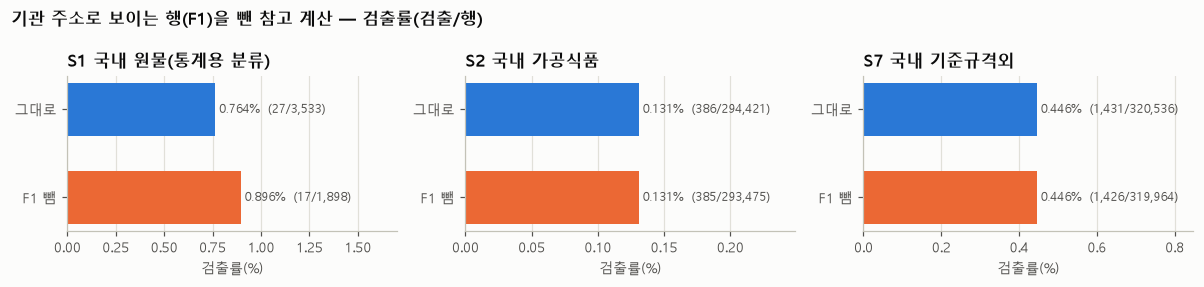

In [45]:
# [3-5-4-c] 그림: S1·S2·S7 검출률 그대로 vs F1 뺌 (막대 끝에 검출/행)
fig, axes = plt.subplots(1, 3, figsize=(11, 2.6))
for ax, (name, _) in zip(axes, IA_S):
    t = ia_t354.loc[name].loc[['그대로', 'F1 뺌']]
    y = np.arange(2)[::-1]
    ax.barh(y, t['검출률(%)'], height=0.6, color=[C1, C2])
    ax.set_yticks(y)
    ax.set_yticklabels(['그대로', 'F1 뺌'])
    ax.grid(axis='y', visible=False)
    vmax = float(t['검출률(%)'].max())
    for yi, (_, r) in zip(y, t.iterrows()):
        ax.text(r['검출률(%)'] + vmax * 0.02, yi, f"{r['검출률(%)']:.3f}%  ({r['남은 검출']:,}/{r['남은 행']:,})", va='center', ha='left', fontsize=8, color=INK2)
    ax.set_xlim(0, vmax * 1.9)
    ax.set_title({'S1': 'S1 국내 원물(통계용 분류)', 'S2': 'S2 국내 가공식품', 'S7': 'S7 국내 기준규격외'}[name.split(' ')[0]])
    ax.set_xlabel('검출률(%)')
fig.suptitle('기관 주소로 보이는 행(F1)을 뺀 참고 계산 — 검출률(검출/행)', x=0.01, ha='left', fontsize=11, fontweight='bold')
fig.tight_layout()
plt.show()
# 큰 중간 값 정리 (뒤 파트용 변수 inst_addr_flag·INST_ADDR_RULE·inst_addr_rules·qc_name_flag·QC_NAME_PAT·IA_OSONG_XY·ia_osong_str·ia_osong_xy 는 남김)
del ia_addr, ia_key, ia_uk, ia_hit, ia_src, _own, ia_ins, ia_ok, ia_tb, ia_nkey, ia_skey, _ua, _g, _lab, _keys_by_c, ia_te, ia_t352, ia_nm, ia_t354
del ia_a, ia_b1, ia_b2, ia_c, ia_d, ia_e, ia_f0, ia_f1, ia_firm, ia_dom, ia_pos, IA_S, _core, _cand, _reg, _nb, _os, _q, _qc2, _k1, _m, _f1, _f2

📊 **결과** (참고 계산, 범위 제안 아님)
- S1 국내 원물(통계용 분류): 3,533행·검출 27 (0.764%, 95% CI 0.526\~1.110) → F1 을 빼면 1,635행·검출 10 이 빠져 **1,898행·검출 17 (0.896%, 0.560\~1.430)**. 참고로 F0 를 빼면 2,193행·17 (0.775%), F2 를 빼면 1,884행·17 (0.902%).
- S2 국내 가공식품: F1 로 946행·검출 1 이 빠져 293,475행·385 (0.131%, 0.119\~0.145). F0(참고) 513행, F2(참고) 1,435행을 빼도 검출률 0.131%.
- S7 국내 기준규격외: F1 로 572행·검출 5 가 빠져 319,964행·1,426 (0.446%, 0.423\~0.469). F2(참고)는 1,159행을 빼고 319,377행·1,426 (0.446%).
- **F1 로 빠지는 검출의 제품명**: S1 10건은 팽이버섯 5·팽이버섯(버섯) 3·밤(탈피) 1·갈색팽이버섯 1(규칙 (q) 0건). S2 1건은 'CRM2'(규칙 (q) 1건). S7 5건은 QC 미생물 2·식중독균(정성) 1·축산물(미생물5번) 1·SA 5 1(규칙 (q) 4건). S2·S7 에서 빠지는 이 6건은 3-5-2 의 지방청 주소 검출 6건과 같은 제품명입니다.
- 5절 표 5-4-i 다시 세기: 국내 농산물(원물) ASOS avg_ta 당일 값 없음 319행 / 좌표 5곳, 가장 많은 좌표 (36.609188, 127.324562) 312행 → **오송 좌표와 같음 (True)**. 최근접 ASOS 는 서청주 (6.35km). 312행 모두 오송 주소 문자열 기준이고 F1 에 잡힘, 검출 6.
  - 312행의 기준 날짜는 모두 의뢰일이고 범위 2022-05-17 \~ 2022-11-23 인데, 서청주 일자료는 2023-05-01 \~ 2026-09-03 이라 **312행 모두 그 관측소 기간 밖**입니다.

💬 **첨언**
- 가공식품(S2)·기준규격외(S7)는 F1 행이 적어 검출률이 소수 셋째 자리까지 그대로입니다. 두 범위에서 F1 로 빠지는 검출 6건은 모두 지방청 주소의 숙련도·정도관리 시료로 보이는 행이라(3-5-2), 기상보다는 **라벨이 실제 오염을 뜻하는지**의 문제로 보입니다 (추정). F1 은 하한이지만 남은 후보(3-5-1) 1,061행도 검출 0 이라, 이 규칙들로 보는 한 S2·S7 의 검출률 영향은 작아 보입니다 (추정).
- S1 은 검출 27건 중 10건이 F1 행(모두 오송 주소 모니터링검사)입니다. F1 을 빼면 행이 1,898행으로 줄고 검출은 17건이 남습니다. 행은 두고 기상만 비우면 검출은 남지만 기상 값이 없는 행이 생깁니다. 어느 쪽이 맞는지는 이 자료로 정할 수 없어 전문가 질문으로 넘깁니다.
- F1 이 하한이라, S1 에서 기관 주소 행을 모두 뺀다면 남는 행은 1,898행보다 적을 수 있습니다(남은 후보 중 S1 95행) (추정).
- 5절의 312행 빈칸은 기관 주소로 보이는 오송 좌표에서 서청주가 최근접으로 골라졌고, 그 관측소 일자료가 2023-05-01 부터라서 생긴 것으로 보입니다 (추정). 5절 표의 '그 날 행 없음(기간 안)' 은 ASOS 파일 전체 기간을 기준으로 붙인 이름이라, 관측소별로 보면 '관측소 기간 밖'에 해당합니다. 같은 좌표의 나머지 농산물 행에는 서청주 값이 붙지만, 그 값도 생산지가 아니라 기관 주소 근처의 기상일 수 있습니다 (추정).
- 📌 뒤 파트용 변수 (dfx 에는 열을 넣지 않았습니다)
  - `inst_addr_flag`: F1 = (a)∪(b1)∪(d)∪(e), dfx 인덱스와 같은 bool Series, 5,882행 True. 기관 주소 행의 하한으로 봄.
  - `INST_ADDR_RULE`: 합친 규칙 설명 문자열(검출 16건 중 6건이 숙련도·정도관리 시료로 보이는 점 포함).
  - `inst_addr_rules`: 규칙 a·b1·b2·c·d·e 를 열로 둔 bool 표 (e 열은 (a)·(b1)·(d) 에 없는 행만).
  - `qc_name_flag`·`QC_NAME_PAT`: 규칙 (q) 제품명 bool Series(20행 True)와 정규식.
  - `IA_OSONG_XY`(오송 좌표), `ia_osong_str`·`ia_osong_xy`(오송 문자열·좌표 기준 numpy bool).

❓ **도메인 전문가께**: 기관 주소로 보이는 행(F1 5,882행 — 국내 농산물(원물) 1,618행·검출 10, 모니터링검사 1,057행·검출 10 포함)을 예측 범위에서 빼야 합니까, 아니면 검사 결과는 살리고 기상 피처만 비워야 합니까?
❓ **도메인 전문가께**: 생산지를 알 수 없는 모니터링·수거검사 원물 시료(예: 오송 주소 농산물 762행, 모두 모니터링검사)에 수거·의뢰 기관 소재지의 기상을 붙이는 것이 의미가 있다고 보십니까?

🗄️ **데이터 담당자께**: 정부 모니터링·수거검사 행에서 '업소주소' 칸에 수거 업소 대신 사업 기관(식약처·지방청·도청·시청·구청·보건소) 주소가 들어가는 경우가 있습니까? 있다면 어떤 검사목적·의뢰시스템에서 그렇습니까?
- 기관 이름 없이 도로명만 적힌 경우(예: '대전광역시 서구 둔산로 100' 743행, 모두 수거검사)와 부서 이름으로 적힌 경우(예: '광주광역시 서구 내방로 111 식품안전과' 699행, '강원도 춘천시 중앙로 1 식품의약과' 172행)도 같은 뜻입니까?
- 규칙에 안 잡힌 '전라남도 목포시 원산로45번길 5' 73행, '대전광역시 동구 동구청로 147' 49행 같은 주소도 기관 주소입니까?

🗄️ **데이터 담당자께**: 이 행들의 실제 수거 장소나 생산지(수거 업소 주소·인허가번호, 원산지 시군구 등)를 알 수 있는 컬럼이 LIMS 나 연계 시스템에 있습니까?

## 4. 시간 연결 — 가공식품에 어느 날짜로 기상을 붙일 수 있나 (메모 도메인1·도메인2)

🔎 기상 창을 만들려면 행마다 "끝 날짜"가 하나 있어야 합니다. 가공식품 행에 어떤 날짜가 얼마나 들어 있는지 **사실만** 셉니다.
- 국내 가공식품은 학습용 품목명(`train_prdlst_nm`) 행 수 상위 12개로 나누고, 비교용으로 국내 원물(통계용 분류)·국내 기준규격외(Z 코드)를 같이 봅니다.
- 날짜는 원본 제조일(`mnfctur_de_raw`)·의뢰일(`reqest_de`)을 따로 봅니다. 기준일(`mnfctur_de`)은 세 날짜가 섞여 있어 직접 쓰지 않습니다 (2.ipynb 4장).
- 어느 날짜(시점)가 오염과 이어지는지는 판단하지 않고, 전문가 질문으로 넘깁니다.

### 4-1. 그룹별 규모와 원본 제조일 채움 — 원본 제조일이 있는 행과 없는 행의 검출률

🔎 그룹마다 행 수, 원본 제조일이 있는 비율, `date_basis`(기준일 출처) 분포, 검출 수를 봅니다. 원본 제조일이 있는 행만 쓰면 검출이 얼마나 남는지도 봅니다.
- 그룹 나누기(상위 12개 + 그 외)는 **작성자 임의 방법**입니다.

In [46]:
# [4-1] 국내 가공식품 품목명 상위 12개 + 그 외 + 국내 원물 + 국내 기준규격외: 규모, 원본 제조일 채움, date_basis 분포, 제조일 유무별 검출률
# 작성자 임의 방법: 그룹 = 국내 가공식품의 train_prdlst_nm 행 수 상위 12개 / 나머지 품목 / 원물(통계용 분류) 3종 합침 / 기준규격외(Z)
dom4 = dfx['국내해외'].eq('국내')
RAW_CLS4 = ['농산물(원물)', '축산물(원물)', '수산물(원물)']
m4 = dom4 & dfx['대분류'].isin(['가공식품', '기준규격외(검체)'] + RAW_CLS4)
t4 = dfx.loc[m4, ['pos', '대분류', 'train_prdlst_nm', 'date_basis', 'mnfctur_de_raw', 'reqest_de']].copy()   # 필요한 열만
t4['train_prdlst_nm'] = t4['train_prdlst_nm'].astype('string')
print(f"대상: 국내 {int(dom4.sum()):,}행 중 가공식품·원물·기준규격외 {len(t4):,}행 (뺀 국내 행 {int(dom4.sum()) - len(t4):,} = 기타(접객·건기식·첨가물))")

is_proc4 = t4['대분류'].eq('가공식품')
print(f"국내 가공식품 중 train_prdlst_nm 결측: {int(t4.loc[is_proc4, 'train_prdlst_nm'].isna().sum()):,}행 (결측이면 '그 외 품목'에 들어감)")
top12 = t4.loc[is_proc4, 'train_prdlst_nm'].value_counts().head(12).index.tolist()
t4['grp4'] = np.where(is_proc4 & t4['train_prdlst_nm'].isin(top12).fillna(False).to_numpy(dtype=bool),
                      '가공: ' + t4['train_prdlst_nm'].astype(str),
                      np.where(is_proc4, '가공: 그 외 품목', np.where(t4['대분류'].isin(RAW_CLS4), '원물(통계용 분류)', '기준규격외(Z 코드)')))
G4_ORDER = ['가공: ' + x for x in top12] + ['가공: 그 외 품목', '국내 가공식품 전체', '원물(통계용 분류)', '기준규격외(Z 코드)']


def by_grp4(frame, f):
    '''grp4 그룹별로 f(부분표)→dict 를 계산하고, '국내 가공식품 전체' 행을 더해 G4_ORDER 순서로 돌려줌'''
    rows = {g: f(sub) for g, sub in frame.groupby('grp4', observed=True)}
    rows['국내 가공식품 전체'] = f(frame[frame['대분류'].eq('가공식품')])
    out = pd.DataFrame.from_dict(rows, orient='index')
    return out.reindex([g for g in G4_ORDER if g in out.index])


def s41(sub):
    n, k = len(sub), int(sub['pos'].sum())
    db = sub['date_basis'].astype(str)
    return {'행 수': n, '검출': k, '검출률(%)': round(k / n * 100, 3),
            '원본 제조일 있음(%)': round(sub['mnfctur_de_raw'].notna().mean() * 100, 1),
            'date_basis 제조일(%)': round(db.eq('제조일').mean() * 100, 1),
            'date_basis 의뢰일(%)': round(db.eq('의뢰일').mean() * 100, 1),
            'date_basis 선적일(행)': int(db.eq('선적일').sum())}


def s41b(sub):
    has = sub['mnfctur_de_raw'].notna()
    n1, k1 = int(has.sum()), int(sub.loc[has, 'pos'].sum())
    n0, k0 = int((~has).sum()), int(sub.loc[~has, 'pos'].sum())
    lo1, hi1 = wilson(k1, n1) if n1 else (np.nan, np.nan)
    lo0, hi0 = wilson(k0, n0) if n0 else (np.nan, np.nan)
    return {'제조일 있음 행': n1, '제조일 있음 검출': k1, '제조일 있음 검출률(%)': round(k1 / n1 * 100, 3) if n1 else np.nan,
            '있음 95%구간(%)': f'{float(lo1):.2f}~{float(hi1):.2f}' if n1 else '-',
            '제조일 없음 행': n0, '제조일 없음 검출': k0, '제조일 없음 검출률(%)': round(k0 / n0 * 100, 3) if n0 else np.nan,
            '없음 95%구간(%)': f'{float(lo0):.2f}~{float(hi0):.2f}' if n0 else '-',
            '제조일 있는 행에 남는 검출(%)': round(k1 / (k1 + k0) * 100, 1) if (k1 + k0) else np.nan}


# 참고 점검: date_basis=제조일 과 원본 제조일 있음이 같은 행인지
print('원본 제조일 유무 × date_basis (대상 행):')
print(pd.crosstab(t4['mnfctur_de_raw'].notna().map({True: '원본 제조일 있음', False: '원본 제조일 없음'}), t4['date_basis'].astype(str)))

t41 = by_grp4(t4, s41)
t41b = by_grp4(t4, s41b)
display(t41)
t41b

대상: 국내 628,895행 중 가공식품·원물·기준규격외 618,490행 (뺀 국내 행 10,405 = 기타(접객·건기식·첨가물))
국내 가공식품 중 train_prdlst_nm 결측: 0행 (결측이면 '그 외 품목'에 들어감)
원본 제조일 유무 × date_basis (대상 행):
date_basis      선적일     의뢰일     제조일
mnfctur_de_raw                     
원본 제조일 없음         9  329351       0
원본 제조일 있음         0       0  289130


,행 수,검출,검출률(%),원본 제조일 있음(%),date_basis 제조일(%),date_basis 의뢰일(%),date_basis 선적일(행)
가공: 식육가공품 및 포장육,95216,294,0.309,76.2,76.2,23.8,0
가공: 유가공품류,78292,6,0.008,70.0,70.0,30.0,0
가공: 즉석식품류,35322,45,0.127,91.4,91.4,8.6,0
가공: 알가공품류,28465,0,0.000,74.3,74.3,25.7,0
가공: 빙과류,19816,0,0.000,92.9,92.9,7.1,0
가공: 기타식품류,7381,9,0.122,77.1,77.1,22.9,0
가공: 음료류,6279,1,0.016,55.9,55.9,44.1,0
가공: 수산가공식품류,4637,29,0.625,52.9,52.9,47.1,0
가공: 조미식품,4165,0,0.000,78.7,78.7,21.3,0
"가공: 과자류, 빵류 또는 떡류",3919,1,0.026,56.2,56.2,43.8,0


,제조일 있음 행,제조일 있음 검출,제조일 있음 검출률(%),있음 95%구간(%),제조일 없음 행,제조일 없음 검출,제조일 없음 검출률(%),없음 95%구간(%),제조일 있는 행에 남는 검출(%)
가공: 식육가공품 및 포장육,72518,224,0.309,0.27~0.35,22698,70,0.308,0.24~0.39,76.2
가공: 유가공품류,54813,4,0.007,0.00~0.02,23479,2,0.009,0.00~0.03,66.7
가공: 즉석식품류,32274,35,0.108,0.08~0.15,3048,10,0.328,0.18~0.60,77.8
가공: 알가공품류,21152,0,0.000,0.00~0.02,7313,0,0.000,0.00~0.05,NaN
가공: 빙과류,18407,0,0.000,0.00~0.02,1409,0,0.000,0.00~0.27,NaN
가공: 기타식품류,5688,4,0.070,0.03~0.18,1693,5,0.295,0.13~0.69,44.4
가공: 음료류,3508,0,0.000,0.00~0.11,2771,1,0.036,0.01~0.20,0.0
가공: 수산가공식품류,2455,19,0.774,0.50~1.21,2182,10,0.458,0.25~0.84,65.5
가공: 조미식품,3277,0,0.000,0.00~0.12,888,0,0.000,0.00~0.43,NaN
"가공: 과자류, 빵류 또는 떡류",2203,1,0.045,0.01~0.26,1716,0,0.000,0.00~0.22,100.0


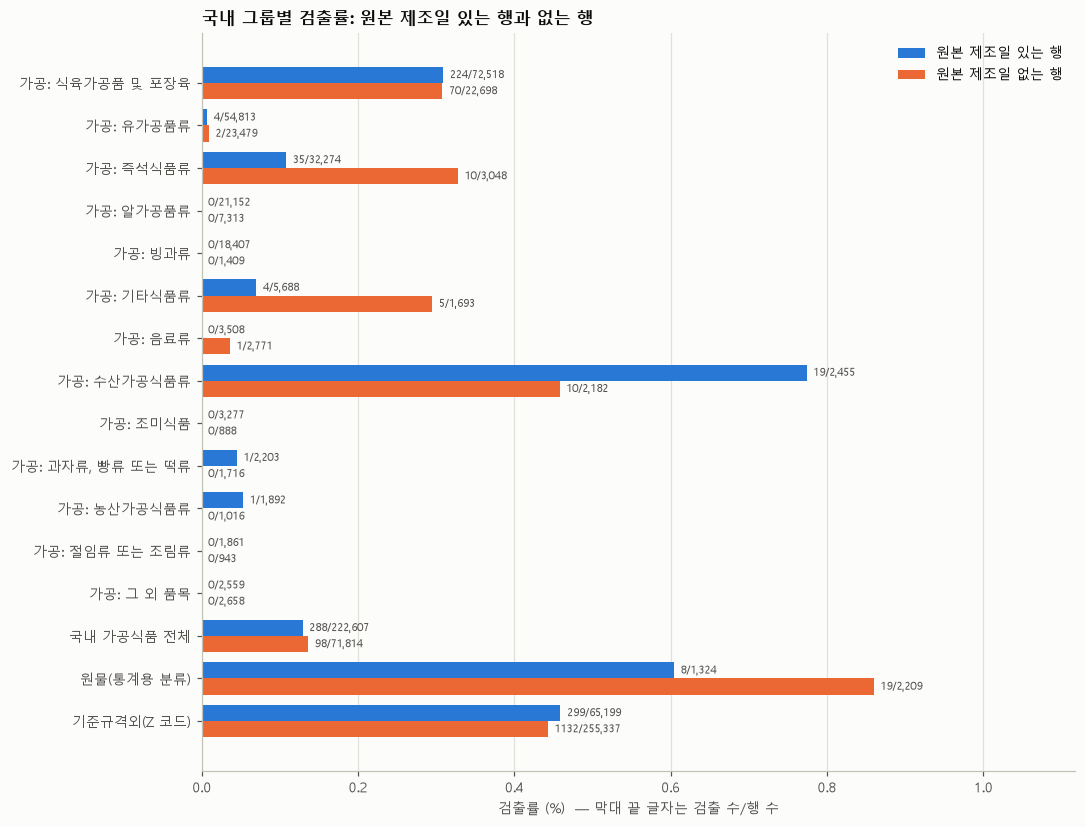

In [47]:
# [4-1 그림] 그룹별 원본 제조일 있는 행 / 없는 행의 검출률 (막대 끝 = 검출/행)
tb = t41b
yy = np.arange(len(tb))[::-1]
h = 0.38
r1 = tb['제조일 있음 검출률(%)'].to_numpy(dtype=float)
r0 = tb['제조일 없음 검출률(%)'].to_numpy(dtype=float)
vmax = np.nanmax(np.r_[r1, r0])
fig, ax = plt.subplots(figsize=(10, 7.6))
ax.barh(yy + h / 2, np.nan_to_num(r1), height=h, color=C1, label='원본 제조일 있는 행')
ax.barh(yy - h / 2, np.nan_to_num(r0), height=h, color=C2, label='원본 제조일 없는 행')
for yi, v, k, n in zip(yy + h / 2, r1, tb['제조일 있음 검출'], tb['제조일 있음 행']):
    ax.text((0 if np.isnan(v) else v) + vmax * 0.01, yi, f'{k}/{n:,}' if n else '행 없음', va='center', fontsize=7, color=INK2)
for yi, v, k, n in zip(yy - h / 2, r0, tb['제조일 없음 검출'], tb['제조일 없음 행']):
    ax.text((0 if np.isnan(v) else v) + vmax * 0.01, yi, f'{k}/{n:,}' if n else '행 없음', va='center', fontsize=7, color=INK2)
ax.set_yticks(yy)
ax.set_yticklabels(tb.index)
ax.grid(axis='y', visible=False)
ax.set_xlim(0, vmax * 1.3)
ax.set_xlabel('검출률 (%)  — 막대 끝 글자는 검출 수/행 수')
ax.set_title('국내 그룹별 검출률: 원본 제조일 있는 행과 없는 행')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [48]:
# [4-1 보충] 원본 제조일이 있는 행과 없는 행은 검사목적 구성이 같은가 (국내 가공식품 전체, 즉석식품류)
# + 여러 그룹을 비교했을 때 95% 구간이 안 겹친 그룹은 몇 개인가 + 즉석식품류 제조일 없는 검출 행의 모습
# 업체 식별 규칙(작성자 임의, 1-2 ⑥ 과 같음): 영업허가번호 → 제조회사명 → '식별 불가'. 빈 글자는 없는 것으로 봄 (라벨만 붙이고 값은 채우지 않음)
p41 = dfx.loc[m4 & dfx['대분류'].eq('가공식품'),
              ['pos', 'train_prdlst_nm', 'mnfctur_de_raw', 'reqest_de', '검사목적', '검체성격(임의)', 'bsn_lcns_ledg_no', 'mnfctur_cmpny_nm', 'prduct_nm']]
p41 = p41.assign(제조일=np.where(p41['mnfctur_de_raw'].notna(), '있음', '없음'))


def purpose_mix(frame):
    '''검사목적별: 제조일 있음/없음 각각의 행 수, 그 안의 행 비율(%), 검출 수, 검출률(%)'''
    n = pd.crosstab(frame['검사목적'], frame['제조일']).reindex(columns=['있음', '없음'], fill_value=0)   # 없는 조합 = 0행 (세기 결과)
    fp = frame[frame['pos'].eq(1)]
    k = pd.crosstab(fp['검사목적'], fp['제조일']).reindex(index=n.index, columns=['있음', '없음'], fill_value=0)   # 검출 없는 조합 = 0건 (세기 결과)
    out = pd.DataFrame({
        '있음 행': n['있음'], '있음 행 비율(%)': (n['있음'] / n['있음'].sum() * 100).round(1),
        '있음 검출': k['있음'], '있음 검출률(%)': (k['있음'] / n['있음'] * 100).round(3),
        '없음 행': n['없음'], '없음 행 비율(%)': (n['없음'] / n['없음'].sum() * 100).round(1),
        '없음 검출': k['없음'], '없음 검출률(%)': (k['없음'] / n['없음'] * 100).round(3)})   # 행이 0인 칸의 검출률은 NaN 그대로
    return out.sort_values('없음 행', ascending=False)


print('[표] 국내 가공식품 전체: 원본 제조일 있음/없음 × 검사목적')
display(purpose_mix(p41))
ins41 = p41[p41['train_prdlst_nm'].astype(str).eq('즉석식품류')]
print('[표] 즉석식품류: 원본 제조일 있음/없음 × 검사목적')
display(purpose_mix(ins41))
print('즉석식품류 검체성격(임의) 구성(%):',
      pd.crosstab(ins41['검체성격(임의)'], ins41['제조일'], normalize='columns').mul(100).round(1).reindex(columns=['있음', '없음']).to_dict('index'))


# 다중 비교 점검: 4-1 표의 각 행에서 제조일 있음/없음 Wilson 95% 구간이 겹치지 않는 행
def s41c(sub):
    has = sub['mnfctur_de_raw'].notna()
    n1, k1, n0, k0 = int(has.sum()), int(sub.loc[has, 'pos'].sum()), int((~has).sum()), int(sub.loc[~has, 'pos'].sum())
    if not (n1 and n0):
        return {'비교': False, '안 겹침': False}
    lo1, hi1 = wilson(k1, n1)
    lo0, hi0 = wilson(k0, n0)
    return {'비교': True, '안 겹침': bool(hi1 < lo0 or hi0 < lo1)}


c41 = by_grp4(t4, s41c)
print(f"제조일 있음/없음 구간을 비교한 행 {int(c41['비교'].sum())}개(그룹별 + 국내 가공식품 전체) 중 구간이 겹치지 않는 행: {c41.index[c41['안 겹침']].tolist()}")

# 즉석식품류 검출 행: 제조일 없음 / 있음 — 업체 식별, 검사목적, 의뢰일 몰림
def firm_of(frame):
    lic = frame['bsn_lcns_ledg_no'].astype('string').str.strip()
    nm = frame['mnfctur_cmpny_nm'].astype('string').str.strip()
    has_lic, has_nm = lic.notna() & lic.ne(''), nm.notna() & nm.ne('')
    return ('L:' + lic).where(has_lic, ('N:' + nm).where(has_nm, '식별 불가'))


for s in ['없음', '있음']:
    q = ins41[ins41['제조일'].eq(s) & ins41['pos'].eq(1)]
    f = firm_of(q)
    rq = q['reqest_de'].value_counts()
    print(f"즉석식품류 제조일 {s} 검출 {len(q)}건: 검사목적 {q['검사목적'].value_counts().to_dict()}, 업체 식별 불가 {int(f.eq('식별 불가').sum())}건, "
          f"식별된 업체 {f[f.ne('식별 불가')].nunique()}곳, 의뢰일 고유 {q['reqest_de'].nunique()}일, 같은 의뢰일 2건 이상: "
          f"{ {d.strftime('%Y-%m-%d'): int(c) for d, c in rq[rq >= 2].items()} }")
q0 = ins41[ins41['제조일'].eq('없음') & ins41['pos'].eq(1)]
q0.assign(업체식별=firm_of(q0).where(firm_of(q0).eq('식별 불가'), '식별됨'))[['검사목적', '업체식별', '검체성격(임의)', 'reqest_de', 'prduct_nm']].sort_values('reqest_de')

[표] 국내 가공식품 전체: 원본 제조일 있음/없음 × 검사목적


,있음 행,있음 행 비율(%),있음 검출,있음 검출률(%),없음 행,없음 행 비율(%),없음 검출,없음 검출률(%)
검사목적,,,,,,,,
자가품질위탁검사,162605,73.0,104,0.064,34972,48.7,23,0.066
수거검사,7644,3.4,33,0.432,20585,28.7,23,0.112
기타,19650,8.8,136,0.692,11976,16.7,52,0.434
품질검사,26850,12.1,0,0.000,3287,4.6,0,0.000
식품안전관리인증검사,1671,0.8,15,0.898,829,1.2,0,0.000
자가품질직접검사(영업자),4169,1.9,0,0.000,117,0.2,0,0.000
모니터링검사,11,0.0,0,0.000,38,0.1,0,0.000
수입검사,1,0.0,0,0.000,10,0.0,0,0.000
품목제조.가공검사,2,0.0,0,0.000,0,0.0,0,NaN


[표] 즉석식품류: 원본 제조일 있음/없음 × 검사목적


,있음 행,있음 행 비율(%),있음 검출,있음 검출률(%),없음 행,없음 행 비율(%),없음 검출,없음 검출률(%)
검사목적,,,,,,,,
자가품질위탁검사,25208,78.1,32,0.127,1465,48.1,1,0.068
품질검사,3889,12.0,0,0.000,709,23.3,0,0.000
기타,2095,6.5,1,0.048,560,18.4,9,1.607
수거검사,258,0.8,2,0.775,248,8.1,0,0.000
자가품질직접검사(영업자),814,2.5,0,0.000,60,2.0,0,0.000
식품안전관리인증검사,9,0.0,0,0.000,6,0.2,0,0.000
수입검사,1,0.0,0,0.000,0,0.0,0,NaN


즉석식품류 검체성격(임의) 구성(%): {'공정시료': {'있음': 0.4, '없음': 1.9}, '완제품표기': {'있음': 0.0, '없음': 0.2}, '일반 제품명': {'있음': 99.6, '없음': 97.9}, '팽이버섯': {'있음': 0.0, '없음': 0.0}, '환경검체': {'있음': 0.0, '없음': 0.0}}
제조일 있음/없음 구간을 비교한 행 16개(그룹별 + 국내 가공식품 전체) 중 구간이 겹치지 않는 행: ['가공: 즉석식품류']
즉석식품류 제조일 없음 검출 10건: 검사목적 {'기타': 9, '자가품질위탁검사': 1}, 업체 식별 불가 9건, 식별된 업체 1곳, 의뢰일 고유 9일, 같은 의뢰일 2건 이상: {'2022-04-05': 2}
즉석식품류 제조일 있음 검출 35건: 검사목적 {'자가품질위탁검사': 32, '수거검사': 2, '기타': 1}, 업체 식별 불가 18건, 식별된 업체 15곳, 의뢰일 고유 33일, 같은 의뢰일 2건 이상: {'2025-03-24': 2, '2019-11-27': 2}


,검사목적,업체식별,검체성격(임의),reqest_de,prduct_nm
458348,기타,식별 불가,일반 제품명,2019-01-29,하카타 명란 파스타
13240,기타,식별 불가,일반 제품명,2021-05-21,전골부대찌개-햄소시지 소독 후 1차
292367,기타,식별 불가,일반 제품명,2022-04-05,A
540873,기타,식별 불가,일반 제품명,2022-04-05,H
312466,기타,식별 불가,일반 제품명,2022-04-11,바비큐 치킨&치즈 치아바타
5657,기타,식별 불가,일반 제품명,2023-05-31,맛있는 우삼겹 김치찌개
413849,기타,식별 불가,일반 제품명,2023-11-30,오삼불고기(CK)
394378,기타,식별 불가,일반 제품명,2024-04-02,VIVID KITCHEN 밥없는 저당 닭가슴살 도시락 숯불매콤
613736,자가품질위탁검사,식별됨,일반 제품명,2025-02-06,나물3종
327483,기타,식별 불가,일반 제품명,2026-04-15,참치마요김밥


📊 **결과**
- 대상은 국내 618,490행입니다 (뺀 국내 행 10,405 = 기타(접객·건기식·첨가물)).
- 원본 제조일이 있는 행과 `date_basis=제조일` 행은 같은 행입니다 (있음 289,130행 전부 제조일, 없음 행은 의뢰일 329,351 + 선적일 9).
- **국내 가공식품 전체** 294,421행·검출 386 (0.131%). 원본 제조일 있음 75.6%. 품목별로는 즉석식품류 91.4%·빙과류 92.9% 가 높고, 수산가공식품류 52.9%·음료류 55.9% 가 낮습니다.
- 비교 그룹: **원물(통계용 분류)** 3,533행·검출 27, 원본 제조일 있음 37.5% / **기준규격외(Z 코드)** 320,536행·검출 1,431, 원본 제조일 있음 20.3%.
- 원본 제조일이 있는 행만 남기면 남는 검출 비율: 국내 가공식품 74.6% (288/386), 원물 29.6% (8/27), 기준규격외 20.9% (299/1,431).
- 제조일 유무별 검출률: 국내 가공식품 전체 0.129% (95%구간 0.12\~0.15) vs 0.136% (0.11\~0.17). 식육가공품 및 포장육 0.309% vs 0.308%. 즉석식품류는 0.108% (0.08\~0.15) vs 0.328% (0.18\~0.60).
- 구간을 비교한 16개 행(그룹별 + 국내 가공식품 전체) 중 구간이 겹치지 않는 행은 즉석식품류 하나입니다.
- **제조일 있는 행과 없는 행은 검사목적 구성이 다릅니다** (국내 가공식품, 행 비율): 수거검사 3.4% vs 28.7%, 기타 8.8% vs 16.7%, 자가품질위탁검사 73.0% vs 48.7%, 품질검사 12.1% vs 4.6%.
  - 같은 검사목적 안에서 검출률(있음 vs 없음): 수거검사 0.432% (33/7,644) vs 0.112% (23/20,585), 기타 0.692% (136/19,650) vs 0.434% (52/11,976), 자가품질위탁검사 0.064% (104/162,605) vs 0.066% (23/34,972).
- 즉석식품류도 구성이 다릅니다 (있음 vs 없음): 기타 6.5% vs 18.4%, 수거검사 0.8% vs 8.1%, 자가품질위탁검사 78.1% vs 48.1%. 검체성격(임의) '공정시료'는 0.4% vs 1.9% 입니다.
- 즉석식품류 제조일 없는 검출 10건: 검사목적 기타 9 + 자가품질위탁검사 1, 업체 식별 불가 9건, 의뢰일 고유 9일 (2022-04-05 에 2건, 제품명 'A'·'H'). 즉석식품류 중 검사목적 기타·제조일 없는 행의 검출률은 1.607% (9/560) 입니다. 비교로 제조일 있는 검출 35건은 자가품질위탁검사 32건, 의뢰일 고유 33일입니다.

💬 **첨언**
- 작성자가 임의로 나눠 본 결과, 국내 가공식품은 4행 중 3행꼴로 원본 제조일이 있어 "제조일 기준 창"을 만들 수 있는 행이 많아 보입니다. 반대로 검출이 몰린 기준규격외·원물은 원본 제조일이 있는 행이 20\~40% 수준이라, 날짜를 쓴다면 의뢰일에 기대는 행이 많을 것으로 보입니다 (추정).
- 국내 가공식품 전체로는 제조일 유무에 따른 검출률 구간이 겹칩니다. 그러나 두 집단은 검사목적 구성이 달라, 전체 검출률이 비슷한 것은 구성 차이가 서로 상쇄된 결과일 수 있습니다 (추정). 검사목적을 같게 놓고 보면 수거검사·기타에서는 제조일 있는 행의 검출률이 더 높았습니다.
- 그래서 "제조일 있는 행"으로 범위를 좁히면 수거검사 행(제조일 없는 행의 28.7%)이 많이 빠지는 등 **표본 구성이 바뀝니다**. 이 트레이드오프는 타깃 범위 결정 때 전문가 질문으로 넘깁니다 (4-4 ❓).
- 즉석식품류의 차이는 해석을 조심해야 할 것으로 보입니다 (추정). ① 16개 행을 비교해 하나만 구간이 안 겹친 것이고, 제조일 없는 검출이 10건뿐이라 우연일 수 있습니다. ② 10건 중 9건이 검사목적 '기타'·업체 식별 불가이고, 같은 날 의뢰된 2건('A'·'H')은 한 의뢰 묶음일 수 있습니다. ③ 제조일이 비어 있는 행에 원료·반제품이 섞였을 가능성도 있으나, 제품명 기준 '공정시료'는 1.9% 뿐이라 이것만으로 설명하기는 어려워 보입니다 (🗄️ 질문은 4-4).

### 4-2. 원본 제조일이 있는 행: 제조 → 의뢰 간격

🔎 원본 제조일이 있는 행에서 의뢰일 − 제조일(일)을 그룹별로 봅니다. 간격이 짧으면 제조일과 의뢰일 중 어느 쪽으로 창을 만들어도 겹치는 날이 많습니다.
- 분위수는 pandas 기본(선형 보간)입니다. `간격 0~6일(%)` 은 "의뢰일 기준 7일 창 안에 제조일이 들어가는 비율"로 **작성자가 임의로 고른 구간**입니다.
- 보충 표: 두 창이 실제로 며칠 겹치는지 = max(0, 창 길이 − |간격|). 창 규칙(7일·30일, 7절과 같음)은 **작성자 임의 방법**입니다.

In [49]:
# [4-2] 원본 제조일 있는 행의 의뢰일 − 원본 제조일 (일) 분포, 그룹별
# 작성자 임의 방법: 0~6일 구간(7일 창 규칙과 맞춤), 30일 이상 구간
g42 = t4[t4['mnfctur_de_raw'].notna()]
n_no_req = int(g42['reqest_de'].isna().sum())
print(f"원본 제조일 있는 대상 행 {len(g42):,} 중 의뢰일 결측으로 뺀 행: {n_no_req:,}")
g42 = g42[g42['reqest_de'].notna()].assign(간격=lambda d: (d['reqest_de'] - d['mnfctur_de_raw']).dt.days)


def s42(sub):
    d = sub['간격']
    dp = d[sub['pos'].eq(1)]
    return {'행 수': len(d), '중앙값(일)': d.median(), 'p75(일)': d.quantile(.75), 'p95(일)': d.quantile(.95),
            '음수 비율(%)': round((d < 0).mean() * 100, 2), '간격 0~6일(%)': round(d.between(0, 6).mean() * 100, 1),
            '30일 이상(%)': round((d >= 30).mean() * 100, 1),
            '검출 행 수': len(dp), '검출 행 간격 중앙값(일)': dp.median() if len(dp) else np.nan}


t42 = by_grp4(g42, s42)
g42p = g42[g42['대분류'].eq('가공식품')]
print(f"음수 간격(의뢰일이 제조일보다 앞섬): 대상 국내 행(가공식품·원물·기준규격외) 전체 {int((g42['간격'] < 0).sum()):,}행 (그중 국내 가공식품 {int((g42p['간격'] < 0).sum()):,}행), "
      f"최솟값 {int(g42['간격'].min())}일 / 최댓값 {int(g42['간격'].max()):,}일")
display(t42)


# [4-2 보충] 제조일 창과 의뢰일 창이 실제로 며칠 겹치나
# 창 규칙(작성자 임의, 7절과 같음): W일 창 = 기준 날짜 (W-1)일 전 ~ 당일. 두 창의 겹치는 날 수 = max(0, W − |의뢰일 − 제조일|)
def s42b(sub):
    a = sub['간격'].abs()
    return {'행 수': len(a),
            '7일 창 7일 모두 겹침(%) [간격 0]': round(a.eq(0).mean() * 100, 1),
            '4~6일 겹침(%) [|간격| 1~3]': round(a.between(1, 3).mean() * 100, 1),
            '1~3일 겹침(%) [|간격| 4~6]': round(a.between(4, 6).mean() * 100, 1),
            '안 겹침(%) [|간격| 7 이상]': round(a.ge(7).mean() * 100, 1),
            '30일 창 15일 이상 겹침(%) [|간격| ≤15]': round(a.le(15).mean() * 100, 1),
            '30일 창 1~14일 겹침(%) [|간격| 16~29]': round(a.between(16, 29).mean() * 100, 1),
            '30일 창 안 겹침(%) [|간격| 30 이상]': round(a.ge(30).mean() * 100, 1)}


t42b = by_grp4(g42, s42b)
a42 = g42p['간격'].abs()
print(f"국내 가공식품: 두 7일 창이 4일 이상 겹치는 행 {a42.le(3).mean():.1%}, 7일 모두 겹치는 행 {a42.eq(0).mean():.1%}, 전혀 안 겹치는 행 {a42.ge(7).mean():.1%} "
      f"/ 의뢰일 기준 7일 창 안에 제조일이 들어가는 행(간격 0~6일) {g42p['간격'].between(0, 6).mean():.1%}")
t42b

원본 제조일 있는 대상 행 289,130 중 의뢰일 결측으로 뺀 행: 0
음수 간격(의뢰일이 제조일보다 앞섬): 대상 국내 행(가공식품·원물·기준규격외) 전체 1,376행 (그중 국내 가공식품 1,332행), 최솟값 -700일 / 최댓값 1,685일


,행 수,중앙값(일),p75(일),p95(일),음수 비율(%),간격 0~6일(%),30일 이상(%),검출 행 수,검출 행 간격 중앙값(일)
가공: 식육가공품 및 포장육,72518,3.0,7.0,22.00,0.22,72.7,2.5,224,1.0
가공: 유가공품류,54813,3.0,8.0,27.00,0.57,67.8,3.9,4,0.5
가공: 즉석식품류,32274,0.0,0.0,4.00,0.45,96.0,0.5,35,0.0
가공: 알가공품류,21152,1.0,4.0,14.00,1.38,83.4,1.2,0,NaN
가공: 빙과류,18407,5.0,13.0,44.00,2.06,55.7,7.7,0,NaN
가공: 기타식품류,5688,0.0,3.0,37.00,0.21,81.3,6.3,4,0.5
가공: 음료류,3508,5.0,14.0,80.65,0.06,56.1,12.7,0,NaN
가공: 수산가공식품류,2455,1.0,6.0,43.00,0.20,75.6,7.4,19,0.0
가공: 조미식품,3277,7.0,16.0,51.00,0.06,49.5,10.3,0,NaN
"가공: 과자류, 빵류 또는 떡류",2203,1.0,7.0,40.90,0.09,74.5,7.3,1,6.0


국내 가공식품: 두 7일 창이 4일 이상 겹치는 행 60.4%, 7일 모두 겹치는 행 33.2%, 전혀 안 겹치는 행 25.9% / 의뢰일 기준 7일 창 안에 제조일이 들어가는 행(간격 0~6일) 73.6%


,행 수,7일 창 7일 모두 겹침(%) [간격 0],4~6일 겹침(%) [|간격| 1~3],1~3일 겹침(%) [|간격| 4~6],안 겹침(%) [|간격| 7 이상],30일 창 15일 이상 겹침(%) [|간격| ≤15],30일 창 1~14일 겹침(%) [|간격| 16~29],30일 창 안 겹침(%) [|간격| 30 이상]
가공: 식육가공품 및 포장육,72518,28.0,28.6,16.2,27.2,90.3,7.1,2.5
가공: 유가공품류,54813,19.4,32.1,16.8,31.8,86.4,9.6,4.0
가공: 즉석식품류,32274,80.7,13.3,2.3,3.7,98.5,1.0,0.5
가공: 알가공품류,21152,30.0,40.0,14.7,15.3,95.8,2.9,1.2
가공: 빙과류,18407,22.3,19.8,15.3,42.6,79.1,13.2,7.7
가공: 기타식품류,5688,60.5,15.3,5.7,18.5,88.9,4.7,6.4
가공: 음료류,3508,9.8,29.1,17.2,43.8,76.9,10.4,12.7
가공: 수산가공식품류,2455,29.5,33.9,12.3,24.3,87.6,4.8,7.5
가공: 조미식품,3277,11.9,22.6,15.0,50.5,73.6,16.0,10.3
"가공: 과자류, 빵류 또는 떡류",2203,28.3,33.9,12.5,25.4,87.6,5.2,7.3


📊 **결과**
- 원본 제조일이 있는 대상 행 289,130 중 의뢰일 결측으로 뺀 행은 0 입니다.
- **국내 가공식품 전체**: 의뢰일 − 제조일 중앙값 2.0일, p75 7.0일, p95 26.00일, 음수 0.60%. 간격 0\~6일 73.6%, 30일 이상 3.8%. 검출 행(288) 간격 중앙값 1.0일.
- 품목별: 즉석식품류 중앙값 0.0·p95 4.00·0\~6일 96.0% / 식육가공품 및 포장육 3.0·22.00·72.7% / 유가공품류 3.0·27.00·67.8% / 빙과류 5.0·44.00·55.7% / 농산가공식품류 7.0·199.80·44.5%.
- 비교: 원물(통계용 분류) 중앙값 1.0·p95 201.70·30일 이상 23.4% / 기준규격외(Z 코드) 3.0·155.00·30일 이상 14.8%.
- 음수 간격(의뢰일이 제조일보다 앞섬)은 대상 국내 행(가공식품·원물·기준규격외) 전체 1,376행 (그중 국내 가공식품 1,332행), 최솟값 -700일 / 최댓값 1,685일입니다.
- **두 창이 겹치는 날 수** (국내 가공식품 전체): 7일 창이 7일 모두 겹침(간격 0) 33.2%, 4\~6일 겹침 27.2%, 1\~3일 겹침 13.6%, 안 겹침 25.9%. 4일 이상 겹치는 행은 60.4% 입니다. 30일 창은 15일 이상 겹침 89.1%, 안 겹침 3.8%.
- 품목별 7일 창 7일 모두 겹침 / 안 겹침: 즉석식품류 80.7% / 3.7%, 식육가공품 및 포장육 28.0% / 27.2%, 유가공품류 19.4% / 31.8%, 빙과류 22.3% / 42.6%, 농산가공식품류 7.3% / 55.4%.

💬 **첨언**
- 의뢰일 기준 7일 창 안에 제조일이 들어가는 행은 73.6% 이지만, 이는 두 창이 **하루 이상** 겹친다는 뜻일 뿐입니다. 두 7일 창이 7일 모두 겹치는 행은 33.2%, 전혀 안 겹치는 행은 25.9% 여서, 7일 창에서는 제조일 기준과 의뢰일 기준이 서로 다른 기상값을 줄 수 있는 행이 적지 않아 보입니다 (추정).
- 30일 창으로 넓히면 15일 이상 겹치는 행이 89.1% 라, 창이 길수록 두 기준의 차이는 줄어들 것으로 보입니다 (추정). 창 길이 선택은 전문가 질문으로 넘깁니다 (4-4 ❓2).
- 즉석식품류는 7일 모두 겹침이 80.7% 라 두 기준 차이가 작아 보이고, 빙과류·조미식품·농산가공식품류처럼 간격이 긴 품목은 의뢰일 창이 제조 시점과 떨어질 수 있습니다 (추정).
- 음수 간격과 최댓값 1,685일 같은 긴 간격은 입력 오류일 수도, 다른 날짜가 들어간 것일 수도 있습니다. 이 노트북은 고치지 않고 그대로 셉니다 (🗄️ 질문은 4-4).

### 4-3. 품목제조대장 유통기한 — 그룹별 연결률과 유통기한 일수

🔎 2.ipynb 4-4절과 같은 방법으로 품목제조대장을 붙입니다. 유통기한이 짧으면 의뢰일이 제조일에서 멀지 않을 수 있어, 유통기한이 날짜 공백을 가늠하는 단서가 될 수 있는지 보려는 것입니다.
- 연결: `prdlst_mnfctur_sttemnt_no` 원문 → 없으면 숫자만 남긴 값 → 대장 `prdlst_report_no` (보고번호당 1행: 삭제 안 된 행·최신 수정 우선). **작성자 임의 방법**(2.ipynb 4-4).
- 유통기한 문구 → 일수: 개월=30일, 년=365일, 시간=1/24일, 숫자만이면 일. **작성자 변환**(2.ipynb 4-4). 원 문구는 고치지 않습니다.

In [50]:
# [4-3] 품목제조대장 연결률·유통기한 일수 (2.ipynb 4-4 코드 그대로: 연결 규칙·문구 변환 모두 작성자 임의 방법)
# 보고번호당 1행 (삭제 안 된 최신 행 우선). del_yn 결측은 정렬에서만 'N' 으로 취급 (원자료 수정 아님)
L4 = (ledg.assign(_ok=(ledg['del_yn'].fillna('N') == 'N').astype(int))
          .sort_values(['prdlst_report_no', '_ok', 'last_updt_dtm'], ascending=[True, False, False])
          .drop_duplicates('prdlst_report_no').set_index('prdlst_report_no'))
print(f"품목제조대장 추출 {len(ledg):,}행 → 보고번호당 1행 {len(L4):,} (중복으로 뺀 행 {len(ledg) - len(L4):,})")
k_raw4 = dfx['prdlst_mnfctur_sttemnt_no'].astype('string')
k_dig4 = k_raw4.str.replace(r'\D', '', regex=True)
m_raw4 = k_raw4.isin(L4.index).fillna(False).to_numpy(dtype=bool)
m_dig4 = k_dig4.isin(L4.index).fillna(False).to_numpy(dtype=bool)
ledg_key4 = pd.Series(np.where(m_raw4, k_raw4.astype(object), np.where(m_dig4, k_dig4.astype(object), None)), index=dfx.index)
print(f"전체 연결: {int(ledg_key4.notna().sum()):,}행 (원문 일치 {int(m_raw4.sum()):,}, 숫자만 일치 추가 {int((~m_raw4 & m_dig4).sum()):,}), "
      f"검출 {int(dfx.loc[ledg_key4.notna(), 'pos'].sum())}  ← 2.ipynb 4-4 와 같은지 확인용")


def shelf_days(s):
    '''유통기한 문구 → 일수 (개월=30일, 년=365일, 시간=1/24일). 해석 불가면 NaN'''
    if not isinstance(s, str):
        return np.nan
    t = s.replace(' ', '')
    for pat, mul in [(r'(\d+(?:\.\d+)?)개월', 30), (r'(\d+(?:\.\d+)?)년', 365), (r'(\d+)일', 1), (r'(\d+)시간', 1 / 24)]:
        m = re.search(pat, t)
        if m:
            return float(m.group(1)) * mul
    return float(t) if re.fullmatch(r'\d+', t) else np.nan


t4['ledg_key'] = ledg_key4[m4]
t4 = t4.join(L4[['pog_daycnt']], on='ledg_key')
t4['유통기한일수_대장'] = t4['pog_daycnt'].map(shelf_days)


def s43(sub):
    lk = sub['ledg_key'].notna()
    p = sub['pos'].eq(1)
    days = sub.loc[lk, '유통기한일수_대장']
    rp = lk[p].mean() * 100 if p.any() else np.nan
    rn = lk[~p].mean() * 100 if (~p).any() else np.nan
    return {'행 수': len(sub), '대장 연결 행': int(lk.sum()), '연결률(%)': round(lk.mean() * 100, 1),
            '일수 변환됨(연결 중 %)': round(days.notna().mean() * 100, 1) if lk.any() else np.nan,
            '유통기한 중앙값(일)': round(days.median(), 1) if days.notna().any() else np.nan,
            '유통기한 p75(일)': round(days.quantile(.75), 1) if days.notna().any() else np.nan,
            '검출': int(p.sum()), '연결된 검출': int((lk & p).sum()),
            '검출 행 연결률(%)': round(rp, 1), '불검출 행 연결률(%)': round(rn, 1), '차이(검출−불검출, %p)': round(rp - rn, 1)}


t43 = by_grp4(t4, s43)
t43

품목제조대장 추출 36,082행 → 보고번호당 1행 35,360 (중복으로 뺀 행 722)
전체 연결: 203,496행 (원문 일치 202,926, 숫자만 일치 추가 570), 검출 224  ← 2.ipynb 4-4 와 같은지 확인용


,행 수,대장 연결 행,연결률(%),일수 변환됨(연결 중 %),유통기한 중앙값(일),유통기한 p75(일),검출,연결된 검출,검출 행 연결률(%),불검출 행 연결률(%),"차이(검출−불검출, %p)"
가공: 식육가공품 및 포장육,95216,71876,75.5,98.7,180.0,360.0,294,196,66.7,75.5,-8.8
가공: 유가공품류,78292,59827,76.4,95.7,30.0,180.0,6,3,50.0,76.4,-26.4
가공: 즉석식품류,35322,17376,49.2,99.5,2.2,6.0,45,13,28.9,49.2,-20.3
가공: 알가공품류,28465,24547,86.2,98.5,60.0,90.0,0,0,NaN,86.2,NaN
가공: 빙과류,19816,15667,79.1,12.9,360.0,365.0,0,0,NaN,79.1,NaN
가공: 기타식품류,7381,2994,40.6,97.0,3.0,360.0,9,0,0.0,40.6,-40.6
가공: 음료류,6279,1667,26.5,95.5,540.0,720.0,1,0,0.0,26.6,-26.6
가공: 수산가공식품류,4637,1597,34.4,97.9,360.0,720.0,29,9,31.0,34.5,-3.4
가공: 조미식품,4165,2106,50.6,96.4,360.0,365.0,0,0,NaN,50.6,NaN
"가공: 과자류, 빵류 또는 떡류",3919,1050,26.8,92.1,270.0,365.0,1,1,100.0,26.8,73.2


In [51]:
# [4-3 보충] 국내 가공식품: 원본 제조일이 없는 행 중 대장 유통기한이 짧은 행은 몇 행인가
# 작성자 임의 방법: '짧음' = 유통기한 7일 이하 (7일 창 규칙과 맞춤). 의뢰일이 유통기한 안에 있는지는 이 데이터로 알 수 없음
pd4 = t4[t4['대분류'].eq('가공식품')]
unp = pd4['ledg_key'].notna() & pd4['유통기한일수_대장'].isna()
print(f"대장에 연결됐지만 유통기한 일수로 못 바꾼 국내 가공식품 행 {int(unp.sum()):,}: 문구 상위 5 = {pd4.loc[unp, 'pog_daycnt'].astype(str).value_counts().head(5).to_dict()}")
no_raw = pd4['mnfctur_de_raw'].isna()
short7 = pd4['유통기한일수_대장'].le(7)
print(f"국내 가공식품 {len(pd4):,}행 / 검출 {int(pd4['pos'].sum())}")
print(f"  원본 제조일 없음: {int(no_raw.sum()):,}행 / 검출 {int(pd4.loc[no_raw, 'pos'].sum())}")
print(f"  그중 대장 연결: {int((no_raw & pd4['ledg_key'].notna()).sum()):,}행 / 검출 {int(pd4.loc[no_raw & pd4['ledg_key'].notna(), 'pos'].sum())}")
print(f"  그중 유통기한 7일 이하: {int((no_raw & short7).sum()):,}행 / 검출 {int(pd4.loc[no_raw & short7, 'pos'].sum())}")

# 원본 제조일이 있는 행으로 '의뢰일 − 제조일 ≤ 유통기한 일수' 가 성립하는 비율 (위 가정의 점검용 사실)
chk = pd4[pd4['mnfctur_de_raw'].notna() & pd4['reqest_de'].notna() & pd4['유통기한일수_대장'].notna()]
gap_chk = (chk['reqest_de'] - chk['mnfctur_de_raw']).dt.days
print(f"  [점검] 원본 제조일·의뢰일·유통기한 일수가 모두 있는 행 {len(chk):,}: 의뢰일 − 제조일 ≤ 유통기한 일수 {(gap_chk <= chk['유통기한일수_대장']).mean():.1%}, "
      f"유통기한 7일 이하 행({int(chk['유통기한일수_대장'].le(7).sum()):,})에서 간격 0~6일 {gap_chk[chk['유통기한일수_대장'].le(7)].between(0, 6).mean():.1%}")

# 작성자 변환의 약점 점검: 한 문구에 단위 표기(숫자+개월/년/일/시간)가 2개 이상이면 규칙이 한 값만 읽음 (개월 → 년 → 일 → 시간 순서로 먼저 찾은 것)
UNIT_PAT = r'\d+(?:\.\d+)?(?:개월|년|일|시간)'
multi_L = L4['pog_daycnt'].astype('string').str.replace(' ', '', regex=False).str.count(UNIT_PAT).ge(2).fillna(False)
multi_p = pd4['pog_daycnt'].astype('string').str.replace(' ', '', regex=False).str.count(UNIT_PAT).ge(2).fillna(False)
print(f"\n[변환 약점] 단위 표기가 2개 이상인 문구: 대장 보고번호당 1행 {len(L4):,} 중 {int(multi_L.sum()):,}행 / 대장 추출 원본 {len(ledg):,}행 중 "
      f"{int(ledg['pog_daycnt'].astype('string').str.replace(' ', '', regex=False).str.count(UNIT_PAT).ge(2).fillna(False).sum()):,}행")
print(f"  국내 가공식품 연결 행 {int(pd4['ledg_key'].notna().sum()):,} 중 {int(multi_p.sum()):,}행 (검출 {int(pd4.loc[multi_p, 'pos'].sum())}), 그중 변환값 7일 이하 {int((multi_p & short7).sum()):,}행 "
      f"/ 원본 제조일 없는 연결 행 {int((no_raw & pd4['ledg_key'].notna()).sum()):,} 중 {int((multi_p & no_raw).sum()):,}행 (검출 {int(pd4.loc[multi_p & no_raw, 'pos'].sum())})")
ex = pd4.loc[multi_p, 'pog_daycnt'].astype(str).value_counts().head(6)
print('  예 (문구 → 작성자 변환 일수, 행 수):', {k: (shelf_days(k), int(v)) for k, v in ex.items()})
print('  규칙이 한 값만 읽는 예 (작성자가 만든 문구로 시험):', {s: shelf_days(s) for s in ['1년6개월', '제조일시로부터0일8시간', '냉장40일,냉동12개월']})
print(f"  참고: 대장에 품질유지기한 일수 컬럼 qlity_mntnc_tmlmt_daycnt 가 있음 — 대장 추출 원본 채움 {ledg['qlity_mntnc_tmlmt_daycnt'].notna().mean():.1%} (이 절에서는 쓰지 않음)")

대장에 연결됐지만 유통기한 일수로 못 바꾼 국내 가공식품 행 18,323: 문구 상위 5 = {'-': 847, '해당없음': 830, '없음': 648, '제조일자 표기': 413, '제조일표기': 350}
국내 가공식품 294,421행 / 검출 386
  원본 제조일 없음: 71,814행 / 검출 98
  그중 대장 연결: 44,837행 / 검출 30
  그중 유통기한 7일 이하: 1,095행 / 검출 1
  [점검] 원본 제조일·의뢰일·유통기한 일수가 모두 있는 행 139,941: 의뢰일 − 제조일 ≤ 유통기한 일수 99.3%, 유통기한 7일 이하 행(19,520)에서 간격 0~6일 97.7%

[변환 약점] 단위 표기가 2개 이상인 문구: 대장 보고번호당 1행 35,360 중 3,838행 / 대장 추출 원본 36,082행 중 3,876행
  국내 가공식품 연결 행 201,919 중 27,649행 (검출 78), 그중 변환값 7일 이하 1,117행 / 원본 제조일 없는 연결 행 44,837 중 5,227행 (검출 5)
  예 (문구 → 작성자 변환 일수, 행 수): {'제조일로부터 40일(냉장보관), 제조일로부터 12개월(냉동보관)': (360.0, 312), '소포장용기:6개월,  비닐팩,뚜껑-6개월,  주석관(주석도금강판)-12개월(1년)': (180.0, 157), '제조일로부터12일(0℃~10℃ 냉장보관)  제조일로부터12개월(-18℃이하 냉동보관)': (360.0, 142), '냉장 3개월, 냉동 6개월': (90.0, 141), '제조일로부터 냉장 30일 / 냉동 12개월': (360.0, 137), '제조일로부터 -2~10도 이하 냉장 40일, -18도 이하 냉동 9개월': (270.0, 135)}
  규칙이 한 값만 읽는 예 (작성자가 만든 문구로 시험): {'1년6개월': 180.0, '제조일시로부터0일8시간': 0.0, '냉장40일,냉동12개월': 360.0}
  참고: 대장에 품질유지기한 일수 컬럼 qlity_mntnc_tmlmt_da

In [52]:
# [4-3 보충 2] 검출 행이 덜 연결되는 차이는 품목 구성 때문인가, 검사목적 구성 때문인가 (국내 가공식품)
# 작성자 임의 점검: 기대 연결률 = Σ(검출 행의 품목 비율 × 그 품목 불검출 행의 연결률). 검출 행이 불검출 행과 같은 품목 구성이면 나올 연결률
lk3 = pd4['ledg_key'].notna()
p3 = pd4['pos'].eq(1)
k3, n3 = int((lk3 & p3).sum()), int(p3.sum())
lo3, hi3 = wilson(k3, n3)
print(f"국내 가공식품 검출 행 대장 연결률 {k3}/{n3} = {k3 / n3:.1%} (Wilson 95% 구간 {float(lo3):.1f}~{float(hi3):.1f}%), 불검출 행 {lk3[~p3].mean():.1%}")
nm3 = pd4['train_prdlst_nm'].astype(str)
neg_rate3 = lk3[~p3].groupby(nm3[~p3]).mean()
pos_mix3 = nm3[p3].value_counts(normalize=True)
print(f"검출 행 품목 구성으로 가중한 불검출 연결률(기대값): {(pos_mix3 * neg_rate3.reindex(pos_mix3.index)).sum():.1%}")

pur3 = dfx.loc[pd4.index, '검사목적']
neg_rate3p = lk3[~p3].groupby(pur3[~p3]).mean()
pos_mix3p = pur3[p3].value_counts(normalize=True)
print(f"검출 행 검사목적 구성으로 가중한 불검출 연결률(기대값): {(pos_mix3p * neg_rate3p.reindex(pos_mix3p.index)).sum():.1%}")
t43c = pd.DataFrame({'행 수': pur3.value_counts(), '연결률(%)': lk3.groupby(pur3).mean().mul(100).round(1),
                     '검출': p3.groupby(pur3).sum(), '연결된 검출': (lk3 & p3).groupby(pur3).sum()})
t43c['검출 행 연결률(%)'] = (t43c['연결된 검출'] / t43c['검출'] * 100).round(1)   # 검출 0 이면 NaN 그대로
t43c = t43c.sort_values('검출', ascending=False).rename_axis('검사목적 (국내 가공식품)')
t43c

국내 가공식품 검출 행 대장 연결률 223/386 = 57.8% (Wilson 95% 구간 52.8~62.6%), 불검출 행 68.6%
검출 행 품목 구성으로 가중한 불검출 연결률(기대값): 68.2%
검출 행 검사목적 구성으로 가중한 불검출 연결률(기대값): 45.3%


,행 수,연결률(%),검출,연결된 검출,검출 행 연결률(%)
검사목적 (국내 가공식품),,,,,
기타,31626,21.4,188,87,46.3
자가품질위탁검사,197577,77.9,127,84,66.1
수거검사,28229,58.5,56,41,73.2
식품안전관리인증검사,2500,22.0,15,11,73.3
모니터링검사,49,81.6,0,0,NaN
수입검사,11,9.1,0,0,NaN
자가품질직접검사(영업자),4286,74.5,0,0,NaN
품목제조.가공검사,2,0.0,0,0,NaN
품질검사,30137,69.6,0,0,NaN


📊 **결과**
- 대장 추출 36,082행 → 보고번호당 1행 35,360 (중복으로 뺀 행 722). 전체 연결 203,496행·검출 224 로 2.ipynb 4-4 와 같습니다.
- **국내 가공식품 전체**: 연결률 68.6% (201,919행), 일수 변환 90.9%, 유통기한 중앙값 60.0일·p75 360.0일.
- 품목별 유통기한 중앙값: 즉석식품류 2.2일 (p75 6.0) · 기타식품류 3.0일 · 유가공품류 30.0일 · 알가공품류 60.0일 · 식육가공품 및 포장육 180.0일 · 빙과류 360.0일 (단, 빙과류는 일수 변환 12.9%).
- 비교: 원물(통계용 분류) 연결률 1.0%, 기준규격외(Z 코드) 0.4%.
- 국내 가공식품 전체 검출 행의 대장 연결률은 57.8% (223/386, Wilson 95% 구간 52.8\~62.6%), 불검출 행은 68.6% (−10.8%p).
  - 품목별 차이(표)는 검출 10건 미만 품목(유가공품류 6건, 과자류 1건, 농산가공식품류 1건 등)이 섞여 있어 해석하지 않습니다. 검출 10건 이상 품목: 식육가공품 및 포장육 66.7% vs 75.5%, 즉석식품류 28.9% vs 49.2%, 수산가공식품류 31.0% vs 34.5%.
  - [점검, 작성자 임의] 검출 행과 같은 **품목** 구성이면 기대되는 불검출 연결률 68.2%, 같은 **검사목적** 구성이면 45.3% 입니다.
  - 검사목적별 연결률: 기타 21.4% (검출 행 46.3%, 87/188), 자가품질위탁검사 77.9% (66.1%, 84/127), 수거검사 58.5% (73.2%, 41/56). 국내 가공식품 검출 386건 중 188건이 기타입니다.
- 일수로 못 바꾼 연결 행 18,323: 문구 상위는 '-' 847, '해당없음' 830, '없음' 648, '제조일자 표기' 413, '제조일표기' 350.
- **변환 규칙의 약점**: 한 문구에 단위 표기가 2개 이상인 행이 대장 추출 원본 36,082행 중 3,876행 (보고번호당 1행 35,360 중 3,838행), 국내 가공식품 연결 행 201,919 중 27,649행(검출 78) 입니다. 규칙은 개월 → 년 → 일 → 시간 순서로 먼저 찾은 값 하나만 읽습니다.
  - 예: '제조일로부터 40일(냉장보관), 제조일로부터 12개월(냉동보관)' → 360.0일 (312행), '냉장 3개월, 냉동 6개월' → 90.0일 (141행). 작성자가 만든 시험 문구 '1년6개월' → 180.0일, '제조일시로부터0일8시간' → 0.0일.
  - 원본 제조일 없는 연결 행 44,837 중 5,227행(검출 5)이 이런 문구입니다.
  - 참고: 대장에 품질유지기한 일수 컬럼 `qlity_mntnc_tmlmt_daycnt` 가 있습니다 (대장 추출 원본 채움 5.7%, 이 절에서는 쓰지 않음).
- 원본 제조일 없는 국내 가공식품 71,814행(검출 98) 중 대장 연결 44,837행(검출 30), 그중 유통기한 7일 이하 1,095행(검출 1).
- [점검] 원본 제조일·의뢰일·유통기한 일수가 모두 있는 139,941행: 의뢰일 − 제조일 ≤ 유통기한 일수 99.3%. 유통기한 7일 이하 19,520행에서 간격 0\~6일 97.7%.

💬 **첨언**
- 제조일이 있는 행에서는 의뢰일이 대부분 유통기한 안에 있었습니다 (99.3%). 그래서 "유통기한이 짧으면 의뢰일이 제조일에 가깝다"는 가정은 제조일이 있는 행에서는 대체로 맞아 보입니다 (추정). 제조일이 없는 행에도 같은 관계가 있는지는 이 데이터로 알 수 없습니다.
- 그런데 이 가정으로 날짜를 보완할 수 있는 행(제조일 없음 × 유통기한 7일 이하)은 1,095행·검출 1 이라, 보완으로 늘어나는 몫은 작아 보입니다 (추정). 단, 단위가 여러 개인 문구를 긴 기한(냉동 등)으로 읽은 행이 있어 7일 이하 행 수와 유통기한 중앙값은 작성자 변환에 따라 달라질 수 있습니다.
- 검출 행의 대장 연결률이 낮아서, 대장 변수(유통기한·보존 기준)가 있는 행만 쓰면 검출이 빠지는 쪽으로 치우칠 수 있습니다 (추정). 점검 결과 품목 구성으로는 이 차이가 거의 설명되지 않고(기대 68.2%), 검사목적 구성(연결률이 낮은 '기타'에 검출이 몰림)으로는 설명될 수 있어 보입니다(기대 45.3%) (추정).
- 유통기한 연결은 원물·기준규격외에서는 1% 안팎이라, 이 경로는 가공식품에만 쓸 수 있는 정보로 보입니다 (추정).

### 4-4. 가공식품의 '오염 시점 후보'별로 쓸 수 있는 날짜

🔎 가공식품의 오염은 원료 단계·제조 공정·유통 보관 중 어디서든 생길 수 있다고 봅니다 (도메인 메모, 검증 전). 시점 후보마다 **날짜 컬럼이 있는지, 몇 % 행에 값이 있는지**만 적습니다.
- 어느 시점이 기상과 이어지는지는 이 표로 판단하지 않습니다 (❓ 전문가 질문).

In [53]:
# [4-4] 날짜 컬럼 목록과 가공식품 채움률 → 오염 시점 후보별 정리 표
dcols4 = [c for c in dfx.columns if pd.api.types.is_datetime64_any_dtype(dfx[c])]
print('학습용+DB 보조(dfx) 날짜형 컬럼:', dcols4)
print('품목제조대장 추출(ledg) 날짜 관련 컬럼:', [c for c in ledg.columns if c.endswith(('_dt', '_dtm', '_de'))], '(품목 보고 단위, 제품 로트 단위 아님)')
print('수입 LIMS 추출(sorg) 날짜 컬럼:', [c for c in sorg.columns if c.endswith('_de')])

proc_dom4 = dom4 & dfx['대분류'].eq('가공식품')
proc_ov4 = dfx['국내해외'].eq('해외') & dfx['대분류'].eq('가공식품')
fill4 = pd.DataFrame({
    '국내 가공식품 채움(%)': dfx.loc[proc_dom4, dcols4].notna().mean().mul(100).round(1),
    '국내 가공식품 검출 행 채움(%)': dfx.loc[proc_dom4 & dfx['pos'].eq(1), dcols4].notna().mean().mul(100).round(1),
    '해외 가공식품 채움(%)': dfx.loc[proc_ov4, dcols4].notna().mean().mul(100).round(1),
})
display(fill4)

# 추출본 전체 컬럼 이름 훑기 (dfx 에 안 붙인 날짜 후보 찾기). 스키마만 읽고, 필요한 열만 따로 읽음
import pyarrow.parquet as pq
DPAT4 = r'(?:_de$|_dt$|_dtm$|date|tmlmt|daycnt|rawmtrl|wrhs|stck|입고|원료)'
for fname in [DATA / 'listeria_body.parquet', COL / 'nb2_db_attr.parquet', COL / 'nb2_db_ledg.parquet', COL / 'nb2_db_s_org_listeria.parquet']:
    sch = pq.ParquetFile(fname).schema_arrow
    hits = [f'{nm}({str(tp).split("<")[0].split("[")[0]})' for nm, tp in zip(sch.names, sch.types) if re.search(DPAT4, nm, re.I) or str(tp).startswith('timestamp')]
    print(f'{fname.name}: 컬럼 {len(sch.names)}개 중 날짜·기한 후보 이름 {hits}')
EXTRA4 = [c for c in pq.ParquetFile(COL / 'nb2_db_attr.parquet').schema_arrow.names
          if c.endswith(('_de', '_dt')) and c not in dfx.columns]
print('dfx 에 안 붙은 nb2_db_attr 날짜 컬럼:', EXTRA4)
ex4 = dfx.loc[proc_dom4 | proc_ov4, ['lims_data_key', '국내해외', 'pos', 'reqest_de']].merge(
    pd.read_parquet(COL / 'nb2_db_attr.parquet', columns=['lims_data_key'] + EXTRA4), on='lims_data_key', how='left', validate='one_to_one')
rows4 = []
for c in EXTRA4:
    for side in ['국내', '해외']:
        s_ = ex4[ex4['국내해외'].eq(side)]
        d_ = (pd.to_datetime(s_[c]) - s_['reqest_de']).dt.days.dropna()   # 값이 없는 행은 빼고 셈
        rows4.append({'컬럼': c, '구분': side + ' 가공식품', '채움(%)': round(s_[c].notna().mean() * 100, 1),
                      '이 날짜 − 의뢰일 중앙값(일)': d_.median(), 'p5(일)': d_.quantile(.05), 'p95(일)': d_.quantile(.95),
                      '의뢰일보다 앞선 행(%)': round((d_ < 0).mean() * 100, 1) if len(d_) else np.nan})
display(pd.DataFrame(rows4).set_index(['컬럼', '구분']))
comp4 = {r['구분']: r['채움(%)'] for r in rows4 if r['컬럼'] == 'inspct_compt_de'}
del ex4

both4 = dfx.loc[proc_dom4, 'mnfctur_de_raw'].notna() & dfx.loc[proc_dom4, 'reqest_de'].notna()
f = fill4['국내 가공식품 채움(%)']
fo = fill4['해외 가공식품 채움(%)']
both_o = (dfx.loc[proc_ov4, 'mnfctur_de_raw'].notna() & dfx.loc[proc_ov4, 'reqest_de'].notna())
summary44 = pd.DataFrame([
    ['① 원료 생산·입고', '없음 (원료 생산일·입고일로 읽히는 이름의 컬럼이 네 추출본 컬럼 목록에 없음)', '-', '-'],
    ['② 제조 공정', '원본 제조일 mnfctur_de_raw', f"{f['mnfctur_de_raw']:.1f}", f"{fo['mnfctur_de_raw']:.1f}"],
    ['③ 유통·보관', '원본 제조일 ~ 의뢰일 (둘 다 있는 행)', f'{both4.mean() * 100:.1f}', f'{both_o.mean() * 100:.1f}'],
    ['③ 유통·보관 (참고)', 'distb_de (2.ipynb 6-3: 유통기한 날짜로 보임, 추정)', f"{f['distb_de']:.1f}", f"{fo['distb_de']:.1f}"],
    ['④ 검사', '의뢰일 reqest_de', f"{f['reqest_de']:.1f}", f"{fo['reqest_de']:.1f}"],
    ['④ 검사 (참고)', '접수일 rcept_de', f"{f['rcept_de']:.1f}", f"{fo['rcept_de']:.1f}"],
    ['④ 검사 이후 (참고)', '검사 완료일 inspct_compt_de 등 DB 보조 5개 (위 표, 채움은 완료일)',
     f"{comp4['국내 가공식품']:.1f}", f"{comp4['해외 가공식품']:.1f}"],
    ['(참고) 채취일', 'pick_de', f"{f['pick_de']:.1f}", f"{fo['pick_de']:.1f}"],
    ['(해외만) 수입 운송', '수입 LIMS 선적일·입항일 등 (4-5절)', '-', '4-5절'],
], columns=['오염 시점 후보', '쓸 수 있는 날짜', '국내 가공식품 채움(%)', '해외 가공식품 채움(%)']).set_index('오염 시점 후보')
summary44

학습용+DB 보조(dfx) 날짜형 컬럼: ['mnfctur_de', 'mnfctur_de_raw', 'reqest_de', 'mnfctur_de_or_fallback', 'rcept_de', 'pick_de', 'distb_de']
품목제조대장 추출(ledg) 날짜 관련 컬럼: ['prms_dt', 'end_dt', 'last_updt_dtm'] (품목 보고 단위, 제품 로트 단위 아님)
수입 LIMS 추출(sorg) 날짜 컬럼: ['rcept_de', 'prcs_de', 'distb_bgn_de', 'distb_end_de', 'shipng_de', 'entrpt_de', 'wrhous_carry_de', 'inspct_reqst_de', 'inspct_cmptn_de']


,국내 가공식품 채움(%),국내 가공식품 검출 행 채움(%),해외 가공식품 채움(%)
mnfctur_de,100.0,100.0,100.0
mnfctur_de_raw,75.6,74.6,0.3
reqest_de,100.0,100.0,100.0
mnfctur_de_or_fallback,100.0,100.0,100.0
rcept_de,100.0,100.0,83.3
pick_de,0.0,0.0,82.8
distb_de,58.3,51.6,0.4


listeria_body.parquet: 컬럼 23개 중 날짜·기한 후보 이름 ['mnfctur_de(timestamp)', 'date_basis(dictionary)']
nb2_db_attr.parquet: 컬럼 59개 중 날짜·기한 후보 이름 ['date_basis_db(large_string)', 'mnfctur_de_raw(timestamp)', 'reqest_de(timestamp)', 'inspct_begin_de(timestamp)', 'mnfctur_de_or_fallback(timestamp)', 'pick_de(timestamp)', 'rcept_de(timestamp)', 'distb_de(timestamp)', 'valid_tmlmt(double)', 'process_tmlmt(double)', 'process_de(timestamp)', 'inspct_compt_de(timestamp)', 'inspct_end_de(timestamp)', 'inspct_reqest_dt(timestamp)']
nb2_db_ledg.parquet: 컬럼 17개 중 날짜·기한 후보 이름 ['prms_dt(large_string)', 'end_dt(large_string)', 'pog_daycnt(large_string)', 'qlity_mntnc_tmlmt_daycnt(large_string)', 'last_updt_dtm(timestamp)']
nb2_db_s_org_listeria.parquet: 컬럼 35개 중 날짜·기한 후보 이름 ['rcept_de(timestamp)', 'prcs_de(timestamp)', 'distb_bgn_de(timestamp)', 'distb_end_de(timestamp)', 'shipng_de(timestamp)', 'entrpt_de(timestamp)', 'wrhous_carry_de(timestamp)', 'inspct_reqst_de(timestamp)', 'inspct_cmptn_de(timestamp)']


채움(%)  이 날짜 − 의뢰일 중앙값(일)  p5(일)  p95(일)  의뢰일보다 앞선 행(%)
컬럼               구분                                                             
inspct_begin_de  국내 가공식품    9.9                0.0   -1.0     9.0            5.3
                 해외 가공식품   82.8                0.0    0.0     2.0            0.0
process_de       국내 가공식품   65.5               15.0    9.0    29.0            0.1
                 해외 가공식품   83.3               22.0    9.0    27.0            0.0
inspct_compt_de  국내 가공식품  100.0               10.0    5.0    24.0            0.0
                 해외 가공식품   83.3                8.0    6.0    15.0            0.0
inspct_end_de    국내 가공식품    9.9               13.0    6.0    45.0            0.0
                 해외 가공식품   82.8                8.0    6.0    15.0            0.0
inspct_reqest_dt 국내 가공식품    9.9                0.0    0.0     0.0            0.0
                 해외 가공식품   82.8                0.0    0.0     0.0            0.0

,쓸 수 있는 날짜,국내 가공식품 채움(%),해외 가공식품 채움(%)
오염 시점 후보,,,
① 원료 생산·입고,없음 (원료 생산일·입고일로 읽히는 이름의 컬럼이 네 추출본 컬럼 목록에 없음),-,-
② 제조 공정,원본 제조일 mnfctur_de_raw,75.6,0.3
③ 유통·보관,원본 제조일 ~ 의뢰일 (둘 다 있는 행),75.6,0.3
③ 유통·보관 (참고),"distb_de (2.ipynb 6-3: 유통기한 날짜로 보임, 추정)",58.3,0.4
④ 검사,의뢰일 reqest_de,100.0,100.0
④ 검사 (참고),접수일 rcept_de,100.0,83.3
④ 검사 이후 (참고),"검사 완료일 inspct_compt_de 등 DB 보조 5개 (위 표, 채움은 완료일)",100.0,83.3
(참고) 채취일,pick_de,0.0,82.8
(해외만) 수입 운송,수입 LIMS 선적일·입항일 등 (4-5절),-,4-5절


📊 **결과**
- 날짜형 컬럼: dfx 7개(`mnfctur_de, mnfctur_de_raw, reqest_de, mnfctur_de_or_fallback, rcept_de, pick_de, distb_de`), 품목제조대장 추출본 3개(`prms_dt, end_dt, last_updt_dtm` — 품목 보고 단위), 수입 LIMS 추출본 9개.
- 추출본 전체 컬럼 이름을 훑은 결과(학습용 23개, DB 보조 59개, 대장 17개, 수입 LIMS 35개), dfx 에 안 붙은 DB 보조 날짜 컬럼이 5개 더 있습니다: `inspct_begin_de, process_de, inspct_compt_de, inspct_end_de, inspct_reqest_dt`. 기한 숫자 컬럼 `valid_tmlmt, process_tmlmt`, 대장의 `qlity_mntnc_tmlmt_daycnt` 도 있습니다.
  - 이 5개는 모두 의뢰일과 같은 날이거나 뒤의 날짜입니다 (이 날짜 − 의뢰일 중앙값, 국내 가공식품): `inspct_begin_de` 0.0일 (채움 9.9%), `process_de` 15.0일 (65.5%), `inspct_compt_de` 10.0일 (100.0%), `inspct_end_de` 13.0일 (9.9%), `inspct_reqest_dt` 0.0일 (9.9%). 의뢰일보다 앞선 행은 `inspct_begin_de` 5.3%, `process_de` 0.1%, 나머지 0.0%.
- **① 원료 생산·입고**: 원료 생산일·입고일로 읽히는 이름의 컬럼은 네 추출본 컬럼 목록에 없습니다. (컬럼 이름만 본 것이고 뜻은 담당자 확인이 필요합니다.)
- **② 제조 공정**: 원본 제조일 — 국내 가공식품 75.6% (검출 행 74.6%), 해외 가공식품 0.3%.
- **③ 유통·보관**: 원본 제조일\~의뢰일 둘 다 있는 행 국내 75.6%, 해외 0.3%. 참고로 `distb_de` 국내 58.3% (검출 행 51.6%), 해외 0.4%.
- **④ 검사**: 의뢰일 국내·해외 100.0%. 접수일 국내 100.0%, 해외 83.3%.
- 채취일 `pick_de` 는 국내 가공식품 0.0%, 해외 가공식품 82.8% 입니다 (해외 쪽 뜻은 4-5).

| 오염 시점 후보 | 쓸 수 있는 날짜 | 국내 가공식품 채움 | 해외 가공식품 채움 |
|---|---|---|---|
| ① 원료 생산·입고 | 없음 | - | - |
| ② 제조 공정 | 원본 제조일 | 75.6% | 0.3% |
| ③ 유통·보관 | 원본 제조일 \~ 의뢰일 | 75.6% | 0.3% |
| ④ 검사 | 의뢰일 | 100.0% | 100.0% |
| ④ 검사 이후 (참고) | 검사 완료일 `inspct_compt_de` 등 5개 | 100.0% (완료일) | 83.3% (완료일) |
| (해외만) 수입 운송 | 선적일·입항일 등 | - | 4-5절 |

💬 **첨언**
- 이 표는 날짜가 **있는지**만 보여 줍니다. 날짜가 있다고 그 시점의 날씨가 오염과 이어진다는 뜻은 아닙니다.
- 새로 찾은 DB 보조 날짜 5개는 의뢰일 이후 값이라 검사 진행 날짜로 보이고(`process_de` 는 의뢰일 뒤 중앙값 15.0일로 처리 기한일일 수 있음), 오염 시점 앞쪽(원료·제조) 날짜로 쓰기는 어려워 보입니다 (추정, 🗄️ 질문 5).
- 도메인 메모(검증 전)대로 가열 제품의 오염이 공장 안 환경에서 생긴다면 외부 기상과의 연결은 약할 수 있고, 비가열 제품은 원료 단계가 중요할 수 있습니다 (추정). 그런데 원료 단계는 날짜가 없습니다.
- 유통·보관 구간은 시작·끝 날짜는 있지만, 그동안 제품이 어디(공장·창고·판매점)에 있었는지와 냉장 여부는 행에 없습니다 (국내 시료상태 코드 97% 결측, 2.ipynb). 주소가 제조사 소재지인지 수거 업소인지도 담당자 질문 중입니다.

❓ **도메인 전문가께**
1. 가공식품(특히 식육가공품·즉석식품·수산가공식품)의 리스테리아 오염을 기상과 잇는다면, 어느 시점이 가장 그럴듯합니까? ① 원료 생산·입고 ② 제조 공정 ③ 유통·보관 ④ 검사 직전 — 또는 가공식품은 기상과 잇지 않는 것이 맞습니까? (메모 도메인1)
2. 그 시점을 기준으로 며칠 창(예: 당일 포함 7일, 30일)이 적절합니까? 품목(가열/비가열, 냉장/냉동/실온)에 따라 달라집니까?
3. 원료 산지와 공장 위치가 다른 경우(수입 원료육 등), 공장 주변 기상을 붙이는 것이 의미가 있습니까?
4. 기상을 제조일 기준 창으로 붙인다면 원본 제조일이 없는 국내 가공식품 71,814행(검출 98)은 빠집니다. 이 행들은 수거검사 비중이 큽니다(제조일 없는 행의 28.7%, 있는 행 3.4%). 이 행들을 타깃에서 빼도 됩니까, 아니면 의뢰일 기준 창으로라도 남겨야 합니까? (4-1)

🗄️ **데이터 담당자께**
1. **원재료 입고일·원료 생산(도축·수확·어획)일** 같은 날짜가 DB 어딘가에 있습니까? (예: `ba_data_info.lcns_ledg_hist_rawmtrl` 원재료 테이블, 자가품질위탁 의뢰서, HACCP 기록) 있다면 리스테리아 행과 이을 키는 무엇입니까?
2. 국내 가공식품 중 원본 제조일이 빈 71,814행은 입력을 안 한 것입니까, 제조일이 없는 시료(원료·반제품·공정 시료)입니까? 특히 **수거검사 시료는 제조일을 입력하지 않는 관행**이 있습니까? (제조일 없는 행의 수거검사 28.7%, 있는 행 3.4%, 4-1)
3. 의뢰일이 원본 제조일보다 앞서는 행 — 대상 국내 행(가공식품·원물·기준규격외) 전체 1,376행, 그중 국내 가공식품 1,332행(최솟값 -700일) — 과 최댓값 1,685일 같은 아주 긴 간격은 입력 오류입니까, 다른 날짜가 들어간 것입니까?
4. 품목제조대장 유통기한 문구 '해당없음', '제조일자 표기' 등은 어떤 뜻입니까? (빙과류는 일수로 바꿀 수 있는 행이 12.9%) '냉장 40일, 냉동 12개월'처럼 기한이 여러 개인 문구는 어느 값을 기준으로 보면 됩니까? 품질유지기한 `qlity_mntnc_tmlmt_daycnt`(채움 5.7%)는 유통기한 대신 쓰는 값입니까?
5. DB 보조 추출본의 `process_de`(의뢰일 뒤 중앙값 15.0일), `inspct_begin_de`·`inspct_end_de`·`inspct_reqest_dt`(국내 가공식품 채움 9.9%), `valid_tmlmt`·`process_tmlmt` 는 각각 어떤 날짜·기한입니까?

### 4-5. 수입 가공식품 — 쓸 수 있는 날짜와 채움률

🔎 해외 가공식품 행에 수입 LIMS 를 붙여(`cntc_sys_key2` = `rcept_no`, 접수번호당 `lims_seq` 가장 작은 1행 — 2.ipynb 4-5와 같음, 작성자 임의 방법) 선적일·입항일 같은 날짜가 얼마나 있는지 봅니다.

In [54]:
# [4-5] 해외 가공식품: 수입 LIMS 날짜 채움률, 원본 제조일 채움률
# 작성자 임의 방법: 접수번호당 lims_seq 가장 작은 1행 사용 (2.ipynb 4-5)
SC45 = ['shipng_de', 'entrpt_de', 'wrhous_carry_de', 'rcept_de', 'inspct_reqst_de', 'inspct_cmptn_de', 'distb_bgn_de', 'distb_end_de']
S45 = sorg.sort_values('lims_seq').drop_duplicates('rcept_no').set_index('rcept_no')[SC45].add_prefix('s_')
print(f"수입 LIMS 리스테리아 {len(sorg):,}행 → 접수번호당 1행 {len(S45):,} (같은 접수번호 중복으로 뺀 행 {len(sorg) - len(S45):,})")
po5 = dfx.loc[proc_ov4, ['pos', 'train_prdlst_nm', 'date_basis', 'mnfctur_de_raw', 'reqest_de', 'rcept_de', 'pick_de', 'cntc_sys_key2']].join(S45, on='cntc_sys_key2')
lk5 = po5['cntc_sys_key2'].isin(S45.index).fillna(False)
print(f"해외 가공식품 {len(po5):,}행 / 검출 {int(po5['pos'].sum())}: 수입 LIMS 연결 {int(lk5.sum()):,}행 ({lk5.mean():.1%}), 연결 안 된 행 {int((~lk5).sum()):,} (검출 {int(po5.loc[~lk5, 'pos'].sum())})")
print('date_basis 분포:', po5['date_basis'].astype(str).value_counts().to_dict())

NM45 = {'mnfctur_de_raw': '원본 제조일 (식약처 LIMS)', 'reqest_de': '의뢰일 (식약처 LIMS)',
        's_shipng_de': '선적일', 's_entrpt_de': '입항일', 's_wrhous_carry_de': '창고 반입일', 's_rcept_de': '수입신고 접수일',
        's_inspct_reqst_de': '검사 요청일', 's_inspct_cmptn_de': '검사 완료일',
        's_distb_bgn_de': '유통시작일 (2.ipynb: 유통기한 날짜로 보임, 추정)', 's_distb_end_de': '유통종료일'}
p5 = po5['pos'].eq(1)
fill45 = pd.DataFrame({
    '전체 채움(%)': po5[list(NM45)].notna().mean().mul(100).round(1),
    '검출 행 채움(%)': po5.loc[p5, list(NM45)].notna().mean().mul(100).round(1),
    '불검출 행 채움(%)': po5.loc[~p5, list(NM45)].notna().mean().mul(100).round(1),
}).rename(index=NM45)
display(fill45)


def gap45(a, b, label):
    '''a − b (일). 둘 중 하나라도 없는 행은 빼고 센다'''
    d = (po5[a] - po5[b]).dt.days
    ok = d.notna()
    d = d[ok]
    return {'구간': label, '계산 행': int(ok.sum()), '뺀 행(날짜 결측)': int((~ok).sum()), '중앙값(일)': d.median(),
            'p75(일)': d.quantile(.75), 'p95(일)': d.quantile(.95), '음수 비율(%)': round((d < 0).mean() * 100, 2)}


gaps45 = pd.DataFrame([
    gap45('s_entrpt_de', 's_shipng_de', '입항일 − 선적일'),
    gap45('reqest_de', 's_entrpt_de', '의뢰일(식약처 LIMS) − 입항일'),
    gap45('reqest_de', 's_shipng_de', '의뢰일(식약처 LIMS) − 선적일'),
    gap45('reqest_de', 'mnfctur_de_raw', '의뢰일 − 원본 제조일'),
]).set_index('구간')
display(gaps45)

# 식약처 LIMS 쪽 채취일(pick_de)·접수일(rcept_de)이 수입 LIMS 의 어느 날짜와 같은 날인지 (둘 다 있는 행 기준 일치 비율)
same45 = {}
for a in ['pick_de', 'rcept_de', 'reqest_de']:
    row = {'값 있는 행': int(po5[a].notna().sum())}
    for b in ['s_shipng_de', 's_entrpt_de', 's_wrhous_carry_de', 's_rcept_de', 's_inspct_reqst_de', 'reqest_de']:
        ok = po5[a].notna() & po5[b].notna()
        row[f'= {NM45[b]}(%)'] = round((po5.loc[ok, a] == po5.loc[ok, b]).mean() * 100, 1) if (ok.any() and a != b) else np.nan
    same45[f'{a} (식약처 LIMS)'] = row
display(pd.DataFrame.from_dict(same45, orient='index'))

top5 = po5['train_prdlst_nm'].astype('string').value_counts().head(8).index
items45 = (po5.assign(nm=po5['train_prdlst_nm'].astype('string'))
              .loc[lambda d: d['nm'].isin(top5)]
              .groupby('nm', observed=True)
              .agg(행수=('pos', 'size'), 검출=('pos', 'sum'),
                   원본제조일_있음_pct=('mnfctur_de_raw', lambda s: round(s.notna().mean() * 100, 1)),
                   선적일_있음_pct=('s_shipng_de', lambda s: round(s.notna().mean() * 100, 1)),
                   입항일_있음_pct=('s_entrpt_de', lambda s: round(s.notna().mean() * 100, 1)))
              .sort_values('행수', ascending=False)
              .rename(columns={'원본제조일_있음_pct': '원본 제조일 있음(%)', '선적일_있음_pct': '선적일 있음(%)', '입항일_있음_pct': '입항일 있음(%)'})
              .rename_axis('해외 가공식품 학습용 품목명 (행 수 상위 8)'))
items45

수입 LIMS 리스테리아 53,176행 → 접수번호당 1행 47,353 (같은 접수번호 중복으로 뺀 행 5,823)
해외 가공식품 38,855행 / 검출 63: 수입 LIMS 연결 38,658행 (99.5%), 연결 안 된 행 197 (검출 0)
date_basis 분포: {'선적일': 38654, '제조일': 119, '의뢰일': 82}


,전체 채움(%),검출 행 채움(%),불검출 행 채움(%)
원본 제조일 (식약처 LIMS),0.3,0.0,0.3
의뢰일 (식약처 LIMS),100.0,100.0,100.0
선적일,99.5,100.0,99.5
입항일,99.5,100.0,99.5
창고 반입일,99.5,100.0,99.5
수입신고 접수일,99.5,100.0,99.5
검사 요청일,99.5,100.0,99.5
검사 완료일,87.3,87.3,87.3
"유통시작일 (2.ipynb: 유통기한 날짜로 보임, 추정)",99.0,100.0,99.0
유통종료일,99.5,100.0,99.5


,계산 행,뺀 행(날짜 결측),중앙값(일),p75(일),p95(일),음수 비율(%)
구간,,,,,,
입항일 − 선적일,38658,197,8.0,36.0,57.0,0.0
의뢰일(식약처 LIMS) − 입항일,38658,197,6.0,12.0,33.0,0.0
의뢰일(식약처 LIMS) − 선적일,38658,197,21.0,47.0,77.0,0.0
의뢰일 − 원본 제조일,119,38736,2.0,10.0,67.6,8.4


,값 있는 행,= 선적일(%),= 입항일(%),= 창고 반입일(%),= 수입신고 접수일(%),= 검사 요청일(%),= 의뢰일 (식약처 LIMS)(%)
pick_de (식약처 LIMS),32157,0.0,0.1,3.4,34.1,85.5,85.6
rcept_de (식약처 LIMS),32383,0.0,0.0,1.5,19.9,77.6,77.9
reqest_de (식약처 LIMS),38855,0.0,0.1,3.2,33.7,99.6,NaN


,행수,검출,원본 제조일 있음(%),선적일 있음(%),입항일 있음(%)
해외 가공식품 학습용 품목명 (행 수 상위 8),,,,,
유가공품류,28730,34,0.1,99.9,99.9
식육가공품 및 포장육,5829,29,0.3,98.4,98.4
빙과류,2390,0,0.0,100.0,100.0
알가공품류,927,0,0.0,100.0,100.0
특수영양식품,527,0,0.2,99.8,99.8
수산가공식품류,278,0,24.1,75.9,75.9
음료류,119,0,0.0,100.0,100.0
"과자류, 빵류 또는 떡류",17,0,0.0,100.0,100.0


📊 **결과**
- 수입 LIMS 리스테리아 53,176행 → 접수번호당 1행 47,353 (같은 접수번호 중복으로 뺀 행 5,823).
- **해외 가공식품** 38,855행·검출 63. 수입 LIMS 연결 38,658행 (99.5%), 연결 안 된 197행은 검출 0. `date_basis` 는 선적일 38,654 / 제조일 119 / 의뢰일 82.
- **원본 제조일 채움 0.3%** (검출 행 0.0%). 행 수 상위 8개 품목 중에서는 수산가공식품류만 24.1% 이고 나머지 7개는 0.3% 이하입니다.
- 수입 LIMS 날짜 채움: 선적일·입항일·창고 반입일·수입신고 접수일·검사 요청일 99.5%, 유통시작일 99.0%, 유통종료일 99.5%, 검사 완료일 87.3%. 검출 행에서는 이 수입 LIMS 날짜들이 검사 완료일(87.3%)을 빼고 모두 100.0% 입니다.
- 간격(연결 안 된 197행 뺌): 입항일 − 선적일 중앙값 8.0일·p75 36.0·p95 57.0 / 의뢰일 − 입항일 6.0·12.0·33.0 / 의뢰일 − 선적일 21.0·47.0·77.0. 의뢰일 − 원본 제조일은 119행뿐이고 음수 8.4%.
- 식약처 LIMS 쪽 `pick_de`(채취일) 32,157행은 수입 LIMS 검사 요청일과 같은 날이 85.5%, 식약처 LIMS 의뢰일과 같은 날이 85.6% 입니다. `rcept_de`(접수일) 32,383행은 각각 77.6%, 77.9%. 선적일과 같은 날은 둘 다 0.0%.
- 참고: 식약처 LIMS 의뢰일(`reqest_de`) 38,855행은 수입 LIMS 검사 요청일과 같은 날이 99.6% 입니다.
- 검출 63건은 유가공품류 34 + 식육가공품 및 포장육 29 입니다.

💬 **첨언**
- 수입 가공식품에는 제조일이 사실상 없고, 쓸 수 있는 날짜는 운송(선적·입항)과 검사 단계 날짜입니다. 해외 제조 시점의 날씨는 이 데이터로 날짜를 잡기 어려워 보입니다 (추정).
- 입항 뒤 의뢰까지(중앙값 6.0일)는 국내에 있는 기간이지만, 보세창고 같은 실내 보관일 가능성이 있어 외부 기상과 이어지는지는 알 수 없습니다 (추정).
- 해외 행의 `pick_de` 는 이름은 채취일이지만 값은 검사 요청일·의뢰일과 같은 날이 대부분이라(의뢰일 = 검사 요청일 99.6%), 원료 채취(수확)일보다는 검사용 시료를 뽑은 날에 가까워 보입니다 (추정).

❓ **도메인 전문가께**
1. 수입 가공식품(치즈 등 유가공품, 햄 등 식육가공품)에 기상을 붙인다면 의미 있는 구간이 있습니까? (선적 전 해외 / 운송 중 / 입항 뒤 국내 보관) 아니면 기상 연결에서 빼는 것이 맞습니까? (메모 도메인2)

🗄️ **데이터 담당자께**
1. 해외 행의 식약처 LIMS `pick_de`(채취일)는 어떤 날짜입니까? 수입 LIMS 검사 요청일과 85.5%, 식약처 LIMS 의뢰일과 85.6% 같은 날이었습니다.
2. 수입신고서의 제조일자(또는 원료 생산일)가 저장된 컬럼이 따로 있습니까? (2.ipynb 4-5 질문과 같음)

## 5. 기상 원자료 상태 — 결측·이상값을 채우지 않고 그대로

🔎 기상 값을 행에 붙이기 전에, **원자료 자체가 얼마나 비어 있고 이상한 값이 얼마나 있는지** 먼저 셉니다.
- 값은 고치지 않습니다. 결측은 결측으로, 경계값(예: -50·50)은 그 값 그대로 셉니다.
- ASOS(종관기상) 일자료 → 농업기상 일자료 → 관측소 정보표 → 리스테리아 국내 행 기준 순서로 봅니다.

### 5-1. ASOS 일자료 — 빠진 날과 변수별 결측

🔎 관측소마다 달력의 모든 날에 행이 있는지, 행이 있어도 변수 값이 비어 있는지 나눠서 봅니다.
- **작성자 임의 방법**: (1) '운영 구간' = 관측소별로 파일 안 첫 관측일 \~ 마지막 관측일 (정보표의 운영기간이 아님, 5-3 참고). (2) 강수 비교 상대 = ASOS 관측소에서 직선거리 최근접 농업기상 관측소 1곳, 10km 이내 쌍만 따로 한 번 더. (3) ASOS 좌표 = 같은 stn_id 가 여러 행이면 `oper_start_dt` 가 가장 늦은 행 (3-2절과 같음. 한계는 5-3 첨언: 정보표 운영일에 적재일이 섞여 있음).

In [55]:
# [5-1-1] ASOS 관측소×연도별 행 수 — 달력 날 수(365/366일, 2026 년은 파일 마지막 날까지) 대비 빠진 날
wx_a_first, wx_a_last = asos['meas_date'].min(), asos['meas_date'].max()
print(f"ASOS 일자료 {len(asos):,}행 / 관측소 {asos['stn_id'].nunique()}곳 / 기간 {wx_a_first:%Y-%m-%d} ~ {wx_a_last:%Y-%m-%d}")
print(f"(관측소, 날짜) 중복 행: {int(asos.duplicated(['stn_id', 'meas_date']).sum()):,}")
wx_span = asos.groupby('stn_id')['meas_date'].agg(첫관측일='min', 마지막관측일='max', 행수='size')
wx_span['관측소명'] = asos.groupby('stn_id')['stn_nm'].first()
wx_yr = asos['meas_date'].dt.year.rename('연도')
wx_rows_y = asos.groupby([asos['stn_id'], wx_yr]).size()
_rec = []
for y in range(wx_a_first.year, wx_a_last.year + 1):
    ys, ye = max(pd.Timestamp(y, 1, 1), wx_a_first), min(pd.Timestamp(y, 12, 31), wx_a_last)
    cal = (ye - ys).days + 1
    lo = wx_span['첫관측일'].where(wx_span['첫관측일'] > ys, ys)
    hi = wx_span['마지막관측일'].where(wx_span['마지막관측일'] < ye, ye)
    in_span = ((hi - lo).dt.days + 1).clip(lower=0)                      # 관측소별 첫~마지막 관측일 구간 중 그 해에 걸친 날 수
    got = wx_rows_y.xs(y, level='연도').reindex(wx_span.index, fill_value=0)   # 그 해 행 수 (행이 없으면 0행으로 셈)
    _rec.append({'연도': y, '달력일': cal, '행 있는 관측소': int((got > 0).sum()), '행 수': int(got.sum()),
                 '99곳×달력일 대비 빠진 행': int(len(wx_span) * cal - got.sum()),
                 '운영 구간 안 빠진 날': int((in_span - got).clip(lower=0).sum()),
                 '빠진 날 있는 관측소(구간 안)': int(((in_span - got) > 0).sum())})
# 운영 구간 안에서 빠진 날짜 목록
_gap = []
for sid, g in asos.groupby('stn_id')['meas_date']:
    miss = pd.date_range(g.min(), g.max(), freq='D').difference(pd.DatetimeIndex(g))
    _gap += [(sid, m) for m in miss]
wx_gap = pd.DataFrame(_gap, columns=['stn_id', '빠진 날'])

wx_t511 = pd.DataFrame(_rec).set_index('연도')
wx_t511.loc['전체'] = wx_t511.sum()
# '전체' 행의 관측소 수는 연도별 합이 아니라 고유 관측소 수 (같은 관측소가 여러 해에 빠진 날이 있으면 한 번만 셈)
wx_t511.loc['전체', ['달력일', '행 있는 관측소', '빠진 날 있는 관측소(구간 안)']] = [(wx_a_last - wx_a_first).days + 1, len(wx_span), wx_gap['stn_id'].nunique()]
print('\n[표 5-1-a] 연도별 ASOS 행 수와 빠진 날 (운영 구간 = 관측소별 파일 안 첫 관측일 ~ 마지막 관측일, 작성자 임의 정의)')
print("  ※ '전체' 행의 관측소 수 두 열은 고유 관측소 수 (연도별 값의 합 아님)")
display(wx_t511)
print(f"\n운영 구간 안 빠진 날 합계 {len(wx_gap)}일 (관측소 {wx_gap['stn_id'].nunique()}곳), 같은 날짜에 2곳 이상 빠진 날짜 수 {int((wx_gap['빠진 날'].value_counts() > 1).sum())}")
_t = wx_span.copy()
_t['구간 안 빠진 날'] = wx_gap.groupby('stn_id').size().reindex(_t.index, fill_value=0)
_t['빠진 날짜'] = wx_gap.groupby('stn_id')['빠진 날'].apply(lambda s: ', '.join(s.dt.strftime('%Y-%m-%d'))).reindex(_t.index)
_t = _t[(_t['첫관측일'] > wx_a_first) | (_t['마지막관측일'] < wx_a_last) | (_t['구간 안 빠진 날'] > 0)]
print('\n[표 5-1-b] 파일 기간 중간에 시작·끝나거나 구간 안에 빠진 날이 있는 ASOS 관측소')
_t[['관측소명', '첫관측일', '마지막관측일', '행수', '구간 안 빠진 날', '빠진 날짜']].sort_values('첫관측일')

ASOS 일자료 406,909행 / 관측소 99곳 / 기간 2015-01-01 ~ 2026-09-03
(관측소, 날짜) 중복 행: 0

[표 5-1-a] 연도별 ASOS 행 수와 빠진 날 (운영 구간 = 관측소별 파일 안 첫 관측일 ~ 마지막 관측일, 작성자 임의 정의)
  ※ '전체' 행의 관측소 수 두 열은 고유 관측소 수 (연도별 값의 합 아님)


,달력일,행 있는 관측소,행 수,99곳×달력일 대비 빠진 행,운영 구간 안 빠진 날,빠진 날 있는 관측소(구간 안)
연도,,,,,,
2015,365,95,34167,1968,1,1
2016,366,95,34496,1738,0,0
2017,365,95,34675,1460,0,0
2018,365,95,34675,1460,0,0
2019,365,96,34743,1392,0,0
2020,366,95,34770,1464,0,0
2021,365,95,34674,1461,1,1
2022,365,95,34674,1461,1,1
2023,365,97,35270,865,5,2



운영 구간 안 빠진 날 합계 12일 (관측소 8곳), 같은 날짜에 2곳 이상 빠진 날짜 수 0

[표 5-1-b] 파일 기간 중간에 시작·끝나거나 구간 안에 빠진 날이 있는 ASOS 관측소


,관측소명,첫관측일,마지막관측일,행수,구간 안 빠진 날,빠진 날짜
stn_id,,,,,,
101,춘천,2015-01-01,2026-09-03,4262,2,"2024-12-25, 2025-06-06"
140,군산,2015-01-01,2026-09-03,4263,1,2022-10-05
162,통영,2015-01-01,2026-09-03,4262,2,"2023-03-29, 2023-03-30"
172,고창,2015-01-01,2026-09-03,4263,1,2024-05-20
175,진도(첨찰산),2015-01-01,2019-08-06,1679,0,NaN
176,대구(기),2015-01-01,2015-06-12,163,0,NaN
217,정선군,2015-01-01,2026-09-03,4261,3,"2023-06-28, 2023-06-29, 2023-06-30"
247,남원,2015-01-01,2026-09-03,4263,1,2021-05-16
271,봉화,2015-01-01,2026-09-03,4263,1,2024-08-23


In [56]:
# [5-1-2] ASOS 변수별 결측률(%) — 전체·연도별. 결측 = 값이 NULL (행은 있음)
WX_AV = ['avg_ta', 'min_ta', 'max_ta', 'sum_rn', 'sum_rn_dur', 'avg_rhm', 'min_rhm']
print('변수 자료형:', {c: str(asos[c].dtype) for c in WX_AV})
_na = asos[WX_AV].isna()
wx_t512 = (_na.groupby(wx_yr).mean() * 100).round(2)
wx_t512.loc['전체'] = (_na.mean() * 100).round(2)
wx_t512.insert(0, '행 수', list(asos.groupby(wx_yr).size()) + [len(asos)])
print('[표 5-1-c] ASOS 변수별 결측률(%) — 연도별·전체')
display(wx_t512)
print('변수별 결측 행 수:', {c: int(_na[c].sum()) for c in WX_AV})
_t5 = ['avg_ta', 'min_ta', 'max_ta', 'avg_rhm', 'min_rhm']
print(f"기온·습도 5개 변수가 모두 결측인 행: {int(_na[_t5].all(axis=1).sum()):,}행")
_ta = asos['avg_ta'].notna()
print(f"avg_ta 값이 있는 날({int(_ta.sum()):,}일) 중 sum_rn 결측 {asos.loc[_ta, 'sum_rn'].isna().mean() * 100:.1f}%, "
      f"sum_rn 값 중 0 인 비율 {asos['sum_rn'].eq(0).sum() / asos['sum_rn'].notna().sum() * 100:.1f}%")
# 물리적으로 이상한 값(작성자 임의 점검): 최저>최고, 평균이 최저~최고 밖, 최소습도>평균습도, 음수 강수
print(f"min_ta > max_ta {int((asos['min_ta'] > asos['max_ta']).sum())}행, avg_ta 가 min_ta~max_ta 밖 {int(((asos['avg_ta'] > asos['max_ta']) | (asos['avg_ta'] < asos['min_ta'])).sum())}행, "
      f"min_rhm > avg_rhm {int((asos['min_rhm'] > asos['avg_rhm']).sum())}행, sum_rn < 0 {int((asos['sum_rn'] < 0).sum())}행")
print('값 범위:', {c: (float(asos[c].min()), float(asos[c].max())) for c in ['avg_ta', 'min_ta', 'max_ta', 'sum_rn', 'avg_rhm', 'min_rhm']})
# 참고: 일평균습도 끝값(100)이 ASOS 에도 나오는지 (5-2 농업기상 hum = 100 과 비교용)
_rh = asos['avg_rhm'].dropna()
print(f"참고: ASOS avg_rhm = 100 {int(_rh.eq(100).sum()):,}행 (값 있는 행의 {_rh.eq(100).mean() * 100:.2f}%), avg_rhm = 0 {int(_rh.eq(0).sum())}행")

변수 자료형: {'avg_ta': 'float64', 'min_ta': 'float64', 'max_ta': 'float64', 'sum_rn': 'float64', 'sum_rn_dur': 'str', 'avg_rhm': 'float64', 'min_rhm': 'float64'}
[표 5-1-c] ASOS 변수별 결측률(%) — 연도별·전체


,행 수,avg_ta,min_ta,max_ta,sum_rn,sum_rn_dur,avg_rhm,min_rhm
연도,,,,,,,,
2015,34167,0.09,0.01,0.01,63.15,90.04,0.18,0.04
2016,34496,0.08,0.01,0.00,61.38,90.53,0.09,0.01
2017,34675,0.17,0.03,0.04,63.90,91.06,0.23,0.05
2018,34675,0.13,0.01,0.01,64.91,91.13,0.23,0.04
2019,34743,0.19,0.05,0.03,64.87,91.10,0.33,0.11
2020,34770,0.11,0.01,0.01,62.21,90.39,0.14,0.01
2021,34674,0.10,0.04,0.05,59.15,89.62,0.10,0.04
2022,34674,0.11,0.04,0.04,64.62,91.00,0.14,0.05
2023,35270,0.18,0.10,0.10,61.64,90.11,0.26,0.13


변수별 결측 행 수: {'avg_ta': 582, 'min_ta': 187, 'max_ta': 180, 'sum_rn': 253557, 'sum_rn_dur': 367685, 'avg_rhm': 888, 'min_rhm': 340}
기온·습도 5개 변수가 모두 결측인 행: 112행
avg_ta 값이 있는 날(406,327일) 중 sum_rn 결측 62.3%, sum_rn 값 중 0 인 비율 22.6%
min_ta > max_ta 0행, avg_ta 가 min_ta~max_ta 밖 2행, min_rhm > avg_rhm 2행, sum_rn < 0 0행
값 범위: {'avg_ta': (-19.7, 34.5), 'min_ta': (-25.2, 30.6), 'max_ta': (-15.2, 42.5), 'sum_rn': (0.0, 654.3), 'avg_rhm': (10.4, 100.0), 'min_rhm': (0.0, 100.0)}
참고: ASOS avg_rhm = 100 504행 (값 있는 행의 0.12%), avg_rhm = 0 0행


In [57]:
# [5-1-3] sum_rn(일강수량) 결측·0·양수 구조 — sum_rn_dur(강수 계속시간) 상태, 월별
# sum_rn_dur 는 원자료가 문자열(text) → 상태 판정용으로만 숫자로 읽음 (원자료 열은 바꾸지 않음)
_dur = pd.to_numeric(asos['sum_rn_dur'], errors='coerce')
print(f"sum_rn_dur: 값 있음 {int(asos['sum_rn_dur'].notna().sum()):,}행, 숫자로 못 읽는 값 {int((_dur.isna() & asos['sum_rn_dur'].notna()).sum())}행")

def wx_state(s):
    '''결측 / 0 / 양수 / 음수 라벨 (표시용)'''
    return pd.Series(np.select([s.isna(), s.eq(0), s.gt(0)], ['결측', '0', '양수'], '음수'), index=s.index)

_rn_s, _dur_s = wx_state(asos['sum_rn']), wx_state(_dur)
_c = pd.crosstab(_rn_s.rename('sum_rn'), _dur_s.rename('sum_rn_dur'), margins=True, margins_name='합계')
print('[표 5-1-d] sum_rn 상태 × sum_rn_dur 상태 (행 수)')
display(_c)
print('sum_rn 결측이면서 sum_rn_dur 값이 있는 행의 sum_rn_dur 값 상위:', _dur[asos['sum_rn'].isna() & _dur.notna()].value_counts().head(5).to_dict())

_m = asos['meas_date'].dt.month.rename('월')
wx_t513 = pd.crosstab(_m, _rn_s.rename('sum_rn'), normalize='index').mul(100).round(1)
wx_t513.insert(0, '행 수', asos.groupby(_m).size())
print('\n[표 5-1-e] 월별 sum_rn 상태 비율(%) — 전 관측소·전 기간')
wx_t513

sum_rn_dur: 값 있음 39,224행, 숫자로 못 읽는 값 0행
[표 5-1-d] sum_rn 상태 × sum_rn_dur 상태 (행 수)


sum_rn_dur,0,결측,양수,합계
sum_rn,,,,
0,0,23826,10877,34703
결측,70,253471,16,253557
양수,1,90388,28260,118649
합계,71,367685,39153,406909


sum_rn 결측이면서 sum_rn_dur 값이 있는 행의 sum_rn_dur 값 상위: {0.0: 70, 0.5: 3, 1.92: 2, 0.33: 2, 0.25: 2}

[표 5-1-e] 월별 sum_rn 상태 비율(%) — 전 관측소·전 기간


sum_rn,행 수,0,결측,양수
월,,,,
1,35485,10.4,68.1,21.6
2,32346,8.4,69.5,22.2
3,35493,6.7,69.1,24.1
4,34350,6.6,64.9,28.5
5,35525,7.6,64.2,28.2
6,34387,8.9,58.9,32.3
7,35526,8.8,47.1,44.1
8,35500,9.7,51.1,39.2
9,31731,8.6,55.7,35.7


In [58]:
# [5-1-4] 같은 날짜, ASOS 관측소에서 가장 가까운 농업기상 관측소의 rn(강수량) 상태 (작성자 임의 방법: 직선거리 최근접 1곳)
# ASOS 대표 좌표(작성자 임의, 3-2절과 같은 규칙): 같은 stn_id 가 여러 행이면 oper_start_dt 가 가장 늦은 행의 좌표
wx_asos_xy = (asos_stn[asos_stn['stn_id'].isin(asos['stn_id'].unique())].sort_values(['stn_id', 'oper_start_dt'])
              .groupby('stn_id').tail(1)[['stn_id', 'stn_ko', 'lat', 'lon']].dropna(subset=['lat', 'lon']).reset_index(drop=True))
wx_nas_xy = (nas_stn[nas_stn['obsr_spot_code'].isin(nas['obsr_spot_code'].unique())][['obsr_spot_code', 'obsr_spot_nm', 'instl_la', 'instl_lo']]
             .dropna(subset=['instl_la', 'instl_lo']).drop_duplicates('obsr_spot_code').reset_index(drop=True))
print(f"후보: ASOS {len(wx_asos_xy)}곳, 농업기상 {len(wx_nas_xy)}곳")
_d = haversine_km(wx_asos_xy['lat'].to_numpy(float)[:, None], wx_asos_xy['lon'].to_numpy(float)[:, None],
                  wx_nas_xy['instl_la'].to_numpy(float)[None, :], wx_nas_xy['instl_lo'].to_numpy(float)[None, :])
wx_pair = wx_asos_xy[['stn_id']].assign(nas_code=wx_nas_xy['obsr_spot_code'].to_numpy()[_d.argmin(1)], pair_km=_d.min(1))
_k = wx_pair['pair_km']
print(f"ASOS→최근접 농업기상 거리(관측소 {len(_k)}곳): 중앙값 {_k.median():.1f}km, 최대 {_k.max():.1f}km, 10km 이내 {int((_k <= 10).sum())}곳")

_p = (asos[['stn_id', 'meas_date', 'sum_rn']].merge(wx_pair, on='stn_id', how='inner')
      .merge(nas[['obsr_spot_code', 'meas_date', 'rn']], left_on=['nas_code', 'meas_date'], right_on=['obsr_spot_code', 'meas_date'],
             how='left', validate='many_to_one', indicator=True))
print(f"비교 대상 ASOS 행 {len(_p):,} (좌표 없는 관측소로 빠진 행 {len(asos) - len(_p):,})")
# ASOS 양수는 농업기상 rn 이 0.5mm 단위로 보여(아래 점검) 0.5mm 미만/이상으로 나눠 표시 (작성자 임의 구간)
_p['ASOS sum_rn'] = np.select([_p['sum_rn'].isna(), _p['sum_rn'].eq(0), _p['sum_rn'].lt(0.5), _p['sum_rn'].ge(0.5)],
                              ['결측', '0', '양수 0.5mm 미만', '양수 0.5mm 이상'], '음수')
_p['농업기상 rn'] = np.where(_p['_merge'].eq('left_only'), '그 날 행 없음', wx_state(_p['rn']))
_cols = ['0', '양수', '결측', '그 날 행 없음']

def wx_rain_tbl(f):
    t = pd.crosstab(f['ASOS sum_rn'], f['농업기상 rn'], normalize='index').mul(100).round(1).reindex(columns=_cols)
    t.insert(0, '행 수', f['ASOS sum_rn'].value_counts())
    return t.reindex(['결측', '0', '양수 0.5mm 미만', '양수 0.5mm 이상'])

print('\n[표 5-1-f] ASOS sum_rn 상태별, 같은 날 최근접 농업기상 rn 상태 비율(%) — 전체 관측소 쌍')
display(wx_rain_tbl(_p))
print('[표 5-1-g] 같은 표, 두 관측소 거리 10km 이내 쌍만 (작성자 임의 거리 기준)')
display(wx_rain_tbl(_p[_p['pair_km'] <= 10]))

# 단위 차이 점검: 농업기상 rn 이 0.5 단위인지, ASOS 양수 강수 중 0.5mm 미만 비율
_r = nas['rn'].dropna().to_numpy(float)
print(f"농업기상 rn 값 중 0.5 의 배수 비율 {np.isclose(_r * 2, np.round(_r * 2)).mean() * 100:.1f}%")
_ap = asos['sum_rn'][asos['sum_rn'] > 0]
print(f"ASOS sum_rn 양수 {len(_ap):,}행 중 0.5mm 미만 {(_ap < 0.5).mean() * 100:.1f}%")
_x = _p.loc[_p['ASOS sum_rn'].eq('결측') & _p['농업기상 rn'].eq('양수'), 'rn']
print(f"ASOS 결측·농업기상 양수인 날({len(_x):,}일)의 농업기상 rn: 중앙값 {_x.median():.1f}mm, p90 {np.percentile(_x, 90):.1f}mm, 10mm 이상 {int((_x >= 10).sum()):,}일")
_x = _p.loc[_p['sum_rn'] > 0, 'sum_rn']
print(f"참고: ASOS 양수인 날의 sum_rn 중앙값 {_x.median():.1f}mm")
del _p, _d

후보: ASOS 99곳, 농업기상 219곳
ASOS→최근접 농업기상 거리(관측소 99곳): 중앙값 6.6km, 최대 147.9km, 10km 이내 67곳
비교 대상 ASOS 행 406,909 (좌표 없는 관측소로 빠진 행 0)

[표 5-1-f] ASOS sum_rn 상태별, 같은 날 최근접 농업기상 rn 상태 비율(%) — 전체 관측소 쌍


농업기상 rn,행 수,0,양수,결측,그 날 행 없음
ASOS sum_rn,,,,,
결측,253557,89.1,3.0,1.2,6.7
0,34703,80.2,13.1,1.0,5.7
양수 0.5mm 미만,19396,56.7,34.8,1.4,7.2
양수 0.5mm 이상,99253,9.2,82.3,1.3,7.2


[표 5-1-g] 같은 표, 두 관측소 거리 10km 이내 쌍만 (작성자 임의 거리 기준)


농업기상 rn,행 수,0,양수,결측,그 날 행 없음
ASOS sum_rn,,,,,
결측,174190,88.3,2.5,1.3,7.8
0,23555,80.8,11.1,1.0,7.1
양수 0.5mm 미만,13450,57.2,32.8,1.5,8.6
양수 0.5mm 이상,68327,7.6,82.5,1.3,8.5


농업기상 rn 값 중 0.5 의 배수 비율 99.3%
ASOS sum_rn 양수 118,649행 중 0.5mm 미만 16.3%
ASOS 결측·농업기상 양수인 날(7,553일)의 농업기상 rn: 중앙값 0.5mm, p90 7.5mm, 10mm 이상 595일
참고: ASOS 양수인 날의 sum_rn 중앙값 3.7mm


📊 **결과**
- ASOS 일자료 406,909행·99곳, 2015-01-01 \~ 2026-09-03. (관측소, 날짜) 중복 0.
- 99곳×달력일 대비 빠진 행 15227 은 대부분 관측소가 파일 중간에 끝나거나(대구(기) 2015-06-12, 진도(첨찰산) 2019-08-06) 중간에 시작한(홍성·북춘천·세종·북부산·서청주) 몫입니다. 관측소별 운영 구간 안에서 빠진 날은 **12일(8곳)** 이고, 같은 날짜에 2곳 이상 빠진 날짜는 0.
- 결측률(전체): avg_ta 0.14%, min_ta 0.05%, max_ta 0.04%, avg_rhm 0.22%, min_rhm 0.08% / **sum_rn 62.31%**, sum_rn_dur 90.36%. sum_rn 결측률은 연도별 59.04\~64.91%.
- sum_rn 결측 253557행 중 253471행은 sum_rn_dur 도 결측. sum_rn = 0 인 34703행 중 10877행은 sum_rn_dur 가 양수. 월별 sum_rn 결측은 7월 47.1%·8월 51.1%, 1\~3월 68.1\~69.5%.
- 같은 날 최근접 농업기상 rn (관측소 쌍 거리 중앙값 6.6km): ASOS 결측인 날 **89.1% 가 0**·3.0% 양수 / ASOS 0 인 날 80.2% 가 0·13.1% 양수 / ASOS 0.5mm 이상인 날 82.3% 양수. 10km 이내 쌍만 보면 결측인 날 88.3% 가 0·2.5% 양수.

💬 **첨언**
- 작성자가 임의로 가까운 농업기상과 맞대 본 결과, ASOS sum_rn 결측인 날은 대부분 옆 관측소에서도 비가 0 이라 **'결측 = 비가 안 온 날'일 가능성이 보입니다 (추정)**. 비가 많은 7·8월에 결측이 적은 월별 모양도 같은 방향입니다 (추정).
- 그러나 결측인 날 중 농업기상이 양수인 날이 7,553일(10mm 이상 595일) 있어 **모두 무강수라고 볼 근거는 없습니다.** 두 관측소 위치 차이와 측정 단위 차이(농업기상 rn 값의 99.3% 가 0.5 의 배수, ASOS 양수의 16.3% 가 0.5mm 미만)가 섞여 있습니다.
- sum_rn = 0 이면서 강수 계속시간이 양수인 행(10877)은 '0' 이 "비는 왔으나 아주 적은 양"을 뜻할 수도 있어 보입니다 (추정). 그러면 결측과 0 은 뜻이 다른 값일 수 있습니다.
- 이 노트북은 sum_rn 결측을 0 으로 바꾸지 않습니다. 강수는 뜻이 확인될 때까지 연관 분석에 쓰지 않습니다 (고정 규칙).

🗄️ **데이터 담당자께**: (1) ASOS `sum_rn` 이 NULL 인 날은 "강수 없음"입니까, "관측·적재 안 됨"입니까? `sum_rn = 0` 과는 무엇이 다릅니까? (2) 운영 구간 안에서 빠진 12일(예: 정선군 2023-06-28\~30, 통영 2023-03-29\~30)은 기상청 원천에 없는 날입니까, 적재 중 빠진 날입니까? (3) `sum_rn_dur` 가 text 형으로 저장된 이유가 있습니까?

### 5-2. 농업기상 일자료 — 결측, 경계값, 물리적으로 이상한 값

🔎 농업기상(농촌진흥청) 일자료의 기온·습도·강수가 얼마나 비어 있는지, 그리고 **-50·50 같은 경계값**이나 앞뒤가 안 맞는 값이 얼마나 있는지 셉니다.
- **작성자 임의 방법**: 이상값 점검 기준(평균기온 -30 ℃ 미만·40 ℃ 초과, 일강수 300 mm 이상)은 작성자가 고른 참고선입니다. 값은 바꾸지 않고 개수만 셉니다.

In [59]:
# [5-2-1] 농업기상 변수별 결측률(%) — 연도별·전체, 파일 기간 중 행이 전혀 없는 연도
WX_NV = ['temp', 'hghst_artmp', 'lowst_artmp', 'hum', 'rn']
wx_n_first, wx_n_last = nas['meas_date'].min(), nas['meas_date'].max()
print(f"농업기상 일자료 {len(nas):,}행 / 관측소 {nas['obsr_spot_code'].nunique()}곳 / 기간 {wx_n_first:%Y-%m-%d} ~ {wx_n_last:%Y-%m-%d}")
print(f"(관측소, 날짜) 중복 행: {int(nas.duplicated(['obsr_spot_code', 'meas_date']).sum()):,}")
print('변수 자료형:', {c: str(nas[c].dtype) for c in WX_NV})
wx_nyr = nas['meas_date'].dt.year.rename('연도')
_na = nas[WX_NV].isna()
_years = pd.Index(range(wx_n_first.year, wx_n_last.year + 1), name='연도')
wx_t521 = (_na.groupby(wx_nyr).mean() * 100).round(2).reindex(_years)
wx_t521.insert(0, '행 수', nas.groupby(wx_nyr).size().reindex(_years, fill_value=0))
wx_t521.insert(0, '관측소 수', nas.groupby(wx_nyr)['obsr_spot_code'].nunique().reindex(_years, fill_value=0))
wx_t521.loc['전체'] = [nas['obsr_spot_code'].nunique(), len(nas)] + list((_na.mean() * 100).round(2))
wx_t521[['관측소 수', '행 수']] = wx_t521[['관측소 수', '행 수']].astype('Int64')   # 표시용 정수 (값 변경 없음)
print('[표 5-2-a] 농업기상 변수별 결측률(%) — 연도별·전체 (행 수 0 인 연도는 결측률 빈칸)')
display(wx_t521)
print('파일 기간 중 행이 하나도 없는 연도:', [int(y) for y in _years if wx_t521.loc[y, '행 수'] == 0])
print('변수별 결측 행 수:', {c: int(_na[c].sum()) for c in WX_NV})
print(f"5개 변수가 모두 결측인 행: {int(_na.all(axis=1).sum()):,}행 ({_na.all(axis=1).mean() * 100:.2f}%)")
_sp = nas.groupby('obsr_spot_code')['meas_date'].agg(['min', 'max', 'size'])
_in = ((_sp['max'] - _sp['min']).dt.days + 1 - _sp['size'])
_lo14 = _sp['min'].where(_sp['min'] > pd.Timestamp('2014-01-01'), pd.Timestamp('2014-01-01'))
_hi14 = _sp['max'].where(_sp['max'] < pd.Timestamp('2014-12-31'), pd.Timestamp('2014-12-31'))
_d14 = ((_hi14 - _lo14).dt.days + 1).clip(lower=0)
print(f"관측소별 첫~마지막 관측일 구간 안 빠진 날 합계 {int(_in.sum()):,}일 (그중 2014 년에 걸친 날 {int(_d14.sum()):,}일), 빠진 날 있는 관측소 {int((_in > 0).sum())}곳")

농업기상 일자료 984,648행 / 관측소 219곳 / 기간 2008-01-01 ~ 2026-09-03
(관측소, 날짜) 중복 행: 0
변수 자료형: {'temp': 'float64', 'hghst_artmp': 'float64', 'lowst_artmp': 'float64', 'hum': 'float64', 'rn': 'float64'}
[표 5-2-a] 농업기상 변수별 결측률(%) — 연도별·전체 (행 수 0 인 연도는 결측률 빈칸)


,관측소 수,행 수,temp,hghst_artmp,lowst_artmp,hum,rn
연도,,,,,,,
2008,53,17254,4.50,4.50,4.50,3.24,2.03
2009,55,16918,8.12,8.28,7.42,7.06,4.98
2010,58,8657,9.85,9.53,10.70,8.86,0.02
2011,93,29511,6.13,7.02,7.38,8.11,0.76
2012,98,32480,6.53,6.91,6.86,9.06,1.19
2013,131,42036,6.00,6.03,6.00,6.71,1.77
2014,0,0,NaN,NaN,NaN,NaN,NaN
2015,162,54891,11.58,11.58,11.58,13.02,5.59
2016,183,61923,12.05,12.05,12.05,13.28,6.77


파일 기간 중 행이 하나도 없는 연도: [2014]
변수별 결측 행 수: {'temp': 107749, 'hghst_artmp': 108349, 'lowst_artmp': 108353, 'hum': 115301, 'rn': 65660}
5개 변수가 모두 결측인 행: 55,888행 (5.68%)
관측소별 첫~마지막 관측일 구간 안 빠진 날 합계 84,667일 (그중 2014 년에 걸친 날 48,180일), 빠진 날 있는 관측소 217곳


In [60]:
# [5-2-2] 경계값·물리적으로 이상한 값 개수 (작성자 임의 점검 기준 — 원자료 값은 그대로 두고 세기만 함)
_t, _h, _l, _u, _r = nas['temp'], nas['hghst_artmp'], nas['lowst_artmp'], nas['hum'], nas['rn']
WX_CHK = {
    'temp = 50':                    _t.eq(50),
    'temp = -50':                   _t.eq(-50),
    'temp < -30 (임의 기준)':        _t.lt(-30),
    'temp > 40 (임의 기준)':         _t.gt(40),
    'hghst_artmp = 50':             _h.eq(50),
    'hghst_artmp = -50':            _h.eq(-50),
    'lowst_artmp = 50':             _l.eq(50),
    'lowst_artmp = -50':            _l.eq(-50),
    '최고 = -50 이면서 최저 = 50':    _h.eq(-50) & _l.eq(50),
    'lowst_artmp > hghst_artmp':    _l.gt(_h),
    'temp > hghst_artmp':           _t.gt(_h),
    'temp < lowst_artmp':           _t.lt(_l),
    'hum = 0':                      _u.eq(0),
    'hum = 100':                    _u.eq(100),
    'hum < 0 또는 > 100':            _u.lt(0) | _u.gt(100),
    'rn < 0':                       _r.lt(0),
    'rn >= 300 (임의 기준)':          _r.ge(300),
    'rn = 500':                     _r.eq(500),
}
# 구분(작성자 임의 묶음): ±50 경계값 / 앞뒤 안 맞음(최고·최저·평균 순서) / 임의 참고선 밖 / 끝값(0·100)
# hum = 100 은 안개·장마 날 실제로 나올 수 있는 값이라 이상값과 따로 '끝값(참고)' 로 둠. hum = 0 은 일평균으로는 나오기 어려워 보여(추정) 따로 둠
WX_GRP = {k: '±50 경계값' for k in ['temp = 50', 'temp = -50', 'hghst_artmp = 50', 'hghst_artmp = -50', 'lowst_artmp = 50', 'lowst_artmp = -50', '최고 = -50 이면서 최저 = 50']}
WX_GRP.update({k: '앞뒤 안 맞음' for k in ['lowst_artmp > hghst_artmp', 'temp > hghst_artmp', 'temp < lowst_artmp', 'hum < 0 또는 > 100', 'rn < 0']})
WX_GRP.update({k: '임의 참고선 밖' for k in ['temp < -30 (임의 기준)', 'temp > 40 (임의 기준)', 'rn >= 300 (임의 기준)', 'rn = 500']})
WX_GRP.update({'hum = 0': '끝값 0 (일평균으로 드묾, 추정)', 'hum = 100': '끝값 100 (참고, 실제로 나올 수 있음)'})
wx_t522 = pd.DataFrame({'구분(작성자 임의)': WX_GRP, '행 수': {k: int(v.sum()) for k, v in WX_CHK.items()}}).loc[list(WX_CHK)]
print(f"[표 5-2-b] 농업기상 경계값·이상값·끝값 개수 (전체 {len(nas):,}행 기준, 비교 대상 값이 결측인 행은 세지 않음)")
display(wx_t522)
_hu = nas['hum'].dropna()
print(f"참고: 농업기상 hum = 100 은 값 있는 행의 {_hu.eq(100).mean() * 100:.2f}% (5-1-2 의 ASOS avg_rhm = 100 비율과 비교)")
# 값 50 이 주변 값보다 튀는지 (같은 변수의 49.9·50.1 개수와 비교)
for c in ['hum', 'rn', 'lowst_artmp']:
    vc = nas[c].round(1).value_counts()
    print(f"{c}: 49.9 → {int(vc.get(49.9, 0))}, 50.0 → {int(vc.get(50.0, 0))}, 50.1 → {int(vc.get(50.1, 0))}  / 49.5 → {int(vc.get(49.5, 0))}, 50.5 → {int(vc.get(50.5, 0))}")
_sen = WX_CHK['최고 = -50 이면서 최저 = 50']
print(f"'최고 = -50 이면서 최저 = 50' 행의 temp 값 있음 {int(nas.loc[_sen, 'temp'].notna().sum())}행 / hum 값 있음 {int(nas.loc[_sen, 'hum'].notna().sum())}행 / rn 값 있음 {int(nas.loc[_sen, 'rn'].notna().sum())}행")
print('temp 가장 낮은 값 5개:', sorted(_t.dropna().nsmallest(5).tolist()), '/ 가장 높은 값 5개:', sorted(_t.dropna().nlargest(5).tolist()))
print('rn 가장 높은 값 5개:', sorted(_r.dropna().nlargest(5).tolist()))
print('\n경계값(최고 -50·최저 50 동시) 행이 많은 관측소 상위 5:')
display(nas.loc[_sen].groupby(['obsr_spot_code', 'stn_name'], observed=True).size().sort_values(ascending=False).head(5).rename('행 수').to_frame())

# 연도별
_sel = ['최고 = -50 이면서 최저 = 50', 'lowst_artmp > hghst_artmp', 'temp < -30 (임의 기준)', 'hum = 0', 'hum = 100', 'rn >= 300 (임의 기준)']
wx_t523 = pd.DataFrame({k: WX_CHK[k].groupby(wx_nyr).sum() for k in _sel}).reindex(_years).astype('Int64')
wx_t523 = wx_t523.rename(columns={'hum = 100': 'hum = 100 (끝값·참고)'})
wx_t523.insert(0, '행 수', nas.groupby(wx_nyr).size().reindex(_years, fill_value=0))
print('\n[표 5-2-c] 연도별 경계값·이상값 행 수 (2014 년은 행 없음)')
wx_t523

[표 5-2-b] 농업기상 경계값·이상값·끝값 개수 (전체 984,648행 기준, 비교 대상 값이 결측인 행은 세지 않음)


,구분(작성자 임의),행 수
temp = 50,±50 경계값,1
temp = -50,±50 경계값,0
temp < -30 (임의 기준),임의 참고선 밖,227
temp > 40 (임의 기준),임의 참고선 밖,38
hghst_artmp = 50,±50 경계값,5
hghst_artmp = -50,±50 경계값,1227
lowst_artmp = 50,±50 경계값,1084
lowst_artmp = -50,±50 경계값,30
최고 = -50 이면서 최저 = 50,±50 경계값,1074
lowst_artmp > hghst_artmp,앞뒤 안 맞음,1098


참고: 농업기상 hum = 100 은 값 있는 행의 0.25% (5-1-2 의 ASOS avg_rhm = 100 비율과 비교)
hum: 49.9 → 734, 50.0 → 746, 50.1 → 719  / 49.5 → 723, 50.5 → 771
rn: 49.9 → 2, 50.0 → 219, 50.1 → 0  / 49.5 → 259, 50.5 → 210
lowst_artmp: 49.9 → 0, 50.0 → 1084, 50.1 → 0  / 49.5 → 1, 50.5 → 0
'최고 = -50 이면서 최저 = 50' 행의 temp 값 있음 1074행 / hum 값 있음 1067행 / rn 값 있음 1074행
temp 가장 낮은 값 5개: [-49.4, -48.4, -46.5, -46.2, -44.7] / 가장 높은 값 5개: [47.9, 48.8, 49.3, 49.5, 50.0]
rn 가장 높은 값 5개: [499.0, 499.0, 499.5, 499.9, 500.0]

경계값(최고 -50·최저 50 동시) 행이 많은 관측소 상위 5:


,,행 수
obsr_spot_code,stn_name,
235802A001,태백시 황지동,534
323814A001,부여군 규암면,413
718814A001,칠곡군 약목면,93
520853A003,나주시 봉황면,15
520892A001,나주시 공산면,8



[표 5-2-c] 연도별 경계값·이상값 행 수 (2014 년은 행 없음)


,행 수,최고 = -50 이면서 최저 = 50,lowst_artmp > hghst_artmp,temp < -30 (임의 기준),hum = 0,hum = 100 (끝값·참고),rn >= 300 (임의 기준)
연도,,,,,,,
2008,17254,0,0,0,2,229,2
2009,16918,0,0,0,192,92,3
2010,8657,62,79,0,1,58,1
2011,29511,823,823,171,249,136,6
2012,32480,17,17,9,0,72,0
2013,42036,142,142,18,0,56,23
2014,0,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2015,54891,0,1,3,6,65,4
2016,61923,0,0,0,0,109,5


📊 **결과**
- 농업기상 일자료 984,648행·219곳, 2008-01-01 \~ 2026-09-03. **2014 년은 행이 하나도 없습니다.** 관측소별 구간 안 빠진 날 84,667일 중 48,180일이 2014 년 몫.
- 결측률(전체): temp 10.94%, hghst_artmp 11.00%, lowst_artmp 11.00%, hum 11.71%, rn 6.67%. 5개 변수가 모두 결측인 행 55,888행(5.68%) — 행은 있으나 값이 빈 날.
- 경계값: **최고기온 = -50 이면서 최저기온 = 50** 인 행 1074 (이 행들의 temp 는 1074행 모두 값 있음). 태백시 황지동 534·부여군 규암면 413 행, 연도로는 2011 년 823행에 몰림.
- 앞뒤 안 맞음(작성자 임의 점검): 최저 > 최고 1098, temp > 최고 1328, temp < 최저 1268. 음수 강수·100 초과 습도는 0.
- 임의 참고선 밖: temp < -30 227 (가장 낮은 값 -49.4), rn ≥ 300 171 (가장 큰 값 500.0). 습도 끝값 0: hum = 0 716.
- 끝값(참고, 이상값과 따로 셈): hum = 100 2142행 (값 있는 행의 0.25%). ASOS 에도 avg_rhm = 100 이 504행(0.12%) 있고, ASOS avg_rhm = 0 은 0행.

💬 **첨언**
- '최고 -50 · 최저 50' 이 한 행에 같이 나오는 모양은 실제 관측값보다는 **최고·최저를 구할 때 쓰는 시작값이 그대로 남은 것**처럼 보입니다 (추정). 같은 행의 평균기온 temp 는 값이 있어, 그 temp 를 믿어도 되는지는 알 수 없습니다.
- 일평균습도 100 은 안개·장마 날 실제로 나올 수 있는 값이라(ASOS 에도 504행) 이상값 개수에 넣지 않았습니다. 반면 hum = 0 (716행)은 ASOS 에 한 번도 없는 값이라 센서·적재 문제일 가능성이 보입니다 (추정).
- 최저기온 50.0 (1084행)은 49.5 가 1행뿐이라 튀는 값입니다. 반면 습도 50.0 (746행)은 49.9(734)·50.1(719)과 개수가 비슷하고, 강수 50.0 (219행)도 49.5(259)·50.5(210)와 비슷해 경계값으로 튀어 보이지 않습니다.
- temp -49.4 ℃, rn 500.0 mm 같은 값은 우리나라 하루 날씨로 보기 어려운 크기로 보이나 (추정), 어디부터 이상값인지는 작성자 임의 기준(-30·40 ℃, 300 mm)이라 확인이 필요합니다.
- 이 노트북은 경계값·이상값을 결측으로 바꾸지 않습니다. 처리 규칙은 담당자 답을 받은 뒤 정할 일로 남깁니다.

🗄️ **데이터 담당자께**: (1) 농업기상 `hghst_artmp = -50`·`lowst_artmp = 50` 은 "값 없음"을 뜻하는 표시입니까? 그날의 `temp` 는 믿을 수 있습니까? (2) `temp` -49.4, `rn` 500.0, `hum` 0 같은 값은 원천(농촌진흥청) 값 그대로입니까? (3) 2014 년 농업기상 일자료가 통째로 없는 것은 원천에 없는 것입니까, 적재가 안 된 것입니까?

### 5-3. 관측소 정보표 — 일자료와의 차이, 운영 종료일·사용 여부의 모양

🔎 관측소 정보표가 일자료와 같은 관측소 목록인지, 같은 관측소가 여러 행인지, 운영 종료일(`oper_end_dt`)·사용 여부(`use_yn`) 값이 어떤 모양인지 봅니다.

In [61]:
# [5-3-1] ASOS 관측소 정보표(asos_stn) 모양
_ids_d = set(asos['stn_id'].unique())
_ids_i = set(asos_stn['stn_id'].unique())
print(f"asos_stn {len(asos_stn):,}행 / stn_id 고유 {len(_ids_i)}곳 / 일자료 관측소 {len(_ids_d)}곳")
print(f"일자료에만 있는 곳 {len(_ids_d - _ids_i)} / 정보표에만 있는 곳 {len(_ids_i - _ids_d)} / 둘 다 {len(_ids_d & _ids_i)}")
print('stn_id 당 행 수 분포 (행 수: 관측소 수):', asos_stn.groupby('stn_id').size().value_counts().sort_index().to_dict())
print('use_yn 값:', asos_stn['use_yn'].value_counts(dropna=False).to_dict(), '/ 자료형', asos_stn['use_yn'].dtype)
print('\n[표 5-3-a] use_yn × oper_end_dt 결측 여부 (행 수)')
display(pd.crosstab(asos_stn['use_yn'], asos_stn['oper_end_dt'].isna().map({True: 'oper_end_dt 결측', False: 'oper_end_dt 있음'}), margins=True, margins_name='합계'))
_u1 = asos_stn[asos_stn['use_yn'].eq('1')]
_u0 = asos_stn[asos_stn['use_yn'].eq('0')]
print("use_yn='1' 행의 oper_start_dt 상위:", _u1['oper_start_dt'].dt.strftime('%Y-%m-%d').value_counts().head(3).to_dict())
print("use_yn='0' 행의 oper_end_dt 상위:", _u0['oper_end_dt'].dt.strftime('%Y-%m-%d').value_counts().head(3).to_dict())
print('reg_dt 값:', pd.read_parquet(RAW / 'raw_kma_ground_obs_station_info.parquet', columns=['reg_dt'])['reg_dt'].dt.strftime('%Y-%m-%d').value_counts(dropna=False).to_dict())
print(f"좌표(lat·lon) 결측 행 {int(asos_stn[['lat', 'lon']].isna().any(axis=1).sum())}, 0 인 행 {int((asos_stn['lat'].eq(0) | asos_stn['lon'].eq(0)).sum())}")
# 같은 stn_id 여러 행의 좌표 차이
_g = asos_stn.groupby('stn_id')
_nxy = _g[['lat', 'lon']].apply(lambda g: g.drop_duplicates().shape[0])
_mx = _g[['lat', 'lon']].apply(lambda g: float(haversine_km(g['lat'].to_numpy(float)[:, None], g['lon'].to_numpy(float)[:, None],
                                                          g['lat'].to_numpy(float)[None, :], g['lon'].to_numpy(float)[None, :]).max()))
_multi = _g.size() > 1
print(f"여러 행인 stn_id {int(_multi.sum())}곳: 좌표가 모두 같은 곳 {int((_nxy[_multi] == 1).sum())}, 행끼리 최대거리 0.1km 이하 {int((_mx[_multi] <= 0.1).sum())}, 0.1~1km {int(((_mx[_multi] > 0.1) & (_mx[_multi] <= 1)).sum())}, 1km 초과 {int((_mx[_multi] > 1).sum())}")
_s1 = set(_u1['stn_id'])
print(f"일자료 관측소 중 use_yn='1' 행이 없는 곳 {len(_ids_d - _s1)}곳, use_yn='1' 인데 일자료에 없는 곳 {len(_s1 - _ids_d)}곳")
_rows = []
for sid in sorted((_ids_d - _s1) | (_ids_i - _ids_d)):
    g = asos_stn[asos_stn['stn_id'].eq(sid)]
    _rows.append({'stn_id': sid, '이름': g['stn_ko'].iloc[0], '구분': '일자료 있음·사용 행 없음' if sid in _ids_d else '정보표에만 있음',
                  '정보표 행': len(g), 'use_yn 값': ','.join(sorted(g['use_yn'].astype(str).unique())),
                  '마지막 oper_end_dt': g['oper_end_dt'].max(),
                  '일자료 마지막 날': wx_span['마지막관측일'].get(sid, pd.NaT)})
print('\n[표 5-3-b] 일자료와 정보표가 어긋나는 ASOS 관측소')
pd.DataFrame(_rows)

asos_stn 243행 / stn_id 고유 105곳 / 일자료 관측소 99곳
일자료에만 있는 곳 0 / 정보표에만 있는 곳 6 / 둘 다 99
stn_id 당 행 수 분포 (행 수: 관측소 수): {1: 7, 2: 63, 3: 30, 4: 5}
use_yn 값: {'0': 146, '1': 97} / 자료형 str

[표 5-3-a] use_yn × oper_end_dt 결측 여부 (행 수)


oper_end_dt,oper_end_dt 결측,oper_end_dt 있음,합계
use_yn,,,
0,0,146,146
1,97,0,97
합계,97,146,243


use_yn='1' 행의 oper_start_dt 상위: {'2026-07-14': 97}
use_yn='0' 행의 oper_end_dt 상위: {'2026-07-14': 97, '2017-08-25': 5, '2020-12-04': 4}
reg_dt 값: {'2026-07-13': 146, '2026-07-14': 97}
좌표(lat·lon) 결측 행 0, 0 인 행 0
여러 행인 stn_id 98곳: 좌표가 모두 같은 곳 4, 행끼리 최대거리 0.1km 이하 80, 0.1~1km 3, 1km 초과 15
일자료 관측소 중 use_yn='1' 행이 없는 곳 2곳, use_yn='1' 인데 일자료에 없는 곳 0곳

[표 5-3-b] 일자료와 정보표가 어긋나는 ASOS 관측소


,stn_id,이름,구분,정보표 행,use_yn 값,마지막 oper_end_dt,일자료 마지막 날
0,116,관악산,정보표에만 있음,1,0,1990-12-31,NaT
1,164,무안,정보표에만 있음,1,0,2000-07-31,NaT
2,175,진도(첨찰산),일자료 있음·사용 행 없음,1,0,2019-08-01,2019-08-06
3,176,대구(기),일자료 있음·사용 행 없음,1,0,2015-06-11,2015-06-12
4,187,성산,정보표에만 있음,1,0,2008-09-04,NaT
5,214,삼척,정보표에만 있음,1,0,1996-01-01,NaT
6,256,주암,정보표에만 있음,2,0,2012-07-02,NaT
7,265,성산포,정보표에만 있음,1,0,2007-03-27,NaT


In [62]:
# [5-3-2] 농업기상 관측소 정보표(nas_stn) 모양
_ids_d = set(nas['obsr_spot_code'].unique())
_ids_i = set(nas_stn['obsr_spot_code'].unique())
print(f"nas_stn {len(nas_stn):,}행 / 코드 고유 {len(_ids_i)}곳 / 일자료 관측소 {len(_ids_d)}곳 / 일자료에만 {len(_ids_d - _ids_i)} / 정보표에만 {len(_ids_i - _ids_d)}")
print('use_yn 값:', nas_stn['use_yn'].value_counts(dropna=False).to_dict(), f"/ obsr_end_datetm 값 있는 행 {int(nas_stn['obsr_end_datetm'].notna().sum())}")
print(f"좌표(instl_la·instl_lo) 결측 행 {int(nas_stn[['instl_la', 'instl_lo']].isna().any(axis=1).sum())}")
_e = nas_stn[nas_stn['use_yn'].ne('1') | nas_stn['obsr_end_datetm'].notna()]
_dd = nas[nas['obsr_spot_code'].isin(_e['obsr_spot_code'])].groupby('obsr_spot_code')['meas_date'].agg(일자료_행='size', 첫날='min', 마지막날='max')
print('\n[표 5-3-c] 사용 안 함(use_yn≠1) 또는 종료일 있는 농업기상 관측소와 그 일자료')
display(_e[['obsr_spot_code', 'obsr_spot_nm', 'instl_adres', 'obsr_begin_datetm', 'obsr_end_datetm', 'use_yn']].merge(_dd, left_on='obsr_spot_code', right_index=True, how='left'))
_b = nas[['obsr_spot_code', 'meas_date']].merge(nas_stn[['obsr_spot_code', 'obsr_begin_datetm']], on='obsr_spot_code', how='left')
_before = _b['meas_date'] < _b['obsr_begin_datetm'].dt.normalize()
print(f"일자료 중 관측 시작일(obsr_begin_datetm) 이전 날짜 행 {int(_before.sum()):,}행 (관측소 {_b.loc[_before, 'obsr_spot_code'].nunique()}곳)")
del _b

nas_stn 219행 / 코드 고유 219곳 / 일자료 관측소 219곳 / 일자료에만 0 / 정보표에만 0
use_yn 값: {'1': 218, '0': 1} / obsr_end_datetm 값 있는 행 1
좌표(instl_la·instl_lo) 결측 행 0

[표 5-3-c] 사용 안 함(use_yn≠1) 또는 종료일 있는 농업기상 관측소와 그 일자료


,obsr_spot_code,obsr_spot_nm,instl_adres,obsr_begin_datetm,obsr_end_datetm,use_yn,일자료_행,첫날,마지막날
177,561034A001,동방로거테스트,"전라븍도 정읍시 북면 북면공단2길 87, (유)동방이노베이션",2021-09-07,2026-07-15,0,444,2021-09-08,2025-12-31


일자료 중 관측 시작일(obsr_begin_datetm) 이전 날짜 행 53,334행 (관측소 72곳)


📊 **결과**
- ASOS 정보표 243행·stn_id 105곳. 일자료 99곳은 모두 정보표에 있고, 정보표에만 있는 6곳(관악산·무안·성산·삼척·주암·성산포)은 모두 use_yn '0'·마지막 종료일 1990\~2012 년.
- 같은 stn_id 가 여러 행인 곳 98곳(2행 63·3행 30·4행 5). use_yn '1' 97행은 모두 oper_end_dt 결측·oper_start_dt **2026-07-14**, use_yn '0' 146행은 모두 oper_end_dt 있음(그중 97행이 2026-07-14). reg_dt 도 2026-07-13(146)·2026-07-14(97) 두 값뿐.
- 여러 행인 98곳의 행끼리 좌표: 모두 같음 4, 최대 0.1km 이하 80, 0.1\~1km 3, 1km 초과 15 (3-2절 표 참고). 좌표 결측 0.
- 일자료는 있는데 use_yn '1' 행이 없는 곳 2곳: 진도(첨찰산)(정보표 종료 2019-08-01, 일자료 끝 2019-08-06), 대구(기)(2015-06-11, 2015-06-12).
- 농업기상 정보표 219행 = 일자료 219곳, 좌표 결측 0. use_yn '0'·종료일 있는 곳은 **'동방로거테스트'**(주소 (유)동방이노베이션) 1곳, 일자료 444행(2021-09-08 \~ 2025-12-31). 일자료 중 관측 시작일보다 앞선 날짜 행 53,334행(72곳).

💬 **첨언**
- ASOS use_yn '1' 행 97개가 모두 2026-07-14 에 시작한 것으로 적혀 있어, `oper_start_dt`·`oper_end_dt` 에는 **실제 관측 시작·종료일과 정보표 이력(등록·변경) 날짜가 섞여 있는 것**으로 보입니다 (추정). 이 표만으로 운영기간을 거르기는 어려워 보입니다 (추정).
- '동방로거테스트'는 이름·주소로 보아 장비 시험 지점일 수 있습니다 (추정). 3-2절 규칙대로 후보에 넣었고, 5-4 에서 이곳이 최근접인 국내 행이 3,135행 나옵니다.
- 관측 시작일보다 앞선 일자료 53,334행은 지점 이력(이전·코드 변경)이 덮어쓰였을 가능성이 있어 보입니다 (추정).

🗄️ **데이터 담당자께**: (1) ASOS 정보표 `oper_start_dt`·`oper_end_dt`·`use_yn` 은 실제 관측 기간입니까, 정보표 적재 이력입니까? 실제 운영기간은 어느 값으로 보면 됩니까? (2) 농업기상 '동방로거테스트'(561034A001) 일자료는 실제 기상 관측값입니까, 시험 자료입니까? (3) 농업기상 일자료가 `obsr_begin_datetm` 보다 앞선 날짜에 있는 이유가 있습니까?

### 5-4. 리스테리아 국내 행 기준 — 최근접 관측소에 기준 날짜 당일 값이 있나

🔎 행마다 **가장 가까운 관측소**의 **기준 날짜 당일** 값이 실제로 있는지 셉니다. 창(7일·30일) 평균 이전의 가장 기본 점검입니다.
- **작성자 임의 방법**: 관측소 = 행 좌표에서 직선거리 최근접 1곳 (3-2절 규칙과 같음). 기준 날짜 = 원본 제조일(`mnfctur_de_raw`)이 있으면 그 날, 없으면 의뢰일(`reqest_de`) (12절의 '기준 C').
- 값이 없는 이유를 네 가지로 나눕니다: 값 있음 / 행은 있으나 값 결측 / 파일 기간 안인데 그 날 행 없음 / 파일 기간 밖.
- **작성자 임의 점검(5-4-3)**: 고정 규칙은 바꾸지 않고, '그 날 행 없음'이 많은 관측소 옆의 관측소 거리와, 대구(기)·동방로거테스트 **한 곳씩만** 후보에서 뺐을 때의 비율을 참고로만 계산합니다.

In [63]:
# [5-4-1] 국내 행 → 최근접 ASOS·농업기상 관측소, 기준 날짜 (작성자 임의 방법)
wx_d = dfx.loc[dfx['국내해외'].eq('국내'), ['대분류', 'lat', 'lon', 'mnfctur_de_raw', 'reqest_de']]
wx_d = wx_d.assign(기준날짜출처=np.where(wx_d['mnfctur_de_raw'].notna(), '원본 제조일', np.where(wx_d['reqest_de'].notna(), '의뢰일', '(없음)')),
                   기준날짜=wx_d['mnfctur_de_raw'].where(wx_d['mnfctur_de_raw'].notna(), wx_d['reqest_de']).dt.normalize())
print(f"국내 {len(wx_d):,}행")
_noxy = wx_d['lat'].isna() | wx_d['lon'].isna()
_nodt = wx_d['기준날짜'].isna()
print(f"뺀 행: 좌표 없음 {int(_noxy.sum()):,}행, 기준 날짜 없음 {int(_nodt.sum()):,}행 (둘 다 {int((_noxy & _nodt).sum()):,}행) → 남은 {int((~_noxy & ~_nodt).sum()):,}행")
print('기준 날짜 출처:', wx_d['기준날짜출처'].value_counts().to_dict())
wx_d = wx_d[~_noxy & ~_nodt]
print(f"기준 날짜 범위 {wx_d['기준날짜'].min():%Y-%m-%d} ~ {wx_d['기준날짜'].max():%Y-%m-%d} "
      f"(30일 창(29일 전~당일)의 가장 이른 시작일 {wx_d['기준날짜'].min() - pd.Timedelta(days=29):%Y-%m-%d} — ASOS 파일 시작 {wx_a_first:%Y-%m-%d}, 농업기상 행 없는 2014 년과 비교용)")
print('기준 날짜 연도별 행 수:', wx_d['기준날짜'].dt.year.value_counts().sort_index().to_dict())

_uc = wx_d[['lat', 'lon']].drop_duplicates().reset_index(drop=True)
_la, _lo = _uc['lat'].to_numpy(float)[:, None], _uc['lon'].to_numpy(float)[:, None]
_da = haversine_km(_la, _lo, wx_asos_xy['lat'].to_numpy(float)[None, :], wx_asos_xy['lon'].to_numpy(float)[None, :])
_dn = haversine_km(_la, _lo, wx_nas_xy['instl_la'].to_numpy(float)[None, :], wx_nas_xy['instl_lo'].to_numpy(float)[None, :])
_uc['asos_id'] = wx_asos_xy['stn_id'].to_numpy()[_da.argmin(1)]
_uc['asos_km'] = _da.min(1)
_uc['nas_id'] = wx_nas_xy['obsr_spot_code'].to_numpy()[_dn.argmin(1)]
_uc['nas_km'] = _dn.min(1)
# 참고용(5-4-3 점검에만 씀): 두 번째로 가까운 관측소. 고정 규칙의 관측소 선택(최근접 1곳)은 바꾸지 않음
_rr = np.arange(len(_uc))
for _dm, _ids, _p in [(_da, wx_asos_xy['stn_id'].to_numpy(), 'asos'), (_dn, wx_nas_xy['obsr_spot_code'].to_numpy(), 'nas')]:
    _dm2 = _dm.copy()
    _dm2[_rr, _dm.argmin(1)] = np.inf
    _uc[f'{_p}_id2'] = _ids[_dm2.argmin(1)]
    _uc[f'{_p}_km2'] = _dm2.min(1)
del _da, _dn, _dm, _dm2
wx_d = wx_d.merge(_uc, on=['lat', 'lon'], how='left', validate='many_to_one')
print(f"좌표 고유값 {len(_uc):,}개 → 쓰인 ASOS {_uc['asos_id'].nunique()}곳, 농업기상 {_uc['nas_id'].nunique()}곳")
_test = nas_stn.loc[nas_stn['obsr_end_datetm'].notna() | nas_stn['use_yn'].ne('1'), 'obsr_spot_code']
print(f"최근접 농업기상이 사용 안 함·종료일 있는 관측소(5-3-c)인 행 {int(wx_d['nas_id'].isin(_test).sum()):,}행")

국내 628,895행
뺀 행: 좌표 없음 0행, 기준 날짜 없음 0행 (둘 다 0행) → 남은 628,895행
기준 날짜 출처: {'의뢰일': 332988, '원본 제조일': 295907}
기준 날짜 범위 2015-04-07 ~ 2026-06-30 (30일 창(29일 전~당일)의 가장 이른 시작일 2015-03-09 — ASOS 파일 시작 2015-01-01, 농업기상 행 없는 2014 년과 비교용)
기준 날짜 연도별 행 수: {2015: 24, 2016: 5490, 2017: 38976, 2018: 49293, 2019: 56235, 2020: 61629, 2021: 65080, 2022: 68720, 2023: 72982, 2024: 79272, 2025: 85519, 2026: 45675}
좌표 고유값 3,599개 → 쓰인 ASOS 98곳, 농업기상 212곳
최근접 농업기상이 사용 안 함·종료일 있는 관측소(5-3-c)인 행 3,135행


In [64]:
# [5-4-2] 기준 날짜 당일 값 상태 — ASOS avg_ta·avg_rhm·sum_rn, 농업기상 temp·hum·rn
_key = wx_d['기준날짜'].astype('datetime64[ms]')
_a = asos[['stn_id', 'meas_date', 'avg_ta', 'avg_rhm', 'sum_rn']].rename(columns={'stn_id': 'asos_id'})
_a['meas_date'] = _a['meas_date'].astype('datetime64[ms]')
_n = nas[['obsr_spot_code', 'meas_date', 'temp', 'hum', 'rn']].rename(columns={'obsr_spot_code': 'nas_id', 'meas_date': 'nas_date'})
_n['nas_date'] = _n['nas_date'].astype('datetime64[ms]')
_j = (wx_d[['대분류', '기준날짜출처', 'lat', 'lon', 'asos_id', 'nas_id', 'asos_km', 'nas_km', 'asos_id2', 'nas_id2', 'asos_km2', 'nas_km2']]
      .assign(meas_date=_key, nas_date=_key)
      .merge(_a, on=['asos_id', 'meas_date'], how='left', validate='many_to_one', indicator='_ma')
      .merge(_n, on=['nas_id', 'nas_date'], how='left', validate='many_to_one', indicator='_mn'))
assert len(_j) == len(wx_d)
del _a, _n

def wx_day_state(val, merge_flag, date, first, last):
    '''값 있음 / 값 결측(행 있음) / 그 날 행 없음(파일 기간 안) / 파일 기간 밖'''
    out_rng = (date < first) | (date > last)
    return pd.Series(np.select([val.notna(), merge_flag.eq('both'), out_rng], ['값 있음', '값 결측(행 있음)', '파일 기간 밖'],
                               '그 날 행 없음(기간 안)'), index=val.index)

WX_DAY = [('ASOS avg_ta', 'avg_ta', '_ma', wx_a_first, wx_a_last), ('ASOS avg_rhm', 'avg_rhm', '_ma', wx_a_first, wx_a_last),
          ('ASOS sum_rn', 'sum_rn', '_ma', wx_a_first, wx_a_last), ('농업기상 temp', 'temp', '_mn', wx_n_first, wx_n_last),
          ('농업기상 hum', 'hum', '_mn', wx_n_first, wx_n_last), ('농업기상 rn', 'rn', '_mn', wx_n_first, wx_n_last)]
_st = pd.DataFrame({nm: wx_day_state(_j[c], _j[f], _j['meas_date'], a, b) for nm, c, f, a, b in WX_DAY})
_order = ['값 있음', '값 결측(행 있음)', '그 날 행 없음(기간 안)', '파일 기간 밖']
print(f"[표 5-4-a] 국내 {len(_j):,}행: 최근접 관측소의 기준 날짜 당일 값 상태 (행 수)")
display(pd.DataFrame({nm: _st[nm].value_counts().reindex(_order, fill_value=0) for nm in _st.columns}))

_ok = _st.eq('값 있음')
_grp = pd.concat([_ok, _j[['대분류', '기준날짜출처']]], axis=1)
wx_t54 = (_grp.groupby('대분류')[list(_st.columns)].mean() * 100).round(2)
wx_t54.loc['국내 전체'] = (_ok.mean() * 100).round(2)
wx_t54.insert(0, '행 수', list(_grp.groupby('대분류').size()) + [len(_grp)])
print('\n[표 5-4-b] 대분류별 기준 날짜 당일 값 있음 비율(%)')
display(wx_t54)
_t = (_grp.groupby('기준날짜출처')[list(_st.columns)].mean() * 100).round(2)
_t.insert(0, '행 수', _grp.groupby('기준날짜출처').size())
print('\n[표 5-4-c] 기준 날짜 출처별 당일 값 있음 비율(%)')
display(_t)
_g = _j['대분류'].eq('가공식품')
print(f"국내 가공식품 {int(_g.sum()):,}행 중 ASOS avg_ta·avg_rhm 둘 다 있음 {(_ok.loc[_g, 'ASOS avg_ta'] & _ok.loc[_g, 'ASOS avg_rhm']).mean() * 100:.2f}%, "
      f"농업기상 temp·hum 둘 다 있음 {(_ok.loc[_g, '농업기상 temp'] & _ok.loc[_g, '농업기상 hum']).mean() * 100:.2f}%")
print(f"붙은 농업기상 값 중 5-2 이상값(작성자 임의 기준): temp < -30 또는 > 40 {int((_j['temp'].lt(-30) | _j['temp'].gt(40)).sum()):,}행, hum = 0 {int(_j['hum'].eq(0).sum()):,}행, "
      f"rn >= 300 {int(_j['rn'].ge(300).sum()):,}행 / 참고(실제로 나올 수 있는 끝값): hum = 100 {int(_j['hum'].eq(100).sum()):,}행")
_yy = _j['meas_date'].dt.year
print('\n[표 5-4-d] 기준 날짜 연도별 당일 값 있음 비율(%) — 국내 전체')
_t = (pd.concat([_ok, _yy.rename('연도')], axis=1).groupby('연도')[list(_st.columns)].mean() * 100).round(2)
_t.insert(0, '행 수', _yy.value_counts().sort_index())
_t

[표 5-4-a] 국내 628,895행: 최근접 관측소의 기준 날짜 당일 값 상태 (행 수)


,ASOS avg_ta,ASOS avg_rhm,ASOS sum_rn,농업기상 temp,농업기상 hum,농업기상 rn
값 있음,610915,610259,229906,566883,564727,604833
값 결측(행 있음),663,1319,381672,46709,48865,8759
그 날 행 없음(기간 안),17317,17317,17317,15303,15303,15303
파일 기간 밖,0,0,0,0,0,0



[표 5-4-b] 대분류별 기준 날짜 당일 값 있음 비율(%)


,행 수,ASOS avg_ta,ASOS avg_rhm,ASOS sum_rn,농업기상 temp,농업기상 hum,농업기상 rn
대분류,,,,,,,
가공식품,294421,96.36,96.25,37.02,90.74,90.06,95.66
기준규격외(검체),320536,98.07,97.97,36.14,89.74,89.72,96.58
기타(접객·건기식·첨가물),10405,95.61,95.59,38.93,85.71,85.25,98.46
농산물(원물),2098,84.80,84.80,30.60,89.94,89.37,98.24
수산물(원물),469,99.57,99.57,28.14,79.96,79.96,84.86
축산물(원물),966,69.88,69.88,23.60,91.10,90.79,94.10
국내 전체,628895,97.14,97.04,36.56,90.14,89.80,96.17



[표 5-4-c] 기준 날짜 출처별 당일 값 있음 비율(%)


,행 수,ASOS avg_ta,ASOS avg_rhm,ASOS sum_rn,농업기상 temp,농업기상 hum,농업기상 rn
기준날짜출처,,,,,,,
원본 제조일,295907,96.49,96.39,36.84,91.01,90.37,95.82
의뢰일,332988,97.72,97.61,36.30,89.37,89.29,96.48


국내 가공식품 294,421행 중 ASOS avg_ta·avg_rhm 둘 다 있음 96.24%, 농업기상 temp·hum 둘 다 있음 89.88%
붙은 농업기상 값 중 5-2 이상값(작성자 임의 기준): temp < -30 또는 > 40 56행, hum = 0 205행, rn >= 300 67행 / 참고(실제로 나올 수 있는 끝값): hum = 100 464행

[표 5-4-d] 기준 날짜 연도별 당일 값 있음 비율(%) — 국내 전체


,행 수,ASOS avg_ta,ASOS avg_rhm,ASOS sum_rn,농업기상 temp,농업기상 hum,농업기상 rn
연도,,,,,,,
2015,24,87.50,87.50,25.00,75.00,70.83,75.00
2016,5490,86.68,86.70,35.96,84.92,82.86,86.98
2017,38976,94.88,94.88,36.34,83.08,81.18,91.29
2018,49293,95.76,95.76,36.21,85.17,84.93,94.26
2019,56235,96.20,95.70,33.55,87.82,86.73,95.77
2020,61629,97.04,97.03,36.81,90.88,90.10,96.46
2021,65080,96.33,96.30,41.28,91.98,91.81,96.57
2022,68720,96.79,96.80,35.89,92.22,92.04,97.03
2023,72982,98.44,98.35,36.02,90.74,90.53,96.37


In [65]:
# [5-4-3] '그 날 행 없음' 이 많은 최근접 관측소와 그 옆 관측소 — 작성자 임의 점검 (고정 규칙 '최근접 1곳' 은 그대로 두고 참고로만 계산)
# (가) 관측소별: 가장 가까운 다른 후보 관측소와 관측소 사이 거리(각 관측소 대표 좌표끼리 haversine)
# (나) 그 관측소가 최근접인 '그 날 행 없음' 행: 행 좌표에서 두 번째로 가까운 관측소까지 거리, 그 관측소에 그 날 값이 있는 행 수
# (다) 대구(기)(ASOS)·동방로거테스트(농업기상) 한 곳씩만 후보에서 뺀다고 가정하고, 두 번째로 가까운 관측소로 당일 값을 조회한 참고 비율
def wx_indexer(t, idcol):
    '''(관측소, 날짜) → 원자료 값 조회 함수. 그 날 행이 없으면 NaN (값은 바꾸지 않음)'''
    mi = pd.MultiIndex.from_arrays([t[idcol].to_numpy(), t['meas_date'].astype('datetime64[ms]').to_numpy()])
    def get(ids, dates, cols):
        pos = mi.get_indexer(pd.MultiIndex.from_arrays([np.asarray(ids), np.asarray(dates)]))
        ok = pos >= 0
        return {c: np.where(ok, t[c].to_numpy(float)[np.where(ok, pos, 0)], np.nan) for c in cols}
    return get

_ga, _gn = wx_indexer(asos, 'stn_id'), wx_indexer(nas, 'obsr_spot_code')
_dates = _j['meas_date'].to_numpy()
_v1a = _ga(_j['asos_id'], _dates, ['avg_ta'])
_v1n = _gn(_j['nas_id'], _dates, ['temp'])
# 조회 함수 점검: 최근접 관측소로 다시 조회한 결과가 5-4-2 상태와 같아야 함
assert (~np.isnan(_v1a['avg_ta']) == _ok['ASOS avg_ta'].to_numpy()).all() and (~np.isnan(_v1n['temp']) == _ok['농업기상 temp'].to_numpy()).all()
_v2a = _ga(_j['asos_id2'], _dates, ['avg_ta', 'avg_rhm'])
_v2n = _gn(_j['nas_id2'], _dates, ['temp', 'hum'])
del _v1a, _v1n

# (가)·(나)
_nrow = '그 날 행 없음(기간 안)'
_asp = asos.groupby('stn_id')['meas_date'].agg(['min', 'max'])
_nsp = nas.groupby('obsr_spot_code')['meas_date'].agg(['min', 'max'])
_nm = pd.concat([wx_asos_xy.set_index('stn_id')['stn_ko'], wx_nas_xy.set_index('obsr_spot_code')['obsr_spot_nm']])

def wx_nearest_other(xy, idc, la, lo):
    '''관측소마다 가장 가까운 다른 후보 관측소 id 와 거리(km)'''
    d = haversine_km(xy[la].to_numpy(float)[:, None], xy[lo].to_numpy(float)[:, None], xy[la].to_numpy(float)[None, :], xy[lo].to_numpy(float)[None, :])
    np.fill_diagonal(d, np.inf)
    return pd.DataFrame({'id': xy[idc].to_numpy()[d.argmin(1)], 'km': d.min(1)}, index=xy[idc].to_numpy())

_oth = pd.concat([wx_nearest_other(wx_asos_xy, 'stn_id', 'lat', 'lon'), wx_nearest_other(wx_nas_xy, 'obsr_spot_code', 'instl_la', 'instl_lo')])
_rows, _rows2 = [], []
for src, col, idc, id2, km1, km2, v2, spn in [('ASOS', 'ASOS avg_ta', 'asos_id', 'asos_id2', 'asos_km', 'asos_km2', _v2a['avg_ta'], _asp),
                                             ('농업기상', '농업기상 temp', 'nas_id', 'nas_id2', 'nas_km', 'nas_km2', _v2n['temp'], _nsp)]:
    _mask = _st[col].eq(_nrow)
    _f = _j.loc[_mask]
    _f2 = pd.Series(v2, index=_j.index)[_mask]
    for sid, n in _f[idc].value_counts().head(6).items():
        _sel_r = _f[idc].eq(sid)
        _ff = _f[_sel_r]
        _rows.append({'출처': src, '관측소': sid, '이름': _nm.get(sid), '행 없음 행': int(n),
                      '그중 가공식품': int(_ff['대분류'].eq('가공식품').sum()), '그중 원물(통계용 분류)': int(_ff['대분류'].str.contains('원물', regex=False).sum()),
                      '파일 첫 관측일': spn.loc[sid, 'min'], '파일 마지막 관측일': spn.loc[sid, 'max'],
                      '가장 가까운 다른 관측소': _nm.get(_oth.loc[sid, 'id']), '관측소 사이 km': round(float(_oth.loc[sid, 'km']), 2)})
        _top2 = _ff[id2].value_counts()
        _rows2.append({'출처': src, '관측소': _nm.get(sid), '행 없음 행': int(n), '행→최근접 km 중앙값': round(float(_ff[km1].median()), 2),
                       '두 번째 관측소(가장 많은 곳)': f"{_nm.get(_top2.index[0])} ({int(_top2.iloc[0])}행)",
                       '행→두 번째 km 중앙값': round(float(_ff[km2].median()), 2),
                       '두 번째 관측소에 그 날 값 있음(행)': int(_f2[_sel_r].notna().sum())})
print(f"[표 5-4-e] '그 날 행 없음' 이 많은 최근접 관측소 (출처별 상위 6) — ASOS 합계 {int(_st['ASOS avg_ta'].eq(_nrow).sum()):,}행, 농업기상 합계 {int(_st['농업기상 temp'].eq(_nrow).sum()):,}행")
display(pd.DataFrame(_rows))
print("[표 5-4-f] 같은 행들: 행 좌표에서 두 번째로 가까운 관측소까지 거리와 그 관측소의 그 날 값 (ASOS avg_ta / 농업기상 temp 기준, 작성자 임의 점검)")
display(pd.DataFrame(_rows2))

# (다) 한 곳만 후보에서 뺀 참고 비율 (작성자 임의 점검 — 이 노트북의 고정 규칙은 바꾸지 않음)
_daegu = wx_asos_xy.loc[wx_asos_xy['stn_ko'].eq('대구(기)'), 'stn_id'].tolist()
_dg2 = wx_asos_xy.loc[wx_asos_xy['stn_ko'].eq('대구'), 'stn_id'].tolist()
_dong = wx_nas_xy.loc[wx_nas_xy['obsr_spot_nm'].eq('동방로거테스트'), 'obsr_spot_code'].tolist()
print("\n[표 5-4-g] ASOS 정보표의 대구(기)·대구 행 (값 그대로) — 파일 기간: "
      + ', '.join(f"{_nm.get(s)} {_asp.loc[s, 'min']:%Y-%m-%d}~{_asp.loc[s, 'max']:%Y-%m-%d}" for s in _daegu + _dg2))
display(asos_stn[asos_stn['stn_id'].isin(_daegu + _dg2)].sort_values(['stn_id', 'oper_start_dt'])[['stn_id', 'stn_ko', 'lat', 'lon', 'oper_start_dt', 'oper_end_dt', 'use_yn']])
_ov = (asos.loc[asos['stn_id'].isin(_daegu), ['meas_date', 'avg_ta', 'avg_rhm']]
       .merge(asos.loc[asos['stn_id'].isin(_dg2), ['meas_date', 'avg_ta', 'avg_rhm']], on='meas_date', suffixes=('_기', '_대구')))
_dta = (_ov['avg_ta_기'] - _ov['avg_ta_대구']).abs().dropna()      # 둘 다 값 있는 날만 (빠진 날은 차이 계산에서 뺌)
_drh = (_ov['avg_rhm_기'] - _ov['avg_rhm_대구']).abs().dropna()
print(f"두 관측소 일자료가 겹치는 날 {len(_ov)}일: avg_ta 둘 다 있음 {len(_dta)}일(뺀 날 {len(_ov) - len(_dta)}), 차이 절댓값 평균 {_dta.mean():.2f}℃·최대 {_dta.max():.1f}℃ / "
      f"avg_rhm 둘 다 있음 {len(_drh)}일, 차이 절댓값 평균 {_drh.mean():.2f}%p·최대 {_drh.max():.1f}%p")
_sw_a = _j['asos_id'].isin(_daegu).to_numpy()
_sw_n = _j['nas_id'].isin(_dong).to_numpy()
print(f"\n참고 점검 대상: 최근접 ASOS 가 대구(기)인 행 {int(_sw_a.sum()):,}행 → 두 번째 관측소 {_j.loc[_sw_a, 'asos_id2'].map(_nm).value_counts().to_dict()}, "
      f"행→관측소 거리 중앙값 {_j.loc[_sw_a, 'asos_km'].median():.2f}km → {_j.loc[_sw_a, 'asos_km2'].median():.2f}km")
print(f"                 최근접 농업기상이 동방로거테스트인 행 {int(_sw_n.sum()):,}행 → 두 번째 관측소 {_j.loc[_sw_n, 'nas_id2'].map(_nm).value_counts().head(3).to_dict()}, "
      f"행→관측소 거리 중앙값 {_j.loc[_sw_n, 'nas_km'].median():.2f}km → {_j.loc[_sw_n, 'nas_km2'].median():.2f}km")
_alt = pd.DataFrame({
    'ASOS avg_ta': np.where(_sw_a, ~np.isnan(_v2a['avg_ta']), _ok['ASOS avg_ta']),
    'ASOS avg_rhm': np.where(_sw_a, ~np.isnan(_v2a['avg_rhm']), _ok['ASOS avg_rhm']),
    '농업기상 temp': np.where(_sw_n, ~np.isnan(_v2n['temp']), _ok['농업기상 temp']),
    '농업기상 hum': np.where(_sw_n, ~np.isnan(_v2n['hum']), _ok['농업기상 hum']),
}, index=_j.index)
_cmp = []
for lab, m in [('국내 전체', slice(None))] + [(k, _j['대분류'].eq(k)) for k in ['가공식품', '기준규격외(검체)', '농산물(원물)', '축산물(원물)', '수산물(원물)']]:
    r = {'구분': lab, '행 수': int(_alt.loc[m].shape[0])}
    for c in _alt.columns:
        r[f'{c} 고정 규칙'] = round(float(_ok.loc[m, c].mean() * 100), 2)
        r[f'{c} 한 곳 뺀 참고'] = round(float(_alt.loc[m, c].mean() * 100), 2)
    _cmp.append(r)
print("\n[표 5-4-h] 당일 값 있음 비율(%): 고정 규칙 vs 대구(기)·동방로거테스트 한 곳씩만 후보에서 뺀 참고 (작성자 임의 점검)")
display(pd.DataFrame(_cmp).set_index('구분'))

# 원물(통계용 분류) 칸의 '값 없음'(값 결측 + 그 날 행 없음)이 좌표 몇 곳에 몰리는지
_rows3 = []
for cat in ['농산물(원물)', '축산물(원물)', '수산물(원물)']:
    for col, idc in [('ASOS avg_ta', 'asos_id'), ('농업기상 temp', 'nas_id')]:
        _m = _j['대분류'].eq(cat) & ~_ok[col]
        if not _m.any():
            continue
        _xy = _j.loc[_m].groupby(['lat', 'lon', idc]).size().sort_values(ascending=False)
        _rows3.append({'대분류': cat, '변수': col, '값 없음 행': int(_m.sum()), '좌표 고유값': int(len(_xy)),
                       '가장 많은 좌표 1곳의 행': int(_xy.iloc[0]), '그 좌표의 최근접 관측소': _nm.get(_xy.index[0][2]),
                       '그 좌표 상태(가장 많은 것)': _st.loc[_m & _j['lat'].eq(_xy.index[0][0]) & _j['lon'].eq(_xy.index[0][1]), col].value_counts().index[0]})
print("\n[표 5-4-i] 원물(통계용 분류) 칸의 당일 '값 없음' 행이 좌표 몇 곳에 몰리나")
pd.DataFrame(_rows3)

[표 5-4-e] '그 날 행 없음' 이 많은 최근접 관측소 (출처별 상위 6) — ASOS 합계 17,317행, 농업기상 합계 15,303행


,출처,관측소,이름,행 없음 행,그중 가공식품,그중 원물(통계용 분류),파일 첫 관측일,파일 마지막 관측일,가장 가까운 다른 관측소,관측소 사이 km
0,ASOS,176,대구(기),12851,8500,280,2015-01-01,2015-06-12,대구,0.07
1,ASOS,181,서청주,2443,743,314,2023-05-01,2026-09-03,청주,5.00
2,ASOS,296,북부산,1285,813,18,2023-01-11,2026-09-03,김해시,6.45
3,ASOS,239,세종,581,365,0,2019-05-31,2026-09-03,대전,17.00
4,ASOS,175,진도(첨찰산),153,1,0,2015-01-01,2019-08-06,진도군,5.99
5,ASOS,162,통영,2,2,0,2015-01-01,2026-09-03,거제,16.13
6,농업기상,561034A001,동방로거테스트,2546,1015,22,2021-09-08,2025-12-31,정읍시 정우면,1.48
7,농업기상,031028F034,천안시 직산읍,2447,2039,0,2021-06-26,2026-09-03,천안시 성환읍,8.40
8,농업기상,027926A001,증평군 증평읍,1778,641,6,2026-01-01,2026-09-03,청원군 오창읍,14.62
9,농업기상,742801A005,상주시 함창읍,1413,601,0,2024-11-29,2026-09-03,문경시 흥덕동,5.58


[표 5-4-f] 같은 행들: 행 좌표에서 두 번째로 가까운 관측소까지 거리와 그 관측소의 그 날 값 (ASOS avg_ta / 농업기상 temp 기준, 작성자 임의 점검)


,출처,관측소,행 없음 행,행→최근접 km 중앙값,두 번째 관측소(가장 많은 곳),행→두 번째 km 중앙값,두 번째 관측소에 그 날 값 있음(행)
0,ASOS,대구(기),12851,12.02,대구 (12851행),12.07,12851
1,ASOS,서청주,2443,6.35,청주 (1756행),10.89,2289
2,ASOS,북부산,1285,4.37,김해시 (682행),8.39,1285
3,ASOS,세종,581,6.94,대전 (473행),20.35,542
4,ASOS,진도(첨찰산),153,13.93,진도군 (153행),14.71,151
5,ASOS,통영,2,6.59,거제 (2행),18.08,2
6,농업기상,동방로거테스트,2546,11.09,정읍시 정우면 (2546행),12.43,2546
7,농업기상,천안시 직산읍,2447,4.97,천안시 성환읍 (2120행),10.98,2433
8,농업기상,증평군 증평읍,1778,3.58,청원군 오창읍 (1219행),14.73,540
9,농업기상,상주시 함창읍,1413,2.55,문경시 흥덕동 (1411행),5.47,2



[표 5-4-g] ASOS 정보표의 대구(기)·대구 행 (값 그대로) — 파일 기간: 대구(기) 2015-01-01~2015-06-12, 대구 2015-01-01~2026-09-03


,stn_id,stn_ko,lat,lon,oper_start_dt,oper_end_dt,use_yn
49,143,대구,35.82820,128.65220,1907-01-31,2017-08-25,0
172,143,대구,35.87800,128.65300,2017-08-25,2026-07-14,0
55,143,대구,35.87797,128.65296,2026-07-14,NaT,1
66,176,대구(기),35.87820,128.65220,2013-10-10,2015-06-11,0


두 관측소 일자료가 겹치는 날 163일: avg_ta 둘 다 있음 162일(뺀 날 1), 차이 절댓값 평균 0.93℃·최대 1.5℃ / avg_rhm 둘 다 있음 162일, 차이 절댓값 평균 3.19%p·최대 11.5%p

참고 점검 대상: 최근접 ASOS 가 대구(기)인 행 12,851행 → 두 번째 관측소 {'대구': 12851}, 행→관측소 거리 중앙값 12.02km → 12.07km
                 최근접 농업기상이 동방로거테스트인 행 3,135행 → 두 번째 관측소 {'정읍시 정우면': 3135}, 행→관측소 거리 중앙값 11.32km → 12.70km

[표 5-4-h] 당일 값 있음 비율(%): 고정 규칙 vs 대구(기)·동방로거테스트 한 곳씩만 후보에서 뺀 참고 (작성자 임의 점검)


,행 수,ASOS avg_ta 고정 규칙,ASOS avg_ta 한 곳 뺀 참고,ASOS avg_rhm 고정 규칙,ASOS avg_rhm 한 곳 뺀 참고,농업기상 temp 고정 규칙,농업기상 temp 한 곳 뺀 참고,농업기상 hum 고정 규칙,농업기상 hum 한 곳 뺀 참고
구분,,,,,,,,,
국내 전체,628895,97.14,99.18,97.04,99.08,90.14,90.60,89.80,90.23
가공식품,294421,96.36,99.24,96.25,99.13,90.74,91.13,90.06,90.42
기준규격외(검체),320536,98.07,99.23,97.97,99.13,89.74,90.28,89.72,90.22
농산물(원물),2098,84.80,84.84,84.80,84.84,89.94,90.18,89.37,89.61
축산물(원물),966,69.88,98.55,69.88,98.55,91.10,93.06,90.79,92.55
수산물(원물),469,99.57,100.00,99.57,100.00,79.96,79.96,79.96,79.96



[표 5-4-i] 원물(통계용 분류) 칸의 당일 '값 없음' 행이 좌표 몇 곳에 몰리나


,대분류,변수,값 없음 행,좌표 고유값,가장 많은 좌표 1곳의 행,그 좌표의 최근접 관측소,그 좌표 상태(가장 많은 것)
0,농산물(원물),ASOS avg_ta,319,5,312,서청주,그 날 행 없음(기간 안)
1,농산물(원물),농업기상 temp,211,23,123,계룡시 두마면,값 결측(행 있음)
2,축산물(원물),ASOS avg_ta,291,28,60,대구(기),그 날 행 없음(기간 안)
3,축산물(원물),농업기상 temp,86,26,14,동방로거테스트,그 날 행 없음(기간 안)
4,수산물(원물),ASOS avg_ta,2,1,2,대구(기),그 날 행 없음(기간 안)
5,수산물(원물),농업기상 temp,94,14,51,포항시 장기면,그 날 행 없음(기간 안)


📊 **결과**
- 국내 628,895행 모두 좌표·기준 날짜가 있어 뺀 행 0. 기준 날짜는 원본 제조일 295907행·의뢰일 332988행, 범위 2015-04-07 \~ 2026-06-30 (파일 기간 밖 0행). 30일 창의 가장 이른 시작일도 2015-03-09 라 ASOS 파일 시작(2015-01-01)·농업기상 2014 년 공백에 닿지 않습니다.
- 당일 값 있음(국내 전체, 고정 규칙 — 관측소 최근접 1곳·기준 날짜 C·당일 값·분모 = 국내 전체 행): ASOS avg_ta 97.14%·avg_rhm 97.04%·sum_rn 36.56% / 농업기상 temp 90.14%·hum 89.80%·rn 96.17%.
- 가공식품 294,421행: ASOS avg_ta 96.36%·avg_rhm 96.25%, 농업기상 temp 90.74%·hum 90.06% (둘 다 있음: ASOS 96.24%, 농업기상 89.88%). 원물(통계용 분류) 칸: 축산물(원물) 966행 ASOS avg_ta 69.88%, 농산물(원물) 2098행 84.80%, 수산물(원물) 469행 농업기상 temp 79.96%.
- '그 날 행 없음' ASOS 17,317행 중 **12851행이 대구(기)**(일자료 2015-06-12 에 끝남)가 최근접인 행. **대구(기)와 가장 가까운 다른 ASOS 는 대구, 관측소 사이 0.07km** 이고, 이 12851행은 모두 대구에 그 날 값이 있음 (행→관측소 거리 중앙값 12.02km → 12.07km). 정보표에서 대구는 2017-08-25 부터 대구(기)와 거의 같은 좌표(35.87800, 128.65300)이고, 그 전 좌표는 35.82820, 128.65220. 두 곳이 겹치는 163일 중 avg_ta 둘 다 있는 162일의 차이 절댓값 평균 0.93℃·최대 1.5℃.
- 나머지 ASOS (표 5-4-e·f): 서청주 2443행(→ 청주 5.00km, 두 번째 관측소에 값 있음 2289행), 북부산 1285행(→ 김해시 6.45km, 1285행), 세종 581행(→ 대전 17.00km, 542행, 행→관측소 거리 중앙값 6.94km → 20.35km). 농업기상 15,303행 중 동방로거테스트 2546행(→ 정읍시 정우면 1.48km, 2546행 모두 값 있음), 천안시 직산읍 2447행(→ 천안시 성환읍 8.40km, 2433행).
- 참고 점검(작성자 임의, 표 5-4-h): 대구(기)·동방로거테스트 한 곳씩만 후보에서 빼면 당일 값 있음이 국내 전체 ASOS avg_ta 97.14% → **99.18%**, 가공식품 96.36% → 99.24%, 축산물(원물) 69.88% → **98.55%** / 농업기상 temp 국내 전체 90.14% → 90.60%, 가공식품 90.74% → 91.13%.
- 원물 칸 '값 없음'의 몰림(표 5-4-i): 농산물(원물) ASOS avg_ta 319행 중 312행이 **좌표 1곳**(최근접 서청주, 그 날 행 없음). 3-5-4 에서 다시 세어 보면 이 좌표는 오송 주소 좌표와 같습니다 (3-5절 기관 주소 후보 참고). 축산물(원물) 291행은 좌표 28곳(가장 많은 곳 60행, 대구(기)).
- 붙은 농업기상 값 중 5-2 이상값(작성자 임의 기준): temp < -30 또는 > 40 56행, hum = 0 205행, rn >= 300 67행. 끝값(참고): hum = 100 464행.

💬 **첨언**
- 고정 규칙(운영기간을 보지 않고 최근접 1곳)에서 ASOS '그 날 행 없음'의 대부분(17,317행 중 12851행)은 **대구(기) 한 곳이 골라져서 생긴 빈칸**입니다. 0.07km 옆 대구에는 같은 날 값이 모두 있어, 원자료가 비었다기보다 **관측소 선택 규칙이 만든 빈칸**으로 보입니다 (추정, 대구(기)를 후보에서 뺀 규칙 R2 로 다시 붙인 결과는 7-5-2·12-2). 대구의 2017-08-25 이후 좌표가 대구(기) 자리와 거의 같아 같은 자리로 옮긴 것처럼 보이나, 두 자료가 이어진 한 지점인지는 알 수 없습니다 (추정, 겹친 기간에는 대구가 옛 좌표라 값 차이 0.93℃ 는 위치 차이가 섞인 값).
- 그래서 **ASOS 국내 전체 97.14% 는 규칙 영향이 섞인 값**이고(한 곳만 빼면 99.18%), 가공식품(96.36% → 99.24%)·축산물(원물)(69.88% → 98.55%) 비율도 이 한 곳에 크게 흔들립니다. 축산물(원물)이 낮은 것은 원물의 성격보다 관측소 한 곳의 사정으로 보이고, 농산물(원물) 84.80% 는 좌표 1곳(312행)이 대부분이라 **한 업체·지점의 사정**으로 보입니다 (추정). 3-5-4 에서는 이 312행 빈칸을, 기관 주소로 보이는 오송 좌표에서 서청주가 최근접으로 골라졌는데 서청주 일자료가 2023-05-01 부터라서 생긴 것으로 보았습니다 (추정, 3-5절 기관 주소 후보 참고).
- 'ASOS vs 농업기상' 차이는 대구(기)를 빼도 줄지 않고 오히려 커집니다(99.18% vs 90.60%). 농업기상이 낮은 주된 이유는 '행은 있으나 값 결측'(temp 46709행, ASOS avg_ta 663행)으로 보입니다 (추정).
- 중간에 생긴 관측소(서청주·북부산·세종)는 대신 쓸 관측소가 5.00\~17.00km 떨어져 있어, 운영 중인 곳으로 바꾸면 행→관측소 거리가 늘어납니다(세종 최근접 행의 거리 중앙값 6.94km → 20.35km). 반면 대구(기)(0.07km)·동방로거테스트(1.48km)는 바꿔도 거리가 거의 그대로입니다. 어느 규칙을 쓸지는 아래 질문으로 넘깁니다.
- 창(7일·30일) 평균은 하루라도 빠지면 빼는 규칙이라, 특히 농업기상은 당일 비율보다 더 낮아질 것으로 보입니다 (추정). 창 기준 비율은 7절(7-1 표, 기준 A·B × 7일·30일)과 12절(표 12-1, 기준 A·B·C × 당일·7일·30일) 참고.
- ASOS sum_rn 36.56% 는 5-1 대로 결측의 뜻이 정해지지 않아, 나머지가 "값 없음"인지 "비 안 옴"인지 알 수 없습니다.
- **가공식품 행에 기상을 붙일 수 있나 (추정)**: ① *데이터로 붙일 수 있는지* — 국내 가공식품 행도 좌표·기준 날짜가 모두 있고 최근접 관측소 당일 기온·습도가 대부분 있어(기준 C·당일 값 기준 ASOS 둘 다 96.24%, 농업기상 둘 다 89.88%), 키로는 붙일 수 있어 보입니다. ② *붙여서 의미가 있는지* — 가공식품의 좌표는 제조사·업소 주소(2.ipynb)이고 날짜는 제조일·의뢰일이라, 원재료가 자란 곳·때의 기상이 아니라 **공장·업소 주변의 그날 기상**입니다. 이 값이 검출과 이어지는지는 6·7절 탐색과 전문가 답으로 따로 봐야 합니다.

❓ **도메인 전문가께**: 가공식품 행에 붙는 기상은 제조사·업소 주소 근처의 제조일(없으면 의뢰일) 기상입니다. 이 기상이 가공식품 리스테리아 검출과 이어질 경로(예: 공정 환경의 온도·습도)가 있다고 보십니까, 아니면 기상은 원물·최소가공 행에만 붙이는 것이 맞다고 보십니까? (최소가공 경계별 규모는 8절)

🗄️ **데이터 담당자께**: (1) ASOS 대구(기)(176)와 대구(143)는 같은 자리의 이어진 자료입니까? 대구(143)의 2017-08-25 이전 좌표(35.82820, 128.65220) 자료와 이후 자료는 한 계열로 써도 됩니까? (2) 운영이 끝났거나 중간에 생긴 관측소(ASOS 대구(기)·진도(첨찰산)·서청주·북부산·세종, 농업기상 동방로거테스트)는 관측소 선택 후보에서 빼야 합니까? 날짜별로 운영 중인 관측소만 후보로 두는 규칙이 모델팀에 있습니까?

### 5-5. 그림 — 연도별 결측률

🔎 5-1·5-2 표의 연도별 결측률을 선으로 봅니다. 강수는 결측률 크기가 기온·습도와 달라 따로 그립니다.

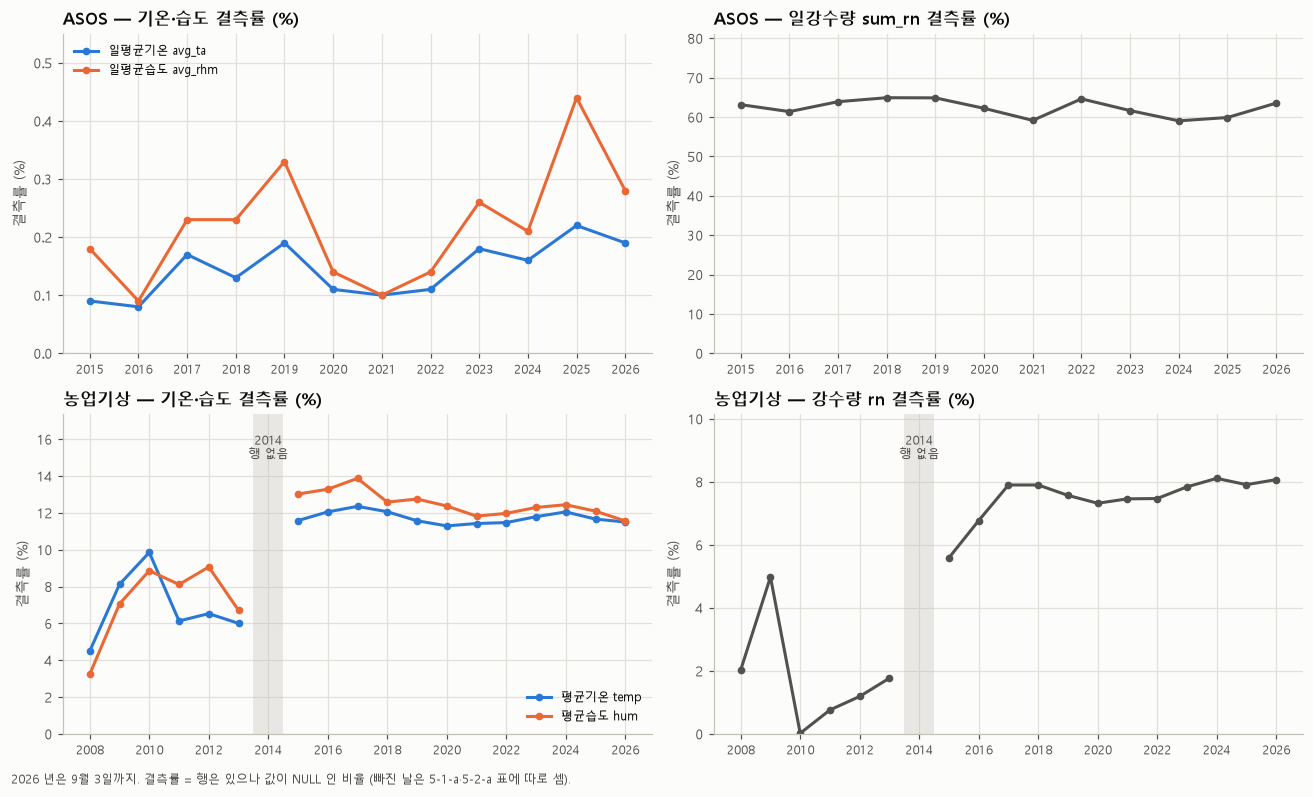

In [66]:
# [5-5] 연도별 결측률(%) 선 — ASOS 기온·습도 / ASOS 강수 / 농업기상 기온·습도 / 농업기상 강수
_ay = wx_t512.drop(index='전체')
_ny = wx_t521.drop(index='전체')
fig, axes = plt.subplots(2, 2, figsize=(12, 7.2))
PANELS = [
    (axes[0, 0], _ay, [('avg_ta', '일평균기온 avg_ta', C1), ('avg_rhm', '일평균습도 avg_rhm', C2)], 'ASOS — 기온·습도 결측률 (%)'),
    (axes[0, 1], _ay, [('sum_rn', '일강수량 sum_rn', INK2)], 'ASOS — 일강수량 sum_rn 결측률 (%)'),
    (axes[1, 0], _ny, [('temp', '평균기온 temp', C1), ('hum', '평균습도 hum', C2)], '농업기상 — 기온·습도 결측률 (%)'),
    (axes[1, 1], _ny, [('rn', '강수량 rn', INK2)], '농업기상 — 강수량 rn 결측률 (%)'),
]
for ax, t, series, title in PANELS:
    x = np.array([int(v) for v in t.index])
    for col, lab, c in series:
        y = t[col].astype(float).to_numpy()
        ax.plot(x, y, color=c, marker='o', ms=4, label=lab)
    ax.set_title(title)
    ax.set_xticks(x[::2] if len(x) > 12 else x)
    ax.tick_params(axis='x', labelsize=8)
    ax.set_ylabel('결측률 (%)')
    top = np.nanmax(t[[s[0] for s in series]].astype(float).to_numpy())
    ax.set_ylim(0, top * 1.25 if top > 0 else 1)
    if len(series) > 1:
        ax.legend(loc='lower right' if t is _ny else 'upper left', fontsize=8)
    if t is _ny:
        ax.axvspan(2013.5, 2014.5, color=GRAY, alpha=0.35, lw=0)
        ax.text(2014, top * 1.12, '2014\n행 없음', ha='center', va='center', fontsize=8, color=INK2)
fig.text(0.01, 0.005, '2026 년은 9월 3일까지. 결측률 = 행은 있으나 값이 NULL 인 비율 (빠진 날은 5-1-a·5-2-a 표에 따로 셈).', fontsize=8, color=INK2)
plt.tight_layout(rect=(0, 0.02, 1, 1))
plt.show()

📊 **결과**
- ASOS 기온·습도 결측률은 해마다 0.08\~0.44%, sum_rn 은 59.04\~64.91% 로 연도에 따른 큰 변화가 없습니다.
- 농업기상 temp·hum 결측률은 2008\~2013 년 3.24\~9.85%, 2015 년 이후 11.29\~13.87%. rn 은 2010 년 0.02% \~ 2024 년 8.11%. 2014 년은 행이 없습니다.

💬 **첨언**
- 농업기상은 2013 년 131곳 → 2015 년 162곳으로 관측소가 늘어난 시점에 결측률도 올라, 새로 들어온 관측소 쪽에 결측이 많은지 볼 여지가 있습니다 (추정, 이 절에서 나눠 보지 않음).

❓ **도메인 전문가께**: 기온·습도를 행에 붙일 때, **결측이 적은 ASOS**(국내 행 당일 avg_ta 값 있음 97.14%)와 **관측소가 더 촘촘하지만 결측·경계값이 많은 농업기상**(temp 90.14%) 중 어느 쪽이 식품 공장·농장 주변 기상을 더 잘 나타낸다고 보십니까? (단서: 두 비율은 작성자 임의 '최근접 1곳' 규칙의 영향이 섞인 값입니다. 운영이 끝난 대구(기)·동방로거테스트 한 곳씩만 후보에서 빼면 ASOS 99.18%·농업기상 90.60% 입니다 — 5-4-3 표 5-4-h.)

🗄️ **데이터 담당자께**: 모델팀에서 **기본 기상 원천을 ASOS·농업기상 중 무엇으로 두는지**, 두 원천을 섞어 쓰는 규칙(예: 한쪽 결측 시 다른 쪽)이 있는지 알려 주십시오.

---
## 6. 기상 붙이기 전 — 가공식품 검출률이 달·계절마다 다른가 (메모 도메인1)

🔎 기상(기온·습도)을 가공식품 행에 붙이기 전에, **날짜만으로도** 검출률이 달·계절마다 달라지는지 봅니다.
- 달 평균 모양은 기상 연관의 **간접 단서**일 뿐입니다. 달 차이가 없어도 일별·해별·지역별 기상 편차와의 연관은 있을 수 있고, 달 차이가 있어도 날씨 때문이 아닐 수 있습니다. 그래서 이 절만으로 기상 연관 여부를 판단하지 않고, 기상값을 붙인 7절과 전문가 의견으로 넘깁니다.
- 달마다 차이가 있으면, 그것이 날씨 때문인지 **그 달에 어떤 검사가 많았는지(구성)** 때문인지 먼저 나눠 보았습니다.
- 날짜 기준은 두 가지입니다 (7절 기준 A·B 와 같은 날짜, 작성자 임의): **제조월** = 원본 제조일(`mnfctur_de_raw`)의 달, **의뢰월** = 의뢰일(`reqest_de`)의 달.

### 6-1. 국내 가공식품의 달별 검출률 — 제조월과 의뢰월, 원물·기준규격외와 대조

🔎 달마다 행 수·검출·검출률과 95% 신뢰구간(Wilson)을 냅니다. 원물(통계용 분류)은 행이 적어 신뢰구간이 넓게 나옵니다.

In [67]:
# [6-1] 국내 가공식품(C)·원물(통계용 분류)·기준규격외(Z)의 달별 검출률과 95% 신뢰구간(Wilson)
# - 제조월: 원본 제조일(mnfctur_de_raw)이 있는 행만. 없는 행은 빼고 수를 출력
# - 의뢰월: 의뢰일(reqest_de) 기준, 전체 행 (의뢰일 없는 행이 있으면 빼고 수를 출력)
# - '달' 단위로 묶는 것, 두 날짜 기준을 고른 것은 작성자 임의 방법
S6_COLS = ['lims_data_key', 'pos', '대분류', 'mnfctur_de_raw', 'reqest_de', 'train_prdlst_nm', '검사목적', '검체성격(임의)',
           'addr', 'addr_source', 'bsn_lcns_ledg_no', 'mnfctur_cmpny_nm']
d6 = dfx.loc[dfx['국내해외'].eq('국내'), S6_COLS].copy()     # 필요한 열만 (dfx 전체 복사 아님)
d6['train_prdlst_nm'] = d6['train_prdlst_nm'].astype('string')
GRP6 = {
    '국내 가공식품(C)': d6['대분류'].eq('가공식품'),
    '국내 원물(통계용 분류)': d6['대분류'].isin(['농산물(원물)', '축산물(원물)', '수산물(원물)']),
    '국내 기준규격외(Z)': d6['대분류'].eq('기준규격외(검체)'),
}
BASIS6 = {'제조월': 'mnfctur_de_raw', '의뢰월': 'reqest_de'}
MONTHS = list(range(1, 13))


def month_table(frame, date_col, label, verbose=True):
    '''달별 행 수·검출·검출률(%)·Wilson 95% CI(%). 행이 없는 달은 NaN 그대로 둔다(0 으로 채우지 않음).'''
    use = frame[frame[date_col].notna()]
    if verbose:
        print(f'  {label} [{date_col}] 사용 {len(use):,}행 (날짜 없어 뺀 행 {len(frame) - len(use):,}) / 검출 {int(use["pos"].sum()):,}')
    g = use.groupby(use[date_col].dt.month)['pos'].agg(['size', 'sum']).reindex(MONTHS)
    lo, hi = wilson(g['sum'], g['size'])
    t = pd.DataFrame({'행 수': g['size'], '검출': g['sum'], '검출률(%)': (g['sum'] / g['size'] * 100).round(3),
                      'CI하한': np.round(lo, 3), 'CI상한': np.round(hi, 3)})
    t.index.name = '월'
    return t


def show_pair(tA, tB, nameA='제조월', nameB='의뢰월'):
    '''두 기준 표를 나란히 (CI 는 "하한~상한" 글자로 합쳐 보기만 줄임)'''
    def fmt(t):
        o = t[['행 수', '검출', '검출률(%)']].copy()
        o['95% CI(%)'] = [f'{a:.3f}~{b:.3f}' if pd.notna(a) else '-' for a, b in zip(t['CI하한'], t['CI상한'])]
        return o
    return pd.concat({nameA: fmt(tA), nameB: fmt(tB)}, axis=1)


MT6 = {}
for gname, mask in GRP6.items():
    sub = d6[mask]
    base = sub['pos'].mean() * 100
    print(f'{gname}: {len(sub):,}행 / 검출 {int(sub["pos"].sum()):,} / 전체 검출률 {base:.3f}%')
    for bname, col in BASIS6.items():
        MT6[(gname, bname)] = month_table(sub, col, bname)
for gname in GRP6:
    print(f'\n[{gname}]')
    display(show_pair(MT6[(gname, '제조월')], MT6[(gname, '의뢰월')]))


def hi_lo_ratio(t):
    '''차이의 크기(상대 비율): 검출률이 가장 높은 달 / 가장 낮은 달. 가장 낮은 달이 0% 이면 비를 내지 않음'''
    r = t['검출'] / t['행 수'] * 100      # 반올림 전 검출률로 비를 계산 (6-5 표의 '최고/최저 비'와 같은 값)
    hi_m, lo_m = int(r.idxmax()), int(r.idxmin())
    ratio = f'{r.max() / r.min():.2f}배' if r.min() > 0 else '계산 안 함(최저 0%)'
    return f'최고 {hi_m}월 {r.max():.3f}% / 최저 {lo_m}월 {r.min():.3f}% = {ratio}'


print('\n달별 차이의 상대 크기 (최고 달 / 최저 달 검출률; 12개 달 중 골라낸 양 끝이라 우연한 흔들림도 커 보이게 됨)')
for (gname, bname), t in MT6.items():
    print(f'  {gname} / {bname}: {hi_lo_ratio(t)}')

국내 가공식품(C): 294,421행 / 검출 386 / 전체 검출률 0.131%
  제조월 [mnfctur_de_raw] 사용 222,607행 (날짜 없어 뺀 행 71,814) / 검출 288
  의뢰월 [reqest_de] 사용 294,421행 (날짜 없어 뺀 행 0) / 검출 386
국내 원물(통계용 분류): 3,533행 / 검출 27 / 전체 검출률 0.764%
  제조월 [mnfctur_de_raw] 사용 1,324행 (날짜 없어 뺀 행 2,209) / 검출 8
  의뢰월 [reqest_de] 사용 3,533행 (날짜 없어 뺀 행 0) / 검출 27
국내 기준규격외(Z): 320,536행 / 검출 1,431 / 전체 검출률 0.446%
  제조월 [mnfctur_de_raw] 사용 65,199행 (날짜 없어 뺀 행 255,337) / 검출 299
  의뢰월 [reqest_de] 사용 320,536행 (날짜 없어 뺀 행 0) / 검출 1,431

[국내 가공식품(C)]


제조월                            의뢰월                        
      행 수  검출 검출률(%)    95% CI(%)    행 수  검출 검출률(%)    95% CI(%)
월                                                               
1   18222  15  0.082  0.050~0.136  22096  24  0.109  0.073~0.162
2   17475  15  0.086  0.052~0.142  22612  23  0.102  0.068~0.153
3   19987  41  0.205  0.151~0.278  26376  50  0.190  0.144~0.250
4   20210  32  0.158  0.112~0.223  27497  53  0.193  0.147~0.252
5   20042  35  0.175  0.126~0.243  26564  42  0.158  0.117~0.214
6   20035  26  0.130  0.089~0.190  26960  31  0.115  0.081~0.163
7   19170  32  0.167  0.118~0.236  26218  42  0.160  0.119~0.216
8   17636  23  0.130  0.087~0.196  23523  27  0.115  0.079~0.167
9   17251  24  0.139  0.094~0.207  22379  32  0.143  0.101~0.202
10  17924  14  0.078  0.047~0.131  24573  18  0.073  0.046~0.116
11  17336  18  0.104  0.066~0.164  23751  23  0.097  0.065~0.145
12  17319  13  0.075  0.044~0.128  21872  21  0.096  0.063~0.147


[국내 원물(통계용 분류)]


제조월                         의뢰월                       
    행 수 검출 검출률(%)    95% CI(%)  행 수 검출 검출률(%)    95% CI(%)
월                                                         
1    93  0  0.000  0.000~3.967  162  2  1.235  0.339~4.389
2   109  0  0.000  0.000~3.404  203  0  0.000  0.000~1.857
3   212  0  0.000  0.000~1.780  423  4  0.946  0.368~2.406
4   162  1  0.617  0.109~3.413  395  3  0.759  0.259~2.209
5   177  3  1.695  0.578~4.864  610  4  0.656  0.255~1.674
6   121  0  0.000  0.000~3.077  485  2  0.412  0.113~1.491
7    38  0  0.000  0.000~9.181  225  1  0.444  0.078~2.474
8    55  0  0.000  0.000~6.529  172  0  0.000  0.000~2.185
9    73  1  1.370  0.242~7.360  210  4  1.905  0.743~4.794
10  102  0  0.000  0.000~3.630  325  2  0.615  0.169~2.216
11  100  1  1.000  0.177~5.449  235  3  1.277  0.435~3.685
12   82  2  2.439  0.671~8.464   88  2  2.273  0.625~7.913


[국내 기준규격외(Z)]


제조월                            의뢰월                         
     행 수  검출 검출률(%)    95% CI(%)    행 수   검출 검출률(%)    95% CI(%)
월                                                               
1   4949  11  0.222  0.124~0.398  22062   75  0.340  0.271~0.426
2   4982  11  0.221  0.123~0.395  22979   46  0.200  0.150~0.267
3   6829  11  0.161  0.090~0.288  34401   80  0.233  0.187~0.289
4   6004  13  0.217  0.127~0.370  35376   90  0.254  0.207~0.313
5   6136  11  0.179  0.100~0.321  30056  105  0.349  0.289~0.423
6   5288  36  0.681  0.492~0.941  27423  118  0.430  0.359~0.515
7   4974  32  0.643  0.456~0.907  23407  142  0.607  0.515~0.715
8   5046  32  0.634  0.450~0.894  21488  155  0.721  0.617~0.844
9   4789  19  0.397  0.254~0.619  21296  132  0.620  0.523~0.735
10  5380  13  0.242  0.141~0.413  27039  116  0.429  0.358~0.514
11  5320  48  0.902  0.681~1.194  26771  159  0.594  0.509~0.693
12  5502  62  1.127  0.880~1.442  28238  213  0.754  0.660~0.862


달별 차이의 상대 크기 (최고 달 / 최저 달 검출률; 12개 달 중 골라낸 양 끝이라 우연한 흔들림도 커 보이게 됨)
  국내 가공식품(C) / 제조월: 최고 3월 0.205% / 최저 12월 0.075% = 2.73배
  국내 가공식품(C) / 의뢰월: 최고 4월 0.193% / 최저 10월 0.073% = 2.63배
  국내 원물(통계용 분류) / 제조월: 최고 12월 2.439% / 최저 1월 0.000% = 계산 안 함(최저 0%)
  국내 원물(통계용 분류) / 의뢰월: 최고 12월 2.273% / 최저 2월 0.000% = 계산 안 함(최저 0%)
  국내 기준규격외(Z) / 제조월: 최고 12월 1.127% / 최저 3월 0.161% = 7.00배
  국내 기준규격외(Z) / 의뢰월: 최고 12월 0.754% / 최저 2월 0.200% = 3.77배


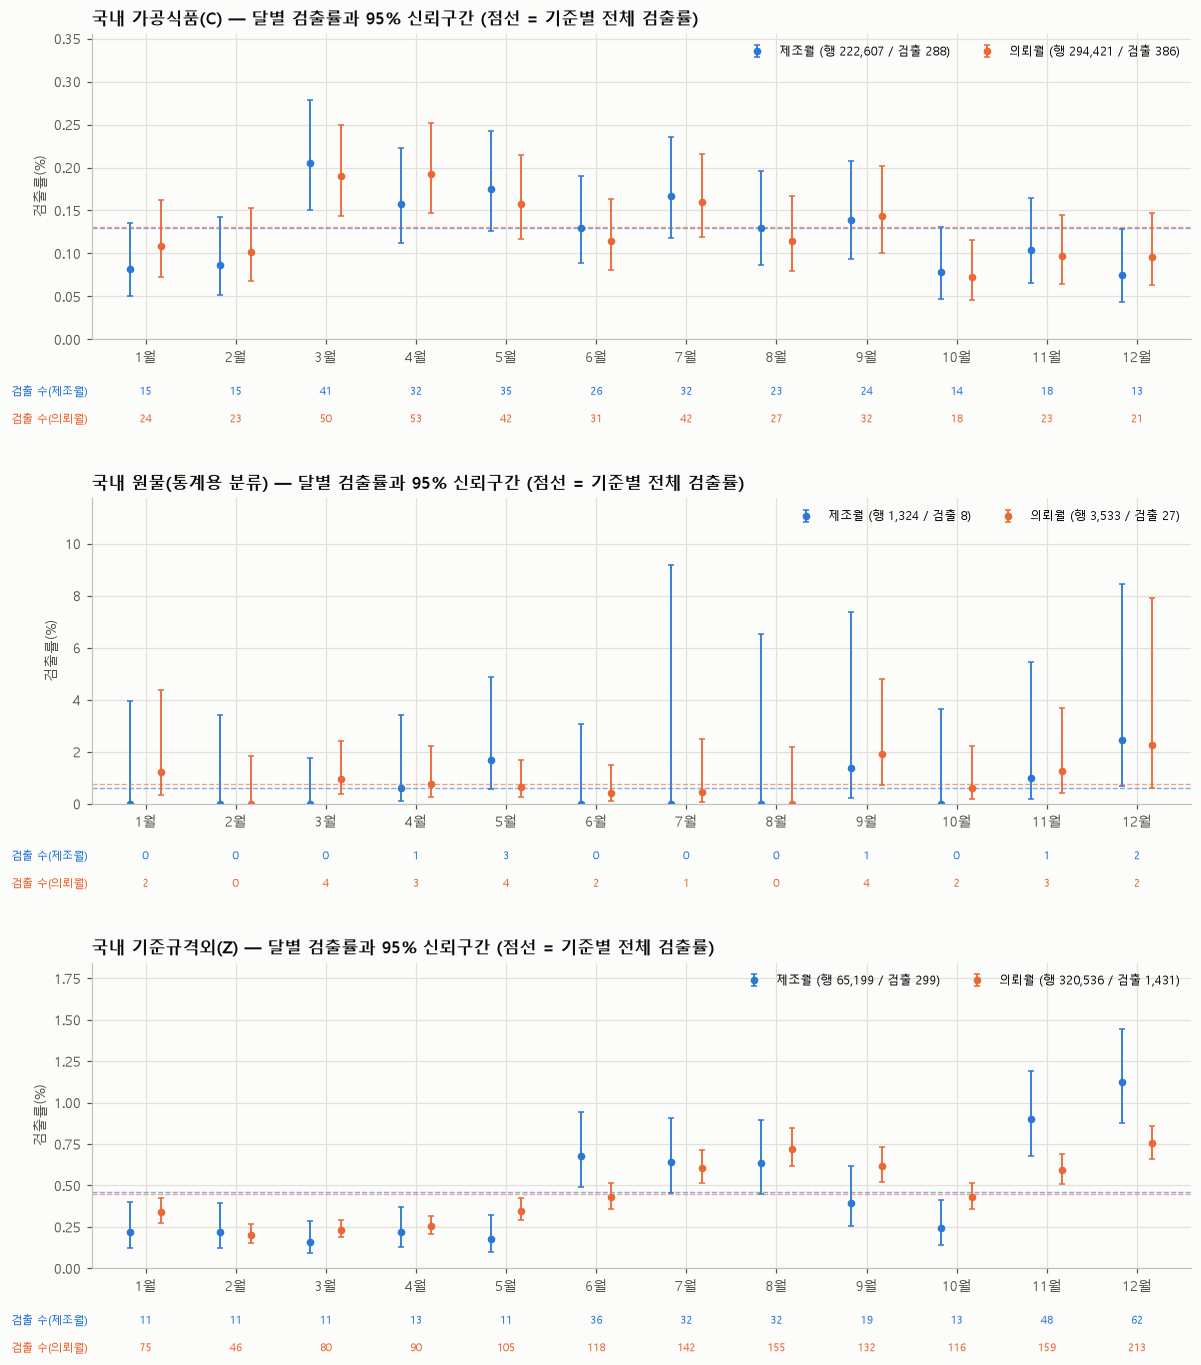

In [68]:
# [6-1 그림] 점 = 검출률, 막대 = 95% CI. 파랑 = 제조월, 주황 = 의뢰월. 그래프 아래 숫자 = 달별 검출 수
from matplotlib.transforms import blended_transform_factory


def plot_months(ax, series, title, ylabel='검출률(%)'):
    '''series: [(표, 라벨, 색)] 최대 2개. 같은 달 안에서 좌우로 조금 비켜 그림.'''
    x = np.arange(1, 13)
    offs = [-0.17, 0.17] if len(series) == 2 else [0.0]
    tr = blended_transform_factory(ax.transData, ax.transAxes)
    for j, ((t, lab, col), off) in enumerate(zip(series, offs)):
        r = t['검출률(%)'].to_numpy(float)
        lo, hi = t['CI하한'].to_numpy(float), t['CI상한'].to_numpy(float)
        n, k = np.nansum(t['행 수']), np.nansum(t['검출'])
        ax.errorbar(x + off, r, yerr=[r - lo, hi - r], fmt='o', ms=4, color=col, ecolor=col, elinewidth=1.2, capsize=2,
                    label=f'{lab} (행 {n:,.0f} / 검출 {k:,.0f})')
        ax.axhline(k / n * 100, color=col, lw=0.9, ls='--', alpha=0.6)
        ypos = -0.17 - 0.09 * j
        ax.text(0.35, ypos, f'검출 수({lab})', transform=tr, ha='right', va='center', fontsize=7.5, color=col)
        for xi, ki in zip(x, t['검출'].to_numpy(float)):
            ax.text(xi, ypos, '-' if np.isnan(ki) else f'{ki:.0f}', transform=tr, ha='center', va='center', fontsize=7.5, color=col)
    ax.set_xticks(x)
    ax.set_xticklabels([f'{m}월' for m in x])
    ax.set_xlim(0.4, 12.6)
    ytop = np.nanmax([np.nanmax(t['CI상한'].to_numpy(float)) for t, _, _ in series])
    ax.set_ylim(0, ytop * 1.28)     # 범례 자리를 위쪽에 비워 둠
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(loc='upper right', fontsize=8, ncol=2)


fig, axes = plt.subplots(3, 1, figsize=(11, 12.5))
for ax, gname in zip(axes, GRP6):
    plot_months(ax, [(MT6[(gname, '제조월')], '제조월', C1), (MT6[(gname, '의뢰월')], '의뢰월', C2)],
                f'{gname} — 달별 검출률과 95% 신뢰구간 (점선 = 기준별 전체 검출률)')
plt.tight_layout(h_pad=3.5)
plt.show()

📊 **결과**
- **국내 가공식품** (294,421행 / 검출 386, 전체 0.131%): 의뢰월 기준 가장 높은 달은 4월 0.193%(53건)·3월 0.190%(50건), 가장 낮은 달은 10월 0.073%(18건). 7월도 0.160%(42건)입니다. 3월(95% CI 0.144\~0.250)과 10월(0.046\~0.116)은 신뢰구간이 겹치지 않습니다.
- 제조월 기준(원본 제조일 있는 222,607행 / 검출 288, 제조일 없는 71,814행 뺌)도 3월 0.205%, 10월 0.078%, 12월 0.075% 로 모양이 비슷합니다.
- 차이의 상대 크기(가장 높은 달 ÷ 가장 낮은 달): 의뢰월 4월 0.193% / 10월 0.073% = 2.63배, 제조월 3월 0.205% / 12월 0.075% = 2.73배.
- **국내 원물(통계용 분류)** (3,533행 / 검출 27): 달마다 검출 0\~4건이라 신뢰구간이 넓습니다(예: 의뢰월 12월 0.625\~7.913). 제조월은 원본 제조일 있는 1,324행(검출 8)뿐입니다.
- **국내 기준규격외(Z)** (320,536행 / 검출 1,431): 의뢰월 기준 1\~5월 0.200\~0.349%, 6\~12월 0.429\~0.754%. 제조월 기준은 11월 0.902%·12월 1.127% 가 가장 높습니다.

💬 **첨언**
- 작성자가 달 단위로 묶어 본 결과, 가공식품은 **봄(3\~5월)이 높고 10월\~2월이 낮은 모양**으로 보입니다 (추정). 다만 7월(0.160%)도 봄에 가까운 수준입니다. 기온이 가장 높은 7\~8월이 가장 높지는 않아, "기온이 높을수록 검출률이 높다"는 단순한 가정과는 곧바로 맞아 보이지 않습니다 (추정).
- 3월과 10월의 신뢰구간이 겹치지 않는 것은 12개 달 가운데 **가장 높은 달과 가장 낮은 달을 골라서** 비교한 결과입니다. 이렇게 고르면 우연한 흔들림만으로도 차이가 커 보이기 쉬워, 강한 근거로 보기는 어렵습니다. 12개 달을 한꺼번에 본 검정은 6-5 에 있습니다.
- 제조월과 의뢰월 모양이 비슷한 것은 국내 제조→의뢰 간격 중앙값이 2일(2.ipynb 4장)이라 두 날짜가 같은 달에 들어가는 행이 많기 때문으로 보입니다 (추정).
- 의뢰월 표에는 앞뒤가 잘린 해(2016년은 3월부터, 2026년은 7월까지 — 6-3 표)가 섞여 있어, 6-5 에서 2017\~2025년만 따로 다시 봅니다.
- Z 코드는 팽이버섯 수출검사·공정 시료가 섞인 코드(2.ipynb)라 달 모양이 그 구성 때문일 수 있고, 이 절에서는 나누지 않았습니다.

### 6-2. 가공식품 안 주요 군별 계절 검출률

🔎 가공식품 검출은 몇 개 군(식육가공품 및 포장육 등)에 몰려 있습니다. 군마다 계절 차이가 같은 방향인지 봅니다.
- 계절 = 의뢰월 기준 봄(3\~5월)·여름(6\~8월)·가을(9\~11월)·겨울(12\~2월). 12월과 다음 해 1·2월을 같은 겨울로 묶지 않고 **달 이름으로만** 나눴습니다 (작성자 임의).
- 군 = 학습용 품목명 `train_prdlst_nm` 그대로.

In [69]:
# [6-2] 국내 가공식품 주요 군 × 계절(의뢰월 기준) 검출률과 95% CI
# - 계절 구간(3~5, 6~8, 9~11, 12~2월)은 작성자 임의 방법
SEASON_OF = {3: '봄(3~5월)', 4: '봄(3~5월)', 5: '봄(3~5월)', 6: '여름(6~8월)', 7: '여름(6~8월)', 8: '여름(6~8월)',
             9: '가을(9~11월)', 10: '가을(9~11월)', 11: '가을(9~11월)', 12: '겨울(12~2월)', 1: '겨울(12~2월)', 2: '겨울(12~2월)'}
SEASONS = ['봄(3~5월)', '여름(6~8월)', '가을(9~11월)', '겨울(12~2월)']
GROUPS4 = ['식육가공품 및 포장육', '즉석식품류', '유가공품류', '수산가공식품류']

pf = d6[GRP6['국내 가공식품(C)']].copy()
print(f'국내 가공식품 {len(pf):,}행, 의뢰일 없는 행 {pf["reqest_de"].isna().sum():,} (있으면 계절 계산에서 뺌)')
pf = pf[pf['reqest_de'].notna()]
pf['의뢰월'] = pf['reqest_de'].dt.month
pf['연'] = pf['reqest_de'].dt.year
pf['계절'] = pd.Categorical(pf['의뢰월'].map(SEASON_OF), categories=SEASONS, ordered=True)
pf['군'] = pf['train_prdlst_nm'].where(pf['train_prdlst_nm'].isin(GROUPS4), '그 외 가공식품')
print('군별 행 수 / 검출:', pf.groupby('군', observed=True)['pos'].agg(['size', 'sum']).to_dict('index'))


def season_table(frame, by):
    g = frame.groupby([by, '계절'], observed=True)['pos'].agg(['size', 'sum'])
    lo, hi = wilson(g['sum'], g['size'])
    t = pd.DataFrame({'행 수': g['size'], '검출': g['sum'], '검출률(%)': (g['sum'] / g['size'] * 100).round(3),
                      'CI하한': np.round(lo, 3), 'CI상한': np.round(hi, 3)})
    return t


st6 = season_table(pf, '군').reindex(pd.MultiIndex.from_product([GROUPS4 + ['그 외 가공식품'], SEASONS], names=['군', '계절']))
display(st6)
for gname in GROUPS4:
    t = st6.loc[gname]
    r = t['검출'] / t['행 수'] * 100      # 반올림 전 검출률로 비 계산
    print(f"{gname}: 최고 {r.idxmax()} / 최저 {r.idxmin()} 검출률 비 = "
          + (f'{r.max() / r.min():.2f}배' if r.min() > 0 else '계산 안 함(최저 0%)'))

# 민감도(작성자 임의): 앞뒤가 잘린 해(2016년 3~12월, 2026년 1~7월)를 뺀 2017~2025년만으로 식육가공품 및 포장육 계절표
meat_fy = pf[pf['군'].eq('식육가공품 및 포장육')]
meat_fy_use = meat_fy[meat_fy['연'].between(2017, 2025)]
print(f"\n식육가공품 및 포장육 2017~2025만: {len(meat_fy_use):,}행 / 검출 {int(meat_fy_use['pos'].sum())} "
      f"(2016·2026 {len(meat_fy) - len(meat_fy_use):,}행, 검출 {int(meat_fy['pos'].sum() - meat_fy_use['pos'].sum())} 뺌)")
st6_meat_fy = season_table(meat_fy_use, '군').loc['식육가공품 및 포장육'].reindex(SEASONS)
r = st6_meat_fy['검출'] / st6_meat_fy['행 수'] * 100
print(f"  최고 {r.idxmax()} / 최저 {r.idxmin()} 검출률 비 = {r.max() / r.min():.2f}배")
st6_meat_fy

국내 가공식품 294,421행, 의뢰일 없는 행 0 (있으면 계절 계산에서 뺌)
군별 행 수 / 검출: {'그 외 가공식품': {'size': 80954, 'sum': 12}, '수산가공식품류': {'size': 4637, 'sum': 29}, '식육가공품 및 포장육': {'size': 95216, 'sum': 294}, '유가공품류': {'size': 78292, 'sum': 6}, '즉석식품류': {'size': 35322, 'sum': 45}}


행 수   검출  검출률(%)   CI하한   CI상한
군           계절                                         
식육가공품 및 포장육 봄(3~5월)    25572  113   0.442  0.368  0.531
            여름(6~8월)   24402   72   0.295  0.234  0.371
            가을(9~11월)  22805   60   0.263  0.204  0.338
            겨울(12~2월)  22437   49   0.218  0.165  0.289
즉석식품류       봄(3~5월)     9640   19   0.197  0.126  0.308
            여름(6~8월)    8651    9   0.104  0.055  0.198
            가을(9~11월)   8263    8   0.097  0.049  0.191
            겨울(12~2월)   8768    9   0.103  0.054  0.195
유가공품류       봄(3~5월)    20581    1   0.005  0.001  0.028
            여름(6~8월)   21788    4   0.018  0.007  0.047
            가을(9~11월)  19387    1   0.005  0.001  0.029
            겨울(12~2월)  16536    0   0.000  0.000  0.023
수산가공식품류     봄(3~5월)     1410    9   0.638  0.336  1.209
            여름(6~8월)    1163   12   1.032  0.591  1.795
            가을(9~11월)   1117    3   0.269  0.091  0.787
            겨울(12~2월)    947    5   0.528  0.226  1.230
그 외 가공식품    봄(3~5월)    23234    3   0.013  0.004  0.038
            여름(6~8월)   20697    3   0.014  0.005  0.043
            가을(9~11월)  19131    1   0.005  0.001  0.030
            겨울(12~2월)  17892    5   0.028  0.012  0.065

식육가공품 및 포장육: 최고 봄(3~5월) / 최저 겨울(12~2월) 검출률 비 = 2.02배
즉석식품류: 최고 봄(3~5월) / 최저 가을(9~11월) 검출률 비 = 2.04배
유가공품류: 최고 여름(6~8월) / 최저 겨울(12~2월) 검출률 비 = 계산 안 함(최저 0%)
수산가공식품류: 최고 여름(6~8월) / 최저 가을(9~11월) 검출률 비 = 3.84배

식육가공품 및 포장육 2017~2025만: 88,654행 / 검출 269 (2016·2026 6,562행, 검출 25 뺌)
  최고 봄(3~5월) / 최저 겨울(12~2월) 검출률 비 = 1.92배


,행 수,검출,검출률(%),CI하한,CI상한
계절,,,,,
봄(3~5월),22961,96,0.418,0.343,0.510
여름(6~8월),22921,70,0.305,0.242,0.386
가을(9~11월),22055,58,0.263,0.204,0.340
겨울(12~2월),20717,45,0.217,0.162,0.291


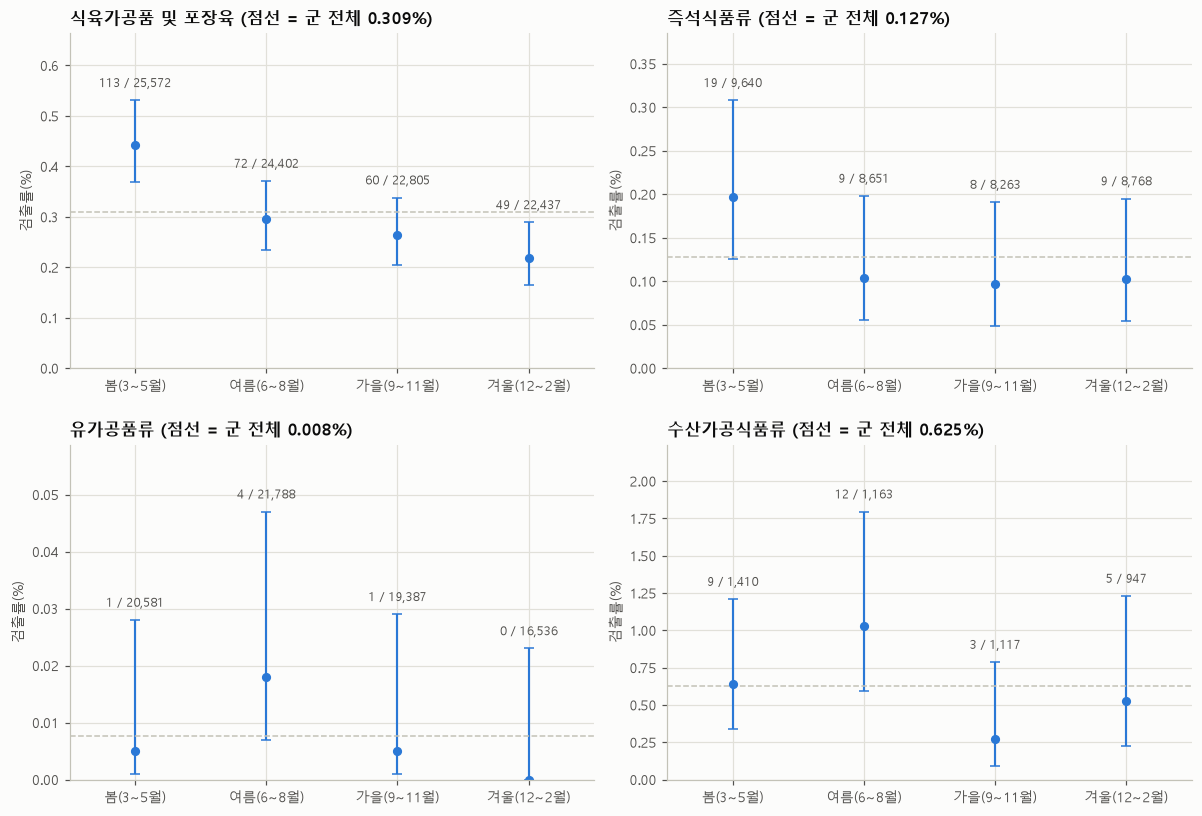

In [70]:
# [6-2 그림] 군별 계절 검출률 (점 = 검출률, 막대 = 95% CI, 글자 = 검출/행 수)
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
xs = np.arange(4)
for ax, gname in zip(axes.ravel(), GROUPS4):
    t = st6.loc[gname]
    r, lo, hi = t['검출률(%)'].to_numpy(float), t['CI하한'].to_numpy(float), t['CI상한'].to_numpy(float)
    ax.errorbar(xs, r, yerr=[r - lo, hi - r], fmt='o', ms=5, color=C1, ecolor=C1, elinewidth=1.4, capsize=3)
    top = np.nanmax(hi)
    for xi, hv, k, n in zip(xs, hi, t['검출'], t['행 수']):
        ax.text(xi, hv + top * 0.04, f'{k:.0f} / {n:,.0f}', ha='center', va='bottom', fontsize=8, color=INK2)
    tot = pf.loc[pf['군'].eq(gname), 'pos'].mean() * 100
    ax.axhline(tot, color=GRAY, lw=1, ls='--')
    ax.set_xticks(xs)
    ax.set_xticklabels(SEASONS)
    ax.set_xlim(-0.5, 3.5)
    ax.set_ylim(0, top * 1.25)
    ax.set_ylabel('검출률(%)')
    ax.set_title(f'{gname} (점선 = 군 전체 {tot:.3f}%)')
plt.tight_layout(h_pad=2.0)
plt.show()

📊 **결과**
- **식육가공품 및 포장육** (95,216행 / 검출 294): 봄 0.442%(113/25,572) → 여름 0.295% → 가을 0.263% → 겨울 0.218%. 봄 ÷ 겨울 = 2.02배. 봄(CI 0.368\~0.531)과 겨울(0.165\~0.289)의 신뢰구간이 겹치지 않습니다.
  - 앞뒤가 잘린 해(2016·2026, 6,562행·검출 25)를 뺀 **2017\~2025년만** (88,654행 / 검출 269): 봄 0.418%(96/22,961) → 여름 0.305% → 가을 0.263% → 겨울 0.217%(45/20,717), 봄 ÷ 겨울 = 1.92배.
- **즉석식품류** (35,322행 / 검출 45): 봄 0.197%(19건), 나머지 계절 0.097\~0.104%. 신뢰구간은 모두 겹칩니다.
- **수산가공식품류** (4,637행 / 검출 29): 여름 1.032%(12건)가 가장 높고 가을 0.269%(3건)가 가장 낮지만 신뢰구간이 넓습니다.
- **유가공품류** (78,292행 / 검출 6): 계절마다 0\~4건. **그 외 가공식품** (80,954행 / 검출 12): 계절마다 1\~5건.

💬 **첨언**
- 가공식품 검출 386건 중 294건이 식육가공품 및 포장육이라, 6-1 의 "봄이 높은 모양"은 주로 이 군의 모양으로 보입니다 (추정). 2017\~2025년만 봐도 봄이 높은 모양은 남았습니다.
- 봄과 겨울의 신뢰구간이 겹치지 않는 것도 4계절 중 양 끝을 골라 비교한 것이라, 이것만으로 강한 근거로 보기는 어렵습니다. 4계절을 한꺼번에 본 검정은 6-5 에 있습니다.
- 수산가공식품류는 여름이 높아 보이지만 계절마다 3\~12건이라 우연한 흔들림일 수 있습니다 (추정).
- 군마다 높은 계절이 달라 보여(식육가공품·즉석식품 봄, 수산가공식품 여름), 가공식품 전체에 한 가지 기상 효과를 가정하기는 어려울 수 있습니다 (추정).

### 6-3. 연도 × 달 검출 수 — 특정 연·월, 특정 업체에 몰려 있나

🔎 달별 차이가 몇몇 해·몇몇 업체의 몰림 때문일 수 있습니다 (2.ipynb 에서 2020 년 팽이버섯 수출검사 몰림을 본 것과 같은 이유).
- 업체 식별 규칙(작성자 임의, 1-2 ⑥ 과 같음): 영업허가번호(`bsn_lcns_ledg_no`) → 없으면 제조회사명(`mnfctur_cmpny_nm`) → 둘 다 없으면 '식별 불가'. 빈 글자('')도 없는 것으로 봅니다.
- 의뢰 식별(작성자 임의): `lims_data_key` 의 앞 두 조각(예: `O000084_210102358`, 기관코드_의뢰번호로 추정)을 같은 의뢰로 봅니다.

In [71]:
# [6-3] 국내 가공식품, 의뢰월 기준 연도 × 달 검출 수. 행이 없는 칸은 NaN(빈칸) 그대로
print(f'의뢰일 범위: {pf["reqest_de"].min():%Y-%m-%d} ~ {pf["reqest_de"].max():%Y-%m-%d}')
ym_pos = pd.crosstab(pf['연'], pf['의뢰월'], values=pf['pos'], aggfunc='sum', margins=True, margins_name='합계')
ym_n = pd.crosstab(pf['연'], pf['의뢰월'], margins=True, margins_name='합계')
print('연도 × 달 행 수 (참고)')
display(ym_n)
print('연도 × 달 검출 수')
ym_pos

의뢰일 범위: 2016-03-11 ~ 2026-07-06
연도 × 달 행 수 (참고)


의뢰월,1,2,3,4,5,6,7,8,9,10,11,12,합계
연,,,,,,,,,,,,,
2016,0,0,94,104,221,454,971,715,554,724,658,630,5125
2017,683,1242,2342,2419,2467,2449,2482,2424,2445,2378,2507,2196,26034
2018,2174,1959,2205,2468,2359,2162,2553,2552,2152,2695,2520,2243,28042
2019,2476,2197,2670,2892,2679,2902,2891,2714,2539,2822,2559,2633,31974
2020,2396,2732,2585,2820,3050,2953,2890,2621,2701,2810,2668,2283,32509
2021,2528,2352,2755,2720,2461,2839,2763,2532,2217,2651,2630,2381,30829
2022,2344,2435,2823,3007,2546,2754,2746,2819,2614,2649,2650,2301,31688
2023,2294,2413,2880,2500,2420,2656,2829,2496,2354,2884,2541,2422,30689
2024,2453,2454,2667,2789,2741,2501,3055,2385,2224,2549,2678,2361,30857


연도 × 달 검출 수


의뢰월,1,2,3,4,5,6,7,8,9,10,11,12,합계
연,,,,,,,,,,,,,
2016,NaN,NaN,0.0,0.0,1.0,2.0,0.0,0.0,0.0,1.0,1.0,0.0,5
2017,0.0,1.0,2.0,1.0,2.0,0.0,2.0,1.0,6.0,6.0,2.0,4.0,27
2018,4.0,1.0,7.0,3.0,3.0,3.0,4.0,5.0,4.0,1.0,1.0,1.0,37
2019,4.0,0.0,4.0,5.0,3.0,4.0,3.0,2.0,4.0,2.0,4.0,3.0,38
2020,2.0,1.0,3.0,4.0,3.0,1.0,4.0,6.0,4.0,0.0,1.0,1.0,30
2021,1.0,3.0,4.0,9.0,7.0,5.0,5.0,1.0,5.0,4.0,4.0,5.0,53
2022,0.0,5.0,3.0,10.0,0.0,4.0,6.0,0.0,2.0,1.0,0.0,2.0,33
2023,3.0,8.0,2.0,2.0,8.0,3.0,8.0,2.0,4.0,1.0,7.0,1.0,49
2024,3.0,2.0,6.0,9.0,9.0,6.0,2.0,4.0,2.0,0.0,2.0,2.0,47


In [72]:
# [6-3 계속] 업체·의뢰 식별 (작성자 임의 규칙) 과 달별 검출의 업체 몰림
lic = pf['bsn_lcns_ledg_no'].astype('string').str.strip()
nm = pf['mnfctur_cmpny_nm'].astype('string').str.strip()
lic = lic.mask(lic.eq(''))      # 빈 글자는 '없음'으로만 표시 (값을 만들어 넣지 않음)
nm = nm.mask(nm.eq(''))
pf['업체키'] = ('허가:' + lic).where(lic.notna(), ('회사명:' + nm).where(nm.notna(), '식별 불가'))   # 식별 라벨만 붙임 (원자료 값 채움 아님)
pf['의뢰키'] = pf['lims_data_key'].str.extract(r'^([^_]+_[^_]+)_', expand=False)
src = np.select([lic.notna(), nm.notna()], ['영업허가번호', '제조회사명'], '식별 불가')
print('업체키 출처 — 전체 행(%):', (pd.Series(src).value_counts(normalize=True) * 100).round(1).to_dict())
print('업체키 출처 — 검출 행(%):', (pd.Series(src[pf['pos'].to_numpy() == 1]).value_counts(normalize=True) * 100).round(1).to_dict())
print(f'의뢰키 못 뽑은 행: {pf["의뢰키"].isna().sum():,} / 의뢰키 수 {pf["의뢰키"].nunique():,}')
nmon = pf.groupby('의뢰키')['의뢰월'].nunique()
print(f'한 의뢰키 안에 의뢰월이 2개 이상인 의뢰: {int((nmon > 1).sum()):,} / {len(nmon):,}')

pos6 = pf[pf['pos'].eq(1)]
rows = []
for m in MONTHS:
    p = pos6[pos6['의뢰월'].eq(m)]
    idn = p[p['업체키'].ne('식별 불가')]
    vc = idn['업체키'].value_counts()
    k = len(p)
    rows.append({'월': m, '검출': k, '식별 불가 검출': int((p['업체키'] == '식별 불가').sum()),
                 '검출 업체 수': len(vc), '1위 업체 검출': int(vc.iloc[0]) if len(vc) else 0,
                 '1위 비중(%)': round(vc.iloc[0] / k * 100, 1) if len(vc) and k else np.nan,
                 '상위3 비중(%)': round(vc.iloc[:3].sum() / k * 100, 1) if k else np.nan,
                 '검출 의뢰 수': p['의뢰키'].nunique(),
                 '검출 행/의뢰': round(k / p['의뢰키'].nunique(), 2) if k else np.nan})
conc6 = pd.DataFrame(rows).set_index('월')
conc6['식별 불가 비중(%)'] = (conc6['식별 불가 검출'] / conc6['검출'] * 100).round(1)
display(conc6)

# 보조 확인(작성자 임의): 업체 '식별 불가' 검출 행끼리 몰렸는지 — 주소(addr)·의뢰키·연도를 '묶음 라벨'로만 씀 (업체를 추정해 채우지 않음)
unk = pos6[pos6['업체키'].eq('식별 불가')]
print(f"업체 식별 불가 검출 {len(unk)}행 — 주소 결측 {int(unk['addr'].isna().sum())}행, 주소출처: {unk['addr_source'].astype(str).value_counts().to_dict()}, "
      f"검사목적: {unk['검사목적'].value_counts().to_dict()}")
urows = []
for m in MONTHS:
    p = unk[unk['의뢰월'].eq(m)]
    va = p['addr'].value_counts(dropna=False)      # 주소 결측이 있으면 결측끼리 한 묶음으로 셈 (값 채움 없음)
    urows.append({'월': m, '식별 불가 검출': len(p), '주소 수': len(va), '1위 주소 검출': int(va.iloc[0]) if len(va) else 0,
                  '검출 의뢰 수': p['의뢰키'].nunique(), '연도 수': p['연'].nunique(),
                  '연도별 검출': ', '.join(f'{y}:{c}' for y, c in p['연'].value_counts().sort_index().items())})
unk6 = pd.DataFrame(urows).set_index('월')
print('업체 식별 불가 검출의 달별 몰림 (주소·의뢰·연도 라벨 기준)')
display(unk6)

# 전체 검출 상위 5 업체의 달별 검출 (업체 이름은 가리고 순번만)
top5 = pos6.loc[pos6['업체키'].ne('식별 불가'), '업체키'].value_counts().head(5)
lab5 = {k: f'업체{i + 1}' for i, k in enumerate(top5.index)}
print(f'검출 상위 5 업체(식별 불가 제외)의 검출 합: {int(top5.sum())} / 전체 검출 {len(pos6)} ({top5.sum() / len(pos6) * 100:.1f}%)')
t5 = pd.crosstab(pos6.loc[pos6['업체키'].isin(lab5), '업체키'].map(lab5), pos6.loc[pos6['업체키'].isin(lab5), '의뢰월'],
                 margins=True, margins_name='합계')
t5['검출 연도'] = [', '.join(str(y) for y in sorted(pos6.loc[pos6['업체키'].map(lab5).eq(u), '연'].unique())) if u != '합계' else ''
                for u in t5.index]
t5

업체키 출처 — 전체 행(%): {'영업허가번호': 62.3, '식별 불가': 20.4, '제조회사명': 17.3}
업체키 출처 — 검출 행(%): {'영업허가번호': 53.4, '식별 불가': 33.2, '제조회사명': 13.5}
의뢰키 못 뽑은 행: 0 / 의뢰키 수 209,155
한 의뢰키 안에 의뢰월이 2개 이상인 의뢰: 0 / 209,155


,검출,식별 불가 검출,검출 업체 수,1위 업체 검출,1위 비중(%),상위3 비중(%),검출 의뢰 수,검출 행/의뢰,식별 불가 비중(%)
월,,,,,,,,,
1,24,9,15,1,4.2,12.5,23,1.04,37.5
2,23,8,12,3,13.0,26.1,21,1.10,34.8
3,50,8,37,4,8.0,16.0,49,1.02,16.0
4,53,27,17,5,9.4,18.9,45,1.18,50.9
5,42,11,27,2,4.8,14.3,38,1.11,26.2
6,31,9,21,2,6.5,12.9,31,1.00,29.0
7,42,13,19,6,14.3,23.8,37,1.14,31.0
8,27,9,17,2,7.4,14.8,27,1.00,33.3
9,32,8,22,2,6.2,15.6,31,1.03,25.0


업체 식별 불가 검출 128행 — 주소 결측 0행, 주소출처: {'업소주소': 127, '제조사소재지': 1}, 검사목적: {'기타': 91, '자가품질위탁검사': 32, '식품안전관리인증검사': 4, '수거검사': 1}
업체 식별 불가 검출의 달별 몰림 (주소·의뢰·연도 라벨 기준)


,식별 불가 검출,주소 수,1위 주소 검출,검출 의뢰 수,연도 수,연도별 검출
월,,,,,,
1,9,6,3,8,6,"2018:1, 2019:1, 2021:1, 2023:1, 2024:3, 2025:2"
2,8,5,3,6,3,"2022:4, 2023:3, 2026:1"
3,8,8,1,8,6,"2017:2, 2018:1, 2019:2, 2021:1, 2024:1, 2026:1"
4,27,17,4,22,10,"2017:1, 2018:2, 2019:4, 2020:2, 2021:2, 2022:5, 2023:1, 2024:6, 2025:2, 2026:2"
5,11,9,3,9,7,"2017:2, 2019:1, 2020:1, 2021:3, 2023:2, 2024:1, 2026:1"
6,9,9,1,9,6,"2018:2, 2019:2, 2020:1, 2021:2, 2022:1, 2024:1"
7,13,11,3,12,7,"2017:1, 2018:1, 2019:2, 2020:1, 2021:4, 2023:3, 2025:1"
8,9,9,1,9,5,"2018:4, 2019:1, 2020:2, 2024:1, 2025:1"
9,8,7,2,8,6,"2017:2, 2018:1, 2019:2, 2020:1, 2023:1, 2024:1"


검출 상위 5 업체(식별 불가 제외)의 검출 합: 30 / 전체 검출 386 (7.8%)


의뢰월,2,3,4,6,7,9,10,11,12,합계,검출 연도
업체키,,,,,,,,,,,
업체1,3,4,0,0,0,0,0,0,0,7,"2021, 2022, 2023, 2025"
업체2,0,0,0,1,6,0,0,0,0,7,2022
업체3,0,1,0,1,0,1,1,2,0,6,"2016, 2021, 2024, 2025"
업체4,0,0,5,0,0,0,0,0,0,5,2022
업체5,0,0,0,1,2,1,0,0,1,5,2023
합계,3,5,5,3,8,2,1,2,1,30,


In [73]:
# [6-3 계속] 몰림 칸 확인: 검출 수 상위 연·월 칸과 그 칸의 업체·의뢰 몰림
cell = pf.groupby(['연', '의뢰월']).agg(행수=('pos', 'size'), 검출=('pos', 'sum'))
cell['검출률(%)'] = (cell['검출'] / cell['행수'] * 100).round(3)
topc = cell.sort_values(['검출', '검출률(%)'], ascending=False).head(10).copy()
info = []
for (y, m) in topc.index:
    p = pos6[pos6['연'].eq(y) & pos6['의뢰월'].eq(m)]
    vc = p.loc[p['업체키'].ne('식별 불가'), '업체키'].value_counts()
    info.append({'검출 업체 수': len(vc), '1위 업체 검출': int(vc.iloc[0]) if len(vc) else 0,
                 '1위 업체': lab5.get(vc.index[0], '(상위5 밖)') if len(vc) else '-', '검출 의뢰 수': p['의뢰키'].nunique(),
                 '1위 의뢰 검출': int(p['의뢰키'].value_counts().iloc[0]),
                 '식별 불가 검출': int(p['업체키'].eq('식별 불가').sum()),
                 '검출 중 식육가공품': int(p['train_prdlst_nm'].eq('식육가공품 및 포장육').sum()),
                 '검출 검사목적': ', '.join(f'{k} {v}' for k, v in p['검사목적'].value_counts().items())})
topc = pd.concat([topc, pd.DataFrame(info, index=topc.index)], axis=1)
print('검출 수 상위 10 연·월 칸')
display(topc)

# 민감도(작성자 임의): 검출 상위 5 업체의 행을 모두 뺀 달별 검출률
ex5 = pf[~pf['업체키'].isin(lab5)]
print(f'상위 5 업체 행 {len(pf) - len(ex5):,}행 (검출 {int(pf["pos"].sum() - ex5["pos"].sum())}) 을 빼고 다시 계산')
mt_ex5 = month_table(ex5, 'reqest_de', '상위5 업체 제외 의뢰월')
show_pair(MT6[('국내 가공식품(C)', '의뢰월')], mt_ex5, '전체(의뢰월)', '상위5 업체 제외(의뢰월)')

검출 수 상위 10 연·월 칸


행수  검출  검출률(%)  검출 업체 수  1위 업체 검출    1위 업체  검출 의뢰 수  1위 의뢰 검출  식별 불가 검출  검출 중 식육가공품                                 검출 검사목적
연    의뢰월                                                                                                                               
2026 3    2657  12   0.452       10         2  (상위5 밖)       12         1         1          11  수거검사 6, 기타 3, 식품안전관리인증검사 2, 자가품질위탁검사 1
2022 4    3007  10   0.333        1         5      업체4        9         2         5           7                                   기타 10
2021 4    2720   9   0.331        5         3  (상위5 밖)        7         3         2           8                자가품질위탁검사 5, 기타 3, 수거검사 1
2024 5    2741   9   0.328        7         2  (상위5 밖)        8         2         1           8                자가품질위탁검사 3, 수거검사 3, 기타 3
     4    2789   9   0.323        3         1  (상위5 밖)        7         3         6           8                      기타 7, 식품안전관리인증검사 2
2023 2    2413   8   0.332        4         2  (상위5 밖)        7         2         3           8                            기타 5, 수거검사 3
     5    2420   8   0.331        6         1  (상위5 밖)        8         1         2           6                기타 6, 수거검사 1, 자가품질위탁검사 1
     7    2829   8   0.283        3         2  (상위5 밖)        6         2         3           7          기타 5, 자가품질위탁검사 2, 식품안전관리인증검사 1
2025 7    3032   8   0.264        6         2  (상위5 밖)        8         1         1           7                기타 6, 자가품질위탁검사 1, 수거검사 1
2018 3    2205   7   0.317        6         1  (상위5 밖)        7         1         1           5                      자가품질위탁검사 5, 수거검사 2

상위 5 업체 행 347행 (검출 30) 을 빼고 다시 계산
  상위5 업체 제외 의뢰월 [reqest_de] 사용 294,074행 (날짜 없어 뺀 행 0) / 검출 356


전체(의뢰월)                         상위5 업체 제외(의뢰월)                        
       행 수  검출 검출률(%)    95% CI(%)            행 수  검출 검출률(%)    95% CI(%)
월                                                                        
1    22096  24  0.109  0.073~0.162          22064  24  0.109  0.073~0.162
2    22612  23  0.102  0.068~0.153          22586  20  0.089  0.057~0.137
3    26376  50  0.190  0.144~0.250          26326  45  0.171  0.128~0.229
4    27497  53  0.193  0.147~0.252          27463  48  0.175  0.132~0.232
5    26564  42  0.158  0.117~0.214          26534  42  0.158  0.117~0.214
6    26960  31  0.115  0.081~0.163          26926  28  0.104  0.072~0.150
7    26218  42  0.160  0.119~0.216          26180  34  0.130  0.093~0.181
8    23523  27  0.115  0.079~0.167          23516  27  0.115  0.079~0.167
9    22379  32  0.143  0.101~0.202          22348  30  0.134  0.094~0.192
10   24573  18  0.073  0.046~0.116          24561  17  0.069  0.043~0.111
11   23751  23  0.097  0.065~0.145          23729  21  0.088  0.058~0.135
12   21872  21  0.096  0.063~0.147          21841  20  0.092  0.059~0.141

📊 **결과**
- 의뢰일 범위는 2016-03-11 \~ 2026-07-06 입니다. 연·월 칸 중 검출이 가장 많은 칸은 **2026년 3월 12건**(검출 업체 10곳, 검출 의뢰 12개)과 **2022년 4월 10건**(식별된 업체는 1곳 = 업체4 의 5건, 검출 의뢰 9개)입니다.
  - 2026년 3월 12건: 식육가공품 11건, 검사목적 수거검사 6·기타 3·식품안전관리인증검사 2·자가품질위탁검사 1, 식별 불가 1건.
  - 2022년 4월 10건: 식육가공품 7건, 검사목적 기타 10, 식별 불가 5건.
- 달별로 보면 1위 업체 비중은 4.2%\~14.3%, 상위 3 업체 비중은 12.5%\~26.1%, 검출 행/의뢰는 1.00\~1.24 입니다.
- 검출 상위 5 업체의 검출 합은 30건(전체 386건의 7.8%)입니다. 업체2 는 2022년 6\~7월(7월 6건), 업체4 는 2022년 4월(5건)에 몰려 있습니다.
- 업체 식별 불가 비율: 전체 행 20.4%, **검출 행 33.2%**. 달별로는 **4월 검출 53건 중 27건(50.9%)**, 12월 21건 중 13건(61.9%)이 식별 불가로, 검출이 가장 많은 4월에 업체 몰림 확인이 가장 약합니다.
- 식별 불가 검출 128행은 주소출처 '업소주소' 127행, 검사목적 '기타' 91행입니다. 주소·의뢰·연도를 묶음 라벨로 보면, 4월 식별 불가 27건은 주소 17곳·검출 의뢰 22개·10개 연도에 흩어져 있고 한 주소의 최다 검출은 4건, 한 해의 최다는 2024년 6건입니다.
- 상위 5 업체 행(347행, 검출 30)을 빼면 4월 0.193% → 0.175%, 7월 0.160% → 0.130% 로 낮아지지만, 3\~5월(0.171%·0.175%·0.158%)이 높고 10월(0.069%)이 낮은 모양은 남습니다.

💬 **첨언**
- 몇몇 업체·의뢰의 몰림(2022년 4월·7월 등)은 있으나, 달별 모양 전체를 만든 것으로는 보이지 않습니다 (추정).
- 다만 검출 행의 33.2%(4월은 50.9%)가 업체를 식별할 수 없어, 이 몰림 확인은 불완전합니다. 주소 라벨로 본 보조 확인에서는 4월 식별 불가 검출이 한 곳·한 해에 몰려 있지는 않아 보입니다 (추정). 주소는 '업소주소'라 같은 업체의 다른 주소·다른 업체의 같은 주소를 가리지 못합니다.
- 3월 검출 50건 중 12건이 2026년 3월이고, 그중 6건이 수거검사, 11건이 식육가공품입니다. 수거검사 쪽 집중 점검 같은 행정 요인일 가능성이 있어 보이지만 (추정), 이 데이터로는 까닭을 알 수 없습니다.

### 6-4. 달마다 검사 구성이 달라지나 — 구성 차이 확인

🔎 검출률이 높은 달이 "날씨 때문"이 아니라 "그 달에 검출이 잘 되는 검사(검사목적 '기타'·식육가공품·업소주소 행)가 많아서"일 수 있습니다.
- 달별로 구성 비율을 보고, 구성이 같다고 가정했을 때 기대되는 검출 수와 실제 검출 수를 비교합니다.
- 그다음 검사목적 '기타'만, 식육가공품 및 포장육만 따로 달별 검출률을 다시 봅니다.

In [74]:
# [6-4] 국내 가공식품(의뢰월) 달별 구성 비율
print('검체성격(임의) 전체 분포(행):', pf['검체성격(임의)'].value_counts().to_dict())
comp = pd.DataFrame({
    '행 수': pf.groupby('의뢰월').size(),
    "검사목적 '기타'(%)": pf.groupby('의뢰월')['검사목적'].apply(lambda s: s.eq('기타').mean() * 100),
    '식육가공품 및 포장육(%)': pf.groupby('의뢰월')['train_prdlst_nm'].apply(lambda s: s.isin(['식육가공품 및 포장육']).mean() * 100),
    "주소출처 '업소주소'(%)": pf.groupby('의뢰월')['addr_source'].apply(lambda s: s.astype(str).eq('업소주소').mean() * 100),
})
ks = pd.crosstab(pf['의뢰월'], pf['검체성격(임의)'], normalize='index') * 100
ks.columns = [f'검체성격:{c}(%)' for c in ks.columns]
comp = pd.concat([comp, ks.drop(columns=['검체성격:일반 제품명(%)'], errors='ignore')], axis=1)
# 간접 표준화(작성자 임의): 층 = 검사목적 × train_prdlst_nm. 층별 '전체 기간' 검출률을 각 행에 주고 달별로 더한 것 = 기대 검출
# 기대 E_m = Σ_{행 i ∈ 달 m} p_{층(i)},  p_층 = 층 검출 수 / 층 행 수.  O/E = 실제 / 기대
strata = pf['검사목적'].astype(str) + '|' + pf['train_prdlst_nm'].astype(str)   # 결측 품목명은 'nan' 글자 라벨로만 묶임
p_str = pf.groupby(strata)['pos'].transform('mean')
comp['실제 검출'] = pf.groupby('의뢰월')['pos'].sum()
comp['기대 검출(구성)'] = p_str.groupby(pf['의뢰월']).sum().round(1)
comp['O/E'] = (comp['실제 검출'] / comp['기대 검출(구성)']).round(2)
print(f'층 수 {strata.nunique()} (검사목적 × 학습용 품목명), 품목명 결측 행 {pf["train_prdlst_nm"].isna().sum():,}')
print(f"O/E 범위: {comp['O/E'].min():.2f} ({int(comp['O/E'].idxmin())}월) ~ {comp['O/E'].max():.2f} ({int(comp['O/E'].idxmax())}월), "
      f"최고/최저 비 {comp['O/E'].max() / comp['O/E'].min():.2f}배")
print('달별 O/E:', {int(m): f'{v:.2f}' for m, v in comp['O/E'].items()})
out = comp.drop(columns=['O/E']).round(1)
out['O/E'] = comp['O/E'].map(lambda v: f'{v:.2f}')
out

검체성격(임의) 전체 분포(행): {'일반 제품명': 283242, '공정시료': 9878, '완제품표기': 1098, '환경검체': 180, '팽이버섯': 23}
층 수 131 (검사목적 × 학습용 품목명), 품목명 결측 행 0
O/E 범위: 0.62 (10월) ~ 1.37 (4월), 최고/최저 비 2.21배
달별 O/E: {1: '0.81', 2: '0.74', 3: '1.34', 4: '1.37', 5: '1.26', 6: '0.86', 7: '1.32', 8: '0.91', 9: '1.10', 10: '0.62', 11: '0.70', 12: '0.77'}


,행 수,검사목적 '기타'(%),식육가공품 및 포장육(%),주소출처 '업소주소'(%),검체성격:공정시료(%),검체성격:완제품표기(%),검체성격:팽이버섯(%),검체성격:환경검체(%),실제 검출,기대 검출(구성),O/E
의뢰월,,,,,,,,,,,
1,22096,10.2,33.9,20.3,3.1,0.5,0.0,0.1,24,29.7,0.81
2,22612,10.8,33.4,21.3,3.4,0.7,0.0,0.0,23,30.9,0.74
3,26376,11.8,32.3,23.0,4.2,0.4,0.0,0.1,50,37.4,1.34
4,27497,11.9,31.9,23.6,3.7,0.4,0.0,0.1,53,38.8,1.37
5,26564,10.0,31.2,21.6,3.5,0.4,0.0,0.1,42,33.3,1.26
6,26960,9.4,32.6,18.4,3.1,0.3,0.0,0.0,31,35.9,0.86
7,26218,10.8,29.6,20.1,3.5,0.3,0.0,0.1,42,31.9,1.32
8,23523,10.1,33.4,20.7,2.8,0.3,0.0,0.1,27,29.6,0.91
9,22379,10.3,33.5,20.3,3.1,0.4,0.0,0.1,32,29.1,1.10


  검사목적 '기타' [reqest_de] 사용 31,626행 (날짜 없어 뺀 행 0) / 검출 188
  검사목적 '기타' 외 [reqest_de] 사용 262,795행 (날짜 없어 뺀 행 0) / 검출 198
  식육가공품 및 포장육 [reqest_de] 사용 95,216행 (날짜 없어 뺀 행 0) / 검출 294
  그 외 가공식품 [reqest_de] 사용 199,205행 (날짜 없어 뺀 행 0) / 검출 92

[검사목적 '기타' vs 그 외]


'기타'                         '기타' 외                        
     행 수  검출 검출률(%)    95% CI(%)    행 수  검출 검출률(%)    95% CI(%)
월                                                              
1   2263  12  0.530  0.304~0.925  19833  12  0.061  0.035~0.106
2   2435  13  0.534  0.312~0.911  20177  10  0.050  0.027~0.091
3   3114  15  0.482  0.292~0.793  23262  35  0.150  0.108~0.209
4   3279  32  0.976  0.692~1.374  24218  21  0.087  0.057~0.133
5   2664  23  0.863  0.576~1.292  23900  19  0.079  0.051~0.124
6   2545  17  0.668  0.417~1.067  24415  14  0.057  0.034~0.096
7   2823  20  0.708  0.459~1.092  23395  22  0.094  0.062~0.142
8   2378  13  0.547  0.320~0.933  21145  14  0.066  0.039~0.111
9   2309  10  0.433  0.235~0.795  20070  22  0.110  0.072~0.166
10  2909   5  0.172  0.073~0.402  21664  13  0.060  0.035~0.103
11  2595  15  0.578  0.351~0.952  21156   8  0.038  0.019~0.075
12  2312  13  0.562  0.329~0.960  19560   8  0.041  0.021~0.081


[식육가공품 및 포장육 vs 그 외 가공식품]


식육가공품 및 포장육                         그 외 가공식품                        
           행 수  검출 검출률(%)    95% CI(%)      행 수  검출 검출률(%)    95% CI(%)
월                                                                      
1         7497  20  0.267  0.173~0.412    14599   4  0.027  0.011~0.070
2         7545  19  0.252  0.161~0.393    15067   4  0.027  0.010~0.068
3         8530  41  0.481  0.355~0.651    17846   9  0.050  0.027~0.096
4         8762  42  0.479  0.355~0.647    18735  11  0.059  0.033~0.105
5         8280  30  0.362  0.254~0.517    18284  12  0.066  0.038~0.115
6         8802  20  0.227  0.147~0.351    18158  11  0.061  0.034~0.108
7         7752  32  0.413  0.293~0.582    18466  10  0.054  0.029~0.100
8         7848  20  0.255  0.165~0.393    15675   7  0.045  0.022~0.092
9         7505  28  0.373  0.258~0.539    14874   4  0.027  0.010~0.069
10        7535  15  0.199  0.121~0.328    17038   3  0.018  0.006~0.052
11        7765  17  0.219  0.137~0.350    15986   6  0.038  0.017~0.082
12        7395  10  0.135  0.073~0.249    14477  11  0.076  0.042~0.136

  검사목적 '기타': 최고 4월 0.976% / 최저 10월 0.172% = 5.68배
  검사목적 '기타' 외: 최고 3월 0.150% / 최저 11월 0.038% = 3.98배
  식육가공품 및 포장육: 최고 3월 0.481% / 최저 12월 0.135% = 3.55배
  그 외 가공식품: 최고 12월 0.076% / 최저 10월 0.018% = 4.32배
  식육가공품 및 포장육 2017~2025 [reqest_de] 사용 88,654행 (날짜 없어 뺀 행 0) / 검출 269
  식육가공품 및 포장육 2017~2025: 최고 4월 0.508% / 최저 12월 0.140% = 3.63배

[식육가공품 및 포장육: 전체 연도 vs 2017~2025만]


전체 연도                         2017~2025만                        
     행 수  검출 검출률(%)    95% CI(%)        행 수  검출 검출률(%)    95% CI(%)
월                                                                  
1   7497  20  0.267  0.173~0.412       6683  16  0.239  0.147~0.389
2   7545  19  0.252  0.161~0.393       6899  19  0.275  0.176~0.430
3   8530  41  0.481  0.355~0.651       7634  30  0.393  0.275~0.560
4   8762  42  0.479  0.355~0.647       7867  40  0.508  0.374~0.692
5   8280  30  0.362  0.254~0.517       7460  26  0.349  0.238~0.510
6   8802  20  0.227  0.147~0.351       7818  18  0.230  0.146~0.364
7   7752  32  0.413  0.293~0.582       7526  32  0.425  0.301~0.600
8   7848  20  0.255  0.165~0.393       7577  20  0.264  0.171~0.407
9   7505  28  0.373  0.258~0.539       7279  28  0.385  0.266~0.555
10  7535  15  0.199  0.121~0.328       7272  14  0.193  0.115~0.323
11  7765  17  0.219  0.137~0.350       7504  16  0.213  0.131~0.346
12  7395  10  0.135  0.073~0.249       7135  10  0.140  0.076~0.258

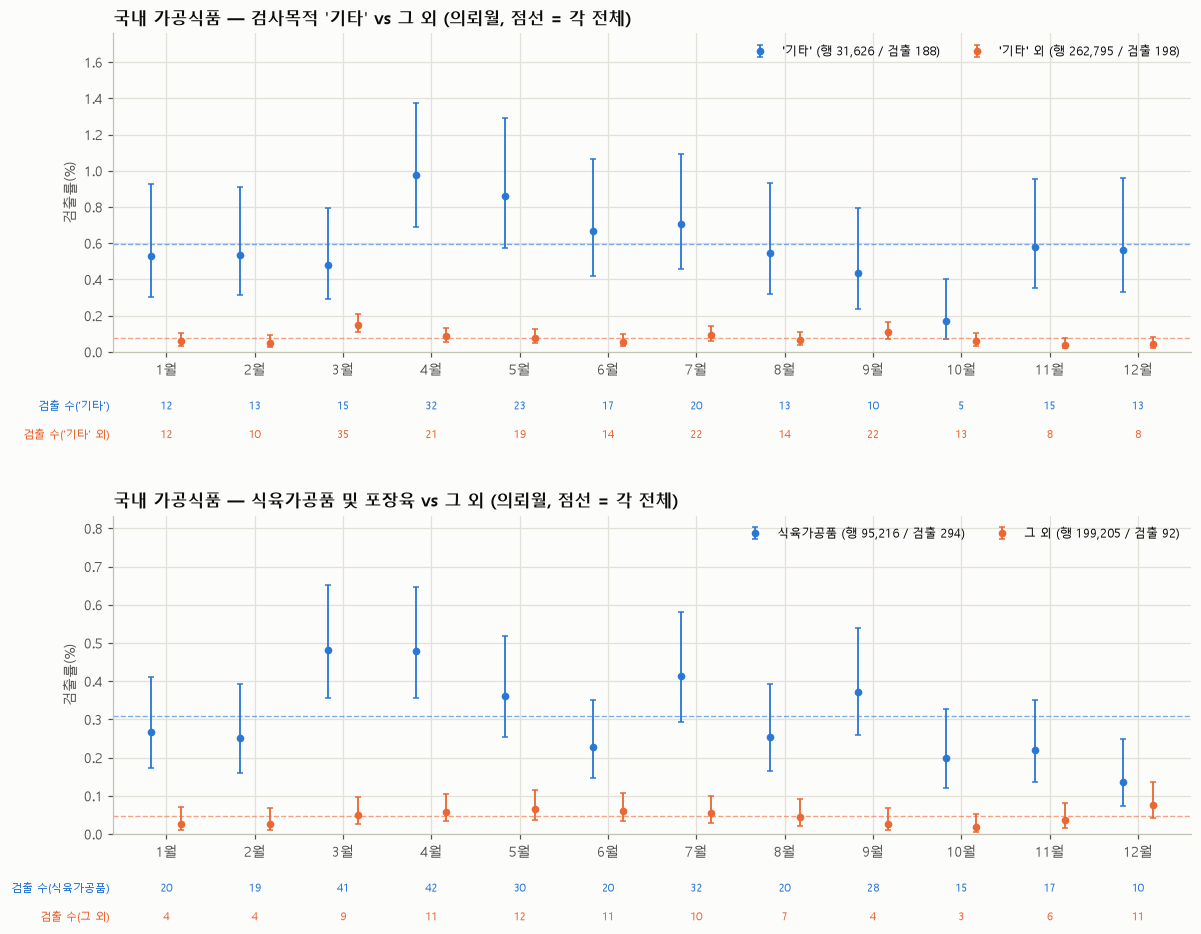

In [75]:
# [6-4 계속] 검사목적 '기타'만 / 식육가공품 및 포장육만 달별 검출률 (의뢰월), 나머지와 나란히
sub_etc = pf[pf['검사목적'].eq('기타')]
sub_non = pf[~pf['검사목적'].eq('기타')]
is_meat = pf['train_prdlst_nm'].isin(['식육가공품 및 포장육'])     # 품목명 결측 행은 '그 외'로 들어감
sub_meat = pf[is_meat]
sub_nomeat = pf[~is_meat]
MT64 = {
    "검사목적 '기타'": month_table(sub_etc, 'reqest_de', "검사목적 '기타'"),
    "검사목적 '기타' 외": month_table(sub_non, 'reqest_de', "검사목적 '기타' 외"),
    '식육가공품 및 포장육': month_table(sub_meat, 'reqest_de', '식육가공품 및 포장육'),
    '그 외 가공식품': month_table(sub_nomeat, 'reqest_de', '그 외 가공식품'),
}
print("\n[검사목적 '기타' vs 그 외]")
display(show_pair(MT64["검사목적 '기타'"], MT64["검사목적 '기타' 외"], "'기타'", "'기타' 외"))
print('\n[식육가공품 및 포장육 vs 그 외 가공식품]')
display(show_pair(MT64['식육가공품 및 포장육'], MT64['그 외 가공식품'], '식육가공품 및 포장육', '그 외 가공식품'))
for name, t in MT64.items():
    print(f'  {name}: {hi_lo_ratio(t)}')

# 민감도(작성자 임의): 식육가공품 및 포장육, 앞뒤가 잘린 해(2016·2026) 뺀 2017~2025년만 달별 검출률
MT64_meat_fy = month_table(meat_fy_use, 'reqest_de', '식육가공품 및 포장육 2017~2025')
print(f'  식육가공품 및 포장육 2017~2025: {hi_lo_ratio(MT64_meat_fy)}')
print('\n[식육가공품 및 포장육: 전체 연도 vs 2017~2025만]')
display(show_pair(MT64['식육가공품 및 포장육'], MT64_meat_fy, '전체 연도', '2017~2025만'))

fig, axes = plt.subplots(2, 1, figsize=(11, 8.6))
plot_months(axes[0], [(MT64["검사목적 '기타'"], "'기타'", C1), (MT64["검사목적 '기타' 외"], "'기타' 외", C2)],
            "국내 가공식품 — 검사목적 '기타' vs 그 외 (의뢰월, 점선 = 각 전체)")
plot_months(axes[1], [(MT64['식육가공품 및 포장육'], '식육가공품', C1), (MT64['그 외 가공식품'], '그 외', C2)],
            '국내 가공식품 — 식육가공품 및 포장육 vs 그 외 (의뢰월, 점선 = 각 전체)')
plt.tight_layout(h_pad=3.5)
plt.show()

📊 **결과**
- 달별 구성 비율의 폭: 검사목적 '기타' 9.4%\~11.9%, 식육가공품 및 포장육 29.6%\~33.9%, 주소출처 '업소주소' 18.4%\~23.6%, 검체성격 '공정시료' 2.8%\~4.2%. '기타'(3월 11.8%·4월 11.9%)와 '업소주소'(3월 23.0%·4월 23.6%)는 3\~4월이 조금 높습니다.
- 검사목적 × 학습용 품목명(131개 층) 구성으로 기대되는 검출과 실제 검출의 비(O/E): 3월 1.34, 4월 1.37, 5월 1.26, **7월 1.32**, 9월 1.10 / 10월 0.62, 11월 0.70, 2월 0.74. 범위 0.62\~1.37 (최고/최저 비 2.21배).
- **검사목적 '기타'만** (31,626행 / 검출 188): 4월 0.976%·5월 0.863% 가 높고 10월 0.172% 가 낮습니다. **'기타' 외** (262,795행 / 검출 198): 3월 0.150% 가 가장 높고 11월 0.038% 가 가장 낮습니다.
- **식육가공품 및 포장육만** (95,216행 / 검출 294): 3월 0.481%·4월 0.479% 가 높고 12월 0.135% 가 가장 낮습니다. **그 외 가공식품** (199,205행 / 검출 92): 10월 0.018% \~ 12월 0.076%.
- 식육가공품 및 포장육 **2017\~2025년만** (88,654행 / 검출 269): 4월 0.508% 가 가장 높고 3월 0.393%, 7월 0.425%, 12월 0.140% 가 가장 낮습니다.

💬 **첨언**
- 3\~4월에 '기타'·'업소주소' 행이 조금 더 많지만, 검사목적 × 품목명 구성을 맞춘 O/E 에서도 3\~5월이 1.26\~1.37 로 남아 **구성 차이만으로 봄 높음이 다 설명되지는 않아 보입니다** (추정). 다만 7월도 1.32 로 봄과 비슷해, "봄만 높다"기보다 "3\~5월·7월이 높고 10월\~2월이 낮다"에 가까워 보입니다 (추정).
- 식육가공품 3월은 2017\~2025년만 보면 0.481% → 0.393% 로 낮아집니다. 2026년 3월 식육가공품 검출 11건(6-3)의 영향으로 보입니다 (추정).
- 다만 작성자가 고른 층에는 주소 출처·업체·검사기관이 들어 있지 않습니다. 이것들까지 맞추면 결과가 달라질 수 있습니다.
- '기타'(4\~5월 높음)와 '기타' 외(3월 높음), 식육가공품(3\~4월 높음)과 그 외(12월 가장 높음)에서 높은 달이 서로 달라, 날씨 한 가지보다는 **검사 일정·검사 사업 같은 행정 요인**이 섞였을 가능성도 있어 보입니다 (추정).

### 6-5. 달별 차이는 얼마나 큰가 — 카이제곱 동질성 검정과 연도별 패턴

🔎 "달마다 검출률이 같다"는 가정에서 지금만큼 차이가 날 가능성을 대략 봅니다.
- scipy 가 없어 카이제곱 분포의 꼬리 확률을 **정규화 불완전 감마 함수**로 직접 계산했습니다 (식은 코드 주석).
- 한계: 같은 업체·같은 의뢰에서 나온 여러 행은 서로 독립이 아닐 수 있습니다. 그러면 p값이 **실제보다 너무 작게** 나올 수 있어, 의뢰 단위·업체-연월 단위로 묶어 다시 계산해 봅니다 (작성자 임의).

In [76]:
# [6-5] 카이제곱 동질성 검정 (2 × m 표: 검출/비검출 × 달 또는 계절)
import math

# 정규화 불완전 감마 함수
#   P(a, x) = γ(a, x) / Γ(a),  Q(a, x) = Γ(a, x) / Γ(a) = 1 − P(a, x)
#   카이제곱(자유도 df) 꼬리확률:  p = Pr(X² ≥ x²) = Q(df/2, x²/2)
#   x < a+1  → 급수:  P(a, x) = e^{−x} x^a / Γ(a+1) · Σ_{n≥0} x^n / [(a+1)(a+2)…(a+n)]
#   x ≥ a+1  → 연분수: Q(a, x) = e^{−x} x^a / Γ(a) · 1 / (x+1−a − 1·(1−a) / (x+3−a − 2·(2−a) / (x+5−a − …)))
#              (수정 Lentz 방법으로 계산. 작은 p 도 1−P 뺄셈 없이 직접 구해 정밀도 손실이 적음)
def gammainc_P_series(a, x, eps=1e-15, itmax=10000):
    ap, term = a, 1.0 / a
    s = term
    for _ in range(itmax):
        ap += 1.0
        term *= x / ap
        s += term
        if abs(term) < abs(s) * eps:
            break
    return s * math.exp(-x + a * math.log(x) - math.lgamma(a))


def gammainc_Q_contfrac(a, x, eps=1e-15, itmax=10000):
    tiny = 1e-300
    b = x + 1.0 - a
    c = 1.0 / tiny
    d = 1.0 / b
    h = d
    for i in range(1, itmax + 1):
        an = -i * (i - a)
        b += 2.0
        d = an * d + b
        d = tiny if abs(d) < tiny else d
        c = b + an / c
        c = tiny if abs(c) < tiny else c
        d = 1.0 / d
        delta = d * c
        h *= delta
        if abs(delta - 1.0) < eps:
            break
    return math.exp(-x + a * math.log(x) - math.lgamma(a)) * h


def gammaincc(a, x):
    '''Q(a, x) 정규화 상부 불완전 감마'''
    if x <= 0:
        return 1.0
    return 1.0 - gammainc_P_series(a, x) if x < a + 1.0 else gammainc_Q_contfrac(a, x)


def chi2_sf(x2, df):
    return gammaincc(df / 2.0, x2 / 2.0)


# 자기 점검: 닫힌 식이 있는 자유도와 비교 (df=1: erfc(√(x/2)), df=2: e^{−x/2}, df=4: e^{−x/2}(1 + x/2))
_err = 0.0
for xv in [0.1, 0.5, 1, 2, 3.84, 7, 10, 20, 50, 100]:
    _err = max(_err, abs(chi2_sf(xv, 1) - math.erfc(math.sqrt(xv / 2))) / max(math.erfc(math.sqrt(xv / 2)), 1e-300),
               abs(chi2_sf(xv, 2) - math.exp(-xv / 2)) / math.exp(-xv / 2),
               abs(chi2_sf(xv, 4) - math.exp(-xv / 2) * (1 + xv / 2)) / (math.exp(-xv / 2) * (1 + xv / 2)))
print(f'꼬리확률 구현 자기 점검 — 닫힌 식과의 최대 상대오차: {_err:.2e}  (참고: 자유도 11, X²=19.675 → p={chi2_sf(19.675, 11):.4f}, 교과서 표 0.05)')


def chi2_homog(k, n):
    '''2 × m 동질성 검정. k=칸별 검출, n=칸별 행 수. 행 0 인 칸은 빼고 알림.
    X² = Σ_칸 Σ_{검출,비검출} (O − E)² / E,  E_검출 = n_m · K/N,  E_비검출 = n_m · (N−K)/N,  df = m − 1
    차이의 크기는 상대 비율(최고 칸 검출률 / 최저 칸 검출률)로 적는다.
    (Cramér V = √(X²/N) 는 검출률이 0.1% 대처럼 드문 결과에서는 칸 사이 비가 2~3배여도 구조적으로 0 에 가깝게 나와
     크기 판단에 맞지 않아 표에서 뺐다 — 작성자 판단)'''
    k, n = np.asarray(k, float), np.asarray(n, float)
    ok = np.isfinite(n) & (n > 0)
    k, n = k[ok], n[ok]
    N, K = n.sum(), k.sum()
    e1, e0 = n * K / N, n * (N - K) / N
    x2 = float((((k - e1) ** 2) / e1).sum() + ((((n - k) - e0) ** 2) / e0).sum())
    df = len(n) - 1
    r = k / n * 100
    return {'칸 수': len(n), '뺀 칸(행 0)': int((~ok).sum()), '행(단위) 수': int(N), '검출': int(K), 'X²': round(x2, 2), '자유도': df,
            'p(근사)': f'{chi2_sf(x2, df):.3g}',
            '기대검출 최소': round(float(e1.min()), 1), '기대검출<5 칸': int((e1 < 5).sum()),
            '최고/최저 검출률(%)': f'{r.max():.3f} / {r.min():.3f}',
            '최고/최저 비': f'{r.max() / r.min():.2f}배' if r.min() > 0 else '-(최저 0)'}


def by_unit(frame, key, unit_col_month='의뢰월'):
    '''행을 key 단위로 묶음: 검출 = 단위 안에 검출 행이 하나라도 있으면 1, 달 = 단위 안 가장 이른 의뢰월 (작성자 임의)'''
    g = frame.groupby(key).agg(pos=('pos', 'max'), 의뢰월=(unit_col_month, 'min'))
    return g


tests = {}
for gname in GRP6:
    for bname in BASIS6:
        t = MT6[(gname, bname)]
        tests[f'{gname} / {bname} 12칸 (행)'] = chi2_homog(t['검출'], t['행 수'])
g4 = pf.groupby('계절', observed=True)['pos'].agg(['sum', 'size'])
tests['국내 가공식품(C) / 의뢰 계절 4칸 (행)'] = chi2_homog(g4['sum'], g4['size'])
for gname in GROUPS4:
    t = st6.loc[gname]
    tests[f'{gname} / 의뢰 계절 4칸 (행)'] = chi2_homog(t['검출'], t['행 수'])
for name, t in MT64.items():
    tests[f'{name} / 의뢰월 12칸 (행)'] = chi2_homog(t['검출'], t['행 수'])
tests['국내 가공식품(C) 상위5 업체 제외 / 의뢰월 12칸 (행)'] = chi2_homog(mt_ex5['검출'], mt_ex5['행 수'])
full_y = pf[pf['연'].between(2017, 2025)]
print(f"완전한 해(2017~2025)만: {len(full_y):,}행 사용 (2016·2026 {len(pf) - len(full_y):,}행, 검출 {int(pf['pos'].sum() - full_y['pos'].sum())} 뺌)")
mt_fy = month_table(full_y, 'reqest_de', '2017~2025 의뢰월', verbose=False)
tests['국내 가공식품(C) 2017~2025만 / 의뢰월 12칸 (행)'] = chi2_homog(mt_fy['검출'], mt_fy['행 수'])
tests['식육가공품 및 포장육 2017~2025만 / 의뢰 계절 4칸 (행)'] = chi2_homog(st6_meat_fy['검출'], st6_meat_fy['행 수'])
tests['식육가공품 및 포장육 2017~2025만 / 의뢰월 12칸 (행)'] = chi2_homog(MT64_meat_fy['검출'], MT64_meat_fy['행 수'])

# 군집 민감도: 의뢰 단위, 업체-연월 단위로 묶어서 (식별 불가 업체 행은 업체-연월 단위에서 뺌)
u_req = by_unit(pf, '의뢰키')
gq = u_req.groupby('의뢰월')['pos'].agg(['sum', 'size'])
tests['국내 가공식품(C) / 의뢰월 12칸 (의뢰 단위)'] = chi2_homog(gq['sum'], gq['size'])
pf_id = pf[pf['업체키'].ne('식별 불가')]
print(f"업체-연월 단위: 업체 식별 불가 {len(pf) - len(pf_id):,}행 (검출 {int(pf['pos'].sum() - pf_id['pos'].sum())}) 뺌")
u_fm = pf_id.groupby(['업체키', '연', '의뢰월']).agg(pos=('pos', 'max')).reset_index()
gf = u_fm.groupby('의뢰월')['pos'].agg(['sum', 'size'])
tests['국내 가공식품(C) / 의뢰월 12칸 (업체-연월 단위)'] = chi2_homog(gf['sum'], gf['size'])
print(f"의뢰 단위 {len(u_req):,}개(검출 의뢰 {int(u_req['pos'].sum())}), 업체-연월 단위 {len(u_fm):,}개(검출 {int(u_fm['pos'].sum())})")
# 식별 불가 행을 빼지 않는 변형(작성자 임의): 식별된 행은 업체-연월 단위, 식별 불가 행은 의뢰키 단위로 남김 (묶음 라벨만, 업체 추정 없음)
# 한 의뢰키 안 의뢰월은 하나뿐(위 6-3 출력)이라 의뢰키 단위의 달은 그대로 정해짐
mix_key = np.where(pf['업체키'].ne('식별 불가'),
                   pf['업체키'] + '|' + pf['연'].astype(str) + '|' + pf['의뢰월'].astype(str),
                   '의뢰:' + pf['의뢰키'].astype(str))
u_mix = pf.assign(_unit=mix_key).groupby('_unit').agg(pos=('pos', 'max'), 의뢰월=('의뢰월', 'min'))
gm = u_mix.groupby('의뢰월')['pos'].agg(['sum', 'size'])
tests['국내 가공식품(C) / 의뢰월 12칸 (업체-연월 + 식별 불가는 의뢰 단위)'] = chi2_homog(gm['sum'], gm['size'])
print(f"업체-연월 + 식별 불가 의뢰 단위: {len(u_mix):,}개(검출 {int(u_mix['pos'].sum())}), 뺀 행 0")
chi6 = pd.DataFrame(tests).T
chi6

꼬리확률 구현 자기 점검 — 닫힌 식과의 최대 상대오차: 1.80e-15  (참고: 자유도 11, X²=19.675 → p=0.0500, 교과서 표 0.05)
완전한 해(2017~2025)만: 273,641행 사용 (2016·2026 20,780행, 검출 31 뺌)
업체-연월 단위: 업체 식별 불가 60,160행 (검출 128) 뺌
의뢰 단위 209,155개(검출 의뢰 360), 업체-연월 단위 110,519개(검출 230)
업체-연월 + 식별 불가 의뢰 단위: 146,055개(검출 343), 뺀 행 0


,칸 수,뺀 칸(행 0),행(단위) 수,검출,X²,자유도,p(근사),기대검출 최소,기대검출<5 칸,최고/최저 검출률(%),최고/최저 비
국내 가공식품(C) / 제조월 12칸 (행),12,0,222607,288,29.75,11,0.00173,22.3,0,0.205 / 0.075,2.73배
국내 가공식품(C) / 의뢰월 12칸 (행),12,0,294421,386,32.11,11,0.000733,28.7,0,0.193 / 0.073,2.63배
국내 원물(통계용 분류) / 제조월 12칸 (행),12,0,1324,8,13.51,11,0.261,0.2,12,2.439 / 0.000,-(최저 0)
국내 원물(통계용 분류) / 의뢰월 12칸 (행),12,0,3533,27,11.88,11,0.372,0.7,12,2.273 / 0.000,-(최저 0)
국내 기준규격외(Z) / 제조월 12칸 (행),12,0,65199,299,139.22,11,2.34e-24,22.0,0,1.127 / 0.161,7.00배
국내 기준규격외(Z) / 의뢰월 12칸 (행),12,0,320536,1431,246.25,11,1.71e-46,95.1,0,0.754 / 0.200,3.77배
국내 가공식품(C) / 의뢰 계절 4칸 (행),4,0,294421,386,23.31,3,3.48e-05,87.3,0,0.180 / 0.102,1.77배
식육가공품 및 포장육 / 의뢰 계절 4칸 (행),4,0,95216,294,22.37,3,5.46e-05,69.3,0,0.442 / 0.218,2.02배
즉석식품류 / 의뢰 계절 4칸 (행),4,0,35322,45,5.08,3,0.166,10.5,0,0.197 / 0.097,2.04배
유가공품류 / 의뢰 계절 4칸 (행),4,0,78292,6,4.89,3,0.18,1.3,4,0.018 / 0.000,-(최저 0)


In [77]:
# [6-5 계속] 연도마다 달 패턴이 비슷한가 — 완전한 해(2017~2025)만 (2016 은 3월부터, 2026 은 7월까지라 뺌: 작성자 임의)
# 순위 상관(Spearman) = 두 벡터를 각각 순위(동점은 평균 순위)로 바꾼 뒤 피어슨 상관
#   ρ = Σ (R_i − R̄)(S_i − S̄) / √(Σ (R_i − R̄)² · Σ (S_i − S̄)²)
YEARS = list(range(2017, 2026))
yy = pf[pf['연'].isin(YEARS)]
print(f'연도별 패턴 계산: 2017~2025 {len(yy):,}행 / 검출 {int(yy["pos"].sum())} (그 밖의 해 {len(pf) - len(yy):,}행, 검출 {int(pf["pos"].sum() - yy["pos"].sum())} 뺌)')
kmat = yy.pivot_table(index='연', columns='의뢰월', values='pos', aggfunc='sum').reindex(index=YEARS, columns=MONTHS)
nmat = yy.pivot_table(index='연', columns='의뢰월', values='pos', aggfunc='size').reindex(index=YEARS, columns=MONTHS)
rmat = kmat / nmat * 100
print(f'연·월 칸의 검출 수: 중앙값 {np.nanmedian(kmat.to_numpy()):.0f}, 0 인 칸 {int((kmat == 0).sum().sum())} / {kmat.size}')


def rank_avg(v):
    return pd.Series(v).rank(method='average').to_numpy()


def pearson(a, b):
    a, b = a - a.mean(), b - b.mean()
    den = math.sqrt((a * a).sum() * (b * b).sum())
    return float((a * b).sum() / den) if den > 0 else np.nan


rows = []
for y in YEARS:
    rest_k = kmat.drop(index=y).sum()
    rest_n = nmat.drop(index=y).sum()
    rest_r = (rest_k / rest_n * 100).to_numpy()
    rho = pearson(rank_avg(rmat.loc[y].to_numpy()), rank_avg(rest_r))
    ys = yy[yy['연'].eq(y)].groupby('계절', observed=True)['pos'].agg(['sum', 'size'])
    sr = (ys['sum'] / ys['size'] * 100)
    rows.append({'연': y, '행 수': int(nmat.loc[y].sum()), '검출': int(kmat.loc[y].sum()),
                 **{f'{s} 검출률(%)': round(sr.get(s, np.nan), 3) for s in SEASONS},
                 '검출률 가장 높은 계절': sr.idxmax(), '나머지 해와 달 순위상관': round(rho, 2)})
yr6 = pd.DataFrame(rows).set_index('연')
display(yr6)

# 해끼리 모든 쌍(36쌍)의 순위상관 평균과, 해마다 달 순서를 무작위로 섞었을 때의 분포 (순열, 작성자 임의: 5,000회, seed 6)
# 순열 비율의 몬테카를로 오차(표준오차) ≈ √(p̂(1−p̂)/B), B = 순열 횟수 → 비율은 소수 둘째 자리까지만 봄
R = np.vstack([rank_avg(rmat.loc[y].to_numpy()) for y in YEARS])


def mean_pair_rho(Rm):
    Z = Rm - Rm.mean(axis=1, keepdims=True)
    Z = Z / np.sqrt((Z ** 2).sum(axis=1, keepdims=True))
    C = Z @ Z.T
    iu = np.triu_indices(len(Rm), 1)
    return float(C[iu].mean())


obs = mean_pair_rho(R)
rng = np.random.default_rng(6)
B_PERM = 5000
null = np.array([mean_pair_rho(np.vstack([rng.permutation(r) for r in R])) for _ in range(B_PERM)])
p_perm = float(np.mean(null >= obs))
print(f'해끼리 달 검출률 순위상관 평균(36쌍): {obs:.3f}')
print(f'달 순서를 섞었을 때({B_PERM:,}회) 평균: {null.mean():.3f}, 95백분위 {np.percentile(null, 95):.3f}, '
      f'관측값 이상 비율 {p_perm:.2f} (몬테카를로 표준오차 약 {math.sqrt(p_perm * (1 - p_perm) / B_PERM):.3f})')

연도별 패턴 계산: 2017~2025 273,641행 / 검출 355 (그 밖의 해 20,780행, 검출 31 뺌)
연·월 칸의 검출 수: 중앙값 3, 0 인 칸 9 / 108


,행 수,검출,봄(3~5월) 검출률(%),여름(6~8월) 검출률(%),가을(9~11월) 검출률(%),겨울(12~2월) 검출률(%),검출률 가장 높은 계절,나머지 해와 달 순위상관
연,,,,,,,,
2017,26034,27,0.069,0.041,0.191,0.121,가을(9~11월),-0.14
2018,28042,37,0.185,0.165,0.081,0.094,봄(3~5월),0.38
2019,31974,38,0.146,0.106,0.126,0.096,봄(3~5월),0.15
2020,32509,30,0.118,0.130,0.061,0.054,여름(6~8월),0.48
2021,30829,53,0.252,0.135,0.173,0.124,봄(3~5월),0.36
2022,31688,33,0.155,0.120,0.038,0.099,봄(3~5월),0.18
2023,30689,49,0.154,0.163,0.154,0.168,겨울(12~2월),-0.07
2024,30857,47,0.293,0.151,0.054,0.096,봄(3~5월),0.43
2025,31019,41,0.177,0.202,0.055,0.082,여름(6~8월),-0.01


해끼리 달 검출률 순위상관 평균(36쌍): 0.077
달 순서를 섞었을 때(5,000회) 평균: -0.000, 95백분위 0.092, 관측값 이상 비율 0.07 (몬테카를로 표준오차 약 0.004)


📊 **결과**
- **국내 가공식품 의뢰월 12칸**: X² 32.11, 자유도 11, p(근사) 0.000733, 최고/최저 검출률 0.193 / 0.073% (2.63배). 제조월 12칸: X² 29.75, p 0.00173 (2.73배).
- 묶어서 다시 계산:
  - 의뢰 단위(209,155개, 검출 의뢰 360) X² 26.42, p 0.00562
  - 업체-연월 단위(110,519개, 검출 230; 업체 식별 불가 60,160행·검출 128 뺌) X² 33.41, p 0.000451
  - 업체-연월 + 식별 불가 행은 의뢰 단위로 남김(146,055개, 검출 343, 뺀 행 0) X² 24.77, p 0.00986
  - 2017\~2025년만 X² 27.93, p 0.00332 / 상위 5 업체 제외 X² 27.59, p 0.00374
- 계절 4칸: 식육가공품 및 포장육 X² 22.37, p 5.46e-05 (2.02배), 2017\~2025년만 X² 16.27, p 0.001 (1.92배) / 즉석식품류 p 0.166 / 수산가공식품류 p 0.137 / 유가공품류 p 0.18 (기대검출 5 미만 칸 4개라 근사가 부정확). 원물(통계용 분류) 의뢰월 12칸은 p 0.372 이지만 12칸 모두 기대검출 5 미만입니다.
- 달 12칸: 식육가공품 및 포장육 X² 37.06, p 0.000113 (3.55배), 2017\~2025년만 X² 32.86, p 0.000555 (3.63배) / 검사목적 '기타'만 X² 23.12, p 0.017 (5.68배) / 그 외 가공식품(식육가공품 제외) X² 12.91, p 0.299.
- **연도별 모양 (2017\~2025)**: 봄이 가장 높은 해는 2018·2019·2021·2022·2024, 여름은 2020·2025, 가을은 2017, 겨울은 2023. 연·월 칸 검출 수 중앙값 3. 해끼리 달 검출률 순위상관 평균 0.077 — 달 순서를 무작위로 섞었을 때(5,000회) 평균 -0.000, 95백분위 0.092, 관측값 이상 비율 0.07 (몬테카를로 표준오차 약 0.004).

💬 **첨언**
- 작성자가 행·의뢰·업체-연월 단위로 계산해 본 결과, 국내 가공식품의 달별 차이는 p값이 모두 작게(0.00986 이하) 나옵니다. 검출 행/의뢰가 1.00\~1.24(6-3)라 의뢰 단위 군집은 크지 않아 보입니다 (추정).
- **차이의 크기**는 상대 비율로 보았습니다: 가장 높은 달이 가장 낮은 달의 2.63배(의뢰월), O/E 는 0.62\~1.37(6-4), 식육가공품 봄 ÷ 겨울 2.02배. 검출률 자체가 0.1% 대로 낮아 절대 차이(%p)는 작지만, 상대 차이는 작다고 보기 어려워 보입니다 (추정). 다만 12개 달 중 양 끝을 고른 비라 우연한 흔들림도 함께 커 보입니다.
  - 참고: 크기 지표 Cramér V(√(X²/N))는 검출이 드문 결과에서 비가 2\~3배여도 구조적으로 0 에 가깝게 나와, 크기 판단에 맞지 않아 표에서 뺐습니다 (작성자 판단).
- 한계: 같은 검사기관·같은 검사 사업이 한 달에 몰리는 군집은 반영하지 못했고, 여러 표를 한꺼번에 검정했으므로 p값은 참고용으로만 보는 편이 안전해 보입니다.
- 해마다 같은 달 모양이 되풀이되는지는 **판단하기 어렵습니다**: 순위상관 평균 0.077 은 무작위 평균(약 0)보다 위에 있고, 순열 비율 0.07 로 경계 근처입니다. 비슷한 모양이 조금 있을 수도 있으나, 연·월 칸 검출 수가 중앙값 3 이라 검정력이 낮습니다 (추정).
- 원물(통계용 분류)은 칸마다 기대검출이 5 미만이라 이 검정으로는 판단하기 어렵습니다.

In [78]:
# [6-5 계속] 정리용: 이 절의 분류로 본 국내 타겟 범위 후보별 행·검출 수 (분류는 대분류 코드·train_prdlst_nm 그대로, 후보 묶음은 작성자 임의)
pf_all = d6[GRP6['국내 가공식품(C)']]
K_pf = int(pf_all['pos'].sum())
cand = {
    '국내 가공식품(C) 전체': pf_all,
    '  └ 식육가공품 및 포장육': pf[pf['군'].eq('식육가공품 및 포장육')],
    '  └ 즉석식품류': pf[pf['군'].eq('즉석식품류')],
    '  └ 수산가공식품류': pf[pf['군'].eq('수산가공식품류')],
    '  └ 유가공품류': pf[pf['군'].eq('유가공품류')],
    '  └ 그 외 가공식품': pf[pf['군'].eq('그 외 가공식품')],
    '국내 원물(통계용 분류)': d6[GRP6['국내 원물(통계용 분류)']],
    '국내 기준규격외(Z)': d6[GRP6['국내 기준규격외(Z)']],
}
scope6 = pd.DataFrame({name: {'행 수': len(f), '검출': int(f['pos'].sum()), '검출률(%)': round(f['pos'].mean() * 100, 3)}
                       for name, f in cand.items()}).T
scope6[['행 수', '검출']] = scope6[['행 수', '검출']].astype(int)
scope6['국내 가공식품 검출 중 비중(%)'] = [f'{k / K_pf * 100:.1f}' if i < 6 else '-' for i, k in enumerate(scope6['검출'])]
scope6

,행 수,검출,검출률(%),국내 가공식품 검출 중 비중(%)
국내 가공식품(C) 전체,294421,386,0.131,100.0
└ 식육가공품 및 포장육,95216,294,0.309,76.2
└ 즉석식품류,35322,45,0.127,11.7
└ 수산가공식품류,4637,29,0.625,7.5
└ 유가공품류,78292,6,0.008,1.6
└ 그 외 가공식품,80954,12,0.015,3.1
국내 원물(통계용 분류),3533,27,0.764,-
국내 기준규격외(Z),320536,1431,0.446,-


### 6장 정리 (추정)

**달별 모양**
- 작성자가 임의로 달·계절로 묶어 본 결과, 국내 가공식품 검출률은 **3\~5월(과 7월)이 높고 10월\~2월이 낮은 차이가 있어 보입니다** (추정). 가장 높은 달은 가장 낮은 달의 2.63배(의뢰월)이고, 검사목적 × 품목명 구성을 맞춘 O/E 도 0.62\~1.37 입니다.
- 상위 5 업체를 빼도 이 모양은 남았고(6-3), 의뢰 단위·업체-연월 단위·2017\~2025년만으로 계산해도 달별 차이의 p값은 0.00986 이하였습니다(6-5). 다만 검사기관·검사 사업 단위 군집은 반영하지 못했습니다.
  - 10-2 에서 같은 O/E 를 검사기관 층과 행 범위(완전한 해만, 같은 곳 30일 안 행 뺌, 의뢰 단위)를 바꿔 다시 셉니다. 3월·7월 높음은 부분 연도·같은 곳 몰림에 기대 보였습니다 (추정, 10-2).

**기상 연관에 주는 뜻 — 이 절만으로는 판단할 수 없음**
- 달 평균 모양은 가장 높은 달이 4월이고 8월은 0.115% 로 낮은 편이어서, "기온이 높을수록 검출률이 높다"는 **단순한 가정과는 맞지 않아 보입니다** (추정). 다만 7월 O/E 는 1.32 로 봄과 비슷합니다.
  - 이 달 사이 모양(봄 최고)과 7절의 같은 달 안 기온 방향(양의 계수)을 함께 읽은 계산은 7-5-3 에 있습니다.
- 달력 달 단위 평균에는 일별·해별·지역별 기상 편차(이상 기온, 습도, 일교차·결로, 제조일 전 며칠 창)가 드러나지 않습니다. 그래서 **달 모양만으로 기상 연관이 있다·없다를 판단할 수 없고**, 기상값을 붙인 7절 결과와 전문가 의견이 필요합니다.
- 달 모양을 흐리는 요인도 보입니다 (추정):
  - 차이를 끌고 가는 것은 주로 식육가공품 및 포장육(검출 294건)이고, 즉석식품류·수산가공식품류·유가공품류는 검출이 적어 계절 차이를 판단하기 어렵습니다.
  - 해마다 같은 모양이 되풀이되는지는 검출이 적어 판단하기 어렵습니다 (순위상관 평균 0.077, 순열 비율 0.07).
  - 검사목적 '기타'와 그 외, 식육가공품과 그 외에서 높은 달이 서로 달라, 검사 일정 같은 행정 요인이 섞였을 수 있습니다. 2026년 3월 검출 12건 중 6건이 수거검사였습니다.

**타겟 범위에 주는 뜻 (추정, 결정은 전문가 질문으로)**
- 국내 가공식품(C) 294,421행 / 검출 386 중 **식육가공품 및 포장육이 294건(76.2%)** 입니다. '가공식품 + 기상'에서 무언가 보인다면 대부분 이 군에서 나올 가능성이 있어 보입니다 (추정). 식육가공품 및 포장육만 따로 두는 범위 후보를 생각해 볼 수 있습니다 (8절에서 비가열 G1·가열 G2 로 나눠 봄).
- 유가공품류(78,292행 / 검출 6)·그 외 가공식품(80,954행 / 검출 12)은 검출이 너무 적어, 달·기상 차이를 볼 근거로는 약해 보입니다 (추정).
- 메모 도메인1 처럼 가공식품을 모두 빼고 **원물(통계용 분류)만 남기면 국내 3,533행 / 검출 27** 입니다. 달마다 검출 0\~4건이라 기상 연관을 보기에는 표본이 매우 작습니다. (참고: 제품명 기준으로 원물을 넓게 잡으면 국내 53,784행·검출 688 이지만 팽이버섯·원료육이 대부분이고 작성자 정규식이라 검증 전 — 2.ipynb 3-6-2. 최소가공 경계와 제품명 기준 원물의 규모·계절은 8절)
- 기준규격외(Z) 320,536행 / 검출 1,431 은 6\~12월이 높아 보이지만 (추정) 팽이버섯 수출검사·공정 시료가 섞인 코드라, 범위에 넣을지는 따로 정할 문제입니다.
- 가공식품을 범위에 넣고 달·계절 같은 날짜 피처를 쓰면, 모델이 기상보다 **검사 일정(어느 달에 어떤 검사가 몰리는지)** 을 배울 위험이 있어 보입니다 (추정).
- 이 절은 날짜만 봤고 기상값은 붙이지 않았습니다.

❓ **도메인 전문가께**
- 국내 식육가공품 및 포장육의 검출률이 봄(3\~5월) 0.442% 로 겨울 0.218% 보다 높게 보입니다 (2017\~2025년만 0.418% / 0.217%). 원료육 수급, 공장 안 결로·습도, 작업량 변화 같은 알려진 봄철 요인이 있습니까? 아니면 여름이 더 높아야 자연스럽습니까?
- 가열·포장한 가공식품의 검출이 **공장 밖 날씨(기온·습도)** 와 이어질 경로가 있다고 보십니까? 있다면 어떤 군(식육가공품·즉석식품·수산가공식품 등)에서, 제조일 전 며칠 창으로 보는 것이 맞습니까?
- 수산가공식품류가 여름에 높게(12건) 보이는 것은 알려진 경향입니까?
- 타겟 범위: 국내 가공식품 검출 386건 중 294건이 식육가공품 및 포장육입니다. 기상 연관을 볼 때 (a) 가공식품 전체를 하나로, (b) 식육가공품 및 포장육만 따로, (c) 가공식품을 빼고 원물만 — 중 어느 쪽이 맞다고 보십니까?
- 원물(통계용 분류)만 남기면 국내 검출이 27건뿐입니다. 이 정도 규모로도 원물만 범위로 두는 것이 괜찮습니까, 아니면 식육가공품처럼 원재료·공정 환경의 영향이 남는 가공식품 군을 함께 두는 편이 낫습니까? (8절(최소가공 경계) 참고)

🗄️ **데이터 담당자께**
- 3\~5월에 국내 가공식품 검출이 많은 것이 검사 일정(계획 수거·자가품질검사 주기·특별 점검 등) 때문일 수 있습니까? 검사목적 '기타'(자체의뢰)의 달별 의뢰 계획·사업 자료가 있습니까?
- 2026년 3월 국내 가공식품 검출 12건(검출 의뢰 12개, 업체 10곳) 중 수거검사가 6건, 식육가공품이 11건입니다. 이 달에 식육가공품 대상 집중 수거 점검이나 사건이 있었습니까?
- `lims_data_key` 의 앞 두 조각(예: `O000084_210102358`)을 "같은 의뢰"로 봐도 됩니까?
- 국내 가공식품 검출 행의 33.2%(4월은 50.9%)가 영업허가번호·제조회사명이 모두 없습니다(그 128행 중 127행이 주소출처 '업소주소'). 업체를 식별할 다른 컬럼이 있습니까?

## 7. 기상값을 붙여 본 탐색 — 기온·습도와 검출률 (작성자 임의 방법)

🔎 기상 시계열을 **실제로 행에 붙여 보면** 몇 행이 붙고, 붙인 값(기온·습도)과 검출률 사이에 어떤 모습이 보이는지 봅니다.
- 국내 가공식품이 중심이고, 국내 원물(통계용 분류)과 국내 기준규격외(Z)를 나란히 놓고 비교합니다.
- 아래 연결 방법은 모두 **작성자 임의 방법**입니다(전문가·담당자 승인 전). 기상값은 원자료 그대로이고, 결측은 채우지 않습니다.
  - 관측소: 행 좌표에서 가장 가까운 관측소 1곳 (ASOS 99곳 / 농업기상 219곳 후보)
  - 기준 날짜: A = 원본 제조일(`mnfctur_de_raw`), B = 의뢰일(`reqest_de`)
  - 기상 창: 7일(6일 전\~당일), 30일(29일 전\~당일)의 일평균값 평균. 창 안 모든 날에 값이 있을 때만 계산

In [79]:
# [7-1] 분석 대상과 관측소 연결 — 작성자 임의 방법: 행 좌표(lat, lon)에서 가장 가까운 관측소 1곳 (haversine_km, 좌표 고유값 단위)
W7_GROUPS = ['국내 가공식품', '국내 원물(통계용 분류)', '국내 기준규격외']
_dom = dfx['국내해외'].eq('국내')
_grp = np.select([_dom & dfx['대분류'].eq('가공식품'),
                  _dom & dfx['대분류'].isin(['농산물(원물)', '축산물(원물)', '수산물(원물)']),
                  _dom & dfx['대분류'].eq('기준규격외(검체)')], W7_GROUPS, '')
_m = _grp != ''
w7 = dfx.loc[_m, ['pos', 'lat', 'lon', 'mnfctur_de_raw', 'reqest_de', 'bsn_lcns_ledg_no', 'mnfctur_cmpny_nm']].copy()
w7['그룹'] = pd.Categorical(_grp[_m], categories=W7_GROUPS)
print(f'분석 대상(국내 3그룹) {len(w7):,}행 / 이 절에서 뺀 행 {len(dfx) - len(w7):,}행 (해외 전체 + 국내 기타 대분류)')
display(w7.groupby('그룹', observed=True)['pos'].agg(행수='size', 검출='sum'))

# ASOS 관측소 후보: 일자료에 한 번이라도 나오는 stn_id. 관측소 정보에 같은 stn_id 가 여러 행이면 사실 출력 + 좌표 차이 확인
_ids = asos['stn_id'].dropna().unique()
_st = asos_stn[asos_stn['stn_id'].isin(_ids)].sort_values(['stn_id', 'oper_start_dt'], na_position='first').copy()
_nrow = _st.groupby('stn_id').size()
print(f"ASOS 후보 {len(_ids)}곳 — 관측소 정보(asos_stn)에 여러 행인 stn_id {int((_nrow > 1).sum())}곳 (최대 {int(_nrow.max())}행), 정보에 없는 곳 {len(set(_ids) - set(_st['stn_id']))}곳")
# 작성자 임의: 여러 행이면 운영 시작일이 가장 늦은 행(마지막 위치)의 좌표를 씀
_last = _st.groupby('stn_id').tail(1).set_index('stn_id')
_st['차이_km'] = haversine_km(_st['lat'].values, _st['lon'].values,
                            _last.loc[_st['stn_id'], 'lat'].values, _last.loc[_st['stn_id'], 'lon'].values)
_spread = _st.groupby('stn_id')['차이_km'].max()
print(f'  같은 stn_id 행끼리 좌표 차이(마지막 행 기준 최대): 0.1km 이하 {int((_spread <= 0.1).sum())}곳, '
      f'0.1~1km {int(((_spread > 0.1) & (_spread <= 1)).sum())}곳, 1km 초과 {int((_spread > 1).sum())}곳')
_far = _spread[_spread > 1].round(1).rename('최대 좌표 차이(km)').to_frame()
_far['관측소'] = _last.loc[_far.index, 'stn_ko']
_far['행 수'] = _nrow.loc[_far.index]
display(_far)

# 농업기상 후보: 일자료에 나오는 obsr_spot_code
_nids = nas['obsr_spot_code'].dropna().unique()
_nst = nas_stn[nas_stn['obsr_spot_code'].isin(_nids)]
print(f"농업기상 후보 {len(_nids)}곳 — 관측소 정보에 여러 행인 코드 {int(_nst['obsr_spot_code'].duplicated().sum())}곳, 좌표 결측 {int(_nst['instl_la'].isna().sum() + _nst['instl_lo'].isna().sum())}")
_nst = _nst.drop_duplicates('obsr_spot_code')


def w7_nearest(uc, ids, slat, slon):
    '''좌표 고유값(uc) × 관측소 거리 행렬에서 최근접 1곳 (작성자 임의 방법)'''
    d = haversine_km(uc['lat'].values[:, None], uc['lon'].values[:, None], slat[None, :], slon[None, :])
    j = d.argmin(axis=1)
    return pd.DataFrame({'lat': uc['lat'].values, 'lon': uc['lon'].values, 'stn': ids[j], 'km': d[np.arange(len(j)), j]})


_uc = w7[['lat', 'lon']].dropna().drop_duplicates()
print(f'좌표 고유값 {len(_uc):,}개 / 좌표 없는 행 {int((w7["lat"].isna() | w7["lon"].isna()).sum()):,}행')
_na = w7_nearest(_uc, _last.index.to_numpy(), _last['lat'].to_numpy(), _last['lon'].to_numpy())
_nn = w7_nearest(_uc, _nst['obsr_spot_code'].to_numpy(), _nst['instl_la'].to_numpy(), _nst['instl_lo'].to_numpy())
for _tag, _near in [('asos', _na), ('nas', _nn)]:
    _mm = w7[['lat', 'lon']].merge(_near, on=['lat', 'lon'], how='left', validate='many_to_one')
    assert len(_mm) == len(w7)
    w7[f'{_tag}_stn'] = _mm['stn'].values
    w7[f'{_tag}_km'] = _mm['km'].values

_dist = []
for _g in W7_GROUPS:
    _s = w7[w7['그룹'] == _g]
    for _tag, _nm in [('asos', 'ASOS'), ('nas', '농업기상')]:
        _k = _s[f'{_tag}_km'].dropna()
        _dist.append({'그룹': _g, '관측소': _nm, '좌표 있는 행': len(_k), '중앙값(km)': round(_k.median(), 1),
                      'p75(km)': round(_k.quantile(.75), 1), 'p95(km)': round(_k.quantile(.95), 1), '최대(km)': round(_k.max(), 1),
                      '20km 이내(%)': round((_k <= 20).mean() * 100, 1), '연결 관측소 수': _s[f'{_tag}_stn'].nunique()})
print('최근접 관측소까지 거리')
pd.DataFrame(_dist)

분석 대상(국내 3그룹) 618,490행 / 이 절에서 뺀 행 58,047행 (해외 전체 + 국내 기타 대분류)


,행수,검출
그룹,,
국내 가공식품,294421,386
국내 원물(통계용 분류),3533,27
국내 기준규격외,320536,1431


ASOS 후보 99곳 — 관측소 정보(asos_stn)에 여러 행인 stn_id 97곳 (최대 4행), 정보에 없는 곳 0곳
  같은 stn_id 행끼리 좌표 차이(마지막 행 기준 최대): 0.1km 이하 81곳, 0.1~1km 3곳, 1km 초과 15곳


,최대 좌표 차이(km),관측소,행 수
stn_id,,,
100,3.7,대관령,3
102,7.2,백령도,3
119,1.7,수원,3
140,5.2,군산,3
143,5.5,대구,3
146,4.0,전주,3
152,2.8,울산,4
155,2.3,창원,4
181,1.1,서청주,3


농업기상 후보 219곳 — 관측소 정보에 여러 행인 코드 0곳, 좌표 결측 0
좌표 고유값 3,502개 / 좌표 없는 행 0행
최근접 관측소까지 거리


,그룹,관측소,좌표 있는 행,중앙값(km),p75(km),p95(km),최대(km),20km 이내(%),연결 관측소 수
0,국내 가공식품,ASOS,294421,13.9,19.9,27.8,31.9,75.6,97
1,국내 가공식품,농업기상,294421,8.7,12.4,18.5,142.4,97.2,205
2,국내 원물(통계용 분류),ASOS,3533,6.4,11.1,22.6,54.5,92.7,85
3,국내 원물(통계용 분류),농업기상,3533,11.3,16.4,16.9,56.5,98.8,134
4,국내 기준규격외,ASOS,320536,14.3,20.3,27.7,54.5,73.5,97
5,국내 기준규격외,농업기상,320536,8.7,11.9,17.0,142.4,97.7,209


In [80]:
# [7-1] 기상 창 평균 붙이기 — 작성자 임의 방법: 7일·30일 창, 창 안 모든 날에 값이 있을 때만 평균 (채우지 않음)
# 구현: 관측소별 날짜 달력으로 reindex(빠진 날 NaN 유지) → rolling(window, min_periods=window).mean() → (관측소, 기준 날짜)로 조회
W7_BASIS = {'A': 'mnfctur_de_raw', 'B': 'reqest_de'}
W7_BASIS_NM = {'A': 'A 원본 제조일', 'B': 'B 의뢰일'}
W7_WIN = [7, 30]
W7_VARS = [('ASOS', 'asos', 'avg_ta'), ('ASOS', 'asos', 'avg_rhm'), ('농업기상', 'nas', 'temp'), ('농업기상', 'nas', 'hum')]

for _b, _bc in W7_BASIS.items():
    _d = w7[_bc]
    print(f'기준 {W7_BASIS_NM[_b]}: 값 있는 행 {int(_d.notna().sum()):,} / 범위 {_d.min():%Y-%m-%d} ~ {_d.max():%Y-%m-%d}')

_out_range = {}
# 검사 기간 = 두 기준 날짜 중 가장 이른 날의 29일 전 ~ 가장 늦은 날 (30일 창이 닿는 범위)
_p0 = min(w7['mnfctur_de_raw'].min(), w7['reqest_de'].min()) - pd.Timedelta(days=29)
_p1 = max(w7['mnfctur_de_raw'].max(), w7['reqest_de'].max())
print(f'검사 기간(창이 닿는 범위): {_p0:%Y-%m-%d} ~ {_p1:%Y-%m-%d}')
for _src, _tag, _var in W7_VARS:
    _daily = asos if _tag == 'asos' else nas
    _key = 'stn_id' if _tag == 'asos' else 'obsr_spot_code'
    _piv = _daily.pivot(index='meas_date', columns=_key, values=_var)
    _cal = pd.date_range(_piv.index.min(), _piv.index.max(), freq='D')
    _nmiss_day = len(_cal) - len(_piv)
    _piv = _piv.reindex(_cal)                      # 달력에 없는 날은 NaN 그대로 (채우지 않음)
    _linked = [c for c in _piv.columns if c in set(w7[f'{_tag}_stn'].dropna().unique())]
    _pp = _piv.loc[_p0:_p1]
    print(f'{_src} {_var}: 달력 {len(_cal):,}일 × 관측소 {_piv.shape[1]} / 일자료에 아예 없는 날 {_nmiss_day}일 / 달력 칸 중 값 없는 칸 {_piv.isna().mean().mean():.1%}'
          f' / 검사 기간 안 빈 칸 {_pp.isna().mean().mean():.1%} (행이 연결된 관측소 {len(_linked)}곳만 {_pp[_linked].isna().mean().mean():.1%})')
    _t0 = np.datetime64(_cal[0].date(), 'D')
    _ci = pd.Index(_piv.columns).get_indexer(w7[f'{_tag}_stn'])
    for _win in W7_WIN:
        _arr = _piv.rolling(_win, min_periods=_win).mean().to_numpy()
        for _b, _bc in W7_BASIS.items():
            _dt = w7[_bc]
            _di = (_dt.values.astype('datetime64[D]') - _t0).astype('int64')
            _ok = (_ci >= 0) & _dt.notna().values & (_di >= 0) & (_di < _arr.shape[0])
            _val = np.full(len(w7), np.nan)
            _val[_ok] = _arr[_di[_ok], _ci[_ok]]
            w7[f'{_var}_{_b}{_win}'] = _val
            # 참고: 기준 날짜가 일자료 기간 밖(창 첫날 < 달력 첫날, 또는 기준 날짜 > 달력 끝날)인 행 수
            _out_range[(_var, _b, _win)] = int((_dt.notna().values & (_ci >= 0) & ((_di - (_win - 1) < 0) | (_di >= _arr.shape[0]))).sum())
    del _piv, _arr

# 농업기상 기온 ±50 경계값 (3_DB수집_조인 기록) — 고치지 않고 개수만 확인
print(f"농업기상 일자료 temp 가 -49 이하 또는 49 이상인 날: {int(((nas['temp'] <= -49) | (nas['temp'] >= 49)).sum()):,}건 (평균에 그대로 들어감)")

# 연결 결과 요약 — 뺀 이유는 겹치지 않게 차례로 셈: 좌표 없음 → 기준 날짜 없음 → 창 안 결측일
_rows = []
for _g in W7_GROUPS:
    _s = w7[w7['그룹'] == _g]
    _noxy = _s['lat'].isna() | _s['lon'].isna()
    for _b, _bc in W7_BASIS.items():
        _nodate = ~_noxy & _s[_bc].isna()
        _base = ~_noxy & _s[_bc].notna()
        for _win in W7_WIN:
            _r = {'그룹': _g, '기준': W7_BASIS_NM[_b], '창': f'{_win}일', '전체 행': len(_s),
                  '좌표 없음': int(_noxy.sum()), '기준 날짜 없음': int(_nodate.sum())}
            for _src, _tag, _var in W7_VARS:
                _v = _s[f'{_var}_{_b}{_win}']
                _r[f'{_var} 창결측'] = int((_base & _v.isna()).sum())
                _r[f'{_var} 연결(%)'] = round(_v.notna().mean() * 100, 1)
            _r['연결 검출(avg_ta)'] = int(_s.loc[_s[f'avg_ta_{_b}{_win}'].notna(), 'pos'].sum())
            _rows.append(_r)
W7_LINK = pd.DataFrame(_rows)
_common = ['그룹', '기준', '창', '전체 행', '좌표 없음', '기준 날짜 없음']
print('연결 결과 — ASOS (avg_ta 일평균기온, avg_rhm 일평균습도)')
display(W7_LINK[_common + ['avg_ta 창결측', 'avg_ta 연결(%)', 'avg_rhm 창결측', 'avg_rhm 연결(%)', '연결 검출(avg_ta)']])
print('연결 결과 — 농업기상 (temp 기온, hum 습도)')
display(W7_LINK[_common + ['temp 창결측', 'temp 연결(%)', 'hum 창결측', 'hum 연결(%)']])
# 참고로 창 안 결측 행이 어느 관측소에 몰리는지 (국내 가공식품, ASOS avg_ta, 기준 A·7일)
_gpx = w7[(w7['그룹'] == '국내 가공식품') & w7['mnfctur_de_raw'].notna() & w7['avg_ta_A7'].isna()]
_top = _gpx['asos_stn'].value_counts().head(5)
print(f'국내 가공식품 ASOS avg_ta A·7일 창 안 결측 {len(_gpx):,}행 — 관측소 상위 5곳:',
      ', '.join(f"{_last.loc[i, 'stn_ko']}({i}) {n:,}" for i, n in _top.items()))
print(f'참고: 창 안 결측 중 기준 날짜가 일자료 기간 밖이라 창을 못 만든 행 — 16가지 조합(변수×기준×창) 중 최대 {max(_out_range.values()):,}행 '
      f'(= 창 안 결측은 기간 밖이 아니라 관측소 일자료의 빠진 날·빈 값 때문)')

기준 A 원본 제조일: 값 있는 행 289,130 / 범위 2015-04-07 ~ 2026-06-30
기준 B 의뢰일: 값 있는 행 618,490 / 범위 2016-03-11 ~ 2026-07-06
검사 기간(창이 닿는 범위): 2015-03-09 ~ 2026-07-06
ASOS avg_ta: 달력 4,264일 × 관측소 99 / 일자료에 아예 없는 날 0일 / 달력 칸 중 값 없는 칸 3.7% / 검사 기간 안 빈 칸 3.7% (행이 연결된 관측소 97곳만 3.8%)
ASOS avg_rhm: 달력 4,264일 × 관측소 99 / 일자료에 아예 없는 날 0일 / 달력 칸 중 값 없는 칸 3.8% / 검사 기간 안 빈 칸 3.8% (행이 연결된 관측소 97곳만 3.9%)
농업기상 temp: 달력 6,821일 × 관측소 219 / 일자료에 아예 없는 날 420일 / 달력 칸 중 값 없는 칸 41.3% / 검사 기간 안 빈 칸 20.6% (행이 연결된 관측소 211곳만 19.4%)
농업기상 hum: 달력 6,821일 × 관측소 219 / 일자료에 아예 없는 날 420일 / 달력 칸 중 값 없는 칸 41.8% / 검사 기간 안 빈 칸 21.3% (행이 연결된 관측소 211곳만 20.1%)
농업기상 일자료 temp 가 -49 이하 또는 49 이상인 날: 4건 (평균에 그대로 들어감)
연결 결과 — ASOS (avg_ta 일평균기온, avg_rhm 일평균습도)


,그룹,기준,창,전체 행,좌표 없음,기준 날짜 없음,avg_ta 창결측,avg_ta 연결(%),avg_rhm 창결측,avg_rhm 연결(%),연결 검출(avg_ta)
0,국내 가공식품,A 원본 제조일,7일,294421,0,71814,9387,72.4,10135,72.2,257
1,국내 가공식품,A 원본 제조일,30일,294421,0,71814,12368,71.4,14454,70.7,249
2,국내 가공식품,B 의뢰일,7일,294421,0,0,11736,96.0,12831,95.6,354
3,국내 가공식품,B 의뢰일,30일,294421,0,0,15802,94.6,18695,93.7,349
4,국내 원물(통계용 분류),A 원본 제조일,7일,3533,0,2209,156,33.1,157,33.0,8
5,국내 원물(통계용 분류),A 원본 제조일,30일,3533,0,2209,164,32.8,178,32.4,8
6,국내 원물(통계용 분류),B 의뢰일,7일,3533,0,0,616,82.6,617,82.5,19
7,국내 원물(통계용 분류),B 의뢰일,30일,3533,0,0,638,81.9,651,81.6,19
8,국내 기준규격외,A 원본 제조일,7일,320536,0,255337,1729,19.8,2020,19.7,279
9,국내 기준규격외,A 원본 제조일,30일,320536,0,255337,2721,19.5,3453,19.3,275


연결 결과 — 농업기상 (temp 기온, hum 습도)


,그룹,기준,창,전체 행,좌표 없음,기준 날짜 없음,temp 창결측,temp 연결(%),hum 창결측,hum 연결(%)
0,국내 가공식품,A 원본 제조일,7일,294421,0,71814,21995,68.1,23645,67.6
1,국내 가공식품,A 원본 제조일,30일,294421,0,71814,26815,66.5,28599,65.9
2,국내 가공식품,B 의뢰일,7일,294421,0,0,28754,90.2,30796,89.5
3,국내 가공식품,B 의뢰일,30일,294421,0,0,35355,88.0,37534,87.3
4,국내 원물(통계용 분류),A 원본 제조일,7일,3533,0,2209,155,33.1,160,32.9
5,국내 원물(통계용 분류),A 원본 제조일,30일,3533,0,2209,198,31.9,203,31.7
6,국내 원물(통계용 분류),B 의뢰일,7일,3533,0,0,405,88.5,420,88.1
7,국내 원물(통계용 분류),B 의뢰일,30일,3533,0,0,493,86.0,510,85.6
8,국내 기준규격외,A 원본 제조일,7일,320536,0,255337,5389,18.7,5687,18.6
9,국내 기준규격외,A 원본 제조일,30일,320536,0,255337,6828,18.2,7178,18.1


국내 가공식품 ASOS avg_ta A·7일 창 안 결측 9,387행 — 관측소 상위 5곳: 대구(기)(176) 6,928, 서청주(181) 626, 북부산(296) 605, 세종(239) 239, 천안(232) 113
참고: 창 안 결측 중 기준 날짜가 일자료 기간 밖이라 창을 못 만든 행 — 16가지 조합(변수×기준×창) 중 최대 0행 (= 창 안 결측은 기간 밖이 아니라 관측소 일자료의 빠진 날·빈 값 때문)


### 7-1. 연결 결과 요약

📊 **결과**
- 분석 대상은 국내 3그룹 618,490행입니다 (가공식품 294421행·검출 386 / 원물(통계용 분류) 3533행·27 / 기준규격외 320536행·1431). 세 그룹 모두 좌표 없는 행은 0행, 좌표 고유값은 3,502개입니다.
- 가장 가까운 관측소까지 거리 (국내 가공식품): ASOS 중앙값 13.9km·p95 27.8km·20km 이내 75.6% / 농업기상 중앙값 8.7km·20km 이내 97.2% (최대 142.4km).
- ASOS 관측소 정보에 같은 stn_id 가 여러 행인 곳이 99곳 중 97곳입니다. 행끼리 좌표가 1km 넘게 다른 곳이 15곳 (가장 큰 곳 천안 15.4km). 작성자는 운영 시작일이 가장 늦은 행의 좌표를 썼습니다 (작성자 임의). 한계: 5절(5-3)에서 보듯 정보표 운영 시작·종료일에는 적재일이 섞여 있어, 이 행이 실제 최근 위치라는 보장은 없습니다.
- 국내 가공식품 ASOS 기온(avg_ta) 연결 비율 (7일 창·관측소 최근접 1곳(R1)·분모 = 그룹 전체 행. 5절은 당일 값, 7-5-2 는 분모가 원본 제조일 있는 행이라 정의가 다름 — 표 12-2-c)
  - 기준 A(원본 제조일) 7일: 72.4% — 기준 날짜 없음 71814행, 창 안 결측 9387행을 뺌. 남은 검출 257
  - 기준 B(의뢰일) 7일: 96.0% — 창 안 결측 11736행을 뺌. 남은 검출 354
- 대조군 기준 A 7일 연결 비율: 원물(통계용 분류) 33.1% (원본 제조일 없음 2209행, 남은 검출 8), 기준규격외 19.8% (원본 제조일 없음 255337행, 남은 검출 279). 기준 B 7일은 각각 82.6%·97.6%.
  - 원물(통계용 분류)의 빈 창에는 대구(기)·서청주 연결 행이 겹쳐 보이고, 서청주 쪽에는 기관 주소로 보이는 오송 좌표 행이 있어 보입니다 (추정, 3-3·12-2절 — 3-5절 기관 주소 후보 참고).
- 농업기상은 빈 칸이 ASOS 보다 많습니다. temp 달력 칸 중 값 없는 칸은 전체(2008\~) 41.3%, 검사 기간(2015-03-09 \~ 2026-07-06) 안 20.6%, 행이 연결된 관측소 211곳만 보면 19.4% 입니다 (ASOS avg_ta 는 검사 기간 안 3.7%).
- 가공식품 기준 B 7일 연결 비율도 농업기상 temp 90.2%, ASOS avg_ta 96.0% 로 농업기상이 낮습니다.
- 창 안 결측은 일자료 기간 밖이라서가 아닙니다 (기간 밖 최대 0행). 관측소 일자료의 빈 날·빈 값 때문입니다. 가공식품 A·7일 창 안 결측 9,387행 중 대구(기)(176) 관측소가 6,928행입니다.
- 농업기상 temp 가 -49 이하 또는 49 이상인 날 4건은 고치지 않고 평균에 그대로 넣었습니다.

💬 **첨언**
- 좌표와 의뢰일이 거의 다 있어서, 데이터로는 가공식품 행에도 기상값이 붙는 것으로 보입니다. 다만 "붙는다"와 "관계가 있다"는 다른 문제입니다 (추정).
- 기준 A(원본 제조일)를 쓰면 가공식품 검출 386 중 257만, 기준규격외 검출 1431 중 279만 남습니다. 기준 A 로 한정하면 표본이 크게 줄어듭니다.
- 기준 B(의뢰일)는 거의 다 붙지만, 의뢰일은 제조 시점과 떨어져 있을 수 있습니다 (2.ipynb: 국내 제조→의뢰 간격 중앙값 2일·p75 7일·p95 37일).
- 대구(기)(176) 한 곳에 창 안 결측이 몰립니다. 이 관측소 일자료의 빈 기간은 담당자 확인이 필요해 보입니다 (추정).
  - 5절: 운영이 끝난 관측소(대구(기) 일자료는 2015-06-12 에 끝남)가 최근접으로 골라져 생긴 빈칸으로 보임 (추정). 대구(기)를 후보에서 뺀 규칙은 7-5절 R2 참고.

국내 가공식품 294,421행 중 7일 평균기온(기준 A) 없는 81,201행 뺌 → 213,220행 / 검출 257


,값 범위,행수,검출,검출률(%),CI 하한(%),CI 상한(%)
분위,,,,,,
Q1,-13.3~3.4℃,42662,33,0.077,0.055,0.109
Q2,3.4~10.8℃,42630,58,0.136,0.105,0.176
Q3,10.8~17.6℃,42645,50,0.117,0.089,0.155
Q4,17.6~23.4℃,42696,50,0.117,0.089,0.154
Q5,23.4~32.3℃,42587,66,0.155,0.122,0.197


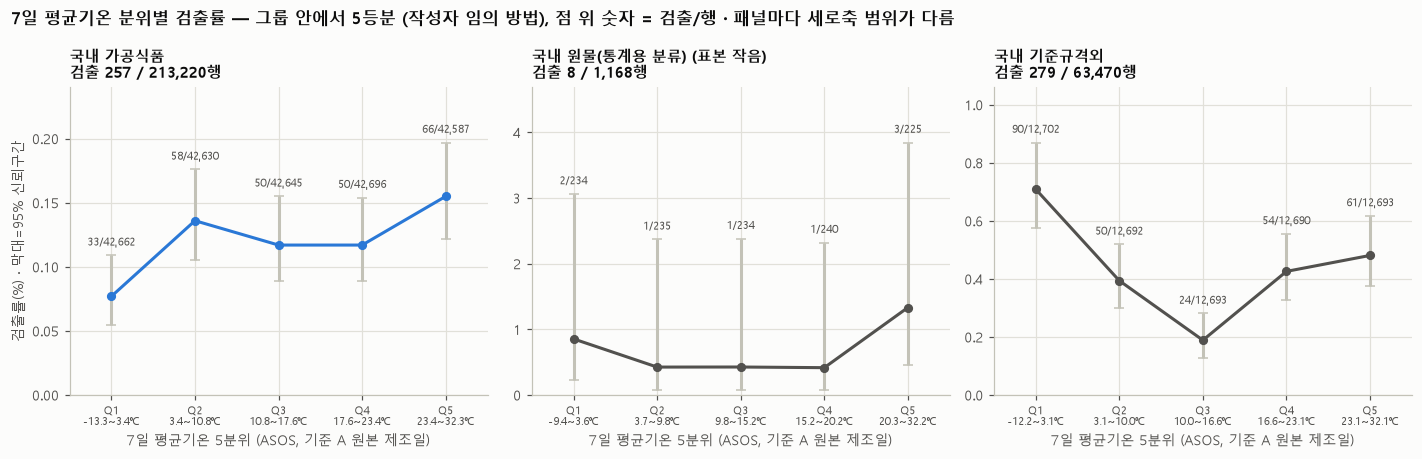

In [81]:
# [7-2] 국내 가공식품: 7일 평균기온(ASOS avg_ta, 기준 A) 5분위별 검출률 — 작성자 임의 방법: 그룹 안에서 행 기준 5등분(pd.qcut)
def w7_qtab(frame, col, q=5, unit='℃'):
    '''값이 있는 행만 q분위로 나눠 행 수·검출·검출률·Wilson 95% 신뢰구간. (표, 값 없어서 뺀 행 수)'''
    d = frame.loc[frame[col].notna(), ['pos', col]]
    cut = pd.qcut(d[col], q, labels=False, duplicates='drop')
    t = d.groupby(cut).agg(행수=('pos', 'size'), 검출=('pos', 'sum'), 하한=(col, 'min'), 상한=(col, 'max'))
    t['검출률(%)'] = (t['검출'] / t['행수'] * 100).round(3)
    lo, hi = wilson(t['검출'], t['행수'])
    t['CI 하한(%)'], t['CI 상한(%)'] = np.round(lo, 3), np.round(hi, 3)
    t['값 범위'] = [f'{a:.1f}~{b:.1f}{unit}' for a, b in zip(t['하한'], t['상한'])]
    t.index = [f'Q{i + 1}' for i in t.index]
    t.index.name = '분위'
    return t[['값 범위', '행수', '검출', '검출률(%)', 'CI 하한(%)', 'CI 상한(%)']], len(frame) - len(d)


_gp = w7[w7['그룹'] == '국내 가공식품']
W7_Q_MAIN, _drop = w7_qtab(_gp, 'avg_ta_A7')
print(f'국내 가공식품 {len(_gp):,}행 중 7일 평균기온(기준 A) 없는 {_drop:,}행 뺌 → {W7_Q_MAIN["행수"].sum():,}행 / 검출 {W7_Q_MAIN["검출"].sum():,}')
display(W7_Q_MAIN)

# 그림: 세 그룹을 같은 방법으로 (각 그룹 안에서 5분위)
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
for _ax, _g, _c in zip(axes, W7_GROUPS, [C1, INK2, INK2]):
    _t, _ = w7_qtab(w7[w7['그룹'] == _g], 'avg_ta_A7')
    _x = np.arange(len(_t))
    _r = _t['검출률(%)'].to_numpy()
    _ax.errorbar(_x, _r, yerr=[_r - _t['CI 하한(%)'].to_numpy(), _t['CI 상한(%)'].to_numpy() - _r],
                 fmt='o-', color=_c, ecolor=GRAY, elinewidth=2, capsize=3, markersize=5)
    _top = _t['CI 상한(%)'].max()
    for _xi, _k, _n, _hi in zip(_x, _t['검출'], _t['행수'], _t['CI 상한(%)']):
        _ax.text(_xi, _hi + _top * 0.03, f'{_k}/{_n:,}', ha='center', va='bottom', fontsize=7, color=INK2)
    _ax.set_xticks(_x)
    _ax.set_xticklabels([f'{i}\n{v}' for i, v in zip(_t.index, _t['값 범위'])], fontsize=7)
    _ax.set_ylim(0, _top * 1.22)
    _ax.set_xlim(-0.5, len(_t) - 0.5)
    _sm = ' (표본 작음)' if _t['검출'].sum() < 50 else ''
    _ax.set_title(f'{_g}{_sm}\n검출 {_t["검출"].sum():,} / {_t["행수"].sum():,}행', fontsize=10)
    _ax.set_xlabel('7일 평균기온 5분위 (ASOS, 기준 A 원본 제조일)')
axes[0].set_ylabel('검출률(%) · 막대=95% 신뢰구간')
fig.suptitle('7일 평균기온 분위별 검출률 — 그룹 안에서 5등분 (작성자 임의 방법), 점 위 숫자 = 검출/행 · 패널마다 세로축 범위가 다름', x=0.01, ha='left', fontsize=11, fontweight='bold')
fig.tight_layout()
plt.show()

In [82]:
# [7-2] 요약표 — 기준 A/B × 창 7/30일 × 기온/습도(ASOS), 그룹 안 5분위 검출률(%). '표본 작음' = 연결 행 검출 50건 미만 (작성자 임의 기준)
def w7_qsummary(frame, groups, combos):
    rows = []
    for g in groups:
        s = frame[frame['그룹'] == g]
        for var, b, win in combos:
            t, _ = w7_qtab(s, f'{var}_{b}{win}', unit='℃' if var in ('avg_ta', 'temp') else '%')
            r = {'그룹': g, '변수': var, '기준': b, '창': f'{win}일', '연결 행': int(t['행수'].sum()), '검출': int(t['검출'].sum())}
            for q, v in t['검출률(%)'].items():
                r[f'{q}(%)'] = v
            r['Q1~Q5 검출'] = '·'.join(str(int(k)) for k in t['검출'])
            r['비고'] = '표본 작음' if r['검출'] < 50 else ''
            rows.append(r)
    return pd.DataFrame(rows)


_combos = [(v, b, w) for v in ['avg_ta', 'avg_rhm'] for b in ['A', 'B'] for w in W7_WIN]
print('국내 가공식품 (ASOS 8가지 + 농업기상 기준 A 7일 2가지)')
display(w7_qsummary(w7, ['국내 가공식품'], _combos + [('temp', 'A', 7), ('hum', 'A', 7)]))
print('대조군: 국내 기준규격외 · 국내 원물(통계용 분류) (ASOS 8가지)')
w7_qsummary(w7, ['국내 기준규격외', '국내 원물(통계용 분류)'], _combos)

국내 가공식품 (ASOS 8가지 + 농업기상 기준 A 7일 2가지)


,그룹,변수,기준,창,연결 행,검출,Q1(%),Q2(%),Q3(%),Q4(%),Q5(%),Q1~Q5 검출,비고
0,국내 가공식품,avg_ta,A,7일,213220,257,0.077,0.136,0.117,0.117,0.155,33·58·50·50·66,
1,국내 가공식품,avg_ta,A,30일,210239,249,0.086,0.136,0.143,0.109,0.119,36·57·60·46·50,
2,국내 가공식품,avg_ta,B,7일,282685,354,0.111,0.122,0.138,0.117,0.138,63·69·78·66·78,
3,국내 가공식품,avg_ta,B,30일,278619,349,0.109,0.142,0.147,0.108,0.120,61·79·82·60·67,
4,국내 가공식품,avg_rhm,A,7일,212472,257,0.139,0.125,0.125,0.122,0.094,59·53·53·52·40,
5,국내 가공식품,avg_rhm,A,30일,208153,248,0.134,0.161,0.118,0.077,0.106,56·67·49·32·44,
6,국내 가공식품,avg_rhm,B,7일,281590,354,0.161,0.128,0.117,0.108,0.114,91·72·66·61·64,
7,국내 가공식품,avg_rhm,B,30일,275726,347,0.143,0.161,0.134,0.085,0.105,79·89·74·47·58,
8,국내 가공식품,temp,A,7일,200612,239,0.050,0.125,0.115,0.149,0.157,20·50·46·60·63,
9,국내 가공식품,hum,A,7일,198962,239,0.143,0.108,0.148,0.106,0.096,57·43·59·42·38,


대조군: 국내 기준규격외 · 국내 원물(통계용 분류) (ASOS 8가지)


,그룹,변수,기준,창,연결 행,검출,Q1(%),Q2(%),Q3(%),Q4(%),Q5(%),Q1~Q5 검출,비고
0,국내 기준규격외,avg_ta,A,7일,63470,279,0.709,0.394,0.189,0.426,0.481,90·50·24·54·61,
1,국내 기준규격외,avg_ta,A,30일,62478,275,0.272,0.687,0.353,0.312,0.576,34·86·44·39·72,
2,국내 기준규격외,avg_ta,B,7일,312811,1380,0.438,0.382,0.342,0.427,0.618,274·239·214·267·386,
3,국내 기준규격외,avg_ta,B,30일,308367,1353,0.347,0.403,0.381,0.430,0.633,214·249·235·265·390,
4,국내 기준규격외,avg_rhm,A,7일,63179,279,0.562,0.459,0.356,0.270,0.562,71·58·45·34·71,
5,국내 기준규격외,avg_rhm,A,30일,61746,272,0.405,0.583,0.381,0.251,0.583,50·72·47·31·72,
6,국내 기준규격외,avg_rhm,B,7일,311406,1374,0.521,0.307,0.478,0.440,0.462,325·191·297·274·287,
7,국내 기준규격외,avg_rhm,B,30일,304857,1344,0.425,0.461,0.379,0.443,0.497,259·281·231·270·303,
8,국내 원물(통계용 분류),avg_ta,A,7일,1168,8,0.855,0.426,0.427,0.417,1.333,2·1·1·1·3,표본 작음
9,국내 원물(통계용 분류),avg_ta,A,30일,1160,8,0.858,0.000,0.873,1.293,0.431,2·0·2·3·1,표본 작음


In [83]:
# [7-2] 기준 A 와 B 는 서로 다른 행 집합 — 같은 행으로 맞춰 비교 (작성자 임의 방법)
# (1) 기준 A 7일 기온이 있는 행만 남기고 기준 B 7일 기온으로 다시 5분위  (2) 원본 제조일이 없는 행(기준 B 만 가능)의 5분위
_rows = []
for _g in ['국내 가공식품', '국내 기준규격외']:
    _s = w7[w7['그룹'] == _g]
    _hasA = _s['avg_ta_A7'].notna()
    for _lab, _fr, _col in [('기준 A 7일 (전체 A 행)', _s, 'avg_ta_A7'),
                            ('기준 B 7일 (전체 B 행)', _s, 'avg_ta_B7'),
                            ('기준 B 7일 — A7 값이 있는 같은 행만', _s[_hasA], 'avg_ta_B7'),
                            ('기준 B 7일 — 원본 제조일 없는 행만', _s[_s['mnfctur_de_raw'].isna()], 'avg_ta_B7')]:
        _t, _drop = w7_qtab(_fr, _col)
        _r = {'그룹': _g, '비교': _lab, '뺀 행(값 없음)': _drop, '연결 행': int(_t['행수'].sum()), '검출': int(_t['검출'].sum())}
        for _q, _v in _t['검출률(%)'].items():
            _r[f'{_q}(%)'] = _v
        _r['Q1~Q5 검출'] = '·'.join(str(int(k)) for k in _t['검출'])
        _r['비고'] = '표본 작음' if _r['검출'] < 50 else ''
        _rows.append(_r)
W7_SAMEROW = pd.DataFrame(_rows)
print('같은 행 비교 — 뺀 행(값 없음)은 각 비교에 쓴 행 집합 안에서 기온 값이 없는 행')
display(W7_SAMEROW)

# 원본 제조일이 있는 행과 없는 행은 어떻게 다른가 (주소 출처·검사목적 구성, 행 %)
_rows = []
for _g in ['국내 가공식품', '국내 기준규격외']:
    _s = w7[w7['그룹'] == _g]
    _src = dfx.loc[_s.index, 'addr_source'].astype(str)
    _pur = dfx.loc[_s.index, '검사목적'].astype(str)
    for _lab, _mm in [('원본 제조일 있음', _s['mnfctur_de_raw'].notna()), ('원본 제조일 없음', _s['mnfctur_de_raw'].isna())]:
        _n = int(_mm.sum())
        _rows.append({'그룹': _g, '구분': _lab, '행': _n, '검출': int(_s.loc[_mm, 'pos'].sum()),
                      '검출률(%)': round(_s.loc[_mm, 'pos'].mean() * 100, 3),
                      '주소출처 업소주소(%)': round(_src[_mm].eq('업소주소').mean() * 100, 1),
                      '주소출처 제조사소재지(%)': round(_src[_mm].eq('제조사소재지').mean() * 100, 1),
                      "검사목적 '기타'(%)": round(_pur[_mm].eq('기타').mean() * 100, 1),
                      '검사목적 자가품질위탁(%)': round(_pur[_mm].eq('자가품질위탁검사').mean() * 100, 1)})
print('원본 제조일 있는 행 vs 없는 행 — 구성 비교')
pd.DataFrame(_rows)

같은 행 비교 — 뺀 행(값 없음)은 각 비교에 쓴 행 집합 안에서 기온 값이 없는 행


,그룹,비교,뺀 행(값 없음),연결 행,검출,Q1(%),Q2(%),Q3(%),Q4(%),Q5(%),Q1~Q5 검출,비고
0,국내 가공식품,기준 A 7일 (전체 A 행),81201,213220,257,0.077,0.136,0.117,0.117,0.155,33·58·50·50·66,
1,국내 가공식품,기준 B 7일 (전체 B 행),11736,282685,354,0.111,0.122,0.138,0.117,0.138,63·69·78·66·78,
2,국내 가공식품,기준 B 7일 — A7 값이 있는 같은 행만,440,212780,256,0.082,0.125,0.134,0.125,0.136,35·53·57·53·58,
3,국내 가공식품,기준 B 7일 — 원본 제조일 없는 행만,2398,69416,97,0.194,0.123,0.158,0.079,0.144,27·17·22·11·20,
4,국내 기준규격외,기준 A 7일 (전체 A 행),257066,63470,279,0.709,0.394,0.189,0.426,0.481,90·50·24·54·61,
5,국내 기준규격외,기준 B 7일 (전체 B 행),7725,312811,1380,0.438,0.382,0.342,0.427,0.618,274·239·214·267·386,
6,국내 기준규격외,기준 B 7일 — A7 값이 있는 같은 행만,182,63288,278,0.692,0.391,0.208,0.427,0.474,88·50·26·54·60,
7,국내 기준규격외,기준 B 7일 — 원본 제조일 없는 행만,6004,249333,1101,0.377,0.371,0.381,0.427,0.653,188·185·190·213·325,


원본 제조일 있는 행 vs 없는 행 — 구성 비교


,그룹,구분,행,검출,검출률(%),주소출처 업소주소(%),주소출처 제조사소재지(%),검사목적 '기타'(%),검사목적 자가품질위탁(%)
0,국내 가공식품,원본 제조일 있음,222607,288,0.129,20.5,76.7,8.8,73.0
1,국내 가공식품,원본 제조일 없음,71814,98,0.136,22.3,74.2,16.7,48.7
2,국내 기준규격외,원본 제조일 있음,65199,299,0.459,68.3,31.6,93.4,0.1
3,국내 기준규격외,원본 제조일 없음,255337,1132,0.443,70.4,29.6,91.3,0.0


### 7-2. 국내 가공식품 — 기온·습도 분위별 검출률

📊 **결과**
- 가공식품 7일 평균기온(ASOS, 기준 A) 5분위 검출률: Q1(-13.3\~3.4℃) 0.077% → Q2 0.136% → Q3 0.117% → Q4 0.117% → Q5(23.4\~32.3℃) 0.155%.
  - Q1(0.055\~0.109)과 Q5(0.122\~0.197)의 95% 신뢰구간은 겹치지 않습니다. Q2\~Q5 는 구간이 서로 겹칩니다.
- 다른 변형 (가공식품, 5분위 검출률 Q1·Q2·Q3·Q4·Q5)
  - 기준 A 30일: 0.086·0.136·0.143·0.109·0.119%
  - 기준 B 7일 (전체 B 행 282685행): 0.111·0.122·0.138·0.117·0.138%
  - 농업기상 temp 기준 A 7일: 0.050·0.125·0.115·0.149·0.157% (ASOS 보다 Q1 과 Q5 차이가 큼)
- 습도(ASOS avg_rhm): 기준 A 7일 Q1 0.139% → Q5 0.094%, 기준 B 7일 Q1 0.161% → Q5 0.114%.
- 기준 A 와 B 는 **서로 다른 행 집합**입니다 (가공식품 기준 A 7일 213220행 vs 기준 B 7일 282685행). 같은 행으로 맞추면:
  - 가공식품, A7 값이 있는 같은 행만 기준 B 7일: 0.082·0.125·0.134·0.125·0.136% (212780행·검출 256) — 기준 A 와 비슷한 모양
  - 가공식품, 원본 제조일 없는 행만 기준 B 7일: 0.194·0.123·0.158·0.079·0.144% (69416행·검출 97)
  - 원본 제조일 있는 행과 없는 행의 가공식품 검출률은 0.129% vs 0.136% 로 비슷합니다. 검사목적 자가품질위탁 비율은 73.0% vs 48.7%, 검사목적 '기타' 는 8.8% vs 16.7% 로 다릅니다.
- 대조군 기준규격외
  - 기준 A 7일: 0.709·0.394·0.189·0.426·0.481% (가운데가 낮음) / A7 값이 있는 같은 행만 기준 B 7일: 0.692·0.391·0.208·0.427·0.474% (거의 같음)
  - 전체 기준 B 7일: 0.438·0.382·0.342·0.427·0.618% / 원본 제조일 없는 행만 기준 B 7일: 0.377·0.371·0.381·0.427·0.653%
- 대조군 원물(통계용 분류): 검출이 기준 A 8건·기준 B 19건뿐이라 분위마다 0\~7건입니다 (표본 작음).
- 그림의 세 패널은 세로축 범위가 서로 다릅니다. 모양만 비교하고, 검출률 크기는 표의 숫자로 비교해 주세요.

💬 **첨언**
- 작성자가 임의로 5등분해 본 결과, 가공식품에서 가장 추운 분위(Q1)의 검출률이 가장 낮은 모양이 보입니다. 가운데 분위(Q2\~Q4)는 평평합니다. 기온이 오를수록 꾸준히 오르는 모양은 아닌 것으로 보입니다 (추정).
- 이 "Q1 이 낮음" 모양은 창 길이·관측망을 바꿔도 대체로 남고, 농업기상 기온에서는 오히려 더 크게 보입니다 (7-4 끝 표에서 8가지 변형 비교).
- 기준 A 와 B 의 모양 차이는 기준 날짜 자체보다 **행 구성 차이**(원본 제조일이 있는 행이냐 없느냐) 때문일 수 있습니다. 같은 행으로 맞추면 기준 B 도 기준 A 와 비슷하고, 흐려지는 쪽은 원본 제조일 없는 행입니다 (추정). 두 행 묶음은 검사목적 구성이 다릅니다.
- 기온 분위는 계절과 거의 겹치는 것으로 보입니다 (Q1 -13.3\~3.4℃ 는 대체로 겨울, Q5 23.4\~32.3℃ 는 대체로 여름, 추정). 기온 때문인지, 계절마다 검사 품목·업체 구성이 달라서인지 이 표로는 가를 수 없습니다 → 7-3.
- 기준규격외는 가공식품과 모양이 다릅니다. 이것도 기준 A·B 차이보다 행 구성 차이로 보이며, 팽이버섯·공정 시료가 섞인 점과 연도 구성(7-3)이 영향일 수 있습니다 (추정).

In [84]:
# [7-3] 계절과 섞임 확인 (1) 같은 계절 안에서 7일 평균기온 3분위별 검출률 — 작성자 임의 방법: 계절 = 기준 날짜(A) 달로 봄3~5·여름6~8·가을9~11·겨울12~2, 계절 안에서 3등분
W7_SEASON = {12: '겨울', 1: '겨울', 2: '겨울', 3: '봄', 4: '봄', 5: '봄', 6: '여름', 7: '여름', 8: '여름', 9: '가을', 10: '가을', 11: '가을'}
_rows = []
for _g in ['국내 가공식품', '국내 기준규격외']:
    _s = w7.loc[(w7['그룹'] == _g) & w7['avg_ta_A7'].notna(), ['pos', 'avg_ta_A7', 'mnfctur_de_raw']]
    _s = _s.assign(계절=_s['mnfctur_de_raw'].dt.month.map(W7_SEASON))
    for _se in ['봄', '여름', '가을', '겨울']:
        _t, _ = w7_qtab(_s[_s['계절'] == _se], 'avg_ta_A7', q=3)
        _t = _t.reset_index()
        _t.insert(0, '계절', _se)
        _t.insert(0, '그룹', _g)
        _rows.append(_t)
W7_SEASON_TBL = pd.concat(_rows, ignore_index=True)
print('7일 평균기온(ASOS, 기준 A) 있는 행만 사용 — 뺀 행 수는 7-1 표의 A·7일 행과 같음')
display(W7_SEASON_TBL[W7_SEASON_TBL['그룹'] == '국내 가공식품'].drop(columns='그룹'))
print('대조: 국내 기준규격외')
W7_SEASON_TBL[W7_SEASON_TBL['그룹'] == '국내 기준규격외'].drop(columns='그룹')

7일 평균기온(ASOS, 기준 A) 있는 행만 사용 — 뺀 행 수는 7-1 표의 A·7일 행과 같음


,계절,분위,값 범위,행수,검출,검출률(%),CI 하한(%),CI 상한(%)
0,봄,Q1,-3.1~9.8℃,19260,30,0.156,0.109,0.222
1,봄,Q2,9.8~15.3℃,19259,33,0.171,0.122,0.241
2,봄,Q3,15.3~25.6℃,19244,36,0.187,0.135,0.259
3,여름,Q1,12.5~23.5℃,18166,14,0.077,0.046,0.129
4,여름,Q2,23.5~26.2℃,18123,34,0.188,0.134,0.262
5,여름,Q3,26.2~32.3℃,18102,22,0.122,0.080,0.184
6,가을,Q1,-2.6~12.7℃,16802,21,0.125,0.082,0.191
7,가을,Q2,12.7~19.9℃,16787,8,0.048,0.024,0.094
8,가을,Q3,19.9~29.7℃,16793,21,0.125,0.082,0.191
9,겨울,Q1,-13.3~-1.0℃,16895,10,0.059,0.032,0.109


대조: 국내 기준규격외


,계절,분위,값 범위,행수,검출,검출률(%),CI 하한(%),CI 상한(%)
12,봄,Q1,-2.6~9.5℃,6157,8,0.130,0.066,0.256
13,봄,Q2,9.5~15.2℃,6120,16,0.261,0.161,0.424
14,봄,Q3,15.2~24.2℃,6134,9,0.147,0.077,0.279
15,여름,Q1,13.6~23.6℃,4958,43,0.867,0.645,1.166
16,여름,Q2,23.6~26.2℃,4936,16,0.324,0.200,0.526
17,여름,Q3,26.2~32.1℃,4937,27,0.547,0.376,0.795
18,가을,Q1,-1.1~11.8℃,5054,50,0.989,0.751,1.302
19,가을,Q2,11.8~19.3℃,5052,6,0.119,0.054,0.259
20,가을,Q3,19.3~28.8℃,5045,22,0.436,0.288,0.659
21,겨울,Q1,-12.2~-1.1℃,5037,21,0.417,0.273,0.637


In [85]:
# [7-3] 계절과 섞임 확인 (2) 로지스틱 회귀 두 개의 우도비 비교 — 작성자 임의 방법 (numpy 로 직접 구현, IRLS = 뉴턴법)
# 모형0: logit P(검출) = b0 + Σ 월 더미(1월 기준 11개)
# 모형1: 모형0 + b_t × z,  z = (7일 평균기온 − 평균) / 표준편차  (같은 행들로 계산)
# 뉴턴 한 걸음: β ← β + (XᵀWX)⁻¹ Xᵀ(y − p),  p = 1/(1+e^(−Xβ)), W = diag(p(1−p))
# 로그우도: ℓ = Σ [ y·η − log(1 + e^η) ],  η = Xβ
# 우도비 통계량: LR = 2(ℓ1 − ℓ0) ~ 카이제곱(자유도 1) 근사 → p = erfc(√(LR/2))
# 주의: 같은 업체의 행끼리 서로 독립이 아니므로(군집) 이 p값은 실제보다 작게(과대평가) 나올 수 있음
# 그래서 업체 군집 강건 표준오차(샌드위치)도 같이 계산 — 작성자 임의 방법:
#   V = H⁻¹ (Σ_g s_g s_gᵀ) H⁻¹,  s_g = Σ_{i∈업체 g} x_i (y_i − p_i),  H = XᵀWX (최종 β 에서)
#   z = b_t / √V[t,t],  p = erfc(|z|/√2).  업체 식별 불가 행은 행 1개 = 군집 1개로 둠, 소표본 보정 계수는 쓰지 않음
import math

# 업체 라벨 (업체 식별 규칙 — 작성자 임의: 영업허가번호 → 제조회사명 → '식별 불가')
_lic = w7['bsn_lcns_ledg_no'].astype('string').str.strip()
_nm = w7['mnfctur_cmpny_nm'].astype('string').str.strip()
_has_lic, _has_nm = _lic.notna() & _lic.ne(''), _nm.notna() & _nm.ne('')
w7['업체'] = np.where(_has_lic, 'L:' + _lic.fillna(''), np.where(_has_nm, 'N:' + _nm.fillna(''), '식별 불가'))  # fillna('') 는 문자열 결합용, 결과에는 쓰지 않음


def w7_logit(X, y, max_iter=100, tol=1e-9):
    beta = np.zeros(X.shape[1])
    beta[0] = np.log(y.mean() / (1 - y.mean()))          # 시작값: 절편 = 전체 검출률의 로짓
    eta = X @ beta
    ll = float(np.sum(y * eta - np.logaddexp(0, eta)))
    for it in range(1, max_iter + 1):
        p = 1 / (1 + np.exp(-eta))
        H = X.T @ (X * (p * (1 - p))[:, None]) + 1e-8 * np.eye(X.shape[1])   # 1e-8: 수치 안정용 아주 작은 대각값
        step = np.linalg.solve(H, X.T @ (y - p))
        t = 1.0
        while True:                                         # 로그우도가 줄면 걸음을 반으로 (step halving)
            nb = beta + t * step
            ne = X @ nb
            nll = float(np.sum(y * ne - np.logaddexp(0, ne)))
            if nll >= ll - 1e-12 or t < 1e-6:
                break
            t /= 2
        beta, eta, gain, ll = nb, ne, nll - ll, nll
        if abs(gain) < tol:
            return beta, ll, H, it, True
    return beta, ll, H, max_iter, False


def w7_cluster_p(X, y, beta, cl):
    '''마지막 계수(기온)의 업체 군집 강건 표준오차와 p값 (식은 셀 위 주석). 식별 불가 행은 행 1개 = 군집 1개'''
    p = 1 / (1 + np.exp(-(X @ beta)))
    Hi = np.linalg.inv(X.T @ (X * (p * (1 - p))[:, None]))
    lab = np.where(cl == '식별 불가', np.char.add('U', np.arange(len(cl)).astype(str)), cl)
    _, inv = np.unique(lab, return_inverse=True)
    G = np.zeros((inv.max() + 1, X.shape[1]))
    np.add.at(G, inv, X * (y - p)[:, None])
    V = Hi @ (G.T @ G) @ Hi
    se_m, se_c = float(np.sqrt(Hi[-1, -1])), float(np.sqrt(V[-1, -1]))
    return se_m, se_c, math.erfc(abs(beta[-1]) / se_c / math.sqrt(2)), int(inv.max() + 1)


# 모형 목록: (그룹, 이름, 월을 뽑을 날짜, 기온 열, 행 조건). 'A7 있는 같은 행만' = 기준 A·B 행 구성 차이를 없앤 비교 (작성자 임의)
_specs = []
for _g in W7_GROUPS:
    _specs += [(_g, 'A 원본 제조일', 'mnfctur_de_raw', 'avg_ta_A7', None), (_g, 'B 의뢰일', 'reqest_de', 'avg_ta_B7', None)]
    if _g != '국내 원물(통계용 분류)':
        _specs.append((_g, 'B 의뢰일 (A7 있는 같은 행만)', 'reqest_de', 'avg_ta_B7', 'avg_ta_A7'))
_rows = []
for _g, _lab, _bc, _tc, _need in _specs:
    _s = w7.loc[w7['그룹'] == _g, ['pos', _tc, _bc, '업체'] + ([_need] if _need else [])]
    _use = _s[_tc].notna() & (_s[_need].notna() if _need else True)
    _s = _s[_use]
    _y = _s['pos'].to_numpy(dtype=float)
    _mon = _s[_bc].dt.month.to_numpy()
    _months = [m for m in range(2, 13) if (_mon == m).any()]
    _X0 = np.column_stack([np.ones(len(_s))] + [(_mon == m).astype(float) for m in _months])
    _ta = _s[_tc].to_numpy()
    _sd = _ta.std()
    _X1 = np.column_stack([_X0, (_ta - _ta.mean()) / _sd])
    _b0, _ll0, _, _it0, _cv0 = w7_logit(_X0, _y)
    _b1, _ll1, _, _it1, _cv1 = w7_logit(_X1, _y)
    _lr = max(2 * (_ll1 - _ll0), 0.0)
    _se, _se_c, _p_c, _ncl = w7_cluster_p(_X1, _y, _b1, _s['업체'].to_numpy().astype(str))
    _wsd = float((pd.Series(_ta) - pd.Series(_ta).groupby(_mon).transform('mean')).std(ddof=0))
    _c1 = _b1[-1] / _sd                                      # 1℃당 로그 오즈
    _mon_k = pd.Series(_y).groupby(_mon).sum()
    _rows.append({'그룹': _g, '기준': _lab, '뺀 행(기온 없음)': int((~_use).sum()), '사용 행': len(_s), '검출': int(_y.sum()),
                  '검출 0인 달 수': int((_mon_k == 0).sum()), '기온 SD(℃)': round(_sd, 2), '달 안 기온 SD(℃)': round(_wsd, 2),
                  '오즈비(1℃당)': round(math.exp(_c1), 3),
                  '1℃당 95%구간(Wald)': f'{math.exp(_c1 - 1.96 * _se / _sd):.3f}~{math.exp(_c1 + 1.96 * _se / _sd):.3f}',
                  '오즈비(달 안 SD당)': round(math.exp(_c1 * _wsd), 3),
                  'LR 통계량': round(_lr, 2), 'p값(자유도1 근사)': f'{math.erfc(math.sqrt(_lr / 2)):.3g}',
                  '업체 군집 수': _ncl, '군집 강건 p값': f'{_p_c:.3g}',
                  '수렴(모형0/1)': f'{_cv0}/{_cv1}', '비고': '표본 작음' if _y.sum() < 50 else ''})
W7_LRT = pd.DataFrame(_rows)
print('월 더미만 vs 월 더미 + 7일 평균기온 — 오즈비는 1℃당, 그리고 달 평균을 뺀 기온 SD(같은 달 안 변동 폭)당')
display(W7_LRT)

# 기준규격외 A7 행의 연도 구성 (2020 년 팽이버섯 수출검사 몰림 — 2.ipynb) — 기준 B 7일 행과 나란히
_z = w7[w7['그룹'] == '국내 기준규격외']
_ya = _z[_z['avg_ta_A7'].notna()].groupby(_z['mnfctur_de_raw'].dt.year)['pos'].agg(A7_행='size', A7_검출='sum')
_yb = _z[_z['avg_ta_B7'].notna()].groupby(_z['reqest_de'].dt.year)['pos'].agg(B7_행='size', B7_검출='sum')
_yy = _ya.join(_yb, how='outer')
_yy.index = _yy.index.astype(int)
_yy.index.name = '연도(각 기준 날짜)'
print('국내 기준규격외 — 연도별 행·검출 (A7 = 원본 제조일 연도, B7 = 의뢰일 연도; 해당 연도 행이 없으면 빈 칸)')
display(_yy)

_rows = []
for _g in W7_GROUPS:
    _s = w7.loc[(w7['그룹'] == _g) & w7['avg_ta_A7'].notna(), ['pos', '업체']]
    _k = _s[_s['업체'] != '식별 불가'].groupby('업체')['pos'].sum().sort_values(ascending=False)
    _tot = int(_s['pos'].sum())
    _rows.append({'그룹': _g, '행(기준 A·7일 기온 있음)': len(_s), '식별 불가 행(%)': round(_s['업체'].eq('식별 불가').mean() * 100, 1),
                  '식별 불가 행의 검출': int(_s.loc[_s['업체'].eq('식별 불가'), 'pos'].sum()),
                  '업체 수': len(_k), '검출 있는 업체 수': int((_k > 0).sum()), '검출': _tot,
                  '검출 1위 업체 비중(%)': round(_k.iloc[0] / max(_tot, 1) * 100, 1) if len(_k) else np.nan,
                  '검출 상위 5곳 비중(%)': round(_k.head(5).sum() / max(_tot, 1) * 100, 1) if len(_k) else np.nan})
print('같은 업체 군집 규모 (기준 A · 7일 평균기온 있는 행)')
pd.DataFrame(_rows)

월 더미만 vs 월 더미 + 7일 평균기온 — 오즈비는 1℃당, 그리고 달 평균을 뺀 기온 SD(같은 달 안 변동 폭)당


,그룹,기준,뺀 행(기온 없음),사용 행,검출,검출 0인 달 수,기온 SD(℃),달 안 기온 SD(℃),오즈비(1℃당),1℃당 95%구간(Wald),오즈비(달 안 SD당),LR 통계량,p값(자유도1 근사),업체 군집 수,군집 강건 p값,수렴(모형0/1),비고
0,국내 가공식품,A 원본 제조일,81201,213220,257,0,9.77,2.88,1.060,1.014~1.109,1.184,6.61,0.0101,50750,0.0311,True/True,
1,국내 가공식품,B 의뢰일,11736,282685,354,0,9.65,2.88,1.032,0.994~1.071,1.094,2.64,0.104,67557,0.182,True/True,
2,국내 가공식품,B 의뢰일 (A7 있는 같은 행만),81641,212780,256,0,9.74,2.90,1.049,1.003~1.096,1.148,4.41,0.0357,50705,0.0961,True/True,
3,국내 원물(통계용 분류),A 원본 제조일,2365,1168,8,7,8.51,2.98,0.959,0.763~1.206,0.883,0.13,0.719,626,0.609,True/True,표본 작음
4,국내 원물(통계용 분류),B 의뢰일,616,2917,19,2,7.72,2.68,0.923,0.785~1.085,0.806,0.96,0.327,2119,0.234,True/True,표본 작음
5,국내 기준규격외,A 원본 제조일,257066,63470,279,0,9.73,2.74,0.906,0.870~0.945,0.764,21.55,3.45e-06,45150,1.18e-05,True/True,
6,국내 기준규격외,B 의뢰일,7725,312811,1380,0,9.54,2.80,1.019,1.000~1.038,1.054,3.89,0.0485,223623,0.145,True/True,
7,국내 기준규격외,B 의뢰일 (A7 있는 같은 행만),257248,63288,278,0,9.64,2.69,0.927,0.888~0.967,0.815,12.03,0.000523,45017,0.000297,True/True,


국내 기준규격외 — 연도별 행·검출 (A7 = 원본 제조일 연도, B7 = 의뢰일 연도; 해당 연도 행이 없으면 빈 칸)


,A7_행,A7_검출,B7_행,B7_검출
연도(각 기준 날짜),,,,
2015,6,0,NaN,NaN
2016,94,0,63.0,0.0
2017,3045,6,10766.0,17.0
2018,5060,13,19065.0,49.0
2019,5367,16,20946.0,75.0
2020,8348,145,27301.0,354.0
2021,7023,40,32050.0,174.0
2022,7130,15,35053.0,174.0
2023,7999,15,40468.0,152.0


같은 업체 군집 규모 (기준 A · 7일 평균기온 있는 행)


,그룹,행(기준 A·7일 기온 있음),식별 불가 행(%),식별 불가 행의 검출,업체 수,검출 있는 업체 수,검출,검출 1위 업체 비중(%),검출 상위 5곳 비중(%)
0,국내 가공식품,213220,20.2,71,7749,117,257,2.7,11.7
1,국내 원물(통계용 분류),1168,23.6,1,350,6,8,25.0,75.0
2,국내 기준규격외,63470,68.2,245,1873,7,279,5.0,11.1


### 7-3. 계절과 섞임 확인

📊 **결과**
- 같은 계절 안 기온 3분위 (가공식품, ASOS 기준 A 7일): 봄 0.156 → 0.171 → 0.187%, 여름 0.077 → 0.188 → 0.122%, 가을 0.125 → 0.048 → 0.125%, 겨울 0.059 → 0.071 → 0.095%.
  - 봄·겨울은 따뜻한 분위가 조금 높고, 여름·가을은 들쭉날쭉합니다. 여름 Q1(0.046\~0.129)과 Q2(0.134\~0.262)를 빼면 같은 계절 안 분위끼리 신뢰구간이 겹칩니다.
- 로지스틱 회귀 비교 (월 더미만 vs 월 더미 + 7일 평균기온). 오즈비는 1℃당, 괄호 안은 같은 달 안 기온 SD 만큼 올랐을 때
  - 가공식품 기준 A: 1℃당 1.060 (Wald 95% 1.014\~1.109; 달 안 SD 2.88℃당 1.184), LR 6.61, p 0.0101 → 업체 군집 강건 p 0.0311
  - 가공식품 기준 B (전체 B 행): 1℃당 1.032 (0.994\~1.071), LR 2.64, p 0.104 → 군집 강건 p 0.182
  - 가공식품 기준 B (A7 있는 같은 행만): 1℃당 1.049 (1.003\~1.096), LR 4.41, p 0.0357 → 군집 강건 p 0.0961
  - 기준규격외 기준 A: 1℃당 0.906 (0.870\~0.945), LR 21.55, p 3.45e-06 → 군집 강건 p 1.18e-05
  - 기준규격외 기준 B (전체 B 행): 1℃당 1.019 (1.000\~1.038), LR 3.89, p 0.0485 → 군집 강건 p 0.145
  - 기준규격외 기준 B (A7 있는 같은 행만): 1℃당 0.927 (0.888\~0.967), LR 12.03, p 0.000523 → 군집 강건 p 0.000297
  - 원물(통계용 분류): p 0.719(A)·0.327(B). 표본 작음 (기준 A 는 검출 0인 달이 7개)
- 달 평균을 뺀 기온의 표준편차는 2.68\~2.98℃ 입니다 (전체 표준편차 7.72\~9.77℃). 월 더미를 넣으면 기온 계수는 이 좁은 폭, 즉 같은 달 안의 연도·지역 차이에서만 추정됩니다.
- 기준규격외 기준 A 7일 행의 검출 279 중 145건이 원본 제조일 2020년 행입니다 (2020년 8348행). 의뢰일 기준 B 7일 행에서는 2020년 검출이 1380 중 354건입니다.
- 업체 군집 (기준 A·7일 기온 있는 행): 가공식품 213220행에 업체 7749곳, 검출 있는 업체 117곳, 검출 상위 5곳 비중 11.7%. 기준규격외는 업체 식별 불가 행이 68.2%이고 검출 279 중 245건이 식별 불가 행입니다.

💬 **첨언**
- 달을 맞춘 뒤에도 가공식품에서는 기온 계수가 양(+)입니다. 같은 행으로 맞추면 기준 A(p 0.0101)와 기준 B(p 0.0357)가 비슷합니다. 전체 B 행에서 약해지는 것(p 0.104)은 원본 제조일 없는 행이 섞여서일 수 있습니다 (추정).
- 효과 크기는 작아 보입니다. 같은 달 안에서 기온이 보통 움직이는 폭(SD 2.88℃)만큼 오를 때 오즈비 1.184 입니다 (가공식품 기준 A, 추정).
- 기준규격외는 같은 행이면 기준 A·B 모두 음(-) 방향(1℃당 0.906·0.927)입니다. 전체 B 행(1℃당 1.019)과 방향이 달라 보이는 것은 기준 날짜보다 행 구성 차이 때문일 수 있습니다. 또 이 행들은 검출 절반 이상이 2020년(팽이버섯 수출검사 몰림 해, 2.ipynb)에 있어, 연도 구성의 영향을 담았을 수 있습니다 (추정).
- 같은 업체 행은 서로 닮아서(군집) 실제 정보량이 행 수보다 적습니다. 작성자 임의로 업체 군집 강건 표준오차를 계산하면 가공식품 p값은 커집니다 (기준 A 0.0101 → 0.0311). 업체 식별 불가 행은 한 행을 한 업체로 쳤기 때문에, 식별 불가 행이 많은 기준규격외는 군집 반영이 덜 됐을 수 있습니다.
- 이 절에서는 분위표와 회귀를 여러 개 동시에 봤습니다. 이렇게 많이 보면 관계가 없어도 우연히 p<0.05 가 나올 수 있습니다.
- 연도·지역(시도)은 모형에 넣지 않았습니다 (연도·시도·검사 구성을 더한 모형은 7-5-1). 이 회귀는 작성자 임의 탐색이고, 예측 모델 설계가 아닙니다.

In [86]:
# [7-4] 거리 민감도 — 작성자 임의 기준: 최근접 ASOS 관측소 20km 이내 행만으로 7-2 핵심 표 다시 계산 (분위는 이 부분집합 안에서 다시 5등분)
_rows = []
for _g in W7_GROUPS:
    _s = w7[w7['그룹'] == _g]
    _near = _s['asos_km'] <= 20
    _rows.append({'그룹': _g, '전체 행': len(_s), '좌표 없음': int(_s['asos_km'].isna().sum()), '20km 초과로 뺀 행': int((_s['asos_km'] > 20).sum()),
                  '20km 이내 행': int(_near.sum()), '그중 A·7일 기온 있음': int((_near & _s['avg_ta_A7'].notna()).sum()),
                  '그중 검출': int(_s.loc[_near & _s['avg_ta_A7'].notna(), 'pos'].sum())})
display(pd.DataFrame(_rows))

_gp20 = w7[(w7['그룹'] == '국내 가공식품') & (w7['asos_km'] <= 20)]
W7_Q20, _drop = w7_qtab(_gp20, 'avg_ta_A7')
print(f'국내 가공식품 20km 이내 {len(_gp20):,}행 중 기온 없는 {_drop:,}행 뺌 → {W7_Q20["행수"].sum():,}행')
display(W7_Q20)

print('20km 이내 — 세 그룹 요약 (그룹 안 5분위 검출률 %)')
display(w7_qsummary(w7[w7['asos_km'] <= 20], W7_GROUPS, [('avg_ta', 'A', 7), ('avg_ta', 'B', 7), ('avg_rhm', 'A', 7)]))

# 나머지 반쪽: 20km 초과 행 (국내 가공식품, 기준 A 7일) — 이 부분집합 안에서 다시 5등분
_gpfar = w7[(w7['그룹'] == '국내 가공식품') & (w7['asos_km'] > 20)]
W7_QFAR, _drop = w7_qtab(_gpfar, 'avg_ta_A7')
print(f'국내 가공식품 20km 초과 {len(_gpfar):,}행 중 기온 없는 {_drop:,}행 뺌 → {W7_QFAR["행수"].sum():,}행 / 검출 {W7_QFAR["검출"].sum():,}'
      + (' (표본 작음: 검출 50건 미만)' if W7_QFAR['검출'].sum() < 50 else ''))
display(W7_QFAR)

# 20km 초과 행은 어느 관측소에 연결되나 (기준 A 7일 기온 있는 행) — 관측소 정보 좌표 차이는 7-1 에서 계산한 값
_f = _gpfar[_gpfar['avg_ta_A7'].notna()]
_tab = _f.groupby('asos_stn')['pos'].agg(행수='size', 검출='sum').sort_values('행수', ascending=False).head(6)
_tab.insert(0, '관측소', _last.loc[_tab.index, 'stn_ko'].values)
_tab['행 비중(%)'] = (_tab['행수'] / len(_f) * 100).round(1)
_tab['거리 중앙값(km)'] = _f.groupby('asos_stn')['asos_km'].median().loc[_tab.index].round(1)
_tab['관측소 정보 좌표 차이(km)'] = _spread.loc[_tab.index].round(1)
print(f'20km 초과·기온 있는 {len(_f):,}행 — 연결 관측소 상위 6곳')
display(_tab)

# 가공식품 기온 5분위 변형별로 '가장 추운 분위(Q1)가 가장 낮은가' — 변형끼리 같은 행을 많이 공유하므로 서로 독립된 근거가 아님
_gp = w7[w7['그룹'] == '국내 가공식품']
_vars = [('ASOS 기준 A 7일', _gp, 'avg_ta_A7'), ('ASOS 기준 A 30일', _gp, 'avg_ta_A30'),
         ('ASOS 기준 B 7일', _gp, 'avg_ta_B7'), ('ASOS 기준 B 30일', _gp, 'avg_ta_B30'),
         ('ASOS 기준 B 7일 (A7 있는 같은 행만)', _gp[_gp['avg_ta_A7'].notna()], 'avg_ta_B7'),
         ('농업기상 temp 기준 A 7일', _gp, 'temp_A7'),
         ('ASOS 기준 A 7일, 20km 이내', _gp[_gp['asos_km'] <= 20], 'avg_ta_A7'),
         ('ASOS 기준 A 7일, 20km 초과', _gpfar, 'avg_ta_A7')]
_rows = []
for _lab, _fr, _col in _vars:
    _t, _ = w7_qtab(_fr, _col)
    _rr = _t['검출률(%)'].to_numpy()
    _r = {'변형': _lab, '연결 행': int(_t['행수'].sum()), '검출': int(_t['검출'].sum())}
    _r.update({f'{q}(%)': v for q, v in _t['검출률(%)'].items()})
    _r['Q1 이 가장 낮음'] = '예' if _rr[0] < _rr[1:].min() else '아니오'
    _r['Q5 − Q1(%p)'] = round(_rr[-1] - _rr[0], 3)
    _rows.append(_r)
W7_VARIANTS = pd.DataFrame(_rows)
print(f"국내 가공식품 기온 5분위 변형 {len(W7_VARIANTS)}가지 중 'Q1 이 가장 낮음' {int(W7_VARIANTS['Q1 이 가장 낮음'].eq('예').sum())}가지")
W7_VARIANTS

,그룹,전체 행,좌표 없음,20km 초과로 뺀 행,20km 이내 행,그중 A·7일 기온 있음,그중 검출
0,국내 가공식품,294421,0,71980,222441,159028,214
1,국내 원물(통계용 분류),3533,0,259,3274,1016,6
2,국내 기준규격외,320536,0,84924,235612,43561,137


국내 가공식품 20km 이내 222,441행 중 기온 없는 63,413행 뺌 → 159,028행


,값 범위,행수,검출,검출률(%),CI 하한(%),CI 상한(%)
분위,,,,,,
Q1,-13.3~3.7℃,31806,32,0.101,0.071,0.142
Q2,3.7~11.0℃,31813,57,0.179,0.138,0.232
Q3,11.0~17.7℃,31800,42,0.132,0.098,0.178
Q4,17.7~23.4℃,31820,36,0.113,0.082,0.157
Q5,23.5~32.3℃,31789,47,0.148,0.111,0.197


20km 이내 — 세 그룹 요약 (그룹 안 5분위 검출률 %)


,그룹,변수,기준,창,연결 행,검출,Q1(%),Q2(%),Q3(%),Q4(%),Q5(%),Q1~Q5 검출,비고
0,국내 가공식품,avg_ta,A,7일,159028,214,0.101,0.179,0.132,0.113,0.148,32·57·42·36·47,
1,국내 가공식품,avg_ta,B,7일,214489,290,0.128,0.154,0.156,0.100,0.138,55·66·67·43·59,
2,국내 가공식품,avg_rhm,A,7일,158684,214,0.151,0.167,0.120,0.129,0.107,48·53·38·41·34,
3,국내 원물(통계용 분류),avg_ta,A,7일,1016,6,0.976,0.495,0.490,0.000,1.064,2·1·1·0·2,표본 작음
4,국내 원물(통계용 분류),avg_ta,B,7일,2684,16,1.113,0.561,0.187,0.184,0.942,6·3·1·1·5,표본 작음
5,국내 원물(통계용 분류),avg_rhm,A,7일,1016,6,0.980,0.493,0.493,0.000,0.990,2·1·1·0·2,표본 작음
6,국내 기준규격외,avg_ta,A,7일,43561,137,0.436,0.195,0.356,0.275,0.311,38·17·31·24·27,
7,국내 기준규격외,avg_ta,B,7일,228646,732,0.251,0.306,0.258,0.345,0.440,115·140·118·158·201,
8,국내 기준규격외,avg_rhm,A,7일,43373,137,0.634,0.207,0.242,0.253,0.242,55·18·21·22·21,


국내 가공식품 20km 초과 71,980행 중 기온 없는 17,788행 뺌 → 54,192행 / 검출 43 (표본 작음: 검출 50건 미만)


,값 범위,행수,검출,검출률(%),CI 하한(%),CI 상한(%)
분위,,,,,,
Q1,-12.2~2.6℃,10841,2,0.018,0.005,0.067
Q2,2.6~10.2℃,10836,3,0.028,0.009,0.081
Q3,10.2~17.1℃,10840,7,0.065,0.031,0.133
Q4,17.1~23.4℃,10845,12,0.111,0.063,0.193
Q5,23.4~32.2℃,10830,19,0.175,0.112,0.274


20km 초과·기온 있는 54,192행 — 연결 관측소 상위 6곳


,관측소,행수,검출,행 비중(%),거리 중앙값(km),관측소 정보 좌표 차이(km)
asos_stn,,,,,,
232,천안,18195,11,33.6,27.6,15.4
119,수원,10885,8,20.1,23.5,1.7
203,이천,3873,1,7.1,27.3,0.0
108,서울,3613,10,6.7,23.3,0.0
127,충주,2845,3,5.2,23.5,0.0
236,부여,2271,0,4.2,26.1,0.0


국내 가공식품 기온 5분위 변형 8가지 중 'Q1 이 가장 낮음' 7가지


,변형,연결 행,검출,Q1(%),Q2(%),Q3(%),Q4(%),Q5(%),Q1 이 가장 낮음,Q5 − Q1(%p)
0,ASOS 기준 A 7일,213220,257,0.077,0.136,0.117,0.117,0.155,예,0.078
1,ASOS 기준 A 30일,210239,249,0.086,0.136,0.143,0.109,0.119,예,0.033
2,ASOS 기준 B 7일,282685,354,0.111,0.122,0.138,0.117,0.138,예,0.027
3,ASOS 기준 B 30일,278619,349,0.109,0.142,0.147,0.108,0.120,아니오,0.011
4,ASOS 기준 B 7일 (A7 있는 같은 행만),212780,256,0.082,0.125,0.134,0.125,0.136,예,0.054
5,농업기상 temp 기준 A 7일,200612,239,0.050,0.125,0.115,0.149,0.157,예,0.107
6,"ASOS 기준 A 7일, 20km 이내",159028,214,0.101,0.179,0.132,0.113,0.148,예,0.047
7,"ASOS 기준 A 7일, 20km 초과",54192,43,0.018,0.028,0.065,0.111,0.175,예,0.157


### 7-4. 거리 민감도 (관측소 20km 이내)

📊 **결과**
- ASOS 관측소 20km 초과로 뺀 행: 가공식품 71980행, 원물(통계용 분류) 259행, 기준규격외 84924행. 남은 가공식품 중 기준 A·7일 기온 있는 행은 159028행·검출 214 입니다.
- 가공식품 20km 이내 5분위: Q1 0.101% → Q2 0.179% → Q3 0.132% → Q4 0.113% → Q5 0.148% (전체 행일 때 0.077·0.136·0.117·0.117·0.155%).
  - Q1(0.071\~0.142)과 Q5(0.111\~0.197)의 신뢰구간이 겹칩니다.
- 가공식품 기준 B 7일: 0.128·0.154·0.156·0.100·0.138%. 습도 기준 A 7일: Q1 0.151% → Q5 0.107%.
- 기준규격외 기준 A 7일: 0.436·0.195·0.356·0.275·0.311% / 기준 B 7일: Q1 0.251% → Q5 0.440% (Q5 가 가장 높은 모양은 남음). 원물(통계용 분류)은 기준 A 검출 6건 (표본 작음).
- 나머지 반쪽인 **20km 초과** 가공식품 (기준 A 7일 54192행·검출 43, 표본 작음): Q1 0.018% → Q2 0.028% → Q3 0.065% → Q4 0.111% → Q5 0.175%. 분위가 오를수록 꾸준히 오르는, 이 절에서 가장 가파른 모양입니다.
  - 이 행들이 연결된 관측소는 천안(232) 18195행(33.6%, 검출 11), 수원(119) 10885행(20.1%, 검출 8), 서울(108) 3613행(6.7%, 검출 10) 순입니다. 천안은 관측소 정보의 좌표가 행끼리 15.4km 다른 곳입니다 (7-1).
- 가공식품 기온 5분위 8가지 변형 중 7가지에서 Q1 이 가장 낮습니다 (예외: ASOS 기준 B 30일, Q4 0.108% < Q1 0.109%). 다만 변형끼리 같은 행을 많이 나눠 쓰므로 서로 독립된 근거는 아닙니다.

💬 **첨언**
- 관측소와 가까운 행(20km 이내)만 남기면 가공식품 Q1 과 Q5 의 차이가 줄고 신뢰구간도 겹칩니다. 반대로 먼 행(20km 초과)에서는 기울기가 가장 가파릅니다.
- 관측소 거리 오차가 신호를 흐리는 것이라면, 가까운 행에서 모양이 더 뚜렷해야 합니다. 여기서는 반대로 보입니다. 그래서 7-2 의 "추운 분위가 낮음"의 상당 부분은 기온 자체보다 먼 행들의 지역·업체 구성(천안·수원 연결 행이 절반 이상)과 섞였을 가능성이 있어 보입니다 (추정). 먼 행의 검출은 43건뿐이라 우연일 수도 있습니다.
- 20km 는 작성자 임의 기준입니다. 20km 이내로 줄이면 남는 행 비율이 원물(통계용 분류) 92.7% 보다 가공식품 75.6%·기준규격외 73.5% 에서 낮아, 이 두 그룹에서 행이 더 많이 빠집니다.

### 7장 정리 (추정)

- **연결 가능성**: 가공식품 행에 기상값을 붙이는 것은 데이터로는 가능해 보입니다. 좌표 없는 행 0행, ASOS 7일 기온 연결 비율(관측소 R1, 분모 = 국내 가공식품 전체 294,421행)은 기준 B(의뢰일) 96.0%, 기준 A(원본 제조일) 72.4% 입니다.
  - 다만 좌표의 뜻에 한계가 있습니다. 국내 좌표 85% 가 읍면동 대표점이고(2.ipynb), 원본 제조일 있는 가공식품 행의 20.5% 는 주소 출처가 '업소주소'라 제조 위치가 아닐 수 있습니다 (담당자 질문 중).
- **가공식품 신호**: 작성자가 임의로 나눠 본 결과, 기온과 검출률 사이에 **약한 모양은 보이지만, 기온 때문이라고 보기에는 근거가 약한 것**으로 보입니다 (추정).
  - 가장 추운 분위가 낮은 모양(기준 A 7일 Q1 0.077% vs Q5 0.155%)은 8가지 변형 중 7가지에서 반복되고, 농업기상 기온에서는 더 크게 보입니다.
  - 기준 A·B 차이는 같은 행으로 맞추면 크게 줄어드는 것으로 보입니다 (같은 행 기준 B 7일 0.082·0.125·0.134·0.125·0.136%). 흐려지는 쪽은 원본 제조일 없는 행입니다.
  - 달을 맞춘 회귀에서 가공식품 안에서는 기준 A(p 0.0101)와 같은 행 기준 B(p 0.0357)가 p<0.05 이지만, 업체 군집을 반영하면 0.0311·0.0961 로 커집니다. 같은 달 안 기온 SD(2.88℃)당 오즈비 1.184 로 효과도 작습니다.
  - 관측소에서 먼 행(20km 초과)에서 기울기가 가장 가파르고 가까운 행에서는 약해져, 지역·업체 구성과 섞였을 가능성이 있습니다. 표·회귀를 여러 개 본 만큼 우연히 나온 모양일 수도 있습니다.
  - 습도는 높은 분위가 조금 낮은 모양(기준 A 7일 0.139% → 0.094%)이나 폭이 작습니다.
  - 연도·시도·검사 구성을 더한 모형과 관측소 규칙을 바꿔 본 결과는 바로 뒤 7-5 에 있습니다 (시도를 더하면 기온 계수가 1 쪽으로 줄어 보임, 추정).
- **대조군과 비교**: 원물(통계용 분류)은 기상과의 관계를 볼 만큼 표본이 없습니다 (기준 A 검출 8, 기준 B 19). 기준규격외는 가공식품과 모양이 다릅니다. 같은 행이면 기준 A·B 모두 음(-) 방향(1℃당 0.906·0.927)이고, 전체 B 행에서만 1.019 입니다. 기준규격외 A 행 검출 279 중 145건이 2020년이라 연도 구성 영향일 수 있습니다 (추정).
- **해석 참고**: 도메인 메모(검증 전)에 따르면 가열 제품의 양성은 가열 후 공정 환경 오염에서 옵니다. 그렇다면 가공식품 검출은 바깥 날씨보다 공장 안 환경·위생 관리에 더 좌우될 수 있습니다. 이 부분은 전문가 확인이 필요합니다 (추정).

❓ **도메인 전문가께**
- 가공식품(특히 가열 후 포장 제품)의 리스테리아 검출에 바깥 기온·습도가 영향을 주는 경로가 있다고 보시나요? (예: 여름철 공장 내부 온도·결로, 원료 반입 시기) 있다면 어떤 품목에 한정되나요?
- 기상을 붙인다면 기준 날짜는 원본 제조일(A)과 의뢰일(B) 중 무엇이 맞나요? 창 길이는 7일·30일 중(또는 다른 길이) 무엇이 맞나요?
- 기상 피처를 원물에만 붙이는 방향(메모 도메인1)에서, 국내 원물(통계용 분류)은 3533행·검출 27뿐입니다. 원물 범위를 제품명 기준(2.ipynb 3-6-2, 53,784행)으로 넓혀도 될까요? (8절(최소가공 경계)에서 제품명 기준 원물 G4·비가열 식육 후보 G1 을 따로 봄)
- 기온은 계절과 거의 같이 움직입니다. 모델에서 계절(월)과 기상 피처를 따로 둘지, 하나만 둘지 의견을 부탁드립니다.

🗄️ **데이터 담당자께**
- 이 노트북의 연결 방법(좌표에서 가장 가까운 관측소 1곳, 거리 제한 없음, 창 안 결측은 빼기)을 써도 될까요? 공식 연결 규칙(예: 시군구별 지정 관측소)이 있나요?
- ASOS 관측소 정보에 같은 stn_id 가 여러 행입니다 (97곳, 좌표 1km 넘게 다른 곳 15곳). 날짜별로 어느 좌표를 써야 하나요?
  - 특히 천안(232)은 행끼리 좌표가 15.4km 다릅니다. 이 관측소가 언제 옮겨졌나요? (관측소에서 20km 넘게 떨어진 가공식품 행의 33.6% 가 천안에 연결됨)
- 대구(기)(176) 관측소 일자료의 빈 기간은 원천에 없는 것인가요, 수집 누락인가요? (가공식품 창 안 결측 6,928행. 5절은 운영이 끝난 관측소가 골라져 생긴 빈칸으로 봄(추정) — 7-5절 R2 참고)
- 농업기상 일자료는 검사 기간(2015-03-09 \~ 2026-07-06) 안에서도 temp 칸의 20.6% 가 비어 있습니다 (전체 기간 41.3%). 관측소 운영 기간 때문인가요, 수집 누락인가요?
- 원본 제조일이 없는 행(가공식품 71814행, 기준규격외 255337행)의 제조 시점을 알 수 있는 다른 필드가 있나요?
- 원본 제조일이 있는 행과 없는 행은 어떤 기준으로 나뉘나요? 가공식품에서 검사목적 자가품질위탁 비율이 73.0% vs 48.7% 로 다릅니다 (검사 종류·의뢰 경로에 따라 제조일 입력이 달라지는지).

### 7-5. 기온 연관의 강건성 — 연도·지역·구성 보정과 관측소 규칙 바꿔 보기

🔎 7-3 에서 국내 가공식품은 월을 맞춘 뒤에도 기온 계수가 양(+)으로 나왔습니다 (기준 A 7일, 같은 달 안 기온 SD(같은 달 안에서 기온이 보통 움직이는 폭) 2.88℃당 오즈비(검출 오즈가 몇 배가 되는지) 1.184, 업체 군집 강건 p 0.0311). 다만 **연도·지역(시도)·검사 구성은 맞추지 않았고, 관측소 연결 규칙도 하나만** 썼습니다.
- 이 소절은 세 가지를 봅니다: (1) 보정 변수를 하나씩 더해도 계수가 남는지 (2) 관측소 고르는 규칙을 바꿔도 남는지 (3) 6절(의뢰월 4월 최고, 가장 따뜻한 8월은 높지 않음)과 7절(같은 달 안 기온 계수 양수)을 함께 읽을 수 있는지.
- 모형·규칙·묶음 방법은 모두 **작성자 임의 방법**입니다. 기상값은 원자료 그대로이고 결측은 채우지 않습니다.
- 여러 변형을 보면 우연히 작은 p값이 나올 수 있어, **비교할 목록을 결과보다 먼저** 적고 이 목록만 계산합니다.

**비교 목록 (작성자 임의, 결과 보기 전에 정함)**
- 7-5-1 모형 (대상: 국내 가공식품 중 기준 A 7일 ASOS 일평균기온 값이 있는 행 = 7-3 과 같은 행)
  - M0 월 더미 + 기온 (7-3 과 같음)
  - M1 M0 + 연도 더미
  - M2 M1 + 시도 더미 (`legal_dong_code` 앞 2자리)
  - M3 M2 + 검사목적 더미 + 품목 더미 (`train_prdlst_nm`, 이 행들에서 1,000행 미만인 품목은 '그 외'로 묶음)
  - M4 월·연도·시도 더미 + **기온 편차** (같은 행 집합에서 관측소×달 평균기온을 뺀 값)
  - 참고 M0-r: M3 을 적합한 행에서 다시 M0 (행이 줄어든 영향만 따로 보기)
  - 참고: 같은 행 중 기준 B 7일 값도 있는 행에서 기준 B(의뢰일, 월·연도도 의뢰일 기준) M0\~M4
  - 모형마다: 1℃당 오즈비, 같은 달 안 기온 SD당 오즈비, 우도비 p(같은 모형에서 기온만 뺀 모형과 비교), 업체 군집 강건 p(업체 식별 규칙, 식별 불가 행은 의뢰키로 묶음), 검사기관 군집 강건 p
- 7-5-2 관측소 규칙 (대상: 국내 가공식품 중 원본 제조일 있는 행, 기준 A 7일 창)
  - R1 고정 규칙 (7절) / R2 R1 에서 ASOS 대구(기) 176 과 농업기상 동방로거테스트 561034A001 을 후보에서 뺌 / R3 기준 날짜의 7일 창에 값이 모두 있는 관측소만 후보로 두고 그중 가장 가까운 곳 (날짜별 규칙)
  - 관측망: ASOS avg_ta (주), 농업기상 temp (참고)
  - 규칙마다: 연결 행 비율·검출, 기온 5분위 검출률, M0·M2 의 SD당 오즈비와 업체 군집 강건 p, 관측소 20km 초과 행 비율과 그 행들의 5분위
- 7-5-3 함께 읽기: 달별 평균기온 순위 vs 달별 검출률 순위 (제조월·의뢰월), 달마다 기온 중앙값으로 두 쪽을 나눈 검출률
- 이 목록 밖에서 검증 뒤 덧붙인 설명용 계산(기온 잔차 SD, 시도별 표, 시도 하나씩 뺀 M1)은 **'사전 목록 밖'** 이라고 따로 표시합니다.

#### 7-5-1. 연도·지역·구성을 더한 모형 비교

In [87]:
# [7-5-1] 비교할 모형 목록(결과보다 먼저)과 공통 행 준비 — 모형 구성·검출 0 칸 처리·군집 규칙 모두 작성자 임의 방법
W7B_MODEL_LIST = [
    ('M0', '월 더미 + 기온 (7-3 과 같음)', ['월', '기온']),
    ('M1', 'M0 + 연도 더미', ['월', '연도', '기온']),
    ('M2', 'M1 + 시도 더미', ['월', '연도', '시도', '기온']),
    ('M3', 'M2 + 검사목적 + 품목(1,000행 미만은 그 외)', ['월', '연도', '시도', '검사목적', '품목', '기온']),
    ('M4', '월·연도·시도 더미 + 기온 편차(관측소×달 평균 뺌)', ['월', '연도', '시도', '기온 편차']),
]
print('비교할 모형 (작성자 임의, 이 목록만 계산)')
for _k, _d, _f in W7B_MODEL_LIST:
    print(f'  {_k}: {_d}')
print('  참고 M0-r: M3 을 적합한 행에서 M0 / 참고: 같은 행 중 기준 B 7일 값도 있는 행에서 기준 B M0~M4 (월·연도는 의뢰일)')

# 7-5-2 까지 쓸 기본 행: 국내 가공식품 중 원본 제조일 있는 행 (7-1 의 w7 에서 읽기만)
_idx = w7.index[(w7['그룹'] == '국내 가공식품') & w7['mnfctur_de_raw'].notna()]
_a = dfx.loc[_idx, ['lims_data_key', 'legal_dong_code', 'inspct_instt_code', '검사목적', 'train_prdlst_nm']]
_w = w7.loc[_idx]
W7B_BASE = pd.DataFrame({
    'pos': _w['pos'].to_numpy(), 'lat': _w['lat'].to_numpy(), 'lon': _w['lon'].to_numpy(),
    'dA': _w['mnfctur_de_raw'].to_numpy(), 'dB': _w['reqest_de'].to_numpy(),
    'A7': _w['avg_ta_A7'].to_numpy(), 'B7': _w['avg_ta_B7'].to_numpy(), 'asos_stn': _w['asos_stn'].astype(str).to_numpy(),
    '시도': _a['legal_dong_code'].astype('string').str[:2].to_numpy(),
    '검사목적': _a['검사목적'].astype(str).to_numpy(),
    '품목원본': _a['train_prdlst_nm'].astype('string').to_numpy(),
    '기관': _a['inspct_instt_code'].astype('string').to_numpy(),
}, index=_idx)
W7B_BASE['월A'], W7B_BASE['연도A'] = W7B_BASE['dA'].dt.month, W7B_BASE['dA'].dt.year
W7B_BASE['월B'], W7B_BASE['연도B'] = W7B_BASE['dB'].dt.month, W7B_BASE['dB'].dt.year
print(f'국내 가공식품 {int((w7["그룹"] == "국내 가공식품").sum()):,}행 중 원본 제조일 있는 행 {len(W7B_BASE):,}행 / 검출 {int(W7B_BASE["pos"].sum())} (7-5-2 대상)')
for _c in ['시도', '품목원본', '기관']:
    print(f'  {_c} 결측 {int(W7B_BASE[_c].isna().sum())}행')

# 업체 군집 라벨 (작성자 임의): 7-3 업체 라벨(영업허가번호 → 제조회사명) 그대로, '식별 불가' 행은 의뢰키(lims_data_key 앞 두 조각)로 묶음
_req = _a['lims_data_key'].astype('string').str.extract(r'^([^_]+_[^_]+)', expand=False)
_unk = _w['업체'].eq('식별 불가').to_numpy()
print(f'  의뢰키 못 뽑은 행 {int(_req.isna().sum())}')
W7B_BASE['업체군집'] = np.where(_unk, 'R:' + _req.fillna('').to_numpy(), _w['업체'].to_numpy())   # fillna('') 는 문자열 결합용(못 뽑은 행 0 확인)
W7B_BASE['기관'] = W7B_BASE['기관'].astype(str)

# 7-5-1 대상 = 기준 A 7일 기온 있는 행 (7-3 과 같은 행)
_tA = W7B_BASE['A7'].notna()
print(f'7-5-1 대상(기준 A 7일 기온 있음) {int(_tA.sum()):,}행 / 검출 {int(W7B_BASE.loc[_tA, "pos"].sum())} — 원본 제조일 있는데 기온 없어서 뺀 행 {int((~_tA).sum()):,}')
_s = W7B_BASE[_tA]
print(f'  업체 식별 불가 행 {_unk[_tA.to_numpy()].mean() * 100:.1f}% → 의뢰키로 묶음 / 업체 군집 {_s["업체군집"].nunique():,}개 / 검사기관 {_s["기관"].nunique()}곳 (검출 있는 기관 {int((_s.groupby("기관")["pos"].sum() > 0).sum())}곳)')

# 품목 묶음 (작성자 임의): 7-5-1 대상 행에서 1,000행 미만 품목은 '그 외'
_ic = _s['품목원본'].value_counts()
W7B_ITEM_KEEP = _ic[_ic >= 1000].index.tolist()
W7B_BASE['품목'] = np.where(W7B_BASE['품목원본'].isin(W7B_ITEM_KEEP), W7B_BASE['품목원본'].astype(str), '그 외')
print(f'  품목 {len(_ic)}개 중 1,000행 이상 {len(W7B_ITEM_KEEP)}개, 그 외로 묶은 품목 {len(_ic) - len(W7B_ITEM_KEEP)}개 ({int(_ic[_ic < 1000].sum()):,}행)')

# 기온 편차 (작성자 임의): 같은 행 집합 안에서 관측소(7절 ASOS 최근접) × 달 평균기온을 뺀 값. 행 1개뿐인 칸은 편차 0
W7B_BASE['devA'] = np.nan
W7B_BASE.loc[_tA, 'devA'] = _s['A7'] - _s.groupby(['asos_stn', '월A'])['A7'].transform('mean')
_tB = _tA & W7B_BASE['B7'].notna()
_sb = W7B_BASE[_tB]
W7B_BASE['devB'] = np.nan
W7B_BASE.loc[_tB, 'devB'] = _sb['B7'] - _sb.groupby(['asos_stn', '월B'])['B7'].transform('mean')
_gA = _s.groupby(['asos_stn', '월A']).size()
print(f'  관측소×달 칸 (기준 A) {len(_gA):,}개, 행 5개 미만 칸 {int((_gA < 5).sum())}개 ({int(_gA[_gA < 5].sum())}행)')
print(f'참고 기준 B: 7-5-1 대상 중 기준 B 7일 기온도 있는 행 {int(_tB.sum()):,} / 검출 {int(_sb["pos"].sum())} (기준 B 기온 없어서 뺀 행 {int((_tA & ~_tB).sum())})')

# 검출 0 칸 알림: 이런 칸의 더미 계수는 끝없이 음(-)으로 커져(완전 분리) 계산이 끝나지 않음
_rows = []
for _lab, _fr, _cols in [('기준 A', W7B_BASE[_tA], {'월': '월A', '연도': '연도A', '시도': '시도', '검사목적': '검사목적', '품목': '품목'}),
                         ('기준 B', W7B_BASE[_tB], {'월': '월B', '연도': '연도B', '시도': '시도', '검사목적': '검사목적', '품목': '품목'})]:
    for _nm, _c in _cols.items():
        _g = _fr.groupby(_c)['pos'].agg(['size', 'sum'])
        _z = _g[_g['sum'] == 0]
        _rows.append({'기준': _lab, '요인': _nm, '칸 수': len(_g), '검출 0 칸 수': len(_z), '검출 0 칸 행': int(_z['size'].sum()),
                      '검출 0 칸 (행 수)': ', '.join(f'{i}({n:,})' for i, n in _z['size'].sort_values(ascending=False).items())[:120]})
W7B_ZERO = pd.DataFrame(_rows)
print('요인별 검출 0 칸 — 검사목적·품목은 이름, 시도는 법정동코드 앞 2자리')
W7B_ZERO

비교할 모형 (작성자 임의, 이 목록만 계산)
  M0: 월 더미 + 기온 (7-3 과 같음)
  M1: M0 + 연도 더미
  M2: M1 + 시도 더미
  M3: M2 + 검사목적 + 품목(1,000행 미만은 그 외)
  M4: 월·연도·시도 더미 + 기온 편차(관측소×달 평균 뺌)
  참고 M0-r: M3 을 적합한 행에서 M0 / 참고: 같은 행 중 기준 B 7일 값도 있는 행에서 기준 B M0~M4 (월·연도는 의뢰일)
국내 가공식품 294,421행 중 원본 제조일 있는 행 222,607행 / 검출 288 (7-5-2 대상)
  시도 결측 0행
  품목원본 결측 0행
  기관 결측 0행
  의뢰키 못 뽑은 행 0
7-5-1 대상(기준 A 7일 기온 있음) 213,220행 / 검출 257 — 원본 제조일 있는데 기온 없어서 뺀 행 9,387
  업체 식별 불가 행 20.2% → 의뢰키로 묶음 / 업체 군집 35,460개 / 검사기관 254곳 (검출 있는 기관 41곳)
  품목 25개 중 1,000행 이상 12개, 그 외로 묶은 품목 13개 (2,428행)
  관측소×달 칸 (기준 A) 1,114개, 행 5개 미만 칸 62개 (143행)
참고 기준 B: 7-5-1 대상 중 기준 B 7일 기온도 있는 행 212,780 / 검출 256 (기준 B 기온 없어서 뺀 행 440)
요인별 검출 0 칸 — 검사목적·품목은 이름, 시도는 법정동코드 앞 2자리


,기준,요인,칸 수,검출 0 칸 수,검출 0 칸 행,검출 0 칸 (행 수)
0,기준 A,월,12,0,0,
1,기준 A,연도,12,1,15,2015(15)
2,기준 A,시도,17,2,4096,"30(3,070), 36(1,026)"
3,기준 A,검사목적,10,6,30738,"품질검사(26,580), 자가품질직접검사(영업자)(4,140), 모니터링검사(11), 허가.인증 신청 및 신고 검사(4), 품목제조.가공검사(2), 수입검사(1)"
4,기준 A,품목,13,6,49471,"알가공품류(20,494), 빙과류(18,322), 음료류(3,451), 조미식품(3,074), 그 외(2,428), 절임류 또는 조림류(1,702)"
5,기준 B,월,12,0,0,
6,기준 B,연도,11,0,0,
7,기준 B,시도,17,2,4092,"30(3,070), 36(1,022)"
8,기준 B,검사목적,10,6,30697,"품질검사(26,544), 자가품질직접검사(영업자)(4,136), 모니터링검사(10), 허가.인증 신청 및 신고 검사(4), 품목제조.가공검사(2), 수입검사(1)"
9,기준 B,품목,13,6,49371,"알가공품류(20,464), 빙과류(18,284), 음료류(3,436), 조미식품(3,069), 그 외(2,417), 절임류 또는 조림류(1,701)"


A 원본 제조일: 213,220행 / 검출 257 / 같은 달 안 기온 SD 2.88℃ / 기온 편차 SD 2.50℃
B 의뢰일 (참고, 같은 행): 212,780행 / 검출 256 / 같은 달 안 기온 SD 2.90℃ / 기온 편차 SD 2.51℃
검출 0 칸 때문에 뺀 칸 (모형별, 되풀이 확인 포함)
  A 원본 제조일 M1: 연도A=2015(15)
  A 원본 제조일 M2: 연도A=2015(15), 시도=30(3,070), 시도=36(1,026)
  A 원본 제조일 M3: 연도A=2015(15), 시도=30(3,070), 시도=36(1,026), 검사목적=모니터링검사(11), 검사목적=수입검사(1), 검사목적=자가품질직접검사(영업자)(4,140), 검사목적=품목제조.가공검사(2), 검사목적=품질검사(26,521), 검사목적=허가.인증 신청 및 신고 검사(4), 품목=그 외(2,071), 품목=빙과류(12,724), 품목=알가공품류(17,088), 품목=음료류(3,283), 품목=절임류 또는 조림류(1,452), 품목=조미식품(2,381)
  A 원본 제조일 M4: 연도A=2015(15), 시도=30(3,070), 시도=36(1,026)
  B 의뢰일 (참고, 같은 행) M2: 시도=30(3,070), 시도=36(1,022)
  B 의뢰일 (참고, 같은 행) M3: 시도=30(3,070), 시도=36(1,022), 검사목적=모니터링검사(10), 검사목적=수입검사(1), 검사목적=자가품질직접검사(영업자)(4,136), 검사목적=품목제조.가공검사(2), 검사목적=품질검사(26,485), 검사목적=허가.인증 신청 및 신고 검사(4), 품목=그 외(2,060), 품목=빙과류(12,692), 품목=알가공품류(17,060), 품목=음료류(3,269), 품목=절임류 또는 조림류(1,451), 품목=조미식품(2,379)
  B 의뢰일 (참고, 같은 행) M4: 시도=30(3,070), 시도=36(1,022)
  → 기준 A M3 에서 뺀 73,789행 = 연도·시도 칸

,기준,모형,설명,달 안 SD(℃),사용 행,검출,검출 0 칸으로 뺀 행,더미 수,오즈비(1℃당),오즈비(달 안 SD당),SD당 95%구간(업체 군집),LR p,업체 군집 p,업체 군집 수,기관 군집 p,기관 수,수렴(기온 없음/있음)
0,A 원본 제조일,M0,월 더미 + 기온 (7-3 과 같음),2.88,213220,257,0,11,1.060,1.184,1.015~1.382,0.0101,0.0321,35460,0.218,254,True/True
1,A 원본 제조일,M1,M0 + 연도 더미,2.88,213205,257,15,21,1.056,1.169,1.002~1.362,0.0194,0.0465,35460,0.245,254,True/True
2,A 원본 제조일,M2,M1 + 시도 더미,2.88,209109,257,4111,35,1.018,1.053,0.903~1.229,0.451,0.509,34481,0.45,251,True/True
3,A 원본 제조일,M3,"M2 + 검사목적 + 품목(1,000행 미만은 그 외)",2.88,139431,257,73789,44,1.008,1.023,0.877~1.193,0.746,0.773,27244,0.759,180,True/True
4,A 원본 제조일,M4,월·연도·시도 더미 + 기온 편차(관측소×달 평균 뺌),2.88,209109,257,4111,35,1.012,1.035,0.880~1.218,0.652,0.675,34481,0.727,251,True/True
5,A 원본 제조일,M0-r,M3 적합 행에서 M0 (참고),2.88,139431,257,73789,11,1.049,1.147,0.987~1.334,0.0344,0.074,27244,0.277,180,True/True
6,"B 의뢰일 (참고, 같은 행)",M0,월 더미 + 기온 (7-3 과 같음),2.90,212780,256,0,11,1.049,1.148,0.974~1.353,0.0357,0.0999,35422,0.327,254,True/True
7,"B 의뢰일 (참고, 같은 행)",M1,M0 + 연도 더미,2.90,212780,256,0,21,1.043,1.129,0.960~1.328,0.0686,0.143,35422,0.378,254,True/True
8,"B 의뢰일 (참고, 같은 행)",M2,M1 + 시도 더미,2.90,208688,256,4092,35,1.007,1.020,0.867~1.201,0.769,0.809,34443,0.798,251,True/True
9,"B 의뢰일 (참고, 같은 행)",M3,"M2 + 검사목적 + 품목(1,000행 미만은 그 외)",2.90,139139,256,73641,44,1.002,1.005,0.851~1.186,0.947,0.956,27222,0.956,180,True/True


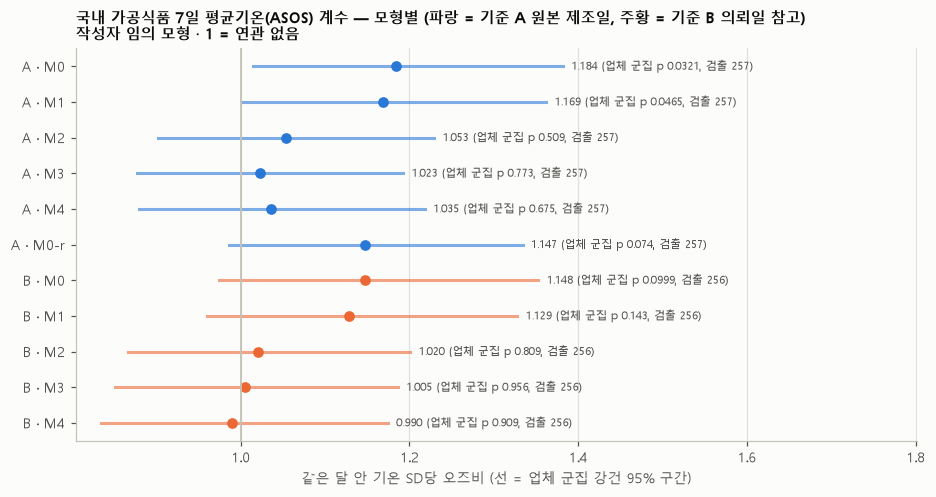

In [88]:
# [7-5-1] 모형 적합 — numpy 로 직접 구현 (7-3 의 w7_logit·w7_cluster_p 재사용, 식은 7-3 코드 주석)
# 작성자 임의 처리: 검출 0 칸이 있는 요인은 그 칸의 행을 빼고 적합(빼면 새 0 칸이 생기는지 되풀이 확인).
#   이유: 그 칸 더미 계수는 −∞ 로 가고 그 행들의 적합 확률은 0 이 되어, 기온 계수의 점수·헤시안에 기여하지 않음 → 극한에서 전체 행 적합과 같음
# 오즈비: 1℃당 = exp(b/SD_기온),  같은 달 안 기온 SD당 = exp(b/SD_기온 × SD_달안)  (SD_달안 은 대상 행 전체에서 한 값으로 고정해 모형끼리 같은 눈금)
# 기온 편차 모형(M4)도 같은 SD_달안 눈금으로 환산
# 우도비 p: 같은 요인 더미만 있는 모형 vs 기온(또는 편차) 추가 모형, LR = 2(ℓ1−ℓ0), 자유도 1
# 군집 강건 p: V = H⁻¹(Σ_g s_g s_gᵀ)H⁻¹ — 업체 군집(식별 불가 = 의뢰키), 검사기관 군집. 소표본 보정 없음
import math


def w7b_fit(fr, factors, tcol, wsd, keep=None):
    '''fr: 행 표(pos, 업체군집, 기관, 요인 열, 기온 열). 반환: (결과 dict, 적합에 쓴 행 bool 배열, 뺀 칸 목록 [(요인, 칸, 행 수)])
    뺀 칸의 행 수는 그 시점에 남아 있던 행 기준 (앞 요인에서 이미 빠진 행은 다시 세지 않음)'''
    keep = np.ones(len(fr), bool) if keep is None else keep.copy()
    dropped = []
    while True:
        changed = False
        for f in factors:
            g = fr.loc[keep].groupby(f)['pos'].agg(['size', 'sum'])
            z = g[g['sum'] == 0]
            if len(z):
                dropped += [(f, i, int(n)) for i, n in z['size'].items()]
                keep = keep & ~fr[f].isin(z.index).to_numpy()
                changed = True
        if not changed:
            break
    s = fr.loc[keep]
    y = s['pos'].to_numpy(dtype=float)
    cols, ndum = [np.ones(len(s))], 0
    for f in factors:
        v = s[f].astype(str).to_numpy()
        for lv in np.unique(v)[1:]:                     # 기준 칸 = 정렬 첫 값 (기온 계수에는 영향 없음)
            cols.append((v == lv).astype(float))
            ndum += 1
    X0 = np.column_stack(cols)
    del cols
    t = s[tcol].to_numpy(dtype=float)
    sd = t.std()
    X1 = np.column_stack([X0, (t - t.mean()) / sd])
    b0, ll0, _, it0, cv0 = w7_logit(X0, y)
    b1, ll1, _, it1, cv1 = w7_logit(X1, y)
    lr = max(2 * (ll1 - ll0), 0.0)
    _, se_f, p_f, n_f = w7_cluster_p(X1, y, b1, s['업체군집'].to_numpy().astype(str))
    _, se_i, p_i, n_i = w7_cluster_p(X1, y, b1, s['기관'].to_numpy().astype(str))
    c1 = b1[-1] / sd
    res = {'사용 행': len(s), '검출': int(y.sum()), '검출 0 칸으로 뺀 행': int((~keep).sum()), '더미 수': ndum,
           '오즈비(1℃당)': round(math.exp(c1), 3), '오즈비(달 안 SD당)': round(math.exp(c1 * wsd), 3),
           'SD당 95%구간(업체 군집)': f'{math.exp((b1[-1] - 1.96 * se_f) / sd * wsd):.3f}~{math.exp((b1[-1] + 1.96 * se_f) / sd * wsd):.3f}',
           'LR p': f'{math.erfc(math.sqrt(lr / 2)):.3g}', '업체 군집 p': f'{p_f:.3g}', '업체 군집 수': n_f,
           '기관 군집 p': f'{p_i:.3g}', '기관 수': n_i, '수렴(기온 없음/있음)': f'{cv0}/{cv1}',
           '_lo': math.exp((b1[-1] - 1.96 * se_f) / sd * wsd), '_hi': math.exp((b1[-1] + 1.96 * se_f) / sd * wsd),
           '_or': math.exp(c1 * wsd), '_sd_t': sd}
    del X0, X1
    return res, keep, dropped


def w7b_wsd(t, mon):
    '''같은 달 안 기온 SD = (기온 − 그 달 평균) 의 표준편차 (7-3 과 같은 식)'''
    t = pd.Series(np.asarray(t, dtype=float))
    return float((t - t.groupby(np.asarray(mon)).transform('mean')).std(ddof=0))


_rows, _drops = [], []
for _lab, _fr, _mcol, _ycol, _tcol, _dcol in [('A 원본 제조일', W7B_BASE[W7B_BASE['A7'].notna()], '월A', '연도A', 'A7', 'devA'),
                                             ('B 의뢰일 (참고, 같은 행)', W7B_BASE[W7B_BASE['A7'].notna() & W7B_BASE['B7'].notna()], '월B', '연도B', 'B7', 'devB')]:
    _wsd = w7b_wsd(_fr[_tcol], _fr[_mcol])
    _map = {'월': _mcol, '연도': _ycol, '시도': '시도', '검사목적': '검사목적', '품목': '품목'}
    print(f'{_lab}: {len(_fr):,}행 / 검출 {int(_fr["pos"].sum())} / 같은 달 안 기온 SD {_wsd:.2f}℃ / 기온 편차 SD {_fr[_dcol].std(ddof=0):.2f}℃')
    _keep3 = None
    for _k, _d, _f in W7B_MODEL_LIST:
        _facs = [_map[x] for x in _f if x in _map]
        _t = _dcol if '기온 편차' in _f else _tcol
        _r, _kp, _dr = w7b_fit(_fr, _facs, _t, _wsd)
        if _k == 'M3':
            _keep3 = _kp
        if _k == 'M2' and _lab.startswith('A'):
            _keep2A = _kp                                # 아래 참고 셀(시도·기온 잔차)에서 씀
        _rows.append({'기준': _lab, '모형': _k, '설명': _d, '달 안 SD(℃)': round(_wsd, 2), **_r})
        _drops.append((_lab, _k, _dr))
    if _lab.startswith('A'):
        _r, _, _dr = w7b_fit(_fr, [_mcol], _tcol, _wsd, keep=_keep3)
        _rows.append({'기준': _lab, '모형': 'M0-r', '설명': 'M3 적합 행에서 M0 (참고)', '달 안 SD(℃)': round(_wsd, 2), **_r})
W7B_MODELS = pd.DataFrame(_rows)
print('검출 0 칸 때문에 뺀 칸 (모형별, 되풀이 확인 포함)')
for _lab, _k, _dr in _drops:
    if _dr:
        print(f'  {_lab} {_k}: ' + ', '.join(f'{_f}={_i}({_n:,})' for _f, _i, _n in _dr))
# 기준 A M3 에서 뺀 행을 요인별로 나눔 (앞 요인에서 이미 빠진 행은 뒤 요인에서 다시 세지 않음)
_dr3 = next(_d for _l, _k, _d in _drops if _l.startswith('A') and _k == 'M3')
_n_ys = sum(_n for _f, _i, _n in _dr3 if _f in ('연도A', '시도'))
_n_pi = sum(_n for _f, _i, _n in _dr3 if _f in ('검사목적', '품목'))
print(f'  → 기준 A M3 에서 뺀 {_n_ys + _n_pi:,}행 = 연도·시도 칸 {_n_ys:,}행 + 검사목적·품목 칸 {_n_pi:,}행')
_nc = W7B_MODELS['수렴(기온 없음/있음)'].ne('True/True')
print('수렴 실패 모형:', '없음' if not _nc.any() else W7B_MODELS.loc[_nc, ['기준', '모형']].values.tolist())
display(W7B_MODELS.drop(columns=['_lo', '_hi', '_or', '_sd_t']))

# 그림: 같은 달 안 기온 SD당 오즈비와 업체 군집 강건 95% 구간
fig, ax = plt.subplots(figsize=(8.6, 4.6))
_m = W7B_MODELS.reset_index(drop=True)
_y = np.arange(len(_m))[::-1]
for _yi, (_, _r) in zip(_y, _m.iterrows()):
    _c = C1 if _r['기준'].startswith('A') else C2
    ax.plot([_r['_lo'], _r['_hi']], [_yi, _yi], color=_c, lw=2, alpha=0.6)
    ax.plot(_r['_or'], _yi, 'o', color=_c, ms=6)
    ax.text(_r['_hi'] + 0.01, _yi, f"{_r['_or']:.3f} (업체 군집 p {_r['업체 군집 p']}, 검출 {_r['검출']})", va='center', fontsize=7.5, color=INK2)
ax.axvline(1, color=GRAY, lw=1.2)
ax.set_yticks(_y)
ax.set_yticklabels([f"{'A' if b.startswith('A') else 'B'} · {k}" for b, k in zip(_m['기준'], _m['모형'])])
ax.grid(axis='y', visible=False)
ax.set_xlim(min(0.85, _m['_lo'].min() - 0.03), _m['_hi'].max() + 0.42)
ax.set_xlabel('같은 달 안 기온 SD당 오즈비 (선 = 업체 군집 강건 95% 구간)')
ax.set_title('국내 가공식품 7일 평균기온(ASOS) 계수 — 모형별 (파랑 = 기준 A 원본 제조일, 주황 = 기준 B 의뢰일 참고)\n작성자 임의 모형 · 1 = 연관 없음', fontsize=10)
fig.tight_layout()
plt.show()

In [89]:
# [7-5-1 참고] 사전 목록 밖 — 검증 뒤 추가한 설명용 계산 (p값은 싣지 않음). 작성자 임의 방법
# (1) 기온 잔차 SD: M2 적합 행에서 기온을 더미에 최소제곱 회귀한 뒤 남은 부분의 표준편차
#     월 더미만 vs 월·연도·시도 더미 — 보정 뒤 기온 변동이 얼마나 남는지 (많이 줄면 작은 차이를 가려낼 힘이 줄고, 적게 줄면 계수 변화는 다른 이유)
# (2) 시도별 행·검출·검출률과 '같은 달 평균을 뺀 7일 기온'의 평균 (달 평균 = 7-5-1 기준 A 대상 213,220행의 월별 평균)
#     시도 이름 = 그 시도 행 주소(addr) 첫 단어 중 가장 많은 값 (표시용)
# (3) 시도 하나씩 빼고 M1(월·연도 더미 + 기온)을 다시 적합한 같은 달 안 SD당 오즈비와 업체 군집 95% 구간
#     17개 시도를 모두 한 번씩 뺌(한 곳만 골라 빼지 않음). 여러 번 비교라 p값은 싣지 않음. SD 눈금은 7-5-1 과 같은 값(모든 대상 행의 달 안 SD)
_fr = W7B_BASE[W7B_BASE['A7'].notna()]
_s2 = _fr[_keep2A]
print(f'M2 적합 행 {len(_s2):,} (검출 0 칸으로 뺀 {int((~_keep2A).sum()):,}행 제외)')


def w7b_resid_sd(frame, cols, tcol):
    '''frame[tcol] 을 cols 더미(기준 칸 = 정렬 첫 값)와 절편에 최소제곱 회귀한 잔차의 SD(ddof=0)'''
    X = [np.ones(len(frame))]
    for c in cols:
        v = frame[c].astype(str).to_numpy()
        X += [(v == lv).astype(float) for lv in np.unique(v)[1:]]
    X = np.column_stack(X)
    t = frame[tcol].to_numpy(dtype=float)
    beta = np.linalg.lstsq(X, t, rcond=None)[0]
    return float((t - X @ beta).std())


_sd_m = w7b_resid_sd(_s2, ['월A'], 'A7')
_sd_mys = w7b_resid_sd(_s2, ['월A', '연도A', '시도'], 'A7')
print(f'기온 잔차 SD (M2 적합 행): 월 더미만 {_sd_m:.3f}℃ → 월·연도·시도 더미 {_sd_mys:.3f}℃ ({(1 - _sd_mys / _sd_m) * 100:.1f}% 줄어듦)')

_wdev = _fr['A7'] - _fr.groupby('월A')['A7'].transform('mean')
_first = dfx.loc[_fr.index, 'addr'].astype('string').str.split().str[0]
_sname = pd.DataFrame({'시도': _fr['시도'], 'nm': _first}).dropna().groupby('시도')['nm'].agg(lambda s: s.value_counts().index[0])
W7B_SIDO = (pd.DataFrame({'시도': _fr['시도'], 'pos': _fr['pos'], 'wdev': _wdev})
            .groupby('시도').agg(행=('pos', 'size'), 검출=('pos', 'sum'), 달평균뺀기온=('wdev', 'mean')))
W7B_SIDO.insert(0, '주소 첫 단어(최다)', _sname.reindex(W7B_SIDO.index))
# 시도 수준 상관 (반올림 전 값으로): 가중 없음 = 17개 점 동등 / 행 수 가중
_wt = W7B_SIDO['행'].to_numpy(float)
_xv, _yv = W7B_SIDO['달평균뺀기온'].to_numpy(float), (W7B_SIDO['검출'] / W7B_SIDO['행']).to_numpy(float)
_xm, _ym = np.average(_xv, weights=_wt), np.average(_yv, weights=_wt)
_wcorr = np.average((_xv - _xm) * (_yv - _ym), weights=_wt) / np.sqrt(np.average((_xv - _xm) ** 2, weights=_wt) * np.average((_yv - _ym) ** 2, weights=_wt))
_ucorr = float(np.corrcoef(_xv, _yv)[0, 1])
W7B_SIDO['검출률(%)'] = (W7B_SIDO['검출'] / W7B_SIDO['행'] * 100).round(3)
W7B_SIDO['달 평균 뺀 7일 기온 평균(℃)'] = W7B_SIDO.pop('달평균뺀기온').round(2)
W7B_SIDO['M2 에서 뺌(검출 0)'] = np.where(W7B_SIDO['검출'].eq(0), '예', '')
# 시도 검출이 한 업체에 몰렸는지: 검출 행의 업체 군집(7-5-1 규칙) 수와 한 군집 최다 검출 (검출 없는 시도는 개수 0)
_kc = _fr.loc[_fr['pos'] == 1].groupby(['시도', '업체군집']).size()
W7B_SIDO['검출 업체 군집 수'] = _kc.groupby(level=0).size().reindex(W7B_SIDO.index, fill_value=0)
W7B_SIDO['한 군집 최다 검출'] = _kc.groupby(level=0).max().reindex(W7B_SIDO.index, fill_value=0)
print(f'시도 {len(W7B_SIDO)}곳: 달 평균 뺀 기온 평균과 검출률의 상관 — 가중 없음 {_ucorr:.3f} · 행 수 가중 {_wcorr:.3f} (17개 점, 칸마다 검출 0~83건이라 불안정)')

# (3) 시도 하나씩 뺀 M1 — w7b_fit 재사용 (검출 0 칸 처리도 7-5-1 과 같음)
_wsdA = w7b_wsd(_fr['A7'], _fr['월A'])
_m1_or = float(W7B_MODELS.loc[W7B_MODELS['기준'].str.startswith('A') & W7B_MODELS['모형'].eq('M1'), '_or'].iloc[0])
_loo = {}
for _sc in W7B_SIDO.index:
    _r, _, _ = w7b_fit(_fr, ['월A', '연도A'], 'A7', _wsdA, keep=(_fr['시도'] != _sc).to_numpy())
    _loo[_sc] = _r
W7B_SIDO['이 시도 뺀 M1 SD당 OR'] = [round(_loo[i]['_or'], 3) for i in W7B_SIDO.index]
W7B_SIDO['95% 구간(업체 군집)'] = [_loo[i]['SD당 95%구간(업체 군집)'] for i in W7B_SIDO.index]
_nc_loo = [i for i in W7B_SIDO.index if _loo[i]['수렴(기온 없음/있음)'] != 'True/True']
_or_loo = pd.Series({i: _loo[i]['_or'] for i in W7B_SIDO.index})
_rest = _or_loo.drop(_or_loo.idxmin())
print(f'시도 하나씩 뺀 M1 ({len(_or_loo)}번 적합, 전체 행 M1 {_m1_or:.3f}, 수렴 실패 {len(_nc_loo)}번): '
      f'가장 작음 = 시도 {_or_loo.idxmin()} 뺄 때 {_or_loo.min():.3f} ({_loo[_or_loo.idxmin()]["SD당 95%구간(업체 군집)"]}, 사용 행 {_loo[_or_loo.idxmin()]["사용 행"]:,}·검출 {_loo[_or_loo.idxmin()]["검출"]}) '
      f'/ 나머지 {len(_rest)}곳을 하나씩 뺄 때 {_rest.min():.3f}~{_rest.max():.3f}')
del _s2, _loo
W7B_SIDO.sort_values('달 평균 뺀 7일 기온 평균(℃)')

M2 적합 행 209,109 (검출 0 칸으로 뺀 4,111행 제외)
기온 잔차 SD (M2 적합 행): 월 더미만 2.885℃ → 월·연도·시도 더미 2.673℃ (7.3% 줄어듦)
시도 17곳: 달 평균 뺀 기온 평균과 검출률의 상관 — 가중 없음 0.375 · 행 수 가중 0.310 (17개 점, 칸마다 검출 0~83건이라 불안정)
시도 하나씩 뺀 M1 (17번 적합, 전체 행 M1 1.169, 수렴 실패 0번): 가장 작음 = 시도 50 뺄 때 1.018 (0.878~1.181, 사용 행 207,317·검출 225) / 나머지 16곳을 하나씩 뺄 때 1.156~1.216


,주소 첫 단어(최다),행,검출,검출률(%),달 평균 뺀 7일 기온 평균(℃),M2 에서 뺌(검출 0),검출 업체 군집 수,한 군집 최다 검출,이 시도 뺀 M1 SD당 OR,95% 구간(업체 군집)
시도,,,,,,,,,,
51,강원도,13656,4,0.029,-0.70,,3,2,1.156,0.990~1.351
43,충청북도,25951,31,0.119,-0.70,,21,5,1.175,0.998~1.383
44,충청남도,18913,12,0.063,-0.56,,10,2,1.167,0.999~1.363
41,경기도,62594,83,0.133,-0.55,,65,4,1.215,0.999~1.478
28,인천광역시,7513,9,0.120,-0.42,,9,1,1.181,1.010~1.381
36,세종특별자치시,1026,0,0.000,-0.32,예,0,0,1.168,1.002~1.361
52,전라북도,16535,6,0.036,0.02,,6,1,1.162,0.996~1.355
47,경상북도,11745,46,0.392,0.18,,25,7,1.174,0.988~1.396
11,서울특별시,11848,9,0.076,0.24,,8,2,1.196,1.020~1.402


📊 **결과**
- 대상은 7-3 과 같은 213,220행·검출 257 입니다. 업체 식별 불가 행 20.2% 는 의뢰키로 묶어 업체 군집 35,460개, 검사기관 254곳(검출 있는 기관 41곳)입니다. 품목은 25개 중 1,000행 이상 12개를 두고 13개(2,428행)를 '그 외'로 묶었습니다.
- 검출 0 칸 (작성자 임의로 그 칸 행을 빼고 적합): 연도 2015(15행), 시도 30·36(3,070·1,026행), 검사목적 품질검사(26,580행)·자가품질직접검사(영업자)(4,140행) 등 6칸, 품목 알가공품류(20,494행)·빙과류(18,322행)·음료류·조미식품·그 외·절임류 또는 조림류 6칸.
  - 그래서 M3 은 139,431행으로 적합했습니다. 뺀 73,789행 = 연도·시도 칸 4,111행 + 검사목적·품목 칸 69,678행 (앞 요인에서 이미 빠진 행은 다시 세지 않음). 수렴 실패 모형은 없습니다.
- 같은 달 안 기온 SD(2.88℃)당 오즈비 (업체 군집 강건 95% 구간) · 우도비 p · 업체 군집 p · 검사기관 군집 p — 기준 A
  - M0 월: 1.184 (1.015\~1.382) · 0.0101 · 0.0321 · 0.218 (1℃당 1.060)
  - M1 +연도: 1.169 (1.002\~1.362) · 0.0194 · 0.0465 · 0.245 (1℃당 1.056)
  - M2 +시도: 1.053 (0.903\~1.229) · 0.451 · 0.509 · 0.45 (1℃당 1.018)
  - M3 +검사목적·품목: 1.023 (0.877\~1.193) · 0.746 · 0.773 · 0.759 (1℃당 1.008)
  - M4 월·연도·시도 + 기온 편차: 1.035 (0.880\~1.218) · 0.652 · 0.675 · 0.727 (편차 1℃당 1.012, 편차 SD 2.50℃)
  - 참고 M0-r (M3 적합 행 139,431행에서 M0): 1.147 (0.987\~1.334) · 0.0344 · 0.074 · 0.277
- 참고 기준 B (같은 행 중 기준 B 7일 값도 있는 212,780행·검출 256, 달 안 SD 2.90℃): M0 1.148 (업체 군집 p 0.0999) → M1 1.129 (0.143) → M2 1.020 (0.809) → M3 1.005 (0.956) → M4 0.990 (0.909).
- 용어
  - **오즈비** = 검출 오즈(검출 ÷ 비검출)가 몇 배가 되는지. 1 이면 차이 없음, 1 보다 크면 기온이 높은 쪽에서 검출이 더 잦음.
  - **SD(표준편차)** = 값이 평균에서 보통 얼마나 흩어져 있는지. **같은 달 안 기온 SD** = 각 행 기온에서 그 달 평균을 뺀 값의 SD (같은 달 안에서 기온이 보통 움직이는 폭, 여기서는 2.88℃).
  - **우도비 p** = 같은 모형에서 기온 하나만 넣고 뺀 두 모형의 맞음 정도(우도) 차이로 계산한 p. **군집 강건 p** = 같은 업체(또는 같은 검사기관) 행끼리 닮은 점을 반영해 다시 계산한 p.
- M0 의 업체 군집 p 0.0321 은 7-3 의 0.0311 과 다릅니다. 7-3 은 업체 식별 불가 행을 한 행 = 한 군집으로 쳤고, 여기서는 의뢰키로 묶었기 때문입니다 (오즈비·우도비 p 는 같음). 최종 노트북에서 어느 규칙 하나로 맞출지는 정할 일로 남깁니다.
- **참고 (사전 목록 밖, 검증 뒤 추가한 설명용 계산 — p값 없음)**
  - 기온 잔차 SD (M2 적합 209,109행; 더미로 설명하고 남은 기온 흔들림의 크기): 월 더미만 2.885℃ → 월·연도·시도 더미 2.673℃ (7.3% 줄어듦).
  - 시도별 (행 / 검출 / 검출률 / 같은 달 평균을 뺀 7일 기온 평균): 제주특별자치도(50) 5,889 / 32 / 0.543% / +3.46℃ · 대구광역시(27) 682 / 8 / 1.173% / +1.45℃ · 경상북도(47) 11,745 / 46 / 0.392% / +0.18℃ · 경기도(41) 62,594 / 83 / 0.133% / -0.55℃ · 강원도(51) 13,656 / 4 / 0.029% / -0.70℃.
  - 검출이 한 업체에 몰렸는지 (검출 업체 군집 수 / 한 군집 최다 검출): 제주(50) 20곳 / 7건 · 대구(27) 3곳 / 6건 · 경북(47) 25곳 / 7건.
  - 시도 17곳 수준 상관 (달 평균 뺀 기온 평균 vs 검출률): 가중 없음 0.375 · 행 수 가중 0.310 (17개 점이라 불안정).
  - 시도를 하나씩 빼고 M1(월·연도 더미 + 기온)을 17번 다시 적합: 제주(50)를 뺄 때 1.018 (업체 군집 95% 구간 0.878\~1.181, 207,317행·검출 225)로 가장 작고, 나머지 16곳을 하나씩 뺄 때는 1.156\~1.216 입니다 (전체 행 M1 1.169). 수렴 실패 0번.

💬 **첨언**
- 작성자가 임의로 모형을 늘려 본 결과, **연도를 더해도 계수는 거의 그대로(1.184 → 1.169)** 이지만 **시도를 더하면 1.053 으로 줄고 p 도 커집니다(업체 군집 p 0.509).** 7-3 의 "같은 달 안 기온 계수 양수"의 상당 부분은 지역(시도)마다 기온과 검출률이 함께 다른 데서 왔을 수 있어 보입니다 (추정). 7-4 에서 관측소와 먼 행(천안·수원 연결 행이 절반 이상)에서 기울기가 가장 가팔랐던 것과 같은 방향입니다.
  - 참고 계산에서 시도를 넣어도 기온의 남은 변동은 7.3% 만 줄었습니다 (2.885 → 2.673℃). 그래서 계수가 준 것은 남은 기온 변동이 부족해져서라기보다, 시도 사이 검출률 차이와 함께 움직이던 부분이 빠져서로 보입니다 (추정).
  - 예: 제주(50)는 같은 달 평균보다 +3.46℃ 따뜻하고 검출률 0.543% 로 높습니다. 제주 한 곳만 빼도 M1 이 1.169 → 1.018 로 줄어, 따뜻하면서 검출률이 높은 한 지역이 M0·M1 계수를 끌어올렸을 수 있어 보입니다 (추정). 반대로 경북(47)은 +0.18℃ 인데 0.392% 로 높아, 지역 사이 검출률 차이가 기온만으로 설명되는 모양은 아닙니다.
  - 이 참고 계산은 사전 목록 밖이고, 시도를 17번 바꿔 뺀 비교라 한 값에 무게를 두기 어렵습니다.
- M4 는 같은 관측소·같은 달의 평균을 뺀 기온(= 같은 곳에서 해마다·날마다 다른 부분)만 씁니다. 여기서도 1.035 로, "같은 곳에서 평소보다 따뜻한 때 검출이 높다"는 모양은 이 데이터에서 뚜렷하지 않아 보입니다 (추정).
  - 다만 검출이 257건뿐이라 작은 효과를 가려낼 힘이 약합니다. M4 구간(0.880\~1.218)은 연관 없음(1)과 7-3 의 1.184 를 모두 포함합니다. "연관이 없다"는 근거로 보기도 어렵습니다.
- M3 에서 빠진 73,789행(검출 0 인 연도·시도·검사목적·품목 칸의 행)만 빼 본 M0-r 은 1.147 로 M0 과 비슷합니다. M3 의 계수 감소는 행이 빠져서라기보다 시도 보정(M2)에서 이미 대부분 생긴 것으로 보입니다 (추정).
- 검출 0 칸의 행을 뺀 것은 작성자 임의 처리입니다. 그 칸 더미 계수가 끝없이 커지는 극한에서 이 행들은 기온 계수 계산에 기여하지 않으므로, 213,220행 전체로 적합한 것과 같은 결과로 봤습니다 (작성자 판단).
- 검사기관 군집 p 는 M0 에서도 0.218 로 업체 군집 p(0.0321)보다 훨씬 큽니다. 기관 254곳 중 검출 있는 기관이 41곳뿐이라 이 계산이 불안정할 수 있습니다. 한편 한 기관이 한 지역의 검사를 맡는다면 기관 묶음이 지역 차이를 담았을 수도 있습니다 (추정).
- 기준 B 도 같은 모양입니다 (시도를 더하면 1.020). 모형 11개와 p값 3종을 함께 봤으므로 작은 p값 하나하나에 무게를 두기 어렵습니다.

#### 7-5-2. 관측소 고르는 규칙 바꿔 보기

In [90]:
# [7-5-2] 관측소 규칙 목록(결과보다 먼저)과 규칙별 7일 창 기온 붙이기 — 모두 작성자 임의 방법
W7B_RULE_LIST = {
    'R1': '고정 규칙(7절): 일자료에 한 번이라도 나오는 관측소 중 가장 가까운 곳 (운영기간 안 봄)',
    'R2': 'R1 에서 ASOS 대구(기) 176, 농업기상 동방로거테스트 561034A001 을 후보에서 뺌',
    'R3': '기준 날짜(원본 제조일)의 7일 창에 값이 모두 있는 관측소만 후보, 그중 가장 가까운 곳 (날짜마다 다를 수 있음)',
}
print('비교할 관측소 규칙 (작성자 임의, 이 목록만 계산) — 기준 A 원본 제조일 7일 창, 관측망 ASOS avg_ta(주) · 농업기상 temp(참고)')
for _k, _v in W7B_RULE_LIST.items():
    print(f'  {_k}: {_v}')

# 관측소 좌표 — 7-1 과 같은 방법으로 다시 만듦 (ASOS: 같은 stn_id 여러 행이면 운영 시작일이 가장 늦은 행의 좌표)
_ids = asos['stn_id'].dropna().unique()
_st = asos_stn[asos_stn['stn_id'].isin(_ids)].sort_values(['stn_id', 'oper_start_dt'], na_position='first')
_stA = _st.groupby('stn_id').tail(1).set_index('stn_id')
_nids = nas['obsr_spot_code'].dropna().unique()
_stN = nas_stn[nas_stn['obsr_spot_code'].isin(_nids)].drop_duplicates('obsr_spot_code').set_index('obsr_spot_code')

_b = W7B_BASE
_uc = _b[['lat', 'lon']].drop_duplicates().reset_index(drop=True)
_cid = pd.MultiIndex.from_frame(_uc).get_indexer(pd.MultiIndex.from_frame(_b[['lat', 'lon']]))
assert (_cid >= 0).all()
print(f'대상 {len(_b):,}행 / 좌표 고유값 {len(_uc):,}개')

W7B_RULE_VALS = pd.DataFrame(index=_b.index)
for _net, _daily, _key, _var, _excl, _stinfo, _la, _lo in [('ASOS', asos, 'stn_id', 'avg_ta', '176', _stA, 'lat', 'lon'),
                                                         ('농업기상', nas, 'obsr_spot_code', 'temp', '561034A001', _stN, 'instl_la', 'instl_lo')]:
    _piv = _daily.pivot(index='meas_date', columns=_key, values=_var)
    _cal = pd.date_range(_piv.index.min(), _piv.index.max(), freq='D')
    _arr = _piv.reindex(_cal).rolling(7, min_periods=7).mean().to_numpy()      # 빠진 날 NaN 그대로 → 창 안 하루라도 없으면 NaN
    _cols = _piv.columns.astype(str).to_numpy()
    del _piv
    _slat = _stinfo.loc[_cols, _la].to_numpy(dtype=float)
    _slon = _stinfo.loc[_cols, _lo].to_numpy(dtype=float)
    _D = haversine_km(_uc['lat'].to_numpy()[:, None], _uc['lon'].to_numpy()[:, None], _slat[None, :], _slon[None, :])
    _di = (_b['dA'].to_numpy().astype('datetime64[D]') - np.datetime64(_cal[0].date(), 'D')).astype('int64')
    _ok = (_di >= 0) & (_di < _arr.shape[0])
    _ex = np.flatnonzero(_cols == _excl)
    print(f'{_net} {_var}: 후보 {len(_cols)}곳, 빼는 관측소 {_excl} 위치 찾음 {len(_ex)}곳 / 기준 날짜가 일자료 달력 밖인 행 {int((~_ok).sum())}')
    assert len(_ex) == 1
    _j = {}
    _j['R1'] = _D.argmin(axis=1)[_cid]
    _D2 = _D.copy()
    _D2[:, _ex[0]] = np.inf
    _j['R2'] = _D2.argmin(axis=1)[_cid]
    del _D2
    # R3: (좌표, 날짜) 고유 조합마다, 그 날짜 7일 창 값이 있는 관측소 중 최근접 — 날짜별로 묶어 계산 (행×일 폭발 없이)
    _key3 = _cid.astype(np.int64) * 100000 + _di
    _uk, _inv = np.unique(_key3[_ok], return_inverse=True)
    _ucid, _ud = _uk // 100000, _uk % 100000
    _ord = np.argsort(_ud, kind='stable')
    _res = np.full(len(_uk), -1)
    for _grp in np.split(_ord, np.flatnonzero(np.diff(_ud[_ord])) + 1):
        _av = ~np.isnan(_arr[_ud[_grp[0]]])
        if _av.any():
            _res[_grp] = np.where(_av[None, :], _D[_ucid[_grp]], np.inf).argmin(axis=1)
    _j3 = np.full(len(_b), -1)
    _j3[_ok] = _res[_inv]
    _j['R3'] = _j3
    print(f'  R3: (좌표, 날짜) 고유 조합 {len(_uk):,}개, 날짜 {len(np.unique(_ud)):,}일 / 후보가 한 곳도 없는 조합 {int((_res < 0).sum())}')
    for _rk in ['R1', 'R2', 'R3']:
        _jj = _j[_rk]
        _hv = _ok & (_jj >= 0)
        _val = np.full(len(_b), np.nan)
        _val[_hv] = _arr[_di[_hv], _jj[_hv]]
        _km = np.full(len(_b), np.nan)
        _km[_jj >= 0] = _D[_cid[_jj >= 0], _jj[_jj >= 0]]
        W7B_RULE_VALS[f'{_net}_{_rk}_stn'] = np.where(_jj >= 0, _cols[np.clip(_jj, 0, None)], None)
        W7B_RULE_VALS[f'{_net}_{_rk}_km'] = _km
        W7B_RULE_VALS[f'{_net}_{_rk}_val'] = _val
    del _arr, _D

# 재현 확인: R1 이 7절(w7) 의 관측소·7일 기온과 같은지
_same_stn = (W7B_RULE_VALS['ASOS_R1_stn'].astype(str).to_numpy() == w7.loc[_b.index, 'asos_stn'].astype(str).to_numpy()).mean()
_same_val = np.allclose(W7B_RULE_VALS['ASOS_R1_val'].to_numpy(), w7.loc[_b.index, 'avg_ta_A7'].to_numpy(), equal_nan=True)
_same_nval = np.allclose(W7B_RULE_VALS['농업기상_R1_val'].to_numpy(), w7.loc[_b.index, 'temp_A7'].to_numpy(), equal_nan=True)
print(f'R1 재현 확인 — ASOS 관측소 일치 {_same_stn * 100:.1f}%, ASOS 7일 기온 일치 {_same_val}, 농업기상 7일 기온 일치 {_same_nval}')

# 관측소가 R1 과 달라진 행: 어디서 어디로 (상위 3쌍). R3 에서 후보가 없어 관측소가 없는 행은 '다른 관측소'로 세지 않고 따로 셈
_nmA = _stA['stn_ko'].to_dict()
_nmN = _stN['obsr_spot_nm'].astype(str).to_dict()
for _net, _nm in [('ASOS', _nmA), ('농업기상', _nmN)]:
    for _rk in ['R2', 'R3']:
        _r1 = W7B_RULE_VALS[f'{_net}_R1_stn'].astype(str)
        _none = W7B_RULE_VALS[f'{_net}_{_rk}_stn'].isna()
        _rr = W7B_RULE_VALS[f'{_net}_{_rk}_stn'].astype(str)
        _dif = _r1.ne(_rr) & ~_none
        _pairs = pd.Series(list(zip(_r1[_dif], _rr[_dif]))).value_counts().head(3)
        print(f'{_net} {_rk}: R1 과 다른 관측소로 바뀐 행 {int(_dif.sum()):,} (검출 {int(_b.loc[_dif, "pos"].sum())}) / 후보가 없어 관측소 없는 행 {int(_none.sum()):,} (검출 {int(_b.loc[_none, "pos"].sum())}) — 상위: '
              + ', '.join(f'{_nm.get(a, a)}({a})→{_nm.get(c, c)}({c}) {n:,}' for (a, c), n in _pairs.items()))

비교할 관측소 규칙 (작성자 임의, 이 목록만 계산) — 기준 A 원본 제조일 7일 창, 관측망 ASOS avg_ta(주) · 농업기상 temp(참고)
  R1: 고정 규칙(7절): 일자료에 한 번이라도 나오는 관측소 중 가장 가까운 곳 (운영기간 안 봄)
  R2: R1 에서 ASOS 대구(기) 176, 농업기상 동방로거테스트 561034A001 을 후보에서 뺌
  R3: 기준 날짜(원본 제조일)의 7일 창에 값이 모두 있는 관측소만 후보, 그중 가장 가까운 곳 (날짜마다 다를 수 있음)
대상 222,607행 / 좌표 고유값 2,795개
ASOS avg_ta: 후보 99곳, 빼는 관측소 176 위치 찾음 1곳 / 기준 날짜가 일자료 달력 밖인 행 0
  R3: (좌표, 날짜) 고유 조합 153,833개, 날짜 3,772일 / 후보가 한 곳도 없는 조합 0
농업기상 temp: 후보 219곳, 빼는 관측소 561034A001 위치 찾음 1곳 / 기준 날짜가 일자료 달력 밖인 행 0
  R3: (좌표, 날짜) 고유 조합 153,833개, 날짜 3,772일 / 후보가 한 곳도 없는 조합 685
R1 재현 확인 — ASOS 관측소 일치 100.0%, ASOS 7일 기온 일치 True, 농업기상 7일 기온 일치 True
ASOS R2: R1 과 다른 관측소로 바뀐 행 6,928 (검출 26) / 후보가 없어 관측소 없는 행 0 (검출 0) — 상위: 대구(기)(176)→대구(143) 6,928
ASOS R3: R1 과 다른 관측소로 바뀐 행 9,387 (검출 31) / 후보가 없어 관측소 없는 행 0 (검출 0) — 상위: 대구(기)(176)→대구(143) 6,928, 서청주(181)→청주(131) 434, 북부산(296)→김해시(253) 323
농업기상 R2: R1 과 다른 관측소로 바뀐 행 1,010 (검출 1) / 후보가 없어 관측소 없는 행 0 (검출 0) — 상위: 동방로거테스트(561034A001)→정읍시 정우면(580813A001) 1,010
농업기상 R3

In [91]:
# [7-5-2] 규칙별 요약 — 연결·5분위(w7_qtab)·M0/M2(w7b_fit)·20km 초과 행 (20km 는 7-4 와 같은 작성자 임의 기준)
_ngp = int((w7['그룹'] == '국내 가공식품').sum())
_rows, _qrows, _ext_q = [], [], {}
for _net in ['ASOS', '농업기상']:
    for _rk in ['R1', 'R2', 'R3']:
        _fr = W7B_BASE[['pos', '월A', '연도A', '시도', '업체군집', '기관']].copy()
        _fr['T'] = W7B_RULE_VALS[f'{_net}_{_rk}_val']
        _fr['km'] = W7B_RULE_VALS[f'{_net}_{_rk}_km']
        _nodrop = len(_fr)
        _fr = _fr[_fr['T'].notna()]                      # 7일 창에 하루라도 값이 없으면 뺌 (뺀 행 수는 표에 적음)
        _wsd = w7b_wsd(_fr['T'], _fr['월A'])
        _r0, _, _ = w7b_fit(_fr, ['월A'], 'T', _wsd)
        _r2, _, _ = w7b_fit(_fr, ['월A', '연도A', '시도'], 'T', _wsd)
        _far = _fr['km'] > 20
        _dif = (W7B_RULE_VALS.loc[_fr.index, f'{_net}_R1_stn'].astype(str) != W7B_RULE_VALS.loc[_fr.index, f'{_net}_{_rk}_stn'].astype(str))
        # R1 과 비교: R1 에서 값이 있던 행의 값이 바뀌었나 / 빠졌나, R1 에서 값이 없던 행이 새로 붙었나
        _v1 = W7B_RULE_VALS[f'{_net}_R1_val'].to_numpy()
        _vk = W7B_RULE_VALS[f'{_net}_{_rk}_val'].to_numpy()
        _chg = ~np.isnan(_v1) & ~np.isnan(_vk) & ~np.isclose(_v1, _vk, rtol=0, atol=1e-9)
        _lost = ~np.isnan(_v1) & np.isnan(_vk)
        _new = np.isnan(_v1) & ~np.isnan(_vk)
        _same = ~np.isnan(_v1) & ~np.isnan(_vk) & ~_chg       # R1 과 같은 행에 같은 값
        if _net == '농업기상':                                 # 극단 7일 평균 행이 어느 5분위에 들어가는지 (w7_qtab 과 같은 pd.qcut 5등분)
            _cut = pd.qcut(_fr['T'], 5, labels=False, duplicates='drop') + 1
            _ext_q[_rk] = (_cut[_fr['T'] < -20].value_counts().sort_index(), _cut[_fr['T'] > 35].value_counts().sort_index())
        _rows.append({'관측망': _net, '규칙': _rk, '연결 행': len(_fr), '뺀 행(7일 창 값 없음)': _nodrop - len(_fr),
                      '원본 제조일 행 중(%)': round(len(_fr) / len(W7B_BASE) * 100, 1),
                      '가공식품 전체 중(%)': round(len(_fr) / _ngp * 100, 1), '검출': int(_fr['pos'].sum()),
                      'R1 과 관측소 다른 연결 행': int(_dif.sum()),
                      'R1 값 있던 행 중 값 바뀐 행': int(_chg.sum()), 'R1 값 있던 행 중 빠진 행': int(_lost.sum()),
                      'R1 에 없다가 새로 붙은 행(검출)': f"{int(_new.sum()):,}({int(W7B_BASE['pos'].to_numpy()[_new].sum())})",
                      'R1 과 같은 값인 행(연결 행 중 %)': round(_same.sum() / len(_fr) * 100, 1),
                      '달 안 SD(℃)': round(_wsd, 2),
                      'M0 SD당 OR': _r0['오즈비(달 안 SD당)'], 'M0 업체 군집 p': _r0['업체 군집 p'],
                      'M2 SD당 OR': _r2['오즈비(달 안 SD당)'], 'M2 업체 군집 p': _r2['업체 군집 p'], 'M2 검출 0 칸 뺀 행': _r2['검출 0 칸으로 뺀 행'],
                      '20km 초과 행(%)': round(_far.mean() * 100, 1), '20km 초과 검출': int(_fr.loc[_far, 'pos'].sum()),
                      '수렴 M0/M2': f"{_r0['수렴(기온 없음/있음)']} · {_r2['수렴(기온 없음/있음)']}"})
        for _sub, _ff in [('전체', _fr), ('20km 초과', _fr[_far])]:
            _t, _ = w7_qtab(_ff, 'T')
            _q = {'관측망': _net, '규칙': _rk, '행 묶음': _sub, '행': int(_t['행수'].sum()), '검출': int(_t['검출'].sum())}
            _q.update({f'{i}(%)': v for i, v in _t['검출률(%)'].items()})
            _q['Q1~Q5 검출'] = '·'.join(str(int(k)) for k in _t['검출'])
            _q['Q1·Q5 기온 범위'] = f"{_t['값 범위'].iloc[0]} / {_t['값 범위'].iloc[-1]}"
            _q['비고'] = '표본 작음' if _q['검출'] < 50 else ''
            _qrows.append(_q)
W7B_RULES = pd.DataFrame(_rows)
W7B_RULE_Q = pd.DataFrame(_qrows)
# 원자료 상태 확인(고치지 않음): 7일 평균기온이 -20℃ 미만 또는 35℃ 초과인 행 — 표시 기준은 작성자 임의, 계산에서 빼지 않음
for _net in ['ASOS', '농업기상']:
    print(f'{_net} 7일 평균기온 -20℃ 미만 / 35℃ 초과 행 (규칙 R1·R2·R3): '
          + ' · '.join(f"{int((W7B_RULE_VALS[f'{_net}_{_rk}_val'] < -20).sum())} / {int((W7B_RULE_VALS[f'{_net}_{_rk}_val'] > 35).sum())}" for _rk in ['R1', 'R2', 'R3']))
# 농업기상 극단 7일 평균이 어떤 일값에서 나왔는지 (값은 고치지 않고 보여 주기만)
_ext_idx = {_rk: set(W7B_RULE_VALS.index[(W7B_RULE_VALS[f'농업기상_{_rk}_val'] < -20) | (W7B_RULE_VALS[f'농업기상_{_rk}_val'] > 35)]) for _rk in ['R1', 'R2', 'R3']}
print(f"농업기상 극단 행 집합이 세 규칙에서 같은가: {_ext_idx['R1'] == _ext_idx['R2'] == _ext_idx['R3']}")
_em = W7B_RULE_VALS.index.isin(list(_ext_idx['R1']))
_ex = pd.DataFrame({'관측소': W7B_RULE_VALS.loc[_em, '농업기상_R1_stn'].astype(str), '기준 날짜': W7B_BASE.loc[_em, 'dA'],
                    'pos': W7B_BASE.loc[_em, 'pos'], '7일 평균': W7B_RULE_VALS.loc[_em, '농업기상_R1_val']})
_nd = nas[nas['obsr_spot_code'].isin(_ex['관측소'].unique())].set_index(['obsr_spot_code', 'meas_date']).sort_index()
_erows = []
for (_st_, _dt_), _g in _ex.groupby(['관측소', '기준 날짜']):
    _win = _nd.loc[(_st_, slice(_dt_ - pd.Timedelta(days=6), _dt_)), :]
    _erows.append({'관측소': f"{_st_} {_nmN.get(_st_, '')}", '기준 날짜': f'{_dt_:%Y-%m-%d}', '행': len(_g), '검출': int(_g['pos'].sum()),
                   '7일 평균(℃)': round(float(_g['7일 평균'].iloc[0]), 1),
                   '창 7일 일평균 temp': ' '.join(f'{v:.1f}' for v in _win['temp']),
                   '창 최저기온 최소': float(_win['lowst_artmp'].min()), '창 최고기온 최대': float(_win['hghst_artmp'].max()),
                   '창 습도 범위(%)': f"{_win['hum'].min():.1f}~{_win['hum'].max():.1f}",
                   # 5절 경계값: temp·최고기온·최저기온 중 하나라도 정확히 ±50 인 날
                   '창 안 ±50 경계값 날': int((_win[['temp', 'hghst_artmp', 'lowst_artmp']].abs() == 50).any(axis=1).sum())})
W7B_NAS_EXT = pd.DataFrame(_erows)
print(f'농업기상 7일 평균 -20℃ 미만·35℃ 초과 행의 (관측소, 기준 날짜) {len(W7B_NAS_EXT)}개 — 창 안 일값 원자료 그대로')
display(W7B_NAS_EXT)
print(f"  이 창 {len(W7B_NAS_EXT)}개 안 ±50 경계값 날(temp·최고·최저 중 하나라도 ±50) 합 {int(W7B_NAS_EXT['창 안 ±50 경계값 날'].sum())}일")


def _qlab(vc):
    return ', '.join(f'Q{int(q)} {int(n)}행' for q, n in vc.items()) or '없음'


print('  극단 행이 들어간 5분위 (규칙별 행 묶음 안 5등분): '
      + ' · '.join(f'{_rk} -20℃ 미만 [{_qlab(_lo)}] 35℃ 초과 [{_qlab(_hi)}]' for _rk, (_lo, _hi) in _ext_q.items()))
_tt, _lt = nas['temp'], nas['lowst_artmp']
print(f"농업기상 temp 일값 전체(값 있는 {int(_tt.notna().sum()):,}일): -30℃ 이하 {int((_tt <= -30).sum())}일 · 정확히 -40.0℃ {int((_tt == -40).sum())}일 · -49℃ 이하 {int((_tt <= -49).sum())}일 · 40℃ 이상 {int((_tt >= 40).sum())}일 · 49℃ 이상 {int((_tt >= 49).sum())}일"
      f" / 최저기온(lowst_artmp) 정확히 -40.0℃ {int((_lt == -40).sum())}일")
_top40 = nas.loc[_tt == -40, 'obsr_spot_code'].value_counts().head(3)
print(f'  temp 가 정확히 -40.0℃ 인 날의 관측소 (많은 순, 최대 3곳 — 전체 {int(nas.loc[_tt == -40, "obsr_spot_code"].nunique())}곳): '
      + ', '.join(f"{c} {_nmN.get(c, '')} {int(n)}일" for c, n in _top40.items()))
del _nd, _ex, _tt, _lt
print(f'규칙별 요약 — 대상: 국내 가공식품 {_ngp:,}행 중 원본 제조일 있는 {len(W7B_BASE):,}행. 연결 = 7일 창 값이 모두 있는 행')
display(W7B_RULES)
print('규칙별 기온 5분위 검출률 (각 행 묶음 안에서 다시 5등분)')
W7B_RULE_Q

ASOS 7일 평균기온 -20℃ 미만 / 35℃ 초과 행 (규칙 R1·R2·R3): 0 / 0 · 0 / 0 · 0 / 0
농업기상 7일 평균기온 -20℃ 미만 / 35℃ 초과 행 (규칙 R1·R2·R3): 29 / 4 · 29 / 4 · 29 / 4
농업기상 극단 행 집합이 세 규칙에서 같은가: True
농업기상 7일 평균 -20℃ 미만·35℃ 초과 행의 (관측소, 기준 날짜) 13개 — 창 안 일값 원자료 그대로


,관측소,기준 날짜,행,검출,7일 평균(℃),창 7일 일평균 temp,창 최저기온 최소,창 최고기온 최대,창 습도 범위(%),창 안 ±50 경계값 날
0,449872A001 용인시 처인구,2023-08-21,1,0,35.8,27.2 26.5 31.1 39.2 41.2 42.6 42.7,21.8,45.0,75.9~79.6,0
1,449872A001 용인시 처인구,2023-08-23,1,0,39.9,31.1 39.2 41.2 42.6 42.7 41.8 40.4,21.8,45.0,76.2~92.2,0
2,449872A001 용인시 처인구,2023-08-24,1,0,41.1,39.2 41.2 42.6 42.7 41.8 40.4 39.9,35.2,45.0,76.2~93.9,0
3,449872A001 용인시 처인구,2023-08-25,1,0,41.3,41.2 42.6 42.7 41.8 40.4 39.9 40.7,36.8,45.0,76.2~93.9,0
4,451873A001 평택시 오성면,2020-02-06,4,0,-23.9,2.0 1.1 -23.9 -40.0 -40.0 -40.0 -26.7,-40.0,7.4,56.9~86.0,0
5,621100A001 김해시 전하동,2018-01-15,2,0,-26.1,-39.5 -39.6 -25.2 -4.3 -1.5 -33.6 -39.0,-40.0,12.8,0.4~58.9,0
6,621100A001 김해시 전하동,2018-01-16,1,0,-26.1,-39.6 -25.2 -4.3 -1.5 -33.6 -39.0 -39.2,-40.0,12.8,0.4~58.9,0
7,621100A001 김해시 전하동,2018-01-17,4,0,-25.9,-25.2 -4.3 -1.5 -33.6 -39.0 -39.2 -38.7,-40.0,12.8,0.8~58.9,0
8,621100A001 김해시 전하동,2018-01-18,10,0,-23.2,-4.3 -1.5 -33.6 -39.0 -39.2 -38.7 -5.9,-39.9,12.8,0.8~58.9,0
9,621100A001 김해시 전하동,2019-12-04,3,0,-29.8,13.0 -23.2 -39.7 -39.9 -39.6 -39.7 -39.7,-40.0,32.7,0.0~73.2,0


  이 창 13개 안 ±50 경계값 날(temp·최고·최저 중 하나라도 ±50) 합 0일
  극단 행이 들어간 5분위 (규칙별 행 묶음 안 5등분): R1 -20℃ 미만 [Q1 29행] 35℃ 초과 [Q5 4행] · R2 -20℃ 미만 [Q1 29행] 35℃ 초과 [Q5 4행] · R3 -20℃ 미만 [Q1 29행] 35℃ 초과 [Q5 4행]
농업기상 temp 일값 전체(값 있는 876,899일): -30℃ 이하 227일 · 정확히 -40.0℃ 143일 · -49℃ 이하 1일 · 40℃ 이상 38일 · 49℃ 이상 3일 / 최저기온(lowst_artmp) 정확히 -40.0℃ 173일
  temp 가 정확히 -40.0℃ 인 날의 관측소 (많은 순, 최대 3곳 — 전체 2곳): 588802A001 무주군 무주읍 140일, 451873A001 평택시 오성면 3일
규칙별 요약 — 대상: 국내 가공식품 294,421행 중 원본 제조일 있는 222,607행. 연결 = 7일 창 값이 모두 있는 행


,관측망,규칙,연결 행,뺀 행(7일 창 값 없음),원본 제조일 행 중(%),가공식품 전체 중(%),검출,R1 과 관측소 다른 연결 행,R1 값 있던 행 중 값 바뀐 행,R1 값 있던 행 중 빠진 행,R1 에 없다가 새로 붙은 행(검출),R1 과 같은 값인 행(연결 행 중 %),달 안 SD(℃),M0 SD당 OR,M0 업체 군집 p,M2 SD당 OR,M2 업체 군집 p,M2 검출 0 칸 뺀 행,20km 초과 행(%),20km 초과 검출,수렴 M0/M2
0,ASOS,R1,213220,9387,95.8,72.4,257,0,0,0,0(0),100.0,2.88,1.184,0.0321,1.053,0.509,4111,25.4,43,True/True · True/True
1,ASOS,R2,220148,2459,98.9,74.8,283,6928,0,0,"6,928(26)",96.9,2.88,1.173,0.0358,1.016,0.834,4114,25.9,48,True/True · True/True
2,ASOS,R3,222607,0,100.0,75.6,288,9387,0,0,"9,387(31)",95.8,2.88,1.187,0.0227,1.033,0.669,3088,26.0,51,True/True · True/True
3,농업기상,R1,200612,21995,90.1,68.1,239,0,0,0,0(0),100.0,2.90,1.220,0.00676,1.111,0.194,1537,3.2,6,True/True · True/True
4,농업기상,R2,201570,21037,90.5,68.5,240,999,41,0,958(1),99.5,2.88,1.227,0.00848,1.115,0.181,1537,3.3,6,True/True · True/True
5,농업기상,R3,221546,1061,99.5,75.2,288,20934,0,0,"20,934(49)",90.6,2.90,1.222,0.00316,1.070,0.353,3082,4.9,7,True/True · True/True


규칙별 기온 5분위 검출률 (각 행 묶음 안에서 다시 5등분)


,관측망,규칙,행 묶음,행,검출,Q1(%),Q2(%),Q3(%),Q4(%),Q5(%),Q1~Q5 검출,Q1·Q5 기온 범위,비고
0,ASOS,R1,전체,213220,257,0.077,0.136,0.117,0.117,0.155,33·58·50·50·66,-13.3~3.4℃ / 23.4~32.3℃,
1,ASOS,R1,20km 초과,54192,43,0.018,0.028,0.065,0.111,0.175,2·3·7·12·19,-12.2~2.6℃ / 23.4~32.2℃,표본 작음
2,ASOS,R2,전체,220148,283,0.079,0.141,0.129,0.127,0.166,35·62·57·56·73,-13.3~3.5℃ / 23.5~32.3℃,
3,ASOS,R2,20km 초과,56957,48,0.018,0.035,0.079,0.114,0.176,2·4·9·13·20,-12.2~2.8℃ / 23.5~32.2℃,표본 작음
4,ASOS,R3,전체,222607,288,0.079,0.139,0.130,0.133,0.166,35·62·58·59·74,-13.3~3.5℃ / 23.5~32.3℃,
5,ASOS,R3,20km 초과,57848,51,0.017,0.035,0.086,0.130,0.173,2·4·10·15·20,-12.2~2.8℃ / 23.5~32.2℃,
6,농업기상,R1,전체,200612,239,0.050,0.125,0.115,0.149,0.157,20·50·46·60·63,-37.4~2.6℃ / 23.2~41.3℃,
7,농업기상,R1,20km 초과,6515,6,0.077,0.000,0.000,0.077,0.308,1·0·0·1·4,-13.0~2.5℃ / 22.5~30.1℃,표본 작음
8,농업기상,R2,전체,201570,240,0.050,0.124,0.114,0.149,0.159,20·50·46·60·64,-37.4~2.7℃ / 23.2~41.3℃,
9,농업기상,R2,20km 초과,6724,6,0.074,0.000,0.000,0.074,0.298,1·0·0·1·4,-13.0~2.6℃ / 22.6~30.3℃,표본 작음


📊 **결과**
- 대상은 국내 가공식품 중 원본 제조일 있는 222,607행(좌표 고유값 2,795개)입니다. R1 은 7절과 관측소 100.0%, 7일 기온 값이 같게 나왔습니다.
- R3 는 (좌표, 날짜) 고유 조합 153,833개(날짜 3,772일)마다 계산했습니다. 후보가 한 곳도 없는 조합은 ASOS 0개, 농업기상 685개입니다.
- 규칙마다 7일 창에 하루라도 값이 없는 행은 계산에서 뺐습니다 (아래 '뺀 행').
- 아래 비율의 분모는 **원본 제조일 있는 222,607행**(기준 A·7일 창)입니다. 가공식품 전체 294,421행을 분모로 한 7-1·12절 비율(R1 72.4%)과 정의가 다릅니다 (표 12-2-c).
- **ASOS avg_ta** (연결 행 / 원본 제조일 행 중 % / 검출 / 뺀 행)
  - R1 213,220행 / 95.8% / 257 / 9,387 · R2 220,148행 / 98.9% / 283 / 2,459 · R3 222,607행 / 100.0% / 288 / 0
  - R2 에서 다른 관측소로 바뀐 행은 6,928행(검출 26)이고 모두 대구(기)(176) → 대구(143) 입니다. R3 는 9,387행(검출 31): 대구(기) → 대구 6,928, 서청주(181) → 청주(131) 434, 북부산(296) → 김해시(253) 323.
  - **R1 과 비교한 값의 변화**: R1 에서 값이 있던 213,220행 중 값이 바뀐 행은 R2·R3 모두 0행, 빠진 행 0행입니다. 늘어난 것은 R1 에서 값이 없던 행뿐입니다 (R2 6,928행·검출 26, R3 9,387행·검출 31). 그래서 연결 행 중 R1 과 같은 행·같은 값의 비율이 R2 96.9%, R3 95.8% 입니다.
  - 5분위 검출률: R1 0.077·0.136·0.117·0.117·0.155% / R2 0.079·0.141·0.129·0.127·0.166% / R3 0.079·0.139·0.130·0.133·0.166%
  - 같은 달 안 SD당 오즈비 (업체 군집 p): M0 R1 1.184 (0.0321) · R2 1.173 (0.0358) · R3 1.187 (0.0227) / M2 R1 1.053 (0.509) · R2 1.016 (0.834) · R3 1.033 (0.669)
  - 관측소 20km 초과 행: R1 25.4%(검출 43) 0.018·0.028·0.065·0.111·0.175% / R2 25.9%(48) 0.018·0.035·0.079·0.114·0.176% / R3 26.0%(51) 0.017·0.035·0.086·0.130·0.173%
- **농업기상 temp** (참고)
  - R1 200,612행 / 90.1% / 239 / 21,995 · R2 201,570행 / 90.5% / 240 / 21,037 · R3 221,546행 / 99.5% / 288 / 1,061
  - R2 에서 다른 관측소로 바뀐 행 1,010행(검출 1): 동방로거테스트(561034A001) → 정읍시 정우면(580813A001). R3 에서 다른 관측소로 바뀐 행 20,934행(검출 49), 후보가 없어 관측소가 없는 행 1,061행(검출 0). R3 에서 가장 많은 쌍은 고양시 덕양구(412040A002) → 양주시 은현면(482841A001) 2,118행.
  - R1 과 비교한 값의 변화: R1 값이 있던 200,612행 중 값이 바뀐 행 R2 41행 · R3 0행, 빠진 행 0행. 새로 붙은 행 R2 958행(검출 1) · R3 20,934행(검출 49). 연결 행 중 R1 과 같은 행·같은 값의 비율 R2 99.5%, R3 90.6%.
  - 5분위: R1 0.050·0.125·0.115·0.149·0.157% / R2 0.050·0.124·0.114·0.149·0.159% / R3 0.077·0.144·0.131·0.138·0.160%
  - M0 R1 1.220 (0.00676) · R2 1.227 (0.00848) · R3 1.222 (0.00316) / M2 R1 1.111 (0.194) · R2 1.115 (0.181) · R3 1.070 (0.353)
  - 20km 초과 행은 3.2\~4.9%, 검출 6\~7건 (표본 작음).
  - 7일 평균기온이 -20℃ 미만인 행 29행, 35℃ 초과 4행이 세 규칙 모두에 있습니다 (ASOS 는 0행). -20℃ 미만 29행은 Q1(하한 -37.4℃), 35℃ 초과 4행은 Q5(상한 41.3℃)에 들어갑니다. 고치지 않고 그대로 넣었습니다.
  - 이 행들의 (관측소, 기준 날짜) 창 13개 안에 5절의 ±50 경계값 날(temp·최고·최저 중 하나라도 ±50)은 0일입니다. 대신 창 안에 일평균 -40℃ 가까운 날이 여럿 있거나(김해시 전하동 621100A001 2018-01·2019-12, 평택시 오성면 451873A001 2020-02; 창 최저기온 최소 -39.9\~-40.0), 일평균 40℃ 넘는 날이 여럿 있습니다(용인시 처인구 449872A001 2023-08, 가장 높은 날 42.7℃; 창 최고기온 최대 45.0).
  - 파일 전체에서 temp 가 정확히 -40.0℃ 인 날은 143일(관측소 2곳: 무주군 무주읍 588802A001 140일, 평택시 오성면 451873A001 3일), 최저기온이 정확히 -40.0℃ 인 날은 173일입니다.

💬 **첨언**
- ASOS 에서 R2·R3 는 **R1 에서 값이 있던 행의 값을 하나도 바꾸지 않고**, 창이 비어 있던 행(6,928·9,387행)만 더합니다. 연결 행의 95.8\~96.9% 가 R1 과 같은 행·같은 값이라, 세 규칙의 결과가 비슷한 것은 **서로 독립된 확인이 아닙니다.**
  - 값이 있던 행의 관측소 선택 자체(예: 관측소 정보 좌표가 행끼리 15.4km 다른 천안, 관측소까지 20km 넘는 행 25.4%)는 이 비교에서 시험하지 않았습니다.
- 그 한계 안에서, 작성자가 임의로 **빈 창을 메우는 규칙**을 바꿔 본 결과 계수는 거의 바뀌지 않아 보입니다 (추정): M0 1.173\~1.187, M2 1.016\~1.053. 이 비교만으로 "관측소 연결 규칙은 결과에 영향이 없다"고 보기는 어렵습니다.
- R2·R3 은 대구(기)(176)에 연결되던 6,928행(검출 26)에 대구(143) 값을 붙입니다. 5절의 "대구(기) 빈칸은 선택 규칙이 만든 것" 해석과 맞는 모양입니다 (추정). 늘어난 행을 넣어도 5분위 모양(Q1 이 가장 낮음)은 비슷합니다.
- 관측소에서 20km 넘게 떨어진 행의 가파른 기울기(Q1 0.017\~0.018% → Q5 0.173\~0.176%)도 세 규칙에서 남지만, 같은 이유로 독립된 확인은 아닙니다. 이 기울기가 관측소 거리 때문인지 이 행들의 지역 구성 때문인지는 이 비교로 가를 수 없어 보입니다 (추정, 7-4).
- 농업기상은 R3 에서 새로 붙은 행이 많고(20,934행, R1 과 같은 값 비율 90.6%) Q1 이 0.050% → 0.077% 로 올랐습니다. "Q1 이 낮음" 모양이 어떤 행이 연결되느냐에 따라 달라지는 것으로 보입니다 (추정).
- 농업기상 극단 7일 평균은 5절의 ±50 경계값이 아니라, 창 안의 일평균 -40℃ 가까운 날(창 최저기온 최소 -39.9\~-40.0)이나 40℃ 넘는 날(창 최고기온 최대 45.0)에서 생긴 것으로 보입니다 (추정). -40.0℃ 가 센서 하한 같은 표시인지, 40℃ 넘는 일평균이 원천 값인지는 원자료만으로 알 수 없어 담당자 질문으로 넘깁니다.
- R3 는 같은 좌표라도 날짜에 따라 다른 관측소 값을 씁니다 (농업기상 20,934행). 이 규칙이 맞는지는 관측소 운영 이력 공식 자료가 있어야 판단할 수 있어 보입니다.

#### 7-5-3. 6절(달 사이)과 7절(달 안)을 함께 읽기

의뢰월 표 행: 국내 가공식품 294,421행 중 기준 B 7일 기온 없는 11,736행 뺌 → 282,685행 / 검출 354

[제조월 (기준 A 7일, 7-5-1 대상 행)] 달 사이: 달별 기온 순위와 검출률 순위의 상관 0.36 (12개 달) / 가장 따뜻한 달 8월, 검출률 가장 높은 달 3월
  달 안: 따뜻한 쪽 검출률이 더 높은 달 7/12, 따뜻한 쪽 검출 합 144 vs 추운 쪽 113, 달을 층으로 한 맨텔-헨젤 오즈비 1.28 / 두 쪽 칸(12개 달 × 2) 검출 4~23건


,행,검출,검출률(%),검출률 순위,평균 7일 기온(℃),기온 순위,추운 쪽 검출/행,추운 쪽(%),따뜻한 쪽 검출/행,따뜻한 쪽(%)
월,,,,,,,,,,
1,17400,13,0.075,10.0,-0.8,12.0,"5/8,701",0.057,"8/8,699",0.092
2,16759,14,0.084,9.0,0.9,11.0,"4/8,383",0.048,"10/8,376",0.119
3,19098,38,0.199,1.0,7.0,9.0,"15/9,550",0.157,"23/9,548",0.241
4,19418,29,0.149,3.0,12.6,7.0,"15/9,718",0.154,"14/9,700",0.144
5,19247,32,0.166,2.0,17.3,5.0,"9/9,647",0.093,"23/9,600",0.240
6,19170,23,0.120,6.0,22.1,4.0,"7/9,587",0.073,"16/9,583",0.167
7,18299,27,0.148,4.0,25.6,2.0,"11/9,166",0.120,"16/9,133",0.175
8,16922,20,0.118,7.0,27.0,1.0,"12/8,478",0.142,"8/8,444",0.095
9,16567,21,0.127,5.0,22.7,3.0,"11/8,316",0.132,"10/8,251",0.121



[의뢰월 (기준 B 7일 기온 있는 행)] 달 사이: 달별 기온 순위와 검출률 순위의 상관 0.30 (12개 달) / 가장 따뜻한 달 8월, 검출률 가장 높은 달 4월
  달 안: 따뜻한 쪽 검출률이 더 높은 달 8/12, 따뜻한 쪽 검출 합 197 vs 추운 쪽 157, 달을 층으로 한 맨텔-헨젤 오즈비 1.26 / 두 쪽 칸(12개 달 × 2) 검출 7~30건


,행,검출,검출률(%),검출률 순위,평균 7일 기온(℃),기온 순위,추운 쪽 검출/행,추운 쪽(%),따뜻한 쪽 검출/행,따뜻한 쪽(%)
월,,,,,,,,,,
1,21202,22,0.104,8.0,-0.8,12.0,"10/10,601",0.094,"12/10,601",0.113
2,21721,22,0.101,9.0,1.2,11.0,"12/10,866",0.110,"10/10,855",0.092
3,25287,47,0.186,2.0,7.3,9.0,"19/12,655",0.150,"28/12,632",0.222
4,26516,50,0.189,1.0,12.9,7.0,"20/13,260",0.151,"30/13,256",0.226
5,25497,38,0.149,3.0,17.7,5.0,"16/12,760",0.125,"22/12,737",0.173
6,25877,28,0.108,6.0,22.3,3.5,"13/12,991",0.100,"15/12,886",0.116
7,25075,37,0.148,4.0,25.7,2.0,"11/12,539",0.088,"26/12,536",0.207
8,22653,24,0.106,7.0,26.8,1.0,"11/11,347",0.097,"13/11,306",0.115
9,21499,29,0.135,5.0,22.3,3.5,"16/10,765",0.149,"13/10,734",0.121


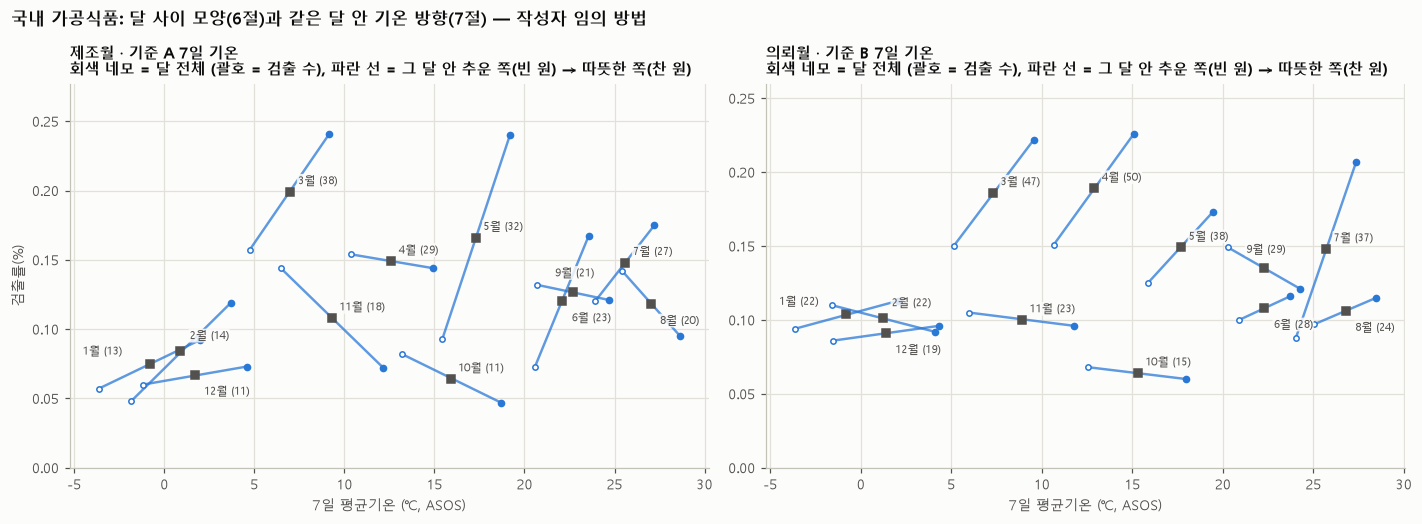

In [92]:
# [7-5-3] 달 사이 vs 달 안 — 작성자 임의 방법
# (1) 달별 평균 7일 기온 순위와 달별 검출률 순위 (순위상관 = 두 순위의 피어슨 상관, 같은 값은 평균 순위)
#     제조월: 7-5-1 기준 A 대상 행 / 의뢰월: 국내 가공식품 중 기준 B 7일 ASOS 기온 있는 행 (6절 의뢰월 표에 가까운 행 집합)
# (2) 달마다 그 달 기온 중앙값으로 두 쪽(중앙값 이하 = 추운 쪽, 초과 = 따뜻한 쪽)을 나눠 검출률 비교
#     달을 층으로 한 맨텔-헨젤 오즈비: OR_MH = Σ(a_m·d_m/n_m) / Σ(b_m·c_m/n_m),  a=따뜻한 쪽 검출, b=따뜻한 쪽 비검출, c=추운 쪽 검출, d=추운 쪽 비검출
def w7b_month(frame, mcol, tcol):
    rows = []
    for m, g in frame.groupby(mcol):
        med = g[tcol].median()
        cold, warm = g[g[tcol] <= med], g[g[tcol] > med]
        rows.append({'월': int(m), '행': len(g), '검출': int(g['pos'].sum()), '검출률(%)': round(g['pos'].mean() * 100, 3),
                     '평균 7일 기온(℃)': round(g[tcol].mean(), 1),
                     '추운 쪽 검출/행': f"{int(cold['pos'].sum())}/{len(cold):,}", '추운 쪽(%)': round(cold['pos'].mean() * 100, 3),
                     '따뜻한 쪽 검출/행': f"{int(warm['pos'].sum())}/{len(warm):,}", '따뜻한 쪽(%)': round(warm['pos'].mean() * 100, 3),
                     '_a': warm['pos'].sum(), '_b': len(warm) - warm['pos'].sum(), '_c': cold['pos'].sum(), '_d': len(cold) - cold['pos'].sum(),
                     '_tc': cold[tcol].mean(), '_tw': warm[tcol].mean()})
    t = pd.DataFrame(rows).set_index('월')
    t.insert(3, '검출률 순위', t['검출률(%)'].rank(ascending=False, method='average'))
    t.insert(5, '기온 순위', t['평균 7일 기온(℃)'].rank(ascending=False, method='average'))
    rs = float(np.corrcoef(t['검출률 순위'], t['기온 순위'])[0, 1])
    n = t['_a'] + t['_b'] + t['_c'] + t['_d']
    mh = float((t['_a'] * t['_d'] / n).sum() / (t['_b'] * t['_c'] / n).sum())
    return t, rs, mh


_A = W7B_BASE.loc[W7B_BASE['A7'].notna(), ['pos', '월A', 'A7']]
_gB = w7.loc[(w7['그룹'] == '국내 가공식품') & w7['avg_ta_B7'].notna(), ['pos', 'reqest_de', 'avg_ta_B7']]
_Bm = pd.DataFrame({'pos': _gB['pos'].to_numpy(), '월B': _gB['reqest_de'].dt.month.to_numpy(), 'B7': _gB['avg_ta_B7'].to_numpy()})
print(f"의뢰월 표 행: 국내 가공식품 {int((w7['그룹'] == '국내 가공식품').sum()):,}행 중 기준 B 7일 기온 없는 {int((w7['그룹'] == '국내 가공식품').sum()) - len(_Bm):,}행 뺌 → {len(_Bm):,}행 / 검출 {int(_Bm['pos'].sum())}")
W7B_MONTH_A, _rsA, _mhA = w7b_month(_A, '월A', 'A7')
W7B_MONTH_B, _rsB, _mhB = w7b_month(_Bm, '월B', 'B7')
_hide = ['_a', '_b', '_c', '_d', '_tc', '_tw']
for _lab, _t, _rs, _mh in [('제조월 (기준 A 7일, 7-5-1 대상 행)', W7B_MONTH_A, _rsA, _mhA), ('의뢰월 (기준 B 7일 기온 있는 행)', W7B_MONTH_B, _rsB, _mhB)]:
    _wk = int((_t['따뜻한 쪽(%)'] > _t['추운 쪽(%)']).sum())
    _kk = pd.concat([_t['_a'], _t['_c']])
    print(f"\n[{_lab}] 달 사이: 달별 기온 순위와 검출률 순위의 상관 {_rs:.2f} (12개 달) / 가장 따뜻한 달 {int(_t['평균 7일 기온(℃)'].idxmax())}월, 검출률 가장 높은 달 {int(_t['검출률(%)'].idxmax())}월"
          f"\n  달 안: 따뜻한 쪽 검출률이 더 높은 달 {_wk}/12, 따뜻한 쪽 검출 합 {int(_t['_a'].sum())} vs 추운 쪽 {int(_t['_c'].sum())}, 달을 층으로 한 맨텔-헨젤 오즈비 {_mh:.2f}"
          f" / 두 쪽 칸(12개 달 × 2) 검출 {int(_kk.min())}~{int(_kk.max())}건")
    display(_t.drop(columns=_hide))

# 그림: 점 = 달 전체 검출률(회색, 숫자 = 월), 선 = 그 달 안 추운 쪽 → 따뜻한 쪽
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for _ax, (_lab, _t) in zip(axes, [('제조월 · 기준 A 7일 기온', W7B_MONTH_A), ('의뢰월 · 기준 B 7일 기온', W7B_MONTH_B)]):
    for _mo, _r in _t.iterrows():
        _ax.plot([_r['_tc'], _r['_tw']], [_r['추운 쪽(%)'], _r['따뜻한 쪽(%)']], '-', color=C1, lw=1.6, alpha=0.75)
        _ax.plot([_r['_tc']], [_r['추운 쪽(%)']], 'o', color=C1, ms=3.5, mfc='white')
        _ax.plot([_r['_tw']], [_r['따뜻한 쪽(%)']], 'o', color=C1, ms=4)
        _ax.plot([_r['평균 7일 기온(℃)']], [_r['검출률(%)']], 's', color=INK2, ms=5)
        _off = {1: (-44, 6), 2: (6, 8), 12: (6, -13), 6: (6, -13), 9: (-12, 10), 8: (6, -13)}.get(_mo, (5, 5))   # 글자 겹침 피하기용 위치
        _ax.annotate(f"{_mo}월 ({_r['검출']})", (_r['평균 7일 기온(℃)'], _r['검출률(%)']), textcoords='offset points', xytext=_off, fontsize=7.5, color=INK2,
                     bbox=dict(boxstyle='round,pad=0.1', fc='#fcfcfb', ec='none', alpha=0.85))
    _ax.set_xlabel('7일 평균기온 (℃, ASOS)')
    _ax.set_title(f'{_lab}\n회색 네모 = 달 전체 (괄호 = 검출 수), 파란 선 = 그 달 안 추운 쪽(빈 원) → 따뜻한 쪽(찬 원)', fontsize=9.5)
    _ax.set_ylim(0, max(_t['따뜻한 쪽(%)'].max(), _t['추운 쪽(%)'].max()) * 1.15)
axes[0].set_ylabel('검출률(%)')
fig.suptitle('국내 가공식품: 달 사이 모양(6절)과 같은 달 안 기온 방향(7절) — 작성자 임의 방법', x=0.01, ha='left', fontsize=11, fontweight='bold')
fig.tight_layout()
plt.show()

# 메모리 정리: 행 단위 중간 표는 지움 (뒤 파트용으로 W7B_RULE_VALS·결과표·함수만 남김)
del W7B_BASE, _A, _gB, _Bm, _fr, _ff

📊 **결과**
- **제조월** (기준 A 7일, 213,220행·검출 257)
  - 달 사이: 달별 기온 순위와 검출률 순위의 상관 0.36. 가장 따뜻한 달은 8월(27.0℃)인데 검출률은 0.118% 로 12개 달 중 7위입니다. 검출률 1위는 3월 0.199%(7.0℃), 2위 5월 0.166%(17.3℃), 가장 낮은 달은 10월 0.064%(15.9℃)입니다.
  - 달 안: 따뜻한 쪽 검출률이 더 높은 달 7/12, 따뜻한 쪽 검출 합 144 vs 추운 쪽 113, 달을 층으로 한 맨텔-헨젤 오즈비 1.28.
- **의뢰월** (기준 B 7일 기온 있는 282,685행·검출 354, 기온 없는 11,736행 뺌 — 6절 의뢰월 표 294,421행과 조금 다름)
  - 달 사이: 순위 상관 0.30. 가장 따뜻한 8월(26.8℃)은 0.106% 로 7위, 1위 4월 0.189%(12.9℃), 2위 3월 0.186%, 가장 낮은 달 10월 0.064%.
  - 달 안: 따뜻한 쪽이 더 높은 달 8/12, 따뜻한 쪽 검출 197 vs 추운 쪽 157, 맨텔-헨젤 오즈비 1.26.
- 달 안 두 쪽의 검출은 칸마다 제조월 4\~23건, 의뢰월 7\~30건입니다. 예: 제조월 8월은 추운 쪽 0.142%(12건) > 따뜻한 쪽 0.095%(8건), 6월은 추운 쪽 0.073%(7건) < 따뜻한 쪽 0.167%(16건).
- 용어: **맨텔-헨젤 오즈비** = 달마다 따뜻한 쪽과 추운 쪽을 따로 비교한 뒤 하나로 합친 오즈비입니다. 달 사이 차이는 빼고 같은 달 안 차이만 보며, 1 이면 차이 없음입니다.

💬 **첨언**
- 작성자가 임의로 나눠 본 결과, **달 사이 모양과 달 안 기온 방향은 서로 다른 정보를 담는 것으로 보입니다** (추정).
  - 달 사이: 기온 순위와 검출률 순위의 상관은 약한 양(0.36·0.30)이고, 가장 따뜻한 8월은 중간(7위)입니다. 검출률이 높은 3·4월의 달 평균기온은 제조월 기준 7.0℃·12.6℃ 로 중간 아래입니다.
  - 달 안: 따뜻한 쪽이 조금 높습니다(맨텔-헨젤 오즈비 1.28·1.26).
  - 그래서 "봄(3\~4월)이 가장 높음"(6절)과 "같은 달 안에서는 따뜻한 쪽이 조금 높음"(7절)은 숫자로는 함께 나타날 수 있어 보입니다. 둘이 서로 모순이라는 근거는 이 표에서 보이지 않습니다 (추정).
- 다만 달 안 기온 차이에는 **해·지역 차이가 섞여** 있습니다. 같은 달 안 따뜻한 쪽은 따뜻한 지역의 행일 가능성이 있고, 7-5-1 에서 시도를 넣으면 계수가 1.053 으로 줄었습니다. 그래서 달 안 방향을 기온 자체의 효과로 읽기는 어려워 보입니다 (추정).
- 봄 높음은 기온 순서로는 설명되지 않는 모양이라, 6절에서 본 검사 일정·행정 요인 가능성과 같은 쪽을 가리키는 것으로 보입니다 (추정).
- 맨텔-헨젤 오즈비의 신뢰구간은 계산하지 않았습니다 (업체 군집을 반영한 구간은 7-5-1 참고).

### 7-5 정리 (추정)

- **보정**: 국내 가공식품 기준 A 7일 기온의 같은 달 안 SD당 오즈비는 월(M0 1.184)·연도(M1 1.169)까지는 업체 군집 p 가 0.0321·0.0465 로 작습니다. 다만 검사기관으로 묶으면 M0·M1 에서도 p 0.218·0.245 로 커서, 월만 맞춘 단계부터 약한 신호로 볼 여지가 있습니다.
  - **시도를 더하면 1.053(업체 군집 p 0.509)으로 줄고**, 검사목적·품목(1.023)이나 관측소×달 편차(1.035)에서도 비슷합니다. 기준 B 도 같은 방향입니다.
  - 사전 목록 밖 참고: 시도를 하나씩 빼고 M1 을 다시 적합하면 제주(50)를 뺄 때 1.018 로 줄고, 나머지 16곳은 1.156\~1.216 입니다. 한 지역의 영향이 클 수 있어 보입니다 (추정).
- **관측소 규칙**: ASOS 에서 R2·R3 는 R1 값을 바꾸지 않고 빈 창 행(6,928·9,387행)만 더합니다. 그래서 세 규칙이 비슷한 것(M0 1.173\~1.187, M2 1.016\~1.053)은 독립된 확인이 아니고, "빈 창을 메우는 규칙을 바꿔도 계수가 거의 바뀌지 않아 보인다" 정도로만 읽을 수 있습니다 (추정). 값이 있던 행의 관측소 선택 자체(천안 좌표 이력 등)는 시험하지 않았습니다. 대구(기) 176 을 빼면 6,928행(검출 26)이 더 붙습니다.
- **농업기상 극단값**: 7일 평균 -20℃ 미만 29행·35℃ 초과 4행은 ±50 경계값이 아니라, 일평균 -40℃ 가까운 날이나 40℃ 넘는 날이 창에 들어가 생긴 것으로 보입니다 (추정).
- **6절과 함께 읽기**: 달 사이(봄 최고, 가장 따뜻한 8월은 12개 달 중 7위)와 달 안(따뜻한 쪽 조금 높음)은 함께 나타날 수 있어 보이나, 달 안 방향은 지역 차이와 섞였을 가능성이 있습니다.
- 종합하면, 7-3 의 "같은 달 안 기온 계수 양수"는 작성자 임의 모형·규칙 안에서 **지역 보정에 약한 것**으로 보입니다 (추정). 검출 257건으로는 작은 기온 효과가 있는지 없는지 가리기 어렵고, 모형·규칙을 여러 개 본 결과이므로 결정은 아래 질문으로 넘깁니다.

❓ **도메인 전문가께**
- 같은 달 안에서 7일 평균기온이 높은 행의 국내 가공식품 검출이 조금 높게 보였습니다(같은 달 안 기온 SD 2.88℃당 오즈비 1.184). 나눠 보면 두 모양이 다릅니다.
  - (가) **같은 곳의 평소보다 더운 때**: 같은 관측소·같은 달 평균을 뺀 기온 편차 모형(M4)에서는 1.035 로 뚜렷하지 않았습니다.
  - (나) **따뜻한 지역**: 시도를 보정하면 1.053 으로 줄었습니다. 같은 달 평균보다 +3.46℃ 따뜻한 제주(50)는 검출률 0.543% 로 높고, 제주만 빼면 M1 이 1.169 → 1.018 로 줄었습니다 (사전 목록 밖 참고).
  - 가열·포장 가공식품에서 (가) 같은 공장의 더운 날에 검출이 오를 그럴듯한 경로(예: 공장 안 온도·결로, 냉장 유통 중 온도 이탈, 원료육 반입 온도)가 있다고 보시나요? 아니면 (나) 지역에 따른 제품·공장·검사 구성 차이로 보는 편이 자연스럽나요?
- 7-5-1 대상 행 중 제주(50) 가공식품(5,889행·검출 32)의 검출률 0.543% 는 17개 시도 중 대구(27) 1.173%(682행·검출 8, 한 업체 군집 최다 6건) 다음으로 높습니다. 제주 검출 32건은 업체 군집 20곳(한 군집 최다 7건)에 나뉘어 있습니다. 기온 말고 알려진 이유(제품 유형·원료·검사 사업 등)가 있나요?
- 이 결과를 볼 때 **국내 가공식품을 기상 피처를 붙일 대상 범위에 둘지**, 둔다면 시도·월 피처와 함께 둘 때만 의미가 있을지 의견을 부탁드립니다.
- 3\~4월 검출률이 가장 높고 가장 따뜻한 8월은 중간인 모양을 설명할, 기온 말고 알려진 요인(원료 수급·생산량·위생 점검 주기 등)이 있나요?
- 기상 연관을 본다면 어느 품목(식육가공품 및 포장육 등)에서, 제조일 전 며칠 창으로 보는 것이 맞나요?

🗄️ **데이터 담당자께**
- **관측소 이력·운영기간 공식 자료**가 있나요? ASOS 관측소 정보의 운영 시작·종료일에는 적재일이 섞여 있습니다(5절). 날짜별로 어느 관측소가 운영 중이었고 좌표가 어디였는지 알 수 있는 자료가 있는지 여쭙니다.
  - 대구(기)(176)는 언제까지 운영됐나요? 그 뒤 날짜에 대구(143) 값을 써도 되나요? (R2 에서 6,928행·검출 26 이 대구(143)로 바뀜)
  - 농업기상 561034A001 '동방로거테스트'는 시험 지점인가요? (R1 에서 1,010행이 이 지점에 연결)
- **관측소 연결 공식 규칙**이 있나요? (예: 시군구별 지정 관측소, 날짜별 운영 관측소 중 최근접, 거리 상한) R3(날짜별 운영 중 최근접)를 쓰면 같은 좌표라도 날짜마다 관측소가 바뀝니다 (농업기상 20,934행). 이 소절의 R2·R3 는 빈 창만 메웠고, 값이 있던 행의 관측소 선택은 바꾸지 않았습니다.
- 농업기상 일평균 temp 가 -40℃ 가까운 날(김해시 전하동 621100A001 2018-01·2019-12, 평택시 오성면 451873A001 2020-02)은 센서 하한이나 오류 표시인가요? 파일 전체에서 temp 가 정확히 -40.0℃ 인 날은 143일(무주군 무주읍 588802A001 140일), 최저기온이 정확히 -40.0℃ 인 날은 173일입니다.
  - 용인시 처인구(449872A001) 2023-08 의 일평균 40℃ 넘는 날(가장 높은 날 42.7℃, 최고기온 45.0)은 원천 값인가요?
  - 원천에서 이런 값을 결측으로 처리하는 규칙이 있나요? (이 값들이 들어간 창에서 7일 평균 -20℃ 미만 29행·35℃ 초과 4행이 나옴. 5절의 ±50 경계값 날은 이 창들에 0일)
- 검사기관 코드(`inspct_instt_code`)는 시료가 나온 지역과 이어지나요? 검사기관으로 묶으면 p값이 크게 달라져(M0 업체 군집 0.0321 vs 기관 군집 0.218) 기관과 지역의 관계를 알고 싶습니다.

---
## 8. 최소가공 경계 — 비가열 식육(포장육·양념육 등)과 가열 식육가공품, 제품명 기준 원물 (메모 도메인1)

🔎 메모 도메인1 은 기후 피처를 '원물/최소가공'에만 붙이자고 합니다. 그런데 품목코드로는 가공식품인 **포장육·양념육**이 국내 원물보다 검출이 훨씬 많습니다 (2.ipynb 3-6-1: 포장육 101/2,668, 양념육 87/21,956).
- 가열하지 않은 식육은 원재료 오염이 남을 수 있고, 가열한 식육가공품은 가열 뒤 공정 환경 오염이 주 경로라는 사용자 도메인 메모가 있습니다 (전문가 검증 전 의견).
- 그래서 **가열 여부로 보이는 경계**를 데이터로 나눠 규모·계절·기온 모양을 나란히 봅니다. 경계를 어디에 둘지는 전문가 질문으로 넘깁니다.
- 그룹끼리 검출률을 견줄 때는 **검사목적(검사 사업) 구성**이 서로 다를 수 있습니다 (3절: 주소 출처별 차이가 검사목적으로 나누면 뒤집힘). 그래서 검사목적 묶음으로 나눠 다시 봅니다.

**이 절에서 비교할 변형 목록 (결과보다 먼저 적음, 이 밖의 변형은 보지 않음)**
- **1차 목록**
  - 그룹 (8-1, 모두 작성자 임의): G0 국내 원물(통계용 분류) · G1 비가열·최소가공 식육 후보 · G2 가열 식육가공품 · 보류(어느 그룹에도 안 넣은 식육 품목명) · G3 그 외 국내 가공식품 · G4 제품명 기준 원물(기준규격외 코드 안)
  - 8-1 참고 (검정 없음): 품목제조대장이 식육 행에 붙는 비율과 제조조건·보존기준·원재료 필드가 채워진 비율 / G0 에 G4 와 같은 제외(팽이버섯·오송 주소)를 적용한 참고 줄 'G0−팽이·오송'
  - 8-2 규모: 위 그룹 전부 + G1 품목명 4개 + 'G0−팽이·오송' 참고 줄 (검정 없음)
  - 8-3 계절 검정 (카이제곱 동질성 = 달·계절마다 검출률이 모두 같다고 볼 수 있는지 보는 검정)
    - 기본: {G1, G2, G4} × {의뢰월 12칸, 의뢰 계절 4칸} = 6개 (행 단위, 전체 연도)
    - 민감도 ① 2017\~2025년만: 같은 6개 / ② 묶음 단위(식별된 업체는 업체-연-월, 식별 불가 행은 의뢰 단위, 6절과 같음): 같은 6개
    - 품목 나눠 보기: {포장육, 양념육} × 의뢰 계절 4칸 × {전체 연도, 2017\~2025년만} = 4개
    - 참고표(검정 없음): G1 품목명별 계절 검출률
  - 8-4 기상: {G1, G2, G4} × {기준 A 원본 제조일 7일, 기준 B 의뢰일 7일} ASOS `avg_ta` → 5분위 검출률 6개, 월 더미 + 기온 로지스틱 6개. G0 는 연결 행·검출 수만 (표본 작음)
    - 민감도 (각 기준 A·B): S1 G1 + 연도 더미 · S2 G1 + 시도 더미 · S3 대조군 '국내 가공식품 − G1' · S4a G1 과 G2 의 기온 기울기 차이(상호작용, 달 효과 두 그룹 공통) · S5 포장육만 · S6 양념육만 = 12개 (여기 S1\~S9 는 8-4 민감도 번호이고, 1절 범위 후보 S1\~S10 과 다릅니다)
- **1차 결과를 본 뒤 추가한 변형** (결과를 보고 고른 것이라 해석에 더 조심해야 함)
  - 8-4 S4b: S4a 결과를 본 뒤, 달 효과를 그룹마다 따로 둔 상호작용 설정을 추가 × 기준 A·B = 2개
  - 검사목적 구성 확인 (1차 결과를 검토하며 G1 검출이 검사목적 '기타'에 몰려 보여 추가). 검사목적 묶음(작성자 임의): 자가품질위탁 = '자가품질위탁검사' · 기타 = '기타' · 수거·HACCP = '수거검사' + '식품안전관리인증검사' · 그 외 = 나머지 검사목적
    - 8-2: 그룹 × 검사목적 묶음 행·검출·검출률 표 / 양념육 × 검사목적 묶음 × 제품명 가열·조리어 비율 표 / G1 검사목적 '기타'·'수거·HACCP' 검출 행의 검사기관·의뢰시스템·주소 출처 (모두 검정 없음)
    - 8-2: 오즈비 (층 무시 vs 검사목적 묶음 층 Mantel-Haenszel, 95% 구간만, p 없음): G1 vs G2 · G1 vs G0 · G1 vs 'G0−팽이·오송' = 3개
    - 8-3: {G1, G2} × {자가품질위탁, 기타, 수거·HACCP, 그 외} × 의뢰 계절 4칸 × {전체 연도, 2017\~2025년만} (검출 0 인 층은 검정 안 함 → 최대 16개) / 참고(검정 없음): G1 봄 검출의 검사목적 묶음별 연-월·검사기관 상위
    - 8-4: S7 G1 + 월 + 검사목적 묶음 더미 · S8 G1 검사목적 '기타'만 · S9 G1 검사목적 자가품질위탁만 × 기준 A·B = 6개
  - 품목명 표기 연도 확인 (1차 결과에서 G1 행이 2017→2018년에 크게 늘어 추가): 8-2 품목명(가열양념육·양념육·둘의 합·포장육) × 의뢰 연도 행·검출 표 / G1·G2 의뢰 연도 2018\~2025년만 검출률 (검정 없음)

### 8-1. 그룹 정의 — 국내 '식육가공품 및 포장육' 품목명을 가열 여부로 나누기 (작성자 임의 방법)

🔎 국내 `train_prdlst_nm` = '식육가공품 및 포장육' 행의 품목명(`품목명` = DB `prdlst_nm_self`)을 **이름만 보고** 나눕니다. 식품공전 식품유형 정의 원문과 대조하지 않았고, 전문가 검증 전입니다.

**G1 비가열·최소가공 식육 후보** (`MINPROC_NAMES`) — 품목마다 판단 근거 (작성자 추정)
- 포장육: 생고기를 자르거나 포장만 한 식품으로 보임 (2.ipynb 3-6-1 첨언: 한우 목심·육회·오리로스 같은 제품명)
- 양념육: 생고기에 양념을 더한 제품이 들어 있어 보임. 다만 '가열양념육'이 따로 있는데도 이름에 조리어가 붙은 제품이 섞였을 수 있음 (아래 표의 제품명 표기 비율 참고)
- 생햄: 이름으로 보아 가열하지 않고 염지·숙성·건조한 햄으로 보임
- 발효소시지: 이름으로 보아 가열 대신 발효·건조한 소시지로 보임

**G2 가열 식육가공품** (`HEATED_MEAT_NAMES`) — 품목마다 판단 근거 (작성자 추정)
- 햄·프레스햄·혼합프레스햄: 생햄이 따로 있어 가열 제품 위주로 보임
- 소시지·혼합소시지: 발효소시지가 따로 있어 가열 제품 위주로 보임
- 베이컨류: 훈연·가열 제품 위주로 보임
- 건조저장육류: 육포처럼 건조·열처리한 제품 위주로 보임
- 분쇄가공육제품: 패티·미트볼 같은 제품으로 보임. 굽지 않은 냉동 패티도 들 수 있어 **경계가 애매**함 (작성자가 G2 에 넣었지만 G1 쪽으로 볼 여지도 있음)
- 가열양념육: 이름에 '가열'이 있음. 다만 품목명 표기가 해마다 달라졌을 수 있음 (8-2 품목명 × 연도 표에서 확인)
- 갈비가공품: 양념만 한 갈비와 조리한 갈비가 섞일 수 있어 **경계가 애매**함 (작성자가 G2 에 넣었지만 G1 쪽으로 볼 여지도 있음)
- 식육추출가공품·식육추출가공육·혼합식육추출가공품·단순식육추출가공품·식육 추출가공품: 육수·곰탕처럼 끓여 추출한 제품으로 보임

**보류** (`MINPROC_HOLD_NAMES`, 어느 그룹에도 넣지 않고 행 수만 셈)
- 햄류·소시지류: 상위 유형 이름이라 생햄·발효소시지가 섞였을 수 있음
- 식육함유가공품: 이름만으로 가열 여부를 알 수 없음 / 알함유가공품: 식육이 아님

**나머지 그룹**
- G0 국내 원물(통계용 분류): 국내 × 대분류 농·축·수산물(원물)
- G3 그 외 국내 가공식품: 국내 × 대분류 가공식품 × `train_prdlst_nm` ≠ '식육가공품 및 포장육'
- G4 제품명 기준 원물: 국내 × 기준규격외(Z) × 2.ipynb 3-6-2 원물 이름 규칙(`RAW_TYPE` 에 걸리고, `NOT_RAW` 가공어·환경검체가 아님) 에서 **팽이버섯(`검체성격(임의)`)** 행과 **주소에 '오송생명2로 187' 이 들어간 행**을 뺀 것 (`raw_name_mask`)

In [93]:
# [8-1] 국내 '식육가공품 및 포장육' 품목명 목록과 그룹 배정 — 작성자 임의 방법 (이름만 보고 가열 여부 추정, 식품공전 원문 대조 전)
MINPROC_NAMES = ['포장육', '양념육', '생햄', '발효소시지']                                  # G1 비가열·최소가공 식육 후보
HEATED_MEAT_NAMES = ['햄', '프레스햄', '혼합프레스햄', '소시지', '혼합소시지', '베이컨류', '건조저장육류', '분쇄가공육제품',
                     '가열양념육', '갈비가공품', '식육추출가공품', '식육추출가공육', '혼합식육추출가공품', '단순식육추출가공품',
                     '식육 추출가공품']                                                     # G2 가열 식육가공품
MINPROC_HOLD_NAMES = ['햄류', '소시지류', '식육함유가공품', '알함유가공품']                 # 보류 (그룹에 안 넣음)

# 제품명 표기 단서 — 작성자 임의 정규식 (has_kw: 소문자·공백 제거 후 비교). 가열 여부를 정하는 데 쓰지 않고 비율만 봄
P09_KW_RAW = r'비가열|비살균'
P09_KW_HEAT = r'(?<!비)가열|(?<!비)살균|훈제|훈연|삶은|편육|족발|수육|볶음|튀김|치킨|구이|스팀|찜|조리|바베큐|수비드'

_p9_dom = dfx['국내해외'].eq('국내')
_p9_meat = _p9_dom & dfx['train_prdlst_nm'].astype(str).eq('식육가공품 및 포장육')
_p9_m = dfx.loc[_p9_meat, ['lims_data_key', 'pos', '품목명', 'prduct_nm', 'mnfctur_de_raw', 'prdlst_mnfctur_sttemnt_no']].copy()   # 필요한 열만
_p9_m['품목명'] = _p9_m['품목명'].astype(str)          # 결측이면 'nan' 글자 라벨로만 묶임
# DB 보조 컬럼 두 개만 더 읽어 붙임: 원 품목명(prdlst_nm_org), 통계용 4단계 분류(statistic_prdlst_nm_4) — dfx 에는 넣지 않음
_p9_x = pd.read_parquet(COL / 'nb2_db_attr.parquet', columns=['lims_data_key', 'prdlst_nm_org', 'statistic_prdlst_nm_4'])
_p9_x = _p9_x[_p9_x['lims_data_key'].isin(_p9_m['lims_data_key'])].set_index('lims_data_key')
_p9_m = _p9_m.join(_p9_x, on='lims_data_key')
del _p9_x
print(f"국내 '식육가공품 및 포장육' {len(_p9_m):,}행 / 검출 {int(_p9_m['pos'].sum())} / 품목명 {_p9_m['품목명'].nunique()}개")
_p9_listed = set(MINPROC_NAMES) | set(HEATED_MEAT_NAMES) | set(MINPROC_HOLD_NAMES)
_p9_unl = sorted(set(_p9_m['품목명']) - _p9_listed)
print('목록(G1·G2·보류)에 없는 품목명:', _p9_unl if _p9_unl else '없음')
_p9_m['그룹'] = np.select([_p9_m['품목명'].isin(MINPROC_NAMES), _p9_m['품목명'].isin(HEATED_MEAT_NAMES), _p9_m['품목명'].isin(MINPROC_HOLD_NAMES)],
                          ['G1 비가열·최소가공', 'G2 가열', '보류'], '(목록 밖)')
_p9_m['kw_raw'] = has_kw(_p9_m['prduct_nm'], P09_KW_RAW)
_p9_m['kw_heat'] = has_kw(_p9_m['prduct_nm'], P09_KW_HEAT) & ~_p9_m['kw_raw']
_p9_m['org_salgyun'] = _p9_m['prdlst_nm_org'].astype(str).str.contains('(살균)', regex=False)

_p9_g = _p9_m.groupby(['그룹', '품목명'])
P09_NAMES_TBL = _p9_g['pos'].agg(행='size', 검출='sum')
P09_NAMES_TBL['검출률(%)'] = (P09_NAMES_TBL['검출'] / P09_NAMES_TBL['행'] * 100).round(3)
_lo, _hi = wilson(P09_NAMES_TBL['검출'], P09_NAMES_TBL['행'])
P09_NAMES_TBL['95% CI(%)'] = [f'{a:.3f}~{b:.3f}' for a, b in zip(_lo, _hi)]
P09_NAMES_TBL['DB 4단계 분류(최다)'] = _p9_g['statistic_prdlst_nm_4'].agg(lambda s: s.astype(str).value_counts().index[0])
P09_NAMES_TBL["원 품목명 '(살균)' 행"] = _p9_g['org_salgyun'].sum().astype(int)
P09_NAMES_TBL["제품명 '비가열·비살균'(%)"] = (_p9_g['kw_raw'].mean() * 100).round(1)
P09_NAMES_TBL['제품명 가열·조리어(%)'] = (_p9_g['kw_heat'].mean() * 100).round(1)
P09_NAMES_TBL['검출 행 중 가열·조리어'] = _p9_m[_p9_m['pos'].eq(1)].groupby(['그룹', '품목명'])['kw_heat'].sum().reindex(P09_NAMES_TBL.index).astype('Int64')
P09_NAMES_TBL['원본 제조일 있음(%)'] = (_p9_g['mnfctur_de_raw'].apply(lambda s: s.notna().mean()) * 100).round(1)
P09_NAMES_TBL = P09_NAMES_TBL.reset_index().sort_values(['그룹', '행'], ascending=[True, False]).set_index(['그룹', '품목명'])
print(f"제품명 표기 단서(작성자 임의 정규식) — '비가열·비살균': {P09_KW_RAW} / 가열·조리어: {P09_KW_HEAT}")
print("'검출 행 중 가열·조리어' 는 검출 행 수 중 제품명에 가열·조리어가 있는 행 수 (검출 0 이면 빈 칸)")
display(P09_NAMES_TBL)

# 양념육 안 제품명 모습 (가열·비가열 섞임 확인용): 행 많은 제품명 상위 12 / 검출 행 제품명 상위 12
_p9_y = _p9_m[_p9_m['품목명'].eq('양념육')]
print('양념육 — 행 많은 제품명 상위 12:', ', '.join(f'{k}({v})' for k, v in _p9_y['prduct_nm'].value_counts().head(12).items()))
print('양념육 — 검출 행 제품명 상위 12:', ', '.join(f'{k}({v})' for k, v in _p9_y.loc[_p9_y['pos'].eq(1), 'prduct_nm'].value_counts().head(12).items()))
_p9_p = _p9_m[_p9_m['품목명'].eq('포장육')]
print('포장육 — 검출 행 제품명 상위 12:', ', '.join(f'{k}({v})' for k, v in _p9_p.loc[_p9_p['pos'].eq(1), 'prduct_nm'].value_counts().head(12).items()))
_p9_g1n = int(_p9_m['품목명'].isin(MINPROC_NAMES).sum())
_p9_yh = int((_p9_m['품목명'].eq('양념육') & _p9_m['kw_heat']).sum())
print(f'G1 {_p9_g1n:,}행 중 제품명에 가열·조리어가 있는 양념육 행 {_p9_yh:,}행 ({_p9_yh / _p9_g1n * 100:.1f}%) — G1 은 이름상 비가열 후보지만 약 이만큼은 조리 제품 이름')

국내 '식육가공품 및 포장육' 95,216행 / 검출 294 / 품목명 23개
목록(G1·G2·보류)에 없는 품목명: 없음
제품명 표기 단서(작성자 임의 정규식) — '비가열·비살균': 비가열|비살균 / 가열·조리어: (?<!비)가열|(?<!비)살균|훈제|훈연|삶은|편육|족발|수육|볶음|튀김|치킨|구이|스팀|찜|조리|바베큐|수비드
'검출 행 중 가열·조리어' 는 검출 행 수 중 제품명에 가열·조리어가 있는 행 수 (검출 0 이면 빈 칸)


행   검출  검출률(%)     95% CI(%) DB 4단계 분류(최다)  원 품목명 '(살균)' 행  제품명 '비가열·비살균'(%)  제품명 가열·조리어(%)  검출 행 중 가열·조리어  원본 제조일 있음(%)
그룹          품목명                                                                                                                                    
G1 비가열·최소가공 양념육        21956   87   0.396   0.321~0.488          양념육류              35               0.8           63.6             27          81.6
            포장육         2668  101   3.786   3.125~4.579           포장육               0               0.0            2.4              2          83.2
            생햄          1431    4   0.280   0.109~0.717            햄류               0               0.0            0.0              0          41.6
            발효소시지        842    2   0.238   0.065~0.862          소시지류               0               0.0            0.1              0          68.9
G2 가열       햄          15631   27   0.173   0.119~0.251            햄류              69               0.0           58.1             13          76.3
            소시지        15275   19   0.124   0.080~0.194          소시지류              23               0.0            5.2              1          73.7
            프레스햄        8384   10   0.119   0.065~0.219            햄류               0               0.0           17.6              3          74.9
            분쇄가공육제품     7853   19   0.242   0.155~0.378          양념육류              18               0.0           16.0              8          81.7
            건조저장육류      6702    6   0.090   0.041~0.195        건조저장육류               1               0.0            8.9              0          65.6
            식육추출가공품     6346    1   0.016   0.003~0.089       식육추출가공품               0               0.0            4.9              0          74.2
            가열양념육       2930    5   0.171   0.073~0.399          양념육류               7               0.3           57.1              3          72.6
            갈비가공품       2106    3   0.142   0.048~0.418          양념육류              36               0.0           68.3              2          84.1
            베이컨류        1453    5   0.344   0.147~0.803          베이컨류               0               0.0           26.2              0          84.2
            혼합프레스햄       618    0   0.000   0.000~0.618            햄류               0               0.0           12.3           <NA>          67.8
            혼합소시지        309    1   0.324   0.057~1.810          소시지류               0               0.0            2.6              0          84.1
            식육추출가공육      258    0   0.000   0.000~1.467      식육 추출가공품               0               0.0           78.3           <NA>          55.0
            혼합식육추출가공품    193    0   0.000   0.000~1.952      식육 추출가공품               0               0.0           11.9           <NA>          65.8
            단순식육추출가공품     49    0   0.000   0.000~7.270      식육 추출가공품               0               0.0            2.0           <NA>          75.5
            식육 추출가공품      21    0   0.000  0.000~15.464      식육 추출가공품               0               0.0            4.8           <NA>          71.4
보류          식육함유가공품      105    1   0.952   0.168~5.199       식육함유가공품               2               0.0           27.6              1          70.5
            소시지류          56    1   1.786   0.316~9.446          소시지류               0               0.0            5.4              0          37.5
            햄류            29    2   6.897  1.912~21.965            햄류               0               0.0           51.7              2          27.6
            알함유가공품         1    0   0.000  0.000~79.346        알함유가공품               0               0.0            0.0           <NA>           0.0

양념육 — 행 많은 제품명 상위 12: 편육(412), 치킨(안심살)텐더스틱(381), 족발(301), 제육볶음(252), 왕족발(180), 후라이드치킨(158), 삶은족발(156), 미니족발(152), 닭발편육(148), 무뼈족발(145), 조리소고기(141), 전통편육(134)
양념육 — 검출 행 제품명 상위 12: 닭고기염지육(7), 춘천닭갈비(4), 요니네 한우 한판(4), 황리단길쉐프초이스칼집갈비맛구이(3), 춘천식닭갈비(2), 절단정육(2), 달콤갈비살(2), 듀록흑돼지양념목살(냉장 전1차)(2), 소불고기(2), 양념닭발편육(2), C4(1), C2(1)
포장육 — 검출 행 제품명 상위 12: 한우목심(냉장)(5), 한우 목심(냉장)(4), 셀덕 오리로스(3), 한우설깃(2), 육회(2), 담꾹 한돈 뒷다리 (찌개용)(2), 끼니한우 설도(냉장)(2), 완제품 한우(우둔)(2), 돌돌말이 대패 목심(2), 앞다리박피(냉장)(2), 닭정육(2), 한우 육회(2)
G1 26,897행 중 제품명에 가열·조리어가 있는 양념육 행 13,962행 (51.9%) — G1 은 이름상 비가열 후보지만 약 이만큼은 조리 제품 이름


In [94]:
# [8-1 참고] 품목제조대장(0절 준비에서 읽은 ledg)을 국내 식육 행에 이어 보기 — dfx 에 열을 넣지 않음
# 연결 규칙은 2.ipynb 4-4 와 같음 (작성자 임의): 대장은 보고번호당 1행(삭제 표시 없는 행 → 최근 수정 행 우선),
#   리스테리아 행의 품목제조번호(prdlst_mnfctur_sttemnt_no)를 그대로 찾고, 없으면 숫자만 남긴 번호로 찾음
_p9_L = ledg[['prdlst_report_no', 'del_yn', 'last_updt_dtm', 'mnf_cnd_cn', 'prsrv_distb_stdr_cn', 'frmlc_mtrqlt', 'pog_daycnt', 'pog_cn']].copy()
_p9_L['_ok'] = (_p9_L['del_yn'].isna() | _p9_L['del_yn'].eq('N')).astype(int)            # 정렬용 표시 (값 채움 아님)
_p9_L = (_p9_L.sort_values(['prdlst_report_no', '_ok', 'last_updt_dtm'], ascending=[True, False, False])
         .drop_duplicates('prdlst_report_no').set_index('prdlst_report_no'))
P09_LEDG_FIELDS = {'mnf_cnd_cn': '제조조건', 'prsrv_distb_stdr_cn': '보존·유통기준', 'frmlc_mtrqlt': '원재료', 'pog_daycnt': '유통기한 문구', 'pog_cn': '유통기한 내용'}
_p9_filled = lambda s: s.astype('string').str.strip().ne('').to_numpy(dtype=bool, na_value=False)   # 빈 글자·결측 = 안 채워짐
print(f"품목제조대장 추출본 {len(ledg):,}행 → 보고번호당 1행 {len(_p9_L):,}행. 대장 전체에서 필드가 채워진 비율: "
      + ', '.join(f'{v} {_p9_filled(_p9_L[k]).mean() * 100:.1f}%' for k, v in P09_LEDG_FIELDS.items()))
_k_raw = _p9_m['prdlst_mnfctur_sttemnt_no'].astype('string')
_k_dig = _k_raw.str.replace(r'\D', '', regex=True)
_m_raw = _k_raw.isin(_p9_L.index).to_numpy(dtype=bool, na_value=False)
_m_dig = _k_dig.isin(_p9_L.index).to_numpy(dtype=bool, na_value=False)
_p9_lk = pd.Series(np.where(_m_raw, _k_raw.astype(object), np.where(_m_dig, _k_dig.astype(object), None)), index=_p9_m.index)
_p9_lj = _p9_L.reindex(_p9_lk.dropna().to_numpy())
_p9_lj.index = _p9_lk.dropna().index
_rows = []
for _lab, _mm in [(f'G1 └ {n}', _p9_m['품목명'].eq(n)) for n in MINPROC_NAMES] + [('G2 가열 식육가공품', _p9_m['품목명'].isin(HEATED_MEAT_NAMES)),
                                                                                 ('보류 식육 품목명', _p9_m['품목명'].isin(MINPROC_HOLD_NAMES))]:
    _s = _p9_m[_mm]
    _li = _s.index[_p9_lk.loc[_s.index].notna().to_numpy()]
    _r = {'구분': _lab, '행': len(_s), '대장 연결 행(%)': round(len(_li) / len(_s) * 100, 1), '검출': int(_s['pos'].sum()),
          '검출 중 연결': int(_s.loc[_li, 'pos'].sum())}
    for _k, _v in P09_LEDG_FIELDS.items():
        _r[f'{_v} 채움(연결 행 %)'] = round(_p9_filled(_p9_lj.loc[_li, _k]).mean() * 100, 1) if len(_li) else np.nan
    _rows.append(_r)
P09_LEDG = pd.DataFrame(_rows).set_index('구분')
print('국내 식육 행 — 품목제조대장 연결 비율과 연결된 행에서 필드가 채워진 비율')
display(P09_LEDG)
del _p9_L, _p9_lj, _k_raw, _k_dig, _m_raw, _m_dig

품목제조대장 추출본 36,082행 → 보고번호당 1행 35,360행. 대장 전체에서 필드가 채워진 비율: 제조조건 1.0%, 보존·유통기준 0.1%, 원재료 92.6%, 유통기한 문구 95.3%, 유통기한 내용 95.2%
국내 식육 행 — 품목제조대장 연결 비율과 연결된 행에서 필드가 채워진 비율


,행,대장 연결 행(%),검출,검출 중 연결,제조조건 채움(연결 행 %),보존·유통기준 채움(연결 행 %),원재료 채움(연결 행 %),유통기한 문구 채움(연결 행 %),유통기한 내용 채움(연결 행 %)
구분,,,,,,,,,
G1 └ 포장육,2668,61.5,101,73,0.0,0.0,68.4,98.6,98.6
G1 └ 양념육,21956,73.8,87,59,0.0,0.0,86.7,99.7,99.7
G1 └ 생햄,1431,55.8,4,1,0.0,0.0,98.7,99.5,99.5
G1 └ 발효소시지,842,67.9,2,1,0.0,0.0,99.8,99.3,99.3
G2 가열 식육가공품,68128,77.2,96,61,0.0,0.0,90.5,99.6,99.6
보류 식육 품목명,191,27.7,4,1,11.3,0.0,60.4,100.0,100.0


In [95]:
# [8-1] G0~G4 그룹 만들기 — G4 는 2.ipynb 3-6-2 규칙(RAW_TYPE·NOT_RAW)을 그대로 옮김 (작성자 임의 정규식, 오탐·누락 있음)
RAW_TYPE = {
    '버섯': r'팽이|enoki|flammulina|버섯|mushroom',
    '생선·해산물(회·횟감)': r'(?:광어|우럭|도미|방어|참치|다랑어|연어|홍새우|새우|오징어|문어|낙지|전복|숭어|농어)(?:회|사시미)|횟감|사시미',
    '생선·해산물': r'고등어|삼치|오징어|광어|연어|참치|다랑어|갈치|명태|새우|굴$|굴\(|생굴|조개|전복|문어|낙지|꽃게|홍합|바지락|숭어|농어|우럭|도미|방어',
    '생육·원료육': r'원료육|돈육|우육|한우|돼지고기|소고기|쇠고기|닭고기|계육|정육|생고기|오리고기|다짐육|목심|삼겹|앞다리|뒷다리|등심|안심|갈비살',
    '채소': r'배추|양파|대파|쪽파|마늘|당근|오이|생강|고추|부추|양배추|상추|깻잎|시금치|콩나물|숙주|파프리카|브로콜리|^무$|^무[\(\-]|^무세척',
    '과일': r'사과|딸기|포도|토마토|키위|바나나|멜론|수박|블루베리',
    '알': r'계란|달걀|유정란|원란|난황|난백',
    '원유': r'^원유|집유',
}
NOT_RAW = (
    r'김치|장아찌|피클|볶음|무침|조림|즙|분말|가루|소스|케첩|케찹|페이스트|살사|가열|완제품|살균후|살균\(후|살균제품|멸균'
    r'|양념|튀김|찌개|탕|죽$|국밥|초밥|김밥|도시락|샐러드|샌드위치|햄|소시지|소세지|훈제|건조|^건|말랭이|잼|주스|음료'
    r'|떡|빵|과자|아이스|샤벳|샤베트|우유|요거트|요구르트|시럽|청$|퓨레|농축|통조림|캔$|맛$|맛\)|향$|식초|포도당|씨유'
    r'|고추장|된장|간장|흑마늘|소박이|불고기|떡갈비|패티|너겟|까스|커틀릿|염지|굴비|젓|깡$|육포|오징어채|포$|마요'
    r'|액$|액\(|지단|후레이크|구운|군계란|토스트|말이|진밥|분쇄|가공육|꼬치|반제품|용수|배지|종균|톱밥'
    r'|동태전|파전|부추전|호박전|깻잎전|해물전|녹두전|생강차|녹차|유자차|대추차|편육|수육|자숙|조리|삶은'
    r'|액상|분$|치킨|텐더|스틱|바베큐|덮밥|강정|칩|사과산'
)
# 환경검체 플래그: 2.ipynb 는 flags['환경검체'] 를 씀. 0절 준비의 검체성격(임의)는 환경검체가 첫 조건인 np.select 라 '환경검체' 값 = 그 플래그와 같음
_p9_z = _p9_dom & dfx['대분류'].eq('기준규격외(검체)')
_p9_pn = dfx.loc[_p9_z, 'prduct_nm']
_p9_kind = dfx.loc[_p9_z, '검체성격(임의)']
_p9_not_raw = has_kw(_p9_pn, NOT_RAW)
_p9_type = pd.Series(np.select([has_kw(_p9_pn, p) for p in RAW_TYPE.values()], list(RAW_TYPE.keys()), ''), index=_p9_pn.index)
_p9_name_raw = _p9_type.ne('') & ~_p9_not_raw & ~_p9_kind.eq('환경검체')
_p9_enoki = _p9_kind.eq('팽이버섯')
_p9_addr = dfx.loc[_p9_z, 'addr'].astype(str)
_p9_osong = _p9_addr.str.contains('오송생명2로 187', regex=False)
_p9_osong_nosp = _p9_addr.str.replace(r'\s+', '', regex=True).str.contains('오송생명2로187', regex=False)
_p9_zp = dfx.loc[_p9_z, 'pos']
_kz = lambda mm: f'{int(mm.sum()):,}행 / 검출 {int(_p9_zp[mm].sum()):,}'
print(f'국내 기준규격외(Z): {_kz(pd.Series(True, index=_p9_zp.index))}')
print(f'  ① 원물 이름 행 (2.ipynb 3-6-2 규칙; 2.ipynb 기록 50,251행·검출 661): {_kz(_p9_name_raw)}')
print(f"  ② ①에서 검체성격(임의) '팽이버섯' 뺌: {_kz(_p9_name_raw & _p9_enoki)} 뺌")
print(f"  ③ ②에서 주소에 '오송생명2로 187' 이 들어간 행 뺌: {_kz(_p9_name_raw & ~_p9_enoki & _p9_osong)} 뺌 "
      f"(①에서 팽이버섯과 겹치는 오송 행 {_kz(_p9_name_raw & _p9_enoki & _p9_osong)}; 공백을 모두 지우고 찾으면 ① 안 오송 행 {int((_p9_name_raw & _p9_osong_nosp).sum()):,} vs 그대로 찾기 {int((_p9_name_raw & _p9_osong).sum()):,})")
_p9_g4 = _p9_name_raw & ~_p9_enoki & ~_p9_osong
raw_name_mask = pd.Series(False, index=dfx.index)
raw_name_mask.loc[_p9_g4[_p9_g4].index] = True
print(f'  → G4 제품명 기준 원물 (raw_name_mask): {int(raw_name_mask.sum()):,}행 / 검출 {int(dfx.loc[raw_name_mask, "pos"].sum()):,}')

# G4 원물 유형별 (팽이버섯을 뺀 뒤 남은 버섯 = 다른 버섯 이름), 검체성격(임의) 공정시료 비율
_p9_t4 = pd.DataFrame({'유형': _p9_type[_p9_g4], 'pos': _p9_zp[_p9_g4], '공정시료': _p9_kind[_p9_g4].eq('공정시료')})
P09_G4_TYPE = _p9_t4.groupby('유형').agg(행=('pos', 'size'), 검출=('pos', 'sum'), **{'검체성격 공정시료(%)': ('공정시료', 'mean')})
P09_G4_TYPE['검출률(%)'] = (P09_G4_TYPE['검출'] / P09_G4_TYPE['행'] * 100).round(3)
P09_G4_TYPE['검체성격 공정시료(%)'] = (P09_G4_TYPE['검체성격 공정시료(%)'] * 100).round(1)
P09_G4_TYPE = P09_G4_TYPE.sort_values('행', ascending=False)[['행', '검출', '검출률(%)', '검체성격 공정시료(%)']]
print('G4 원물 유형별 (RAW_TYPE 에서 먼저 걸린 유형)')
display(P09_G4_TYPE)

# 전체 그룹 라벨 (dfx 에 넣지 않고 Series 로 남김). 겹침이 없어야 함
P09_GROUPS = ['G0 국내 원물(통계용 분류)', 'G1 비가열·최소가공 식육', 'G2 가열 식육가공품', '보류 식육 품목명', 'G3 그 외 국내 가공식품', 'G4 제품명 기준 원물(Z)']
_p9_nm_all = dfx['품목명'].astype(str)
_p9_conds = [_p9_dom & dfx['대분류'].isin(['농산물(원물)', '축산물(원물)', '수산물(원물)']),
             _p9_meat & _p9_nm_all.isin(MINPROC_NAMES), _p9_meat & _p9_nm_all.isin(HEATED_MEAT_NAMES), _p9_meat & _p9_nm_all.isin(MINPROC_HOLD_NAMES),
             _p9_dom & dfx['대분류'].eq('가공식품') & ~_p9_meat, raw_name_mask]
assert int(np.sum([c.to_numpy() for c in _p9_conds], axis=0).max()) <= 1, '그룹이 겹침'
MINPROC_GROUP = pd.Series(np.select(_p9_conds, P09_GROUPS, ''), index=dfx.index)
print(f"그룹에 안 든 국내 식육가공품 행(목록 밖 품목명): {int((_p9_meat & MINPROC_GROUP.eq('')).sum())}")
_p9_cnt = dfx.groupby(MINPROC_GROUP)['pos'].agg(행='size', 검출='sum').reindex(P09_GROUPS)
print('그룹별 행·검출 (그룹 밖: 해외 전체, 국내 기타 대분류, 국내 Z 중 G4 아닌 행 — 이 절 계산에서 뺌)')
print(f"그룹 밖으로 뺀 행 {int(MINPROC_GROUP.eq('').sum()):,} / 검출 {int(dfx.loc[MINPROC_GROUP.eq(''), 'pos'].sum()):,}")
display(_p9_cnt)

# 참고 줄: G0 에도 G4 와 같은 제외(검체성격(임의) '팽이버섯', 주소에 '오송생명2로 187')를 적용하면 (그룹은 바꾸지 않고 비교용으로만 씀)
_p9_g0 = _p9_conds[0]
_g0_eno = _p9_g0 & dfx['검체성격(임의)'].eq('팽이버섯')
_g0_addr = dfx['addr'].astype(str)
_g0_os = _p9_g0 & _g0_addr.str.contains('오송생명2로 187', regex=False)
_g0_os_nosp = _p9_g0 & _g0_addr.str.replace(r'\s+', '', regex=True).str.contains('오송생명2로187', regex=False)
_k0 = lambda mm: f"{int(mm.sum()):,}행 / 검출 {int(dfx.loc[mm, 'pos'].sum())}"
P09_G0X_MASK = _p9_g0 & ~_g0_eno & ~_g0_os
print(f"G0 {_k0(_p9_g0)} 중 팽이버섯 {_k0(_g0_eno)}, 오송 주소 {_k0(_g0_os)} (공백을 지우고 찾으면 {int(_g0_os_nosp.sum()):,}행), 둘 중 하나 {_k0(_g0_eno | _g0_os)}")
print(f"→ 참고 줄 'G0−팽이·오송': {_k0(P09_G0X_MASK)} ({dfx.loc[P09_G0X_MASK, 'pos'].mean() * 100:.3f}%)")
del _g0_addr, _g0_eno, _g0_os, _g0_os_nosp

국내 기준규격외(Z): 320,536행 / 검출 1,431
  ① 원물 이름 행 (2.ipynb 3-6-2 규칙; 2.ipynb 기록 50,251행·검출 661): 50,251행 / 검출 661
  ② ①에서 검체성격(임의) '팽이버섯' 뺌: 6,139행 / 검출 418 뺌
  ③ ②에서 주소에 '오송생명2로 187' 이 들어간 행 뺌: 319행 / 검출 0 뺌 (①에서 팽이버섯과 겹치는 오송 행 0행 / 검출 0; 공백을 모두 지우고 찾으면 ① 안 오송 행 319 vs 그대로 찾기 319)
  → G4 제품명 기준 원물 (raw_name_mask): 43,793행 / 검출 243
G4 원물 유형별 (RAW_TYPE 에서 먼저 걸린 유형)


,행,검출,검출률(%),검체성격 공정시료(%)
유형,,,,
채소,17120,5,0.029,55.7
생육·원료육,12808,112,0.874,73.7
생선·해산물,8770,83,0.946,34.0
과일,2677,0,0.000,23.0
버섯,1330,10,0.752,7.3
알,472,0,0.000,27.5
생선·해산물(회·횟감),464,32,6.897,2.6
원유,152,1,0.658,37.5


그룹에 안 든 국내 식육가공품 행(목록 밖 품목명): 0
그룹별 행·검출 (그룹 밖: 해외 전체, 국내 기타 대분류, 국내 Z 중 G4 아닌 행 — 이 절 계산에서 뺌)
그룹 밖으로 뺀 행 334,790 / 검출 1,313


,행,검출
G0 국내 원물(통계용 분류),3533,27
G1 비가열·최소가공 식육,26897,194
G2 가열 식육가공품,68128,96
보류 식육 품목명,191,4
G3 그 외 국내 가공식품,199205,92
G4 제품명 기준 원물(Z),43793,243


G0 3,533행 / 검출 27 중 팽이버섯 48행 / 검출 12, 오송 주소 762행 / 검출 10 (공백을 지우고 찾으면 762행), 둘 중 하나 771행 / 검출 13
→ 참고 줄 'G0−팽이·오송': 2,762행 / 검출 14 (0.507%)


📊 **결과**
- 국내 '식육가공품 및 포장육'은 95,216행 / 검출 294, 품목명 23개입니다. 세 목록(G1·G2·보류)에 없는 품목명은 없습니다.
- G1 비가열·최소가공 식육 후보: 26897행 / 검출 194
  - 포장육 2668행·101 (3.786%, 95% CI 3.125\~4.579) / 양념육 21956행·87 (0.396%) / 생햄 1431행·4 (0.280%) / 발효소시지 842행·2 (0.238%)
- G2 가열 식육가공품: 68128행 / 검출 96 (햄 15631행·27, 소시지 15275행·19, 분쇄가공육제품 7853행·19, 프레스햄 8384행·10 등)
- 보류: 191행 / 검출 4 (햄류 29행·2, 소시지류 56행·1, 식육함유가공품 105행·1, 알함유가공품 1행·0)
- 제품명 표기 단서 (작성자 임의 정규식)
  - 양념육: 제품명에 가열·조리어가 있는 행 63.6%, 검출 87행 중 가열·조리어가 있는 행은 27행입니다. 행 많은 제품명은 편육(412)·치킨(안심살)텐더스틱(381)·족발(301)·제육볶음(252), 검출 행 제품명은 닭고기염지육(7)·춘천닭갈비(4)·요니네 한우 한판(4)·소불고기(2) 등입니다.
  - 제품명 가열·조리어 비율 (G2): 햄 58.1%·가열양념육 57.1%·갈비가공품 68.3% 는 높고, 소시지 5.2%·건조저장육류 8.9%·분쇄가공육제품 16.0% 는 낮습니다. 분쇄가공육제품 검출 19 중 가열·조리어가 있는 행은 8 입니다.
  - 원 품목명(`prdlst_nm_org`)에 '(살균)'이 붙은 행: 햄 69, 갈비가공품 36, 양념육 35, 소시지 23, 분쇄가공육제품 18.
  - DB 4단계 분류(최다)는 분쇄가공육제품·가열양념육·갈비가공품·양념육이 모두 '양념육류'입니다.
- 품목제조대장 추출본 연결 (참고, 2.ipynb 4-4 와 같은 연결 규칙)
  - 대장 전체(보고번호당 1행 35,360행)에서 채워진 비율: 제조조건 1.0%, 보존·유통기준 0.1%, 원재료 92.6%, 유통기한 문구 95.3%
  - 식육 행이 대장에 연결되는 비율: 포장육 61.5% (검출 101 중 73)·양념육 73.8% (87 중 59)·생햄 55.8%·발효소시지 67.9%, G2 77.2% (96 중 61), 보류 27.7%
  - 연결된 행에서 제조조건·보존·유통기준이 채워진 비율은 G1 네 품목과 G2 모두 0.0% 입니다 (보류만 제조조건 11.3%). 원재료는 포장육 68.4%·양념육 86.7%·생햄 98.7%·발효소시지 99.8%·G2 90.5% 채워져 있습니다.
- G4 제품명 기준 원물: 국내 기준규격외 320,536행 / 검출 1,431 → 원물 이름 행 50,251행 / 검출 661 (2.ipynb 기록과 같음) → 팽이버섯 6,139행·검출 418 뺌 → 오송 주소 319행·검출 0 뺌 → **43,793행 / 검출 243**
  - 유형별: 생육·원료육 12808행·112, 생선·해산물 8770행·83, 생선·해산물(회·횟감) 464행·32 (6.897%), 버섯(팽이 외) 1330행·10, 채소 17120행·5, 과일 2677행·0
  - 검체성격 '공정시료' 이름 비율: 생육·원료육 73.7%, 채소 55.7%, 생선·해산물 34.0%
- 그룹별 행·검출: G0 3533·27 / G1 26897·194 / G2 68128·96 / 보류 191·4 / G3 199205·92 / G4 43793·243. 그룹 밖(해외 전체, 국내 기타 대분류, 국내 Z 중 G4 아닌 행) 334,790행·검출 1,313 은 이 절 계산에서 뺐습니다.
- 참고 줄 'G0−팽이·오송': G0 3,533행 / 검출 27 중 팽이버섯 48행 / 검출 12, 오송 주소 762행 / 검출 10, 둘 중 하나 771행 / 검출 13 → **2,762행 / 검출 14 (0.507%)**. 그룹 G0 는 바꾸지 않고 비교용으로만 씁니다.

💬 **첨언**
- 작성자가 이름으로 나눠 본 결과, 국내 식육가공품 및 포장육 검출 294 중 194 가 G1(비가열 후보)에 들어갑니다. 행은 G2 가 68128행으로 G1 26897행보다 많습니다. 검출이 비가열 쪽에 몰려 보이지만, 두 그룹의 검사목적 구성이 크게 달라 이 차이가 가열 여부 때문만인지는 알 수 없습니다 (추정, 8-2 검사목적 표).
- 양념육은 한 품목명 안에 조리 제품 이름(편육·족발·치킨)과 생고기 양념 제품 이름(염지육·닭갈비·불고기)이 섞여 보입니다. 행은 조리어가 있는 쪽이 많은데 검출 행에는 조리어가 적습니다.
  - 다만 양념육 검출은 검사목적 '기타' 층에 몰리고, 그 층은 제품명 조리어 비율이 낮습니다 (8-2). 그래서 "조리어 없는 제품에서 검출이 많다"는 모습이 비가열 제품 때문인지, '기타' 검사가 생고기 양념 제품을 많이 다뤄서인지 가를 수 없습니다 (추정, 정규식 단서라 오탐·누락 있음).
- 분쇄가공육제품은 DB 4단계 분류가 '양념육류'이고 제품명 가열·조리어 비율이 16.0% 로 낮아, G2 에도 비가열 제품이 섞였을 수 있습니다 (추정). 갈비가공품은 조리어 비율이 68.3% 로 높아 이름 단서로는 판단하기 어렵습니다.
- 가열양념육은 이름에 '가열'이 있어 G2 에 넣었지만, 품목명 표기가 2018년 무렵 바뀐 흔적이 있습니다 (8-2 품목명 × 연도 표). 같은 제품군이 해에 따라 G2(가열양념육)·G1(양념육)로 나뉘어 들어갔을 수 있습니다 (추정).
- 이 절에서 본 컬럼(품목명, 원 품목명, DB 4단계 분류, 제품명)에는 가열 여부를 직접 적은 컬럼이 없었습니다. 원 품목명 '(살균)' 표기는 드뭅니다.
- 품목제조대장 추출본은 식육 행 대부분에 연결되지만, 가열 여부를 알려 줄 만한 제조조건·보존·유통기준이 연결 행에서 0.0% 채워져 있어 이 추출본으로는 가를 수 없었습니다 → 담당자 질문 (원천 테이블 값, 원재료 문구 활용).
- G4 는 팽이버섯을 빼면 검출이 661 → 243 으로 줄고, 남은 검출은 생육·원료육과 생선·해산물에 몰립니다. 생육·원료육 행의 73.7% 가 '원료육·입고·세척' 같은 공정 단계 이름이라, 산지 원물보다 **공장에 들어온 원료 검체** 성격으로 보입니다 (추정, 2.ipynb 3-6-2 와 같은 해석). 오송 주소 행은 G4 안에서 검출 0 이라 빼도 검출 수는 같습니다.
- G0 는 팽이버섯·오송 주소 행을 빼면 검출이 27 → 14 로 반쯤 줄어 (0.764% → 0.507%), G0 를 비교 기준으로 쓸 때는 두 값을 함께 봐야 해 보입니다.

### 8-2. 그룹별 규모 — 행·검출·연도·업체·원본 제조일, 식품공전 대응

🔎 경계를 어디에 두느냐에 따라 타겟 범위의 규모와 검출 수가 어떻게 달라지는지 봅니다.
- 연 검출 최소\~최대: 의뢰일(`reqest_de`) 연도 2017\~2025년 9개 해 (앞뒤가 잘린 2016·2026 은 뺌, 6절과 같음). 행이 없는 해는 최소·최대 계산에 넣지 않고 따로 셉니다.
- 업체 식별 규칙(작성자 임의, 이 노트북 모든 절 공통): 영업허가번호 → 없으면 제조회사명 → 둘 다 없으면 '식별 불가'. 앞뒤 공백을 떼고 빈 글자는 없는 것으로 봅니다.
- 상위 10 업체 비중 = 식별된 검출 중 검출이 많은 10곳의 비중 (검출 업체가 10곳 이하이면 계산하지 않음).
- 1차 결과를 본 뒤 추가한 표 (절 머리 목록): 그룹 × 검사목적 묶음, 층 무시 vs 검사목적 층 오즈비, 양념육 × 검사목적 × 제품명 조리어, 품목명 × 의뢰 연도, G1·G2 2018\~2025년만.
  - Mantel-Haenszel 오즈비 = 검사목적 묶음마다 두 그룹을 견준 오즈비를 한데 모은 값입니다. 층 무시 오즈비와 차이가 크면 두 그룹의 검사목적 구성이 달라서 생긴 차이가 섞였다는 뜻으로 볼 수 있습니다 (작성자 임의 방법).

In [96]:
# [8-2] 그룹별 규모표 — 업체 식별 규칙·연도 범위는 작성자 임의 방법
_p9_rows_def = [('G0 국내 원물(통계용 분류)', MINPROC_GROUP.eq(P09_GROUPS[0])),
                ('  (참고) G0−팽이·오송', P09_G0X_MASK),
                ('G1 비가열·최소가공 식육', MINPROC_GROUP.eq(P09_GROUPS[1]))]
_p9_rows_def += [(f'  └ {n}', MINPROC_GROUP.eq(P09_GROUPS[1]) & _p9_nm_all.eq(n)) for n in MINPROC_NAMES]
_p9_rows_def += [(g, MINPROC_GROUP.eq(g)) for g in P09_GROUPS[2:]]
d8 = dfx.loc[MINPROC_GROUP.ne(''), ['lims_data_key', 'pos', 'reqest_de', 'mnfctur_de_raw', 'bsn_lcns_ledg_no', 'mnfctur_cmpny_nm']].copy()   # 필요한 열만
_lic = d8['bsn_lcns_ledg_no'].astype('string').str.strip()
_nm = d8['mnfctur_cmpny_nm'].astype('string').str.strip()
_lic, _nm = _lic.mask(_lic.eq('')), _nm.mask(_nm.eq(''))
d8['업체키'] = ('허가:' + _lic).where(_lic.notna(), ('회사명:' + _nm).where(_nm.notna(), '식별 불가'))   # 식별 라벨만 (값 채움 아님)
d8['연'] = d8['reqest_de'].dt.year
P09_YEARS = list(range(2017, 2026))


def p09_profile(f):
    n, k = len(f), int(f['pos'].sum())
    lo, hi = wilson(k, n)
    y = f[f['연'].isin(P09_YEARS)].groupby('연')['pos'].agg(['size', 'sum']).reindex(P09_YEARS)   # 행 없는 해는 NaN 그대로
    ky = y['sum'].dropna()
    pos = f[f['pos'].eq(1)]
    idn = f[f['업체키'].ne('식별 불가')]
    kf = pos.loc[pos['업체키'].ne('식별 불가'), '업체키'].value_counts()
    return {'행': n, '검출': k, '검출률(%)': f'{k / n * 100:.3f}', '95% CI(%)': f'{float(lo):.3f}~{float(hi):.3f}',
            '2017~2025 연 검출 최소~최대': f'{int(ky.min())}~{int(ky.max())}' if len(ky) else '-',
            '행 없는 해(2017~2025)': int(y['size'].isna().sum()),
            '의뢰일 없음': int(f['reqest_de'].isna().sum()),
            '업체 식별 불가 행(%)': round(f['업체키'].eq('식별 불가').mean() * 100, 1),
            '검출 행 식별 불가(%)': round(pos['업체키'].eq('식별 불가').mean() * 100, 1) if k else np.nan,
            '식별 업체 수': int(idn['업체키'].nunique()), '검출 업체 수': len(kf),
            '상위10 업체 검출 비중(%)': round(kf.head(10).sum() / kf.sum() * 100, 1) if len(kf) > 10 else '해당 없음(≤10곳)',
            '원본 제조일 있음 행(%)': round(f['mnfctur_de_raw'].notna().mean() * 100, 1),
            '원본 제조일 있음 검출 행(%)': round(pos['mnfctur_de_raw'].notna().mean() * 100, 1) if k else np.nan}


P09_SCALE = pd.DataFrame({lab: p09_profile(d8[mm.loc[d8.index]]) for lab, mm in _p9_rows_def}).T
P09_SCALE.index.name = '그룹'
print(f'8-2 계산 대상 {len(d8):,}행 (그룹 밖 행은 8-1 에서 뺀 수 그대로)')
display(P09_SCALE)

# 연도별 검출 수 (의뢰일 연도, 2017~2025) — 최소~최대의 근거
_p9_in = d8['연'].isin(P09_YEARS)
_p9_yg = d8[_p9_in].groupby([MINPROC_GROUP.loc[d8.index][_p9_in], '연'])['pos'].agg(['size', 'sum'])
for _col, _lab in [('sum', '검출 수'), ('size', '행 수')]:
    _p9_yk = _p9_yg[_col].unstack('연').reindex(P09_GROUPS).astype('Int64')     # 행이 없는 칸은 <NA> 그대로 (0 으로 채우지 않음)
    _p9_yk.columns = [int(c) for c in _p9_yk.columns]
    print(f'그룹 × 의뢰일 연도 {_lab} (행이 없는 칸은 <NA>)')
    display(_p9_yk)

# 현행 식품공전(제2026-55호) 리스테리아 규격 대응 — 작성자 대응 (4.ipynb 13절(문헌)에서 뽑은 글자 기준, 식품유형 ↔ LIMS 품목명 1:1 확인 전)
P09_CODEX = pd.DataFrame({'현행 식품공전 대응 (작성자 대응, 추정)': {
    'G0 국내 원물(통계용 분류)': "제2 공통기준(식품의 특성에 따라): 식육(가공용 원료 제외), 그대로 섭취하도록 위생처리한 수산물이 대상으로 보임. 농산물 원물 규격 조항은 13절(문헌)에서 찾지 못함",
    '  └ 포장육': "17-9 포장육 유형 규격에 리스테리아 문구 없음. 공통기준 '식육'에 드는지 불명",
    '  └ 양념육': '17-5 양념육류: 살균제품 또는 그대로 섭취하는 제품에 한함 → 가열해 먹는 양념육은 대상인지 불명',
    '  └ 생햄': '17-1 햄류: 살균제품 또는 그대로 섭취하는 제품에 한함 (생햄이 그대로 섭취 제품인지는 전문가 확인 필요)',
    '  └ 발효소시지': '17-2 소시지류: 살균제품 또는 그대로 섭취하는 제품에 한함',
    'G2 가열 식육가공품': '17-1~17-6 (햄류·소시지류·베이컨류·건조저장육류·양념육류·식육추출가공품): 살균제품 또는 그대로 섭취하는 제품에 한함. 분쇄가공육제품·갈비가공품·가열양념육의 유형 소속은 원문 대조 전 (8-1 표 DB 4단계 분류 참고)',
    '보류 식육 품목명': '햄류·소시지류는 17-1·17-2. 17-8 식육함유가공품·18-2 알함유가공품은 유형 규격에 리스테리아 문구 없음',
    'G3 그 외 국내 가공식품': '일부 유형만 기준 문구: 아이스크림류·믹스류(2-1·2-2), 조제유류(10-1), 알가공품(18-1, 살균·그대로 섭취에 한함), 유가공품 19-1~19-14(치즈류 포함). 수산가공식품류(20)는 유형 규격 문구 없음',
    'G4 제품명 기준 원물(Z)': '기준규격외 검체 — 규격 조항을 찾지 못함 (13절 작성자 검색 기준, 없다는 단정 아님)',
}})
P09_CODEX

8-2 계산 대상 341,747행 (그룹 밖 행은 8-1 에서 뺀 수 그대로)


,행,검출,검출률(%),95% CI(%),2017~2025 연 검출 최소~최대,행 없는 해(2017~2025),의뢰일 없음,업체 식별 불가 행(%),검출 행 식별 불가(%),식별 업체 수,검출 업체 수,상위10 업체 검출 비중(%),원본 제조일 있음 행(%),원본 제조일 있음 검출 행(%)
그룹,,,,,,,,,,,,,,
G0 국내 원물(통계용 분류),3533,27,0.764,0.526~1.110,1~7,0,0,61.7,59.3,540,10,해당 없음(≤10곳),37.5,29.6
(참고) G0−팽이·오송,2762,14,0.507,0.302~0.849,0~4,0,0,51.2,42.9,535,7,해당 없음(≤10곳),47.9,57.1
G1 비가열·최소가공 식육,26897,194,0.721,0.627~0.830,1~35,0,0,17.8,23.2,1711,98,29.5,79.2,77.8
└ 포장육,2668,101,3.786,3.125~4.579,1~24,0,0,23.3,18.8,489,59,37.8,83.2,86.1
└ 양념육,21956,87,0.396,0.321~0.488,0~18,0,0,18.6,28.7,1122,35,58.1,81.6,72.4
└ 생햄,1431,4,0.280,0.109~0.717,0~2,0,0,2.7,0.0,109,3,해당 없음(≤10곳),41.6,0.0
└ 발효소시지,842,2,0.238,0.065~0.862,0~1,0,0,6.1,50.0,49,1,해당 없음(≤10곳),68.9,50.0
G2 가열 식육가공품,68128,96,0.141,0.115~0.172,4~18,0,0,13.6,27.1,2145,48,41.4,75.0,72.9
보류 식육 품목명,191,4,2.094,0.817~5.260,0~2,1,0,22.5,0.0,49,4,해당 없음(≤10곳),53.9,75.0


그룹 × 의뢰일 연도 검출 수 (행이 없는 칸은 <NA>)


,2017,2018,2019,2020,2021,2022,2023,2024,2025
G0 국내 원물(통계용 분류),3,1,1,3,4,6,1,1,7
G1 비가열·최소가공 식육,1,9,14,9,25,18,35,33,31
G2 가열 식육가공품,18,14,8,10,13,9,7,7,4
보류 식육 품목명,2,0,2,0,0,0,<NA>,0,0
G3 그 외 국내 가공식품,6,14,14,11,15,6,7,7,6
G4 제품명 기준 원물(Z),9,18,37,18,18,22,27,23,50


그룹 × 의뢰일 연도 행 수 (행이 없는 칸은 <NA>)


,2017,2018,2019,2020,2021,2022,2023,2024,2025
G0 국내 원물(통계용 분류),253,81,1158,150,128,470,266,153,691
G1 비가열·최소가공 식육,268,2566,3107,3063,3015,3091,3114,3478,3440
G2 가열 식육가공품,9184,7382,7505,6987,6946,6759,6437,6156,5971
보류 식육 품목명,55,43,39,10,11,1,<NA>,11,15
G3 그 외 국내 가공식품,16527,18051,21323,22449,20857,21837,21138,21212,21593
G4 제품명 기준 원물(Z),1764,2602,3197,3434,4134,4515,5353,6759,7606


,"현행 식품공전 대응 (작성자 대응, 추정)"
G0 국내 원물(통계용 분류),"제2 공통기준(식품의 특성에 따라): 식육(가공용 원료 제외), 그대로 섭취하도록 위생처리한 수산물이 대상으로 보임. 농산물 원물 규격 조항은 13절(문헌)에서 찾지 못함"
└ 포장육,17-9 포장육 유형 규격에 리스테리아 문구 없음. 공통기준 '식육'에 드는지 불명
└ 양념육,17-5 양념육류: 살균제품 또는 그대로 섭취하는 제품에 한함 → 가열해 먹는 양념육은 대상인지 불명
└ 생햄,17-1 햄류: 살균제품 또는 그대로 섭취하는 제품에 한함 (생햄이 그대로 섭취 제품인지는 전문가 확인 필요)
└ 발효소시지,17-2 소시지류: 살균제품 또는 그대로 섭취하는 제품에 한함
G2 가열 식육가공품,17-1~17-6 (햄류·소시지류·베이컨류·건조저장육류·양념육류·식육추출가공품): 살균제품 또는 그대로 섭취하는 제품에 한함. 분쇄가공육제품·갈비가공품·가열양념육의 유형 소속은 원문 대조 전 (8-1 표 DB 4단계 분류 참고)
보류 식육 품목명,햄류·소시지류는 17-1·17-2. 17-8 식육함유가공품·18-2 알함유가공품은 유형 규격에 리스테리아 문구 없음
G3 그 외 국내 가공식품,"일부 유형만 기준 문구: 아이스크림류·믹스류(2-1·2-2), 조제유류(10-1), 알가공품(18-1, 살균·그대로 섭취에 한함), 유가공품 19-1~19-14(치즈류 포함). 수산가공식품류(20)는 유형 규격 문구 없음"
G4 제품명 기준 원물(Z),"기준규격외 검체 — 규격 조항을 찾지 못함 (13절 작성자 검색 기준, 없다는 단정 아님)"


In [97]:
# [8-2 검사목적] 그룹 × 검사목적 묶음 — 1차 결과를 본 뒤 추가한 표 (검정 없음). 묶음은 작성자 임의
#   자가품질위탁 = '자가품질위탁검사' / 기타 = '기타' / 수거·HACCP = '수거검사' + '식품안전관리인증검사' / 그 외 = 나머지 검사목적 전부
import math
P09_PURPOSE_BINS = ['자가품질위탁', '기타', '수거·HACCP', '그 외']


def p09_purpose_bin(s):
    '''검사목적 이름 Series → 검사목적 묶음 라벨 Series (같은 인덱스). 라벨만 붙이고 값은 바꾸지 않음'''
    s = s.astype(str)
    return pd.Series(np.select([s.eq('자가품질위탁검사'), s.eq('기타'), s.isin(['수거검사', '식품안전관리인증검사'])],
                               P09_PURPOSE_BINS[:3], P09_PURPOSE_BINS[3]), index=s.index)


def p09_vc(s, k):
    '''값 세기 상위 k (같은 수면 이름순 — 출력 순서 고정용)'''
    return s.astype(str).value_counts().sort_index().sort_values(ascending=False, kind='stable').head(k)


P09_PURPOSE = p09_purpose_bin(dfx.loc[d8.index, '검사목적'])          # d8 인덱스 라벨 Series (dfx 에 넣지 않음)
_pur_raw = dfx.loc[d8.index, '검사목적'].astype(str)
_oth = d8.loc[P09_PURPOSE.eq('그 외'), 'pos'].groupby(_pur_raw[P09_PURPOSE.eq('그 외')]).agg(['size', 'sum'])
_oth = _oth.sort_index().sort_values('size', ascending=False, kind='stable')
print("'그 외' 묶음에 든 검사목적 (이 절 그룹 행 전체): " + ', '.join(f"{i} {int(r['size']):,}행·검출 {int(r['sum'])}" for i, r in _oth.iterrows()))

_tbl_rate, _tbl_share = {}, {}
for _lab, _mm in _p9_rows_def:
    _f = d8.loc[_mm.loc[d8.index], ['pos']]
    _g = _f['pos'].groupby(P09_PURPOSE.loc[_f.index]).agg(['size', 'sum']).reindex(P09_PURPOSE_BINS)   # 행 없는 묶음은 NaN 그대로 → '-'
    _n, _k = len(_f), int(_f['pos'].sum())
    _tbl_rate[_lab] = {b: (f'{int(k)}/{int(n):,} ({k / n * 100:.3f}%)' if pd.notna(n) else '-') for b, n, k in zip(P09_PURPOSE_BINS, _g['size'], _g['sum'])}
    _tbl_share[_lab] = {b: (f'{n / _n * 100:.1f} · {(k / _k * 100 if _k else float("nan")):.1f}' if pd.notna(n) else '-')
                        for b, n, k in zip(P09_PURPOSE_BINS, _g['size'], _g['sum'])}
P09_PURPOSE_TBL = pd.DataFrame(_tbl_rate).T
P09_PURPOSE_TBL.index.name = '그룹'
P09_PURPOSE_SHARE = pd.DataFrame(_tbl_share).T
P09_PURPOSE_SHARE.index.name = '그룹'
print('그룹 × 검사목적 묶음 — 검출/행 (검출률), 행이 없는 칸은 -')
display(P09_PURPOSE_TBL)
print('그룹 × 검사목적 묶음 — 그룹 안 행 비중(%) · 그룹 안 검출 비중(%)')
display(P09_PURPOSE_SHARE)


# 오즈비 (그룹1 ÷ 그룹2) — 작성자 임의 방법. 층 = 검사목적 묶음, a·b = 그룹1 검출·비검출, c·d = 그룹2 검출·비검출, n = a+b+c+d
#   층 무시: OR = (Σa·Σd)/(Σb·Σc), 95% 구간(Woolf) = exp(ln OR ± 1.96·√(1/Σa + 1/Σb + 1/Σc + 1/Σd))
#   Mantel-Haenszel: OR_MH = Σ(a·d/n) / Σ(b·c/n)
#   95% 구간(Robins–Breslow–Greenland): Var(ln OR_MH) = ΣP·R/(2R₊²) + Σ(P·S+Q·R)/(2R₊S₊) + ΣQ·S/(2S₊²),
#     P = (a+d)/n, Q = (b+c)/n, R = a·d/n, S = b·c/n, R₊ = ΣR, S₊ = ΣS  (두 그룹 모두 행이 없는 층은 건너뜀)
def p09_or_mh(m1, m2):
    A = B = C = D = 0
    R = S = PR = PSQR = QS = 0.0
    for b in P09_PURPOSE_BINS:
        y1 = d8.loc[m1 & P09_PURPOSE.eq(b), 'pos']
        y2 = d8.loc[m2 & P09_PURPOSE.eq(b), 'pos']
        a, c = int(y1.sum()), int(y2.sum())
        bb, d = len(y1) - a, len(y2) - c
        A, B, C, D = A + a, B + bb, C + c, D + d
        n = a + bb + c + d
        if n == 0:
            continue
        r, s, p, q = a * d / n, bb * c / n, (a + d) / n, (bb + c) / n
        R, S, PR, PSQR, QS = R + r, S + s, PR + p * r, PSQR + p * s + q * r, QS + q * s
    orc = A * D / (B * C)
    sec = math.sqrt(1 / A + 1 / B + 1 / C + 1 / D)
    ormh = R / S
    semh = math.sqrt(PR / (2 * R ** 2) + PSQR / (2 * R * S) + QS / (2 * S ** 2))
    ci = lambda o, se: f'{o:.2f} ({math.exp(math.log(o) - 1.96 * se):.2f}~{math.exp(math.log(o) + 1.96 * se):.2f})'
    return {'그룹1 검출/행': f'{A}/{A + B:,}', '그룹2 검출/행': f'{C}/{C + D:,}',
            '층 무시 오즈비 (95% 구간)': ci(orc, sec), '검사목적 층 MH 오즈비 (95% 구간)': ci(ormh, semh)}


_gi = MINPROC_GROUP.loc[d8.index]
_m_g0, _m_g1, _m_g2 = _gi.eq(P09_GROUPS[0]), _gi.eq(P09_GROUPS[1]), _gi.eq(P09_GROUPS[2])
_m_g0x = P09_G0X_MASK.loc[d8.index]
P09_OR = pd.DataFrame({_lab: p09_or_mh(_a, _b) for _lab, _a, _b in
                       [('G1 vs G2', _m_g1, _m_g2), ('G1 vs G0', _m_g1, _m_g0), ("G1 vs 'G0−팽이·오송'", _m_g1, _m_g0x)]}).T
P09_OR.index.name = '비교 (그룹1 vs 그룹2)'
print('오즈비 (그룹1 ÷ 그룹2) — 층 무시 vs 검사목적 묶음 층 Mantel-Haenszel (작성자 임의, p 없음)')
display(P09_OR)

# 양념육 × 검사목적 묶음 — 제품명 가열·조리어 표기 비율 (8-1 과 같은 작성자 임의 정규식 P09_KW_HEAT)
_y = _p9_m.loc[_p9_m['품목명'].eq('양념육'), ['pos', 'kw_heat']]
_yb = P09_PURPOSE.loc[_y.index]
_t = _y.groupby(_yb).agg(행=('pos', 'size'), 검출=('pos', 'sum'), 조리어=('kw_heat', 'mean')).reindex(P09_PURPOSE_BINS)
_t['검출률(%)'] = (_t['검출'] / _t['행'] * 100).round(3)
_t['제품명 가열·조리어(%)'] = (_t['조리어'] * 100).round(1)
_yp = _y['pos'].eq(1)
_t['검출 행 중 가열·조리어'] = _y.loc[_yp, 'kw_heat'].groupby(_yb[_yp]).sum().reindex(P09_PURPOSE_BINS).astype('Int64')
P09_YANG_PURPOSE = _t[['행', '검출', '검출률(%)', '제품명 가열·조리어(%)', '검출 행 중 가열·조리어']].astype({'행': 'Int64', '검출': 'Int64'})
P09_YANG_PURPOSE.index.name = '양념육 검사목적 묶음'
print('양념육 × 검사목적 묶음 — 제품명 가열·조리어 표기 비율 (검출 행이 없으면 <NA>)')
display(P09_YANG_PURPOSE)

# G1 검사목적 '기타'·'수거·HACCP' 층의 검출 행 — 검사기관(검출 많은 5곳의 검출/행, 기관 이름은 로컬 기관 정보 파일 nb2_db_instt.csv)·의뢰시스템·주소 출처
_inst = pd.read_csv(COL / 'nb2_db_instt.csv', dtype=str, encoding='utf-8-sig').drop_duplicates('inspct_instt_code').set_index('inspct_instt_code')


def p09_inst_name(c):
    if c not in _inst.index:
        return '기관 정보 없음'
    nm = _inst.at[c, 'instt_nm'] if pd.notna(_inst.at[c, 'instt_nm']) else _inst.at[c, 'instt_eng_nm']
    return str(nm)[:30] if pd.notna(nm) else '이름 없음'


for _b in ['기타', '수거·HACCP']:
    _layer = d8.index[(_m_g1 & P09_PURPOSE.eq(_b)).to_numpy()]
    _ins = dfx.loc[_layer, 'inspct_instt_code'].astype(str)
    _gg = d8.loc[_layer, 'pos'].groupby(_ins).agg(['size', 'sum'])
    _gg = _gg.sort_index().sort_values('sum', ascending=False, kind='stable').head(5)
    _ix = _layer[d8.loc[_layer, 'pos'].eq(1).to_numpy()]
    print(f"G1 검사목적 '{_b}' 층 {len(_layer):,}행 / 검출 {len(_ix)} — 검출 많은 검사기관 5곳(검출/그 층 행): "
          + ', '.join(f"{c} {int(r['sum'])}/{int(r['size']):,} ({p09_inst_name(c)})" for c, r in _gg.iterrows()))
    print('   검출 행 의뢰시스템: ' + ', '.join(f'{k} {v}' for k, v in p09_vc(dfx.loc[_ix, '의뢰시스템'], 3).items())
          + ' / 주소 출처: ' + ', '.join(f'{k} {v}' for k, v in p09_vc(dfx.loc[_ix, 'addr_source'], 3).items())
          + ' / 원래 검사목적: ' + ', '.join(f'{k} {v}' for k, v in p09_vc(dfx.loc[_ix, '검사목적'], 3).items()))
del _pur_raw, _oth, _tbl_rate, _tbl_share, _y, _yb, _t, _yp

'그 외' 묶음에 든 검사목적 (이 절 그룹 행 전체): 품질검사 30,811행·검출 0, 자가품질직접검사(영업자) 4,286행·검출 0, 모니터링검사 974행·검출 10, 수입검사 11행·검출 0, 허가.인증 신청 및 신고 검사 8행·검출 0, 품목제조.가공검사 2행·검출 0
그룹 × 검사목적 묶음 — 검출/행 (검출률), 행이 없는 칸은 -


,자가품질위탁,기타,수거·HACCP,그 외
그룹,,,,
G0 국내 원물(통계용 분류),0/40 (0.000%),6/757 (0.793%),"11/1,779 (0.618%)",10/957 (1.045%)
(참고) G0−팽이·오송,0/40 (0.000%),6/755 (0.795%),"8/1,772 (0.451%)",0/195 (0.000%)
G1 비가열·최소가공 식육,"27/21,039 (0.128%)","128/2,573 (4.975%)","39/2,376 (1.641%)",0/909 (0.000%)
└ 포장육,0/76 (0.000%),"67/1,685 (3.976%)",34/890 (3.820%),0/17 (0.000%)
└ 양념육,"27/19,765 (0.137%)",58/801 (7.241%),2/781 (0.256%),0/609 (0.000%)
└ 생햄,0/627 (0.000%),2/53 (3.774%),2/611 (0.327%),0/140 (0.000%)
└ 발효소시지,0/571 (0.000%),1/34 (2.941%),1/94 (1.064%),0/143 (0.000%)
G2 가열 식육가공품,"62/55,782 (0.111%)","18/2,092 (0.860%)","16/5,351 (0.299%)","0/4,903 (0.000%)"
보류 식육 품목명,0/23 (0.000%),1/79 (1.266%),3/87 (3.448%),0/2 (0.000%)


그룹 × 검사목적 묶음 — 그룹 안 행 비중(%) · 그룹 안 검출 비중(%)


,자가품질위탁,기타,수거·HACCP,그 외
그룹,,,,
G0 국내 원물(통계용 분류),1.1 · 0.0,21.4 · 22.2,50.4 · 40.7,27.1 · 37.0
(참고) G0−팽이·오송,1.4 · 0.0,27.3 · 42.9,64.2 · 57.1,7.1 · 0.0
G1 비가열·최소가공 식육,78.2 · 13.9,9.6 · 66.0,8.8 · 20.1,3.4 · 0.0
└ 포장육,2.8 · 0.0,63.2 · 66.3,33.4 · 33.7,0.6 · 0.0
└ 양념육,90.0 · 31.0,3.6 · 66.7,3.6 · 2.3,2.8 · 0.0
└ 생햄,43.8 · 0.0,3.7 · 50.0,42.7 · 50.0,9.8 · 0.0
└ 발효소시지,67.8 · 0.0,4.0 · 50.0,11.2 · 50.0,17.0 · 0.0
G2 가열 식육가공품,81.9 · 64.6,3.1 · 18.8,7.9 · 16.7,7.2 · 0.0
보류 식육 품목명,12.0 · 0.0,41.4 · 25.0,45.5 · 75.0,1.0 · 0.0


오즈비 (그룹1 ÷ 그룹2) — 층 무시 vs 검사목적 묶음 층 Mantel-Haenszel (작성자 임의, p 없음)


,그룹1 검출/행,그룹2 검출/행,층 무시 오즈비 (95% 구간),검사목적 층 MH 오즈비 (95% 구간)
비교 (그룹1 vs 그룹2),,,,
G1 vs G2,"194/26,897","96/68,128",5.15 (4.03~6.58),3.31 (2.54~4.32)
G1 vs G0,"194/26,897","27/3,533",0.94 (0.63~1.41),2.94 (1.91~4.54)
G1 vs 'G0−팽이·오송',"194/26,897","14/2,762",1.43 (0.83~2.46),5.10 (2.91~8.93)


양념육 × 검사목적 묶음 — 제품명 가열·조리어 표기 비율 (검출 행이 없으면 <NA>)


,행,검출,검출률(%),제품명 가열·조리어(%),검출 행 중 가열·조리어
양념육 검사목적 묶음,,,,,
자가품질위탁,19765,27,0.137,66.5,16
기타,801,58,7.241,24.6,9
수거·HACCP,781,2,0.256,55.3,2
그 외,609,0,0.000,32.0,<NA>


G1 검사목적 '기타' 층 2,573행 / 검출 128 — 검출 많은 검사기관 5곳(검출/그 층 행): O000044 60/678 (Traditional Microorganism Reso), O000084 20/189 (Intertek Testing Services Kore), O000119 9/185 (충청북도 축산위생연구소), O000025 6/69 (Eurofins Korea Analytic Servic), O000146 6/169 (제주특별자치도 동물위생시험소)
   검출 행 의뢰시스템: 자체의뢰 123, 통합망 5 / 주소 출처: 제조사소재지 87, 업소주소 41 / 원래 검사목적: 기타 128
G1 검사목적 '수거·HACCP' 층 2,376행 / 검출 39 — 검출 많은 검사기관 5곳(검출/그 층 행): O000146 14/490 (제주특별자치도 동물위생시험소), O000108 8/156 (경기도 동물위생시험소), O000142 3/35 (경상남도 축산진흥연구소), 1471102 2/110 (서울청), 1471111 2/124 (부산청)
   검출 행 의뢰시스템: 통합망 25, 자체의뢰 14 / 주소 출처: 제조사소재지 37, 업소주소 2 / 원래 검사목적: 수거검사 26, 식품안전관리인증검사 13


In [98]:
# [8-2 품목명 표기 연도] 품목명 × 의뢰 연도 행·검출 — 1차 결과를 본 뒤 추가한 표 (검정 없음)
_nm8 = _p9_nm_all.loc[d8.index]
_yrs = sorted(int(v) for v in d8['연'].dropna().unique())
_hy, _yn, _pk = _m_g2 & _nm8.eq('가열양념육'), _m_g1 & _nm8.eq('양념육'), _m_g1 & _nm8.eq('포장육')
_rn, _rk = {}, {}
for _lab, _mm in [('가열양념육 (G2)', _hy), ('양념육 (G1)', _yn), ('(참고) 가열양념육 + 양념육', _hy | _yn), ('포장육 (G1)', _pk)]:
    _g = d8.loc[_mm].groupby('연')['pos'].agg(['size', 'sum']).reindex(_yrs)          # 행 없는 해는 NaN 그대로 → <NA>
    _rn[_lab], _rk[_lab] = _g['size'], _g['sum']
P09_NAME_YEAR_N = pd.DataFrame(_rn).T.astype('Int64')
P09_NAME_YEAR_K = pd.DataFrame(_rk).T.astype('Int64')
P09_NAME_YEAR_N.columns = [int(c) for c in P09_NAME_YEAR_N.columns]
P09_NAME_YEAR_K.columns = [int(c) for c in P09_NAME_YEAR_K.columns]
print('품목명 × 의뢰 연도 행 수 (행 없는 칸 <NA>; 의뢰일 전체 범위가 2016-03 ~ 2026-07 이라 두 해는 일부 달만 있음)')
display(P09_NAME_YEAR_N)
print('품목명 × 의뢰 연도 검출 수')
display(P09_NAME_YEAR_K)

# G1·G2 의뢰 연도 2018~2025년만 (가열양념육 → 양념육 표기 변화로 보이는 해를 뺀 비교, 작성자 임의)
_in = d8['연'].between(2018, 2025)
for _lab, _mm in [(P09_GROUPS[1], _m_g1), (P09_GROUPS[2], _m_g2)]:
    _n, _k = int((_mm & _in).sum()), int(d8.loc[_mm & _in, 'pos'].sum())
    _lo, _hi = wilson(_k, _n)
    print(f"{_lab} — 의뢰 연도 2018~2025년만: {_n:,}행 / 검출 {_k} ({_k / _n * 100:.3f}%, 95% CI {float(_lo):.3f}~{float(_hi):.3f}) "
          f"· 뺀 행(2016·2017·2026) {int((_mm & ~_in).sum()):,}행·검출 {int(d8.loc[_mm & ~_in, 'pos'].sum())}")
del _nm8, _hy, _yn, _pk, _rn, _rk, _in

품목명 × 의뢰 연도 행 수 (행 없는 칸 <NA>; 의뢰일 전체 범위가 2016-03 ~ 2026-07 이라 두 해는 일부 달만 있음)


,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
가열양념육 (G2),479,2158,120,66,32,17,13,12,14,13,6
양념육 (G1),20,86,2447,2931,2829,2691,2619,2388,2429,2334,1182
(참고) 가열양념육 + 양념육,499,2244,2567,2997,2861,2708,2632,2400,2443,2347,1188
포장육 (G1),7,110,48,54,90,145,169,406,535,681,423


품목명 × 의뢰 연도 검출 수


,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
가열양념육 (G2),2,3,0,0,0,0,0,0,0,0,0
양념육 (G1),1,0,8,13,4,18,11,9,8,11,4
(참고) 가열양념육 + 양념육,3,3,8,13,4,18,11,9,8,11,4
포장육 (G1),0,1,1,1,5,6,5,24,24,20,14


G1 비가열·최소가공 식육 — 의뢰 연도 2018~2025년만: 24,874행 / 검출 174 (0.700%, 95% CI 0.603~0.811) · 뺀 행(2016·2017·2026) 2,023행·검출 20
G2 가열 식육가공품 — 의뢰 연도 2018~2025년만: 54,143행 / 검출 72 (0.133%, 95% CI 0.106~0.167) · 뺀 행(2016·2017·2026) 13,985행·검출 24


📊 **결과**
- 검출률 (95% CI): 포장육 3.786% (3.125\~4.579) · G0 국내 원물 0.764% (0.526\~1.110) · G1 0.721% (0.627\~0.830) · G4 0.555% (0.490\~0.629) · (참고) G0−팽이·오송 0.507% (0.302\~0.849) · 양념육 0.396% (0.321\~0.488) · G2 0.141% (0.115\~0.172) · G3 0.046% (0.038\~0.057). 보류 191행은 2.094% (0.817\~5.260) 이지만 검출 4건입니다.
- 2017\~2025년 연 검출 (의뢰일 연도): G0 1\~7, G0−팽이·오송 0\~4, G1 1\~35, G2 4\~18, G3 6\~15, G4 9\~50.
  - G1 은 2017년 268행·검출 1, 2018년 2566행·9 에서 2023년 3114행·35, 2025년 3440행·31 로 늘었습니다. 포장육 1\~24, 양념육 0\~18.
  - G2 는 2017년 9184행·18 에서 2025년 5971행·4 로 행과 검출이 함께 줄었습니다.
  - G4 는 2017년 1764행·9 에서 2025년 7606행·50 으로 행이 늘며 검출도 늘었습니다.
- 업체 (식별 규칙 작성자 임의)
  - G1: 식별 불가 행 17.8%·검출 행 23.2%, 검출 업체 98곳, 식별된 검출 중 상위 10곳 29.5%. 포장육은 검출 업체 59곳·상위 10곳 37.8%, 양념육은 35곳·58.1%.
  - G2: 식별 불가 행 13.6%·검출 행 27.1%, 검출 업체 48곳, 상위 10곳 41.4%.
  - G4: 식별 불가 행 72.2%·**검출 행 93.4%**, 식별된 검출 업체 8곳. G0: 식별 불가 행 61.7%·검출 행 59.3%, 검출 업체 10곳.
- 원본 제조일 있음 (행 / 검출 행): G1 79.2% / 77.8%, G2 75.0% / 72.9%, G3 75.3% / 69.6%, G0 37.5% / 29.6%, G0−팽이·오송 47.9% / 57.1%, G4 16.9% / 20.6%.
- 모든 그룹에서 의뢰일 없는 행은 0 입니다.
- **검사목적 묶음** (1차 결과를 본 뒤 추가; 검출/행 (검출률), 괄호 뒤 = 그룹 안 행 비중 · 검출 비중 %)
  - G1: 자가품질위탁 27/21,039 (0.128%) 78.2 · 13.9 / 기타 128/2,573 (4.975%) 9.6 · 66.0 / 수거·HACCP 39/2,376 (1.641%) 8.8 · 20.1 / 그 외 0/909
  - G2: 자가품질위탁 62/55,782 (0.111%) 81.9 · 64.6 / 기타 18/2,092 (0.860%) 3.1 · 18.8 / 수거·HACCP 16/5,351 (0.299%) 7.9 · 16.7 / 그 외 0/4,903
  - 포장육: 자가품질위탁 0/76 / 기타 67/1,685 (3.976%) 63.2 · 66.3 / 수거·HACCP 34/890 (3.820%) 33.4 · 33.7 — 양념육: 자가품질위탁 27/19,765 (0.137%) 90.0 · 31.0 / 기타 58/801 (7.241%) 3.6 · 66.7 / 수거·HACCP 2/781 (0.256%)
  - G0: 자가품질위탁 0/40 / 기타 6/757 (0.793%) 21.4 · 22.2 / 수거·HACCP 11/1,779 (0.618%) 50.4 · 40.7 / 그 외 10/957 (1.045%) 27.1 · 37.0 — G0−팽이·오송: 기타 6/755 (0.795%) / 수거·HACCP 8/1,772 (0.451%) / 그 외 0/195
  - G3: 자가품질위탁 38/120,733 (0.031%) / 기타 41/26,882 (0.153%) / 수거·HACCP 13/22,915 (0.057%) — G4: 기타 242/39,718 (0.609%) 90.7 · 99.6
  - '그 외' 묶음에 든 검사목적: 품질검사 30,811행·검출 0, 자가품질직접검사(영업자) 4,286행·검출 0, 모니터링검사 974행·검출 10 등
- **오즈비** (층 무시 → 검사목적 묶음 층 Mantel-Haenszel, 95% 구간): G1 vs G2 5.15 (4.03\~6.58) → 3.31 (2.54\~4.32) / G1 vs G0 0.94 (0.63\~1.41) → 2.94 (1.91\~4.54) / G1 vs 'G0−팽이·오송' 1.43 (0.83\~2.46) → 5.10 (2.91\~8.93)
- 양념육 × 검사목적 묶음 제품명 가열·조리어 비율: 자가품질위탁 66.5% (검출 27 중 16) / 기타 24.6% (검출 58 중 9) / 수거·HACCP 55.3% / 그 외 32.0%
- G1 검사목적 '기타' 층 검출 128: 검사기관 O000044 60/678·O000084 20/189·O000119 9/185·O000025 6/69·O000146 6/169 (검출/그 층 행), 의뢰시스템 자체의뢰 123·통합망 5, 주소 출처 제조사소재지 87·업소주소 41
- G1 '수거·HACCP' 층 검출 39: 검사기관 O000146 14/490·O000108 8/156·O000142 3/35, 의뢰시스템 통합망 25·자체의뢰 14, 원래 검사목적 수거검사 26·식품안전관리인증검사 13
- **품목명 × 의뢰 연도 행 수** (1차 결과를 본 뒤 추가)
  - 가열양념육: 2016년 479 · 2017년 2158 → 2018년 120 → 2019\~2026년 6\~66 (검출 2016년 2·2017년 3, 그 뒤 0)
  - 양념육: 2016년 20 · 2017년 86 → 2018년 2447 → 2019\~2025년 2334\~2931
  - (참고) 둘의 합: 2016년 499 · 2017년 2244 · 2018년 2567 · 2019년 2997
  - 포장육: 2018년 48 → 2023년 406 → 2025년 681. 검출은 2016\~2022년 해마다 0\~6, 2023년 24·2024년 24·2025년 20
- 의뢰 연도 2018\~2025년만: G1 24,874행 / 검출 174 (0.700%, 95% CI 0.603\~0.811), G2 54,143행 / 검출 72 (0.133%, 95% CI 0.106\~0.167)

💬 **첨언**
- 경계를 '원물'에서 'G1 비가열 식육'까지 넓히면 검출 규모가 크게 달라집니다: G0 검출 27 (팽이버섯·오송 주소를 빼면 14), G1 검출 194.
- 층을 무시한 검출률은 G1 0.721% 가 G0 0.764% 와 비슷하고 G0−팽이·오송 0.507% 보다는 높습니다. 그런데 **검사목적 묶음 안에서 견주면 모습이 달라집니다** (추정).
  - G1 행의 78.2% 는 자가품질위탁인데, 이 층 검출률 0.128% 는 G2 자가품질위탁 0.111% 와 비슷합니다. G1 검출의 66.0% 는 행 9.6% 인 '기타' 층(4.975%)에서 나옵니다.
  - G1 vs G2 오즈비는 층 무시 5.15 에서 검사목적 층 3.31 로 줄고, G1 vs G0 는 0.94 에서 2.94 로 커집니다 (G0 는 수거·HACCP·그 외 비중이 큼). 두 비교 모두 검사목적 구성이 크게 섞여 있어 보입니다 (추정).
  - 층마다 두 그룹의 차이가 달라(자가품질위탁 층은 비슷, 기타·수거·HACCP 층은 G1 이 훨씬 높음) 하나로 모은 MH 값은 대략적인 요약입니다. 층 안에 남은 차이가 가열 여부 때문인지, '기타'·수거 검사가 고른 업체·제품 때문인지는 이 데이터로 가를 수 없습니다.
- G1 '기타' 층 검출 128 중 60 이 검사기관 O000044 한 곳(그 층 678행)에서, '수거·HACCP' 층 검출 39 중 14 가 O000146 한 곳에서 나옵니다. 검출이 특정 검사 사업·기관에 몰렸을 수 있습니다 (추정) → 담당자 질문.
- 양념육 검출도 '기타' 층(801행, 7.241%)에 몰리고 이 층의 제품명 조리어 비율은 24.6% 로 자가품질위탁 층 66.5% 보다 낮습니다. 8-1 의 "조리어 없는 제품에서 검출이 많음"은 검사목적 구성과 겹쳐 있어 보입니다 (추정). 다만 층 안에서도 검출 행의 조리어 표기는 적은 편이라(기타 층 검출 58 중 9, 자가품질위탁 층 27 중 16), 구성만으로 다 설명되는지는 알 수 없습니다.
- **품목명 표기가 2018년 무렵 바뀐 것으로 보입니다** (추정). 가열양념육은 2017년 2158행에서 2018년 120행으로 줄고, 같은 해 양념육은 86행에서 2447행으로 늘었으며, 둘의 합은 2244행 → 2567행으로 이어집니다.
  - 그러면 G1 행이 2017→2018년에 늘고 G2 가 줄어드는 모양의 상당 부분은 표기 변화일 수 있고, 가열양념육의 '가열' 이름 근거(8-1)도 해에 따라 뜻이 달라질 수 있습니다.
  - 표기가 바뀌기 전으로 보이는 2016·2017년과 일부 달만 있는 2026년을 뺀 2018\~2025년만 봐도 G1 0.700%, G2 0.133% 로 전체 연도(0.721%, 0.141%)와 비슷합니다. 검출률 차이 자체가 표기 변화만으로 생긴 것은 아닌 것으로 보입니다 (추정).
- 포장육은 행이 늘면서(2018년 48 → 2025년 681) 검출도 2023\~2025년에 해마다 20건 이상 나옵니다 (2022년까지는 해마다 0\~6). 검사 대상 확대인지 담당자 확인이 필요해 보입니다.
- G1 안은 고르지 않습니다. 포장육(2668행)이 검출 101 로 G1 검출의 절반 넘게를 차지하고, 양념육은 검출 업체 35곳 중 상위 10곳이 58.1% 여서 소수 업체에 몰렸을 수 있습니다 (추정).
- G4 는 원본 제조일이 16.9% 에만 있어 기준 A(제조일) 기상 연결이 어렵고, 검출 행 93.4% 가 업체 식별 불가라 업체 몰림을 확인할 수 없습니다. 검출의 99.6% 가 '기타' 층입니다.
- 식품공전 대응(작성자 대응)으로도 경계가 깔끔하지 않아 보입니다: 포장육은 유형 규격에 리스테리아 문구가 없고, 양념육·생햄·발효소시지·G2 유형은 "살균제품 또는 그대로 섭취하는 제품에 한한다" 조건이 붙습니다. 규격으로 가르면 같은 품목명 안에서 대상·비대상이 섞일 수 있습니다 (추정).

### 8-3. 계절 — G1·G2·G4 의 의뢰월·계절별 검출률과 카이제곱 동질성 검정

🔎 6절에서 가공식품의 봄 높음은 식육가공품 및 포장육이 끌었습니다. 그 안에서 **비가열(G1)과 가열(G2)이 같은 모양인지**, 제품명 기준 원물(G4)은 어떤지 봅니다.
- 달 = 의뢰일(`reqest_de`)의 달, 계절 = 봄 3\~5·여름 6\~8·가을 9\~11·겨울 12\~2월 (6절과 같음, 작성자 임의). 의뢰일이 없는 행은 빼고 셉니다.
- 검정은 6절과 같은 방식입니다: 2 × m 표 카이제곱 동질성, 꼬리확률은 정규화 불완전 감마 함수로 직접 계산 (scipy 없음). 같은 업체·의뢰 행끼리 독립이 아니면 p값이 실제보다 작게 나올 수 있어, 묶음 단위(민감도 ②)로도 다시 계산합니다.
- 검정 목록 (절 머리에 먼저 적음)
  - 1차: 기본 {G1, G2, G4} × {의뢰월 12칸, 의뢰 계절 4칸} 6개 + 민감도 ① 2017\~2025년만 6개 + ② 묶음 단위 6개 + 품목 {포장육, 양념육} × 계절 × {전체 연도, 2017\~2025년만} 4개 = 22개
  - 1차 결과를 본 뒤 추가: {G1, G2} × 검사목적 묶음 × 의뢰 계절 4칸 × {전체 연도, 2017\~2025년만} (검출 0 인 층은 검정 안 함)
  - 참고표(검정 없음): G1 품목명별 계절 검출률, G1 봄 검출의 검사목적 묶음별 연-월·검사기관 상위

In [99]:
# [8-3] 카이제곱 동질성 검정 함수 — 6절과 같은 식을 이 절에서 다시 정의 (이 절 셀만 이어 실행해도 되도록)
# 카이제곱(자유도 df) 꼬리확률 p = Q(df/2, x²/2),  Q = 정규화 상부 불완전 감마
#   x < a+1 → 급수 P(a,x) = e^{−x} x^a / Γ(a+1) · Σ x^n / [(a+1)…(a+n)],  Q = 1 − P
#   x ≥ a+1 → 연분수(수정 Lentz)  Q(a,x) = e^{−x} x^a / Γ(a) · 1/(x+1−a − 1·(1−a)/(x+3−a − 2·(2−a)/(x+5−a − …)))
# X² = Σ_칸 Σ_{검출,비검출} (O − E)² / E,  E_검출 = n_m·K/N,  E_비검출 = n_m·(N−K)/N,  df = m − 1
import math


def p09_gser(a, x, eps=1e-15, itmax=10000):
    ap, term = a, 1.0 / a
    s = term
    for _ in range(itmax):
        ap += 1.0
        term *= x / ap
        s += term
        if abs(term) < abs(s) * eps:
            break
    return s * math.exp(-x + a * math.log(x) - math.lgamma(a))


def p09_gcf(a, x, eps=1e-15, itmax=10000):
    tiny = 1e-300
    b = x + 1.0 - a
    c = 1.0 / tiny
    d = 1.0 / b
    h = d
    for i in range(1, itmax + 1):
        an = -i * (i - a)
        b += 2.0
        d = an * d + b
        d = tiny if abs(d) < tiny else d
        c = b + an / c
        c = tiny if abs(c) < tiny else c
        d = 1.0 / d
        delta = d * c
        h *= delta
        if abs(delta - 1.0) < eps:
            break
    return math.exp(-x + a * math.log(x) - math.lgamma(a)) * h


def p09_chi2_sf(x2, df):
    a, x = df / 2.0, x2 / 2.0
    if x <= 0:
        return 1.0
    return 1.0 - p09_gser(a, x) if x < a + 1.0 else p09_gcf(a, x)


_err = max(max(abs(p09_chi2_sf(v, 1) - math.erfc(math.sqrt(v / 2))) / math.erfc(math.sqrt(v / 2)),
               abs(p09_chi2_sf(v, 2) - math.exp(-v / 2)) / math.exp(-v / 2)) for v in [0.5, 2, 3.84, 10, 50])
print(f'꼬리확률 구현 자기 점검 — 닫힌 식(df 1·2)과의 최대 상대오차 {_err:.2e}')


def p09_chi2_homog(k, n):
    k, n = np.asarray(k, float), np.asarray(n, float)
    ok = np.isfinite(n) & (n > 0)
    k, n = k[ok], n[ok]
    N, K = n.sum(), k.sum()
    e1, e0 = n * K / N, n * (N - K) / N
    x2 = float((((k - e1) ** 2) / e1).sum() + ((((n - k) - e0) ** 2) / e0).sum())
    df = len(n) - 1
    r = k / n * 100
    return {'칸 수': len(n), '뺀 칸(행 0)': int((~ok).sum()), '행': int(N), '검출': int(K), 'X²': round(x2, 2), '자유도': df,
            'p(근사)': f'{p09_chi2_sf(x2, df):.3g}', '기대검출 최소': round(float(e1.min()), 1), '기대검출<5 칸': int((e1 < 5).sum()),
            '최고/최저 검출률(%)': f'{r.max():.3f} / {r.min():.3f}', '최고/최저 비': f'{r.max() / r.min():.2f}배' if r.min() > 0 else '-(최저 0)'}


P09_SEASON_OF = {3: '봄(3~5월)', 4: '봄(3~5월)', 5: '봄(3~5월)', 6: '여름(6~8월)', 7: '여름(6~8월)', 8: '여름(6~8월)',
                 9: '가을(9~11월)', 10: '가을(9~11월)', 11: '가을(9~11월)', 12: '겨울(12~2월)', 1: '겨울(12~2월)', 2: '겨울(12~2월)'}
P09_SEASONS = ['봄(3~5월)', '여름(6~8월)', '가을(9~11월)', '겨울(12~2월)']
P09_TEST_GROUPS = [P09_GROUPS[1], P09_GROUPS[2], P09_GROUPS[5]]


def p09_cells(f, key, cats):
    g = f.groupby(key)['pos'].agg(['size', 'sum']).reindex(cats)      # 행 없는 칸은 NaN 그대로
    lo, hi = wilson(g['sum'], g['size'])
    return pd.DataFrame({'행': g['size'], '검출': g['sum'], '검출률(%)': (g['sum'] / g['size'] * 100).round(3),
                         'CI하한': np.round(lo, 3), 'CI상한': np.round(hi, 3)})


_p9_mt, _p9_st, _p9_tests = {}, {}, {}
for _g in P09_TEST_GROUPS:
    _f = d8.loc[MINPROC_GROUP.loc[d8.index].eq(_g), ['pos', 'reqest_de']]
    _use = _f[_f['reqest_de'].notna()]
    print(f'{_g}: {len(_f):,}행 중 의뢰일 없어 뺀 행 {len(_f) - len(_use):,} → {len(_use):,}행 / 검출 {int(_use["pos"].sum())}')
    _mon = _use['reqest_de'].dt.month
    _p9_mt[_g] = p09_cells(_use.assign(월=_mon), '월', list(range(1, 13)))
    _p9_st[_g] = p09_cells(_use.assign(계절=_mon.map(P09_SEASON_OF)), '계절', P09_SEASONS)
    _p9_tests[f'{_g} / 의뢰월 12칸'] = p09_chi2_homog(_p9_mt[_g]['검출'], _p9_mt[_g]['행'])
    _p9_tests[f'{_g} / 의뢰 계절 4칸'] = p09_chi2_homog(_p9_st[_g]['검출'], _p9_st[_g]['행'])

_fmt = lambda t: pd.Series([f"{int(k)}/{int(n):,} ({r:.3f}%)" if pd.notna(n) else '-' for k, n, r in zip(t['검출'], t['행'], t['검출률(%)'])], index=t.index)
print('의뢰월별 검출/행 (검출률)')
display(pd.DataFrame({g: _fmt(_p9_mt[g]) for g in P09_TEST_GROUPS}).rename_axis('의뢰월'))
print('의뢰 계절별 검출/행 (검출률, 95% CI)')
P09_SEASON_TBL = pd.DataFrame({g: [f"{int(k)}/{int(n):,} ({r:.3f}%, {a:.3f}~{b:.3f})" for k, n, r, a, b in
                                   zip(t['검출'], t['행'], t['검출률(%)'], t['CI하한'], t['CI상한'])] for g, t in _p9_st.items()}, index=P09_SEASONS)
display(P09_SEASON_TBL)
P09_CHI = pd.DataFrame(_p9_tests).T
print('기본 카이제곱 동질성 검정 6개 (행 단위, 전체 연도)')
display(P09_CHI)

# 민감도 (목록은 절 머리에 먼저 적음) — 작성자 임의 방법
#   ① 2017~2025년만: 앞뒤가 잘린 2016(3월부터)·2026(7월까지) 행을 뺌
#   ② 묶음 단위: 식별된 업체 행은 (업체키, 의뢰 연, 의뢰월) 하나를 1단위, 식별 불가 행은 의뢰키(lims_data_key 앞 두 조각) 1단위 (6절 [6-5] 과 같은 뜻)
#      단위 검출 = 단위 안 검출 행이 하나라도 있으면 1, 단위 달 = 단위 안 가장 이른 의뢰월
_p9_rk = d8['lims_data_key'].astype('string').str.extract(r'^([^_]+_[^_]+)_', expand=False)
print(f'의뢰키 못 뽑은 행: {int(_p9_rk.isna().sum())}')
_p9_sens = {}
for _g in P09_TEST_GROUPS:
    _f = d8.loc[MINPROC_GROUP.loc[d8.index].eq(_g) & d8['reqest_de'].notna(), ['pos', 'reqest_de', '연', '업체키']]
    _f = _f.assign(월=_f['reqest_de'].dt.month)
    _fy = _f[_f['연'].isin(P09_YEARS)]
    print(f'{_g}: ① 2017~2025년만 {len(_fy):,}행 / 검출 {int(_fy["pos"].sum())} (2016·2026 {len(_f) - len(_fy):,}행·검출 {int(_f["pos"].sum() - _fy["pos"].sum())} 뺌)', end='')
    _t = p09_cells(_fy, '월', list(range(1, 13)))
    _p9_sens[f'{_g} / ① 2017~2025 / 의뢰월 12칸'] = p09_chi2_homog(_t['검출'], _t['행'])
    _t = p09_cells(_fy.assign(계절=_fy['월'].map(P09_SEASON_OF)), '계절', P09_SEASONS)
    _p9_sens[f'{_g} / ① 2017~2025 / 의뢰 계절 4칸'] = p09_chi2_homog(_t['검출'], _t['행'])
    _unit = np.where(_f['업체키'].ne('식별 불가'), _f['업체키'] + '|' + _f['연'].astype(str) + '|' + _f['월'].astype(str),
                     '의뢰:' + _p9_rk.loc[_f.index].astype(str))
    _u = _f.assign(_unit=_unit).groupby('_unit').agg(pos=('pos', 'max'), 월=('월', 'min'))
    print(f' / ② 묶음 단위 {len(_u):,}개 / 검출 단위 {int(_u["pos"].sum())} (뺀 행 0)')
    _t = p09_cells(_u, '월', list(range(1, 13)))
    _p9_sens[f'{_g} / ② 업체-연월·의뢰 단위 / 의뢰월 12칸'] = p09_chi2_homog(_t['검출'], _t['행'])
    _t = p09_cells(_u.assign(계절=_u['월'].map(P09_SEASON_OF)), '계절', P09_SEASONS)
    _p9_sens[f'{_g} / ② 업체-연월·의뢰 단위 / 의뢰 계절 4칸'] = p09_chi2_homog(_t['검출'], _t['행'])
# 품목 나눠 보기: 포장육·양념육 × 계절 4칸 × {전체 연도, 2017~2025년만} (행 단위)
_f = dfx.loc[MINPROC_GROUP.eq(P09_GROUPS[1]) & dfx['reqest_de'].notna(), ['pos', 'reqest_de', '품목명']]
_f = _f.assign(계절=_f['reqest_de'].dt.month.map(P09_SEASON_OF), 연=_f['reqest_de'].dt.year)
_p9_itemst = {}
for _it in ['포장육', '양념육']:
    for _yl, _ff in [('전체 연도', _f[_f['품목명'].eq(_it)]), ('2017~2025', _f[_f['품목명'].eq(_it) & _f['연'].isin(P09_YEARS)])]:
        _t = p09_cells(_ff, '계절', P09_SEASONS)
        _p9_itemst[(_it, _yl)] = _t
        _p9_sens[f'└ {_it} / {_yl} / 의뢰 계절 4칸'] = p09_chi2_homog(_t['검출'], _t['행'])
P09_CHI_SENS = pd.DataFrame(_p9_sens).T
print('민감도 카이제곱 16개 (① 2017~2025년만 6 · ② 묶음 단위 6 · 품목 4) — ② 의 행 = 단위 수, 검출 = 검출 단위 수')
display(P09_CHI_SENS)
print('포장육·양념육 2017~2025년만 계절별 검출/행 (검출률)')
display(pd.DataFrame({f'{_it} 2017~2025': [f"{int(k)}/{int(n):,} ({r:.3f}%)" for k, n, r in zip(t['검출'], t['행'], t['검출률(%)'])]
                      for (_it, _yl), t in _p9_itemst.items() if _yl == '2017~2025'}, index=P09_SEASONS))
_g1p = _f[_f['pos'].eq(1)]
print(f"G1 2016·2026년: {int((~_f['연'].isin(P09_YEARS)).sum()):,}행 / 검출 {int(_g1p['연'].isin([2016, 2026]).sum())}, "
      f"G1 봄 검출 {int(_g1p['계절'].eq(P09_SEASONS[0]).sum())} 중 2026년 {int((_g1p['계절'].eq(P09_SEASONS[0]) & _g1p['연'].eq(2026)).sum())}, "
      f"2026년 G1 검출 의뢰월: {_g1p.loc[_g1p['연'].eq(2026), 'reqest_de'].dt.month.value_counts().sort_index().to_dict()}")

# 참고표(검정 없음): G1 품목명별 계절 검출률
_f = dfx.loc[MINPROC_GROUP.eq(P09_GROUPS[1]) & dfx['reqest_de'].notna(), ['pos', 'reqest_de', '품목명']]
_f = _f.assign(계절=_f['reqest_de'].dt.month.map(P09_SEASON_OF))
_t = _f.groupby(['품목명', '계절'])['pos'].agg(['size', 'sum'])
_t['cell'] = [f'{int(k)}/{int(n):,} ({k / n * 100:.3f}%)' for n, k in zip(_t['size'], _t['sum'])]
print('참고(검정 없음): G1 품목명 × 의뢰 계절 검출/행 (검출률)')
_t['cell'].unstack('계절').reindex(index=MINPROC_NAMES, columns=P09_SEASONS)

꼬리확률 구현 자기 점검 — 닫힌 식(df 1·2)과의 최대 상대오차 1.80e-15
G1 비가열·최소가공 식육: 26,897행 중 의뢰일 없어 뺀 행 0 → 26,897행 / 검출 194
G2 가열 식육가공품: 68,128행 중 의뢰일 없어 뺀 행 0 → 68,128행 / 검출 96
G4 제품명 기준 원물(Z): 43,793행 중 의뢰일 없어 뺀 행 0 → 43,793행 / 검출 243
의뢰월별 검출/행 (검출률)


,G1 비가열·최소가공 식육,G2 가열 식육가공품,G4 제품명 기준 원물(Z)
의뢰월,,,
1,"10/2,136 (0.468%)","8/5,344 (0.150%)","9/3,273 (0.275%)"
2,"16/2,283 (0.701%)","3/5,247 (0.057%)","13/3,455 (0.376%)"
3,"32/2,574 (1.243%)","9/5,951 (0.151%)","13/4,734 (0.275%)"
4,"29/2,459 (1.179%)","13/6,291 (0.207%)","23/4,983 (0.462%)"
5,"25/2,401 (1.041%)","5/5,859 (0.085%)","25/4,305 (0.581%)"
6,"13/2,457 (0.529%)","7/6,324 (0.111%)","36/3,830 (0.940%)"
7,"16/2,143 (0.747%)","16/5,600 (0.286%)","29/3,559 (0.815%)"
8,"12/2,128 (0.564%)","8/5,705 (0.140%)","12/2,798 (0.429%)"
9,"13/2,033 (0.639%)","14/5,462 (0.256%)","24/2,692 (0.892%)"


의뢰 계절별 검출/행 (검출률, 95% CI)


,G1 비가열·최소가공 식육,G2 가열 식육가공품,G4 제품명 기준 원물(Z)
봄(3~5월),"86/7,434 (1.157%, 0.938~1.426)","27/18,101 (0.149%, 0.103~0.217)","61/14,022 (0.435%, 0.339~0.558)"
여름(6~8월),"41/6,728 (0.609%, 0.450~0.826)","31/17,629 (0.176%, 0.124~0.249)","77/10,187 (0.756%, 0.605~0.944)"
가을(9~11월),"33/6,293 (0.524%, 0.374~0.736)","25/16,451 (0.152%, 0.103~0.224)","72/9,116 (0.790%, 0.628~0.993)"
겨울(12~2월),"34/6,442 (0.528%, 0.378~0.737)","13/15,947 (0.082%, 0.048~0.139)","33/10,468 (0.315%, 0.225~0.442)"


기본 카이제곱 동질성 검정 6개 (행 단위, 전체 연도)


,칸 수,뺀 칸(행 0),행,검출,X²,자유도,p(근사),기대검출 최소,기대검출<5 칸,최고/최저 검출률(%),최고/최저 비
G1 비가열·최소가공 식육 / 의뢰월 12칸,12,0,26897,194,32.25,11,0.000695,14.6,0,1.243 / 0.341,3.65배
G1 비가열·최소가공 식육 / 의뢰 계절 4칸,4,0,26897,194,27.65,3,4.31e-06,45.4,0,1.157 / 0.524,2.21배
G2 가열 식육가공품 / 의뢰월 12칸,12,0,68128,96,25.83,11,0.00689,7.4,0,0.286 / 0.037,7.65배
G2 가열 식육가공품 / 의뢰 계절 4칸,4,0,68128,96,5.76,3,0.124,22.5,0,0.176 / 0.082,2.16배
G4 제품명 기준 원물(Z) / 의뢰월 12칸,12,0,43793,243,44.14,11,6.88e-06,14.9,0,0.940 / 0.275,3.42배
G4 제품명 기준 원물(Z) / 의뢰 계절 4칸,4,0,43793,243,31.12,3,8.02e-07,50.6,0,0.790 / 0.315,2.51배


... (2 outputs left out)

포장육·양념육 2017~2025년만 계절별 검출/행 (검출률)


,포장육 2017~2025,양념육 2017~2025
봄(3~5월),34/682 (4.985%),"37/5,271 (0.702%)"
여름(6~8월),23/478 (4.812%),"16/5,393 (0.297%)"
가을(9~11월),13/536 (2.425%),"16/5,115 (0.313%)"
겨울(12~2월),17/542 (3.137%),"13/4,975 (0.261%)"


G1 2016·2026년: 1,755행 / 검출 19, G1 봄 검출 86 중 2026년 14, 2026년 G1 검출 의뢰월: {1: 3, 3: 11, 5: 3, 6: 1}
참고(검정 없음): G1 품목명 × 의뢰 계절 검출/행 (검출률)


계절,봄(3~5월),여름(6~8월),가을(9~11월),겨울(12~2월)
품목명,,,,
포장육,46/973 (4.728%),23/533 (4.315%),13/541 (2.403%),19/621 (3.060%)
양념육,"39/5,894 (0.662%)","17/5,604 (0.303%)","17/5,120 (0.332%)","14/5,338 (0.262%)"
생햄,1/347 (0.288%),0/374 (0.000%),3/421 (0.713%),0/289 (0.000%)
발효소시지,0/220 (0.000%),1/217 (0.461%),0/211 (0.000%),1/194 (0.515%)


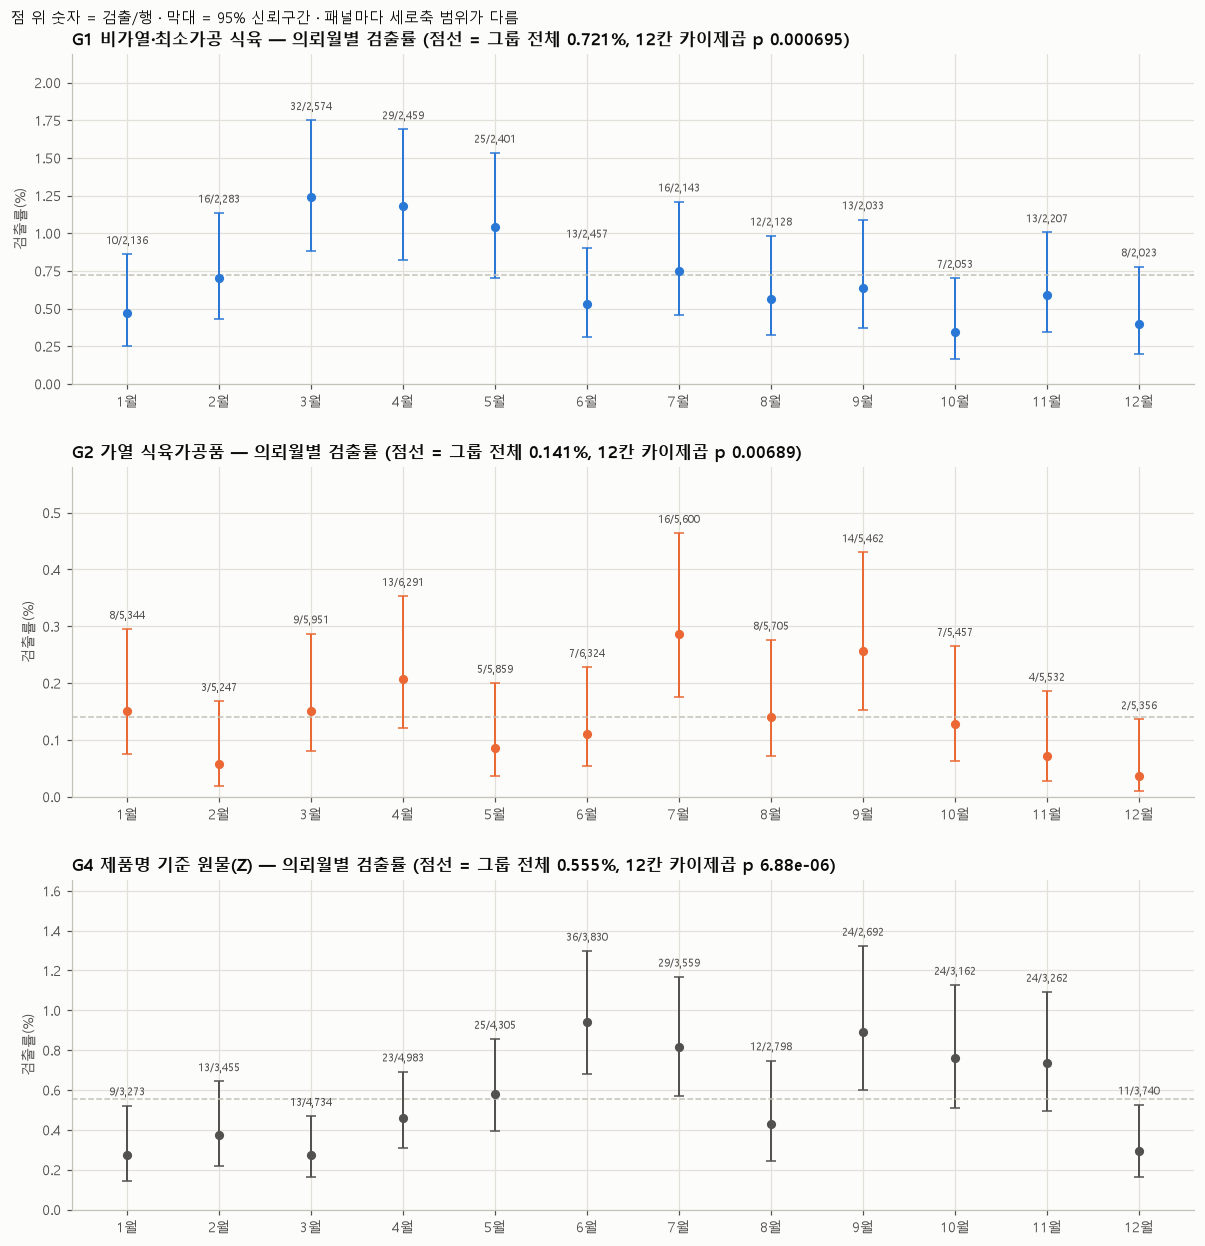

In [100]:
# [8-3 그림] 의뢰월별 검출률과 95% CI — G1·G2·G4 (패널마다 세로축 범위가 다름), 점 위 숫자 = 달별 검출/행
fig, axes = plt.subplots(3, 1, figsize=(11, 11.5))
_x = np.arange(1, 13)
for _ax, _g, _c in zip(axes, P09_TEST_GROUPS, [C1, C2, INK2]):
    _t = _p9_mt[_g]
    _r, _lo, _hi = _t['검출률(%)'].to_numpy(float), _t['CI하한'].to_numpy(float), _t['CI상한'].to_numpy(float)
    _ax.errorbar(_x, _r, yerr=[_r - _lo, _hi - _r], fmt='o', ms=5, color=_c, ecolor=_c, elinewidth=1.3, capsize=3)
    _tot = _t['검출'].sum() / _t['행'].sum() * 100
    _ax.axhline(_tot, color=GRAY, lw=1, ls='--')
    _top = np.nanmax(_hi)
    for _xi, _hv, _k, _n in zip(_x, _hi, _t['검출'], _t['행']):
        _ax.text(_xi, _hv + _top * 0.03, f'{int(_k)}/{int(_n):,}', ha='center', va='bottom', fontsize=7.5, color=INK2)
    _ax.set_xticks(_x)
    _ax.set_xticklabels([f'{m}월' for m in _x])
    _ax.set_xlim(0.4, 12.6)
    _ax.set_ylim(0, _top * 1.25)
    _ax.set_ylabel('검출률(%)')
    _ax.set_title(f"{_g} — 의뢰월별 검출률 (점선 = 그룹 전체 {_tot:.3f}%, 12칸 카이제곱 p {P09_CHI.loc[_g + ' / 의뢰월 12칸', 'p(근사)']})")
fig.suptitle('점 위 숫자 = 검출/행 · 막대 = 95% 신뢰구간 · 패널마다 세로축 범위가 다름', x=0.01, ha='left', fontsize=10)
plt.tight_layout(h_pad=2.5)
plt.show()

In [101]:
# [8-3 검사목적 층] G1·G2 × 검사목적 묶음 × 의뢰 계절 4칸 × {전체 연도, 2017~2025년만} — 1차 결과를 본 뒤 추가한 검정 (행 단위, 작성자 임의)
# 검출 0 인 층은 기대검출이 0 이라 X² 를 계산하지 않고 표만 둠. 의뢰일 없는 행은 G1·G2 모두 0 (위 셀 출력)
_rows, _ntest = [], 0
for _g, _mg in [(P09_GROUPS[1], _m_g1), (P09_GROUPS[2], _m_g2)]:
    for _b in P09_PURPOSE_BINS:
        for _yl, _yy in [('전체 연도', None), ('2017~2025', P09_YEARS)]:
            _mm = _mg & P09_PURPOSE.eq(_b) & d8['reqest_de'].notna()
            if _yy is not None:
                _mm = _mm & d8['연'].isin(_yy)
            _f = d8.loc[_mm, ['pos', 'reqest_de']]
            _t = p09_cells(_f.assign(계절=_f['reqest_de'].dt.month.map(P09_SEASON_OF)), '계절', P09_SEASONS)
            _r = {'그룹': _g.split(' ')[0], '검사목적 묶음': _b, '연도': _yl, '행': len(_f), '검출': int(_f['pos'].sum())}
            _r.update({s: (f'{int(k)}/{int(n):,} ({v:.3f}%)' if pd.notna(n) else '-') for s, k, n, v in zip(P09_SEASONS, _t['검출'], _t['행'], _t['검출률(%)'])})
            if _r['검출'] > 0:
                _c = p09_chi2_homog(_t['검출'], _t['행'])
                _ntest += 1
                _r.update({'X²': _c['X²'], 'p(근사)': _c['p(근사)'], '기대검출<5 칸': _c['기대검출<5 칸'], '뺀 칸(행 0)': _c['뺀 칸(행 0)']})
            else:
                _r.update({'X²': np.nan, 'p(근사)': '검정 안 함(검출 0)', '기대검출<5 칸': np.nan, '뺀 칸(행 0)': np.nan})
            _rows.append(_r)
P09_CHI_PURPOSE = pd.DataFrame(_rows).astype({'기대검출<5 칸': 'Int64', '뺀 칸(행 0)': 'Int64'}).set_index(['그룹', '검사목적 묶음', '연도'])
print(f'검사목적 층 계절 검정 {_ntest}개 (G1·G2 × 검사목적 묶음 × 전체 연도·2017~2025년, 검출 0 인 층 {len(_rows) - _ntest}개는 검정 안 함) — 칸 = 검출/행 (검출률)')
display(P09_CHI_PURPOSE)
print(f'8-3 카이제곱 합계: 기본 {len(P09_CHI)} + 1차 민감도 {len(P09_CHI_SENS)} + 검사목적 층(사후 추가) {_ntest} = {len(P09_CHI) + len(P09_CHI_SENS) + _ntest}개')

# 참고(검정 없음): G1 봄(3~5월) 검출이 검사목적 묶음마다 어느 연-월·검사기관에서 나왔나
_p1 = d8.loc[_m_g1 & d8['pos'].eq(1), ['reqest_de']]
_spr = _p1['reqest_de'].dt.month.isin([3, 4, 5]).to_numpy()
for _b in P09_PURPOSE_BINS:
    _ix = _p1.index[_spr & P09_PURPOSE.loc[_p1.index].eq(_b).to_numpy()]
    if len(_ix) == 0:
        print(f'참고 — G1 봄 검출 {_b}: 0건')
        continue
    print(f'참고 — G1 봄 검출 {_b} {len(_ix)}건 (검출 의뢰키 {_p9_rk.loc[_ix].nunique()}개): 의뢰 연-월 상위 '
          + ', '.join(f'{k} {v}' for k, v in p09_vc(_p1.loc[_ix, 'reqest_de'].dt.strftime('%Y-%m'), 6).items())
          + ' / 검사기관 상위 ' + ', '.join(f'{k} {v}' for k, v in p09_vc(dfx.loc[_ix, 'inspct_instt_code'], 3).items()))
del _rows, _f, _t, _p1, _spr

검사목적 층 계절 검정 12개 (G1·G2 × 검사목적 묶음 × 전체 연도·2017~2025년, 검출 0 인 층 4개는 검정 안 함) — 칸 = 검출/행 (검출률)


행   검출             봄(3~5월)            여름(6~8월)           가을(9~11월)          겨울(12~2월)     X²         p(근사)  기대검출<5 칸  뺀 칸(행 0)
그룹 검사목적 묶음  연도                                                                                                                                           
G1 자가품질위탁   전체 연도      21039   27    9/5,603 (0.161%)    7/5,372 (0.130%)    6/4,882 (0.123%)   5/5,182 (0.096%)   0.88         0.831         0         0
            2017~2025  19954   26    9/5,044 (0.178%)    7/5,188 (0.135%)    6/4,874 (0.123%)   4/4,848 (0.083%)   1.78          0.62         0         0
   기타       전체 연도       2573  128     52/782 (6.650%)     30/596 (5.034%)     21/588 (3.571%)    25/607 (4.119%)   8.04        0.0453         0         0
            2017~2025   2264  118     46/618 (7.443%)     29/529 (5.482%)     20/583 (3.431%)    23/534 (4.307%)  10.94        0.0121         0         0
   수거·HACCP 전체 연도       2376   39     25/800 (3.125%)      4/535 (0.748%)      6/615 (0.976%)     4/426 (0.939%)  16.54      0.000877         0         0
            2017~2025   2110   31     17/600 (2.833%)      4/515 (0.777%)      6/615 (0.976%)     4/380 (1.053%)  10.91        0.0122         0         0
   그 외      전체 연도        909    0      0/249 (0.000%)      0/225 (0.000%)      0/208 (0.000%)     0/227 (0.000%)    NaN  검정 안 함(검출 0)      <NA>      <NA>
            2017~2025    814    0      0/205 (0.000%)      0/211 (0.000%)      0/200 (0.000%)     0/198 (0.000%)    NaN  검정 안 함(검출 0)      <NA>      <NA>
G2 자가품질위탁   전체 연도      55782   62  21/14,671 (0.143%)  14/14,304 (0.098%)  18/13,612 (0.132%)  9/13,195 (0.068%)   4.32         0.229         0         0
            2017~2025  51899   58  20/13,421 (0.149%)  13/13,283 (0.098%)  17/12,944 (0.131%)  8/12,251 (0.065%)   4.71         0.194         0         0
   기타       전체 연도       2092   18      2/541 (0.370%)      8/543 (1.473%)      5/509 (0.982%)     3/499 (0.601%)   4.40         0.221         4         0
            2017~2025   2015   18      2/508 (0.394%)      8/526 (1.521%)      5/496 (1.008%)     3/485 (0.619%)   4.26         0.235         4         0
   수거·HACCP 전체 연도       5351   16    4/1,568 (0.255%)    9/1,541 (0.584%)    2/1,168 (0.171%)   1/1,074 (0.093%)   6.47        0.0909         4         0
            2017~2025   4895   14    2/1,358 (0.147%)    9/1,441 (0.625%)    2/1,168 (0.171%)     1/928 (0.108%)   8.28        0.0405         4         0
   그 외      전체 연도       4903    0    0/1,321 (0.000%)    0/1,241 (0.000%)    0/1,162 (0.000%)   0/1,179 (0.000%)    NaN  검정 안 함(검출 0)      <NA>      <NA>
            2017~2025   4518    0    0/1,171 (0.000%)    0/1,183 (0.000%)    0/1,115 (0.000%)   0/1,049 (0.000%)    NaN  검정 안 함(검출 0)      <NA>      <NA>

8-3 카이제곱 합계: 기본 6 + 1차 민감도 16 + 검사목적 층(사후 추가) 12 = 34개
참고 — G1 봄 검출 자가품질위탁 9건 (검출 의뢰키 9개): 의뢰 연-월 상위 2018-05 2, 2018-03 1, 2018-04 1, 2019-04 1, 2019-05 1, 2020-03 1 / 검사기관 상위 O000026 1, O000033 1, O000047 1
참고 — G1 봄 검출 기타 52건 (검출 의뢰키 49개): 의뢰 연-월 상위 2022-04 6, 2024-04 6, 2023-05 5, 2025-04 4, 2021-03 3, 2021-04 3 / 검사기관 상위 O000044 20, O000084 12, O000047 4
참고 — G1 봄 검출 수거·HACCP 25건 (검출 의뢰키 25개): 의뢰 연-월 상위 2026-03 8, 2025-03 4, 2024-03 3, 2024-05 3, 2024-04 2, 2020-05 1 / 검사기관 상위 O000146 9, O000108 4, O000142 3
참고 — G1 봄 검출 그 외: 0건


📊 **결과**
- **G1 비가열·최소가공 식육** (26,897행 / 검출 194): 봄 1.157% (86/7,434, CI 0.938\~1.426) · 여름 0.609% · 가을 0.524% · 겨울 0.528%. 달로는 3월 1.243%·4월 1.179%·5월 1.041% 가 높고 10월 0.341% 가 가장 낮습니다.
  - 기본 (행 단위, 전체 연도): 의뢰월 12칸 X² 32.25, p 0.000695 (최고/최저 3.65배) / 계절 4칸 X² 27.65, p 4.31e-06 (2.21배)
  - ① 2017\~2025년만 (25,142행 / 검출 175): 12칸 X² 30.22, p 0.00146 / 4칸 X² 22.62, p 4.84e-05
  - ② 묶음 단위 (22,404개 / 검출 단위 176): 12칸 X² 28.14, p 0.00308 / 4칸 X² 24.47, p 2e-05
  - G1 봄 검출 86 중 2026년 14 (2026년 G1 검출 의뢰월 3월 11건)
- **G1 품목** (계절 4칸)
  - 포장육: 봄 4.728% (46/973)·여름 4.315%·가을 2.403%·겨울 3.060%, X² 6.52, p 0.0889 / 2017\~2025년만 봄 4.985% (34/682), X² 7.18, p 0.0664
  - 양념육: 봄 0.662% (39/5,894)·여름 0.303%·가을 0.332%·겨울 0.262%, X² 14.71, p 0.00208 / 2017\~2025년만 봄 0.702% (37/5,271), X² 17.08, p 0.00068
  - 생햄·발효소시지는 계절마다 검출 0\~3건 (참고표, 검정 없음)
- **G2 가열 식육가공품** (68,128행 / 검출 96): 봄 0.149% · 여름 0.176% · 가을 0.152% · 겨울 0.082% (13/15,947).
  - 기본: 계절 4칸 X² 5.76, p 0.124 (2.16배) / 의뢰월 12칸 X² 25.83, p 0.00689 — 7월 0.286% (16건) / 12월 0.037% (2건) = 7.65배, 달마다 검출 2\~16건
  - ① 2017\~2025년만: 12칸 X² 26.2, p 0.00606 / 4칸 X² 5.83, p 0.12
  - ② 묶음 단위 (35,953개 / 검출 단위 84): 12칸 X² 13.84, p 0.242 / 4칸 X² 3.14, p 0.371
- **G4 제품명 기준 원물** (43,793행 / 검출 243): 여름 0.756% · 가을 0.790% 가 봄 0.435% · 겨울 0.315% 보다 높습니다. 달로는 6월 0.940% 가 가장 높고 1월·3월 0.275% 가 가장 낮습니다.
  - 기본: 의뢰월 12칸 X² 44.14, p 6.88e-06 (3.42배) / 계절 4칸 X² 31.12, p 8.02e-07 (2.51배)
  - ① 2017\~2025년만: 12칸 p 1.34e-05 / 4칸 p 1.6e-06 — ② 묶음 단위 (18,668개 / 검출 단위 202): 12칸 p 0.000666 / 4칸 p 0.000177
- 기본·민감도 검정 모두 의뢰일 없는 행 0, 기대검출 5 미만 칸 0 입니다.
- **검사목적 층별 계절** (1차 결과를 본 뒤 추가, 행 단위, 계절 4칸 검출/행, p 는 전체 연도 → 2017\~2025년만)
  - G1 자가품질위탁 (21039행 / 27): 봄 9/5,603 · 여름 7/5,372 · 가을 6/4,882 · 겨울 5/5,182, X² 0.88, p 0.831 → 0.62
  - G1 기타 (2573행 / 128): 봄 52/782 (6.650%) · 여름 30/596 (5.034%) · 가을 21/588 (3.571%) · 겨울 25/607 (4.119%), X² 8.04, p 0.0453 → 0.0121
  - G1 수거·HACCP (2376행 / 39): 봄 25/800 (3.125%) · 여름 4/535 · 가을 6/615 · 겨울 4/426, X² 16.54, p 0.000877 → 0.0122
  - G2 자가품질위탁 (55782행 / 62): 봄 21/14,671 (0.143%) · 겨울 9/13,195 (0.068%), p 0.229 → 0.194
  - G2 기타 (2092행 / 18): 여름 8/543 (1.473%) 이 가장 높고 p 0.221 → 0.235 / G2 수거·HACCP (5351행 / 16): 여름 9/1,541 (0.584%) 이 가장 높고 p 0.0909 → 0.0405. 두 층 모두 기대검출 5 미만 칸 4개
  - '그 외' 층은 G1·G2 모두 검출 0 이라 검정하지 않았습니다.
- 참고(검정 없음) G1 봄 검출의 몰림
  - 자가품질위탁 9건: 의뢰 연-월 최다 2건(2018-05), 검사기관 최다 1건
  - 기타 52건 (검출 의뢰키 49개): 의뢰 연-월 최다 6건(2022-04, 2024-04), 검사기관 O000044 20·O000084 12·O000047 4
  - 수거·HACCP 25건 (검출 의뢰키 25개): 의뢰 연-월 2026-03 8·2025-03 4·2024-03 3·2024-05 3, 검사기관 O000146 9·O000108 4·O000142 3
- 8-3 카이제곱 합계: 기본 6 + 1차 민감도 16 + 검사목적 층(사후 추가) 12 = 34개

💬 **첨언**
- 행 단위로 보면 6절의 '식육가공품 및 포장육 봄 높음'은 G1(비가열 후보) 쪽에서 크게 보입니다. 2017\~2025년만(4칸 p 4.84e-05)이나 묶음 단위(4칸 p 2e-05)로 봐도 G1 봄 높음은 남습니다.
- 그러나 **검사목적 층으로 나누면 G1 행의 대부분인 자가품질위탁 층에서는 계절 차이가 작고 검정으로도 뚜렷하지 않습니다** (봄 0.161% vs 겨울 0.096%, p 0.831). 이 층은 검출이 27건뿐이라 차이를 잡을 힘은 약합니다. 뚜렷한 봄 초과는 수거·HACCP 층(봄 25/800)과 '기타' 층(봄 52/782)에서 나옵니다 (추정).
  - 수거·HACCP 층 봄 검출은 2026년·2025년·2024년 3월에 몰리고, 2017\~2025년만 봐도 p 0.0122 입니다. 봄철 수거·인증 검사 일정 같은 행정 요인일 수 있습니다 (추정) → 담당자 질문.
  - 그래서 G1 봄 높음을 날씨·원료육 계절성의 근거로 읽기 전에, **검사 일정·검사 사업 구성**을 먼저 확인할 필요가 있어 보입니다 (추정).
- G1 안에서 포장육은 계절 4칸 p 0.0889 로 차이가 뚜렷하지 않고, 양념육은 봄이 높은 모양입니다 (p 0.00208). 양념육 검출은 '기타' 층에 몰려 있어 (8-2) 이것도 검사 구성과 겹칠 수 있습니다 (추정).
- G2 는 계절 4칸 차이가 뚜렷하지 않고(p 0.124), 달 12칸 차이(p 0.00689)는 묶음 단위로 보면 p 0.242 로 약해집니다. 달마다 검출이 2\~16건이라 같은 업체·의뢰 몇 건에 흔들렸을 수 있습니다 (추정).
- G1 은 기온이 가장 높은 여름이 아니라 봄이 가장 높아, "기온이 높을수록 검출이 많다"는 단순한 가정과 곧바로 맞아 보이지 않습니다 (추정).
- G4 는 여름\~가을이 높아 G1 과 모양이 다르고, 2017\~2025년만·묶음 단위로도 남습니다. G4 는 검출의 99.6% 가 '기타' 층이고 원료육·생선 공정 시료가 섞여 있으며 연도마다 행이 크게 늘었으므로 (8-2), 검사 구성 영향일 수 있습니다 (추정).
- 한계: 이 소절에서 카이제곱을 34개 계산했고, 그중 검사목적 층 12개는 1차 결과를 본 뒤 추가했습니다. 이만큼 많이 보면 관계가 없어도 p<0.05 가 몇 개 나올 수 있습니다. 묶음 단위(②)는 업체·의뢰 군집을 일부만 반영하고 (G4 는 검출 행 93.4% 가 업체 식별 불가라 주로 의뢰 단위로 묶임), 검사목적 층 검정은 행 단위입니다. G2 기타·수거·HACCP 층은 기대검출 5 미만 칸이 있어 p 근사가 거칩니다.

### 8-4. 기상 — G1·G2·G4 의 7일 평균기온 5분위 검출률과 월 더미 + 기온 로지스틱

🔎 7절에서 만든 기상 창 값(`w7` 표의 `avg_ta_A7`, `avg_ta_B7`: 최근접 ASOS 관측소, 7일 창, 창 안 모든 날 값이 있을 때만)을 그대로 씁니다. 새로 계산하거나 채우지 않습니다.
- 5분위: 그룹 안에서 행 기준 5등분 (7절 `w7_qtab`, 작성자 임의). 로지스틱: 월 더미 + 기온 z점수, 우도비 p, 업체 군집 강건 p (7절 `w7_logit`·`w7_cluster_p`, 업체 = 7절 `w7['업체']`). 월은 기준 A 는 원본 제조일의 달, 기준 B 는 의뢰일의 달.
- 기본 모형에는 연도·지역·검사목적을 넣지 않았습니다 (7절과 같음). 민감도에서 S1 연도, S2 시도, S7 검사목적 묶음을 따로 넣어 봅니다. 이 소절의 S1\~S9 는 민감도 번호이고, 1절 범위 후보 S1\~S10(12절 종합표의 S1·S2·S7 등)과 다릅니다.
- 비교 목록 (절 머리에 먼저 적음)
  - 1차: 기본 {G1, G2, G4} × {기준 A 7일, 기준 B 7일} 5분위표 6개·로지스틱 6개 (G0 는 연결 행·검출 수만) / 민감도 S1·S2·S3·S4a·S5·S6 × A·B 12개
  - 1차 결과를 본 뒤 추가: S4b(달 효과를 그룹마다 따로 둔 상호작용) × A·B 2개, S7(G1 + 검사목적 묶음 더미)·S8(G1 검사목적 '기타'만)·S9(G1 자가품질위탁만) × A·B 6개
  - 로지스틱은 모두 26개입니다. 이만큼 많이 보면 관계가 없어도 우연히 p<0.05 가 몇 개 나올 수 있습니다.

In [102]:
# [8-4] 7절 기상 창 값에 그룹 라벨을 붙여 5분위·로지스틱 — 작성자 임의 방법 (7절 함수 그대로)
_p9_wg = MINPROC_GROUP.loc[w7.index]
assert int(_p9_wg.ne('').sum()) == int(MINPROC_GROUP.ne('').sum()), '그룹 행이 w7 에 모두 있지 않음'
P09_BASIS = [('A', '기준 A 원본 제조일 7일', 'mnfctur_de_raw', 'avg_ta_A7'), ('B', '기준 B 의뢰일 7일', 'reqest_de', 'avg_ta_B7')]

# G0: 연결 행·검출 수만 (표본 작음)
_g0 = w7[_p9_wg.eq(P09_GROUPS[0])]
print(f"{P09_GROUPS[0]}: {len(_g0):,}행 / 기준 A 7일 기온 있음 {int(_g0['avg_ta_A7'].notna().sum()):,}행·검출 {int(_g0.loc[_g0['avg_ta_A7'].notna(), 'pos'].sum())} "
      f"/ 기준 B 7일 기온 있음 {int(_g0['avg_ta_B7'].notna().sum()):,}행·검출 {int(_g0.loc[_g0['avg_ta_B7'].notna(), 'pos'].sum())} → 표본 작음, 분위·회귀 계산 안 함")

_p9_q, _p9_lrt, P09_QT = [], [], {}
for _g in P09_TEST_GROUPS:
    _s = w7.loc[_p9_wg.eq(_g), ['pos', 'avg_ta_A7', 'avg_ta_B7', 'mnfctur_de_raw', 'reqest_de', '업체']]
    for _b, _blab, _bc, _tc in P09_BASIS:
        _t, _drop = w7_qtab(_s, _tc)
        P09_QT[(_g, _b)] = _t
        _r = {'그룹': _g, '기준': _blab, '전체 행': len(_s), '뺀 행(기온 없음)': _drop, '연결 행': int(_t['행수'].sum()), '검출': int(_t['검출'].sum())}
        _r.update({f'{q}(%)': v for q, v in _t['검출률(%)'].items()})
        _r['Q1~Q5 검출'] = '·'.join(str(int(k)) for k in _t['검출'])
        _r['Q1 범위'], _r['Q5 범위'] = _t['값 범위'].iloc[0], _t['값 범위'].iloc[-1]
        _r['비고'] = '표본 작음' if _r['검출'] < 50 else ''
        _p9_q.append(_r)
        # 로지스틱 (7절 [7-3] 과 같은 식): 모형0 = 절편 + 월 더미, 모형1 = 모형0 + 기온 z
        _u = _s[_s[_tc].notna()]
        _y = _u['pos'].to_numpy(dtype=float)
        _mon = _u[_bc].dt.month.to_numpy()
        _pres = sorted(set(_mon.tolist()))
        _X0 = np.column_stack([np.ones(len(_u))] + [(_mon == m).astype(float) for m in _pres[1:]])   # 기준 달 = 있는 달 중 가장 이른 달 (1월이 있으면 7절과 같음)
        _ta = _u[_tc].to_numpy()
        _sd = _ta.std()
        _X1 = np.column_stack([_X0, (_ta - _ta.mean()) / _sd])
        _b0, _ll0, _, _, _cv0 = w7_logit(_X0, _y)
        _b1, _ll1, _, _, _cv1 = w7_logit(_X1, _y)
        _lr = max(2 * (_ll1 - _ll0), 0.0)
        _se, _se_c, _p_c, _ncl = w7_cluster_p(_X1, _y, _b1, _u['업체'].to_numpy().astype(str))
        _wsd = float((pd.Series(_ta) - pd.Series(_ta).groupby(_mon).transform('mean')).std(ddof=0))
        _c1 = _b1[-1] / _sd
        _mk = pd.Series(_y).groupby(_mon).sum()
        _p9_lrt.append({'그룹': _g, '기준': _blab, '사용 행': len(_u), '검출': int(_y.sum()), '기준 달': _pres[0], '검출 0인 달 수': int((_mk == 0).sum()),
                        '기온 SD(℃)': round(_sd, 2), '달 안 기온 SD(℃)': round(_wsd, 2), '오즈비(1℃당)': round(math.exp(_c1), 3),
                        '1℃당 95%구간(Wald)': f'{math.exp(_c1 - 1.96 * _se / _sd):.3f}~{math.exp(_c1 + 1.96 * _se / _sd):.3f}',
                        '오즈비(달 안 SD당)': round(math.exp(_c1 * _wsd), 3), 'LR 통계량': round(_lr, 2),
                        'p값(자유도1 근사)': f'{math.erfc(math.sqrt(_lr / 2)):.3g}', '업체 군집 수': _ncl, '군집 강건 p값': f'{_p_c:.3g}',
                        '수렴(모형0/1)': f'{_cv0}/{_cv1}', '비고': '표본 작음' if _y.sum() < 50 else ''})
P09_Q = pd.DataFrame(_p9_q)
P09_LRT = pd.DataFrame(_p9_lrt)
print('7일 평균기온(ASOS avg_ta) 5분위 검출률(%) — 그룹 안 5등분. 뺀 행 = 그룹 안에서 그 기준 기온 값이 없는 행')
display(P09_Q)
print('월 더미만 vs 월 더미 + 7일 평균기온 — 오즈비는 1℃당, 그리고 같은 달 안 기온 SD 당')
display(P09_LRT)
print('참고(7절 같은 방식): 국내 가공식품 전체 기준 A 1℃당 오즈비·p 는 7절 W7_LRT 첫 행')

G0 국내 원물(통계용 분류): 3,533행 / 기준 A 7일 기온 있음 1,168행·검출 8 / 기준 B 7일 기온 있음 2,917행·검출 19 → 표본 작음, 분위·회귀 계산 안 함
7일 평균기온(ASOS avg_ta) 5분위 검출률(%) — 그룹 안 5등분. 뺀 행 = 그룹 안에서 그 기준 기온 값이 없는 행


,그룹,기준,전체 행,뺀 행(기온 없음),연결 행,검출,Q1(%),Q2(%),Q3(%),Q4(%),Q5(%),Q1~Q5 검출,Q1 범위,Q5 범위,비고
0,G1 비가열·최소가공 식육,기준 A 원본 제조일 7일,26897,7248,19649,131,0.534,0.738,0.789,0.559,0.714,21·29·31·22·28,-12.0~4.3℃,23.5~31.9℃,
1,G1 비가열·최소가공 식육,기준 B 의뢰일 7일,26897,1816,25081,173,0.598,0.658,0.917,0.578,0.698,30·33·46·29·35,-13.9~4.3℃,23.5~32.2℃,
2,G2 가열 식육가공품,기준 A 원본 제조일 7일,68128,18578,49550,65,0.061,0.131,0.061,0.202,0.202,6·13·6·20·20,-12.2~3.4℃,23.5~31.9℃,
3,G2 가열 식육가공품,기준 B 의뢰일 7일,68128,2180,65948,92,0.106,0.129,0.114,0.159,0.190,14·17·15·21·25,-13.9~3.7℃,23.4~32.1℃,
4,G4 제품명 기준 원물(Z),기준 A 원본 제조일 7일,43793,36751,7042,35,0.284,0.426,0.355,0.992,0.427,4·6·5·14·6,-11.8~3.3℃,23.9~31.5℃,표본 작음
5,G4 제품명 기준 원물(Z),기준 B 의뢰일 7일,43793,1303,42490,223,0.306,0.400,0.622,0.708,0.588,26·34·53·60·50,-11.8~3.0℃,23.1~31.9℃,


월 더미만 vs 월 더미 + 7일 평균기온 — 오즈비는 1℃당, 그리고 같은 달 안 기온 SD 당


,그룹,기준,사용 행,검출,기준 달,검출 0인 달 수,기온 SD(℃),달 안 기온 SD(℃),오즈비(1℃당),1℃당 95%구간(Wald),오즈비(달 안 SD당),LR 통계량,p값(자유도1 근사),업체 군집 수,군집 강건 p값,수렴(모형0/1),비고
0,G1 비가열·최소가공 식육,기준 A 원본 제조일 7일,19649,131,1,0,9.58,3.02,1.072,1.011~1.137,1.234,5.36,0.0206,5413,0.059,True/True,
1,G1 비가열·최소가공 식육,기준 B 의뢰일 7일,25081,173,1,0,9.61,3.00,1.063,1.009~1.119,1.201,5.36,0.0206,6165,0.0602,True/True,
2,G2 가열 식육가공품,기준 A 원본 제조일 7일,49550,65,1,0,9.79,2.88,0.986,0.895~1.085,0.959,0.09,0.766,8835,0.788,True/True,
3,G2 가열 식육가공품,기준 B 의뢰일 7일,65948,92,1,0,9.72,2.89,0.938,0.869~1.013,0.831,2.68,0.102,10952,0.164,True/True,
4,G4 제품명 기준 원물(Z),기준 A 원본 제조일 7일,7042,35,1,0,9.88,2.78,0.911,0.803~1.033,0.771,2.13,0.145,5258,0.136,True/True,표본 작음
5,G4 제품명 기준 원물(Z),기준 B 의뢰일 7일,42490,223,1,0,9.76,2.85,1.018,0.970~1.067,1.051,0.51,0.475,32445,0.457,True/True,


참고(7절 같은 방식): 국내 가공식품 전체 기준 A 1℃당 오즈비·p 는 7절 W7_LRT 첫 행


In [103]:
# [8-4 민감도] 1차 S1·S2·S3·S4a·S5·S6 × 기준 A·B = 12개 + 1차 결과를 본 뒤 추가한 S4b·S7·S8·S9 × A·B = 8개 (목록은 절 머리에 먼저 적음)
# 모형 구성은 모두 작성자 임의 방법
# 공통: 모형0 = 절편 + 요인 더미, 모형1 = 모형0 + 시험할 열. 우도비 LR = 2(ℓ1 − ℓ0), 자유도 1 → p = erfc(√(LR/2)) (7절 [7-3] 식)
#   S1 요인 = 월 + 연도(기준 날짜의 연도) / S2 요인 = 월 + 시도(legal_dong_code 앞 2자리) / S3·S5·S6·S8·S9 요인 = 월
#   S4a 상호작용: 행 = G1 ∪ G2, 모형0 = 월 + G1 표시(0/1) + 기온 z, 모형1 = 모형0 + 기온 z × G1 표시
#      → 시험 계수 = 'G1 의 기온 기울기 − G2 의 기온 기울기', 오즈비 칸은 두 그룹 1℃당 오즈비의 비
#   S4b (사후 추가): S4a 와 같지만 월 더미를 그룹마다 따로 둠 (요인 = 월×그룹 24칸, G1 표시 주효과는 이 더미에 들어감)
#   S7 (사후 추가) 요인 = 월 + 검사목적 묶음(8-2 의 작성자 임의 묶음) / S8·S9 (사후 추가) = G1 중 검사목적 묶음 '기타'·'자가품질위탁' 행만
# 검출 0 칸 처리 (7-5-1 과 같은 작성자 임의 처리): 어떤 요인 칸에 검출이 하나도 없으면 그 칸 행을 빼고 적합 (새 0 칸이 없을 때까지 되풀이).
#   그 칸 더미 계수는 −∞ 로 가서 그 행들은 기온 계수 계산에 기여하지 않음 → 극한에서 전체 행 적합과 같은 값으로 봄
# 군집 강건 p: 7절 w7_cluster_p (업체 = w7['업체'], 식별 불가 행은 행 1개 = 군집 1개). z = (기온 − 평균)/표준편차, 사용 행에서 계산
def p09_sens_fit(s, factors, tcol, inter=None):
    keep = np.ones(len(s), bool)
    dropped = []
    while True:
        changed = False
        for f in factors:
            g = s.loc[keep].groupby(f)['pos'].agg(['size', 'sum'])
            z = g[g['sum'] == 0]
            if len(z):
                dropped += [f'{f}={i}({int(n):,}행)' for i, n in z['size'].items()]
                keep = keep & ~s[f].isin(z.index).to_numpy()
                changed = True
        if not changed:
            break
    u = s.loc[keep]
    y = u['pos'].to_numpy(dtype=float)
    cols = [np.ones(len(u))]
    for f in factors:
        v = u[f].astype(str).to_numpy()
        cols += [(v == lv).astype(float) for lv in np.unique(v)[1:]]     # 기준 칸 = 정렬 첫 값
    t = u[tcol].to_numpy(dtype=float)
    sd = t.std()
    zt = (t - t.mean()) / sd
    if inter is None:
        X0, xt = np.column_stack(cols), zt
    else:
        X0, xt = np.column_stack(cols + [zt]), zt * u[inter].to_numpy(dtype=float)
    X1 = np.column_stack([X0, xt])
    _, ll0, _, _, cv0 = w7_logit(X0, y)
    b1, ll1, _, _, cv1 = w7_logit(X1, y)
    lr = max(2 * (ll1 - ll0), 0.0)
    se, _, p_c, ncl = w7_cluster_p(X1, y, b1, u['업체'].to_numpy().astype(str))
    c1 = b1[-1] / sd
    mon = u['월'].to_numpy()
    wsd = float((pd.Series(t) - pd.Series(t).groupby(mon).transform('mean')).std(ddof=0))
    return {'사용 행': len(u), '검출': int(y.sum()), '검출 0 칸으로 뺀 행': int((~keep).sum()), '더미 수': X0.shape[1] - 1 - (inter is not None),
            '오즈비(1℃당)': round(math.exp(c1), 3), '1℃당 95%구간(Wald)': f'{math.exp(c1 - 1.96 * se / sd):.3f}~{math.exp(c1 + 1.96 * se / sd):.3f}',
            '오즈비(달 안 SD당)': round(math.exp(c1 * wsd), 3) if inter is None else '-', '달 안 SD(℃)': round(wsd, 2),
            'LR 통계량': round(lr, 2), 'p값(자유도1 근사)': f'{math.erfc(math.sqrt(lr / 2)):.3g}', '업체 군집 수': ncl, '군집 강건 p값': f'{p_c:.3g}',
            '수렴(모형0/1)': f'{cv0}/{cv1}', '뺀 칸': ', '.join(dropped) if dropped else ''}


_wi = w7.index
_is_dom_c = (dfx.loc[_wi, '국내해외'].eq('국내') & dfx.loc[_wi, '대분류'].eq('가공식품')).to_numpy()
_is_g1 = _p9_wg.eq(P09_GROUPS[1]).to_numpy()
_is_g2 = _p9_wg.eq(P09_GROUPS[2]).to_numpy()
_nm_w = dfx.loc[_wi, '품목명'].astype(str).to_numpy()
_sido_w = dfx.loc[_wi, 'legal_dong_code'].astype('string').str[:2]
_pur_w = p09_purpose_bin(dfx.loc[_wi, '검사목적'])                        # 8-2 와 같은 검사목적 묶음 (w7 인덱스)
print(f'시도(법정동코드 앞 2자리) 결측: G1 {int(_sido_w[_is_g1].isna().sum())}행')
P09_SENS_LIST = [('S1', 'G1 + 연도 더미', _is_g1, ['월', '연도'], None),
                 ('S2', 'G1 + 시도 더미', _is_g1, ['월', '시도'], None),
                 ('S3', '대조군: 국내 가공식품 − G1', _is_dom_c & ~_is_g1, ['월'], None),
                 ('S4a', 'G1 vs G2 기온 기울기 차이 (상호작용, 달 효과 두 그룹 공통)', _is_g1 | _is_g2, ['월', 'G1표시'], 'G1표시'),
                 ('S4b', '(사후 추가) G1 vs G2 기온 기울기 차이 (상호작용, 달 효과 그룹마다 따로)', _is_g1 | _is_g2, ['월×그룹'], 'G1표시'),
                 ('S5', '포장육만', _is_g1 & (_nm_w == '포장육'), ['월'], None),
                 ('S6', '양념육만', _is_g1 & (_nm_w == '양념육'), ['월'], None),
                 ('S7', '(사후 추가) G1 + 검사목적 묶음 더미', _is_g1, ['월', '검사목적묶음'], None),
                 ('S8', "(사후 추가) G1 검사목적 '기타'만", _is_g1 & (_pur_w == '기타').to_numpy(), ['월'], None),
                 ('S9', '(사후 추가) G1 검사목적 자가품질위탁만', _is_g1 & (_pur_w == '자가품질위탁').to_numpy(), ['월'], None)]
_rows = []
for _b, _blab, _bc, _tc in P09_BASIS:
    for _k, _d, _mm, _facs, _inter in P09_SENS_LIST:
        _s = w7.loc[_mm, ['pos', _tc, _bc, '업체']]
        _s = _s[_s[_tc].notna()]
        _s = _s.assign(월=_s[_bc].dt.month, 연도=_s[_bc].dt.year, 시도=_sido_w.loc[_s.index].to_numpy(),
                       G1표시=_p9_wg.loc[_s.index].eq(P09_GROUPS[1]).astype(int).to_numpy(), 검사목적묶음=_pur_w.loc[_s.index].to_numpy())
        _s['월×그룹'] = _s['월'].astype(str) + '_' + _s['G1표시'].astype(str)
        if _s['시도'].isna().any() and '시도' in _facs:
            raise ValueError('시도 결측 행이 있음 — 빼는 규칙을 먼저 정해야 함')
        _fit = p09_sens_fit(_s, _facs, _tc, _inter)
        _rows.append({'변형': _k, '설명': _d, '기준': _blab, **_fit, '비고': '표본 작음' if _fit['검출'] < 50 else ''})
P09_LRT_SENS = pd.DataFrame(_rows)
_nc = P09_LRT_SENS['수렴(모형0/1)'].ne('True/True')
print('수렴 실패 모형:', '없음' if not _nc.any() else P09_LRT_SENS.loc[_nc, ['변형', '기준']].values.tolist())
print(f'민감도 {len(P09_LRT_SENS)}개 (1차 12 + 사후 추가 {len(P09_LRT_SENS) - 12}) — S4a·S4b 의 오즈비·구간은 G1 1℃당 오즈비 ÷ G2 1℃당 오즈비, p 는 두 기울기가 같은지 보는 p')
display(P09_LRT_SENS.drop(columns=['뺀 칸']))
for _, _r in P09_LRT_SENS[P09_LRT_SENS['뺀 칸'].ne('')].iterrows():
    print(f"검출 0 칸으로 뺀 칸 — {_r['변형']} {_r['기준']}: {_r['뺀 칸']}")
print(f'8-4 합계: 5분위표 {len(P09_Q)}개, 로지스틱 기본 {len(P09_LRT)} + 민감도 {len(P09_LRT_SENS)} = {len(P09_LRT) + len(P09_LRT_SENS)}개')
del _wi, _is_dom_c, _is_g1, _is_g2, _nm_w, _sido_w, _pur_w, _s, _fit

시도(법정동코드 앞 2자리) 결측: G1 0행
수렴 실패 모형: 없음
민감도 20개 (1차 12 + 사후 추가 8) — S4a·S4b 의 오즈비·구간은 G1 1℃당 오즈비 ÷ G2 1℃당 오즈비, p 는 두 기울기가 같은지 보는 p


,변형,설명,기준,사용 행,검출,검출 0 칸으로 뺀 행,더미 수,오즈비(1℃당),1℃당 95%구간(Wald),오즈비(달 안 SD당),달 안 SD(℃),LR 통계량,p값(자유도1 근사),업체 군집 수,군집 강건 p값,수렴(모형0/1),비고
0,S1,G1 + 연도 더미,기준 A 원본 제조일 7일,19649,131,0,21,1.053,0.993~1.118,1.17,3.02,2.94,0.0866,5413,0.152,True/True,
1,S2,G1 + 시도 더미,기준 A 원본 제조일 7일,18647,131,1002,25,1.046,0.981~1.114,1.145,3.04,1.89,0.17,5194,0.237,True/True,
2,S3,대조군: 국내 가공식품 − G1,기준 A 원본 제조일 7일,193571,126,0,11,0.974,0.911~1.040,0.926,2.86,0.63,0.427,45768,0.431,True/True,
3,S4a,"G1 vs G2 기온 기울기 차이 (상호작용, 달 효과 두 그룹 공통)",기준 A 원본 제조일 7일,69199,196,0,12,0.965,0.932~1.000,-,2.93,4.02,0.045,13865,0.114,True/True,
4,S4b,"(사후 추가) G1 vs G2 기온 기울기 차이 (상호작용, 달 효과 그룹마다 따로)",기준 A 원본 제조일 7일,69199,196,0,23,1.088,0.972~1.218,-,2.93,2.15,0.143,13865,0.198,True/True,
5,S5,포장육만,기준 A 원본 제조일 7일,1936,72,0,11,0.954,0.881~1.034,0.864,3.13,1.31,0.252,787,0.342,True/True,
6,S6,양념육만,기준 A 원본 제조일 7일,15216,58,1331,10,1.051,0.961~1.151,1.164,3.04,1.18,0.277,4150,0.314,True/True,
7,S7,(사후 추가) G1 + 검사목적 묶음 더미,기준 A 원본 제조일 7일,18847,131,802,13,0.986,0.928~1.047,0.957,3.03,0.22,0.636,5386,0.685,True/True,
8,S8,(사후 추가) G1 검사목적 '기타'만,기준 A 원본 제조일 7일,1611,86,0,11,0.940,0.869~1.016,0.829,3.03,2.47,0.116,759,0.137,True/True,
9,S9,(사후 추가) G1 검사목적 자가품질위탁만,기준 A 원본 제조일 7일,14840,18,1304,10,1.097,0.938~1.283,1.326,3.05,1.34,0.247,4040,0.384,True/True,표본 작음


검출 0 칸으로 뺀 칸 — S2 기준 A 원본 제조일 7일: 시도=30(948행), 시도=36(54행)
검출 0 칸으로 뺀 칸 — S6 기준 A 원본 제조일 7일: 월=8(1,331행)
검출 0 칸으로 뺀 칸 — S7 기준 A 원본 제조일 7일: 검사목적묶음=그 외(802행)
검출 0 칸으로 뺀 칸 — S9 기준 A 원본 제조일 7일: 월=8(1,304행)
검출 0 칸으로 뺀 칸 — S2 기준 B 의뢰일 7일: 시도=30(1,229행), 시도=36(70행)
검출 0 칸으로 뺀 칸 — S7 기준 B 의뢰일 7일: 검사목적묶음=그 외(903행)
검출 0 칸으로 뺀 칸 — S9 기준 B 의뢰일 7일: 월=8(1,623행)
8-4 합계: 5분위표 6개, 로지스틱 기본 6 + 민감도 20 = 26개


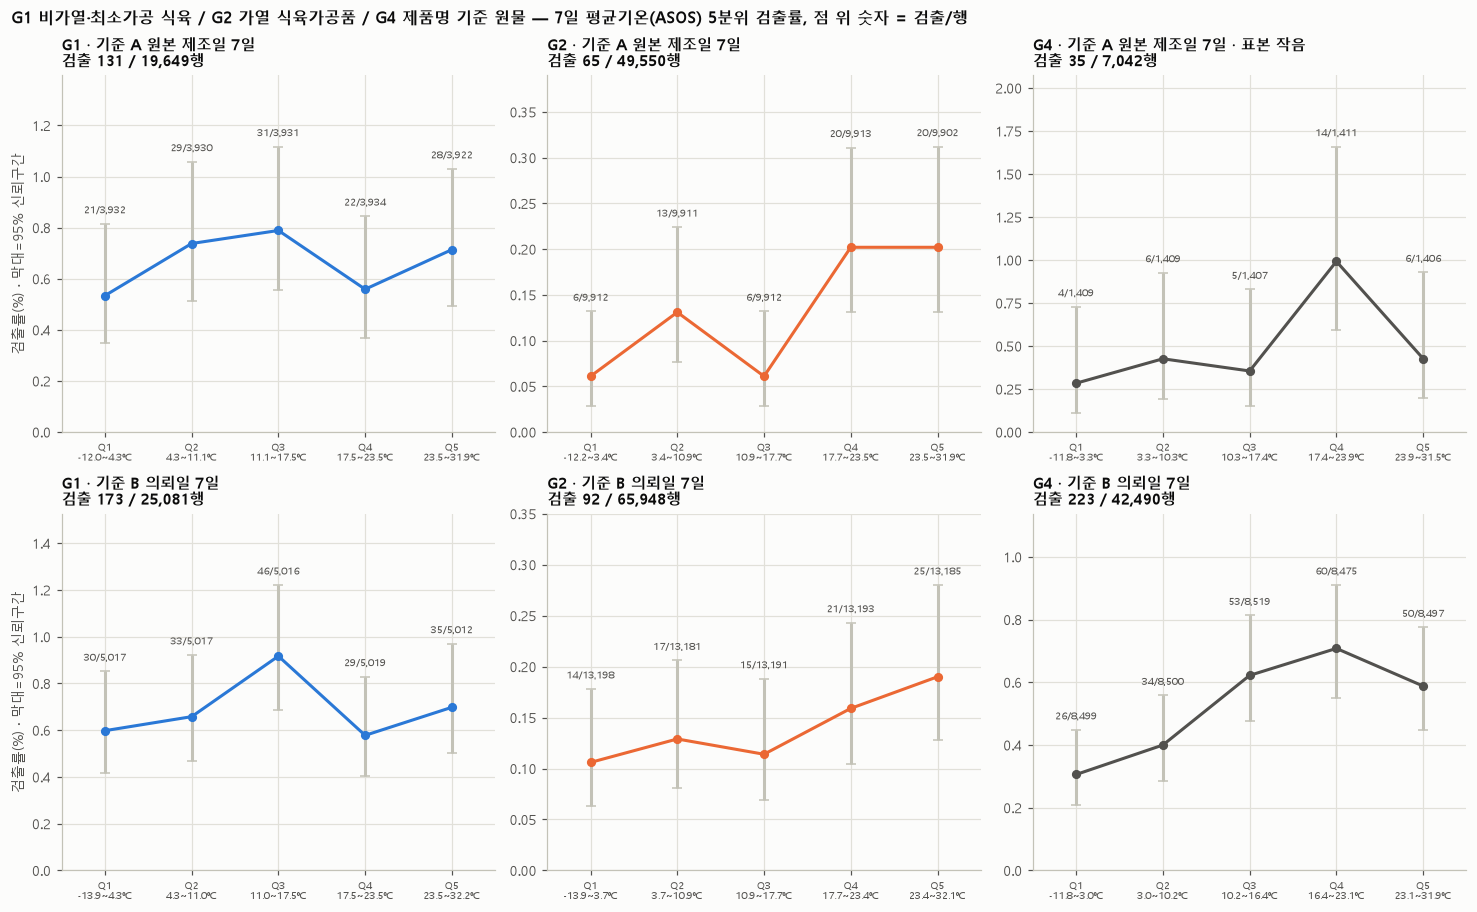

In [104]:
# [8-4 그림] 5분위 검출률 — 윗줄 기준 A(원본 제조일), 아랫줄 기준 B(의뢰일), 패널마다 세로축 범위가 다름
fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.4))
for _i, (_b, _blab, _, _) in enumerate(P09_BASIS):
    for _j, (_g, _c) in enumerate(zip(P09_TEST_GROUPS, [C1, C2, INK2])):
        _ax = axes[_i, _j]
        _t = P09_QT[(_g, _b)]
        _x = np.arange(len(_t))
        _r = _t['검출률(%)'].to_numpy()
        _ax.errorbar(_x, _r, yerr=[_r - _t['CI 하한(%)'].to_numpy(), _t['CI 상한(%)'].to_numpy() - _r],
                     fmt='o-', color=_c, ecolor=GRAY, elinewidth=2, capsize=3, markersize=5)
        _top = _t['CI 상한(%)'].max()
        for _xi, _k, _n, _hv in zip(_x, _t['검출'], _t['행수'], _t['CI 상한(%)']):
            _ax.text(_xi, _hv + _top * 0.03, f'{_k}/{_n:,}', ha='center', va='bottom', fontsize=6.5, color=INK2)
        _ax.set_xticks(_x)
        _ax.set_xticklabels([f'{q}\n{v}' for q, v in zip(_t.index, _t['값 범위'])], fontsize=6.5)
        _ax.set_ylim(0, _top * 1.25)
        _ax.set_xlim(-0.5, len(_t) - 0.5)
        _sm = ' · 표본 작음' if _t['검출'].sum() < 50 else ''
        _ax.set_title(f"{_g.split(' ', 1)[0]} · {_blab}{_sm}\n검출 {_t['검출'].sum():,} / {_t['행수'].sum():,}행", fontsize=9.5)
        if _j == 0:
            _ax.set_ylabel('검출률(%) · 막대=95% 신뢰구간')
fig.suptitle('G1 비가열·최소가공 식육 / G2 가열 식육가공품 / G4 제품명 기준 원물 — 7일 평균기온(ASOS) 5분위 검출률, 점 위 숫자 = 검출/행',
             x=0.01, ha='left', fontsize=10.5, fontweight='bold')
fig.tight_layout()
plt.show()

📊 **결과**
- G0 국내 원물(통계용 분류): 기준 A 7일 기온 있음 1,168행·검출 8, 기준 B 7일 2,917행·검출 19 → 표본 작음, 분위·회귀를 계산하지 않았습니다.
- 7일 평균기온(ASOS) 5분위 검출률 Q1·Q2·Q3·Q4·Q5
  - G1 기준 A (19649행·검출 131, 기온 없어 뺀 행 7248): 0.534·0.738·0.789·0.559·0.714%
  - G1 기준 B (25081행·173, 뺀 행 1816): 0.598·0.658·0.917·0.578·0.698%
  - G2 기준 A (49550행·65, 뺀 행 18578): 0.061·0.131·0.061·0.202·0.202%
  - G2 기준 B (65948행·92, 뺀 행 2180): 0.106·0.129·0.114·0.159·0.190%
  - G4 기준 A (7042행·35, 뺀 행 36751, 표본 작음): 0.284·0.426·0.355·0.992·0.427%
  - G4 기준 B (42490행·223, 뺀 행 1303): 0.306·0.400·0.622·0.708·0.588%
- 기본 로지스틱: 월 더미 + 7일 평균기온 (오즈비는 1℃당, 괄호 끝은 같은 달 안 기온 SD 만큼 올랐을 때)
  - G1 기준 A: 1.072 (Wald 95% 1.011\~1.137; 달 안 SD 3.02℃당 1.234), LR 5.36, p 0.0206 → 업체 군집 강건 p 0.059
  - G1 기준 B: 1.063 (1.009\~1.119; SD 3.00℃당 1.201), LR 5.36, p 0.0206 → 군집 강건 p 0.0602
  - G2 기준 A: 0.986 (0.895\~1.085), LR 0.09, p 0.766 → 0.788 / G2 기준 B: 0.938 (0.869\~1.013), LR 2.68, p 0.102 → 0.164
  - G4 기준 A: 0.911 (0.803\~1.033), p 0.145 → 0.136 (표본 작음) / G4 기준 B: 1.018 (0.970\~1.067), LR 0.51, p 0.475 → 0.457
  - 여섯 모형 모두 수렴했고 검출 0인 달은 없습니다. 기준 달은 모두 1월로 7절과 같습니다.
- 민감도 로지스틱 (1℃당 오즈비 (Wald 95%), LR p → 업체 군집 강건 p; 앞 = 기준 A, 뒤 = 기준 B)
  - S1 G1 + 연도 더미: 1.053 (0.993\~1.118), p 0.0866 → 0.152 / 1.048 (0.995\~1.104), p 0.0786 → 0.146
  - S2 G1 + 시도 더미: 1.046 (0.981\~1.114), p 0.17 → 0.237 / 1.043 (0.988\~1.102), p 0.125 → 0.193 — 검출 0 인 시도 30·36 행을 뺌 (A 1002행, B 1299행)
  - S3 대조군 '국내 가공식품 − G1': 0.974 (0.911\~1.040), p 0.427 → 0.431 / 0.950 (0.901\~1.002), p 0.0573 → 0.0682
  - S4a G1÷G2 기울기 비 (달 효과 두 그룹 공통): 0.965 (0.932\~1.000), p 0.045 → 0.114 / 0.980 (0.952\~1.008), p 0.156 → 0.275
  - S4b (사후 추가) G1÷G2 기울기 비 (달 효과 그룹마다 따로): 1.088 (0.972\~1.218), p 0.143 → 0.198 / 1.133 (1.033\~1.242), LR 7.03, p 0.00802 → 0.0233
  - S5 포장육만: 0.954 (0.881\~1.034), p 0.252 → 0.342 / 1.011 (0.941\~1.086), p 0.774 → 0.796
  - S6 양념육만: 1.051 (0.961\~1.151), p 0.277 → 0.314 / 1.011 (0.937\~1.092), p 0.773 → 0.805 — 기준 A 는 검출 0 인 8월 1331행을 뺌
  - S7 (사후 추가) G1 + 검사목적 묶음 더미: 0.986 (0.928\~1.047), p 0.636 → 0.685 / 1.007 (0.957\~1.059), p 0.799 → 0.827 — 검출 0 인 '그 외' 묶음 A 802행, B 903행을 뺌
  - S8 (사후 추가) G1 검사목적 '기타'만: 0.940 (0.869\~1.016), p 0.116 → 0.137 / 0.986 (0.927\~1.050), p 0.666 → 0.662
  - S9 (사후 추가) G1 자가품질위탁만 (검출 A 18·B 27, 표본 작음): 1.097 (0.938\~1.283), p 0.247 → 0.384 / 1.015 (0.887\~1.160), p 0.833 → 0.881 — 검출 0 인 8월 A 1304행, B 1623행을 뺌
  - 스무 모형 모두 수렴했습니다.
- 8-4 합계: 5분위표 6개, 로지스틱 기본 6 + 민감도 20 = 26개
- 그림의 여섯 패널은 세로축 범위가 서로 다릅니다.

💬 **첨언**
- G2 는 분위표에서 따뜻한 분위가 높아 보이지만(기준 A Q1 0.061% → Q5 0.202%), 달을 맞추면 기온 오즈비가 1 근처나 아래(0.986·0.938)입니다. 분위표 모양은 기온보다 **계절(달) 차이**를 담은 것으로 보입니다 (추정).
- G1 기본 모형은 같은 달 안에서 따뜻할수록 조금 높은 방향(1℃당 1.072·1.063)이지만, **설정을 바꾸면 약해지거나 1 근처가 됩니다** (추정).
  - 업체 군집을 반영하면 p 0.059·0.0602, 연도 더미를 넣으면(S1) p 0.0866·0.0786 (군집 0.152·0.146), 시도 더미를 넣으면(S2) p 0.17·0.125 입니다.
  - 거의 같은 행에 검사목적 묶음 더미만 더 넣으면(S7, 사후 추가) 0.986·1.007 (p 0.636·0.799) 로 1 근처가 됩니다.
  - 행을 나누면 포장육만(S5) 0.954·1.011 (p 0.252·0.774), 양념육만(S6) 1.051·1.011 (p 0.277·0.773), '기타' 층만(S8) 0.940·0.986 (p 0.116·0.666) 으로 방향이 엇갈리고 뚜렷하지 않습니다. 다만 행이 줄어 차이를 잡을 힘도 약합니다.
  - 그래서 G1 기본 모형의 양(+) 계수는 기온 자체보다 **검사목적·연도·지역 구성**을 담았을 가능성이 있어 보입니다 (추정). 예를 들어 같은 달 안에서도 검출률이 높은 검사 사업의 행이 따뜻한 지역·해에 많으면 이런 계수가 나올 수 있습니다.
- G1 과 G2 의 기온 기울기 차이는 설정에 따라 방향이 바뀝니다: 달 효과를 공통으로 두면(S4a) G1 쪽이 낮은 방향(0.965·0.980), 그룹마다 따로 두면(S4b) G1 쪽이 높은 방향(1.088·1.133)입니다. S4b 기준 B 는 p 0.00802 (군집 0.0233) 이지만 1차 결과를 본 뒤 추가한 설정이라, 이 p 를 근거로 쓰기는 어렵습니다 (추정).
- 대조군 '국내 가공식품 − G1'(S3)은 0.974·0.950 입니다. 7절의 가공식품 전체 양(+) 계수(기준 A 1℃당 1.060)는 G1 행이 끌었을 수 있지만, 위처럼 G1 계수가 검사목적 구성을 맞추면 1 근처가 되므로 7절 계수를 "비가열 식육의 기온 신호"로 읽기는 어려워 보입니다 (추정).
- G1 은 달로는 봄이 가장 높은데(8-3), 이 봄 초과도 수거·HACCP·'기타' 층에서 나와 검사 일정과 겹쳐 보입니다.
- G4 기준 B 도 분위표는 따뜻한 쪽이 높아 보이지만, 달을 맞추면 p 0.475 입니다. G4 기준 A 는 원본 제조일 있는 행이 적어 표본이 작습니다.
- 한계: 이 소절에서 5분위표 6개와 로지스틱 26개를 봤고, 그중 S4b·S7·S8·S9 8개는 1차 결과를 본 뒤 추가했습니다. 기본 모형에는 연도·지역·검사목적 보정이 없고, 민감도는 한 번에 하나씩만 넣었습니다. 작성자 임의 탐색이고 예측 모델 설계가 아닙니다.

### 8장 정리 (추정)

- **경계에 따라 규모가 크게 바뀝니다.** 국내 원물(통계용 분류) G0 는 3533행·검출 27 (팽이버섯·오송 주소를 빼면 2,762행·검출 14)인데, 품목코드상 가공식품인 G1 비가열·최소가공 식육 후보는 26897행·검출 194 (포장육 101, 양념육 87)입니다. 제품명 기준 원물 G4 는 팽이버섯·오송 주소 행을 빼고 43,793행·검출 243 입니다.
- **그룹끼리의 검출률 차이에는 검사목적 구성이 크게 섞여 보입니다** (작성자 임의 분류·묶음 기준, 추정).
  - 층 무시 검출률은 G1 0.721% vs G2 0.141% (오즈비 5.15)지만, 두 그룹 행의 대부분인 자가품질위탁 층에서는 0.128% vs 0.111% 로 비슷합니다. G1 검출의 66.0% 는 행 9.6% 인 검사목적 '기타' 층에서 나오고, 검사목적 층 MH 오즈비는 3.31 입니다.
  - "G1 과 원물의 검출률이 비슷하다"는 모습도 층을 맞추면 달라집니다: G1 vs G0 오즈비 0.94 → 2.94, G1 vs G0−팽이·오송 1.43 → 5.10.
- **6절 봄 높음과 7절 기온 양(+) 계수를 비가열 식육(G1)의 성질로 읽기는 이르다고 보입니다** (추정).
  - G1 봄 높음은 행 단위·2017\~2025년만·묶음 단위에서 모두 남지만, G1 행의 78.2% 인 자가품질위탁 층에서는 계절 차이가 작고(p 0.831, 검출 27건이라 힘이 약함) 뚜렷한 봄 초과는 수거·HACCP 층(여러 해 3월 몰림)과 '기타' 층에서 나옵니다.
  - G1 기온 계수(1℃당 1.072·1.063)는 연도 더미(p 0.0866·0.0786)·시도 더미(p 0.17·0.125)를 넣으면 약해지고, 검사목적 묶음 더미를 넣으면 0.986·1.007 로 1 근처가 됩니다. 포장육만(0.954·1.011)·양념육만(1.051·1.011)으로 나누면 방향이 엇갈리고 뚜렷하지 않습니다 (행이 줄어 힘도 약함).
  - G1 과 G2 의 기울기 차이는 달 효과를 두는 방식에 따라 방향이 바뀝니다 (S4a 0.965·0.980 vs 사후 추가 S4b 1.088·1.133).
  - G2 는 계절 4칸 p 0.124, 달 12칸 차이도 묶음 단위로는 p 0.242 이고, 달을 맞춘 기온 계수는 0.986·0.938 입니다.
- **분류가 거칩니다.** 품목명만으로 가열 여부를 나눴고, 양념육 안에 조리 제품 이름이 많습니다(제품명 가열·조리어 63.6%). 품목명 표기가 2018년 무렵 가열양념육 → 양념육으로 바뀐 흔적이 있어(가열양념육 2017년 2158행 → 2018년 120행, 양념육 86행 → 2447행), 같은 제품군이 해에 따라 G2·G1 로 나뉘었을 수 있습니다. 가열 여부를 직접 적은 컬럼은 없었고, 품목제조대장 추출본의 제조조건·보존·유통기준은 연결 행에서 0.0% 채워져 있습니다.
- **G4 는 원물이라기보다 공장 원료 검체에 가까워 보입니다** (추정). 생육·원료육 행의 73.7% 가 공정 단계 이름이고, 검출의 99.6% 가 검사목적 '기타' 층이며, 원본 제조일은 16.9% 에만 있고, 검출 행 93.4% 가 업체 식별 불가입니다. 계절은 여름\~가을이 높고 달을 맞춘 기온 계수는 1 근처입니다.
- 타겟 범위에 주는 뜻: 메모 도메인1 처럼 '원물/최소가공'만 남긴다면, 비가열 식육(G1)을 넣을지가 검출 규모를 가장 크게 좌우해 보입니다. 다만 G1 검출은 검사목적 '기타'(검사기관 O000044 등)와 수거·HACCP 검사에 몰려 있어, 범위를 정할 때 검사목적을 함께 따져야 할 수 있습니다. 결정은 아래 질문으로 넘깁니다.
- 이 절에서 카이제곱 34개, 5분위표 6개, 로지스틱 26개를 봤고 일부(검사목적 층 검정 12개, S4b·S7·S8·S9 8개, 품목명 연도표·검사목적 표)는 1차 결과를 본 뒤 추가했습니다. 우연히 p<0.05 가 나온 결과가 섞일 수 있습니다.

❓ **도메인 전문가께**
- 포장육·양념육 같은 비가열 식육을 기후 피처 대상 '원물/최소가공'에 넣는 것이 맞습니까?
  - 국내 포장육 101/2,668 = 3.786%, 국내 원물(통계용 분류) 27/3,533 = 0.764%, 팽이버섯·오송 주소를 뺀 원물 14/2,762 = 0.507% 입니다.
  - 다만 검사 구성이 다릅니다: 포장육 행은 검사목적 '기타' 63.2%·수거·HACCP 33.4%, 원물 행은 수거·HACCP 50.4%·그 외 27.1%·'기타' 21.4% 입니다.
- 넣는다면 어느 품목까지입니까? (a) 포장육만 (b) 포장육 + 양념육 중 비가열 제품 (c) G1 네 품목 전부(포장육·양념육·생햄·발효소시지) (d) 분쇄가공육제품·갈비가공품 중 비가열 제품까지
- 생햄(국내 4/1,431)·발효소시지(국내 2/842)는 가열하지 않은 '최소가공'으로 봅니까, 숙성·발효·건조를 거친 가공품으로 따로 봅니까?
- 양념육 품목명 안에 편육·족발·치킨 같은 조리 제품과 닭갈비·불고기·염지육 같은 생고기 양념 제품이 섞여 보입니다. 리스테리아 관점에서 둘을 나눠야 합니까?
- 같은 품목이라도 검사목적에 따라 검출률이 크게 다릅니다 (G1 자가품질위탁 0.128% vs 검사목적 '기타' 4.975%, 수거·HACCP 1.641%). 예측 대상 범위를 정할 때 검사목적으로 나눠야 합니까, 검사목적을 모델 변수로 두는 것이 맞습니까?
- 비가열 식육의 오염이 도축·발골 같은 원료육 단계에서 온다면, 기상은 가공 공장 주소가 아니라 도축장·농장 위치와 원료 입고 시점 기준으로 붙여야 합니까? 그런 연결이 어렵다면 비가열 식육에 기상 피처를 붙이는 의미가 있습니까?
- G1 은 봄(3\~5월) 1.157% 로 가장 높지만, 자가품질위탁 층에서는 봄 9/5,603 (0.161%)·겨울 5/5,182 (0.096%) 로 차이가 작고(검출 27건), 수거·HACCP 층(봄 25/800)·'기타' 층(봄 52/782)에서 봄이 뚜렷이 높습니다. 검사 일정 말고도 식육에서 알려진 봄철 요인(원료육 수급·출하·작업량 등)이 있습니까?
- 제품명 기준 원물(G4, 원료육·생선·채소 공정 시료가 대부분)을 '원물'로 볼지 '공정 검체'로 볼지 의견 부탁드립니다.

🗄️ **데이터 담당자께**
- 가열/비가열을 가를 수 있는 컬럼이 있습니까? 이 절에서 본 컬럼(품목명, 원 품목명 `prdlst_nm_org`, DB 4단계 분류, 제품명) 중에는 원 품목명의 '(살균)' 표기(양념육 35행·햄 69행 등)만 있었습니다.
- 품목제조대장(2.ipynb 4-4 에서 받은 추출본)은 식육 행에 연결되지만(포장육 61.5%·양념육 73.8%·G2 77.2%), 연결된 행에서 제조조건(`mnf_cnd_cn`)·보존·유통기준(`prsrv_distb_stdr_cn`)이 0.0% 채워져 있습니다 (대장 전체로도 1.0%·0.1%). 원천 테이블에는 값이 있습니까? 원재료(`frmlc_mtrqlt`, 연결 행 68.4\~99.8% 채움) 문구로 가열 여부를 가를 수 있습니까?
- '가열양념육' 품목명은 2017년 2158행에서 2018년 120행으로 줄고, 같은 해 '양념육'은 86행에서 2447행으로 늘었습니다. 2018년 무렵 '가열양념육'이 '양념육'으로 바뀐 것입니까? 그렇다면 양념육 안에서 가열 제품과 비가열 제품을 구분하는 코드·기준이 따로 있습니까?
- 포장육은 2018년 48행에서 2025년 681행으로 늘었습니다. 검사 대상이 늘어난 것입니까, 표기·코드가 바뀐 것입니까?
- 검사목적 '기타'(의뢰시스템 자체의뢰) 검체는 어떤 검사입니까? G1 '기타' 층 검출 128 중 60 이 검사기관 O000044 (그 층 678행), 20 이 O000084 (189행)에서 나옵니다. 두 기관이 맡은 검사 사업(연구 과제·특별 점검 등)을 알 수 있습니까?
- 수거검사·식품안전관리인증검사에 봄철(특히 3월) 집중 일정이 있습니까? G1 수거·HACCP 층 봄 검출 25 중 2026-03 8건·2025-03 4건·2024-03 3건이고, 검사기관은 O000146 9건·O000108 4건입니다.
- 품목명(`prdlst_nm_self`)과 DB 4단계 분류(`statistic_prdlst_nm_4`)가 다른 경우(분쇄가공육제품·가열양념육·갈비가공품 → '양념육류')는 어느 쪽이 식품공전 식품유형입니까?
- 품목명이 상위 유형 이름인 '햄류'(29행)·'소시지류'(56행) 행은 어떤 제품입니까? 생햄·발효소시지가 섞였을 수 있습니까?

In [105]:
# [8 정리] 뒤 파트가 쓸 결과 변수 확인, 큰 중간 표 정리
print('MINPROC_NAMES =', MINPROC_NAMES)
print('HEATED_MEAT_NAMES =', HEATED_MEAT_NAMES)
print('MINPROC_HOLD_NAMES =', MINPROC_HOLD_NAMES)
print(f'raw_name_mask: dfx 인덱스 bool Series, True {int(raw_name_mask.sum()):,}행 / MINPROC_GROUP: dfx 인덱스 그룹 라벨 Series (그룹 밖 = 빈 글자)')
del d8, _p9_m, _p9_pn, _p9_kind, _p9_not_raw, _p9_type, _p9_name_raw, _p9_enoki, _p9_addr, _p9_osong, _p9_osong_nosp, _p9_zp, _p9_t4, _p9_wg, _p9_nm_all, _p9_conds
del P09_PURPOSE, _gi, _m_g0, _m_g1, _m_g2, _m_g0x, _p9_rk, _inst

MINPROC_NAMES = ['포장육', '양념육', '생햄', '발효소시지']
HEATED_MEAT_NAMES = ['햄', '프레스햄', '혼합프레스햄', '소시지', '혼합소시지', '베이컨류', '건조저장육류', '분쇄가공육제품', '가열양념육', '갈비가공품', '식육추출가공품', '식육추출가공육', '혼합식육추출가공품', '단순식육추출가공품', '식육 추출가공품']
MINPROC_HOLD_NAMES = ['햄류', '소시지류', '식육함유가공품', '알함유가공품']
raw_name_mask: dfx 인덱스 bool Series, True 43,793행 / MINPROC_GROUP: dfx 인덱스 그룹 라벨 Series (그룹 밖 = 빈 글자)


---
## 9. 예측 단위와 라벨의 뜻 — 한 행은 무엇이고 '검출'은 같은 뜻인가

🔎 모델이 무엇을 예측하는지 정하기 전에 두 가지를 데이터로 봅니다.
- **한 행은 무엇인가**: 시료 1개인지, 시료 5개 묶음인지, 한 의뢰에 여러 행이 있는지. 예측 단위(행·의뢰·업체-날짜·좌표-날짜·관측소-날짜)에 따라 행 수와 검출 수가 얼마나 달라지는지.
- **'검출'은 같은 뜻인가**: 판정 값, 검사항목 이름, 결과 원문 모양, 판정 기준 값이 대분류마다 같은지. 식품공전 유형 규격에 리스테리아 문구가 없는 유형의 '검출'도 같은 뜻인지.
- 결정은 하지 않습니다. 숫자와 질문만 남깁니다.

### 9-1. 한 행의 구조

🔎 `lims_data_key` 를 밑줄(`_`)로 나눈 조각 모양, 한 의뢰에 몇 행이 있는지, 한 의뢰 안 행들이 같은 제품인지, `result_value`(결과 원문)에 시료 여러 개 결과가 한 줄로 적혀 있는지 봅니다. 마지막으로 **같은 국내 가공식품 안에서** 결과 원문 모양·판정 기준값·검사목적이 어떻게 겹치는지 봅니다(9-1-e).
- **작성자 임의 방법**
  - ① 의뢰키 = `lims_data_key` 앞 두 조각(`기관코드_의뢰번호`, 6-3 과 같음). 세 번째 조각은 '시료순번'으로 부릅니다. DB 컬럼 설명(`m_org_lims_data_info.lims_data_key` = '검사기관코드_시료의뢰번호_시료순번_시험항목순번')을 따른 이름이며, 담당자 확인 전입니다.
  - ② 조각 모양 = 조각마다 글자 종류(숫자 / 영문+숫자 / 한글 포함)와 길이(3자리 이하는 '1\~3' 으로 묶음).
  - ③ 결과 원문 모양 = 공백을 지운 뒤 **정성 단어**(음성·양성·검출·불검출처럼 균이 '있다/없다'로만 적는 말, 오타 포함) 개수와 숫자 개수로 나눈 7분류 규칙(아래 코드). 오분류가 있을 수 있습니다.
  - ④ '같은 제품명' = 제품명 앞뒤 공백만 떼고 글자가 똑같은지. '생고기1', '생고기2' 처럼 번호만 다른 이름은 다른 이름으로 셉니다.
  - ⑤ 판정 기준값 묶음(`STD_GROUP`) = DB `stndrd_value`(규격 값)에서 공백을 지우고 '〓' 를 '=' 로 바꾼 뒤 'n=5·c=0 계열'(n=5 와 c=0 글자가 모두 있음 — 시료 5개를 검사해 하나도 나오면 안 된다는 기준 글자) / 'n=5·c≠0 계열' / '기준없음 계열'(기준없음·기준규격없음·해당없음·없음) / '음성' / '적합' / '(결측)' / '기타'('-' 등).
  - ⑥ 결과 원문 모양 3갈래(9-1-e) = ③의 7분류를 묶음: **결과 1개**(정성 1개·수치 1개 — 시료 수 문구 없이 결과가 한 번만 적힘) / **여러 개 표기**(정성 여러 개 나열·수치 여러 개 나열·정성 1개+시료 수 문구) / **판정 문구·기타**. 9-1-e 의 검사목적은 국내 가공식품 행 수가 많은 5개 + '그 밖', 기준값은 3묶음(n=5·c=0 계열 / 기준없음 계열 / 그 밖)입니다. 설명용 묶음이며 검정은 하지 않습니다.
- DB 보조 컬럼 중 검사시료수(`inspct_splore_cnt`), 판정 기준값(`stndrd_value`), 기준구분(`stdr_se_code`), 판정형식 코드(`jdgmnt_fom_code`), DB 판정(`judge_result_db`)을 `nb2_db_attr.parquet` 에서 필요한 열만 읽어 `lims_data_key` 로 맞춥니다(`dfx` 에는 넣지 않음). 컬럼 설명은 로컬 파일 `nb2_db_explore_columns.csv`(DB 컬럼 주석을 받아 둔 표)에서 읽습니다.
- **주의(누수)**: `RV_SHAPE`·`RV_SHAPE3`(결과 원문 모양)는 검사 **결과** 칸에서 만든 값이라 입력 변수로 쓰지 않습니다(답이 입력에 섞이는 누수). `STD_GROUP`(기준값)은 검사 전에 정해지는 값인지 확인 전입니다.

In [106]:
# [9-1-a] lims_data_key 조각 수와 모양 (작성자 임의: 조각 모양 요약 규칙) + DB 컬럼 설명
u9_key = dfx['lims_data_key'].astype('string')
print(f"lims_data_key 결측 {int(u9_key.isna().sum())}행 / 중복 {int(u9_key.duplicated().sum())}행 / 전체 {len(u9_key):,}행")
# DB 컬럼 설명 — 로컬 파일 (DB 컬럼 주석을 받아 둔 표, 읽기만)
_cm = pd.read_csv(COL / 'nb2_db_explore_columns.csv', dtype=str, encoding='utf-8-sig')
_cm = _cm[_cm['table_name'].eq('m_org_lims_data_info')].set_index('column_name')['column_comment']
print('DB 컬럼 설명(m_org_lims_data_info):', {c_: _cm.get(c_) for c_ in ['lims_data_key', 'splore_sn', 'expr_iem_sn', 'inspct_splore_cnt', 'stndrd_value', 'stdr_se_code', 'jdgmnt_fom_code']})
import pyarrow.parquet as pq
_attr_cols = pq.read_schema(str(COL / 'nb2_db_attr.parquet')).names
print('로컬 nb2_db_attr.parquet 에 시료순번·시험항목순번 열이 있는지:', {c_: c_ in _attr_cols for c_ in ['splore_sn', 'expr_iem_sn']})
u9_p = u9_key.str.split('_', expand=True)
u9_p.index = dfx.index
u9_np = u9_p.notna().sum(axis=1)
print('조각 수(밑줄로 나눈 개수)별 행:', u9_np.value_counts().sort_index().to_dict())

# DB 보조 컬럼 (필요한 열만, dfx 에 넣지 않고 따로 둠)
u9_db = dfx[['lims_data_key']].merge(
    pd.read_parquet(COL / 'nb2_db_attr.parquet',
                    columns=['lims_data_key', 'inspct_splore_cnt', 'stndrd_value', 'stdr_se_code', 'jdgmnt_fom_code', 'judge_result_db']),
    on='lims_data_key', how='left', validate='one_to_one')
u9_db.index = dfx.index


def u9_kind(s):
    # 작성자 임의: 조각 하나를 '글자 종류+길이' 로 요약 (길이 3 이하는 '1~3')
    s = s.astype('string')
    kind = np.select([s.isna().to_numpy(),
                      s.str.fullmatch(r'\d+').to_numpy(dtype=bool, na_value=False),
                      s.str.fullmatch(r'[A-Za-z]+\d+').to_numpy(dtype=bool, na_value=False),
                      s.str.contains(r'[가-힣]').to_numpy(dtype=bool, na_value=False)],
                     ['-', '숫자', '영문+숫자', '한글'], '기타')
    ln = s.str.len().to_numpy(dtype=float, na_value=0)
    lab = np.where(ln <= 3, '1~3', ln.astype(int).astype(str))
    out = pd.Series(kind, index=s.index).astype(str) + '(' + pd.Series(lab, index=s.index) + ')'
    return out.where(kind != '-', '-')


u9_shape = u9_kind(u9_p[0])
for j in range(1, u9_p.shape[1]):
    u9_shape = u9_shape + ' _ ' + u9_kind(u9_p[j])
u9_shape = u9_shape.str.replace(r'(?: _ -)+$', '', regex=True)
u9_tmp = pd.DataFrame({'모양': u9_shape, '조각 수': u9_np, 'pos': dfx['pos'], '국내': dfx['국내해외'].eq('국내'),
                       '검사목적': dfx['검사목적'], 'key': u9_key})
u9_sh = u9_tmp.groupby(['조각 수', '모양'], observed=True).agg(행=('pos', 'size'), 검출=('pos', 'sum'), 국내비율=('국내', 'mean'),
                                                          검사목적_최다=('검사목적', lambda x: x.value_counts().index[0]),
                                                          예시=('key', 'first'))
u9_sh['국내비율'] = (u9_sh['국내비율'] * 100).round(1)
u9_sh = u9_sh.rename(columns={'국내비율': '국내 비율(%)', '검사목적_최다': '최다 검사목적'}).sort_values('행', ascending=False)
print(f'조각 모양 가짓수: {len(u9_sh)} (행 수 상위 12개 표시)')
display(u9_sh.head(12))

# 5조각 키 확인: 조각이 어떤 컬럼 값과 같은지
u9_m5 = u9_np.eq(5).to_numpy()
u9_p5 = u9_p[u9_m5]
print(f"5조각 {int(u9_m5.sum()):,}행 — 2·3번째 조각이 같음 {int((u9_p5[1] == u9_p5[2]).sum()):,}행, "
      f"4번째가 8자리 숫자 {int(u9_p5[3].str.fullmatch(r'\d{8}').sum()):,}행, 5번째 조각 값: {u9_p5[4].value_counts().to_dict()}")
_ck2 = dfx.loc[u9_m5, 'cntc_sys_key2'].astype('string')
_rq8 = dfx.loc[u9_m5, 'reqest_de'].dt.strftime('%Y%m%d').astype('string')
print(f"  2번째 조각 = cntc_sys_key2 {int((u9_p5[1] == _ck2).sum()):,}행 · 3번째 조각 = cntc_sys_key2 {int((u9_p5[2] == _ck2).sum()):,}행 · "
      f"4번째 조각 = 의뢰일(reqest_de 연월일 8자리) {int((u9_p5[3] == _rq8).sum()):,}행")
_i23 = u9_p5.index[(u9_p5[1] != u9_p5[2]).to_numpy(dtype=bool, na_value=False)]
_len23 = {int(a_): int(b_) for a_, b_ in u9_p5.loc[_i23, 2].str.len().value_counts().items()}
_nm23 = dfx.loc[_i23, 'prduct_nm'].astype('string').str[:10].value_counts().to_dict()
print(f"  2·3번째 조각이 다른 {len(_i23)}행 — 3번째 조각 길이별 행 {_len23}, 의뢰일 {dfx.loc[_i23, 'reqest_de'].min():%Y-%m-%d} ~ {dfx.loc[_i23, 'reqest_de'].max():%Y-%m-%d}, 제품명 앞 10글자 {_nm23}")
print('  5조각 행의 국내해외:', dfx.loc[u9_m5, '국내해외'].value_counts().to_dict(), '/ 검사목적:', dfx.loc[u9_m5, '검사목적'].value_counts().to_dict())
print(f"  (비교) 검사목적 '(원본LIMS 없음)' 전체 {int(dfx['검사목적'].eq('(원본LIMS 없음)').sum()):,}행")
u9_m4 = u9_np.eq(4).to_numpy()
print('4조각 행의 3번째 조각 길이별 행:', {int(a_): int(b_) for a_, b_ in u9_p.loc[u9_m4, 2].str.len().value_counts().sort_index().items()})
print('4조각 행의 4번째 조각 길이별 행:', {int(a_): int(b_) for a_, b_ in u9_p.loc[u9_m4, 3].str.len().value_counts().sort_index().items()})
_m78 = u9_m4 & (u9_p[3].str.len() >= 7).to_numpy(dtype=bool, na_value=False)
print(f"  4번째 조각이 7~8자리인 4조각 행 {int(_m78.sum()):,} — 검사목적 {dfx.loc[_m78, '검사목적'].value_counts().to_dict()}, 의뢰시스템 {dfx.loc[_m78, '의뢰시스템'].value_counts().to_dict()}")

lims_data_key 결측 0행 / 중복 0행 / 전체 676,537행
DB 컬럼 설명(m_org_lims_data_info): {'lims_data_key': 'LIMS 데이터 키 (검사기관코드_시료의뢰번호_시료순번_시험항목순번)', 'splore_sn': '시료 순번', 'expr_iem_sn': '시험 항목 순번', 'inspct_splore_cnt': '검사 시료 카운트', 'stndrd_value': '규격 값', 'stdr_se_code': 'ZIM14 기준 구분 코드', 'jdgmnt_fom_code': 'ZIM15 판정 형식 코드'}
로컬 nb2_db_attr.parquet 에 시료순번·시험항목순번 열이 있는지: {'splore_sn': False, 'expr_iem_sn': False}
조각 수(밑줄로 나눈 개수)별 행: {4: 669334, 5: 7203}
조각 모양 가짓수: 12 (행 수 상위 12개 표시)


행    검출  국내 비율(%)      최다 검사목적                                                         예시
조각 수 모양                                                                                                                                               
4    영문+숫자(7) _ 숫자(9) _ 숫자(1~3) _ 숫자(1~3)               607562  1802      98.9           기타                                      O000001_160100103_5_4
     숫자(7) _ 숫자(9) _ 숫자(1~3) _ 숫자(1~3)                   33814   109       0.0         수입검사                                      1471111_170106707_1_3
     영문+숫자(7) _ 숫자(9) _ 숫자(1~3) _ 숫자(7)                   8043    15     100.0         수거검사                                O000119_180100267_1_2505309
     영문+숫자(7) _ 숫자(9) _ 숫자(1~3) _ 숫자(8)                   7258    15     100.0         수거검사                               O000109_220700888_1_10040783
     숫자(7) _ 숫자(9) _ 숫자(1~3) _ 숫자(8)                      6423    11     100.0         수거검사                               1471142_220102762_1_10056782
     숫자(7) _ 숫자(9) _ 숫자(1~3) _ 숫자(7)                      6234     7     100.0         수거검사                                1471142_170100097_1_1092137
5    숫자(7) _ 영문+숫자(12) _ 영문+숫자(12) _ 숫자(8) _ 한글(14)       4741     7       0.0  (원본LIMS 없음)  1471124_IFDG16071931_IFDG16071931_20160726_리스테리아 모노사이토제네스
     숫자(7) _ 숫자(12) _ 숫자(12) _ 숫자(8) _ 한글(13)             1743     2       0.0  (원본LIMS 없음)   1471102_202300154554_202300154554_20230315_리스테리아모노사이토제네스
     영문+숫자(7) _ 영문+숫자(12) _ 영문+숫자(12) _ 숫자(8) _ 한글(14)     638     1       0.0  (원본LIMS 없음)  O000079_IFDD20020533_IFDD20020533_20200225_리스테리아 모노사이토제네스
     영문+숫자(7) _ 숫자(12) _ 숫자(12) _ 숫자(8) _ 한글(13)            66     0       0.0  (원본LIMS 없음)   O000002_202500571454_202500571454_20250822_리스테리아모노사이토제네스
     숫자(7) _ 숫자(12) _ 숫자(10) _ 숫자(8) _ 한글(13)               13     0       0.0  (원본LIMS 없음)     1471124_201600433458_2016003304_20161125_리스테리아모노사이토제네스
     영문+숫자(7) _ 숫자(12) _ 숫자(10) _ 숫자(8) _ 한글(13)             2     0       0.0  (원본LIMS 없음)     O000078_201600377043_2016002768_20161013_리스테리아모노사이토제네스

5조각 7,203행 — 2·3번째 조각이 같음 7,188행, 4번째가 8자리 숫자 7,203행, 5번째 조각 값: {'리스테리아 모노사이토제네스': 5378, '리스테리아모노사이토제네스': 1824, '리스테리아 모노싸이토제네스': 1}
  2번째 조각 = cntc_sys_key2 7,203행 · 3번째 조각 = cntc_sys_key2 7,188행 · 4번째 조각 = 의뢰일(reqest_de 연월일 8자리) 7,203행
  2·3번째 조각이 다른 15행 — 3번째 조각 길이별 행 {10: 15}, 의뢰일 2016-07-21 ~ 2016-12-09, 제품명 앞 10글자 {'네스카페 돌체구스토': 15}
  5조각 행의 국내해외: {'해외': 7203} / 검사목적: {'(원본LIMS 없음)': 7203}
  (비교) 검사목적 '(원본LIMS 없음)' 전체 7,203행
4조각 행의 3번째 조각 길이별 행: {1: 560107, 2: 105766, 3: 3461}
4조각 행의 4번째 조각 길이별 행: {1: 620643, 2: 20568, 3: 165, 7: 14277, 8: 13681}
  4번째 조각이 7~8자리인 4조각 행 27,958 — 검사목적 {'수거검사': 27958}, 의뢰시스템 {'통합망': 27958}


In [107]:
# [9-1-b] 의뢰키(앞 두 조각, 작성자 임의)당 행 수와 (의뢰키, 시료순번)당 행 수
REQ_KEY = (u9_p[0] + '_' + u9_p[1]).rename('의뢰키')          # 뒤 파트용: dfx 와 같은 인덱스
SMP_SEQ = u9_p[2].rename('시료순번(컬럼 설명 기준)')          # 세 번째 조각 (담당자 확인 전)
print(f'의뢰키 못 만든 행: {int(REQ_KEY.isna().sum())} / 의뢰키 수 {REQ_KEY.nunique():,}')
u9_nreq = REQ_KEY.value_counts()
u9_bins = pd.cut(u9_nreq, [0, 1, 2, 3, 4, 5, 10, 50, np.inf], labels=['1행', '2행', '3행', '4행', '5행', '6~10행', '11~50행', '51행 이상'])
u9_rb = pd.DataFrame({'의뢰 수': u9_nreq.groupby(u9_bins, observed=False).size(),
                      '행 수': u9_nreq.groupby(u9_bins, observed=False).sum()})
u9_rb['의뢰 비율(%)'] = (u9_rb['의뢰 수'] / u9_rb['의뢰 수'].sum() * 100).round(1)
u9_rb['행 비율(%)'] = (u9_rb['행 수'] / u9_rb['행 수'].sum() * 100).round(1)
print(f'의뢰당 행 수: 중앙값 {u9_nreq.median():.0f}, 평균 {u9_nreq.mean():.2f}, 최대 {u9_nreq.max()}')
display(u9_rb)
_big = u9_nreq.index[0]
_bm = REQ_KEY.eq(_big).to_numpy()
print(f"행이 가장 많은 의뢰 {_big}: {int(_bm.sum())}행, 대분류 {dfx.loc[_bm, '대분류'].value_counts().to_dict()}, 검출 {int(dfx.loc[_bm, 'pos'].sum())}, "
      f"제품명 고유 {dfx.loc[_bm, 'prduct_nm'].nunique()}개, 예시 {dfx.loc[_bm, 'prduct_nm'].head(3).tolist()}")

u9_rs = pd.DataFrame({'req': REQ_KEY, 'seq': SMP_SEQ})
u9_dup = u9_rs.duplicated(['req', 'seq'], keep=False).to_numpy()
print('(의뢰키, 시료순번)당 행 수:', u9_rs.groupby(['req', 'seq']).size().value_counts().sort_index().to_dict())
print(f'(의뢰키, 시료순번)이 겹치는 행 {int(u9_dup.sum())}행:')
display(pd.DataFrame({'lims_data_key': u9_key[u9_dup], '제품명': dfx.loc[u9_dup, 'prduct_nm'], 'result_value': dfx.loc[u9_dup, 'result_value'],
                      '판정': dfx.loc[u9_dup, 'judge_result'], '의뢰일': dfx.loc[u9_dup, 'reqest_de']}))
# 4조각 키: 한 의뢰 안에서 4번째 조각이 모두 같은지 (4번째 조각 뜻을 가늠하기 위한 보기)
_q = pd.DataFrame({'req': REQ_KEY[u9_m4], 'p3': u9_p.loc[u9_m4, 3]})
_qn = _q.groupby('req')['p3'].agg(['size', 'nunique'])
_qn2 = _qn[_qn['size'] >= 2]
print(f"4조각·2행 이상 의뢰 {len(_qn2):,}개 중 4번째 조각이 모두 같은 의뢰 {int((_qn2['nunique'] == 1).sum()):,}개 ({(_qn2['nunique'] == 1).mean():.1%})")

의뢰키 못 만든 행: 0 / 의뢰키 수 356,682
의뢰당 행 수: 중앙값 1, 평균 1.90, 최대 194


,의뢰 수,행 수,의뢰 비율(%),행 비율(%)
count,,,,
1행,255299,255299,71.6,37.7
2행,49820,99640,14.0,14.7
3행,13474,40422,3.8,6.0
4행,15484,61936,4.3,9.2
5행,3982,19910,1.1,2.9
6~10행,13349,95897,3.7,14.2
11~50행,5093,90402,1.4,13.4
51행 이상,181,13031,0.1,1.9


행이 가장 많은 의뢰 O000473_250108829: 194행, 대분류 {'기준규격외(검체)': 194}, 검출 0, 제품명 고유 194개, 예시 ['우도땅콩 소프트', '히비스커스 티파우더', '카페 유자레몬']
(의뢰키, 시료순번)당 행 수: {1: 676535, 2: 1}
(의뢰키, 시료순번)이 겹치는 행 2행:


,lims_data_key,제품명,result_value,판정,의뢰일
149437,1471124_202100653833_202100653833_20211019_리스테리아모노사이토제네스,커클랜드 시그니춰 솔티드 스위트 크림 버터,"음성,음성,음성,음성,음성",불검출,2021-10-19
427442,1471124_202100653833_202100653833_20211018_리스테리아모노사이토제네스,커클랜드 시그니춰 솔티드 스위트 크림 버터,"음성,음성,음성,음성,음성",불검출,2021-10-18


4조각·2행 이상 의뢰 101,382개 중 4번째 조각이 모두 같은 의뢰 82,323개 (81.2%)


In [108]:
# [9-1-c] 한 의뢰 안 여러 행: 제품명·품목명이 같은 비율, 검출·불검출이 섞인 의뢰 (작성자 임의: 제품명은 앞뒤 공백만 뗌)
u9_w = pd.DataFrame({'req': REQ_KEY, 'nm': dfx['prduct_nm'].astype('string').str.strip(), 'item': dfx['품목명'].astype('string'),
                     'cat': dfx['대분류'], 'side': dfx['국내해외'], 'pos': dfx['pos']})
print(f"제품명 결측(또는 빈 글자) {int(u9_w['nm'].isna().sum() + u9_w['nm'].eq('').sum())}행 / 품목명 결측 {int(u9_w['item'].isna().sum())}행 — 결측도 하나의 값으로 세어 비교")
_gr = u9_w.groupby('req', sort=False)
u9_rq = pd.DataFrame({'n': _gr.size(), 'k': _gr['pos'].sum(), 'nm_u': _gr['nm'].nunique(dropna=False),
                      'item_u': _gr['item'].nunique(dropna=False), 'cat_u': _gr['cat'].nunique(), 'cat1': _gr['cat'].first(),
                      'side_u': _gr['side'].nunique(), 'side1': _gr['side'].first()})
u9_rq['의뢰 대분류'] = np.where(u9_rq['cat_u'] > 1, '(한 의뢰에 여러 대분류)', u9_rq['cat1'])
u9_rq['섞임'] = (u9_rq['k'] > 0) & (u9_rq['k'] < u9_rq['n'])
CAT_ORDER9 = ['농산물(원물)', '축산물(원물)', '수산물(원물)', '가공식품', '기준규격외(검체)', '기타(접객·건기식·첨가물)']
print(f"한 의뢰에 국내·해외가 섞인 의뢰: {int((u9_rq['side_u'] > 1).sum())} / 여러 대분류가 섞인 의뢰: {int((u9_rq['cat_u'] > 1).sum()):,}")


def u9_req_tab(name, t):
    multi = t[t['n'] >= 2]
    mix = t[t['섞임']]
    return {'의뢰 대분류': name, '의뢰 수': len(t), '행 수': int(t['n'].sum()), '2행 이상 의뢰': len(multi),
                      '2행 이상 의뢰의 행(%)': round(multi['n'].sum() / t['n'].sum() * 100, 1) if len(t) else np.nan,
                      '제품명 모두 같음(2행 이상 중 %)': round((multi['nm_u'] == 1).mean() * 100, 1) if len(multi) else np.nan,
                      '품목명 모두 같음(2행 이상 중 %)': round((multi['item_u'] == 1).mean() * 100, 1) if len(multi) else np.nan,
                      '검출 있는 의뢰': int((t['k'] > 0).sum()), '검출 행': int(t['k'].sum()),
                      '검출·불검출 섞인 의뢰': len(mix), '섞인 의뢰의 검출 행': int(mix['k'].sum()), '섞인 의뢰의 전체 행': int(mix['n'].sum())}


u9_rt = pd.DataFrame([u9_req_tab(c_, u9_rq[u9_rq['의뢰 대분류'].eq(c_)]) for c_ in CAT_ORDER9 + ['(한 의뢰에 여러 대분류)']]
                     + [u9_req_tab('전체', u9_rq)]).set_index('의뢰 대분류')
display(u9_rt)

# 검출 있는 의뢰 중 2행 이상인 의뢰: 검출이 모든 행인지 일부 행인지
_kq = u9_rq[(u9_rq['k'] > 0) & (u9_rq['n'] >= 2)]
print(f"검출 있고 2행 이상인 의뢰 {len(_kq):,}개 — 모든 행 검출 {int((_kq['k'] == _kq['n']).sum()):,}개, 일부 행만 검출 {int((_kq['k'] < _kq['n']).sum()):,}개")
# 섞인 의뢰 중 제품명이 모두 같은 의뢰 (전부 표시)
_same = u9_rq.index[(u9_rq['섞임'] & (u9_rq['nm_u'] == 1)).to_numpy()]
print(f'섞인 의뢰 중 제품명이 모두 같은 의뢰 {len(_same)}개:')
for r in _same:
    _m = REQ_KEY.eq(r).to_numpy()
    print(f"  {r}: 제품명 '{dfx.loc[_m, 'prduct_nm'].iloc[0]}', {int(_m.sum())}행 중 검출 {int(dfx.loc[_m, 'pos'].sum())}, 대분류 {dfx.loc[_m, '대분류'].iloc[0]}")
# 섞인 의뢰 예시 2개 — 제품명이 서로 다른 의뢰 중 행 수가 적은 것부터 (제품명·판정만)
_ex = u9_rq[u9_rq['섞임'] & (u9_rq['nm_u'] > 1)].sort_values('n').index[:2]
for r in _ex:
    _m = REQ_KEY.eq(r).to_numpy()
    print(f'  예시(제품명이 서로 다른 섞인 의뢰) {r}:', list(zip(dfx.loc[_m, 'prduct_nm'].tolist()[:6], dfx.loc[_m, 'judge_result'].astype(str).tolist()[:6])))

제품명 결측(또는 빈 글자) 1행 / 품목명 결측 0행 — 결측도 하나의 값으로 세어 비교
한 의뢰에 국내·해외가 섞인 의뢰: 1 / 여러 대분류가 섞인 의뢰: 508


,의뢰 수,행 수,2행 이상 의뢰,2행 이상 의뢰의 행(%),제품명 모두 같음(2행 이상 중 %),품목명 모두 같음(2행 이상 중 %),검출 있는 의뢰,검출 행,검출·불검출 섞인 의뢰,섞인 의뢰의 검출 행,섞인 의뢰의 전체 행
의뢰 대분류,,,,,,,,,,,
농산물(원물),840,1819,142,61.6,0.0,15.5,12,15,7,10,65
축산물(원물),1428,1690,168,25.4,0.0,76.8,28,28,1,1,2
수산물(원물),8366,8446,47,1.5,0.0,85.1,46,46,1,1,2
가공식품,247423,331395,37049,36.5,1.0,31.1,422,448,101,119,504
기준규격외(검체),91367,319363,62551,91.0,0.3,100.0,794,1429,624,1187,6565
기타(접객·건기식·첨가물),6750,10293,918,43.3,2.6,98.6,0,0,0,0,0
(한 의뢰에 여러 대분류),508,3531,508,100.0,0.2,0.0,3,3,3,3,11
전체,356682,676537,101383,62.3,0.6,74.1,1305,1969,737,1321,7149


검출 있고 2행 이상인 의뢰 789개 — 모든 행 검출 52개, 일부 행만 검출 737개
섞인 의뢰 중 제품명이 모두 같은 의뢰 3개:
  O000050_220101562: 제품명 '붉은대게살(JP)', 2행 중 검출 1, 대분류 기준규격외(검체)
  O000696_180100528: 제품명 '21치즈스틱', 2행 중 검출 1, 대분류 기준규격외(검체)
  O000084_210102789: 제품명 '팽이버섯 (Enoki Mushroom)', 3행 중 검출 1, 대분류 기준규격외(검체)
  예시(제품명이 서로 다른 섞인 의뢰) O000146_250700329: [('우육 원료육(우육 목심/호주산)', '검출'), ('돈육 원료육(흑돼지 후지박피)', '불검출')]
  예시(제품명이 서로 다른 섞인 의뢰) O000146_230700704: [('삶은앞다리살', '불검출'), ('앞다리박피(냉장)', '검출')]


In [109]:
# [9-1-d] result_value(결과 원문) 모양 — 작성자 임의 분류 규칙
# 공백 제거 뒤 ① 정성 단어 개수 nq (불검출|미검출|불검츨|불검불|음성|음섬|양성|검출, 앞에서부터 겹치지 않게 셈)
#            ② 숫자 개수 nnum ('n1=' 같은 시료 번호 표기는 지우고 셈), ③ 한글 포함 여부, ④ 시료 수 문구(5개|4개|n(|n=5|pool|n1) 여부
# 분류 순서: nq≥2 → '정성 여러 개 나열' / nq=1 & 시료 수 문구 → '정성 1개+시료 수 문구' / nq=1 → '정성 1개'
#          / nq=0 & (적합|부적합) → '판정 문구(적합·부적합)' / nq=0 & 한글 없음 & nnum≥2 → '수치 여러 개 나열' / nq=0 & 한글 없음 & nnum=1 → '수치 1개' / 나머지 '기타 문구'
u9_rv = dfx['result_value'].astype('string')
print(f'result_value 결측 {int(u9_rv.isna().sum())}행')
u9_rvn = u9_rv.str.replace(r'\s+', '', regex=True)
QUAL9 = r'불검출|미검출|불검츨|불검불|음성|음섬|양성|검출'
u9_nq = u9_rvn.str.count(QUAL9).to_numpy(dtype=float, na_value=np.nan)
u9_nnum = u9_rvn.str.replace(r'n\d+[=:]', '', regex=True).str.count(r'\d+(?:\.\d+)?').to_numpy(dtype=float, na_value=np.nan)
u9_hangul = u9_rvn.str.contains(r'[가-힣]').to_numpy(dtype=bool, na_value=False)
u9_cntword = u9_rvn.str.contains(r'5개|4개|n\(|n=5|pool|n1', regex=True).to_numpy(dtype=bool, na_value=False)
u9_fit = u9_rvn.str.contains(r'적합').to_numpy(dtype=bool, na_value=False)
RV_ORDER = ['정성 1개', '정성 여러 개 나열', '정성 1개+시료 수 문구', '판정 문구(적합·부적합)', '수치 1개', '수치 여러 개 나열', '기타 문구']
RV_SHAPE = pd.Series(np.select([u9_nq >= 2, (u9_nq == 1) & u9_cntword, u9_nq == 1, (u9_nq == 0) & u9_fit,
                                (u9_nq == 0) & ~u9_hangul & (u9_nnum >= 2), (u9_nq == 0) & ~u9_hangul & (u9_nnum == 1)],
                               ['정성 여러 개 나열', '정성 1개+시료 수 문구', '정성 1개', '판정 문구(적합·부적합)', '수치 여러 개 나열', '수치 1개'],
                               RV_ORDER[6]), index=dfx.index, name='결과 원문 모양(임의)')
# 모양별 원문 예시 (행 수 상위 3)
for s_ in RV_ORDER:
    _v = u9_rv[RV_SHAPE.eq(s_)].value_counts()
    print(f"  {s_}: {int(_v.sum()):,}행, 고유 원문 {len(_v)}개, 예시 {dict(_v.head(3))}")
_pool = u9_rvn.str.contains(r'(?i)pool').to_numpy(dtype=bool, na_value=False)
print(f"결과 원문에 'pool' 글자가 있는 행 {int(_pool.sum()):,} (검출 {int(dfx.loc[_pool, 'pos'].sum())}) — 원문 {u9_rv[_pool].value_counts().to_dict()}, "
      f"대분류 {dfx.loc[_pool, '대분류'].value_counts().to_dict()}, 국내해외 {dfx.loc[_pool, '국내해외'].value_counts().to_dict()}")

_ct =pd.crosstab(dfx['대분류'], RV_SHAPE).reindex(index=CAT_ORDER9, columns=RV_ORDER, fill_value=0)   # 행 수 세기 (없는 조합 = 0행)
u9_rvpct = (_ct.div(_ct.sum(axis=1), axis=0) * 100).round(2)
u9_rvpct['행 수'] = _ct.sum(axis=1)
print('대분류 × 결과 원문 모양 — 행 비율(%)')
display(u9_rvpct)
print('대분류 × 결과 원문 모양 — 검출 행 수 (<NA> = 그 조합의 행이 없음)')
display(pd.crosstab(dfx['대분류'], RV_SHAPE, values=dfx['pos'], aggfunc='sum').reindex(index=CAT_ORDER9, columns=RV_ORDER).astype('Int64'))

# 나열 개수(정성 단어 수 또는 숫자 수)와 DB 검사시료수(inspct_splore_cnt)
_lst = RV_SHAPE.isin(['정성 여러 개 나열', '수치 여러 개 나열']).to_numpy()
_cnt = np.where(RV_SHAPE.eq('정성 여러 개 나열'), u9_nq, u9_nnum)[_lst]
print('나열형 행의 나열 개수별 행:', {int(a_): int(b_) for a_, b_ in pd.Series(_cnt).value_counts().sort_index().items()})
_isc = u9_db['inspct_splore_cnt']
_sc = pd.DataFrame({'모양': RV_SHAPE, 'isc': _isc.astype('string').fillna('(결측)')})   # '(결측)' 은 표시용 라벨
print('결과 원문 모양 × DB 검사시료수(inspct_splore_cnt) — 행 수 (결측은 라벨로만 표시)')
display(pd.crosstab(_sc['모양'], _sc['isc']).reindex(RV_ORDER))
print('대분류별 DB 검사시료수 = 5 인 행 비율(%, 결측은 5 아님으로 셈):', (_isc.eq(5).groupby(dfx['대분류']).mean() * 100).round(1).reindex(CAT_ORDER9).to_dict())
# 정성 나열형 검출 행: 양성 단어 수 분포 (한 행 안 몇 칸이 양성으로 적혔나)
_pl = RV_SHAPE.eq('정성 여러 개 나열').to_numpy() & dfx['pos'].eq(1).to_numpy()
_npos = u9_rvn[_pl].str.count(r'양성')
_allpos = _npos.to_numpy(dtype=float, na_value=np.nan) == u9_nq[_pl]
print(f'정성 나열형 검출 {int(_pl.sum())}행 — 양성 단어 수별 행:', {int(a_): int(b_) for a_, b_ in _npos.value_counts().sort_index().items()},
      f'/ 모든 칸이 양성인 행 {int(_allpos.sum())} ({_allpos.mean():.1%})')
_nl = RV_SHAPE.eq('정성 여러 개 나열').to_numpy() & dfx['pos'].eq(0).to_numpy()
print(f"정성 나열형 불검출 {int(_nl.sum()):,}행 중 양성 단어가 있는 행: {int(u9_rvn[_nl].str.contains('양성').sum())}")

result_value 결측 0행
  정성 1개: 383,605행, 고유 원문 9개, 예시 {'음성': 376777, '불검출': 5149, '양성': 1646}
  정성 여러 개 나열: 285,718행, 고유 원문 61개, 예시 {'음성,음성,음성,음성,음성': 281865, '음성, 음성, 음성, 음성, 음성': 3335, '양성,양성,양성,양성,양성': 239}
  정성 1개+시료 수 문구: 2,931행, 고유 원문 16개, 예시 {'n(1~5)=음성': 1871, '음성[pool: n1 ~ n5]': 449, '5개 모두 불검출': 357}
  판정 문구(적합·부적합): 495행, 고유 원문 2개, 예시 {'적합': 494, '부적합': 1}
  수치 1개: 80행, 고유 원문 1개, 예시 {'0': 80}
  수치 여러 개 나열: 3,695행, 고유 원문 6개, 예시 {'0, 0, 0, 0, 0': 3586, '0,0,0,0,0': 81, '0/0/0/0/0': 23}
  기타 문구: 13행, 고유 원문 5개, 예시 {'판독불가': 8, '2건이상 → 상세보기를 클릭하세요.': 2, '의심집락': 1}
결과 원문에 'pool' 글자가 있는 행 449 (검출 0) — 원문 {'음성[pool: n1 ~ n5]': 449}, 대분류 {'가공식품': 406, '수산물(원물)': 23, '기준규격외(검체)': 20}, 국내해외 {'국내': 385, '해외': 64}
대분류 × 결과 원문 모양 — 행 비율(%)


결과 원문 모양(임의),정성 1개,정성 여러 개 나열,정성 1개+시료 수 문구,판정 문구(적합·부적합),수치 1개,수치 여러 개 나열,기타 문구,행 수
대분류,,,,,,,,
농산물(원물),98.52,1.48,0.00,0.00,0.00,0.00,0.0,2098
축산물(원물),89.89,9.71,0.00,0.35,0.00,0.06,0.0,1731
수산물(원물),17.27,82.06,0.27,0.00,0.02,0.38,0.0,8473
가공식품,15.45,82.50,0.79,0.15,0.02,1.10,0.0,333276
기준규격외(검체),98.85,1.06,0.08,0.00,0.01,0.00,0.0,320550
기타(접객·건기식·첨가물),97.89,2.11,0.00,0.00,0.00,0.00,0.0,10409


대분류 × 결과 원문 모양 — 검출 행 수 (<NA> = 그 조합의 행이 없음)


결과 원문 모양(임의),정성 1개,정성 여러 개 나열,정성 1개+시료 수 문구,판정 문구(적합·부적합),수치 1개,수치 여러 개 나열,기타 문구
대분류,,,,,,,
농산물(원물),15,0,<NA>,<NA>,<NA>,<NA>,<NA>
축산물(원물),26,2,<NA>,0,<NA>,0,<NA>
수산물(원물),5,41,0,<NA>,0,0,<NA>
가공식품,218,222,6,1,0,0,2
기준규격외(검체),1409,19,2,<NA>,0,<NA>,1
기타(접객·건기식·첨가물),0,0,<NA>,<NA>,<NA>,<NA>,<NA>


나열형 행의 나열 개수별 행: {2: 32, 3: 14, 4: 10, 5: 289347, 6: 7, 15: 2, 25: 1}
결과 원문 모양 × DB 검사시료수(inspct_splore_cnt) — 행 수 (결측은 라벨로만 표시)


isc,(결측),0.0,1.0,2.0,3.0,4.0,5.0,50.0,6.0
모양,,,,,,,,,
정성 1개,369679,1170,2,0,1,0,12753,0,0
정성 여러 개 나열,11696,604,0,2,1,4,273406,2,3
정성 1개+시료 수 문구,813,0,0,0,0,0,2118,0,0
판정 문구(적합·부적합),418,0,0,0,0,0,77,0,0
수치 1개,48,0,0,0,0,0,32,0,0
수치 여러 개 나열,118,0,0,0,0,0,3577,0,0
기타 문구,13,0,0,0,0,0,0,0,0


대분류별 DB 검사시료수 = 5 인 행 비율(%, 결측은 5 아님으로 셈): {'농산물(원물)': 0.2, '축산물(원물)': 10.4, '수산물(원물)': 74.7, '가공식품': 85.5, '기준규격외(검체)': 0.0, '기타(접객·건기식·첨가물)': 2.8}
정성 나열형 검출 284행 — 양성 단어 수별 행: {1: 20, 2: 6, 3: 3, 4: 3, 5: 252} / 모든 칸이 양성인 행 253 (89.1%)
정성 나열형 불검출 285,434행 중 양성 단어가 있는 행: 0


In [110]:
# [9-1-e] 국내 가공식품(S2) 안에서 겹쳐 보기 — 결과 원문 모양 3갈래 × DB 판정 기준값 묶음 × 검사목적 (작성자 임의 분류, 설명용·검정 없음)
# ⑤ 판정 기준값 묶음 STD_GROUP (9-3 에서도 씀): DB stndrd_value 공백 제거·'〓'→'='·소문자 뒤
#    'n=5·c=0 계열'(n=5 와 c=0 글자 모두) / 'n=5·c≠0 계열'(n=5 만) / '기준없음 계열'(기준없음·기준규격없음·해당없음·없음) / '음성' / '적합' / '(결측)' / '기타'
_sv = u9_db['stndrd_value'].astype('string').str.replace(r'\s+', '', regex=True).str.replace('〓', '=', regex=False).str.lower()
_b = lambda s: s.to_numpy(dtype=bool, na_value=False)
STD_ORDER = ['n=5·c=0 계열', 'n=5·c≠0 계열', '기준없음 계열', '음성', '적합', '(결측)', '기타']
STD_GROUP = pd.Series(np.select([_sv.isna().to_numpy(), _b(_sv.str.contains('n=5', regex=False) & _sv.str.contains('c=0', regex=False)),
                                 _b(_sv.str.contains('n=5', regex=False)), _b(_sv.isin(['기준없음', '기준규격없음', '해당없음', '없음'])), _b(_sv.eq('음성')), _b(_sv.eq('적합'))],
                                ['(결측)', 'n=5·c=0 계열', 'n=5·c≠0 계열', '기준없음 계열', '음성', '적합'], '기타'),
                      index=dfx.index, name='판정 기준값 묶음(임의)')
# ⑥ 결과 원문 모양 3갈래 (9-1-d 의 7분류를 묶음)
RV3_MAP = {'정성 1개': '결과 1개', '수치 1개': '결과 1개',
           '정성 여러 개 나열': '여러 개 표기', '수치 여러 개 나열': '여러 개 표기', '정성 1개+시료 수 문구': '여러 개 표기',
           '판정 문구(적합·부적합)': '판정 문구·기타', '기타 문구': '판정 문구·기타'}
RV3_ORDER = ['결과 1개', '여러 개 표기', '판정 문구·기타']
RV_SHAPE3 = RV_SHAPE.map(RV3_MAP).rename('결과 원문 모양 3갈래(임의)')
print('결과 원문 모양 3갈래 — 전체 행:', RV_SHAPE3.value_counts().reindex(RV3_ORDER).to_dict())

u9_s2 = (dfx['국내해외'].eq('국내') & dfx['대분류'].eq('가공식품')).to_numpy()
STD3 = ['n=5·c=0 계열', '기준없음 계열', '그 밖(음성·적합·결측 등)']
PURP9 = ['기타', '자가품질위탁검사', '수거검사', '품질검사', '식품안전관리인증검사']
_std2 = STD_GROUP[u9_s2]
_pur2 = dfx.loc[u9_s2, '검사목적']
u9_e = pd.DataFrame({'모양': RV_SHAPE3[u9_s2],
                     '기준값': _std2.where(_std2.isin(STD3[:2]), STD3[2]),                      # 표시용 묶음 이름 (원자료 값 채움 아님)
                     '검사목적': _pur2.where(_pur2.isin(PURP9), '그 밖의 검사목적'),               # 표시용 묶음 이름
                     'pos': dfx.loc[u9_s2, 'pos'], '품목명': dfx.loc[u9_s2, '품목명'], '의뢰월': dfx.loc[u9_s2, 'reqest_de'].dt.month,
                     '제조일있음': dfx.loc[u9_s2, 'mnfctur_de_raw'].notna(), 'isc5': u9_db.loc[u9_s2, 'inspct_splore_cnt'].eq(5)})
u9_N2, u9_K2 = len(u9_e), int(u9_e['pos'].sum())
print(f"국내 가공식품 {u9_N2:,}행 / 검출 {u9_K2} (의뢰일 없는 행 {int(dfx.loc[u9_s2, 'reqest_de'].isna().sum())})")


def u9_share(g):
    # 묶음 하나의 행·검출·검출률과 구성 비율 (95% 신뢰구간 = Wilson 방법)
    n, k = len(g), int(g['pos'].sum())
    lo, hi = wilson(k, n)
    return {'행': n, '국내 가공식품 안 행(%)': round(n / u9_N2 * 100, 1), '검출': k, '검출 중(%)': round(k / u9_K2 * 100, 1),
            '검출률(%)': round(k / n * 100, 3), '95% 신뢰구간(%)': f'{float(lo):.3f}~{float(hi):.3f}',
            'DB 기준없음 계열(%)': round(g['기준값'].eq('기준없음 계열').mean() * 100, 1),
            'DB n=5·c=0 계열(%)': round(g['기준값'].eq('n=5·c=0 계열').mean() * 100, 1),
            "검사목적 '기타'(%)": round(g['검사목적'].eq('기타').mean() * 100, 1),
            'DB 검사시료수 5(%)': round(g['isc5'].mean() * 100, 1), '원본 제조일 있음(%)': round(g['제조일있음'].mean() * 100, 1)}


u9_e1 = pd.DataFrame({**{s_: u9_share(u9_e[u9_e['모양'].eq(s_)]) for s_ in RV3_ORDER}, '국내 가공식품 전체': u9_share(u9_e)}).T
print('국내 가공식품 — 결과 원문 모양 3갈래별 (DB 검사시료수 결측은 5 아님으로 셈)')
display(u9_e1)

_g = u9_e.groupby(['모양', '기준값', '검사목적'], observed=True)['pos'].agg(['size', 'sum'])
_cols = PURP9 + ['그 밖의 검사목적']
_idx = pd.MultiIndex.from_product([RV3_ORDER, STD3], names=['모양', '기준값'])
_n = _g['size'].unstack('검사목적', fill_value=0).reindex(index=_idx, columns=_cols, fill_value=0)   # 행 수 세기 (없는 조합 = 0행)
_k = _g['sum'].unstack('검사목적', fill_value=0).reindex(index=_idx, columns=_cols, fill_value=0)    # 검출 수 세기 (없는 조합 = 0건)
_n['합계'], _k['합계'] = _n.sum(axis=1), _k.sum(axis=1)
_keep = (_n['합계'] > 0).to_numpy()
u9_e2 = (_n.map('{:,}'.format) + ' / ' + _k.astype(int).astype(str))[_keep]
u9_e2.index = u9_e2.index.set_names(['결과 원문 모양', 'DB 기준값 묶음'])
print("국내 가공식품 — 결과 원문 모양 × DB 기준값 묶음(행) × 검사목적(열). 칸 = '행 / 검출' (0 / 0 = 그 조합 행 없음)")
display(u9_e2)

_one = u9_e['모양'].eq('결과 1개')
_ov = _one & u9_e['기준값'].eq('기준없음 계열') & u9_e['검사목적'].eq('기타')
print(f"겹친 묶음 — 결과 1개 · DB 기준없음 계열 · 검사목적 '기타': {int(_ov.sum()):,}행 (국내 가공식품 행의 {_ov.mean() * 100:.1f}%) / "
      f"검출 {int(u9_e.loc[_ov, 'pos'].sum())} (국내 가공식품 검출의 {u9_e.loc[_ov, 'pos'].sum() / u9_K2 * 100:.1f}%, 검출률 {u9_e.loc[_ov, 'pos'].mean() * 100:.3f}%)")
_pr = pd.DataFrame({'행': _pur2.value_counts(), '결과 1개(%)': (_one.groupby(_pur2).mean() * 100).round(1)}).sort_values('행', ascending=False).head(7)
print('검사목적(원래 이름)별 행과 결과 1개 행 비율(%) — 행 수 상위 7:', {i_: (int(r_['행']), float(r_['결과 1개(%)'])) for i_, r_ in _pr.iterrows()})
print('결과 1개 행의 검출 품목명 상위 6:', u9_e.loc[_one & u9_e['pos'].eq(1), '품목명'].value_counts().head(6).to_dict())
print('여러 개 표기 행의 검출 품목명 상위 6:', u9_e.loc[u9_e['모양'].eq('여러 개 표기') & u9_e['pos'].eq(1), '품목명'].value_counts().head(6).to_dict())
_a = u9_e['제조일있음']
print(f"원본 제조일 있는 국내 가공식품(1절 S3; 7절 기준 A 분석은 여기서 7일 창 결측 행을 더 뺀 행) {int(_a.sum()):,}행 / 검출 {int(u9_e.loc[_a, 'pos'].sum())} — "
      f"그중 결과 1개 행 {int((_a & _one).sum()):,}행 / 검출 {int(u9_e.loc[_a & _one, 'pos'].sum())}")

# 의뢰월별: 결과 1개 행과 그 밖 행(여러 개 표기·판정 문구)의 검출 (6절 의뢰월과 같은 달 기준, 설명용)
u9_e3 = pd.DataFrame({'결과 1개 행': u9_e[_one].groupby('의뢰월').size(), '결과 1개 검출': u9_e[_one].groupby('의뢰월')['pos'].sum(),
                      '그 밖 행': u9_e[~_one].groupby('의뢰월').size(), '그 밖 검출': u9_e[~_one].groupby('의뢰월')['pos'].sum()})
u9_e3['결과 1개 행 비율(%)'] = (u9_e3['결과 1개 행'] / (u9_e3['결과 1개 행'] + u9_e3['그 밖 행']) * 100).round(1)
u9_e3['결과 1개 검출률(%)'] = (u9_e3['결과 1개 검출'] / u9_e3['결과 1개 행'] * 100).round(3)
u9_e3['그 밖 검출률(%)'] = (u9_e3['그 밖 검출'] / u9_e3['그 밖 행'] * 100).round(3)
print('국내 가공식품 — 의뢰월별 결과 1개 행 / 그 밖 행의 검출 (설명용, 검정 없음)')
u9_e3[['결과 1개 행', '결과 1개 행 비율(%)', '결과 1개 검출', '결과 1개 검출률(%)', '그 밖 행', '그 밖 검출', '그 밖 검출률(%)']]

결과 원문 모양 3갈래 — 전체 행: {'결과 1개': 383685, '여러 개 표기': 292344, '판정 문구·기타': 508}
국내 가공식품 294,421행 / 검출 386 (의뢰일 없는 행 0)
국내 가공식품 — 결과 원문 모양 3갈래별 (DB 검사시료수 결측은 5 아님으로 셈)


,행,국내 가공식품 안 행(%),검출,검출 중(%),검출률(%),95% 신뢰구간(%),DB 기준없음 계열(%),DB n=5·c=0 계열(%),검사목적 '기타'(%),DB 검사시료수 5(%),원본 제조일 있음(%)
결과 1개,51458,17.5,218,56.5,0.424,0.371~0.484,58.3,25.4,52.8,24.6,63.2
여러 개 표기,242479,82.4,167,43.3,0.069,0.059~0.080,0.6,99.3,1.8,99.1,78.3
판정 문구·기타,484,0.2,1,0.3,0.207,0.036~1.161,0.0,57.2,0.0,15.1,43.2
국내 가공식품 전체,294421,100.0,386,100.0,0.131,0.119~0.145,10.7,86.3,10.7,85.9,75.6


국내 가공식품 — 결과 원문 모양 × DB 기준값 묶음(행) × 검사목적(열). 칸 = '행 / 검출' (0 / 0 = 그 조합 행 없음)


검사목적                                기타       자가품질위탁검사         수거검사        품질검사  식품안전관리인증검사  그 밖의 검사목적             합계
결과 원문 모양 DB 기준값 묶음                                                                                                  
결과 1개    n=5·c=0 계열            126 / 0     10,178 / 7    2,324 / 5     350 / 0      40 / 0     42 / 0    13,060 / 12
         기준없음 계열          24,940 / 176        509 / 3      967 / 1   1,125 / 0  2,437 / 15      7 / 0   29,985 / 195
         그 밖(음성·적합·결측 등)     2,103 / 5      5,098 / 1      389 / 5     820 / 0       0 / 0      3 / 0     8,413 / 11
여러 개 표기  n=5·c=0 계열          3,255 / 2  181,412 / 114  24,232 / 42  27,632 / 0      23 / 0  4,291 / 0  240,845 / 158
         기준없음 계열             1,176 / 5         91 / 0       10 / 2     205 / 0       0 / 0      2 / 0      1,484 / 7
         그 밖(음성·적합·결측 등)        26 / 0         96 / 2       16 / 0       5 / 0       0 / 0      7 / 0        150 / 2
판정 문구·기타 n=5·c=0 계열              0 / 0        193 / 0       84 / 1       0 / 0       0 / 0      0 / 0        277 / 1
         그 밖(음성·적합·결측 등)         0 / 0          0 / 0      207 / 0       0 / 0       0 / 0      0 / 0        207 / 0

겹친 묶음 — 결과 1개 · DB 기준없음 계열 · 검사목적 '기타': 24,940행 (국내 가공식품 행의 8.5%) / 검출 176 (국내 가공식품 검출의 45.6%, 검출률 0.706%)
검사목적(원래 이름)별 행과 결과 1개 행 비율(%) — 행 수 상위 7: {'자가품질위탁검사': (197577, 8.0), '기타': (31626, 85.9), '품질검사': (30137, 7.6), '수거검사': (28229, 13.0), '자가품질직접검사(영업자)': (4286, 1.0), '식품안전관리인증검사': (2500, 99.1), '모니터링검사': (49, 6.1)}
결과 1개 행의 검출 품목명 상위 6: {'포장육': 82, '양념육': 63, '기타 수산물가공품': 18, '분쇄가공육제품': 13, '즉석조리식품': 5, '즉석섭취식품': 5}
여러 개 표기 행의 검출 품목명 상위 6: {'즉석섭취식품': 35, '햄': 25, '양념육': 24, '포장육': 19, '소시지': 15, '프레스햄': 10}
원본 제조일 있는 국내 가공식품(1절 S3; 7절 기준 A 분석은 여기서 7일 창 결측 행을 더 뺀 행) 222,607행 / 검출 288 — 그중 결과 1개 행 32,501행 / 검출 160
국내 가공식품 — 의뢰월별 결과 1개 행 / 그 밖 행의 검출 (설명용, 검정 없음)


,결과 1개 행,결과 1개 행 비율(%),결과 1개 검출,결과 1개 검출률(%),그 밖 행,그 밖 검출,그 밖 검출률(%)
의뢰월,,,,,,,
1,3336,15.1,16,0.480,18760,8,0.043
2,3756,16.6,13,0.346,18856,10,0.053
3,5112,19.4,23,0.450,21264,27,0.127
4,5191,18.9,37,0.713,22306,16,0.072
5,4663,17.6,25,0.536,21901,17,0.078
6,4582,17.0,17,0.371,22378,14,0.063
7,4723,18.0,24,0.508,21495,18,0.084
8,4100,17.4,15,0.366,19423,12,0.062
9,3670,16.4,13,0.354,18709,19,0.102


📊 **결과**
- 키 조각: 4조각 669,334행 · 5조각 7,203행. 조각 모양은 12가지이고, 가장 많은 모양은 '영문+숫자(7) _ 숫자(9) _ 숫자(1\~3) _ 숫자(1\~3)' 607,562행(검출 1,802, 국내 비율 98.9%)입니다.
  - DB 컬럼 설명: `lims_data_key` = 'LIMS 데이터 키 (검사기관코드_시료의뢰번호_시료순번_시험항목순번)'. 같은 표의 `splore_sn`(시료 순번)·`expr_iem_sn`(시험 항목 순번) 열은 로컬 `nb2_db_attr.parquet` 에 없어 키 조각과 직접 맞춰 보지 못했습니다.
  - 4조각 키: 3번째 조각 길이 1자리 560,107행 · 2자리 105,766 · 3자리 3,461. 4번째 조각 길이 1자리 620,643 · 2자리 20,568 · 3자리 165 · 7자리 14,277 · 8자리 13,681. 7\~8자리 27,958행은 모두 검사목적 수거검사·의뢰시스템 통합망입니다.
  - 4조각·2행 이상 의뢰 101,382개 중 82,323개(81.2%)는 의뢰 안에서 4번째 조각이 모두 같습니다.
  - 5조각 7,203행은 모두 해외·검사목적 '(원본LIMS 없음)'입니다(이 검사목적 전체 7,203행과 수가 같음). 2번째 조각 = `cntc_sys_key2` 7,203행, 3번째 조각 = `cntc_sys_key2` 7,188행, 4번째 조각 = 의뢰일(연월일 8자리) 7,203행이고, 5번째 조각은 검사항목 이름입니다.
  - 2·3번째 조각이 다른 15행은 3번째 조각이 모두 10자리이고, 의뢰일 2016-07-21 \~ 2016-12-09, 제품명이 모두 '네스카페 돌체구스토'로 시작합니다.
- 의뢰키 356,682개. 의뢰당 행 수 중앙값 1, 평균 1.90, 최대 194.
  - 1행 의뢰 255,299개(의뢰의 71.6%, 행의 37.7%). 6\~10행 의뢰 13,349개가 행의 14.2%, 11\~50행 의뢰 5,093개가 행의 13.4%.
  - 행이 가장 많은 의뢰(O000473_250108829)는 기준규격외 194행이고 제품명 194개가 모두 다릅니다.
- (의뢰키, 시료순번)당 1행이 676,535행이고, 겹치는 짝은 1개(2행)뿐입니다. 5조각 키이고 같은 버터 제품·같은 결과 원문이며, 키 4번째 조각(의뢰일)만 2021-10-18·2021-10-19 로 다릅니다.
- 2행 이상 의뢰 101,383개(행의 62.3%):
  - 제품명이 모두 같은 의뢰: 전체 0.6%, 가공식품 1.0%, 기준규격외 0.3%.
  - 품목명이 모두 같은 의뢰: 전체 74.1%, 가공식품 31.1%, 기준규격외 100.0%.
- 검출 있는 의뢰 1,305개(검출 행 1,969). 검출·불검출이 섞인 의뢰 737개(그 의뢰의 검출 행 1,321, 전체 행 7,149):
  - 기준규격외 624개(검출 행 1,187), 가공식품 101개(119), 농산물(원물) 7개(10), 축산물·수산물(원물) 1개씩, 여러 대분류가 섞인 의뢰 3개(3). 여러 대분류가 섞인 의뢰는 모두 508개입니다.
  - 섞인 의뢰 중 제품명이 모두 같은 의뢰는 3개이고 모두 기준규격외입니다: '붉은대게살(JP)' 2행 중 검출 1 · '21치즈스틱' 2행 중 1 · '팽이버섯 (Enoki Mushroom)' 3행 중 1.
  - 제품명이 서로 다른 섞인 의뢰의 예: '우육 원료육(우육 목심/호주산)' 검출 / '돈육 원료육(흑돼지 후지박피)' 불검출.
  - 검출이 있고 2행 이상인 의뢰 789개 중 모든 행이 검출인 의뢰는 52개입니다.
- 결과 원문 모양(작성자 임의 7분류): 정성 1개 383,605행 · 정성 여러 개 나열 285,718 · 정성 1개+시료 수 문구 2,931 · 판정 문구(적합·부적합) 495 · 수치 1개 80 · 수치 여러 개 나열 3,695 · 기타 문구 13.
  - '정성 여러 개 나열' 비율: 가공식품 82.50%, 수산물(원물) 82.06%, 축산물(원물) 9.71%, 기타 2.11%, 농산물(원물) 1.48%, 기준규격외 1.06%.
  - '정성 1개' 비율: 기준규격외 98.85%, 농산물 98.52%, 기타 97.89%, 축산물 89.89%, 수산물 17.27%, 가공식품 15.45%.
  - 나열 개수: 5개 289,347행 · 2개 32 · 3개 14 · 4개 10 · 6개 7 · 15개 2 · 25개 1.
  - 결과 원문에 'pool' 글자가 있는 행 449(모두 '음성[pool: n1 \~ n5]', 검출 0): 가공식품 406 · 수산물(원물) 23 · 기준규격외 20.
  - DB 검사시료수(`inspct_splore_cnt`) = 5 인 행 비율: 가공식품 85.5%, 수산물 74.7%, 축산물 10.4%, 기타 2.8%, 농산물 0.2%, 기준규격외 0.0%. '정성 여러 개 나열' 행은 273,406행이 5, 11,696행이 결측이고, '정성 1개' 행은 369,679행이 결측, 12,753행이 5 입니다.
  - 정성 나열형 검출 284행의 양성 단어 수: 1개 20행 · 2개 6 · 3개 3 · 4개 3 · 5개 252. 모든 칸이 양성인 행은 253(89.1%)입니다. 정성 나열형 불검출 285,434행 중 양성 단어가 있는 행은 0 입니다.
  - 검출 행의 모양(대분류 전체, 해외 포함): 가공식품 정성 1개 218 · 나열 222, 기준규격외 정성 1개 1,409 · 나열 19.
- **국내 가공식품 안 겹쳐 보기 (9-1-e)** — 294,421행 / 검출 386. 95% 신뢰구간 = 참값이 있을 법한 범위(Wilson 방법):
  - 결과 1개 51,458행(17.5%)에 검출 218(56.5%), 검출률 0.424%(95% 신뢰구간 0.371\~0.484). 여러 개 표기 242,479행(82.4%)에 검출 167(43.3%), 0.069%(0.059\~0.080). 판정 문구·기타 484행에 검출 1.
  - 결과 1개 행은 DB 기준없음 계열 58.3% · n=5·c=0 계열 25.4% · 검사목적 '기타' 52.8% · DB 검사시료수 5 24.6% 입니다. 여러 개 표기 행은 각각 0.6% · 99.3% · 1.8% · 99.1% 입니다.
  - 겹친 묶음 '결과 1개 · DB 기준없음 계열 · 검사목적 기타' 24,940행(국내 가공식품 행의 8.5%)에 검출 176(국내 가공식품 검출의 45.6%, 검출률 0.706%)이 있습니다. '여러 개 표기 · n=5·c=0 계열 · 자가품질위탁검사' 181,412행에는 검출 114 입니다.
  - 검사목적별 결과 1개 행 비율: 식품안전관리인증검사 99.1%(2,500행) · 기타 85.9%(31,626) · 수거검사 13.0%(28,229) · 자가품질위탁검사 8.0%(197,577) · 품질검사 7.6%(30,137).
  - 결과 1개 행의 검출 품목명: 포장육 82 · 양념육 63 · 기타 수산물가공품 18 · 분쇄가공육제품 13 · 즉석조리식품 5 · 즉석섭취식품 5. 여러 개 표기 행: 즉석섭취식품 35 · 햄 25 · 양념육 24 · 포장육 19 · 소시지 15 · 프레스햄 10.
  - 원본 제조일이 있는 국내 가공식품(1절 S3) 222,607행 / 검출 288 중 결과 1개 행은 32,501행 / 검출 160 입니다.
  - 의뢰월별: 4월 결과 1개 검출 37 · 그 밖 16, 10월 9 · 9. 결과 1개 행 검출률은 4월 0.713% 가 가장 높고 10월 0.196% 가 가장 낮습니다. 그 밖 행은 3월 0.127% 가 가장 높고 1월 0.043% 가 가장 낮습니다.

💬 **첨언**
- 가공식품·수산물(원물)은 결과 원문에 결과 5개가 나열되고 DB 검사시료수도 5 인 행이 많습니다. 한 행이 '시료 5개(n=5)를 검사한 한 건'일 가능성이 있어 보입니다 (추정). 5개 중 1개만 양성인 행(20행)도 '검출'이라, 판정은 '5개 중 하나라도 양성이면 검출'인 모양으로 보입니다 (추정, n=5·c=0 기준과 맞는 모양).
- 다만 5칸이 시료 5개를 따로 검사한 값인지는 알 수 없습니다. 'pool'(시료를 섞어 한 번 검사한 표기로 보임) 행이 449행 있고, 나열형 검출 284행 중 253행(89.1%)은 모든 칸이 양성입니다. 한 번 검사한 결과를 5칸에 옮겨 적는 기록 방식이 섞였을 수도 있어 보입니다 (추정).
- 결과가 1개로 적힌 행은 기준규격외·농산물(원물)에만 있지 않습니다. 같은 국내 가공식품 안에도 51,458행(17.5%)이 있고, 국내 가공식품 검출 386 중 218(56.5%)이 이 행들에 있습니다. 이 행들은 DB 기준값 '기준없음'·검사목적 '기타' 비율이 높습니다. '한 행 = 시료 1개인가 5개인가'는 대분류보다 검사목적·판정 기준값과 함께 달라지는 모양으로 보입니다 (추정).
- 국내 가공식품 검출은 '결과 1개 · 기준없음 · 검사목적 기타' 묶음(행 8.5%, 검출 45.6%)에 크게 몰린 모양입니다 (추정). 이 묶음의 검출 품목은 포장육·양념육이 많아, 9-3 식품공전 대응 표에서 검출이 몰린 칸과 겹칩니다. 대분류·품목·계절끼리 행 단위 검출률을 견줄 때 이 구성 차이가 섞여 보일 수 있어 보입니다 (추정, 3절에서 주소 출처별 차이가 검사목적으로 나누면 뒤집힌 것과 같은 종류일 수 있음).
- 원본 제조일이 있는 국내 가공식품(7절 기준 A 분석 행의 바탕)에서도 검출 288 중 160 이 결과 1개 행입니다. 의뢰월별로 4월 검출은 결과 1개 행 37 · 그 밖 16 이지만, 그 밖 행도 달마다 검출률이 달라(3월 0.127%, 1월 0.043%) 계절 차이가 한 묶음에서만 오는지는 이 표로 알 수 없습니다. 6절 계절·7절 기온 연관을 두 묶음으로 나눠 다시 볼지는 질문으로 남깁니다(이 절에서는 다시 계산하지 않음).
- 한 의뢰 안 여러 행은 제품명이 거의 다 달라(모두 같음 0.6%), '같은 로트(같은 날 같은 설비에서 만든 한 묶음)를 여러 번 검사'보다 '한 번에 여러 제품·검체를 맡긴 묶음'에 가까워 보입니다 (추정). 기준규격외 의뢰는 품목명이 100.0% 같고 섞인 의뢰가 624개라, 한 곳의 공정·환경 검체 묶음 중 일부만 검출된 모양으로 보입니다 (추정).
- 4조각 키의 4번째 조각이 의뢰 안에서 대부분(81.2%) 같은 것은 컬럼 설명의 '시험항목순번'(한 의뢰 안 같은 시험항목)과 맞는 모양으로 보입니다 (추정). 다만 7\~8자리 값(27,958행, 모두 수거검사·통합망)은 작은 순번 모양이 아니라 다른 번호일 수 있어 보입니다 (추정).
- 5조각 키는 '기관코드_접수번호(cntc_sys_key2)_접수번호_의뢰일_검사항목명' 모양으로 보이고(추정), 원본 LIMS 없이 들어온 수입 경로 행과 수가 같습니다. 키 모양 자체가 경로 표시라, 입력 변수로 쓰면 경로를 대신 알려 줄 수 있어 보입니다 (추정).

❓ **도메인 전문가께**:
- 결과가 5개로 적힌 행(시료 5개 검사로 보임)과 결과가 1개로 적힌 행(검체·시료 1개로 보임)의 '검출'을 같은 라벨로 묶어 한 모델에서 예측해도 됩니까? 결과 1개 행은 기준규격외 대부분뿐 아니라 국내 가공식품 안에도 51,458행(검출 218) 있습니다.
- 국내 가공식품 안 '결과 1개 · DB 기준없음 · 검사목적 기타' 묶음(24,940행, 검출 176)을 타겟 범위에 넣어도 됩니까? 넣는다면 나머지 가공식품 행과 같은 라벨로 보아도 됩니까?
- 6절 계절 차이·7절 기온 연관(기준 A)을 결과 1개 행과 여러 개 표기 행으로 나눠 따로 봐야 합니까? (원본 제조일 있는 국내 가공식품 검출 288 중 160 이 결과 1개 행)
- (아래 🗄️ 첫 질문의 답을 받은 뒤 여쭐 질문) 5칸 모두 양성(252행)과 1칸만 양성(20행)을 오염 정도가 다른 결과로 나눌 필요가 있습니까?

🗄️ **데이터 담당자께**:
- result_value '음성,음성,음성,음성,음성' 과 검사시료수(inspct_splore_cnt) 5 는 한 행이 시료 5개 결과라는 뜻입니까? 5칸은 시료 5개를 따로 검사한 값입니까, 섞어서 한 번 검사한 결과('음성[pool: n1 \~ n5]' 449행 같은 방식)를 5칸에 적은 것입니까?
- 검사목적 '기타'(자체의뢰) 국내 가공식품 행은 결과 원문이 1개인 행이 85.9%, 식품안전관리인증검사 행은 99.1% 입니다. 이 행들은 시료(검체) 1개를 검사한 결과입니까? 기준규격외 행의 검사시료수가 거의 비어 있는 이유도 알려 주십시오.
- lims_data_key 는 컬럼 설명대로 '검사기관코드_시료의뢰번호_시료순번_시험항목순번' 이 맞습니까? 네 번째 조각이 7\~8자리인 27,958행(모두 수거검사·통합망)의 네 번째 조각도 시험항목순번입니까?
- 한 의뢰(기관코드_의뢰번호) 안 여러 행이 같은 제조 로트·같은 수거 회차의 시료인지 알 수 있는 컬럼이 있습니까? (2행 이상 의뢰 중 제품명이 모두 같은 의뢰 0.6%)
- 5조각 키(원본 LIMS 없음 7,203행)에서 3번째 조각이 10자리인 15행(2016년, 제품명 '네스카페 돌체구스토…')의 3번째 조각은 무엇입니까?
- 키 앞부분(기관·접수번호)이 같고 4번째 조각(의뢰일)만 2021-10-18·2021-10-19 로 다른 두 행(같은 버터 제품, 결과 원문 같음)은 같은 검사가 두 번 적재된 것입니까?

### 9-2. 예측 단위별 규모

🔎 같은 범위라도 무엇을 한 건으로 세느냐에 따라 '건수'와 '검출 건수'가 달라집니다. 기상값은 좌표(또는 관측소)와 날짜로 붙으므로, 같은 (좌표, 날짜)·(관측소, 날짜) 행들은 **같은 기상값**을 받게 됩니다(연결 규칙상 그렇게 됨). 그래서 기상 쪽에서 보면 실제로 서로 다른 값의 수는 행 수보다 적습니다.

**비교할 범위와 단위 목록 (결과보다 먼저 정함)**
- 범위: S0 전체 / S1 국내 원물(통계용 분류 농·축·수산물) / S2 국내 가공식품 / S7 국내 기준규격외 / **비가열 식육 후보(임시)** = 국내 × 품목명이 정확히 '포장육'·'양념육'·'생햄' (**작성자 임시 묶음** — 8절 G1 비가열·최소가공 식육 후보에서 발효소시지를 뺀 품목명) / S5 해외(수입) 전체. S0\~S7 은 1-2 와 같은 정의입니다.
- 단위 (모두 작성자 임의):
  - U1 행
  - U2 의뢰 = 의뢰키(`lims_data_key` 앞 두 조각)
  - U3 (좌표, 의뢰일) = (`lat`, `lon`, 기준 날짜 B `reqest_de`)
  - U4 (좌표, 원본 제조일) = (`lat`, `lon`, 기준 날짜 A `mnfctur_de_raw`)
  - U5 (최근접 ASOS 관측소, 의뢰일) — 3-2 ① 관측소 연결 규칙. 국내 행만 계산(해외 좌표는 국내 관측소와 잇지 않음)
  - U5-A (최근접 ASOS 관측소, 원본 제조일) — 7절 주 분석(기준 A 원본 제조일 + 최근접 관측소)과 같은 칸. 국내 행만
  - U6 (업체키, 의뢰일) — 1-2 ⑥ 업체 식별 규칙
- 단위마다 '검출 단위' = 그 단위 안에 검출 행이 1개 이상. 키 값이 없는 행(좌표·날짜 없음, 업체 식별 불가)은 그 단위 계산에서 빼고 뺀 행 수를 따로 적습니다.
- **참고 변형 1개 (U5·U5-A 만)**: 관측소 정보표에 같은 `stn_id` 가 여러 행일 때 기본은 운영 시작일이 가장 늦은 행의 좌표(7절과 같음), 변형은 가장 이른 행의 좌표로 최근접 관측소를 다시 고른 경우. (5절 5-3: 정보표 운영일에 적재일이 섞여 있어, 두 선택 모두 실제 위치 이력이라는 보장은 없음)

In [111]:
# [9-2-a] 범위 × 단위: 단위 수와 검출 단위 수 (범위·단위 목록은 위 마크다운 순서 그대로, 작성자 임의)
u9_dom = dfx['국내해외'].eq('국내').to_numpy()
u9_ovs = dfx['국내해외'].eq('해외').to_numpy()
u9_cat = dfx['대분류'].to_numpy()
NOHEAT_MEAT_TMP = ['포장육', '양념육', '생햄']      # 작성자 임시 묶음(8절 G1 품목명에서 발효소시지를 뺀 것): 품목명 정확히 일치
u9_nh_all = dfx['품목명'].isin(NOHEAT_MEAT_TMP).to_numpy()
print('품목명 포장육·양념육·생햄 행 (국내해외 × 대분류):')
display(pd.crosstab([dfx.loc[u9_nh_all, '국내해외'], dfx.loc[u9_nh_all, '품목명']], dfx.loc[u9_nh_all, '대분류']))
U9_SCOPES = [
    ('S0 전체', np.ones(len(dfx), dtype=bool)),
    ('S1 국내 원물(통계용 분류)', u9_dom & np.isin(u9_cat, ['농산물(원물)', '축산물(원물)', '수산물(원물)'])),
    ('S2 국내 가공식품', u9_dom & (u9_cat == '가공식품')),
    ('S7 국내 기준규격외', u9_dom & (u9_cat == '기준규격외(검체)')),
    ('비가열 식육 후보(임시)', u9_dom & u9_nh_all),
    ('S5 해외(수입) 전체', u9_ovs),
]

# 업체키 (1-2 ⑥: 영업허가번호 → 제조회사명 → 식별 불가, 앞뒤 공백 제거·빈 글자는 없음으로 봄)
_lic = dfx['bsn_lcns_ledg_no'].astype('string').str.strip()
_nm = dfx['mnfctur_cmpny_nm'].astype('string').str.strip()
_lic = _lic.mask(_lic.eq(''))
_nm = _nm.mask(_nm.eq(''))
u9_firm = ('L:' + _lic).where(_lic.notna(), 'N:' + _nm)       # 둘 다 없으면 <NA> (식별 불가, 값 채움 없음)
print(f'업체 식별 불가 행: {int(u9_firm.isna().sum()):,} ({u9_firm.isna().mean():.1%})')

# 최근접 ASOS 관측소 (3-2 ① 규칙; 여러 행 stn_id 는 운영 시작일이 가장 늦은 행 좌표 — 7절 파트와 같은 작성자 임의 선택)
_ids = asos['stn_id'].dropna().unique()
_st = asos_stn[asos_stn['stn_id'].isin(_ids)].dropna(subset=['lat', 'lon']).sort_values(['stn_id', 'oper_start_dt'], na_position='first')
_nrow = _st.groupby('stn_id').size()
_last = _st.groupby('stn_id').tail(1).set_index('stn_id')
_first = _st.groupby('stn_id').head(1).set_index('stn_id')     # 참고 변형: 운영 시작일이 가장 이른 행 좌표
_spread = haversine_km(_st['lat'].to_numpy(), _st['lon'].to_numpy(), _last.loc[_st['stn_id'], 'lat'].to_numpy(), _last.loc[_st['stn_id'], 'lon'].to_numpy())
print(f"ASOS 후보 {len(_ids)}곳 중 좌표 있는 곳 {len(_last)} (정보표 행 {len(_st)}, 좌표 없어 뺀 정보표 행 {int(asos_stn['stn_id'].isin(_ids).sum()) - len(_st)}) — "
      f"정보표에 여러 행인 stn_id {int((_nrow > 1).sum())}곳, 마지막 행 좌표와 1km 넘게 다른 행이 있는 stn_id {int(pd.Series(_spread > 1).groupby(_st['stn_id'].to_numpy()).any().sum())}곳")
_ll = dfx[['lat', 'lon']]
_uc = _ll[u9_dom].dropna().drop_duplicates()
_d = haversine_km(_uc['lat'].to_numpy()[:, None], _uc['lon'].to_numpy()[:, None], _last['lat'].to_numpy()[None, :], _last['lon'].to_numpy()[None, :])
_d1 = haversine_km(_uc['lat'].to_numpy()[:, None], _uc['lon'].to_numpy()[:, None], _first['lat'].to_numpy()[None, :], _first['lon'].to_numpy()[None, :])
_uc = _uc.assign(stn=_last.index.to_numpy()[_d.argmin(axis=1)], stn_first=_first.index.to_numpy()[_d1.argmin(axis=1)])
_mm = _ll.merge(_uc, on=['lat', 'lon'], how='left')
u9_stn = np.where(u9_dom, _mm['stn'].to_numpy(), None)                # 해외 행은 연결하지 않음
u9_stn_first = np.where(u9_dom, _mm['stn_first'].to_numpy(), None)    # 참고 변형
print(f'국내 좌표 고유값 {len(_uc):,}개 → 관측소 {_uc["stn"].nunique()}곳에 연결 (참고 변형 최초 좌표: {_uc["stn_first"].nunique()}곳, '
      f'두 규칙에서 관측소가 달라지는 국내 행 {int((u9_stn[u9_dom] != u9_stn_first[u9_dom]).sum()):,})')

u9_base = pd.DataFrame({'req': REQ_KEY.to_numpy(), 'lat': dfx['lat'].to_numpy(), 'lon': dfx['lon'].to_numpy(),
                        'rq': dfx['reqest_de'].to_numpy(), 'mf': dfx['mnfctur_de_raw'].to_numpy(),
                        'stn': u9_stn, 'stn_first': u9_stn_first, 'firm': u9_firm.to_numpy(), 'pos': dfx['pos'].to_numpy()})
U9_UNITS = [('U2 의뢰', ['req']), ('U3 (좌표, 의뢰일)', ['lat', 'lon', 'rq']), ('U4 (좌표, 원본 제조일)', ['lat', 'lon', 'mf']),
            ('U5 (ASOS 관측소, 의뢰일)', ['stn', 'rq']), ('U5-A (ASOS 관측소, 원본 제조일)', ['stn', 'mf']), ('U6 (업체키, 의뢰일)', ['firm', 'rq'])]


def u9_unit(frame, keys):
    # 키에 결측이 있는 행은 빼고(뺀 행 수 반환) 단위별 행 수·검출 수
    ok = frame[keys].notna().all(axis=1).to_numpy()
    g = frame.loc[ok].groupby(keys, sort=False)['pos'].agg(['size', 'sum'])
    return int((~ok).sum()), int(ok.sum()), g


u9_rows, u9_drop = [], []
u9_G = {}
for sname, sm in U9_SCOPES:
    fr = u9_base.loc[sm]
    rec = {'범위': sname, 'U1 행': len(fr), 'U1 검출 행': int(fr['pos'].sum())}
    drec = {'범위': sname}
    for uname, keys in U9_UNITS:
        if uname.startswith('U5') and sname.startswith('S5'):
            rec[f'{uname} 수'] = '해당 없음'
            rec[f'{uname} 검출'] = '해당 없음'
            drec[uname] = '해당 없음'
            continue
        dropped, used, g = u9_unit(fr, keys)
        u9_G[(sname, uname)] = (used, g)
        rec[f'{uname} 수'] = len(g)
        rec[f'{uname} 검출'] = int((g['sum'] > 0).sum())
        drec[uname] = dropped
    u9_rows.append(rec)
    u9_drop.append(drec)
UNIT_TBL = pd.DataFrame(u9_rows).set_index('범위')
print('범위 × 단위 — 단위 수와 검출 단위 수 (검출 단위 = 검출 행 1개 이상)')
display(UNIT_TBL.T)
print('단위 계산에서 뺀 행 (키 값 없음: U2 의뢰키 없음 / U3 좌표·의뢰일 없음 / U4·U5-A 좌표·원본 제조일 없음 / U5 국내 아님·좌표·의뢰일 없음 / U6 업체 식별 불가·의뢰일 없음)')
display(pd.DataFrame(u9_drop).set_index('범위').T)

# 참고 변형 (결과 전 선언): 여러 행 stn_id 에 최초 행 좌표를 쓴 U5·U5-A (S5 제외)
_alt = []
for sname, sm in U9_SCOPES:
    if sname.startswith('S5'):
        continue
    fr = u9_base.loc[sm]
    rec = {'범위': sname}
    for uname, keys in [('U5 (ASOS 관측소, 의뢰일)', ['stn_first', 'rq']), ('U5-A (ASOS 관측소, 원본 제조일)', ['stn_first', 'mf'])]:
        _, _, g = u9_unit(fr, keys)
        g0 = u9_G[(sname, uname)][1]
        rec[f'{uname} 기본(최근 좌표)'] = f"{len(g0):,} ({int((g0['sum'] > 0).sum()):,})"
        rec[f'{uname} 변형(최초 좌표)'] = f"{len(g):,} ({int((g['sum'] > 0).sum()):,})"
    _alt.append(rec)
print('참고 변형 — 관측소 좌표 규칙에 따른 칸 수 (괄호: 검출 칸)')
display(pd.DataFrame(_alt).set_index('범위').T)
del _mm, _d, _d1

품목명 포장육·양념육·생햄 행 (국내해외 × 대분류):


대분류        가공식품
국내해외 품목명       
국내   생햄    1431
     양념육  21956
     포장육   2668
해외   생햄     816
     양념육   1199

업체 식별 불가 행: 323,707 (47.8%)
ASOS 후보 99곳 중 좌표 있는 곳 99 (정보표 행 236, 좌표 없어 뺀 정보표 행 0) — 정보표에 여러 행인 stn_id 97곳, 마지막 행 좌표와 1km 넘게 다른 행이 있는 stn_id 15곳
국내 좌표 고유값 3,599개 → 관측소 98곳에 연결 (참고 변형 최초 좌표: 98곳, 두 규칙에서 관측소가 달라지는 국내 행 36,449)
범위 × 단위 — 단위 수와 검출 단위 수 (검출 단위 = 검출 행 1개 이상)


범위,S0 전체,S1 국내 원물(통계용 분류),S2 국내 가공식품,S7 국내 기준규격외,비가열 식육 후보(임시),S5 해외(수입) 전체
U1 행,676537,3533,294421,320536,26055,47642
U1 검출 행,1969,27,386,1431,192,125
U2 의뢰 수,356682,1938,209155,91775,24307,47526
U2 의뢰 검출,1305,24,360,796,185,125
"U3 (좌표, 의뢰일) 수",260868,1121,156106,70569,22223,38670
"U3 (좌표, 의뢰일) 검출",1242,25,350,751,178,118
"U4 (좌표, 원본 제조일) 수",180334,775,153833,26355,18715,86
"U4 (좌표, 원본 제조일) 검출",423,7,270,147,142,0
"U5 (ASOS 관측소, 의뢰일) 수",94568,964,76945,42367,17906,해당 없음
"U5 (ASOS 관측소, 의뢰일) 검출",1096,25,347,735,177,해당 없음


단위 계산에서 뺀 행 (키 값 없음: U2 의뢰키 없음 / U3 좌표·의뢰일 없음 / U4·U5-A 좌표·원본 제조일 없음 / U5 국내 아님·좌표·의뢰일 없음 / U6 업체 식별 불가·의뢰일 없음)


범위,S0 전체,S1 국내 원물(통계용 분류),S2 국내 가공식품,S7 국내 기준규격외,비가열 식육 후보(임시),S5 해외(수입) 전체
U2 의뢰,0,0,0,0,0,0
"U3 (좌표, 의뢰일)",0,0,0,0,0,0
"U4 (좌표, 원본 제조일)",380497,2209,71814,255337,5329,47509
"U5 (ASOS 관측소, 의뢰일)",47642,0,0,0,0,해당 없음
"U5-A (ASOS 관측소, 원본 제조일)",380630,2209,71814,255337,5329,해당 없음
"U6 (업체키, 의뢰일)",323707,2179,60160,224310,4743,33963


참고 변형 — 관측소 좌표 규칙에 따른 칸 수 (괄호: 검출 칸)


범위,S0 전체,S1 국내 원물(통계용 분류),S2 국내 가공식품,S7 국내 기준규격외,비가열 식육 후보(임시)
"U5 (ASOS 관측소, 의뢰일) 기본(최근 좌표)","94,568 (1,096)",964 (25),"76,945 (347)","42,367 (735)","17,906 (177)"
"U5 (ASOS 관측소, 의뢰일) 변형(최초 좌표)","95,539 (1,096)",979 (25),"78,127 (348)","42,721 (735)","18,137 (177)"
"U5-A (ASOS 관측소, 원본 제조일) 기본(최근 좌표)","91,542 (423)",703 (7),"82,391 (270)","21,506 (147)","15,830 (142)"
"U5-A (ASOS 관측소, 원본 제조일) 변형(최초 좌표)","92,786 (423)",712 (7),"83,707 (270)","21,711 (147)","16,042 (142)"


In [112]:
# [9-2-b] 같은 (좌표, 날짜)·(관측소, 날짜) 행은 같은 기상값 — 행 수 대비 고유 기상 칸 비율 (작성자 임의 단위 U3·U4·U5·U5-A)
recs = []
for sname, _ in U9_SCOPES:
    for uname in ['U3 (좌표, 의뢰일)', 'U4 (좌표, 원본 제조일)', 'U5 (ASOS 관측소, 의뢰일)', 'U5-A (ASOS 관측소, 원본 제조일)']:
        if (sname, uname) not in u9_G:
            continue
        used, g = u9_G[(sname, uname)]
        kc = g[g['sum'] > 0]
        recs.append({'범위': sname, '단위': uname, '쓴 행': used, '고유 칸': len(g),
                     '고유 칸 / 행(%)': round(len(g) / used * 100, 1) if used else np.nan,
                     '칸당 평균 행': round(used / len(g), 2) if len(g) else np.nan,
                     '2행 이상 칸에 든 행(%)': round(g.loc[g['size'] >= 2, 'size'].sum() / used * 100, 1) if used else np.nan,
                     '한 칸 최대 행': int(g['size'].max()) if len(g) else 0,
                     '검출 칸': len(kc), '검출 칸 중 불검출 행도 있는 칸': int((kc['size'] > kc['sum']).sum()),
                     '검출 칸 안 검출 행': int(kc['sum'].sum())})
u9_wxt = pd.DataFrame(recs).set_index(['범위', '단위'])
u9_wxt

쓴 행    고유 칸  고유 칸 / 행(%)  칸당 평균 행  2행 이상 칸에 든 행(%)  한 칸 최대 행  검출 칸  검출 칸 중 불검출 행도 있는 칸  검출 칸 안 검출 행
범위               단위                                                                                                                             
S0 전체            U3 (좌표, 의뢰일)             676537  260868         38.6     2.59             79.2       511  1242                 886         1969
                 U4 (좌표, 원본 제조일)          296040  180334         60.9     1.64             57.0       174   423                 234          595
                 U5 (ASOS 관측소, 의뢰일)       628895   94568         15.0     6.65             96.1       536  1096                1045         1844
                 U5-A (ASOS 관측소, 원본 제조일)  295907   91542         30.9     3.23             86.4       183   423                 363          595
S1 국내 원물(통계용 분류) U3 (좌표, 의뢰일)               3533    1121         31.7     3.15             86.0        40    25                  17           27
                 U4 (좌표, 원본 제조일)            1324     775         58.5     1.71             62.4        23     7                   3            8
                 U5 (ASOS 관측소, 의뢰일)         3533     964         27.3     3.66             90.2        40    25                  18           27
                 U5-A (ASOS 관측소, 원본 제조일)    1324     703         53.1     1.88             68.4        23     7                   3            8
S2 국내 가공식품       U3 (좌표, 의뢰일)             294421  156106         53.0     1.89             66.2       100   350                 172          386
                 U4 (좌표, 원본 제조일)          222607  153833         69.1     1.45             47.8        32   270                 110          288
                 U5 (ASOS 관측소, 의뢰일)       294421   76945         26.1     3.83             90.5       107   347                 295          386
                 U5-A (ASOS 관측소, 원본 제조일)  222607   82391         37.0     2.70             82.0        48   270                 209          288
S7 국내 기준규격외      U3 (좌표, 의뢰일)             320536   70569         22.0     4.54             95.7       511   751                 648         1431
                 U4 (좌표, 원본 제조일)           65199   26355         40.4     2.47             79.4       173   147                 117          299
                 U5 (ASOS 관측소, 의뢰일)       320536   42367         13.2     7.57             98.4       519   735                 708         1431
                 U5-A (ASOS 관측소, 원본 제조일)   65199   21506         33.0     3.03             86.4       178   147                 127          299
비가열 식육 후보(임시)    U3 (좌표, 의뢰일)              26055   22223         85.3     1.17             24.4        30   178                  64          192
                 U4 (좌표, 원본 제조일)           20726   18715         90.3     1.11             16.9        10   142                  47          150
                 U5 (ASOS 관측소, 의뢰일)        26055   17906         68.7     1.46             50.2        30   177                 101          192
                 U5-A (ASOS 관측소, 원본 제조일)   20726   15830         76.4     1.31             39.8        10   142                  72          150
S5 해외(수입) 전체     U3 (좌표, 의뢰일)              47642   38670         81.2     1.23             30.9        21   118                  34          125
                 U4 (좌표, 원본 제조일)             133      86         64.7     1.55             57.1         6     0                   0            0

📊 **결과**
- 비가열 식육 후보(임시)는 국내 포장육 2,668 · 양념육 21,956 · 생햄 1,431행(모두 대분류 가공식품)입니다. 해외 생햄 816 · 양념육 1,199행은 넣지 않았습니다.
- 범위별로 단위를 바꿔 센 수 — 행(검출 행) → 의뢰(검출 의뢰) → (좌표, 의뢰일)(검출 칸) → (ASOS 관측소, 의뢰일)(검출 칸) / (업체키, 의뢰일)(검출):
  - S0 전체: 676,537(1,969) → 356,682(1,305) → 260,868(1,242) → 94,568(1,096, 국내 행만) / 176,901(397)
  - S1 국내 원물: 3,533(27) → 1,938(24) → 1,121(25) → 964(25) / 755(10)
  - S2 국내 가공식품: 294,421(386) → 209,155(360) → 156,106(350) → 76,945(347) / 138,889(239)
  - S7 국내 기준규격외: 320,536(1,431) → 91,775(796) → 70,569(751) → 42,367(735) / 23,021(106)
  - 비가열 식육 후보(임시): 26,055(192) → 24,307(185) → 22,223(178) → 17,906(177) / 18,915(143)
  - S5 해외: 47,642(125) → 47,526(125) → 38,670(118) → 해당 없음 / 10,915(42)
- 원본 제조일 기준 칸 (원본 제조일 없는 행은 뺌: S2 71,814 · S7 255,337 · S1 2,209 · 임시 후보 5,329 · S5 47,509):
  - (좌표, 원본 제조일): S2 153,833(검출 270) · S7 26,355(147) · S1 775(7) · 임시 후보 18,715(142) · S5 86(0).
  - (ASOS 관측소, 원본 제조일) — 7절 주 분석과 같은 칸: S2 82,391(270) · S7 21,506(147) · S1 703(7) · 임시 후보 15,830(142) · S0(국내) 91,542(423). 검출 칸 수는 모든 범위에서 (좌표, 원본 제조일)과 같습니다.
- 업체 식별 불가(또는 의뢰일 없음)라 (업체키, 의뢰일)에서 뺀 행: S0 323,707 · S2 60,160 · S7 224,310 · S5 33,963. 좌표·의뢰일이 없어 뺀 행은 모든 범위에서 0 입니다.
- 같은 기상값을 받는 묶음 — 고유 칸 / 쓴 행(%)과 칸당 평균 행:
  - (ASOS 관측소, 의뢰일): S2 26.1%·3.83행, S7 13.2%·7.57행, S1 27.3%·3.66행, 임시 후보 68.7%·1.46행, S0(국내) 15.0%·6.65행.
  - (ASOS 관측소, 원본 제조일): S2 37.0%·2.70행, S7 33.0%·3.03행, S1 53.1%·1.88행, 임시 후보 76.4%·1.31행.
  - (좌표, 의뢰일): S2 53.0%·1.89행, S7 22.0%·4.54행, S1 31.7%·3.15행, 임시 후보 85.3%·1.17행, S5 81.2%·1.23행.
  - 2행 이상 칸에 든 행 비율: (관측소, 의뢰일) S2 90.5% · S7 98.4%, (관측소, 원본 제조일) S2 82.0% · S7 86.4%.
  - 검출 칸 중 불검출 행도 함께 있는 칸: S2 (관측소, 의뢰일) 347칸 중 295 · (관측소, 원본 제조일) 270칸 중 209, S7 (관측소, 의뢰일) 735칸 중 708, S2 (좌표, 의뢰일) 350칸 중 172.
- ASOS 관측소: 후보 99곳(좌표 있음 99, 정보표 236행), 정보표에 여러 행인 곳 97, 마지막 행 좌표와 1km 넘게 다른 행이 있는 곳 15. 국내 좌표 고유값 3,599개가 관측소 98곳에 연결됐습니다.
- 참고 변형(여러 행 stn_id 에 최초 행 좌표): 국내 36,449행의 관측소가 바뀝니다. 칸 수(검출 칸) 기본 → 변형: S2 (관측소, 의뢰일) 76,945(347) → 78,127(348) · S2 (관측소, 원본 제조일) 82,391(270) → 83,707(270) · S7 (관측소, 의뢰일) 42,367(735) → 42,721(735).

💬 **첨언**
- 국내 가공식품(S2) 294,421행에 의뢰일 기준 ASOS 기상을 붙이면 서로 다른 기상 칸은 76,945개(26.1%)입니다. 7절 주 분석과 같은 (관측소, 원본 제조일) 칸으로 세면 222,607행이 82,391칸(37.0%)입니다. 행을 서로 독립인 관측으로 세면 기상 효과의 근거 크기가 부풀려 보일 수 있어 보입니다 (추정).
- 7절·7-5 는 업체·검사기관으로 묶은 군집 강건 p(같은 묶음 안 행끼리 닮은 점을 반영해 다시 계산한 p)만 계산했고, 기상 칸(관측소, 날짜)으로 묶은 계산은 하지 않았습니다. 행끼리 독립이 아니라는 비슷한 문제라, 기상 칸 단위로 묶어 다시 계산해 볼지는 정할 일로 남깁니다 (작성자 제안, 승인 전).
- 같은 기상 칸 안에 검출·불검출이 함께 있는 칸이 많아(S2 관측소-원본 제조일 270칸 중 209, 관측소-의뢰일 347칸 중 295), 같은 날·같은 지역 안의 차이는 기상으로 설명할 수 없는 부분입니다 (연결 구조상 그렇게 됨).
- 관측소 좌표 규칙을 바꾸면 칸 수가 조금 달라집니다(S2 관측소-의뢰일 76,945 → 78,127). 검출 칸 수는 거의 같습니다(347 → 348).
- 기준규격외(S7)는 의뢰로 묶으면 검출 1,431행이 796 의뢰, (관측소, 의뢰일)로 묶으면 735칸이 됩니다. 한 의뢰·한 날 검체 묶음에서 검출이 여러 개 나오는 모양이라, 행 단위 검출 수가 실제 '오염 사건' 수보다 크게 보일 수 있어 보입니다 (추정).
- 비가열 식육 후보(임시)는 행과 의뢰 수가 비슷해(26,055 / 24,307) 단위를 바꿔도 수가 크게 줄지 않습니다. 이 묶음은 8절 G1(26,897행·검출 194)에서 발효소시지(842행·검출 2)를 뺀 임시 묶음이라, G1 로 세면 수가 조금 다를 수 있습니다.
- (업체키, 의뢰일) 단위를 고르면 S7 에서 224,310행이 업체 식별 불가로 빠져, 기준규격외 대부분이 계산에서 빠질 수 있어 보입니다 (추정).
- 해외(S5)는 원본 제조일 칸이 86개뿐이고, 국내 관측소와 잇지 않았으므로 관측소 단위로는 세지 않았습니다(연결 규칙상). 해외 행을 기상 분석에서 어떻게 다룰지는 2절 선적일 질문(국내 기상 연결을 뺄지)과 같은 질문으로 남깁니다.

❓ **도메인 전문가께**:
- 예측 단위를 무엇으로 두는 것이 사용 목적에 맞습니까? ① 행(시료·검체 한 건), ② 의뢰(한 번에 맡긴 묶음), ③ 업체-기간(업체 점검 우선순위용), ④ 지역(관측소)-날짜(시기·지역 경보용). 기상 피처를 쓰면 ④ 쪽이 자연스러워 보이나, 그 경우 국내 가공식품은 의뢰일 기준 294,421행이 76,945칸, 원본 제조일 기준 222,607행이 82,391칸으로 줄어듭니다.
- 한 의뢰·한 날 안의 여러 검출(특히 기준규격외 의뢰 624개에서 검출 행 1,187)을 한 번의 오염 사건으로 보아야 합니까, 따로 센 사건으로 보아야 합니까?

🗄️ **데이터 담당자께**:
- 같은 주소·같은 의뢰일의 여러 행이 같은 수거 회차(같은 업체 방문)인지 알 수 있는 키(수거 번호·점검 회차 등)가 있습니까?
- 업체 식별 불가 행(전체 323,707, 기준규격외 224,310)의 업체를 알 수 있는 다른 키가 있습니까? (1-2 질문과 같음)

### 9-3. 라벨 — '검출'은 어디서나 같은 뜻인가

🔎 판정 값(`judge_result`), 검사항목 이름(`expr_iem_nm`), 결과 원문이 정성(균이 있다/없다)인지 수치인지, 판정 기준(`judge_stdr`, DB `stndrd_value`)이 대분류마다 어떻게 다른지 봅니다. 마지막으로 국내 가공식품 품목명을 현행 식품공전(제2026-55호, 13-3절에서 읽은 조항)과 **작성자가 이름으로 대응**해 봅니다.
- **작성자 임의 방법**
  - ① 판정 기준값 묶음(`STD_GROUP`)은 9-1 ⑤ 와 같습니다. 판정형식 코드(`jdgmnt_fom_code`)에는 공통코드 IM15 이름을 붙여 봅니다.
  - ② 식품공전 대응 목록: 식품공전 식품유형 이름과 LIMS 품목명(`prdlst_nm_self`) 글자가 같거나, 그 유형의 하위·옛 이름으로 보이는지만 보고 작성자가 만든 목록입니다(코드에 그대로). 검출 수는 목록 기준에 쓰지 않았습니다. 다만 작성자가 품목명별 검출 수를 먼저 본 뒤 목록을 만들어, 목록이 결과에 끌렸을 가능성은 남습니다. **LIMS 품목명과 식품공전 식품유형이 1:1 인지 확인하지 않았습니다.** 식품공전 사실은 13-3절(제2026-55호 글자 검색, 누락 가능) 기준입니다.
  - ③ 13-3절 원문 요약으로는 리스테리아 기준(n=5, c=0, m=0/25g)이 붙는 길이 둘입니다. **유형별 규격**(제5)과 **제2 공통기준**("식중독균은 식품의 특성에 따라 적용" — 대상: 식육(제조·가공용 원료는 제외), 살균 또는 멸균처리했거나 더 이상의 가공·가열조리를 하지 않고 그대로 섭취하는 가공식품)입니다. 그래서 '유형 규격에 문구 없음'이 곧 '기준 없음'은 아닙니다. 구분은 아래와 같습니다.
    - A 유형 규격에 기준 문구 있음 (아이스크림류·아이스크림믹스류, 조제유류, 유가공품 19-1\~19-14)
    - B 유형 규격에 조건부 문구 — 살균제품 또는 그대로 섭취하는 제품에 한함 (햄류·소시지류·베이컨류·건조저장육류·양념육류·식육추출가공품, 알가공품)
    - B 후보 — 양념육류(17-5)의 하위 유형일 수 있는 이름(분쇄가공육제품·갈비가공품). 식약처 식품유형 정리 자료에 그렇게 묶여 있다는 검증 의견이며, 13-3절 원문으로는 확인하지 않았습니다.
    - C(가) 13-3절이 이름을 적은 '유형 규격에 문구 없음' 유형 — **포장육(17-9)** 은 공통기준의 '식육'에 드는지 불명(13장 질문)이라 따로 두고, 그 밖(17-8 식육함유가공품·18-2 알함유가공품·20 수산가공식품류)을 묶습니다.
    - C(나) 13-3절 표에 리스테리아 조항으로 나오지 않은 그 밖의 유형 — 품목명에 '즉석섭취'·'신선편의' 글자가 있는 유형은 따로 둡니다(작성자 이해: 정의상 더 이상 가열·조리 없이 먹는 제품군이라 공통기준 대상일 수 있음. 13-3절 원문으로 확인 안 함). 나머지(대응 목록 밖 이름 전부)도 그대로 먹는 제품이 섞였을 수 있습니다.
    - D 판단 불가(넓은 이름·옛 이름). 국내 기준규격외(Z)는 규격 없음으로 따로 봅니다.
  - 변형 1개(결과보다 먼저 정함): B 후보를 B 에 합친 경우도 함께 출력합니다.
- 그림·표의 '결과 1개' 는 9-1-e 의 결과 원문 모양이고, 입력 변수가 아니라 구성 설명용입니다.

In [113]:
# [9-3-a] 판정 값, 검사항목 이름 변형, 결과 원문 정성·수치 (대분류별)
print('judge_result 값(결측 포함):', dfx['judge_result'].astype('string').fillna('(결측)').value_counts().to_dict())
print('학습용 judge_result × DB judge_result_db (행 수):')
display(pd.crosstab(dfx['judge_result'].astype('string').fillna('(결측)'), u9_db['judge_result_db'].astype('string').fillna('(DB 없음)')))

_ei = dfx['expr_iem_nm'].astype('string').fillna('(결측)')
print('검사항목 이름(expr_iem_nm) 변형 × 대분류 — 행 수')
display(pd.crosstab(_ei, dfx['대분류']).reindex(columns=CAT_ORDER9, fill_value=0))
print('검사항목 이름 변형별 행·검출·검출률:')
display(rate_by(pd.DataFrame({'검사항목 이름': _ei, 'pos': dfx['pos']}), '검사항목 이름', sort='n').drop(columns='리프트'))
print('검사항목 이름 변형 × lims_data_key 조각 수 (행 수):')
display(pd.crosstab(_ei, u9_np.rename('조각 수')))

# 결과 원문 정성·수치 (9-1-d 모양을 네 갈래로 묶음, 작성자 임의)
_rv3 = RV_SHAPE.map({'정성 1개': '정성', '정성 여러 개 나열': '정성', '정성 1개+시료 수 문구': '정성', '판정 문구(적합·부적합)': '판정 문구',
                     '수치 1개': '수치', '수치 여러 개 나열': '수치', '기타 문구': '기타 문구'})
_c3 = pd.crosstab(dfx['대분류'], _rv3).reindex(index=CAT_ORDER9, columns=['정성', '수치', '판정 문구', '기타 문구'], fill_value=0)
u9_rv3 = (_c3.div(_c3.sum(axis=1), axis=0) * 100).round(2).add_suffix(' (%)')
u9_rv3['수치 행'] = _c3['수치']
_numm = _rv3.eq('수치').to_numpy()
u9_rv3['수치 행 검출'] = pd.Series(dfx['pos'].to_numpy()[_numm]).groupby(dfx['대분류'].to_numpy()[_numm]).sum().reindex(CAT_ORDER9, fill_value=0)   # 검출 수 세기 (행 없는 칸 = 0건)
u9_rv3['수치 행 국내(%)'] = (pd.Series(u9_dom[_numm]).groupby(dfx['대분류'].to_numpy()[_numm]).mean() * 100).round(1).reindex(CAT_ORDER9)
print('대분류 × 결과 원문 정성·수치 (행 비율 %)')
display(u9_rv3)

judge_result 값(결측 포함): {'불검출': 674568, '검출': 1969}
학습용 judge_result × DB judge_result_db (행 수):


judge_result_db,검출,불검출
judge_result,,
검출,1969,0
불검출,0,674568


검사항목 이름(expr_iem_nm) 변형 × 대분류 — 행 수


대분류,농산물(원물),축산물(원물),수산물(원물),가공식품,기준규격외(검체),기타(접객·건기식·첨가물)
expr_iem_nm,,,,,,
리스테리아 모노사이토제네스,0,0,0,15798,0,0
리스테리아 모노사이토제네스(자연치즈),0,0,0,4,0,0
리스테리아 모노싸이토제네스,0,605,0,0,0,0
리스테리아모노사이토제네스,2098,1126,8473,317474,320550,10409


검사항목 이름 변형별 행·검출·검출률:


,건수,검출,검출률(%),검출비중(%)
검사항목 이름,,,,
리스테리아모노사이토제네스,660130,1930,0.292,98.0
리스테리아 모노사이토제네스,15798,22,0.139,1.1
리스테리아 모노싸이토제네스,605,17,2.810,0.9
리스테리아 모노사이토제네스(자연치즈),4,0,0.000,0.0


검사항목 이름 변형 × lims_data_key 조각 수 (행 수):


조각 수,4,5
expr_iem_nm,,
리스테리아 모노사이토제네스,10420,5378
리스테리아 모노사이토제네스(자연치즈),4,0
리스테리아 모노싸이토제네스,604,1
리스테리아모노사이토제네스,658306,1824


대분류 × 결과 원문 정성·수치 (행 비율 %)


결과 원문 모양(임의),정성 (%),수치 (%),판정 문구 (%),기타 문구 (%),수치 행,수치 행 검출,수치 행 국내(%)
대분류,,,,,,,
농산물(원물),100.00,0.00,0.00,0.0,0,0,NaN
축산물(원물),99.60,0.06,0.35,0.0,1,0,100.0
수산물(원물),99.60,0.40,0.00,0.0,34,0,100.0
가공식품,98.74,1.12,0.15,0.0,3718,0,99.9
기준규격외(검체),99.99,0.01,0.00,0.0,22,0,100.0
기타(접객·건기식·첨가물),100.00,0.00,0.00,0.0,0,0,NaN


In [114]:
# [9-3-b] 판정 기준: judge_stdr(학습용) 있는 행의 대분류, DB stndrd_value 묶음(STD_GROUP, 9-1 ⑤)·기준구분·판정형식 코드
_js = dfx['judge_stdr'].notna().to_numpy()
print(f"judge_stdr 값 있는 행 {int(_js.sum()):,} / 검출 {int(dfx.loc[_js, 'pos'].sum())}")
display(rate_by(dfx.loc[_js, ['국내해외', '대분류', 'pos']], ['국내해외', '대분류'], sort='n').drop(columns='리프트'))

print("'기타' 묶음에 든 원문 값:", u9_db.loc[STD_GROUP.eq('기타'), 'stndrd_value'].value_counts().head(8).to_dict())
print('DB 판정 기준값 묶음 × 대분류 — 행 수')
_sg_n = pd.crosstab(STD_GROUP, dfx['대분류']).reindex(index=STD_ORDER, columns=CAT_ORDER9, fill_value=0)
_sg_n['합계'] = _sg_n.sum(axis=1)
display(_sg_n)
print('DB 판정 기준값 묶음 × 대분류 — 검출 행 수')
_sg_k = pd.crosstab(STD_GROUP, dfx['대분류'], values=dfx['pos'], aggfunc='sum').reindex(index=STD_ORDER, columns=CAT_ORDER9).astype('Int64')
_sg_k['합계'] = pd.Series(dfx['pos'].to_numpy()).groupby(STD_GROUP.to_numpy()).sum().reindex(STD_ORDER).astype('Int64')
display(_sg_k)
_im14 = codes[codes['cmmn_cl_code'].eq('IM14')].set_index('cmmn_code')['cmmn_code_nm'].to_dict()
_im15 = codes[codes['cmmn_cl_code'].eq('IM15')].set_index('cmmn_code')['cmmn_code_nm'].to_dict()
print('기준구분 코드(IM14) 이름:', _im14, '/ 판정형식 코드(IM15) 이름:', _im15)
_sse = u9_db['stdr_se_code'].map(_im14).astype('string').fillna('(결측)')     # '(결측)' 은 표시용 라벨
print('기준구분(stdr_se_code) × 판정 기준값 묶음 — 행 수')
display(pd.crosstab(_sse, STD_GROUP).reindex(columns=STD_ORDER, fill_value=0))
_jfn = u9_db['jdgmnt_fom_code'].astype('string').map(lambda c: f"{c} {_im15.get(c, '(이름 없음)')}" if pd.notna(c) else '(결측)')
print('판정형식 코드(jdgmnt_fom_code, IM15 이름) × 판정 기준값 묶음 — 행 수')
display(pd.crosstab(_jfn, STD_GROUP).reindex(columns=STD_ORDER, fill_value=0))
# judge_stdr(학습용) 과 DB stndrd_value 가 같은 값인지 (값 있는 행만, 공백 제거 비교)
_jsn = dfx['judge_stdr'].astype('string').str.replace(r'\s+', '', regex=True)
_svn = u9_db['stndrd_value'].astype('string').str.replace(r'\s+', '', regex=True)
print(f"judge_stdr 값 있는 {int(_js.sum()):,}행 중 DB stndrd_value 와 공백 제거 후 같은 행: {int((_jsn == _svn).to_numpy(dtype=bool, na_value=False).sum()):,} / DB 값이 비어 있는 행: {int(_svn[_js].isna().sum()):,}")
print('  judge_stdr 값 있는 행의 키 조각 수:', {int(a_): int(b_) for a_, b_ in u9_np[_js].value_counts().sort_index().items()},
      f"/ 5조각 행 중 judge_stdr 있음 {int(dfx.loc[u9_m5, 'judge_stdr'].notna().sum()):,} / {int(u9_m5.sum()):,}")
_both = _js & u9_db['stndrd_value'].notna().to_numpy()
print(f'  둘 다 값 있는 {int(_both.sum())}행의 (judge_stdr, DB stndrd_value) 짝:',
      {f'{a_} | {b_}': int(c_) for (a_, b_), c_ in pd.DataFrame({'j': dfx.loc[_both, 'judge_stdr'], 's': u9_db.loc[_both, 'stndrd_value']}).value_counts().items()})

judge_stdr 값 있는 행 7,273 / 검출 10


건수  검출  검출률(%)  검출비중(%)
국내해외 대분류                                      
해외   가공식품            6473   9   0.139     90.0
     수산물(원물)          730   1   0.137     10.0
국내   가공식품              64   0   0.000      0.0
해외   축산물(원물)            4   0   0.000      0.0
     기타(접객·건기식·첨가물)     2   0   0.000      0.0

'기타' 묶음에 든 원문 값: {'-': 1466, '불검출': 43, '음성(n=1)': 19, '0/25g': 7, '20 이하': 5, 'n=6, c=0, m=0/25g': 3, '음성이어야 한다': 3, '125g': 3}
DB 판정 기준값 묶음 × 대분류 — 행 수


대분류,농산물(원물),축산물(원물),수산물(원물),가공식품,기준규격외(검체),기타(접객·건기식·첨가물),합계
판정 기준값 묶음(임의),,,,,,,
n=5·c=0 계열,4,172,6770,286444,32,282,293704
n=5·c≠0 계열,0,0,13,56,0,0,69
기준없음 계열,2069,916,275,31571,319454,923,355208
음성,0,414,583,6613,13,9136,16759
적합,0,0,0,39,0,0,39
(결측),25,187,824,7096,1045,7,9184
기타,0,42,8,1457,6,61,1574


DB 판정 기준값 묶음 × 대분류 — 검출 행 수


대분류,농산물(원물),축산물(원물),수산물(원물),가공식품,기준규격외(검체),기타(접객·건기식·첨가물),합계
판정 기준값 묶음(임의),,,,,,,
n=5·c=0 계열,0,2,40,225,0,0,267
n=5·c≠0 계열,<NA>,<NA>,0,0,<NA>,<NA>,0
기준없음 계열,15,12,1,202,1430,0,1660
음성,<NA>,11,4,4,0,0,19
적합,<NA>,<NA>,<NA>,0,<NA>,<NA>,0
(결측),0,0,1,12,1,0,14
기타,<NA>,3,0,6,0,0,9


기준구분 코드(IM14) 이름: {'IM14000001': '고시/허가', 'IM14000002': '수동'} / 판정형식 코드(IM15) 이름: {'01': '최대/최소', '02': '적/부텍스트', '03': '3군법', '04': '2군법', '05': '기준없음'}
기준구분(stdr_se_code) × 판정 기준값 묶음 — 행 수


판정 기준값 묶음(임의),n=5·c=0 계열,n=5·c≠0 계열,기준없음 계열,음성,적합,(결측),기타
stdr_se_code,,,,,,,
(결측),0,0,0,0,0,7203,0
고시/허가,279646,44,6645,16030,39,578,149
수동,14058,25,348563,729,0,1403,1425


판정형식 코드(jdgmnt_fom_code, IM15 이름) × 판정 기준값 묶음 — 행 수


판정 기준값 묶음(임의),n=5·c=0 계열,n=5·c≠0 계열,기준없음 계열,음성,적합,(결측),기타
jdgmnt_fom_code,,,,,,,
(결측),0,0,0,0,0,7203,0
01 최대/최소,1,0,0,4,0,8,0
02 적/부텍스트,2363,1,84,16519,39,216,49
03 3군법,96,3,6,0,0,0,0
04 2군법,288909,64,182,15,0,103,12
05 기준없음,2335,1,354936,221,0,1654,1513


judge_stdr 값 있는 7,273행 중 DB stndrd_value 와 공백 제거 후 같은 행: 0 / DB 값이 비어 있는 행: 7,203
  judge_stdr 값 있는 행의 키 조각 수: {4: 70, 5: 7203} / 5조각 행 중 judge_stdr 있음 7,203 / 7,203
  둘 다 값 있는 70행의 (judge_stdr, DB stndrd_value) 짝: {'100 | n=5, c=0, m=0': 52, '100 | n=5, c=0, m=0/25g': 10, '20 | 적합': 3, '0 | n=5, c=0, m=0/25g': 2, '25 | n=5, c=0, m=0/25g': 1, '1000 | n=5, c=0, m=0/25g': 1, '0.5㎍/㎏ | n=5, c=0, m=0/25g': 1}


In [115]:
# [9-3-c] 현행 식품공전(제2026-55호) 리스테리아 기준 — 국내 가공식품 품목명 대응 (작성자 대응 목록, 식품공전 사실은 13-3절 기준)
# 목록 기준(작성자 임의): 식품공전 식품유형 이름과 LIMS 품목명 글자가 같거나, 그 유형의 하위·옛 이름으로 보이는지만 봄 (검출 수는 기준에 쓰지 않음).
#   다만 작성자가 품목명별 검출 수를 먼저 본 뒤 목록을 만들었으므로, 목록이 결과에 끌렸을 가능성은 남음.
# A 기준 문구 있음: 제5. 2-1·2-2 아이스크림류·아이스크림믹스류, 10-1 조제유류, 19-1~19-14 유가공품(치즈류 포함)
SPEC_A = ['아이스크림', '저지방아이스크림', '아이스밀크', '샤베트', '비유지방아이스크림', '아이스크림류',
          '아이스크림믹스', '아이스밀크믹스', '샤베트믹스', '비유지방아이스크림믹스', '비유지방아이스크림분말', '아이스밀크분말',
          '영아용 조제유', '성장기용 조제유', '조제분유', '성장기용 조제분유', '기타조제분유', '조제우유', '조제유류',
          '우유', '강화우유', '유당분해우유', '유산균첨가우유', '저지방우유', '무지방우유', '강화저지방우유', '강화무지방우유', '저지방유당분해우유', '우유류',
          '가공유', '저지방가공유', '무지방가공유', '가공유류', '산양유',
          '발효유', '농후발효유', '크림발효유', '농후크림발효유', '발효유류', '발효유분말', '버터유', '버터유분말',
          '가당연유', '가공연유', '가당탈지연유', '농축우유', '탈지농축우유',
          '유크림', '가공유크림', '분말유크림', '버터', '가공버터', '버터오일', '버터류',
          '치즈', '자연치즈', '가공치즈', '생치즈', '연성치즈', '반경성치즈', '경성치즈', '연성가공치즈', '반경성가공치즈', '혼합가공치즈',
          '혼합분유', '탈지분유', '전지분유', '유청', '농축유청', '유청분말', '유청단백분말', '유당',
          '유단백가수분해식품', '유단백가수분해물', '유함유가공품', '유가공품류', '유가공품']
# B 조건부(살균제품 또는 그대로 섭취하는 제품에 한함): 제5. 17-1~17-6 햄류·소시지류·베이컨류·건조저장육류·양념육류·식육추출가공품, 18-1 알가공품
SPEC_B = ['햄', '프레스햄', '혼합프레스햄', '생햄', '햄류', '소시지', '발효소시지', '혼합소시지', '소시지류', '베이컨류', '건조저장육류',
          '양념육', '가열양념육', '식육추출가공품', '식육 추출가공품', '식육추출가공육', '혼합식육추출가공품', '단순식육추출가공품',
          '알가열제품', '알가열성형제품', '전란액', '난황액', '난백액', '염지란', '피단', '전란분', '난황분', '난백분', '알가공품류']
# B 후보: 양념육류(17-5)의 하위 유형일 수 있는 이름 (식약처 식품유형 정리 자료에 양념육·분쇄가공육제품·갈비가공품·천연케이싱이 양념육류로 묶여 있다는 검증 의견 — 13-3절 원문으로는 확인 안 함)
SPEC_B_CAND = ['분쇄가공육제품', '갈비가공품']
# C(가) 유형 규격에 리스테리아 문구 없음 — 13-3절이 이름을 적은 유형(17-7·17-8·17-9·18-2·20).
#   17-9 포장육은 따로 둠: 제2 공통기준의 '식육(제조·가공용 원료 제외)'에 드는지 불명 (13장 질문)
SPEC_C_MEAT = ['포장육']
SPEC_C_NAMED = ['식육함유가공품', '알함유가공품',
                '기타 수산물가공품', '수산물가공품', '어묵', '연육', '어육살', '어육반제품', '어육소시지', '기타 어육가공품',
                '조미건어포', '조미건어포류', '건어포', '건어포류', '기타 건포류', '젓갈', '양념젓갈', '액젓', '조미액젓', '식해류',
                '조미김', '가공김(조미김 또는 구운김)']
# C(나) 중 이름상 그대로 섭취하는 유형: 품목명에 '즉석섭취' 또는 '신선편의' 글자가 있음
#   (작성자 이해: 두 유형은 식품공전 정의상 더 이상 가열·조리 없이 먹는 제품군 — 13-3절에서 원문 확인 안 함. 다른 유형에도 그대로 먹는 제품이 많을 수 있음)
SPEC_C_RTE = ['즉석섭취식품', '신선편의식품']
# D 판단 불가: 이름이 넓거나 옛 이름이라 현행 유형 하나로 맞추기 어려운 품목명 (작성자 판단)
SPEC_D = ['기타가공품', '기타식육 또는 기타알', '기타제조가공식품류(자가규격)', '원료성식품', '간편조리세트', '유음료', '환원유']
LAB9 = {'A': 'A 기준 문구 있음', 'B': 'B 조건부(살균·그대로 섭취 제품에 한함)', 'BC': 'B 후보(양념육류 하위 유형일 수 있음)',
        'CM': 'C(가) 포장육 — 공통기준 식육 해당 여부 불명', 'CN': 'C(가) 그 밖 — 식육함유·알함유·수산가공식품류',
        'CR': 'C(나) 이름상 그대로 섭취 — 공통기준 대상일 수 있음', 'CO': 'C(나) 그 밖의 유형(목록 밖 이름)',
        'D': 'D 판단 불가', 'DNA': 'D 판단 불가 (품목명 결측)'}
SPEC_MAP = {**{n: LAB9['A'] for n in SPEC_A}, **{n: LAB9['B'] for n in SPEC_B}, **{n: LAB9['BC'] for n in SPEC_B_CAND},
            **{n: LAB9['CM'] for n in SPEC_C_MEAT}, **{n: LAB9['CN'] for n in SPEC_C_NAMED}, **{n: LAB9['CR'] for n in SPEC_C_RTE},
            **{n: LAB9['D'] for n in SPEC_D}}
_all9 = SPEC_A + SPEC_B + SPEC_B_CAND + SPEC_C_MEAT + SPEC_C_NAMED + SPEC_C_RTE + SPEC_D
print('대응 목록 안 중복 이름:', int(pd.Series(_all9).duplicated().sum()), f'/ 목록 이름 {len(_all9)}개')
SPEC_ORDER = [LAB9[k_] for k_ in ['A', 'B', 'BC', 'CM', 'CN', 'CR', 'CO', 'D', 'DNA']]

u9_s7 = u9_dom & (u9_cat == '기준규격외(검체)')
_item = dfx.loc[u9_s2, '품목명'].astype('string')
_kw = sorted(_item[_item.str.contains('즉석섭취|신선편의', regex=True).to_numpy(dtype=bool, na_value=False)].unique())
print(f"품목명에 '즉석섭취'·'신선편의' 글자가 있는 국내 가공식품 품목명: {list(_kw)} (SPEC_C_RTE 와 같음: {set(_kw) == set(SPEC_C_RTE)})")
_inmap = _item.isin(list(SPEC_MAP)).to_numpy(dtype=bool, na_value=False)
SPEC_CLASS = pd.Series(LAB9['CO'], index=_item.index, dtype=object, name='식품공전 대응(작성자)')   # 목록에 없는 이름 = C(나) 그 밖 라벨 (원자료 값 채움 아님)
SPEC_CLASS[_inmap] = _item[_inmap].map(SPEC_MAP).to_numpy()
SPEC_CLASS[_item.isna().to_numpy()] = LAB9['DNA']
_notin = [n for n in SPEC_MAP if n not in set(_item.dropna().unique())]
print(f'국내 가공식품 품목명 {_item.nunique()}개 / 대응 목록 이름 {len(SPEC_MAP)}개 중 국내 가공식품에 없는 이름 {len(_notin)}개: {_notin}')

_sp = pd.DataFrame({'구분': SPEC_CLASS, 'item': _item, 'pos': dfx.loc[u9_s2, 'pos'], 'std': STD_GROUP[u9_s2], 'rv3': RV_SHAPE3[u9_s2]})
recs = []
for c_ in SPEC_ORDER + ['Z 기준규격외(검체) — 규격 없음(별도)']:
    z_ = c_.startswith('Z')
    if z_:
        sub = pd.DataFrame({'pos': dfx.loc[u9_s7, 'pos'], 'std': STD_GROUP[u9_s7], 'item': dfx.loc[u9_s7, '품목명'].astype('string'), 'rv3': RV_SHAPE3[u9_s7]})
    else:
        sub = _sp[_sp['구분'].eq(c_)]
    if len(sub) == 0:
        print(f"'{c_}' 행 0 — 표에서 뺌")
        continue
    n, k = len(sub), int(sub['pos'].sum())
    lo, hi = wilson(k, n)
    nb = sub['std'].eq('기준없음 계열').to_numpy()
    one = sub['rv3'].eq('결과 1개').to_numpy()
    recs.append({'구분': c_, '품목명 수': int(sub['item'].nunique()), '행': n,
                 '국내 가공식품 안 행(%)': '-' if z_ else round(n / u9_N2 * 100, 1),
                 '검출': k, '국내 가공식품 검출 중(%)': '-' if z_ else round(k / u9_K2 * 100, 1),
                 '검출률(%)': round(k / n * 100, 3), '95% 신뢰구간(%)': f'{float(lo):.3f}~{float(hi):.3f}',
                 'DB n=5·c=0 계열(%)': round(sub['std'].eq('n=5·c=0 계열').mean() * 100, 1),
                 'DB 기준없음(%)': round(nb.mean() * 100, 1), 'DB 기준없음 행 검출': int(sub['pos'].to_numpy()[nb].sum()),
                 '결과 1개 행(%)': round(one.mean() * 100, 1), '결과 1개 행 검출': int(sub['pos'].to_numpy()[one].sum())})
SPEC_TBL = pd.DataFrame(recs).set_index('구분')
print(f'국내 가공식품 {u9_N2:,}행 / 검출 {u9_K2} — 식품공전 대응 구분별 (95% 신뢰구간: Wilson 방법)')
print("  주의: C = '유형 규격에 리스테리아 문구 없음'. 제2 공통기준(식육(제조·가공용 원료 제외), 살균·멸균했거나 그대로 섭취하는 가공식품 — 식품의 특성에 따라)의 적용 여부는 이 표로 알 수 없음")
display(SPEC_TBL)
# 변형 (결과 전 선언): B 후보를 B 에 합친 경우
_bb = _sp['구분'].isin([LAB9['B'], LAB9['BC']]).to_numpy()
_nbb, _kbb = int(_bb.sum()), int(_sp['pos'].to_numpy()[_bb].sum())
_lo, _hi = wilson(_kbb, _nbb)
print(f"변형: B 후보를 B 에 합치면 {_nbb:,}행 / 검출 {_kbb} ({_kbb / _nbb * 100:.3f}%, 95% 신뢰구간 {float(_lo):.3f}~{float(_hi):.3f}), "
      f"DB n=5·c=0 계열 {(_sp['std'].to_numpy()[_bb] == 'n=5·c=0 계열').mean() * 100:.1f}%, 결과 1개 행 검출 {int((_sp['pos'].to_numpy()[_bb] * (_sp['rv3'].to_numpy()[_bb] == '결과 1개')).sum())}")

# 구분별 검출 품목명 (검출 많은 순 상위 20)
_sp2 = _sp.assign(nb=_sp['std'].eq('기준없음 계열'), n5=_sp['std'].eq('n=5·c=0 계열'), k1=_sp['pos'] * _sp['rv3'].eq('결과 1개'))
_gi = _sp2.groupby(['구분', 'item'], observed=True)
_ti = _gi.agg(행=('pos', 'size'), 검출=('pos', 'sum'))
_ti['검출률(%)'] = (_ti['검출'] / _ti['행'] * 100).round(3)
_ti['DB n=5·c=0(%)'] = (_gi['n5'].mean() * 100).round(1)
_ti['DB 기준없음(%)'] = (_gi['nb'].mean() * 100).round(1)
_ti['결과 1개 행 검출'] = _gi['k1'].sum()
print('검출이 있는 품목명 (검출 많은 순 상위 20)')
display(_ti[_ti['검출'] > 0].sort_values(['검출', '행'], ascending=False).head(20))
_cr = _ti.loc[LAB9['CR']]
print('C(나) 이름상 그대로 섭취 품목명별:', {i_: f"{int(r_['행']):,}행 / 검출 {int(r_['검출'])}, DB n=5·c=0 {r_['DB n=5·c=0(%)']}%, 기준없음 {r_['DB 기준없음(%)']}%" for i_, r_ in _cr.iterrows()})
_c2 = _ti.loc[LAB9['CO']].sort_values('행', ascending=False)
print(f"C(나) 그 밖의 유형으로 간 품목명 {len(_c2)}개 — 행 수 상위 25:", ', '.join(f'{i}({r:,})' for i, r in _c2['행'].head(25).items()))
print(f"  C(나) 그 밖 중 검출 있는 품목명: {_c2[_c2['검출'] > 0]['검출'].to_dict()}")

대응 목록 안 중복 이름: 0 / 목록 이름 140개
품목명에 '즉석섭취'·'신선편의' 글자가 있는 국내 가공식품 품목명: ['신선편의식품', '즉석섭취식품'] (SPEC_C_RTE 와 같음: True)
국내 가공식품 품목명 331개 / 대응 목록 이름 140개 중 국내 가공식품에 없는 이름 0개: []
'D 판단 불가 (품목명 결측)' 행 0 — 표에서 뺌
국내 가공식품 294,421행 / 검출 386 — 식품공전 대응 구분별 (95% 신뢰구간: Wilson 방법)
  주의: C = '유형 규격에 리스테리아 문구 없음'. 제2 공통기준(식육(제조·가공용 원료 제외), 살균·멸균했거나 그대로 섭취하는 가공식품 — 식품의 특성에 따라)의 적용 여부는 이 표로 알 수 없음


,품목명 수,행,국내 가공식품 안 행(%),검출,국내 가공식품 검출 중(%),검출률(%),95% 신뢰구간(%),DB n=5·c=0 계열(%),DB 기준없음(%),DB 기준없음 행 검출,결과 1개 행(%),결과 1개 행 검출
구분,,,,,,,,,,,,
A 기준 문구 있음,77,98884,33.6,6,1.6,0.006,0.003~0.013,97.8,1.9,2,6.5,1
B 조건부(살균·그대로 섭취 제품에 한함),29,110940,37.7,170,44.0,0.153,0.132~0.178,97.6,2.0,70,8.2,79
B 후보(양념육류 하위 유형일 수 있음),2,9959,3.4,22,5.7,0.221,0.146~0.334,94.3,5.3,11,9.5,13
C(가) 포장육 — 공통기준 식육 해당 여부 불명,1,2668,0.9,101,26.2,3.786,3.125~4.579,14.5,75.4,79,83.9,82
C(가) 그 밖 — 식육함유·알함유·수산가공식품류,22,5316,1.8,35,9.1,0.658,0.474~0.914,20.7,63.5,24,77.9,26
C(나) 이름상 그대로 섭취 — 공통기준 대상일 수 있음,2,37963,12.9,40,10.4,0.105,0.077~0.143,85.1,4.9,4,16.5,5
C(나) 그 밖의 유형(목록 밖 이름),191,25736,8.7,7,1.8,0.027,0.013~0.056,20.6,68.0,7,78.1,7
D 판단 불가,7,2955,1.0,5,1.3,0.169,0.072~0.396,23.3,72.4,5,76.2,5
Z 기준규격외(검체) — 규격 없음(별도),6,320536,-,1431,-,0.446,0.424~0.470,0.0,99.7,1430,98.9,1409


변형: B 후보를 B 에 합치면 120,899행 / 검출 192 (0.159%, 95% 신뢰구간 0.138~0.183), DB n=5·c=0 계열 97.3%, 결과 1개 행 검출 92
검출이 있는 품목명 (검출 많은 순 상위 20)


행   검출  검출률(%)  DB n=5·c=0(%)  DB 기준없음(%)  결과 1개 행 검출
구분                              item                                                                
C(가) 포장육 — 공통기준 식육 해당 여부 불명     포장육         2668  101   3.786           14.5        75.4          82
B 조건부(살균·그대로 섭취 제품에 한함)         양념육        21956   87   0.396           96.1         3.7          63
C(나) 이름상 그대로 섭취 — 공통기준 대상일 수 있음 즉석섭취식품     37337   40   0.107           85.2         4.8           5
B 조건부(살균·그대로 섭취 제품에 한함)         햄          15631   27   0.173           97.7         1.8           2
C(가) 그 밖 — 식육함유·알함유·수산가공식품류     기타 수산물가공품   2932   27   0.921           21.1        70.7          18
B 조건부(살균·그대로 섭취 제품에 한함)         소시지        15275   19   0.124           97.9         1.6           4
B 후보(양념육류 하위 유형일 수 있음)          분쇄가공육제품     7853   19   0.242           93.4         6.2          13
B 조건부(살균·그대로 섭취 제품에 한함)         프레스햄        8384   10   0.119           98.9         0.9           0
                                건조저장육류      6702    6   0.090           99.1         0.8           1
                                가열양념육       2930    5   0.171           96.2         2.0           1
                                베이컨류        1453    5   0.344           96.6         3.1           2
C(나) 그 밖의 유형(목록 밖 이름)           즉석조리식품      1059    5   0.472           31.9        47.9           5
D 판단 불가                         기타가공품       2246    4   0.178           15.9        78.9           4
B 조건부(살균·그대로 섭취 제품에 한함)         생햄          1431    4   0.280           89.0        10.0           2
C(가) 그 밖 — 식육함유·알함유·수산가공식품류     수산물가공품       428    4   0.935            0.0        56.1           4
B 후보(양념육류 하위 유형일 수 있음)          갈비가공품       2106    3   0.142           97.9         2.1           0
A 기준 문구 있음                      유가공품류       8514    2   0.023           97.7         2.3           0
                                가공치즈        7518    2   0.027           97.5         2.5           0
B 조건부(살균·그대로 섭취 제품에 한함)         발효소시지        842    2   0.238           95.8         4.0           1
                                햄류            29    2   6.897           89.7         0.0           1

C(나) 이름상 그대로 섭취 품목명별: {'신선편의식품': '626행 / 검출 0, DB n=5·c=0 73.8%, 기준없음 10.1%', '즉석섭취식품': '37,337행 / 검출 40, DB n=5·c=0 85.2%, 기준없음 4.8%'}
C(나) 그 밖의 유형으로 간 품목명 191개 — 행 수 상위 25: 소스(2,088), 액상차(1,524), 과자(1,411), 빵류(1,314), 즉석조리식품(1,059), 과.채가공품(1,019), 과.채주스(928), 인삼.홍삼음료(925), 곡류가공품(840), 김치(787), 복합조미식품(762), 혼합음료(719), 절임식품(630), 떡류(580), 커피(466), 고춧가루(461), 과.채음료(428), 캔디류(419), 소스류(389), 땅콩 또는 견과류가공품(380), 빙과(353), 당절임(349), 고형차(345), 두부(330), 밀가루(299)
  C(나) 그 밖 중 검출 있는 품목명: {'액상차': 1, '즉석조리식품': 5, '만두류': 1}


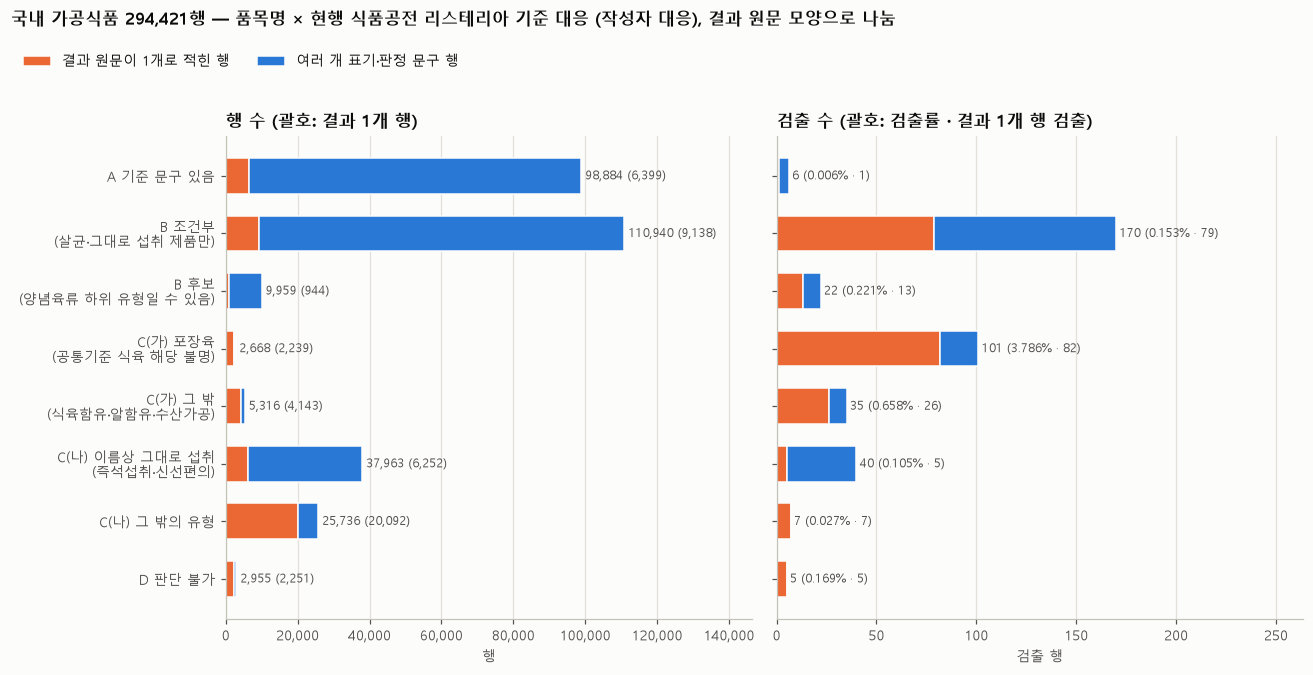

In [116]:
# [9-3-d] 그림 — 식품공전 대응 구분별 행 수와 검출 수를 결과 원문 모양(결과 1개 / 그 밖)으로 나눠 쌓음 (대응·모양 분류 모두 작성자 임의)
# 기준규격외(Z)는 행 수가 커서 그림에서 빼고 표로만 봄
_LAB = {LAB9['A']: 'A 기준 문구 있음', LAB9['B']: 'B 조건부\n(살균·그대로 섭취 제품만)', LAB9['BC']: 'B 후보\n(양념육류 하위 유형일 수 있음)',
        LAB9['CM']: 'C(가) 포장육\n(공통기준 식육 해당 불명)', LAB9['CN']: 'C(가) 그 밖\n(식육함유·알함유·수산가공)',
        LAB9['CR']: 'C(나) 이름상 그대로 섭취\n(즉석섭취·신선편의)', LAB9['CO']: 'C(나) 그 밖의 유형', LAB9['D']: 'D 판단 불가',
        LAB9['DNA']: 'D 판단 불가\n(품목명 결측)'}
_t = SPEC_TBL[~SPEC_TBL.index.str.startswith('Z')]
_lab = [_LAB[c_] for c_ in _t.index]
_y = np.arange(len(_t))[::-1]
_n_all = _t['행'].to_numpy(dtype=float)
_k_all = _t['검출'].to_numpy(dtype=float)
_n_one = np.array([int((_sp['구분'].eq(c_) & _sp['rv3'].eq('결과 1개')).sum()) for c_ in _t.index], dtype=float)
_k_one = _t['결과 1개 행 검출'].to_numpy(dtype=float)
fig, axes = plt.subplots(1, 2, figsize=(12, 6.2), sharey=True)
for ax, tot, one, ttl, xl in [(axes[0], _n_all, _n_one, '행 수 (괄호: 결과 1개 행)', '행'), (axes[1], _k_all, _k_one, '검출 수 (괄호: 검출률 · 결과 1개 행 검출)', '검출 행')]:
    ax.barh(_y, one, height=0.62, color=C2, edgecolor='#fcfcfb', linewidth=1, label='결과 원문이 1개로 적힌 행')
    ax.barh(_y, tot - one, left=one, height=0.62, color=C1, edgecolor='#fcfcfb', linewidth=1, label='여러 개 표기·판정 문구 행')
    ax.set_yticks(_y)
    ax.set_yticklabels(_lab)
    ax.grid(axis='y', visible=False)
    ax.set_title(ttl)
    ax.set_xlabel(xl)
_vm0, _vm1 = _n_all.max(), _k_all.max()
for yi, n_, n1 in zip(_y, _n_all, _n_one):
    axes[0].text(n_ + _vm0 * 0.01, yi, f'{int(n_):,} ({int(n1):,})', va='center', ha='left', fontsize=8, color=INK2)
for yi, k_, k1, r_ in zip(_y, _k_all, _k_one, _t['검출률(%)']):
    axes[1].text(k_ + _vm1 * 0.01, yi, f'{int(k_):,} ({r_:.3f}% · {int(k1)})', va='center', ha='left', fontsize=8, color=INK2)
axes[0].set_xlim(0, _vm0 * 1.32)
axes[1].set_xlim(0, _vm1 * 1.55)
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:,.0f}'))
_h, _l = axes[0].get_legend_handles_labels()
fig.legend(_h, _l, loc='upper left', bbox_to_anchor=(0.01, 0.935), ncol=2, fontsize=9)
fig.suptitle(f'국내 가공식품 {u9_N2:,}행 — 품목명 × 현행 식품공전 리스테리아 기준 대응 (작성자 대응), 결과 원문 모양으로 나눔', x=0.01, ha='left', fontsize=11, fontweight='bold')
plt.tight_layout(rect=(0, 0, 1, 0.9))
plt.show()

# 큰 중간 표 정리 (뒤 파트용 REQ_KEY·SMP_SEQ·RV_SHAPE·RV_SHAPE3·STD_GROUP·SPEC_MAP·SPEC_CLASS·SPEC_TBL·UNIT_TBL·NOHEAT_MEAT_TMP 는 남김)
del u9_p, u9_tmp, u9_w, u9_rs, u9_base, u9_G, u9_rvn, u9_key, u9_shape, u9_e, _sp, _sp2, _gi, _ll

📊 **결과**
- 판정 값: 불검출 674,568 · 검출 1,969. DB `judge_result_db` 와 엇갈리는 행은 0 입니다.
- 검사항목 이름 4가지 (행 / 검출, 검출률):
  - '리스테리아모노사이토제네스' 660,130 / 1,930 (0.292%) — 모든 대분류
  - '리스테리아 모노사이토제네스' 15,798 / 22 (0.139%) — 가공식품에만 있음. 5조각 키 5,378 · 4조각 10,420
  - '리스테리아 모노싸이토제네스' 605 / 17 (2.810%) — 축산물(원물)에만 있음
  - '리스테리아 모노사이토제네스(자연치즈)' 4 / 0
- 결과 원문이 수치인 행 비율: 가공식품 1.12%(3,718행), 수산물(원물) 0.40%(34), 축산물(원물) 0.06%(1), 기준규격외 0.01%(22), 농산물·기타 0. 수치 행의 검출은 모든 대분류에서 0 입니다.
- 학습용 `judge_stdr` 값 있는 7,273행(검출 10): 해외 가공식품 6,473(9) · 해외 수산물(원물) 730(1) · 국내 가공식품 64(0) · 해외 축산물 4 · 해외 기타 2.
  - 그중 7,203행이 5조각 키 행(5조각 행 전부)이고, 이 행들은 DB `stndrd_value` 가 비어 있습니다.
  - 나머지 70행은 judge_stdr 가 '100'(DB 기준값 'n=5, c=0, m=0' 52행 · 'n=5, c=0, m=0/25g' 10행)·'20'(DB '적합' 3행) 같은 값이라, 공백을 지워 비교해도 DB 기준값과 같은 행은 0 입니다.
- DB 판정 기준값 묶음(작성자 임의) (행 / 검출):
  - n=5·c=0 계열 293,704 / 267 — 가공식품 286,444 / 225, 수산물(원물) 6,770 / 40
  - 기준없음 계열 355,208 / 1,660 — 기준규격외 319,454 / 1,430, 가공식품 31,571 / 202, 농산물 2,069 / 15, 축산물 916 / 12
  - 음성 16,759 / 19 — 기타 9,136 / 0, 가공식품 6,613 / 4, 축산물 414 / 11
  - (결측) 9,184 / 14, 기타 1,574 / 9 ('-' 1,466행 등)
- 기준구분(IM14): '고시/허가' 행은 n=5·c=0 계열 279,646, '수동' 행은 기준없음 계열 348,563 이 대부분입니다.
- 판정형식(공통코드 IM15 이름 그대로: 01 최대/최소 · 02 적/부텍스트 · 03 3군법 · 04 2군법 · 05 기준없음): '04 2군법' ↔ n=5·c=0 계열 288,909, '05 기준없음' ↔ 기준없음 계열 354,936, '02 적/부텍스트' ↔ 음성 16,519. 두 코드의 결측 7,203행은 5조각 키 행 수와 같습니다.
- 식품공전 대응(작성자 대응) — 국내 가공식품 294,421행 / 검출 386 (품목명 결측 0행). C 는 '유형 규격에 리스테리아 문구 없음'이고, 제2 공통기준(식육(제조·가공용 원료 제외), 살균·멸균했거나 그대로 섭취하는 가공식품)의 적용 여부는 이 표로 알 수 없습니다. 마지막 열의 '결과 1개' 는 9-1-e 결과 원문 모양입니다.

| 구분 | 품목명 수 | 행 (국내 가공식품 안 %) | 검출 (검출 중 %) | 검출률 % (95% 신뢰구간) | DB n=5·c=0 / 기준없음 (%) | DB 기준없음 행의 검출 | 결과 1개 행 % / 그 행의 검출 |
|---|---|---|---|---|---|---|---|
| A 기준 문구 있음 | 77 | 98,884 (33.6) | 6 (1.6) | 0.006 (0.003\~0.013) | 97.8 / 1.9 | 2 | 6.5 / 1 |
| B 조건부(살균·그대로 섭취 제품에 한함) | 29 | 110,940 (37.7) | 170 (44.0) | 0.153 (0.132\~0.178) | 97.6 / 2.0 | 70 | 8.2 / 79 |
| B 후보(양념육류 하위 유형일 수 있음) | 2 | 9,959 (3.4) | 22 (5.7) | 0.221 (0.146\~0.334) | 94.3 / 5.3 | 11 | 9.5 / 13 |
| C(가) 포장육 — 공통기준 식육 해당 여부 불명 | 1 | 2,668 (0.9) | 101 (26.2) | 3.786 (3.125\~4.579) | 14.5 / 75.4 | 79 | 83.9 / 82 |
| C(가) 그 밖 — 식육함유·알함유·수산가공식품류 | 22 | 5,316 (1.8) | 35 (9.1) | 0.658 (0.474\~0.914) | 20.7 / 63.5 | 24 | 77.9 / 26 |
| C(나) 이름상 그대로 섭취 — 공통기준 대상일 수 있음 | 2 | 37,963 (12.9) | 40 (10.4) | 0.105 (0.077\~0.143) | 85.1 / 4.9 | 4 | 16.5 / 5 |
| C(나) 그 밖의 유형(목록 밖 이름) | 191 | 25,736 (8.7) | 7 (1.8) | 0.027 (0.013\~0.056) | 20.6 / 68.0 | 7 | 78.1 / 7 |
| D 판단 불가 | 7 | 2,955 (1.0) | 5 (1.3) | 0.169 (0.072\~0.396) | 23.3 / 72.4 | 5 | 76.2 / 5 |
| (별도) 국내 기준규격외(Z) — 규격 없음 | 6 | 320,536 | 1,431 | 0.446 (0.424\~0.470) | 0.0 / 99.7 | 1,430 | 98.9 / 1,409 |

- 변형(B 후보를 B 에 합침): 120,899행 / 검출 192 (0.159%, 95% 신뢰구간 0.138\~0.183), DB n=5·c=0 계열 97.3%, 결과 1개 행 검출 92.
- 품목명별 (행 / 검출, 검출률, DB n=5·c=0 %, DB 기준없음 %, 결과 1개 행 검출): 포장육 2,668 / 101 (3.786%, 14.5%, 75.4%, 82) · 양념육 21,956 / 87 (0.396%, 96.1%, 3.7%, 63) · 즉석섭취식품 37,337 / 40 (0.107%, 85.2%, 4.8%, 5) · 햄 15,631 / 27 (0.173%, 97.7%, 1.8%, 2) · 기타 수산물가공품 2,932 / 27 (0.921%, 21.1%, 70.7%, 18) · 분쇄가공육제품 7,853 / 19 (0.242%, 93.4%, 6.2%, 13) · 갈비가공품 2,106 / 3 (0.142%, 97.9%, 2.1%, 0).
- 신선편의식품은 626행 / 검출 0 (DB n=5·c=0 73.8%). C(나) 그 밖에서 검출이 있는 품목명은 즉석조리식품 5 · 액상차 1 · 만두류 1 입니다. A 에서 검출이 있는 품목명은 유가공품류 8,514 / 2, 가공치즈 7,518 / 2 등입니다.

💬 **첨언**
- 판정 값·검사항목 이름 차이는 '검출'의 뜻 차이라기보다 들어온 경로의 표기 차이로 보입니다 (추정). 띄어 쓴 이름은 가공식품(5조각 수입 경로 포함)에만, '모노싸이토제네스'는 축산물(원물)에만 있습니다. 이 표기를 입력 변수로 쓰면 경로를 대신 알려 주는 변수가 될 수 있어 보입니다 (추정).
- DB 기준값으로 보면 검출 1,969행 중 1,660행이 '기준없음 계열' 행입니다(기준없음 계열 355,208행 중 354,936행이 판정형식 '05 기준없음'). 기준규격외(1,430)뿐 아니라 가공식품에서도 202행입니다. 이 행들의 '검출'은 규격 위반(부적합) 판정이 아니라 '균이 나왔다'는 결과일 수 있어 보입니다 (추정, 담당자 확인 필요).
- 식품공전 리스테리아 기준은 유형 규격뿐 아니라 제2 공통기준(식육, 살균·멸균했거나 그대로 섭취하는 가공식품 — '식품의 특성에 따라')으로도 붙습니다(13-3절). 그래서 C '유형 규격에 문구 없음'을 '기준 없음'으로 읽으면 한쪽으로 기울 수 있어 보입니다 (추정).
  - C(나) 이름상 그대로 섭취 유형(즉석섭취식품·신선편의식품)은 DB 기준값 n=5·c=0 계열이 85.1% 라, 공통기준으로 판정한 행이 많을 수 있어 보입니다 (추정). C(나) 그 밖의 유형도 20.6% 가 n=5·c=0 계열입니다.
  - 포장육은 DB 기준없음이 75.4% 라 작성자 대응(유형 규격에 문구 없음)과 같은 방향이지만, 공통기준 '식육'에 드는지는 13-3절에서도 불명이었습니다.
- 기준 문구가 분명한 A(유가공품·아이스크림·조제유)는 국내 가공식품 행의 33.6% 인데 검출이 6 입니다. 검출은 B(170)·포장육(101)·즉석섭취식품(40)에 많습니다. 이 유형들은 조건부 조항(살균·그대로 섭취 제품만)이나 공통기준의 적용 여부에 따라 부적합 판정 대상이 될 수도, 아닐 수도 있습니다. 그래서 품목명만으로는 '부적합을 라벨로 잡으면 빠지는 검출'의 크기를 가늠하기 어려워 보입니다 (추정). B(DB n=5·c=0 계열 97.6%)와 즉석섭취식품(85.2%)은 규격으로 판정한 행이 많아 보이고, 포장육(기준없음 75.4%)·C(가) 그 밖(63.5%)은 기준없음 행이 많습니다 (추정).
- 9-1-e 와 겹쳐 보면 포장육(결과 1개 행 83.9%, 그 행의 검출 82)·C(가) 그 밖(77.9%, 26)·양념육(결과 1개 행 검출 63)의 검출이 '결과 1개' 행에 몰려 있습니다. 검출이 많은 칸이 식품유형 차이 때문인지, 검사 방식(결과 1개·검사목적 기타·기준없음) 차이 때문인지는 이 표만으로 나누기 어려워 보입니다 (추정).
- B 후보(분쇄가공육제품·갈비가공품)는 DB n=5·c=0 계열이 94.3% 로 B(97.6%)와 비슷한 모양입니다. B 에 합쳐도 검출률은 0.153% → 0.159% 로 비슷합니다.
- 품목명 대응은 작성자가 이름으로 맞춘 것이라 틀릴 수 있습니다. 행마다 적용 기준을 보려면 DB `stndrd_value`·`stdr_se_code`·`jdgmnt_fom_code` 가 더 직접적인 근거로 보이나, 코드 뜻과 기록 시점을 담당자께 여쭌 뒤에 쓸 수 있어 보입니다. 기준값이 결과를 적을 때 함께 적는 값이라면, 입력 변수로 쓸 때 누수가 될 수 있습니다 (추정).
- 결과 원문이 수치인 행(가공식품 3,718행)은 모두 불검출이라, 수치 표기 행이 판정을 다르게 담는 경우는 이 데이터에서 보이지 않습니다.

❓ **도메인 전문가께**:
- 예측 대상(라벨)을 '검출(균이 나옴)'과 '부적합(규격 위반)' 중 무엇으로 두어야 합니까? 두 라벨이 크게 달라질 수 있는 곳: DB 기준값 '기준없음 계열' 행의 검출 1,660(기준규격외 1,430, 가공식품 202).
- 포장육(17-9, 2,668행 / 검출 101)은 제2 공통기준의 '식육(제조·가공용 원료는 제외)'에 듭니까? 즉석섭취식품(37,337 / 40)·양념육(21,956 / 87 — 가열해 먹는 제품이 섞였을 수 있음)의 검출은 부적합 판정입니까?
- 식품공전 유형 규격에 리스테리아 문구가 없는 유형의 검출(포장육 101, 식육함유·알함유·수산가공식품류 35)을, 유형 규격에 기준 문구가 있는 유형의 검출과 같은 라벨로 묶어도 됩니까?
- 기준규격외 검체(검출 1,431, DB 기준값 기준없음 99.7%)의 '검출'은 제품 위험보다 공정·환경 위생 신호로 보고 따로 다뤄야 합니까?
- 작성자가 'B 후보'로 둔 분쇄가공육제품(7,853 / 19)·갈비가공품(2,106 / 3)은 양념육류(17-5) 하위 유형이 맞습니까? 'D 판단 불가'로 둔 품목명(기타가공품·기타식육 또는 기타알·기타제조가공식품류(자가규격)·원료성식품·간편조리세트·유음료·환원유)의 현행 식품유형은 무엇입니까? 코드의 대응 목록(SPEC_A·SPEC_B·SPEC_B_CAND·SPEC_C_MEAT·SPEC_C_NAMED·SPEC_C_RTE·SPEC_D)에 틀린 곳이 있으면 알려 주십시오.

🗄️ **데이터 담당자께**:
- `stndrd_value` 가 '기준없음'(기준구분 '수동', 판정형식 '05 기준없음')인 행의 '검출'도 규격 행과 같은 시험법(25g 정성)·같은 판정 절차입니까? 부적합 처리 여부를 따로 적는 컬럼이 있습니까?
- 판정형식(IM15)과 기준구분(IM14 '고시/허가'·'수동')은 누가 어떤 근거로 고릅니까? 행마다 적용한 식품공전 조항·식품유형을 알 수 있는 컬럼이 있습니까?
- `stndrd_value`·`stdr_se_code`·`jdgmnt_fom_code` 는 검사 전(의뢰·접수 때)에 정해지는 값입니까, 결과를 적을 때 함께 적는 값입니까? (입력 변수로 써도 되는지 판단용)
- 학습용 `judge_stdr` 는 왜 5조각 키(원본 LIMS 없음) 7,203행과 그 밖의 70행에만 있습니까? 70행의 '100'·'20'·'1000' 은 리스테리아가 아닌 다른 기준 값입니까? (2절: '음성'·'불검출' 641행 기록)
- 검사항목 이름 변형 4가지(띄어쓰기·'싸'·'(자연치즈)')는 같은 시험항목입니까?

---
## 10. 추적 검사와 검사기관 — 검출이 몰리는 이유가 검사 방식인가

🔎 검출이 특정 업체·주소·달에 몰리는 모양이 **날씨·원료 때문**이 아니라 **검사 방식 때문**일 수 있는지 봅니다.
- 같은 곳 몰림: 검출 결과를 본 뒤 같은 곳을 다시 검사하거나(재의뢰), 결과가 나오기 전부터 같은 곳을 이어서 검사하면, 그곳의 행과 검출이 짧은 기간에 몰립니다 (10-1).
- 검사기관: 기관마다 맡는 업체·지역·검사 사업·시험 방식이 다르면, 기관 구성만 바뀌어도 달별 검출률이 달라질 수 있습니다 (10-2, 10-3).
- 이 절은 **계산만** 합니다. 추적 검사를 표시하는 컬럼은 이 데이터에서 찾지 못했습니다. 그래서 의뢰일·검사완료일 간격으로 "추적 검사로 보이는" 행을 작성자가 임의로 골랐습니다.

### 10-1. 같은 곳 검출 뒤의 몰림 — 결과를 본 뒤 재의뢰로 보이는 몫과 결과 전 연속 의뢰로 보이는 몫

🔎 어떤 검출 뒤 짧은 기간에 같은 곳의 의뢰가 늘고 검출률도 높으면, 추적(재)검사가 섞였을 수 있습니다. 다만 결과가 나오기까지 며칠이 걸리므로, **앞선 결과를 알기 전에 의뢰된 행**은 추적 검사라기보다 같은 곳을 이어서 검사한 것일 수 있습니다. 둘을 나눠 봅니다.

**방법 (모두 작성자 임의 방법)**
- 날짜 = 의뢰일(`reqest_de`). 범위 = 학습용 데이터 전체 676,537행. 국내 가공식품·국내 기준규격외(검체)는 따로 냅니다.
- 키(같은 곳) 두 가지:
  - **업체키**: 1-2 ⑥ 업체 식별 규칙 — 영업허가번호 → 없으면 제조회사명 → 둘 다 없으면 '키 없음'(계산에서 빼고 수를 적음)
  - **주소 키**: 주소 문자열 `addr` 그대로(앞뒤 공백만 뗌). 같은 주소에 여러 업체가 있거나, 한 업체가 여러 주소로 적혔으면 구분하지 못합니다.
- 각 행에 대해 **같은 키에서 의뢰일이 더 이른 가장 최근 검출**까지의 날짜 차를 구합니다. 같은 날의 검출은 "앞선 검출"로 보지 않습니다(같은 의뢰일 가능성).
- 행 구분: 검출 뒤 1\~30일 / 31\~90일 / 91일 이상 / 앞선 검출 없음(그 키의 첫 검출일 이전·당일 행) / 검출 이력 없는 키 / 키 없음
  - '검출 이력 없는 키'의 검출률은 **정의상 0** 입니다(검출이 한 번도 없는 키만 모음). 결과로 읽지 않습니다.
  - '검출 뒤 1\~30일'은 검출 이력이 있는 키만 모은 구분이라, 같은 조건인 **'검출 뒤 91일 이상'과만** 비교합니다.
- **결과 시차**: `nb2_db_attr.parquet` 의 `inspct_compt_de`(컬럼 이름으로 보아 검사완료일로 추정. 업체·기관이 결과를 안 날과 같은지는 모름)를 필요한 열만 읽어 씁니다. 결측은 채우지 않고 수를 적습니다.
  - 의뢰일 기준 '검출 뒤 1\~30일' 행을 **의뢰 시점에 알 수 있었던 앞선 결과**로 셋으로 나눕니다.
    - ① **앞선 결과 모름**: 같은 키 검출 중 검사완료일이 이 행 의뢰일보다 1\~30일 이른 것이 없음
    - ② **일부 앎·직전 결과 전**: 그런 검출은 있으나, 가장 최근 앞선 검출(같은 날 여러 건이면 가장 이른 완료일)의 완료일이 이 행 의뢰일과 같거나 뒤
    - ③ **직전 결과 앎**: 가장 최근 앞선 검출의 완료일 다음 날 이후에 의뢰
  - **검사완료일 기준 1\~30일**: 같은 키에서 검사완료일이 이 행 의뢰일보다 1\~30일 이른 검출이 있는 행입니다(의뢰일 기준 31일 이상 행도 들어갈 수 있음). 완료일이 없거나 의뢰일보다 이른 검출은 이 기준의 '앞선 검출'에서 빼고 수를 적습니다.

**비교할 변형 목록 (결과보다 먼저 적음)**
1. 행 구분별 행 수·검출률 × 키 2개 (업체키, 주소 키) — 전체 행, 국내 가공식품
2. '검출 뒤 1\~30일' 나누기 × 키 2개 × 범위 3개 (전체, 국내 가공식품, 국내 기준규격외(검체)): (a) 의뢰일 기준 1\~7일 / 8\~30일, (b) ①·②·③, (c) 검사완료일 기준 1\~30일. 같은 범위의 검출 행만 보면 30일 안 재검출이 ①·②·③ 에 어떻게 나뉘는지
3. 검출 사건(키 × 검출일) 단위: 검출 **앞** 1\~30일 / 당일 / **뒤** 1\~30일 / 뒤 31\~60일 / 뒤 61\~90일(당일 말고는 모두 30일 창)의 같은 키 행 수 × 키 2개 × 사건 범위 2가지 — (가) 자료 앞뒤 경계만 뺀 사건, (나) 그 키의 첫 행 ≤ 사건일−30일 이고 마지막 행 ≥ 사건일+90일인 사건. 비교 기준 = 같은 키의 창 밖 기간(키 첫 행\~마지막 행 가운데 사건일−30\~+90일 밖, 30일 이상일 때만) 30일당 행 수의 평균·중앙값
4. 검출 행 중 "같은 키의 앞선 검출 뒤 30일 안에 나온 검출" 비율 × 키 2개 × (대분류, 검사목적)
5. 참고: 행 구분별 검사목적 구성, 30일 안 재검출이 많은 키 상위 5곳

In [117]:
# [10-1] 같은 키(업체키 / 주소 문자열)에서 앞선 검출까지의 날짜 차(의뢰일 기준)와 행 구분 — 작성자 임의 방법
# - 업체키: 1-2 ⑥ 업체 식별 규칙(영업허가번호 → 제조회사명 → 없으면 키 없음). 빈 글자('')도 없는 것으로 봄. 값을 채우거나 추정하지 않음
# - 주소 키: addr 문자열(앞뒤 공백만 제거)
# - 날짜 차 = 이 행 의뢰일 − (같은 키, 의뢰일이 더 이른 검출 중 가장 최근 의뢰일). 같은 날 검출은 앞선 검출로 보지 않음
F10 = dfx[['pos', '대분류', '검사목적', '국내해외', 'reqest_de', 'addr', 'bsn_lcns_ledg_no', 'mnfctur_cmpny_nm']]   # 필요한 열만
print(f"의뢰일 없는 행: {int(F10['reqest_de'].isna().sum()):,} (있으면 계산에서 뺌)")
_lic = F10['bsn_lcns_ledg_no'].astype('string').str.strip()
_lic = _lic.mask(_lic.eq(''))
_cnm = F10['mnfctur_cmpny_nm'].astype('string').str.strip()
_cnm = _cnm.mask(_cnm.eq(''))
key_firm10 = ('허가:' + _lic).where(_lic.notna(), '회사명:' + _cnm)      # 둘 다 없으면 <NA> = 키 없음 (라벨만, 값 채움 아님)
_adr = F10['addr'].astype('string').str.strip()
key_addr10 = _adr.mask(_adr.eq(''))
key_firm10 = key_firm10.mask(F10['reqest_de'].isna())
key_addr10 = key_addr10.mask(F10['reqest_de'].isna())


def followup_gap(key, date, pos):
    '''같은 키에서 의뢰일이 더 이른 가장 최근 검출까지의 날짜 차(일). 앞선 검출이 없거나 키가 없으면 NaN(해당 없음 표시).
    구현: 검출 사건(키, 검출일)을 pd.merge_asof(by=키, direction=backward, allow_exact_matches=False)로 붙임'''
    ok = key.notna().to_numpy()
    t = pd.DataFrame({'k': key[ok].astype(str).to_numpy(), 'd': date[ok].to_numpy(), 'row': key.index[ok]})
    ev = t.loc[pos.to_numpy()[ok] == 1, ['k', 'd']].drop_duplicates().rename(columns={'d': 'd_ev'})
    m = pd.merge_asof(t.sort_values('d'), ev.sort_values('d_ev'), left_on='d', right_on='d_ev', by='k',
                      allow_exact_matches=False, direction='backward')
    gap = pd.Series((m['d'] - m['d_ev']).dt.days.to_numpy(dtype=float), index=m['row'].to_numpy()).reindex(key.index)
    return gap, set(ev['k'])


CLS_ORDER = ['검출 뒤 1~30일', '검출 뒤 31~90일', '검출 뒤 91일 이상', '앞선 검출 없음', '검출 이력 없는 키', '키 없음']


def classify(key, gap, pos_keys):
    has = key.astype(str).isin(pos_keys).to_numpy() & key.notna().to_numpy()
    lab = np.select([key.isna().to_numpy(), ~has, gap.isna().to_numpy(), gap.le(30).to_numpy(), gap.le(90).to_numpy()],
                    ['키 없음', '검출 이력 없는 키', '앞선 검출 없음', '검출 뒤 1~30일', '검출 뒤 31~90일'], '검출 뒤 91일 이상')
    return pd.Series(pd.Categorical(lab, categories=CLS_ORDER), index=key.index)


fu_gap_firm, _pk_firm = followup_gap(key_firm10, F10['reqest_de'], F10['pos'])
fu_gap_addr, _pk_addr = followup_gap(key_addr10, F10['reqest_de'], F10['pos'])
fu_class_firm = classify(key_firm10, fu_gap_firm, _pk_firm)
fu_class_addr = classify(key_addr10, fu_gap_addr, _pk_addr)
followup30_firm = fu_class_firm.eq('검출 뒤 1~30일')
followup30_addr = fu_class_addr.eq('검출 뒤 1~30일')

for nm_, key, pk in [('업체키', key_firm10, _pk_firm), ('주소 키', key_addr10, _pk_addr)]:
    miss = key.isna()
    print(f"{nm_}: 키 없음 {int(miss.sum()):,}행 (검출 {int(F10.loc[miss, 'pos'].sum()):,}) → 행 구분 '키 없음'으로 따로 셈 / "
          f"키 수 {key.nunique():,}, 검출 있는 키 {len(pk):,}, 검출 있는 키의 행 {int(key.astype(str).isin(pk).sum()):,}")


def cls_rate_table(cls, pos):
    g = pos.groupby(cls, observed=True).agg(['size', 'sum']).reindex(CLS_ORDER)
    g = g[g['size'].notna()]                  # 없는 구분(주소 키의 '키 없음')은 표에서 뺌
    rows = {c: (g.loc[c, 'size'], g.loc[c, 'sum']) for c in g.index}
    rest = [c for c in ['검출 뒤 91일 이상', '앞선 검출 없음'] if c in g.index]
    rows['(참고) 같은 키 나머지 기간 = 91일 이상 + 앞선 검출 없음'] = (g.loc[rest, 'size'].sum(), g.loc[rest, 'sum'].sum())
    keyed = [c for c in g.index if c != '키 없음']
    rows['(참고) 키 있는 행 전체'] = (g.loc[keyed, 'size'].sum(), g.loc[keyed, 'sum'].sum())
    rows['(참고) 모든 행'] = (g['size'].sum(), g['sum'].sum())
    n = np.array([v[0] for v in rows.values()], float)
    k = np.array([v[1] for v in rows.values()], float)
    lo, hi = wilson(k, n)
    return pd.DataFrame({'행 수': n.astype(int), '검출': k.astype(int), '검출률(%)': np.round(k / n * 100, 3),
                         '95% CI(%)': [f'{a:.3f}~{b:.3f}' for a, b in zip(lo, hi)]}, index=list(rows.keys()))


FU_WINDOW_TBL = pd.concat({'업체키': cls_rate_table(fu_class_firm, F10['pos']),
                           '주소 키': cls_rate_table(fu_class_addr, F10['pos'])}, names=['키', '행 구분'])
print('\n[전체 676,537행] 행 구분별 행 수·검출률')
print("('검출 이력 없는 키'의 검출률 0 은 정의상 0. '검출 뒤 1~30일'은 같은 조건(검출 이력 있는 키)인 '검출 뒤 91일 이상'과 비교함 — "
      "모든 행과의 배수는 결과를 보고 고른 조건이라 표에 넣지 않음)")
display(FU_WINDOW_TBL)

_g1 = F10['국내해외'].eq('국내') & F10['대분류'].eq('가공식품')
FU_WINDOW_TBL_G1 = pd.concat({'업체키': cls_rate_table(fu_class_firm[_g1], F10.loc[_g1, 'pos']),
                              '주소 키': cls_rate_table(fu_class_addr[_g1], F10.loc[_g1, 'pos'])}, names=['키', '행 구분'])
print(f"[국내 가공식품만 {int(_g1.sum()):,}행] 행 구분은 전체 자료의 키 이력으로 정함 (다른 대분류의 검출도 '앞선 검출'로 셈)")
FU_WINDOW_TBL_G1

의뢰일 없는 행: 0 (있으면 계산에서 뺌)
업체키: 키 없음 323,707행 (검출 1,424) → 행 구분 '키 없음'으로 따로 셈 / 키 수 20,931, 검출 있는 키 252, 검출 있는 키의 행 18,834
주소 키: 키 없음 0행 (검출 0) → 행 구분 '키 없음'으로 따로 셈 / 키 수 41,309, 검출 있는 키 722, 검출 있는 키의 행 66,011

[전체 676,537행] 행 구분별 행 수·검출률
('검출 이력 없는 키'의 검출률 0 은 정의상 0. '검출 뒤 1~30일'은 같은 조건(검출 이력 있는 키)인 '검출 뒤 91일 이상'과 비교함 — 모든 행과의 배수는 결과를 보고 고른 조건이라 표에 넣지 않음)


행 수    검출  검출률(%)     95% CI(%)
키    행 구분                                                                    
업체키  검출 뒤 1~30일                              1637   150   9.163  7.859~10.658
     검출 뒤 31~90일                             1461    49   3.354   2.546~4.406
     검출 뒤 91일 이상                             8872    59   0.665   0.516~0.857
     앞선 검출 없음                                6864   287   4.181   3.733~4.681
     검출 이력 없는 키                            333996     0   0.000   0.000~0.001
     키 없음                                  323707  1424   0.440   0.418~0.463
     (참고) 같은 키 나머지 기간 = 91일 이상 + 앞선 검출 없음   15736   346   2.199   1.981~2.440
     (참고) 키 있는 행 전체                        352830   545   0.154   0.142~0.168
     (참고) 모든 행                             676537  1969   0.291   0.278~0.304
주소 키 검출 뒤 1~30일                              7715   622   8.062   7.475~8.691
     검출 뒤 31~90일                             5508   134   2.433   2.058~2.874
     검출 뒤 91일 이상                            26971   284   1.053   0.938~1.182
     앞선 검출 없음                               25817   929   3.598   3.378~3.833
     검출 이력 없는 키                            610526     0   0.000   0.000~0.001
     (참고) 같은 키 나머지 기간 = 91일 이상 + 앞선 검출 없음   52788  1213   2.298   2.173~2.429
     (참고) 키 있는 행 전체                        676537  1969   0.291   0.278~0.304
     (참고) 모든 행                             676537  1969   0.291   0.278~0.304

[국내 가공식품만 294,421행] 행 구분은 전체 자료의 키 이력으로 정함 (다른 대분류의 검출도 '앞선 검출'로 셈)


행 수   검출  검출률(%)     95% CI(%)
키    행 구분                                                                   
업체키  검출 뒤 1~30일                               219   26  11.872  8.232~16.827
     검출 뒤 31~90일                              291   10   3.436   1.877~6.209
     검출 뒤 91일 이상                             5718   37   0.647   0.470~0.891
     앞선 검출 없음                                3830  185   4.830   4.195~5.556
     검출 이력 없는 키                            224203    0   0.000   0.000~0.002
     키 없음                                   60160  128   0.213   0.179~0.253
     (참고) 같은 키 나머지 기간 = 91일 이상 + 앞선 검출 없음    9548  222   2.325   2.041~2.647
     (참고) 키 있는 행 전체                        234261  258   0.110   0.097~0.124
     (참고) 모든 행                             294421  386   0.131   0.119~0.145
주소 키 검출 뒤 1~30일                               825   43   5.212   3.892~6.947
     검출 뒤 31~90일                              675   17   2.519   1.578~3.996
     검출 뒤 91일 이상                             7577   63   0.831   0.650~1.062
     앞선 검출 없음                                6528  263   4.029   3.578~4.533
     검출 이력 없는 키                            278816    0   0.000   0.000~0.001
     (참고) 같은 키 나머지 기간 = 91일 이상 + 앞선 검출 없음   14105  326   2.311   2.076~2.573
     (참고) 키 있는 행 전체                        294421  386   0.131   0.119~0.145
     (참고) 모든 행                             294421  386   0.131   0.119~0.145

In [118]:
# [10-1 계속] 결과(검사완료일) 시차로 '검출 뒤 1~30일' 행 나누기 — 작성자 임의 방법
# 검사완료일 = nb2_db_attr.parquet 의 inspct_compt_de (이름으로 보아 검사완료일로 추정; 결과를 안 날(통보일)과 같은지는 모름)
#   필요한 열만 읽어 lims_data_key 로 붙인 Series (dfx 에 넣지 않음). 결측은 채우지 않음
# (a) 의뢰일 기준 1~7일 / 8~30일
# (b) 의뢰일 기준 1~30일 행을 의뢰 시점에 알 수 있었던 앞선 결과로 셋으로 나눔
#     ① 앞선 결과 모름: 같은 키 검출 중 검사완료일이 이 행 의뢰일보다 1~30일 이른 것이 없음
#     ② 일부 앎·직전 결과 전: 그런 검출은 있으나, 가장 최근 앞선 검출(의뢰일 기준; 같은 날 여러 건이면 가장 이른 완료일)의 완료일 ≥ 이 행 의뢰일
#     ③ 직전 결과 앎: 가장 최근 앞선 검출의 완료일 < 이 행 의뢰일
# (c) 검사완료일 기준 1~30일: 같은 키에서 완료일이 이 행 의뢰일보다 1~30일 이른 검출이 있는 행 (의뢰일 기준 31일 이상 행도 들어갈 수 있음)
_att10 = pd.read_parquet(COL / 'nb2_db_attr.parquet', columns=['lims_data_key', 'inspct_compt_de'])
compt10 = dfx[['lims_data_key']].merge(_att10, on='lims_data_key', how='left', validate='one_to_one')['inspct_compt_de']
compt10.index = dfx.index
compt10 = pd.to_datetime(compt10).astype('datetime64[ms]')
del _att10
_req_ms = F10['reqest_de'].astype('datetime64[ms]')
_P = F10['pos'].eq(1)
_lag = (compt10 - _req_ms).dt.days
print(f"검사완료일 없는 행 {int(compt10.isna().sum()):,} (검출 행 중 {int(compt10[_P].isna().sum())}), "
      f"검사완료일이 의뢰일보다 이른 행 {int(_lag.lt(0).sum()):,} (검출 행 중 {int(_lag[_P].lt(0).sum())})")
for _nm, _s in [('검출 행', _lag[_P].dropna()), ('모든 행', _lag.dropna())]:
    _q = _s.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
    print(f"{_nm}의 의뢰일 → 검사완료일 간격(일; 완료일 있는 {len(_s):,}행) 분위: " + ', '.join(f'{int(round(k * 100))}% {v:.0f}' for k, v in _q.items())
          + f" / 7일 이하 {(_s <= 7).mean() * 100:.1f}%")


def followup_gap_compt(key, req, compt, pos):
    '''같은 키에서 검사완료일이 이 행 의뢰일보다 이른(같은 날 제외) 검출 중 가장 최근 완료일까지의 날짜 차(일). 없으면 NaN.
    검사완료일이 없거나 의뢰일보다 이른 검출은 사건에서 뺌'''
    ok = key.notna().to_numpy()
    t = pd.DataFrame({'k': key[ok].astype(str).to_numpy(), 'd': req[ok].to_numpy(), 'row': key.index[ok]})
    evm = ok & (pos.to_numpy() == 1) & compt.notna().to_numpy() & (compt >= req).to_numpy()
    n_bad = int((ok & (pos.to_numpy() == 1)).sum() - evm.sum())
    ev = pd.DataFrame({'k': key[evm].astype(str).to_numpy(), 'c_ev': compt[evm].to_numpy()}).drop_duplicates()
    m = pd.merge_asof(t.sort_values('d'), ev.sort_values('c_ev'), left_on='d', right_on='c_ev', by='k',
                      allow_exact_matches=False, direction='backward')
    gap = pd.Series((m['d'] - m['c_ev']).dt.days.to_numpy(dtype=float), index=m['row'].to_numpy()).reindex(key.index)
    return gap, n_bad


def prev_detect_compt(key, req, compt, pos):
    '''같은 키에서 의뢰일이 더 이른 가장 최근 검출일의 검사완료일(그날 검출이 여러 건이면 가장 이른 완료일). 없으면 NaT'''
    ok = key.notna().to_numpy()
    t = pd.DataFrame({'k': key[ok].astype(str).to_numpy(), 'd': req[ok].to_numpy(), 'row': key.index[ok]})
    pm = ok & (pos.to_numpy() == 1)
    ev = (pd.DataFrame({'k': key[pm].astype(str).to_numpy(), 'd_ev': req[pm].to_numpy(), 'c_ev': compt[pm].to_numpy()})
          .groupby(['k', 'd_ev'], as_index=False)['c_ev'].min())
    m = pd.merge_asof(t.sort_values('d'), ev.sort_values('d_ev'), left_on='d', right_on='d_ev', by='k',
                      allow_exact_matches=False, direction='backward')
    return pd.Series(m['c_ev'].to_numpy(), index=m['row'].to_numpy()).reindex(key.index)


fu_gap_compt_firm, _nb_f = followup_gap_compt(key_firm10, _req_ms, compt10, F10['pos'])
fu_gap_compt_addr, _nb_a = followup_gap_compt(key_addr10, _req_ms, compt10, F10['pos'])
print(f"검사완료일 기준에서 사건으로 쓰지 못한 검출 행(키는 있으나 완료일 없음·의뢰일보다 이름): 업체키 {_nb_f}, 주소 키 {_nb_a}")
followup30c_firm = fu_gap_compt_firm.between(1, 30)
followup30c_addr = fu_gap_compt_addr.between(1, 30)
_prevc_firm = prev_detect_compt(key_firm10, _req_ms, compt10, F10['pos'])
_prevc_addr = prev_detect_compt(key_addr10, _req_ms, compt10, F10['pos'])

TIMING_ORDER = ['① 앞선 결과 모름', '② 일부 앎·직전 결과 전', '③ 직전 결과 앎']


def timing_class(cls, gapc, prev_c):
    fu = cls.eq('검출 뒤 1~30일').to_numpy()
    known = gapc.between(1, 30).to_numpy()
    after = (_req_ms > prev_c).to_numpy()          # 직전 검출 완료일이 없으면(NaT) 비교 결과 False
    lab = np.select([~fu, ~known, after], ['', TIMING_ORDER[0], TIMING_ORDER[2]], TIMING_ORDER[1])
    out = pd.Series(pd.Categorical(lab, categories=TIMING_ORDER), index=cls.index)    # '' = 해당 없음(1~30일 행 아님) → 범주 밖
    return out, int((fu & after & ~known).sum()), int((fu & prev_c.isna().to_numpy()).sum())


fu_timing_firm, _bad_f, _nat_f = timing_class(fu_class_firm, fu_gap_compt_firm, _prevc_firm)
fu_timing_addr, _bad_a, _nat_a = timing_class(fu_class_addr, fu_gap_compt_addr, _prevc_addr)
print(f"확인: ③ 인데 30일 안 결과가 없는 행 업체키 {_bad_f}·주소 키 {_bad_a} (정의상 0 이어야 함) / "
      f"직전 검출의 완료일이 없어 ③ 이 될 수 없는 1~30일 행 업체키 {_nat_f}·주소 키 {_nat_a} (①·② 로 들어감)")

_z1 = F10['국내해외'].eq('국내') & F10['대분류'].eq('기준규격외(검체)')
SCOPES10 = [('전체', pd.Series(True, index=F10.index)), ('국내 가공식품', _g1), ('국내 기준규격외(검체)', _z1)]
KEYSETS10 = [('업체키', fu_gap_firm, fu_gap_compt_firm, fu_class_firm, fu_timing_firm),
             ('주소 키', fu_gap_addr, fu_gap_compt_addr, fu_class_addr, fu_timing_addr)]


def split_rows(gap, gapc, cls, tim):
    fu = cls.eq('검출 뒤 1~30일')
    return {
        '(a) 의뢰일 기준 1~7일': fu & gap.le(7),
        '(a) 의뢰일 기준 8~30일': fu & gap.gt(7),
        '(b) ① 앞선 결과 모름': tim.eq(TIMING_ORDER[0]),
        '(b) ② 일부 앎·직전 결과 전': tim.eq(TIMING_ORDER[1]),
        '(b) ③ 직전 결과 앎': tim.eq(TIMING_ORDER[2]),
        '(c) 검사완료일 기준 1~30일': gapc.between(1, 30),
        '(참고) 의뢰일 기준 1~30일 전체': fu,
        '(비교) 의뢰일 기준 91일 이상': cls.eq('검출 뒤 91일 이상'),
    }


_parts10, _rd = {}, {}
for s_nm, msk in SCOPES10:
    for k_nm, gp, gpc, cl, tm in KEYSETS10:
        rows = split_rows(gp, gpc, cl, tm)
        n = np.array([int((m_ & msk).sum()) for m_ in rows.values()], float)
        k = np.array([int(F10['pos'][m_ & msk].sum()) for m_ in rows.values()], float)
        lo, hi = wilson(k, n)
        _parts10[(s_nm, k_nm)] = pd.DataFrame({'행 수': n.astype(int), '검출': k.astype(int), '검출률(%)': np.round(k / n * 100, 3),
                                               '95% CI(%)': [f'{a:.3f}~{b:.3f}' for a, b in zip(lo, hi)]}, index=list(rows.keys()))
        r30 = cl.eq('검출 뒤 1~30일') & _P & msk                     # 검출 행 중 30일 안 재검출
        n30 = int(r30.sum())
        c3 = [int((r30 & tm.eq(t_)).sum()) for t_ in TIMING_ORDER]
        _rd[(s_nm, k_nm)] = {'30일 안 재검출': n30, '그중 의뢰일 7일 안': int((r30 & gp.le(7)).sum()),
                             TIMING_ORDER[0]: c3[0], TIMING_ORDER[1]: c3[1], TIMING_ORDER[2]: c3[2],
                             '①+② 직전 결과 전(%)': round((c3[0] + c3[1]) / n30 * 100, 1) if n30 else np.nan,
                             '① 앞선 결과 모름(%)': round(c3[0] / n30 * 100, 1) if n30 else np.nan}
FU_SPLIT_TBL = pd.concat(_parts10, names=['범위', '키', '구분'])
_wide10 = pd.DataFrame({sk: [f"{k:,}/{n:,} ({r:.3f}%)" if n else '0/0' for k, n, r in zip(t['검출'], t['행 수'], t['검출률(%)'])]
                        for sk, t in _parts10.items()}, index=list(next(iter(_parts10.values())).index))
_wide10.columns = pd.MultiIndex.from_tuples(_wide10.columns, names=['범위', '키'])
print("\n['검출 뒤 1~30일' 나누기] 칸 = 검출/행 수 (검출률) — 95% CI 는 FU_SPLIT_TBL 변수에 있음")
display(_wide10)
RD30_TIMING = pd.DataFrame.from_dict(_rd, orient='index')
RD30_TIMING.index.names = ['범위', '키']
print('[검출 행만] 30일 안 재검출이 의뢰 시점의 앞선 결과로 어떻게 나뉘나 (①+②+③ = 30일 안 재검출)')
RD30_TIMING

검사완료일 없는 행 7,203 (검출 행 중 10), 검사완료일이 의뢰일보다 이른 행 20 (검출 행 중 0)
검출 행의 의뢰일 → 검사완료일 간격(일; 완료일 있는 1,959행) 분위: 5% 8, 25% 10, 50% 12, 75% 13, 95% 18 / 7일 이하 4.4%
모든 행의 의뢰일 → 검사완료일 간격(일; 완료일 있는 669,334행) 분위: 5% 6, 25% 7, 50% 9, 75% 13, 95% 20 / 7일 이하 27.7%
검사완료일 기준에서 사건으로 쓰지 못한 검출 행(키는 있으나 완료일 없음·의뢰일보다 이름): 업체키 10, 주소 키 10
확인: ③ 인데 30일 안 결과가 없는 행 업체키 0·주소 키 0 (정의상 0 이어야 함) / 직전 검출의 완료일이 없어 ③ 이 될 수 없는 1~30일 행 업체키 7·주소 키 4 (①·② 로 들어감)

['검출 뒤 1~30일' 나누기] 칸 = 검출/행 수 (검출률) — 95% CI 는 FU_SPLIT_TBL 변수에 있음


범위                                    전체                                 국내 가공식품                           국내 기준규격외(검체)                     
키                                    업체키                 주소 키                업체키               주소 키                 업체키                 주소 키
(a) 의뢰일 기준 1~7일         82/552 (14.855%)  313/2,480 (12.621%)     7/44 (15.909%)    11/231 (4.762%)    70/477 (14.675%)  291/2,088 (13.937%)
(a) 의뢰일 기준 8~30일       68/1,085 (6.267%)   309/5,235 (5.903%)   19/175 (10.857%)    32/594 (5.387%)     45/859 (5.239%)   267/4,214 (6.336%)
(b) ① 앞선 결과 모름           22/355 (6.197%)   111/1,701 (6.526%)      2/70 (2.857%)     5/291 (1.718%)     13/249 (5.221%)    93/1,269 (7.329%)
(b) ② 일부 앎·직전 결과 전      68/408 (16.667%)  263/1,832 (14.356%)      1/5 (20.000%)      2/44 (4.545%)    67/400 (16.750%)  260/1,737 (14.968%)
(b) ③ 직전 결과 앎            60/874 (6.865%)   248/4,182 (5.930%)   23/144 (15.972%)    36/490 (7.347%)     35/687 (5.095%)   205/3,296 (6.220%)
(c) 검사완료일 기준 1~30일    132/1,592 (8.291%)   530/7,324 (7.236%)   28/235 (11.915%)    43/730 (5.890%)  102/1,297 (7.864%)   479/6,021 (7.955%)
(참고) 의뢰일 기준 1~30일 전체  150/1,637 (9.163%)   622/7,715 (8.062%)   26/219 (11.872%)    43/825 (5.212%)  115/1,336 (8.608%)   558/6,302 (8.854%)
(비교) 의뢰일 기준 91일 이상     59/8,872 (0.665%)  284/26,971 (1.053%)  37/5,718 (0.647%)  63/7,577 (0.831%)   18/2,948 (0.611%)  197/18,076 (1.090%)

[검출 행만] 30일 안 재검출이 의뢰 시점의 앞선 결과로 어떻게 나뉘나 (①+②+③ = 30일 안 재검출)


30일 안 재검출  그중 의뢰일 7일 안  ① 앞선 결과 모름  ② 일부 앎·직전 결과 전  ③ 직전 결과 앎  ①+② 직전 결과 전(%)  ① 앞선 결과 모름(%)
범위           키                                                                                                 
전체           업체키         150           82          22              68         60            60.0           14.7
             주소 키        622          313         111             263        248            60.1           17.8
국내 가공식품      업체키          26            7           2               1         23            11.5            7.7
             주소 키         43           11           5               2         36            16.3           11.6
국내 기준규격외(검체) 업체키         115           70          13              67         35            69.6           11.3
             주소 키        558          291          93             260        205            63.3           16.7

In [119]:
# [10-1 계속] 검출 사건(키 × 검출 의뢰일) 단위: 검출 앞뒤 30일 창의 같은 키 행 수와 재검출 — 작성자 임의 방법
# - 같은 날 여러 검출은 사건 1개. 창: 앞 1~30일 / 당일 / 뒤 1~30일 / 뒤 31~60일 / 뒤 61~90일 (당일 말고는 모두 30일 창이라 서로 견줄 수 있음)
# - 사건 범위 (가): 자료 앞뒤 경계에서 창이 잘리는 사건(첫 의뢰일+30일 전, 마지막 의뢰일−90일 뒤)만 빼고 수를 적음
# - 사건 범위 (나): (가) 중 그 키의 첫 행 의뢰일 ≤ 사건일−30 이고 마지막 행 의뢰일 ≥ 사건일+90 인 사건만
#   (키가 자료에 처음 나온 직후·마지막으로 나오기 직전의 검출은 창에 행이 구조적으로 적음. 키의 첫·마지막 행은 결과 전체를 보고 정한 것이라 참고용)
# - 비교 기준: 같은 키의 창 밖 기간 30일당 행 수 = (키 전체 행 − 사건일−30~+90일 안 행) ÷ (키 첫 행~마지막 행 날수 − 그 안에 든 창 날수) × 30
#   창 밖 기간이 30일 미만인 사건은 이 기준에서 빼고 수를 적음 (작성자 임의)
# - 구현: 키 번호×100000 + 날짜(일 수)로 정렬한 배열에서 searchsorted 로 창 안 행 수를 셈 (행×일 폭발 조인 없음)
LO_D = int(F10['reqest_de'].min().to_datetime64().astype('datetime64[D]').astype(np.int64))
HI_D = int(F10['reqest_de'].max().to_datetime64().astype('datetime64[D]').astype(np.int64))
print(f"의뢰일 범위 {F10['reqest_de'].min():%Y-%m-%d} ~ {F10['reqest_de'].max():%Y-%m-%d}")
WIN10 = {'앞 1~30일': (-30, -1), '당일': (0, 0), '뒤 1~30일': (1, 30), '뒤 31~60일': (31, 60), '뒤 61~90일': (61, 90)}


def event_windows(key, date, pos):
    ok = key.notna().to_numpy()
    codes, uniq = pd.factorize(key[ok].astype(str).to_numpy())
    day = date[ok].to_numpy().astype('datetime64[D]').astype(np.int64)
    comp = codes.astype(np.int64) * 100000 + day
    first_d = np.full(len(uniq), np.iinfo(np.int64).max)
    last_d = np.full(len(uniq), np.iinfo(np.int64).min)
    np.minimum.at(first_d, codes, day)
    np.maximum.at(last_d, codes, day)
    n_key = np.bincount(codes, minlength=len(uniq))
    pmask = pos.to_numpy()[ok] == 1
    S_all, S_pos = np.sort(comp), np.sort(comp[pmask])
    ev = np.unique(comp[pmask])
    ev_day, ev_code = ev % 100000, ev // 100000
    keep = (ev_day - 30 >= LO_D) & (ev_day + 90 <= HI_D)
    life = keep & (first_d[ev_code] <= ev_day - 30) & (last_d[ev_code] >= ev_day + 90)
    out, base_note = {}, {}
    for rng_nm, sel in [('(가) 경계만 뺀 사건', keep), ('(나) 키 활동기간이 창을 덮는 사건', life)]:
        ev_k, ed, ec = ev[sel], ev_day[sel], ev_code[sel]

        def cnt(S, a, b):
            return np.searchsorted(S, ev_k + b, 'right') - np.searchsorted(S, ev_k + a, 'left')
        rows = {}
        for w, (a, b) in WIN10.items():
            n_all, n_pos = cnt(S_all, a, b), cnt(S_pos, a, b)
            rows[w] = {'사건 수': int(sel.sum()), '평균 행 수': round(float(n_all.mean()), 2), '중앙값 행 수': float(np.median(n_all)),
                       '행 1개 이상 사건(%)': round(float((n_all > 0).mean()) * 100, 1),
                       '창 안 행 합계': int(n_all.sum()), '창 안 검출 합계': int(n_pos.sum()),
                       '창 안 검출률(%)': round(n_pos.sum() / n_all.sum() * 100, 3) if n_all.sum() else '-',
                       '검출 1건 이상 사건(%)': round(float((n_pos > 0).mean()) * 100, 1)}
        in_win = cnt(S_all, -30, 90)
        ov = np.clip(np.minimum(last_d[ec], ed + 90) - np.maximum(first_d[ec], ed - 30) + 1, 0, None)
        out_days = (last_d[ec] - first_d[ec] + 1) - ov
        okb = out_days >= 30
        base = (n_key[ec] - in_win)[okb] / out_days[okb] * 30
        rows['(비교) 같은 키 창 밖 기간 30일당'] = {'사건 수': int(okb.sum()), '평균 행 수': round(float(base.mean()), 2) if okb.any() else '-',
                                         '중앙값 행 수': round(float(np.median(base)), 2) if okb.any() else '-',
                                         '행 1개 이상 사건(%)': '-', '창 안 행 합계': '-', '창 안 검출 합계': '-', '창 안 검출률(%)': '-',
                                         '검출 1건 이상 사건(%)': '-'}
        base_note[rng_nm] = int((~okb).sum())
        out[rng_nm] = pd.DataFrame.from_dict(rows, orient='index')
    n_first30 = int((keep & (ev_day - first_d[ev_code] < 30)).sum())
    return pd.concat(out, names=['사건 범위', '창']), len(ev), int((~keep).sum()), int(life.sum()), n_first30, base_note


ev_tabs = {}
for nm_, key in [('업체키', key_firm10), ('주소 키', key_addr10)]:
    t, n_ev, n_drop, n_life, n_f30, bnote = event_windows(key, F10['reqest_de'], F10['pos'])
    print(f'{nm_}: 검출 사건 {n_ev:,}개 중 자료 경계에서 창이 잘려 뺀 사건 {n_drop:,}개 → (가) {n_ev - n_drop:,}개 사용. '
          f'그중 그 키의 첫 행 30일 안 사건 {n_f30:,}개. (나) 키 활동기간이 창을 덮는 사건 {n_life:,}개 (뺀 사건 {n_ev - n_drop - n_life:,}개). '
          f"비교 기준에서 창 밖 기간 30일 미만으로 뺀 사건 (가) {bnote['(가) 경계만 뺀 사건']}·(나) {bnote['(나) 키 활동기간이 창을 덮는 사건']}개")
    ev_tabs[nm_] = t
FU_EVENT_TBL = pd.concat(ev_tabs, names=['키', '사건 범위', '창'])
print("('당일' 창에는 사건을 만든 검출 행 자신이 들어 있어 검출 1건 이상 사건이 100% 임. '창 안' 합계는 사건끼리 창이 겹치면 같은 행을 여러 번 셈)")
print("(주의: 두 검출이 30일 안에 있으면 앞 사건의 '뒤 1~30일'과 뒤 사건의 '앞 1~30일'에 한 번씩 들어가, 창 안 검출 수는 앞뒤가 구조상 비슷하게 나옴. "
      "앞뒤 차이를 볼 때는 '행 수'(의뢰량) 쪽이 더 참고가 됨)")
FU_EVENT_TBL

의뢰일 범위 2015-12-15 ~ 2026-07-06
업체키: 검출 사건 397개 중 자료 경계에서 창이 잘려 뺀 사건 10개 → (가) 387개 사용. 그중 그 키의 첫 행 30일 안 사건 84개. (나) 키 활동기간이 창을 덮는 사건 230개 (뺀 사건 157개). 비교 기준에서 창 밖 기간 30일 미만으로 뺀 사건 (가) 66·(나) 0개
주소 키: 검출 사건 1,250개 중 자료 경계에서 창이 잘려 뺀 사건 38개 → (가) 1,212개 사용. 그중 그 키의 첫 행 30일 안 사건 257개. (나) 키 활동기간이 창을 덮는 사건 713개 (뺀 사건 499개). 비교 기준에서 창 밖 기간 30일 미만으로 뺀 사건 (가) 156·(나) 0개
('당일' 창에는 사건을 만든 검출 행 자신이 들어 있어 검출 1건 이상 사건이 100% 임. '창 안' 합계는 사건끼리 창이 겹치면 같은 행을 여러 번 셈)
(주의: 두 검출이 30일 안에 있으면 앞 사건의 '뒤 1~30일'과 뒤 사건의 '앞 1~30일'에 한 번씩 들어가, 창 안 검출 수는 앞뒤가 구조상 비슷하게 나옴. 앞뒤 차이를 볼 때는 '행 수'(의뢰량) 쪽이 더 참고가 됨)


사건 수  평균 행 수  중앙값 행 수 행 1개 이상 사건(%) 창 안 행 합계 창 안 검출 합계 창 안 검출률(%) 검출 1건 이상 사건(%)
키    사건 범위                창                                                                                                      
업체키  (가) 경계만 뺀 사건         앞 1~30일                 387    6.42     0.00          43.9     2483       373     15.022           18.9
                          당일                      387    5.58     2.00         100.0     2159       531     24.595          100.0
                          뒤 1~30일                 387    7.27     1.00          56.1     2812       448     15.932           19.1
                          뒤 31~60일                387    5.53     0.00          41.3     2142       232     10.831           11.6
                          뒤 61~90일                387    4.81     0.00          38.5     1862        65      3.491            5.9
                          (비교) 같은 키 창 밖 기간 30일당   321    4.50     0.87             -        -         -          -              -
     (나) 키 활동기간이 창을 덮는 사건 앞 1~30일                 230    7.84     1.00          55.7     1803       222     12.313           20.4
                          당일                      230    5.14     2.00         100.0     1182       322     27.242          100.0
                          뒤 1~30일                 230    8.43     1.00          68.3     1938       193      9.959           20.4
                          뒤 31~60일                230    7.87     1.00          56.1     1809       108       5.97           13.0
                          뒤 61~90일                230    6.98     1.00          57.4     1606        31       1.93            7.8
                          (비교) 같은 키 창 밖 기간 30일당   230    5.18     1.06             -        -         -          -              -
주소 키 (가) 경계만 뺀 사건         앞 1~30일                1212    9.48     0.00          43.4    11484      1451     12.635           17.9
                          당일                     1212    7.54     3.00         100.0     9140      1911     20.908          100.0
                          뒤 1~30일                1212   10.33     1.00          58.4    12523      1721     13.743           18.1
                          뒤 31~60일               1212    7.05     0.00          40.1     8549       895     10.469           10.3
                          뒤 61~90일               1212    4.98     0.00          36.9     6040       299       4.95            7.3
                          (비교) 같은 키 창 밖 기간 30일당  1056    6.61     1.14             -        -         -          -              -
     (나) 키 활동기간이 창을 덮는 사건 앞 1~30일                 713    9.79     1.00          53.4     6983       551      7.891           19.8
                          당일                      713    7.29     3.00         100.0     5198      1058     20.354          100.0
                          뒤 1~30일                 713   11.38     1.00          67.5     8117       616      7.589           20.3
                          뒤 31~60일                713    7.74     1.00          51.1     5516       344      6.236           11.5
                          뒤 61~90일                713    7.10     1.00          52.7     5062       203       4.01            9.5
                          (비교) 같은 키 창 밖 기간 30일당   713    5.37     1.48             -        -         -          -              -

In [120]:
# [10-1 계속] 검출 행 중 '같은 키의 앞선 검출 뒤 1~30일 안에 나온 검출' 비율 — 대분류별·검사목적별 (작성자 임의 기준)
P10 = F10['pos'].eq(1)


def redetect_share(by):
    pp = pd.DataFrame({'grp': F10.loc[P10, by].astype(str),
                       'firm_ok': key_firm10[P10].notna(),
                       'firm30': followup30_firm[P10], 'addr30': followup30_addr[P10]})
    g = pp.groupby('grp').agg(검출=('firm_ok', 'size'), 업체키_있는_검출=('firm_ok', 'sum'),
                              업체키_30일안=('firm30', 'sum'), 주소_30일안=('addr30', 'sum'))
    g.loc['(전체)'] = g.sum()
    g['업체키: 30일 안 재검출(%)'] = (g['업체키_30일안'] / g['업체키_있는_검출'] * 100).round(1)
    g['주소: 30일 안 재검출(%)'] = (g['주소_30일안'] / g['검출'] * 100).round(1)
    return g.sort_values('검출', ascending=False)


RD30_BY_CAT = redetect_share('대분류')
RD30_BY_PURP = redetect_share('검사목적')
print("[대분류별] (업체키 비율의 분모 = 업체키 있는 검출; 업체키 없는 검출은 분모에서 뺌. 대분류 '가공식품'에는 해외 행도 들어 있음)")
display(RD30_BY_CAT)
_pg1 = P10 & _g1
_kf, _rf = int((_pg1 & key_firm10.notna()).sum()), int((_pg1 & followup30_firm).sum())
_ka, _ra = int(_pg1.sum()), int((_pg1 & followup30_addr).sum())
print(f"[국내 가공식품만] 검출 행 중 30일 안 재검출: 업체키 {_rf}/{_kf} = {_rf / _kf * 100:.1f}%, 주소 키 {_ra}/{_ka} = {_ra / _ka * 100:.1f}%")
print('[검사목적별]')
display(RD30_BY_PURP)

# 참고: 행 구분별 검사목적 구성(행 기준 %)
comp10 = {}
for nm_, cls in [('업체키', fu_class_firm), ('주소 키', fu_class_addr)]:
    ct = pd.crosstab(F10['검사목적'], cls, normalize='columns') * 100
    comp10[(nm_, '검출 뒤 1~30일')] = ct['검출 뒤 1~30일']
    comp10[(nm_, '검출 뒤 91일 이상')] = ct['검출 뒤 91일 이상']
    comp10[(nm_, '검출 이력 없는 키')] = ct['검출 이력 없는 키']
comp10 = pd.DataFrame(comp10).round(1)
comp10[('전체', '모든 행')] = (F10['검사목적'].value_counts(normalize=True) * 100).round(1)
print('[참고] 행 구분별 검사목적 구성 (열마다 합 100%)')
display(comp10.sort_values(('전체', '모든 행'), ascending=False))

# 참고: 30일 안 재검출이 많은 키 상위 5 (업체 이름·주소 번지는 가리고 앞 두 단어만)
OSONG_ADDR = '충청북도 청주시 흥덕구 오송읍 오송생명2로 187'


def top_redetect(key, flag30, label, n=5):
    vc = key[flag30 & P10].value_counts().head(n)
    out = []
    for i, (kk, c30) in enumerate(vc.items()):
        m = (key == kk).to_numpy(dtype=bool, na_value=False)
        sub = F10.loc[m]
        lab = f'{label}{i + 1}'
        if label == '주소':
            lab += ' (' + ' '.join(str(kk).split()[:2]) + (', 오송 주소' if str(kk).startswith(OSONG_ADDR) else '') + ')'
        cat = sub['대분류'].value_counts(normalize=True)
        pur = sub['검사목적'].value_counts(normalize=True)
        kind = dfx.loc[m, '검체성격(임의)'].value_counts(normalize=True)
        kind_pos = dfx.loc[m & (dfx['pos'].to_numpy() == 1), '검체성격(임의)'].value_counts()
        out.append({'키': lab, '행 수': len(sub), '검출': int(sub['pos'].sum()), '30일 안 재검출': int(c30),
                    '검출 의뢰일 수': sub.loc[sub['pos'].eq(1), 'reqest_de'].nunique(),
                    '주 대분류(%)': f'{cat.index[0]} {cat.iloc[0] * 100:.0f}', '주 검사목적(%)': f'{pur.index[0]} {pur.iloc[0] * 100:.0f}',
                    '주 검체성격(임의, 행%)': f'{kind.index[0]} {kind.iloc[0] * 100:.0f}',
                    '검출 행 검체성격(임의)': ', '.join(f'{a} {b}' for a, b in kind_pos.items()),
                    '국내 비중(%)': round(sub['국내해외'].eq('국내').mean() * 100, 1),
                    '의뢰 연도': f"{sub['reqest_de'].dt.year.min()}~{sub['reqest_de'].dt.year.max()}"})
    t = pd.DataFrame(out).set_index('키')
    print(f"{label}: 30일 안 재검출 {int((flag30 & P10).sum()):,}건 중 상위 {n}곳 합 {int(vc.sum()):,}건 ({vc.sum() / max((flag30 & P10).sum(), 1) * 100:.1f}%)")
    return t


display(top_redetect(key_firm10, followup30_firm, '업체'))
top_redetect(key_addr10, followup30_addr, '주소')

[대분류별] (업체키 비율의 분모 = 업체키 있는 검출; 업체키 없는 검출은 분모에서 뺌. 대분류 '가공식품'에는 해외 행도 들어 있음)


,검출,업체키_있는_검출,업체키_30일안,주소_30일안,업체키: 30일 안 재검출(%),주소: 30일 안 재검출(%)
grp,,,,,,
(전체),1969,545,150,622,27.5,31.6
기준규격외(검체),1431,229,115,558,50.2,39.0
가공식품,449,267,27,49,10.1,10.9
수산물(원물),46,40,8,9,20.0,19.6
축산물(원물),28,6,0,1,0.0,3.6
농산물(원물),15,3,0,5,0.0,33.3


[국내 가공식품만] 검출 행 중 30일 안 재검출: 업체키 26/258 = 10.1%, 주소 키 43/386 = 11.1%
[검사목적별]


,검출,업체키_있는_검출,업체키_30일안,주소_30일안,업체키: 30일 안 재검출(%),주소: 30일 안 재검출(%)
grp,,,,,,
(전체),1969,545,150,622,27.5,31.6
기타,1619,325,133,592,40.9,36.6
자가품질위탁검사,127,95,0,2,0.0,1.6
수입검사,96,37,8,12,21.6,12.5
수거검사,66,65,8,8,12.3,12.1
모니터링검사,29,0,0,6,NaN,20.7
식품안전관리인증검사,19,13,0,0,0.0,0.0
(원본LIMS 없음),10,10,1,2,10.0,20.0
품질검사,3,0,0,0,NaN,0.0


[참고] 행 구분별 검사목적 구성 (열마다 합 100%)


업체키                              주소 키                           전체
                 검출 뒤 1~30일 검출 뒤 91일 이상 검출 이력 없는 키 검출 뒤 1~30일 검출 뒤 91일 이상 검출 이력 없는 키  모든 행
검사목적                                                                                      
기타                     85.9        36.2       23.0       89.0        69.7       45.5  48.3
자가품질위탁검사                5.9        47.9       47.6        2.4        20.4       30.7  29.3
수거검사                    2.0         4.4       10.4        0.6         1.4        6.3   5.8
수입검사                    4.5         1.9        1.6        2.1         4.1        6.0   5.8
품질검사                    0.5         6.0        7.0        0.3         2.1        5.2   4.8
식품안전관리인증검사              0.8         1.9        7.1        0.3         1.3        4.2   3.9
(원본LIMS 없음)             0.4         0.3        2.1        0.1         0.1        1.1   1.1
자가품질직접검사(영업자)           0.0         1.5        1.1        0.0         0.3        0.7   0.6
모니터링검사                  0.0         0.0        0.0        5.3         0.6        0.2   0.3
검사명령검사                  0.0         0.0        0.0        0.0         0.0        0.0   0.0
품목제조.가공검사               0.0         0.0        0.0        0.0         0.0        0.0   0.0
허가.인증 신청 및 신고 검사        0.0         0.0        0.0        0.0         0.0        0.0   0.0

업체: 30일 안 재검출 150건 중 상위 5곳 합 110건 (73.3%)


,행 수,검출,30일 안 재검출,검출 의뢰일 수,주 대분류(%),주 검사목적(%),"주 검체성격(임의, 행%)",검출 행 검체성격(임의),국내 비중(%),의뢰 연도
키,,,,,,,,,,
업체1,1212,59,55,22,기준규격외(검체) 100,기타 100,팽이버섯 65,"팽이버섯 58, 환경검체 1",100.0,2023~2026
업체2,50,31,29,13,기준규격외(검체) 100,기타 100,일반 제품명 86,"일반 제품명 30, 공정시료 1",100.0,2025~2025
업체3,444,40,11,10,기준규격외(검체) 100,기타 100,일반 제품명 56,"팽이버섯 18, 환경검체 11, 일반 제품명 11",100.0,2022~2026
업체4,345,14,9,3,기준규격외(검체) 100,기타 100,환경검체 71,"환경검체 12, 팽이버섯 2",100.0,2020~2021
업체5,1214,14,6,11,기준규격외(검체) 100,기타 100,팽이버섯 61,"팽이버섯 7, 환경검체 4, 일반 제품명 3",100.0,2020~2026


주소: 30일 안 재검출 622건 중 상위 5곳 합 380건 (61.1%)


,행 수,검출,30일 안 재검출,검출 의뢰일 수,주 대분류(%),주 검사목적(%),"주 검체성격(임의, 행%)",검출 행 검체성격(임의),국내 비중(%),의뢰 연도
키,,,,,,,,,,
주소1 (경상북도 청도군),527,164,159,15,기준규격외(검체) 100,기타 100,팽이버섯 91,"팽이버섯 163, 환경검체 1",100.0,2020~2021
주소2 (충북 음성군),725,71,68,17,기준규격외(검체) 100,기타 100,팽이버섯 78,"팽이버섯 50, 환경검체 21",100.0,2020~2022
주소3 (경상북도 청도군),1284,60,56,23,기준규격외(검체) 100,기타 100,팽이버섯 67,"팽이버섯 59, 환경검체 1",100.0,2023~2026
주소4 (경북 청도군),777,71,56,10,기준규격외(검체) 100,기타 100,팽이버섯 71,"팽이버섯 61, 환경검체 10",100.0,2021~2022
주소5 (서울특별시 서초구),611,59,41,6,기준규격외(검체) 100,기타 100,환경검체 61,"환경검체 37, 팽이버섯 22",100.0,2020~2021


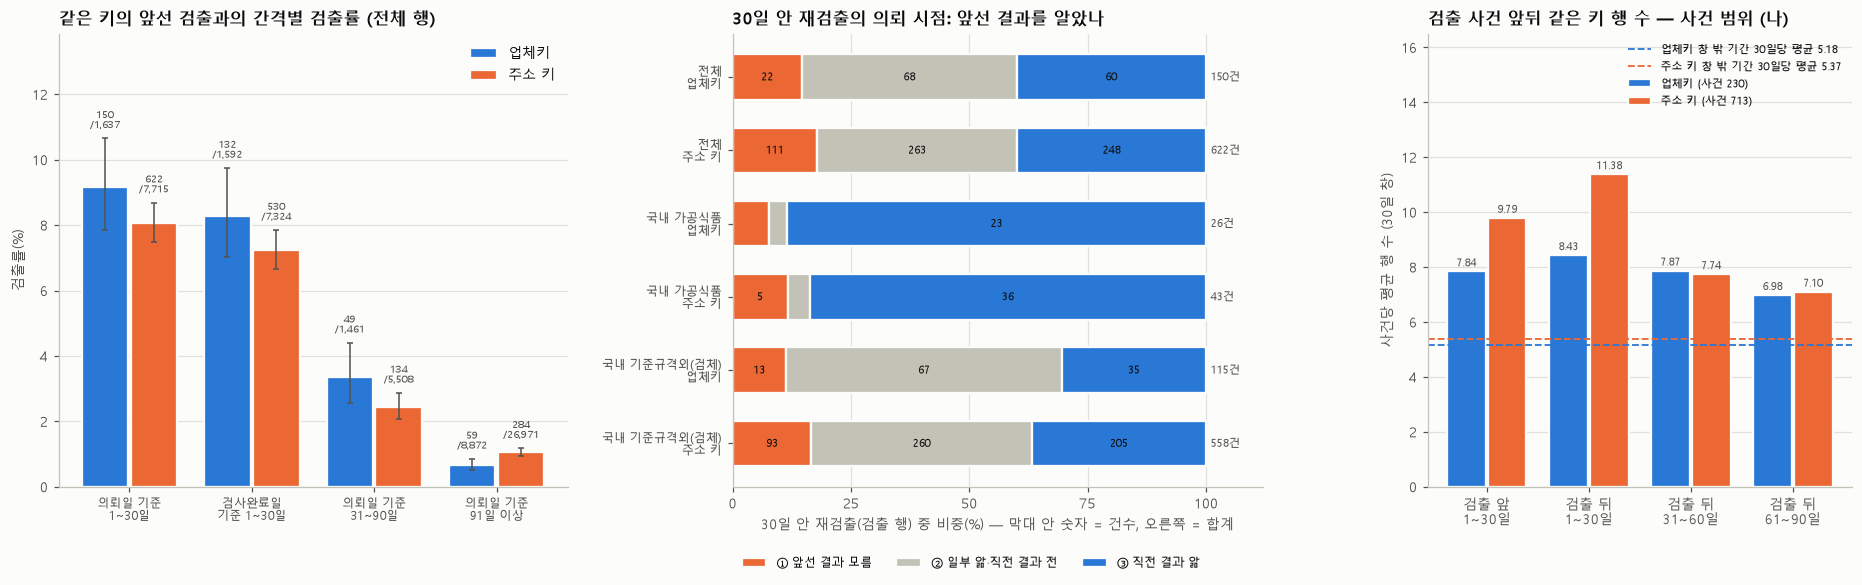

In [121]:
# [10-1 그림] 왼쪽: 간격별 검출률(전체 행, 95% CI, 글자 = 검출/행 수) / 가운데: 30일 안 재검출(검출 행)이 의뢰 시점의 앞선 결과로 나뉜 구성
#            오른쪽: 검출 사건 앞뒤 30일 창의 같은 키 평균 행 수, 사건 범위 (나), 점선 = 같은 키 창 밖 기간 30일당 평균
SURF = plt.rcParams['axes.facecolor']
fig, axes = plt.subplots(1, 3, figsize=(17, 5.4), gridspec_kw={'width_ratios': [1.2, 1.25, 1]})
ax = axes[0]
_show = [('(참고) 의뢰일 기준 1~30일 전체', '의뢰일 기준\n1~30일'), ('(c) 검사완료일 기준 1~30일', '검사완료일\n기준 1~30일'),
         ('검출 뒤 31~90일', '의뢰일 기준\n31~90일'), ('검출 뒤 91일 이상', '의뢰일 기준\n91일 이상')]
x = np.arange(len(_show))
ytop = 0
for nm_, col, off in [('업체키', C1, -0.2), ('주소 키', C2, 0.2)]:
    t = pd.concat([FU_SPLIT_TBL.loc[('전체', nm_)], FU_WINDOW_TBL.loc[nm_]]).reindex([s for s, _ in _show])
    r = t['검출률(%)'].to_numpy(float)
    lo, hi = wilson(t['검출'].to_numpy(float), t['행 수'].to_numpy(float))
    ax.bar(x + off, r, width=0.38, color=col, label=nm_, edgecolor=SURF, linewidth=1.5)
    ax.errorbar(x + off, r, yerr=[r - lo, hi - r], fmt='none', ecolor=INK2, elinewidth=1, capsize=2)
    for xi, hv, k, n in zip(x + off, hi, t['검출'], t['행 수']):
        ax.text(xi, hv + 0.25, f'{k:,}\n/{n:,}', ha='center', va='bottom', fontsize=6.5, color=INK2)
    ytop = max(ytop, np.nanmax(hi))
ax.set_xticks(x)
ax.set_xticklabels([lb for _, lb in _show], fontsize=8)
ax.set_ylim(0, ytop * 1.3)
ax.set_ylabel('검출률(%)')
ax.set_title('같은 키의 앞선 검출과의 간격별 검출률 (전체 행)')
ax.legend(loc='upper right')
ax.grid(axis='x', visible=False)

ax = axes[1]
_bars = [(s, k) for s, _ in SCOPES10 for k in ['업체키', '주소 키']]
y = np.arange(len(_bars))[::-1]
_cols3 = {TIMING_ORDER[0]: C2, TIMING_ORDER[1]: GRAY, TIMING_ORDER[2]: C1}
for yi, (s, k) in zip(y, _bars):
    row = RD30_TIMING.loc[(s, k)]
    tot = int(row['30일 안 재검출'])
    left = 0.0
    for t_ in TIMING_ORDER:
        w = int(row[t_]) / tot * 100 if tot else 0
        ax.barh(yi, w, left=left, height=0.62, color=_cols3[t_], edgecolor=SURF, linewidth=1.5,
                label=t_ if yi == y[0] else None)
        if w >= 9:
            ax.text(left + w / 2, yi, f'{int(row[t_]):,}', ha='center', va='center', fontsize=7.5, color='#0b0b0b')
        left += w
    ax.text(101, yi, f'{tot:,}건', ha='left', va='center', fontsize=7.5, color=INK2)
ax.set_yticks(y)
ax.set_yticklabels([f'{s}\n{k}' for s, k in _bars], fontsize=8)
ax.set_xlim(0, 112)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel('30일 안 재검출(검출 행) 중 비중(%) — 막대 안 숫자 = 건수, 오른쪽 = 합계')
ax.set_title('30일 안 재검출의 의뢰 시점: 앞선 결과를 알았나')
ax.legend(loc='upper center', bbox_to_anchor=(0.45, -0.13), ncol=3, fontsize=8)
ax.grid(axis='y', visible=False)

ax = axes[2]
wins = ['앞 1~30일', '뒤 1~30일', '뒤 31~60일', '뒤 61~90일']
rng_nm = '(나) 키 활동기간이 창을 덮는 사건'
x = np.arange(len(wins))
vmax = 0
for nm_, col, off in [('업체키', C1, -0.2), ('주소 키', C2, 0.2)]:
    tt = FU_EVENT_TBL.loc[(nm_, rng_nm)]
    v = tt.loc[wins, '평균 행 수'].astype(float).to_numpy()
    ax.bar(x + off, v, width=0.38, color=col, label=f"{nm_} (사건 {int(tt.loc['당일', '사건 수']):,})", edgecolor=SURF, linewidth=1.5)
    for xi, vi in zip(x + off, v):
        ax.text(xi, vi + 0.1, f'{vi:.2f}', ha='center', va='bottom', fontsize=7.5, color=INK2)
    b = float(tt.loc['(비교) 같은 키 창 밖 기간 30일당', '평균 행 수'])
    ax.axhline(b, color=col, ls='--', lw=1.2, label=f'{nm_} 창 밖 기간 30일당 평균 {b:.2f}')
    vmax = max(vmax, np.nanmax(v), b)
ax.set_xticks(x)
ax.set_xticklabels(['검출 앞\n1~30일', '검출 뒤\n1~30일', '검출 뒤\n31~60일', '검출 뒤\n61~90일'])
ax.set_ylim(0, vmax * 1.45)
ax.set_ylabel('사건당 평균 행 수 (30일 창)')
ax.set_title('검출 사건 앞뒤 같은 키 행 수 — 사건 범위 (나)')
ax.legend(loc='upper right', fontsize=7.5)
ax.grid(axis='x', visible=False)
plt.tight_layout(w_pad=2.5)
plt.show()

📊 **결과**
- 키: 업체키가 없는 행 323,707행(검출 1,424)은 '키 없음'으로 따로 셌습니다. 업체키 20,931개 중 검출 있는 키 252개(그 키의 행 18,834), 주소 키 41,309개 중 검출 있는 키 722개(행 66,011).
- **행 구분별 검출률** (의뢰일 기준 검출 뒤 1\~30일 vs 같은 조건의 91일 이상):
  - 전체: 업체키 150/1,637 (**9.163%**, CI 7.859\~10.658) vs 59/8,872 (0.665%) · 주소 키 622/7,715 (**8.062%**, CI 7.475\~8.691) vs 284/26,971 (1.053%)
  - 국내 가공식품: 업체키 26/219 (11.872%) vs 37/5,718 (0.647%) · 주소 키 43/825 (5.212%) vs 63/7,577 (0.831%)
- **결과 시차**: 검사완료일 없는 행 7,203 (검출 10). 검출 행의 의뢰일 → 검사완료일 간격은 5% 8일 · 중앙값 12일 · 95% 18일이고, 7일 이하는 4.4% 입니다 (모든 행은 중앙값 9일, 7일 이하 27.7%).
- **'검출 뒤 1\~30일' 나누기** (검출/행 수, 검출률):
  - 의뢰일 기준 1\~7일 vs 8\~30일: 전체 업체키 82/552 (14.855%) vs 68/1,085 (6.267%), 주소 키 313/2,480 (12.621%) vs 309/5,235 (5.903%)
  - 업체키 ① 앞선 결과 모름 / ② 일부 앎·직전 결과 전 / ③ 직전 결과 앎: 전체 22/355 (6.197%) / 68/408 (16.667%) / 60/874 (6.865%) · 국내 가공식품 2/70 (2.857%) / 1/5 (20.000%) / 23/144 (15.972%) · 국내 기준규격외(검체) 13/249 (5.221%) / 67/400 (16.750%) / 35/687 (5.095%)
  - 검사완료일 기준 1\~30일: 전체 업체키 132/1,592 (8.291%), 주소 키 530/7,324 (7.236%) · 국내 가공식품 업체키 28/235 (11.915%)
- **30일 안 재검출(검출 행)의 의뢰 시점** (업체키 / 주소 키):
  - 전체 150건 / 622건: 앞선 검출 의뢰일로부터 7일 안 82건 / 313건. ①+② 직전 결과 전 60.0% / 60.1%, 그중 ① 앞선 결과 모름 14.7% / 17.8%
  - 국내 기준규격외(검체) 115건 / 558건: ①+② 69.6% / 63.3%, ① 11.3% / 16.7%
  - 국내 가공식품 26건 / 43건: ③ 직전 결과 앎 23건 / 36건 (①+② 11.5% / 16.3%)
- **검출 사건 앞뒤 30일 창** — 사건 범위 (나) (업체키 230개, 주소 키 713개):
  - 평균 행 수: 업체키 앞 1\~30일 7.84 → 뒤 1\~30일 8.43 → 뒤 31\~60일 7.87 → 뒤 61\~90일 6.98 (같은 키 창 밖 기간 30일당 5.18) · 주소 키 9.79 → 11.38 → 7.74 → 7.10 (5.37)
  - 중앙값 행 수: 앞뒤 30일 창 모두 1.00 (창 밖 기간 30일당 업체키 1.06, 주소 키 1.48)
  - 행 1개 이상 사건: 업체키 55.7% → 68.3% → 56.1% → 57.4% · 주소 키 53.4% → 67.5% → 51.1% → 52.7%
  - 사건 범위 (가)(업체키 387개): 평균 6.42 → 7.27 → 5.53 → 4.81 (창 밖 기간 30일당 4.50; 창 밖 기간 30일 미만 사건 66개 뺌)
- **검출 행 중 30일 안 재검출 비율** (업체키 / 주소 키): 전체 27.5%(150/545) / 31.6%(622/1,969). 대분류 기준규격외(검체) 50.2% / 39.0%, 가공식품 10.1% / 10.9%, 수산물(원물) 20.0% / 19.6%, 국내 가공식품만 10.1%(26/258) / 11.1%(43/386). 검사목적 기타 40.9% / 36.6%, 수입검사 21.6% / 12.5%, 수거검사 12.3% / 12.1%, 자가품질위탁검사 0.0% / 1.6%.
- 검출 뒤 1\~30일 행의 검사목적은 '기타'가 85.9%(업체키)·89.0%(주소 키)입니다 (검출 이력 없는 키의 행 23.0%·45.5%, 모든 행 48.3%).
- 30일 안 재검출이 많은 곳: 업체 상위 5곳이 150건 중 110건(73.3%), 주소 상위 5곳이 622건 중 380건(61.1%). 10곳 모두 기준규격외(검체) 100%·검사목적 '기타' 100%·국내 100% 이고, 검출 행 검체성격(임의)은 팽이버섯·환경검체가 대부분입니다 (예: 주소1 경상북도 청도군 검출 164 중 팽이버섯 163, 30일 안 재검출 159).

💬 **첨언**
- 작성자가 의뢰일 간격으로 나눠 본 결과, 같은 곳의 검출 뒤 30일 안 행은 검출률이 91일 이상 뒤보다 크게 높아 보입니다 (업체키 9.163% vs 0.665%) (추정). 이것만으로는 추적 검사인지, 같은 오염이 몇 주 이어진 것(같은 재배사·같은 설비)인지 구분할 수 없습니다.
- 검출 행의 검사완료일이 의뢰 뒤 7일 안인 경우는 4.4% 뿐인데, 30일 안 재검출의 절반가량(업체키 82/150, 주소 키 313/622)은 앞선 검출 의뢰 뒤 7일 안에 의뢰됐습니다. 그래서 '검출 뒤 1\~30일'에는 **앞선 결과를 알기 전에 의뢰된 행**이 많이 섞여 있어 보입니다 (추정).
- 결과 시차로 나눠 보면 범위마다 모양이 달라 보입니다 (추정):
  - 국내 기준규격외(검체): 재검출의 69.6%(업체키)가 직전 검출 결과가 나오기 전에 의뢰됐습니다. 다만 어떤 앞선 결과도 모른 채(①) 의뢰된 몫은 11.3% 이고, 대부분(②)은 그보다 앞선 검출 결과가 30일 안에 이미 나온 뒤였습니다. 곧 **같은 곳의 오염을 한 번 안 뒤, 다음 결과를 기다리지 않고 짧은 간격으로 되풀이 검사한 몫**이 커 보입니다. 이런 행들은 서로 독립된 검사라기보다 한 오염 사건의 연속 시료에 가까울 수 있습니다. 행 단위 검출률도 ② 가 16.750% 로 ①(5.221%)·③(5.095%)보다 높습니다.
  - 국내 가공식품: 재검출이 적고(업체키 26건) 그중 23건이 직전 결과를 안 뒤 의뢰돼, **결과를 보고 다시 의뢰한 모양**에 가까워 보입니다. 행 단위로도 ③ 15.972%(23/144) vs ① 2.857%(2/70) 입니다 (행 수가 작아 흔들림이 큼).
  - ①·②·③ 은 작성자가 검사완료일로 정한 구분이고, 이 날짜가 업체가 결과를 안 날과 같은지는 모릅니다 (🗄️ 질문).
- '같은 곳 직전 검출 이력'을 모델 변수로 쓴다면 (추정): 의뢰일 기준 표시(업체키 1,637행)에는 의뢰 시점에 30일 안 결과가 하나도 없던 ① 355행이 들어 있어, 아직 없던 정보를 쓰게 됩니다(누수 위험). '직전 검출까지 일수'처럼 가장 최근 검출을 쓰는 변수는 ② 408행에서도 같은 문제가 생깁니다. 검사완료일 기준 표시(업체키 1,592행·검출 132, 8.291%)는 완료일이 통보일과 같다면 이 위험이 작고, 검출률도 여전히 높습니다.
- 사건 단위로 보면, 검출 뒤 30일에 같은 곳 행이 1개 이상 있는 사건이 앞 30일보다 많고(업체키 55.7% → 68.3%), 뒤 31\~60일에는 앞 30일 수준(56.1%)으로 돌아옵니다. 검출 뒤 재의뢰가 섞였을 가능성을 보여 줍니다 (추정).
  - 평균 행 수는 검출 앞 30일(7.84)부터 같은 키 창 밖 기간(5.18)보다 높지만, 중앙값은 1.00 과 1.06 으로 비슷합니다. "검출 앞에도 의뢰가 몰린다"기보다 **행이 아주 많은 몇 곳이 평균을 끌어올린 것**으로 보입니다 (추정).
  - (가)에서 뒤 31\~90일 행이 줄어드는 모양은 (나)에서 작아져, 키가 자료에서 끝나는 영향이 섞였던 것으로 보입니다 (추정). 창 안 검출 수의 앞뒤 비교는 구조상 비슷하게 나오므로(코드 출력의 주의 문구) 해석하지 않았습니다.
- 30일 안 재검출은 기준규격외(검체)·검사목적 '기타'·팽이버섯·환경검체에 몰려 있어, 2.ipynb 의 팽이버섯 수출검사 몰림과 같은 묶음으로 보입니다 (추정). 주소 상위 5곳 중 3곳이 청도군(표기 '경상북도'·'경북'이 섞임)이라 같은 곳의 다른 표기일 수도 있습니다 (추정).
- 자가품질위탁검사 검출은 30일 안 재검출이 업체키 0건·주소 2건입니다. 정해진 주기로 하는 검사라 검출 뒤 곧바로 다시 의뢰되는 모양이 거의 없어 보입니다 (추정).
- 한계: 업체키는 323,707행(검출 1,424)에 없어 계산에서 빠졌고, 주소 키는 같은 주소의 여러 업체·같은 업체의 여러 주소 표기를 구분하지 못합니다. 행 단위로 셌기 때문에 한 의뢰의 여러 행이 겹쳐 세어졌을 수 있습니다.
- 뒤 파트용 변수(모두 `dfx` 와 같은 인덱스, `dfx` 에는 넣지 않음): `fu_gap_firm`·`fu_gap_addr`(의뢰일 기준 앞선 검출까지 일수), `fu_class_firm`·`fu_class_addr`(행 구분), `followup30_firm`·`followup30_addr`(의뢰일 기준 검출 뒤 1\~30일), `fu_gap_compt_firm`·`fu_gap_compt_addr`(검사완료일 기준 앞선 결과까지 일수), `followup30c_firm`·`followup30c_addr`(검사완료일 기준 1\~30일), `fu_timing_firm`·`fu_timing_addr`(①·②·③). 표: `FU_WINDOW_TBL`, `FU_SPLIT_TBL`, `RD30_TIMING`, `FU_EVENT_TBL`.

### 10-2. 검사기관 — 기관마다 검출률이 다른가, 달별 차이가 기관 구성 때문인가

🔎 검사기관(`inspct_instt_code`)별로 행·검출·검출률을 보고, 6-4 의 달별 O/E 를 **검사기관 층** 등으로 다시 계산합니다. 연도 구성(앞뒤가 잘린 해)과 10-1 의 같은 곳 몰림이 달 모양에 주는 영향도 함께 봅니다.

**범위 (작성자 임의)**
- **S2 국내 가공식품**: 국내 × 대분류 가공식품 (1절 S2·6절과 같은 범위)
- **비가열 식육 후보(임시)**: 국내 × 품목명(`prdlst_nm_self`)이 정확히 `포장육`·`양념육`·`생햄` 인 행 (9-2 의 임시 묶음과 같음, 8절 G1 품목명에서 발효소시지를 뺀 것). '가열양념육'은 넣지 않았습니다. 가열 여부는 품목명으로만 짐작한 것이라 검증 전입니다. 해외 행은 빼고 수를 적습니다.
- 이 절의 범위 이름은 8절·12절의 G1(비가열 식육)·G2(가열 식육가공품)와 겹치지 않게 **S2**·**비가열(임시)** 로 적습니다. 코드 변수 이름의 g1·g2(`inst_tbl_g1`·`inst_tbl_g2`·`oe10_season_g2` 등)는 각각 S2·비가열(임시)를 뜻합니다.
- 기관 이름·주소는 `nb2_db_instt.csv`(2.ipynb DB 보조 추출)에서 붙이고, 기관 유형은 이름으로 나눈 **작성자 임의 라벨**입니다 (코드 147… = 식약처 지방청, 이름에 보건환경연구원·동물위생시험소 등 = 지자체 기관, 그 외 = 민간·대학·기타).

**비교할 변형 목록 (결과보다 먼저 적음)**
1. 기관별 행·검출·검출률·95% CI 상위 15 (검출 많은 순) × S2, 비가열(임시)
2. 검출의 기관 집중 × S2, 비가열(임시) — 비교 기준 두 가지는 모두 작성자 임의 방법:
   - 검출 상위 5곳의 검출 비중·행 비중. 비교 기준 = 기관 차이가 없다고 두고 전체 검출 수를 기관별 행 비중대로 나누는 다항 모의(2,000회, seed 11)에서 상위 5곳 검출 비중의 평균·99백분위
   - 95% CI 가 범위 전체 검출률보다 위·아래인 기관 수. 비교 기준 = 모든 기관 검출률이 범위 전체율과 같다고 둔 이항분포로 정확히 계산한 기대 기관 수(±2SD)
3. S2 검출 상위 5 기관의 달별(의뢰월) 행 비중과 달별 검출 수
4. 간접표준화 O/E (6-4 방식: 기대 검출 = Σ 행마다 층 검출률) — S2 의뢰월 12칸
   - 층 바꾸기(전체 기간): (참고) 층 없음 / (가) 검사목적 × 학습용 품목명 (6-4 재현) / (나) 검사기관 / (다) 검사기관 × 검사목적 × 학습용 품목명 / (바) 의뢰연도 / (사) 검사기관 × 의뢰연도
   - 행 범위 바꾸기: 완전한 해(2017\~2025, 6-5 와 같음)만 × 층 없음·(가)·(나) / (라) 10-1 의뢰일 기준 30일 안 행(`followup30_firm | followup30_addr`) 뺌 × 층 없음·(가)·(나) / (라') 검사완료일 기준 30일 안 행(`followup30c_firm | followup30c_addr`) 뺌 × 층 없음·(가)·(나) / (마) 의뢰 단위(의뢰키 = `lims_data_key` 앞 두 조각, 한 의뢰 안 검출 1건 이상 = 검출, 의뢰월 = 가장 이른 달) × 층 없음·(나)
   - 참고 출력: S2 의뢰연도 × 의뢰월 검출 수, 앞뒤가 잘린 해의 달 범위, 7월 검출 중 같은 주소·같은 연월 3건 이상 묶음
5. 같은 O/E — 비가열(임시) 의뢰 계절 4칸(6-2 계절 구간): 층 없음 / (가') 검사목적 × 품목명 / (나) / (바) / (사); 완전한 해만 × 층 없음·(나); (라) × 층 없음·(나)

In [122]:
# [10-2] 검사기관 정보(이름·유형 라벨·주소 첫 단어)와 범위 S2·비가열(임시), 기관별 검출률 상위 15 (변수 이름 g1 = S2, g2 = 비가열(임시))
import math
INSTT_INFO = pd.read_csv(COL / 'nb2_db_instt.csv', dtype=str).set_index('inspct_instt_code')
_inm = INSTT_INFO['instt_nm'].astype('string').str.strip()
_ien = INSTT_INFO['instt_eng_nm'].astype('string').str.strip()
_inm = _inm.mask(_inm.eq(''))
_ien = _ien.mask(_ien.eq(''))
INSTT_INFO['기관 이름'] = _inm.where(_inm.notna(), _ien.where(_ien.notna(), '(이름 없음)')).str.slice(0, 26)   # 표시용 라벨
_gov = pd.Series(INSTT_INFO.index.str.startswith('147'), index=INSTT_INFO.index)
_loc = has_kw(INSTT_INFO['instt_nm'], r'보건환경연구원|동물위생시험소|축산위생|축산진흥연구소') | \
       has_kw(INSTT_INFO['instt_eng_nm'], r'instituteofhealth|healthandenvironment|veterinary')
INSTT_INFO['유형(임의)'] = np.select([_gov, _loc], ['식약처 지방청', '지자체 기관'], '민간·대학·기타')
_adr0 = INSTT_INFO['adres'].astype('string').str.strip().str.split().str[0]
INSTT_INFO['기관 주소 첫 단어'] = _adr0.where(_adr0.notna(), '(주소 없음)')
print(f"기관 정보 파일 {len(INSTT_INFO):,}곳, 유형 라벨(작성자 임의): {INSTT_INFO['유형(임의)'].value_counts().to_dict()}")
_fac = has_kw(INSTT_INFO['adres'], r'공장')
print(f"주소에 '공장'이 들어간 기관 {int(_fac.sum())}곳 (예: " + ' / '.join(INSTT_INFO.loc[_fac, 'adres'].str.strip().head(4)) + ')')
_nf = set(dfx['inspct_instt_code'].astype(str).unique()) - set(INSTT_INFO.index)
print(f'학습용 데이터의 기관 코드 {dfx["inspct_instt_code"].nunique()}곳 중 기관 정보 파일에 없는 코드 {len(_nf)}곳')

NONHEAT_MEAT_NAMES = ['포장육', '양념육', '생햄']          # 임시 정의 (작성자 임의, 검증 전)
nonheat_meat_mask = dfx['품목명'].isin(NONHEAT_MEAT_NAMES)
g1m = dfx['국내해외'].eq('국내') & dfx['대분류'].eq('가공식품')
g2m = dfx['국내해외'].eq('국내') & nonheat_meat_mask
_ov = nonheat_meat_mask & dfx['국내해외'].eq('해외')
print(f"S2 국내 가공식품 {int(g1m.sum()):,}행 / 검출 {int(dfx.loc[g1m, 'pos'].sum()):,}")
print(f"비가열 식육 후보(임시) {int(g2m.sum()):,}행 / 검출 {int(dfx.loc[g2m, 'pos'].sum()):,} "
      f"(해외 같은 품목명 {int(_ov.sum()):,}행·검출 {int(dfx.loc[_ov, 'pos'].sum())} 뺌; 비가열(임시) 중 S2 밖 {int((g2m & ~g1m).sum())}행)")
print('비가열(임시) 품목명별 행/검출:', dfx.loc[g2m, ['품목명', 'pos']].groupby('품목명', observed=True)['pos'].agg(['size', 'sum']).to_dict('index'))
_nf1 = set(dfx.loc[g1m | g2m, 'inspct_instt_code'].astype(str).unique()) - set(INSTT_INFO.index)
print(f'S2·비가열(임시) 에서 기관 정보 파일에 없는 기관 코드: {sorted(_nf1)} (있으면 이름·유형 라벨이 비어 보임)')

d10 = dfx.loc[g1m | g2m, ['lims_data_key', 'pos', 'reqest_de', 'inspct_instt_code', '검사목적', 'train_prdlst_nm', '품목명', 'legal_dong_code', 'addr']].copy()
d10['g1'] = g1m[g1m | g2m].to_numpy()
d10['g2'] = g2m[g1m | g2m].to_numpy()
d10['fu30'] = (followup30_firm | followup30_addr)[g1m | g2m].to_numpy()        # 10-1 의뢰일 기준 검출 뒤 1~30일 행 (업체키 또는 주소 키)
d10['fu30c'] = (followup30c_firm | followup30c_addr)[g1m | g2m].to_numpy()     # 10-1 검사완료일 기준 1~30일 행
d10['의뢰키'] = d10['lims_data_key'].astype(str).str.split('_').str[:2].str.join('_')   # 6-3 과 같은 의뢰 식별 규칙
d10['기관'] = d10['inspct_instt_code'].astype(str)
d10['의뢰월'] = d10['reqest_de'].dt.month
d10['연'] = d10['reqest_de'].dt.year


def inst_table(fr):
    '''기관별 행 수·검출·검출률·Wilson 95% CI, 범위 전체 검출률과 CI 비교(위/아래/겹침)'''
    g = fr.groupby('기관')['pos'].agg(['size', 'sum'])
    base = fr['pos'].mean()
    lo, hi = wilson(g['sum'], g['size'])
    yr = fr.groupby('기관')['연'].agg(['min', 'max'])
    t = pd.DataFrame({'기관 이름': INSTT_INFO['기관 이름'].reindex(g.index), '유형(임의)': INSTT_INFO['유형(임의)'].reindex(g.index),
                      '기관 주소 첫 단어': INSTT_INFO['기관 주소 첫 단어'].reindex(g.index),
                      '행 수': g['size'], '검출': g['sum'], '검출률(%)': (g['sum'] / g['size'] * 100).round(3),
                      '95% CI(%)': [f'{a:.3f}~{b:.3f}' for a, b in zip(lo, hi)],
                      '행 비중(%)': (g['size'] / g['size'].sum() * 100).round(1), '검출 비중(%)': (g['sum'] / g['sum'].sum() * 100).round(1),
                      '범위 전체율 대비': np.select([lo > base * 100, hi < base * 100], ['CI 위', 'CI 아래'], '겹침'),
                      '의뢰 연도': [f'{a}~{b}' for a, b in zip(yr['min'], yr['max'])]})
    t.index.name = '기관 코드'
    return t.sort_values(['검출', '행 수'], ascending=False)


def homog_expect(t, sims=2000, seed=11):
    '''기관 차이가 없다고 둘 때의 비교 기준 (작성자 임의)
    - CI 위·아래 기관 수: 기관 i 의 검출 k ~ 이항(n_i, p), p = 범위 전체 검출률
        P_i(위) = Σ_k C(n_i, k) p^k (1−p)^(n_i−k) · 1[Wilson 하한(k, n_i) > p],  P_i(아래) 는 1[Wilson 상한(k, n_i) < p]
        기대 기관 수 = Σ_i P_i,  분산 = Σ_i P_i (1 − P_i)  (기관끼리 독립으로 봄)
      log C(n, k) 는 log n! 누적합 표로 계산. k 는 평균 + 12·SD + 30 까지만 더함 → 더한 확률의 최솟값을 출력해 확인
    - 검출 상위 5곳 검출 비중: 전체 검출 K 를 기관별 행 비중(n_i / N)대로 나누는 다항 모의 sims 회 → 회마다 (상위 5곳 검출 합 / K)'''
    n = t['행 수'].to_numpy(int)
    K, N = int(t['검출'].sum()), int(n.sum())
    p = K / N
    lf = np.concatenate([[0.0], np.cumsum(np.log(np.arange(1, n.max() + 1)))])
    e_up = e_dn = v_up = v_dn = 0.0
    mass_min = 1.0
    for ni in n:
        kmax = int(min(ni, math.ceil(ni * p + 12 * math.sqrt(ni * p * (1 - p)) + 30)))
        k = np.arange(0, kmax + 1)
        pmf = np.exp(lf[ni] - lf[k] - lf[ni - k] + k * math.log(p) + (ni - k) * math.log1p(-p))
        lo, hi = wilson(k, np.full(len(k), ni))
        pu, pdn = float(pmf[lo > p * 100].sum()), float(pmf[hi < p * 100].sum())
        e_up, e_dn = e_up + pu, e_dn + pdn
        v_up, v_dn = v_up + pu * (1 - pu), v_dn + pdn * (1 - pdn)
        mass_min = min(mass_min, float(pmf.sum()))
    sim = np.random.default_rng(seed).multinomial(K, n / N, size=sims)
    top5 = np.sort(sim, axis=1)[:, -5:].sum(axis=1) / K * 100
    return {'CI 위 기대': e_up, 'CI 위 2SD': 2 * math.sqrt(v_up), 'CI 아래 기대': e_dn, 'CI 아래 2SD': 2 * math.sqrt(v_dn),
            '더한 확률 최솟값': mass_min, '상위5 모의 평균': float(top5.mean()), '상위5 모의 99백분위': float(np.percentile(top5, 99))}


def conc_summary(t, label):
    top5 = t.head(5)
    byn = t.sort_values('행 수', ascending=False).head(5)
    up, dn = t[t['범위 전체율 대비'].eq('CI 위')], t[t['범위 전체율 대비'].eq('CI 아래')]
    h = homog_expect(t)
    print(f"[{label}] 기관 {len(t)}곳, 검출 있는 기관 {int((t['검출'] > 0).sum())}곳, 전체 검출률 {t['검출'].sum() / t['행 수'].sum() * 100:.3f}%")
    print(f"  검출 상위 5곳: 검출 비중 {top5['검출'].sum() / t['검출'].sum() * 100:.1f}% / 행 비중 {top5['행 수'].sum() / t['행 수'].sum() * 100:.1f}% "
          f"— 비교 기준(기관 차이 없음, 다항 모의 2,000회): 상위 5곳 검출 비중 평균 {h['상위5 모의 평균']:.1f}%, 99백분위 {h['상위5 모의 99백분위']:.1f}%")
    print(f"  행 상위 5곳: 행 비중 {byn['행 수'].sum() / t['행 수'].sum() * 100:.1f}% / 검출 비중 {byn['검출'].sum() / t['검출'].sum() * 100:.1f}%")
    print(f"  95% CI 가 전체율보다 위인 기관 {len(up)}곳(행 {int(up['행 수'].sum()):,}, 검출 {int(up['검출'].sum())}), "
          f"아래인 기관 {len(dn)}곳(행 {int(dn['행 수'].sum()):,}, 검출 {int(dn['검출'].sum())})")
    print(f"  비교 기준(모든 기관 검출률 = 전체율, 이항분포 정확 계산): 'CI 위' 기대 {h['CI 위 기대']:.1f}곳 (±2SD {h['CI 위 2SD']:.1f}), "
          f"'CI 아래' 기대 {h['CI 아래 기대']:.1f}곳 (±2SD {h['CI 아래 2SD']:.1f}) / 확인: 기관별로 더한 이항 확률의 최솟값 {h['더한 확률 최솟값']:.6f}")
    print('  검출 비중 유형별(%):', (t.groupby('유형(임의)')['검출'].sum() / t['검출'].sum() * 100).round(1).to_dict(),
          '/ 행 비중 유형별(%):', (t.groupby('유형(임의)')['행 수'].sum() / t['행 수'].sum() * 100).round(1).to_dict())
    return h


d1 = d10[d10['g1']]
d2 = d10[d10['g2']]
inst_tbl_g1 = inst_table(d1)
inst_tbl_g2 = inst_table(d2)
INST_HOMOG = {'S2': conc_summary(inst_tbl_g1, 'S2 국내 가공식품')}
display(inst_tbl_g1.head(15))
INST_HOMOG['비가열(임시)'] = conc_summary(inst_tbl_g2, '비가열 식육 후보(임시)')
inst_tbl_g2.head(15)

기관 정보 파일 285곳, 유형 라벨(작성자 임의): {'민간·대학·기타': 249, '지자체 기관': 28, '식약처 지방청': 8}
주소에 '공장'이 들어간 기관 2곳 (예: 경기 안성시 원곡면 매지로 54 동학식품 안성공장 / 경기도 파주시 파주읍 돈유2로 100 (주)한미양행 선유공장)
학습용 데이터의 기관 코드 270곳 중 기관 정보 파일에 없는 코드 0곳
S2 국내 가공식품 294,421행 / 검출 386
비가열 식육 후보(임시) 26,055행 / 검출 192 (해외 같은 품목명 2,015행·검출 17 뺌; 비가열(임시) 중 S2 밖 0행)
비가열(임시) 품목명별 행/검출: {'생햄': {'size': 1431, 'sum': 4}, '양념육': {'size': 21956, 'sum': 87}, '포장육': {'size': 2668, 'sum': 101}}
S2·비가열(임시) 에서 기관 정보 파일에 없는 기관 코드: [] (있으면 이름·유형 라벨이 비어 보임)
[S2 국내 가공식품] 기관 266곳, 검출 있는 기관 52곳, 전체 검출률 0.131%
  검출 상위 5곳: 검출 비중 47.7% / 행 비중 9.4% — 비교 기준(기관 차이 없음, 다항 모의 2,000회): 상위 5곳 검출 비중 평균 20.3%, 99백분위 24.6%
  행 상위 5곳: 행 비중 18.7% / 검출 비중 6.2%
  95% CI 가 전체율보다 위인 기관 12곳(행 38,898, 검출 240), 아래인 기관 13곳(행 79,054, 검출 4)
  비교 기준(모든 기관 검출률 = 전체율, 이항분포 정확 계산): 'CI 위' 기대 12.2곳 (±2SD 6.7), 'CI 아래' 기대 0.4곳 (±2SD 1.3) / 확인: 기관별로 더한 이항 확률의 최솟값 1.000000
  검출 비중 유형별(%): {'민간·대학·기타': 71.0, '식약처 지방청': 3.4, '지자체 기관': 25.6} / 행 비중 유형별(%): {'민간·대학·기타': 79.7, '식약처 지방청': 3.9, '지

,기관 이름,유형(임의),기관 주소 첫 단어,행 수,검출,검출률(%),95% CI(%),행 비중(%),검출 비중(%),범위 전체율 대비,의뢰 연도
기관 코드,,,,,,,,,,,
O000044,Traditional Microorganism,민간·대학·기타,대구시,5963,72,1.207,0.960~1.518,2.0,18.7,CI 위,2016~2026
O000084,Intertek Testing Services,민간·대학·기타,경기도,6859,40,0.583,0.429~0.793,2.3,10.4,CI 위,2016~2026
O000146,제주특별자치도 동물위생시험소,지자체 기관,제주특별자치도,4668,31,0.664,0.468~0.941,1.6,8.0,CI 위,2017~2026
O000108,경기도 동물위생시험소,지자체 기관,경기도,2750,22,0.800,0.529~1.208,0.9,5.7,CI 위,2017~2026
O000033,The President of OATC Inc.,민간·대학·기타,서울특별시,7446,19,0.255,0.163~0.398,2.5,4.9,CI 위,2016~2026
O000026,"BIO FOOD LAB CO., LTD.",민간·대학·기타,서울특별시,13480,15,0.111,0.067~0.184,4.6,3.9,겹침,2016~2026
O000001,KOTITI Testing & Research,민간·대학·기타,경기도,7839,15,0.191,0.116~0.315,2.7,3.9,겹침,2016~2026
O000083,한국에스지에스(주),민간·대학·기타,경기도,7864,14,0.178,0.106~0.299,2.7,3.6,겹침,2016~2026
O000059,Suwon Women’s University F,민간·대학·기타,경기도,5748,12,0.209,0.119~0.365,2.0,3.1,겹침,2016~2026


[비가열 식육 후보(임시)] 기관 106곳, 검출 있는 기관 38곳, 전체 검출률 0.737%
  검출 상위 5곳: 검출 비중 65.1% / 행 비중 16.0% — 비교 기준(기관 차이 없음, 다항 모의 2,000회): 상위 5곳 검출 비중 평균 32.0%, 99백분위 39.1%
  행 상위 5곳: 행 비중 29.1% / 검출 비중 43.2%
  95% CI 가 전체율보다 위인 기관 10곳(행 4,421, 검출 138), 아래인 기관 8곳(행 9,287, 검출 2)
  비교 기준(모든 기관 검출률 = 전체율, 이항분포 정확 계산): 'CI 위' 기대 5.1곳 (±2SD 4.4), 'CI 아래' 기대 0.2곳 (±2SD 1.0) / 확인: 기관별로 더한 이항 확률의 최솟값 1.000000
  검출 비중 유형별(%): {'민간·대학·기타': 65.1, '식약처 지방청': 3.6, '지자체 기관': 31.2} / 행 비중 유형별(%): {'민간·대학·기타': 76.6, '식약처 지방청': 1.9, '지자체 기관': 21.5}


,기관 이름,유형(임의),기관 주소 첫 단어,행 수,검출,검출률(%),95% CI(%),행 비중(%),검출 비중(%),범위 전체율 대비,의뢰 연도
기관 코드,,,,,,,,,,,
O000044,Traditional Microorganism,민간·대학·기타,대구시,1523,62,4.071,3.189~5.184,5.8,32.3,CI 위,2016~2026
O000146,제주특별자치도 동물위생시험소,지자체 기관,제주특별자치도,1607,21,1.307,0.856~1.990,6.2,10.9,CI 위,2017~2026
O000084,Intertek Testing Services,민간·대학·기타,경기도,425,20,4.706,3.067~7.157,1.6,10.4,CI 위,2018~2026
O000108,경기도 동물위생시험소,지자체 기관,경기도,373,12,3.217,1.850~5.538,1.4,6.2,CI 위,2017~2026
O000119,충청북도 축산위생연구소,지자체 기관,(주소 없음),252,10,3.968,2.169~7.149,1.0,5.2,CI 위,2019~2026
O000025,Eurofins Korea Analytic Se,민간·대학·기타,경기도,532,7,1.316,0.639~2.691,2.0,3.6,겹침,2016~2026
O000033,The President of OATC Inc.,민간·대학·기타,서울특별시,565,6,1.062,0.488~2.297,2.2,3.1,겹침,2017~2026
O000047,NongHyup Agribusiness Grou,민간·대학·기타,경기도,38,5,13.158,5.754~27.327,0.1,2.6,CI 위,2018~2025
O000026,"BIO FOOD LAB CO., LTD.",민간·대학·기타,서울특별시,1062,3,0.282,0.096~0.827,4.1,1.6,겹침,2017~2026


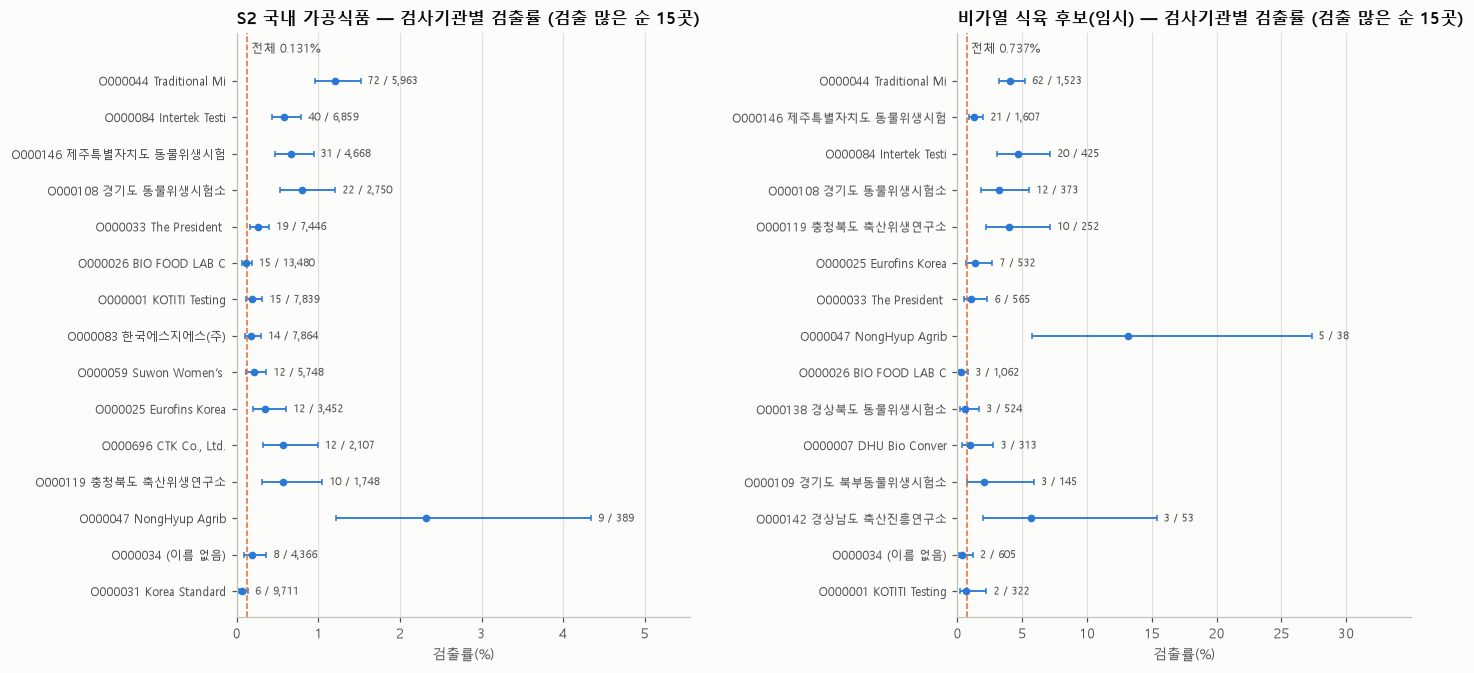

In [123]:
# [10-2 그림] 기관별 검출률과 95% CI (검출 많은 순 상위 15, 글자 = 검출/행 수, 점선 = 범위 전체 검출률)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.2))
for ax, (t, fr, title) in zip(axes, [(inst_tbl_g1, d1, 'S2 국내 가공식품'), (inst_tbl_g2, d2, '비가열 식육 후보(임시)')]):
    tt = t.head(15)
    y = np.arange(len(tt))[::-1]
    lo, hi = wilson(tt['검출'].to_numpy(float), tt['행 수'].to_numpy(float))
    r = tt['검출률(%)'].to_numpy(float)
    ax.errorbar(r, y, xerr=[r - lo, hi - r], fmt='o', ms=4, color=C1, ecolor=C1, elinewidth=1.2, capsize=2)
    for yi, h, k, n in zip(y, hi, tt['검출'], tt['행 수']):
        ax.text(h + np.nanmax(hi) * 0.02, yi, f'{k:,} / {n:,}', va='center', fontsize=7.5, color=INK2)
    base = fr['pos'].mean() * 100
    ax.axvline(base, color=C2, ls='--', lw=1)
    ax.text(base, len(tt) - 0.3, f' 전체 {base:.3f}%', color=INK2, fontsize=8, va='bottom')
    ax.set_yticks(y)
    ax.set_yticklabels([f'{c} {str(nm)[:14]}' for c, nm in zip(tt.index, tt['기관 이름'])], fontsize=8)
    ax.set_xlim(0, np.nanmax(hi) * 1.28)
    ax.set_ylim(-0.7, len(tt) + 0.3)
    ax.set_xlabel('검출률(%)')
    ax.grid(axis='y', visible=False)
    ax.set_title(f'{title} — 검사기관별 검출률 (검출 많은 순 15곳)')
plt.tight_layout(w_pad=3)
plt.show()

[S2] 달별 행 비중(%) — 열 = 기관 코드 (행마다 합 100%)


기관,O000044,O000084,O000146,O000108,O000033,그 외
의뢰월,,,,,,
1,2.1,2.8,1.5,0.7,2.5,90.4
2,2.1,2.2,1.6,0.5,2.6,91.0
3,1.8,2.3,1.8,1.1,2.6,90.4
4,1.9,2.5,1.6,1.3,2.4,90.3
5,1.8,2.0,1.6,1.4,2.3,90.9
6,2.0,1.7,1.6,1.2,2.5,90.9
7,2.2,2.4,1.7,1.0,2.5,90.2
8,1.9,2.3,1.4,0.8,2.4,91.1
9,1.9,2.2,1.6,0.9,2.9,90.4


[S2] 달별 검출 수 — 열 = 기관 코드


기관,O000044,O000084,O000146,O000108,O000033,그 외,합계
의뢰월,,,,,,,
1,3,5,2,0,1,13,24
2,5,5,0,1,0,12,23
3,10,1,8,3,5,23,50
4,3,9,4,2,1,34,53
5,7,7,1,3,1,23,42
6,7,1,2,2,1,18,31
7,13,5,9,3,1,11,42
8,6,2,2,4,2,11,27
9,5,0,1,4,5,17,32


  O000044 Traditional Microorganism : 달별 행 비중 1.8%(5월) ~ 2.4%(10월), 달별 검출 2~13건 (가장 많은 달 7월)
  O000084 Intertek Testing Services : 달별 행 비중 1.7%(6월) ~ 2.8%(1월), 달별 검출 0~9건 (가장 많은 달 4월)
  O000146 제주특별자치도 동물위생시험소: 달별 행 비중 1.4%(12월) ~ 1.8%(3월), 달별 검출 0~9건 (가장 많은 달 7월)
  O000108 경기도 동물위생시험소: 달별 행 비중 0.5%(2월) ~ 1.4%(5월), 달별 검출 0~4건 (가장 많은 달 8월)
  O000033 The President of OATC Inc.: 달별 행 비중 2.3%(5월) ~ 2.9%(9월), 달별 검출 0~5건 (가장 많은 달 3월)


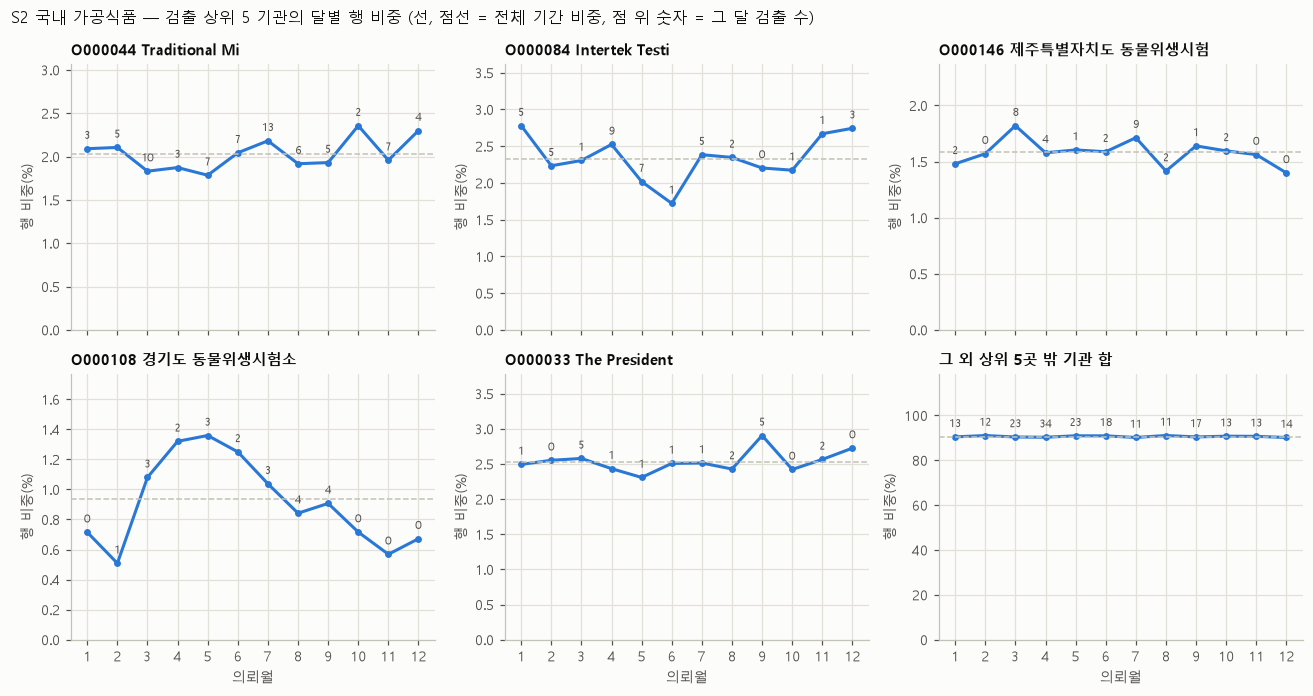

In [124]:
# [10-2 계속] S2 검출 상위 5 기관의 달별(의뢰월) 행 비중(%)과 달별 검출 수
TOP5_INST_G1 = list(inst_tbl_g1.index[:5])
_grp = d1['기관'].where(d1['기관'].isin(TOP5_INST_G1), '그 외')
share_m = pd.crosstab(d1['의뢰월'], _grp, normalize='index') * 100
share_m = share_m[TOP5_INST_G1 + ['그 외']]
share_m.loc['전체 기간'] = (_grp.value_counts(normalize=True) * 100).reindex(share_m.columns)
INST_MONTH_SHARE_G1 = share_m.round(1)
print('[S2] 달별 행 비중(%) — 열 = 기관 코드 (행마다 합 100%)')
display(INST_MONTH_SHARE_G1)
kpos_m = pd.crosstab(d1['의뢰월'], _grp, values=d1['pos'], aggfunc='sum')[TOP5_INST_G1 + ['그 외']]
kpos_m['합계'] = d1.groupby('의뢰월')['pos'].sum()
print('[S2] 달별 검출 수 — 열 = 기관 코드')
display(kpos_m)
for c in TOP5_INST_G1:
    s = share_m.loc[range(1, 13), c]
    print(f"  {c} {INSTT_INFO['기관 이름'].get(c, '')}: 달별 행 비중 {s.min():.1f}%({int(s.idxmin())}월) ~ {s.max():.1f}%({int(s.idxmax())}월), "
          f"달별 검출 {int(kpos_m[c].min())}~{int(kpos_m[c].max())}건 (가장 많은 달 {int(kpos_m[c].idxmax())}월)")

fig, axes = plt.subplots(2, 3, figsize=(12, 6.4), sharex=True)
for ax, c in zip(axes.ravel(), TOP5_INST_G1 + ['그 외']):
    s = share_m.loc[range(1, 13), c].to_numpy(float)
    ax.plot(range(1, 13), s, marker='o', ms=3.5, color=C1)
    ax.axhline(share_m.loc['전체 기간', c], color=GRAY, ls='--', lw=1)
    for m_, v, k in zip(range(1, 13), s, kpos_m[c].to_numpy(float)):
        ax.annotate(f'{k:.0f}' if np.isfinite(k) else '-', (m_, v), xytext=(0, 5), textcoords='offset points',
                    ha='center', va='bottom', fontsize=7, color=INK2)
    ax.set_ylim(0, np.nanmax(s) * 1.3)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([str(m_) for m_ in range(1, 13)])
    nm = INSTT_INFO['기관 이름'].get(c, '') if c != '그 외' else '상위 5곳 밖 기관 합'
    ax.set_title(f'{c} {str(nm)[:14]}', fontsize=9.5)
    ax.set_ylabel('행 비중(%)')
for ax in axes[1]:
    ax.set_xlabel('의뢰월')
fig.suptitle('S2 국내 가공식품 — 검출 상위 5 기관의 달별 행 비중 (선, 점선 = 전체 기간 비중, 점 위 숫자 = 그 달 검출 수)', fontsize=10.5, x=0.01, ha='left')
plt.tight_layout()
plt.show()

S2 2016년: 의뢰월 3~12월, 행 5,125 / 검출 5, 달별 행 수 {3: 94, 4: 104, 5: 221, 6: 454, 7: 971, 8: 715, 9: 554, 10: 724, 11: 658, 12: 630}
S2 2026년: 의뢰월 1~7월, 행 15,655 / 검출 26, 달별 행 수 {1: 2490, 2: 2194, 3: 2657, 4: 2894, 5: 2744, 6: 2670, 7: 6}
[S2] 의뢰연도 × 의뢰월 검출 수 (<NA> = 그 연·월에 행 없음)


의뢰월,1,2,3,4,5,6,7,8,9,10,11,12
연,,,,,,,,,,,,
2016,<NA>,<NA>,0,0,1,2,0,0,0,1,1,0
2017,0,1,2,1,2,0,2,1,6,6,2,4
2018,4,1,7,3,3,3,4,5,4,1,1,1
2019,4,0,4,5,3,4,3,2,4,2,4,3
2020,2,1,3,4,3,1,4,6,4,0,1,1
2021,1,3,4,9,7,5,5,1,5,4,4,5
2022,0,5,3,10,0,4,6,0,2,1,0,2
2023,3,8,2,2,8,3,8,2,4,1,7,1
2024,3,2,6,9,9,6,2,4,2,0,2,2


S2 2026년 3월 검출 12건: 품목명 {'포장육': 10, '양념육': 1, '즉석섭취식품': 1}, 검사목적 {'수거검사': 6, '기타': 3, '식품안전관리인증검사': 2, '자가품질위탁검사': 1}, 서로 다른 주소 11곳, 기관 7곳, 10-1 의뢰일 기준 30일 안 표시 1건
[S2 국내 가공식품] 의뢰월 12칸 O/E — 층 바꾸기 (전체 기간)


,실제 검출,행 수,(참고) 층 없음,(가) 검사목적×품목명,(나) 검사기관,(다) 기관×검사목적×품목명,(바) 의뢰연도,(사) 기관×의뢰연도
의뢰월,,,,,,,,
1,24,22096,0.83,0.81,0.86,0.81,0.80,0.83
2,23,22612,0.78,0.74,0.81,0.79,0.76,0.82
3,50,26376,1.45,1.34,1.46,1.35,1.42,1.40
4,53,27497,1.47,1.37,1.41,1.31,1.45,1.38
5,42,26564,1.21,1.26,1.19,1.25,1.19,1.23
6,31,26960,0.88,0.86,0.87,0.83,0.87,0.84
7,42,26218,1.22,1.32,1.16,1.17,1.24,1.16
8,27,23523,0.88,0.91,0.89,0.97,0.90,0.90
9,32,22379,1.09,1.10,1.12,1.17,1.12,1.19


,행(의뢰) 수,검출,층 수,한 칸에만 행이 있는 층,그 층의 행 수,X²(참고),자유도,"p(근사, 참고)",O/E 범위,최고/최저 비
(참고) 층 없음,294421,386,1,0,0,32.07,11,0.000744,0.56 ~ 1.47,2.63배
(가) 검사목적×품목명,294421,386,131,15,46,27.82,11,0.00345,0.62 ~ 1.37,2.20배
(나) 검사기관,294421,386,266,13,26,29.24,11,0.00208,0.55 ~ 1.46,2.66배
(다) 기관×검사목적×품목명,294421,386,2038,421,1179,23.91,11,0.0131,0.67 ~ 1.35,2.03배
(바) 의뢰연도,294421,386,11,0,0,30.8,11,0.00119,0.57 ~ 1.45,2.55배
(사) 기관×의뢰연도,294421,386,1805,83,197,27.31,11,0.00412,0.60 ~ 1.40,2.35배


완전한 해(2017~2025)만: 뺀 행 20,780 / 검출 31 (2016·2026년)
(라) 의뢰일 기준 30일 안 행(업체키 또는 주소 키): 뺀 행 828 / 검출 43 — 그 검출의 의뢰월별 수 {1: 1, 2: 3, 3: 3, 4: 11, 5: 2, 6: 4, 7: 13, 8: 1, 9: 1, 10: 1, 11: 2, 12: 1}
(라') 검사완료일 기준 30일 안 행(업체키 또는 주소 키): 뺀 행 736 / 검출 43 — 그 검출의 의뢰월별 수 {1: 1, 2: 2, 3: 3, 4: 11, 5: 3, 6: 5, 7: 13, 8: 1, 10: 2, 11: 1, 12: 1}
(마) 의뢰 단위: 의뢰 209,155개, 검출 의뢰 360, 의뢰월이 둘 이상인 의뢰 0, 검사기관이 둘 이상인 의뢰 0
[S2 국내 가공식품] 의뢰월 12칸 O/E — 행 범위 바꾸기


... (2 outputs left out)

S2 7월 검출 42건 중 (라) 의뢰일 기준 30일 안 표시 13건. 같은 주소·같은 연월 3건 이상 묶음 1개:
  주소 앞 두 단어 '제주특별자치도 서귀포시' 2022-07: 6건, 기관 {'O000146': 6}, 품목명 {'소시지': 5, '베이컨류': 1}, 의뢰일 {'07-05': 4, '07-07': 1, '07-15': 1}, 30일 안 표시 6건
[비가열 식육 후보(임시)] 의뢰 계절 4칸 O/E (완전한 해만·(라) 변형은 그 범위 안에서 다시 계산)


,실제 검출,행 수,검출률(%),(참고) 층 없음,(가') 검사목적×품목명,(나) 검사기관,(바) 의뢰연도,(사) 기관×의뢰연도,완전한 해만·층 없음,완전한 해만·(나),(라)·층 없음,(라)·(나)
의뢰 계절,,,,,,,,,,,,
봄(3~5월),86,7214,1.192,1.62,1.30,1.47,1.57,1.35,1.62,1.47,1.60,1.46
여름(6~8월),40,6511,0.614,0.83,0.99,0.92,0.86,1.00,0.88,0.98,0.82,0.89
가을(9~11월),33,6082,0.543,0.74,0.76,0.76,0.76,0.77,0.74,0.75,0.76,0.78
겨울(12~2월),33,6248,0.528,0.72,0.79,0.71,0.71,0.73,0.73,0.72,0.73,0.73


,행(의뢰) 수,검출,층 수,한 칸에만 행이 있는 층,그 층의 행 수,X²(참고),자유도,"p(근사, 참고)",O/E 범위,최고/최저 비,뺀 행,뺀 검출
(참고) 층 없음,26055,192,1,0,0,28.42,3,2.96e-06,0.72 ~ 1.62,2.26배,0,0
(가') 검사목적×품목명,26055,192,19,4,57,10.6,3,0.0141,0.76 ~ 1.30,1.72배,0,0
(나) 검사기관,26055,192,106,6,31,19.36,3,0.00023,0.71 ~ 1.47,2.05배,0,0
(바) 의뢰연도,26055,192,11,0,0,25.15,3,1.44e-05,0.71 ~ 1.57,2.22배,0,0
(사) 기관×의뢰연도,26055,192,655,89,274,13.26,3,0.00411,0.73 ~ 1.35,1.85배,0,0
완전한 해만·층 없음,24359,173,1,0,0,23.38,3,3.36e-05,0.73 ~ 1.62,2.21배,1696,19
완전한 해만·(나),24359,173,102,4,6,16.86,3,0.000754,0.72 ~ 1.47,2.05배,1696,19
(라)·층 없음,25850,165,1,0,0,22.87,3,4.29e-05,0.73 ~ 1.60,2.19배,205,27
(라)·(나),25850,165,106,6,31,15.9,3,0.00119,0.73 ~ 1.46,2.01배,205,27


비가열(임시) 봄 검출 86건의 의뢰연도별 수: {2018: 4, 2019: 8, 2020: 4, 2021: 7, 2022: 8, 2023: 9, 2024: 20, 2025: 12, 2026: 14} (2026년은 의뢰월 1~6월만 있음)


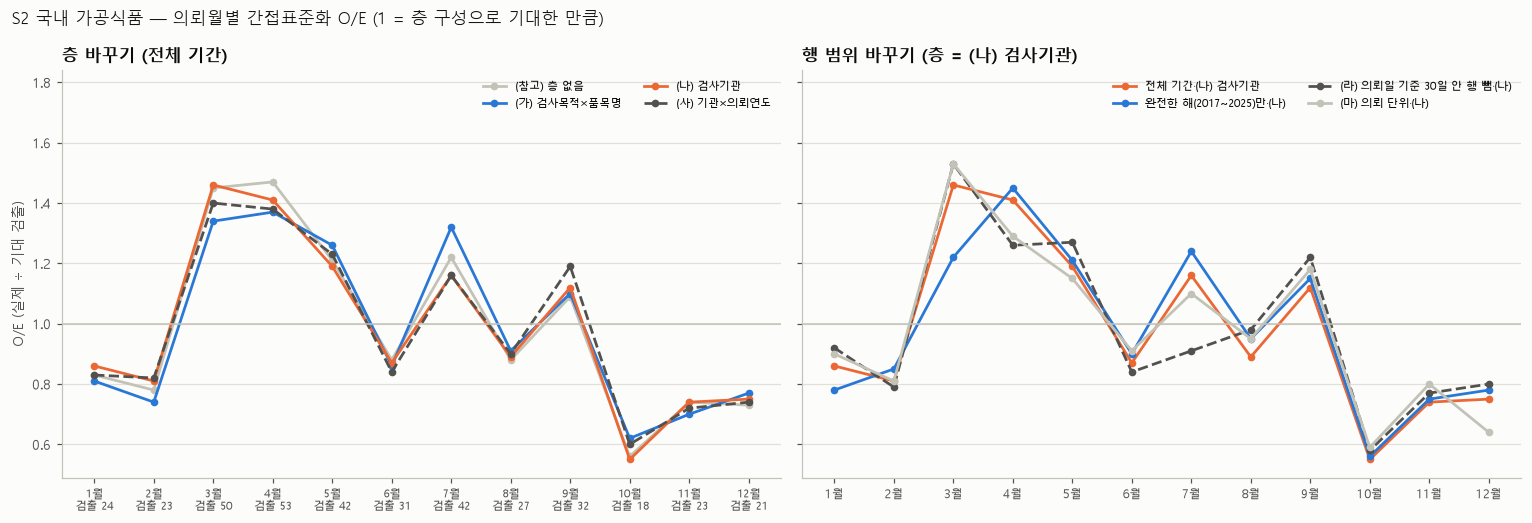

In [125]:
# [10-2 계속] 간접표준화 O/E — 6-4 방식. 층별 검출률을 각 행에 주고 달(계절)별로 더한 것 = 기대 검출 (층·행 범위는 작성자 임의)
#   E_m = Σ_{행 i ∈ 칸 m} p_{층(i)},  p_층 = (그 행 범위 안) 층 검출 수 / 층 행 수,  O/E = O_m / E_m
#   층 없음: p = 범위 전체 검출률 → O/E = 칸 검출률 ÷ 범위 전체 검출률 (층을 나눈 결과와 견줄 기준)
#   참고 검정(작성자 임의 근사): X² = Σ_m (O_m − E_m)² / E_m, 자유도 = 칸 수 − 1. 층 검출률을 같은 자료로 추정했으므로 정확한 분포가 아니며 참고용
#   층이 잘게 나뉠수록(특히 한 칸에만 행이 있는 층) O 와 E 가 같아져 O/E 가 1 로 당겨짐 → 그런 층의 행 수를 함께 적음
#   행 범위를 바꾼 변형은 층 검출률도 그 범위 안에서 다시 계산함


def _gser(a, x, eps=1e-15, itmax=10000):
    ap, term = a, 1.0 / a
    s = term
    for _ in range(itmax):
        ap += 1.0
        term *= x / ap
        s += term
        if abs(term) < abs(s) * eps:
            break
    return s * math.exp(-x + a * math.log(x) - math.lgamma(a))


def _gcf(a, x, eps=1e-15, itmax=10000):
    tiny = 1e-300
    b = x + 1.0 - a
    c, d = 1.0 / tiny, 1.0 / b
    h = d
    for i in range(1, itmax + 1):
        an = -i * (i - a)
        b += 2.0
        d = an * d + b
        d = tiny if abs(d) < tiny else d
        c = b + an / c
        c = tiny if abs(c) < tiny else c
        d = 1.0 / d
        h *= d * c
        if abs(d * c - 1.0) < eps:
            break
    return math.exp(-x + a * math.log(x) - math.lgamma(a)) * h


def chi2_sf10(x2, df):
    '''카이제곱 꼬리확률 = Q(df/2, x2/2) (정규화 상부 불완전 감마; 급수 / 연분수 — 6-5 와 같은 식)'''
    a, x = df / 2.0, x2 / 2.0
    if x <= 0:
        return 1.0
    return 1.0 - _gser(a, x) if x < a + 1.0 else _gcf(a, x)


def oe_by(pos, strata, cell):
    '''칸(cell)별 O/E. pos·strata·cell 은 같은 인덱스의 Series, strata=None 이면 층 없음. 반환: (O/E Series, 정보 dict)'''
    if strata is None:
        p = pd.Series(float(pos.mean()), index=pos.index)
        n_str, n_single, rows_single = 1, 0, 0
    else:
        p = pos.groupby(strata).transform('mean')
        nc = cell.groupby(strata).nunique()
        single = nc.index[nc.eq(1)]
        n_str, n_single, rows_single = int(strata.nunique()), len(single), int(strata.isin(single).sum())
    O = pos.groupby(cell).sum()
    E = p.groupby(cell).sum()
    x2 = float((((O - E) ** 2) / E).sum())
    r = O / E
    return r, {'행(의뢰) 수': len(pos), '검출': int(pos.sum()), '층 수': n_str, '한 칸에만 행이 있는 층': n_single, '그 층의 행 수': rows_single,
               'X²(참고)': round(x2, 2), '자유도': len(O) - 1, 'p(근사, 참고)': f'{chi2_sf10(x2, len(O) - 1):.3g}',
               'O/E 범위': f'{r.min():.2f} ~ {r.max():.2f}', '최고/최저 비': f'{r.max() / r.min():.2f}배'}


# 연도 구성 참고: 앞뒤가 잘린 해, 연도 × 의뢰월 검출 수
for y_ in [int(d1['연'].min()), int(d1['연'].max())]:
    _my = d1['연'].eq(y_)
    _ms = sorted(d1.loc[_my, '의뢰월'].unique())
    print(f"S2 {y_}년: 의뢰월 {_ms[0]}~{_ms[-1]}월, 행 {int(_my.sum()):,} / 검출 {int(d1.loc[_my, 'pos'].sum())}, "
          f"달별 행 수 {d1.loc[_my, '의뢰월'].value_counts().sort_index().to_dict()}")
print('[S2] 의뢰연도 × 의뢰월 검출 수 (<NA> = 그 연·월에 행 없음)')
display(d1.pivot_table(index='연', columns='의뢰월', values='pos', aggfunc='sum').astype('Int64'))
_m26 = d1['pos'].eq(1) & d1['연'].eq(2026) & d1['의뢰월'].eq(3)
print(f"S2 2026년 3월 검출 {int(_m26.sum())}건: 품목명 {d1.loc[_m26, '품목명'].value_counts().to_dict()}, 검사목적 {d1.loc[_m26, '검사목적'].value_counts().to_dict()}, "
      f"서로 다른 주소 {d1.loc[_m26, 'addr'].nunique()}곳, 기관 {d1.loc[_m26, '기관'].nunique()}곳, 10-1 의뢰일 기준 30일 안 표시 {int(d1.loc[_m26, 'fu30'].sum())}건")

# S2 의뢰월 12칸 — 층 바꾸기 (전체 기간)
_pm1 = d1['검사목적'].astype(str)
_tn1 = d1['train_prdlst_nm'].astype('string').astype(str)
_y1 = d1['연'].astype(str)
STRATA_G1 = {'(참고) 층 없음': None, '(가) 검사목적×품목명': _pm1 + '|' + _tn1, '(나) 검사기관': d1['기관'],
             '(다) 기관×검사목적×품목명': d1['기관'] + '|' + _pm1 + '|' + _tn1, '(바) 의뢰연도': _y1, '(사) 기관×의뢰연도': d1['기관'] + '|' + _y1}
_oe, _info = {}, {}
for nm_, st in STRATA_G1.items():
    r, info = oe_by(d1['pos'], st, d1['의뢰월'])
    _oe[nm_], _info[nm_] = r.round(2), info
oe10_month = pd.DataFrame(_oe)
oe10_month.insert(0, '실제 검출', d1.groupby('의뢰월')['pos'].sum())
oe10_month.insert(1, '행 수', d1.groupby('의뢰월').size())
oe10_month.index.name = '의뢰월'
oe10_month_info = pd.DataFrame(_info).T
print('[S2 국내 가공식품] 의뢰월 12칸 O/E — 층 바꾸기 (전체 기간)')
display(oe10_month)
display(oe10_month_info)

# S2 의뢰월 12칸 — 행 범위 바꾸기
_full1 = d1['연'].between(2017, 2025)
_f1, _fc1 = d1['fu30'], d1['fu30c']
print(f"완전한 해(2017~2025)만: 뺀 행 {int((~_full1).sum()):,} / 검출 {int(d1.loc[~_full1, 'pos'].sum())} (2016·2026년)")
for _lb, _ff in [('(라) 의뢰일 기준 30일 안 행(업체키 또는 주소 키)', _f1), ("(라') 검사완료일 기준 30일 안 행(업체키 또는 주소 키)", _fc1)]:
    print(f"{_lb}: 뺀 행 {int(_ff.sum()):,} / 검출 {int(d1.loc[_ff, 'pos'].sum())} — 그 검출의 의뢰월별 수 "
          f"{d1.loc[_ff & d1['pos'].eq(1), '의뢰월'].value_counts().sort_index().to_dict()}")
_short = {'(참고) 층 없음': '층 없음', '(가) 검사목적×품목명': '(가)', '(나) 검사기관': '(나)'}
_oe, _info = {}, {}
for r_nm, msk in [('완전한 해만', _full1), ('(라)', ~_f1), ("(라')", ~_fc1)]:
    sub = d1[msk]
    for s_nm, s_short in _short.items():
        st = STRATA_G1[s_nm]
        r, info = oe_by(sub['pos'], None if st is None else st[msk], sub['의뢰월'])
        info.update({'뺀 행': int((~msk).sum()), '뺀 검출': int(d1.loc[~msk, 'pos'].sum())})
        _oe[f'{r_nm}·{s_short}'], _info[f'{r_nm}·{s_short}'] = r.round(2), info
q1 = d1.groupby('의뢰키').agg(pos=('pos', 'max'), 의뢰월=('의뢰월', 'min'), 월수=('의뢰월', 'nunique'), 기관=('기관', 'first'), 기관수=('기관', 'nunique'))
print(f"(마) 의뢰 단위: 의뢰 {len(q1):,}개, 검출 의뢰 {int(q1['pos'].sum())}, 의뢰월이 둘 이상인 의뢰 {int(q1['월수'].gt(1).sum())}, "
      f"검사기관이 둘 이상인 의뢰 {int(q1['기관수'].gt(1).sum())}")
for s_short, st in [('층 없음', None), ('(나)', q1['기관'])]:
    r, info = oe_by(q1['pos'], st, q1['의뢰월'])
    info.update({'뺀 행': 0, '뺀 검출': 0})
    _oe[f'(마) 의뢰 단위·{s_short}'], _info[f'(마) 의뢰 단위·{s_short}'] = r.round(2), info
oe10_month_range = pd.DataFrame(_oe)
oe10_month_range.index.name = '의뢰월'
oe10_month_range_info = pd.DataFrame(_info).T
print('[S2 국내 가공식품] 의뢰월 12칸 O/E — 행 범위 바꾸기')
display(oe10_month_range)
display(oe10_month_range_info)

# 7월 검출이 어디서 나왔나 — 같은 주소·같은 연월 3건 이상 묶음 (주소는 앞 두 단어만 표시)
_m7 = d1['pos'].eq(1) & d1['의뢰월'].eq(7)
_ym1 = d1['reqest_de'].dt.strftime('%Y-%m')
_adr1 = d1['addr'].astype(str)
_g7 = d1.loc[_m7].groupby([_adr1[_m7], _ym1[_m7]]).size()
print(f"S2 7월 검출 {int(_m7.sum())}건 중 (라) 의뢰일 기준 30일 안 표시 {int((_m7 & _f1).sum())}건. 같은 주소·같은 연월 3건 이상 묶음 {int((_g7 >= 3).sum())}개:")
for (a_, ym_), c_ in _g7[_g7 >= 3].items():
    s_ = d1.loc[_m7 & _adr1.eq(a_) & _ym1.eq(ym_)]
    print(f"  주소 앞 두 단어 '{' '.join(a_.split()[:2])}' {ym_}: {c_}건, 기관 {s_['기관'].value_counts().to_dict()}, 품목명 {s_['품목명'].value_counts().to_dict()}, "
          f"의뢰일 {s_['reqest_de'].dt.strftime('%m-%d').value_counts().sort_index().to_dict()}, 30일 안 표시 {int(s_['fu30'].sum())}건")

# 비가열(임시) 의뢰 계절 4칸
SEASON10 = {3: '봄(3~5월)', 4: '봄(3~5월)', 5: '봄(3~5월)', 6: '여름(6~8월)', 7: '여름(6~8월)', 8: '여름(6~8월)',
            9: '가을(9~11월)', 10: '가을(9~11월)', 11: '가을(9~11월)', 12: '겨울(12~2월)', 1: '겨울(12~2월)', 2: '겨울(12~2월)'}
SEASONS10 = ['봄(3~5월)', '여름(6~8월)', '가을(9~11월)', '겨울(12~2월)']
_se2 = d2['의뢰월'].map(SEASON10)
_y2 = d2['연'].astype(str)
_all2 = pd.Series(True, index=d2.index)
_full2 = d2['연'].between(2017, 2025)
VARIANTS_G2 = {'(참고) 층 없음': (_all2, None), "(가') 검사목적×품목명": (_all2, d2['검사목적'].astype(str) + '|' + d2['품목명'].astype(str)),
               '(나) 검사기관': (_all2, d2['기관']), '(바) 의뢰연도': (_all2, _y2), '(사) 기관×의뢰연도': (_all2, d2['기관'] + '|' + _y2),
               '완전한 해만·층 없음': (_full2, None), '완전한 해만·(나)': (_full2, d2['기관']),
               '(라)·층 없음': (~d2['fu30'], None), '(라)·(나)': (~d2['fu30'], d2['기관'])}
_oe, _info = {}, {}
for v_nm, (msk, st) in VARIANTS_G2.items():
    sub = d2[msk]
    r, info = oe_by(sub['pos'], None if st is None else st[msk], _se2[msk])
    info.update({'뺀 행': int((~msk).sum()), '뺀 검출': int(d2.loc[~msk, 'pos'].sum())})
    _oe[v_nm], _info[v_nm] = r.reindex(SEASONS10).round(2), info
oe10_season_g2 = pd.DataFrame(_oe)
_g2s = d2.groupby(_se2)['pos'].agg(['sum', 'size']).reindex(SEASONS10)
oe10_season_g2.insert(0, '실제 검출', _g2s['sum'])
oe10_season_g2.insert(1, '행 수', _g2s['size'])
oe10_season_g2.insert(2, '검출률(%)', (_g2s['sum'] / _g2s['size'] * 100).round(3))
oe10_season_g2.index.name = '의뢰 계절'
oe10_season_g2_info = pd.DataFrame(_info).T
print('[비가열 식육 후보(임시)] 의뢰 계절 4칸 O/E (완전한 해만·(라) 변형은 그 범위 안에서 다시 계산)')
display(oe10_season_g2)
display(oe10_season_g2_info)
_b2 = d2['pos'].eq(1) & _se2.eq('봄(3~5월)')
print(f"비가열(임시) 봄 검출 {int(_b2.sum())}건의 의뢰연도별 수: {d2.loc[_b2, '연'].value_counts().sort_index().to_dict()} "
      f"(2026년은 의뢰월 {int(d2.loc[d2['연'].eq(2026), '의뢰월'].min())}~{int(d2.loc[d2['연'].eq(2026), '의뢰월'].max())}월만 있음)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
_m12 = list(range(1, 13))
ax = axes[0]
for nm_, col, ls in [('(참고) 층 없음', GRAY, '-'), ('(가) 검사목적×품목명', C1, '-'), ('(나) 검사기관', C2, '-'), ('(사) 기관×의뢰연도', INK2, '--')]:
    ax.plot(_m12, oe10_month[nm_].reindex(_m12).to_numpy(float), marker='o', ms=4, color=col, ls=ls, lw=1.8, label=nm_)
ax.set_title('층 바꾸기 (전체 기간)')
ax.set_xticks(_m12)
ax.set_xticklabels([f'{m_}월\n검출 {k}' for m_, k in zip(_m12, oe10_month['실제 검출'].reindex(_m12))], fontsize=7.5)
ax = axes[1]
for nm_, lab, col, ls in [(None, '전체 기간·(나) 검사기관', C2, '-'), ('완전한 해만·(나)', '완전한 해(2017~2025)만·(나)', C1, '-'),
                          ('(라)·(나)', '(라) 의뢰일 기준 30일 안 행 뺌·(나)', INK2, '--'), ('(마) 의뢰 단위·(나)', '(마) 의뢰 단위·(나)', GRAY, '-')]:
    v = (oe10_month['(나) 검사기관'] if nm_ is None else oe10_month_range[nm_]).reindex(_m12).to_numpy(float)
    ax.plot(_m12, v, marker='o', ms=4, color=col, ls=ls, lw=1.8, label=lab)
ax.set_title('행 범위 바꾸기 (층 = (나) 검사기관)')
ax.set_xticks(_m12)
ax.set_xticklabels([f'{m_}월' for m_ in _m12], fontsize=8)
_vals = np.concatenate([oe10_month.drop(columns=['실제 검출', '행 수']).to_numpy(float).ravel(), oe10_month_range.to_numpy(float).ravel()])
for ax in axes:
    ax.axhline(1, color=GRAY, lw=1)
    ax.set_ylim(min(0.5, np.nanmin(_vals) - 0.05), np.nanmax(_vals) + 0.3)
    ax.legend(loc='upper right', fontsize=7.5, ncol=2)
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel('O/E (실제 ÷ 기대 검출)')
fig.suptitle('S2 국내 가공식품 — 의뢰월별 간접표준화 O/E (1 = 층 구성으로 기대한 만큼)', fontsize=11, x=0.01, ha='left')
plt.tight_layout()
plt.show()

📊 **결과**
- 기관 정보 파일 285곳, 학습용 데이터의 기관 코드 270곳은 모두 파일에 있습니다. 유형 라벨(작성자 임의): 민간·대학·기타 249, 지자체 기관 28, 식약처 지방청 8. 주소에 '공장'이 들어간 기관 2곳(식품 회사 공장 주소).
- **S2 국내 가공식품** (294,421행 / 검출 386): 기관 266곳, 검출 있는 기관 52곳.
  - 검출 상위 5곳 = 검출 47.7% / 행 9.4%. 비교 기준(기관 차이가 없다고 둔 다항 모의): 상위 5곳 검출 비중 평균 20.3%, 99백분위 24.6%. 행 상위 5곳 = 행 18.7% / 검출 6.2%.
  - 95% CI 가 전체율(0.131%)보다 위인 기관 12곳(행 38,898, 검출 240), 아래인 기관 13곳(행 79,054, 검출 4). 비교 기준(모든 기관 검출률이 같다고 둔 이항 기대): 'CI 위' 12.2곳(±2SD 6.7), 'CI 아래' 0.4곳(±2SD 1.3).
  - 1위 O000044(이름 'Traditional Microorganism…', 기관 주소 첫 단어 '대구시'): 5,963행 / 72 (1.207%, CI 0.960\~1.518) = S2 검출의 18.7%. 다음 O000084 40/6,859 (0.583%), O000146 제주특별자치도 동물위생시험소 31/4,668 (0.664%), O000108 경기도 동물위생시험소 22/2,750 (0.800%).
  - 유형별: 지자체 기관 행 16.4% · 검출 25.6%, 민간·대학·기타 행 79.7% · 검출 71.0%, 식약처 지방청 행 3.9% · 검출 3.4%.
- **비가열 식육 후보(임시)** (26,055행 / 검출 192; 포장육 2,668/101, 양념육 21,956/87, 생햄 1,431/4; 해외 2,015행·검출 17 뺌): 기관 106곳, 검출 있는 기관 38곳. 검출 상위 5곳 = 검출 65.1% / 행 16.0% (모의 평균 32.0%, 99백분위 39.1%). CI 위 10곳(행 4,421, 검출 138)·아래 8곳(행 9,287, 검출 2), 이항 기대 위 5.1곳(±2SD 4.4)·아래 0.2곳(±2SD 1.0). O000044 가 1,523행 / 62 (4.071%) = 비가열(임시) 검출의 32.3%.
- **달별 행 비중** (S2 검출 상위 5 기관): O000044 1.8\~2.4%, O000084 1.7\~2.8%, O000146 1.4\~1.8%, O000033 2.3\~2.9% 로 폭이 작고, O000108(경기도 동물위생시험소)만 0.5%(2월) \~ 1.4%(5월)로 봄에 늘어납니다. 달별 검출은 O000044 7월 13건·3월 10건, O000146 7월 9건·3월 8건, O000084 4월 9건.
- **연도 구성**: S2 2016년은 의뢰월 3\~12월(7월 971행), 2026년은 1\~7월(7월 6행)만 있습니다. 3월 검출 50건 중 12건이 2026년 3월입니다(포장육 10건, 수거검사 6건, 서로 다른 주소 11곳, 30일 안 표시 1건).
- **S2 의뢰월 O/E — 층 바꾸기** (3월 · 4월 · 7월 · 10월, 참고 p):
  - 층 없음 1.45 · 1.47 · 1.22 · 0.56 (p 0.000744) / (가) 검사목적×품목명(6-4 재현, 층 131) 1.34 · 1.37 · 1.32 · 0.62 (p 0.00345) / (나) 검사기관(층 266) 1.46 · 1.41 · 1.16 · 0.55 (p 0.00208)
  - (다) 기관×검사목적×품목명(층 2,038, 한 달에만 행이 있는 층 421곳·1,179행) 1.35 · 1.31 · 1.17 · 0.68 (p 0.0131) / (바) 의뢰연도 1.42 · 1.45 · 1.24 · 0.57 (p 0.00119) / (사) 기관×의뢰연도(층 1,805, 한 달에만 행이 있는 층 83곳·197행) 1.40 · 1.38 · 1.16 · 0.60 (p 0.00412)
  - (가)의 달별 값은 6-4 와 같습니다 (6-4 의 '2.21배'는 반올림한 O/E 끼리 나눈 값이라 여기 2.20배와 조금 다름).
- **S2 의뢰월 O/E — 행 범위 바꾸기** (3월 · 4월 · 7월 · 10월):
  - 완전한 해(2017\~2025)만 (20,780행·검출 31 뺌): 층 없음 1.24 · 1.54 · 1.28 · 0.55 / (가) 1.17 · 1.47 · 1.35 · 0.60 / (나) 1.22 · 1.45 · 1.24 · 0.56 (p 0.015)
  - (라) 의뢰일 기준 30일 안 행 뺌 (828행·검출 43, 그중 7월 13건): 층 없음 1.53 · 1.31 · 0.95 · 0.59 / (가) 1.41 · 1.24 · 1.01 · 0.65 / (나) 1.53 · 1.26 · 0.91 · 0.58 (p 0.0112). (라') 검사완료일 기준 (736행·검출 43 뺌): (나) 1.54 · 1.26 · 0.90 · 0.54
  - (마) 의뢰 단위 (의뢰 209,155개, 검출 의뢰 360): 층 없음 1.53 · 1.33 · 1.15 · 0.60 / (나) 1.53 · 1.29 · 1.10 · 0.59 (p 0.00789)
- **7월 검출 42건** 중 13건이 의뢰일 기준 30일 안 표시이고, 같은 주소·같은 연월 3건 이상 묶음은 1개입니다: 제주특별자치도 서귀포시의 한 주소, 2022년 7월 6건(기관 O000146, 소시지 5·베이컨류 1, 7월 5일 4건, 6건 모두 30일 안 표시).
- **비가열(임시) 의뢰 계절**: 봄 1.192%(86/7,214) · 여름 0.614% · 가을 0.543% · 겨울 0.528%. 봄 · 겨울 O/E: 층 없음 1.62 · 0.72 / (가') 1.30 · 0.79 / (나) 1.47 · 0.71 (p 0.00023) / (바) 1.57 · 0.71 / (사) 1.35 · 0.73 / 완전한 해만·(나) 1.47 · 0.72 / (라)·(나) 1.46 · 0.73. 봄 검출 86건 중 2024년 20건, 2026년(1\~6월) 14건.

💬 **첨언**
- 작성자가 기관별로 나눠 본 결과, 검출은 몇몇 기관에 몰려 있어 보입니다 (추정). 상위 5곳 검출 비중(S2 47.7%, 비가열(임시) 65.1%)은 기관 차이가 없다고 둔 모의의 99백분위(24.6%, 39.1%)보다 높습니다. 다만 기관마다 맡는 품목·업체·지역·검사 사업이 달라, 이 차이가 **시험법 차이인지 맡은 시료 차이인지는 이 데이터로 나누기 어렵습니다.**
- "95% CI 가 전체율보다 위인 기관" 수(S2 12곳)는 기관 차이가 없어도 기대되는 수(12.2곳)와 같아, **그 수만으로는 근거가 되지 않아 보입니다.** 검출이 드물어 행이 적은 기관도 검출 한두 건으로 'CI 위'가 되기 때문입니다. 오히려 **행이 많은데 검출이 거의 없는 기관**('CI 아래' 13곳, 행 79,054·검출 4, 기대 0.4곳)이 우연으로 보기 어려운 쪽입니다 (추정). 이 기관들이 시험법 민감도가 낮은지, 검출이 드문 품목·업체를 맡는지는 알 수 없습니다.
- O000044 한 곳이 비가열(임시) 검출의 32.3%(62건)입니다. 비가열 식육 후보를 따로 범위로 둔다면, 이 기관이 맡은 업체·의뢰를 먼저 확인할 필요가 있어 보입니다 (추정).
- **달 모양과 검사기관**: 검사기관 층 (나)의 O/E 는 층 없음과 거의 같습니다 (3월 1.45→1.46, 4월 1.47→1.41, 7월 1.22→1.16, 10월 0.56→0.55). 기관 구성은 달 모양을 거의 바꾸지 않아, **기관 구성이 달별 차이를 만든 것으로는 보이지 않습니다** (추정). 주요 기관의 달별 행 비중도 크게 흔들리지 않습니다(경기도 동물위생시험소 제외).
- **달 모양은 행 범위에 따라 흔들립니다** (추정):
  - 10월 낮음(0.54\~0.68)과 4월 높음(1.24\~1.54)은 이 절의 모든 변형에서 남았습니다.
  - 3월 높음은 2026년 3월 검출 12건에 크게 기대 보입니다. 완전한 해만 보면 3월은 1.17\~1.24 입니다. 연도 층((바)·(사))으로 맞춰도 1.40\~1.42 로 남는 것은 2026년 안에서도 3월에 검출이 몰렸기 때문으로 보입니다. 이 12건은 서로 다른 주소 11곳에 걸쳐 있고 포장육(10건)·수거검사(6건)가 많아, 같은 곳 몰림보다는 그달의 검사 사업과 겹쳐 보입니다 (추정).
  - 7월 높음은 같은 곳 30일 안 검출(13건, 그중 제주 한 주소 2022년 7월 6건)에 크게 기대 보입니다. 이 행들을 빼면 7월은 0.90\~1.01 로 기대만큼이 되고, 의뢰 단위로 세면 1.10\~1.15 입니다. 반대로 완전한 해만 보면 7월이 1.24\~1.35 로 오히려 높아지는데, 2016년 7월(971행, 검출 0)이 빠지기 때문으로 보입니다.
  - 그래서 6-4 의 '3월 1.34·7월 1.32'는 부분 연도(2016·2026)와 같은 곳 몰림이 섞인 값으로 읽는 편이 안전해 보입니다. 7절의 기온 양의 계수를 해석할 때도 이런 몰림이 섞였을 수 있습니다.
- (다)·(사)처럼 층을 잘게 나누면 한 달에만 행이 있는 층(1,179행·197행)은 실제와 기대가 같아져 O/E 가 1 쪽으로 당겨집니다.
- 비가열(임시) 봄 높음은 이 절의 모든 변형에서 1.30\~1.62 로 남았습니다. 검사목적×품목명(1.30)이나 기관×연도(1.35)로 맞추면 작아집니다. 비가열(임시)은 계절마다 검출 33\~86건이라 흔들림이 큽니다.
- p값은 층 검출률을 같은 자료로 추정한 근사이고, 여러 변형을 함께 보았으므로 참고용입니다.

### 10-3. 기관과 지역·계절의 겹침 — 7-5 에서 기관 군집을 쓸 때의 해석 재료

🔎 검사기관이 특정 시도·특정 달에 몰려 있으면, "기관 효과"와 "지역·계절(기상) 효과"를 데이터로 나누기 어렵습니다. 이 소절은 **겹침의 크기만 계산**하고 회귀는 하지 않습니다.

**방법 (작성자 임의)**
- 범위: S2 국내 가공식품. 시도 = `legal_dong_code` 앞 2자리(7-5-1 과 같음). 시도 이름은 그 코드 행들의 주소 첫 단어 중 가장 흔한 것(표시용 라벨).
- 기관별 시도 집중: 시도 수, 1위 시도 비중, HHI(= Σ 시도 비중², 1 이면 한 시도에만 있음).
- 겹침 요약: "기관을 알면 시도를 맞힐 수 있는 비율" = Σ_기관 (그 기관 1위 시도 행 수) ÷ 전체 행, 반대로 "시도를 알면 기관을 맞힐 수 있는 비율". 비교 기준 = 기관(시도)을 모를 때 가장 흔한 시도(기관) 하나로 맞히는 비율.
- 기관별 달 분포: S2 전체 달 분포와의 차이 = TVD(½ Σ_달 |기관 비중 − 전체 비중|). 행 수가 적으면 우연으로도 커지므로, 전체 달 분포에서 같은 수를 뽑는 모의실험(기관마다 200회)의 평균·95백분위와 비교합니다.

**비교할 변형 목록 (결과보다 먼저 적음)** — 달 TVD 우연 기준
1. 행 단위, 전체 기간 (seed 10)
2. 행 단위, 완전한 해(2017\~2025)만 (seed 12) — 앞뒤가 잘린 해가 달 분포 차이를 만드는지
3. 의뢰 단위(의뢰키 하나 = 1, 의뢰월 = 가장 이른 달), 전체 기간 (seed 13) — 한 의뢰의 여러 행은 같은 달이라, 행 단위 모의는 우연 흔들림을 작게 잡을 수 있음
- 세 변형 모두 "행 1,000 이상 기관"은 전체 기간 S2 행 수로 정한 같은 기관 묶음을 씁니다(2번은 그 기관들 중 2017\~2025 행이 있는 곳).

In [126]:
# [10-3] S2 국내 가공식품: 기관 × 시도, 기관 × 달 겹침 (계산만, 회귀 없음)
sido10 = d1['legal_dong_code'].astype(str).str[:2]
print(f"시도 코드 없는 행: {int(d1['legal_dong_code'].isna().sum()):,}")
_tok = d1['addr'].astype(str).str.split().str[0]
SIDO_NAME10 = pd.crosstab(sido10, _tok).idxmax(axis=1).to_dict()          # 표시용 라벨
print('시도 코드 → 이름(주소 첫 단어 최빈값):', SIDO_NAME10)
sname = sido10.map(SIDO_NAME10)

ct_is = pd.crosstab(d1['기관'], sname)                  # 기관 × 시도 행 수
ct_im = pd.crosstab(d1['기관'], d1['의뢰월'])            # 기관 × 달 행 수
n_i = ct_is.sum(axis=1)
sh_is = ct_is.div(n_i, axis=0)
hhi_i = (sh_is ** 2).sum(axis=1)
N1 = len(d1)
p_all_m = (d1['의뢰월'].value_counts(normalize=True).sort_index()).reindex(range(1, 13)).to_numpy()
sh_im = ct_im.reindex(columns=range(1, 13)).div(ct_im.sum(axis=1), axis=0).to_numpy()
tvd_i = 0.5 * np.abs(sh_im - p_all_m).sum(axis=1)
rng10 = np.random.default_rng(10)
sim_mean, sim_p95 = [], []
for n in ct_im.sum(axis=1).to_numpy():
    sims = rng10.multinomial(int(n), p_all_m, size=200) / n
    tv = 0.5 * np.abs(sims - p_all_m).sum(axis=1)
    sim_mean.append(tv.mean())
    sim_p95.append(np.percentile(tv, 95))
sim_mean, sim_p95 = np.array(sim_mean), np.array(sim_p95)
yr_i = d1.groupby('기관')['연'].agg(['min', 'max', 'nunique'])
kpos_i = d1.groupby('기관')['pos'].sum()

inst_overlap_tbl = pd.DataFrame({
    '기관 이름': INSTT_INFO['기관 이름'].reindex(ct_is.index), '기관 주소 첫 단어': INSTT_INFO['기관 주소 첫 단어'].reindex(ct_is.index),
    '행 수': n_i, '검출': kpos_i.reindex(ct_is.index), '시도 수': (ct_is > 0).sum(axis=1),
    '1위 시도': sh_is.idxmax(axis=1), '1위 시도 비중(%)': (sh_is.max(axis=1) * 100).round(1), '시도 HHI': hhi_i.round(2),
    '달 TVD': np.round(tvd_i, 3), '달 TVD 우연 평균': np.round(sim_mean, 3), '달 TVD 우연 95백분위': np.round(sim_p95, 3),
    '가장 많은 달(비중%)': [f'{int(ct_im.columns[j])}월 {sh_im[i, j] * 100:.1f}' for i, j in enumerate(np.nanargmax(sh_im, axis=1))],
    '의뢰 연도': [f'{a}~{b}' for a, b in zip(yr_i['min'].reindex(ct_is.index), yr_i['max'].reindex(ct_is.index))],
    '연도 수': yr_i['nunique'].reindex(ct_is.index)})
inst_overlap_tbl.index.name = '기관 코드'
inst_overlap_tbl = inst_overlap_tbl.sort_values('행 수', ascending=False)
print('[기관별] 행 수 상위 15')
display(inst_overlap_tbl.head(15))

# 겹침 요약
acc_i2s = ct_is.max(axis=1).sum() / N1
base_s = sname.value_counts(normalize=True).iloc[0]
acc_s2i = ct_is.max(axis=0).sum() / N1
base_i = d1['기관'].value_counts(normalize=True).iloc[0]
print(f'기관 → 시도 맞힘 비율 {acc_i2s * 100:.1f}% (기관 모를 때 최다 시도 {sname.value_counts().index[0]} 하나로 맞힘 {base_s * 100:.1f}%)')
print(f'시도 → 기관 맞힘 비율 {acc_s2i * 100:.1f}% (시도 모를 때 최다 기관 하나로 맞힘 {base_i * 100:.1f}%)')
print(f"행 가중 평균 시도 HHI {float((hhi_i * n_i).sum() / N1):.2f} (기관 구분 없이 S2 전체 시도 HHI {float((sname.value_counts(normalize=True) ** 2).sum()):.2f})")
_w = ct_im.sum(axis=1).to_numpy()
_tvd_w = float((tvd_i * _w).sum() / _w.sum())
print(f'[변형 1: 행 단위·전체 기간] 행 가중 평균 달 TVD {_tvd_w:.3f} (같은 행 수 모의실험 평균의 행 가중 평균 {float((sim_mean * _w).sum() / _w.sum()):.3f}) '
      f'— 뜻: 기관 행의 {_tvd_w * 100:.1f}% 를 다른 달로 옮기면 전체 달 분포와 같아지는 정도')
big = inst_overlap_tbl['행 수'] >= 1000
over = inst_overlap_tbl['달 TVD'] > inst_overlap_tbl['달 TVD 우연 95백분위']
print(f"  행 1,000 이상 기관 {int(big.sum())}곳 중 달 TVD 가 우연 95백분위를 넘는 기관 {int((big & over).sum())}곳 "
      f"(그 기관들 행 {int(inst_overlap_tbl.loc[big & over, '행 수'].sum()):,} = S2 의 {inst_overlap_tbl.loc[big & over, '행 수'].sum() / N1 * 100:.1f}%, "
      f"검출 {int(inst_overlap_tbl.loc[big & over, '검출'].sum())})")
print(f"  전체 기관 {len(inst_overlap_tbl)}곳 중 우연 95백분위를 넘는 기관 {int(over.sum())}곳 (여러 기관을 한꺼번에 본 것이라 우연히도 5% 쯤은 넘음)")
BIG_INST10 = list(inst_overlap_tbl.index[big])


def tvd_vs_chance(inst, month, seed, sims=200):
    '''기관별 달 분포와 그 범위 전체 달 분포의 TVD, 같은 수를 전체 달 분포에서 뽑는 다항 모의 sims 회의 평균·95백분위 (작성자 임의)'''
    ct = pd.crosstab(inst, month)
    assert list(ct.columns) == list(range(1, 13)), '12개 달이 모두 있어야 함'
    n_ = ct.sum(axis=1).to_numpy()
    p_ = ct.sum(axis=0).to_numpy() / n_.sum()
    sh = ct.to_numpy() / n_[:, None]
    tvd = 0.5 * np.abs(sh - p_).sum(axis=1)
    rng = np.random.default_rng(seed)
    mean_, p95_ = np.empty(len(n_)), np.empty(len(n_))
    for i, nn in enumerate(n_):
        tv = 0.5 * np.abs(rng.multinomial(int(nn), p_, size=sims) / nn - p_).sum(axis=1)
        mean_[i], p95_[i] = tv.mean(), np.percentile(tv, 95)
    return pd.DataFrame({'n': n_, 'tvd': tvd, 'mean': mean_, 'p95': p95_}, index=ct.index)


_d1f = d1[d1['연'].between(2017, 2025)]
print(f"[변형 2 준비] 완전한 해(2017~2025)만: 2016·2026년 {len(d1) - len(_d1f):,}행 뺌 / [변형 3 준비] 의뢰 단위: 행을 의뢰 {len(q1):,}개로 묶음(뺀 행 0)")
for v_nm, res, unit in [('변형 2: 행 단위·완전한 해(2017~2025)만', tvd_vs_chance(_d1f['기관'], _d1f['의뢰월'], seed=12), '행'),
                        ('변형 3: 의뢰 단위·전체 기간', tvd_vs_chance(q1['기관'], q1['의뢰월'], seed=13), '의뢰')]:
    wv = res['n'].to_numpy()
    rb = res.loc[res.index.isin(BIG_INST10)]
    print(f"[{v_nm}] {unit} 가중 평균 달 TVD {float((res['tvd'] * wv).sum() / wv.sum()):.3f} (우연 평균 {float((res['mean'] * wv).sum() / wv.sum()):.3f}); "
          f"행 1,000 이상 기관 중 이 범위에 있는 {len(rb)}곳 가운데 우연 95백분위를 넘는 기관 {int((rb['tvd'] > rb['p95']).sum())}곳")
yrs_n = inst_overlap_tbl['연도 수']
_few = inst_overlap_tbl.loc[big & yrs_n.le(5)]
print(f"행 1,000 이상 기관의 활동 연도 수: 중앙값 {float(yrs_n[big].median()):.0f}, 5개 연도 이하 {len(_few)}곳 — "
      + ', '.join(f"{c} {r['의뢰 연도']}({int(r['연도 수'])}개 연도, {int(r['행 수']):,}행·검출 {int(r['검출'])})" for c, r in _few.iterrows()))

# 시도별 기관 집중
ct_si = ct_is.T
sido_inst_tbl = pd.DataFrame({'행 수': ct_si.sum(axis=1), '검출': d1.groupby(sname)['pos'].sum().reindex(ct_si.index),
                              '기관 수': (ct_si > 0).sum(axis=1), '1위 기관': ct_si.idxmax(axis=1),
                              '1위 기관 비중(%)': (ct_si.max(axis=1) / ct_si.sum(axis=1) * 100).round(1),
                              '상위 3 기관 비중(%)': (ct_si.apply(lambda r: np.sort(r.to_numpy())[::-1][:3].sum(), axis=1) / ct_si.sum(axis=1) * 100).round(1),
                              '기관 HHI': ((ct_si.div(ct_si.sum(axis=1), axis=0)) ** 2).sum(axis=1).round(2)})
sido_inst_tbl['1위 기관 이름'] = INSTT_INFO['기관 이름'].reindex(sido_inst_tbl['1위 기관']).to_numpy()
sido_inst_tbl.index.name = '시도'
print('[시도별] 기관 집중')
sido_inst_tbl.sort_values('행 수', ascending=False)

시도 코드 없는 행: 0
시도 코드 → 이름(주소 첫 단어 최빈값): {'11': '서울특별시', '26': '부산광역시', '27': '대구광역시', '28': '인천광역시', '29': '광주광역시', '30': '대전광역시', '31': '울산광역시', '36': '세종특별자치시', '41': '경기도', '43': '충청북도', '44': '충청남도', '46': '전라남도', '47': '경상북도', '48': '경상남도', '50': '제주특별자치도', '51': '강원도', '52': '전라북도'}
[기관별] 행 수 상위 15


,기관 이름,기관 주소 첫 단어,행 수,검출,시도 수,1위 시도,1위 시도 비중(%),시도 HHI,달 TVD,달 TVD 우연 평균,달 TVD 우연 95백분위,가장 많은 달(비중%),의뢰 연도,연도 수
기관 코드,,,,,,,,,,,,,,
O000026,"BIO FOOD LAB CO., LTD.",서울특별시,13480,15,17,경기도,40.5,0.25,0.020,0.012,0.015,3월 9.2,2016~2026,11
O000858,"Humanbio Co., Ltd.",충청남도,11395,0,15,경기도,31.1,0.21,0.041,0.012,0.017,3월 9.8,2020~2026,7
O000168,(주)세스코 시험분석연구원,서울특별시,10282,0,16,경기도,15.6,0.11,0.024,0.013,0.018,4월 8.9,2017~2026,10
O000027,Institute of Industrial Po,서울특별시,10116,3,17,경기도,39.6,0.21,0.040,0.013,0.019,3월 10.2,2017~2026,10
O000031,Korea Standard Test & Anal,경기도,9711,6,17,경기도,47.0,0.26,0.020,0.014,0.018,6월 9.2,2017~2026,10
O000024,DONGJIN INSTITUTE OF TECHN,경상남도,8345,1,15,경상남도,55.1,0.33,0.023,0.014,0.020,5월 9.1,2016~2026,11
O000083,한국에스지에스(주),경기도,7864,14,17,경기도,26.8,0.13,0.057,0.015,0.020,1월 10.5,2016~2026,11
O000001,KOTITI Testing & Research,경기도,7839,15,15,경기도,61.0,0.40,0.042,0.014,0.020,8월 10.1,2016~2026,11
O000392,"Central Life Lab Co.,Ltd.",경기도,7682,0,17,경기도,42.6,0.25,0.022,0.015,0.021,6월 9.5,2016~2026,11


기관 → 시도 맞힘 비율 60.7% (기관 모를 때 최다 시도 경기도 하나로 맞힘 28.2%)
시도 → 기관 맞힘 비율 16.6% (시도 모를 때 최다 기관 하나로 맞힘 4.6%)
행 가중 평균 시도 HHI 0.50 (기관 구분 없이 S2 전체 시도 HHI 0.13)
[변형 1: 행 단위·전체 기간] 행 가중 평균 달 TVD 0.061 (같은 행 수 모의실험 평균의 행 가중 평균 0.028) — 뜻: 기관 행의 6.1% 를 다른 달로 옮기면 전체 달 분포와 같아지는 정도
  행 1,000 이상 기관 73곳 중 달 TVD 가 우연 95백분위를 넘는 기관 59곳 (그 기관들 행 214,639 = S2 의 72.9%, 검출 295)
  전체 기관 266곳 중 우연 95백분위를 넘는 기관 124곳 (여러 기관을 한꺼번에 본 것이라 우연히도 5% 쯤은 넘음)
[변형 2 준비] 완전한 해(2017~2025)만: 2016·2026년 20,780행 뺌 / [변형 3 준비] 의뢰 단위: 행을 의뢰 209,155개로 묶음(뺀 행 0)
[변형 2: 행 단위·완전한 해(2017~2025)만] 행 가중 평균 달 TVD 0.062 (우연 평균 0.029); 행 1,000 이상 기관 중 이 범위에 있는 73곳 가운데 우연 95백분위를 넘는 기관 57곳
[변형 3: 의뢰 단위·전체 기간] 의뢰 가중 평균 달 TVD 0.061 (우연 평균 0.033); 행 1,000 이상 기관 중 이 범위에 있는 73곳 가운데 우연 95백분위를 넘는 기관 47곳
행 1,000 이상 기관의 활동 연도 수: 중앙값 10, 5개 연도 이하 4곳 — O000601 2017~2021(5개 연도, 1,774행·검출 1), O000692 2017~2021(5개 연도, 1,565행·검출 1), O000070 2016~2020(5개 연도, 1,469행·검출 3), O000176 2016~2020(5개 연도, 1,027행·검출 1)
[시도별] 기관 집중


,행 수,검출,기관 수,1위 기관,1위 기관 비중(%),상위 3 기관 비중(%),기관 HHI,1위 기관 이름
시도,,,,,,,,
경기도,82973,117,158,O000026,6.6,17.8,0.03,"BIO FOOD LAB CO., LTD."
충청북도,32901,42,110,O000026,10.6,20.7,0.03,"BIO FOOD LAB CO., LTD."
충청남도,26248,15,96,O000124,12.1,25.3,0.04,충청남도 동물위생시험소
경상남도,22769,8,85,O000024,20.2,41.6,0.09,DONGJIN INSTITUTE OF TECHN
전라북도,22560,12,87,O000130,22.9,46.8,0.10,전북특별자치도 동물위생시험소
서울특별시,16549,33,68,O000084,9.1,23.3,0.04,Intertek Testing Services
강원도,16426,6,75,O000113,21.3,43.4,0.09,강원특별자치도 동물위생시험소
경상북도,16105,54,86,O000138,24.2,48.5,0.10,경상북도 동물위생시험소
전라남도,11792,4,69,O000135,27.1,45.8,0.11,전라남도 축산위생사업소


📊 **결과**
- 시도 코드 17개, 시도 코드 없는 행 0. (코드 51·52 는 주소 첫 단어 최빈값이 '강원도'·'전라북도'로 붙음 — 표시 라벨)
- **기관과 시도**: 기관을 알면 시도를 맞히는 비율 **60.7%** (기관을 모를 때 최다 시도 경기도 하나로 28.2%). 시도를 알면 기관을 맞히는 비율 16.6% (최다 기관 하나로 4.6%). 행 가중 평균 시도 HHI 0.50 (기관 구분 없이 S2 전체 0.13).
  - 행 수 상위 15 기관 중 O000130 을 뺀 14곳은 시도 12\~17곳에 걸칩니다 (예: O000026 17곳, 1위 경기도 40.5%). 지자체 기관은 한 시도에 몰립니다 (O000130 전북특별자치도 동물위생시험소: 행의 98.1% 가 전라북도, HHI 0.96).
  - 시도별로는 제주특별자치도에서 1위 기관(O000146 제주 동물위생시험소)이 57.3%, 상위 3곳이 89.9% 입니다. 광주·대전·울산은 보건환경연구원이 46.8%\~50.2%. 경기도는 기관 158곳, 1위 기관 6.6%.
- **기관과 달** (달 TVD 와 우연 기준, 변형 3가지):
  - 행 단위·전체 기간: 행 가중 평균 달 TVD 0.061 (같은 행 수 우연 모의 0.028). 행 1,000 이상 기관 73곳 중 59곳이 우연 95백분위를 넘습니다 (그 기관들 행 214,639 = S2 의 72.9%, 검출 295). 전체 266곳 중에서는 124곳.
  - 행 단위·완전한 해(2017\~2025)만: 0.062 (우연 0.029), 73곳 중 57곳
  - 의뢰 단위·전체 기간: 0.061 (우연 0.033), 73곳 중 47곳
- **기관과 연도**: 행 1,000 이상 기관의 활동 연도 수 중앙값 10, 5개 연도 이하 4곳 (O000601·O000692 2017\~2021, O000070·O000176 2016\~2020; 모두 5개 연도, 검출 1\~3건).

💬 **첨언**
- 작성자가 계산해 본 결과, 기관을 알면 시도의 60.7% 를 맞힐 수 있어 **기관과 지역이 꽤 겹쳐 보입니다** (추정). 제주·광주·대전·울산처럼 지자체 기관이 크게 맡는 시도에서는 "기관 효과"와 "지역 효과(그 지역 기상 포함)"를 데이터로 나누기 어렵습니다. 경기도처럼 기관이 많은 시도는 겹침이 작습니다.
- 7-5 해석 재료 (추정, 회귀는 하지 않음):
  - 기관을 **군집**(강건 표준오차 묶음)으로 쓰면, 한 기관 안에 지역·기상이 비슷한 행이 묶여 기상 계수의 불확실성이 크게 잡힐 수 있습니다.
  - 기관을 **더미(고정효과)** 로 넣으면, 한 기관이 대부분인 지역(제주 등)의 기상 차이가 기관 더미에 흡수될 수 있습니다.
- 달 분포는 행이 많은 기관 대부분에서 전체와 우연 이상으로 달라 보입니다. 완전한 해만(57곳)이나 의뢰 단위(47곳)로 보아도 73곳의 절반을 넘어, 앞뒤가 잘린 해나 한 의뢰의 여러 행만으로 생긴 차이는 아니어 보입니다 (추정). 다만 한 업체가 같은 달에 여러 의뢰를 내는 묶음은 이 모의에 들어 있지 않아, 우연 기준이 여전히 작게 잡혔을 수 있습니다. TVD 0.061 은 기관 행의 6.1% 를 다른 달로 옮기면 전체 달 분포와 같아지는 정도(행 가중 평균)입니다.
- 10-2 에서 기관 층 O/E 가 층 없음과 거의 같았으므로, 기관별 달 편중이 S2 달 모양을 만든 것으로는 보이지 않습니다 (추정).

### 10장 정리 (추정)

**같은 곳 검출 뒤의 몰림 (10-1)**
- 작성자가 의뢰일 간격으로 본 결과, 같은 곳의 검출 뒤 30일 안 행은 검출률이 높습니다 (업체키 9.163% vs 91일 이상 0.665%, 주소 키 8.062% vs 1.053%). 검출 뒤 30일에 같은 곳 행이 있는 사건도 앞 30일보다 많아 보입니다 (사건 범위 (나), 업체키 55.7% → 68.3%) (추정).
- 결과 시차(검사완료일)로 나누면 범위마다 모양이 달라 보입니다 (추정):
  - **국내 기준규격외(검체)**: 30일 안 재검출의 69.6%(업체키)·63.3%(주소 키)가 직전 검출 결과가 나오기 전에 의뢰됐습니다. 그중 대부분은 그보다 앞선 검출 결과가 이미 나온 뒤였고, 어떤 앞선 결과도 모른 채 의뢰된 몫은 11.3%·16.7% 입니다. → **오염을 안 뒤 결과를 기다리지 않고 짧은 간격으로 되풀이한 검사**(한 오염 사건의 연속 시료)로 보이는 몫이 커 보입니다.
  - **국내 가공식품**: 30일 안 재검출은 26건·43건으로 적고, 23건·36건이 직전 결과를 안 뒤 의뢰됐습니다. → **결과를 보고 다시 의뢰한 추적 검사**에 가까운 모양으로 보입니다.
- 추적 검사를 표시하는 컬럼은 찾지 못했고, ①·②·③ 구분은 검사완료일이 결과 통보일과 같다는 가정에 기댑니다 (🗄️ 질문).

**검사기관 (10-2, 10-3)**
- 검출은 몇몇 기관에 몰려 있어 보입니다 (상위 5곳 검출 비중 S2 47.7%·비가열(임시) 65.1%, 기관 차이가 없다고 둔 모의 99백분위 24.6%·39.1%; O000044 한 곳이 S2 18.7%·비가열(임시) 32.3%). 'CI 위' 기관 수(12곳)는 우연 기대(12.2곳)와 같아 근거가 되지 않고, 행이 많은데 검출이 거의 없는 'CI 아래' 기관(13곳, 기대 0.4곳)이 기대보다 많아 보입니다 (추정).
- 검사기관 층 O/E 는 층 없음과 거의 같아(3월 1.45→1.46, 10월 0.56→0.55), **기관 구성이 6절 달 모양을 만든 것으로는 보이지 않습니다** (추정).
- 달 모양 자체는 행 범위에 따라 흔들립니다 (추정): 4월 높음(1.24\~1.54)·10월 낮음(0.54\~0.68)은 모든 변형에서 남았고, 3월 높음은 2026년 3월 검출 12건에 기대 보이며(완전한 해만 1.17\~1.24), 7월 높음은 같은 곳 30일 안 검출 13건에 기대 보입니다(빼면 0.90\~1.01). 비가열(임시) 봄 높음은 모든 변형에서 1.30\~1.62 로 남았습니다.
- 기관은 지역과 많이 겹칩니다 (기관 → 시도 60.7%). 기관을 더미로 보정하면 지역 기상 차이가 함께 흡수되고, 군집으로 쓰면 기상 계수의 불확실성이 크게 잡힐 수 있습니다 (추정).

**기상 연관(7절·7-5)과 종합표(12절)를 읽을 때의 메모 (이 노트북에서는 다시 계산하지 않음)**
- 7절 기온의 양의 계수를 볼 때, 같은 키 30일 안 행(`followup30_firm | followup30_addr`, 검사완료일 기준은 `followup30c_firm | followup30c_addr`)을 빼거나 의뢰 단위로 세어도 기온 기울기가 남는지 확인이 필요해 보입니다 (7-5 에서는 이 행을 빼 보지 않았습니다). 7월 O/E 가 이 행들에 크게 기댔기 때문입니다.
- 6절 달 모양을 인용할 때는 부분 연도(2016년 3\~12월, 2026년 1\~7월)가 섞인 값이라는 점을 함께 적는 편이 안전해 보입니다.

**타겟 범위에 주는 뜻 (추정, 결정은 전문가 질문으로)**
- 기준규격외(검체)를 범위에 넣으면, 같은 곳의 연속 검출(팽이버섯·환경검체)이 그 검출의 상당 부분이 됩니다 (같은 곳 30일 안 재검출: 업체키 있는 검출의 50.2%(115/229), 주소 키 기준 39.0%). 한 오염 사건의 여러 시료가 따로 세어져, 모델이 "직전에 검출된 곳"을 배우기 쉬워 보입니다.
- 국내 가공식품은 30일 안 재검출 비율이 10.1%(업체키)·11.1%(주소 키)로 상대적으로 작아 보입니다.
- '같은 곳 직전 검출 이력'을 변수로 쓴다면, 의뢰일 기준 표시에는 의뢰 시점에 아직 결과가 없던 행(업체키 ① 355행)이 섞입니다. 검사완료일 기준 표시(업체키 1,592행, 검출률 8.291%)는 완료일이 결과 통보일과 같다면 누수 위험이 작아 보입니다.
- 비가열 식육 후보(임시)는 한 기관 몰림이 커서, 이 범위를 따로 둘 경우 기관·업체 몰림을 먼저 확인하는 편이 안전해 보입니다.
- 검사기관은 예측 시점에 이미 정해진 정보인지에 따라 변수로 쓸 수 있는지가 달라집니다. 이 절에서는 판단하지 않았습니다.

**뒤 파트용 변수**: `fu_gap_firm`, `fu_gap_addr`, `fu_class_firm`, `fu_class_addr`, `followup30_firm`, `followup30_addr`, `fu_gap_compt_firm`, `fu_gap_compt_addr`, `followup30c_firm`, `followup30c_addr`, `fu_timing_firm`, `fu_timing_addr` (모두 `dfx` 인덱스), `FU_WINDOW_TBL`, `FU_WINDOW_TBL_G1`, `FU_SPLIT_TBL`, `RD30_TIMING`, `FU_EVENT_TBL`, `RD30_BY_CAT`, `RD30_BY_PURP`, `NONHEAT_MEAT_NAMES`, `nonheat_meat_mask`, `INSTT_INFO`, `inst_tbl_g1`, `inst_tbl_g2`, `INST_HOMOG`, `INST_MONTH_SHARE_G1`, `oe10_month`, `oe10_month_info`, `oe10_month_range`, `oe10_month_range_info`, `oe10_season_g2`, `oe10_season_g2_info`, `inst_overlap_tbl`, `sido_inst_tbl`, `SIDO_NAME10` (변수 이름의 g1·G1 = 이 절의 S2 국내 가공식품, g2 = 비가열 식육 후보(임시) — 8절의 G1·G2 와 다름)

❓ **도메인 전문가께**
- 같은 업체·주소에서 검출 뒤 30일 안에 나온 행(업체키 1,637행·검출 150 / 주소 키 7,715행·검출 622)은 추적 검사나 같은 오염의 연속일 수 있습니다. 학습에서 (a) 그대로 둔다, (b) 빼거나 같은 곳 30일 안에서는 첫 검출만 남긴다, (c) '같은 곳 직전 검출 이력'을 따로 표시한다 — 중 어느 쪽이 맞다고 보십니까?
- 국내 기준규격외(검체)의 30일 안 재검출은 69.6%(업체키)가 직전 검출 결과가 나오기 전에 의뢰됐고, 그중 대부분은 그보다 앞선 검출 결과가 이미 나온 뒤였습니다(팽이버섯 재배장·환경검체가 많음, 예: 한 주소 검출 164건 중 30일 안 재검출 159건). 이렇게 오염을 안 뒤 짧은 간격으로 되풀이한 시료들을 **한 채취·오염 사건의 여러 시료로 묶어** 보는 것이 맞습니까, 서로 독립된 검사로 보는 것이 맞습니까?
- '같은 곳 직전 검출 이력'을 모델 변수로 쓴다면, **결과가 나온(통보된) 검출만** 써야 한다고 보십니까? 의뢰일 기준으로 표시하면 의뢰 시점에 30일 안 결과가 하나도 없던 행(업체키 355행)도 '검출 뒤'로 들어갑니다. 검사완료일 기준으로 표시한 행(업체키 1,592행)도 검출률이 8.291% 로 높습니다.
- 검사기관별 검출률 차이(S2 O000044 1.207%, 비가열(임시) 4.071% vs 전체 0.131%·0.737%)와, 행이 많은데 검출이 거의 없는 기관(S2 13곳, 행 79,054·검출 4)이 시험법 민감도 차이로 생길 수 있는 크기입니까? 검사기관을 모델 변수(또는 층·군집)로 쓰는 것이 맞습니까, 아니면 기관이 맡는 시료의 차이를 대신 나타낼 뿐이라 빼는 것이 맞습니까?
- S2 달별 O/E 에서 4월 높음·10월 낮음은 모든 변형에서 남았지만, 7월 높음은 같은 곳 30일 안 검출 13건을 빼면 사라지고(0.90\~1.01), 3월 높음은 2026년 3월 검출 12건에 크게 기댑니다. 기상(기온)과의 연관을 볼 때 이런 같은 곳 몰림 행을 빼거나 의뢰 단위로 세는 것이 맞습니까?
- 기관과 지역이 많이 겹칩니다(기관 → 시도 60.7%). 기상 효과를 볼 때 기관을 보정하면 지역 기상 차이도 함께 지워질 수 있는데, 어느 쪽을 우선해야 합니까?

🗄️ **데이터 담당자께**
- 부적합(검출) 뒤 추적 검사·재검사·회수 확인 검사를 표시하는 코드나 컬럼(검사목적 세부 코드, 원 의뢰번호 연결, 재검 여부 등)이 LIMS 에 있습니까?
- 검출 뒤 1\~30일 행의 검사목적은 '기타'가 85.9%(업체키)입니다. 검사목적 '기타'(자체의뢰) 안에 추적 검사가 들어가는지, 세부 구분이 있는지 알 수 있습니까?
- `inspct_compt_de` 는 검사완료일입니까? 의뢰 업체·기관이 결과를 통보받은 날과 같습니까, 아니면 결과 통보일·판정 확정일 컬럼이 따로 있습니까? (검출 행의 의뢰일 → 이 날짜 간격 중앙값 12일. 이 날짜로 '앞선 결과를 알고 의뢰했나'를 나눴습니다)
- 2026년 3월 국내 가공식품 검출 12건(포장육 10건, 수거검사 6건, 주소 11곳)이 한 달에 몰린 것은 특정 검사 사업(기획 수거 등) 때문입니까?
- 검사기관별 시험법(공전 시험법 판, 증균·확인 방법, 시료량)과 검사 규모 차이를 알 수 있는 자료가 있습니까? O000044(S2 검출 72건, 18.7%)가 주로 맡는 의뢰(업체·검사 사업)를 확인할 수 있습니까?
- 기관 정보 파일에 주소가 식품 회사 공장인 기관(2곳)과 이름 없는 기관이 있습니다. 업체 자체 시험실도 검사기관 코드로 들어옵니까?
- 지자체 기관이 한 시도에 몰리는 것(O000130 행의 98.1% 가 전라북도)은 관할 배정 때문입니까? 기관이 검사할 지역·품목을 배정받는 규칙이 있습니까?

In [127]:
# [10 정리] 뒤 파트가 쓸 결과 변수 목록과 큰 중간 표 정리
print('뒤 파트용 변수 (dfx 인덱스 Series): fu_gap_firm, fu_gap_addr (의뢰일 기준 앞선 검출까지 일수), fu_class_firm, fu_class_addr (행 구분), '
      'followup30_firm, followup30_addr (의뢰일 기준 검출 뒤 1~30일), fu_gap_compt_firm, fu_gap_compt_addr (검사완료일 기준 앞선 결과까지 일수), '
      'followup30c_firm, followup30c_addr (검사완료일 기준 1~30일), fu_timing_firm, fu_timing_addr (의뢰일 기준 1~30일 행의 ①·②·③)')
print('뒤 파트용 표: FU_WINDOW_TBL, FU_WINDOW_TBL_G1, FU_SPLIT_TBL, RD30_TIMING, FU_EVENT_TBL, RD30_BY_CAT, RD30_BY_PURP, '
      'NONHEAT_MEAT_NAMES, nonheat_meat_mask, INSTT_INFO, inst_tbl_g1, inst_tbl_g2, INST_HOMOG, INST_MONTH_SHARE_G1, '
      'oe10_month, oe10_month_info, oe10_month_range, oe10_month_range_info, oe10_season_g2, oe10_season_g2_info, inst_overlap_tbl, sido_inst_tbl, SIDO_NAME10')
del F10, d10, d1, d2, q1, _lic, _cnm, _adr, key_firm10, key_addr10, compt10, _req_ms, _lag, _prevc_firm, _prevc_addr, _P, P10
del ct_is, ct_im, sh_is, sh_im, sname, sido10, _tok, _grp, _d1f, _adr1, _ym1

뒤 파트용 변수 (dfx 인덱스 Series): fu_gap_firm, fu_gap_addr (의뢰일 기준 앞선 검출까지 일수), fu_class_firm, fu_class_addr (행 구분), followup30_firm, followup30_addr (의뢰일 기준 검출 뒤 1~30일), fu_gap_compt_firm, fu_gap_compt_addr (검사완료일 기준 앞선 결과까지 일수), followup30c_firm, followup30c_addr (검사완료일 기준 1~30일), fu_timing_firm, fu_timing_addr (의뢰일 기준 1~30일 행의 ①·②·③)
뒤 파트용 표: FU_WINDOW_TBL, FU_WINDOW_TBL_G1, FU_SPLIT_TBL, RD30_TIMING, FU_EVENT_TBL, RD30_BY_CAT, RD30_BY_PURP, NONHEAT_MEAT_NAMES, nonheat_meat_mask, INSTT_INFO, inst_tbl_g1, inst_tbl_g2, INST_HOMOG, INST_MONTH_SHARE_G1, oe10_month, oe10_month_info, oe10_month_range, oe10_month_range_info, oe10_season_g2, oe10_season_g2_info, inst_overlap_tbl, sido_inst_tbl, SIDO_NAME10


---
## 11. 검출 이력 없는 품목 유형 — 범위에서 뺄 수 있나 (누수 주의)

🔎 국내 가공식품(S2) 안에는 오랫동안 검출이 한 번도 없었던 품목 유형(알가열제품·농후발효유·아이스크림 등)이 많습니다. 이런 유형을 '구조적으로 음성'으로 보고 예측 범위에서 빼면 행이 크게 줄어듭니다.
- 다만 **전체 기간을 보고 '검출 0' 유형을 고르면, 평가할 기간의 정답을 미리 본 셈(누수)** 이 됩니다. 그래서 앞 기간으로만 고르고 뒤 기간에서 실제로 검출이 나오는지 따로 봅니다.
- 뺄지 말지는 정하지 않습니다. 규모·놓치는 검출만 보이고 결정은 전문가·담당자 질문으로 넘깁니다.

### 11-1. 전체 기간 — 검출 0 인 품목명

🔎 S2(국내 가공식품, 4.ipynb 1절) 안에서 품목명마다 행·검출을 셉니다.
- **품목명 기준**입니다. 품목명(`prdlst_nm_self`)과 품목코드(`prdlst_code`)가 1:N 이라(2.ipynb 3-6-1) 코드가 아닌 이름으로 묶습니다. 같은 이름이 통계용 분류 3단계 여러 곳에 걸치기도 합니다.
- 이 소절은 **전체 기간을 다 본 결과라 누수가 있습니다.** 규모를 보는 용도로만 씁니다(범위 결정용 기준은 11-2).
- 검출 0 이어도 검출률이 0 이라는 뜻은 아니어서, 참고로 Wilson 95% 상한(setup 의 `wilson`)을 같이 적습니다.

In [128]:
# [11-1-a] S2(국내 가공식품) 품목명별 행·검출 — 전체 기간 (누수 있음, 규모 확인용)
s2m = (dfx['국내해외'].eq('국내') & dfx['대분류'].eq('가공식품')).to_numpy()
zt = dfx.loc[s2m, ['품목명', 'prdlst_code', 'statistic_prdlst_nm_3', 'reqest_de', '검사목적', 'pos']].copy()   # 필요한 열만
print(f'S2 국내 가공식품: {len(zt):,}행 / 검출 {int(zt["pos"].sum()):,}')
print(f'품목명 결측 {int(zt["품목명"].isna().sum())}행, 의뢰일 결측 {int(zt["reqest_de"].isna().sum())}행')

# 품목명 ↔ 품목코드 1:N 확인
n_code = zt.groupby('품목명')['prdlst_code'].nunique()
n_name = zt.groupby('prdlst_code')['품목명'].nunique()
print(f'품목명 {zt["품목명"].nunique()}개 / 품목코드 {zt["prdlst_code"].nunique()}개')
print(f'품목코드가 2개 이상인 품목명 {int((n_code > 1).sum())}개, 품목명이 2개 이상인 품목코드 {int((n_name > 1).sum())}개')

g_all = zt.groupby('품목명')['pos'].agg(행='size', 검출='sum')
zero_all = g_all[g_all['검출'] == 0]
nz_all = g_all[g_all['검출'] > 0]
print()
print(f'검출 0 품목명: {len(zero_all)}개 / {len(g_all)}개 ({len(zero_all) / len(g_all):.1%}), '
      f'행 {int(zero_all["행"].sum()):,} / {len(zt):,} ({zero_all["행"].sum() / len(zt):.1%})')
print(f'검출 있는 품목명: {len(nz_all)}개, 행 {int(nz_all["행"].sum()):,} ({nz_all["행"].sum() / len(zt):.1%}), 검출 {int(nz_all["검출"].sum())}')
for lo, hi, lab in [(1, 99, '1~99행'), (100, 999, '100~999행'), (1000, 10 ** 9, '1,000행 이상')]:
    mm = zero_all['행'].between(lo, hi)
    print(f'  검출 0 품목명 중 {lab}: {int(mm.sum())}개, 행 {int(zero_all.loc[mm, "행"].sum()):,}')
ZERO_NAMES_ALL = sorted(zero_all.index)

S2 국내 가공식품: 294,421행 / 검출 386
품목명 결측 0행, 의뢰일 결측 0행
품목명 331개 / 품목코드 485개
품목코드가 2개 이상인 품목명 148개, 품목명이 2개 이상인 품목코드 0개

검출 0 품목명: 299개 / 331개 (90.3%), 행 125,806 / 294,421 (42.7%)
검출 있는 품목명: 32개, 행 168,615 (57.3%), 검출 386
  검출 0 품목명 중 1~99행: 198개, 행 4,594
  검출 0 품목명 중 100~999행: 79개, 행 29,797
  검출 0 품목명 중 1,000행 이상: 22개, 행 91,415


In [129]:
# [11-1-b] 1,000행 이상이면서 전체 기간 검출 0 인 품목명 — 행 수, 의뢰 연도 범위, 검사목적 구성(상위 3)
def zt_mix(s, top=3):
    vc = s.value_counts(normalize=True)
    return ' · '.join(f'{k} {v * 100:.0f}%' for k, v in vc.head(top).items())

big0 = zero_all[zero_all['행'] >= 1000].sort_values('행', ascending=False).index
sub_b = zt[zt['품목명'].isin(big0)]
yr_b = sub_b['reqest_de'].dt.year
tab_big0 = pd.DataFrame({
    '행': sub_b.groupby('품목명').size(),
    '의뢰 연도': yr_b.groupby(sub_b['품목명']).min().astype(int).astype(str) + '~' + yr_b.groupby(sub_b['품목명']).max().astype(int).astype(str),
    '행 있는 해 수': yr_b.groupby(sub_b['품목명']).nunique(),
    '검사목적 구성(상위 3)': sub_b.groupby('품목명')['검사목적'].agg(zt_mix),
}).loc[big0]
tab_big0['Wilson 상한(%)'] = np.round(wilson(0, tab_big0['행'].to_numpy())[1], 3)
tab_big0.index.name = '품목명(검출 0, 1,000행 이상)'
print(f'1,000행 이상 & 검출 0: {len(tab_big0)}개, 행 {int(tab_big0["행"].sum()):,} (S2 의 {tab_big0["행"].sum() / len(zt):.1%})')
print(f'참고: S2 전체 검출률 {zt["pos"].mean() * 100:.3f}%')
print('참고 검사목적 구성(상위 3):')
print('  S2 전체 행            :', zt_mix(zt['검사목적']))
print('  1,000행 이상 & 검출 0 행:', zt_mix(sub_b['검사목적']))
print('  검출 있는 품목명 행     :', zt_mix(zt.loc[zt['품목명'].isin(nz_all.index), '검사목적']))
print('  S2 검출 행            :', zt_mix(zt.loc[zt['pos'].eq(1), '검사목적']))
# 2.ipynb 3-6-1 품목명 수치와 행 수가 다를 수 있어 dfx 전체(국내·해외, 모든 대분류) 행도 같이 봄
for nm in ['알가열제품', '농후발효유', '아이스크림']:
    a = dfx['품목명'].eq(nm)
    print(f'  {nm}: S2 {int((a.to_numpy() & s2m).sum()):,}행 / dfx 전체 {int(a.sum()):,}행 (국내 {int((a & dfx["국내해외"].eq("국내")).sum()):,}) / 검출 {int(dfx.loc[a, "pos"].sum())}')
tab_big0

1,000행 이상 & 검출 0: 22개, 행 91,415 (S2 의 31.0%)
참고: S2 전체 검출률 0.131%
참고 검사목적 구성(상위 3):
  S2 전체 행            : 자가품질위탁검사 67% · 기타 11% · 품질검사 10%
  1,000행 이상 & 검출 0 행: 자가품질위탁검사 66% · 품질검사 14% · 수거검사 12%
  검출 있는 품목명 행     : 자가품질위탁검사 74% · 품질검사 8% · 수거검사 8%
  S2 검출 행            : 기타 49% · 자가품질위탁검사 33% · 수거검사 15%
  알가열제품: S2 19,726행 / dfx 전체 19,818행 (국내 19,726) / 검출 0
  농후발효유: S2 15,015행 / dfx 전체 15,711행 (국내 15,015) / 검출 0
  아이스크림: S2 7,138행 / dfx 전체 9,388행 (국내 7,138) / 검출 0


,행,의뢰 연도,행 있는 해 수,검사목적 구성(상위 3),Wilson 상한(%)
"품목명(검출 0, 1,000행 이상)",,,,,
알가열제품,19726,2017~2026,10,자가품질위탁검사 81% · 수거검사 9% · 품질검사 8%,0.019
농후발효유,15015,2016~2026,11,자가품질위탁검사 77% · 수거검사 17% · 품질검사 5%,0.026
아이스밀크,7946,2016~2026,11,자가품질위탁검사 56% · 품질검사 28% · 수거검사 7%,0.048
발효유,7152,2016~2026,11,자가품질위탁검사 67% · 수거검사 21% · 품질검사 10%,0.054
아이스크림,7138,2016~2026,11,자가품질위탁검사 54% · 품질검사 29% · 수거검사 9%,0.054
가공유,5782,2016~2026,11,자가품질위탁검사 62% · 수거검사 21% · 품질검사 13%,0.066
샤베트,4484,2016~2026,11,자가품질위탁검사 64% · 품질검사 22% · 수거검사 5%,0.086
전란액,3811,2016~2026,11,자가품질위탁검사 74% · 품질검사 12% · 수거검사 9%,0.101
유크림,2173,2016~2026,11,자가품질위탁검사 64% · 품질검사 27% · 수거검사 3%,0.176


📊 **결과**
- S2 294,421행 / 검출 386 안에 품목명 331개·품목코드 485개. 품목코드가 2개 이상인 품목명 148개, 품목명이 2개 이상인 품목코드 0개 → S2 안에서도 품목명↔품목코드는 1:N 입니다.
- 전체 기간 검출 0 품목명 **299개 / 331개 (90.3%)**, 행 **125,806 / 294,421 (42.7%)**. 크기로 나누면 1\~99행 198개(4,594행)·100\~999행 79개(29,797행)·**1,000행 이상 22개(91,415행, S2 의 31.0%)**. 검출 386 은 모두 나머지 32개 이름(168,615행)에 있습니다.
- 1,000행 이상 & 검출 0 상위: 알가열제품 19,726행(2017\~2026, 자가품질위탁검사 81%, Wilson 상한 0.019%)·농후발효유 15,015(0.026%)·아이스밀크 7,946·발효유 7,152·아이스크림 7,138. 22개 대부분이 유가공품·아이스크림류·알가공품·조제유 이름이고, 소스·과자·빵류·과.채가공품은 검사목적 '기타'가 45\~84% 입니다.
- 검사목적 구성(상위 3): S2 전체 행 자가품질위탁검사 67% · 기타 11% · 품질검사 10% / 1,000행 이상 & 검출 0 행 자가품질위탁검사 66% · 품질검사 14% · 수거검사 12% / **S2 검출 행 기타 49% · 자가품질위탁검사 33% · 수거검사 15%**.

💬 **첨언**
- 이름 수로는 90.3% 가 검출 0 이지만, 대부분 행이 적은 이름이라 행으로는 42.7% 입니다.
- 알가열제품(Wilson 상한 0.019%)·농후발효유(0.026%)는 상한이 S2 전체 검출률 0.131% 보다 낮아, 작성자가 보기에 'S2 평균보다 낮다'까지는 말할 수 있어 보이나 '0 이다'라고는 말할 수 없어 보입니다 (추정). 1,019\~1,411행인 10개 이름(과.채가공품\~과자)은 상한이 0.272\~0.376% 라, 평균보다 낮은지도 이 자료만으로는 판단하기 어려워 보입니다 (추정).
- 검출 0 유형도 검출 있는 유형도 행은 자가품질위탁검사 중심인데, 검출 행은 '기타' 목적이 49% 로 가장 많습니다. 검출 차이가 유형 차이가 아니라 검사목적 구성 차이에서 생긴 착시일 수도 있어, 11-2 에서 평가 기간을 검사목적별로 나눠 봅니다 (추정).
- 이름마다 행 있는 해가 다릅니다(반경성치즈 2016\~2019 의 4개 해, 유함유가공품 2021\~2026 의 6개 해). 이름이 바뀌었을 수 있어 11-2 에서 따로 봅니다 (추정).
- 행 수 대조: 알가열제품 S2 19,726 / dfx 전체 19,818, 농후발효유 15,015 / 15,711, 아이스크림 7,138 / 9,388 (국내는 S2 와 같음). 그래서 2.ipynb 3-6-1·13-3절에 적힌 알가열제품 0/19,818 등은 국내·해외를 합친 행 수로 보입니다 (추정). 이 절은 국내(S2) 값만 씁니다.
- 이 소절은 전체 기간을 보고 고른 목록이라, 이 목록으로 범위를 자르면 평가 기간 정답을 미리 본 셈이 됩니다 → 11-2 에서 기간을 나눠 다시 봅니다.

### 11-2. 누수 없는 점검 — 앞 기간으로 고르고 뒤 기간에서 확인

🔎 '검출 이력 없음' 유형을 **앞 기간(학습 기간)만 보고** 정한 뒤, 뒤 기간(평가 기간)에 그 유형에서 검출이 실제로 나오는지 셉니다. 학습 기간에 검출이 있었던 유형의 평가 기간 검출률과 나란히 봅니다.

**작성자 임의 기준 (결과보다 먼저 적음)**
- ① 날짜는 의뢰일 `reqest_de`(7절 기준 B)입니다. 기준일 `mnfctur_de` 는 제조일·의뢰일·선적일이 섞여 쓰지 않습니다.
- ② 기본 나누기 ㉮: 학습 기간 = 의뢰일 2017-01-01 \~ 2022-12-31, 평가 기간 = 2023-01-01 이후(자료 끝까지, 2026 년은 일부 연도). S2 의뢰일은 2016-03-11 부터라 그 앞은 '2016년' 행뿐이고, 이 행은 두 기간 어디에도 넣지 않고 뺀 행 수를 출력합니다.
- ③ '검출 이력 없음' = 학습 기간에 그 품목명 행이 있고 검출이 0. 학습 기간에 행이 아예 없는 품목명(평가 기간에 처음 나온 이름, 또는 2016년에만 있는 이름)은 따로 '학습 기간 행 없음'으로 두고 뺄 후보에 넣지 않습니다(이력 판단 불가).
- ④ 품목명 문자열이 같으면 같은 유형으로 봅니다(이름 정리·통합 없음).
- ⑤ **비교할 변형 3개** (학습 기간 최소 행 수 조건만 바꿈): V1 = 학습 기간 행 1개 이상 & 검출 0, V2 = 100행 이상 & 검출 0, V3 = 1,000행 이상 & 검출 0. 이 셋 말고 다른 조건은 보지 않습니다.
- ⑥ 검출률 신뢰구간은 Wilson 95%. **Wilson 구간은 행끼리 서로 독립이라고 가정**합니다. 같은 의뢰·같은 업체에서 검출이 몰리면 실제보다 좁게 나올 수 있어, 평가 기간 검출 행의 의뢰키·업체 수를 같이 출력합니다(의뢰키는 6-3, 업체 식별은 1-2 ⑥ 의 작성자 임의 규칙).
- ⑦ **비교할 나누기 변형** (위 V1\~V3 를 각 나누기에 똑같이 적용). 결론이 한 번 나눈 결과에만 기대지 않는지 봅니다. 나누기마다 평가 기간 크기가 달라, 빠지는 검출은 건수와 평가 검출 대비 비중을 같이 봅니다.
  - ㉮ 2017\~2022 / 2023\~ (기본, 아래 표 대부분)
  - ㉯ 2017\~2020 / 2021\~ (학습 기간을 짧게, 평가 기간을 길게)
  - ㉰ 해마다 밀어 가며: 평가 연도 Y = 2020\~2026 각 한 해, 학습 기간 = 2017 \~ (Y−1) 년. 해마다 뺄 후보 목록이 달라집니다.
  - 이 세 가지 말고 다른 나누기는 보지 않습니다.
- ⑧ 참고 점검: 평가 기간을 검사목적별로 나눠도 이력 있음·없음 차이가 남는지(검사목적 구성 차이로 생긴 착시인지) 교차표로 봅니다.

**결과를 본 뒤 추가한 점검 (검토 의견 반영, 작성자 임의 — 위 비교 목록에 없던 것이라 따로 표시)**
- ⑨ 띄어쓰기·구두점만 다른 품목명이 있는지 셉니다(공백과 `. · , ( ) _ / -` 를 지운 글자가 같으면 한 묶음). 이름은 고치지 않고 수만 봅니다 (11-2-a).
- ⑩ '학습 기간 검출 있음' 이름마다 학습 기간 검출 행이 서로 다른 의뢰키·업체 몇 곳에서 나왔는지 셉니다. 의뢰키 수 구간(1개 / 2\~4개 / 5개 이상)은 작성자 임의입니다 (11-2-c).
- ⑪ 학습 기간 검출 있음 → 평가 기간 검출 0 인 이름마다, 학습 기간 검출률이 평가 기간에도 같다고 둘 때의 기대 검출 수(= 학습 검출 ÷ 학습 행 × 평가 행)를 참고로 적습니다. 평가 검출 0 인 이름만 골라 본 값이라 검정은 하지 않습니다 (11-2-c).
- ⑫ 소시지(행이 가장 많은 ⑪ 이름)의 의뢰 연도별 검출/행과 기간별 검사목적 구성을 봅니다 (11-2-c).

In [130]:
# [11-2-a] 학습·평가 기간 나누기와 품목명별 집계 (작성자 임의: 의뢰일 기준, 2017~2022 / 2023~)
TR_START, TR_END, EV_START = pd.Timestamp('2017-01-01'), pd.Timestamp('2022-12-31'), pd.Timestamp('2023-01-01')
ZT_VARIANTS = {'V1 학습 행≥1 & 검출 0': 1, 'V2 학습 행≥100 & 검출 0': 100, 'V3 학습 행≥1,000 & 검출 0': 1000}
print('비교할 변형:', ZT_VARIANTS)
zt_per = np.select([zt['reqest_de'].isna().to_numpy(), (zt['reqest_de'] < TR_START).to_numpy(), (zt['reqest_de'] <= TR_END).to_numpy()],
                ['의뢰일 결측(뺌)', '2016년(뺌)', '학습'], '평가')
zt_per = pd.Series(zt_per, index=zt.index)
print(f"의뢰일 범위: {zt['reqest_de'].min():%Y-%m-%d} ~ {zt['reqest_de'].max():%Y-%m-%d}")
for p in ['의뢰일 결측(뺌)', '2016년(뺌)', '학습', '평가']:
    mm = zt_per.eq(p)
    rng = f" (의뢰일 {zt.loc[mm, 'reqest_de'].min():%Y-%m-%d} ~ {zt.loc[mm, 'reqest_de'].max():%Y-%m-%d})" if mm.sum() else ''
    print(f'  {p}: {int(mm.sum()):,}행 / 검출 {int(zt.loc[mm, "pos"].sum())}{rng}')
print('→ 의뢰일 결측·2016년 의뢰 행은 이력 판단과 평가 모두에서 뺌 (위 행 수)')

def zt_agg(mask):
    return zt[mask].groupby('품목명')['pos'].agg(행='size', 검출='sum')

zt_name = pd.concat({'학습': zt_agg(zt_per.eq('학습')), '평가': zt_agg(zt_per.eq('평가')), '2016년': zt_agg(zt_per.eq('2016년(뺌)'))}, axis=1)
zt_name.columns = [f'{a} {b}' for a, b in zt_name.columns]
zt_name = zt_name.astype('Int64')   # 기간에 행이 없는 이름은 <NA> 로 둠 (0 으로 채우지 않음)
tr_n, tr_k = zt_name['학습 행'], zt_name['학습 검출']
# 아래 fillna(False) 는 <NA> 비교 결과(참/거짓 마스크)를 '조건에 안 맞음'으로 두는 것뿐, 자료 값을 채우지 않음
zt_name['학습 이력'] = np.select([tr_n.isna().to_numpy(dtype=bool), (tr_k > 0).fillna(False).to_numpy(dtype=bool)],
                             ['학습 기간 행 없음', '학습 기간 검출 있음'], '학습 기간 검출 없음')
print()
print('품목명 수 (학습 이력별):', zt_name['학습 이력'].value_counts().to_dict())
print(f"평가 기간에 행이 없는 품목명: {int(zt_name['평가 행'].isna().sum())}개 (이 이름들은 평가 집계에 안 들어감)")
_none = zt_name[zt_name['학습 이력'].eq('학습 기간 행 없음')]
_old_only = _none[_none['평가 행'].isna()]
_old_txt = ', '.join(f"{i} {int(r['2016년 행'])}행" for i, r in _old_only.iterrows()) or '없음'
print(f"학습 기간 행 없음 {len(_none)}개 = 평가 기간에 처음 나온 이름 {int(_none['평가 행'].notna().sum())}개 + 2016년에만 있는 이름 {len(_old_only)}개 ({_old_txt})")

# ⑨ 결과를 본 뒤 추가한 점검 — 띄어쓰기·구두점만 다른 품목명 (작성자 임의 표기 비교: 공백과 . · , ( ) _ / - 를 지운 글자가 같으면 한 묶음)
#    이름은 고치지 않고(④ 그대로) 수와 각 이름의 학습·평가 행만 봄
_key = pd.Series(zt_name.index.astype(str), index=zt_name.index).str.replace(r'[\s.·,()_/\-]', '', regex=True)
_dup = _key[_key.duplicated(keep=False)]
zt_spell_tab = zt_name.loc[_dup.index, ['학습 행', '학습 검출', '평가 행', '평가 검출', '2016년 행', '학습 이력']].copy()
zt_spell_tab['㉮ 뺄 후보 변형'] = ['·'.join(v.split(' ')[0] for v, T in ZT_VARIANTS.items() if pd.notna(r['학습 행']) and r['학습 행'] >= T and r['학습 검출'] == 0) or '-'
                                for _, r in zt_spell_tab.iterrows()]
zt_spell_tab.insert(0, '표기 묶음(공백·구두점 뺀 글자)', _dup)
zt_spell_tab.index.name = '품목명'
zt_spell_tab = zt_spell_tab.reset_index().sort_values(['표기 묶음(공백·구두점 뺀 글자)', '품목명']).set_index(['표기 묶음(공백·구두점 뺀 글자)', '품목명'])
print()
print(f"⑨ 띄어쓰기·구두점만 다른 품목명: {_dup.nunique()}묶음 {len(_dup)}개 이름, S2 행 {int(zt['품목명'].isin(_dup.index).sum()):,} (이름은 고치지 않음)")
zt_spell_tab

비교할 변형: {'V1 학습 행≥1 & 검출 0': 1, 'V2 학습 행≥100 & 검출 0': 100, 'V3 학습 행≥1,000 & 검출 0': 1000}
의뢰일 범위: 2016-03-11 ~ 2026-07-06
  의뢰일 결측(뺌): 0행 / 검출 0
  2016년(뺌): 5,125행 / 검출 5 (의뢰일 2016-03-11 ~ 2016-12-30)
  학습: 181,076행 / 검출 218 (의뢰일 2017-01-02 ~ 2022-12-30)
  평가: 108,220행 / 검출 163 (의뢰일 2023-01-01 ~ 2026-07-06)
→ 의뢰일 결측·2016년 의뢰 행은 이력 판단과 평가 모두에서 뺌 (위 행 수)

품목명 수 (학습 이력별): {'학습 기간 검출 없음': 290, '학습 기간 검출 있음': 28, '학습 기간 행 없음': 13}
평가 기간에 행이 없는 품목명: 125개 (이 이름들은 평가 집계에 안 들어감)
학습 기간 행 없음 13개 = 평가 기간에 처음 나온 이름 12개 + 2016년에만 있는 이름 1개 (신장질환자용식품 1행)

⑨ 띄어쓰기·구두점만 다른 품목명: 7묶음 14개 이름, S2 행 6,613 (이름은 고치지 않음)


학습 행  학습 검출  평가 행  평가 검출  2016년 행        학습 이력 ㉮ 뺄 후보 변형
표기 묶음(공백·구두점 뺀 글자) 품목명                                                                       
기타영유아식             기타 영.유아식             1      0  <NA>   <NA>     <NA>  학습 기간 검출 없음        V1
                   기타영.유아식             22      0  <NA>   <NA>        1  학습 기간 검출 없음        V1
기타코코아가공품           기타 코코아가공품          121      0    15      0     <NA>  학습 기간 검출 없음     V1·V2
                   기타코코아가공품            31      0  <NA>   <NA>        1  학습 기간 검출 없음        V1
농축과채즙또는과채분         농축과.채즙(또는 과.채분)      8      0     2      0     <NA>  학습 기간 검출 없음        V1
                   농축과.채즙(또는과.채분)       1      0  <NA>   <NA>     <NA>  학습 기간 검출 없음        V1
성장기용조제식            성장기용 조제식            19      0  <NA>   <NA>     <NA>  학습 기간 검출 없음        V1
                   성장기용조제식              5      0  <NA>   <NA>     <NA>  학습 기간 검출 없음        V1
식육추출가공품            식육 추출가공품            21      0  <NA>   <NA>     <NA>  학습 기간 검출 없음        V1
                   식육추출가공품           3238      1  3108      0     <NA>  학습 기간 검출 있음         -
영양강화밀가루            영양강화 밀가루             7      0     1      0     <NA>  학습 기간 검출 없음        V1
                   영양강화밀가루              1      0  <NA>   <NA>     <NA>  학습 기간 검출 없음        V1
채종유유채유또는카놀라유       채종유(유채유 또는 카놀라유)     7      0     2      0     <NA>  학습 기간 검출 없음        V1
                   채종유(유채유또는카놀라유)       1      0  <NA>   <NA>     <NA>  학습 기간 검출 없음        V1

In [131]:
# [11-2-b] 학습 이력별 평가 기간 행·검출·검출률 (V1 기준 세 묶음)
zt_ev = zt[zt_per.eq('평가')]
ev_hist = zt_ev['품목명'].map(zt_name['학습 이력'])
EV_K = int(zt_ev['pos'].sum())
rows = []
for h in ['학습 기간 검출 있음', '학습 기간 검출 없음', '학습 기간 행 없음']:
    e = zt_ev[ev_hist.eq(h)]
    t = zt[zt_per.eq('학습') & zt['품목명'].map(zt_name['학습 이력']).eq(h)]
    n, k = len(e), int(e['pos'].sum())
    lo, hi = wilson(k, n)
    rows.append({'학습 이력': h, '품목명 수': int(zt_name['학습 이력'].eq(h).sum()), '그중 평가 기간에 행 있는 이름': int(e['품목명'].nunique()),
                 '학습 행': len(t), '학습 검출': int(t['pos'].sum()),
                 '평가 행': n, '평가 검출': k, '평가 검출률(%)': round(k / n * 100, 3) if n else np.nan,
                 '95% CI(%)': f'{lo:.3f}~{hi:.3f}' if n else '-', '평가 검출 비중(%)': round(k / EV_K * 100, 1)})
zt_hist_tab = pd.DataFrame(rows).set_index('학습 이력')
print(f'평가 기간 전체: {len(zt_ev):,}행 / 검출 {EV_K} ({EV_K / len(zt_ev) * 100:.3f}%)')
display(zt_hist_tab)

# 변형 V1~V3: 학습 기간 최소 행 수 조건별 '이력 없음' 묶음과 나머지
rows = []
ZERO_NAMES_TRAIN = {}
for vname, T in ZT_VARIANTS.items():
    names = zt_name.index[(tr_n >= T).fillna(False).to_numpy(dtype=bool) & tr_k.eq(0).fillna(False).to_numpy(dtype=bool)]
    ZERO_NAMES_TRAIN[vname] = sorted(names)
    inn = zt_ev['품목명'].isin(names)
    for lab, e in [('이력 없음(뺄 후보)', zt_ev[inn]), ('나머지', zt_ev[~inn])]:
        n, k = len(e), int(e['pos'].sum())
        lo, hi = wilson(k, n)
        rows.append({'변형': vname, '묶음': lab, '이름 수(학습 기간에 고른 수)': len(names) if lab.startswith('이력') else '-',
                     '평가 기간에 행 있는 이름': int(e['품목명'].nunique()),
                     '평가 행': n, '평가 검출': k, '평가 검출률(%)': round(k / n * 100, 3), '95% CI(%)': f'{lo:.3f}~{hi:.3f}',
                     '평가 검출 비중(%)': round(k / EV_K * 100, 1)})
zt_var_tab = pd.DataFrame(rows).set_index(['변형', '묶음'])
print("변형별 — 나머지 = 평가 기간 행 중 뺄 후보가 아닌 행. '이름 수(학습 기간에 고른 수)'는 뺄 후보 줄에만 적음(평가 기간에 행이 없는 이름 포함),")
print("        '평가 기간에 행 있는 이름'은 두 줄 모두 평가 기간에 실제로 나온 이름 수")
zt_var_tab

평가 기간 전체: 108,220행 / 검출 163 (0.151%)


,품목명 수,그중 평가 기간에 행 있는 이름,학습 행,학습 검출,평가 행,평가 검출,평가 검출률(%),95% CI(%),평가 검출 비중(%)
학습 이력,,,,,,,,,
학습 기간 검출 있음,28,23,100306,218,53537,160,0.299,0.256~0.349,98.2
학습 기간 검출 없음,290,171,80770,0,54594,3,0.005,0.002~0.016,1.8
학습 기간 행 없음,13,12,0,0,89,0,0.000,0.000~4.138,0.0


변형별 — 나머지 = 평가 기간 행 중 뺄 후보가 아닌 행. '이름 수(학습 기간에 고른 수)'는 뺄 후보 줄에만 적음(평가 기간에 행이 없는 이름 포함),
        '평가 기간에 행 있는 이름'은 두 줄 모두 평가 기간에 실제로 나온 이름 수


이름 수(학습 기간에 고른 수)  평가 기간에 행 있는 이름   평가 행  평가 검출  평가 검출률(%)    95% CI(%)  평가 검출 비중(%)
변형                   묶음                                                                                              
V1 학습 행≥1 & 검출 0     이력 없음(뺄 후보)               290             171  54594      3      0.005  0.002~0.016          1.8
                     나머지                         -              35  53626    160      0.298  0.256~0.348         98.2
V2 학습 행≥100 & 검출 0   이력 없음(뺄 후보)                90              76  49461      1      0.002  0.000~0.011          0.6
                     나머지                         -             130  58759    162      0.276  0.236~0.321         99.4
V3 학습 행≥1,000 & 검출 0 이력 없음(뺄 후보)                12              12  36345      1      0.003  0.000~0.016          0.6
                     나머지                         -             194  71875    162      0.225  0.193~0.263         99.4

In [132]:
# [11-2-b 계속] ⑧ 검사목적별로 나눠도 차이가 남나 + ⑥ 평가 기간 검출이 의뢰·업체에 몰려 있나
# 표에서는 '학습 기간 행 없음' 이름의 평가 행을 뺌 (수 출력). 조합에 행이 없으면 <NA> 로 둠 (0 으로 채우지 않음)
_keep_h = ev_hist.ne('학습 기간 행 없음')
print(f"교차표에서 뺀 행: 학습 기간 행 없음 이름의 평가 행 {int((~_keep_h).sum())}행 / 검출 {int(zt_ev.loc[~_keep_h, 'pos'].sum())}")
_e = zt_ev[_keep_h]
_gp = _e.groupby(['검사목적', ev_hist[_keep_h].rename('학습 이력')], observed=True)['pos'].agg(행='size', 검출='sum').unstack('학습 이력')
zt_purp_tab = pd.DataFrame(index=_gp.index)
for h, short in [('학습 기간 검출 있음', '이력 있음'), ('학습 기간 검출 없음', '이력 없음')]:
    _n, _k = _gp[('행', h)].astype('Int64'), _gp[('검출', h)].astype('Int64')
    zt_purp_tab[f'{short} 행'] = _n
    zt_purp_tab[f'{short} 검출'] = _k
    zt_purp_tab[f'{short} 검출률(%)'] = (_k.astype('Float64') / _n.astype('Float64') * 100).round(3)
zt_purp_tab = zt_purp_tab.loc[_e['검사목적'].value_counts().index]
zt_purp_tab.index.name = '검사목적 (평가 기간, ㉮ V1)'
display(zt_purp_tab)

# 의뢰키 = lims_data_key 앞 두 조각, 업체 = 영업허가번호 → 제조회사명 → 식별 불가 (6-3·1-2 ⑥, 작성자 임의; 빈 글자도 없음으로 봄)
def zt_cluster(idx):
    a = dfx.loc[idx, ['lims_data_key', 'bsn_lcns_ledg_no', 'mnfctur_cmpny_nm']]
    req = a['lims_data_key'].astype('string').str.split('_').str[:2].str.join('_')
    lic = a['bsn_lcns_ledg_no'].astype('string').str.strip()
    nm = a['mnfctur_cmpny_nm'].astype('string').str.strip()
    lic = lic.mask(lic.eq(''))
    nm = nm.mask(nm.eq(''))
    firm = pd.Series(np.where(lic.notna().to_numpy(dtype=bool), ('허가:' + lic).to_numpy(dtype=object),
                              np.where(nm.notna().to_numpy(dtype=bool), ('이름:' + nm).to_numpy(dtype=object), None)), index=a.index)
    return len(a), int(req.nunique()), int(firm.dropna().nunique()), int(firm.isna().sum())

_n, _r, _f, _u = zt_cluster(zt_ev.index[zt_ev['pos'].eq(1)])
print(f'평가 기간 검출 {_n}행: 의뢰키 {_r}개, 식별 가능 업체 {_f}곳, 업체 식별 불가 {_u}행')

교차표에서 뺀 행: 학습 기간 행 없음 이름의 평가 행 89행 / 검출 0


,이력 있음 행,이력 있음 검출,이력 있음 검출률(%),이력 없음 행,이력 없음 검출,이력 없음 검출률(%)
"검사목적 (평가 기간, ㉮ V1)",,,,,,
자가품질위탁검사,38016,30,0.079,33049,0,0.0
수거검사,4527,28,0.619,7073,1,0.014
기타,4534,91,2.007,5588,1,0.018
품질검사,3752,0,0.0,5565,0,0.0
자가품질직접검사(영업자),1845,0,0.0,2441,0,0.0
식품안전관리인증검사,862,11,1.276,878,1,0.114
모니터링검사,1,0,0.0,<NA>,<NA>,<NA>


평가 기간 검출 163행: 의뢰키 153개, 식별 가능 업체 90곳, 업체 식별 불가 39행


In [133]:
# [11-2-c] 학습 기간 '검출 없음'이었다가 평가 기간에 검출이 나온 품목명 (V1 기준)
flip = zt_name[zt_name['학습 이력'].eq('학습 기간 검출 없음') & zt_name['평가 검출'].gt(0).fillna(False)]
ev_pos = zt_ev[zt_ev['pos'].eq(1) & zt_ev['품목명'].isin(flip.index)]
zt_flip_tab = flip[['학습 행', '평가 행', '평가 검출', '2016년 행', '2016년 검출']].copy()
zt_flip_tab['검출 행 의뢰일'] = ev_pos.groupby('품목명')['reqest_de'].agg(lambda s: ', '.join(sorted(s.dt.strftime('%Y-%m-%d'))))
zt_flip_tab['검출 행 검사목적'] = ev_pos.groupby('품목명')['검사목적'].agg(lambda s: ', '.join(f'{k} {v}' for k, v in s.value_counts().items()))
zt_flip_tab = zt_flip_tab.sort_values('학습 행', ascending=False)
print(f'학습 기간 검출 없음 → 평가 기간 검출: {len(zt_flip_tab)}개 품목명, 평가 검출 {int(ev_pos["pos"].sum())}건')
display(zt_flip_tab)
old0 = zt_name[zt_name['학습 이력'].eq('학습 기간 검출 없음') & zt_name['2016년 검출'].gt(0).fillna(False)]
print('학습 기간 검출 없음인데 2016년(기간 나누기에서 뺀 행)에 검출 있던 품목명:',
      ', '.join(f'{i}(2016년 {int(r["2016년 검출"])}/{int(r["2016년 행"])}, 학습 행 {int(r["학습 행"])})' for i, r in old0.iterrows()) or '없음')

# 이름 체계가 해마다 바뀌는지: 품목명에 '치즈'가 들어간 이름의 의뢰 연도별 행 수 (평가 기간 검출이 나온 '치즈'의 학습 행이 21 로 적어 확인)
ch = zt[zt['품목명'].astype(str).str.contains('치즈')]
zt_cheese_year = pd.crosstab(ch['품목명'], ch['reqest_de'].dt.year)
zt_cheese_year['검출'] = ch.groupby('품목명')['pos'].sum()
print("품목명에 '치즈'가 들어간 S2 이름 × 의뢰 연도 행 수 (마지막 열 = 전체 검출):")
display(zt_cheese_year)

# 학습 기간 행 없음 → 평가 기간 검출
new = zt_name[zt_name['학습 이력'].eq('학습 기간 행 없음')]
print(f'학습 기간 행 없음 {len(new)}개: 평가 행 {int(new["평가 행"].sum(skipna=True)):,} / 평가 검출 {int(new["평가 검출"].sum(skipna=True))}')

# 반대 방향 참고: 학습 기간 검출 있음 → 평가 기간 검출 0 (평가 기간 행 있는 이름만)
back = zt_name[zt_name['학습 이력'].eq('학습 기간 검출 있음') & zt_name['평가 행'].notna()]
back0 = back[back['평가 검출'].eq(0).fillna(False)]
print()
print(f'학습 기간 검출 있음 {int(zt_name["학습 이력"].eq("학습 기간 검출 있음").sum())}개 중 평가 기간 행 있음 {len(back)}개, 그중 평가 검출 0: {len(back0)}개')
# ⑪ 결과를 본 뒤 추가한 점검 — 학습 기간 검출률이 평가 기간에도 같다고 둘 때의 기대 검출 수 = 학습 검출 ÷ 학습 행 × 평가 행 (작성자 임의 참고값)
#    평가 검출 0 인 이름만 골라 본 값이라 검정(p값)은 하지 않음
_rate = back0['학습 검출'].astype('Float64') / back0['학습 행'].astype('Float64')
zt_back0_tab = back0[['학습 행', '학습 검출', '평가 행', '평가 검출']].copy()
zt_back0_tab['학습 검출률(%)'] = (_rate * 100).round(3)
zt_back0_tab['기대 검출(참고)'] = (_rate * back0['평가 행'].astype('Float64')).round(1)
zt_back0_tab = zt_back0_tab.sort_values('기대 검출(참고)', ascending=False)
zt_back0_tab.index.name = '품목명 (㉮ 학습 검출 있음 → 평가 검출 0)'
display(zt_back0_tab)

# ⑩ 결과를 본 뒤 추가한 점검 — '학습 기간 검출 있음' 이름마다 학습 기간 검출 행이 몇 개 의뢰키·업체에서 나왔나
#    (의뢰키·업체 규칙은 11-2-b 의 zt_cluster. 의뢰키 수 구간 1개 / 2~4개 / 5개 이상은 작성자 임의)
_trpos = zt[zt_per.eq('학습').to_numpy() & zt['pos'].eq(1).to_numpy()]
_n, _r, _f, _u = zt_cluster(_trpos.index)
print(f'학습 기간 검출 {_n}행: 의뢰키 {_r}개, 식별 가능 업체 {_f}곳, 업체 식별 불가 {_u}행')
rows = []
for nm, gi in _trpos.groupby('품목명').groups.items():
    _n, _r, _f, _u = zt_cluster(gi)
    rows.append({'품목명': nm, '학습 검출': _n, '의뢰키 수': _r, '식별 가능 업체 수': _f, '업체 식별 불가 행': _u})
zt_trpos_clu_tab = pd.DataFrame(rows).set_index('품목명')
zt_trpos_clu_tab['평가 행'] = zt_name.loc[zt_trpos_clu_tab.index, '평가 행']
zt_trpos_clu_tab['평가 검출'] = zt_name.loc[zt_trpos_clu_tab.index, '평가 검출']
zt_trpos_clu_tab['의뢰키 수 구간(임의)'] = pd.cut(zt_trpos_clu_tab['의뢰키 수'], [0, 1, 4, 10 ** 6], labels=['1개', '2~4개', '5개 이상'])
zt_trpos_clu_tab = zt_trpos_clu_tab.sort_values(['의뢰키 수', '학습 검출'], ascending=[True, False])
_g = zt_trpos_clu_tab.groupby('의뢰키 수 구간(임의)', observed=True)
zt_trpos_clu_sum = pd.DataFrame({'품목명 수': _g.size(), '학습 검출': _g['학습 검출'].sum(), '평가 행': _g['평가 행'].sum(), '평가 검출': _g['평가 검출'].sum()})
print('학습 기간 검출이 나온 의뢰키 수 구간별 (평가 행·검출은 평가 기간에 행이 있는 이름만 더함):')
display(zt_trpos_clu_sum)
print('의뢰키 1개에서만 학습 기간 검출이 나온 이름 (평가 행 <NA> = 평가 기간에 행 없음):')
display(zt_trpos_clu_tab[zt_trpos_clu_tab['의뢰키 수'].eq(1)].drop(columns='의뢰키 수 구간(임의)'))
_rest = zt_trpos_clu_tab[zt_trpos_clu_tab['의뢰키 수'].gt(1)]
print('나머지 이름 (학습 검출 / 의뢰키 / 식별 가능 업체):', ', '.join(f"{i} {int(r['학습 검출'])}/{int(r['의뢰키 수'])}/{int(r['식별 가능 업체 수'])}" for i, r in _rest.iterrows()))

# ⑫ 결과를 본 뒤 추가한 점검 — 소시지(학습 검출 있음 → 평가 검출 0 중 행이 가장 많은 이름): 연도별 검출/행, 기간별 검사목적, 학습 기간 검출의 의뢰 몰림
_ss = zt[zt['품목명'].eq('소시지')]
_sy = _ss.groupby(_ss['reqest_de'].dt.year)['pos'].agg(['size', 'sum'])
print()
print('소시지 의뢰 연도별 검출/행:', ' · '.join(f"{int(y)} {int(r['sum'])}/{int(r['size']):,}" for y, r in _sy.iterrows()))
for p in ['학습', '평가']:
    _sp = _ss[zt_per.loc[_ss.index].eq(p).to_numpy()]
    _pp = _sp.loc[_sp['pos'].eq(1), '검사목적'].value_counts().to_dict()
    print(f"  {p} 기간 {len(_sp):,}행 — 검사목적(상위 3) {zt_mix(_sp['검사목적'])} / 검출 행 검사목적 {_pp if _pp else '(검출 없음)'}")
_si = _ss.index[_ss['pos'].eq(1).to_numpy() & zt_per.loc[_ss.index].eq('학습').to_numpy()]
_n, _r, _f, _u = zt_cluster(_si)
_top = int(dfx.loc[_si, 'lims_data_key'].astype('string').str.split('_').str[:2].str.join('_').value_counts().iloc[0])
print(f'  학습 기간 검출 {_n}행: 의뢰키 {_r}개 (한 의뢰키에 가장 많이 몰린 검출 {_top}행), 식별 가능 업체 {_f}곳, 업체 식별 불가 {_u}행')

학습 기간 검출 없음 → 평가 기간 검출: 3개 품목명, 평가 검출 3건


,학습 행,평가 행,평가 검출,2016년 행,2016년 검출,검출 행 의뢰일,검출 행 검사목적
품목명,,,,,,,
우유,5125,3737,1,81,0,2023-07-12,식품안전관리인증검사 1
치즈,21,3522,1,<NA>,<NA>,2024-06-21,수거검사 1
간편조리세트,3,3,1,<NA>,<NA>,2023-05-31,기타 1


학습 기간 검출 없음인데 2016년(기간 나누기에서 뺀 행)에 검출 있던 품목명: 조미건어포류(2016년 1/1, 학습 행 26)
품목명에 '치즈'가 들어간 S2 이름 × 의뢰 연도 행 수 (마지막 열 = 전체 검출):


reqest_de,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026,검출
품목명,,,,,,,,,,,,
가공치즈,0,4,639,657,927,983,1120,981,954,827,426,2
경성치즈,21,59,0,4,0,0,0,0,0,0,0,0
모조치즈,3,4,0,0,0,0,0,1,0,1,1,0
반경성가공치즈,8,158,2,2,0,0,0,0,0,0,0,0
반경성치즈,439,569,12,10,0,0,0,0,0,0,0,0
생치즈,34,377,17,34,0,0,0,0,0,0,0,0
연성가공치즈,337,447,20,13,0,0,0,0,0,0,0,0
연성치즈,17,122,5,17,0,0,0,0,0,0,0,0
자연치즈,0,8,7,5,0,0,0,0,0,0,0,0


학습 기간 행 없음 13개: 평가 행 89 / 평가 검출 0

학습 기간 검출 있음 28개 중 평가 기간 행 있음 23개, 그중 평가 검출 0: 12개


,학습 행,학습 검출,평가 행,평가 검출,학습 검출률(%),기대 검출(참고)
품목명 (㉮ 학습 검출 있음 → 평가 검출 0),,,,,,
소시지,10096,19,4807,0,0.188,9.0
발효소시지,424,2,406,0,0.472,1.9
가공치즈,4330,2,3188,0,0.046,1.5
갈비가공품,1531,3,504,0,0.196,1.0
식육추출가공품,3238,1,3108,0,0.031,1.0
기타가공품,1762,4,462,0,0.227,1.0
유가공품류,6758,2,1756,0,0.03,0.5
식육함유가공품,74,1,31,0,1.351,0.4
액상차,1051,1,470,0,0.095,0.4


학습 기간 검출 218행: 의뢰키 202개, 식별 가능 업체 87곳, 업체 식별 불가 89행
학습 기간 검출이 나온 의뢰키 수 구간별 (평가 행·검출은 평가 기간에 행이 있는 이름만 더함):


,품목명 수,학습 검출,평가 행,평가 검출
의뢰키 수 구간(임의),,,,
1개,11,14,4993,7
2~4개,9,26,9227,3
5개 이상,8,178,39317,150


의뢰키 1개에서만 학습 기간 검출이 나온 이름 (평가 행 <NA> = 평가 기간에 행 없음):


,학습 검출,의뢰키 수,식별 가능 업체 수,업체 식별 불가 행,평가 행,평가 검출
품목명,,,,,,
수산물가공품,4,1,0,4,<NA>,<NA>
만두류,1,1,1,0,<NA>,<NA>
생햄,1,1,1,0,958,3
소시지류,1,1,1,0,<NA>,<NA>
식육추출가공품,1,1,0,1,3108,0
식육함유가공품,1,1,1,0,31,0
액상차,1,1,0,1,470,0
어묵,1,1,0,1,15,0
연육,1,1,0,1,<NA>,<NA>


나머지 이름 (학습 검출 / 의뢰키 / 식별 가능 업체): 가공치즈 2/2/1, 발효소시지 2/2/1, 유가공품류 2/2/2, 햄류 2/2/2, 기타가공품 4/3/0, 가열양념육 3/3/2, 갈비가공품 3/3/2, 건조저장육류 4/4/2, 베이컨류 4/4/3, 프레스햄 7/7/5, 분쇄가공육제품 14/14/8, 햄 16/15/10, 소시지 19/16/11, 포장육 19/18/10, 기타 수산물가공품 21/20/5, 즉석섭취식품 28/27/9, 양념육 54/54/22

소시지 의뢰 연도별 검출/행: 2016 0/372 · 2017 5/1,725 · 2018 5/1,785 · 2019 0/1,721 · 2020 0/1,598 · 2021 2/1,596 · 2022 7/1,671 · 2023 0/1,505 · 2024 0/1,371 · 2025 0/1,252 · 2026 0/679
  학습 기간 10,096행 — 검사목적(상위 3) 자가품질위탁검사 77% · 수거검사 11% · 품질검사 8% / 검출 행 검사목적 {'자가품질위탁검사': 12, '수거검사': 6, '기타': 1}
  평가 기간 4,807행 — 검사목적(상위 3) 자가품질위탁검사 71% · 수거검사 17% · 품질검사 6% / 검출 행 검사목적 (검출 없음)
  학습 기간 검출 19행: 의뢰키 16개 (한 의뢰키에 가장 많이 몰린 검출 4행), 식별 가능 업체 11곳, 업체 식별 불가 2행


In [134]:
# [11-2-d] ⑦ 나누기 변형 ㉮·㉯·㉰ 에서 V1~V3 결과가 달라지나 (작성자 임의 변형, 결과보다 먼저 적음)
ZT_SPLITS = {'㉮ 2017~2022 / 2023~': ('2017-01-01', '2022-12-31', '2023-01-01', '2099-12-31'),
             '㉯ 2017~2020 / 2021~': ('2017-01-01', '2020-12-31', '2021-01-01', '2099-12-31')}
ZT_ROLL_YEARS = list(range(2020, 2027))   # ㉰: 평가 연도 Y 한 해, 학습 2017~(Y-1)
print('나누기 변형:', list(ZT_SPLITS), '+ ㉰ 해마다 밀어 가며, 평가 연도', ZT_ROLL_YEARS)

def zt_split_eval(tr_lo, tr_hi, ev_lo, ev_hi):
    # 의뢰일(시각 없음)로 학습·평가 행을 고름. 평가 행을 학습 이력 세 묶음(검출 있음 / 검출 없음 / 학습 기간 행 없음)으로 나누고,
    # 변형마다 뺄 후보(학습 행 >= T & 학습 검출 0)의 평가 행·검출을 셈. '학습 행 없음 이름'은 S2 전체 이름 중 학습 기간 행이 없는 수(평가 행 없는 이름 포함)
    d = zt['reqest_de']
    trm = d.between(pd.Timestamp(tr_lo), pd.Timestamp(tr_hi)).to_numpy(dtype=bool)
    evm = d.between(pd.Timestamp(ev_lo), pd.Timestamp(ev_hi)).to_numpy(dtype=bool)
    tr = zt[trm].groupby('품목명')['pos'].agg(n='size', k='sum')
    ev = zt[evm]
    evpos = ev['pos'].eq(1).to_numpy()
    has = ev['품목명'].isin(tr.index[tr['k'] > 0])
    notr = ~ev['품목명'].isin(tr.index)
    base = {'평가 행': len(ev), '평가 검출': int(ev['pos'].sum()),
            '이력 있음 이름': int((tr['k'] > 0).sum()), '이력 있음 평가 이름': int(ev.loc[has, '품목명'].nunique()),
            '이력 있음 평가 행': int(has.sum()), '이력 있음 평가 검출': int(ev.loc[has, 'pos'].sum()),
            '학습 행 없음 이름': len(set(zt['품목명']) - set(tr.index)), '학습 행 없음 평가 이름': int(ev.loc[notr, '품목명'].nunique()),
            '학습 행 없음 평가 행': int(notr.sum()), '학습 행 없음 평가 검출': int(ev.loc[notr, 'pos'].sum()),
            '학습 행 없음 검출 이름': ev.loc[notr.to_numpy() & evpos, '품목명'].value_counts()}
    res = {}
    for vname, T in ZT_VARIANTS.items():
        names = tr.index[(tr['n'] >= T) & (tr['k'] == 0)]
        inn = ev['품목명'].isin(names)
        res[vname] = {'names': list(names), 'ev_names': int(ev.loc[inn, '품목명'].nunique()), 'n': int(inn.sum()), 'k': int(ev.loc[inn, 'pos'].sum()),
                      'rn': int((~inn).sum()), 'rk': int(ev.loc[~inn, 'pos'].sum()),
                      'flips': ev.loc[inn.to_numpy() & evpos, '품목명'].value_counts(), 'tr_n': tr['n'].to_dict()}
    return base, res

rows, ZT_SPLIT_RES = [], {}
for sname, (a1, a2, b1, b2) in ZT_SPLITS.items():
    base, res = zt_split_eval(a1, a2, b1, b2)
    ZT_SPLIT_RES[sname] = (base, res)
    v1 = res['V1 학습 행≥1 & 검출 0']
    print(f"{sname}: 평가 {base['평가 행']:,}행 / 검출 {base['평가 검출']} — 학습 이력(V1 기준) 세 묶음")
    for lab, nn_, kk_, nm_n, nm_e in [('학습 기간 검출 있음', base['이력 있음 평가 행'], base['이력 있음 평가 검출'], base['이력 있음 이름'], base['이력 있음 평가 이름']),
                                      ('학습 기간 검출 없음(V1 뺄 후보)', v1['n'], v1['k'], len(v1['names']), v1['ev_names']),
                                      ('학습 기간 행 없음(뺄 후보 아님)', base['학습 행 없음 평가 행'], base['학습 행 없음 평가 검출'], base['학습 행 없음 이름'], base['학습 행 없음 평가 이름'])]:
        lo_, hi_ = wilson(kk_, nn_)
        print(f"  {lab}: 이름 {nm_n}개(평가 기간에 행 있음 {nm_e}개) · 평가 {nn_:,}행 / 검출 {kk_} ({kk_ / nn_ * 100:.3f}%, {lo_:.3f}~{hi_:.3f}) · 평가 검출의 {kk_ / base['평가 검출'] * 100:.1f}%")
    _nt_txt = ', '.join(f'{i} {c}' for i, c in base['학습 행 없음 검출 이름'].items()) or '-'
    print(f"  학습 기간 행 없음 묶음의 평가 검출 이름: {_nt_txt} / 세 묶음 합: 행 {base['이력 있음 평가 행'] + v1['n'] + base['학습 행 없음 평가 행']:,}, "
          f"검출 {base['이력 있음 평가 검출'] + v1['k'] + base['학습 행 없음 평가 검출']}")
    for vname, v in res.items():
        lo_, hi_ = wilson(v['k'], v['n'])
        rows.append({'나누기': sname, '변형': vname.split(' ')[0], '뺄 후보 이름': len(v['names']), '그중 평가 기간에 행 있는 이름': v['ev_names'],
                     '뺄 후보 평가 행': v['n'], '뺄 후보 평가 검출': v['k'],
                     '검출률(%)': round(v['k'] / v['n'] * 100, 3), '95% CI(%)': f'{lo_:.3f}~{hi_:.3f}',
                     '나머지 검출률(%)': round(v['rk'] / v['rn'] * 100, 3), '빠지는 검출 비중(%)': round(v['k'] / base['평가 검출'] * 100, 1),
                     '뒤집힌 이름 평가 검출(학습 행)': ', '.join(f"{i} {c}({v['tr_n'][i]:,})" for i, c in v['flips'].items()) or '-'})
zt_split_tab = pd.DataFrame(rows).set_index(['나누기', '변형'])
display(zt_split_tab)

# ㉰ 해마다 밀어 가며
rows, roll_flip, roll_notr = [], {}, []
for Y in ZT_ROLL_YEARS:
    base, res = zt_split_eval('2017-01-01', f'{Y - 1}-12-31', f'{Y}-01-01', f'{Y}-12-31')
    r = {'학습 기간': f'2017~{Y - 1}', '평가 행': base['평가 행'], '평가 검출': base['평가 검출']}
    for vname, v in res.items():
        vs = vname.split(' ')[0]
        r[f'{vs} 이름'], r[f'{vs} 평가 행'], r[f'{vs} 검출'] = len(v['names']), v['n'], v['k']
        for i, c in v['flips'].items():
            roll_flip.setdefault(vs, {}).setdefault(i, 0)
            roll_flip[vs][i] += int(c)
    r['V1 뒤집힌 이름'] = ', '.join(f'{i} {c}' for i, c in res['V1 학습 행≥1 & 검출 0']['flips'].items()) or '-'
    roll_notr.append((Y, base['학습 행 없음 평가 행'], base['학습 행 없음 평가 검출']))
    rows.append(r)
zt_roll_tab = pd.DataFrame(rows, index=pd.Index(ZT_ROLL_YEARS, name='㉰ 평가 연도'))
display(zt_roll_tab)
for vs in ['V1', 'V2', 'V3']:
    print(f"㉰ {vs}: 7개 평가 연도 합 — 뺄 후보 평가 행 {int(zt_roll_tab[f'{vs} 평가 행'].sum()):,} / 검출 {int(zt_roll_tab[f'{vs} 검출'].sum())} "
          f"(평가 검출 합 {int(zt_roll_tab['평가 검출'].sum())} 중 {zt_roll_tab[f'{vs} 검출'].sum() / zt_roll_tab['평가 검출'].sum() * 100:.1f}%), "
          f"뒤집힌 이름: {', '.join(f'{i} {c}' for i, c in sorted(roll_flip.get(vs, {}).items(), key=lambda t: -t[1])) or '-'}")
print('㉰ 학습 기간 행 없음 묶음(뺄 후보 아님) 평가 연도별 행/검출:', ' · '.join(f'{y} {n_:,}/{k_}' for y, n_, k_ in roll_notr),
      f"— 합 {sum(t[1] for t in roll_notr):,}/{sum(t[2] for t in roll_notr)}")

# 어느 나누기에서든 뒤집힌 이름의 의뢰 연도별 '검출/행' (행이 없는 해는 빈칸)
flip_names = set()
for _, (_, res) in ZT_SPLIT_RES.items():
    for v in res.values():
        flip_names |= set(v['flips'].index)
for d_ in roll_flip.values():
    flip_names |= set(d_)
fy = zt[zt['품목명'].isin(flip_names)]
fy_g = fy.groupby(['품목명', fy['reqest_de'].dt.year.rename('의뢰 연도')])['pos'].agg(n='size', k='sum')
zt_flipyear_tab = (fy_g['k'].astype(str) + '/' + fy_g['n'].astype(str)).unstack('의뢰 연도')
zt_flipyear_tab = zt_flipyear_tab.astype(object).where(zt_flipyear_tab.notna(), '')   # 표시용 빈칸 (자료 값 아님)
zt_flipyear_tab.insert(0, '㉮ 학습 이력', zt_name.loc[zt_flipyear_tab.index, '학습 이력'].str.replace('학습 기간 ', ''))
zt_flipyear_tab = zt_flipyear_tab.loc[fy.groupby('품목명').size().sort_values(ascending=False).index]
print("어느 나누기·변형에서든 '이력 없음 → 평가 검출'로 뒤집힌 품목명의 의뢰 연도별 검출/행:")
zt_flipyear_tab

나누기 변형: ['㉮ 2017~2022 / 2023~', '㉯ 2017~2020 / 2021~'] + ㉰ 해마다 밀어 가며, 평가 연도 [2020, 2021, 2022, 2023, 2024, 2025, 2026]
㉮ 2017~2022 / 2023~: 평가 108,220행 / 검출 163 — 학습 이력(V1 기준) 세 묶음
  학습 기간 검출 있음: 이름 28개(평가 기간에 행 있음 23개) · 평가 53,537행 / 검출 160 (0.299%, 0.256~0.349) · 평가 검출의 98.2%
  학습 기간 검출 없음(V1 뺄 후보): 이름 290개(평가 기간에 행 있음 171개) · 평가 54,594행 / 검출 3 (0.005%, 0.002~0.016) · 평가 검출의 1.8%
  학습 기간 행 없음(뺄 후보 아님): 이름 13개(평가 기간에 행 있음 12개) · 평가 89행 / 검출 0 (0.000%, 0.000~4.138) · 평가 검출의 0.0%
  학습 기간 행 없음 묶음의 평가 검출 이름: - / 세 묶음 합: 행 108,220, 검출 163
㉯ 2017~2020 / 2021~: 평가 170,737행 / 검출 249 — 학습 이력(V1 기준) 세 묶음
  학습 기간 검출 있음: 이름 24개(평가 기간에 행 있음 20개) · 평가 85,269행 / 검출 234 (0.274%, 0.241~0.312) · 평가 검출의 94.0%
  학습 기간 검출 없음(V1 뺄 후보): 이름 284개(평가 기간에 행 있음 178개) · 평가 79,903행 / 검출 13 (0.016%, 0.010~0.028) · 평가 검출의 5.2%
  학습 기간 행 없음(뺄 후보 아님): 이름 23개(평가 기간에 행 있음 22개) · 평가 5,565행 / 검출 2 (0.036%, 0.010~0.131) · 평가 검출의 0.8%
  학습 기간 행 없음 묶음의 평가 검출 이름: 간편조리세트 1, 치즈 1 / 세 묶음 합: 행 170,737, 검출 249


뺄 후보 이름  그중 평가 기간에 행 있는 이름  뺄 후보 평가 행  뺄 후보 평가 검출  검출률(%)    95% CI(%)  나머지 검출률(%)  빠지는 검출 비중(%)                                            뒤집힌 이름 평가 검출(학습 행)
나누기                 변형                                                                                                                                                                
㉮ 2017~2022 / 2023~ V1      290                171      54594           3   0.005  0.002~0.016       0.298           1.8                            간편조리세트 1(3), 우유 1(5,125), 치즈 1(21)
                    V2       90                 76      49461           1   0.002  0.000~0.011       0.276           0.6                                                   우유 1(5,125)
                    V3       12                 12      36345           1   0.003  0.000~0.016       0.225           0.6                                                   우유 1(5,125)
㉯ 2017~2020 / 2021~ V1      284                178      79903          13   0.016  0.010~0.028       0.260           5.2  즉석조리식품 5(578), 생햄 4(210), 발효소시지 2(199), 우유 1(2,960), 연육 1(1)
                    V2       80                 66      75920          12   0.016  0.009~0.028       0.250           4.8           즉석조리식품 5(578), 생햄 4(210), 발효소시지 2(199), 우유 1(2,960)
                    V3       10                 10      53604           1   0.002  0.000~0.011       0.212           0.4                                                   우유 1(2,960)

,학습 기간,평가 행,평가 검출,V1 이름,V1 평가 행,V1 검출,V2 이름,V2 평가 행,V2 검출,V3 이름,V3 평가 행,V3 검출,V1 뒤집힌 이름
㉰ 평가 연도,,,,,,,,,,,,,
2020,2017~2019,32509,30,279,16596,3,72,15512,3,9,10608,2,"유가공품류 2, 혼합소시지 1"
2021,2017~2020,30829,53,284,13905,3,80,13184,2,10,9198,0,"즉석조리식품 1, 연육 1, 발효소시지 1"
2022,2017~2021,31688,33,287,14915,1,83,14217,1,11,9998,0,생햄 1
2023,2017~2022,30689,49,290,14496,2,90,13837,1,12,10157,1,"간편조리세트 1, 우유 1"
2024,2017~2023,30857,47,290,14772,1,92,14354,1,14,9663,0,치즈 1
2025,2017~2024,31019,41,293,13795,0,95,13499,0,17,10695,0,-
2026,2017~2025,15655,26,297,7094,0,95,6859,0,19,5522,0,-


㉰ V1: 7개 평가 연도 합 — 뺄 후보 평가 행 95,573 / 검출 10 (평가 검출 합 279 중 3.6%), 뒤집힌 이름: 유가공품류 2, 혼합소시지 1, 즉석조리식품 1, 연육 1, 발효소시지 1, 생햄 1, 간편조리세트 1, 우유 1, 치즈 1
㉰ V2: 7개 평가 연도 합 — 뺄 후보 평가 행 91,462 / 검출 8 (평가 검출 합 279 중 2.9%), 뒤집힌 이름: 유가공품류 2, 혼합소시지 1, 즉석조리식품 1, 발효소시지 1, 생햄 1, 우유 1, 치즈 1
㉰ V3: 7개 평가 연도 합 — 뺄 후보 평가 행 65,841 / 검출 3 (평가 검출 합 279 중 1.1%), 뒤집힌 이름: 유가공품류 2, 우유 1
㉰ 학습 기간 행 없음 묶음(뺄 후보 아님) 평가 연도별 행/검출: 2020 9/0 · 2021 24/0 · 2022 26/0 · 2023 3/0 · 2024 5/0 · 2025 24/0 · 2026 4/0 — 합 95/0
어느 나누기·변형에서든 '이력 없음 → 평가 검출'로 뒤집힌 품목명의 의뢰 연도별 검출/행:


의뢰 연도,㉮ 학습 이력,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
품목명,,,,,,,,,,,,
우유,검출 없음,0/81,0/420,0/570,0/814,0/1156,0/1037,0/1128,1/1206,0/1059,0/1040,0/432
유가공품류,검출 있음,,0/22,0/873,0/1234,2/1546,0/1482,0/1601,0/1368,0/191,0/128,0/69
치즈,검출 없음,,,,,,,0/21,0/233,1/1332,0/1335,0/622
생햄,검출 있음,0/6,0/40,0/39,0/55,0/76,0/102,1/155,2/199,1/381,0/320,0/58
즉석조리식품,검출 있음,0/1,0/89,0/213,0/199,0/77,1/77,0/32,1/77,2/129,0/123,1/42
발효소시지,검출 있음,0/12,0/32,0/32,0/67,0/68,1/77,1/148,0/121,0/133,0/105,0/47
혼합소시지,검출 있음,0/15,0/65,0/53,0/37,1/44,0/32,0/23,0/13,0/21,0/6,
간편조리세트,검출 없음,,,,,,,0/3,1/1,,0/2,
연육,검출 있음,,,,,0/1,1/3,,,,,


막대에서 뺀 '학습 기간 행 없음' 묶음 ㉮ 2017~2022 / 2023~: 이름 13개(평가 기간에 행 있음 12개), 평가 89행 / 검출 0
막대에서 뺀 '학습 기간 행 없음' 묶음 ㉯ 2017~2020 / 2021~: 이름 23개(평가 기간에 행 있음 22개), 평가 5,565행 / 검출 2


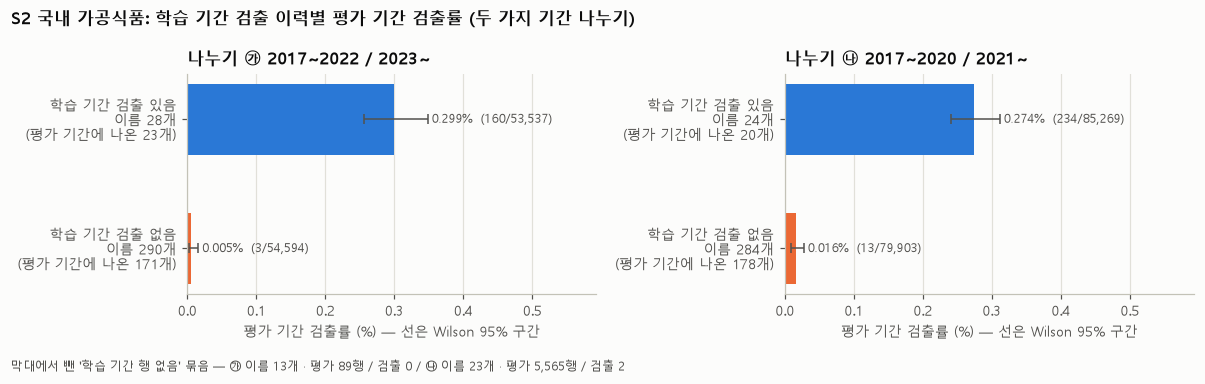

In [135]:
# [11-2-e] 그림: 나누기 ㉮·㉯ 에서 학습 이력(V1 기준)별 평가 기간 검출률 (Wilson 95% 구간, 건수 표기)
# '학습 기간 행 없음' 묶음은 막대에서 빼고 그림 아래 글과 print 로 행·검출을 적음
# (㉮ 에서는 89행이라 구간 상한이 약 4% 로 커져 다른 막대가 보이지 않게 됨 — 작성자 임의 표시 선택. 뺀 묶음도 계산에는 그대로 있음)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
xmax, foot = 0, []
for ax, (sname, (base, res)) in zip(axes, ZT_SPLIT_RES.items()):
    v1 = res['V1 학습 행≥1 & 검출 0']
    kk = np.array([base['이력 있음 평가 검출'], v1['k']])
    nn = np.array([base['이력 있음 평가 행'], v1['n']])
    rate = kk / nn * 100
    lo, hi = wilson(kk, nn)
    xmax = max(xmax, hi.max())
    y = np.arange(2)[::-1]
    ax.barh(y, rate, height=0.55, color=[C1, C2])
    ax.errorbar(rate, y, xerr=[rate - lo, hi - rate], fmt='none', ecolor=INK2, elinewidth=1, capsize=3)
    for yi, rr, h, k, n in zip(y, rate, hi, kk, nn):
        ax.text(h + 0.005, yi, f'{rr:.3f}%  ({k}/{n:,})', va='center', ha='left', fontsize=8, color=INK2)
    ax.set_yticks(y)
    ax.set_yticklabels([f"학습 기간 검출 있음\n이름 {base['이력 있음 이름']}개\n(평가 기간에 나온 {base['이력 있음 평가 이름']}개)",
                        f"학습 기간 검출 없음\n이름 {len(v1['names'])}개\n(평가 기간에 나온 {v1['ev_names']}개)"])
    ax.grid(axis='y', visible=False)
    ax.set_title(f'나누기 {sname}')
    ax.set_xlabel('평가 기간 검출률 (%) — 선은 Wilson 95% 구간')
    nb_, kb_ = base['학습 행 없음 평가 행'], base['학습 행 없음 평가 검출']
    foot.append(f"{sname.split(' ')[0]} 이름 {base['학습 행 없음 이름']}개 · 평가 {nb_:,}행 / 검출 {kb_}")
    print(f"막대에서 뺀 '학습 기간 행 없음' 묶음 {sname}: 이름 {base['학습 행 없음 이름']}개(평가 기간에 행 있음 {base['학습 행 없음 평가 이름']}개), 평가 {nb_:,}행 / 검출 {kb_}")
axes[0].set_xlim(0, xmax * 1.7)
fig.suptitle('S2 국내 가공식품: 학습 기간 검출 이력별 평가 기간 검출률 (두 가지 기간 나누기)', x=0.01, ha='left', fontsize=11, fontweight='bold')
fig.text(0.01, 0.01, "막대에서 뺀 '학습 기간 행 없음' 묶음 — " + ' / '.join(foot), ha='left', va='bottom', fontsize=8, color=INK2)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

📊 **결과** (세부는 위 표들)
- 나누기 ㉮ (2016년 5,125행·검출 5 는 뺌): 평가 기간 108,220행·검출 163 = 학습 기간 검출 있음 28개 이름 53,537행 / 160 (**0.299%**, 0.256\~0.349) + 검출 없음 290개 이름 54,594행 / 3 (**0.005%**, 0.002\~0.016) + 학습 기간 행 없음 13개 이름 89행 / 0. 검출 없음 290개 중 평가 기간에 행이 있는 이름은 171개이고, 학습 기간 행 없음 13개는 평가 기간에 처음 나온 12개 + 2016년에만 있는 1개(신장질환자용식품 1행)입니다.
- 나누기·변형별 뺄 후보의 평가 기간 검출 — 건수 (평가 검출 대비 비중) · 뺄 후보 이름 수 (그중 평가 기간에 행 있는 이름) · 평가 행:

| 나누기 (평가 검출 전체) | V1 학습 행 1개 이상 & 검출 0 | V2 100행 이상 & 검출 0 | V3 1,000행 이상 & 검출 0 |
|---|---|---|---|
| ㉮ 2017\~2022 / 2023\~ (163) | 3 (1.8%) · 290 (171) · 54,594행 | 1 (0.6%) · 90 (76) · 49,461행 | 1 (0.6%) · 12 (12) · 36,345행 |
| ㉯ 2017\~2020 / 2021\~ (249) | 13 (5.2%) · 284 (178) · 79,903행 | 12 (4.8%) · 80 (66) · 75,920행 | 1 (0.4%) · 10 (10) · 53,604행 |
| ㉰ 해마다, 2020\~2026 합 (279) | 10 (3.6%) · 95,573행 | 8 (2.9%) · 91,462행 | 3 (1.1%) · 65,841행 |

- 뒤집힌 이름(이력 없음 → 평가 검출): ㉮ 우유 1(학습 5,125행)·치즈 1(21행)·간편조리세트 1(3행) / ㉯ 즉석조리식품 5·생햄 4·발효소시지 2·우유 1·연육 1. ㉯ 에는 뺄 후보가 아닌 **학습 기간 행 없음 23개 이름 5,565행 / 검출 2 (간편조리세트·치즈)** 가 따로 있습니다(이력 있음 234 + 뺄 후보 13 + 2 = 249).
- 반대 방향(㉮): 학습 기간 검출 있음 → 평가 검출 0 인 이름 12개에 행이 많은 이름도 있습니다. 소시지 학습 10,096행·검출 19 → 평가 4,807행·0 (학습 검출률로 본 기대 9.0건), 가공치즈 평가 3,188행(기대 1.5), 식육추출가공품 3,108행(1.0), 유가공품류 1,756행(0.5). 또 이력 있음 28개 중 11개는 학습 기간 검출이 의뢰키 1개에서만 나왔습니다(이 11개의 평가 4,993행·검출 7).

💬 **첨언**
- 작성자가 임의로 나눈 ㉮·㉯ 에서, 학습 기간에 검출이 없던 유형은 평가 기간 검출률이 이력 있는 유형보다 훨씬 낮았습니다(㉮ 0.005% vs 0.299%, ㉯ 0.016% vs 0.274%). '이력 없음'이 뒤 기간 음성 쪽을 어느 정도 가려내는 것으로 보입니다 (추정).
- 다만 **빠지는 검출은 나누기에 따라 다릅니다** (추정). V1·V2 는 ㉮ 에서 가장 적게(1.8%·0.6%), ㉯ 에서 가장 많이(5.2%·4.8%) 빠집니다. V3 는 세 나누기 모두 1.1% 이하였지만 뺄 수 있는 행도 가장 적습니다. ㉮ 한 번 나눈 결과만으로 기준을 정하기는 어려워 보입니다.
- ㉯ 에서 빠지는 검출의 대부분은 생햄·발효소시지(그대로 먹는 식육가공품으로 보임, 작성자 추정)와 즉석조리식품입니다. 몇 년 동안 행이 수십\~수백 개인데 검출 0 이다가 뒤에 드물게 나왔고, V2 도 ㉯ 에서 이 셋(학습 행 210·199·578)을 잡습니다. 드물게 검출되는 유형이 이력 기준으로 빠질 수 있어 보입니다 (추정).
- 반대로 행이 많은 이름도 '검출 있음 → 평가 0' 으로 바뀌었습니다. 소시지 연도별 검출/행은 2017 5/1,725 · 2018 5/1,785 · 2019 0/1,721 · 2020 0/1,598 · 2021 2/1,596 · 2022 7/1,671 · 2023\~2026 모두 0 이고, 검사목적은 학습 기간 자가품질위탁검사 77% · 수거검사 11% → 평가 기간 71% · 17% 입니다. 시기에 따른 변화일 수도, 몇 해에 몰린 드문 검출일 수도 있어 보입니다 (추정).
- **이력 라벨이 적은 수의 의뢰에 기대는 경우가 많습니다** (결과를 본 뒤 추가한 점검, 추정). 학습 기간 검출 218행은 의뢰키 202개에 걸쳐 있지만, 이름별로 보면 이력 있음 28개 중 11개가 의뢰키 1개(수산물가공품 검출 4건도 한 의뢰)에서만 검출이 나왔습니다. 평가 검출 160 중 150 은 의뢰키 5개 이상인 8개 이름에서 나왔습니다. V2·V3 의 학습 행 수 조건은 검출 0 인 이름에만 걸리므로 한 의뢰에 기댄 '이력 있음' 라벨의 흔들림은 줄이지 못해, '검출이 나온 서로 다른 의뢰·업체 수'도 기준 후보로 볼 만해 보입니다.
- 이름 표기도 이력 판단을 흔듭니다 (추정). '치즈'는 ㉮ 학습 행이 21 이라 V1 뺄 후보가 되었다가 평가 기간에 1건이 나왔고, ㉯ 에서는 학습 기간 행 없음 묶음에 들어갑니다(반경성치즈·연성가공치즈 등 옛 이름은 2016\~2019 에만 있음). 띄어쓰기·구두점만 다른 이름도 7묶음 14개 이름(6,613행)이라, '식육 추출가공품'(21행)은 V1 뺄 후보, '식육추출가공품'(학습 3,238행·검출 1)은 이력 있음으로 갈립니다. 수치 영향은 작아 보입니다.
- 검사목적별로 나눠도 수거검사(0.619% vs 0.014%)·기타(2.007% vs 0.018%)·식품안전관리인증검사(1.276% vs 0.114%)에서 차이가 남아, 정기 검사로 쌓인 행이라서만은 아닐 수 있어 보입니다 (추정). 칸마다 이력 없음 쪽 검출이 1건 안팎이라 흔들릴 수 있습니다.
- Wilson 구간은 행끼리 독립이라고 가정합니다. 평가 기간 검출 163행은 의뢰키 153개에 걸쳐 있으나 업체 식별 불가 39행이 있어, 구간은 실제보다 좁을 수 있습니다 (추정).

### 11-3. 범위 후보 — S2 에서 '학습 기간 이력 없음' 유형을 뺀 범위

🔎 11-2 의 변형 V1\~V3 로 S2 에서 유형을 뺐을 때 행·검출이 얼마나 남는지 전체·학습·평가 기간별로 봅니다. 그리고 현행 식품공전 리스테리아 기준(13-3절 표)과 겹쳐, **기준이 있는데 이력 없음**인 유형과 **유형 규격에 문구가 없는데 검출 있음**인 유형을 나란히 봅니다.
- 뺄 유형은 기본 나누기 ㉮ 의 학습 기간으로만 정합니다(다른 나누기에서 빠지는 검출은 11-2-d). 학습 기간 검출률은 정의상 뺀 유형이 0 이라 올라가 보이므로, 비교는 평가 기간 값으로 봅니다.
- '학습 기간 행 없음' 이름 13개(평가 기간에 처음 나온 12개 + 2016년에만 있는 1개)는 뺄 근거가 없어 **남깁니다** (작성자 임의).

In [136]:
# [11-3-a] S2 − 이력 없음 유형(V1~V3): 전체·학습·평가 기간 행·검출
def zt_cnt(mask):
    n, k = int(mask.sum()), int(zt.loc[mask, 'pos'].sum())
    return n, k, (round(k / n * 100, 3) if n else np.nan)

rows = []
cands = [('S2 국내 가공식품', [])] + [(f'S2 − {v.split(" ")[0]}', ZERO_NAMES_TRAIN[v]) for v in ZT_VARIANTS]
for cname, names in cands:
    keep = ~zt['품목명'].isin(names)
    r = {'후보': cname, '뺀 품목명 수': len(names)}
    for plab, pm in [('전체', pd.Series(True, index=zt.index)), ('학습', zt_per.eq('학습')), ('평가', zt_per.eq('평가')), ('2016년', zt_per.eq('2016년(뺌)'))]:
        n, k, rt = zt_cnt(keep & pm)
        r[f'{plab} 행'], r[f'{plab} 검출'] = n, k
        if plab in ('전체', '평가'):
            r[f'{plab} 검출률(%)'] = f'{rt:.3f}'   # 문자열로 두어 전치(T) 때 행 수가 소수로 바뀌지 않게 함
    dn, dk, _ = zt_cnt(~keep)
    r['뺀 행(전체)'], r['뺀 검출(전체)'] = dn, dk
    r['뺀 행 비율(%)'] = f'{dn / len(zt) * 100:.1f}'
    rows.append(r)
    if names:
        dk_by = {p: int(zt.loc[~keep & zt_per.eq(p), 'pos'].sum()) for p in ['2016년(뺌)', '학습', '평가']}
        print(f'{cname}: 뺀 검출 {dk} = 기간별 {dk_by}')
zt_cand_tab = pd.DataFrame(rows).set_index('후보')
print('뺀 행 = 뺄 유형(나누기 ㉮ 학습 기간 기준)의 모든 기간 행. 2016년 열은 기간 나누기에서 뺀 행이 후보에 몇 개 남는지 참고용')
zt_cand_tab.T

S2 − V1: 뺀 검출 4 = 기간별 {'2016년(뺌)': 1, '학습': 0, '평가': 3}
S2 − V2: 뺀 검출 1 = 기간별 {'2016년(뺌)': 0, '학습': 0, '평가': 1}
S2 − V3: 뺀 검출 1 = 기간별 {'2016년(뺌)': 0, '학습': 0, '평가': 1}
뺀 행 = 뺄 유형(나누기 ㉮ 학습 기간 기준)의 모든 기간 행. 2016년 열은 기간 나누기에서 뺀 행이 후보에 몇 개 남는지 참고용


후보,S2 국내 가공식품,S2 − V1,S2 − V2,S2 − V3
뺀 품목명 수,0,290,90,12
전체 행,294421,156186,165954,208072
전체 검출,386,382,385,385
전체 검출률(%),0.131,0.245,0.232,0.185
학습 행,181076,100306,104632,131846
학습 검출,218,218,218,218
평가 행,108220,53626,58759,71875
평가 검출,163,160,162,162
평가 검출률(%),0.151,0.298,0.276,0.225
2016년 행,5125,2254,2563,4351


**식품공전 기준과 겹쳐 보기 — 작성자 임의 대응 규칙 (라벨 규칙은 13-3절 표에서 정함)**
- 근거는 13-3절의 식품공전 리스테리아 기준 표(현행 식품의 기준 및 규격 제2026-55호에서 "리스테리아" 글자를 찾은 결과, 누락 가능)입니다. LIMS 품목명과 식품공전 식품유형 이름이 1:1 인지는 확인하지 않았습니다.
- 9-3절도 A\~D 글자를 쓰지만, 대응 규칙(9-3 은 품목명 목록, 이 절은 품목명 글자 + 분류 3단계)과 D 의 뜻(9-3 = 판단 불가, 이 절 = 13-3절 표에 없음)이 달라 같은 글자라도 묶음이 다릅니다.
- 행마다 품목명과 통계용 분류 3단계(`statistic_prdlst_nm_3`)로 아래 순서대로 붙이고, 품목명마다 **행이 가장 많은 라벨**을 씁니다(이름이 여러 라벨에 걸치면 그 수를 출력).
  - A 유형 규격에 문구 있음: ① 품목명에 아이스크림·아이스밀크·샤베트 → 아이스크림류·믹스류(제5. 2-1·2-2) ② 품목명에 조제유·조제분유·조제우유 → 조제유류(제5. 10-1) ③ 분류 3단계 '유가공품'·'유가공품류' → 유가공품(제5. 19-1\~19-14)
  - C 유형 규격에 문구 없음(13-3절 검색): ④ 품목명 포장육·식육함유가공품·알함유가공품(17-9·17-8·18-2) ⑦ 분류 3단계 수산가공식품류·어육가공품·젓갈류·건포류, 또는 품목명에 수산물가공품·어육·어묵 → 수산가공식품류(20)
  - B 조건부(살균제품 또는 그대로 섭취하는 제품에 한함): ⑤ 분류 3단계 '식육가공품 및 포장육'(④ 제외) → 식육가공품(17-1\~17-6) ⑥ 분류 3단계 '알가공품'·'알가공품류'(④ 제외) → 알가공품(18-1)
  - D 13-3절 표에 없음: 나머지(즉석식품류·빙과·과자 등).
- 빙과류 중 '빙과'·'식용얼음'은 A 에 넣지 않았습니다(13-3절 표에 2-1·2-2 만 있음). 17-7 식육간편조리세트는 LIMS 이름 '간편조리세트'(분류 3단계 즉석식품류)와 같은 유형인지 알 수 없어 D 로 두었습니다.
- **이 라벨은 크게 흔들릴 수 있습니다 (추정).** 13-3절 표 첫 줄인 제2 공통 기준은 '식육'과 '더 이상 가열조리하지 않고 그대로 섭취하는 가공식품' 등에 "식품의 특성에 따라" 적용됩니다. 그래서 C·D 중에도 공통 기준을 받는 이름이 있을 수 있고(예: 포장육 = 식육, 즉석섭취식품 = 이름부터 그대로 섭취), B 중에도 조건 밖인 이름이 있을 수 있습니다(예: 양념육·가열양념육 = 먹기 전에 가열할 수 있는 제품, 작성자 추정). 13-3절도 이 부분을 '불명'으로 남겼습니다.

**식품공전 기준으로 범위를 자를 때 볼 변형 (작성자 임의 — 떼어 보는 이름 4개는 결과를 본 선택)** — 품목명 단위로 넣고 뺍니다.
- ⚠️ 떼어 보는 이름 4개(포장육·즉석섭취식품·양념육·가열양념육)는 **검출이 많은 이름이라는 것을 알고 고른 것**입니다(검출 수가 2.ipynb 3-6-1·13-3절에 이미 나와 있음). 그래서 아래 변형은 '결과보다 먼저 정한 비교'가 아니라, 해석이 흔들리는 큰 이름을 넣고 빼면 크기가 얼마나 달라지는지 보는 **예시**입니다.
- 같은 논리(제2 공통 기준의 '그대로 섭취')가 적용될 수 있는 다른 C·D 이름(기타 수산물가공품·수산물가공품·어묵·조미건어포류 등)은 떼어 보지 않았습니다. 이름마다 분류는 전문가 질문으로 넘깁니다.
- 묶음 7개로 따로 셉니다: A(조건 없음) · B 양념육·가열양념육 · B 그 밖 · C 포장육 · C 그 밖 · D 즉석섭취식품 · D 그 밖.
- 범위 변형 4개 (이 넷 말고는 보지 않음)
  - 가 'A만' — 조건 없이 문구가 있는 유형만
  - 나 'A+B' — 조건부 유형을 조건 충족 여부와 상관없이 넣음
  - 나′ 'A+B − 양념육·가열양념육' — B 중 먹기 전에 가열할 수 있어 보이는 두 이름(작성자 추정)을 조건 밖으로 봄
  - 다 'A+B+공통 기준 후보(포장육·즉석섭취식품)' — 나 + 제2 공통 기준을 받을 수 있어 보이는 두 이름(작성자 추정). 남는 검출 비중은 '이 두 이름을 더했을 때' 한 경우의 예시 값으로만 봅니다(다른 C·D 이름을 더 넣으면 더 커질 수 있어 상한도 아님).

In [137]:
# [11-3-b] 품목명 → 식품공전 리스테리아 문구 대응 (작성자 임의 규칙, 13-3절의 식품공전 리스테리아 기준 표 기준)
nm_s = zt['품목명'].astype(str)
st3 = zt['statistic_prdlst_nm_3'].astype(str)
ZT_LABELS = ['A 문구 있음: 아이스크림류·믹스류', 'A 문구 있음: 조제유류', 'A 문구 있음: 유가공품',
             'C 문구 없음: 포장육·식육함유·알함유', 'B 조건부: 식육가공품', 'B 조건부: 알가공품', 'C 문구 없음: 수산가공식품류']
row_lab = pd.Series(np.select([
    nm_s.str.contains('아이스크림|아이스밀크|샤베트', regex=True),
    nm_s.str.contains('조제유|조제분유|조제우유', regex=True),
    st3.isin(['유가공품', '유가공품류']),
    nm_s.isin(['포장육', '식육함유가공품', '알함유가공품']),
    st3.eq('식육가공품 및 포장육'),
    st3.isin(['알가공품', '알가공품류']),
    st3.isin(['수산가공식품류', '어육가공품', '젓갈류', '건포류']) | nm_s.str.contains('수산물가공품|어육|어묵', regex=True),
], ZT_LABELS, 'D 13-3절 표에 없음'), index=zt.index)
ct = pd.crosstab(zt['품목명'], row_lab)
multi = ct[(ct > 0).sum(axis=1) > 1]
print(f'라벨이 2개 이상 걸친 품목명 {len(multi)}개 (행이 가장 많은 라벨 사용):')
for nm, r in multi.iterrows():
    print('  ', nm, {k: int(v) for k, v in r[r > 0].items()})
zt_name['공전 대응(임의)'] = ct.idxmax(axis=1)
zt_name['전체 행'] = g_all['행'].astype('Int64')
zt_name['전체 검출'] = g_all['검출'].astype('Int64')
grp = zt_name['공전 대응(임의)'].str[0]
print()
print('대응 라벨별 품목명 수:', zt_name['공전 대응(임의)'].value_counts().sort_index().to_dict())

# 라벨 × 학습 이력: 품목명 수, 전체 행·검출, 평가 행·검출
ev_lab = zt_ev['품목명'].map(zt_name['공전 대응(임의)'])
ev_hist2 = zt_ev['품목명'].map(zt_name['학습 이력'])
rows = []
for lab in sorted(zt_name['공전 대응(임의)'].unique()):
    for h in ['학습 기간 검출 있음', '학습 기간 검출 없음', '학습 기간 행 없음']:
        sel = zt_name[zt_name['공전 대응(임의)'].eq(lab) & zt_name['학습 이력'].eq(h)]
        if len(sel) == 0:
            continue
        e = zt_ev[ev_lab.eq(lab) & ev_hist2.eq(h)]
        rows.append({'공전 대응(임의)': lab, '학습 이력': h, '품목명 수': len(sel), '전체 행': int(sel['전체 행'].sum()),
                     '전체 검출': int(sel['전체 검출'].sum()), '평가 행': len(e), '평가 검출': int(e['pos'].sum())})
zt_lab_tab = pd.DataFrame(rows).set_index(['공전 대응(임의)', '학습 이력'])
zt_lab_tab

라벨이 2개 이상 걸친 품목명 1개 (행이 가장 많은 라벨 사용):
   조미김 {'C 문구 없음: 수산가공식품류': 458, 'D 13-3절 표에 없음': 106}

대응 라벨별 품목명 수: {'A 문구 있음: 아이스크림류·믹스류': 12, 'A 문구 있음: 유가공품': 60, 'A 문구 있음: 조제유류': 7, 'B 조건부: 식육가공품': 20, 'B 조건부: 알가공품': 11, 'C 문구 없음: 수산가공식품류': 20, 'C 문구 없음: 포장육·식육함유·알함유': 3, 'D 13-3절 표에 없음': 198}


품목명 수   전체 행  전체 검출   평가 행  평가 검출
공전 대응(임의)             학습 이력                                         
A 문구 있음: 아이스크림류·믹스류   학습 기간 검출 없음     12  22880      0   9013      0
A 문구 있음: 유가공품         학습 기간 검출 있음      2  16032      4   4944      0
                      학습 기간 검출 없음     57  58476      2  25534      2
                      학습 기간 행 없음       1      6      0      6      0
A 문구 있음: 조제유류         학습 기간 검출 없음      7   1829      0    536      0
B 조건부: 식육가공품          학습 기간 검출 있음     15  91303    192  31306     56
                      학습 기간 검출 없음      5   1139      0      0      0
B 조건부: 알가공품           학습 기간 검출 없음     10  28456      0  12455      0
                      학습 기간 행 없음       1      1      0      1      0
C 문구 없음: 수산가공식품류      학습 기간 검출 있음      4   3722     33    966      6
                      학습 기간 검출 없음     15   1417      1    472      0
                      학습 기간 행 없음       1     63      0     63      0
C 문구 없음: 포장육·식육함유·알함유 학습 기간 검출 있음      2   2773    102   2076     82
                      학습 기간 검출 없음      1      9      0      0      0
D 13-3절 표에 없음         학습 기간 검출 있음      5  42266     51  14245     16
                      학습 기간 검출 없음    183  24029      1   6584      1
                      학습 기간 행 없음      10     20      0     19      0

In [138]:
# [11-3-c] 겹쳐 보기 두 목록 — (1)은 ㉮ 학습 기간 이력 기준(누수 없음), (2)는 전체 기간 검출 기준(누수 있음, 규모 확인용)이라 기준이 다름 → (2′)에 학습 기간 기준 수를 같이 적음
# (1) 기준 문구가 있는데(A·B) 학습 기간 이력 없음(V1) — 전체 행 많은 순 상위 15
cols = ['공전 대응(임의)', '학습 행', '평가 행', '평가 검출', '전체 행', '전체 검출']
ab0 = zt_name[grp.isin(['A', 'B']) & zt_name['학습 이력'].eq('학습 기간 검출 없음')].sort_values('전체 행', ascending=False)
print(f'(1) A·B 라벨 & ㉮ 학습 기간 검출 없음 (누수 없음): {len(ab0)}개 품목명, 전체 행 {int(ab0["전체 행"].sum()):,}, 평가 행 {int(ab0["평가 행"].sum(skipna=True)):,}, 평가 검출 {int(ab0["평가 검출"].sum(skipna=True))}')
display(ab0[cols].head(15))

# (2) 유형 규격에 문구가 없거나(C) 13-3절 표에 없는데(D) 전체 기간 검출이 있는 품목명 — 전체 기간 기준 (누수 있음, 규모 확인용)
cd1 = zt_name[grp.isin(['C', 'D']) & zt_name['전체 검출'].gt(0)].sort_values('전체 검출', ascending=False)
print(f'(2) C·D 라벨 & 전체 기간 검출 있음 (전체 기간 기준 — 누수 있음, 규모 확인용): {len(cd1)}개 품목명, 전체 행 {int(cd1["전체 행"].sum()):,}, '
      f'전체 검출 {int(cd1["전체 검출"].sum())} (S2 검출의 {cd1["전체 검출"].sum() / zt["pos"].sum():.1%})')
display(cd1[['공전 대응(임의)', '학습 행', '학습 검출', '평가 행', '평가 검출', '전체 행', '전체 검출', '학습 이력']])
# (2′) 같은 겹쳐 보기를 ㉮ 학습 기간 검출 기준으로 셈 (누수 없음)
cd_tr = zt_name[grp.isin(['C', 'D']) & zt_name['학습 이력'].eq('학습 기간 검출 있음')]
_ek = cd_tr['평가 검출'].sum(skipna=True)
print(f"(2′) C·D 라벨 & ㉮ 학습 기간 검출 있음 (누수 없음): {len(cd_tr)}개 품목명, 학습 검출 {int(cd_tr['학습 검출'].sum())}, "
      f"평가 {int(cd_tr['평가 행'].sum(skipna=True)):,}행 / 검출 {int(_ek)} (평가 검출 {EV_K} 의 {_ek / EV_K * 100:.1f}%)")
print(f"     (2)의 {len(cd1)}개 중 ㉮ 학습 기간 검출이 없는 이름: {', '.join(cd1.index[cd1['학습 이력'].ne('학습 기간 검출 있음')])}")

# (3) 참고: A·B 라벨에서 전체 기간 검출이 있는 품목명 (전문가 분류 질문용 이름 목록)
ab1 = zt_name[grp.isin(['A', 'B']) & zt_name['전체 검출'].gt(0)].sort_values('전체 검출', ascending=False)
print(f'(3) 참고 — A·B 라벨 & 전체 기간 검출 있음: {len(ab1)}개 품목명, 전체 검출 {int(ab1["전체 검출"].sum())}. '
      f'그중 A(조건 없음) {int(ab1["공전 대응(임의)"].str.startswith("A").sum())}개·검출 {int(ab1.loc[ab1["공전 대응(임의)"].str.startswith("A"), "전체 검출"].sum())}')
for L_ in ['A', 'B']:
    _s = ab1[ab1['공전 대응(임의)'].str.startswith(L_)]
    print(f'    {L_} ({len(_s)}개, 전체 검출/전체 행):', ', '.join(f"{i} {int(r['전체 검출'])}/{int(r['전체 행']):,}" for i, r in _s.iterrows()))

# 포장육 평가 기간 검출이 의뢰·업체·검사목적·달에 몰려 있나 (추적 검사가 섞였을 수 있어 확인, 10절과 겹쳐 볼 것)
_pk = zt_ev[zt_ev['품목명'].eq('포장육') & zt_ev['pos'].eq(1)]
_n, _r, _f, _u = zt_cluster(_pk.index)
print(f'포장육 평가 기간 검출 {_n}행: 의뢰키 {_r}개, 식별 가능 업체 {_f}곳, 업체 식별 불가 {_u}행')
print('  검사목적:', _pk['검사목적'].value_counts().to_dict())
_mon = _pk['reqest_de'].dt.strftime('%Y-%m').value_counts()
print('  검출 5건 이상인 의뢰 달:', _mon[_mon >= 5].sort_index().to_dict(), f'/ 검출 있는 달 {len(_mon)}개')
_py = zt[zt['품목명'].eq('포장육')].groupby(zt['reqest_de'].dt.year)['pos'].agg(['size', 'sum'])
print('  포장육 의뢰 연도별 행:', _py['size'].to_dict(), '/ 검출:', _py['sum'].to_dict())

(1) A·B 라벨 & ㉮ 학습 기간 검출 없음 (누수 없음): 91개 품목명, 전체 행 112,780, 평가 행 47,538, 평가 검출 2


,공전 대응(임의),학습 행,평가 행,평가 검출,전체 행,전체 검출
품목명,,,,,,
알가열제품,B 조건부: 알가공품,10320,9406,0,19726,0
농후발효유,A 문구 있음: 유가공품,8418,6516,0,15015,0
우유,A 문구 있음: 유가공품,5125,3737,1,8943,1
아이스밀크,A 문구 있음: 아이스크림류·믹스류,4649,3176,0,7946,0
발효유,A 문구 있음: 유가공품,4216,2875,0,7152,0
아이스크림,A 문구 있음: 아이스크림류·믹스류,4260,2719,0,7138,0
가공유,A 문구 있음: 유가공품,3440,2300,0,5782,0
샤베트,A 문구 있음: 아이스크림류·믹스류,2583,1771,0,4484,0
전란액,B 조건부: 알가공품,2151,1622,0,3811,0


(2) C·D 라벨 & 전체 기간 검출 있음 (전체 기간 기준 — 누수 있음, 규모 확인용): 13개 품목명, 전체 행 48,794, 전체 검출 188 (S2 검출의 48.7%)


,공전 대응(임의),학습 행,학습 검출,평가 행,평가 검출,전체 행,전체 검출,학습 이력
품목명,,,,,,,,
포장육,C 문구 없음: 포장육·식육함유·알함유,616,19,2045,82,2668,101,학습 기간 검출 있음
즉석섭취식품,D 13-3절 표에 없음,23924,28,12942,12,37337,40,학습 기간 검출 있음
기타 수산물가공품,C 문구 없음: 수산가공식품류,1981,21,951,6,2932,27,학습 기간 검출 있음
즉석조리식품,D 13-3절 표에 없음,687,1,371,4,1059,5,학습 기간 검출 있음
수산물가공품,C 문구 없음: 수산가공식품류,380,4,<NA>,<NA>,428,4,학습 기간 검출 있음
기타가공품,D 13-3절 표에 없음,1762,4,462,0,2246,4,학습 기간 검출 있음
간편조리세트,D 13-3절 표에 없음,3,0,3,1,6,1,학습 기간 검출 없음
만두류,D 13-3절 표에 없음,89,1,<NA>,<NA>,100,1,학습 기간 검출 있음
식육함유가공품,C 문구 없음: 포장육·식육함유·알함유,74,1,31,0,105,1,학습 기간 검출 있음


(2′) C·D 라벨 & ㉮ 학습 기간 검출 있음 (누수 없음): 11개 품목명, 학습 검출 82, 평가 17,287행 / 검출 104 (평가 검출 163 의 63.8%)
     (2)의 13개 중 ㉮ 학습 기간 검출이 없는 이름: 간편조리세트, 조미건어포류
(3) 참고 — A·B 라벨 & 전체 기간 검출 있음: 19개 품목명, 전체 검출 198. 그중 A(조건 없음) 4개·검출 6
    A (4개, 전체 검출/전체 행): 가공치즈 2/7,518, 유가공품류 2/8,514, 우유 1/8,943, 치즈 1/3,543
    B (15개, 전체 검출/전체 행): 양념육 87/21,956, 햄 27/15,631, 분쇄가공육제품 19/7,853, 소시지 19/15,275, 프레스햄 10/8,384, 건조저장육류 6/6,702, 가열양념육 5/2,930, 베이컨류 5/1,453, 생햄 4/1,431, 갈비가공품 3/2,106, 햄류 2/29, 발효소시지 2/842, 소시지류 1/56, 식육추출가공품 1/6,346, 혼합소시지 1/309
포장육 평가 기간 검출 82행: 의뢰키 78개, 식별 가능 업체 50곳, 업체 식별 불가 12행
  검사목적: {'기타': 53, '수거검사': 18, '식품안전관리인증검사': 11}
  검출 5건 이상인 의뢰 달: {'2023-05': 5, '2024-04': 6, '2024-05': 5, '2026-03': 10} / 검출 있는 달 35개
  포장육 의뢰 연도별 행: {2016: 7, 2017: 110, 2018: 48, 2019: 54, 2020: 90, 2021: 145, 2022: 169, 2023: 406, 2024: 535, 2025: 681, 2026: 423} / 검출: {2016: 0, 2017: 1, 2018: 1, 2019: 1, 2020: 5, 2021: 6, 2022: 5, 2023: 24, 2024: 24, 2025: 20, 2026: 14}


#### 11-3-d. 식품공전 라벨을 묶음 7개로 나누고, 범위 변형 가·나·나′·다 규모 보기

🔎 위 목록의 '48.7%'(전체 기간)·'63.8%'(학습 기간 기준) 같은 크기는 C·D 라벨을 어떻게 붙이느냐에 크게 기댑니다. 그래서 공통 기준·조건부 해석이 흔들리는 이름 4개(포장육·즉석섭취식품·양념육·가열양념육)를 따로 떼어 셉니다.
- 이 4개는 **검출이 많은 이름인 줄 알고 고른 것(결과를 본 선택, 작성자 임의)** 입니다. 코드에서 라벨 안 검출 순위를 같이 출력합니다. 범위 변형 사이 차이는 이 이름 고르기에 크게 기대므로 예시로만 봅니다.

In [139]:
# [11-3-d] 식품공전 묶음 7개와 범위 변형 4개 (작성자 임의)
lab_nm = zt_name['공전 대응(임의)'].astype(str)
idx_nm = zt_name.index.astype(str)
ZT_HEAT_MEAT = ['양념육', '가열양념육']          # B 중 먹기 전에 가열할 수 있어 보이는 이름 (작성자 추정) — 검출이 많은 이름인 줄 알고 고름(결과를 본 선택)
ZT_COMMON_CAND = ['포장육', '즉석섭취식품']       # 제2 공통 기준을 받을 수 있어 보이는 이름 (작성자 추정) — 검출이 많은 이름인 줄 알고 고름(결과를 본 선택)
print('확인 — 떼어 보는 이름의 라벨:', {nm: lab_nm.get(nm, '(S2 에 없음)') for nm in ZT_HEAT_MEAT + ZT_COMMON_CAND})
print('떼어 보는 이름의 S2 전체 행/검출:', {nm: f"{int(zt_name.loc[nm, '전체 행']):,}/{int(zt_name.loc[nm, '전체 검출'])}" for nm in ZT_HEAT_MEAT + ZT_COMMON_CAND if nm in zt_name.index})
# 결과를 본 선택임을 드러내려고, 같은 라벨 묶음(A / B / C·D) 안에서 전체 기간 검출 순위를 출력 (같은 수는 높은 순위로)
_rk = pd.DataFrame({'검출': zt_name['전체 검출'].astype('float64'), '묶음': lab_nm.str[0].replace({'C': 'C·D', 'D': 'C·D'})})
_rk['순위'] = _rk.groupby('묶음')['검출'].rank(ascending=False, method='min')
print('떼어 보는 이름의 라벨 안 전체 기간 검출 순위:', {nm: f"{_rk.loc[nm, '묶음']} 라벨 {int(_rk.loc[nm, '순위'])}위 / {int((_rk['묶음'] == _rk.loc[nm, '묶음']).sum())}개 이름" for nm in ZT_HEAT_MEAT + ZT_COMMON_CAND})
ZT_GRP7 = pd.Series(np.select([
    lab_nm.str.startswith('A').to_numpy(dtype=bool),
    lab_nm.str.startswith('B').to_numpy(dtype=bool) & idx_nm.isin(ZT_HEAT_MEAT),
    lab_nm.str.startswith('B').to_numpy(dtype=bool),
    idx_nm.isin(['포장육']),
    lab_nm.str.startswith('C').to_numpy(dtype=bool),
    idx_nm.isin(['즉석섭취식품']),
], ['A 조건 없음', 'B 양념육·가열양념육', 'B 그 밖', 'C 포장육', 'C 그 밖', 'D 즉석섭취식품'], 'D 그 밖'), index=zt_name.index)
row7 = zt['품목명'].map(ZT_GRP7)
ev7 = row7[zt_per.eq('평가')]
nohist = zt['품목명'].isin(ZERO_NAMES_TRAIN['V1 학습 행≥1 & 검출 0'])
K2 = int(zt['pos'].sum())
rows = []
for gname in ['A 조건 없음', 'B 양념육·가열양념육', 'B 그 밖', 'C 포장육', 'C 그 밖', 'D 즉석섭취식품', 'D 그 밖']:
    m = row7.eq(gname)
    em = m & zt_per.eq('평가')
    rows.append({'묶음': gname, '품목명 수': int(ZT_GRP7.eq(gname).sum()), '전체 행': int(m.sum()), '전체 검출': int(zt.loc[m, 'pos'].sum()),
                 'S2 검출 비중(%)': round(zt.loc[m, 'pos'].sum() / K2 * 100, 1), '평가 행': int(em.sum()), '평가 검출': int(zt.loc[em, 'pos'].sum()),
                 '그중 ㉮V1 이력 없음 행': int((m & nohist).sum()), '이력 없음 검출(전체)': int(zt.loc[m & nohist, 'pos'].sum())})
zt_grp7_tab = pd.DataFrame(rows).set_index('묶음')
display(zt_grp7_tab)

ZT_LAW_SCOPES = {
    '가 A만': ['A 조건 없음'],
    '나 A+B': ['A 조건 없음', 'B 양념육·가열양념육', 'B 그 밖'],
    '나′ A+B − 양념육·가열양념육': ['A 조건 없음', 'B 그 밖'],
    '다 A+B+공통 기준 후보(포장육·즉석섭취식품)': ['A 조건 없음', 'B 양념육·가열양념육', 'B 그 밖', 'C 포장육', 'D 즉석섭취식품'],
}
EV_N2 = int(zt_per.eq('평가').sum())
rows = []
for sname, gs in ZT_LAW_SCOPES.items():
    m = row7.isin(gs)
    em = m & zt_per.eq('평가')
    n_, k_, en, ek = int(m.sum()), int(zt.loc[m, 'pos'].sum()), int(em.sum()), int(zt.loc[em, 'pos'].sum())
    rows.append({'범위 변형': sname, '전체 행': n_, 'S2 대비 행(%)': round(n_ / len(zt) * 100, 1), '전체 검출': k_,
                 'S2 검출 비중(%)': round(k_ / K2 * 100, 1), '범위 밖 검출(전체)': K2 - k_,
                 '평가 행': en, '평가 검출': ek, '평가 검출률(%)': round(ek / en * 100, 3), '범위 밖 평가 검출': EV_K - ek})
zt_law_tab = pd.DataFrame(rows).set_index('범위 변형')
zt_law_tab

확인 — 떼어 보는 이름의 라벨: {'양념육': 'B 조건부: 식육가공품', '가열양념육': 'B 조건부: 식육가공품', '포장육': 'C 문구 없음: 포장육·식육함유·알함유', '즉석섭취식품': 'D 13-3절 표에 없음'}
떼어 보는 이름의 S2 전체 행/검출: {'양념육': '21,956/87', '가열양념육': '2,930/5', '포장육': '2,668/101', '즉석섭취식품': '37,337/40'}
떼어 보는 이름의 라벨 안 전체 기간 검출 순위: {'양념육': 'B 라벨 1위 / 31개 이름', '가열양념육': 'B 라벨 7위 / 31개 이름', '포장육': 'C·D 라벨 1위 / 221개 이름', '즉석섭취식품': 'C·D 라벨 2위 / 221개 이름'}


,품목명 수,전체 행,전체 검출,S2 검출 비중(%),평가 행,평가 검출,그중 ㉮V1 이력 없음 행,이력 없음 검출(전체)
묶음,,,,,,,,
A 조건 없음,79,99223,6,1.6,40033,2,83185,2
B 양념육·가열양념육,2,24886,92,23.8,8378,32,0,0
B 그 밖,29,96013,100,25.9,35384,24,29595,0
C 포장육,1,2668,101,26.2,2045,82,0,0
C 그 밖,22,5316,35,9.1,1532,6,1426,1
D 즉석섭취식품,1,37337,40,10.4,12942,12,0,0
D 그 밖,197,28978,12,3.1,7906,5,24029,1


,전체 행,S2 대비 행(%),전체 검출,S2 검출 비중(%),범위 밖 검출(전체),평가 행,평가 검출,평가 검출률(%),범위 밖 평가 검출
범위 변형,,,,,,,,,
가 A만,99223,33.7,6,1.6,380,40033,2,0.005,161
나 A+B,220122,74.8,198,51.3,188,83795,58,0.069,105
나′ A+B − 양념육·가열양념육,195236,66.3,106,27.5,280,75417,26,0.034,137
다 A+B+공통 기준 후보(포장육·즉석섭취식품),260127,88.4,339,87.8,47,98782,152,0.154,11


In [140]:
# [11-3 정리] 뒤 파트용 변수와 임시 변수 정리
# 뒤 파트용: S2 행 중 V1 이력 없음 유형인지 (dfx 인덱스 기준 bool Series, S2 밖 행은 False) — dfx 에 열로 넣지 않음
# ⚠️ 나누기 ㉮ 학습 기간(2017~2022)으로 고른 이름을 '모든 기간' 행에 표시한 값. 2023년 이후 평가에만 누수가 없고,
#    다른 기간 나누기·무작위 교차검증에 쓰면 평가할 행의 정답을 미리 본 셈(누수)이 됨
s2_nohist_v1 = pd.Series(False, index=dfx.index)
s2_nohist_v1.loc[zt.index[zt['품목명'].isin(ZERO_NAMES_TRAIN['V1 학습 행≥1 & 검출 0'])]] = True
print(f's2_nohist_v1: True {int(s2_nohist_v1.sum()):,}행 (㉮ 학습 기간 기준 — 2023년 이후 평가 밖에 쓰면 누수)')
# 중간 표·일반 이름 임시 변수 정리 (뒤 파트와 이름이 겹치지 않게). 없는 이름은 건너뜀
for _v in ['sub_b', 'yr_b', 'row_lab', 'ct', 'ev_lab', 'ev_hist2', 'ev_hist', 'ev_pos', 'rows', 'names', 'new', 'back', 'back0', 'flip', 'old0',
           'ch', 'nm_s', 'st3', 'grp', 'labs', 'kk', 'nn', 'rate', 'lo', 'hi', 'y', 'e', 't', 'n', 'k', 'r', 'h', 'keep', 'cands', 'inn',
           'mm', 'cols', 'ab0', 'cd1', 'ab1', 'cd_tr', 'big0', 'n_code', 'n_name', 'multi', 'sel', 'short', 'p', 'rng', 'lab', 'plab', 'pm', 'dn', 'dk',
           'dk_by', 'cname', 'vname', 'T', 'base', 'res', 'v', 'vs', 'Y', 'sname', 'a1', 'a2', 'b1', 'b2', 'lo_', 'hi_', 'flip_names', 'fy',
           'fy_g', 'd_', 'roll_flip', 'roll_notr', 'fig', 'axes', 'ax', 'xmax', 'foot', 'nb_', 'kb_', 'v1', 'yi', 'rr', 'nm', 'gi', 'lab_nm', 'idx_nm',
           'row7', 'ev7', 'nohist', 'gname', 'gs', 'm', 'em', 'n_', 'k_', 'en', 'ek', 'K2', 'EV_N2', 'i', 'c', 'L_', 'nn_', 'kk_', 'nm_n', 'nm_e',
           '_keep_h', '_e', '_gp', '_n', '_k', '_r', '_f', '_u', '_pk', '_mon', '_py', '_none', '_old_only', '_old_txt', '_key', '_dup',
           '_rate', '_trpos', '_g', '_rest', '_ss', '_sy', '_sp', '_pp', '_si', '_top', '_nt_txt', '_ek', '_s', '_rk']:
    globals().pop(_v, None)

s2_nohist_v1: True 138,235행 (㉮ 학습 기간 기준 — 2023년 이후 평가 밖에 쓰면 누수)


📊 **결과** (세부는 위 표들, `<NA>` 는 그 기간에 행이 없다는 뜻 — 0 으로 채우지 않음)
- ㉮ 학습 기간 이력으로 S2 에서 유형을 뺀 범위 (행 / 검출 / 검출률, 학습 기간 검출은 네 후보 모두 218):

| 후보 | 뺀 품목명 | 전체 | 평가(2023\~) | 뺀 행(전체) | 뺀 검출(전체) |
|---|---|---|---|---|---|
| S2 국내 가공식품 | 0 | 294,421 / 386 / 0.131% | 108,220 / 163 / 0.151% | 0 (0.0%) | 0 |
| S2 − V1 (학습 행 1개 이상 & 검출 0) | 290 | 156,186 / 382 / 0.245% | 53,626 / 160 / 0.298% | 138,235 (47.0%) | 4 (2016년 1, 평가 3) |
| S2 − V2 (100행 이상 & 검출 0) | 90 | 165,954 / 385 / 0.232% | 58,759 / 162 / 0.276% | 128,467 (43.6%) | 1 (평가 1) |
| S2 − V3 (1,000행 이상 & 검출 0) | 12 | 208,072 / 385 / 0.185% | 71,875 / 162 / 0.225% | 86,349 (29.3%) | 1 (평가 1) |

- 식품공전 대응(작성자 임의 라벨, 두 라벨에 걸친 이름은 조미김 1개): 기준 문구가 있는(A·B) ㉮ 학습 기간 이력 없음 91개 이름·112,780행 → 평가 47,538행·검출 2 (우유·치즈). 문구가 없거나(C) 표에 없는(D) 이름 중 검출 있음은 전체 기간 기준 13개·48,794행·검출 188 (S2 검출의 48.7%, 누수 있음), ㉮ 학습 기간 기준 11개·평가 17,287행·검출 104 (평가 검출의 63.8%).
- 포장육 한 이름이 평가 검출 163 중 82 입니다(학습 616행 → 평가 2,045행).
- 범위 변형(떼어 본 이름 4개는 결과를 본 선택) — 전체 행(S2 대비) · 전체 검출(S2 검출 비중): 가 A만 99,223(33.7%)·6(1.6%) / 나 A+B 220,122(74.8%)·198(51.3%) / 나′ A+B − 양념육·가열양념육 195,236(66.3%)·106(27.5%) / 다 A+B+공통 기준 후보(포장육·즉석섭취식품) 260,127(88.4%)·339(87.8%).

💬 **첨언**
- 작성자가 임의로 정한 V1\~V3 로 빼면(나누기 ㉮) S2 행이 29.3\~47.0% 줄고 평가 기간 검출은 1\~3건 빠집니다. 나누기를 바꾸면 빠지는 검출이 V1 3\~13건(평가 검출의 1.8\~5.2%), V2 1\~12건(0.6\~4.8%), V3 1\~3건(0.4\~1.1%)으로 달라집니다(11-2). V1·V2 는 ㉮ 에서 가장 적게 빠지므로, 두 변형에서 '행에 비해 잃는 검출이 적다'는 해석은 ㉮ 에 유리하게 나온 것으로 보입니다 (추정). V3 는 세 나누기 모두 1.1% 이하였습니다.
- 뺀 뒤 검출률이 올라가는 것(평가 0.151% → 0.225\~0.298%)은 검출이 거의 없는 행을 뺀 효과로 보입니다 (추정). 이 행들이 모델에게도 '쉬운 음성'인지는 피처에 따라 다릅니다. 범위가 다른 모델끼리 정밀도(모델이 '검출'로 고른 행 중 실제 검출 비율)·AUC(검출 행 하나와 음성 행 하나를 뽑았을 때 검출 행에 더 높은 점수를 줄 확률, 0.5 는 무작위 수준) 같은 지표를 그대로 비교하면 안 될 수 있어 보입니다 (추정).
- 목록 (1)은 학습 기간 이력(누수 없음), 목록 (2)는 전체 기간 검출(누수 있음)이라 기준이 다릅니다. 학습 기간 기준 (2′)로 맞춰도 C·D 검출 있음 11개 이름이 평가 검출의 63.8% 라, '기준 문구가 있는데 이력 없음'과 '문구가 없는데 검출 있음'이 엇갈리는 모습은 남아 보입니다 (추정).
- 범위 변형 가\~다의 남는 검출(1.6%\~87.8%)은 **라벨 규칙과 떼어 본 이름에 크게 기댑니다** (추정). 포장육(C·D 라벨 검출 1위)·즉석섭취식품(2위)·양념육(B 라벨 1위)은 검출이 많은 이름인 줄 알고 고른 것이라, '다'의 87.8% 는 두 이름을 더했을 때의 예시 값으로만 봅니다(다른 C·D 이름을 더하면 더 커질 수 있음). 같은 논리가 적용될 수 있는 기타 수산물가공품(27건)·수산물가공품(4건)·어묵·조미건어포류 등은 변형에 넣지 않았으므로, 이름마다 전문가 분류가 필요해 보입니다.
- B 식육가공품 검출 192건 중 92건이 양념육·가열양념육이라, 이 두 이름이 '살균 또는 그대로 섭취' 조건 밖이면(나′) 남는 검출은 27.5% 로 줄어듭니다. '이력 없는 유형 빼기'로 자르면 기준이 있는 알가열제품·농후발효유·아이스크림 등이 빠지고 포장육·즉석섭취식품은 남습니다.
- 포장육은 평가 기간 행이 크게 늘었고(학습 616 → 평가 2,045), 평가 검출 82행은 의뢰키 78개·식별 가능 업체 50곳·업체 식별 불가 12행에 걸쳐 있습니다. 검사목적 '기타' 가 53건이고 2026-03 한 달에 10건이 있어, 검출 뒤 따라 한 추적 검사가 섞였을 수 있어 보입니다 (추정). 10절의 `followup30_firm`·`followup30_addr`(검출 뒤 1\~30일 행 표시)와 겹쳐 보는 계산은 이 노트북에서 하지 않았습니다 (12절 종합표에도 넣지 않음).
- 대응 규칙은 작성자 임의이고 13-3절의 글자 검색은 누락이 있을 수 있습니다. LIMS 품목명 ↔ 식품공전 유형 대응표가 있으면 이 표는 바뀔 수 있습니다.
- 기상 연결(이번 중점 1)과의 관계: 7절 기온 연관은 S2 전체에서 봤습니다. 범위를 S2 − V 로 줄이면 행이 29.3\~47.0% 빠지고, 공전 기준 범위(가\~다)는 S2 대비 행 33.7\~88.4% 만 남아 품목 구성이 달라집니다. 그래서 7절 결과가 그대로 유지되는지 알 수 없습니다. 줄인 범위에서 기상 연관을 다시 볼지는 정할 일로 남깁니다 (12절 종합표에는 S2 − V 범위를 넣지 않았음).

❓ **도메인 전문가께** (아래 '앞 기간'은 2017\~2022 년, '뒤 기간'은 2023 년 이후 의뢰 행입니다)
1. 살균 유가공품(농후발효유·발효유·가공유 등), 알가열제품·액란(전란액·난황액·난백액), 아이스크림류(아이스밀크·아이스크림·샤베트)처럼 앞 기간에 검출이 없던 유형을 **'구조적으로 음성'으로 보고 예측 범위에서 빼도 되는지** 의견 부탁드립니다.
   - 식품공전에 리스테리아 기준 문구가 있는(조건부 포함) 유형 중 앞 기간 검출이 없던 이름은 91개·112,780행이고, 뒤 기간 47,538행에서 검출 2건(우유·치즈)이 나왔습니다.
   - 앞 기간에 행이 있고 검출 0 인 이름을 모두 빼면 국내 가공식품 행이 47.0% 줄어듭니다. 여기에는 식품공전 표에서 찾지 못한 이름 183개·24,029행도 섞여 있습니다. 뒤 기간 검출률은 뺀 쪽 0.005%, 남은 쪽 0.298% 입니다.
2. 뺀다면 어떤 기준이 맞습니까?
   - (가) 검출 이력 — 앞 기간의 최소 행 수(예: 1행·100행·1,000행 이상), 최소 기간, 또는 **검출이 나온 서로 다른 의뢰·업체 수**. 앞 기간에 검출이 있던 28개 이름 중 11개는 검출이 한 의뢰에서만 나왔습니다(이 11개 이름의 뒤 기간 검출 7건).
   - (나) 제품 특성 — 살균·가열 뒤 밀봉 포장인지, 그대로 먹는지
   - (다) 식품공전 기준 문구 유무
   - 참고: 앞·뒤 기간을 어떻게 나누느냐에 따라 빠지는 뒤 기간 검출이 '앞 기간 행 1개 이상' 기준 3\~13건(뒤 기간 검출의 1.8\~5.2%), '100행 이상' 기준 1\~12건(0.6\~4.8%), '1,000행 이상' 기준 1\~3건(0.4\~1.1%)으로 달라졌습니다.
3. 생햄·발효소시지는 몇 년 동안 검출이 없다가(생햄 2017\~2021, 발효소시지 2017\~2020) 뒤에 드물게 검출이 나왔습니다. 2017\~2020 년만 보고 뺄 이름을 고르면 두 이름이 빠져 2021 년 이후 검출(생햄 4·발효소시지 2)을 놓칩니다.
   - 작성자는 두 이름을 '가열하지 않고 그대로 먹는 식육가공품'으로 추정했는데 맞습니까? 맞다면 이력 기준에 제품 특성 기준을 함께 써야 합니까?
   - 즉석조리식품도 같은 방식으로 5건을 놓칩니다. 작성자는 보통 데우거나 조리해서 먹는 유형으로 추정하는데, 이 유형은 어떻게 보는 것이 맞습니까?
4. 앞 기간 검출이 없던 이름에서 나온 우유 1건(2023-07-12, 식품안전관리인증검사)과 치즈 1건(2024-06-21, 수거검사)은 살균 뒤 오염 같은 드문 사고로 보고 범위 밖에 둬도 됩니까, 아니면 놓치면 안 되는 사례입니까?
5. 알가공품은 식품공전에서 "살균제품 또는 그대로 섭취하는 제품에 한한다"는 조건이 붙습니다. 알가열제품이 이 조건에 들어 검사하는 것인지, 가열 공정 때문에 음성이 당연한 것인지 궁금합니다.
6. 범위를 식품공전 기준으로 자를 경우, 아래 이름이 기준 대상인지 **이름마다** 분류해 주실 수 있습니까? (괄호는 국내 가공식품 전체 기간 검출 수)
   - 유형 규격에 리스테리아 문구가 없거나 13-3절 표에서 찾지 못했는데 검출이 있는 13개 이름: 포장육(101)·즉석섭취식품(40)·기타 수산물가공품(27)·즉석조리식품(5)·수산물가공품(4)·기타가공품(4)·간편조리세트·만두류·식육함유가공품·연육·어묵·액상차·조미건어포류(각 1). 제2 공통 기준('식육' 또는 '더 이상 가열조리하지 않고 그대로 섭취하는 가공식품')을 받는 유형입니까?
   - '살균제품 또는 그대로 섭취하는 제품에 한한다' 조건이 붙은 식육가공품 중 검출이 있는 15개 이름: 양념육(87)·햄(27)·분쇄가공육제품(19)·소시지(19)·프레스햄(10)·건조저장육류(6)·가열양념육(5)·베이컨류(5)·생햄(4)·갈비가공품(3)·햄류(2)·발효소시지(2)·소시지류·식육추출가공품·혼합소시지(각 1). 조건 안에 드는 이름은 어느 것입니까?
   - 참고: 작성자가 검출이 많은 이름 4개(포장육·즉석섭취식품·양념육·가열양념육)만 골라 넣고 빼 보니, 범위 안에 남는 검출이 국내 가공식품 검출의 1.6%\~87.8% 로 크게 달라졌습니다. 이름을 고르는 방식에 따라 달라지는 예시 값입니다.

🗄️ **데이터 담당자께**
1. 알가열제품·농후발효유·아이스크림 같은 유형이 **검사 대상으로 선정되는 방식**이 궁금합니다. 자가품질위탁검사 비율이 알가열제품 81%·농후발효유 77%·아이스크림 54% 인데, 법정 자가품질검사 주기처럼 위험과 무관하게 정해진 주기로 쌓이는 행입니까, 아니면 수거검사 계획에서 위험도로 뽑습니까?
2. 국내 가공식품 검출 행은 검사목적 '기타'가 49% 인데, 1,000행 이상 검출 0 유형 22개 중 '기타'가 검사목적 상위 3 에 드는 이름은 소스·과자·빵류·아이스크림믹스·과.채가공품뿐입니다. '기타' 목적 의뢰는 어떤 경우(예: 추적·재검사·민원)입니까?
3. 품목명 체계가 바뀐 이력이 있습니까? 반경성치즈·연성가공치즈·생치즈 등은 2016\~2019 에만, '치즈'는 2022 년부터 나옵니다. 옛 이름 ↔ 새 이름(또는 품목코드) 대응표가 있습니까? 또 **띄어쓰기·구두점만 다른 품목명**(7묶음 14개 이름, 6,613행 — 예: '식육 추출가공품' / '식육추출가공품', '기타 코코아가공품' / '기타코코아가공품')은 같은 유형으로 봐도 됩니까?
4. 2023 년 이후 행이 없는 품목명 125개는 폐지·통합된 품목명입니까?
5. LIMS 품목명(또는 품목코드) ↔ 식품공전 식품유형(조항 번호) 대응표가 DB 에 있습니까?
6. 포장육 행이 2022 년 169 → 2023 년 406 으로 늘었고, 2023 년 이후 검출 82행 중 검사목적 '기타'가 53 입니다. 2023 년부터 포장육 검사 계획(수거·HACCP 등)이 바뀌었습니까? '기타' 목적 포장육 검사 중 검출 뒤 따라 한 추적 검사를 가려내는 표시가 있습니까?
7. 소시지는 2017\~2022 년 10,096행에서 검출 19건이었는데 2023 년 이후 4,807행에서는 검출이 없습니다(연도별 검출 2017 5 · 2018 5 · 2019 0 · 2020 0 · 2021 2 · 2022 7). 2023 년 이후 소시지 검사에 바뀐 점이 있습니까(검사목적 구성, 품목명 재분류 등)?

📦 **뒤 파트가 쓰는 변수**
- `zt`: S2 행의 필요한 열만(품목명·prdlst_code·statistic_prdlst_nm_3·reqest_de·검사목적·pos), 인덱스는 dfx 와 같음. `zt_per`: zt 행의 기간 라벨(나누기 ㉮: '2016년(뺌)'·'학습'·'평가').
- `zt_name`: 품목명별 ㉮ 학습·평가·2016년 행/검출(Int64, 행 없으면 <NA>), '학습 이력', '공전 대응(임의)', '전체 행'·'전체 검출'.
- `ZERO_NAMES_ALL`: 전체 기간 검출 0 품목명 299개 (**누수 있음**, 규모 확인용). `ZERO_NAMES_TRAIN`: 변형 이름(V1·V2·V3) → ㉮ 학습 기간 이력 없음 품목명 목록(평가 기간에 행이 없는 이름 포함). `ZT_VARIANTS`, `TR_START`·`TR_END`·`EV_START`.
- 나누기 변형: `ZT_SPLITS`(㉮·㉯ 날짜), `ZT_ROLL_YEARS`(㉰ 평가 연도), `ZT_SPLIT_RES`(㉮·㉯ → (기본 집계, 변형별 결과). 기본 집계에 '학습 행 없음' 묶음의 이름 수·평가 행·검출도 있음), 함수 `zt_split_eval(학습 시작, 학습 끝, 평가 시작, 평가 끝)`, `zt_cluster(행 인덱스)` → (행, 의뢰키 수, 업체 수, 식별 불가 행), `zt_mix(Series)` → 상위 3 구성 글자.
- 식품공전 묶음: `ZT_GRP7`(품목명 → 묶음 7개), `ZT_HEAT_MEAT`·`ZT_COMMON_CAND`(검출이 많은 이름인 줄 알고 고른 목록 — 결과를 본 선택), `ZT_LAW_SCOPES`(범위 변형 가·나·나′·다 → 묶음 목록). 모두 작성자 임의.
- `s2_nohist_v1`: dfx 인덱스 bool Series (S2 이면서 ㉮ V1 이력 없음 품목명인 행 True, 138,235행). **나누기 ㉮ 학습 기간(2017\~2022)으로 고른 이름을 모든 기간 행에 표시한 값이라, 2023 년 이후 평가에만 누수가 없습니다. 다른 기간 나누기나 무작위 교차검증에 쓰면 누수가 됩니다.** dfx 열로는 넣지 않았습니다.
- 표: `tab_big0`, `zt_spell_tab`, `zt_hist_tab`, `zt_var_tab`, `zt_purp_tab`, `zt_flip_tab`, `zt_cheese_year`, `zt_back0_tab`, `zt_trpos_clu_tab`, `zt_trpos_clu_sum`, `zt_split_tab`, `zt_roll_tab`, `zt_flipyear_tab`, `zt_cand_tab`, `zt_lab_tab`, `zt_grp7_tab`, `zt_law_tab`.

---
## 12. 종합표 — 범위 후보별 기상 연결 가능성과 parquet 필터 영향

🔎 앞 절에서 나온 **범위 후보**(1절 S1·S2·S5·S7, 3-5절 S1b, 8절 G1·G2·G4)를 한 표에 모읍니다. 후보마다 **기상값을 데이터로 붙일 수 있는 행이 몇 %이고, 붙인 행에 검출이 몇 건 남는지** 봅니다. 이어서 학습용 parquet 을 만들 때 빠진 DB 행이 후보마다 얼마인지 봅니다.
- 이 표는 **'데이터로 붙일 수 있나'만** 답합니다. '붙여서 의미가 있나'는 6·7·8절 탐색, 13절 문헌과 전문가 판단으로 넘깁니다.
- 기상값은 원자료 그대로이고 결측은 채우지 않습니다. 이 절에서는 검정·p값을 계산하지 않습니다.

**이 절에서 볼 목록 (결과보다 먼저 적음, 이 밖의 변형은 보지 않음)**
- **12-1 후보 8줄** (행 정의). 줄끼리 겹칩니다(S1b ⊂ S1, G1·G2 ⊂ S2, G4 ⊂ S7). 줄의 행을 더하면 안 됩니다.
  - S1 국내 원물(통계용 분류): 국내 × 대분류 농·축·수산물(원물) (1절)
  - S1b S1 − 기관 주소 표시: S1 에서 `inst_addr_flag`(3-5절 F1, 기관 주소로 보이는 행의 하한, 작성자 임의 규칙) 행을 뺌
  - G1 비가열 식육: 국내 × `train_prdlst_nm` '식육가공품 및 포장육' × 품목명 `MINPROC_NAMES` (8절, 작성자 임의 분류)
  - G2 가열 식육가공품: 같은 조건 × 품목명 `HEATED_MEAT_NAMES` (8절, 작성자 임의 분류)
  - S2 국내 가공식품: 국내 × 대분류 가공식품 (1절)
  - S7 국내 기준규격외: 국내 × 대분류 기준규격외(검체) (1절)
  - G4 제품명 기준 원물(정제): `raw_name_mask` = 국내 기준규격외 × 원물 이름 규칙 − 팽이버섯 − 오송 주소 (8절, 작성자 임의 정규식)
  - S5 해외 (참고 줄): 국내 기상 연결 대상이 아닙니다. 같은 규칙으로 **기계적으로 붙였을 때의 값과 관측소까지 거리**만 참고로 적습니다.
- **12-1 열**: 기준 날짜 3가지 × 창 3가지 × 관측망 2가지 = 18칸. 칸마다 **연결 행 비율(%)과 남은 검출 수**. 관측소 규칙은 R1.
  - 기준 날짜 (작성자 임의): A 원본 제조일(`mnfctur_de_raw`) / B 의뢰일(`reqest_de`) / C 원본 제조일이 있으면 그 날, 없으면 의뢰일 (조회용 날짜만 따로 만들고 원자료는 바꾸지 않음. 5절 5-4 와 같은 기준)
  - 창 (작성자 임의): 당일 / 7일(6일 전\~당일) / 30일(29일 전\~당일). 창 안 모든 날에 값이 있을 때만 '연결'로 셈
  - 관측망: ASOS `avg_ta`(일평균기온) / 농업기상 `temp`(기온)
  - 참고: 후보별 좌표·기준 날짜 없는 행, 최근접 관측소까지 거리 중앙값·20km 이내 비율(표 12-1-a, **20km 는 7-4 와 같은 작성자 임의 기준**), S5 해외 중 최근접 관측소가 20km 이내인 행의 주소 출처, 일자료 달력 칸 중 값 없는 칸 비율.
- **12-2**: 관측소 규칙 R2 (7-5-2 와 같음: R1 후보에서 ASOS 대구(기) 176, 농업기상 동방로거테스트 561034A001 을 뺌)로 12-1 의 7일 창 6칸만 다시 셉니다. R1 과 비교해 관측소가 바뀐 행·새로 붙은 행·빠진 행도 셉니다.
- **12-3**: DB 리스테리아 전체(`nb2_db_attr.parquet`) vs 학습용 parquet. DB 컬럼만으로 정의할 수 있는 S1(참고로 농·축·수산물 3줄)·G1·G2·S2·S7 의 행·검출, parquet 에 없는 행의 주소 출처(`addr_source_db`) 분포.
  - 참고: 주소 출처별 좌표 수준(`geo_match_level`) 결측 비율, 주소 출처 '검사기관' 행의 검사목적 상위 3.
  - G1·G2 의 DB 쪽 정의('국내 × 대분류 가공식품 × 품목명 목록')는 **작성자 임의 대체 정의**입니다 (12-3 소개 참고).
  - S1b(주소 필요)·G4(제품명 필요)는 DB 추출본에 그 컬럼이 없어 넣지 않습니다. S5 는 국내 기상 연결 대상이 아니라 넣지 않습니다.
- **검증 뒤 추가한 참고** (앞 목록의 결과를 설명·재현하는 값이고, 새 비교 변형이 아닙니다)
  - 12-1: 달력 칸 중 값 없는 칸을 검사 기간(7-1 과 같은 정의) 안으로도 셈. S1 중 3-5절 F1 행의 원본 제조일 없음 행 수.
  - 12-2: 관측소 바뀐 행을 '새로 붙음 / 빠짐 / 둘 다 붙음(다른 관측소 값, 그중 7일 평균값이 다른 행) / 둘 다 못 붙음'으로 나눔. 표 12-2-c 에서 앞 절(5절 5-4, 7-1, 7-5-2, 8-4)의 연결 비율을 **대상 행·분모까지 적어** 이 표와 맞춰 봄. 5절 국내 전체를 맞추려고, 12-1 에서 뺀 국내 기타 행만 기준 C·당일·R1 로 따로 셈.
  - 12-3: 검출률 95% 구간(Wilson)과 '표본 작음' 표시(검출 50 건 미만, 7-5·8-4 와 같은 작성자 임의 기준), parquet 에 없는 행의 검출률, parquet 에 없는 행 중 후보(S1·S2·S7) 밖 행의 국내/해외 × 대분류 × 주소 출처, 좌표 수준 결측을 국내/해외(`geo_route`)로 나눔, 주소 출처 '검사기관' 행의 `geo_route`, S1 행의 원산지·수입국 코드(`orgplce_nation_code`·`import_nation_code`) 상위 값.
- **'연결' 정의 (작성자 임의, 7-1 과 같음)**: 좌표 있음 × 기준 날짜 있음 × 가장 가까운 관측소에 창 안 모든 날 값 있음. 분모는 후보 전체 행 (7-5-2 는 원본 제조일 있는 행이 분모라 비율이 다르게 적혀 있음 — 표 12-2-c). 못 붙은 행은 좌표 없음 → 기준 날짜 없음 → 창 안 결측 차례로, 겹치지 않게 셉니다.
  - R1 관측소 규칙 (작성자 임의, 7-1 과 같음): 행 좌표에서 가장 가까운 관측소 1곳. 후보는 일자료에 한 번이라도 나오는 관측소이고 운영기간은 보지 않습니다. ASOS 정보표에 같은 stn_id 가 여러 행이면 운영 시작일이 가장 늦은 행의 좌표를 씁니다 (한계 — 5절 5-3: 정보표 운영일에 적재일이 섞여 있음).

### 12-1. 후보별 기상 연결 가능성 (관측소 규칙 R1)

In [141]:
# [12-1] 후보 8줄 만들기 — 앞 절 변수(inst_addr_flag, MINPROC_GROUP·P09_GROUPS, raw_name_mask)를 읽기만 함. dfx 에 열을 넣지 않음
for _nm12, _s12 in [('inst_addr_flag', inst_addr_flag), ('MINPROC_GROUP', MINPROC_GROUP), ('raw_name_mask', raw_name_mask)]:
    assert _s12.index.equals(dfx.index), f'{_nm12} 인덱스가 dfx 와 다름'
_dom12 = dfx['국내해외'].eq('국내').to_numpy()
_S1 = _dom12 & dfx['대분류'].isin(['농산물(원물)', '축산물(원물)', '수산물(원물)']).to_numpy()
_S2 = _dom12 & dfx['대분류'].eq('가공식품').to_numpy()
_S7 = _dom12 & dfx['대분류'].eq('기준규격외(검체)').to_numpy()
_S5 = dfx['국내해외'].eq('해외').to_numpy()
# (코드, 표에 쓸 이름, 행 정의, bool 배열) — S1b 는 3-5절, G1·G2·G4 는 8절의 작성자 임의 규칙을 그대로 씀
SCOPE12 = [
    ('S1', 'S1 국내 원물(통계용 분류)', '국내 × 대분류 농·축·수산물(원물) — 1절', _S1),
    ('S1b', 'S1b S1 − 기관 주소 표시', 'S1 에서 inst_addr_flag(3-5절 F1, 기관 주소로 보이는 행의 하한) 행을 뺌', _S1 & ~inst_addr_flag.to_numpy(dtype=bool)),
    ('G1', 'G1 비가열 식육', f"국내 × train_prdlst_nm '식육가공품 및 포장육' × 품목명 {MINPROC_NAMES} — 8절", MINPROC_GROUP.eq(P09_GROUPS[1]).to_numpy()),
    ('G2', 'G2 가열 식육가공품', f'같은 조건 × 품목명 HEATED_MEAT_NAMES {len(HEATED_MEAT_NAMES)}개 — 8절', MINPROC_GROUP.eq(P09_GROUPS[2]).to_numpy()),
    ('S2', 'S2 국내 가공식품', '국내 × 대분류 가공식품 — 1절', _S2),
    ('S7', 'S7 국내 기준규격외', '국내 × 대분류 기준규격외(검체) — 1절', _S7),
    ('G4', 'G4 제품명 기준 원물(정제)', 'raw_name_mask: 국내 기준규격외 × 원물 이름 규칙 − 팽이버섯 − 오송 주소 — 8절', raw_name_mask.to_numpy(dtype=bool)),
    ('S5', 'S5 해외 (참고)', '해외 전체 — 국내 기상 연결 대상 아님, 같은 규칙으로 기계적으로 붙인 참고 값', _S5),
]
SCOPE12_DEFS = {_c: _d for _c, _, _d, _ in SCOPE12}
SCOPE12_NAMES = {_c: _n for _c, _n, _, _ in SCOPE12}
SCOPE12_MASKS = {_c: _m for _c, _, _, _m in SCOPE12}
print('후보 정의 (결과보다 먼저)')
for _c, _n, _d, _m in SCOPE12:
    print(f'  {_n}: {_d}')
print('겹침 확인 (앞 후보가 뒤 후보 안에 모두 들어가는가): '
      + ', '.join(f"{_a} ⊂ {_b} {not bool((SCOPE12_MASKS[_a] & ~SCOPE12_MASKS[_b]).any())}" for _a, _b in [('S1b', 'S1'), ('G1', 'S2'), ('G2', 'S2'), ('G4', 'S7')]))

# 12-1·12-2 에서 쓰는 행 = S1∪S2∪S7∪S5 (나머지 후보는 이 안에 있음)
_U12 = _S1 | _S2 | _S7 | _S5
_ix12 = np.flatnonzero(_U12)
_posall12 = dfx['pos'].to_numpy()
print(f"이 소절에서 쓰는 행 {len(_ix12):,} / 뺀 행 {int((~_U12).sum()):,}·검출 {int(_posall12[~_U12].sum())} — 대분류 {dfx.loc[~_U12, '대분류'].value_counts().to_dict()} (어느 후보에도 없음)")
_n12 = len(_ix12)
_pos12 = _posall12[_ix12].astype(bool)
_lat12 = dfx['lat'].to_numpy()[_ix12]
_lon12 = dfx['lon'].to_numpy()[_ix12]
_noxy12 = np.isnan(_lat12.astype(float)) | np.isnan(_lon12.astype(float))
_dA12 = dfx['mnfctur_de_raw'].to_numpy()[_ix12].astype('datetime64[D]')
_dB12 = dfx['reqest_de'].to_numpy()[_ix12].astype('datetime64[D]')
_dC12 = np.where(np.isnat(_dA12), _dB12, _dA12)      # 기준 C (작성자 임의): 조회용 날짜 배열만 따로 만듦. dfx·원자료는 그대로
L12_BASIS = [('A', 'A 원본 제조일', _dA12), ('B', 'B 의뢰일', _dB12), ('C', 'C 원본 제조일, 없으면 의뢰일', _dC12)]
L12_WIN = [(1, '당일'), (7, '7일'), (30, '30일')]
_M12 = np.vstack([_m[_ix12] for _, _, _, _m in SCOPE12])          # (후보 8, 행) bool
_Mxy12 = _M12 & ~_noxy12

# 관측소 좌표 — 7-1 과 같은 방법으로 다시 만듦 (작성자 임의): ASOS 는 같은 stn_id 여러 행이면 운영 시작일이 가장 늦은 행
_ids12 = asos['stn_id'].dropna().unique()
_st12 = asos_stn[asos_stn['stn_id'].isin(_ids12)].sort_values(['stn_id', 'oper_start_dt'], na_position='first')
_stA12 = _st12.groupby('stn_id').tail(1).set_index('stn_id')
_spr12 = pd.Series(haversine_km(_st12['lat'].to_numpy(float), _st12['lon'].to_numpy(float),
                                _stA12.loc[_st12['stn_id'], 'lat'].to_numpy(float), _stA12.loc[_st12['stn_id'], 'lon'].to_numpy(float)),
                   index=_st12['stn_id'].to_numpy()).groupby(level=0).max()
_nr12 = _st12.groupby('stn_id').size()
print(f"ASOS 후보 {len(_ids12)}곳 (정보표에 없는 곳 {len(set(_ids12) - set(_stA12.index))}곳, 좌표 결측 {int(_stA12[['lat', 'lon']].isna().any(axis=1).sum())}곳) — 정보표에 여러 행인 stn_id {int((_nr12 > 1).sum())}곳, "
      f"그중 행끼리 좌표가 1km 넘게 다른 곳 {int((_spr12 > 1).sum())}곳 → 운영 시작일이 가장 늦은 행의 좌표를 씀 (7-1 과 같음)")
_nids12 = nas['obsr_spot_code'].dropna().unique()
_stN12 = nas_stn[nas_stn['obsr_spot_code'].isin(_nids12)]
print(f"농업기상 후보 {len(_nids12)}곳 — 정보표에 여러 행인 코드 {int(_stN12['obsr_spot_code'].duplicated().sum())}곳, 좌표 결측 {int(_stN12[['instl_la', 'instl_lo']].isna().any(axis=1).sum())}곳")
_stN12 = _stN12.drop_duplicates('obsr_spot_code')

# 좌표 고유값 단위로 최근접 관측소 (7-1 의 w7_nearest 그대로). R2 = 한 곳을 후보에서 뺀 목록으로 다시 최근접 (7-5-2 와 같은 정의)
_xy12 = pd.DataFrame({'lat': _lat12, 'lon': _lon12})
_uc12 = _xy12[~_noxy12].drop_duplicates().reset_index(drop=True)
_cid12 = np.full(_n12, -1)
_cid12[~_noxy12] = pd.MultiIndex.from_frame(_uc12).get_indexer(pd.MultiIndex.from_frame(_xy12[~_noxy12]))
assert (_cid12[~_noxy12] >= 0).all()
print(f'좌표 고유값 {len(_uc12):,}개 (국내 {len(_xy12[_dom12[_ix12] & ~_noxy12].drop_duplicates()):,} · 해외 {len(_xy12[~_dom12[_ix12] & ~_noxy12].drop_duplicates()):,}) / 좌표 없는 행 {int(_noxy12.sum())}')
L12_NETS = [('ASOS', asos, 'stn_id', 'avg_ta', _stA12.index.to_numpy(), _stA12['lat'].to_numpy(), _stA12['lon'].to_numpy(), '176'),
            ('농업기상', nas, 'obsr_spot_code', 'temp', _stN12['obsr_spot_code'].to_numpy(), _stN12['instl_la'].to_numpy(), _stN12['instl_lo'].to_numpy(), '561034A001')]
_STN12, _KM12 = {}, {}
for _net, _daily, _key, _var, _ids, _sla, _slo, _ex in L12_NETS:
    _keep = _ids.astype(str) != _ex
    assert int((~_keep).sum()) == 1, f'{_net}: 뺄 관측소 {_ex} 를 후보에서 못 찾음'
    for _rule, _kk in [('R1', np.ones(len(_ids), dtype=bool)), ('R2', _keep)]:
        _nr = w7_nearest(_uc12, _ids[_kk], _sla[_kk], _slo[_kk])
        _st = np.full(_n12, None, dtype=object)
        _km = np.full(_n12, np.nan)
        _hv = _cid12 >= 0
        _st[_hv] = _nr['stn'].to_numpy()[_cid12[_hv]]
        _km[_hv] = _nr['km'].to_numpy()[_cid12[_hv]]
        _STN12[(_net, _rule)], _KM12[(_net, _rule)] = _st, _km

# 재현 확인: 7-1 의 w7(국내 3그룹) 최근접 관측소와 같은가
_pw12 = pd.Index(dfx.index[_ix12]).get_indexer(w7.index)
assert (_pw12 >= 0).all()
print(f"재현 확인 — 7-1(w7) {len(w7):,}행의 R1 최근접 관측소와 같은 비율: ASOS {(_STN12[('ASOS', 'R1')][_pw12].astype(str) == w7['asos_stn'].astype(str).to_numpy()).mean() * 100:.1f}% · "
      f"농업기상 {(_STN12[('농업기상', 'R1')][_pw12].astype(str) == w7['nas_stn'].astype(str).to_numpy()).mean() * 100:.1f}%")

# 후보별 공통 상태: 행·검출, 좌표·기준 날짜 없음, 최근접 관측소(R1)까지 거리
_rows = []
for _i, (_c, _n, _d, _m) in enumerate(SCOPE12):
    _mm = _M12[_i]
    _r = {'후보': _n, '행': int(_mm.sum()), '검출': int((_mm & _pos12).sum())}
    _r['검출률(%)'] = round(_r['검출'] / _r['행'] * 100, 3)
    _r['좌표 없음'] = int((_mm & _noxy12).sum())
    _r['A 원본 제조일 없음'] = int((_mm & np.isnat(_dA12)).sum())
    _r['B 의뢰일 없음'] = int((_mm & np.isnat(_dB12)).sum())
    _r['C 둘 다 없음'] = int((_mm & np.isnat(_dC12)).sum())
    for _net in ['ASOS', '농업기상']:
        _k = _KM12[(_net, 'R1')][_mm & ~_noxy12]
        _r[f'{_net} 거리 중앙값(km)'] = round(float(np.median(_k)), 1)
        _r[f'{_net} 20km 이내(%)'] = round(float((_k <= 20).mean() * 100), 1)     # 20km: 작성자 임의 기준 (7-4 와 같음)
    _rows.append(_r)
LINK12_BASE = pd.DataFrame(_rows).set_index('후보')
# 참고: S1 중 3-5절 F1(inst_addr_flag) 행 = S1 − S1b — S1·S1b 의 기준 A 연결 비율 차이 설명용 (원본 제조일은 값 그대로 세기만 함)
_f1s1 = _M12[list(SCOPE12_NAMES).index('S1')] & ~_M12[list(SCOPE12_NAMES).index('S1b')]
print(f"참고: S1 중 3-5절 F1 행 {int(_f1s1.sum()):,}행·검출 {int((_f1s1 & _pos12).sum())} — 원본 제조일 없음 {int((_f1s1 & np.isnat(_dA12)).sum()):,}행 ({(_f1s1 & np.isnat(_dA12)).sum() / _f1s1.sum() * 100:.1f}%)")
# 참고: S5(해외) 중 최근접 관측소가 20km 이내(작성자 임의 기준)인 행 — 표의 '20km 이내(%)' 설명용, 주소 출처(addr_source) 분포
_src5 = dfx['addr_source'].astype(str).to_numpy()[_ix12]
_m5 = _M12[list(SCOPE12_NAMES).index('S5')]
for _net in ['ASOS', '농업기상']:
    _near5 = _m5 & (_KM12[(_net, 'R1')] <= 20)
    print(f"참고: S5 해외 중 최근접 {_net} 관측소가 20km 이내인 행 {int(_near5.sum())}행·검출 {int((_near5 & _pos12).sum())} — 주소 출처 {pd.Series(_src5[_near5]).value_counts().to_dict()}")
print('[표 12-1-a] 후보별 행·검출과 연결 전 상태 (거리 = 행 좌표에서 R1 최근접 관측소까지, 20km 는 7-4 와 같은 작성자 임의 기준)')
LINK12_BASE

후보 정의 (결과보다 먼저)
  S1 국내 원물(통계용 분류): 국내 × 대분류 농·축·수산물(원물) — 1절
  S1b S1 − 기관 주소 표시: S1 에서 inst_addr_flag(3-5절 F1, 기관 주소로 보이는 행의 하한) 행을 뺌
  G1 비가열 식육: 국내 × train_prdlst_nm '식육가공품 및 포장육' × 품목명 ['포장육', '양념육', '생햄', '발효소시지'] — 8절
  G2 가열 식육가공품: 같은 조건 × 품목명 HEATED_MEAT_NAMES 15개 — 8절
  S2 국내 가공식품: 국내 × 대분류 가공식품 — 1절
  S7 국내 기준규격외: 국내 × 대분류 기준규격외(검체) — 1절
  G4 제품명 기준 원물(정제): raw_name_mask: 국내 기준규격외 × 원물 이름 규칙 − 팽이버섯 − 오송 주소 — 8절
  S5 해외 (참고): 해외 전체 — 국내 기상 연결 대상 아님, 같은 규칙으로 기계적으로 붙인 참고 값
겹침 확인 (앞 후보가 뒤 후보 안에 모두 들어가는가): S1b ⊂ S1 True, G1 ⊂ S2 True, G2 ⊂ S2 True, G4 ⊂ S7 True
이 소절에서 쓰는 행 666,132 / 뺀 행 10,405·검출 0 — 대분류 {'기타(접객·건기식·첨가물)': 10405} (어느 후보에도 없음)
ASOS 후보 99곳 (정보표에 없는 곳 0곳, 좌표 결측 0곳) — 정보표에 여러 행인 stn_id 97곳, 그중 행끼리 좌표가 1km 넘게 다른 곳 15곳 → 운영 시작일이 가장 늦은 행의 좌표를 씀 (7-1 과 같음)
농업기상 후보 219곳 — 정보표에 여러 행인 코드 0곳, 좌표 결측 0곳
좌표 고유값 6,573개 (국내 3,502 · 해외 3,071) / 좌표 없는 행 0
재현 확인 — 7-1(w7) 618,490행의 R1 최근접 관측소와 같은 비율: ASOS 100.0% · 농업기상 100.0%
참고: S1 중 3-5절 F1 행 1,635행·검출 10 — 원본 제조일 없음 1,422행 (87.0%

,행,검출,검출률(%),좌표 없음,A 원본 제조일 없음,B 의뢰일 없음,C 둘 다 없음,ASOS 거리 중앙값(km),ASOS 20km 이내(%),농업기상 거리 중앙값(km),농업기상 20km 이내(%)
후보,,,,,,,,,,,
S1 국내 원물(통계용 분류),3533,27,0.764,0,2209,0,0,6.4,92.7,11.3,98.8
S1b S1 − 기관 주소 표시,1898,17,0.896,0,787,0,0,9.4,86.5,8.8,97.8
G1 비가열 식육,26897,194,0.721,0,5591,0,0,11.4,81.8,8.5,99.5
G2 가열 식육가공품,68128,96,0.141,0,17019,0,0,14.3,73.9,8.8,98.4
S2 국내 가공식품,294421,386,0.131,0,71814,0,0,13.9,75.6,8.7,97.2
S7 국내 기준규격외,320536,1431,0.446,0,255337,0,0,14.3,73.5,8.7,97.7
G4 제품명 기준 원물(정제),43793,243,0.555,0,36388,0,0,13.8,74.8,8.6,98.7
S5 해외 (참고),47642,125,0.262,0,47509,0,0,8666.8,0.0,8668.0,0.2


In [142]:
# [12-1] 기준 날짜 3 × 창 3 × 관측망 2 연결 — 작성자 임의 방법 (7-1 과 같은 구현: 관측소별 날짜 달력 reindex → rolling(창, min_periods=창).mean() → (관측소, 기준 날짜) 조회)
# 당일 = 창 1일 (그 날 값이 있으면 연결). 7일 창은 12-2 용으로 관측소 규칙 R2 도 함께 계산 (표는 12-2 에서)
_nrow12 = _M12.sum(1)
_kpos12 = (_M12 & _pos12).sum(1)
_nxy12 = (_M12 & _noxy12).sum(1)
_long, _LK7, _SW7 = [], {}, {}
# 검사 기간 (7-1 과 같은 정의): 이 소절 행의 두 기준 날짜(A·B) 중 가장 이른 날의 29일 전 ~ 가장 늦은 날. 달력 빈 칸 비율을 관측망끼리 같은 기간으로 견주는 데만 씀
_dAB12 = np.concatenate([_dA12[~np.isnat(_dA12)], _dB12[~np.isnat(_dB12)]])
_p0_12, _p1_12 = pd.Timestamp(_dAB12.min()) - pd.Timedelta(days=29), pd.Timestamp(_dAB12.max())
del _dAB12
for _net, _daily, _key, _var, _ids, _sla, _slo, _ex in L12_NETS:
    _piv = _daily.pivot(index='meas_date', columns=_key, values=_var)
    _cal = pd.date_range(_piv.index.min(), _piv.index.max(), freq='D')
    _nmiss = len(_cal) - len(_piv)
    _piv = _piv.reindex(_cal)                                   # 달력에 없는 날은 NaN 그대로 (채우지 않음)
    _col = pd.Index(_piv.columns.astype(str))
    _t0, _nd = np.datetime64(_cal[0].date(), 'D'), len(_cal)
    print(f'{_net} {_var}: 달력 {_cal[0]:%Y-%m-%d} ~ {_cal[-1]:%Y-%m-%d} ({_nd:,}일, 일자료에 아예 없는 날 {_nmiss}일) × 관측소 {_piv.shape[1]}곳 / 달력 칸 중 값 없는 칸: '
          f'달력 전체 {_piv.isna().mean().mean() * 100:.1f}% · 검사 기간({_p0_12:%Y-%m-%d} ~ {_p1_12:%Y-%m-%d}) 안 {_piv.loc[_p0_12:_p1_12].isna().mean().mean() * 100:.1f}%')
    _ci = {}
    for _rule in ['R1', 'R2']:
        _cc = np.full(_n12, -1)
        _hv = _cid12 >= 0
        _cc[_hv] = _col.get_indexer(_STN12[(_net, _rule)][_hv].astype(str))
        assert (_cc[_hv] >= 0).all()
        _ci[_rule] = _cc
    for _win, _wl in L12_WIN:
        _arr = _piv.to_numpy() if _win == 1 else _piv.rolling(_win, min_periods=_win).mean().to_numpy()   # 창 안 하루라도 NaN 이면 NaN
        for _b, _bl, _dd in L12_BASIS:
            _has = ~np.isnat(_dd)
            _di = np.full(_n12, -1, dtype=np.int64)
            _di[_has] = (_dd[_has] - _t0).astype('int64')
            _rng = _has & (_di - (_win - 1) >= 0) & (_di < _nd)           # 창 전체가 일자료 달력 안
            _nod = (_Mxy12 & ~_has).sum(1)
            _out = (_Mxy12 & _has & ~_rng).sum(1)
            for _rule in (['R1', 'R2'] if _win == 7 else ['R1']):
                _ok = _rng & (_ci[_rule] >= 0)
                _lk = np.zeros(_n12, dtype=bool)
                _lk[_ok] = ~np.isnan(_arr[_di[_ok], _ci[_rule][_ok]])
                if _win == 7:
                    _LK7[(_net, _rule, _b)] = _lk
                    if _rule == 'R2':
                        # R1·R2 둘 다 붙었는데 관측소가 바뀐 행 = 다른 관측소의 7일 평균이 붙은 행. 그중 값이 실제로 다른 행도 셈 (7-5-2 '값 바뀐 행' 과 같은 비교)
                        _sw = _LK7[(_net, 'R1', _b)] & _lk & (_ci['R1'] != _ci['R2'])
                        _vd = np.zeros(_n12, dtype=bool)
                        _vd[_sw] = ~np.isclose(_arr[_di[_sw], _ci['R1'][_sw]], _arr[_di[_sw], _ci['R2'][_sw]], rtol=0, atol=1e-9)
                        _SW7[(_net, _b)] = (_sw, _vd)
                _wm = (_Mxy12 & _has & ~_lk).sum(1)
                _nl = (_M12 & _lk).sum(1)
                _kl = (_M12 & (_lk & _pos12)).sum(1)
                _nbase = _nrow12 - _nxy12 - _nod                       # 좌표·기준 날짜가 있는 행 (7-5-2 식 분모)
                for _i, (_c, _n, _d, _m) in enumerate(SCOPE12):
                    _long.append({'후보': _c, '후보 이름': _n, '관측망': _net, '규칙': _rule, '기준': _b, '기준 이름': _bl, '창': _wl,
                                  '행': int(_nrow12[_i]), '검출': int(_kpos12[_i]), '좌표 없음': int(_nxy12[_i]), '기준 날짜 없음': int(_nod[_i]),
                                  '창 안 결측': int(_wm[_i]), '그중 달력 밖': int(_out[_i]), '연결 행': int(_nl[_i]),
                                  '연결(%)': round(_nl[_i] / _nrow12[_i] * 100, 1), '남은 검출': int(_kl[_i]),
                                  '남은 검출(%)': round(_kl[_i] / _kpos12[_i] * 100, 1) if _kpos12[_i] else np.nan,
                                  '좌표·기준 날짜 있는 행 중 연결(%)': round(_nl[_i] / _nbase[_i] * 100, 1) if _nbase[_i] else np.nan})
        del _arr
    del _piv
LINK12_LONG = pd.DataFrame(_long)
assert (LINK12_LONG['행'] == LINK12_LONG[['좌표 없음', '기준 날짜 없음', '창 안 결측', '연결 행']].sum(axis=1)).all()
print(f"못 붙은 행 = 좌표 없음 + 기준 날짜 없음 + 창 안 결측 (겹치지 않게 차례로 셈, 합 확인 통과). 창 안 결측 중 기준 날짜가 일자료 달력 밖이라 창을 못 만든 행: {len(LINK12_LONG)}칸 중 최대 {int(LINK12_LONG['그중 달력 밖'].max()):,}행")


def link12_table(long, net, rule, wins):
    '''후보 × (기준·창) 칸 = "연결 행 비율% (남은 검출)" 문자열 표. 행·검출은 후보 전체'''
    t = long[(long['관측망'] == net) & (long['규칙'] == rule)].set_index(['후보', '기준', '창'])
    codes12 = list(SCOPE12_NAMES)
    out = pd.DataFrame({'행': [int(t.loc[(c, 'A', wins[0]), '행']) for c in codes12],
                        '검출': [int(t.loc[(c, 'A', wins[0]), '검출']) for c in codes12]}, index=[SCOPE12_NAMES[c] for c in codes12])
    for b in ['A', 'B', 'C']:
        for w in wins:
            out[f'{b}·{w}'] = [f"{t.loc[(c, b, w), '연결(%)']:.1f}% ({int(t.loc[(c, b, w), '남은 검출']):,})" for c in codes12]
    out.index.name = '후보'
    return out


_wins = [w for _, w in L12_WIN]
LINK12_ASOS = link12_table(LINK12_LONG, 'ASOS', 'R1', _wins)
LINK12_NAS = link12_table(LINK12_LONG, '농업기상', 'R1', _wins)
print('A = 원본 제조일, B = 의뢰일, C = 원본 제조일 있으면 그 날·없으면 의뢰일 (작성자 임의) / 칸 = 연결 행 비율 (연결 행에 남은 검출 수)')
print('[표 12-1-b] ASOS avg_ta (일평균기온), 관측소 규칙 R1')
display(LINK12_ASOS)
print('[표 12-1-c] 농업기상 temp (기온), 관측소 규칙 R1')
display(LINK12_NAS)

# 뺀 행: 창 안 결측 행 수 (좌표·기준 날짜가 있는데 창 안에 값이 하루라도 없어서 못 붙은 행). 기준 날짜 없음은 표 12-1-a
_rows = []
for _c in SCOPE12_NAMES:
    for _net in ['ASOS', '농업기상']:
        _s = LINK12_LONG[(LINK12_LONG['후보'] == _c) & (LINK12_LONG['관측망'] == _net) & (LINK12_LONG['규칙'] == 'R1')].set_index(['기준', '창'])
        _r = {'후보': _c, '관측망': _net}
        _r.update({f'{_b}·{_w}': int(_s.loc[(_b, _w), '창 안 결측']) for _b in ['A', 'B', 'C'] for _w in _wins})
        _rows.append(_r)
LINK12_WINMISS = pd.DataFrame(_rows).set_index(['후보', '관측망'])
print('[표 12-1-d] 창 안 결측으로 뺀 행 수 (R1)')
display(LINK12_WINMISS)

# 재현 확인 1: 7-1 표(W7_LINK) 와 같은 칸 — 국내 가공식품=S2, 국내 원물(통계용 분류)=S1, 국내 기준규격외=S7 × 기준 A·B × 창 7·30일
_t12 = LINK12_LONG[LINK12_LONG['규칙'].eq('R1')].set_index(['후보', '관측망', '기준', '창'])
_gmap = {'국내 가공식품': 'S2', '국내 원물(통계용 분류)': 'S1', '국내 기준규격외': 'S7'}
_chk = []
for _, _r in W7_LINK.iterrows():
    _k = (_gmap[_r['그룹']], _r['기준'][0], _r['창'])
    _chk += [int(_r['avg_ta 창결측']) == int(_t12.loc[(_k[0], 'ASOS', _k[1], _k[2]), '창 안 결측']),
             int(_r['temp 창결측']) == int(_t12.loc[(_k[0], '농업기상', _k[1], _k[2]), '창 안 결측']),
             int(_r['기준 날짜 없음']) == int(_t12.loc[(_k[0], 'ASOS', _k[1], _k[2]), '기준 날짜 없음']),
             int(_r['연결 검출(avg_ta)']) == int(_t12.loc[(_k[0], 'ASOS', _k[1], _k[2]), '남은 검출'])]
print(f'재현 확인 — 7-1 표(W7_LINK)와 겹치는 {len(W7_LINK)}줄 × 4값(ASOS·농업기상 창 안 결측, 기준 날짜 없음, ASOS 남은 검출) = {len(_chk)}개 중 같은 값 {sum(_chk)}개')
# 재현 확인 (참고): 8절 8-4 표는 G0(= S1)·G1·G2·G4 × 기준 A·B 7일 ASOS 연결 행·검출
print('참고(8절 8-4 와 같은 칸, ASOS R1 7일 연결 행·남은 검출): '
      + ' · '.join(f"{_c} {_b} {int(_t12.loc[(_c, 'ASOS', _b, '7일'), '연결 행']):,}행·{int(_t12.loc[(_c, 'ASOS', _b, '7일'), '남은 검출'])}" for _c in ['S1', 'G1', 'G2', 'G4'] for _b in ['A', 'B']))
# 재현 확인 2 (참고): 5절 5-4 는 기준 C·당일 — 소수 둘째 자리로 출력
_c1 = LINK12_LONG[LINK12_LONG['규칙'].eq('R1') & LINK12_LONG['기준'].eq('C') & LINK12_LONG['창'].eq('당일')].set_index(['후보', '관측망'])
print('참고(5절 5-4 와 같은 기준 C·당일, 소수 둘째 자리): '
      + ' · '.join(f"{_c} {_net} {_c1.loc[(_c, _net), '연결 행'] / _c1.loc[(_c, _net), '행'] * 100:.2f}%" for _c in ['S2', 'S7'] for _net in ['ASOS', '농업기상']))

ASOS avg_ta: 달력 2015-01-01 ~ 2026-09-03 (4,264일, 일자료에 아예 없는 날 0일) × 관측소 99곳 / 달력 칸 중 값 없는 칸: 달력 전체 3.7% · 검사 기간(2015-03-09 ~ 2026-07-06) 안 3.7%
농업기상 temp: 달력 2008-01-01 ~ 2026-09-03 (6,821일, 일자료에 아예 없는 날 420일) × 관측소 219곳 / 달력 칸 중 값 없는 칸: 달력 전체 41.3% · 검사 기간(2015-03-09 ~ 2026-07-06) 안 20.6%
못 붙은 행 = 좌표 없음 + 기준 날짜 없음 + 창 안 결측 (겹치지 않게 차례로 셈, 합 확인 통과). 창 안 결측 중 기준 날짜가 일자료 달력 밖이라 창을 못 만든 행: 192칸 중 최대 0행
A = 원본 제조일, B = 의뢰일, C = 원본 제조일 있으면 그 날·없으면 의뢰일 (작성자 임의) / 칸 = 연결 행 비율 (연결 행에 남은 검출 수)
[표 12-1-b] ASOS avg_ta (일평균기온), 관측소 규칙 R1


,행,검출,A·당일,A·7일,A·30일,B·당일,B·7일,B·30일,C·당일,C·7일,C·30일
후보,,,,,,,,,,,
S1 국내 원물(통계용 분류),3533,27,33.1% (8),33.1% (8),32.8% (8),82.7% (19),82.6% (19),81.9% (19),82.7% (19),82.6% (19),82.0% (19)
S1b S1 − 기관 주소 표시,1898,17,50.3% (8),50.3% (8),49.9% (8),84.2% (15),84.0% (15),82.8% (15),84.2% (15),84.0% (15),82.9% (15)
G1 비가열 식육,26897,194,73.3% (132),73.1% (131),72.2% (129),93.5% (174),93.2% (173),92.1% (172),93.5% (175),93.2% (174),92.1% (172)
G2 가열 식육가공품,68128,96,73.1% (66),72.7% (65),71.5% (62),97.2% (92),96.8% (92),95.2% (90),97.2% (92),96.8% (91),95.1% (87)
S2 국내 가공식품,294421,386,72.7% (259),72.4% (257),71.4% (249),96.4% (356),96.0% (354),94.6% (349),96.4% (357),96.0% (354),94.6% (345)
S7 국내 기준규격외,320536,1431,19.9% (280),19.8% (279),19.5% (275),"98.1% (1,392)","97.6% (1,380)","96.2% (1,353)","98.1% (1,392)","97.6% (1,380)","96.2% (1,354)"
G4 제품명 기준 원물(정제),43793,243,16.2% (35),16.1% (35),15.7% (32),97.5% (224),97.0% (223),95.5% (213),97.4% (224),97.0% (224),95.5% (214)
S5 해외 (참고),47642,125,0.3% (0),0.3% (0),0.3% (0),99.9% (125),99.8% (125),99.2% (125),99.9% (125),99.8% (125),99.2% (125)


[표 12-1-c] 농업기상 temp (기온), 관측소 규칙 R1


,행,검출,A·당일,A·7일,A·30일,B·당일,B·7일,B·30일,C·당일,C·7일,C·30일
후보,,,,,,,,,,,
S1 국내 원물(통계용 분류),3533,27,33.5% (7),33.1% (7),31.9% (7),89.1% (25),88.5% (25),86.0% (23),88.9% (25),88.5% (25),85.6% (23)
S1b S1 − 기관 주소 표시,1898,17,51.2% (7),51.1% (7),49.8% (7),86.8% (15),86.5% (15),85.6% (13),86.7% (15),86.4% (15),84.7% (13)
G1 비가열 식육,26897,194,70.1% (115),69.6% (115),67.9% (112),88.6% (154),88.2% (154),86.1% (149),88.6% (154),88.1% (154),86.0% (150)
G2 가열 식육가공품,68128,96,69.5% (65),69.0% (65),67.3% (63),92.9% (87),92.5% (87),90.2% (84),92.9% (87),92.4% (87),90.2% (84)
S2 국내 가공식품,294421,386,68.6% (239),68.1% (239),66.5% (231),90.8% (327),90.2% (327),88.0% (317),90.7% (327),90.1% (327),88.0% (317)
S7 국내 기준규격외,320536,1431,18.8% (296),18.7% (296),18.2% (294),"89.7% (1,397)","89.2% (1,394)","86.9% (1,376)","89.7% (1,397)","89.3% (1,394)","87.0% (1,376)"
G4 제품명 기준 원물(정제),43793,243,15.4% (49),15.4% (49),15.0% (48),90.8% (238),90.3% (238),88.1% (236),90.8% (238),90.4% (238),88.1% (236)
S5 해외 (참고),47642,125,0.3% (0),0.3% (0),0.2% (0),91.4% (113),90.5% (111),86.7% (107),91.4% (113),90.5% (111),86.7% (107)


[표 12-1-d] 창 안 결측으로 뺀 행 수 (R1)


A·당일   A·7일  A·30일   B·당일   B·7일  B·30일   C·당일   C·7일  C·30일
후보  관측망                                                                
S1  ASOS    156    156    164    612    616    638    612    615    637
    농업기상    142    155    198    386    405    493    391    407    509
S1b ASOS    156    156    164    300    304    326    300    303    325
    농업기상    139    141    166    251    256    273    253    258    290
G1  ASOS   1599   1657   1892   1743   1816   2123   1739   1816   2122
    농업기상   2463   2574   3048   3053   3162   3749   3056   3191   3770
G2  ASOS   1331   1559   2374   1930   2180   3285   1936   2213   3316
    농업기상   3781   4112   5284   4841   5134   6697   4821   5189   6704
S2  ASOS   8604   9387  12368  10701  11736  15802  10726  11785  15876
    농업기상  20587  21995  26815  27217  28754  35355  27257  29040  35431
S7  ASOS   1385   1729   2721   6204   7725  12169   6185   7733  12079
    농업기상   5043   5389   6828  32886  34488  41851  32877  34396  41781
G4  ASOS    297    363    550   1107   1303   1972   1119   1304   1964
    농업기상    642    675    820   4018   4235   5230   4022   4222   5232
S5  ASOS      0      0      0     29    108    367     29    108    365
    농업기상      4      5     20   4092   4539   6353   4092   4540   6353

재현 확인 — 7-1 표(W7_LINK)와 겹치는 12줄 × 4값(ASOS·농업기상 창 안 결측, 기준 날짜 없음, ASOS 남은 검출) = 48개 중 같은 값 48개
참고(8절 8-4 와 같은 칸, ASOS R1 7일 연결 행·남은 검출): S1 A 1,168행·8 · S1 B 2,917행·19 · G1 A 19,649행·131 · G1 B 25,081행·173 · G2 A 49,550행·65 · G2 B 65,948행·92 · G4 A 7,042행·35 · G4 B 42,490행·223
참고(5절 5-4 와 같은 기준 C·당일, 소수 둘째 자리): S2 ASOS 96.36% · S2 농업기상 90.74% · S7 ASOS 98.07% · S7 농업기상 89.74%


📊 **결과**
- 이 소절은 S1∪S2∪S7∪S5 666,132행을 씁니다. 어느 후보에도 없는 국내 기타(접객·건기식·첨가물) 10,405행(검출 0)은 뺐습니다. 8개 후보 모두 좌표 없는 행과 의뢰일(B) 없는 행은 0행입니다 (표 12-1-a).
- 원본 제조일(A) 없는 행: S1 2209 · S1b 787 · G1 5591 · G2 17019 · S2 71814 · S7 255337 · G4 36388 · S5 47509 (S5 전체 47642행).
- **재현 확인**: 7-1(w7) 618,490행의 R1 최근접 관측소가 ASOS·농업기상 모두 100.0% 같습니다. 7-1 표(W7_LINK)와 겹치는 값 48개가 모두 같습니다. 8절 8-4 의 연결 행·검출(예: G1 A 19,649행·131, G4 B 42,490행·223)과 5절 표 5-4-b 의 기준 C·당일 비율(S2 ASOS 96.36%·농업기상 90.74%, S7 98.07%·89.74%)도 같게 나옵니다.
- **ASOS 7일 창** (표 12-1-b) — 연결 행 비율 (남은 검출), 기준 A / B / C
  - S1 33.1% (8) / 82.6% (19) / 82.6% (19) · S1b 50.3% (8) / 84.0% (15) / 84.0% (15)
  - G1 73.1% (131) / 93.2% (173) / 93.2% (174) · G2 72.7% (65) / 96.8% (92) / 96.8% (91)
  - S2 72.4% (257) / 96.0% (354) / 96.0% (354) · S7 19.8% (279) / 97.6% (1,380) / 97.6% (1,380)
  - G4 16.1% (35) / 97.0% (223) / 97.0% (224)
- 창 길이에 따른 차이는 작습니다. 예: S2 ASOS 기준 B 당일 96.4% (356) → 7일 96.0% (354) → 30일 94.6% (349), S7 농업기상 기준 B 89.7% (1,397) → 89.2% (1,394) → 86.9% (1,376). 기준 날짜가 일자료 달력 밖이라 창을 못 만든 행은 192칸 모두 0행입니다.
- **농업기상 7일 창** (표 12-1-c) 기준 B: S1 88.5% (25) · S1b 86.5% (15) · G1 88.2% (154) · G2 92.5% (87) · S2 90.2% (327) · S7 89.2% (1,394) · G4 90.3% (238). 기준 A: S2 68.1% (239) · S7 18.7% (296) · G4 15.4% (49).
  - G1·G2·S2·S7·G4 는 기준 A·B 모두 농업기상이 ASOS 보다 낮고, S1·S1b 는 기준 B 에서 농업기상이 더 높습니다. 다만 기준 A 남은 검출은 S7(296 vs 279)·G4(49 vs 35)에서 농업기상이 더 많습니다.
  - 일자료 달력 칸 중 값 없는 칸은 검사 기간(2015-03-09 \~ 2026-07-06) 안에서 농업기상 20.6%·ASOS 3.7% 입니다. 농업기상 달력은 2008-01-01 부터라 달력 전체로 세면 41.3% 입니다 (ASOS 달력은 2015-01-01 부터, 전체 3.7%).
- 창 안 결측으로 뺀 행 (표 12-1-d, 7일): S2 기준 A ASOS 9387·농업기상 21995, 기준 B ASOS 11736·농업기상 28754 / S7 기준 B ASOS 7725·농업기상 34488.
- **S5 해외 (참고)**: 최근접 국내 관측소까지 거리 중앙값이 ASOS 8666.8km·농업기상 8668.0km 입니다. 같은 규칙으로 기계적으로 붙이면 기준 B 7일 ASOS 99.8% (125) 가 나오지만, 8천 km 넘게 떨어진 국내 관측소 값입니다. 기준 A 는 원본 제조일 없는 행이 47509행이라 0.3% 입니다.
  - 최근접 관측소가 20km 이내(7-4 와 같은 작성자 임의 기준)인 해외 행은 ASOS 15행(해외제조업소 11·제조사소재지 4)·농업기상 78행(제조사소재지 67·해외제조업소 11)이고 검출 0 입니다.

💬 **첨언**
- 국내 후보는 좌표·의뢰일이 모두 있어, 못 붙는 이유는 **원본 제조일 없음(기준 A)** 과 **관측소 일자료의 빈 날(창 안 결측)** 두 가지로 보입니다.
- 기준 날짜를 A(원본 제조일)로 두면 후보마다 남는 검출이 크게 갈립니다. 가공식품 쪽(S2·G1·G2)은 행의 72.4\~73.1% 가 붙지만, S7 은 검출 1431 중 279, G4 는 243 중 35, S1 은 27 중 8 만 남습니다. 기준 A 는 원물·기준규격외 쪽 후보를 크게 줄이는 것으로 보입니다 (추정).
- 기준 C 는 연결 비율·남은 검출이 기준 B 와 거의 같습니다. 대신 한 열 안에 원본 제조일 행과 의뢰일 행이 섞여 **행마다 날짜의 뜻이 다릅니다** (국내 제조→의뢰 간격 중앙값 2일·p75 7일·p95 37일, 2.ipynb). 섞어 써도 되는지는 전문가 질문으로 넘깁니다.
- 창 길이(당일·7일·30일)는 연결 비율을 조금만 바꿉니다. 창은 데이터가 붙는지보다 오염·증식 경로에 맞춰 정할 문제로 보입니다 (추정).
- S1 은 기준 B 에서 농업기상이 ASOS 보다 잘 붙습니다. ASOS 쪽이 대구(기)(176) 같은 한 관측소 사정에 흔들린 것으로 보입니다 (추정, 12-2 에서 R2 로 다시 봄).
- S1b 는 S1 보다 기준 A 연결 비율이 높습니다 (50.3% vs 33.1%). S1 중 3-5절 F1 행 1,635행(검출 10)은 원본 제조일 없음이 1,422행 (87.0%) 이라, 기관 주소로 보이는 행에는 원본 제조일이 드문 것으로 보입니다 (추정).
- S5 해외 행의 비율은 '데이터로 붙는다'는 뜻이 아닙니다. 해외 제조소 좌표의 기상 원천(`global_factory_weather`)은 테이블 목록·정의서에 없어 이 노트북에서 쓰지 않았습니다 (사용자 확인 필요). 관측소 20km 이내 해외 행(최대 78행)은 좌표가 국내에 찍힌 해외 행으로 보이나 규모가 작습니다 (추정).
- 이 표의 '연결'은 **값이 붙는다는 뜻일 뿐**입니다. 붙은 값이 생산지·생산 시점의 기상이라는 뜻은 아닙니다 (2.ipynb: 국내 좌표 85% 가 읍면동 대표점, 3-5절: 기관 주소로 보이는 좌표).

### 12-2. 관측소 규칙 R2 로 7일 창만 다시

In [143]:
# [12-2] 관측소 규칙 R2 — 7-5-2 와 같은 정의 (작성자 임의): R1 후보에서 ASOS 대구(기) 176·농업기상 동방로거테스트 561034A001 을 뺀 최근접 1곳. 12-1 의 7일 창 6칸만
_t2 = LINK12_LONG[LINK12_LONG['창'].eq('7일')].set_index(['후보', '관측망', '규칙', '기준'])
_codes12 = list(SCOPE12_NAMES)
LINK12_R2 = pd.DataFrame({'행': [int(_t2.loc[(_c, 'ASOS', 'R2', 'A'), '행']) for _c in _codes12],
                          '검출': [int(_t2.loc[(_c, 'ASOS', 'R2', 'A'), '검출']) for _c in _codes12]}, index=[SCOPE12_NAMES[_c] for _c in _codes12])
_lost_total = 0
_rows = {(_c, _net): {'후보': _c, '관측망': _net} for _c in _codes12 for _net in ['ASOS', '농업기상']}
_swrows = []
for _net in ['ASOS', '농업기상']:
    _chgm = _M12 & (_STN12[(_net, 'R1')] != _STN12[(_net, 'R2')])          # (후보, 행): 좌표가 있고 R2 최근접 관측소가 R1 과 다른 행
    _chg = _chgm.sum(1)
    for _i, _c in enumerate(_codes12):
        _rows[(_c, _net)]['관측소 바뀐 행'] = int(_chg[_i])
    for _b in ['A', 'B', 'C']:
        LINK12_R2[f'{_net} {_b}·7일'] = [f"{_t2.loc[(_c, _net, 'R2', _b), '연결(%)']:.1f}% ({int(_t2.loc[(_c, _net, 'R2', _b), '남은 검출']):,})" for _c in _codes12]
        _l1, _l2 = _LK7[(_net, 'R1', _b)], _LK7[(_net, 'R2', _b)]
        _sw, _vd = _SW7[(_net, _b)]
        _new = (_M12 & (_l2 & ~_l1)).sum(1)
        _newk = (_M12 & (_l2 & ~_l1 & _pos12)).sum(1)
        _lost = (_M12 & (_l1 & ~_l2)).sum(1)
        _lostk = (_M12 & (_l1 & ~_l2 & _pos12)).sum(1)
        _both = (_M12 & _sw).sum(1)
        _bothv = (_M12 & _vd).sum(1)
        _none = (_chgm & ~_l1 & ~_l2).sum(1)
        # 관측소 바뀐 행 = 새로 붙음 + 빠짐 + 둘 다 붙음(다른 관측소 값) + 둘 다 못 붙음 (관측소가 같으면 R1·R2 연결 여부도 같음)
        assert (_chg == _new + _lost + _both + _none).all(), f'{_net} {_b}: 관측소 바뀐 행 나누기 합이 안 맞음'
        _lost_total += int(_lost.max())
        for _i, _c in enumerate(_codes12):
            _rows[(_c, _net)][f'{_b} 새로 붙음(검출)'] = f'+{int(_new[_i]):,} ({int(_newk[_i])})' + (f' / 빠짐 {int(_lost[_i]):,} ({int(_lostk[_i])})' if _lost[_i] else '')
            _rows[(_c, _net)][f'{_b} 둘 다 붙음·관측소 바뀜(값 다름)'] = f'{int(_both[_i]):,} ({int(_bothv[_i]):,})'
            _rows[(_c, _net)][f'{_b} 둘 다 못 붙음'] = int(_none[_i])
            _swrows.append((_net, _c, _b, int(_both[_i]), int(_bothv[_i])))
LINK12_R2.index.name = '후보'
LINK12_R2_GAIN = pd.DataFrame(list(_rows.values())).set_index(['후보', '관측망'])
print('[표 12-2-a] 관측소 규칙 R2 — 7일 창 연결 행 비율 (남은 검출). A 원본 제조일 / B 의뢰일 / C 원본 제조일, 없으면 의뢰일')
display(LINK12_R2)
print("[표 12-2-b] R1 과 비교 — '관측소 바뀐 행' = 좌표가 있는 행 중 R2 최근접 관측소가 R1 과 다른 행. 이 행을 기준 날짜별로 나눔: "
      "'새로 붙음' = R1 에서 7일 창 값이 없다가 R2 에서 생긴 행 ('빠짐' 은 반대, 0 이면 적지 않음) / '둘 다 붙음·관측소 바뀜' = R1·R2 모두 값이 있는데 다른 관측소 값이 붙은 행 (괄호: 그중 7일 평균값이 R1 과 다른 행) / '둘 다 못 붙음' = R1·R2 모두 값이 없는 행 (기준 날짜 없음 포함)")
display(LINK12_R2_GAIN)
print(f'R1 에서 붙었다가 R2 에서 빠진 행이 있는 칸: {"없음" if _lost_total == 0 else "있음 (표에 적음)"} / 관측소 바뀐 행 = 새로 붙음 + 빠짐 + 둘 다 붙음·관측소 바뀜 + 둘 다 못 붙음 — 후보 8줄 × 관측망 2 × 기준 3 합 확인 통과')
for _net in ['ASOS', '농업기상']:
    _it = [f'{_c} {_b} {_n:,} (값 다름 {_v:,})' for _nn, _c, _b, _n, _v in _swrows if _nn == _net and _n]
    print(f"R1·R2 둘 다 붙었는데 관측소가 바뀐 행 (7일 창) {_net}: {' · '.join(_it) if _it else '모든 칸 0행'}")
# 7-5-2 와 비교할 값: 7-5-2 는 국내 가공식품 중 원본 제조일 있는 행을 분모로 적음 (원본 제조일 없는 행은 기준 A 로 어차피 못 붙음). 이 표의 '연결(%)' 분모는 후보 전체 행
for _net in ['ASOS', '농업기상']:
    _v1, _v2 = _t2.loc[('S2', _net, 'R1', 'A')], _t2.loc[('S2', _net, 'R2', 'A')]
    _nb = int(_v2['행']) - int(_v2['좌표 없음']) - int(_v2['기준 날짜 없음'])
    print(f"S2 × A·7일 {_net}: R1 연결 {int(_v1['연결 행']):,}행·검출 {int(_v1['남은 검출'])} → R2 연결 {int(_v2['연결 행']):,}행·검출 {int(_v2['남은 검출'])} (뺀 행: 기준 날짜 없음 {int(_v2['기준 날짜 없음']):,} · 창 안 결측 {int(_v2['창 안 결측']):,})"
          f" / 분모 후보 전체 {int(_v2['행']):,}행: R1 {_v1['연결(%)']:.1f}% → R2 {_v2['연결(%)']:.1f}% · 분모 원본 제조일 있는 {_nb:,}행: R1 {_v1['좌표·기준 날짜 있는 행 중 연결(%)']:.1f}% → R2 {_v2['좌표·기준 날짜 있는 행 중 연결(%)']:.1f}%")

[표 12-2-a] 관측소 규칙 R2 — 7일 창 연결 행 비율 (남은 검출). A 원본 제조일 / B 의뢰일 / C 원본 제조일, 없으면 의뢰일


,행,검출,ASOS A·7일,ASOS B·7일,ASOS C·7일,농업기상 A·7일,농업기상 B·7일,농업기상 C·7일
후보,,,,,,,,
S1 국내 원물(통계용 분류),3533,27,37.4% (8),90.5% (21),90.5% (21),33.6% (7),89.2% (25),89.2% (25)
S1b S1 − 기관 주소 표시,1898,17,58.4% (8),98.7% (17),98.8% (17),52.0% (7),87.8% (15),87.7% (15)
G1 비가열 식육,26897,194,78.0% (150),98.6% (192),98.6% (193),69.7% (115),88.3% (154),88.2% (154)
G2 가열 식육가공품,68128,96,74.2% (67),98.9% (94),98.8% (93),69.1% (65),92.7% (88),92.6% (88)
S2 국내 가공식품,294421,386,74.8% (283),98.9% (380),98.9% (380),68.5% (240),90.6% (329),90.5% (329)
S7 국내 기준규격외,320536,1431,20.0% (295),"98.8% (1,412)","98.8% (1,412)",18.8% (296),"89.8% (1,397)","89.8% (1,397)"
G4 제품명 기준 원물(정제),43793,243,16.6% (50),98.9% (242),98.9% (243),15.4% (49),90.7% (239),90.7% (239)
S5 해외 (참고),47642,125,0.3% (0),99.8% (125),99.8% (125),0.3% (0),90.5% (111),90.5% (111)


[표 12-2-b] R1 과 비교 — '관측소 바뀐 행' = 좌표가 있는 행 중 R2 최근접 관측소가 R1 과 다른 행. 이 행을 기준 날짜별로 나눔: '새로 붙음' = R1 에서 7일 창 값이 없다가 R2 에서 생긴 행 ('빠짐' 은 반대, 0 이면 적지 않음) / '둘 다 붙음·관측소 바뀜' = R1·R2 모두 값이 있는데 다른 관측소 값이 붙은 행 (괄호: 그중 7일 평균값이 R1 과 다른 행) / '둘 다 못 붙음' = R1·R2 모두 값이 없는 행 (기준 날짜 없음 포함)


관측소 바뀐 행  A 새로 붙음(검출) A 둘 다 붙음·관측소 바뀜(값 다름)  A 둘 다 못 붙음  B 새로 붙음(검출) B 둘 다 붙음·관측소 바뀜(값 다름)  B 둘 다 못 붙음  C 새로 붙음(검출) C 둘 다 붙음·관측소 바뀜(값 다름)  C 둘 다 못 붙음
후보  관측망                                                                                                                                                        
S1  ASOS       280     +153 (0)                 0 (0)         127     +280 (2)                 0 (0)           0     +280 (2)                 0 (0)           0
    농업기상        26      +17 (0)                 2 (2)           7      +24 (0)                 2 (2)           0      +24 (0)                 2 (2)           0
S1b ASOS       280     +153 (0)                 0 (0)         127     +280 (2)                 0 (0)           0     +280 (2)                 0 (0)           0
    농업기상        26      +17 (0)                 2 (2)           7      +24 (0)                 2 (2)           0      +24 (0)                 2 (2)           0
G1  ASOS      1427  +1,328 (19)                 0 (0)          99  +1,427 (19)                 0 (0)           0  +1,427 (19)                 0 (0)           0
    농업기상         4       +4 (0)                 0 (0)           0       +3 (0)                 0 (0)           1       +4 (0)                 0 (0)           0
G2  ASOS      1405     +997 (2)                 0 (0)         408   +1,405 (2)                 0 (0)           0   +1,405 (2)                 0 (0)           0
    농업기상       174      +99 (0)                 4 (4)          71     +168 (1)                 5 (5)           1     +167 (1)                 5 (5)           2
S2  ASOS      8500  +6,928 (26)                 0 (0)        1572  +8,500 (26)                 0 (0)           0  +8,500 (26)                 0 (0)           0
    농업기상      1208     +958 (1)               41 (41)         209   +1,150 (2)               48 (48)          10   +1,146 (2)               47 (47)          15
S7  ASOS      3731    +764 (16)                 0 (0)        2967  +3,731 (32)                 0 (0)           0  +3,731 (32)                 0 (0)           0
    농업기상      1898     +347 (0)                 0 (0)        1551   +1,788 (3)             103 (103)           7   +1,788 (3)             103 (103)           7
G4  ASOS       831    +209 (15)                 0 (0)         622    +831 (19)                 0 (0)           0    +831 (19)                 0 (0)           0
    농업기상       175       +7 (0)                 0 (0)         168     +161 (1)               14 (14)           0     +161 (1)               14 (14)           0
S5  ASOS         0       +0 (0)                 0 (0)           0       +0 (0)                 0 (0)           0       +0 (0)                 0 (0)           0
    농업기상         0       +0 (0)                 0 (0)           0       +0 (0)                 0 (0)           0       +0 (0)                 0 (0)           0

R1 에서 붙었다가 R2 에서 빠진 행이 있는 칸: 없음 / 관측소 바뀐 행 = 새로 붙음 + 빠짐 + 둘 다 붙음·관측소 바뀜 + 둘 다 못 붙음 — 후보 8줄 × 관측망 2 × 기준 3 합 확인 통과
R1·R2 둘 다 붙었는데 관측소가 바뀐 행 (7일 창) ASOS: 모든 칸 0행
R1·R2 둘 다 붙었는데 관측소가 바뀐 행 (7일 창) 농업기상: S1 A 2 (값 다름 2) · S1b A 2 (값 다름 2) · G2 A 4 (값 다름 4) · S2 A 41 (값 다름 41) · S1 B 2 (값 다름 2) · S1b B 2 (값 다름 2) · G2 B 5 (값 다름 5) · S2 B 48 (값 다름 48) · S7 B 103 (값 다름 103) · G4 B 14 (값 다름 14) · S1 C 2 (값 다름 2) · S1b C 2 (값 다름 2) · G2 C 5 (값 다름 5) · S2 C 47 (값 다름 47) · S7 C 103 (값 다름 103) · G4 C 14 (값 다름 14)
S2 × A·7일 ASOS: R1 연결 213,220행·검출 257 → R2 연결 220,148행·검출 283 (뺀 행: 기준 날짜 없음 71,814 · 창 안 결측 2,459) / 분모 후보 전체 294,421행: R1 72.4% → R2 74.8% · 분모 원본 제조일 있는 222,607행: R1 95.8% → R2 98.9%
S2 × A·7일 농업기상: R1 연결 200,612행·검출 239 → R2 연결 201,570행·검출 240 (뺀 행: 기준 날짜 없음 71,814 · 창 안 결측 21,037) / 분모 후보 전체 294,421행: R1 68.1% → R2 68.5% · 분모 원본 제조일 있는 222,607행: R1 90.1% → R2 90.5%


In [144]:
# [12-2 참고] 앞 절 '기상 연결 비율' 맞춰 보기 — 대상 행·분모까지 적음 (검증 뒤 추가한 재현 확인, 새 변형 아님)
# 5절 국내 전체(기준 C·당일)에는 12-1 에서 뺀 국내 기타 행이 들어 있음 → 그 행만 12-1 과 같은 규칙(R1 최근접 1곳, 그 날 값이 있으면 연결)으로 따로 셈
_o12 = _dom12 & dfx['대분류'].eq('기타(접객·건기식·첨가물)').to_numpy()
_oxy12 = dfx.loc[_o12, ['lat', 'lon']].reset_index(drop=True)
_oA12 = dfx['mnfctur_de_raw'].to_numpy()[_o12].astype('datetime64[D]')
_oB12 = dfx['reqest_de'].to_numpy()[_o12].astype('datetime64[D]')
_oC12 = np.where(np.isnat(_oA12), _oB12, _oA12)                  # 기준 C 조회용 날짜 배열만 따로 만듦 (원자료는 그대로)
_onoxy12 = _oxy12.isna().any(axis=1).to_numpy()
_ouc12 = _oxy12[~_onoxy12].drop_duplicates().reset_index(drop=True)
_ocid12 = np.full(len(_oxy12), -1)
_ocid12[~_onoxy12] = pd.MultiIndex.from_frame(_ouc12).get_indexer(pd.MultiIndex.from_frame(_oxy12[~_onoxy12]))
_OTH12 = {}
for _net, _daily, _key, _var, _ids, _sla, _slo, _ex in L12_NETS:
    _nr = w7_nearest(_ouc12, _ids, _sla, _slo)                         # R1: 후보 관측소 전체 중 최근접
    _st = np.where(_ocid12 >= 0, _nr['stn'].to_numpy().astype(str)[np.clip(_ocid12, 0, None)], '')
    _sub = _daily.loc[_daily[_key].astype(str).isin(set(_st[_ocid12 >= 0])), [_key, 'meas_date', _var]]
    _sub = _sub.assign(**{_key: _sub[_key].astype(str), 'meas_date': _sub['meas_date'].astype('datetime64[ms]')})
    _q = pd.DataFrame({_key: _st, 'meas_date': _oC12.astype('datetime64[ms]')}).merge(_sub, on=[_key, 'meas_date'], how='left', validate='many_to_one')
    assert len(_q) == len(_oxy12)
    _OTH12[_net] = int(_q[_var].notna().sum())
    del _sub, _q
print(f"국내 기타(접객·건기식·첨가물) {len(_oxy12):,}행 — 좌표 없음 {int(_onoxy12.sum())} · 기준 C 날짜 없음 {int(np.isnat(_oC12).sum())} / 기준 C·당일·R1 연결: "
      + ' · '.join(f'{_net} {_OTH12[_net]:,}행 ({_OTH12[_net] / len(_oxy12) * 100:.2f}%)' for _net in ['ASOS', '농업기상']))

_L12 = LINK12_LONG.set_index(['후보', '관측망', '규칙', '기준', '창'])
_recon = []


def _recon_add(src, target, cond, den_nm, den, num, dec, prev, this_cell):
    rate = f'{num / den * 100:.{dec}f}%'
    _recon.append({'앞 절 (값이 나온 곳)': src, '대상 행': target, '기준·창·관측망·규칙': cond, '분모': den_nm, '분모 행': int(den), '연결 행': int(num),
                   '다시 센 비율': rate, '앞 절에 적힌 값': prev, '같음': rate == prev, '이 표의 같은 칸 (분모 = 후보 전체 행)': this_cell})


# 앞 절에 적힌 값: 5절(표 5-4-b)·7-5-2 는 그 절 출력에 적힌 값을 글자 그대로 옮김 (이 파트가 그 파트 변수 없이도 돌도록) / 7-1·8-4 는 변수(W7_LINK·P09_Q)에서 읽음
_PREV12 = {('5-4-b 가공식품', 'ASOS'): '96.36%', ('5-4-b 가공식품', '농업기상'): '90.74%', ('5-4-b 기타', 'ASOS'): '95.61%', ('5-4-b 기타', '농업기상'): '85.71%',
           ('5-4-b 국내 전체', 'ASOS'): '97.14%', ('5-4-b 국내 전체', '농업기상'): '90.14%',
           ('7-5-2', 'ASOS', 'R1'): '95.8%', ('7-5-2', 'ASOS', 'R2'): '98.9%', ('7-5-2', '농업기상', 'R1'): '90.1%', ('7-5-2', '농업기상', 'R2'): '90.5%'}
_tbl_nm = {'ASOS': '12-1-b', '농업기상': '12-1-c'}
for _net in ['ASOS', '농업기상']:
    _c = _L12.loc[('S2', _net, 'R1', 'C', '당일')]
    _recon_add('5절 표 5-4-b 가공식품', 'S2 국내 가공식품', f'C·당일·{_net}·R1', '대상 전체 행', _c['행'], _c['연결 행'], 2, _PREV12[('5-4-b 가공식품', _net)], f"표 {_tbl_nm[_net]} S2 C·당일 {_c['연결(%)']:.1f}%")
for _net in ['ASOS', '농업기상']:
    _recon_add('5절 표 5-4-b 기타', '국내 기타(접객·건기식·첨가물)', f'C·당일·{_net}·R1', '대상 전체 행', len(_oxy12), _OTH12[_net], 2, _PREV12[('5-4-b 기타', _net)], '줄 없음 (후보가 아니라 12-1 에서 뺌)')
for _net in ['ASOS', '농업기상']:
    _den = sum(int(_L12.loc[(_c, _net, 'R1', 'C', '당일'), '행']) for _c in ['S1', 'S2', 'S7']) + len(_oxy12)
    _num = sum(int(_L12.loc[(_c, _net, 'R1', 'C', '당일'), '연결 행']) for _c in ['S1', 'S2', 'S7']) + _OTH12[_net]
    _recon_add('5절 표 5-4-b 국내 전체', '국내 전체 = S1 + S2 + S7 + 국내 기타', f'C·당일·{_net}·R1', '대상 전체 행', _den, _num, 2, _PREV12[('5-4-b 국내 전체', _net)], '줄 없음 (국내 기타 행이 없음)')
_w71 = W7_LINK[W7_LINK['그룹'].eq('국내 가공식품') & W7_LINK['기준'].str.startswith('A') & W7_LINK['창'].eq('7일')].iloc[0]
_c = _L12.loc[('S2', 'ASOS', 'R1', 'A', '7일')]
_recon_add('7-1 표 (W7_LINK) 국내 가공식품', 'S2 국내 가공식품', 'A·7일·ASOS·R1', '대상 전체 행', _c['행'], _c['연결 행'], 1, f"{_w71['avg_ta 연결(%)']:.1f}%", f"표 12-1-b S2 A·7일 {_c['연결(%)']:.1f}%")
for _net in ['ASOS', '농업기상']:
    for _rule in ['R1', 'R2']:
        _c = _L12.loc[('S2', _net, _rule, 'A', '7일')]
        _cb = _L12.loc[('S2', _net, _rule, 'B', '7일')]
        _this = (f"표 {_tbl_nm[_net]} S2 A·7일 {_c['연결(%)']:.1f}%" if _rule == 'R1' else f"표 12-2-a S2 {_net} A·7일 {_c['연결(%)']:.1f}% (같은 표 B·7일 R2 는 {_cb['연결(%)']:.1f}%)")
        _recon_add(f'7-5-2 {_net} {_rule}', 'S2 중 원본 제조일 있는 행', f'A·7일·{_net}·{_rule}', '원본 제조일 있는 행', int(_c['행']) - int(_c['좌표 없음']) - int(_c['기준 날짜 없음']), _c['연결 행'], 1,
                   _PREV12[('7-5-2', _net, _rule)], _this)
_p84 = P09_Q[P09_Q['그룹'].eq(P09_GROUPS[1]) & P09_Q['기준'].str.startswith('기준 A')].iloc[0]
_c = _L12.loc[('G1', 'ASOS', 'R1', 'A', '7일')]
_recon_add('8-4 표 G1 (8-4 는 비율 없이 행 수만 적음)', 'G1 비가열 식육', 'A·7일·ASOS·R1', '대상 전체 행', _c['행'], _c['연결 행'], 1, f"{int(_p84['연결 행']) / int(_p84['전체 행']) * 100:.1f}%", f"표 12-1-b G1 A·7일 {_c['연결(%)']:.1f}%")
LINK12_RECON = pd.DataFrame(_recon)
print(f"[표 12-2-c] 앞 절 '기상 연결 비율' 맞춰 보기 — 대상 행·기준·창·관측망·관측소 규칙·분모를 함께 적고 다시 셈 (다시 센 비율과 앞 절 값이 같은 줄 {int(LINK12_RECON['같음'].sum())} / {len(LINK12_RECON)})")
print(f"  8-4 줄의 '앞 절에 적힌 값' 은 8-4 표의 연결 행 {int(_p84['연결 행']):,} / 전체 행 {int(_p84['전체 행']):,} 을 나눈 값")
LINK12_RECON

국내 기타(접객·건기식·첨가물) 10,405행 — 좌표 없음 0 · 기준 C 날짜 없음 0 / 기준 C·당일·R1 연결: ASOS 9,948행 (95.61%) · 농업기상 8,918행 (85.71%)
[표 12-2-c] 앞 절 '기상 연결 비율' 맞춰 보기 — 대상 행·기준·창·관측망·관측소 규칙·분모를 함께 적고 다시 셈 (다시 센 비율과 앞 절 값이 같은 줄 12 / 12)
  8-4 줄의 '앞 절에 적힌 값' 은 8-4 표의 연결 행 19,649 / 전체 행 26,897 을 나눈 값


,앞 절 (값이 나온 곳),대상 행,기준·창·관측망·규칙,분모,분모 행,연결 행,다시 센 비율,앞 절에 적힌 값,같음,이 표의 같은 칸 (분모 = 후보 전체 행)
0,5절 표 5-4-b 가공식품,S2 국내 가공식품,C·당일·ASOS·R1,대상 전체 행,294421,283695,96.36%,96.36%,True,표 12-1-b S2 C·당일 96.4%
1,5절 표 5-4-b 가공식품,S2 국내 가공식품,C·당일·농업기상·R1,대상 전체 행,294421,267164,90.74%,90.74%,True,표 12-1-c S2 C·당일 90.7%
2,5절 표 5-4-b 기타,국내 기타(접객·건기식·첨가물),C·당일·ASOS·R1,대상 전체 행,10405,9948,95.61%,95.61%,True,줄 없음 (후보가 아니라 12-1 에서 뺌)
3,5절 표 5-4-b 기타,국내 기타(접객·건기식·첨가물),C·당일·농업기상·R1,대상 전체 행,10405,8918,85.71%,85.71%,True,줄 없음 (후보가 아니라 12-1 에서 뺌)
4,5절 표 5-4-b 국내 전체,국내 전체 = S1 + S2 + S7 + 국내 기타,C·당일·ASOS·R1,대상 전체 행,628895,610915,97.14%,97.14%,True,줄 없음 (국내 기타 행이 없음)
5,5절 표 5-4-b 국내 전체,국내 전체 = S1 + S2 + S7 + 국내 기타,C·당일·농업기상·R1,대상 전체 행,628895,566883,90.14%,90.14%,True,줄 없음 (국내 기타 행이 없음)
6,7-1 표 (W7_LINK) 국내 가공식품,S2 국내 가공식품,A·7일·ASOS·R1,대상 전체 행,294421,213220,72.4%,72.4%,True,표 12-1-b S2 A·7일 72.4%
7,7-5-2 ASOS R1,S2 중 원본 제조일 있는 행,A·7일·ASOS·R1,원본 제조일 있는 행,222607,213220,95.8%,95.8%,True,표 12-1-b S2 A·7일 72.4%
8,7-5-2 ASOS R2,S2 중 원본 제조일 있는 행,A·7일·ASOS·R2,원본 제조일 있는 행,222607,220148,98.9%,98.9%,True,표 12-2-a S2 ASOS A·7일 74.8% (같은 표 B·7일 R2 는 98.9%)
9,7-5-2 농업기상 R1,S2 중 원본 제조일 있는 행,A·7일·농업기상·R1,원본 제조일 있는 행,222607,200612,90.1%,90.1%,True,표 12-1-c S2 A·7일 68.1%


📊 **결과**
- R1 에서 붙었다가 R2 에서 빠진 행은 모든 칸에서 0행입니다. 관측소 바뀐 행은 모든 칸에서 '새로 붙음 + 둘 다 붙음·관측소 바뀜 + 둘 다 못 붙음'으로 나뉩니다 (합 확인 통과, 표 12-2-b).
- **ASOS** (R1 → R2, 연결 행 비율 (남은 검출))
  - S2 기준 A 72.4% (257) → 74.8% (283), 기준 B 96.0% (354) → 98.9% (380). 관측소 바뀐 행 8500, 새로 붙은 행 A +6,928 (26) · B +8,500 (26)
  - S7 기준 A 19.8% (279) → 20.0% (295), 기준 B 97.6% (1,380) → 98.8% (1,412). 관측소 바뀐 행 3731
  - G1 기준 A 73.1% (131) → 78.0% (150), 기준 B 93.2% (173) → 98.6% (192). 관측소 바뀐 행 1427
  - G2 기준 B 96.8% (92) → 98.9% (94) · G4 기준 A 16.1% (35) → 16.6% (50), 기준 B 97.0% (223) → 98.9% (242)
  - S1 기준 B 82.6% (19) → 90.5% (21) · S1b 기준 B 84.0% (15) → 98.7% (17). 관측소 바뀐 행은 두 후보 모두 280
  - ASOS 는 R1·R2 둘 다 붙었는데 관측소가 바뀐 행이 모든 칸에서 0행입니다. 곧 **ASOS 에서는 R2 가 R1 에서 7일 창이 비어 있던 행만 더 붙였습니다.** 기준 B·7일에서 새로 붙은 행 수는 국내 후보 7줄 모두 관측소 바뀐 행 수와 같습니다 (예: G2 1405, G4 831). 기준 A 에서는 관측소 바뀐 행 중 '둘 다 못 붙음'(원본 제조일 없는 행 포함)이 남습니다 (예: S2 1572, S7 2967).
- **농업기상**은 비율이 조금만 바뀝니다: S2 기준 B 90.2% (327) → 90.6% (329), S7 89.2% (1,394) → 89.8% (1,397), G1 88.2% (154) → 88.3% (154). 관측소 바뀐 행은 S7 1898 · S2 1208 · G4 175 · G2 174 입니다.
  - 농업기상은 **이미 붙어 있던 행 중 관측소가 바뀌어 다른 관측소 값이 붙은 행**이 있습니다 (7일 창): S7 기준 B 103 · S2 기준 A 41·B 48 · G4 기준 B 14 · G2 기준 A 4·B 5 · S1·S1b 기준 A·B 각 2. 이 행은 모두 7일 평균값도 R1 과 다릅니다. S2 기준 A 41행은 7-5-2 의 '값 바뀐 행 41행'과 같은 수입니다.
  - 그래서 예를 들어 S7 기준 B 의 관측소 바뀐 행 1898 = 새로 붙음 +1,788 + 둘 다 붙음·관측소 바뀜 103 + 둘 다 못 붙음 7 입니다.
- 7-5-2 와 같은 연결 행이 나옵니다: S2 × 기준 A·7일 R2 ASOS 220,148행·검출 283, 농업기상 201,570행·검출 240. **비율은 분모에 따라 다르게 적힙니다.** 후보 전체 294,421행으로 나누면 ASOS R1 72.4% → R2 74.8% (이 표), 원본 제조일 있는 222,607행으로 나누면 95.8% → 98.9% (7-5-2 표기) 입니다. 농업기상은 68.1% → 68.5% / 90.1% → 90.5% 입니다.
- **표 12-2-c (앞 절 비율 맞춰 보기)**: 대상 행·기준 날짜·창·관측망·관측소 규칙·분모를 함께 적고 다시 세면, 5절 표 5-4-b(가공식품·기타·국내 전체)·7-1·7-5-2·8-4 의 12줄이 모두 앞 절 값과 같게 나옵니다 (12 / 12).
  - 5절 국내 전체 97.14%·90.14% 는 12-1 에서 뺀 국내 기타 10,405행(기준 C·당일 ASOS 95.61%·농업기상 85.71%)이 들어간 628,895행이 분모라, 이 표에는 같은 줄이 없습니다.
  - 7-5-2 의 ASOS R2 98.9% 는 이 표의 S2 ASOS 기준 B·7일 R2 98.9% 와 숫자만 같고, 기준 날짜(A vs B)와 분모가 다릅니다.
- S5 해외는 관측소가 바뀐 행이 없습니다.

💬 **첨언**
- ASOS 에서 늘어난 행은 대구(기)(176)가 최근접이던 행으로 보입니다. 관측소 바뀐 행 S2 8500행·S1 280행은 5절 표 5-4-e 에서 최근접 ASOS 가 대구(기)였던 가공식품 8500행·원물(통계용 분류) 280행과 같은 수입니다 (7-5-2: 기준 A·7일 6,928행 모두 대구(기) → 대구(143)).
- 농업기상에서 관측소가 바뀐 행은 R2 정의상 모두 R1 최근접이 동방로거테스트(561034A001)였던 행입니다. 이 관측소 값이 있던 행도 R2 에서는 다른 관측소 값으로 바뀌므로, 농업기상 R1·R2 비교는 '빈 창 메우기'만의 비교가 아닙니다.
- 관측소 한 곳을 후보에서 빼는 것만으로 남은 검출이 G1 기준 B 173 → 192, S7 1,380 → 1,412, G4 기준 A 35 → 50 으로 늘어납니다. **관측소 규칙도 '연결 가능 비율'을 정하는 요인**으로 보입니다 (추정). R2 도 작성자 임의 규칙이고, 공식 관측소 이력 자료로 확인한 것이 아닙니다.
- 절마다 다르게 적힌 '기상 연결 비율'(5절 국내 전체 97.14%, 7-5-2 95.8%, 이 표 S2 기준 A·7일 72.4% 등)은 대상 행·기준 날짜·창·관측망·관측소 규칙·분모가 서로 다른 값이고, 각 정의대로 다시 세면 앞 절 값이 그대로 나옵니다 (표 12-2-c). 비율만 옮겨 적으면 같은 것을 잰 서로 다른 값처럼 읽힐 수 있어 보입니다 (추정).
- R2 뒤에는 S1·S1b 도 ASOS 가 농업기상보다 잘 붙습니다 (기준 B: S1 90.5% vs 89.2%, S1b 98.7% vs 87.8%). 12-1 에서 S1 의 농업기상 비율이 높았던 것은 대구(기) 규칙 영향으로 보입니다 (추정).
- S1 은 R2 에서도 기준 B 90.5% 로 S1b 98.7% 보다 낮고, 남은 검출은 27 중 21 입니다 (농업기상 기준 B 는 25). 3-5-4 의 오송 좌표 농산물 행(최근접 ASOS 서청주, 서청주 일자료가 2023-05-01 부터)이 S1 에만 있어서로 보입니다 (추정).
- 농업기상은 R2 로 거의 바뀌지 않아, 빈 칸이 한 관측소보다 여러 관측소의 값 결측에서 오는 것으로 보입니다 (추정, 5절).

### 12-3. parquet 필터 영향 — DB 리스테리아 전체 vs 학습용 parquet

🔎 학습용 parquet 은 DB 리스테리아 행 중 일부만 담고 있습니다 (2.ipynb 5절: 765,891행 중 89,354행이 빠졌고, 그중 86,696행이 주소 출처 '검사기관'). 후보마다 얼마나 빠졌는지, 빠진 행의 주소 출처가 무엇인지 봅니다.
- DB 쪽 후보 정의는 DB 컬럼만 씁니다: 국내 = `geo_route` 'domestic', 대분류 = `statistic_prdlst_nm_1~2`(0절과 같은 규칙), 품목명 = `prdlst_nm_self`, 검출 = `judge_result_db` '검출'.
- G1·G2 는 parquet 에서는 `train_prdlst_nm` '식육가공품 및 포장육' 조건을 썼는데(8절), 이 컬럼은 DB 추출본에 없어 '국내 × 대분류 가공식품 × 품목명 목록'으로 정의합니다 (**작성자 임의 대체 정의**). parquet 행에서 두 정의가 같은지 먼저 확인하고, parquet 에 없는 행은 통계용 3단계 분류(`statistic_prdlst_nm_3`)로 식육 품목인지 참고로 봅니다.
- 검출률 95% 구간은 Wilson 구간(0절 `wilson`)입니다. parquet 행은 DB 행의 일부라 DB 구간과 parquet 구간은 독립된 비교가 아닙니다. 서로 겹치지 않는 행끼리 견주려면 'parquet 에 있는 행'과 'parquet 에 없는 행'의 구간을 봅니다.

In [145]:
# [12-3] parquet 필터 영향 — DB 리스테리아 전체(nb2_db_attr.parquet, 필요한 열만) vs 학습용 parquet(dfx). 파일 읽기만 (DB 접속 없음)
_PQC12 = ['lims_data_key', 'geo_route', 'statistic_prdlst_nm_1', 'statistic_prdlst_nm_2', 'statistic_prdlst_nm_3', 'prdlst_nm_self', 'judge_result_db', 'addr_source_db',
          'geo_match_level', 'inspct_purps_code', 'orgplce_nation_code', 'import_nation_code']
_db12 = pd.read_parquet(COL / 'nb2_db_attr.parquet', columns=_PQC12)
_kp12 = pd.Index(dfx['lims_data_key']).get_indexer(_db12['lims_data_key'])      # parquet(dfx) 안 위치, 없으면 -1
_inpq12 = _kp12 >= 0
_posdb12 = _db12['judge_result_db'].eq('검출').to_numpy(dtype=bool, na_value=False)
print(f'DB 리스테리아 {len(_db12):,}행·검출 {int(_posdb12.sum()):,} → parquet 에 있는 행 {int(_inpq12.sum()):,}·검출 {int(_posdb12[_inpq12].sum()):,} / 없는 행 {int((~_inpq12).sum()):,}·검출 {int(_posdb12[~_inpq12].sum())}')
print(f"parquet 행에서 DB 검출 표시와 dfx 검출(pos)이 같은 비율: {(_posdb12[_inpq12] == _posall12[_kp12[_inpq12]].astype(bool)).mean() * 100:.1f}%")

# DB 컬럼만으로 정의 (대분류 규칙은 0절과 같음)
_s1db = _db12['statistic_prdlst_nm_1'].astype(str)
_s2db = _db12['statistic_prdlst_nm_2'].astype(str)
_catdb = np.select([_s1db.eq('식물성'), _s1db.eq('동물성') & _s2db.eq('축산물'), _s1db.eq('동물성') & _s2db.eq('수산물'), _s1db.eq('가공식품'), _s1db.eq('기준규격외')],
                   ['농산물(원물)', '축산물(원물)', '수산물(원물)', '가공식품', '기준규격외(검체)'], '기타(접객·건기식·첨가물)')
_domdb = _db12['geo_route'].eq('domestic').to_numpy(dtype=bool, na_value=False)
_nmdb = _db12['prdlst_nm_self'].astype(str)
_RAW3 = ['농산물(원물)', '축산물(원물)', '수산물(원물)']
_S1db = _domdb & np.isin(_catdb, _RAW3)
_S2db = _domdb & (_catdb == '가공식품')
_S7db = _domdb & (_catdb == '기준규격외(검체)')
# (이름, DB 정의 bool, parquet(dfx) 쪽 같은 후보 bool)
# G1·G2 의 DB 쪽 정의 = 국내 × 대분류 가공식품 × 품목명 목록 — train_prdlst_nm 이 DB 추출본에 없어 쓴 작성자 임의 대체 정의 (parquet 행에서 앞 절 정의와 같은지 아래에서 확인)
_dfcat = dfx['대분류']
PQ12_ROWS = [('S1 국내 원물(통계용 분류)', _S1db, SCOPE12_MASKS['S1'])]
PQ12_ROWS += [(f'  └ {_k}', _domdb & (_catdb == _k), _dom12 & _dfcat.eq(_k).to_numpy()) for _k in _RAW3]
PQ12_ROWS += [('G1 비가열 식육', _S2db & _nmdb.isin(MINPROC_NAMES).to_numpy(), SCOPE12_MASKS['G1']),
              ('G2 가열 식육가공품', _S2db & _nmdb.isin(HEATED_MEAT_NAMES).to_numpy(), SCOPE12_MASKS['G2']),
              ('S2 국내 가공식품', _S2db, SCOPE12_MASKS['S2']),
              ('S7 국내 기준규격외', _S7db, SCOPE12_MASKS['S7'])]
_same12 = {_n: bool(np.array_equal(_m[_inpq12], _pm[_kp12[_inpq12]])) and int(_m[_inpq12].sum()) == int(_pm.sum()) for _n, _m, _pm in PQ12_ROWS}
print('parquet 행에서 DB 컬럼 정의와 앞 절(parquet) 정의가 행 단위로 같은가:', {_k.strip(' └'): _v for _k, _v in _same12.items()})
# parquet 에 없는 행은 위 비교가 안 되므로, G1·G2 가 식육 품목인지 통계용 3단계 분류로 참고만 봄
_s3db = _db12['statistic_prdlst_nm_3'].astype(str)
for _n, _m, _pm in PQ12_ROWS:
    if _n.startswith(('G1', 'G2')):
        print(f"참고: parquet 에 없는 {_n.split(' ')[0]} 행 {int((_m & ~_inpq12).sum()):,}행의 통계용 3단계 분류(statistic_prdlst_nm_3): {_s3db[_m & ~_inpq12].value_counts().to_dict()}")

_src12 = _db12['addr_source_db'].astype(str).to_numpy()       # 결측은 'nan' 글자로만 묶임
_srcs = [s for s in ['검사기관', '제조사소재지', '업소주소', '해외제조업소', '인허가대장', '제조사소재지(보완)', 'nan'] if ((~_inpq12) & (_src12 == s)).any()]
_pur12 = _db12['inspct_purps_code'].map(code_nm)
_pur12 = pd.Series(np.where(_pur12.isna(), '(원본LIMS 없음)', _pur12.astype(str)), index=_db12.index)   # 표시용 라벨
_rows, _rows2 = [], []
for _n, _m, _pm in PQ12_ROWS:
    _mi, _mo = _m & _inpq12, _m & ~_inpq12
    _N, _K = int(_m.sum()), int((_m & _posdb12).sum())
    _ni, _ki, _no, _ko = int(_mi.sum()), int((_mi & _posdb12).sum()), int(_mo.sum()), int((_mo & _posdb12).sum())
    # 검출률 95% 구간: Wilson (0절 wilson 함수). parquet 행은 DB 행의 일부라 DB 구간과 parquet 구간은 독립 비교가 아님 — parquet 안·밖 구간끼리는 겹치지 않는 행
    _lo, _hi = wilson([_K, _ki, _ko], [_N, _ni, max(_no, 1)])
    _rows.append({'후보': _n, 'DB 행': _N, 'DB 검출': _K, 'DB 검출률(%)': round(_K / _N * 100, 3), 'DB 95% 구간(%)': f'{_lo[0]:.3f}~{_hi[0]:.3f}',
                  'parquet 행': _ni, 'parquet 검출': _ki, 'parquet 검출률(%)': round(_ki / _ni * 100, 3), 'parquet 95% 구간(%)': f'{_lo[1]:.3f}~{_hi[1]:.3f}',
                  'parquet 에 없는 행': _no, '그 검출': _ko, '없는 행 검출률(%)': round(_ko / _no * 100, 3) if _no else np.nan,
                  '없는 행 95% 구간(%)': f'{_lo[2]:.3f}~{_hi[2]:.3f}' if _no else '-',
                  '없는 행 비중(%)': round(_no / _N * 100, 1), '없는 검출 비중(%)': round(_ko / _K * 100, 1) if _K else np.nan,
                  '비고': '표본 작음 (parquet 검출 50 미만)' if _ki < 50 else ''})     # 50 건: 7-5·8-4 와 같은 작성자 임의 기준
    _r2 = {'후보': _n, 'parquet 에 없는 행': _no}
    for _s in _srcs:
        _ms = _mo & (_src12 == _s)
        _r2[f'{_s} 행 (검출)'] = f'{int(_ms.sum()):,} ({int((_ms & _posdb12).sum())})'
    _mg = _mo & (_src12 == '검사기관')
    _r2["'검사기관' 행 검사목적 상위 3"] = ' · '.join(f'{_k} {_v:,}' for _k, _v in _pur12[_mg].value_counts().head(3).items()) if _mg.any() else '-'
    _rows2.append(_r2)
PQ12_TBL = pd.DataFrame(_rows).set_index('후보')
PQ12_SRC = pd.DataFrame(_rows2).set_index('후보')
print('[표 12-3-a] 후보별 DB 전체 vs parquet — 행·검출·검출률과 95% 구간(Wilson) (S1 아래 세 줄은 S1 을 나눈 참고 줄)')
display(PQ12_TBL)
print('[표 12-3-b] parquet 에 없는 행의 주소 출처(addr_source_db) — 행 (검출)')
display(PQ12_SRC)

# 참고 (검증 뒤 추가): parquet 에 없는 행 중 후보(S1·S2·S7, G1·G2 는 S2 안) 밖 행 — 국내/해외(geo_route) × 대분류 × 주소 출처. 결측은 표시용 라벨 '(결측)' 만 붙임
_geo12 = _db12['geo_route'].map({'domestic': '국내', 'overseas': '해외'}).astype(object).where(_db12['geo_route'].isin(['domestic', 'overseas']), '(결측)').to_numpy()
_cand12 = _S1db | _S2db | _S7db
_outc12 = ~_inpq12 & ~_cand12
PQ12_OUTSIDE = (pd.DataFrame({'국내/해외(geo_route)': _geo12[_outc12], '대분류': _catdb[_outc12], '주소 출처(addr_source_db)': _src12[_outc12], 'pos': _posdb12[_outc12].astype(int)})
                .groupby(['국내/해외(geo_route)', '대분류', '주소 출처(addr_source_db)'], observed=True)['pos'].agg(행='size', 검출='sum')
                .sort_values(['행', '검출'], ascending=False))
print(f'[표 12-3-d 참고] parquet 에 없는 {int((~_inpq12).sum()):,}행 중 후보(S1·S2·S7) 밖 {int(_outc12.sum()):,}행·검출 {int(_posdb12[_outc12].sum())} — 국내/해외(geo_route) × 대분류 × 주소 출처')
display(PQ12_OUTSIDE)
_othdb12 = _domdb & (_catdb == '기타(접객·건기식·첨가물)')
print(f"참고: 국내 기타(접객·건기식·첨가물) — 후보가 아니라 표 12-3-a 에 없음: DB {int(_othdb12.sum()):,}행·검출 {int((_othdb12 & _posdb12).sum())} → parquet {int((_othdb12 & _inpq12).sum()):,}행·검출 {int((_othdb12 & _inpq12 & _posdb12).sum())}")
_gi12 = _src12 == '검사기관'
print(f"참고: 주소 출처 '검사기관' {int(_gi12.sum()):,}행·검출 {int((_gi12 & _posdb12).sum())} — 후보(S1·S2·S7) 안 {int((_gi12 & _cand12).sum()):,}행·검출 {int((_gi12 & _cand12 & _posdb12).sum())} / "
      f"밖 {int((_gi12 & ~_cand12).sum()):,}행·검출 {int((_gi12 & ~_cand12 & _posdb12).sum())} / geo_route {pd.Series(_geo12[_gi12]).value_counts().to_dict()}")
# 참고 (검증 뒤 추가): 12-3 의 '국내' 는 geo_route(주소 기준). S1 행의 원산지·수입국 코드 — 값 그대로 세기만 함 (결측·빈 글자는 '채움' 에서 뺌, 코드 뜻 풀이는 하지 않음)
for _lab, _mm in [("S1 · parquet 에 없는 주소 출처 '검사기관' 행", _S1db & ~_inpq12 & _gi12), ('S1 · parquet 에 있는 행', _S1db & _inpq12)]:
    _parts12 = []
    for _cc in ['orgplce_nation_code', 'import_nation_code']:
        _v = _db12.loc[_mm, _cc]
        _fill = _v.notna() & _v.astype(str).str.strip().ne('')
        _parts12.append(f"{_cc} 채움 {_fill.mean() * 100:.1f}%, 상위 {_v[_fill].astype(str).value_counts().head(6).to_dict()}")
    print(f"{_lab} {int(_mm.sum()):,}행: " + ' / '.join(_parts12))

# 참고: 주소 출처별 좌표 수준(geo_match_level) 결측 — parquet 에 없는 행 vs 있는 행 (DB 전체, 후보 구분 없이). 검증 뒤 국내/해외(geo_route)로 나눔
_geo_na = _db12['geo_match_level'].isna().to_numpy()
_rows = []
for _g in ['국내', '해외', '(결측)']:
    for _s in pd.Series(_src12).value_counts().index:
        _ms = (_geo12 == _g) & (_src12 == _s)
        if not _ms.any():
            continue
        _o, _i = _ms & ~_inpq12, _ms & _inpq12
        _rows.append({'국내/해외(geo_route)': _g, '주소 출처(addr_source_db)': _s, 'parquet 에 없는 행': int(_o.sum()), '그 검출': int((_o & _posdb12).sum()),
                      '없는 행 중 좌표 수준 결측(%)': round(_geo_na[_o].mean() * 100, 1) if _o.any() else np.nan,
                      'parquet 에 있는 행': int(_i.sum()), '있는 행 중 좌표 수준 결측(%)': round(_geo_na[_i].mean() * 100, 1) if _i.any() else np.nan})
PQ12_GEO = pd.DataFrame(_rows).set_index(['국내/해외(geo_route)', '주소 출처(addr_source_db)'])
print('[표 12-3-c 참고] 국내/해외(geo_route) × 주소 출처별 parquet 에 없는 행과 좌표 수준(geo_match_level) 결측 비율 — DB 전체')
PQ12_GEO

DB 리스테리아 765,891행·검출 2,062 → parquet 에 있는 행 676,537·검출 1,969 / 없는 행 89,354·검출 93
parquet 행에서 DB 검출 표시와 dfx 검출(pos)이 같은 비율: 100.0%
parquet 행에서 DB 컬럼 정의와 앞 절(parquet) 정의가 행 단위로 같은가: {'S1 국내 원물(통계용 분류)': True, '농산물(원물)': True, '축산물(원물)': True, '수산물(원물)': True, 'G1 비가열 식육': True, 'G2 가열 식육가공품': True, 'S2 국내 가공식품': True, 'S7 국내 기준규격외': True}
참고: parquet 에 없는 G1 행 1,338행의 통계용 3단계 분류(statistic_prdlst_nm_3): {'식육가공품 및 포장육': 1338}
참고: parquet 에 없는 G2 행 11,981행의 통계용 3단계 분류(statistic_prdlst_nm_3): {'식육가공품 및 포장육': 11981}
[표 12-3-a] 후보별 DB 전체 vs parquet — 행·검출·검출률과 95% 구간(Wilson) (S1 아래 세 줄은 S1 을 나눈 참고 줄)


,DB 행,DB 검출,DB 검출률(%),DB 95% 구간(%),parquet 행,parquet 검출,parquet 검출률(%),parquet 95% 구간(%),parquet 에 없는 행,그 검출,없는 행 검출률(%),없는 행 95% 구간(%),없는 행 비중(%),없는 검출 비중(%),비고
후보,,,,,,,,,,,,,,,
S1 국내 원물(통계용 분류),9246,33,0.357,0.254~0.501,3533,27,0.764,0.526~1.110,5713,6,0.105,0.048~0.229,61.8,18.2,표본 작음 (parquet 검출 50 미만)
└ 농산물(원물),3155,16,0.507,0.312~0.822,2098,15,0.715,0.434~1.176,1057,1,0.095,0.017~0.534,33.5,6.2,표본 작음 (parquet 검출 50 미만)
└ 축산물(원물),1757,12,0.683,0.391~1.190,966,9,0.932,0.491~1.761,791,3,0.379,0.129~1.109,45.0,25.0,표본 작음 (parquet 검출 50 미만)
└ 수산물(원물),4334,5,0.115,0.049~0.270,469,3,0.640,0.218~1.864,3865,2,0.052,0.014~0.188,89.2,40.0,표본 작음 (parquet 검출 50 미만)
G1 비가열 식육,28235,198,0.701,0.610~0.806,26897,194,0.721,0.627~0.830,1338,4,0.299,0.116~0.766,4.7,2.0,
G2 가열 식육가공품,80109,120,0.150,0.125~0.179,68128,96,0.141,0.115~0.172,11981,24,0.200,0.135~0.298,15.0,20.0,
S2 국내 가공식품,333851,433,0.130,0.118~0.142,294421,386,0.131,0.119~0.145,39430,47,0.119,0.090~0.158,11.8,10.9,
S7 국내 기준규격외,334889,1453,0.434,0.412~0.457,320536,1431,0.446,0.424~0.470,14353,22,0.153,0.101~0.232,4.3,1.5,


[표 12-3-b] parquet 에 없는 행의 주소 출처(addr_source_db) — 행 (검출)


,parquet 에 없는 행,검사기관 행 (검출),제조사소재지 행 (검출),업소주소 행 (검출),해외제조업소 행 (검출),'검사기관' 행 검사목적 상위 3
후보,,,,,,
S1 국내 원물(통계용 분류),5713,"5,703 (6)",10 (0),0 (0),0 (0),"수거검사 4,603 · 자가품질위탁검사 515 · 기타 339"
└ 농산물(원물),1057,"1,056 (1)",1 (0),0 (0),0 (0),수거검사 669 · 모니터링검사 218 · 기타 166
└ 축산물(원물),791,786 (3),5 (0),0 (0),0 (0),자가품질위탁검사 515 · 수거검사 229 · 기타 23
└ 수산물(원물),3865,"3,861 (2)",4 (0),0 (0),0 (0),"수거검사 3,705 · 기타 150 · 수입검사 6"
G1 비가열 식육,1338,"1,208 (4)",130 (0),0 (0),0 (0),자가품질위탁검사 782 · 기타 142 · 수거검사 129
G2 가열 식육가공품,11981,"11,489 (24)",491 (0),1 (0),0 (0),"자가품질위탁검사 9,192 · 품질검사 1,345 · 수거검사 450"
S2 국내 가공식품,39430,"38,175 (47)","1,216 (0)",39 (0),0 (0),"자가품질위탁검사 24,579 · 품질검사 4,899 · 수거검사 4,085"
S7 국내 기준규격외,14353,"14,308 (22)",44 (0),1 (0),0 (0),"기타 12,954 · 수거검사 869 · 품질검사 464"


[표 12-3-d 참고] parquet 에 없는 89,354행 중 후보(S1·S2·S7) 밖 29,858행·검출 18 — 국내/해외(geo_route) × 대분류 × 주소 출처


행  검출
국내/해외(geo_route) 대분류            주소 출처(addr_source_db)           
국내               기타(접객·건기식·첨가물) 검사기관                   28510  16
해외               수산물(원물)        해외제조업소                  1061   0
                 가공식품           해외제조업소                    79   2
국내               기타(접객·건기식·첨가물) 제조사소재지                    79   0
해외               수산물(원물)        제조사소재지                    79   0
                 가공식품           제조사소재지                    45   0
국내               기타(접객·건기식·첨가물) 업소주소                       3   0
해외               축산물(원물)        해외제조업소                     2   0

참고: 국내 기타(접객·건기식·첨가물) — 후보가 아니라 표 12-3-a 에 없음: DB 38,997행·검출 16 → parquet 10,405행·검출 0
참고: 주소 출처 '검사기관' 86,696행·검출 91 — 후보(S1·S2·S7) 안 58,186행·검출 75 / 밖 28,510행·검출 16 / geo_route {'국내': 86696}
S1 · parquet 에 없는 주소 출처 '검사기관' 행 5,703행: orgplce_nation_code 채움 24.8%, 상위 {'국내산': 995, '중국': 146, '수입산': 102, '일본': 52, '중국산': 32, '에콰도르': 14} / import_nation_code 채움 40.2%, 상위 {'KR': 1711, 'CN': 282, 'JP': 225, 'TW': 12, 'RU': 12, 'NO': 11}
S1 · parquet 에 있는 행 3,533행: orgplce_nation_code 채움 1.2%, 상위 {'베트남': 7, '칠레': 6, '미국산': 4, '미국': 4, '국내산': 3, '국산': 3} / import_nation_code 채움 21.2%, 상위 {'KR': 455, 'VN': 57, 'TH': 45, 'US': 40, 'CN': 23, 'TR': 14}
[표 12-3-c 참고] 국내/해외(geo_route) × 주소 출처별 parquet 에 없는 행과 좌표 수준(geo_match_level) 결측 비율 — DB 전체


parquet 에 없는 행  그 검출  없는 행 중 좌표 수준 결측(%)  parquet 에 있는 행  있는 행 중 좌표 수준 결측(%)
국내/해외(geo_route) 주소 출처(addr_source_db)                                                                              
국내               제조사소재지                           1349     0               100.0          327528                 0.0
                 업소주소                               43     0                97.7          291996                 0.0
                 검사기관                            86696    91                 0.0               0                 NaN
                 해외제조업소                              0     0                 NaN               9                 0.0
                 인허가대장                               0     0                 NaN            8674                 0.0
                 제조사소재지(보완)                          0     0                 NaN             688                 0.9
해외               제조사소재지                            124     0               100.0             176               100.0
                 업소주소                                0     0                 NaN              35               100.0
                 해외제조업소                           1142     2               100.0           47431               100.0

📊 **결과**
- DB 리스테리아 765,891행·검출 2,062 중 parquet 에 없는 행은 89,354행·검출 93 입니다. parquet 행에서 DB 컬럼으로 만든 정의는 앞 절 정의와 8줄 모두 행 단위로 같고(G1·G2 포함), 검출 표시도 100.0% 같습니다. parquet 에 없는 G1 1,338행·G2 11,981행도 통계용 3단계 분류가 모두 '식육가공품 및 포장육'입니다.
- 후보별 DB → parquet (행·검출·검출률 (95% 구간), 표 12-3-a)
  - S1 국내 원물: 9246행·33 (0.357%, 0.254\~0.501) → 3533행·27 (0.764%, 0.526\~1.110). parquet 에 없는 행 5713행 (DB 행의 61.8%)·검출 6 (18.2%), 그 행의 검출률 0.105% (0.048\~0.229)
    - 농산물 3155·16 (0.507%) → 2098·15 (0.715%) / 축산물 1757·12 (0.683%) → 966·9 (0.932%) / 수산물 4334·5 (0.115%, 0.049\~0.270) → 469·3 (0.640%, 0.218\~1.864), 수산물은 89.2% 가 parquet 에 없음
    - S1 과 아래 세 줄은 parquet 검출이 3\~27건으로 50 건 미만이라 '표본 작음'으로 표시했습니다. 축산물 parquet 구간은 0.491\~1.761, 농산물은 0.434\~1.176 입니다.
  - G1: 28235·198 (0.701%) → 26897·194 (0.721%), 없는 행 1338 (4.7%)·4
  - G2: 80109·120 (0.150%) → 68128·96 (0.141%), 없는 행 11981 (15.0%)·24 (20.0%), 그 행의 검출률 0.200% (0.135\~0.298)
  - S2: 333851·433 (0.130%) → 294421·386 (0.131%), 없는 행 39430 (11.8%)·47 (10.9%)
  - S7: 334889·1453 (0.434%) → 320536·1431 (0.446%), 없는 행 14353 (4.3%)·22 (1.5%)
- parquet 에 없는 행의 주소 출처 (표 12-3-b)는 거의 모두 '검사기관'입니다: S1 5,703 (6) · G1 1,208 (4) · G2 11,489 (24) · S2 38,175 (47) · S7 14,308 (22). 나머지는 제조사소재지(S2 1,216 · G2 491 · G1 130 · S7 44 · S1 10)·업소주소(S2 39 · S7 1 · G2 1)이고 검출 0 입니다.
- '검사기관' 행의 검사목적 상위: S1 수거검사 4,603 · 자가품질위탁검사 515 · 기타 339 (수산물은 수거검사 3,705) / G2 자가품질위탁검사 9,192 · 품질검사 1,345 · 수거검사 450 / S2 자가품질위탁검사 24,579 · 품질검사 4,899 · 수거검사 4,085 / S7 기타 12,954 · 수거검사 869 · 품질검사 464.
- **후보 밖 행 (표 12-3-d)**: parquet 에 없는 89,354행 중 후보(S1·S2·S7) 밖은 29,858행·검출 18 입니다. 가장 큰 묶음은 국내 기타(접객·건기식·첨가물)의 주소 출처 '검사기관' 28510행·검출 16 이고, 다음은 해외 수산물 해외제조업소 1061행·0, 해외 가공식품 해외제조업소 79행·2 입니다.
  - 국내 기타는 DB 38,997행·검출 16 → parquet 10,405행·검출 0 입니다. 이 대분류의 DB 검출 16건은 모두 parquet 밖에 있습니다.
  - 주소 출처 '검사기관' 86,696행·검출 91 = 후보 안 58,186행·75 + 후보 밖 28,510행·16 이고, `geo_route` 는 모두 국내(86696)입니다.
- **원산지·수입국 코드 (값 그대로 셈)**: S1 의 parquet 에 없는 '검사기관' 5,703행은 `orgplce_nation_code` 채움 24.8%, 상위 '국내산' 995·'중국' 146·'수입산' 102·'일본' 52·'중국산' 32·'에콰도르' 14 / `import_nation_code` 채움 40.2%, 상위 'KR' 1711·'CN' 282·'JP' 225·'TW' 12·'RU' 12·'NO' 11 입니다. parquet 에 있는 S1 3,533행은 `import_nation_code` 채움 21.2%, 상위 'KR' 455·'VN' 57·'TH' 45·'US' 40·'CN' 23·'TR' 14 입니다.
- 참고 (표 12-3-c, 국내/해외로 나눔): 국내 주소 출처 '검사기관' 86696행(검출 91)은 parquet 에 한 행도 없고, 좌표 수준(`geo_match_level`) 결측은 0.0% 입니다. parquet 에 없는 국내 제조사소재지 1349행·업소주소 43행은 좌표 수준 결측이 100.0%·97.7% 입니다 (parquet 에 있는 같은 출처 국내 행은 0.0%·0.0%).
  - 해외 행은 parquet 에 있어도 좌표 수준이 100.0% 비어 있습니다 (해외제조업소 47431행, 제조사소재지 176행). parquet 에 없는 해외 행은 해외제조업소 1142행·검출 2, 제조사소재지 124행·검출 0 입니다.

💬 **첨언**
- parquet 필터는 가공식품(S2 0.130% → 0.131%)·기준규격외(S7 0.434% → 0.446%)의 검출률을 거의 바꾸지 않았습니다. 반면 **국내 원물(S1)은 DB 행의 61.8% 가 빠지고 검출률이 0.357% → 0.764% 로** 올랐습니다. 빠진 S1 행의 검출률(0.105%, 95% 구간 0.048\~0.229)이 남은 행(0.764%, 0.526\~1.110)보다 낮게 보입니다. 빠진 '검사기관' 행의 검사목적은 수거검사가 가장 많아, 필터가 원물의 검사 구성을 바꾼 것으로 보입니다 (추정).
  - 다만 검출 수가 작습니다 (S1 33 → 27건, 수산물 5 → 3건). 수산물은 DB 구간(0.049\~0.270)과 parquet 구간(0.218\~1.864)이 겹치고 검출이 3건뿐이라, 검출률 차이를 말하기 어렵습니다.
- 그래서 S1 의 규모·검출률은 기상 연결 이전에 **parquet 필터에 따라 크게 달라집니다**. '검사기관' 행의 실제 생산·수거지 주소를 찾을 수 있으면 원물 범위가 DB 9246행까지 넓어질 수 있고, 찾을 수 없으면 좌표를 쓸 수 없는 행입니다 (추정). 3-5절의 '기관 주소로 보이는 좌표'와 같은 성격의 문제로 보입니다.
  - 단, 이 절의 '국내'는 주소 기준(`geo_route`)이고 '검사기관' 행은 모두 국내로 잡혀 있습니다. 이 행들의 원산지·수입국 코드에 수입 표시로 보이는 값('중국'·'수입산'·'일본', 'CN'·'JP')이 섞여 있어, 주소를 찾더라도 국내 기상 연결 대상인지는 따로 따져야 해 보입니다 (추정, 메모 데이터2 와 같은 문제). 코드 값을 믿고 쓸 수 있는지는 담당자 질문으로 넘깁니다.
- '검사기관' 행은 DB 에 좌표 수준이 채워져 있는데도 모두 빠졌습니다. 주소 출처 이름으로 보아, 주소·좌표가 검사기관 위치라서 뺀 것으로 보입니다 (추정). 검사기관이 아닌 출처인데 빠진 **국내** 행(제조사소재지 1349·업소주소 43)은 좌표 수준이 비어 있어, 주소를 좌표로 못 바꿔서 빠진 것으로 보입니다 (추정).
  - 해외 행은 parquet 안에서도 좌표 수준이 비어 있어, 이 칸은 국내 주소를 좌표로 바꿀 때만 채워지는 칸으로 보입니다 (추정). 그래서 해외 행(해외제조업소 1142행 등)이 빠진 이유는 이 칸으로 가를 수 없습니다.
- 국내 기타(접객·건기식·첨가물)는 후보가 아니지만, DB 검출 16건이 모두 parquet 밖에 있어 parquet 만 보면 '검출 없는 대분류'로 보입니다. 이 대분류를 범위에서 뺄지 판단할 때 함께 볼 사실로 보입니다 (추정).
- G2 는 빠진 행의 검출 비중(20.0%)이 행 비중(15.0%)보다 커서, parquet 검출률(0.141%)이 DB(0.150%)보다 조금 낮습니다.
- S1b·G4 는 주소·제품명이 DB 추출본에 없어 12-3 에서 보지 못했습니다.

In [146]:
# [12 정리] 뒤 파트가 쓸 결과 변수 확인, 큰 중간 값 정리 (dfx 에는 열을 넣지 않았음)
print('SCOPE12_MASKS 후보:', {_c: int(_m.sum()) for _c, _m in SCOPE12_MASKS.items()})
print(f'LINK12_LONG {LINK12_LONG.shape} / LINK12_BASE·LINK12_ASOS·LINK12_NAS·LINK12_WINMISS·LINK12_R2·LINK12_R2_GAIN·LINK12_RECON {LINK12_RECON.shape} / PQ12_TBL·PQ12_SRC·PQ12_GEO·PQ12_OUTSIDE')
del _M12, _Mxy12, _LK7, _SW7, _STN12, _KM12, _dA12, _dB12, _dC12, _lat12, _lon12, _pos12, _noxy12, _xy12, _uc12, _cid12, _pw12, _ix12, _U12, _f1s1, _p0_12, _p1_12, _nbase, _sw, _vd, _chgm, _swrows
del _o12, _oxy12, _oA12, _oB12, _oC12, _onoxy12, _ouc12, _ocid12, _OTH12, _L12, _recon, _recon_add, _PREV12, _tbl_nm, _w71, _p84
del _db12, _kp12, _inpq12, _posdb12, _s1db, _s2db, _s3db, _catdb, _domdb, _nmdb, _src12, _pur12, _geo_na, _dfcat, PQ12_ROWS, SCOPE12, L12_BASIS, L12_NETS
del _S1db, _S2db, _S7db, _geo12, _cand12, _outc12, _othdb12, _gi12, _parts12
del _S1, _S2, _S7, _S5, _dom12, _posall12, _long, _t2, _t12, _c1, _src5, _m5, _near5

SCOPE12_MASKS 후보: {'S1': 3533, 'S1b': 1898, 'G1': 26897, 'G2': 68128, 'S2': 294421, 'S7': 320536, 'G4': 43793, 'S5': 47642}
LINK12_LONG (192, 18) / LINK12_BASE·LINK12_ASOS·LINK12_NAS·LINK12_WINMISS·LINK12_R2·LINK12_R2_GAIN·LINK12_RECON (12, 10) / PQ12_TBL·PQ12_SRC·PQ12_GEO·PQ12_OUTSIDE


### 12장 정리 (추정)

- **이 표는 '데이터로 붙일 수 있나'만 답합니다.** '붙여서 의미가 있나'(검출과 관계가 있는지, 붙은 값이 생산지·생산 시점의 기상인지)는 6·7·8절 탐색, 13절 문헌과 전문가 판단 몫입니다. 7-5·8-4 에서 본 기온 연관은 지역·연도·검사목적 구성과 섞여 보였습니다.
- **국내 후보**: 좌표·의뢰일이 모두 있어 기준 B(의뢰일)·C 로는 ASOS 7일 창이 R1 에서 82.6\~97.6% 붙습니다. 기준 A(원본 제조일)로는 S2·G1·G2 72.4\~73.1%, S1b 50.3%, S1 33.1%, S7 19.8%, G4 16.1% 입니다 (분모 = 후보 전체 행).
- **남은 검출** (ASOS 7일, R1, 기준 A → B): S1 8 → 19 · S1b 8 → 15 · G1 131 → 173 · G2 65 → 92 · S2 257 → 354 · S7 279 → 1,380 · G4 35 → 223.
- **'기상 연결 비율'은 여섯 가지를 함께 적어야 서로 견줄 수 있어 보입니다** (표 12-2-c)
  - 붙이는 방법 네 가지: 기준 날짜(차이가 가장 큼), 관측소 규칙(대구(기) 한 곳을 빼면 G1 기준 B 93.2% → 98.6%), 관측망(농업기상이 대체로 낮음), 창(차이 작음)
  - 나누는 방법 두 가지: **대상 행**(후보 / 국내 전체)과 **분모**(후보 전체 행 / 기준 날짜 있는 행)
  - 예: 7-5-2 의 ASOS 기준 A·7일 95.8%(R1)·98.9%(R2)는 원본 제조일 있는 222,607행이 분모입니다 (213,220행·220,148행을 나눈 값). 같은 칸을 후보 전체 294,421행으로 나눈 이 표 값은 72.4%·74.8% 입니다. 이 표의 S2 기준 B·7일 R2 도 98.9% 라 숫자만 같고 기준 날짜가 다릅니다.
  - 예: 5절의 국내 전체 97.14%·90.14% (기준 C·당일)는 이 표에 없는 국내 기타 10,405행이 들어간 628,895행이 분모라, 이 표의 줄로는 나오지 않습니다.
  - 여섯 가지를 맞춰 다시 세면 5절 표 5-4-b·7-1·7-5-2·8-4 의 12줄이 모두 앞 절 값과 같게 나옵니다. 절마다 달랐던 비율은 계산이 틀려서가 아니라 정의가 달라서로 보입니다 (추정).
- **관측소 규칙 R2**: ASOS 는 R1 에서 비어 있던 7일 창만 채웠고, 농업기상은 이미 붙어 있던 일부 행(S7 기준 B 103행, S2 기준 A 41행 등)의 값도 다른 관측소 값으로 바꿨습니다.
- **S5 해외**는 국내 관측소까지 거리 중앙값이 8천 km 를 넘어, 국내 기상 연결 대상이 아닌 것으로 보입니다 (메모 도메인2).
- **parquet 필터**: S2·S7 은 검출률이 거의 그대로입니다. S1 은 DB 행의 61.8%(주로 주소 출처 '검사기관')가 빠져 검출률이 0.357% → 0.764% 로 달라집니다 (검출 33 → 27건, 표본 작음). 후보 밖 국내 기타는 DB 검출 16건이 모두 빠졌습니다. 원물 범위를 정하려면 빠진 행의 실제 주소와 국내/수입 구분을 알 수 있는지부터 확인이 필요해 보입니다.

❓ **도메인 전문가께**: 후보마다 기상을 붙인다면 **기준 날짜·창·관측망**을 어떻게 짝지어야 합니까? 이 표는 붙는 비율만 보여 줍니다.
- 기준 날짜: A 원본 제조일(생산 시점에 가깝지만 ASOS 7일 기준 S7 19.8%·G4 16.1%·S1 33.1% 만 붙음) / B 의뢰일(대부분 붙지만 생산 시점과 떨어질 수 있음, 국내 제조→의뢰 간격 중앙값 2일·p95 37일) / C 둘을 섞음(비율은 B 와 거의 같지만 행마다 날짜 뜻이 다름) 중 무엇이 맞습니까? 원본 제조일이 드문 원물·기준규격외 후보(S1·S7·G4)에 의뢰일 기준 기상을 붙이는 것이 의미가 있습니까?
- 창: 당일·7일·30일(또는 다른 길이) 중 리스테리아 오염·증식 경로에 맞는 것은 무엇입니까? 후보마다 달라야 합니까? (연결 비율 차이는 작음: S2 ASOS 기준 B 96.4% → 96.0% → 94.6%)
- 관측망: 결측이 적은 ASOS(S2 관측소 거리 중앙값 13.9km, 기준 B 7일 96.0%, 검사 기간 안 일자료 빈 칸 3.7%)와 관측소가 촘촘한 농업기상(8.7km, 90.2%, 빈 칸 20.6%) 중 무엇이 공장·농장 주변 기상에 가깝습니까? 두 관측망을 섞어 써도 됩니까?
- 관측소 선택 규칙(운영이 끝난 관측소를 뺄지, 날짜별로 운영 중인 관측소만 쓸지)도 붙는 비율을 바꿉니다 (ASOS 대구(기) 한 곳으로 G1 기준 B 93.2% → 98.6%, S7 남은 검출 1,380 → 1,412). 규칙 자체는 5절 5-4·7-5-2 의 담당자 질문으로 여쭙고 있어, 그 답과 함께 봐 주십시오.
- (참고) S5 해외는 국내 관측소까지 8천 km 넘게 떨어져 있어 이 질문에서 뺐습니다.

🗄️ **데이터 담당자께**: 학습용 parquet 에서 뺀 주소 출처 '검사기관' 행(DB 86696행·검출 91)의 **실제 생산지·수거지 주소**를 알 수 있는 컬럼이나 테이블이 있습니까?
- 후보별 규모: S1 국내 원물은 DB 9246행 중 5713행이 parquet 에 없고, 그중 5,703행(검출 6)이 '검사기관'입니다 (수산물은 DB 행의 89.2% 가 parquet 에 없음). S2 38,175행·47, S7 14,308행·22, G2 11,489행·24, G1 1,208행·4.
- 후보 밖 국내 기타(접객·건기식·첨가물)도 '검사기관' 28510행·검출 16 이 빠져, parquet 에는 10,405행·검출 0 만 남았습니다 (DB 38,997행·검출 16).
- 검사목적은 S1 수거검사 4,603행, S2 자가품질위탁검사 24,579행, S7 기타 12,954행이 가장 많습니다.
- 이 행들은 DB 좌표 수준(`geo_match_level`)이 모두 채워져 있습니다 (결측 0.0%). 이 좌표는 검사기관 위치입니까? 주소 출처 '검사기관'은 주소 칸에 검사기관 주소가 들어 있다는 뜻입니까?
- 이 행들의 `geo_route` 는 모두 국내입니다. 이 국내/해외 표시도 주소에서 온 값입니까? S1 '검사기관' 5,703행의 원산지 코드(`orgplce_nation_code`)에는 '국내산' 995 와 함께 '중국' 146·'수입산' 102·'일본' 52 가, 수입국 코드(`import_nation_code`)에는 'KR' 1711·'CN' 282·'JP' 225 가 있습니다. 두 코드를 국내산·수입품 구분에 믿고 써도 됩니까?
- 주소 출처가 검사기관이 아닌데 parquet 에 없는 국내 행(제조사소재지 1349행·업소주소 43행)은 좌표 수준이 비어 있습니다 (100.0%·97.7%). 주소를 좌표로 못 바꿔서 뺀 것입니까? 해외 행은 parquet 에 있어도 좌표 수준이 100.0% 비어 있는데(해외제조업소 47431행), 이 칸은 국내 주소에만 채우는 칸입니까?
- 관측소 선택 규칙(운영 끝난 관측소 제외, 날짜별 운영 관측소)은 5절 5-4·7-5-2 의 담당자 질문을 함께 봐 주십시오. 이 표에서는 ASOS 대구(기) 한 곳을 후보에서 빼는 것만으로 G1 기준 B 연결이 93.2% → 98.6% 가 됩니다.

📌 뒤 파트용 변수 (dfx 에는 열을 넣지 않았습니다)
- `SCOPE12_MASKS`: 후보 코드(S1·S1b·G1·G2·S2·S7·G4·S5) → dfx 행 순서와 같은 bool 배열. `SCOPE12_NAMES`·`SCOPE12_DEFS`: 표에 쓴 이름·행 정의.
- `LINK12_LONG`: 후보 × 관측망 × 규칙(R1·R2) × 기준(A·B·C) × 창 긴 표(192줄) — 행·검출·좌표 없음·기준 날짜 없음·창 안 결측·그중 달력 밖·연결 행·연결(%)(분모 = 후보 전체 행)·남은 검출·남은 검출(%)·좌표·기준 날짜 있는 행 중 연결(%)(7-5-2 식 분모). R2 는 7일 창만.
- `LINK12_BASE`(표 12-1-a), `LINK12_ASOS`·`LINK12_NAS`(표 12-1-b·c, 문자열 칸), `LINK12_WINMISS`(표 12-1-d), `LINK12_R2`(표 12-2-a), `LINK12_R2_GAIN`(표 12-2-b, 후보 × 관측망), `LINK12_RECON`(표 12-2-c, 앞 절 비율 맞춰 보기), 표 만들기 함수 `link12_table(long, net, rule, wins)`.
- `PQ12_TBL`·`PQ12_SRC`·`PQ12_GEO`·`PQ12_OUTSIDE`: 표 12-3-a·b·c·d.

---
## 13. 문헌·자료 — 기상과 가공식품 리스테리아 (도메인1·도메인2 메모 관련)

🔎 앞 장들은 우리 데이터로 "기상을 가공식품 행에 붙일 수 있나, 붙이면 신호가 보이나"를 봤습니다. 이 장은 **그 연결이 문헌상 그럴듯한가**를 모읍니다.
- 작성자가 웹에서 **직접 열어 본 초록·본문·기관 누리집·기관 게시 파일만** 인용합니다. 열지 못한 자료(유료 본문, 읽히지 않는 PDF)는 인용하지 않았습니다.
- **작성자 임의 방법**: 검색어·문헌 선정은 작성자가 골랐습니다(체계적 문헌고찰 아님, 누락 있음). "우리 데이터와의 거리"(가까움/중간/멂)와 13-2의 경로 4가지 나누기도 작성자 판단입니다.
- 코드 셀이 없는 장입니다. 우리 데이터 수치는 준비 셀·앞 절(1\~12절) 출력과 앞선 노트북(2.ipynb) 기록을 절 번호와 함께 옮겼습니다.

### 13-1. 주제별 핵심 요약표

우리 데이터 = 한국 식약처 LIMS 검사 결과(검사 단위 행), 준비 셀 출력의 가공식품 333,276행 중 국내 294,421행 / 검출 386 (국내·해외 나눔은 1-1절 표, 2.ipynb 3-6절 대분류 기록과 같음). 표의 "거리"는 대상(제품·환경·원물·환자), 지역, 기상 변수 사용 여부를 보고 작성자가 임의로 매긴 것입니다.

**(1) 가공 환경·즉석섭취(RTE)·가공육·유가공·수산가공 제품과 계절**

| 번호 | 대상 | 지역·기간·규모 | 계절·기상 결과 (출처 문장 기준) | 우리 데이터와의 거리 |
|---|---|---|---|---|
| [1] | 시판 RTE 수산물 (제품) | 일본 오사카, 1999–2000, 95건 | 12건(13%) 검출, 모두 냉훈제 어류, 그중 9건이 여름. 저자 추론: 공장에 상주하는 균주가 여름에 증식해 제조 중 제품 오염 | 가까움(아시아·가공 수산물). 단 표본 작고 기상값 없이 계절만 |
| [2] | 육제품 (제품, 수입·국내) | 러시아, 2017–2019, 2,777건 | 여름 14.2% vs 겨울·봄·가을 6.7–7.1% | 중간. 제품만, 기온 연결 없음 |
| [3] | 슈퍼마켓 RTE 육제품 (제품) | 에콰도르 Quevedo, 2021.1–2022.1, 1,000건 | 건기 22.2% vs 우기 10.4% (작성자가 연 본문에서 이 비교의 p값은 찾지 못함). 저자 해석: 매장 냉장고 온도 2–14°C 변동 | 멂(열대 건기·우기) |
| [4] | 가공업체 48곳 환경 1,574 + 식품 432 | 아일랜드, 2013.3–2014.3 | 전체 4.6%. 가장 낮은 달 2013.7·2013.11·2014.1 (3.9·3.8·2.0%), 나머지 달 4.2–6.0%. "계절에 영향받지 않음"이라고 적힘. 단 저자도 **모든 업체가 매번 시료를 내지 않아 계절 변동이 가려졌을 수 있다**고 적고, 그 가능성은 낮다고 봄 | 중간(가공 환경+제품, 여러 업종) |
| [5] | 어류 양식장·도축장·훈제 공장 환경 400건 | 덴마크 | 훈제 공장 68%. "계절 변동 관찰되지 않음" | 중간 |
| [6] | 소매점 RTE 식품 27,389건 | 미국 4개 주, 2010.12–2013.3 | 검출은 주(state)와 관련, **계절과는 유의한 관련 없음** | 중간(소매 수거, 제품) |
| [7] | 연방 검사 대상 RTE 육·가금 제품 | 미국 FSIS, 2005–2017, 무작위 45,897 / 위험기반 112,347건 | 양성 0.33% / 0.36%. 계절·월로도 분석했다고 초록에 적혔으나, 초록 결과는 "모든 지역·모든 달에서 양성"만 | 가까움(정부 검사 데이터, 가공육). 계절 방향은 초록에서 알 수 없음 |
| [8] | 과일 선별장 3곳 비식품접촉면 1,437건 | 미국, 2년 | 17.5%. 가을 증가·초겨울 정점·봄 감소 — **포장 작업량**을 따라감. 작업이 많을 때 바닥·설비 물 고임 | 중간(공장 환경). 계절 패턴이 기상이 아니라 작업량 설명 |

**(2) 사람 리스테리아증과 계절·기상**

| 번호 | 대상 | 지역·기간 | 결과 | 우리 데이터와의 거리 |
|---|---|---|---|---|
| [10] | 환자 감시 자료 | 잉글랜드·웨일스 | 계절성 대부분이 30년 평균 월기온으로 설명됨. 월평균기온 1°C당 당월 +2.42%, 다음 달 +4.09%. 기온 편차(평년 대비) 1개월 지연 +5.71%/°C (95% 신뢰구간 −2.10–14.15%, p=0.312, 유의하지 않음). 1개월 지연에 대한 **저자 설명: 식품 생산–소비 사이 시간 + 긴 잠복기** | 멂(환자, 식품 경로 불특정) |
| [11] | 환자 감시 | 프랑스, 2006 | 여름에 환자 증가, 이전 해들과 같음 (원인 설명 없음) | 멂 |
| [12] | 침습성 환자 | 독일, 2010–2019 | 2016·2017·2018년 3분기 매우 많음 — **대규모 집단발생**과 연관 | 멂. 계절처럼 보이는 봉우리가 집단발생일 수 있다는 반대 사례 |
| [13] | 체계적 문헌고찰 83편(메타분석 3편) | 전 세계 | 리스테리아증과 기후를 다룬 연구는 1편(남아공)뿐. 기온 상승–발생 증가 연관은 살모넬라가 리스테리아보다 일관됨 | 멂 |
| [14] | EU 위해평가 (RTE 식품) | EU | 가정 냉장고 조사 23편: 평균 5 미만–8.1°C, 최고 11.4–20.7°C. **소매 이후**(가정 보관 등) 증식이 없으면 침습성 환자 연 1,523→953명(37% 감소) 추정 | 중간(소매 이후 보관 온도 경로. 공장·유통 단계도, 계절 분석도 아님) |

**(3) 원물(밭·원유·농장·도축 원료)과 강우·관개·기온 — 가공식품과 대조용**

| 번호 | 대상 | 지역·규모 | 결과 | 우리 데이터와의 거리 |
|---|---|---|---|---|
| [15] | 채소·과일 농장 토양·물·분변·드래그 588건 | 미국 뉴욕 5개 농장, 2년 | Lm 15.0%. 토양 유효수분, **기온**, 물·도로·목초지와의 거리가 검출에 영향 | 국내 원물 행에 중간, 가공식품에는 멂 |
| [16] | 시금치 밭 토양·잎·분변·물 1,492건 | 미국 뉴욕 | 관개·강우 후 **24시간 안** 토양 검출 오즈비 25 (Listeria 속 7.7) | 위와 같음 |
| [17] | 한 농장 두 밭 물·드래그·토양 | 미국 뉴욕 | 물 78%, 드래그 19%, 토양 8%. 랜덤포레스트에서 **강우량이 늘수록 검출 가능성 단조 증가**. 분산 비중: 밭 안 위치 18%, 밭 사이 2%, 시기 3% | 위와 같음 |
| [18] | 낙농장 3곳 원유 186·우유필터 224·축사 1,702건 | 핀란드, 2013–2016 | 모든 시료 유형에서 **연중 검출**. 우유필터 29% vs 원유 13%. 우유필터 검출은 **실내 사육기(indoor season)** 에 유의하게 증가 | 원유 원료. "여름 증가"와 같은 방향은 아님 |
| [19] | 농장 원유 탱크 294건 + 유가공장 사일로 | 스웨덴 | 농장 1.0%, 유가공장 사일로 19.6%. 사일로 검출 **겨울 > 여름** | 원유 원료. 여름과 반대 방향 |
| [9] | 소 도축장 4곳 가죽·도체 | 미국, 2005.7–2006.4 | 가죽 리스테리아 속 **서늘한 때 28–92% vs 따뜻한 때 6–77%**. 처리 후 냉각 도체는 대개 불검출, **단 한 공장의 여름·봄 시료는 도체 19% 넘게 검출** | 식육 원료. 가죽은 여름과 반대 방향, 처리 후 도체는 예외 있음 |
| [20] | 돼지·도체·식육·환경 (농장·도축장·슈퍼마켓) | **한국** 전국 | 소매 식육 60건(19.0%) 검출, 농장·도축장에서는 불검출 → 저자: 오염이 주로 하류 가공·유통 단계에서 생김. 수입 돼지고기 분리주 7개(ST3·ST321) 포함 | 중간(국내 돼지고기 체인. 단 가공육 제품 시료가 아니라 소매 식육이고 수입육 분리주가 섞임) |
| [21] | 소매 식품 메타분석 59편 13,684건 | **한국** | 전체 2.26% (95% 신뢰구간 1.44–3.52%), 식육 8.32%, 닭고기가 높음. 초록에 계절 분석 없음 | 가까움(국내). 기상 정보 없음 |

**(4) 기상으로 병원균 오염·부적합을 예측한 모델**

| 번호 | 예측 대상 | 기상 변수 | 결과 | 가공식품 대상인가 |
|---|---|---|---|---|
| [17] | 밭 시료 리스테리아 검출 | 강우량(채취 0–5일 전 등), 기온 | 랜덤포레스트 상위 요인에 물 관련 요인 | 아님(밭) |
| [15] | 밭 리스테리아 검출 위치 | 기온, 토양수분 | 지리정보(GIS) 지도로 위험 지역 가설 | 아님(밭) |
| [22] | 방목 양계농장 살모넬라 | 기상 83개 | 랜덤포레스트 AUC 토양 0.884, 분변 0.872 | 아님(농장) |
| [23] | 음식점 위생점검 중대 위반 | 3일 평균 최고기온 | 2014년 9–10월 시험 운영에서 위반 업소를 평균 7.5일 먼저 찾음 | 아님(접객업소, 병원균 검사 아님) |
| [24] | 중국 식품 추출검사 **부적합 시료 792건**(30개 식품군) 안에서 위험등급(저·중·고) 분류 | **없음** — 생산월을 주기 변환(Month-Sin/Cos)해 계절만 반영 | 원문: 저위험 279건(35.23%), 중위험 458건(57.83%), 고위험 55건(5.68%). 고위험의 건수와 비율이 서로 맞지 않아 보임(55/792 ≠ 5.68%) | 가공식품 포함. 단 적합/부적합이 아니라 **부적합 안의 등급** 예측이고 기상값은 안 씀 |

- 이번 검색에서는 **가공식품의 병원균 검출을 기상값으로 예측한 모델은 찾지 못했습니다**(없다는 뜻이 아니라, 작성자 검색 범위에서 못 찾음).

**(5) 식품공전 리스테리아 기준 적용 식품유형** → 13-3 에 따로 정리

**(6) 로컬 자료 (읽기만)**

| 번호 | 자료 | 기상·가공식품 관련 내용 |
|---|---|---|
| [L1] | 리서치팀문서 `예측인자 정리 ppt.jpg` (식품안전정보원 로고, "식품 위해요소 예측 모델 개발 연구") | 우선순위: 수분활성도·온도(기온) 공동 1위, pH 3, 염도 4, 토양온도 5, 토양수분 6, 대기조성 7, 토양 pH 8, 강수 9. 추가 인자: 식품유형, **저장 및 유통 온도**, 포장 유형, 일조·일사, 수질 |
| [L2] | `[2026] 위해요소별 데이터 현황_0707.xlsx`, `위해요소별_중요인자_데이터출처.xlsx` | 두 파일 시트 값이 같게 읽힘. 21행 = 기후환경데이터 19 + 모니터링데이터(염분·해상풍) 2. 기후환경 행에는 기상 외에 토양 화학성·대기질·수질·지하수·하천범람 자료도 있음. 빨간 글씨(수집 대상) = 기온·강수·바람·일조·토양수분 등. **공장 안 온습도, 유통 온도 자료 행은 없음** |
| [L3] | `리스테리아ML/docs/info.md` 9–13항 (사용자 메모, 검증 전) | 가열 제품 양성 = 가열 후 공정 환경 오염, 비가열 RTE = 원재료 오염 잔존. 기후 피처는 "국내산 × 원물/최소가공 × 수확–수거 간격 짧은 것"에만 |
| [L4] | `리스테리아ML/docs/질문.md` 도메인1·2 | 가공식품 제거 여부, 선적일(해외제조업소 100%) 행 제거 여부 |

💬 **첨언** (추정)
- 가공 환경·제품 연구는 **여름에 높다**([1][2][3])와 **계절 영향 없다**([4][5][6])가 함께 있습니다. 여름이 높다는 연구는 기상값을 직접 쓰지 않고 계절·건기만 비교했습니다. "영향 없다" 쪽도 [4]처럼 시료 제출이 고르지 않았다는 한계가 있습니다.
- 기상값(강우·기온)과 검출을 직접 묶은 연구는 **밭·농장 원물**([15][16][17])에 몰려 있는 것으로 보입니다. 원유(우유필터는 실내 사육기[18], 유가공장 사일로는 겨울[19])와 소가죽(서늘한 때[9])은 여름이 높지 않아, "더우면 높다"가 원료 전반에 통하지는 않는 것으로 보입니다.
- 한국 돼지고기 체인 연구[20]는 농장·도축장이 아니라 소매 식육에서만 검출돼, **식육**은 농장 기상보다 하류(가공·유통) 단계가 더 가까운 원인일 수 있다고 저자가 봅니다. 가공육 제품을 조사한 연구는 아니어서 가공식품에 그대로 넓히기는 어려워 보입니다.

### 13-2. 가공식품에 기상이 이어질 수 있는 경로 후보 (작성자 임의 분류)

| 경로 | 설명 | 문헌 근거 (번호) | 반대·빈칸 | 우리 데이터로 볼 수 있나 | 판단 |
|---|---|---|---|---|---|
| A. 원료 계절성 | 원물 오염이 강우·기온·계절에 따라 달라지고, 그 원료가 가공식품으로 들어감 | 밭 강우·관개[15][16][17], 원유 실내 사육기[18]·사일로 겨울[19], 소가죽 서늘한 때[9] | 원료 계절 방향이 여름·겨울로 엇갈림. 가열 공정이면 원료 균은 죽음([L3], 검증 전). 한국 돼지고기는 농장 불검출·소매 식육 검출[20]. 원물→가공품 전달을 계절로 추적한 연구는 못 찾음 | 학습용 데이터 컬럼(준비 셀)에 원료 산지·원료 입고일이 없음 → 지금 상태로는 원료 산지 기상 연결이 어려워 보임 (DB 원재료 정보는 담당자 질문 3) | (추정) 비가열·최소가공 RTE(냉훈제 연어, 생햄, 비살균 치즈, 팽이버섯 등)에서만 그럴듯 |
| B. 공장 안 습도·온도 | 더운·습한 계절 → 공장 안 결로·물 고임·배수구 → 상주 균 증식 → 제품 오염 | 오사카 냉훈제 어류 여름 검출과 "상주 균주 여름 증식" 저자 추론[1]. 물 고임과 오염[8](단 작업량 따라감) | 아일랜드·덴마크 가공 환경 계절 영향 없음[4][5]. 공장 안 온습도를 실제로 재서 검출과 묶은 연구는 이번에 못 찾음 | 학습용 데이터 컬럼과 [L2] 목록에 공장 안 온습도 자료 없음. 바깥 관측소 기상은 간접 대리값일 뿐 | (추정) 문헌 근거 약함, 가설 수준 |
| C. 유통 중 온도 이탈 | 더운 계절 냉장 유통·진열 온도 상승 → 증식 → 수거 시 검출 | 저자 해석(매장 냉장고 2–14°C)[3]. 소매 **이후**(가정 보관 등) 증식 기여 37%[14](유통 중 단계·계절 분석 아님) | 미국 소매 RTE 계절 무관[6]. 환자 1개월 지연 기온 연관[10]은 저자가 생산–소비 지연·잠복기로 설명해, 유통 온도 근거로 보기는 어려움 | 학습용 데이터 컬럼에 유통 온도 이력 없음, 국내 시료상태(냉장·냉동) 코드 97% 결측(2.ipynb 기록). 국내 채취(수거)일 0% 기록(2.ipynb 4장) → 유통 기간 기상 창을 잡기 어려움 | (추정) 문헌 근거는 저자 해석 1건 수준이고, 우리 데이터로는 검증 수단이 거의 없어 보임. [L1] ppt도 "저장 및 유통 온도"를 별도 인자로 둠 |
| D. 검사 계획의 계절성 | 기상과 상관없이 검사 대상·양·업종이 달마다 달라서 검출률이 계절처럼 보임 | 선별장 계절 패턴 = 작업량[8]. 독일 3분기 봉우리 = 집단발생[12]. 부적합 위험등급 예측에 기상 대신 생산월[24]. 우리 데이터: 2020년 팽이버섯 수출검사 몰림, 팽이버섯·환경검체 빼면 2020 검출률 0.60% → 0.16% (2.ipynb 기록) | — | 월별 검사 건수·검사목적·품목 구성으로 볼 수 있음 (6-4절 구성, 10-2절 검사기관 층 O/E) | (추정) 기상 연관을 보기 전에 먼저 떼어 내야 할 혼란 요인으로 보임 |

💬 **첨언** (추정)
- 네 경로 중 문헌 근거가 비교적 있는 것은 A(원물 쪽)와 D(검사·작업 계획)로 보입니다. B·C는 저자 추론·해석 수준이고, 우리 데이터에 해당 측정값이 없습니다.
- 그래서 가공식품 행에 **바깥 기상값을 붙이면** 모델이 기상 자체보다 "계절(달)"이나 "검사 구성"을 배울 가능성이 있어 보입니다. 이 해석은 전문가 의견이 필요합니다.

### 13-3. 식품공전 리스테리아 모노사이토제네스 기준이 적용되는 식품유형 (열어 본 만큼만)

- **현행 원문**: 식품의약품안전처 누리집 고시전문 게시판의 "식품의 기준 및 규격 고시전문(제2026-55호, 2026.7.31 개정사항 반영.)"[26] 첨부 zip 안 `(1) 제1~제5_개정.hwpx`, `(2) 제6~제7_개정.hwpx` 본문을 읽었습니다.
- **작성자 임의 방법**: hwpx(압축된 XML)에서 글자만 뽑아 "리스테리아" 글자가 나오는 곳을 모두 찾고, 바로 앞 제목 줄로 조항을 붙였습니다. 제8 일반시험법·별표·부칙 파일은 보지 않았고, 글자 뽑기에서 표 모양이 깨져 누락이 있을 수 있습니다.
- 이전 판에서 현행으로 적었던 국가법령정보센터 제2025-56호 페이지는 "연혁" 표시가 있고, 식약처 게시판에 더 뒤의 제2026-55호가 있어 현행 근거에서 뺐습니다.

| 조항 (제2026-55호) | 적용 대상 (원문 요약) | 리스테리아 기준 | 우리 대분류와의 대응 (작성자 임의) |
|---|---|---|---|
| 제2. 3. 4) (2) 가. 가) — "식중독균은 **식품의 특성에 따라** 다음과 같이 적용한다" | 식육(제조, 가공용원료는 제외한다), 살균 또는 멸균처리하였거나 더 이상의 가공, 가열조리를 하지 않고 그대로 섭취하는 가공식품 | n=5, c=0, m=0/25g | 축산물(원물) 중 식육, 가공식품 중 살균·멸균·그대로 섭취 |
| 제2. 3. 4) (2) 다. | 더 이상의 가열조리를 하지 않고 섭취할 수 있도록 비가식부위(비늘, 아가미, 내장 등) 제거, 세척 등 위생처리한 수산물 | n=5, c=0, m=0/25g | 수산물(원물) 중 그대로 섭취용 |
| 제2. 3. 4) (2) 바. | 식품자동판매기에서 판매하는 식품 (자판기에 넣어 최종제품 그대로 파는 가공식품과 음료류는 제외) | 음성 | 기타 (대응 어려움) |
| 제5. 2-1, 2-2 | 아이스크림류, 아이스크림믹스류 | n=5, c=0, m=0/25g | 가공식품 |
| 제5. 10-1 | 조제유류 (파일 안에 조항이 두 번 나오고 그 사이에 "제2025-56호 … 시행일 '28.1.1." 표기가 있음. 두 조항 모두 기준 있음) | n=5, c=0, m=0/25g | 가공식품 |
| 제5. 17-1 \~ 17-6 | 햄류, 소시지류, 베이컨류, 건조저장육류, 양념육류, 식육추출가공품 — **살균제품 또는 그대로 섭취하는 제품에 한한다** | n=5, c=0, m=0/25g | 가공식품(식육가공품) |
| 제5. 18-1 | 알가공품 — **살균제품 또는 그대로 섭취하는 제품에 한한다** | n=5, c=0, m=0/25g | 가공식품 |
| 제5. 19-1 \~ 19-14 | 우유류, 가공유류, 산양유, 발효유류, 버터유, 농축유류, 유크림류, 버터류, **치즈류(치즈·가공치즈)**, 분유류, 유청류, 유당, 유단백가수분해식품, 유함유가공품 | n=5, c=0, m=0/25g | 가공식품(유가공품) |
| 제6. 5. 가) (5) | 식품접객업소(집단급식소 포함)에서 조리된 식품 | 음성 | 기타(접객) |

- 같은 글자 검색에서 **유형별 규격에 "리스테리아"가 나오지 않은 유형**(누락 가능): 17-7 식육간편조리세트, 17-8 식육함유가공품, 17-9 포장육(장출혈성 대장균만 적힘), 18-2 알함유가공품, 20. 수산가공식품류(20-1\~20-6). 이 유형들이 제2의 공통 기준(가. 가) "식품의 특성에 따라")을 받는지는 원문 글자만으로 판단하기 어려워 전문가 질문으로 넘깁니다.

**2018년 인용본[25]과 다른 점** (작성자 대조)
- [25]는 국립수산물품질관리원 누리집의 "핫이슈" 기고글(등록 2018-11-16, 바닥글 ⓒ2018 한국수산회)로, 식약처 1차 자료가 아닙니다. [25]의 공통 가도 "특성에 따라" 적용한다고 적혀 있습니다.
- [25] "유가공품(치즈류 제외)" ↔ 현행 19-9 **치즈류에도 기준 있음**. 2025년 논문 요약[27](치즈류 포함)과 맞습니다.
- [25] 수산물 "최종소비자가 그대로 섭취할 수 있도록 … 용기·포장에 넣은 수산물" ↔ 현행 다.는 용기·포장 문구 없이 "비가식부위 제거, 세척 등 위생처리한 수산물".
- [25] 알가공품은 조건 없이 적힘 ↔ 현행 18-1은 "살균제품 또는 그대로 섭취하는 제품에 한한다".
- [25] 표에 없는 자판기 식품(바.) 음성 조항이 현행에 있음.
- 우리 데이터 기간 중 기준이 바뀌었을 수 있어, 행마다 검사 시점에 적용된 판을 봐야 할 수 있어 보입니다 (추정). 바뀐 시점은 작성자가 확인하지 못했습니다.

**우리 데이터와 이어 보기** (품목명 기준 검출/행, 2.ipynb 3-6-1. LIMS 품목명과 식품공전 식품유형 이름이 1:1인지는 확인 전)
- 기준 조항은 있으나 검출 0: 알가열제품 0/19,818, 농후발효유 0/15,711, 아이스크림 0/9,388. 이 행 수는 국내·해외를 합친 수로 보입니다 (11-1절: 국내 가공식품만 보면 19,726·15,015·7,138행, 검출 0).
- 현행 원문에서 기준 대상으로 보이는 검출 품목 (추정): 해외 치즈 17/4,296·연성치즈 10/1,224 (2018 인용본대로면 빠짐), 해외 생햄 12/816, 국내 햄 27/15,631.
- 원문 글자만으로 대상 여부가 애매한 검출 품목: 국내 포장육 101/2,668 (17-9 포장육 규격에 리스테리아 문구 없음, 공통 기준의 "식육"에 드는지 불명), 국내 양념육 87/21,956 (17-5 기준은 살균·그대로 섭취 제품에 한함 → 가열해 먹는 양념육이 대상인지 불명).
- 국내 가공식품 품목명 전체를 이 표에 작성자가 대응해 본 결과는 9-3절(표)·11-3절(범위 변형)에 있습니다.
- 농산물 원물·기준규격외(검체): 뽑은 글자에서 이들에 대한 리스테리아 규격 조항을 찾지 못했습니다 (작성자 검색 기준, 없다는 단정 아님). 신문 칼럼[28](2020년)도 팽이버섯이 "농산물로 팔리는 경우에는 식중독균 관리기준이 없다"고 적었습니다.

💬 **첨언** (추정): 타겟 범위를 "기준(부적합 판정)이 있는 식품유형"으로 잡을지, "검사가 있는 모든 행"으로 잡을지는 판정 기준이 유형·제품 특성(살균·그대로 섭취 여부)·개정 시점마다 달라 전문가 결정이 필요해 보입니다. 기준으로 자르면 검출 0 유형은 남고, 포장육·양념육처럼 검출이 많은 품목의 포함 여부가 애매해질 수 있어 보입니다.

### 13-4. 참고문헌 (작성자가 직접 열어 본 페이지·파일. Europe PMC 는 초록 기록을 연 것)

1. Nakamura H, Hatanaka M, Ochi K 외. Listeria monocytogenes isolated from cold-smoked fish products in Osaka City, Japan. Int J Food Microbiol, 2004. https://europepmc.org/abstract/MED/15246243
2. Yushina 외. Prevalence of Listeria monocytogenes in meat products during 2017–2019 depending on technological factors and seasons. Theory and practice of meat processing 7(4), 2022. https://www.meatjournal.ru/jour/article/view/234
3. Meza-Bone GA 외. Prevalence of Listeria monocytogenes in RTE Meat Products of Quevedo (Ecuador). Foods, 2023. https://pmc.ncbi.nlm.nih.gov/articles/PMC10418838/
4. Leong D, Alvarez-Ordóñez A, Jordan K. Monitoring occurrence and persistence of Listeria monocytogenes in foods and food processing environments in the Republic of Ireland. Front Microbiol, 2014. https://pmc.ncbi.nlm.nih.gov/articles/PMC4138519/
5. Hansen CH, Vogel BF, Gram L. Prevalence and survival of Listeria monocytogenes in Danish aquatic and fish-processing environments. J Food Prot, 2006. https://europepmc.org/abstract/MED/16995513
6. Luchansky JB, Chen Y, Porto-Fett ACS 외. Survey for Listeria monocytogenes in and on Ready-to-Eat Foods from Retail Establishments in the United States (2010 through 2013). J Food Prot, 2017. https://europepmc.org/abstract/MED/28437165
7. Mamber SW, Mohr TB, Leathers C 외. Occurrence of Listeria monocytogenes in Ready-to-Eat Meat and Poultry Product Verification Testing Samples from USDA-Regulated Producing Establishments, 2005 through 2017. J Food Prot, 2020. https://europepmc.org/abstract/MED/32324844
8. Simonetti T, Peter K, Chen Y 외. Prevalence and Distribution of Listeria monocytogenes in Three Commercial Tree Fruit Packinghouses. Front Microbiol, 2021. https://europepmc.org/abstract/MED/34177834
9. Guerini MN, Brichta-Harhay DM, Shackelford TS 외. Listeria prevalence and Listeria monocytogenes serovar diversity at cull cow and bull processing plants in the United States. J Food Prot, 2007. https://europepmc.org/abstract/MED/18044437
10. Cairns BJ, Payne RJH. Sudden Increases in Listeriosis Rates in England and Wales, 2001 and 2003. Emerg Infect Dis 15(3), 2009. https://wwwnc.cdc.gov/eid/article/15/3/07-1432_article
11. Goulet V 외. Increasing Incidence of Listeriosis in France and Other European Countries. Emerg Infect Dis 14(5), 2008. https://wwwnc.cdc.gov/eid/article/14/5/07-1395_article
12. Wilking H 외. Ongoing High Incidence and Case-Fatality Rates for Invasive Listeriosis, Germany, 2010–2019. Emerg Infect Dis 27(9), 2021. https://wwwnc.cdc.gov/eid/article/27/9/21-0068_article
13. Manchal N, Young MK, Castellanos ME 외. A systematic review and meta-analysis of ambient temperature and precipitation with infections from five food-borne bacterial pathogens. Epidemiol Infect, 2024. https://pmc.ncbi.nlm.nih.gov/articles/PMC11736460/
14. EFSA BIOHAZ Panel. Listeria monocytogenes contamination of ready-to-eat foods and the risk for human health in the EU. EFSA Journal, 2018. https://pmc.ncbi.nlm.nih.gov/articles/PMC7391409/
15. Strawn LK, Fortes ED, Bihn EA 외. Landscape and meteorological factors affecting prevalence of three food-borne pathogens in fruit and vegetable farms. Appl Environ Microbiol 79(2), 2013. https://pubmed.ncbi.nlm.nih.gov/23144137/
16. Weller D, Wiedmann M, Strawn LK. Spatial and Temporal Factors Associated with an Increased Prevalence of Listeria monocytogenes in Spinach Fields in New York State. Appl Environ Microbiol, 2015. https://europepmc.org/abstract/MED/26116668
17. Harrand AS, Strawn LK, Illas-Ortiz PM, Wiedmann M, Weller DL. Listeria monocytogenes Prevalence Varies More within Fields Than between Fields or over Time on Conventionally Farmed New York Produce Fields. J Food Prot, 2020. https://pmc.ncbi.nlm.nih.gov/articles/PMC7995327/
18. Castro H, Jaakkonen A, Hakkinen M, Korkeala H, Lindström M. Occurrence, Persistence, and Contamination Routes of Listeria monocytogenes Genotypes on Three Finnish Dairy Cattle Farms. Appl Environ Microbiol, 2018. https://europepmc.org/abstract/MED/29222098
19. Waak E, Tham W, Danielsson-Tham ML. Prevalence and fingerprinting of Listeria monocytogenes strains isolated from raw whole milk in farm bulk tanks and in dairy plant receiving tanks. Appl Environ Microbiol, 2002. https://europepmc.org/abstract/MED/12089016
20. Lee M, Shin JI, Hassan A 외. Prevalence, antimicrobial resistance, and genetic characterization of Listeria monocytogenes in the Korean pork production chain. Int J Food Microbiol, 2026. https://europepmc.org/abstract/MED/41205414
21. Je HJ, Kim UI, Koo OK. A comprehensive systematic review and meta-analysis of Listeria monocytogenes prevalence in food products in South Korea. Int J Food Microbiol, 2024. https://europepmc.org/abstract/MED/38430686
22. Hwang D, Rothrock MJ Jr, Pang H, Guo M, Mishra A. Predicting Salmonella prevalence associated with meteorological factors in pastured poultry farms in southeastern United States. Sci Total Environ, 2020. https://europepmc.org/abstract/MED/32019007
23. City of Chicago. Food Inspection Forecasting (시험 운영 2014). https://chicago.github.io/food-inspections-evaluation/
24. Li D, Zhang Z, Wu Q, Chen X. Ensemble Learning Based on Bagging and Hybrid Sampling for Food Safety Risk Prediction. Foods, 2026. https://pmc.ncbi.nlm.nih.gov/articles/PMC13073713/
25. 국립수산물품질관리원 수산물안전정보 "핫이슈" 기고. 리스테리아 모노사이토제네스 (등록 2018-11-16, 식약처 고시 인용, 바닥글 ⓒ2018 한국수산회). https://www.fsis.go.kr/front/contents/cmsView.do?cate_id=0101&cnts_id=22724&select_list_no=52
26. 식품의약품안전처. 식품의 기준 및 규격 고시전문(제2026-55호, 2026.7.31 개정사항 반영.) — 첨부 zip 안 `(1) 제1~제5_개정.hwpx`, `(2) 제6~제7_개정.hwpx`. 2026. https://www.mfds.go.kr/brd/m_211/view.do?seq=14983
27. Kang HS, Kim R, Shim SS. 임신 중 리스테리아증. J Korean Soc Matern Child Health, 2025. https://synapse.koreamed.org/articles/1516090797
28. 하상도. 팽이버섯 식중독 사건으로 본 농산물 안전관리 방식의 획기적 전환 필요 (식품음료신문 칼럼), 2020. https://www.thinkfood.co.kr/news/articleView.html?idxno=87204

- 로컬: [L1] `리서치팀문서/예측인자 정리 ppt.jpg`, [L2] `리서치팀문서/[2026] 위해요소별 데이터 현황_0707.xlsx`·`위해요소별_중요인자_데이터출처.xlsx`, [L3] `리스테리아ML/docs/info.md`, [L4] `리스테리아ML/docs/질문.md`
- 열어 봤지만 인용에서 뺀 것: ECDC 리스테리아증 연간 역학보고서 PDF(읽지 못함), 식품안전나라 식품공전 온라인(스크립트 화면), 일부 유료 학술지 본문, 국가법령정보센터 "식품의 기준 및 규격" 제2025-56호 페이지(연혁 표시, 현행 아님 — https://www.law.go.kr/LSW/admRulInfoP.do?admRulSeq=2100000263564).

### 13장 질문

❓ **도메인 전문가께**
1. 가열 공정 가공식품(햄·소시지 등)의 리스테리아 양성이 계절·기상과 이어질 경로(13-2 A–D) 중 실제로 의미 있다고 보시는 것이 있나요? 없다면 가공식품 행에는 기상 변수를 붙이지 않는 쪽이 맞을까요? (우리 데이터 탐색은 6·7·8절)
2. 문헌은 가공 환경의 계절 영향이 "여름에 높다"([1][2][3])와 "없다"([4][5][6])로 갈립니다. 한국 가공 공장(특히 냉훈제·젓갈·즉석섭취식품)에서 여름철 공정 환경 오염이 늘어난다는 현장 경험이 있나요?
3. 원유(실내 사육기[18]·사일로 겨울[19])와 소가죽(서늘한 때[9])은 여름이 높지 않다는 연구가 있습니다. 메모의 "국내 원물에만 기후 피처" 규칙에서 축산 원료(원유·원료육)도 "더우면 위험"으로 봐도 될까요?
4. 기상 대신 "검사 달(월)·검사목적·유통 온도 구분(냉장/냉동)"을 계절 대리 변수로 쓰는 것이 더 적절할까요?
5. 타겟 범위를 식품공전 리스테리아 기준 적용 유형(13-3)으로 한정할지, 기준규격외(환경·공정 검체)까지 포함할지 의견 부탁드립니다. (범위별 규모는 9-3절 표·11-3절 범위 변형)
6. 현행 식품공전(제2026-55호)에서 포장육(17-9)과 가열해 먹는 양념육(17-5는 "살균제품 또는 그대로 섭취하는 제품에 한한다")이 리스테리아 기준 대상인가요? 제2 공통 기준의 "식품의 특성에 따라"는 LIMS 판정에서 어떻게 적용되나요? (우리 데이터 국내 포장육 101/2,668, 양념육 87/21,956 — 8절 G1·9-3절 참고)

🗄️ **데이터 담당자께**
1. LIMS 행마다 검사 시점에 적용된 식품공전 판(고시 번호·개정일)을 알 수 있나요? (2018년 인용본[25]과 현행 제2026-55호[26]가 치즈류·수산물·알가공품 조건에서 다름)
2. LIMS 행마다 "그 검사에 적용된 판정 기준(식품공전 조항·유형)"을 알 수 있는 컬럼이 있나요? (2-2절: `judge_stdr` 는 결측 98.92% 이고 값 있는 7,273행 중 해외가 7,209행이며, 규격이 아니라 결과처럼 보이는 '음성'·'불검출' 641행이 섞여 있습니다. 메모가 함께 적은 `data_source` 는 결측이 아니라 값이 '식약처' 하나입니다. DB 판정 기준값 `stndrd_value`·기준구분·판정형식 코드는 9-3절)
3. 가공식품 행의 원재료 산지·원재료 입고일, 공장 안 온습도, 유통 온도 이력을 담은 테이블이 DB 에 있나요? (13-2 경로 A–C 를 데이터로 볼 수 있는지 판단용)
4. 월별 검사 계획(수거검사·자가품질위탁·수출검사 등)이 계절에 따라 바뀌는 규칙이 있나요? (경로 D 혼란 요인 분리용)

## 14. 종합 — 질문 문서에 넣은 표와 수치

🔎 앞 절 결과를 질문 리스트 v0.3(워드)에 넣을 **작은 표**로 모읍니다.
- 새 분석은 하지 않습니다. 앞 절이 남긴 변수를 그대로 쓰거나, 같은 정의로 다시 셉니다.
- 셀 첫 줄의 `[Q-PURPOSE]` 같은 이름으로 워드 생성 스크립트(`scripts/make_question_docx_v03.py`)가 표를 찾아 캡처합니다. 질문 번호와의 대응은 `scripts/question_spec_v03.py` 에 있습니다.
- 해석은 모두 작성자 추정이고, 결정은 담당자·전문가 답변 뒤로 둡니다.

In [147]:
# [14] 공통: 앞 절 변수 확인, 표시용 함수, 자주 쓰는 행 조건
import json
import datetime
Q_NUMS = {}


def q_need(*names):
    '''앞 절이 남긴 변수가 있는지 확인'''
    miss = [x for x in names if x not in globals()]
    assert not miss, f'앞 절 변수 없음: {miss} — 노트북을 처음부터 실행하세요'


def q_int(x):
    return f'{int(x):,}'


def q_pct(k, n, d=2):
    '''k/n 을 % 글자로 (n = 0 이면 '-')'''
    return f'{k / n * 100:.{d}f}' if n else '-'


def q_kn(mask):
    '''조건(bool, dfx 인덱스 순서) 행 수와 검출 수'''
    m = np.asarray(mask, dtype=bool)
    return int(m.sum()), int(dfx['pos'].to_numpy()[m].sum())


Q_ORD = ['농산물(원물)', '축산물(원물)', '수산물(원물)', '가공식품', '기준규격외(검체)', '기타(접객·건기식·첨가물)']
q_dom = dfx['국내해외'].eq('국내')
q_S1 = q_dom & dfx['대분류'].isin(Q_ORD[:3])
q_S2 = q_dom & dfx['대분류'].eq('가공식품')
q_S7 = q_dom & dfx['대분류'].eq('기준규격외(검체)')
q_etc = dfx['검사목적'].eq('기타')
Q_K = int(dfx['pos'].sum())
Q_NUMS.update(all_rows=q_int(len(dfx)), all_pos=q_int(Q_K))
_dbk = pd.read_parquet(COL / 'nb2_db_attr.parquet', columns=['lims_data_key'])['lims_data_key']     # DB 리스테리아 전체 행 (학습용 데이터와 비교용)
Q_NUMS.update(db_rows=q_int(len(_dbk)), db_only_rows=q_int((~_dbk.isin(dfx['lims_data_key'])).sum()))
del _dbk
for _k, _m in [('s1', q_S1), ('s2', q_S2), ('s7', q_S7)]:
    _n, _p = q_kn(_m)
    Q_NUMS[f'{_k}_rows'], Q_NUMS[f'{_k}_pos'] = q_int(_n), q_int(_p)
print(Q_NUMS)

{'all_rows': '676,537', 'all_pos': '1,969', 'db_rows': '765,891', 'db_only_rows': '89,354', 's1_rows': '3,533', 's1_pos': '27', 's2_rows': '294,421', 's2_pos': '386', 's7_rows': '320,536', 's7_pos': '1,431'}


### 14-1. 타겟 범위 — 무엇을 예측 대상으로 두고 무엇을 뺄까

In [148]:
# [Q-PURPOSE] 검사목적별 행·검출과 의뢰시스템 '자체의뢰' 비율 — 코드 이름은 공통코드 그대로
_self = dfx['의뢰시스템'].astype(str).eq('자체의뢰')
_g = pd.DataFrame({'행': dfx.groupby('검사목적').size(), '검출': dfx.groupby('검사목적')['pos'].sum(),
                   '자체의뢰': _self.groupby(dfx['검사목적']).sum()}).sort_values(['검출', '행'], ascending=False)
_t = pd.concat([_g.head(4), _g.iloc[4:].sum().to_frame(f'그 밖의 {len(_g) - 4}개').T])
_t = pd.concat([_t, _g.sum().to_frame('합계').T])
QT_PURPOSE = pd.DataFrame({'행': _t['행'].map(q_int), '검출': _t['검출'].map(q_int),
                           '검출률 (%)': [q_pct(k, n, 3) for k, n in zip(_t['검출'], _t['행'])],
                           '전체 검출 중 (%)': [q_pct(k, Q_K, 1) for k in _t['검출']],
                           "의뢰시스템 '자체의뢰' (%)": [q_pct(s, n, 1) for s, n in zip(_t['자체의뢰'], _t['행'])]}, index=_t.index)
QT_PURPOSE.index.name = '검사목적'
_e = _g.loc['기타']
Q_NUMS.update(purp_etc_rows=q_int(_e['행']), purp_etc_pos=q_int(_e['검출']), purp_etc_share=q_pct(_e['검출'], Q_K, 1),
              purp_etc_self=q_pct(_e['자체의뢰'], _e['행'], 1), purp_etc_rate=q_pct(_e['검출'], _e['행'], 3),
              purp_col_rows=q_int(_g.loc['수거검사', '행']), purp_col_pos=q_int(_g.loc['수거검사', '검출']),
              purp_col_rate=q_pct(_g.loc['수거검사', '검출'], _g.loc['수거검사', '행'], 3),
              purp_self_rows=q_int(_g.loc['자가품질위탁검사', '행']), purp_self_pos=q_int(_g.loc['자가품질위탁검사', '검출']),
              purp_self_rate=q_pct(_g.loc['자가품질위탁검사', '검출'], _g.loc['자가품질위탁검사', '행'], 3),
              purp_n=q_int(len(_g)))
QT_PURPOSE

,행,검출,검출률 (%),전체 검출 중 (%),의뢰시스템 '자체의뢰' (%)
검사목적,,,,,
기타,"326,892","1,619",0.495,82.2,99.9
자가품질위탁검사,"198,217",127,0.064,6.4,98.9
수입검사,"39,478",96,0.243,4.9,0.0
수거검사,"39,501",66,0.167,3.4,17.1
그 밖의 8개,"72,449",61,0.084,3.1,89.0
합계,"676,537","1,969",0.291,100.0,87.8


In [149]:
# [Q-ZCODE] 검출이 가장 많은 기준규격외 품목코드 2개 — 제품명 임의 분류(0절 '검체성격(임의)', 키워드는 부록)별 행 / 검출
_z = dfx['대분류'].eq('기준규격외(검체)')
_zc = dfx.loc[_z].groupby(dfx.loc[_z, 'prdlst_code'].astype(str))['pos'].agg(['size', 'sum']).sort_values(['sum', 'size'], ascending=False)
_codes = _zc.index[:2].tolist()
_KIND = ['팽이버섯', '환경검체', '공정시료', '완제품표기', '일반 제품명']
_cols = {}
for _c in _codes:
    _m = dfx['prdlst_code'].astype(str).eq(_c)
    _nm0 = dfx.loc[_m, 'train_prdlst_nm'].astype(str).value_counts().index[0]      # 학습용 품목명 (DB 품목명은 Z27004 가 '기타')
    _g = dfx.loc[_m].groupby('검체성격(임의)')['pos'].agg(['size', 'sum']).reindex(_KIND)
    _col = [f'{int(n):,} / {int(k):,}' if pd.notna(n) else '0 / 0' for n, k in zip(_g['size'], _g['sum'])]
    _col.append(f"{int(_m.sum()):,} / {int(dfx.loc[_m, 'pos'].sum()):,}")
    _cols[f'{_nm0} ({_c})'] = _col
QT_ZCODE = pd.DataFrame(_cols, index=pd.Index(_KIND + ['두 코드 합계'], name='제품명 임의 분류 (행 / 검출)'))
_m2 = dfx['prdlst_code'].astype(str).isin(_codes)
_k2 = int(dfx.loc[_m2, 'pos'].sum())
_kk = dfx.loc[_m2 & dfx['pos'].eq(1), '검체성격(임의)'].value_counts()
Q_NUMS.update(z_codes=' · '.join(_codes), z_rows=q_int(_m2.sum()), z_pos=q_int(_k2), z_share=q_pct(_k2, Q_K, 1),
              z_enoki=q_int(_kk.get('팽이버섯', 0)), z_env=q_int(_kk.get('환경검체', 0)), z_proc=q_int(_kk.get('공정시료', 0)),
              z_plain=q_int(_kk.get('일반 제품명', 0)), z_etc_pos=q_pct(int((_m2 & q_etc & dfx['pos'].eq(1)).sum()), _k2, 1))
QT_ZCODE

,기타기준규격외 (Z3800100000000),"정액,수정란,종란 (Z2700400000000)"
제품명 임의 분류 (행 / 검출),,
팽이버섯,629 / 18,"5,722 / 415"
환경검체,"1,344 / 0","3,595 / 94"
공정시료,"111,150 / 198","4,347 / 29"
완제품표기,"14,916 / 100",337 / 10
일반 제품명,"163,774 / 475","14,650 / 92"
두 코드 합계,"291,813 / 791","28,651 / 640"


In [150]:
# [Q-MINPROC] 원물·식육 품목 묶음별 규모와 검출의 검사목적 구성 (8절 MINPROC_GROUP·P09_G0X_MASK·raw_name_mask 그대로)
q_need('MINPROC_GROUP', 'P09_GROUPS', 'raw_name_mask', 'MINPROC_NAMES', 'P09_G0X_MASK')
_nm = dfx['품목명'].astype(str)
_g1 = MINPROC_GROUP.eq(P09_GROUPS[1])
_defs = [('국내 원물 (통계용 분류)', MINPROC_GROUP.eq(P09_GROUPS[0])),
         ('국내 원물 − 팽이버섯·오송 주소', P09_G0X_MASK),
         ('제품명 기준 원물 (기준규격외 안)', raw_name_mask),
         ('비가열 식육 후보 (4개 품목)', _g1),
         ('포장육 (비가열 후보)', _g1 & _nm.eq('포장육')), ('양념육 (비가열 후보)', _g1 & _nm.eq('양념육')),
         ('가열 식육가공품', MINPROC_GROUP.eq(P09_GROUPS[2]))]
_rows, _kn = [], {}
for _lab, _m in _defs:
    _n, _k = q_kn(_m)
    _ke = int((np.asarray(_m, bool) & q_etc.to_numpy() & dfx['pos'].eq(1).to_numpy()).sum())
    _kn[_lab] = (_n, _k, _ke)
    _rows.append({'묶음 (작성자 임의)': _lab, '행 / 검출': f'{_n:,} / {_k:,}', '검출률 (%)': q_pct(_k, _n, 3),
                  "검출 중 '기타' (%)": q_pct(_ke, _k, 1)})
QT_MINPROC = pd.DataFrame(_rows).set_index('묶음 (작성자 임의)')
_L = [d[0] for d in _defs]
Q_NUMS.update(mp_g0_rows=q_int(_kn[_L[0]][0]), mp_g0_pos=q_int(_kn[_L[0]][1]), mp_g0c_rows=q_int(_kn[_L[1]][0]), mp_g0c_pos=q_int(_kn[_L[1]][1]),
              mp_g4_rows=q_int(_kn[_L[2]][0]), mp_g4_pos=q_int(_kn[_L[2]][1]),
              mp_g1_rows=q_int(_kn[_L[3]][0]), mp_g1_pos=q_int(_kn[_L[3]][1]), mp_g1_rate=q_pct(_kn[_L[3]][1], _kn[_L[3]][0], 3),
              mp_g1_etc=q_pct(_kn[_L[3]][2], _kn[_L[3]][1], 1), mp_g1_etc_pos=q_int(_kn[_L[3]][2]),
              mp_pork_pos=q_int(_kn[_L[4]][1]), mp_yang_pos=q_int(_kn[_L[5]][1]),
              mp_g2_rows=q_int(_kn[_L[6]][0]), mp_g2_pos=q_int(_kn[_L[6]][1]), mp_g2_rate=q_pct(_kn[_L[6]][1], _kn[_L[6]][0], 3))
# 참고(표 밖): 8절 검사목적 묶음(p09_purpose_bin) '자가품질위탁'·'기타' 층만 본 G1·G2 검출률 — 구성 차이 확인용
q_need('p09_purpose_bin', 'P09_OR')
_pb = p09_purpose_bin(dfx['검사목적'])
for _lab, _m in [('g1', _g1), ('g2', MINPROC_GROUP.eq(P09_GROUPS[2]))]:
    _n, _k = q_kn(_m & _pb.eq('자가품질위탁'))
    Q_NUMS[f'mp_{_lab}_selfq'] = f'{_k}/{_n:,}({q_pct(_k, _n, 3)}%)'
    _n, _k = q_kn(_m & _pb.eq('기타'))
    Q_NUMS[f'mp_{_lab}_etcq'] = f'{_k}/{_n:,}({q_pct(_k, _n, 3)}%)'
print('자가품질위탁 층: G1', Q_NUMS['mp_g1_selfq'], '/ G2', Q_NUMS['mp_g2_selfq'], "· '기타' 층: G1", Q_NUMS['mp_g1_etcq'], '/ G2', Q_NUMS['mp_g2_etcq'])
print('8절 P09_OR (층 무시 vs 검사목적 층 MH 오즈비):')
display(P09_OR)
# 품목명 표기 변화 참고 (8절 P09_NAME_YEAR_N 그대로): 가열양념육·양념육 2017 → 2018 행 수
if 'P09_NAME_YEAR_N' in globals():
    _ny = P09_NAME_YEAR_N
    _hy = [i for i in _ny.index if str(i).startswith('가열양념육')][0]
    _yn = [i for i in _ny.index if str(i).startswith('양념육')][0]
    Q_NUMS.update(mp_hy2017=q_int(_ny.loc[_hy, 2017]), mp_hy2018=q_int(_ny.loc[_hy, 2018]),
                  mp_yn2017=q_int(_ny.loc[_yn, 2017]), mp_yn2018=q_int(_ny.loc[_yn, 2018]))
    print(f"가열양념육 2017 {Q_NUMS['mp_hy2017']} → 2018 {Q_NUMS['mp_hy2018']}행 / 양념육 2017 {Q_NUMS['mp_yn2017']} → 2018 {Q_NUMS['mp_yn2018']}행")
QT_MINPROC

자가품질위탁 층: G1 27/21,039(0.128%) / G2 62/55,782(0.111%) · '기타' 층: G1 128/2,573(4.975%) / G2 18/2,092(0.860%)
8절 P09_OR (층 무시 vs 검사목적 층 MH 오즈비):


,그룹1 검출/행,그룹2 검출/행,층 무시 오즈비 (95% 구간),검사목적 층 MH 오즈비 (95% 구간)
비교 (그룹1 vs 그룹2),,,,
G1 vs G2,"194/26,897","96/68,128",5.15 (4.03~6.58),3.31 (2.54~4.32)
G1 vs G0,"194/26,897","27/3,533",0.94 (0.63~1.41),2.94 (1.91~4.54)
G1 vs 'G0−팽이·오송',"194/26,897","14/2,762",1.43 (0.83~2.46),5.10 (2.91~8.93)


가열양념육 2017 2,158 → 2018 120행 / 양념육 2017 86 → 2018 2,447행


,행 / 검출,검출률 (%),검출 중 '기타' (%)
묶음 (작성자 임의),,,
국내 원물 (통계용 분류),"3,533 / 27",0.764,22.2
국내 원물 − 팽이버섯·오송 주소,"2,762 / 14",0.507,42.9
제품명 기준 원물 (기준규격외 안),"43,793 / 243",0.555,99.6
비가열 식육 후보 (4개 품목),"26,897 / 194",0.721,66.0
포장육 (비가열 후보),"2,668 / 101",3.786,66.3
양념육 (비가열 후보),"21,956 / 87",0.396,66.7
가열 식육가공품,"68,128 / 96",0.141,18.8


In [151]:
# [Q-PARQUET] DB 리스테리아 전체 vs 학습용 데이터 — 후보별 행·검출과 빠진 행의 주소 출처 (12-3절 PQ12_TBL·PQ12_SRC 그대로)
q_need('PQ12_TBL', 'PQ12_SRC')
_pick = [('국내 원물 (통계용 분류)', 'S1'), ('비가열 식육 후보', 'G1'), ('가열 식육가공품', 'G2'), ('국내 가공식품', 'S2'), ('국내 기준규격외', 'S7')]
_rows = []
for _lab, _code in _pick:
    _i = [i for i in PQ12_TBL.index if str(i).startswith(_code + ' ')][0]
    _t, _s = PQ12_TBL.loc[_i], PQ12_SRC.loc[_i]
    _rows.append({'후보 (작성자 임의)': _lab, 'DB 행 / 검출': f"{int(_t['DB 행']):,} / {int(_t['DB 검출']):,}",
                  '학습용 데이터 행 / 검출': f"{int(_t['parquet 행']):,} / {int(_t['parquet 검출']):,}",
                  '빠진 행 (%)': f"{float(_t['없는 행 비중(%)']):.1f}", "빠진 행 중 주소 출처 '검사기관' (검출)": str(_s['검사기관 행 (검출)'])})
    Q_NUMS.update({f'pq_{_code.lower()}_db_rows': q_int(_t['DB 행']), f'pq_{_code.lower()}_db_pos': q_int(_t['DB 검출']),
                   f'pq_{_code.lower()}_rows': q_int(_t['parquet 행']), f'pq_{_code.lower()}_pos': q_int(_t['parquet 검출']),
                   f'pq_{_code.lower()}_drop': f"{float(_t['없는 행 비중(%)']):.1f}"})
QT_PARQUET = pd.DataFrame(_rows).set_index('후보 (작성자 임의)')
# 전체: DB 에만 있는 행의 주소 출처 (nb2_db_attr.parquet 에서 필요한 열만 다시 읽어 셈 — 12-3절과 같은 정의)
_db = pd.read_parquet(COL / 'nb2_db_attr.parquet', columns=['lims_data_key', 'addr_source_db', 'judge_result_db', 'geo_route', 'statistic_prdlst_nm_1', 'statistic_prdlst_nm_2'])
_out = ~_db['lims_data_key'].isin(dfx['lims_data_key'])
_dpos = _db['judge_result_db'].astype(str).eq('검출')
_lab_src = _db['addr_source_db'].astype(str).eq('검사기관')
_d1, _d2 = _db['statistic_prdlst_nm_1'].astype(str), _db['statistic_prdlst_nm_2'].astype(str)
_known = _d1.eq('식물성') | (_d1.eq('동물성') & _d2.isin(['축산물', '수산물'])) | _d1.isin(['가공식품', '기준규격외'])   # 0절 대분류와 같은 규칙, 나머지 = 기타
_etc_dom = _db['geo_route'].astype(str).eq('domestic') & ~_known
Q_NUMS.update(pq_out_rows=q_int(_out.sum()), pq_out_pos=q_int((_out & _dpos).sum()),
              pq_lab_rows=q_int((_out & _lab_src).sum()), pq_lab_pos=q_int((_out & _lab_src & _dpos).sum()),
              pq_lab_share=q_pct(int((_out & _lab_src).sum()), int(_out.sum()), 1),
              pq_lab_in=q_int((~_out & _lab_src).sum()),
              pq_etc_db_rows=q_int(_etc_dom.sum()), pq_etc_db_pos=q_int((_etc_dom & _dpos).sum()),
              pq_etc_rows=q_int((q_dom & dfx['대분류'].eq('기타(접객·건기식·첨가물)')).sum()),
              pq_etc_pos=q_int(dfx.loc[q_dom & dfx['대분류'].eq('기타(접객·건기식·첨가물)'), 'pos'].sum()))
print(f"DB 에만 있는 행 {Q_NUMS['pq_out_rows']}·검출 {Q_NUMS['pq_out_pos']} 중 주소 출처 '검사기관' {Q_NUMS['pq_lab_rows']}행·검출 {Q_NUMS['pq_lab_pos']} ({Q_NUMS['pq_lab_share']}%) / 학습용 데이터 안 '검사기관' 행 {Q_NUMS['pq_lab_in']}")
print(f"국내 기타(접객·건기식·첨가물): DB {Q_NUMS['pq_etc_db_rows']}행·검출 {Q_NUMS['pq_etc_db_pos']} → 학습용 데이터 {Q_NUMS['pq_etc_rows']}행·검출 {Q_NUMS['pq_etc_pos']}")
del _db, _out, _dpos, _lab_src, _etc_dom, _d1, _d2, _known
QT_PARQUET

DB 에만 있는 행 89,354·검출 93 중 주소 출처 '검사기관' 86,696행·검출 91 (97.0%) / 학습용 데이터 안 '검사기관' 행 0
국내 기타(접객·건기식·첨가물): DB 38,997행·검출 16 → 학습용 데이터 10,405행·검출 0


,DB 행 / 검출,학습용 데이터 행 / 검출,빠진 행 (%),빠진 행 중 주소 출처 '검사기관' (검출)
후보 (작성자 임의),,,,
국내 원물 (통계용 분류),"9,246 / 33","3,533 / 27",61.8,"5,703 (6)"
비가열 식육 후보,"28,235 / 198","26,897 / 194",4.7,"1,208 (4)"
가열 식육가공품,"80,109 / 120","68,128 / 96",15.0,"11,489 (24)"
국내 가공식품,"333,851 / 433","294,421 / 386",11.8,"38,175 (47)"
국내 기준규격외,"334,889 / 1,453","320,536 / 1,431",4.3,"14,308 (22)"


In [152]:
# [Q-IMPORT] 해외 행 — 대분류별 행·검출과 기준일 출처가 선적일인 행 (2-1절과 같은 셈)
_ov = dfx['국내해외'].eq('해외')
_sh = dfx['date_basis'].astype(str).eq('선적일')
_rows = []
for _c in Q_ORD + ['합계']:
    _m = _ov if _c == '합계' else _ov & dfx['대분류'].eq(_c)
    _n, _k = q_kn(_m)
    if _n == 0:
        continue
    _ns, _ks = q_kn(_m & _sh)
    _rows.append({'대분류 (해외)': _c, '행 / 검출': f'{_n:,} / {_k}', '기준일 = 선적일 행 / 검출': f'{_ns:,} / {_ks}',
                  '선적일 아닌 행 / 검출': f'{_n - _ns:,} / {_k - _ks}', '검출률 (%)': q_pct(_k, _n, 3)})
QT_IMPORT = pd.DataFrame(_rows).set_index('대분류 (해외)')
_n, _k = q_kn(_sh)
_src = dfx.loc[_sh, 'addr_source'].astype(str)
Q_NUMS.update(imp_ship_rows=q_int(_n), imp_ship_pos=q_int(_k), imp_ship_ovs_src=q_pct(int(_src.eq('해외제조업소').sum()), _n, 1),
              imp_ship_dom=q_int((_sh & q_dom).sum()), imp_left_rows=q_int((_ov & ~_sh).sum()), imp_left_pos=q_int(dfx.loc[_ov & ~_sh, 'pos'].sum()),
              imp_ovs_rows=q_int(_ov.sum()), imp_ovs_pos=q_int(dfx.loc[_ov, 'pos'].sum()),
              imp_meat_rate=q_pct(*q_kn(_ov & dfx['대분류'].eq('축산물(원물)'))[::-1], 3),
              imp_fish_rate=q_pct(*q_kn(_ov & dfx['대분류'].eq('수산물(원물)'))[::-1], 3))
QT_IMPORT

,행 / 검출,기준일 = 선적일 행 / 검출,선적일 아닌 행 / 검출,검출률 (%)
대분류 (해외),,,,
축산물(원물),765 / 19,765 / 19,0 / 0,2.484
수산물(원물),"8,004 / 43","7,640 / 43",364 / 0,0.537
가공식품,"38,855 / 63","38,654 / 63",201 / 0,0.162
기준규격외(검체),14 / 0,0 / 0,14 / 0,0.000
기타(접객·건기식·첨가물),4 / 0,4 / 0,0 / 0,0.000
합계,"47,642 / 125","47,063 / 125",579 / 0,0.262


In [153]:
# [Q-ZEROTYPE] 학습 기간 검출 이력 없는 품목명을 뺄 때 — 줄어드는 행과 기간 나누기별로 빠지는 평가 검출 (11절 zt_cand_tab·zt_split_tab·zt_roll_tab·ZT_SPLIT_RES 그대로)
q_need('zt_cand_tab', 'zt_split_tab', 'zt_roll_tab', 'ZT_SPLIT_RES', 'ZT_SPLITS')
_sa = [s for s in ZT_SPLITS if s.startswith('㉮')][0]
_sb = [s for s in ZT_SPLITS if s.startswith('㉯')][0]
_ka, _kb = ZT_SPLIT_RES[_sa][0]['평가 검출'], ZT_SPLIT_RES[_sb][0]['평가 검출']
_kc = int(zt_roll_tab['평가 검출'].sum())
_VL = {'V1': '1행 이상', 'V2': '100행 이상', 'V3': '1,000행 이상'}
_rows = []
for _v, _lab in _VL.items():
    _c = zt_cand_tab.loc[f'S2 − {_v}']
    _xa, _xb = zt_split_tab.loc[(_sa, _v)], zt_split_tab.loc[(_sb, _v)]
    _xc = int(zt_roll_tab[f'{_v} 검출'].sum())
    _drop = float(_c['뺀 행 비율(%)'])          # 표에 글자로 들어 있을 수 있어 숫자로 읽음 (값은 그대로)
    _rows.append({'뺄 기준: 학습 기간 행 수 (검출 0)': _lab, '뺄 품목명': f"{int(_c['뺀 품목명 수']):,}",
                  '행 줄어듦 (%)': f"{_drop:.1f}",
                  '㉮ 2023년부터 빠지는 검출': f"{int(_xa['뺄 후보 평가 검출'])}/{_ka} ({float(_xa['빠지는 검출 비중(%)']):.1f}%)",
                  '㉯ 2021년부터 빠지는 검출': f"{int(_xb['뺄 후보 평가 검출'])}/{_kb} ({float(_xb['빠지는 검출 비중(%)']):.1f}%)",
                  '㉰ 해마다 나눈 합 (2020~2026)': f"{_xc}/{_kc} ({_xc / _kc * 100:.1f}%)"})
    Q_NUMS.update({f'zero_{_v.lower()}_names': f"{int(_c['뺀 품목명 수']):,}", f'zero_{_v.lower()}_drop': f"{_drop:.1f}",
                   f'zero_{_v.lower()}_ka': str(int(_xa['뺄 후보 평가 검출'])), f'zero_{_v.lower()}_kb': str(int(_xb['뺄 후보 평가 검출'])),
                   f'zero_{_v.lower()}_kc': str(_xc)})
QT_ZEROTYPE = pd.DataFrame(_rows).set_index('뺄 기준: 학습 기간 행 수 (검출 0)')
Q_NUMS.update(zero_ka=str(_ka), zero_kb=str(_kb), zero_kc=str(_kc),
              zero_v1_evnames=str(int(zt_split_tab.loc[(_sa, 'V1'), '그중 평가 기간에 행 있는 이름'])))
QT_ZEROTYPE

,뺄 품목명,행 줄어듦 (%),㉮ 2023년부터 빠지는 검출,㉯ 2021년부터 빠지는 검출,㉰ 해마다 나눈 합 (2020~2026)
뺄 기준: 학습 기간 행 수 (검출 0),,,,,
1행 이상,290,47.0,3/163 (1.8%),13/249 (5.2%),10/279 (3.6%)
100행 이상,90,43.6,1/163 (0.6%),12/249 (4.8%),8/279 (2.9%)
"1,000행 이상",12,29.3,1/163 (0.6%),1/249 (0.4%),3/279 (1.1%)


In [154]:
# [Q-LABEL] 국내 가공식품 — 결과 원문 모양(작성자 임의 3갈래)별 검출과 DB 기준값·검사목적·검사시료수 구성 (9-1-e 절 u9_e1 그대로)
q_need('u9_e1', 'STD_GROUP', 'RV_SHAPE3', 'REQ_KEY', 'RV3_ORDER')
_cols = ['행', '검출', '검출률(%)', 'DB 검사시료수 5(%)', 'DB 기준없음 계열(%)', "검사목적 '기타'(%)"]
QT_LABEL = u9_e1[_cols].copy()
QT_LABEL['행'] = QT_LABEL['행'].map(q_int)
QT_LABEL['검출'] = QT_LABEL['검출'].map(q_int)
QT_LABEL.index.name = '결과 원문 모양 (국내 가공식품)'
_one = u9_e1.loc['결과 1개']
_mul = u9_e1.loc['여러 개 표기']
_sg = STD_GROUP.reindex(dfx.index)
_n0, _k0 = q_kn(_sg.eq('기준없음 계열'))
_n1, _k1 = q_kn(_sg.eq('n=5·c=0 계열'))
_ov = q_S2 & RV_SHAPE3.reindex(dfx.index).eq('결과 1개') & _sg.eq('기준없음 계열') & q_etc
_no, _ko = q_kn(_ov)
_one_etc = _one["검사목적 '기타'(%)"]
Q_NUMS.update(lab_s2_req=q_int(REQ_KEY[q_S2].nunique()),
              lab_one_rows=q_int(_one['행']), lab_one_share=f"{_one['국내 가공식품 안 행(%)']:.1f}", lab_one_pos=q_int(_one['검출']),
              lab_one_posshare=f"{_one['검출 중(%)']:.1f}", lab_one_rate=f"{_one['검출률(%)']:.3f}", lab_mul_rate=f"{_mul['검출률(%)']:.3f}",
              lab_one_nostd=f"{_one['DB 기준없음 계열(%)']:.1f}", lab_one_etc=f"{_one_etc:.1f}",lab_mul_n5=f"{_mul['DB 검사시료수 5(%)']:.1f}",
              lab_ov_rows=q_int(_no), lab_ov_pos=q_int(_ko), lab_ov_rowshare=q_pct(_no, int(q_S2.sum()), 1), lab_ov_posshare=q_pct(_ko, int(dfx.loc[q_S2, 'pos'].sum()), 1),
              lab_nostd_rows=q_int(_n0), lab_nostd_pos=q_int(_k0), lab_std_rows=q_int(_n1), lab_std_pos=q_int(_k1))
print(f"DB 기준값: 기준없음 계열 {Q_NUMS['lab_nostd_rows']}행·검출 {Q_NUMS['lab_nostd_pos']} / n=5·c=0 계열 {Q_NUMS['lab_std_rows']}행·검출 {Q_NUMS['lab_std_pos']}")
print(f"국내 가공식품 겹친 묶음(결과 1개·기준없음·기타): {Q_NUMS['lab_ov_rows']}행({Q_NUMS['lab_ov_rowshare']}%)·검출 {Q_NUMS['lab_ov_pos']}({Q_NUMS['lab_ov_posshare']}%)")
QT_LABEL

DB 기준값: 기준없음 계열 355,208행·검출 1,660 / n=5·c=0 계열 293,704행·검출 267
국내 가공식품 겹친 묶음(결과 1개·기준없음·기타): 24,940행(8.5%)·검출 176(45.6%)


,행,검출,검출률(%),DB 검사시료수 5(%),DB 기준없음 계열(%),검사목적 '기타'(%)
결과 원문 모양 (국내 가공식품),,,,,,
결과 1개,"51,458",218,0.424,24.6,58.3,52.8
여러 개 표기,"242,479",167,0.069,99.1,0.6,1.8
판정 문구·기타,484,1,0.207,15.1,0.0,0.0
국내 가공식품 전체,"294,421",386,0.131,85.9,10.7,10.7


In [155]:
# [Q-FOLLOWUP] 같은 업체(업체키)의 앞선 검출 뒤 행의 검출률과, 30일 안 재검출이 앞선 결과가 나오기 전에 의뢰된 몫 (10-1절 fu_class_firm·RD30_TIMING 그대로)
q_need('fu_class_firm', 'RD30_TIMING')
_fc = fu_class_firm.reindex(dfx.index).astype('string')
_rows = []
for _lab, _scope, _m in [('전체', '전체', pd.Series(True, index=dfx.index)), ('국내 가공식품', '국내 가공식품', q_S2),
                         ('국내 기준규격외(검체)', '국내 기준규격외(검체)', q_S7)]:
    _n30, _k30 = q_kn(_m & _fc.eq('검출 뒤 1~30일'))
    _n91, _k91 = q_kn(_m & _fc.eq('검출 뒤 91일 이상'))
    _t = RD30_TIMING.loc[(_scope, '업체키')]
    assert int(_t['30일 안 재검출']) == _k30, '10-1절 두 표의 30일 안 검출 수가 다름'
    _rows.append({'범위': _lab, '앞선 검출 뒤 1~30일 행 / 검출 (%)': f'{_n30:,} / {_k30} ({q_pct(_k30, _n30, 2)})',
                  '91일 이상 뒤 행 / 검출 (%)': f'{_n91:,} / {_k91} ({q_pct(_k91, _n91, 2)})',
                  '1~30일 검출 중 직전 결과 전 의뢰 (%)': f"{float(_t['①+② 직전 결과 전(%)']):.1f}"})
    _kk = {'전체': 'all', '국내 가공식품': 's2', '국내 기준규격외(검체)': 's7'}[_lab]
    Q_NUMS.update({f'fu_{_kk}_r30': q_pct(_k30, _n30, 2), f'fu_{_kk}_r91': q_pct(_k91, _n91, 2), f'fu_{_kk}_rd': str(int(_t['30일 안 재검출'])),
                   f'fu_{_kk}_before': f"{float(_t['①+② 직전 결과 전(%)']):.1f}"})
QT_FOLLOWUP = pd.DataFrame(_rows).set_index('범위')
QT_FOLLOWUP

,앞선 검출 뒤 1~30일 행 / 검출 (%),91일 이상 뒤 행 / 검출 (%),1~30일 검출 중 직전 결과 전 의뢰 (%)
범위,,,
전체,"1,637 / 150 (9.16)","8,872 / 59 (0.67)",60.0
국내 가공식품,219 / 26 (11.87),"5,718 / 37 (0.65)",11.5
국내 기준규격외(검체),"1,336 / 115 (8.61)","2,948 / 18 (0.61)",69.6


In [156]:
# [Q-IMPNAME] 제품명에 수입·외국 원산지 표현이 있는 국내 행 (2-3절 imp_nm·NCOLS·KR_VALS 그대로) — 대분류별
q_need('imp_nm', 'NCOLS', 'KR_VALS')
_f = q_dom & imp_nm
_rows = []
for _lab, _cs in [('기준규격외(검체)', ['기준규격외(검체)']), ('가공식품', ['가공식품']), ('원물 (농·축·수산물)', Q_ORD[:3]),
                  ('기타(접객·건기식·첨가물)', ['기타(접객·건기식·첨가물)'])]:
    _m = _f & dfx['대분류'].isin(_cs)
    _n, _k = q_kn(_m)
    if _n == 0:
        continue
    _nb, _kb = q_kn(q_dom & ~imp_nm & dfx['대분류'].isin(_cs))
    _rows.append({'대분류 (국내·표현 있음)': _lab, '행 / 검출': f'{_n:,} / {_k}', '검출률 (%)': q_pct(_k, _n, 3),
                  "검사목적 '기타' (%)": q_pct(int((_m & q_etc).sum()), _n, 1),
                  '(비교) 표현 없는 같은 대분류 검출률 (%)': q_pct(_kb, _nb, 3)})
QT_IMPNAME = pd.DataFrame(_rows).set_index('대분류 (국내·표현 있음)')
_nat = pd.read_parquet(COL / 'nb2_db_attr.parquet', columns=['lims_data_key'] + NCOLS)
_nat = dfx[['lims_data_key']].merge(_nat, on='lims_data_key', how='left', validate='one_to_one')
_nat.index = dfx.index
_anyf = pd.Series(False, index=dfx.index)
for _c in NCOLS:
    _s = _nat[_c].astype('string')
    _anyf |= (_s.notna() & ~_s.str.strip().isin(KR_VALS)).fillna(False)
_pp = dfx.loc[_f & dfx['pos'].eq(1), 'addr'].astype('string')
_n, _k = q_kn(_f)
Q_NUMS.update(impn_rows=q_int(_n), impn_pos=q_int(_k), impn_rate=q_pct(_k, _n, 3), impn_addr=q_int(_pp.dropna().nunique()),
              impn_addr_na=q_int(_pp.isna().sum()), impn_code=q_pct(int((_f & _anyf).sum()), _n, 1),
              impn_dom_rate=q_pct(*q_kn(q_dom & ~imp_nm)[::-1], 3))
del _nat, _anyf
QT_IMPNAME

,행 / 검출,검출률 (%),검사목적 '기타' (%),(비교) 표현 없는 같은 대분류 검출률 (%)
대분류 (국내·표현 있음),,,,
기준규격외(검체),"2,963 / 31",1.046,95.9,0.441
가공식품,352 / 1,0.284,50.6,0.131
원물 (농·축·수산물),8 / 0,0.000,37.5,0.766


In [157]:
# [Q-LEAK] 결측이 거의 전부인 변수 4개와 결과 원문 — 원값 상태 (2-2절과 같은 셈)
_rows = []
for _c in ['data_source', 'result_value_num', 'judge_stdr', 'judge_stdr_num', 'result_value']:
    _s = dfx[_c]
    _vc = _s.astype('string').value_counts()
    _rows.append({'변수': _c, '값 결측 (%)': f'{_s.isna().mean() * 100:.2f}', '고유값 수': f'{_s.nunique():,}',
                  '가장 많은 값 (행)': f'{_vc.index[0]} ({_vc.iloc[0]:,})' if len(_vc) else '-'})
QT_LEAK = pd.DataFrame(_rows).set_index('변수')
_rv = dfx['result_value'].astype('string').fillna('(결측)')
_g = dfx.groupby(_rv)['pos'].agg(['size', 'sum'])
_gp = _g[_g['sum'] > 0]
_rv_cmp = dfx['result_value'].astype('string').fillna('').str.replace(r'불검출|미검출', '', regex=True)
_flag = has_kw(_rv_cmp, r'양성|검출|부적합|의심')
_js = dfx['judge_stdr'].astype('string').str.strip()
Q_NUMS.update(leak_rv_values=q_int(len(_g)), leak_rv_posvals=q_int(len(_gp)), leak_rv_pure=q_int(int((_gp['sum'] == _gp['size']).sum())),
              leak_rv_mixed=q_int(int(((_g['sum'] > 0) & (_g['sum'] < _g['size'])).sum())),
              leak_rv_hit=q_int(int((_flag & dfx['pos'].eq(1)).sum())), leak_rv_over=q_int(int((_flag & dfx['pos'].eq(0)).sum())),
              leak_js_neg=q_int(int(_js.isin(['음성', '불검출']).sum())))
print(f"결과 원문 고유값 {Q_NUMS['leak_rv_values']}개 중 검출 있는 값 {Q_NUMS['leak_rv_posvals']}개, 그중 검출률 100% 값 {Q_NUMS['leak_rv_pure']}개, 검출·불검출이 섞인 값 {Q_NUMS['leak_rv_mixed']}개")
print(f"임의 규칙(원문에 양성 표현) → 검출 {Q_NUMS['leak_rv_hit']} / {Q_NUMS['all_pos']}건, 규칙에 걸렸는데 불검출 {Q_NUMS['leak_rv_over']}행")
QT_LEAK

결과 원문 고유값 100개 중 검출 있는 값 26개, 그중 검출률 100% 값 26개, 검출·불검출이 섞인 값 0개
임의 규칙(원문에 양성 표현) → 검출 1,967 / 1,969건, 규칙에 걸렸는데 불검출 0행


,값 결측 (%),고유값 수,가장 많은 값 (행)
변수,,,
data_source,0.00,1,"식약처 (676,537)"
result_value_num,99.44,2,"0.0 (3,775)"
judge_stdr,98.92,17,"n=5,c=0,m=0/25g (4,692)"
judge_stdr_num,99.99,5,100.0 (62)
result_value,0.00,100,"음성 (376,777)"


### 14-2. 기상 연결 — 가공식품에 기상을 붙일 수 있나

In [158]:
# [Q-WXTEMP] 국내 가공식품 7일 평균기온(기준 A 원본 제조일, ASOS 최근접) — 함께 넣은 변수를 늘릴 때 기온 오즈비 (7-5-1 W7B_MODELS 그대로)
q_need('W7B_MODELS')
_m = W7B_MODELS[W7B_MODELS['기준'].astype(str).str.startswith('A')].set_index('모형')
_lab = {'M0': '월', 'M1': '월·연도', 'M2': '월·연도·시도', 'M3': '월·연도·시도·검사목적·품목', 'M4': '월·연도·시도 (기온 편차)'}
QT_WXTEMP = pd.DataFrame({
    '함께 넣은 변수': [_lab[k] for k in _lab],
    '사용 행 / 검출': [f"{int(_m.loc[k, '사용 행']):,} / {int(_m.loc[k, '검출'])}" for k in _lab],
    '기온 오즈비 (같은 달 안 SD당)': [f"{_m.loc[k, '_or']:.3f}" for k in _lab],
    '업체 묶음 p': [_m.loc[k, '업체 군집 p'] for k in _lab],
    '검사기관 묶음 p': [_m.loc[k, '기관 군집 p'] for k in _lab],
}, index=pd.Index(list(_lab), name='모형 (작성자 임의)'))
print("M4 '기온 편차' = 7일 평균기온에서 같은 관측소·같은 달 평균을 뺀 값")
for _k in _lab:
    _kk = _k.lower()
    Q_NUMS.update({f'wx_or_{_kk}': f"{_m.loc[_k, '_or']:.3f}", f'wx_pf_{_kk}': str(_m.loc[_k, '업체 군집 p']), f'wx_pi_{_kk}': str(_m.loc[_k, '기관 군집 p'])})
Q_NUMS.update(wx_rows=q_int(_m.loc['M0', '사용 행']), wx_pos=q_int(_m.loc['M0', '검출']), wx_sd=f"{_m.loc['M0', '달 안 SD(℃)']:.1f}")
_n, _k = q_kn(q_S2 & dfx['mnfctur_de_raw'].notna())
Q_NUMS.update(wx_mfg_rows=q_int(_n), wx_mfg_pos=q_int(_k))
print(f"국내 가공식품 {Q_NUMS['s2_rows']}행 중 원본 제조일 있음 {_n:,}행 / 검출 {_k} → 7일 창이 모두 찬 행 {Q_NUMS['wx_rows']}행 (M0)")
QT_WXTEMP

M4 '기온 편차' = 7일 평균기온에서 같은 관측소·같은 달 평균을 뺀 값
국내 가공식품 294,421행 중 원본 제조일 있음 222,607행 / 검출 288 → 7일 창이 모두 찬 행 213,220행 (M0)


,함께 넣은 변수,사용 행 / 검출,기온 오즈비 (같은 달 안 SD당),업체 묶음 p,검사기관 묶음 p
모형 (작성자 임의),,,,,
M0,월,"213,220 / 257",1.184,0.0321,0.218
M1,월·연도,"213,205 / 257",1.169,0.0465,0.245
M2,월·연도·시도,"209,109 / 257",1.053,0.509,0.45
M3,월·연도·시도·검사목적·품목,"139,431 / 257",1.023,0.773,0.759
M4,월·연도·시도 (기온 편차),"209,109 / 257",1.035,0.675,0.727


In [159]:
# [Q-SEASON] 계절(의뢰월)별 검출률 — 국내 가공식품 전체와 식육 품목 묶음 (8절 MINPROC_GROUP 그대로, 의뢰일 없는 행은 뺌)
q_need('MINPROC_GROUP', 'P09_GROUPS')
_SEA = {3: '봄(3~5월)', 4: '봄(3~5월)', 5: '봄(3~5월)', 6: '여름(6~8월)', 7: '여름(6~8월)', 8: '여름(6~8월)',
        9: '가을(9~11월)', 10: '가을(9~11월)', 11: '가을(9~11월)', 12: '겨울(12~2월)', 1: '겨울(12~2월)', 2: '겨울(12~2월)'}
_SEAS = ['봄(3~5월)', '여름(6~8월)', '가을(9~11월)', '겨울(12~2월)']
q_need('p09_purpose_bin')
_g1 = MINPROC_GROUP.eq(P09_GROUPS[1])
_pb = p09_purpose_bin(dfx['검사목적'])
_defs = [('국내 가공식품 전체', q_S2), ('비가열 식육 후보', _g1),
         ('비가열 식육 · 자가품질위탁', _g1 & _pb.eq('자가품질위탁')), ("비가열 식육 · '기타'", _g1 & _pb.eq('기타')),
         ('비가열 식육 · 수거·HACCP', _g1 & _pb.eq('수거·HACCP')), ('가열 식육가공품', MINPROC_GROUP.eq(P09_GROUPS[2]))]
_hasd = dfx['reqest_de'].notna()
_sea = dfx['reqest_de'].dt.month.map(_SEA)
_rows = []
for _lab, _mk in _defs:
    _mm = _mk & _hasd
    _g = dfx.loc[_mm].groupby(_sea[_mm])['pos'].agg(['size', 'sum']).reindex(_SEAS)
    _r = {'묶음 (칸 = 검출률 %)': _lab, '행 / 검출': f"{int(_mm.sum()):,} / {int(dfx.loc[_mm, 'pos'].sum())}"}
    for _s in _SEAS:
        _r[_s] = q_pct(_g.loc[_s, 'sum'], _g.loc[_s, 'size'], 3) if pd.notna(_g.loc[_s, 'size']) else '-'
    _rows.append(_r)
    print(f'{_lab}: 의뢰일 없어 뺀 행 {int((_mk & ~_hasd).sum())}')
QT_SEASON = pd.DataFrame(_rows).set_index('묶음 (칸 = 검출률 %)')
_mm = q_S2 & _hasd
_mon = dfx.loc[_mm].groupby(dfx.loc[_mm, 'reqest_de'].dt.month)['pos'].agg(['size', 'sum'])
_mon['rate'] = _mon['sum'] / _mon['size'] * 100
_rk = _mon['rate'].rank(ascending=False, method='min')
Q_NUMS.update(sea_peak_m=str(int(_mon['rate'].idxmax())), sea_peak=f"{_mon['rate'].max():.3f}",
              sea_low_m=str(int(_mon['rate'].idxmin())), sea_low=f"{_mon['rate'].min():.3f}",
              sea_aug=f"{_mon.loc[8, 'rate']:.3f}", sea_aug_rank=str(int(_rk.loc[8])),
              sea_g1_spring=QT_SEASON.loc['비가열 식육 후보', '봄(3~5월)'], sea_g1_summer=QT_SEASON.loc['비가열 식육 후보', '여름(6~8월)'],
              sea_g1s_spring=QT_SEASON.loc['비가열 식육 · 자가품질위탁', '봄(3~5월)'],
              sea_g1s_winter=QT_SEASON.loc['비가열 식육 · 자가품질위탁', '겨울(12~2월)'],
              sea_s2_spring=QT_SEASON.loc['국내 가공식품 전체', '봄(3~5월)'], sea_s2_summer=QT_SEASON.loc['국내 가공식품 전체', '여름(6~8월)'])
if 'P09_CHI_PURPOSE' in globals():
    _cp = P09_CHI_PURPOSE.reset_index()
    _r = _cp[_cp['그룹'].astype(str).str.startswith('G1') & _cp['검사목적 묶음'].eq('자가품질위탁') & _cp['연도'].astype(str).str.contains('전체')]
    if len(_r) == 1:
        Q_NUMS['sea_g1s_p'] = str(_r['p(근사)'].iloc[0])
        print('8절 검사목적 층 계절 검정 (G1 자가품질위탁, 전체 연도) p =', Q_NUMS['sea_g1s_p'])
print('국내 가공식품 의뢰월별 검출률(%):', _mon['rate'].round(3).to_dict())
QT_SEASON

국내 가공식품 전체: 의뢰일 없어 뺀 행 0
비가열 식육 후보: 의뢰일 없어 뺀 행 0
비가열 식육 · 자가품질위탁: 의뢰일 없어 뺀 행 0
비가열 식육 · '기타': 의뢰일 없어 뺀 행 0
비가열 식육 · 수거·HACCP: 의뢰일 없어 뺀 행 0
가열 식육가공품: 의뢰일 없어 뺀 행 0
8절 검사목적 층 계절 검정 (G1 자가품질위탁, 전체 연도) p = 0.831
국내 가공식품 의뢰월별 검출률(%): {1: 0.109, 2: 0.102, 3: 0.19, 4: 0.193, 5: 0.158, 6: 0.115, 7: 0.16, 8: 0.115, 9: 0.143, 10: 0.073, 11: 0.097, 12: 0.096}


,행 / 검출,봄(3~5월),여름(6~8월),가을(9~11월),겨울(12~2월)
묶음 (칸 = 검출률 %),,,,,
국내 가공식품 전체,"294,421 / 386",0.180,0.130,0.103,0.102
비가열 식육 후보,"26,897 / 194",1.157,0.609,0.524,0.528
비가열 식육 · 자가품질위탁,"21,039 / 27",0.161,0.130,0.123,0.096
비가열 식육 · '기타',"2,573 / 128",6.650,5.034,3.571,4.119
비가열 식육 · 수거·HACCP,"2,376 / 39",3.125,0.748,0.976,0.939
가열 식육가공품,"68,128 / 96",0.149,0.176,0.152,0.082


In [160]:
# [Q-DATE] 기준일(mnfctur_de) 출처별로 어느 DB 날짜와 같은가, 토·일 비율 — 2.ipynb 4장과 같은 비교를 다시 셈
# 선적일 = 수입 LIMS 접수번호당 lims_seq 최소 1행의 shipng_de (cntc_sys_key2 = rcept_no, 2-1절과 같은 작성자 임의 연결)
_s1 = sorg.sort_values('lims_seq').drop_duplicates('rcept_no')
_ship = pd.to_datetime(dfx['cntc_sys_key2'].astype('string').map(pd.Series(_s1['shipng_de'].to_numpy(), index=_s1['rcept_no'].astype('string'))))
_db = dfx['date_basis'].astype(str)
_md = dfx['mnfctur_de']
_rows = []
for _b in _db.value_counts().index:
    _m = _db.eq(_b)
    _n = int(_m.sum())
    _rows.append({'기준일 출처 (date_basis)': _b, '행': f'{_n:,}',
                  '원본 제조일과 같음 (%)': q_pct(int((_md[_m] == dfx.loc[_m, 'mnfctur_de_raw']).sum()), _n, 1),
                  '의뢰일과 같음 (%)': q_pct(int((_md[_m] == dfx.loc[_m, 'reqest_de']).sum()), _n, 1),
                  '수입 LIMS 선적일과 같음 (%)': q_pct(int((_md[_m] == _ship[_m]).sum()), _n, 1),
                  '토·일 (%)': q_pct(int(_md[_m].dt.dayofweek.ge(5).sum()), _n, 1)})
QT_DATE = pd.DataFrame(_rows).set_index('기준일 출처 (date_basis)')
Q_NUMS.update(date_m_mfg=QT_DATE.loc['제조일', '원본 제조일과 같음 (%)'], date_m_req=QT_DATE.loc['의뢰일', '의뢰일과 같음 (%)'],
              date_m_ship=QT_DATE.loc['선적일', '수입 LIMS 선적일과 같음 (%)'])
_p = dfx.loc[q_S2, ['mnfctur_de_raw', 'reqest_de', 'pos']]
_nom = _p['mnfctur_de_raw'].isna()
_both = _p.dropna(subset=['mnfctur_de_raw', 'reqest_de'])
_gap = (_both['reqest_de'] - _both['mnfctur_de_raw']).dt.days
Q_NUMS.update(date_nomfg=q_int(_nom.sum()), date_nomfg_pos=q_int(_p.loc[_nom, 'pos'].sum()), date_nomfg_pct=f'{_nom.mean() * 100:.1f}',
              date_both=q_int(len(_both)), date_gap_med=f'{_gap.median():.0f}', date_same=f'{_gap.eq(0).mean() * 100:.1f}',
              date_gap7=f'{_gap.abs().ge(7).mean() * 100:.1f}', date_neg=q_int(_gap.lt(0).sum()))
print(f"국내 가공식품 원본 제조일 없음 {Q_NUMS['date_nomfg']}행 ({Q_NUMS['date_nomfg_pct']}%) / 검출 {Q_NUMS['date_nomfg_pos']}")
print(f"두 날짜 모두 있음 {Q_NUMS['date_both']}행: 간격(의뢰일−원본 제조일) 중앙값 {Q_NUMS['date_gap_med']}일, 같은 날 {Q_NUMS['date_same']}%, "
      f"7일 이상 떨어져 두 7일 창이 하루도 안 겹침 {Q_NUMS['date_gap7']}%, 의뢰일이 제조일보다 앞선 행 {Q_NUMS['date_neg']}")
QT_DATE

국내 가공식품 원본 제조일 없음 71,814행 (24.4%) / 검출 98
두 날짜 모두 있음 222,607행: 간격(의뢰일−원본 제조일) 중앙값 2일, 같은 날 33.2%, 7일 이상 떨어져 두 7일 창이 하루도 안 겹침 25.9%, 의뢰일이 제조일보다 앞선 행 1,332


,행,원본 제조일과 같음 (%),의뢰일과 같음 (%),수입 LIMS 선적일과 같음 (%),토·일 (%)
기준일 출처 (date_basis),,,,,
의뢰일,"333,425",0.0,100.0,0.0,0.1
제조일,"296,040",100.0,31.7,0.0,5.8
선적일,"47,072",0.0,0.0,100.0,29.0


In [161]:
# [Q-ANCHOR] 기준 날짜별로 ASOS 7일 평균기온이 붙는 행과 남는 검출 — 후보별 (12-1절 LINK12_ASOS 그대로, 관측소 규칙 R1, 분모 = 후보 전체 행)
q_need('LINK12_ASOS')
_pick = [('국내 원물 (통계용 분류)', 'S1'), ('비가열 식육 후보', 'G1'), ('국내 가공식품', 'S2'), ('국내 기준규격외', 'S7'), ('제품명 기준 원물 (기준규격외 안)', 'G4')]
_rows = []
for _lab, _code in _pick:
    _i = [i for i in LINK12_ASOS.index if str(i).startswith(_code + ' ')][0]
    _t = LINK12_ASOS.loc[_i]
    _rows.append({'후보 (작성자 임의)': _lab, '행 / 검출': f"{int(_t['행']):,} / {int(_t['검출']):,}",
                  '원본 제조일 기준: 붙는 행 (남는 검출)': str(_t['A·7일']), '의뢰일 기준: 붙는 행 (남는 검출)': str(_t['B·7일'])})
    Q_NUMS.update({f'anc_{_code.lower()}_a': str(_t['A·7일']), f'anc_{_code.lower()}_b': str(_t['B·7일'])})
QT_ANCHOR = pd.DataFrame(_rows).set_index('후보 (작성자 임의)')
QT_ANCHOR

,행 / 검출,원본 제조일 기준: 붙는 행 (남는 검출),의뢰일 기준: 붙는 행 (남는 검출)
후보 (작성자 임의),,,
국내 원물 (통계용 분류),"3,533 / 27",33.1% (8),82.6% (19)
비가열 식육 후보,"26,897 / 194",73.1% (131),93.2% (173)
국내 가공식품,"294,421 / 386",72.4% (257),96.0% (354)
국내 기준규격외,"320,536 / 1,431",19.8% (279),"97.6% (1,380)"
제품명 기준 원물 (기준규격외 안),"43,793 / 243",16.1% (35),97.0% (223)


In [162]:
# [Q-INSTADDR] 기관 주소로 보이는 행 (3-5절 inst_addr_flag 그대로) — 국내해외·대분류별
q_need('inst_addr_flag', 'INST_ADDR_RULE')
_f = inst_addr_flag.reindex(dfx.index)
assert _f.notna().all()
_f = _f.astype(bool)
_rows = []
for _lab, _m in [(f'국내 {c}', q_dom & dfx['대분류'].eq(c)) for c in Q_ORD] + [('해외 전체', ~q_dom)]:
    _n, _k = q_kn(_m)
    _nf, _kf = q_kn(_m & _f)
    _rows.append({'구분': _lab, '전체 행 / 검출': f'{_n:,} / {_k:,}', '표시된 행 / 검출': f'{_nf:,} / {_kf:,}', '표시된 행 비율 (%)': q_pct(_nf, _n, 2)})
QT_INSTADDR = pd.DataFrame(_rows).set_index('구분')
_nf, _kf = q_kn(_f)
_ns, _ks = q_kn(q_S1 & _f)
Q_NUMS.update(inst_rows=q_int(_nf), inst_pos=q_int(_kf), inst_raw_rows=q_int(_ns), inst_raw_pos=q_int(_ks),
              inst_raw_share=q_pct(_ns, int(q_S1.sum()), 1))
_ma = q_dom & dfx['대분류'].eq('농산물(원물)')
_na_, _ka_ = q_kn(_ma)
_nfa, _kfa = q_kn(_ma & _f)
Q_NUMS.update(inst_agri_all=q_int(_na_), inst_agri_rows=q_int(_nfa), inst_agri_share=q_pct(_nfa, _na_, 1),
              inst_agri_pos=q_int(_kfa), inst_agri_allpos=q_int(_ka_))
# 표시된 행의 검출을 오송 주소 문자열 행(3-5절 ia_osong_str)과 그 밖으로 나눔, 제품명 규칙 (q)(qc_name_flag) 겹침
q_need('ia_osong_str', 'qc_name_flag')
_os = np.asarray(ia_osong_str, dtype=bool)
_qc = qc_name_flag.reindex(dfx.index).to_numpy(dtype=bool)
_pos = dfx['pos'].eq(1).to_numpy()
_fa = _f.to_numpy()
Q_NUMS.update(inst_osong_pos=q_int((_fa & _pos & _os).sum()), inst_other_pos=q_int((_fa & _pos & ~_os).sum()),
              inst_other_qc=q_int((_fa & _pos & ~_os & _qc).sum()), inst_s1_left_rows=q_int((q_S1.to_numpy() & ~_fa).sum()),
              inst_s1_left_pos=q_int((q_S1.to_numpy() & ~_fa & _pos).sum()))
print(f"표시된 행 검출 {Q_NUMS['inst_pos']} = 오송 주소 문자열 행 {Q_NUMS['inst_osong_pos']} + 그 밖 {Q_NUMS['inst_other_pos']} (그중 제품명 규칙 (q) {Q_NUMS['inst_other_qc']})")
print(f"국내 원물에서 표시된 행을 빼면 {Q_NUMS['inst_s1_left_rows']}행·검출 {Q_NUMS['inst_s1_left_pos']}")
print(INST_ADDR_RULE)
QT_INSTADDR

표시된 행 검출 16 = 오송 주소 문자열 행 10 + 그 밖 6 (그중 제품명 규칙 (q) 5)
국내 원물에서 표시된 행을 빼면 1,898행·검출 17
inst_addr_flag = 규칙 (a) 주소 글자에 기관·부서 단어 ∪ (b1) 공공 검사기관 주소(nb2_db_instt.csv)와 같거나 포함 ∪ (d) 시·도 본청 도로명 주소 목록 18개 ∪ (e) (a)·(b1)·(d) 행과 '시도|시군구|도로명|건물번호' 키가 같은 행 (모두 작성자 임의, 4.ipynb 3-5절). (b2) 그 밖 기관 주소 일치와 (c) 좌표 몰림은 넣지 않음. 기관 주소인지는 담당자 확인 전(추정)이고, 규칙에 없는 기관 주소는 빠지므로 하한으로 봄. True 5,882행·검출 16건 중 6건은 오송이 아닌 공공 기관 주소 행이고 제품명이 숙련도·정도관리·표준물질 시료로 보임(추정, 제품명 규칙 qc_name_flag 로는 5건). dfx 인덱스와 같은 bool Series.


,전체 행 / 검출,표시된 행 / 검출,표시된 행 비율 (%)
구분,,,
국내 농산물(원물),"2,098 / 15","1,618 / 10",77.12
국내 축산물(원물),966 / 9,10 / 0,1.04
국내 수산물(원물),469 / 3,7 / 0,1.49
국내 가공식품,"294,421 / 386",946 / 1,0.32
국내 기준규격외(검체),"320,536 / 1,431",572 / 5,0.18
국내 기타(접객·건기식·첨가물),"10,405 / 0","2,729 / 0",26.23
해외 전체,"47,642 / 125",0 / 0,0.00


In [163]:
# [Q-WXRAW] 기상 원자료 상태 — 원값 그대로 센 결측률 (5절과 같은 원형 파일, 채우지 않음)
q_need('WX_CHK', 'wx_d', 'wx_asos_xy')
_rows = []
for _src, _t, _id, _cols in [('ASOS', asos, 'stn_id', [('avg_ta', '일평균기온'), ('avg_rhm', '일평균습도'), ('sum_rn', '일강수량')]),
                             ('농업기상', nas, 'obsr_spot_code', [('temp', '기온'), ('hum', '습도'), ('rn', '강수량')])]:
    for _c, _nm in _cols:
        _rows.append({'원천 · 변수': f'{_src} {_c} ({_nm})', '관측소': int(_t[_id].nunique()),
                      '기간': f"{_t['meas_date'].min():%Y-%m} ~ {_t['meas_date'].max():%Y-%m}",
                      '행': f'{len(_t):,}', '값 결측 (%)': f"{_t[_c].isna().mean() * 100:.2f}"})
QT_WXRAW = pd.DataFrame(_rows).set_index('원천 · 변수')
# 국내 행을 최근접 ASOS(5-4절 wx_d 의 asos_id, 기준 날짜 = 원본 제조일, 없으면 의뢰일)에 붙였을 때 '그 날 행 없음' 빈칸 중 대구(기) 몫
_ak = pd.MultiIndex.from_arrays([asos['stn_id'].astype(str).to_numpy(), pd.to_datetime(asos['meas_date']).astype('datetime64[ns]').to_numpy()])
_dd = pd.to_datetime(wx_d['기준날짜']).astype('datetime64[ns]')
_qk = pd.MultiIndex.from_arrays([wx_d['asos_id'].astype(str).to_numpy(), _dd.to_numpy()])
_inp = _dd.between(asos['meas_date'].min(), asos['meas_date'].max()).to_numpy()
_gap = ~_qk.isin(_ak) & _inp
_dg = wx_asos_xy.loc[wx_asos_xy['stn_ko'].eq('대구(기)'), 'stn_id'].astype(str).tolist()
_gd = _gap & wx_d['asos_id'].astype(str).isin(_dg).to_numpy()
_n50 = int(np.asarray(WX_CHK['최고 = -50 이면서 최저 = 50']).sum())
Q_NUMS.update(raw_asos_ta=f"{asos['avg_ta'].isna().mean() * 100:.2f}", raw_asos_rh=f"{asos['avg_rhm'].isna().mean() * 100:.2f}",
              raw_asos_rn=f"{asos['sum_rn'].isna().mean() * 100:.2f}", raw_nas_ta=f"{nas['temp'].isna().mean() * 100:.2f}",
              raw_nas_rh=f"{nas['hum'].isna().mean() * 100:.2f}", raw_nas_50=q_int(_n50),
              raw_nas_2014=q_int(nas['meas_date'].dt.year.eq(2014).sum()), raw_dom_rows=q_int(len(wx_d)),
              raw_gap_rows=q_int(_gap.sum()), raw_daegu_rows=q_int(_gd.sum()), raw_daegu_share=q_pct(int(_gd.sum()), int(_gap.sum()), 1))
print(f"국내 행(좌표·기준 날짜 있음) {Q_NUMS['raw_dom_rows']}행 중 최근접 ASOS 에 그 날 행 없음(파일 기간 안) {Q_NUMS['raw_gap_rows']}행, 그중 대구(기) {Q_NUMS['raw_daegu_rows']}행 ({Q_NUMS['raw_daegu_share']}%)")
print(f"농업기상 최고 −50·최저 50 같은 행 {Q_NUMS['raw_nas_50']}행, 2014년 행 {Q_NUMS['raw_nas_2014']}")
QT_WXRAW

국내 행(좌표·기준 날짜 있음) 628,895행 중 최근접 ASOS 에 그 날 행 없음(파일 기간 안) 17,317행, 그중 대구(기) 12,851행 (74.2%)
농업기상 최고 −50·최저 50 같은 행 1,074행, 2014년 행 0


,관측소,기간,행,값 결측 (%)
원천 · 변수,,,,
ASOS avg_ta (일평균기온),99,2015-01 ~ 2026-09,"406,909",0.14
ASOS avg_rhm (일평균습도),99,2015-01 ~ 2026-09,"406,909",0.22
ASOS sum_rn (일강수량),99,2015-01 ~ 2026-09,"406,909",62.31
농업기상 temp (기온),219,2008-01 ~ 2026-09,"984,648",10.94
농업기상 hum (습도),219,2008-01 ~ 2026-09,"984,648",11.71
농업기상 rn (강수량),219,2008-01 ~ 2026-09,"984,648",6.67


In [164]:
# [Q-NUMS] 질문 문서에 들어가는 수치 (워드 생성 스크립트가 이 출력 JSON 을 읽음) + 부록 규칙 글
q_need('MINPROC_NAMES', 'HEATED_MEAT_NAMES', 'INST_ADDR_RULE', 'IMP_RULES', 'PAT')
Q_NUMS['rule_minproc'] = ("비가열 식육 후보 = 국내 '식육가공품 및 포장육' 안 품목명 " + '·'.join(MINPROC_NAMES)
                          + ' / 가열 식육가공품 = ' + '·'.join(HEATED_MEAT_NAMES) + ' (이름만 보고 나눔)')
Q_NUMS['rule_inst'] = INST_ADDR_RULE
Q_NUMS['rule_z'] = ('제품명 키워드(소문자·공백 제거 뒤 찾기, 앞 규칙 우선): '
                    + ' / '.join(f'{k} = {v}' for k, v in PAT.items()))
Q_NUMS['rule_import'] = ('제품명(국내 행)에 ' + ' · '.join(IMP_RULES) + ' — 국가명 목록은 4.ipynb 2-3절 코드')
Q_NUMS['doc_date'] = datetime.date.today().isoformat()      # 노트북을 실행한 날
print(json.dumps(Q_NUMS, ensure_ascii=False))

{"all_rows": "676,537", "all_pos": "1,969", "db_rows": "765,891", "db_only_rows": "89,354", "s1_rows": "3,533", "s1_pos": "27", "s2_rows": "294,421", "s2_pos": "386", "s7_rows": "320,536", "s7_pos": "1,431", "purp_etc_rows": "326,892", "purp_etc_pos": "1,619", "purp_etc_share": "82.2", "purp_etc_self": "99.9", "purp_etc_rate": "0.495", "purp_col_rows": "39,501", "purp_col_pos": "66", "purp_col_rate": "0.167", "purp_self_rows": "198,217", "purp_self_pos": "127", "purp_self_rate": "0.064", "purp_n": "12", "z_codes": "Z3800100000000 · Z2700400000000", "z_rows": "320,464", "z_pos": "1,431", "z_share": "72.7", "z_enoki": "433", "z_env": "94", "z_proc": "227", "z_plain": "567", "z_etc_pos": "99.6", "mp_g0_rows": "3,533", "mp_g0_pos": "27", "mp_g0c_rows": "2,762", "mp_g0c_pos": "14", "mp_g4_rows": "43,793", "mp_g4_pos": "243", "mp_g1_rows": "26,897", "mp_g1_pos": "194", "mp_g1_rate": "0.721", "mp_g1_etc": "66.0", "mp_g1_etc_pos": "128", "mp_pork_pos": "101", "mp_yang_pos": "87", "mp_g2_rows":